<div style="background:linear-gradient(135deg,#0e2a1f 0%,#17472f 58%,#23633f 100%);border-radius:16px;padding:26px 30px 24px;color:#ffffff;">
<div style="font-size:12px;letter-spacing:0.16em;text-transform:uppercase;color:#bfe8cf;font-weight:700;">Kaggriculture &middot; open agent &middot; v9/4</div>
<div style="font-size:34px;font-weight:800;line-height:1.15;margin:10px 0 10px 0;color:#ffffff;">🌾 The 2945 Farm</div>
<div style="font-size:16px;line-height:1.6;color:#e6f4ea;max-width:800px;">My ladder agent, open-sourced in full: the exact file that scored <b>2944.7</b>, every layer explained, the experiments that failed, and the one problem I could not solve.</div>
</div>

| | |
|:--|:--|
| **Live ladder** | **2944.7** for this exact file (submission 56269928), 2956.6 for its predecessor, 128–73 over its first 201 ladder games |
| **vs the 10 top-scoring public notebooks** | **519 – 21** (96.1%) over 270 fresh seeds × both seats, and 80 – 0 in the official engine. The best public notebook scores 2750.2 |
| **vs 17 reactive bots** | **645 of 680** games won (94.9%) in a closed-loop gauntlet |
| **Runtime** | standard library only, about 3 ms per turn on average, CPU |

**To use it:** *Copy & Edit → Save Version → Save & Run All → Submit*, and pick `submission.tar.gz`. The last cell writes it.

In [1]:
import ast, contextlib, hashlib, io, json, math, os, sys, tarfile, tempfile, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display

warnings.filterwarnings("ignore")

# One palette and one quiet chart style for the whole notebook.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
QUIET = "#cfcdc6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 26, "axes.labelsize": 10.5, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "legend.frameon": False, "legend.fontsize": 9.5,
    "font.size": 10.5, "figure.dpi": 110, "lines.linewidth": 2.0, "lines.solid_capstyle": "round",
})


def subtitle(ax, text):
    """Grey line under a left-aligned bold title."""
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                ha="left", va="bottom", color=INK2, fontsize=10)


def money(x):
    return f"${x:,.0f}" if x >= 0 else f"−${-x:,.0f}"

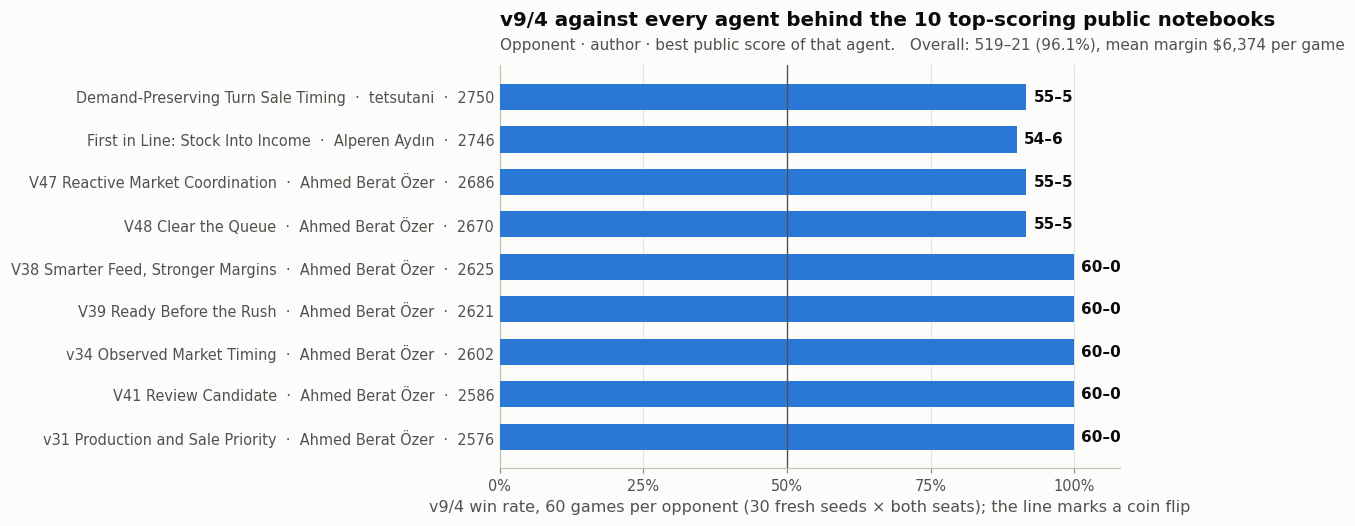

In [2]:
# Head-to-head results against the agents behind the 10 highest-scoring public notebooks
# (Code tab, 2026-09-19). Several of those notebooks run byte-identical agents, so ten
# notebooks are nine distinct opponents. Method in section 5.
H2H = pd.DataFrame([
    ("Demand-Preserving Turn Sale Timing", "tetsutani", 2750.2, 55, 5, 3446),
    ("First in Line: Stock Into Income", "Alperen Aydın", 2746.0, 54, 6, 3196),
    ("V47 Reactive Market Coordination", "Ahmed Berat Özer", 2686.0, 55, 5, 3698),
    ("V48 Clear the Queue", "Ahmed Berat Özer", 2670.4, 55, 5, 3534),
    ("V38 Smarter Feed, Stronger Margins", "Ahmed Berat Özer", 2625.2, 60, 0, 7379),
    ("V39 Ready Before the Rush", "Ahmed Berat Özer", 2621.2, 60, 0, 7198),
    ("v34 Observed Market Timing", "Ahmed Berat Özer", 2601.6, 60, 0, 10801),
    ("V41 Review Candidate", "Ahmed Berat Özer", 2586.4, 60, 0, 7188),
    ("v31 Production and Sale Priority", "Ahmed Berat Özer", 2575.6, 60, 0, 10929),
], columns=["notebook", "author", "public_score", "wins", "losses", "mean_margin"])

fig, ax = plt.subplots(figsize=(10.4, 4.9))
rate = 100 * H2H.wins / (H2H.wins + H2H.losses)
y = np.arange(len(H2H))[::-1]
ax.barh(y, rate, height=0.62, color=BLUE, zorder=3)
ax.axvline(50, color=INK2, lw=0.9, zorder=4)
for yi, r, w, l in zip(y, rate, H2H.wins, H2H.losses):
    ax.text(r + 1.2, yi, f"{w}–{l}", va="center", color=INK, fontsize=10, fontweight="bold")
ax.set_yticks(y, [f"{n}  ·  {a}  ·  {s:.0f}" for n, a, s in zip(H2H.notebook, H2H.author, H2H.public_score)])
ax.set_xlim(0, 108)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("v9/4 win rate, 60 games per opponent (30 fresh seeds × both seats); the line marks a coin flip")
ax.set_title("v9/4 against every agent behind the 10 top-scoring public notebooks")
subtitle(ax, f"Opponent · author · best public score of that agent.   Overall: {H2H.wins.sum()}–{H2H.losses.sum()} "
             f"({100 * H2H.wins.sum() / (H2H.wins.sum() + H2H.losses.sum()):.1f}%), "
             f"mean margin {money((H2H.mean_margin * 60).sum() / 540)} per game")
plt.tight_layout()
plt.show()

## Why I'm publishing it

This agent is the end of a chain that ran through this Code tab. My [Public State Router](https://www.kaggle.com/code/thomastschinkel/kaggriculture-93-8-win-rate-public-state-router) became part of the chassis of Ahmed Berat Özer's V25 to V48 series. That series took in yhay81's shop routes, prvsiyan's sheep and tomato projects, Dmitrii Gluzdov's stock reservations and a dozen more ideas. I took V39/V40 from that chain, added my own layers, and grafted in six more from the public V100.24 release. **v9/4 is the result.**

It is far ahead of the public notebooks and still clearly behind the top 10 of the leaderboard (3,000+). Publishing it should raise everyone's baseline and move the discussion to the part of the game nobody has solved in public yet (section 6).

**Contents**
1. The agent: one file, standard library only
2. Watch it play the #1 public notebook (a full season, in this notebook)
3. How it works: a recorded route with reflexes
4. Eight lessons that won games
5. Evidence
6. The problem I could not solve
7. What did not work
8. Five lessons about evaluation
9. Submit

## 1 · The agent: one file, standard library only

The next cell writes `main.py`: 5,760 lines and 856 KB, **byte-for-byte the file behind submission 56269928**. Its input is collapsed to keep this page readable. Click *Code* to expand it. Half of the bytes are a single line, the sale-timing library from lesson 4.5. All upstream Apache-2.0 notices are kept verbatim at the top of the file.

In [3]:
%%writefile main.py
# Kaggriculture submission v9/3: public V39 (Apache-2.0, notices below) plus the v9 layers
# RACEPX gate, RACE (reservation from step 192, horizon 40 / margin 12), COURIER, CARROT and HERD
# appended at the end of this file.
# EXP-173 isolate opening market sequence inspired by yhay81/shop-router-0911-simple (Apache-2.0).
# Kaggriculture EXP-167 candidate. Not submitted automatically.
# Attribution: thomastschinkel, yhay81, destbreso, aurax7, tetsutani,
# prvsiyan and Dmitrii Gluzdov. Apache-2.0 derivations; notices retained below.
# Kaggriculture v31 / EXP-157, Ahmed Berat Ozer, September 9 2026.
# Selected mechanism: crop_public_order. New independent confirmation is required.
# Public V221B/V224C production/timing lineage: prvsiyan, Apache-2.0.
# Original economics and integration; retained upstream licenses follow.
# Kaggriculture v28 / EXP-154, Ahmed Berat Ozer, September 9 2026.
# Changes: aurax7 day-end storage guard; Dmitrii Gluzdov physical terminal rescue
# adapted to v27, with 64 deterministic simulations. Apache-2.0.
# New action tapes and ordered shop-pair map: yhay81/shop-router-0909, Apache-2.0.
# Kaggriculture v25, EXP-149: Shop0908 production, sale lead, terminal cargo rescue.
# Runtime chassis: Apache-2.0; thomastschinkel, yhay81, tetsutani.
# Routing and public action data: yhay81/shop-router-0908, frozen September 8, 2026.
# 
#                                  Apache License
#                            Version 2.0, January 2004
#                         http://www.apache.org/licenses/
# 
#    TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION
# 
#    1. Definitions.
# 
#       "License" shall mean the terms and conditions for use, reproduction,
#       and distribution as defined by Sections 1 through 9 of this document.
# 
#       "Licensor" shall mean the copyright owner or entity authorized by
#       the copyright owner that is granting the License.
# 
#       "Legal Entity" shall mean the union of the acting entity and all
#       other entities that control, are controlled by, or are under common
#       control with that entity. For the purposes of this definition,
#       "control" means (i) the power, direct or indirect, to cause the
#       direction or management of such entity, whether by contract or
#       otherwise, or (ii) ownership of fifty percent (50%) or more of the
#       outstanding shares, or (iii) beneficial ownership of such entity.
# 
#       "You" (or "Your") shall mean an individual or Legal Entity
#       exercising permissions granted by this License.
# 
#       "Source" form shall mean the preferred form for making modifications,
#       including but not limited to software source code, documentation
#       source, and configuration files.
# 
#       "Object" form shall mean any form resulting from mechanical
#       transformation or translation of a Source form, including but
#       not limited to compiled object code, generated documentation,
#       and conversions to other media types.
# 
#       "Work" shall mean the work of authorship, whether in Source or
#       Object form, made available under the License, as indicated by a
#       copyright notice that is included in or attached to the work
#       (an example is provided in the Appendix below).
# 
#       "Derivative Works" shall mean any work, whether in Source or Object
#       form, that is based on (or derived from) the Work and for which the
#       editorial revisions, annotations, elaborations, or other modifications
#       represent, as a whole, an original work of authorship. For the purposes
#       of this License, Derivative Works shall not include works that remain
#       separable from, or merely link (or bind by name) to the interfaces of,
#       the Work and Derivative Works thereof.
# 
#       "Contribution" shall mean any work of authorship, including
#       the original version of the Work and any modifications or additions
#       to that Work or Derivative Works thereof, that is intentionally
#       submitted to Licensor for inclusion in the Work by the copyright owner
#       or by an individual or Legal Entity authorized to submit on behalf of
#       the copyright owner. For the purposes of this definition, "submitted"
#       means any form of electronic, verbal, or written communication sent
#       to the Licensor or its representatives, including but not limited to
#       communication on electronic mailing lists, source code control systems,
#       and issue tracking systems that are managed by, or on behalf of, the
#       Licensor for the purpose of discussing and improving the Work, but
#       excluding communication that is conspicuously marked or otherwise
#       designated in writing by the copyright owner as "Not a Contribution."
# 
#       "Contributor" shall mean Licensor and any individual or Legal Entity
#       on behalf of whom a Contribution has been received by Licensor and
#       subsequently incorporated within the Work.
# 
#    2. Grant of Copyright License. Subject to the terms and conditions of
#       this License, each Contributor hereby grants to You a perpetual,
#       worldwide, non-exclusive, no-charge, royalty-free, irrevocable
#       copyright license to reproduce, prepare Derivative Works of,
#       publicly display, publicly perform, sublicense, and distribute the
#       Work and such Derivative Works in Source or Object form.
# 
#    3. Grant of Patent License. Subject to the terms and conditions of
#       this License, each Contributor hereby grants to You a perpetual,
#       worldwide, non-exclusive, no-charge, royalty-free, irrevocable
#       (except as stated in this section) patent license to make, have made,
#       use, offer to sell, sell, import, and otherwise transfer the Work,
#       where such license applies only to those patent claims licensable
#       by such Contributor that are necessarily infringed by their
#       Contribution(s) alone or by combination of their Contribution(s)
#       with the Work to which such Contribution(s) was submitted. If You
#       institute patent litigation against any entity (including a
#       cross-claim or counterclaim in a lawsuit) alleging that the Work
#       or a Contribution incorporated within the Work constitutes direct
#       or contributory patent infringement, then any patent licenses
#       granted to You under this License for that Work shall terminate
#       as of the date such litigation is filed.
# 
#    4. Redistribution. You may reproduce and distribute copies of the
#       Work or Derivative Works thereof in any medium, with or without
#       modifications, and in Source or Object form, provided that You
#       meet the following conditions:
# 
#       (a) You must give any other recipients of the Work or
#           Derivative Works a copy of this License; and
# 
#       (b) You must cause any modified files to carry prominent notices
#           stating that You changed the files; and
# 
#       (c) You must retain, in the Source form of any Derivative Works
#           that You distribute, all copyright, patent, trademark, and
#           attribution notices from the Source form of the Work,
#           excluding those notices that do not pertain to any part of
#           the Derivative Works; and
# 
#       (d) If the Work includes a "NOTICE" text file as part of its
#           distribution, then any Derivative Works that You distribute must
#           include a readable copy of the attribution notices contained
#           within such NOTICE file, excluding those notices that do not
#           pertain to any part of the Derivative Works, in at least one
#           of the following places: within a NOTICE text file distributed
#           as part of the Derivative Works; within the Source form or
#           documentation, if provided along with the Derivative Works; or,
#           within a display generated by the Derivative Works, if and
#           wherever such third-party notices normally appear. The contents
#           of the NOTICE file are for informational purposes only and
#           do not modify the License. You may add Your own attribution
#           notices within Derivative Works that You distribute, alongside
#           or as an addendum to the NOTICE text from the Work, provided
#           that such additional attribution notices cannot be construed
#           as modifying the License.
# 
#       You may add Your own copyright statement to Your modifications and
#       may provide additional or different license terms and conditions
#       for use, reproduction, or distribution of Your modifications, or
#       for any such Derivative Works as a whole, provided Your use,
#       reproduction, and distribution of the Work otherwise complies with
#       the conditions stated in this License.
# 
#    5. Submission of Contributions. Unless You explicitly state otherwise,
#       any Contribution intentionally submitted for inclusion in the Work
#       by You to the Licensor shall be under the terms and conditions of
#       this License, without any additional terms or conditions.
#       Notwithstanding the above, nothing herein shall supersede or modify
#       the terms of any separate license agreement you may have executed
#       with Licensor regarding such Contributions.
# 
#    6. Trademarks. This License does not grant permission to use the trade
#       names, trademarks, service marks, or product names of the Licensor,
#       except as required for reasonable and customary use in describing the
#       origin of the Work and reproducing the content of the NOTICE file.
# 
#    7. Disclaimer of Warranty. Unless required by applicable law or
#       agreed to in writing, Licensor provides the Work (and each
#       Contributor provides its Contributions) on an "AS IS" BASIS,
#       WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
#       implied, including, without limitation, any warranties or conditions
#       of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
#       PARTICULAR PURPOSE. You are solely responsible for determining the
#       appropriateness of using or redistributing the Work and assume any
#       risks associated with Your exercise of permissions under this License.
# 
#    8. Limitation of Liability. In no event and under no legal theory,
#       whether in tort (including negligence), contract, or otherwise,
#       unless required by applicable law (such as deliberate and grossly
#       negligent acts) or agreed to in writing, shall any Contributor be
#       liable to You for damages, including any direct, indirect, special,
#       incidental, or consequential damages of any character arising as a
#       result of this License or out of the use or inability to use the
#       Work (including but not limited to damages for loss of goodwill,
#       work stoppage, computer failure or malfunction, or any and all
#       other commercial damages or losses), even if such Contributor
#       has been advised of the possibility of such damages.
# 
#    9. Accepting Warranty or Additional Liability. While redistributing
#       the Work or Derivative Works thereof, You may choose to offer,
#       and charge a fee for, acceptance of support, warranty, indemnity,
#       or other liability obligations and/or rights consistent with this
#       License. However, in accepting such obligations, You may act only
#       on Your own behalf and on Your sole responsibility, not on behalf
#       of any other Contributor, and only if You agree to indemnify,
#       defend, and hold each Contributor harmless for any liability
#       incurred by, or claims asserted against, such Contributor by reason
#       of your accepting any such warranty or additional liability.
# 
#    END OF TERMS AND CONDITIONS
# 
#    APPENDIX: How to apply the Apache License to your work.
# 
#       To apply the Apache License to your work, attach the following
#       boilerplate notice, with the fields enclosed by brackets "[]"
#       replaced with your own identifying information. (Don't include
#       the brackets!)  The text should be enclosed in the appropriate
#       comment syntax for the file format. We also recommend that a
#       file or class name and description of purpose be included on the
#       same "printed page" as the copyright notice for easier
#       identification within third-party archives.
# 
#    Copyright [yyyy] [name of copyright owner]
# 
#    Licensed under the Apache License, Version 2.0 (the "License");
#    you may not use this file except in compliance with the License.
#    You may obtain a copy of the License at
# 
#        http://www.apache.org/licenses/LICENSE-2.0
# 
#    Unless required by applicable law or agreed to in writing, software
#    distributed under the License is distributed on an "AS IS" BASIS,
#    WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
#    See the License for the specific language governing permissions and
#    limitations under the License.
"""Kaggriculture route-replay chassis (pure Python, stdlib only).

A *route* is a pre-computed tape of 719 Kaggle-format actions
``{"farmer": [op, ...], "hands": [[op, ...], ...], "market": [[order, item, qty], ...]}``.
The chassis replays the tape chosen by a caller-supplied ``router`` and wraps it
in small reactive layers (each independently switchable via ``settings``):

    hand_align            pad/truncate hands to the real hand count      (fieldbook_logic)
    weed_repair           DIG a weed that blocks PLANT/BUILD, replay      (tetsutani + task spec)
    sell_lead             sell next step's lots one step early            (fieldbook _lead_sale)
    front_run             sell before the opponent's scheduled SELL       (hook; opponent_plan)
    budget_guard          fund each 72-step block's purchases             (six_day_budget_guard.hpp)
    room_guard            keep shed <= 99 at hour 23                      (tetsutani)
    clamp_sells           trim SELL orders to the projected shed          (tetsutani)
    dead_stock            sell stock the route will never sell            (tetsutani)
    terminal_liquidation  step >= 718: sell the whole projected shed      (fieldbook _terminal_sale)

Engine facts (verified against kaggle_environments 1.32.7, env_1_32_7.py):
  observation["farms"][p] = {"money", "tiles"[y][x], "farmer"[x,y], "hands"[[x,y]..],
                             "unlocked_quadrants", "hires_today"}
  tiles: None (empty) | "LOCKED" | {"kind": WEED|COOP|PASTURE|PLANT, "crop"/"animal", ...}
  observation["private"] = {"shed": {item: n}, "seeds": {crop: n}, "inventories": [{}...]}
  observation["market"] = {"inventory": {...}, "prices": {...}}
  observation["town"] = {"unlocked_shops": [...]}
  Agents act on steps 0..718 (interpreter marks DONE once step >= episodeSteps-2).
"""
from __future__ import annotations

import copy

PRODUCTS = ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY", "MELON", "EGG", "MILK", "WOOL", "FERTILIZER")
SEED_PRICE = {"WHEAT": 10, "CARROT": 20, "TOMATO": 50, "STRAWBERRY": 100, "MELON": 80}
ANIMAL_COST = {"GOOSE": 300, "COW": 400, "SHEEP": 500}
ANIMAL_STRUCTURE = {"GOOSE": "COOP", "COW": "PASTURE", "SHEEP": "PASTURE"}
LAND_PRICES = (1000, 2000, 4000)
MOVES = {"NORTH": (0, -1), "SOUTH": (0, 1), "EAST": (1, 0), "WEST": (-1, 0)}
FRONT_RUN_ITEMS = ("MILK", "WOOL", "STRAWBERRY", "MELON")
LAST_ACT_STEP = 718
PASS_ACTION = {"farmer": ["PASS"], "hands": [], "market": []}

DEFAULT_SETTINGS = {
    "hand_align": True,
    "weed_repair": True,
    "sell_lead": True,
    "front_run": True,
    "budget_guard": True,
    "room_guard": True,
    "clamp_sells": True,
    "dead_stock": True,
    "terminal_liquidation": True,
    # tunables
    "block_turns": 72,
    "shed_capacity": 100,
    "board_size": 10,
    "max_orders": 10,
    "turns_per_day": 24,
    "min_sell_price": 2,
}


# --------------------------------------------------------------------------- helpers
def _get(value, key, default=None):
    """Field access that works for dicts and Kaggle Struct/attribute objects."""
    if isinstance(value, dict):
        return value.get(key, default)
    getter = getattr(value, "get", None)
    if callable(getter):
        return getter(key, default)
    return getattr(value, key, default)


def _int(value, default=0):
    try:
        return int(value)
    except (TypeError, ValueError):
        return default


def _fib(n):
    a, b = 1, 1
    for _ in range(n):
        a, b = b, a + b
    return a


def _step_of(observation):
    raw = _get(observation, "step")
    if raw is not None:
        return _int(raw)
    return _int(_get(observation, "day", 0)) * 24 + _int(_get(observation, "hour", 0))


def _shed_adjacent(pos, board):
    if not isinstance(pos, (list, tuple)) or len(pos) < 2:
        return False
    half = board // 2
    return pos[0] in (half - 1, half) and pos[1] in (half - 1, half)


def _tile_at(tiles, pos):
    try:
        x, y = int(pos[0]), int(pos[1])
        return tiles[y][x]
    except (TypeError, ValueError, IndexError):
        return "LOCKED"


def _is_noop(act, tile, inv, seeds, pos, board):
    """True when the engine will certainly ignore ``act`` (mirrors _apply_unit_action)."""
    if not act:
        return True
    op = act[0]
    x, y = pos[0], pos[1]
    if op in MOVES:
        dx, dy = MOVES[op]
        return not (0 <= x + dx < board and 0 <= y + dy < board)
    if op == "PASS":
        return True
    adjacent = _shed_adjacent(pos, board)
    if op == "DROP":
        return (not adjacent) or (not inv)
    if op == "PICKUP":
        return not adjacent
    if op == "PLACE":
        item = act[1] if len(act) > 1 else None
        if item in ANIMAL_STRUCTURE and isinstance(tile, dict) \
                and _get(tile, "kind") == ANIMAL_STRUCTURE[item] and _get(tile, "animal") is None:
            return _int(_get(inv, item, 0)) <= 0
        return (not adjacent) or _int(_get(inv, item, 0)) <= 0
    if tile == "LOCKED":
        return True
    is_dict = isinstance(tile, dict)
    kind = _get(tile, "kind") if is_dict else None
    animal = is_dict and _get(tile, "animal") is not None
    if op == "PLANT":
        return tile is not None or _int(_get(seeds, act[1] if len(act) > 1 else None, 0)) <= 0
    if op == "WATER":
        return kind != "PLANT" or bool(_get(tile, "watered_today"))
    if op == "HARVEST":
        return (not is_dict) or _int(_get(tile, "yield_units", 0)) <= 0
    if op == "FERTILIZE":
        return kind != "PLANT" or _int(_get(inv, "FERTILIZER", 0)) <= 0
    if op == "DIG":
        return tile is None or animal
    if op in ("BUILD_COOP", "BUILD_PASTURE"):
        return tile is not None
    if op == "FEED":
        return (not animal) or bool(_get(tile, "fed_today")) or _int(_get(inv, "WHEAT", 0)) <= 0
    if op == "COLLECT_FERTILIZER":
        return (not animal) or (not _get(tile, "fertilizer_available"))
    if op == "CARE":
        return (not animal) or bool(_get(tile, "cared_today"))
    return True


class _View:
    """Cheap per-step snapshot of everything the layers read from the observation."""

    def __init__(self, observation, player, cfg):
        farms = list(_get(observation, "farms", []) or [])
        self.farm = farms[player] if player < len(farms) else {}
        self.rival = farms[1 - player] if len(farms) >= 2 and 1 - player < len(farms) else {}
        private = _get(observation, "private", {}) or {}
        self.shed = {k: max(0, _int(v)) for k, v in dict(_get(private, "shed", {}) or {}).items()}
        self.seeds = dict(_get(private, "seeds", {}) or {})
        self.invs = [dict(i or {}) for i in (_get(private, "inventories", []) or [])]
        market = _get(observation, "market", {}) or {}
        self.prices = {k: _int(v) for k, v in dict(_get(market, "prices", {}) or {}).items()}
        self.money = float(_get(self.farm, "money", 0.0) or 0.0)
        self.tiles = _get(self.farm, "tiles", []) or []
        self.board = len(self.tiles) or cfg["board_size"]
        self.positions = [_get(self.farm, "farmer", None)] + [list(p) for p in (_get(self.farm, "hands", []) or [])]
        self.hires_today = _int(_get(self.farm, "hires_today", 0))
        self.quadrants = len(list(_get(self.farm, "unlocked_quadrants", []) or []))

    def inv(self, idx):
        return self.invs[idx] if idx < len(self.invs) else {}

    def in_hands(self, item):
        return sum(max(0, _int(_get(inv, item, 0))) for inv in self.invs)


# --------------------------------------------------------------------------- chassis
class Chassis:
    """Replays ``routes[router(...)]`` with reactive safety/market layers.

    routes         : {route_id: list of >= 719 Kaggle action dicts}
    router         : callable(observation, step, state_dict) -> route_id, called every
                     step; ``state_dict`` is per-player and persists across the game.
    settings       : overrides for DEFAULT_SETTINGS (layer switches + tunables)
    opponent_plan  : optional list of the opponent's expected actions (front_run hook)
    """

    def __init__(self, routes, router=None, settings=None, opponent_plan=None):
        self.routes = {rid: list(tape) for rid, tape in routes.items()}
        self.router = router or (lambda observation, step, state: next(iter(self.routes)))
        self.cfg = dict(DEFAULT_SETTINGS)
        self.cfg.update(settings or {})
        self.opponent_plan = opponent_plan
        self.players = {}
        self.diagnostics = {"layer_fallbacks": 0, "entry_fallbacks": 0}
        self._future_sells = {}   # route id -> {item: [remaining planned SELL qty from step t]}

    # ---- state -----------------------------------------------------------------
    def _state(self, player, step):
        st = self.players.get(player)
        if st is None or step == 0 or step <= st["last_step"]:
            st = {"last_step": -1, "route": None, "router_state": {},
                  "pending": {}, "sell_state": {"due_step": -1, "suppress": {}}}
            self.players[player] = st
        st["last_step"] = step
        return st

    def _route_action(self, route, step):
        tape = self.routes[route]
        if 0 <= step < len(tape) and isinstance(tape[step], dict):
            return copy.deepcopy(tape[step])
        return copy.deepcopy(PASS_ACTION)

    def future_sells(self, route, item, step):
        """Planned SELL quantity of ``item`` in route steps >= ``step`` (suffix sums)."""
        table = self._future_sells.get(route)
        if table is None:
            tape = self.routes[route]
            n = len(tape)
            table = {p: [0] * (n + 1) for p in PRODUCTS}
            for t in range(n - 1, -1, -1):
                for p in PRODUCTS:
                    table[p][t] = table[p][t + 1]
                for o in (tape[t].get("market") or []) if isinstance(tape[t], dict) else []:
                    if o and o[0] == "SELL" and len(o) >= 3 and o[1] in table:
                        table[o[1]][t] += max(0, _int(o[2]))
            self._future_sells[route] = table
        col = table.get(item)
        return col[step] if col and 0 <= step < len(col) else 0

    # ---- main entry -----------------------------------------------------------
    def act(self, observation, configuration=None):
        if len(_get(observation, "farms", []) or []) < 2:
            raise ValueError("incomplete observation")  # factory falls back to tape
        step = _step_of(observation)
        player = _int(_get(observation, "player", 0))
        st = self._state(player, step)
        cfg = self.cfg
        view = _View(observation, player, cfg)

        route = self.router(observation, step, st["router_state"])
        if route not in self.routes:
            route = st["route"] if st["route"] in self.routes else next(iter(self.routes))
        st["route"] = route
        action = self._route_action(route, step)
        raw = copy.deepcopy(action)
        try:
            if cfg["hand_align"]:
                self._hand_align(action, view)
            if cfg["weed_repair"]:
                self._weed_repair(action, view, st, route, step)
            if cfg["sell_lead"] or cfg["front_run"]:
                self._apply_suppression(action, st["sell_state"], step)
            projected = self._projected_shed(action, view)
            lead_available = dict(projected)
            next_sup = {"due_step": -1, "suppress": {}, "r36_debts": st["sell_state"].get("r36_debts", {})}
            if cfg["sell_lead"]:
                self._sell_lead(action, view, lead_available, route, step, next_sup)
            if cfg["front_run"] and self.opponent_plan:
                self._front_run(action, view, lead_available, route, step, next_sup)
            st["sell_state"] = next_sup
            if cfg["budget_guard"]:
                self._budget_guard(action, view, route, step)
            if cfg["room_guard"]:
                self._room_guard(action, view, route, step)
            if cfg["clamp_sells"]:
                self._clamp_sells(action, projected)
            if cfg["dead_stock"]:
                self._dead_stock(action, view, projected, route, step)
            if cfg["terminal_liquidation"]:
                self._terminal_liquidation(action, projected, step)
            action["market"] = action["market"][: cfg["max_orders"]]
            return action
        except Exception:
            self.diagnostics["layer_fallbacks"] += 1
            return raw

    # ---- layer: hand_align ----------------------------------------------------
    def _hand_align(self, action, view):
        """Pad with PASS / truncate the tape's hand list to the real number of hands
        (fieldbook_logic.act). Extra hands would be ignored by the engine anyway;
        missing ones just idle, so alignment only tidies the action."""
        expected = max(0, len(view.positions) - 1)
        hands = list(action.get("hands") or [])
        hands.extend([["PASS"] for _ in range(max(0, expected - len(hands)))])
        action["hands"] = hands[:expected]

    # ---- layer: weed_repair ---------------------------------------------------
    def _weed_repair(self, action, view, st, route, step):
        """If a PLANT/BUILD_* target tile is a WEED, DIG now and queue the intended
        action for that unit; the queue replays on a later step when the unit still
        stands there and its tape action would be a no-op (the displaced no-op is
        queued behind it, so PLANT -> WATER chains survive). A PLANT is only replayed
        when the unit's next tape action is not a move, so the mandatory same-day
        WATER can follow; otherwise the seed is kept. A no-op turn spent on a weed
        is also converted to DIG (tetsutani weed_dig)."""
        units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
        pending = st["pending"]
        tape = self.routes[route]
        nxt = tape[step + 1] if step + 1 < len(tape) and isinstance(tape[step + 1], dict) else {}
        next_units = [nxt.get("farmer") or ["PASS"]] + list(nxt.get("hands") or [])
        for i in range(min(len(units), len(view.positions))):
            pos = view.positions[i]
            if not isinstance(pos, (list, tuple)):
                continue
            pos = (int(pos[0]), int(pos[1]))
            tile = _tile_at(view.tiles, pos)
            act = list(units[i])
            queue = pending.get(i)
            if queue and queue[0][0] != pos:
                pending.pop(i, None)
                queue = None
            is_weed = isinstance(tile, dict) and _get(tile, "kind") == "WEED"
            noop = _is_noop(act, tile, view.inv(i), view.seeds, pos, view.board)
            next_op = next_units[i][0] if i < len(next_units) and next_units[i] else "PASS"
            if act and act[0] in ("PLANT", "BUILD_COOP", "BUILD_PASTURE") and is_weed:
                pending.setdefault(i, []).append((pos, act))
                act = ["DIG"]
            elif queue and noop:
                _, replay = queue[0]
                if replay[0] == "PLANT" and next_op in MOVES:
                    pending.pop(i, None)          # WATER could never follow: keep the seed
                else:
                    queue.pop(0)
                    if act and act[0] != "PASS" and act[0] not in MOVES:
                        queue.append((pos, act))
                    act = replay
                    if not queue:
                        pending.pop(i, None)
            elif is_weed and noop:
                act = ["DIG"]
            units[i] = act
        action["farmer"] = units[0]
        action["hands"] = units[1:]

    # ---- projected shed -------------------------------------------------------
    def _projected_shed(self, action, view):
        """Shed contents after this step's unit actions but before the market runs:
        PICKUP removes, DROP/PLACE(non-animal) near the shed adds up to capacity
        (fieldbook _projected_shed / tetsutani projected shed)."""
        cap = self.cfg["shed_capacity"]
        proj = {p: view.shed.get(p, 0) for p in PRODUCTS}
        for k, v in view.shed.items():
            proj.setdefault(k, v)
        total = sum(proj.values())
        units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
        for i in range(min(len(units), len(view.positions))):
            if not _shed_adjacent(view.positions[i], view.board):
                continue
            act = units[i]
            op = act[0] if act else "PASS"
            inv = view.inv(i)
            if op == "PICKUP" and len(act) >= 2 and act[1] in proj:
                qty = min(proj[act[1]], max(0, _int(act[2]) if len(act) >= 3 else 1))
                proj[act[1]] -= qty
                total -= qty
            elif op == "DROP":
                for item, held in inv.items():
                    take = min(max(0, _int(held)), max(0, cap - total))
                    if take > 0:
                        proj[item] = proj.get(item, 0) + take
                        total += take
            elif op == "PLACE" and len(act) >= 2 and act[1] not in ANIMAL_STRUCTURE:
                item = act[1]
                take = min(max(0, _int(act[2]) if len(act) >= 3 else 1),
                           max(0, _int(_get(inv, item, 0))), max(0, cap - total))
                if take > 0:
                    proj[item] = proj.get(item, 0) + take
                    total += take
        return proj

    # ---- layer: sell_lead / front_run suppression ------------------------------
    @staticmethod
    def _apply_suppression(action, sell_state, step):
        """Remove from this step's SELLs the quantities already sold a step early."""
        if sell_state.get("due_step") != step:
            return
        remaining = dict(sell_state.get("suppress", {}))
        kept = []
        for order in action.get("market") or []:
            order = list(order)
            if order and order[0] == "SELL" and len(order) >= 3 and remaining.get(order[1], 0) > 0:
                removed = min(max(0, _int(order[2])), remaining[order[1]])
                order[2] = _int(order[2]) - removed
                remaining[order[1]] -= removed
                # A zero-quantity order keeps later market race slots intact.
            kept.append(order)
        action["market"] = kept

    @staticmethod
    def _add_sell(action, item, qty, max_orders, merge=True):
        market = action.setdefault("market", [])
        if merge:
            for order in market:
                if order and order[0] == "SELL" and order[1] == item:
                    order[2] = _int(order[2]) + qty
                    return True
        if len(market) >= max_orders:
            return False
        market.append(["SELL", item, qty])
        return True

    def _sell_lead(self, action, view, projected, route, step, next_sup):
        """fieldbook _lead_sale: when step % 4 != 0 (no town consumption between the
        two steps) sell the lots the tape plans to SELL next step now, for products
        other than WHEAT/FERTILIZER we already hold, and suppress them next step.
        Skipped at the last step, at shop-unlock boundaries and if a SELL for that
        product is already queued this step."""
        cfg = self.cfg
        nxt = step + 1
        unlock_period = 3 * cfg["turns_per_day"]
        if nxt > LAST_ACT_STEP or nxt % unlock_period == 0 or step % 4 == 0:
            return
        tape = self.routes[route]
        future = tape[nxt] if nxt < len(tape) and isinstance(tape[nxt], dict) else {}
        planned = {}
        for o in future.get("market") or []:
            if o and o[0] == "SELL" and len(o) >= 3 and o[1] in PRODUCTS:
                planned[o[1]] = planned.get(o[1], 0) + max(0, _int(o[2]))
        already = {o[1] for o in action.get("market") or [] if o and o[0] == "SELL" and len(o) > 1}
        for item in PRODUCTS:
            if item in ("WHEAT", "FERTILIZER") or planned.get(item, 0) <= 0 or item in already:
                continue
            qty = min(projected.get(item, 0), planned[item])
            if qty <= 0 or view.prices.get(item, 0) < cfg["min_sell_price"]:
                continue
            if not self._add_sell(action, item, qty, cfg["max_orders"], merge=False):
                break
            projected[item] -= qty
            next_sup["suppress"][item] = next_sup["suppress"].get(item, 0) + qty
        if next_sup["suppress"]:
            next_sup["due_step"] = nxt

    def _front_run(self, action, view, projected, route, step, next_sup):
        """Hook: if ``opponent_plan`` (their expected tape) schedules a SELL of
        MILK/WOOL/STRAWBERRY/MELON next step, sell what we hold of it now (before
        their supply depresses the price) and suppress our own SELL of that quantity
        next step. Bounded by our own remaining planned sales so it never dumps."""
        cfg = self.cfg
        nxt = step + 1
        plan = self.opponent_plan
        if nxt > LAST_ACT_STEP or nxt >= len(plan) or not isinstance(plan[nxt], dict):
            return
        already = {o[1] for o in action.get("market") or [] if o and o[0] == "SELL" and len(o) > 1}
        for o in plan[nxt].get("market") or []:
            if not (o and o[0] == "SELL" and len(o) >= 3 and o[1] in FRONT_RUN_ITEMS):
                continue
            item = o[1]
            if item in already or view.prices.get(item, 0) < cfg["min_sell_price"]:
                continue
            own_next = sum(max(0, _int(x[2])) for x in self.routes[route][nxt].get("market", [])
                           if len(x) >= 3 and x[0] == "SELL" and x[1] == item)
            qty = min(projected.get(item, 0), max(0, _int(o[2])), own_next)
            if qty <= 0:
                continue
            if not self._add_sell(action, item, qty, cfg["max_orders"], merge=False):
                break
            projected[item] -= qty
            already.add(item)
            next_sup["suppress"][item] = next_sup["suppress"].get(item, 0) + qty
        if next_sup["suppress"]:
            next_sup["due_step"] = nxt

    # ---- layer: budget_guard --------------------------------------------------
    def _block_requirements(self, view, route, start, end):
        """Planned purchase cost and item reserves for tape steps [start, end)
        (six_day_budget_guard.hpp calculate_six_day_requirements)."""
        tape = self.routes[route]
        budget = 0.0
        seed_bal, item_bal = {}, {}
        seed_need, item_need = {}, {}
        hires_by_day = {}
        quadrants = view.quadrants
        for t in range(start, min(end, len(tape))):
            a = tape[t] if isinstance(tape[t], dict) else {}
            for u in [a.get("farmer") or ["PASS"]] + list(a.get("hands") or []):
                if not u:
                    continue
                op = u[0]
                arg = u[1] if len(u) > 1 else None
                qty = max(1, _int(u[2]) if len(u) > 2 else 1)
                if op == "PLANT" and arg in SEED_PRICE:
                    seed_bal[arg] = seed_bal.get(arg, 0) - 1
                    seed_need[arg] = max(seed_need.get(arg, 0), -seed_bal[arg])
                elif op == "FEED":
                    item_bal["WHEAT"] = item_bal.get("WHEAT", 0) - 1
                    item_need["WHEAT"] = max(item_need.get("WHEAT", 0), -item_bal["WHEAT"])
                elif op == "FERTILIZE":
                    item_bal["FERTILIZER"] = item_bal.get("FERTILIZER", 0) - 1
                    item_need["FERTILIZER"] = max(item_need.get("FERTILIZER", 0), -item_bal["FERTILIZER"])
                elif op == "PLACE" and arg is not None:
                    item_bal[arg] = item_bal.get(arg, 0) - qty
                    item_need[arg] = max(item_need.get(arg, 0), -item_bal[arg])
            for o in a.get("market") or []:
                if not o:
                    continue
                op = o[0]
                item = o[1] if len(o) > 1 else None
                qty = max(1, _int(o[2]) if len(o) > 2 else 1)
                if op == "HIRE":
                    day = (t - start) // self.cfg["turns_per_day"]
                    hires_by_day[day] = hires_by_day.get(day, 0) + 1
                elif op == "BUY_LAND":
                    extra = quadrants - 1
                    if 0 <= extra < len(LAND_PRICES):
                        budget += LAND_PRICES[extra]
                        quadrants += 1
                elif op == "BUY_SEED" and item in SEED_PRICE:
                    budget += SEED_PRICE[item] * qty
                    seed_bal[item] = seed_bal.get(item, 0) + qty
                elif op == "BUY_PRODUCT" and item in ("WHEAT", "FERTILIZER"):
                    budget += view.prices.get(item, 0) * qty
                    item_bal[item] = item_bal.get(item, 0) + qty
                elif op == "BUY_ANIMAL" and item in ANIMAL_COST:
                    budget += ANIMAL_COST[item] * qty
                    item_bal[item] = item_bal.get(item, 0) + qty
        for day, n in hires_by_day.items():
            first = view.hires_today if day == 0 else 0
            for k in range(n):
                budget += _fib(first + k)
        return budget, item_need

    def _budget_guard(self, action, view, route, step):
        """At every block boundary (step % 72 == 0) make sure cash + the value of
        stock the block already plans to sell covers the block's purchases (hires,
        land, seeds, animals, products). A shortfall is covered by extra SELLs of
        unprotected shed stock, highest price first; SELLs are moved in front of
        the buys so the money is there when they execute."""
        cfg = self.cfg
        block = cfg["block_turns"]
        if block <= 0 or step % block != 0:
            return
        budget, item_need = self._block_requirements(view, route, step, step + block)
        market = action.setdefault("market", [])
        existing = {}
        for o in market:
            if o and o[0] == "SELL" and len(o) >= 3:
                existing[o[1]] = existing.get(o[1], 0) + max(0, _int(o[2]))
        cash = view.money
        for item in PRODUCTS:
            planned = max(existing.get(item, 0), self.future_sells(route, item, step)
                          - self.future_sells(route, item, step + block))
            cash += min(view.shed.get(item, 0), planned) * view.prices.get(item, 0)
        shortfall = budget - cash
        if shortfall <= 0:
            return
        candidates = []
        for item in PRODUCTS:
            price = view.prices.get(item, 0)
            if price < cfg["min_sell_price"]:
                continue
            protected = max(0, item_need.get(item, 0) - view.in_hands(item))
            avail = view.shed.get(item, 0) - protected - existing.get(item, 0)
            if avail > 0:
                candidates.append((-price, item, avail, price))
        candidates.sort()
        added = False
        for _, item, avail, price in candidates:
            if shortfall <= 0:
                break
            qty = min(avail, -(-int(shortfall) // price))
            if self._add_sell(action, item, qty, cfg["max_orders"]):
                shortfall -= qty * price
                added = True
        if added:
            sells = [o for o in market if o and o[0] == "SELL"]
            others = [o for o in market if not (o and o[0] == "SELL")]
            action["market"] = sells + others

    # ---- layer: room_guard ----------------------------------------------------
    def _room_guard(self, action, view, route, step):
        """tetsutani room_guard: at hour 23 the end-of-day drop pushes every unit's
        inventory into the shed and overflow is destroyed. Estimate the shed after
        this step (stock + carried + harvest/collect - feed/fertilize/place + buys -
        sells) and, if it exceeds capacity-1, add SELLs preferring products with no
        future planned sale, then highest price."""
        cfg = self.cfg
        if step % cfg["turns_per_day"] != cfg["turns_per_day"] - 1:
            return
        cap = cfg["shed_capacity"]
        units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
        carried = sum(max(0, _int(n)) for inv in view.invs for n in inv.values())
        produced = consumed = 0
        for i in range(min(len(units), len(view.positions))):
            tile = _tile_at(view.tiles, view.positions[i])
            a = units[i]
            if not a:
                continue
            op = a[0]
            if op == "HARVEST" and isinstance(tile, dict):
                produced += max(0, _int(_get(tile, "yield_units", 0)))
            elif op == "COLLECT_FERTILIZER" and isinstance(tile, dict) and _get(tile, "fertilizer_available"):
                produced += 1
            elif op in ("FEED", "FERTILIZE"):
                consumed += 1
            elif op == "PLACE" and len(a) > 1 and a[1] in ANIMAL_STRUCTURE:
                consumed += 1
        market = action.setdefault("market", [])
        planned_sells, planned_buys = {}, 0
        for o in market:
            if not o:
                continue
            if o[0] == "SELL" and len(o) >= 3:
                planned_sells[o[1]] = planned_sells.get(o[1], 0) + max(0, _int(o[2]))
            elif o[0] in ("BUY_PRODUCT", "BUY_ANIMAL") and len(o) >= 3:
                planned_buys += max(0, _int(o[2]))
        shed_total = sum(view.shed.values())
        fillable = sum(min(view.shed.get(it, 0), n) for it, n in planned_sells.items())
        needed = shed_total + carried + produced - consumed + planned_buys - fillable - (cap - 1)
        if needed <= 0:
            return
        priority = sorted(PRODUCTS, key=lambda it: (self.future_sells(route, it, step + 1) > 0,
                                                   -view.prices.get(it, 0), it))
        for item in priority:
            avail = max(0, view.shed.get(item, 0) - planned_sells.get(item, 0))
            qty = min(needed, avail)
            if qty <= 0 or view.prices.get(item, 0) < 1:
                continue
            if not self._add_sell(action, item, qty, cfg["max_orders"]):
                continue
            planned_sells[item] = planned_sells.get(item, 0) + qty
            needed -= qty
            if needed <= 0:
                break

    # ---- layer: clamp_sells ---------------------------------------------------
    @staticmethod
    def _clamp_sells(action, projected):
        """Clamp against a sequential stock upper bound, retaining market slots.

        Earlier BUY_PRODUCT orders can fund a wheat wash's sell leg. Their full
        quantity is an upper bound; the engine enforces actual cash/capacity.
        Removing empty orders would change the later lockstep market races.
        """
        avail = dict(projected)
        kept = []
        for o in action.get("market") or []:
            if o and o[0] == "SELL" and len(o) >= 3:
                have = avail.get(o[1], 0)
                n = min(_int(o[2]), have)
                n = max(0, n)
                avail[o[1]] = have - n
                kept.append(["SELL", o[1], n])
            else:
                kept.append(o)
                if o and o[0] in ("BUY_PRODUCT", "BUY_ANIMAL") and len(o) >= 3:
                    avail[o[1]] = avail.get(o[1], 0) + max(0, _int(o[2]))
        action["market"] = kept

    # ---- layer: dead_stock ----------------------------------------------------
    def _dead_stock(self, action, view, projected, route, step):
        """tetsutani dead_stock: stock beyond everything the rest of the route still
        plans to SELL is dead; sell it now when price > 1 (on day 29 everything not
        already in this step's orders is dead). Highest value lots first."""
        planned = {}
        for o in action.get("market") or []:
            if o and o[0] == "SELL" and len(o) >= 3:
                planned[o[1]] = planned.get(o[1], 0) + _int(o[2])
        day = step // self.cfg["turns_per_day"]
        extra = []
        for item in PRODUCTS:
            have = projected.get(item, 0) - planned.get(item, 0)
            if have <= 0:
                continue
            surplus = have if day >= 29 else have - self.future_sells(route, item, step + 1)
            if surplus > 0 and view.prices.get(item, 0) > 1:
                extra.append(["SELL", item, surplus])
        extra.sort(key=lambda o: -view.prices.get(o[1], 0) * o[2])
        action["market"] = (action.get("market") or []) + extra

    # ---- layer: terminal_liquidation -----------------------------------------
    def _terminal_liquidation(self, action, projected, step):
        """fieldbook _terminal_sale: on the final acting step (>= 718) replace the
        market orders with a SELL of the whole projected shed."""
        if step < LAST_ACT_STEP:
            return
        action["market"] = [["SELL", item, qty] for item, qty in projected.items()
                            if qty > 0 and item in PRODUCTS][: self.cfg["max_orders"]]


# --------------------------------------------------------------------------- factory
def make_agent(routes, router=None, opponent_plan=None, **settings):
    """Build a Kaggle ``agent(observation, configuration)`` closure that never raises:
    a failure inside a layer falls back to the raw tape action, and a failure even
    before that falls back to PASS (with hands padded when possible)."""
    chassis = Chassis(routes, router, settings, opponent_plan)

    def agent(observation, configuration=None):
        try:
            return chassis.act(observation, configuration)
        except Exception:
            chassis.diagnostics["entry_fallbacks"] += 1
            try:
                step = _step_of(observation)
                player = _int(_get(observation, "player", 0))
                tape = chassis.routes.get(chassis.players.get(player, {}).get("route"),
                                          next(iter(chassis.routes.values())))
                if 0 <= step < len(tape):
                    return copy.deepcopy(tape[step])
            except Exception:
                pass
            try:
                farms = _get(observation, "farms", []) or []
                hands = _get(farms[_int(_get(observation, "player", 0))], "hands", []) or []
                return {"farmer": ["PASS"], "hands": [["PASS"] for _ in hands], "market": []}
            except Exception:
                return copy.deepcopy(PASS_ACTION)

    agent.chassis = chassis
    return agent


import base64
import json
import zlib
# EXP239 native schedules: Yusuke Hayashi (yhay81), Shop Router 0913.
# https://www.kaggle.com/code/yhay81/shop-router-0913
# Ahmed Berat Ozer: V39 prefix/terminal, shared-action encoding and controllers.
_R108_DATA=json.loads(zlib.decompress(base64.b85decode('c-ri}-EL&p(j53My5<F0e<Xd^M=BpR+!6(;<$}j(9DMM2FoS_Tz-QkXes^~_Syg-QjEsoPwX0hP<10~YlC}2Q>nAfZGU9*y@Gt-AzyCk~-+%pYKm42j_&<L5zy9T4|I2^=*Uw-6@Y}mT{`le3-4Flwzx>z#^UJ?|{_?;4%fJ4=|M|av{`x=u@V7tz!#{re{pF`WfBg8v-4CaqkMBPJ_hI|#F8QbJ{g;3G<M`pj?0cX7=iT%(e|`D=<Inkr&VQYJ+WyPG{QUm+;}7l^U;fOyU*G@o?#l=K_;UK;ZWF%!$Ir*(Z(sglG3q~F{+y5c^W?q%@!$RV+uNV|@`v7L^ZJO>ujW5Jedfg{U4HO&D6@~8{5kenfBW<OhoAoO`A0tf`Q_1_4||=|*@rFuihRHi?|wWQ&lleR;#cwKoQ{8d{QAX@@5Cd${iHi<mp{Cm_qZ4SI39oc{O`XUKfL@3mdJ9x_y|5f^RFK-e=YgW;_av*JuHWGo>;Jyz^9#uc6#^m`1|s!uhT@P{oj5W$?OxZzkL16=gGF#s`ZGk>tXh}mp7Wv_4Q}wGgN-*akW_!8-M6^{yJ}X_J_>*zy4d?PqWWGpTps~-~Pbl^Ug;knE3PQG95u!P~PW;`HrtUPV@5f)iiGl)6Cv?obJU>uQBi7J+pa#{ps=tFGGdfO#DWFESYb;(b!cO9}r9|xIk_=q2z_W4M2TtVM4Ee+nG>sB@IpJ@}o+BnEbiL7p+)mKFL{xspA}Q{ejo0Z<ysk;kOz$_H|fq|7QG^c>i90_wApYKl1Y7!|}(D|M<7Z-#@<p@c#c;9&wky1b?s+@Par#`J3m+VDW9Z@7|J@$&Y^C?`fK}Tq(zQ%Qt+zN|%AElc8l%U^ct_Nt2HTkL;W^=iL~Si}V~d9x(r$Fq6G=<@#rCGfc35hsJw3X<paX%A>uW4kKrEvhN1gIr*%2`6_GNE<^8T<(n?P;r4auUygS>1>l6UP$D$)dZO@yekJjyVtFY$=d;*KU1RL?<Q<7{6ZZGy;vy5g$kK+V7Xb=#eD-X<-Jhk|1X0!4XszW+vfshk9F4H(VCBOjbQBEt{0D!2_xr!^rT=7>FRP%Ft60;08TLTdXTOIDn&RYsGNc?_-XKPt-2r**k-u+nQ|vHKe+i~lPCbX@`O(%`CiDyjaGRV~_6GrI{I)2J_e3Tjj#GvZWP5z01ilcOY|ELuj73;Y!TPEOoTt%<xRFEktN@l*KdX4It@SwwRf!i&_C@bCfFq-F^Ts)k1HR71?2_qSlImTAWL819=&oCoc|TR&Q+!5z&z8Z>c<oIKJ@~PfMNIQ5VD+x+S7fSt$88Ak7t;xDh;`!<^la9WDTIuCf$B@p``Zv?YXw4E|D)K!0VASq77>jHmMCxPJimy?m)Hxu(-Yjl-x!yVYeWz%3cLQ@l<pz_zWr{_lMCv0<kK40K8V_k59)+*8MUJv*6oMFI%jpUg2-Bs6ODsz9A>qmtIO`SPz(u?#W~Jv9lhvkQFU4uCdp&g9_R%A-V(<s#UKC#X~b3K%jGiXAQa(I)ye^Fj6||3LnlB%*ElUOxs?l&d|cirEkSjU2>=F=RRSL5Zr$}Wdy}XrNtcpy$j3dHtPntF8mRpd;1Yb0f%7=EO7{2Mf!9&^!c!2KGXA-N*(aa#)9)|8RU;FS0_^*676(Gd%F5l3m)pjUz??r0Ue6-<+o<yE^%FmdIC6u@Dhq;fvjPZCm-C;4kCdD}E1`x%)w|0t$0-_*Q!|c`b-R&CM)1gR(04hC;!Ly<{#s_N382@9=F2JB{*(LrkB`5<JN@nW`|tk&tZkGWsLvaFFaS`98eD-{6%o(L(|h539P#Bg$uZ;l+3QtTuc1GW@u%;&5~jFM<bIS@as@Ab6`UpKwN4j7FLGh%b`!MBR;Yi*y)Dea0yo4b8?3bCdB!Mjt-7}8Ml1D~S;3FfL4qO$cD<+U-z17z4&nOVVdX^9jTa-lT$2V-xwOSDe>g>o?qDo{&V|}eobHS?9=dBXyyM=C5dwJh_;2btui@*<%jf?bj5z!ZNWc989>AoV2nPhq{GJRdPkb)Tnx7AkpHxHV^|y<e$93wHM^Pcq<qss4gAQ}Nn?0RTcTn>Ifdk=#uvg-QFd%k}3~(^Yn5KiSRFIBu*1fo{AVGpk<=iK;Pv^nCE@1!8ti+Nt_@>{A^H}H_4r2hvlSA}iZNq8z#GRkA#DRj_VaaAU0+raTDL)u&JX)!c4Vt>I1P-3=Ky~<`ce*(5%w*us;&ZT^kjIcVxy4`g@tjSYSkkB(jjlo92Z=G=^@7%(yrr$nx)kdyc~gv$L$=~1maL_0v~`xIoIa6f2@pPi^4}#mArOP4v)?xEn@pQS<-4Pm$8YuS@TSXC!~*?bvvQ8ut5s!5+1+EJHZl#=#3^tA&~pm*EK=Wm>R{3#HjU{Ni=A}&-@my~)sf6w36YMN@#F+K@>|x<=QMbS!_{j$ZHPeBZ?FW8#;x&9N!YrZfyLl5Pl#Eb)!wD<P++EG)t@+`#7YF0#TD<J{I-d6CfJB<POcTPMdEVJvQnxY8jkgj!2Kb1A=n#6@1>7_gOpfsQ_thb=ShZ=^d3bYO0|>JC0>pHojIaA>h-)vonUEybph($l*CwgXudpe7s-3E1A?U&Xhhd7=+^@u+A$;=LE5vavhUtzBVsGM4hV)nRsb%ft~p1$f-MzZ5qw(kJ&WC^fpt{BWb-{FJ;3lV@GX857ZPJ2uID9C;pWM;O3YVKPNb}rQ3#D!t*;GcQ{X_P(v34R5-ouZb53UYE4#eFKVJ4oj><MU6CB;0ju}j7oUzg<E>REq=xfRG?LPhG{fB?|R<P0}m7K=@`ez<CX;JEc66TADXswVF>wvMu2hign7@8&<*I!0zgI0}%lIc_=t>EQYF}ps}a<6s(adZ{O?ZX-442zSc&{~+lYKmYtEC@iAI^MS5A`|mTR#{vMl5!k;giHjA(_pG%)~!?DQc0>#h4(3S@hQMDA#_FQSP86!Pkm2mx4(hSo(vhtQ_|2d>UJFxAXKSYTEc{#X^OjHTENb^j(CndPOXUo`u$bl&7?g62)tTr$;XZa{8lml@AA*DZ(ubV0EpvFQsW&}>dn@LjvFa|k?l9*ABTmKKu;P`kJ2r+n@>$XC@zkrcOn~;KLRPk41=`7XIt!2^cCV>40nm&x^&m$d4lSUrfsHuBkXMjJ)AlDGs#w}w6nPJjInGOZ*^Iv^h7a7Lt4941%!_=(~ifA<_ZZ#1=w7xQZ1#J+e)X}Knuu|j%F$tk-uVm=8Oj9n>eh!#8Hb4c-tH+(OjYRM4zW>VgZ!{0A#0gCh?A|Rwm1GMn8Bm*b+==$wjrQ%Z(LZ0YzTa+dauCm6*b_zR5r#IJw%?c}Z*y9|THHOyw24f{M)f3l&T+2CO{8@N!hQMOlz(0Fk3%B2q($vAw)<!K~o(p56HsvTl8qc<e}de8kDoO(K3;TC*pitW}A+76`MjpUJI_6A?kp)XfWiW>u4+MYMUwXHctr^s;y^w>XQ1WZd9&8D+&#zHTjxlxFiWPh2a|#&>H!T%C1FzF-@O-}b_&@9!@!e;j2oZCiMXqIN4yX!i~Icqs1&{0+a&6M?hG2mKhY&K&^3qEZ6a>%0#rF5#9})_=h757`1qI!ODisH(n@{VYDvfi8s_AL*Y=svt)~HeE(=Mn2oofS`m|v-yGnaE??#aa6b!B?1}3%jnHz?SP2snEx>O1-!9#{9N8=W<=M&oHTcZ0n-UWzd-*8Pz^U}?q{pI9k-?hhyDJO?}a)YG}xm2$-Q%)CwuJKA2t<g1xjkss43~0^}R3Wr?-^%)*a!Iv0j4~`A{|oJ@T8*Pa~go#$<9T>beGzoO`eBkUzdGC2(X6AE``l^Jm=bdlQJ^8W)S9^L3gNl>rA&X1LtsH(9)*Z<f7PLE*?-^$-#f7pQK0Z*Dx&t$fm*e$Jan4;G_%b0rFbv;2AhUWU9_aMaogASmhySo-lg)aN#xKfdbob6!t9R(gg#nxIXNdOg0*+zQNhkZZ(ZUeZ?@#byKUmdz12Q@C5rL3YvU;l3KxnYj33h4<jN&{F-b@Nb|N`mQW&VOiEXU(}izC2$l@coD88*w40xAQf7X5Q4|541M5>%L2W@N0Qx8Q5B&iXi%jI-(jNaRWYv)Csl@pu?9Uo_`t=hHNv)eD}`)_$_XPSW*BWTBCLSxy(Uk{g%Z%(f;P5PX(sCA6lcMX<<h%-a^+PoGoG_iBX*hv@fE|zJ6rn)V$^&$L>v|DCj1OYzK&7ZZG|F#kufVQAMm7n9a&SZv6A|20w7OA89Nk8Fb}O#!F8;60O00|3Qt{_g`A5N%<W!IMg-{_x${2OnCc_!226(}8L%XrJA}oPPZGJ8XLg^$vZ=~DVNo}}Iap(xI_2el>WhnU+Lga&NFl4=)xik%xISQ!8q5P=U5x;-q#{<`KF64^VV=mF9pB??iuB7`-Pkpmd|jH%o$BtCREX|e>bJ|Eq^S@-u2W~nj^$;KmS~wl%74w@K}mkjY@my21eIRSpTRhn$5a#8dZ0cFmD4~Q*$l`k7@KnRB={?^j2`O=(_RrjG&2YNAng<^RgIVuI90^0czJ;>8{<Pv=%A_=m1&4<1;rQ!RVM!@*-etvUoLG0m3+YKNuW|iOac_QDbPlL&`lo}Tl^=VpbFPBNH=KPR^+~%*73Wr7nKZNi6wY*)62!g4g+in;zrm+-+8WeLeD5#=rW4FoomrLyNnCa%*(pw*ThgtDwVi~ll(kcFWgiE1_?I{l2cWxQsM!Keen<hBWpQSgGsR$T}FW{c4Do*-ax_AlLAxv<7<rF_Rmy_Chd7ytxpUz;TetcRC1!F0tl|%_!)7Gxqo|YPuNS2m4nQDq#=tg+dcdpkr(9~()*ysBt6vGxL0E%beIbLoDrpXht+aOt??1-&H28-&=9OoOJVd_I&9kCSRFK|0FjM<S1ypNHaRNOK;M9o57(kbN(dG$2U#7t8Mm?~1;o@7$E@Te5mi9I!vu3-tM1wMVF_sj>?nPp`!d`Vd}hmQTxuG{$}!)&kQw5NYq&rqlT16N33r0k9B2i<Bz*>LH`M3YH7O=qqOXiP-H}Q1)^$m&WvEL0d>7DqLFTz!9-~*-rpnIt8tiUoPioqnIhR<_R0-r{b=orNcM<}FZ&L2Dix-RIWhKR9-<K)-njSSJ?1I&tkkdd5N@I#1&9q#+!ejAGYp{>e##q-UFHZ285osk`^!2X*K&5A;wCtVsdRpG`h2T98fWac>h~d`u8`Uf2Dh9`H+C{n%WfA!EuwNJ^mXB$|d8NT)g8Rnmv4V?{JwMeeAp#-i{FzoXw(`DID)cADiHZf|O0q*Vc2DR+iXagKY&30oTd_FFgI2IaLk=PH02#D0rbv{V0T3H$;Zdg6rq9w<+0Saze5)46S6JxtAy2Vw>s7G!5rAPpY+ge&uIP0v?jX~>*!<XRD`WS)!w)J@)fW%6?(R_Bd2d6ll8~~%l2yyNL<vo}Yh@Jla%4C{D&GLbYyctDE#g$HYkR74hUFr^Loc)C?FG}&a%5-N9?E7q(<KPVV2O#30mzWy`f{-q#RAj!%hn$H(Ng9`VM@{Z<C1@T%Z6dIagH6a#aE%(v9ngeBbT+M^`VU8?E3aI>&5ic#73V!0wV9z^|`k7U!tMgU6Q+rgm<Tkt;fIr{VneN&O}{80L&<aNnCH~0rJdt7iuQY!K%8a4w$RY&3l=Ho}X8vw1i)%#-S@v#Oa(&Y1nDvR<21M3n_zYO3USP6vQwp=EhO>g5q-FEF1`dY;)qMcA+eqsO+^bS0~TZn(_s&+{4R_1twSPJ`v(E+^-;=$XXmTy_j{vQAFIxWvS)?Ud36W5Jxc2cNE3NkMJ4aM>l+kOL;yQz(I1Xhr!Q)*Mdq-Q{8+Gfc!+@LtcbU7A<KxLk3{+B{8ID@}!kH_VZJa<I(0DUV-kgNeR*>PiQ;4X7Y*{l@_?AZ&P#1A;nJjNj&a-eUzWx{~hcfOWdasm(b135`U?r)@vrTC1~c;<GP89qeqy8u3jFWKLp_Zv3JoWuW(*f8F+xvli+K&z;=4@s`|bxzz~Ryhk{duf+sT^^pAe`E7LK+F5rWcHAf9LYoZ3QZq7x~1}Mb7`#MU<MO&lHxu2=zoN1LuxuxuiV_7epf@`kfpa7-&(dr@g@DtGp*5I;n*;Gy#u*-mj0TxI<peO*YnSx~wQR=HU126>zCISqG9rBf`V!p6K@H>HR>qNyav7H@JgD!RxK9WX)5{$xH${Q&%Rl+)%*a+<CRqv1{8*L9ZR)7O@FDMNHlF)@8FhW)D5xp*P=dyLSLWFvf{p~m=wTjM;(m^w3<+Vt>cI~4EEHjcqzt$=qc5R1Rag<QdI(D&K)XOK~^G-Yhr5q9!5#9Nl^)yUZ5Br_D*2kelAp--iKq@XN#-Re2F}FDOqBs^)SfYQydIFH5O$&N&Pjx6YRI+>?E$V|#-cZ|@dvxBxr#yV}ithP<iKD6Tc*y;B1@&|}2=fAFP58W_iQ?COY}W;1P^|!+wJsmyj2yDVnb<L(%iF$S8aZHrc~ph3k)nIY0UpO{{EXF_7z%71Wwvos_{CIHV}L?zY6vt7-O!Mb=)ZzcS-bop@HKWeU1eXn864TTjSP@z6{kb;V%myvml_TF`y>bN431SZ;2Fn$F7+i|NsWs&m^ymny<~0~tvr_SKXAo$s?2@?tp^3g%+hJY%*rR)esqlnewh2R=1c2B&#|zYf?}iBARY@4Q!#)+zhd%mkE6V8&0&rC!7OvLJHW}Ps;tQvrYY8hX%YqLc_*o`mJ~i1*>OkFZ>G`444k_QU5SBZJQcIiMYIk(b4d+g-HJm=-Z$BmJ-q{FDo?R0x=hGXy2hZ>2m#-eSr!s25thbx+hc+y<FrRMRvjv|Oi>fz3f;7|yi{zc2;mVtDup_zD1D5Om4UK<_Z>`tgWv?we<=lpx$JL>!x;sr<$Vqj0z=aegG{WHOGF!HgWB}{UE&N!^DAP(CKX<lQXarDOs+@#M@fP?|H>7m55rsbixh|&-xb1$n+Rm-^8!O=25xpO_!f0$$>TLv9;J&|-teqknU%|=|9Ocb!rm8+F9>lH0}0`)?x>gy4ORRlE!uiWg02s_kG}R4m{-xSaH~Qz&1XzWH-}cisVcl&m;zBnAt}-lTdaXn%`HFKVYN>l*A*?yIPIhG!l_rru%4rA*=FWgBBg`e6{3XJq$ty(I76rk5&fwwm?qIq#<ixvI)EGGk;eI0O)d-Fl5$FuHhTu(H{>kEKIAg+KGclc@z#}jz$0U;pOvvLk#Typx6A^K-D$MW2w2x`*=TAAuscFH2mv+th%^*4(L;i^xu~gbF$G{~nfZ2?kW?yy7rG4svw*;vf%KgiV&usTACkx1gwm|x7A&0XASoy7Q;h`TSero2IudcXk1V52MNX<FN1F3&pvQv^o7{)@Q*L6M<`2B)!cIKDdoCU+J=ZE1rZTv8Lo$|<((t;&?g7a`<Obgrjgg)U22%oJ47|=j@~Vsc$r4%t^S{#)AiQBIhHZx2ho$cXg#=rfd2IFx=onK2L`r<<g*mFHrB0$aw|1L9^)?<6!&Y&yS@&aE&2ZNcYk?N`63nA)+5gcR2y2a&>KN%WHN`U+PekT+;2NuydYejlU=!&ND@4i!F$RrWPP-QC(aS=PR`f(#+&q;;vFkD(g5@PF_n_OuoRMzIwk4kJA08r61U8WtNO6~K_w2l@xJQ!UB9X74nt(^c^@nV%rc!VLP$t+zfi#^V>vI^zF=3o-pQDh85IWxJYp8J#rkgmVmz$bQ3bTk}w9&afL9KY?S$BYI3!!5}6Nni?NM2g5LJ5QQc~Wdc1Nl3{7?L&n4XHWg01}YS<~eY5rg9O6r$V!d<Yz@X24v(1(RYKl&NM-pMWU(M(S~C~0_J4*4>!;5sl^^lCl9<cgt;kFDb0=hP1RU3AREe?QJzxdKuRE`TH<$VzLT6YO~H3feG@|&6*7d4rfsVBLyNx+mnOv~hBaHs9tG^oqm(y=F>a!YCCV?HG0M_+-bk3W)q-O*laS6O6Sryf)=96MSw8b1=kqJvM3Xw%DzUs^-$*SoN?1RQ@v5vUc{QDf=`pMRmjDMrg(f-LiOZDOOr<uqV8ft(546lXdnOaK?pdmUl7#?kqU+e3u-0@&+^3fek^e7r*gsWzTeAg3^w|A0E8D6D9l>h-&nPTXs=;XL^RI5+z-G}2l>&?Os<#tHcEJ@iK&LRTHo{5J88er3!VO>o=8<Ux>3~WXXCfrM^8<?A)!SfG`5mI~*6nJ_`w!LmMs}b#`-Uh4F9R7BEruWGlCC5{PgO+kyo20tZmDxJ@Ld__(4xn6^8>TprGP@Og}{6fN8lLDtT!XNi)_AK{|oo+;PMX!U7;o7@i^qA8qX_w%g~dum&e33L9}+~IvRqzTpE?K0U>R%;(Ro<k!k=;MU<o2G4Ca=wEA0@<>)r0!wF{w215$<?x)cl1qE3Bx(eA=sQMTfKrJ74*ZO+7680;Jfb+25y3tt?-YVp4j;O;K=->>TUBJ`_I$rWR_yaIla`ceH^t9IUuk$RZCrE``w4#Rt+q)P84r2T04!`K&sguW7@ZS`jM=*}d&wLORkixKYAkEnZ1sP^Wf8+~^<Zzu!Nm8nF2e-;Oe=2$p89OvC@}9^qLr#dKD-obw-=xBC4dd=2sgUKW$~B_t<Dk8NbEYhR`mfKWuT)nT#5Hmuo<?F<O*kHJuVhq|r)sW1hT?ahTIxKj><M_|s@e$CKt8d2L9}MgfQ4uf`wEyKU6CvX5`3%VK*-ceN+PsXS&>DIdTYi@)q}+%SZpQx-=t*3E<C^l@(C?(o<Aks1l!}*?FkX>Ck3>DUJ*1rBV1VW7i>$9ZDCBQIFi|2Vv5h8f2dtcJ(4xUAxfRXBv1q7)pCuW&g;NkBICu5dMlnn#3e4$hT*i$WjJ^FH9{D(od)%+*#H)_nOH|&Gvr+L{7|F~R%)f^IGkZSR!F?!B4-MoOfPRW^rN&hd}$kA;x<FZat9Dk8G2}?f*%~l6O(!%b$vl_gQVT87F_^cHx-H=Q_DyPgR0mWV?c(a`%e{$xu<4hX{mRjA&6ke+eI2!X*G2@joUttLU22dhTU$bd~9i5(}<MPo#kAgljrP=8El4#p)n|MlGB69r#Dk}Db<B~ZFA2-&y7W}JFq1M*KZ)LF}8rY$I`qrE5ht}*3U!NktX!kG=w{X9HppE=TG}@?#ZGAM_rxHU6O3`)&3PFc;Zi{Fb5ry91Q~#%CWF4ED{xv0`-kcERox02Bnc-ZFJ|96w|pwhl&9VImDItAfzG$LM1>5rNo-1R>jGkCtDCtnj(|_ocS6UsCP2u3_Rb01a+#ZZ#c5vHo4!Jaq+xuuP<(igF?2r%FjPl;6Sa;RzCjGFo;v{!q1Pb#ZP7SPIW6N`gTlbgjE~PEdx$9`?TMG87J4W$?Hr+o(2Kbg{+BH1KYZCoJd|GU5>n-yh~C>#%MR|l}quKyM8`I%B(SyGi@{NRlTWLPL@l(<u;luJ+0-$IrG164?){~JW3P9prTHvjAZyFR3Z9NJ#ylRkPMZbgho<W=*!K|#$^U<9ye46ofaS&bHH(;liHY~CF6WXod1irnEB4>8FyhW1z^Dlzn#gkF%;5sNt>kE+5JUuvxJW*(nU=*RxIQW^l^SSw<cZ?7K@M^*(UJTm9LVp6PUZJQF`lBE*zh7-qZuMIK!0qDl8ko)5Skxo0+g4<V+ysl#>L6sBGH4OqTSn(l(9XhSXgG(U<|YwAvq;N_;j@UtXhT55ptV2^5dtz93&~PtV-z>h;y%x6?&cxTiH8;+C*#z6kg)^Qm6`-?B6kzi{PMf>^pIRHyKoOi~jC;^d1On8T76)*W?nTYUOe5EIaJ^5NPCXF3u<+R`_gmRul8%FKP1Yo|s$KwIZ9qq7MNn<u!1EL>X_xN?zNqs4Ygq#1JhOrQVi?=R>8Jnzo8ACQy)Zl9)>EzFkn8%akm(y=+k?#Y#_5Cm48Bs$(w)DmXCHj-Wgyud6flS!@_1LvqQq4BN<;5$^kN>V-6UkTPjWwDl2D<19(s2}EO%{OvKMSro88-dEUxJBu;!>bDTiZFYM?gQBOOi3uTPV8)W6$v2lqy%Dt1+e@U!4ESw`(_22$_iiU7fLN)^6!iZ$fiifEom&9Jf{;DFc87v?k{*vcn`?ooK1lkE&v2_f9Gy1n-0gt@Z*Bq1xEkl0BZK=wJkxP0r;~J8^wY^RAxOqBF%!2(S<>GO(qurO|p*aM5hH)Q~=UyAbW*mw|Bb<UF7q#l-IgS31YJzw3;i>&@zbT&glLGES-u*=6Ts{Y6WS@R82O>TL4vnSOr*>F8f$-YK}P+u_vL8PddNdRwf)d#gIN}84@qSfaiXto=SEA^Imb21}+7J9wmv)#2bh(Wz;_bm#VnK>I;R=brB>CDfV>zbMZfr3lKE_Et|WqwJ-}rUYVo;>_S!?p3)_6-UUwcA<L++?MnQ)xa82Yl{WRAR9K^JGBnX<I~_b-<EbiHq-M>~9FzTH9PcoqEBpFb=d4N0d<^H~)?M))z>B;ztH)2IFWM2rozlCgqexJ4BWWXu&!@s{`Al1&WNM>ElYzKG(&41{5Fzp7ZqBf=&)>fedUVbr1cAnAds&&mlR{8RFwGKC*)b{)xqylFj}7?T<t-NuPQjQZCkJUc9UX&rIAb<GWJ1Q2B{R3`hP6$BYo+yAuK{NC3H*v6AX!kCGFzU-kaS=SpOT~k80YfJsSg;4T+%cwuaT1!Z(J)GwJ`?(DB&u3+>(*J-SkW8sAF{M^M&jl&<`G*>l7hu#$v{eXoPCj)~!bVfCS$Gp&fC$Hu^%IM=20Yb+^?HaPqK*O(;-4mevC^&Shm}+pOIOt_spBP*q#pC8kz#i<l%ehmPe=GM32%5rHNM<w2-SMp|S{CGS{}&Q@?VYSfpBZRIH}d$Q85JPTUL&_iJcst1$>S|!OfBBV{Hte~Yv@fZLZyNg@}COlW-68%Re{qOXIFze=%b$k%%;{>NbL6SR}ys^zs(bd0G*Pqu6(&T-iUJr7{Io)6E_rXEaX%<@*)+j2r+$EN@n#1L?V%F_!@_lYV5)YF|nd^HXL8`XOWV+4~Tab-S((R}DZqSg*#bx%cn_s4FLVL}h=~H!ht)CND%051f;me)g#sqYYtcy9aUaR*hZ$a^Dn-U=rGKk+v63vj@uc}%f6GU48r{W*O=oITnua$g3Q2;ZchcjR3ith63pY(<FUF!oRf?8s(GfuQH_jarkUGo_0^>2zrEKggHDL-dz2BPYJ*WH7FJ`|5!tdAAlpt*McDtx<AH)7mirTxjTwX5}?*myy8M0$964nUntjA)6lEi?(IJ(4@kv{s-O(5}P!SG_BZb88AE2QK1A%$7<WOpNv8&Qv_$v_z5fYANTA8zF(VI|9H-tpx!`0h*0@X=$i34(7s%9#o-m-gARh9N!~jAxR4s+Ro?uojp9!#-L0`==CRe*ippcXr7Ele-J%^4xvyyb|^i%yX84@ke;8XQ*$|t@9*yi8m7H|Fs<QIuNZ$BcX)sEZ?b1x=DUZACC_(p<RK;FG>bnJOp)2?{tAa|?kTa2)Iw9-<Y8<omI_YsQDFx(<M_oXte=+HUNI-XFcFIYCV0fe4n2X#{(t-P{fD3a@#D+eHRZWGONqsJ5t4cGO0xz|;A$n1P$$-RH(K3^Uf3XL%Q68)-mYZ|IGV{{Cng;LveV+<`b1vd2u*LHLO6v8uw1s!tb3MBG)b=sm|1((Ua79tJY1kjw2hN8m5nfY29iCsRtJhXV|ID|q!}ZaOBTtZT%|kkWMm!SzNm@&usWyo{2f$)qKk47xLv@m7`O4#Cnfw#>uV|AV=H9CC-DMP=I%``&kXEYDYND0U;Q~4S;25vd)Q>jENK(qvL)?D;cJeOI%%g4$%RRyNqzVrfM)Z`4ZmSFpE{wh^aORqsi<nb_*C~f3f;mtT3-Mem>~*ZpAMzQ;0mPf=YyN3-xk1~>*A~YT8ck^CfHEmDV6wOCZw^-ZcFQJ(}lUqbX?;XvtLZ+puGR)@X^zf`SARFsLFYrhjK+WL$iMT;_}1rPYrHD0w7)2R7)@Tjf!))IWTmx+8vLD7}60{xkSZVikULgq)w;NsMRrre5jU_C4ap@vI=jC#SCt2ampG1Y8*FSAz~~7K{}qF#?{<k(iO}625^tcp$V`AN8u-ujo8c#UC*KwepC2SRib(My0*}0VG6z|7Qm!G)L&@&&05Rpj;jWhY+yk!VTXo1ssg{dP-Ut~(=y|B)qM{iDaDsoz&F-`W7xpL&AF=u{bJ1#ry*G;(nZxr&?K=0ySD|~IEHnzZFE_Xz~_!prGgwJ)yI1<l!M;};PcmT=7I3roOgM7aJsPe;nnPQj5abCqWOT$1#KUWxxk`DwUL<46Pb@Mzr6eS5`K8P_Me|-5$^HB%daF=5cTIbBunHVrTmyyE|CNpo8M)&IiC3&GrXL*e}XAyD);|;e(&###OZjf%UgI^ojDJP;0I*NjjF>x+mwT3Ac|}PoU=Z`3xw(acQZXNNxuFv>X&EN8Tb<^P|bkA`4^0r>CFFkICFY$AUDlo=fS+Zw4C($cgN;DTlMH+NvX5+oCg0jmJ0A62lkDQ<{yRb0OPFNmFP2@Y**}#uC6y~F%28xW@YKpWP!Tsw~Nf3#pl)#fI|7ayNUp+blKmY#i-2dz?uihfgv-dCTzW4+@2&oL&S|fTT7Wrr_n^)gn9*y@?PfW{z3A|Og$`SCV9_t?s;`&`kuc0%ZGQr{&Xp#y!-Y2FYmryGcTvf&*0jMV=sDs*<b!%f>MyXA@d#qPovL}SB~lDzy0ygoM;&D_V{b4F21SpQ1cK1%J4DjUb)=}jOHAmzrCc~Qf&III5CUwG;Z=RG(Z4GJ(0_f&Pf0%s`8Xi;E`+<9_O{lq?%Odb)ko}JfT>JDEhngIU6$P&H0qWVd0wBqZX|ybOGoa5Er~JXZ0UHACJFzUPPAc1=Y}~{=DYl5;;c0OOSRil$sW-;2_maT*cAEibWb~iM{%k`tan+s>vrLe}orfSWIG4#p2_t29V1#f8B2dzaCp}wVGAqxdUNMfQM2ky5g9(_Gv^dM<eO*I>~Z{cnpWG!%d_JX8Qr1^{ILcYlU0LFciB*DHDjP-Xw8_(If7eNP-QNdxw;CAc8%D<M&)Namhu(7W0+1<c`l^x8uIX^vMzY>x*NmNOp$OdTm~K37l&}<crrie{UljGbWjFsibQu-yhv&rTozxK}qfV;b)<7dPwpcvzG!_%S-D(F2WP4E__{?3C2UG<%8BMNx9#~@*#QzjThusP4GLcgU&b5Gqg0Z9l^b=?xtO}K4JOhQIBEocBt9k5ogNct;EZ)8!Iak8qbvRv53=Iv2~Lox(A66NIVzR6IGRI=VT;il4nsg3+s4Wvf7wOr%Uq;Cq9*9gzs%zFp{OQy)}1|mR_@fb+v(xWPy9L(zJt(p{wcmP8hqrfRHA@T(i6r#HNaAV5$rGCRv;^nmxHH(!4{)9jddEsiK1a7?sJs*}B#sIu)-eVS~sn_LxSkj6mL>xwsSo>mUmSMYmDom=v9%EKE%|dUN5s<O~I6#4#&@%x+QAiZI#BjOhk|L3PF)*Hlb+PSz_`<$alvfa8n(B{4tL<Gj&5q}CWXjcU{8r*2rEG?eJK_FT#QyB>L>0qt&(;rc_|jWi=aY|=W*w-c>{SuwHflPYyyS5vJBOInwJhs!Z_Aa=$kKRQ+~fvVZ%P>68-Dub}S-fjOR6YJ;}JZ1L!4Urfo1V!hAr;sJ(b+WFg3UnwO!#WU=*)e#c#QVKt8djSapSaqA+zrjPVkv-;RC1%9oKG}iJw8eA_HmO0Z?Ulop2#j!pggx8h$k$Ln6+1yWszlw>x$Esu*S$2z5s*2CumDIU4;H<m~;T7aKwTlBaN!8t)~Fb*SWut7LoXx%RY^_#WtWSe`Vv`ZADqUz8}0b*eba*N}yNX&T^LF(tmWIZmhV@SSax(&E}}m$Z#6RhpD^rrhk0jm^C=cy|L`ChF*<a@-J6NZ4hzE7fc9=^AJ~{1=of%khVfh^<j|8?0&`QyQkyIp{x59i1%Ib`mV|pkF*QuA+w7srEc0j0mIn^5$A%%JYnT3C0fRM1vcTfTV`j3rc`j8Ayz}^lt|bWFSMn&?2~{>-nz68VDd4!;r#O%6XWvtAWaH<DpjLGzkt4X{R9LxS`B({e{Qq$Tx-J+xbz_U4T2^rM9p{*LO^*K;eu0gFn_`1YG<9F#={;~cvgqyC3(`^&r4>5aT>ym4o<^>YbWh3LJuAr578!(-7AY(E_*m~BbLn3gzs@;O^Mo*M57AiFN+hGy(!8$P1^~PlrV9$YDQaeQLxeS*v#HV?G{`{FeGGq(2E>}>M1!(J(^*|w=ws8B=N?V4Z3~u1%+8d_T@&qlUvUN5{Q^*yN0+FV4P3W8qDq}e@z6m*-pljo!L`2S^1^nIFOU7wIn9=`EdI^wMyu-Knm6T>JD&lbbCVU+YB@j^Pt$lEY?7TR2$K&tVIcDSG+$-2c#$sh*v?NCo32v|KyMYplME{LGQ^5bj(eqbWNxb;9Nw7+EuB#^ZWUrIJ>fWOVk<`zo&Q+<f^CsVnbb}h0<m6SlmgAd2+Dr;jh1{X8y>|$w9`onhC+)QM*{JS8lj^Y&CUO))jzbYa2u^QE8o|Bdf|LBDi(Mh?$A#Co|;rP*>b#)a96<Q`#jyzrM;DIcx9XiuGVzks{~%eXcTYFvydUJgC8vU#0V3Q8^9=QXy|(eZ6o_>df=O9n8)v)=^;Rsdf)Q37Ap{fIL#b_?PzyT91RwLZ~C*083y@YWwCIF6D%qMCr8RuelYrwWQIU)BtUX+XCsUVOK(|eXZvK1CT$qjM(ioEO_9pZ7^bXH>q7sTn>zqOoXrylxi8NxsaC}CwTD|rG;Th#*aH(ihW%zb+1SV)IL7_LE77gL8o1%BTJD=p~pMtIk*G0(Pvu}8qLPzw__-ol%5jvr;fVGVaDs9+FGEyw58L>H6WNPI8}p485gTinNdtZI})m`F11l|*Ikt?)Aw9xtt4$D)D)1S5ji)y*ONpWAcPxu+Fia5AKa99<Uw#^&h53MtPw#nc4J{Tu{^PiiYm<$b`>%Rni|}v!KN)tbHGa&v-kkQ?sd)RIoxJfvN5%lCcMQ9S3w3i^v(5kn{?04Nbw6a=nUm?TS_zD_Cq&IEQaf*J|fzI7A)<_K&2YLO`|Ey!3eNKsz>$qkBM{?n8j9@UYkj8nNhQ1&}(&c-2%iWsL8}w;AYI-Z@=#7vPU?6PW&(oVGNmi&PXady4>0N7wW2#5@+O5*eT39f#Mg244oxYS;RV8?oQ`iGE=YkhAlqAwHPRcqQsdgq`5sH5IJ~eMl6<Jy#@@HL7=!9DL+KCag0XJCftG00vONY28H>IY#09+42nk22L_Im(kp5ea)gF{2TLWg`4|9?rMmWX-c!~D4HVuc$h-0KMh9TQ1fh>uHhq^m*PQ>B2BgVUO$G#VtwN^_O`6I09ZgKIoc-}w4UIC>%~k?B6b$bL0U05Gpq>`FoxLLNfz|Q7L=?MFAjK$8+$(;3O}3J1aHROy5lh6=H9N3EmDN#MbVU!zUys67o!6Vu9$b<7LNwmN{Ls33m1HuCUenCWw+U+|vT8*Zz<-#A<@NILmseS&AdR7sl0nU3<048!*rJS-0u-zxZ9k2zL&8v^y-!yyanuVpR|y?p!bHqufc7%w*k4U(MBQdSI|pRoYjYgHhjEqJ>gXLDz^$o&wdLM@hgy2jS>Y@RPObNxupUc2IyFCEK?e!CIC=KFuYI#SF<Guu^jrdOC^nYOmOphP)=DGR_<*1QV8#&rxfp$w#x%X>#kdqvM_&IaP~TTWnVjF#=P1M^ti)29TNZtSTOEh*#0kZXuC&x{mo$*gu|?7+Rx9xfqEjLUPU-I_hj39_-LQK&%Q}V&Zi_c?be9IyG;kOuB{n$49LS+7@gNsWo`K{K7C1GX&!67^JwIEWg-p0n<%pb7e9<<WJ_upQ_E$II;}P`u*+GxRvg&AB8LpW%hz9a@;BL(IhvDkKxVC5Vw+}m0Okv;TAJO#pWNZK)c(w8<8c#=ZS~n!g!KtC8&{?s(PU7ed7fui`sSw6v`ts?jSpl8p{k<g2Agc5o6DB3PGVS<!N}fR3oY)536m`CBhYn}VX|)?cwxCQ6cJeLezguZRh=@bU!C0Q|4k_%~91B^`9wP%q7)B$N8ckVEjvp)pbY;+Y-v&+|Dw=xN8ntMnArulWwDtOja;3Ri7R`%yj-NM3Q5mysu>bdz$&p%Oq3RsvD(yW);`qnMN=zhAOzO^EnO));Q%D<Cu`#B;Ab``66`xznrjo>~X^?ib6JUBt#u$m9bfx>gV=71cC3tk?m&8p2n444onKo^K<2q0HF)}&{HDUT^6}bvhCY-`dsq$vKBzrXrmS#IR-ld@fDKutBeMD;gex~KxULjerBnzmZbA?&aI=3QgUVgX`%LdOg-6L>oEQe0YJ+X&4QtMA-EMB`5?f9q=5u}45A)74Fo~Lxv6XcO3@3f|N*Tf=?=2syy)AX_`XTI|S$l=q98$)bQ1n4N|nu_quqO@~=f1mNi=l?WQskx7LY20X>6d#pErysBpFcR(l>L_a6Y+A$?C!o~1u%NhFQ52Yphq&0)4JU=Qm5|P1q(i0jRkN-;w`u1aJiAYi!RLU@vmx%XM!(fJnF6T%J3&vL%fh?g`+b}JCkz0iD3EV2n`459<WZkO5|uEi97`yl_7>ME>Ake0dLl$5-u~ym{QFD%_Q#iB-hF)03*s*5F3-RF^%X3C^0hWM|K=r+rAu>6t%x!SFGWZ7;x0dE`iJEYI?Df>92?)*_seCo!JiYjN`4U7M2F3Km^X-qnZg6v%&y6Z&!>xFDZ$&WpaLZE8Je_I$oG~V*Tl%FDx-58v%$ciuP@h6r`giK>6SDUa7`@BNq$4qw2n*xDysOcM{|%xpo5MMA`vgZ6G~R-iHMF6d5v$gu^Q`Et*8z~%_U<pCh<vm=!q`J`65C|sny^#st`l(4ZHKoZ<DKZc~~kk%tO%`j{zUm#Yjd)XQ<#DWBo#ijI@ig5dN_y1XgL9=UR3W#1_7a{_2NkHzSYJqqK?z)9TyCslJgN!izezIb0pSbpOk{ZuB-`6@R8|%%9I_c_gic@fvOdQR%Ial7Uya3|NILyWKqPuv}<rO{FK+QO*uaw1*8$9gydewg~`d?8<iqXgy4a2DWv~5Gg+4-4OAUXD8Lurxiq39Zxg5(lRG^cIRyj?1y)1DqN>&-Tn#(m6UuABdwM$%ECZbvqModojNE~#+d-$w^Vhiy_>L6k*QLJ5wYeRKdtFKMg(s>)n#xr8S)lZcV=YLFb-O+rad;=jGa_q#4t5bv)QLZV=4?Rr(-b&M>jn+o7+kqe}d@WkZ!2AwUGh~r@a)({D~4yw?hTc+5E;Cx}+<~KU@@vkWmB`p*xgV$H!_9?4S;gLc_QyPFT_@aKz%B?NI;miDF%-!MoiAxn748HRUQex@8xE$dp?wcaX$h>VtIem9&;dwFnFCdElm3On1Q1A^i50#;@Q*D$C@1kq>I$po3T~X$XBK)dou}ka0@OD}~?wKCO?4XUoKPlQ9yK?;k2>50MpjTSW67r8TJ4xeplYNOg25DvMpWdy;|1scpj53$C2e5V?4ax5F9|NWc?rYThn=k!?Zc`MP;G1@75`v~nk&^MHTUk-}P2;OdPjbaR4BL|%mq)S&{v<bPoWX4^WFSlm1uhf~y+s%B6nAAGPoK89EsoKL-4D#luLh<V>z(iv~Jm1mbisS1~a3<b!7&>n<l7ZHh0@xr8+A(kY##3f)&!N=!_$GSqjst&<bDzMgrCEF{xEbU||nN@(W@_?~a%aa>Hc^|N3Ki@K@4C3<Ok<0(^snyZ0GJbAqLlu<ydntjW<OGU=I@|z~{9}tZ8Sqj(LWR6tEP^Y!D&KJVsBeH~IXAV3aJVj_;g(z%lK7}j$P8*^&f=_m2J)=3UBH}4|EYTvX*ncya^=u$Q=5;uI-OK2`Ke**QODGsrgk<#iem&aYI*yBdUh^ePHPU4f^bi;8IEZ%JA?#l!5GY=$?OCx->haNYs-?k2MXxbJ1o9FYCzMWH#b0p&Q=Bsp7&gzavM3*cQ3i6B9EdehJhM|&_>y*tF7cIY4JzcJ?CLq5%y8Tnf^ONhKw)l3ojGDd@>+ULw35Tn{`|8Me8(J5`I)jU_>cnAeLer+_Y}GIFAu<j6s-ln>bjyUGclkNPcY_i&AzYH6|<ce-OMkWrw04P)CF%+SgIJEd#>wu>Qu4k6d-mB;vJCo=7O92ss0Qjkm*4@yXSO4rki$K@r*t#v0F63V7sjR;EBm(O|28Oq?y04^WCV1_a7X4M}LbS#6pWK39NF(Y6t(Bo+nnY&rdm*ir9@QK%6?Oc_IzDcmQub-DRi;x7su3CF<H;TqV0Vr|-07Jj-}DqnQAX~W~_;w8=Eo|nelqPMiBX`#?AUgYX>E5M%AfGp&|gSyZ#a4Q4St(uXPhjdsaxM8Qtwd3;le6Lx4i=MfeY(n8{8}uUu3*C^h@GCu>-)=L|zET=xMr)P{tP5(bbaKa5s*25l$bRAt>;U@RK6daD&Pgy>53=;7%QWh2+3GcqTD<bC*KJrOjJ1O1FVV;ZtK9BWrw)YO{z;{nNqXD3qyg&*m0MLdxIKq_bPKe#^a&3U*=?zrkGHRDJeEA=Mn6-zC2;^Y_6Pp3xd{|A%LDh{M{x?Ah!SndA>Ai;$V0?B))Os|B$@zQzhMYk%LhQr`h50nnf&rl4X(82xa64+BLJlQ<x*--1Jv`SPn;K>bYj%ihxGI(f}L*3jPMn3zWQ}Wj8(A?>Tk+*C`FF&K0$;*yTXh|fuLJMHkzSI7Ef@@go8@|(CtuwLY8aHkcGG#R&ugzK?@m+Qgw4Ny<I`IMhP`f@eiEXQmmWX9^X#ci6tQ5lH!b<P9Kd#%so6nAZ6-y;8oReIi$GT8H9S->>46tnGLK~RXT9Jo&P#ozVY25^Q<LbhUGhBIS8(BXmO}Sog8cq>CGMUsg8yNbLA?~p$n`7$bTzPC|i^RQ&>)#2+WhmCue)-TR`C`>RJ(o5(JN<*hKRfb9N1WB7xmme&GdIYJcYlvL6u?W|9X~#PE&wr9q>|8q=*M|0F76CexDLBXJ3OYprA?P!_o|Cr-6xmOJ-pGx|4k?_6|ZLXef>DVBoPCM6&me@vlOhhc1LT69l3KXcV7%G5|f9ZxeU9$u7)6BT2!rbV7Sy1>(Or8qAG7N!@|@*30}6ZqOGxLEY2q9rMU5f=INJW7BvYQmo05{j2)0GiK%*W7jf5<xfxzAZ=tE|eB2o=MXI-VKUXdk;a^4JBWfUP{(j*69~$YV?V;(^uY}yYD?0YT$1#!DU`23oIsXmd!1RoY{Mp6=b@CY+!{PLzH8|iSN3os!S#D_#^LL7L3iKv%f6J`>j{K5lU3|le?HFl}?>dT6p_2$tKQLOUw&h40sxzI!{wK%r@6FLx;fRI7K!d+az>PU(CX;FVr?JT`%cnsMGg}DqSEE*=yT_LB-hv7xuyoGH@s-@BZXahBRTa`c$}aFe`w;hzC84C#bNv<La>w5udf|A##VC;yG>$S19JD{JJt3hcUlSh9in|R9M8!X@#MVsW6ApqWzs<BE^NRwfP?CLuKDNSY5n}^{m&=!>#B@lPCj$H%wuiBSxO)dhkptJ!6g$ZA$I<RM5*((h#h!HTBi0b5G=jGYG5CS#n$qI&lf<$=9Y)N%LDz<B7W*s<=_5Q(TVybnHdz;fCfm^(uen%@ryCuPH9Un#7BW)uOEI^eIuLUXg4vMPXmE+T=7a&e(aOY@DZq_{lQhlRDcm|B17LNCfB4s4sf@rl{L`LBE(~xG=A+KZhjH#0}#46~K5s69ul18^~P553cW+mVZG-aQq=f4U7m5zAR3YLAwa(0CAabX$aMOV-!2GUEM%Hl`ck>PVBwe&R4!^ZWvLU4*9Tnb(}vc;ux(~kfGlAi<7zwpy@M;XXBGSfJs7}B}#wC<Y)w)b?3Q37)~E)hW;&U5GSwe{^W?>NJmY?VtrJXW!xAoQm@bNT4j^bO9UJVqU@UL=B*r}7_)?qSaHQvf*Xf4yHB=C*Y+YWd&x6`<B-f7&AEeu)?Zx>s6d4lIz^_DVma)&X%pRHWwH~g+VGU$HwdhB*B#bCr%V|dPqzugU8do=XF2G(osT}x>1gmVP3h@nJiFc#Sl+f>pEdr9Qe33oVMv<EMInx<CeWdpYT%o8GdVBhpbc>}?6`~SsUT1^wUq#PRk<>{1%9%gYmNzWNki1a!dT=}Z7M>QG*)1+KNz0@v8*Dh#uTY2#KoT4Ry@6?i4{{&Q*)QMh!8ZSzA9V+Cm+A^(_KMd@@Se99=@};)%r3E`g9r6MnY4Q2+QZvq{$0@OnA*i+Ryd*yY9(KKbz5~Rik!JHmX?WF(IW=H>ORjgL${#6PO?WDrPXqS-PFk$-c#@Ri+m_bm#>xz65EAa{%jMlbsTj<5PalXZ$l=xE@3~?6itO8C@q-)w<N#mp*{!|AcQ^St?;ii&sir;T8FNmTf%WZ6j&eJpS>q#PTX`-KOk6!k>dw92F6C)I1sKxK`Bn0IcioqP~o|I_9VyFXv&c+rgKiTM#T<VlX?EdM|(BkbaYR#IY;tEA*A2Bs<XYy8O<*fsIYa-4jk)OaUj{a0^;`-ZPS9Mg*mgGQW0rswq9oskv^k@Gm@htdr;d>mhUzy9O0V*C5vKQ)p7%iP$2md(^plhEYdl{Xd@8N_PTEBm$v^848j+iPgdNN#w}alR5%dBQTsk>LxC}vwQ&~&)=$8`77kZ>*y854PRRRSr^D;flca`Kyl63;ucLNzUOcrO{J2H3T({xKH+YRE%v6(`XWhusQC7nSXRCvs11!wgDl$P@*_&@B@n#(X$tj>GlTk;%nEIDgCPbNP)d>Ym6(zM^b4Yk5N2ciJiEkhY(S#90}gMS9;S*!glXO+YP0Sm<%nSEme=ZQ;20AWc1Feq%arZ;0xE}&0e+{S@+h7YuS%Wx>`l9p;U&Kg`E|Fx8Z=5-iJGQ?)(t#w<h#F*iR;(zR`fy{CTG3q4usWv4qL~>GGLRve2$z`??C`cB1E1hO^-K)hR|X^Y7aKz>dbolbVuYAnz>xgdkTF9wr$tk%_Hmdj^S`_g!6-ny_D3<4~}&CU9E|@Mwe#{Nhuyl)Snxyq~v+Fm3Ac&onA-vw?E&1_~{=%zP!1_#&-+#qCD0TUGgiwGS(W`Ft6cM?b1_Evh6};B%7-Wlb9AG0Vh04!U)abwvNB#0fYF{*KuWyn2Uci==DWd`t?;lC2<VR9b38td1^oKZ06ns{9_uFaoJIn6`_`--iDMz=Y~)XCkCY|uC;DhL_D&RCJFx6H9Korh%X7wE^2e2i^X%tkmVYxO6dw4*4(57-Iq4dSPm*oZ|zF0ntjLcUjp%*;M%Ef8q!#}q=<BVAp~ARHCzNgOtMbx#LYaF1gF{qRBA7kn^&ieTY`EiUnv+B`+F5ha7saU@43RgC75@Z3C1LOTvBn(X$&}A&npdYSw1kRjH4x5@_lg-VjS`o?!FCC``C~Ho43_`Qsz<jeNBG}QUE7p6c??T{c7^SWPuMq5ggU46QJo!cllxXr+gB9?MYatl(dFx+s9qPo$1BPJmuEtabvY7gDNj<tl5oL-S(=xfewwI`xaqzAstr}E)=1L7^tEO$vOjdLgq|s_=!~bRLErL6-X<9B5wk5QyLBRSD=2iaF}3lvoh)LGkC1zA?-%u<<|~=)1ye>J_j$1qlp6#-8ygE4%YZ8WNXhL*bs}{wAn(0a7yPRX~AM4CaXG<h2Z%Onz%m2b3}AaW|_mQk85>^FwZ9X*o*T4Ps!znoYN#WK~Ry%TRa}iRq3}H`1#j|3k8n1iGnq$^Bj8PWg?ZQ93u$Z{F&3Rhg4qKBayf@M&upwMf%i->QlddXV;qt1*=@1Gfqm}V$njKQ-|n0JUqmS*y{&Ujep<`vf|t2#}W0-NMcq~CC-;3%zn9<<?<fzMJmAX3!4pGu9q)xjBu%#<%>->`_1y*+0!Hh4MZ}SefQ(bFYi9SEWf)Te@x%~@x#ln%Wr-?hZjTeo9{qd30R|)VzeX%Y|~QXIoWm->UfzTtDYbx>BGHtkxB>NoW~ZcXO|V2QsT<IOiC%cEOf?xKDj-Y1iCwiK|LW0^Q&CFk#^Dv!qoQLb<jB`X0!qq`!tZ%9ScIx&traFQK3A(>KJVETZUFab^rOcpn9lmrl-m=RMHjw=rB~n0%Wc$Yw-J@OH4@qRlympElC7=Njbmqnt$DJ+de#L#2fe>M^h5k;JN6L7Kf8hMvTSjqUsqf@WRLdx^He(LYulfI4ne&RL}SByzF(bxFj@G@-;`AMsqRgWSxiL`FOk3Wpc=wyV+IH$ryyl14N1I5_U$Z<CR;+qA;0XskQ|zI}IG|!e@A7@v{IVV!NJVhbVIRe2cWAQ`#GlAI>197)OOO(_x`|nxa94GqQ)QyJuhOWkwIS$*LFp?7nUT=jW!esKy2ktE}TEJvB&5ixF+|(sUYxZ<~ABW8kvVIFSH4ss1HuiBa2zB+90FUBU8Lvc$Fh@-ok&MN>JTBxzu=JR^=Idg!WM9S0rkg|OohfNzWS1T)5EW4dmGu^pUw$Jmi}P%!V~lDYwfT;}V5yB~;3JUDoL8A-p9o?q-lxJo(v2BD1CZhxfE+T{AyIy9*pYAz?BxhxytqgULxQ}W^>Em_QU{ElzR1U7?%g=drrn`I=KN2*h|;g?fI!Cwy~S}cbby&$&dXZ!`ISVlZnn!YQmN4-9v*;Q#I?A3tSlAq_{TzrWwo``j(33h!`v?o3R?-sEf$yAJ#-v4^|k;Bns;X?Xp%T;1Yu3`AZr%DaS*zvpc7@+cnW-<^xSSN+wI?gxCEs&&LDc!Jfy+Wk|MK~o919~FPA+N1`>mbVY(D|@&tGr0Ty$Wi2+0J1+6e(f7)!{co8fhpc)!nqv2MIKYoE1~k%SEWM#2e8Rg>m675(G9Cv12Cfn-0=)ifEg|`7V#(3iIq;V)G6;E5Gpi3ra<{t-5U#%4EEPMiW{%<L26rE9-V>Ty?8U&(^Q(k~@IEdDhU;ErvZ8ie3!T0f}(V`u49jM^Xai;N*H0;!W&Vc{JnOUs0M#ssyV#?9q`fj95zf?PVlT`7s0z4Wmp~(dNn2P9&via$%~s!{s3Hg)e(l!BATQoK}xF&(fWVCE{aDPS$3qt;(dJ9{1o%R#jTo+*YylJ0vv7%=UC&lZl91vLMpI={CAV$(u`-f=$fGR}KbE^rwz4uL1p_7$?aD%g%feChBFpk3iMkV2Dx73{*<PB;}=K__r5uFaDAF&0f!hnQB;uJQHO$ft;r7rfOP@G6y_FK^QUN@TSfrs3*<Gx%|In8Wg{1UPvVMq1v0a_?A;JrgP2e3s0tay)6O4MC0Pxf~T+csZS;Lm%_ZZ6Bz9#bzV$(5MI?W9l^w9HV3JmWEGLonk@s=q=!TRYzfrn*$II$>jg6N5gOaX7zj%BpLuD)wR`FX!Xg|;U!h1IZ)~85j}$+VF;|1V;>(@0pr51xhBYUba%~@w1Kk*v;%h(?3h>t9TcKK;Jbn;`Ul{w2lhX@ML%3W@OcNmWgrZjz$0|g6O~;Mcb18#5G<Ier<elKFz~q4BUlH0H4!!(J55{amUzxjNcx+Ni3M4eo4VUIYIn@Ug(KuQj=fZ6_IB|$cO0ceLRzg*3vs^{!7&U^8nt=x6`9<R$s*6yI|I3F1o!+iJxoL(>e?jw6i<ALRbt#>D05C@R{6@{1#a(cq;OF8(BFg@m*->Q&B7sQOhjGejz|aNOG$t6y7ArEzN5=vlu50-k9*gIREv00Nt;iyXha6DZV)HnNV&e8yH=F@hP6FXbZwrLH-OBr95oa>VkABvu&3tLrHxZsx8KJqg3zS%$i|tpY8svE)RpWMvc{^5^AP0rRRIMgwk1cx?mYSW8PR9V8lU9oZp_@f8HSa0gP?3xk$0X7NhqrBk8^E32)lIHgTm-_tvB5>EP475Voq#P)W<p-SQ@C3eQ;U%ES_`u|Zw@?4zf*#_H-bwv#<Z5n_%$FMELtFO7OM6kwb;F6%c%+RGD<kH8aKGbr@ZKH^kaXvDA*fF^{~wcO@v{3rZx-%Ld^;=&SB3{Uo@;2u2e{7Q|}@(si0&omARgh%Q}iLbeY7-rs5}+pvH@al&FIaf1f~9w`lC&yoQE_=rHOuR`teR{czY#Lo2fd=fx*bYty{0C_tHcA0=zPX)*|06IU@DytJC&ml+icHb^jVgBk~9GR0|dRKNOMyI%+#-Y2CBYGLH=rcL5+3H1{lA4GKDC#Bi14|~>7yia@`m>jz>ve1tc^n#0Ii(HEI_FfQZmCz@@&h$TnO+?;$S2d0(3T^QX?8>+MlT+{qj?&$R)XK?eP-6m~QMt9;6!?%FrI}cFqC`Oyu5qBK6yjqd0;6K0wSI2mWPzfuMINW-yh{w>War39oR7F4lKg_pKs#sC<dbRp=)=ZgDfmKhtcI&)i8t{Onnp6SbL!o%?|*ssbw~evJpMK*;bf{xrH-_3<Q(nylbKOm=`0M}hEDK9ae`S4Yd94v#-DEho2@BFS~XQP7S!<9IV+4^UON&6Z1BU));(|bz>x9hgRorDn#)7(1twOQ1`H@kg1XL3(jMa|zk2SXzAVC1W_;3If{b;qDil-^qc)x<tAsH*a>uA{4;rT{a~@Ra-oH>H^VsQ$9C+!`UUELCG6`U9c&@W!9CF_8FevVv4L6_RI<s7z?@Y>v<R3%`OW%HlmO`eXk)jZt!;v9{G#~{f(l|>^r4vs<q_Fl_IdpWZAXsc`Y#ju#ff;mr|Gk|;Ib+fKrC^GjdAydi;=u6Yl*G}YSFj%$A63#Nst+fpsZ9TyN}d`C+cr&HU!7wP$)ty$GC|_$FVH^%bGGH-g0tM$KeySXH?+q@<?{M51u?WbjJPd`^jv0#J?z1$t6G#FaJc{N&-WjG`p4&O@$pZhS0kQlIbp`7v^Nhg9!AB{M>K!B0#9jCnM#&s@r2_&F#Y(hvPgVPU?2|acK!t#m#7O4>`Ula%&RU>5+4$Dz~tQm#<S`A+_T$>8IVrMAzwUdAaNr3UZ`y&x8h>*>akAryd#_<u+|X&V$vuX#IUky;_Zy)+xfOePUU{WU9y8KXe7azAnFK*%4Li|_6g`L;rz+((Ul-Ek{tu@C@L+g%|Vs|i#oOQMVF~t&hoA%aK+BYXCXfwL5UnVr2bPORvH!CXU2Ib#*d<y)**BK@i7cMYUu#Hlj-=9(yf#ukxjJm;|gdu)w1ma5<YH1SBKFKP&1ODmU{%ZarQF<CWh9SDHcsDLvm&s%S^^Fs_)06NkW9Ak22b_bA-|W!aafm+rlyr6(j|{2a2@8NG(^n^_DI5n6TU!9OuK5*gvyID|BI`{no2&qNCYpSQp$gmX%#K0`UwHg=9n@PA~0%pcV;<9+>>baU`ILAQVEAO^I2%7r~PL)|8$M`nE&}m4>CRsZuU`((#Ic;<R+psEk**P!yo9{bSdZI%2mIltLv0`3r0~y>C?VzW=t8*EyFnv&m%~2+Qru)|Ilg9*DmhJD4)P)zm*>Y2gHggxSibLIq4mq;J5q)#^yRU{>kZ<St)Qv(oLiI8zmk2Z3UO1#L&ceV5U(e28QXZj4S4ss$V)Kg_=+fl5IjjW{q8F_n2U%z(pRyz?awfg~wh|5&5ykA|TiU~~9jM8yA?J&UO^;;F1dQ3z@JHr@HWil-|#){aXBbcCEy--glV;K*Bzs)f;mxfG8?Kf)9kjC}gH!>c3&?{(T0nk{pqbXiqV4>n`Q&t}SK#Vg9zD9vWr92}#D@_ufzTY2S<bAPn*6c^nxg~bqUJ~mUc<mqgNqQD5_3gik*eW^4+++)uu8s9x#V(V@3yWv@Ewq#GKXuuTr;@Z-*^*#+(S$m4rz22G-(9?a(qOaMxM|>$oJ32AdQ3Z}0^mUNu04;c+0!MGQhLt$opPV_)Ln=xO_s>;sah_l-)H6(uwS|IO#&}sQm-AUH`M`O1?DyTz9Zd>XS%RTJk*nemI*ONpMd?sRT8rN>NE5QI;V2gu#iWQ*VTT>TO7W^fZ8?<Hd#;>80tPFNrK3tfzlsm!&On5i9DTk)xxWrU^2MC_<e{7bJvVM8vTi?x1C%=%%a_Yv>oy#y6$;r`Q4&<56xGt8w)|j=nxe|BYMVkqFRu-XiY$+wy2IsPH-_1_EL%b9n|GDppkZFoOwq%epU(NE)JZgYx*Pmg4H7s6QSy<R(}A4{gg6{fQW_cr+#>XdwMNiU4xoJ6MRP!bh-i&cJDXqSGCuGApGcpT-(Jot50v_#xyZ|)F7a)p$^a}x%qSy1knnb~Qs|CJJNqgroZ*Rxpl|2<WNdBv1gD&`rlbmkWBGS@LN~o+K`TwvGe`lHPNVGXkE3<TCWRO=m;@_#?Zp(OP-R3bNa;o^&K(_X1l<B4yBG_O&3rziJcHuFM=4&UxhsMqLeU^p{d*}1<w+;g%9vvAy3B@1b~!QQ#xL4xq0<MCPxwrm?Jatp^{VZrFZAlD7HSCn7jHfLc2pe8mq1U9+G7J26c-9KPNJ+v+VWj(&n=A<y3LoCEZq8Uvp0~zH#uOKc=JX_%3tvSbQpv5`Yam~(e1y`XeBZ=x&W7c5hnH89oXNE%u50fcbgi>he#(smL`z;$&W9mkshDsuxc7^oPJ%eqcO1`-)#%Y)tq<1ms#z)NhVJ#%LS)nE(3!jP<H|ywIp6?CThgz(UK|i(*v5KN)|tp84ZDFmNauTK<qm@en+^n+0#PZW3p8(aewPlSn1`O4Y?|t0cP1T{MrtdBv=<Dn9!_Ytk@BBOg0>UhX7w3O5kIF2+AZ39aKSU8?gxko1C~T`AD5N2LosD=LnqQ#?C`;>Zo&m2@?=Wx6YJ&i@dOv{t<n(kxyg~ccYK&DvZMtzb1@%W*F@h&Cx!4&B-ee`<FszryR(1%V3iY6aL_VoyS<2OI00Iq7;5ybR>B7vZ-)8oHmtFd0M>mA5*faLr2@_!;}q?dDf-OhSGLtB{?AdJTHtb`L+etDp3g&?!X1N0N?7ie;3kxKxGy5A5ogps4B-17c`1fA{Zvm3BEf#c}fLRCRM=JOh8YPx3z3PX`zjIX3jDaU)9Izmn>@2GqriJ9smqtTO#Rfj<nzjnN?K7wKIZZdDPEIKvNUs`CdkfY_i;eT8v02J@gLggwh<#rW4onc#e72*AZSWE=abq&GvjkjrP+X)?%k5Zs@5YUte7>hM4kBY6D9Zx={UM+S^T9YeBY*mK!?@Pjg6FYD?2s&|cvb9_7cgzvs^dtQ>+@KBQ7sm`akKI~IUixqa(vqWB7|fCRgyd`p8{{|(hzdA|SG5o`S}qNv1~z>!3~jqoWulc?^g7qfQdP&q<6ric1h78w1udY$W(+xx1VYbpwUGg;2>C$hQ7H2yjwo7~mJtf7ocX&PmPZ>OY5=Hz<_X%^?^d+KPWG4aqcAJ@yI<s83McvEdm)^1~K4BuWdldeWrC)KZtfm(1uL^DpMOAhUcXto%ZJ)+2MbVS-L%hDHR|4+A{&~m$?B07B+UJr+31d(#MPg-m%ks9|kaw(zIN!MU0Eh@P!49un_DSVSversKx)4!y`SN!jIEa-+&ML-rW+6X7q?xU^}ML5_ph65x}I51{r&+7b^e^$#)f(?!7kn8qwW^;!s9Kza-jU9a!8mep2$L;u*H52w2*EU+o4Zw^PX4U3C4oH9E5#3Ob2+tT+;KoK9!C?UUa6@$*KPLE1^b6o-02+zL79=z9FmAd?ADT5`AfI?e;AbW9A^SyQrx@d6Iv=g0M{m_bQS5|Ot7y2w#0@%HW}A}FU@Y(Ex*iFvo1550A3V}0|2DjSa~oJvPW{pALYK~-d9~h7d(j3ZF!lAviS4BVmPq;6CuzX|I)IAA(lXvZ?RtIA$-<#yto_As5gdooUA(+}*^YvUTO>58mmT+`;FkF1Ro1k?i~s4N6A_cR+ZwBub`OJZy>6}_UtWGIvH^;xc#IY9TQW(rAOzLYw(IzN><3E6X+*tuYshOLOhL}ZVN_X6@qNNvI;Ib1I%tRbN8WJOXHjPTvq`x|bWyRV7-~f!j;B6*ja5A8$dCP&HO8i|wZ;}A6<73^^A}0vcBt$k>KtRTq@g1dddE(GR_{%M$B3IpuEEFyrFHI>I*2p$xP52^i*w~V(o$oi@9rF1_){KmuHo0fQ_}U2t$)uf!!&gp6(z~LV#&QzwNU7tXEv)EnDCIj)3`J(H^tlWM^wF?8Q0TNE!rVg-Mu3CDoR!ArlhJ4nov`JD{(c&o#0t!*``6J&|Y^{y-T&r;s}`nFD=o*YWdj8>G}zpBW8UytH|~-4HMBmWBZ<^?JTaaXlqHq;zo`lINqtrdq{eg`_~#c{sGK@qA8yh76GEw7Ep{%Bl8S#_e8!$NMtL3X-a{JEFHk^X|~s=z)80&(_-)x20J$DA^+LKci;nIt^(tHaPX!=V*x%XGq(95><MI$Vl{q4Qb&oP3MXQYT5Jofg}g#d;Dl}4yT$VpVcJ*tX_qgo*2WrvCMtw5|FEr1N9*eN%0K`S^d+IKwCX&=Qd3fFoC{rFPi9ix)y8)g5RUEecTG*CO}`64Wm<%+&2k$02)!21Fs1Zj4Uxep{l9=gWu)N>iG9=VRie>8iKR}`KYES+l7d4n>ozfb;!7)z375rPeHjL>SDRU{p^;9lSCgsys)XkjaJ$)GXEo+loM<&#236z79ybkTQs7NzDc0+Rh7c1{C#Tk}<kiKNw_TGvb&Wo!j{i~KfMwW3)fW+3+WA=M)#Rpj00kHopVI(K<Ug#Oa&Es}rpfrUP7g|&=Zy!A;0p92qQX!bz6ex##t)Q+2FVMWgLU<auLN`BaD~HI7d%zw>ZG#ZMu80vOx3j;Ex1&Iql=}I2%`5o8B2iHby)c+Z6dB<DwK)Bd6R$|@1^amUlcP*{MK7-hqOlfzOAI|$Ks6nfz}F{>4K`Q43m5-)OaTNUB(5CBF|Q-r4YvAtWMSkNDN0-ii>pD_1MN_!J*5;!(}4Do9>I5TFU;@I!h61r;xowsKojzWSnhZosM$*)eh+>Rr6>BDI6Jfqt0ycUDqsNx$*-$(v_B_8H?ZlF1f~C*VX5>YJ=$Xu)2fFO+3~-YLn)>#kPO!bnoLx^2mBJPaFehN=3nz+)wsE&4`%?acV+E6MI{r<iH9YV6Q>IcKLXAZ!#Vx$}N%u5H3#<(s!U0fu@IB|Lrg9YoQ=7!El3`y+>Sh^Sa_bS(!|PBCY}*wy`9V)U_zki&TgG3T^V{ntaIi0+jGj?R`_KS$wHVNSPn@tqhGUHn>>R(jOY-?H8g*99Wg+CJRvZr>bgyrT{Wdv-FlHdZAVpZ@46t@<=K`7?&nS3sUvx^3Guk6={T~n)ZC}+-}8Iny5QTdIf;<bd5YWKP{QlB(yWmD>VQk<V&_)3OOZ-c|oIjSc+<|aC6)qgPylARsAPZc5wqK@_7sVvIF@tH62s#Pps%?X6}U)p4I=T)ZOyr*17oZ=D9co4EBW%VZlL#WJ*IIZbQ@agMKhi#ST9HRz#t~$Ew2d^33Zap6<RAI8;v&XhQB?e5Y{VLjWYoRcIRNPMj(gdFxs<;1>e~sWE%BP4$5`P5avEbJrBRtw#{1N&FE=R0|dY2qjR^hVC9r^OmUp&MfR@Yb&oYvE6_kfTWmGyc|Uv0w0j<A}m<2><>7z@ABYA9YTYG#@AH6v<b8as)4b{_d?6;q<~G8yI_Y^CDT-EnQ1^$k}ADOn^|XJX;0>Hx)#*>hHYP{L(XB|HrKOK6P+RBZcYG}4A`c9igvP&$b@ktOGZO2wttr@6U9`GXadkCIN#;m&&Me5foX&hML@%<1HN~aQ`b^lxGS;fSmDNL>PuUkNk)>84RBtYc-54YGNNc|tk9aC-W_Azfw8g~tz38=k5N@ep|=M;$~v}Z7M@Y3iB}vlFc`9Jfgx|gn){o>AS80M+iiKiM41bQo7}Yb{VCJOo6#0>yEXse(FoJWp$QBxgInS%8h2n4{spj~$gdZQ+Cp_Vmg-V`K0XUMC|exuj;55)8&k;2=%jMaD=vHyuBWLmBX^OwYb`GN<cn#p;>ujrw7W?hu2d;l`-M}2u0^>m-?>6(L>UolyMSbH1c-82Oqr|>hX_Qc7p%x>nf6u0aB?&4l<#_8aF(~;&RWC_l<=`G&{ciJUJ}FJD*jqq$8E8?R3U^<<gc?^EW@F1(bdlw7UcY82OwR+Nvc-0D@|}5cllCAdFF+(0_IH!uyw4IJMs8*3%%N@!8~n*7Gji?{oA+eL+9<n5&;dCsk$;h6}E>u-NICIj)w?D;)3e(=(rc-seJ@0R*n5l+hwbvO1C9JLUt*o&l76x8+x{5$I5f@9;c`@g{k;gQh?vntp5s8?EflF6O6ST+bBYp36XhE^y||W5@0Ofc0sfVBSKqD6O4N_GA6ao_YB2Q{IPj_%Xq-!^pt=N%<R+Z=x;Q_Q8mnJVBf_=e58X=yYEWH8KyFKJ!FkZj}TTCpijRRAv%pF)-X+msJTIA^fK2$uuQ>OsMDR6ywy5xRfV>nN<aiOL|mr&6FSCxg*4QgOQoX*2MwNcaxc=A<Ya?wnG+Q7pp$_ant)^TSOzIdVJ@5-e0Hc+UZKUSkTIn?%IvKqv9PB1IwSmWt!1XhMGnw4&*@W+5M^|m*o0qW(DXI+m^R7Dv02NN(j|!bu=!N;Ha7bQflNTNt*QseFB8G(GaqP$5A$Mp7c|G)!e{rSc%nE2#o|GG1CviL@FWoKbC367ISG!t&{AW;Yx}-0bQu-t$f5u{(xNnw1pc`tBv%!KC^9eDqNwW0y(JCze-)sj(?Eits}#y$C$b_<YzogC<#SHN<vlokPg(8cIcw;JQi5P2m$?VM653#xVVbI~ukmE!3C+oF_4J_N6T>fn6kt_G#)PG5BTh#<d>-nlJ}FD;e{?a}4zoP$#?K<vMAnj4n}amD*BCEKnDvu&B#(Vw235*u#n}YPEYz#06k~~B&j}|PjfYeZdpntz?J4VxR=6A58k@pO=LXVLiWxi!hYt%}!{O71IUi8VOb!cm8sJa$Vx?#$$`GFvm{?UETvXoq8sO=5ZlJKHh&{!v46zUtRxU{b@MZXE^urpy3;EcrZm~+&zVkqLAq8B1=c%vy#o!}0d}I+<&kk!U==FYprmNUWIqczk=CBK$1V52wm3d3oaL@4z%=`xl@22zoZUx>d*$1(O2mx2}8EdpLon=47dgE3aPz2oQfSPD-Q-UJtk*-#7q@euZKnEGIdBvM46m|1EShE5VA5ZaEJYeY;tx~GO>mzO-uKPWxWz=EDaDsp@W>hRJR!f<jCP4Fexsb>EODU1krUEed!lQ`#HI#%JGt0$E#KshOhxnrF?MWI!Rv0UIYl}>})wTtg47Ain<qcb%aO!Adbuwki3ZyW6IvRVwu#?!Nk*F@^!M-fee52MN#HsMQla!rfM`mUEzT>E2&ma>|yrbfW-99W*47J5^S7hvgvBm;!+%nobeweO@Foq{QP;^d)8y0GTy0lXhi+K7}=<5g1w{i9vRdz7F8~jJwd}>G)Kqo)UCW${vOxbUVMQm=4MKBv!m{A`pU_|~G+N}T)kcgU=bEINFq|}fx4~cLit@#r78$JVtk+K$9`8=$wT`_j20}PX=G;xn^w;mYl>$8^%U3u<q8|~2xTW~35^H9Y5Io%MgLtIsX_<$+kuzGdZ)pwOb$}wvsu-IU}(Q3Lc$Oo`;eF-*{QdwwEX6uG_@-5Gl8mdAzBQMIziXC7h`mQan!a<foU21$SC>6<?a#YMsOF6i5nk7e^7?8#qwEzw0IqR?#r%Z-!A@V|A-9{R!VO6P9v!wb$uM;YM6t_4cow^+8g07_1#grYO>gvtmowd#z06}}}SLn0p!<z^M`q+2I^-h&PE%tfbe;I%KuIupOcHA7z<B}P@^Cqs^J2Fk?3)Dwa@2?QjJiAcS3C%|1*1LQV1pzJYow|!k4OvA)cXwm#3UG#fxb(izQT;r(et7z{Ce)$3`fsGi$k_(GsXiwj+zRA)90GWXBz30ZlExjS)K&D-ddf1)1ZtdsN!%ZWFN3dmSOHfm3J9eR<*GwtWzZtj;y8)J`OoPTO{;32RhoQZ7Ay8!e91Oq`o>bHp|DIxJAUn5SJ_Wl^1ulGz2)N5HO*FFT7f<t>l(HU+|RW+n4$+b_EKxs6_zxnAZJh>ujQ9c$MN<t+6-Z>-K5xvpY!a1;;IIQKWgAuLLC?GQo8g#dkaHgppf0r9yHd=gbK!fw;|}`6m1WrsjyC4=xh1LO&QTiXFLGP%U?AEAy&U;l0=HO3UONAb+ui#<#AY`k@k?m<o8gxaX>#Voq(?orc+y2Ac0rls=}~z)1F_+aP$&32456pD7KvAdgecs%A3zg^!h2eeQS@ZEqk*d<*E#(7`_y5GyYuZdVn^jUYkc7W0>vJE$vsDfe(iW)I2<l5ltqz8p2^bD(@+eVD*w>o0;@)m~AK+sNkZ##r;ZihZ@LPr&{z1<|40v7l2EVXHCQvx_LoJ9nU7k{VU)}`-bFf1G=Vl5|jsrOd-+f^DP^Q4s0H=5^biBWyjtWxGtoTYE61wYmJl!&to}gqcPL1gd{}W(-(AP)kfB5)u5MKft2DK8!j5{MF6_OgYj-aA{c)yUY<<KmeQaZg^qew9*y#eThU$V(DH~T+FJld!SRFY<yzw5a2|R{hD1HZWgB@z-WG(nh(96bQLrO{v?wrM{McfqzSbg>UjE_LPhuug07D4&_O&FhKgp;s1>r8+k`RKM7vEf{VSw}CC?Q^R#ZksUtcA}%;_&VC8m759(@pi@*l`{MQ+<hD8Bj5?`tuE=D%4JxPnn3!VpQ4bP4JE9tg-=<-0S3eG;llLoV;G@$FjEC@YY0kP09!5>)YKPN(~Vp*N&)|TdU@<xv%+meyLKUq5LRbV@?36MZ0<-EA19?h#np6Pp`WMaA6VATEC8{o8^|oSOJDi#t2e}W*VG!387f_wv5Y1#O2L^n#<}o{NG7%39;<K0uzYdIxfS^>_*jd{FW$Ia_2y$G4u5HqofTF3V2-v!hT8S#)?6mYe^Db?B?DiXDnBz;!#nxdHBXirpoGL?N!a_a!mL_G`Mt(?`2hyC#XoM)9Z<^Xv+7R;B9%nY72Z)7rjyfuKzSk=rr-6m^6)~epv%Mb+d<Qk|n~oN%`c)ACp4u`>do3xc3hmr=)u=*kJc*>^3KQ<;kyUC%t&OfZznAaLNhY%B^(9^i*L5$lIP8oR<64oxBvjaMAHwlCL^ZoR@$D#pXGq7@POsu2y^IJ=x%`GUY(<QzN?C59W4n^;9thOi+O(6TU(%0u(5P(!CHapSy27<G)i*Y~=1EB`W9;l0|dmXC&B1_nJJ=v`Pu1$8zd(%^1r!<&4a0S#!vmv`Mu0Xlo6an^ZJiv1Hd(r)=*~x`uL~4Q$_R^?-$TBjH55BFx%^7^aglE$bIKhulpbj<aW)dzLN?(>_h~E1Y-plD<+tt;P8Q*XrB1LM5DSMur#mK{VW7oi*NINfpal0L;VUu3Cd^pw^=u!<gtNU2aX8hg6}XYdV^nzLu~N&p4sgIxoAJ&PyQDm$zzF(7(62RpEHDZ&3>G`nX5jKo`pQLytmPvP>t86n0Am=`MrUGOJH($akcq-Zv1wNy1D8QB)}Qd6s^EL5J!2WPJMpl|-w|$gSm<{1C{Y8MB0#?0Eu7qZYPq8WBT1rnVqy3pxZizj`NvIl)|azCe0{(C5eJn&9UTsjp-DO1N&o(Jxei$;g03kzu3{0<=rwhnCkETKWa*T>EJXEyZ-90k(Nnc5{taaWbJI%3ENpe6|sssb%CP(<xE3>WrR_=f4>fu@--Fn2b_ex<)57SjV_jF7zo-uI|<$W~9m2I`d`$Fs088qAmJJGo)e(i=MoWDUi{#0_o+E4Egp)bthOCGUMoo7qmj`pz8YK7_HoJzN*AyvY@uc)ttlCa@U~eqpYrz7i7$`%gv`gZORsfq*=7MdjTQZ>r$@Ex4mVck2lw7^IL39!@H8p`8F$_@7F;FSX+@-^<zG~CSY(rnf=jH&P~^DTvnM#b50?C^`%PaXr*|o)m-kGA-gJUYseyVWfN0%O=x1&6juEavo>S~Ia6VQ;%MFeSU-RBBT7-q9LI&!tDx5~7p`V+rRBp#Ln=l<Dl7IE=*#KMdS=w9O+6;_f`k~0h(=!N%PFx?(-R1zIlslC&CHjdD_A{Rui$oGgrSpM=e3|<T-s|a7rI-b7z2Atj5*&CRq;ip)zv&g318!U^A@YZ>~RXi+X@Db7L>XZBXk<2aC9QS-J0#HG%boGZ;@Ipk4lHQnWa#l696^Ms)W6}xy={MPnSu-R#C=y$uj-|IhSWC)B-7(O?>)DtUSRvqpYCPqH&%N``4@GfLlqz58)yMk+Js1wsfi4q$_tz=Kb<-?|yy%%e$}J;pgM=H$)XVrtQ6Udr@5*+rx0dBkR!%$`W`(ZUbTE@?^wt%X~(f>qxSjF?;dEhAh&r3t!XN&v(USAtoEZa;cf0G5)em<>-p`Tr}QWch=RSWh=(Ec<uDnpN_=vhkYxi5sOt}1bKQYJ*8lx07xlVj6|qIGo%9(*P}dRS+0HgdzZtVWFmStks>-fE#va!5-0^hM_-(sm3#!Rg;wiU+Sv%q4Q9x3Ip!8|i*0nNiG5uGO+gQkXcm}F{KQ;D6Qyy1t7j4AQcHM-R#*aL^Uv)}qgxGS@V91la&76Hut|9g2oAZfGGdNYpj4Ng;8;s=zDbrWuo6KQY|eO$H>|Tvr|m9rl31>zZMDY>BNg+K`(>~Dn}7QK<u^H2hi=?=^4=EG{DYV0erxfno$E%;WvA^xd^%(+!-U`kOX6h*F|Lii9Zu`Skt~t7>Y}`3FhL+*;pSaUG^D5k0{0tZ9$g02Ps(Ku>9C)1pvgu~Gf2zUm-aR$szviR87|Lt=GfC1GZcc|623by-;2$!^eYLjb%J*nN@5Lu#1w@kBddDbsbG#)5_LJ&7T=@R%DJmF*yGMTCAk7+_xcj~1c_la2%10u!Iw1Oq5SR=5n`2bg2?-#1AGqZNG!*##=w|%9Ril~1-*Bu#wQMas5Z`1#VVQgVzD18#eK$N$Zn*)*9%akJ>^uW<m^{=Dc;~kyKhAUQZd2M=>wAK_PE*ki4O}{ZliXTRh!{mM&<tH_~GT(Wz7vd0Us;#!+^iZg2wBRprNt%Uck;~qh*($jE>@5hSykp(9+|ekLQG|7%ju0!}_-6TmSawX2Mtj>=-!J(6CR8!O!RD<Y?mAd+z%1hW_~?cV0lyWX#|<(Jz2Q+-nlW@3MU;UY_c2f4=|l(?32(A|L-;#?2B#$v85FeW@4iVQ_8Ih{iL8X8qtrh;q)F`0^4n|HIU7jsgNi)gnch6w%O|{FnxTrKMF~;F2uJGDrHT<g@2>mg`=o4v6u`<0IHYu?y-<Y21{$4lOZZtqh*Lblfc1*=qT8p)yKZ*5W^*g15vQeI~x^qe@!#Q@7-$`m9{JFk>!Qvv>ziOk88hNiJ4PXoXi!UpLi{FK_v@Sua|%o}?-w`)@>Qq!c>SFLN6IZMv15LZHF&4u0Thc7#P(jCzKUx=0xwG%y?HC)UbH4aau6ZV)Z)n5G`3t<HwR_$sN!O$X18!?JWmOJ*H*Sjd)$Q>-Cn`K0DgI}GSQqGDBzF;L*i9CeUF!KZbqoffhfLrqETBj^Kv-OI#F*AhG0FNSo`N<2Dli^L#<NoF1cfPqC|l|RiFoQa9}ksTBL<GsQ0`pTGcdF<BTI0z09K|K}KBlrN_Fknj)DlXtHrKKlyJG${@5_}axWvWhi%&C>kE+Xf(2m)IisKv4~oeTBbSa)hkeJ<uZ9rr@2*tjA^3bn-n;(u<oiuESuKUN_|jW=(Bw!WOi)3F|o=|}uX`7>4ZD!`<S#<$=+w?EaUCV)R)@NHn%FC}(8+}Bu9Of%Mv24)1Khx;_(&a${me)swA_^Dg@eyH4}q$(CurgpQUInYq&puJLzEV$;7m+wYMDzk7pjt`V}6qc91yj5B};!VZ0avCHy*1;O?)Fsvp*Kh>H9f;g0gBWKGTd5HgVjzAY)$(bW0~AM<c-qa2q#TI;^mq%jV^JE*1h(e@scH`OE^a!!E5?;e%Z{bokV|_ci{s?@)VijRu-CdQY#$>mRzswE4n60-NUUNfYuZLtdU>i2m^Zq?x9WGCcHXUf!?Mo56Kms!WrEUcWxFFvwUda_zq%2VL{nE4F2hV%E3eW?jG0zR;%OacuKUXJaE!^JvdH}weMXcb!V+wnhMaXP;mA;C@lfuF%3AaoCQ$ovnTQgBLrSw@^}+SB-$3N>bm|1nN%#u+McH-=sj?K7*Z@*yC%Dy32@V24<<OJg85s69-+L^qEhwI_vW5!LJ<Y(bYDi3ovduz^x~?Fjkr+6#Unw{y#>s=Iu65TH6DAwXk{)Xc>VOaekU3Q?s}mnS^y9-Ez>|(pzH<ZJv8;I@lp-KEP<J;BuPJKEC6fa8oi^M?VbzA}A9<;GZ|BA6l*%sYM){o7LMm|<l9hRlD-g43U1k(s*O~{=7nfEDS2JmoY(P@<t&ha=qz6h|_D2d5;%(W6P-%WQgx+sDgJl&vnl^Cyp`YP1hGFCZ@%FvgDRku_S^@+f(@<oQF3k|UeQIKGy%z!Q!UB^NU|WfD1i)}47v@D#EnQ6l;M0#7ABZhh;9~Bib%2h$DSYYFp?nTMY1}YL=_DL=S)OiCYOQ3*Hlrem#5TCMf*T2jG?B5hv(?u(f7J{NGjmH%aonYNdn%72by`6{)zW|iyY5)2kWrU;cUuv<C$ke|QcP(zW1W>sodt47u{-61KHMAy0<h{>Rf)1wfuX`W4C!|CV4TPu9F~$v<s2+r=wu#hm9xsY?#g2MYt5hG$)YH_%m^7Q2FTSm_5HS$W+)nFTsh>DC|gNoHJumC=dM<&COSB|^KfIbcV+(`%Xp!nsn|OJ`ig1+f4sGz+CPaR$+-N;UtO;wdBQtWW%Qp*aG)Y<LE8`hN^RPl`EP2pJY=-0ht%nokT|z1lOwpPilfH5MmvP0WmnnGK1k}MFcc$WiQ5<lvy-+(bQK)spdmu`o@PmDjmJR{S0#Dv8AC1JVyoYnLB=IUNkRSug}1zlYOk&Hb5yj}&8A~Wf^gZ5YgmvJ>kEo*&3L4q=}RHK1s?_&(IPiDX~QecZF~9K221iFTFZHpSCs{<VY3>JYn(>2fXF-Rxw<L^>FfihK+C3(j(r<hfc{MtlU>R;2&%dAZR(B7OPkrs81X&E2n)roBspcw!3()E5fm4^1pj*O@YLfnC-e~jM5lI;==kp~h_>^%H#XKHKo&=*_W;XH$c3zHT9$!Qp=SYXZXy;ggt1N8lqEUcUm)N(23Q&jMttKh2@_3{-g8!6IVWPbKQqu$`3A(4jpoH%;76&P5mcDFQ`ZqrTkFR{R>8NTB~IVlW?xWpd%C%WZQS!1p<=>r13iTcU^o??denu}IU;=si+(Zejji<s701a#96og`mr>)vHbBT^<+c&5Ka>V<N=AST58rKF6HMl;0<IR8`;v5`<h#xyxq|mD^DSS)frLf{@sz%tbzoe6^y8=7Jc*(T8=1-|liKJoFi_mct);?4jV>%19RBqF?*%c{cB@Wj)j=&kHMCmx==U?{PL2w(qF`*#+KP`M#;#86&7`$_nh#%sd1z{O!*o{_fd5sfM`TLaRGqKS@r721af??HYnSej2#P%zc3_J(#~#-apTD1D<6e}@Ovgr3_;|v$uMV8~Q8?~OY1CV9*k|6<%%mI>gfn+yYct?L)yMLeA~uMLHyyUz_Z_yN2M#hA6a0mB+DdSE18hT(V!jDkuF*!%ITr}QKDxehm8j0;Aba3$!D`Vlz&q2hWPsw^Yc8IHFHK@J=esoc>x|ZG)AMR1Uh%WP`0>6EVqqTRa^wZrmZ^MN#~_PvUs!|$Wg`7_cSL)qxAM?tARd}tnUGFZ0)aQzAv!_WwgQnqlU6851eh*%@&M{wFoB7@tLRcdXf$@3F)ngNZS4(}5o*j`G`pkWaaYug&-mO51AqPw7&wgiQR}SJsJzi`2dSf}F9*e2?zpZoMrRAgMRryUz-hodM^P}?^kZs;ocImM9>-MkXYw>Id7SIv0P=~V0nZ@*eKMWQpf)}WMUwF44MtAu>KsKy@K~YI*-jZq0ft=bd~`Y_y9{C-azpL+@RrBhzY|^3#39Zu)$AMAFD6*7p~YsrcA6Ll+ueIdhREs^6MZktUY?HdQ%mcWz2JhnYZU~|@iEd%D_{*$CK%Ro?QU7dx5?lQ3T@vR-)Wci`03~g0xb~xCK7H2%9TbuT0l<%W2uxVn`9qu9tp!>eP2M$1x*BYej7$_8`({`DDrmPNzz8KSr}kGK0J>rd<S-q!C0R)yhV1%bn5b*YR<Z-dRD?5AN-OjKMrQ*6R@d1_NLIZ1m+rCksR0%E2;tV`pLz~W~Sl>s3jfiOi{@1#8QZf3R~BuR)X^x<z38;sW(>Y^<kAWPg$j_ft_vE$m$^H4%34m{n@L?h09kxUn6Qgi!O2v`ZghX{QivcqsOcPJJ6w=C94C8B~b@wF5KalJsiFHw|n~W(_pMl+LO5ENCDq}=!e_1wB(VpPIXNlV?m7PJ#Y_Bzj<XWj`?n|h?FucSdW8b5Buq?u&m~SJkDKLXl^m!RB+sYvGP`7uP~8Nmpc}~M-vyqVLd<2jGiY$*tKCe?`69hGRSh<!)R)I`#uK}K2o0tt~x@?KZZ-_>$E-v+~r~DfzSx-YSlj5l(?+L)cs7F>^<;!^&~JXH*APG#4f8=CpPr}@OuILD!9s;mlseaF@#ghPqY+lJ~~E#W9gr`4J{ht<cn!m;G4T3bu~n;@MSW(OCUd};2N09@H}}dL1o#ha;Nh3lh<TLb*4PSZGQ?|FVk#m{kjXix##Srh#O@4a+<kLr`|-sZ1+LNfg(GUC6AO7&<m`S#9B1CcGgBorry_eu<BK2bB#>29E;Pb)a^!gx-e}UaBNf<cJj=7aH#AUk69smRiVMD(?<p#fK^?I{w)=urKID9vG$I(;&~AW?anf(Z~QAFfmpJw`ln&CF-i8wZCeochI?Mp%F$Re3<JjbnnhFO82ttK?(tKLj1o^cp%O{1P<H-NEWOe`L;1tB6|kv9<UUo+q|HyeI9yeLWDR=IqxEJY3Z2D#)2~I;N3Y^_J>ywd2qt8<Z(S#X;TaDKUV?kaq|iB^=7xe((E-~cpcrzSr4R;6N8{x+s54pV&s8DBkyusmFuBy3<*YdlX;9I6s$3)}13t)46i=C}d{SzS>FQARv>-6SaC$J!ge+KbO#uT`MFVCLE*Yy*{7!DBO~pF^<$MQKa`N2keZigihZh(Y05GL8DQLq1Cog+z!HoIdE~xRZ7#hlDYEhzm-!Do>#RcGa54vv!0<&zT8dXRzlgLY%Sv~Edzp8@4kBEi+Wzx$I8<ctCgap)XtcjJiLm-PjVIH(OCB#xb?OsTzfn+Ll4^63&m6vK#uIol3h=ztHO`r|Q93@ZZ+ty@(3T=W}OPtFSk1+fn_yvHU#cfi{7^F@iHcLSTgCa{I7?SB82iw}}qPc=izf<mly>h4}i!jgpb5U&$QJbwW9v(ww`b$JdUOUa|xuod94yKAo0k74er=<ZNg96u3)Z%g}R0a$@0jGiv3A&x?RTM#oPS2V~2Q<@m6QwpjXFN{?VXC32QrGayDtx%ZFU0odS|>%(a_vsL)&)yAmKhk<@!b}|hIjm+$lGgzQeh>K$bZo)=7;~R3T0B&n1$EA(-vlhHk=8^ej#{7Ml7sE#dvCsKSuiOhZu{zts7^JGolxCoK0M;t<pg2?Jc@cUaDaY)f$R~pg0Igc)-Z+bE~hqJwhzt#sXA1dv&ha#;nWD0#86JM-x;KCa|jzoLgizZ!$g|Qr#|8{WOUXEV!dEZuIIw0R6pSb}oO4B~-46(xcN%D%O*h?*PE6rNpOT0Jb(@9!=Yjbic3FHM&?2&qe}DOK6pnC|<>q;-!e%4|}V!0c&lEI=Led!adr$oM<My=!yZgI0~$m6(dpBic4IOTAj@(w|c@E0yR2dh>}feB_#_=8ISsO!76&@{91MH8gF`%&$RjEcVjU_n5-}wf0P)#`@=rO_8AFReg9GtD|D#_VV+IGWb3d3Z*iM;zcC@5w=;Y*RAq`+ZAQ8|<#inja1o7FbCQa2BzT?q3j-&9^4N@!SaBkHuGI>X(a3n%Ya#X2%8U%=PPw7Px<b`)GXqs&ZfQ2lu~g<@q~+vIaR}S5W~Eb7!i?SG%ml&VOvAdK$ui6uz>%|b+|mbOXH=YQwQ6eAJIfQ2^PCAv(a^1=)~ZOo5+~Po+et<AuC(8@>bg+|OFKH7au0shJ)>=<(k+Zfu;daqs8|SsG#Rc(^8{gt2WR-!-iB#~G^FsKJHQPq=bPHWk^feZPwXsmxMFw8y&>}$ONCb4qLjPRZFM=4qp4%W$-eH&<++;~CT+j5VNzW8yza&Osqzxo8d;h7NaCvELAXN_%d0aUF8^3?C*-;ooUg%dUyI(B`^8yqPH8ypcT)LWYn$$XLF<fvheIq+f6ZJJ5juGL)_tD<VKza~lE<kfDt-T{VCkB7u(7^3W>iurb!>E648ja>jiwdzYG;wx#&MqMP1Prc($lORkbv0u(a%Dl;?NlpE8&R)-2|SzV@ZSX&D^>WSyE~<BWW^&vqrrP@Y@Be4n*69qdrq3EL}zsCn*{Com2r@WO)O35uRMm(c}$`lM?rN*Hs#0DPb2T7l*>#0(uVUqkeq^ojn|C;B8e=hi<m>EEnRFuzvX)B_C=7Je`h91~$mNN=bt9WUS)?!G$GFMq)cTxddu=A+~7r6rp7RvoV8}vW^q%?8zKsu;)*OWlva$CcP5Z$SJ;8LhAYX0Rlht6@9v46G{;n+qEg)VdP0Ky+#-N+PMrS$~~CrY1wfd1^bC$+3tniRj(k5I#~u&SS$rYT!$TFrAj9+`hS>~*3*B;*wK{yC6@Wo5&O=&^4zzVNbH%NY9Log6EjxMjR$6D&xov7X6U6BpLNg6lZyihX*~%%H>?%G+Ya$xf%nJi0FAb%6SQ1Oo0{B)F+#d47@bpkgJ-(oX1~kJYn3`W3mx2dDrI?=iU)N_2As1nRoo`cY^|10U5Q%5&B!wvv(p~G+;p?L(*8zuCEq8B$=+~*iR#arMl%N09dX%n4vTwPpN6etz1;CM15~71x*rD`2v}Y^!kfjePE)l<d?Ds|5}o9gnyY=mhVyG0ksM+aOmO$nl~E`Yc%(~uoe;4DRlcQiRZp_eRcN@Ey4}2&7@Q|bfFX9ElP@0h`Nm*?%hJ%<D+@m$sO394g>uU4u%MrsiK=rB5?CJ<pIX=M%T|1oDk4_#(4IsU1FNm5{#}O2%lGA<2f~(#z!E8*T66)n;S(&r!R9UP&t?T~;JIShC;99tWv{GU?0n$gu}m5eR%o~AoNMt~mhdmsjI-##pyom_z_xT7HYp*@_+u_mc<<C%pnDx_0(6>c$gi1}NY6&r2|@>uP$+{NEAB6~piRHOGiRI!>`l#Ze$+SmO|pvKgBG{IEhEH_h*mP1l2FOy+xZozI8%*m!fRo3ttS=~hJ>t{5Z0OtGd`E$TDigr><wiiWkBMfwsK-YcZ8qV>Fzv64x*pa*H`w%{UaMqLZn$Y5RC-f(~!LMI>zhjoNM5QuaO+_06Q~V9bh53!X^oQjkqLA^qY~SLG8CGPzgGQCs7jLwkm+B5Sl3%<m<W!IYp3tB!XjXwV9&bf&_Zr_k~K0ICJ1qfBRM_(Xn02Dq)t_8Egc~*var>_moVT=ethmL+VyCs;%`LHC^H~IQ)P+`zLwa=K=iwa(1}|-+#E3I(Kf~y03U4#r(}{HE%x&wPIt<<D>*rswmZ3>EC9h<|t?RK&6GDJ5oNY0Kc>m)4wT5$D@`^rtH0yWZ8HaG@NVF4%=R6l~ZwI&SMJ*SCC*T<0L}q7#@LL%h-}lYC0jGydAb(sj>5uaizNRhtyXsoo(J$c=XEzU@|g<s3+M7LkZZ0ktec~!D+Twso(-Wp}df}=jsYHwL(7=UE6>wWU9>c%&Sf&)<RoUnKZ4n$ub2jewv+MZcGW*bnZ5>uZj(z(bohP2`)T}MpYs*$)F}jHkS@@mRK*bIVu86rAl?<?Q;n1cO^T6oO!O!lamy?UHRUYWzzs|Ob_Y81?2a6K4e9O$K?Bt|5uK%%H08eP&VN?;X$89BATb*H!TaXZzf@JPJo}2?{9C;LG*iwOhtM#mjnVr-6Y!Qi?a@AT6tnNCM|HlAG61JV1jh1FJ^t5R?C`a-6Av5<vmg#E!C&zB1<kAjTPJK118M`HGM_jT}%0}ghXk8#!ro>*+%qwIXmd4ewSR>KOPJu#c20eMqFGcaDFf>iiQOkhelqED5AnI&q}D-_fn#n+VxORc4HN#1QwE>Tyk)pM_cwpSB)EHFF7T2acK~S<#QWoxTxlt)5FHR=xtS^x2Nx^$>QTi9pS4nUj2o}){C#GX^H~*nbI!gsn3I5OQ^1IrWMP)w#VEQ;?Ub<YOhtmB$_XWt!bS8x(gmtv4iXPkAMIB8$<3KxSz9~-+q7j>CYcOs^%l`@;qknJZO@j6yula$$7Bws#p(@PK~9``K3AAXwfBi6yp9u@e2~gU)t4SBVLWH#haL!6%2g+mOJJK4?OxQ<OF^Y2!lhGc6jltLEqim{`3oaC;IA)G~?*Y>ru-btqtDfh%Pv5?9RxD_<a^|F@MoJ2v-LQBS-(&BYq<+E-FabGed-`-~SfA?;FCXUHs^>=^I_u%-1nh0EsWeduDzeZwe&jzC&cr)Y)|CDGzQtJHMn=d0Z4vGb;#iM4GzL+mu1oDyPT0kF`Dau9dwzWcVt;g$;;9k(?leK>Xz5fL&DE50s*@#olOu)JTzsZKt1r-Cxx9dh&De{piNAM|Ya*@d!-eJYtI>rAf~2XoB>RR(|XdMknDk1ew@&sqjSn_#lP;+XgZ5g(N}DB1t#2Gw{{3W#7M@u~-2^Ti(1o{Y}_DYRb%fo$uXPXmZ!D1m%=jMzBq1E1j#gBNp~7m)%MDha%ESMOm7{sJ^$1(=1nOjVARpiNpHvYoy-mgOHXcY44-%+G!Rp3|aO2<g#+=+1!r7rlC4&B~*YjUci+*YMrn6J2doR?wFtT*K_sDaq`LGgHFmKhXf(>-;-ma98UBli1s<KczvB;{^#AV?|*ss<=6lI^76-V@>BRmcqj<F)HVtT*JDS;>mc=Ef6t%dzF<Z3_K|nOBQ5$aq0B9RG0mIlZ-2i3@Y6qjd<ov-aXc4qrPts2{QZxA{yz6sSlsbymbZpi(%WCY&LSnWT)q{@IDOJm%?CsqPB+C}7`*W+m+(Q+{Wq?B-je87Q#W*ACN6!{<hE&U$!cMmth|g+F9+3+FQ<7l_xgnQ6)sinXsVe8Eq4-KH{sBNhnWn!K&-4I>etu6Tx=t<8lUCzUjF#`c>HaWaGMthQNk7@=U`|o)rxlMd_%9H*vHzFB3zjMP>Fg4juY26_;OiLU&P*MK!WtTb_`16VzsXM2AL7f)r}qOZzJ`x-lt4k&k>%#gAm_g7Lx8{XFDq^<MFWM1Po}TbF#}s%-bIdXFUQQ;x&3-l3Hr}0T+)nW1OUohPUh|dnC@a@9v5Qyd5e*aancN`OR$JI(!7yo=uBHL_9kqNC+sO0wb3*FsZ`k(Bxe7EzZ%`)p915#q4I91%OKE?Dx0&jj9~GfOb4=irRbU-#&hL`E@~YjD0L6sCuCfQ2-E;*)jveaF}j=A<+jJJXX@H7!~qn(w-$y9&vkjdpVDMD0DRxz%gZj%>`>wl)#^C?3vFe>*R;rKK<FRaK;)TjV=C4=K|aGNVFBeGxuF##;V1+j<;1ZNiINJ^221Y&vL%aY8Jb;YvO2@SBYV5q#o@7^#Jq)uekgGZ4jy$V3|%yM3aO9iNem-K)b?~sgLu=o9pPF%2X=Epy#A2+Oc1rMlfP^zraoaw%=%4VkK!&V#^USit&12Z-Dd5+F+H^re2r_@OU>`p%IJ#krF_#q25IX@NLUc7LJphoR{;z<J||4vqc!GR2q$41y0X77n1sI`}&JeZ<Us?_a(m=shzeFuBn_REZ4>(^B65qc4dnfvHtR<`*BNUC-f|VpQ!F>H6twAgOU^h1Zjox!2p}Ul~O8c2+L)bFhv2ii68J+cGsda@7skQZmX`+<qMJgEN)R^uNe;bm}3xbU!3ENnENGf&Gtfo`KBB)HW5ah5D5CY6(O&=KuWUK`66BB6_f-URuDQLpl;EeU4NN21eF$vD23N*RSAI?^0S7~-t?fKBeDkzeWh`rFCbucvC-;!0F>d?0*W!2IDMjzS(Q7Z5u(G$jVZKGdbF*e2ooiVxnX$*sk~3;l&TP3LU5tcf$kl@amDSXjTup$&}fQP+g5!X8|QX96z6h&HMi%P3j)-2pPs8%{=<liIbeKK5$TdE`{LeZLK(YSUla}5QTsg7$y}D)+zph}r<ipeqX~*z6SgT0v=`mCw>(Es@qlG|LM|0~3?B>vol9xLk^rf|5so1P#U?0_kY~!&N@&tf#QHqAo?(*oFH~&1Qu~ffzViN4t9!(>G(G6c3ZY{r^ZsB*)tRwPGGM}?0imaKqID3x&T|nDYsJ%mKNvhgz*{Cnv?O8!=%WI$nC_YC#Lc@@`bH|eWW)|E6*G@HwhCRMO%`r&>>=-<+X~QCqwAaDn2Wa3W4*Vs5O!uFW>9^?{2TjNitI9i8K<UkQyncUVy7*INZ6=g3n=Mw`y&yDV>y=D`GP^{!Vtb5f-zX_=5j^Ddl%&reiF6(T#F7EuEmrf%9$aBRrz@Ll_XjNYRTC_Y)!o$cOl;9K^-mzpoN_3r45zq@W%n|URI-zEbTfC%AzQ;Ecki~0yUT<G=m#pe`>14CS_N<qf8S&6bix`GT0S$2Uj<_xk|u5%uSd7n8FSKL2{XbLb;(5J(CK^sqQUG;e-(@o5<%6J%c_x3|9T}ThvV!uZB&L=?@x<Bb*8%{ajeexX84Y*!27R;+2spV41wpNLFd}$iKCi`ZP+YPd=+5&C9<^s-n;!e_uJ|8TbD?ko`<{j8v)BiD3cD&oAOby#l|Q_yG0Yz}^~Ld6y?KOv+x`k)WU^USfn8iO#K6z+Xv}2JsipYmrb7z^8lcsJ7sLa@eqj4<?j1shaQ{C)2CCK)QZwCnyeDM2M_1-6vOcslgS5feUMKj;7G}(_D3Y2MgyAh{smAA4tG@SR)Ei^5CdRbGj7-(Y%UDGZf^Dba^lC)aG#_0lh2`LvExBI3D3SCFhTUg;{N6i7Yv{=U@@|tqzY9LHa>KA=$(fM?Sec5gFG}$I3!Ko^5`iOB2+$S)YB1s{>DB{-o92S*l(_Z(6(9n-{fu&Ed2ef)>`%LqEyhc9u0QFiyQp{N2R>8c48>#KP6OyDB{Vl=kKsJh@g{OeaDW$PDlv{$fTdt!_S1w&u=LU<EM=XH$+aa72t{LiXsDr$+ie=L`RWwn!!z=|y+<>JF#^MC&MHJ9oMy0Q@9%CTz{d^&LZ_WbwCYjT8QCpw0&F1CX?OKG4+LR>fB^-d4>7SzN&AQ>4TypXzZ9Ha@_v@#|s&H<HEKXA{S(r^g~>=NK{lA*b)-4X6h3X>~twPQc^EaKFRUHy%s<K+zA_R?JMZIUH}5o>!w{yGyZD8grUJa%6ZQ_+3EC!L$W($4e|~yV<MI=jy3AntJEYB`bMq^hoNH<S*2>P30W$9eB~BmHJ(D{&_OFUNR3lTJ~e|;N9p*Pm%(d_#(i<wTfAdtVtVuWc<8{yMeMr?FCEtFLfNUEzn~uXy!GEB^yayY;QK(QGjauC5h6yHYTf<GI|p7sqoHX<+M8(9`-AwCi4Pqx#YanDh<}J?2-$w*nc;DnkPejZoKmwAymg)n+WnpjR-m;i_l?Xvo*1ISv@w2KiWwq?=YS(cfT=5iPu${zB#qGqR-2<#^|$(J_U6Gt7o)3DvGSO?WYn7h;HDx0M9=q<1`Q7h^SWw0wj`K#EVqDuK25(uPhsNwgZdqI_H<3A;KqwPy_9s>a?_H)VYFvwP?)4jfSUMUxTUICocM;Nig@-j5ff;caS$RBp33)k;g!F0f&=v1_vaOQA-|<E@Ep(N)e>ZzPS|Oqoxp$=@^_vN|bC$9m@+n>lio`?wV#Puc~Q%-T>$S;&no+8A41l;<!9BgEmo8($G%YP;CvxqfE4COiWb4mbEq=x<Y*5RdiNvGq+^LrDY~1MZt;!ih0ns5R4F(RVX78b-hV>YfmQIk;#SU&w3~sGD2e*NskwvwKD94OXyI9G-4$ll_M66JvB0Tye$b>Riq0+S$Nrqju1Vu%stIxq__#N&rEPFrFlEClWVa1H+G{e$#{^ON4~IR4Bp22G!mDpELF3w2<KV_R~~)VVR~>a)k2^&=rguPh*TRwM)<S6XCYXYtX{e4pGzf7s&`a4n&NTIj@5SRngHEL1Ek}*ki`>T`p1lA=59ZpW@JVlRMUnR7AJw_Zdy;d_^}JETuyOQ`$baQ9j15sEFxu^TZBDH@*``B%Ee7f^;AbhDW~I~b3X#u;ce&L9ds8bMAkZ*q_n>>N4&5Y?wShtVmD*>&(!+?OGtu<y@#tes}dKO%V8iW5qvo;f0Z4{E<Px>IK31jdZ=rz=bx+r^2y6^_P>f$5cuJsDghsyykqdK6;22ri0TT5QYGVN+i~Io$K^aAh~mkc2N@>Ua4eJXcdHA>LXR=Dr=^0~{8vq`m&Nx<wZI`ROH0|bsBHp3OkE4Vvc2ZQGBab4#!1RAk!D$pEZ_T*NuAj7T=XzSdoO=M0uK`QIJ0|o!N2TFo&ii&1I68(+1x^veUG^;q0!ylIizw`<IFiwk0c_;wQu*#!lkpRRW2pdjGI>#0AJm-FE#?bHe!*d`DCH?ISD>|BOkmG{jj>53OLegB5#CEBlRIul}WN;n4HvTFuz{}^WFK5Sm;DqaUPh9e#9Y^K}#KF8Njymwu;zgNUf(kNFq-t4JZ~V9wW`;;l9>xASw?^43YNe+2G}!v_B@7X5^i)Bzgfy8OioCs90s+QDQpHq1mw!w<I6D*ldB0$oqY0E~>=_T;=e5r%fUyCwH!c$e4aY{X)S#B}=6qB8&tdt0xlGAipINEb8PSkVlx15yrc){MLtxCUYujSLBTMU?A^X(oXTO3mXZdjm)p4wA*T(4GA44^co0F<Q&u5)ui4wj%Mv)6(B3S38*|QrPl<B+gNNASe7ZA!*HR8o=fMUXM|xlJvl1H*dQ=x4SCoEk!q3>Kq^QEPk`{6CaMB-ylGmM*S|HL#X(UNI0xd42=pYZD4U_ufa8pn&23C==eK5^-Rf4oCPQ}~c0`HSzCCU#;lOEKC%>n`L%q-$K~Ns3thCIkxcm|)`O4g(N`e3bh4tNtwkR~rO_XX&h$)4$;;-5bT<^FMwi8L{f`DS~tb^a3MR@YlPQ}3Vy=g7AyU|GpV1S3of^rg0r|g9lOLnzNfuO?CRvMbKipTMH?H!RcD8@z#4p6;%Rhc?3w_}bbbc$tnq~vC&C{=w=sQ8IzR@94y3)@wvn;9H<W?&x7<<joG>5ZeVxWM@T4vI5f4m$`%*(u2=c~0dEoLUpe+2<5*qE66g%TxU;UBQrao>EUAuh_9PEOGyeQha0~U9)!I4iU5%av@w1+cWdW%9V;Eq2q^_U(XhKX$9=-YJ1GCx9ymPM1Reex@OF7J?{n&Cy4$NhZW#MK9k7v((UR!)y4R@G%wseyQdL35U<aHw<MSyyukP%jy-7oV(I-vlAcQ~INxC+W(hy~RA#kgz32{9l!u^}4vV>j{LUff7RDI3EyQT|G(PzNe93;2igny}{@wixI+m4xhSo8!DEd^E&?$%3NTUaMVHLAo5SW7VgJkcQ&(AwUYqdPJLWRt%<MCB$>W|&?YU>nSPh&NK5K!d6K$QZ675S$!&D515l1hbd&B%muy@X0f+!IK52p(St$0?jy0Wx=Xk0Hv|dmNrL5djAcZvu{|2DLG+Tn-0|B<G<$apY!=s&OO4aaT==&E%BUm(3~dxn6g@hzrbWHK(BQ#y_o|Zk|3d;dN6TIde6=Qw>V;@$Zx5`^)zg`J&ndVKvRtn)qvDNKPf$>Q2sxJzu&_PE?#6DWhd9fyxNCl>(Pz;#(4R&CuC!UhEy^fkOSw%2uK6QmO=)j?};Fl$r0Tq?*;g@b=H;-Noeo0K&mMxI1%9X&C&DvoWNGWapV<f7cZYVR0Fy)e=P3*lv%dy0=~97*g6yhn5JcGw6dhgOz%fN$@+pt{!iX57&Q*dNtpbE^I~m{KC>~dIMeik-v@AGwDA{rPdPup%RmS_8!w$s7rc!NDDG~NXx%it6;>#<+0FC9C0cj>VMRp7+!nI<0`&I6e`YHO%n(j94eLj`{}vZ#^%Vp)(woa(g0OEd)7OYxtanDe2VoaE{4gI^CEU;khA?%@av9fMadzBMv0Otwk@onxDkBiG29~@vxzh_8(lHtYE@RkU{R&<?wY%nTd9}hKTm+S0W>`g<UF;;7^l0^Hah{}h0<OD7e7d4oL^mhGdnv?Y1=o!<4m^YsS#J)SG>dFIYePZ8(x-7xfo#VM!-doqf%o?NoU0B+Y)JfG~78nvYd!bw3&O=p+b^w4yKkCb4Dk`L~!I;V!rWj3i_Zv(~Vuk;fX<SNw7kUEA^h~1TBx8;$FiB#g@l5xbd!HJ(;J3*<`;<GhW{#hd~aWpE>;t6(7*)quqnjP=zbNi*cr##mSTSUURF(Hzmxm1!Q&cXCaH#$Z+nNr2H8eC`-fbRmvV~JOM?}^_{(jx<dVZ4_bs-8}VG<Yw^eK9Y1+=i8*v<x)O5H2_qzl5wa~)<n?s%+uVpueEYZ1G?=psO(5b#d`zaW>_i*)kn6=1sC*LYCBe4S<ScB)byq44rgLGZ+pb7OZ_5;<z)Lmz%WC;QV+@~2>uDxL1ZJFocO$O=ja-DPj9Nll%<>k*+H9M*EZEwo+*<rZvav#f4`RYEr<ZLpK))gwp0$2wquTVB0yk-o41#**Ek#M<8W4^xn=HY0EKF^y(~XG#b3>peL}Ingu&%}|11-C}Qk-b>sqp@2Qc3h$sqkT`JL$2i%Ew!j3Tm#ha_!WVoJKvBkD$a0+1=SDMW)H>rY4qmqTQk?<-4jp>($&VyVC^D8*M}!9&}cJO`@?!#G+)K{9BD$!DESWMzJ4ocgqbMk=`{C2T~+!dEg|nHjDzq^SB(AY|(ES%*C*X3u=dSg30Kw=z+$UUDB1|cwkgnMS3oCzCzZpY1TW<8#;Em;C2OF!Fbw~XnI-FrG&MRBxwv78~ycnrpt3g#qaxS4GPm>tJAN@$Cqq|$(}cjn?hAI6<pd|iFE$@V(+zxVJzDS%{}eUu(araB}LL(6I^dI=i%V!F*_rtsgA?!i+5bSm+S^?>Ss}JD|s?x?`*{=+fL|+S@HB}G)kQ%L3zDT^2~D1i`wca!sj`;MobKn#SgrI;s&C)ok=K`gds*ktGLbShPtO6IK!Ii&1QruT4D`{=-lT^BCrv}@+c*S;T_{)Bb7j-^|w^4ugQl=BV=0NgBK9A$*U8Xbiw2)tl52Xc^z1Vv`v)0cXfGBw9^GbO2Q}-pIklrnK(M$B5U^_mo(a%V8+w7l``ktV;w;<7{g1Jw@uMkBcUOKgei_U?e^8TEzv+&S&8lnE)V5YowjM1+v2g{UQ19dItcx_v?Iu8=NxJ!atm2i)T*NHinFnIp9<$xK~s?^^?-duO<0N%Rkr5tjWu@xxT??*Cj(kK$RQ2vnU(?!B`fDM39FQsM`*Ey!s)Ied|@hcTl?L8DR{S7a!<Z(VnZ1!?`|L|-`;Tfy*%Na_rh#>V%inZYLBd7v5tOTEHF7HqnUgojN`XMJUxyXMIPdgsU^ONb&g0;NX#$qMYPpCD%#~TVtO|C+%dE6QMcKJN8|w2i?_D#^L@7$37k2iA{md}#5Ml5uZ_cfWRyarvA_^(ycUYN85neq3s9)jq?=?dk`Gj6JeK*cM@=}4+$QM~kAYKcBo)tX9Xt89!1%GAdfH@^>JpDyiimTI@h=IQyhiW21nIW$6e$DG2lh{6(nSxogR=(}pUAJ9SA&0z0ox^!Uq*(HH_-!}1bMB3x9=9^bINmEDn%4NyD=tA_g#K<l6qTVnop*Ac;;?EC{Hx|mF75?$4|Rj8z!hGkzP8aSfuHyml)YW%xo*J0|+r{2bK&Th^Iqo@A>>W4iS|(9Ge{a+*c_Yyf9fwNAUJX=aS_Jy-2+GEk!p1Xi8JpDIE-BJ*HZMXv_2|T%x(-+Pi^=ivXiz!%)hxtEUA>kMzj&GfWFL6VnAzB}{S+r=0U?W~aj-4Dl3NG8}j7gIT-MTZ0(x(GWW+fLLB*`nHr7<m%eah>+(nUK1-=@WyN<wMwfhy7h>HChQ<}6amf<6{9Gi4JpvxPT9|6t?N^;+&pvr&FLO?qo!>L%i8;ht{>P$`oS93&`wW7#q`AxHN~%6-JB+fGYe}&i}tXlak=+hHGjEHQ@aGG5i|h`sz)tDF+V-i>3bvUBX|xYB2bQ|iI!|CJ-YF5H#QI$cme;<e5|uISuyyr1Qjno1S-eS<htN!9pYOa^b|{6C-=o*uY&?FIP0(QusWj`qyW~iFg%NTmXUbTpx}S8_cpzeEIGE|e|hUzgwgzSSzRS`7f@BV(bWYl9xi(I)&mS?R`chFhpq@kxY0<OMJO|r*MaU^O36cVcbbv3L-L%+9tt-N1#I9vc(CI*a?XgQN!R<;GR<<6U9M`NTL`JF7tA`bBgDCZdDiMKa%>q#De5Z2?M)Y9u_XJrU^a|7@W~_aR!pg}-702lbzOqBYs)Ck;Pc&GnTw3+JT=&QP*uYTyn@cT+oZIOvDojdrGq=~ZDWl7h+_|im4kg*dY)0QMVH6nAU#*-R-%Sup9hN?+{4kvMi<WPYEd?Y>$L)28?T1fquJUYTb|c$7vmW1%d!=a%Xr&BUu93*hgF1YYLJFEZ=q1}yW}IIGkbI)n2MS+{$~B&q8E&ip!u)Af7@tmdYAu=u@j$SK&x|5R{~EisVxKTeO(Ht?oQE8Kc=v<rI~uw96bH+heaqNtO{}SMNz6!giw(|40KB>N}aWyp6V#MO{_C3Ope|t6Is-UojgRE6ujAq>U8nswz)D=CiwJAJUWrqwkK^e$1Fe?3PdM&#@o^ZY3YWlkOo)}qnoobdQ_j+jA3j0l1f|E#$v;$-Eo}2!0JMEGxM=6->zt3yxWMsTSHT%V=RtleX*EXk6AiZ{<W_&m0xJY+C9nvZOBiECdWKtTVFH~6Gswg>nLQh4!#A+6Z*?afdhP>URm31ROaY4!9kZPwWIOP?47RD{kCmsOQq-ug>a+W(~%ugJ!q8ME>KdSK<7@Bqrji8jjI*Aqf-8c;J@)-ziDvIWy^nD;P!{uM1|h!cZD0ACXwo6I48IJ{?sKptmw3qdlu;6?XoGa?iWyH=0snGVG2lxqo=bM>|x;2<n;8~UOt!20~n@Obg7&it+8{90Izv7yS1Eq(yw^9H`HdYo}!0%sMZMHk%+aTH)eRWt33KPQZ&MXO!U?Bwk>6udYAycL`FkynqW9(T`1qO@Sc*=%qBZ&Z)bYWS8ZLh7G+!HI~Vp*N2fH_3$<2WZUOcr`cW-VR6lh(v~wy17Np;-*{DggwU4#u+%Wv%pe7-C)5s)ux5yARD7LBv2(xX=Y~TtJIMvjI%x5rET`gTypY5PVIv#}&=juN5W<V<L|5JqOg5NZ7j63>_4#GXRpU>_Ro=9MHo0b&-%d0Uz1G@-PmbQ2by(9GUP|dr{vZxVXQj~edB0DiKJ5@{5-eH}pU6-|1AH*6PF<7@1ys|}A30e~vx7%`R5zyIa)u#@t@3_NsZ}n6%K55d}?h`>3!soz<!jS_eXaN0F?AN*-m7|{}7xNa=(rf7r83Rw%M<H55=%wVdl5sc`cMq*G(*lj)bb+MYZX}zPsQf@1b9y?r@l`mgt{$JOf^gl$yvUUHQr#j^4z<AOwslBWpIf=ET$j5htQbzTKUJP$!=C2&oe8N}E<$-s<?&R^pc4&t_mnM6Y+-xxCHQbH!5wV22n`}L2)Aot?&lYbRTY#5ux1xl_6axDdF!ENt>%C8`Z)4<x97_fh~p9hN0I2>Q6w<u)#N&ABqCOBKgyeVizr^(pF(J(b$PrMyawvDQfvMIbkYpXgTiLzG^_=o#6qW`Xta9bRAn9b^h7;F6k>zbU03P}dfZ>rS3rm<3N2cVSn+bL(uJc=_U$Mw1H>{l-<sC|=Zw{q)x`3mJi^`?TN^8{;X;kokFVLI=zZvLqqd}{RZlF;GM!r}S{ft_>yobR^Ip|^wbkb=#aWXcQO!)O$Q{F+?wsw?V3KmDc<G`ynrFF;!c1*8QKoXO9NW&$gQ-$wzTwfWV2_=|gTME4ll6EDDdFMHDb#>%z;The4D0jCW($Jj>EW4x_OBXfm#dkwK2cYoD5qH4Z)mck2x{dQ%Hj31Bvk1<Z9URjf1~M(HaN`HfG*;Kp7p-{?YDni3gfnjV=WWj7&W>R-(qX3_gS!A-`&CVXfhtB$hMm2Y|0a#C7gV6lY$PTa++%#P>DuYLt|Z;=Gmh&#t9=jfUBHq0t=_Qbmy;HI0l=5BF1OTtptJ5@(|m2C@U$XvhS5+iHk!_?zYYPB0E*bRdHn$Ty5nOt8E`)+OI2~XS^+As}uuk7jrkaCygHeP3hB$#nP>MP&`J>sofIp7Tc~iqIdg80@<w7&q1}Of(U_CnCOZ^Ge#7R$ZHoU)9|Xye&t#_P}LI@Uqw{d$HwBQ-P+&KALL4!2Tt+x_>J|x=@BvSpRI)b@dV#S2fNB4VaKt4VeFzw&?{E^v*t=W!YA?<L079i=HEsfx+VpEll+?E(9|gotvt7xk_M*swYsL82@D-m<#Wqac{w6pL~%>-Lp#N&A}o#CBK6kLS5fiq6QlTHqTSEXrFgHOUOnfg2KyMW+{}7r95%|*iRMbn=@`3*yOHlO1-79^!x*Lx=#yNDw+MU>h4%&)w+0QZ8q+{m^e!Ed*N{<55WTHi?I5*MV6%hTXVVJ`JLD$mFS`P04X4#QfA`(1K@%vlC!a6YE?8A2y!#}RO87n2**N-bvP#LsYS*hN1*<!^XNukML8Z?(2*A2DH4XSV%u23t$f$%XwWE^ixHVCbnsu69p)G(y5oQ>(jZghne0Xx{WnGBS+v&M%oyfKG#p><7+89eiYihu2JegJ2NUbf}zIS6STRM|oBJ0!_YqK&@O2;eeQ%`@}7q2m9Z%gxdWWq|}qu#OAOV^@QiaW%Pd-We$y3s2H^G!T(xyoA+5XjUI(e8qoT*AGw^0X8&etcq^VUu2!)}#~d@YRHZovE8B3U>aUdgV(SUg^SFW2~vS*5I9nuPXokLdxU1&Un(b$$NV~UP>jo?0N3fP1aSCrw3G$UsFZ+8>$7T2UuucPL1_DsjjZSj+E)Ip;!8X@|WLR<T4~_`F*t&zm<UEo?AXDmKf6E+w!2ZnI@FVe19MzzPqx0GEaGr3-JxVz9ihQApMs5^)_BxOYNH~rZsjD{Yt87^o?Z4eg$!{@2gDpee|bl<c2lHsfuLN>#7}nPfa6TzvxxveomeAN3SLe@yfjYef<32fX}|#vKyi{`VJ)WPB-%M9r)H;+4dgE5WfL&`Ez;8zXOAJD_?h&!8@g=Q+VG{b%%$Wn!%IrPc7Wd@%eqIg3~vm3by(2e?<!6Z^;w<YRtHyQ^mJr#oa&bFF=a>{M_oh@a0Cx2fiO!ZjBK1*CEl3v&{O>TGMR#nJl^wu~YwaCf&X=!Ve(Pee5Xly_j@6c&2N-8?VQd+p<5h(#`gr8E`FCt{QvU3$ovaD=!KYUK+j$&+H4Z$|}?cW}^FM3|3W>=*AiNu^Ye8T7!zia79476?Cs57Ngr=8;Q~;Ifq?EaJvWlG-<8rG?)6cnkAcMMLnzsfO}=i&V~it@~4`UXq1ZvL8cN4jbV5Dec!*=_0gJ1wYSCX*YL{LJ&Q$WVtWb3<wpdKe=5K7v#QG`fp6T0I4NQiudjbHi>XjqB*{)v`oI*Ya*%jYvg=l<wOv<g1L=}^i*9FF@Ibmdhj*<tFCnp$OOtOx^}qGx%p7L_iPYTA%8$I{pT)*q_d^CR_lt6HKW7%=Rj9Y~lc~3Z(#DoZuSK-=V4IG&mX$QrB=Fbi0G0HlHbOYtXJiWSTVBt(*h7E%$6x>cC*0bfe|z7Z=)=^7N?9YIaPYto$X;LPb7S5twH6kfY8Rn3c39j*6ql{dGPS>ldP}Rt=JH;w-Wun7_+==Y$l?mMzcR%z+yG@xOWdAEZiYsu5a!_WV5hpw?Nn^IfBwhY+kdLcxMoK}jK02r8-L8KIh;t1YDZ~>zAV3RcSh~)M!eL&{p+uP`^*3E-~8`?6*G3_EnQbp`LWB=*>OC0cc1+RUB#~z_oMuEy_Gvu4lmY8m-n?;0*&l-=d4}M{<D847I>h6Tf6IxKfW)ihlW}j*imDv|0{<0zB1P+U!j?O^o&J5;~hOlAW<$lB?i?-4<3<s3*^%GF1C6SbEveo=Xsh3`5`HHEKs~hT6xTAOP9jv-Qo$4-KDBeBw=9NSyL~=>3-fk$WIcD${#;rfB%=to_{#~siyH85uYSkM%*-e8zM)!Zd#AK2|w-D%;i@d95&-;J%njzi<<;FQE05$!Jth7l1M1NO|$Pq%lT}l-g?;S%)yJpgO&?9Q=?|BSHmP-va4*p70)BrQJA7UY;)?^yffY)TdwRUPdBMyPCv*6Rp-E}Q?`$7-+c5{HMp3d&B{XkUF2<!Zov%Hba2Yhr`2PtCpvGI-oR)g8_L+BPCBdHvD=OAK@LhOG0s!((0gj=bel+x^6bt$w0FzO=CqD<QLbvQWZu{wfAONxe77>as=sw>qS@F1<!dr_!ZWD%tq>mXjR{q6Ypu%#;bjw0sJCFKtZEHAA;vBjD+t+r?6H2}DslU%QGX!X-I!8HK1CawwL6B4HE)X~HIO*d?`>?~#s0i~EJGlpe>Z548k%#f&6y%eY+H9d6~@5HMgLYem2qV&D}PMMFg}@cE=W#E^8WGqhOh<hlJff#&Dhp>;>tNXNs`S8={r-C55{`c4<|&965w;zO3wnfr#mf`g|`O;2RwS`daLkzX!8FN{`;7qqeXON^flWpI=gyKPhqvtaabyk;<dJfo10@Yi+jvACjS<AX4B(DWny|X#cLe#<qv~TeC~&#jkaRV7%FTYQiHe5*f;L>W>S>)q_SrF))xU$mea8EKBJB6(J@wI7dCNXUExSq7t9SdHppR@JiU(MDCfYsPCir1wH@qS9hW(u&utvdHN?20zmv!bfFb#WxLjy`sXzQ$ni-!>0!X#-y=dImnsy`O5kKmsSZ!DaHKZn><8(un+!u9Sm+&ij^0UV!Vw^g#+Zt9BmiO`cr@sQ_i@UnbTDhqHMWemT6Zg{}Khz;{!=?0;-iUsF=+OfJY+>Nx2@)iOr4MwkIiWtea^)B~KA<C7Wv#8YGkCKT7GsKAxK1^;&O}{PF=01hkdKx{gcyOT`k2>|hWicm-@pC+PyhW}@oi&c{{8K5zx|{5?gtsWg5|7h$?UN%)8kv+IIWnANcrIv)$+`?qaU+jt(K=T4>grpwK(ya3+S69FUC`@e)6uCPL1k}nP7zoLz|9bYm^b)8Afc+6hiT|{KDuxyJ>#1`Gs5B8{Q3iyl5B;_5g%Y;zGCXCbbBKsG&N|)7KqgNrPAuQ87iuP-Dl`*H=)bNO*$$u7>;uR2jNE4&rnPL0v0Vd%?q}t>Nl8?4*0T`zN>bTkOu6-XeXu$y+Pa77%O^@IIqNUkQE|;X%W!Z)|9&sr|z&b(B4H4W*c<oLfT?OkFS)-i%V|TNSo+7JCydU?9X>-8NwyRgwG)RY5GE)$B&DG`}}B*}R)P<62)+cftOvifKJ;5PpVibAc&)x{tm^>6N=4HOx(G@wfCaS=DRu`S<?1v661+>&qhguL{>UmtI;beU-XinYXEZ%VFM>r*#{|7r%NQs|YhW%sTHqq^yfS0O&3;J0FP`c^nD%7&Gv>k*~DLsVPZ{A(Nq=j!h2k=Q`sO=L&UPL^?cU25N3#Fz&c~<DJk<Sz56I`~AJ{9_S-FsNk3Ktkj^YrUMZkn$f}jTVYfPP5oAD8HJ2?d8rNC?7lD-Rh)6B78l(%sLBj+v9+~Zd5QpAk8Vv3?yovz+kfplh?|(Ci{<c`u%p8oR(gsO-uE`rzWcH<O`E!>)?En$XDHSgPi-g>mh)_D6S`&MPBv!QT}>;sXN~sOhljR2*Yj?`(%K2n8nS30Idie;!4&$b95kAdcW-^hi`-pPmyU>7>0Y$cL_HvQC#R6ccYrRyV#W0zDa_t(Q1V;I`Fl{c$Ap&4YL(epZOa&jyFVj6&mkXP_Jyg(Yb(EYX)=Q+#4Er1b7hEKm8g10Q;UYhdnsO49F=OAPczEcB8+XBuG}~lKff|`6PxmD>0(!yGOR75(ocqG=A&n)sGhe`x{ggFHq><D@`Eji%HTT)C;IE`MB33gO!d2m?b^LupHiGvdQyUAjK8@7Qf*a&v+-+t&Le!V52}Y+DDbIsPSBduym|>AskHJ_b!@^KO0)|qF}JbZyX`fi4`9QPfwkHkj4T!KGEP`~D%j_vZ6(7)_(y@BTE8`l?4cVfO++8+T>~vDT|3suw)4_k=4hM9m)j3W;qB9+gQ@L^r~-XV++{UYmYlJku5G73pJJ2fLEfwox?L^do#%jMHN^|3JYKv3NB-Tj)$9XeE)M2ldXAuU98!-h(I6nPJ~lJZ+};>}jXvfQd%_`rAerP+o<L8uT_Os+ti8aCN!RBEMym&<Yd+Fs6>@->&)2KLm}-YW+Z>}QTW_OmZl*l+E0q~NHZEg>KRMFE9{X+{PZ~HBT`3GZXROw>n@^6FRTVzD+ch3jS6oY-9(^2hQCUfPo1q%%uY4(skk*6Y$eaU}mnW9Ql9$;9rwPV79WKE{ud)QolZe%IZ8RZ<fXZj;ZnPr|){?TINZSMZokEUCu_Jii(D-ZD?EBkM!|qFUqp^~nP0mstmg0KGO^a#|<KGC%D7(M5oXP`EAEvtJ>upyB^3tc^7O+s0R_WEojH}Xt5z~ZdLiF89hhA4@#bD=<deesc;SYiw`8DC<KEfIO++42r`|8`NRoKaln@@YbkS2<Hpt9UUP(7=RrQKPWG2Rm{MYwK3^UL9A8D|_Q&eMb5tP-O1R`#MrQg7vNJ^XorURDD-xO*?9*7#YI`D&ovXdF#;T3OUx;-V*$Y1{HU&QejpTxEbpIU6a_!Wiy(Mq>+g<11E2WIPxe4T3J7Q4{li0Bvz5wM=ZM6Lo1LNpDXtV=BYplcdeBq!r?teQ%5Vw3xmc=go|PmB4^Q%jAr6z_Lbt;sa+^S6p)!(x+r>;5k)zVV|A2^KxZgU%nql2sd)XY*8qV<xwruMb@d#o=9weAh*w=+)J?$W;N&ZhjE(9RH^^O8CQZfHelD>bI+Kel2mP&T=>lGkoh~yPe~e;Z#DF5b*@&co6bET8_j77g|oGwTN)S?in=joocbO!lSIWt4r4&HGq5q9UH)hZ33O5MG*s4tfK@s_w0i;*Y|7fvdr+eKvX#%o1}@8T@DhCiF){2)L+!qZVC$AEeA17#c`7?_j!>@6UYHLPj@j02>o$tc*7mUgYhkSXp_=XoNGhJ3Zv|eQ$6#v#e}P{gV$ukrC}l_6SlOKsYJqw&%=JY!YWU`JC*OR~1zFa>5O|x=MAx*PNq1*|<vt>rsFBf^(<IUL{uby8Gx3EwQCAEwdSF5-FkD~;jo#J@lbcMF{r2_0V&HE%X%H>7RF%BEhu9tD0yga(qO@UoOWN6@H#F;FZJJ<q-cfQWc*Gc15x%AH72gDHLR0QOP|x;JNFw-n6xain5|s(FT2U^BNVx0BTmI%r)S{lVm62kNh0Zajg>o-AvTt|L+n_)T1V{d^u-iC%geQJ@b9!Xn+ge($4aUJkSd_ruDfgNS)tu|<XUJNb5_=PvQK|{%vTKICZz{WeUfR41tBcs1!8N;Cg69w43wzP7Q@z=iT&lmbj=<t2Doss6fq~EJ5z@#sgKhhf?^Mr6?{5*&N<-yqmjc}C){#pvAD$R;m_MBFto>yHOFG92;#Px=nS)mgLyt->TD#bb=x&+9TFp&@nXyCgGeTi(pL#`7-4mK)eoY-F{Tuz%%jsLnCe%5Q-6-@PX`Xd?!Gbz!<+n-^3<ulM+CpQRa4E;<867?wgNn`unzVy+<T=bky&}qPtHIRaohM4cl#Y3KpF!e$^14CxAISHw@UqYT^pC&({ZDxMfB)^bf4<#Bm>`_>UT3f^C2O|7QOA8g)i*3e=l<?)hx9v}6RkG1OK#9Y+*-@-^qa0)A@Ve~{J7CdVi69Ov}|4P@ZbLR*T4PcfByWNt*Bx%9aPIJ%De1)H5UVau1)RCRZ~Q6LFay;(}@dFSq<@Rz^u0Fb!xl)YA4(0<etZgmI1V{REEF+TIU)#mk(NNocN+gGnhkLge{B?#ps>98)eqd&8b<!7qlo|Z)?*~b8~uA={D59+%^-^!f{snTI;o}bhS0nf+_yg0ZL-+OF``a(R<YblqsZPWn~Uh_t^dEN4YQw%vA((({-CFkfe$7+<a8uh(lxFeR)$AO^)K$%~z#;!2Bg;I&Jn+TW^O3BMbzE6!os9;`Ytq82bZO%y3gVTQTk;92k*ZQO*wK829ZH)RmgrTg@$132&vxS|OFgpOS}sKD+sJZn3m@W@8E1Pu<rRUp}njB6r7z_welLCumZ>H+5Uqw_vX-R_*L#FIk0ZIx^nxjR`3XsG+6o45M4Nb|Rhvp+#iD%Fu7O@jS2}cXlgJ$@fah*{?)~_hP6usX~l>e^-grz@VIPcaOVQs&<Fboo9<twB8g0y6EcF#`fJ4->O4|W}cPAr}DJBci2mAT0WO@9{P0LC9rC5G)s`6cv~Trv0ig2vhoGm9Ws|EyH<XovC?bLaPm_Xg(|I5ALv(lEeq<qH)ZMEG>srPebLx!5>`<u0*eor<%iHPuhga#N~=ktnRdiSgj+!4k5y|5xr86Flqd1LyjCd<jtf+Gpgk8`MC)t4K-C=Dm$YxQUfHQPf6Y;Q^=9dt4VC(p<MmU%bsTsPtGCs%Wc3M7oh%tWGbLd@4RiG92^1d<0>>ULtrgokbs#KYwminWg0y!3Tw7<dqTlvb??ZVva4a7;(<o}arjWP#1frt}Xdpf{qSdfWibwwu*ZJM~^`_L}=J;ABFf}Q=sN_>a2X9;Y)FI^7QL~%%_KB~k-j%IT%30qOiB&3^DzF*o?WO7VhJWvFDX-oLRltlo)rNAKZmXy$hdzr`BRnPPiSjv}E4hhmJ5DfR&am`SXEbzd*~6n{EV!n7Wh@D{p7!0RnO%l^4828Si2Plq?HV_kH`3Eq9<*5w8m8Q=dY{b>)X<`0?IHCYzy15aKht%``@hVYAI&EkT7~NMHu`(Fmj`RwaW{JduW#1!sC}r_=s2-dWA+_nLFzMmCa?&$pQp_?i!bIqT8H<2R=?Wgdt`{+2%pb)Mm<xm*Eg;tpgT;=XuqGD$mwnfKmW__T-$H9;R!RmEsqiIVX-<)m6XTi<mk-YBckPcxN0JQHd$cpue@MsAG#VM(cncQ+fk+T<C+5%b)=Gs)vRFOpAzeVH<5ayjbgZ=rn!1|S*{MkXKxt&=FGc$AJ3Se_bMH2?3qEF^Eu*s<$jMB4TCg7eGODTA9qukLrn$LkzzX?t1yl?bs-o8CQ3uW{lI;I`l&{x?({>K%Q{B!(Lp(A{@ila`{I6deoh?#_lK+6vcafSuEnLIjWE{7_V3@v^r)U<jeNLq5Z+ui4f&TD@tdLdct>%7b4MRMskfW#Y|+N}>k(6a>3P_i(s~FJjC^$WO}C%ybH}+s{dQh%%WzbAvi78>4Ok0_$wbG^O0uAvUWbl%^m{{uu-orVwxfrp`oqzp(wQ99o@~2Gi}cwz4|m9kz8kWI&hUUblkMdfPZx!Dl*Jm^c&?a$MyogkoA*w2b@B)@r4$eMQ~ULjvP(MYeCD1jVQNdh4XSMIj;+~i^EXsbFgxLP?_OU?Q8BwhnMHZaZVvq(3Ej`GLdNj|bzIBWCaj&hhZx8`TDZcwva9Mia41SglE049klks}+QVS?Z}zq%n8b2rmeIn@5jZB75h3s-En?BNqg=ent)WWgO!e7aI31Fx=EL{7axD-}F13)ws}?`Fx#Sj85JoYay$SY3l4=EEj~~~xw+o+UgS5f3W{Ck*e^*37s=K4n+ec+@YWd#7o3e+r#UWoYsa)JD(&Zzcsik*^mR5ioNU7QsW+LGA(_MCo(`}XJEtjOoiFy0pqeo_wpVJ}<)%#523Wq96th%$Ow0c;{wUw4#m!ig%?y-7Js+3$ec4?*lR$z%WmD)L4JLyo6GSMO$h)VmaaX}~2?eN~#7HR7nG8Im%15HhZ1l1G8gz4|-gUmK0x6fdx9PAg<vE44GStHrn_D-$Q(#B8AcpfNkTB2sv7dV*X9TmTv{gai|NnVe2R>y;TtWnoSus5qB!B_jq+}1-EPL$#gYjIyiaFpKKbybGd6%{c$ni?o<!tF{{p-gv#D*WS>@clus{v(W~F<%TtDI=r$V@9WZ`+9Db-|k}JO364<`g?1fb9=^?^;#R;Nv-M>?=AYLYq*5Qv2#mtMit!cO$m(l)(E?LEwhYIB-Frg188=)f6Y@wjq<dvdhL7BDLRX&yumaIS+TA_uL0z@FU)eyfqhp_RcqQ4ZAgLDr5x#j?5qcRJ0#u~WgVm%WFKRjxRNpkrWz|MA?ok;`Nk}(xl7!KN(-*Z`;qO4AWnIhRYsI*ZaAo{Mvcv7mZXi!gi=;HG#b@Mm$IY%;%NZr*Y?a}KVy2=NbRlas5NY30u8szCT0Mq@2OTqiNYe~%$I_;8ldC-LA;_Bet82n_d_N4n01(PTtS(RjlF2Iw_T$Ik9%w7_qd;q57icj@o@Y5mzJ+h-N?ps{NPQ}ntkUK9)I;3=xZgg8W-)O4flHMoXuBR;tcj{H;KP$NK{8V8hO)f@jeLUsqdXf1Eq>3+GhcqJD9p<Y{x5+tIb@s)T^v5c96<eP6(O~i{GGT<|biMDZiy?`n|2PSc^2y$zCJ3bdeHg1|xzG^wPhm*rP?Tq-SjY>DtCV+t^FoQ@b}x7fTl&!<yWj#m8e*AVb;A0eN5-KXN)<j8pQv-BwzoR(y&CVw*mtEtuv&<H1R(W+*JEj8OCFu~4oG3U<<h_0SzPYde_)8AfTaQJ~e+IW^`geMhJdq&E!AnQzqXk<c5#LN#s!9J3~)?*CX5MXyCa)lxQS5CN$6GBl-UHX*&+|5V(A*-~f<3$!gHWtu<Mz~Nv8F)5N-VZP7JD7&+k7Fdin)hPm9j<vQE-6tJ>Zy-N%rr!<7E;N4Nisd$tx%r(a-gZ!)TFK}Ff<(?5ayosBjNj$S*5hlnCaZc@KgkRqS%Te=4WN{Jsekv%JVIpZu}Zx#d=(Z|qSz`N6q$vH_4u?7Q+yJOyC9RmQH#>LNzR+ub%S=3^%{`3L46Q8Hak+cb?|7a&%a*gsY(dCspg<$;5y`g_t(NoSoaU}z(J~P;Z_`!Q@CreQ-iB>*{PZ;Lsmb7Ij!0<#1oN)>792`-@HW@(Bha4>>~Pi%_E$aVJa`8eb}@BF)V(_viq_zO9{<OKGJ#NlDcU4%DdasrsD>&PVV~QpzWaD1IXBSVKKb5b_rNCfbN0bQ~atXdfrHE*A8g!C^F^4JCELv_Ip~*43+*M?eMnLa*ONuZv|?N_v$afQ3|IpujA)-giz8AqxYcpqo!_-Sf{eRqKp%33#6fNnmX)p27g+M_m3Z)JGXGT_#?L$IsZG7k2c2lga8(m$BFX`Rp<F#GN(S2z?u1(+=Xp)vfJ<B@`O!;MA3=cD8-Wk)C4<<OZDpz{MxyN?CAyLrkt~m1*v^y=BLJMr=iY>1vZ4c@0V&4Cr~94x@qhx4#O25XiH9;X4C4;Mdo-+um$FB_m1l9raQn}AJ-ipXf9F{7+a9F)<4uby``++X0h*~SJm7M0%kI1baC6ip@JB8QYG4d%i=3&8wNAE5}V>p-vEIHPgor~O|;teWKC%)ZEmTk%R4@47(FP`U0W;Or!C2AbEd%QZLh`R8}6&29z=|;ZR<6A5V+l`=eDR==ZQc`_WpIA+HW>CN$Kq+69DW5U#u-s6&rDAY#u+`m>p9-f3e3FWxmOVxBHawJNqcohn0E|#~0As8;vdI-#vL_LPHc$ak&NK)Ejl-6-`6D_<LGIfl1R5KV}ZUw+u&Ev*St&aA+jHUCq=zK6$Oj5An&B_uJiJXZPh8Z}|PKeWWmU-?=G=Hk<3+JGva){nB6$)s(Wq%DAabK?GVxlug&UEZkbDHi}=g<(eHwYOAqwyA3m43dO;L9k^Dd#UN!3JchY6{NC+;@q)+p=I=d(rByw}J8Xgq-uUr{6PkLwXHlxOp@KHVv>|c<y*RBk&y!Kn3N1zxctD@{Q5=O@a1?9gOrr|28&a%~#@T_WF^eeuXiL?`njNd33tQV}Jilr6#9S{@`h~--ShXCui%91^`c8Ebm<9@_GWzw-cr@S}Rxa!`n^kv8^Zh#gv0g;>-nR4PK?cXxZE(FSEoUq@!{w@m=CXYz_zZ>fdfpPYLi{wZEcswtcst*=X@wxg@-wQu){u?WL*u>vAOWz}&e9fwZZr~$wicrX;g4)ug}@kps74i2U6giheW;vSt&*(yGv$#Uh*NsttrwchW27l$Wfel3&0-wNJUGvwL$$jTL+D)35#5{*Y2=~y2FW_OpzRpb(iUloYCS}#{oYWUZ<qr&9iVnv4f7H!PB7RYXSGLI5Y3xTe%?Q;bMXV0|J8R-(E3dvfHK_@coku^#-7qOhw%-Ud~;I&{ZW<KW_k6%Sk>dO%N_UE@a23vE@tSAo#YD6rk=>F33IS3=0^VR4su#5?J#R(0BU*wlTn(8>=7}yxuc28h?MqcQzEXF3Yxm8px@sdqMi48uZBY!ZVlo$vO`V1909t8U2Zic2@D`Z)mfyrkYlm!*KR$|?CUg%c20R|r3rl%Iqmbk#5)ZS@ZJoz*?bljwU)yM(>q1gkr3AQ_x@k|%2N47WtgM)S!~=VG$Cb6eHmZ4qwSI7y>&FR#_8Up<6!+|DZ8WT8Q4HeUrEhqL2?^c`Y&QEvz1tzbJ3{I!jhr^NzC5jc4!(zEgIXJ>QNHYXJF{&X|qBW>TO<cPlsg!_z(TpZ<@op?Dvlg+|~}8vejGst_G~n1|51TPqgc<b8~5?l5ygs=W^S7B_ou+_19P*cv04@HTu-_5WyC#hjCQJUV-!=u%;fsT{RC`Ini6g#>%=gn;4(=P(~J@xBT7vkRBNqO@=UJyS<QUH;I!|2U6*%l@gM^m9Bd*%#$4P0zu_hr;ud$1;w=5x8e`g-pBNuufCX{I!*CWsnHS!`w?wRWYpPgAv6_G3$jqFuvd4NQp<pW1E3gDzODjBJ-tf~r*ulbb<1G|wcW&O614&HccY!D5$GBlrNN5ol-Z5#6J6HjR37Gss5stIo}hu+TS4sfP1?+CxUV5s^X3LnK1{Cjj01nmIWs;ZI<z&$+55(^nS0+>d!hkbx#P}Cb5;a}YDtx;trx-VqOR<%l7GO1xl4}{Pn6xFW#?lQoeVd5RD2>LGU?ZL+UY&kn4@~usE?WZciYLV%p3d28qJK{Y5ate9&*N-MnUO`OEw9ocdZT{IE{pThG>*CD{z3@J!7Z+<p+Y8T5HiLS~&6KLQTTshMSBG+*-#x_2!l9%B9xA1NW456~w%)Ev`J6O<V9xXwuym8ef~`W6cAwYlnwnZ+EoSN@>e{rLAyf1KFCGb*pzNn_LwS9A6*Bk+8R5WtaJ{_OA@Dl+WJOB+!y<<gW4K4p(kMRgK7&<sf#QFm4xF`u!WgV(v{Vj=^s%OGOXWTEofc$sK2PV9z5u3{fx*R>ztDdTHMGjLlEQ$E?Pp_XuqC?xKa&xAGi#Z0c$S+o?jTMPvu&GbJ0I+Tj(iq$)H0twpCcN))SotBHuDNu8?!KvAe@&7<6#AxT_4Cbo=1#zmycDF6-nxoeS&w*T~GBz^i&JybKDZ4VChR|KLm2RZZvwuyk>Zkl_4d+e~O@eUerl9C#hXF&C$PDK{GH>B{tPV#AyF+T)ySsXqpp?tWtGBU*5*)`?TU%fSt1v<xw+B=Q{S;~<;27X!;>(1dNzFE!52@}OKl|xPXR`rDGJkdjld>PQaL%LTNv2qq|_4}>N7MHyF;u;77O^C$p+lnrDFY?=`4O_tC%@W2imB0eb2G)DBL8u^(V7Dwq->*I87(Y3CKUXRm#?q*c4@NR7%OOVQ0<F(0-l<{ajUJwNYyYZ?2dr!a3r!y0bb?Nmw-wI-OqHI`wx9~&_wf@p<+kkbk3aq6uYdm&KK|$5-c`8p4l^k}_3yv^_RqJ_7P_8fw~y5Hij^_y`xCa$=@f@N6?*RvgMHp)tfBtj{`J?t{pEl7_x<<3K1{XyPJ?b7H8EHz+^ApF=T+@<n!TaNFoVwa1ZNG0+Aq{+zC`+}Db&kyYEnE3)4&A>*&f(2xuFfN?1TB|f4sf@rxByC?M%D4@zfhGqlrZ(rW(xa*L{2VruS=ndvi^Z-R@m?pDRWX8h=Q?1AHTNfBV~S|B%S2c2pHtshtsbqzA<Z%wM85q=v%n$FHMWAMRK+_ZaHLC?iUlm0dSb*9=xjxqeqo$-kS-{E5_P`soO+&#*n-pMU#!0Hu6rw#9Ub)!#iyR63?OqFbxst|R$wU*w`Nm7iH{I+4Sm_#RR3eUESr`mgrvd%BO8en+|4(3EToRtM@vb!yFvKfSrNu;fV$x36m~Xq(rFub)Y(uLWQ5|5V67o6XiQom<QB+uEATR@IVc>q9Z-Tt~Kwg?L*j4N#UUp13Tw)RF1xV$&X~em32Cw#Mz(H|SAL{_GycB7C&e9CyFw^PSnGVCLF13XcsqL7Z&UEML_g<T0}uqOp!1b&(6kU7_i9f}5^aEVe{(clYb#K4xQE<(GOKb?vdQPqELhY@3sxCE#HKvBoY8ls2NWD#a9nZUb|+rQ0qZtKi*D#7H%(8>oy3#{BEvuZH(r@Bx*ha&S&HEGcS<qc#{UPyp2CRs#Is0jH+5_qO=Cwh`&tYExQ;dcB`D24Alcd<A)G0A}$<!&=Ggdijn#p?lNUsS3z#q^C_Y^%3z*lZW`3B(z_m0~7qIX%)Zdv;N+~R%|J>nZ)?b444nIE?CRKVur5gU?Cs!Eb*GI=+x8q?A~UXeJfyuNr$F+1P#0h!Z0<A_F7(XaHZT*N14Bz*0VgoS>!pkc1juXZ6*Wv@vRr$*iP+EN{7gU%nsEJvhZ*O69=(mS?wkiNBdGG7TFnRv~lX%3MzN#Cw8MXzgW!KrBJiODm%4d>qU7w(p9W1>w4So!%PKc)Uw1?t~XVaw=xREQ=l%U9S%PWj+L{MI$cnjyK%nMdz>8F{c1ciaC&Y0Ksyz+^qfcg{K`D1DiWv<Ks-;y)JjdlM0qioBG%8`v7=m3#?U6Tk)kJPxmeBEHlbWl5$6%+%7%t(1A{ToOS`7`PEBB~E2@z<%v+H$4c%fZ*&#hdvaIqu#)fnr*-{?;V61^xvr)qvZl}YsP#48%YRGN-+HCAGsV)F(sa7rxQe3P}BScO$#+zaYyQp3*GUa4zwL{wdh$f|Kx71ag#l+&RS8_cg6)LB7FUippG$!>aC%;Xg#^C02zvaqH*?af<cX54AYfLpx*=E?w(nNeW=FQp%QVk|Hjf_D*p+pHYzL0#aOl2&J952u`+;7=S?e$6YPC)94k{$)N*_8ef`Y4D|TKG=w?<?EVs<0_Er)Iz3<0QQib+P-1*wPMMXCG<Wl(uks`NtIB;v7yI&q?L7-|=AFflpJL@`dI?nhqppYv{)vHK1kMdv#N+N)5{1BVLYmgP%o`mk4!Fi3aFud3$qOM|WSNp?n@2ZHpfwl+?RE!S4+&wvIz9xvqh>xB()3AhNi@io!!1o)sTxFqlN%jcLW$n=NBcydP0#j|}zNHju7a=$7I)tYcftP;2*E4Yz`-q+usd_0aKo1|9Fi0GC-@u2G08?$0{mKLRb-?cuguyoqr|K3bQbw~maqI9?hoExg9_Ve%_2_G!bGQ`ZibMYZF3WYKE1N}Z0ehAdjNQQcd%DJ)HBsO;zV8oP7l<W(n*&y9NU@wxx-?4DN&^>qaH`I7dgqf*7a#Mw3WtClLKlF)dq8G6ocaL!ooA<i4tTzj&iN7YL4rKUJ%V|?;vvi7kwSk(itMx#x=nQKM1Dv2H(2|ZU-F9v<?>P|)?Fubl6PEEo?O`OG6WW#H1**E@t#^?ckHmWzonq)@9(N2}19hWm1dnVP*(KfpV{$9tw-rvHqnTk(S_l=u{+b2d1Vc%cY)}kNNi8uRn9D?dy#@n3PmYdT&wrbh8S&BAD=$o<nvFYaDjKOB5j&9W~AM8hJZ%uQKXTjQ;->lNxxbjevVQLV>)r76)mZtpKf;!5B#=EEg{>UtKEd*Co`;1bCZGt$UW$JtOHW=7EZCxEL>M&Mq+Vg3+K!XC0^&-uKn<sSlEHoyl+GsgNcWJzL==EBKu(<_fGBal-$5B%ZSGcFQ=w-mAU33(co)D|?p|$hQfKT<_-(rRJHLdA&)o8cq18`6b3$~63*8`fBi^OV5r1o~y3Qg@Z_!gFG6*MeD&<2>?KNSQ4<zRYR0%es_X0y;maS)#>s7Ca3(oAp{CY|(-{P%1C-SmmI&NX#xN3E?XZcJ<5wrjq|=Bhn(nUtNQ<6;FS?#$NJ**cYehZ4)Zo02^@`IqVgm(FDOR~jOO--uEP4o0BfAKTlW?!n=KIAv*5)H4wX7Y!;$*GhcolZLo3_40e`KwgEO(CzKBp$`KF{|IL~+%;5VWNl#2f|}GbKY4>A+Ng&11|suzU(w!JriS5OBwLZTz`i<~9izh?R!@xXY1HgKM)&jtkj*HrD2G*}$F8E!@n{R4vP@c}Ejzd@DxFKYr9JYJ7&mn1sqNgofvDU#4^51O6-jp8TaoE;cPr=%E6|)8sYp64yatVxes)xH0j(9ZV;g+FSo@q?=~Rj%oa*+C%y52CMK;YrShef=h*@WSyCvORS|Cp2=-JSPW#GUXR2z8DS~I0_)^SF*Evxmm{+3L(#mO$-)2IwgDc`bS@B5UzQ_(UCmzC*QgNTZL5N>$idJ)gAhr8KVgp#8ZCN{i?GPP4rSl*2lZXR$W3*0%Q)fx!vRo;6A(F<m`cjoTOn3|Y)G?}Q_9eR`W*8Sd$h1EbF2Xi+yek(b@*(6~Rv{;>ik?u*gPG0M=*xt?3H8NN0)Tniqx=p=RZY#GgT>;Fh=ggs@o%HtM0zEYz&zD;Dss+v_&Wl)PS81VkuwygMcxOtZRq5l^PmMi(uD{co3aqL{la69>*m64CjD)kqP}D5hc!SN}_$|WqW3F6#XgHb%Q32wOf!kMzVPd74AkSO$?gy)VurKX!5RU+gV;#!sQw6~(r~*~)d&)SAnvxnc9C~^Zg^xH8K=~cIP?JH~s>nayLN@jDA}cjadr7{B)p9M6JdBm9NpKV0rhA{U7*V~-?&R2~UE{uHO^so&g<qvo;jPbCI-<6b@MCm*L~q9oL|P0`@|P!&LMaRh<?W~s7wOfH@TUe=*chEVh<b#Uy<SaWLroUO_uOSS_Z4Mrywx1R4WkiXIRa^|M1Ao69)_$`x304X>W;F|@#5D9DgX|yVM=wnsjI=@&<@B1bJze>X4Vu-M`H@H+C)_C67}Wk>YFvP=+E?RV!?PNkn;pDXA2#BRT!(Sz8K$m0!(RD_<}3sa$E5pR;vf_k)l&eM`F1mU9i~L?)E9rXDS#2ilE*YLU=Yz{ZOa_sN}}_7+mwQPP3L7=yj>%n{_UuI2czF4PT0bMJoL;l9}rC%nd{>_FT9!-EA?r6+69~V*32Zo^<1YNt@F|F=8bg`>FmmaJJf9@a9!ZP4vl=S}uFF;)<ze>yPq7-N6(-FtCUk7mFQ5`;J6jE@+SOhi77SrlA@Su%6YZm7LnVvN_)v>q`yvx|`D3g_><~lgi?%f~{`WoGOnIVOdb~QrEY*GZcnsO!UYT#YD|wqN()Y-uxxQ>mlCL0VsF;OVgw;<`=cqQ!c*91|Ie9^n2zPO{Jnm%EUw0!<-!!q8i%v*Rau4X7_ut`&k~l0QNHNOsnUzeC6l@K3yug&ckZ$%|r^>7ZVA6WT>=W2PkXK_LDX8;VN;`LdxFiszm`!wHU!lBr#Wftu{~+>20sD?ie5K=r0JLI9f^}AqrnhdBZ76MR*_s4dXt*tn~24l~wC~eUDMa^n#pDTf1Tzr_{Jxvat$w@7-Vjs+Mw;3+{4NLnY3vcSu~EO%$N3TwN!Iv9v&(^%_46g;u87N^0uMmC(M?Y3z5(H|V;zGuj((&z=MvYCIP`iiGwQz^PvPP`*F*_e_|KkX{>BshVD=>S-D$tbIS;%%gE$UH(@uLIy=P{C3b3IyN+m2u3D7gAY{8pg-Zwf-*ghO*`$YxpI2>M4>B9n056vYU)T0k#{!cu-cfm7Ef(3u$-0D$3m+@7be?YD9uyO*ZMs>b<`kRV~`%O0YLDww%W9p=Jbp&lwaN=sun+EzXkH@pge*RO_$1`dS8Iu6+I=6-gJXUnj}y5DbOHdEJycuuDHb%6|}WWf4EKv7krKzV_c@rqYB>6F`?3eXEgwrg*$u6S?P1@gE^}&s8Ob!H1z!_S2m?G<?*5PZ{~Tt1CM*cSHZ(k4SO%C6C&TaLQ^(_cng%bmgGIBCg6vD6tGA2XzGwYs2P(3-#PXxFp9u~d$Pi(7^mZVfNU_Tjiu$8=11S#)s-tF#D)}>txg)|c&`D4!7_1FExLcsw6d7XgMxp^=^_PhFFqS<Psh&-HRGuD%2X|=p5BVlXfyr$bkXfAQjoxC23&X;CE8PWzGC($1e9Ys@d+J}{!Ct4C_4?i#KhD0m|IlR@TRjnwAxbiaUJVf0t96vq0_DrPc@UClyyIlH596+W%?6nVmaR7IKr@II*LdqP|>9F@qS!7?VIaLdm7K?P^Z=M&iP5}(wyvbT6OClsl%^CkWe#)Dhy#e9<6g#v88o#+QTOe$bHpZ?Poi+tF=;HEuYWJH%tN<{h4x{DfH$>T(rIXNI@QP`?I#odnmSTU-LQ#*h)w5poK*T@pj+Ou>UKQm1IA$hopX5_U2nc4cCJO(i`6W@zxP)JiSok_fre3{~kHPy}w16R@FD$)biVUmivnDpIhEuO{_@|OHMsxcRG1q<GN}8xN=oVnq(60cehTLkb^m#($sdZ5i9N@?DKoQHM*7J#9b*>#fmmvjYrjt#bj%?YfaA;&kprXUoiDD0iB}f^jM;)Exr;_u-kmX4E4@PU-eNm0U{*_ehUz_+v9(Jq8EjPnqUT#W=AbKnnwWZ$vocuh&h_uBig^}pz$ag8Opw$DtOYME+1htw#gUm;=;cFBanGL&pcfkzwUYL{>_`s8h;!;+A8_lHx^plU)#|AYY{YP(aPx$bV(ZD)y?MdlfAf>VvQ_cj(4NpZB-ulD(Z?21h&00vE|VB^}+xBx8MHxrudckz{36=&R*kMoR{h1p#SubzyAGCqCD{1yWUx7&GWatwHCRskF9Jv=%4u_HJD-lE+crc5(<?2`saVVz5Qo&C?#-oEXFAR{`R-u{!tZ8y#Cac*wu2z5NM&4KmP4sfBoBE{^!rXeR%h{a8VidKHgtR|L~cgG%^$257H;vXZl+px|;3!c-uqqvGc$GwXc@iGuvTUz(0Ua(PuO>oA<XW_pl|T@E#dRs_i({WcxE&QKbuZ(7bz8FL4b)<+xP_tvi>oEtSs$jh;B?>f<O_f#N+%2Ya`*E#DGQ{Vc<w>rE<q@H=`=Z|hw>>{oltTj%lwr&&A0KIA@iHm$d+le8D^dlhUj<+*BXz^zlP`vu)IrdB?((xz6bv2@8%`Wv`~nBwIlVMwTE?Us&H8yt2IZISV-7?@JEs61`?8hdqy%12Yh7%KX1E<0JtHDJ83khV>~=3#LMK{;kGr2C~vel35gM*n0-|70XO&5A{J_Eh^+TSSG(!LCLn*ObdeFn0e=%#nlYLbR~@HgRng`-<fzVa4WZysl-)u>+56=$p?*-h2^}?>^rI<Ti0*1_^Z|JjPWIs}>TkXyoqrsvsI&Iu6RH<i~FY>JZldD<5k29a~4&Tnf7<_u{q5Tdn0IZ7Vr2Y#N`Gt&704i6j32gzrAWY+$4^I7AI)f91wLKu)!Axj&(p5+M6Osv&?jby4LLd!>y4XNzB*Qo2RTm|2(hDA#joD0dNQ6TBa<;L|Ff#gWotyRI3Z$0*<|gF`0PZIyS^H)Cmq((*<5Yg8-g7kx)2b*QCh(N__*bgImmgf8x9Z^Y9Y+E*)&tz?as1ed}dQCEKn1{B{YngR4oN8=`_<V5%Hvxyd4Vc#{#5j5#`V_2XTP&LQvvGltzl%u0&3sTn)7oizhOJuyBQ#EUgG#}9)075@K-K&+5N`8<YwD6j4{!FN_3m$B577xOOmbdH&32j}Emo6do)Q?<K^a3fL8`3=kyPD@u$59;BsMkR$eCH7h+7_>_N}(Ma6$xmmwF{(KZ9|&!uGjoI1ysbWjy01*y?WHm{t5O`;!K5&%wn&P$wV6FH5<0eR&#9`z6I~ag&q|f7K_Epv8sznJ=FMsc~=qQ>w0qgGVJTo^*uJ)uB?F2s6(yXR=%LR3s#8q-kiyY2aadfBL{;)Zz-m)4x~!9#g>et9Aq5fto&D}_j1`Vtj<yesnTj1;UnjJPz1|FD|%=}U%h2qi&nFj4-ZW|;`5`Uol4K_$HZ!!U$)HEs|13TfwXXUl&^wQs_azukb#txE?bcUusYFAMd4OOL+3PB`frE#JE&LK#%&NeJl91%-BV873s}v`roOd7EbLY?Jr`MmsXLX!5+?N$FjGdR&relye@h`MqP=QbUWq&%DyZc5A-_k6Ijl35g(kNvF;?y}F8rrNaZ{7o)MSjPX~$s?7xlc5dfYFI5WwS>g37vKTm(@Y(FqCOJzYhx{a{lS*=sx9C~m$^wvf)xOg|!A6W@83uF3@+NpZ?D{q(5Jrd=T|-JJ^wxRR|6GJVR?MA?+ujR%B);<s!QbD8X~N?k-LhL#PyO48O=f^JHz-dc5`Vin(}1kDyUeNfF;+4@Fv!wrkHofMTBU051bz0edmxZf0yX#{?YS<n60W=V5YJ-uG0LPK@ZqUs&dJ-E+Wv=WE{`Sn$I%T?xxA5hh01|++}(q7ckB6MyKbxltA-53`ykHqhubxlXu-YI5NX4r^VL-&AEpth^DPUY;Q5wH-c3$x8R1oc*LQe5M^gR`Zg933j+Hq^>1R6&;BT)Dy?NS|Vg0hZgp7Bv*~J?71-T|u{H+{tY*v){i@U{sQ0h3n1A&M259>@>lw|J^SVwN$DC=~|DL()VCX!^a<!dOC#doK9<=iZtD5D`*Qa?@Dy`<cMQUMZxp8FYVA?ZV2T}e(vKI?<-y8ZmmATH|J4jS*88Ktx72Ss}wmZ5+qaka@QPQd-e#0Qd@g_k&K3cXtNE+ATM;+iFf2zJdr(ERaS`JW8~UP!vV|!5)ExWr)*MdDs@u$($E2bq9MK+e4*t*v#nFbF=eRxNPnswB=UrFku6qF5lJzVxO)FBcfnF)bg7*x?as7Mp6u)RM1<w@J_BnJc~_n4WWxhipVxh^+K$Qkk|ay(`LjlLR*+Gpp(>;4o|E(%Sb1Kp0}oaK$ndUh9O$+6so<6>b6c}uU%#W(+CSbR@)l~(Pl@arb4;f2oj<KvW+OciQ<dw^K)!ohR2}a70G?u1TI-Ury+@cx_7IS5I#uA)fDUOZGAa&cjy3F<-dy2u@bixbt!oQIs9x2C&A1IRCdq6Fps_NTP!{Ay*}3PKR_57#H4v*W(GUamxZ&;nxB0*M_m(^}aPX{W6y|v&Sfeew$8HoI8gqwBiM%NnsP)W*7|2x6tVx<xj5{{Bn=0W_Q~EUov`P|;7P;H~0yhC^FCv9Yp&FIe&D{0vpEbAA<8mhbN_IT}RYNbZUmhBt*SOl4g145sqSdjXi!$t^z+yjWgJQTrF=169Or62%kXKBrCh!<@%P@}(e;Y$vcZGKg3yih{;l7)>5;U@+!fCcdeoG%F#7P-aaCf|;l@DGox}p^}lfcue=I_xrr?w!qpsr;=i;9;-$!eUAA1{n~Pi29h4b|z^Wp%wRO)9%wT$igF4k`{wPD|M@J{n<+V|w<nu~chDCQt>teV$UFbM>1I-=mJf7C|?07Dt)0(>o~p=krgNa)ZVox}LXN?Z(X|a|?TM)B|)d=)J8&!1`IR(i&xD)T2$gJ}xFQ^hE7)g#vW+v@+BV98uakrO<678QLg9bnd`kR&~%VFng@bMg-dHn>^F)_j3#O+tLrL!y=BDu6@?-+vK-@^0MGB|EsSOvpS?f+$N!F(f{=!1QWnf%bD`Pcia?9OSbB4YH{zhJ}f*GX&H@Ms)uZ;tSA_)TXl$9qob;fK1A8P0<#Y-SlZ-+s21zJitH<G9>pt)mo`Z$mFbs6D0GxAnTDgYMRR=X?QNK`Y^TwChOCj_z>&Er8MqnL)o<RZ^t)#T(>&d&u<iv+FXl+U+q4n!BTYItMbxsT^4<{pf9(O_a?tt)_^7z;5Y^A}dpEs~m$vPeT9|v@oH%r+8O>^mIeyerd4D&n5WUn3Muo{y5m7UpuJrvBp)71t8r8mvuL|`H-11~~QTs?seqn`ro5>~X3=vC}neyYLt&bm6&8e`6!})yKr^mdiL!wZ@ITWg;7`biBBz^BQ2Ee1C;q<KON|Z9O?R}@^&g>bBxgZ*C2RPGD+xVEiwJuj$$>Xh&)_$7P@KNpE;slHw0Si#$#@@=eYWueGsPu#?>vO&`PI&u`^{Jd&HeZzE47+a)?G;d}r_4_Ozj{!t*Exr(m4X%D7A4`p=%9T>R6J{aIDmS}qhxv4p0i)sb*`4UN(|LTS7MB-y%kdG>5;N#>zvZB!_xN_)+*?va4LJY-BevOikd&ht6kMh((U?DP7og6-ruO=JW#Emy6fVK`v$$Mqd2%m_lsquPPw4+ixMD-FL%FB(p^E+R?>0%tSY-kB@fc3RF!US8=$Xlg%alOy!oOEbd%A%hx@SHhQU~tuLhjn6N}cGZk@nPKC151uQ_gSY?x|aymyKSmKpXcn74LleB~A;%kE&{*U%g4>3#3K5p65Z^SArMPOG&eLa-a+a@0FNv@4>Zt+uk95~InKSv?!n&gr$j^p7ApHbhBP>au!T*BEMVt}9osOLK3ywc0p=dGK@VkY-)`Jw*HC3aV10M^F}wUdT4xg7Vg*b^6o?rfT%Vtq!1U*l8*y)M3<SNXL;qa@Kxiup_nyavapT`TK5ThXTs%8<A|l#=1O^#8l3U-vQRSJwZ72s(mfLv9bE0_W7G~^KQ!3=45nvKk6vb;D6IqTnLeag@B`zdyF)JCad259zk4UD(~v+>cE+bXAHcfvE`W!J_g0}JM9I^ysL&Xjcu?%tCpeFix=k~GGneo+Y`BQL$A}L7IO1)<&NtVUhTK;A!!yrsit3{vT%8a^e13vChwEU7V27{?L?*IhHa3}NjW98bd&0tXwwX`dVYv-EH-gK+Nr0J_?2fMt>EX*J+F^;Bq(>JR)R~=BStOLwpfbO=%qT`vUn^>CaXRi<}C{M?)DxO%(;g6o^{S1-F`|FdJ7?wma36+)CuhUSl5xwt*LcFnf>+ViPL$ejvZ1t>z5U-;F;JRg$m*nQK9wfn(|_}eMC?~qSM*Z(^qE^NWF*lu0gX<Io9_g_3o{=P!Gm`uE6-6Y+YJUw&7%~PP0h)MA`4VWbtc6q`pvsPEDS(rW1Qo$FEf2_m^TSJ~+(!ILxLff5IP(x5aHE`iaaIdMR=4nH^Oz*k=!qs_Dv;r$?>BQb#TR$B$&1?pNzF(J-_S5N}L0$8NP{=uf$oW9si2qO)p0pRzhk1!hy##a3dj`_k$62Y5t&Bnw?={BF@o%3iQ|IVv~(h#K{+^#Rk`au18)s2>V(*p|}<Te&LG32iAF+H#&s!%%gyz~u?l%9k%g4yUx5U%%7SAYv*PdZ*F?GB5`+Jpdxktm0)39_xp)H;uJC22L@m`*0nlNBU#Q&1+2{k5GF26yCs3p5l-H`_7zu|67^=7`_YNoqgbGB)NMrcDTqO(kru-)$YGI2nI+^elE*blek~LS$H1F_={0}nQ`zZFkJ<rL}U`rcr!nc<0>FZa&mc#8gY!D$;?zFr@pB6k7q8b2Eq@5qQ=<%#b^84-F_S!1I-n`BB9M|k-b=r*)PQP@<^5BHMw5;C-A=;&r1wf{pn;ck5P7fA<s(#D^P^%<u#Z`!u=Je=Wp*9Wjgq!M)zN4B)=KKA1!)@-C^oGjl%c#_`T{Rd~k^d2H{_BQv1m*QZG2J-9*Urx})09Y(4$jQEl^N@_oj%AKDo&JF6X;j{QDk+QvitLPOa-9;`N%Z8q$gXCKQS*lkYj&+%%b<X*eWYs{1H)?@oP`3nwXM;S_T+k|gDCr_3}`ZEWBhgX^L>}WhXJ%8f!Ri^fOX0U3Q^3NQE>+R5cooTpexFB=3zBUeLNQA3G#m>RT&W#m}!NmYyXzHrR5|xnnz2`nAtF+XvO8+CpxC{*A{>G~)=y%k^*!;n4k|!7Q8HHsF%<iU*=9{TOEOy<^#-}O+|39Zh_!Bw4TU6hY0d)j7+RviB4p2XT?xtUm`nuMU`O>u4hS5rz>yI^;UX#K)&b0SQb{#l|>3;h~%0}V!^>U25LD_;1i1&*S^<YMn9>uDE1Q6O1k!Gd3*jg6;QP5|cpjLBi^Q!=I;YgZ8W_V#<L5s@L;}rbHe0Np?6p1xf|GRbQIoZVgWhgFp(x3kE*T4S>cm3zz-fz5J4IPd9h%zAIFVwfvwKrk+L~%v$&wH*Z$OMtcOUv`+hON=Yz0)ut9mRgyG12%N7FSDP4LLJAwU>Aw0L>DDGP4}${!y0d7(@?@U*JZ<;?O@^yS%Xj$0EVf+Ak`d_Dd}<D+deg(X3iS{mrySV2D8BJampVMngf%2w)f%zU|vn*Yh&G{1~xu96I}LiuLDomaGj3>r*pkKkoY;QYcMtxTHBa%i%qinnZhLh?4C=ajRNZ5+fGfp78t&vA@*7Q~5@IVEFK-%xbqQpDn&uY4RcQnx~;U-qb>N8=zIsIpuFP0v@k|PPw;r-I#B+a<#HnS~X5-g_oXR4|mH{au6k3$>ES!z8cexC5llk)V3nb&AZOXS6*Y@KWx~urlokczf*fsL%}p$HV89^@8qlW9_pIS9R&MHG-oXo{O%Xugvp>f9e?{WmPhywYPH^Tz|pG7Wv6@9W1O~`+muTRmol8cQ-8t@KoKWO(D;dJ4bA6QryppjxHL_jTIEykv9#Vft937);0*H%Ff4?_-DHsygytrPvOnegZO9u!qXez&l1jLbP7dAjK|YULvNl6ntle>bC8mi6zmX#x8#SiBF|dN4NxT_L!K1XBwR6_`0yG>^NKiQotqN<$w{77Yp4PBu<bh3I*8~A~ia1^x<jm6s=Q-xKq|R3&cDwP7FU&^{c%v6#L}+rKoh%7~j=1uvD(CVW_Y*=VqR(2k&Dz~r%d0mrRyZ9_3YbyHE$q_xtF-{e8nn)h-zi(HFWDW%8$4Y2W9{wsdl>Zi5uJ|D>T5J(TM*-T75<EBg(<=ca{g9)8ES?#Tkm7Ay2|_7uwTA^^xnQb=ZzBjE)xNla=T0bTXLP+)Rf+NLod%C^1y6*rkC#n4s@V5Fo~RBp4y`HF-?#CYji^o0iR=<^=EP{#7w(BWWt}=FddBrK}*GkofROenUtjjsdv@JCJ*YhY%b?-K<&^%u%pc4E@x%hxO;l$7ig)ESGQjEU|Qz-m!o7Oy+@6|;~59Y+DY<7rx(iNX>gvQ<1Cq?XUv}}`ToE>0j)2l0dE!EXpJ5QUx)L<K)QD^FF*qFq6*lpe6*1o<IiR@3HDhkb;A6;rLzC`gN4uULgX^mn}P!fqIW3pI%lllps&za+wb}JZ=qN1QAh-A@)OmpE0QIK7|h8x)C*}{dyB2VNc1E4kRn<{DMVBqAGvG@Ny^HyW~z1#_Q8z!GhyHl{NMlA|NH;^AHL83?|+^7Q|D7U(J7yX(|DRr^JzJ)r^Me(r$l@#Ii-Q$&M8f&G@sIPO6!TvC*sf0iSmht6OAXDPBfor;f(B*&!?PDnSW(I<>8daQ=U$FKIP?<*VAx54e2z{X~;MK9Zth|8m7}QpN8c$tf%pO8q;Z{)0j^q-`RK?CyuSBaXF1EZ<f=PP7|G`e42*S#5X>jruj52r)fRS=hK`{Go9vqnupUoo@Rco`7|%5dF4a(X-TJrPD?&5!)X~$%XC`!v6s`bp4RheO{bMkYd)>RX&q1NbXw=r%5Md)h2P7WU(A``%$Z-!ncvNsU(T7|&Y54&ncvTuuao!3*WnG~72+M@CE_jOHR3(;i%k3`6X8Ykb^J0Dzs<z2Gx7UO{6Z7I(ZsJb@jFfYQd5RS_&R>CiC=8uH=Fp?CVsbxUvA>JoA~u6ey3@G>G(Q+vx#4A;&+?)<tBc+iC=Hx_nY_yCw{|egpK(+e#wd7a^lyV_&q0n(TU%5;#ZycT_=9oX~JUQ>-c>qe&LDVc;Z){_?;(y>51QZ;@6(|y{8$ghOgsSpZMJ;e));te&W}k`28m~Kw=9dHbGjjy!bk{LSi!{wnJh=B(_9iQzW)UVq+w>Mq05Bu@HGBvOS3HL2M6Vdl1`$*dE08AhrjwJt$$t@^x$vVtWwVgV-L#_8_(gu{{V28!KCuHeZLujn$3ijrENMjup=KAhrjwJt$)j@O5ktVtWwVgV-L#_8_(gu|0_GL2M5iuvz#zwg<62i0wga4`O=|+k@C1#P%Sz2aVWOd>z|^*dE08AhrjwJ&5f=Y!7045Zi+$Y(Kt^?Lll0VtWwVgV-L#_8_(gu|0_GK{NI#U&r<!wg<62i0wga4`O=|+k@C1#P*;C8=9|Udl1`$*dE08AhrjwJ&5f=Y!704(2AXpt<QU(?UC6YneCC;9+~Zt*&dngk=Y)Z?U56F1YgJY$ZU_y_Q-6H%=XA^kIeSSY>&+L$OLD?*Ree^+at3*GTS4wJu=%P!{xx|!0CwB;p^ac;CSG9;CkSD*dCefk=Y)Z?U4t#C%%sDk=Y)Z?UC6YneCC;9+~Zt*&dngkw^G3zK-pY*&dngk=Y)Z?UC6YneCC;9+~ZtCpbL5j_r}z9+~Zt*&dngk=Y)Z?UC6YneCBhct*aC?UC6YneCC;9+~Zt*&dngk=Y)Z?U5I_P`-}sk=Y)Z?UC6YneCC;9+~Zt*&dngkyrRyI9v9%Y>$EMF|a)bw#UHs7}y>I+hbsR3~Y}f!7KB1Y>$EMF|a)bw#UHs7}y>I+hbsR3~Y~q;J*1fg6rn%*d7DhV_<s>Y>$EMF|a)bw#Sg+;rTkY$H4X&*d7DhV_<s>2nL7-2nP}a_&NjvL;{2Y!~z5Zw#UHs7}y>I+hbsR3?l*tU&r<s*d7DhV_<s>Y>$EMF|a)bw#UHs7$!s(zK-oNussI0$H4X&*d7DhV_<s>Y>$EMG0X@-d>z|kV0#Q~kAdwmussI0$H4X&*d7DhV^|QY_&T=7!1fr}9s}EBV0#Q~kAdwmussI0$FL%(A*yj$V|$EjkCE*$vOPw&$H?{=*&ZX?V`O`b3E_{gV|$EjkCE*$vOPw&$H?{=*&ZX?V`O`bggD99u{}n%$H?{=*&ZX?V`O`bY>$!cF|s|zjDX75u{}n%$H?{=*&ZX?V`O`bY>$!cF|s|z0g;!lV|$EjkCE*$vOPvbXM|_OX9Q?OXbI7L9fCBXG{Q97V`O`bY>$!cF|s{Iw#PUjmh*LNkCE*$vOPw&$H?{=*&ZX?V`O`bY>#n9(C6#e9wXahWP6NkkCE*$vOPw&$H?{=*&gG9?0~OhdyH(4k?k?EJw~?2$o3f79wXahWP6M&(g@@coJg=eCbq}K_L$fn6We2AdrWMPiS045J*I?&gRf(IOl*&d?J==ECbq}K_L$fn6We2AdrXAPgs)?JOl*&d?J==ECbq}K_L$fn6We2AdrTQA3}46gnAjc@+hbyTOl*&d?J==ECbq}K_Lv6bI(!}5V`6(uY>$cUF|j=+w#UTwnAjc@+hZD$6!CRzkBRLuu{|c_O-P)OIU#jI?u6t?vM0U{`4bW-w#UTwnAjc@+hbyTOl*&d?J><rv-mo;$HexS*d7zxV`6(uY>$cUF|j=+w#T#}ALHxT9uwPRVtY(%kBRLuu{|cX$HexS*dEi0#0{Anr*3SIne8#NJ!ZDY%=Vbs9y8lxW_!$Rk2xX5<LlTSGuvZkd(24T|5y5j651K7t2d*aQ<2in{IDxt)cW+Kc19x0zkZfvwoGbg`FcxgXZhZi)XqqFD@pB)MEE1Aoe6(qzDsIn!rxmZsh#n=*hq86JIa#O&bgk{&iFeMuI1m0zm@Sj_(kJyu{me9;XL4F^S$G5u_<S^<&3|@)|}a#Guv}!gU<L{Bdo&L@!y*HZ_WI-X8v0<{uWzy#@}Mw&TQOyg8BG5-f%P9cZPvsVVD>;hLK@qm|5)1*TK?k>X~glv$1Ek_RQv<+1@i7e1^prEC{}iZ9cQnXSVtbv-5_VVRzneGaG(p%g-xT4weqD9k%_#wqMxx3)_BS+b?YUg>ApE?H9KFlCZ}3I=217wqMxx3)_BS+b>vYZ2N`R)xx%42#b-gV>>Tw--YeCu>BUc-@-Oq*k%jcYe51%;%ls2zLxE^uw53m$-*{S*d`0xWMP{uY?Fm;vJ6<_d>z|lVVf*$lZ9=vuuT@W$-*{S*d`0xWErs+__}f0?jMPCAgNuDY&Ryg3!Z~*y|Aqpw)MicUf9;lgw4o*pKZOctrxcS!nR)6)(hKuVOuY3>xFH-%s7Ygb!_Ve+Zy{C8yh<tTN`^Dn;Yj<Ik56|{2U8E$HLFC@N+Eu91B0kg6CjcFZ>+K3O4{hz>a{QW98>q`8ig8j+LKd<>y%WIaYp-m2JHyI1IjyZN0LsSGM)awqDuRE8BX78-WjDTdxGq!q>5_SGM)awqDuRE8BWyTd!>Em2JJUt=EiGHDAYeUfIqo+j(U>uWaX)?Yy#`SGM!Yc3uY@zxg`0^U8K!+0N?#_r=$-omaN=%64Aa&g-}(wJQ?BCnvS*i2vum&1+&E;WznjvyE4_@ya${*~aSxkbtja8?S8Rm2JGTjaRnu$~Iov#w*)+WgD+E94}wTHeT7rE8BQo()Rn=&MVt_Wjn8I=auceF7VR$8D9%W4o?nr0`LUz2>=vu=J4j?&c&a@p^HZsmo7eCoVs{*aqHsO#j(S)pOb_Dd;-q>4DWu1dq2a!pAjn02$pAr%QJwBGo1XHBx>Lj@abnb^E15m8Ls{ee|<&<x&@atobqxM!f!{y>Lk5<k^BdL9q#@NzkWslIRh3s0~a|XhMa+noB@rTfsLF8iF5b_;E^-%kuw02GZ2z9Ad)jMk~2V(Gf<K<V3PAFp%I@zP&p&2oDo*eh%0BHC1=1TXW%7g048T3Cg(|_DLw(v<P6m04A|rh+~f@4<P7BG4Cv$x?Bopa<UC6N#wUQEoB^PmfuNiLp`3xCoB^VofufuNqnv@GoEM4N_ynMoGq991z?3u4lr!LzGw_r%0F^Tkl`|lf^D1Fp;yi*mj3z08<OGrwNLC<ef#d~}7;KrrmKxv_k{n2OAnAeR2ZDMD>?ODt){i6!k|ju*AbEnIUjlzgsvrQEAYhU$2nHq~m?R96F-XcFIfEn(0)+_{CV7LPVFHH<9wxbiBo6|K2_`0>n4n?;iwQ0!z?dLo0*whaCV7M;5|T+sDj~UqAY=lO2}UL$nV@6>lL<~HK$#$A0+k6?CSaMMWdfH8UM7H<AZ7xY31%jsnV@C@n+a|vz?mRt0-XtVCg7Q%X9AxIekK5#AZP-i35F&hnxJR`qX~`%AT0q&OMudlo+sdGm;5{dSW7_G5}>sNY%Kv?OF-8W;I#yNEs-SHus<NS1dJ^KWJ^HV5@5CjoGp<6pOPd};*^~Z4En&J4-ERipnog|o$!M9AaueT&*HCS8vtu=z@Zb2bOE9h$?n0AKA`ACf>pO;(Fw)|7@c783mTnB{tEUYjGsu{oQ+5)EDu1^32OwHbizW3fYJ%8sRflzSb8n6biz9QN?bZ&6C~_{Ju;oJEpDOdM1n)(u?38l$C(A4P9(52UMBn)iGkqBNGv4yG%o+<Aa%m-e=KEBa2~fgdm>4hW!)l-N}Pd{hgTUT(f}^LfvXez%qYtn0P+oBo#1&AT#p7>C-|cThXl|%!7C+_b&og!$8-U%6Fk%fxlV9Z3BD@9StWR@J$jwsz7qV`1;0*kWVZlzf>%o<y9QYG2Zo(UKx_HYASiYsfv-0hJJAP@ooM^daz(NeTwsC^OeFtAR3h1Ah)X2kwp=j@qMhIp6MSMK0lE>W1?@(p#s%<?2@W#BL#Di4fmps>f@lsmiCSHPpG-Mj{wCaI5`T%RT@r_hx?Muy4nTK;*GzDmlcWtKc?13+eWKkdZ|I+VHK~Aif_DYto#0}h33(^@>s!n_p@{e_&^u+xlmPFq@<rYfYZNA1fbW#$JxPiMn6iR>^A8u!r1OzU|7w}^uLgW4q(09?z7z7OghVPKlS)~<2HsQ_w}Dd!(y4@eDj}gtl2M_&pCqM1fj=RqN|IEe#-C8+zhL1B)&51CB2eBBG&~{G^78A1RP2&qC*))aNm)WxM)GInl}vIa{s404n>_n~#Sd8gfW;43{D8#|Sp2nM@gpY>=H$bXlOH+xAFCN93BHJ)*CYTVx?U3y#sr8l0b@)6852;(1eh@aXG{PZlOT=ge@%cI6R^gV<(I;V18z)NHZz<!5XY2dHzUhCnpBQ#{K&?SZ2ZW^k8J$N#*b{g%*Mwf8$Yt~=V#*y<?f?5{7AdCv^!xs@5sBqHt$a8Gx?E;cS2LkqnUR?SImz}y;J`B+&jy!f2G`ekZ1kna_>Q2Szqowh|!;yd!vOb4Z+-7`n&?U_aMLJKKCBvm)_^z!}&{d??LYV$i1JCdrwF1edOMMG$j1zG^ZTt_<@2SDENVbA1L^Nf*&aOk%{jz@%hNak4*dzmWdBCeu)<&GnnPfWkT|ikbPKFmkFuKe(W+KSHWQ2k$WGx_mO)ax%ZKKAG!CDdmp*Cl6x;l?tSFmf4JNml{8pkkP;wlF-Vb5@@^8c7`n2aq(O>()eIcp%<>uhT6yuX+90GTM-qM{;YSjFB;iLAek9>X5`HA%Y7)L4N%*fvIhf@?$P2SD55j~3&f*hLo=D*LN+9@3!tgc7$Aqd-xC*!Q9iI@oLTUdJ!a`vz#GZo=MS>7Tf)Yg%nlETkB=CGC5Pc;ueI-zRC2)NukbNbveI?L+CGdSE5Pl^vekD+TC2)QvkbWhwekIU;CGdVF5Pu~wf2BcM{@`ap{*}P~l|cWM!2gv%0G7Z2mOufPzyX#(0+t3zzNO`F5#mLB0)7@$U<q7c31naiY+wm=U<rI+34~w?j9>|rU<sUH38Y|2f+Msm5~5=og*R%Jf8r#A)i6pc$}C?kAH$spnF%p7A!sIvnozY!qwFy(5X8+SjA4kJ386C~b|xVWljsS3iv)p-B&=bOxJb~rNJ1M1m5T)4ums|;B+OyscGkitumr#zmOvhsggp#;7YTwF3G`tJ{9y?MVhIdlNhri1dy$}fk%U8R6xK?itrXr$A+8kW%8j}bpOE96oaf{~ha~_Jj06>o1R}8nCb0x6u_Rn#kitmN!bl(!OTs1wIgA84u{6rt#S(xdMuH|r8s+U`2?(VabTN`}ia{A838@&gF%nqClF*7l9wP~_7z8pB6fzQs#gZ_KK_nwVB_ly5BS9x)kz2+xfLca^Tt*UlF$iWP@QW?Nyosd%-HZg`44e}Zh{kYGNRZG-!ZrpGjRX~q1R0G49gPGbjRYl)1SyR)iKoRHfSN{voJNA4MuMP5f}%!(q(*|KMuMnDf~rP>tVR;LF$ilUC~G9)8-un+g1AP4x<&%wSQ5rD2y7%MY$Ql*Bv6heaE>LAjwP^;C7~UI&_<GQ3aO2Rc$yGU6C!FtNKJ^T2|+a>swRZhgt(dzSQ8>^LTF8soa%+dR9H-f##DGrg~)VcGQ}t4jS875)&L|p(j>1GYhaRhiZy^pn-FRfVr@dOO^CJ$;Wi=OCIsAsh?@{{6Jl;c&`pTCNy08vITB<!lEhsIb0i78kmg8;yh+G^5qlGYZ$k7<2)_yOHz5EgMBs!FoFoQArXxY8BSEMmAqXc#;e;@p5Qh^2ags<p<Cr$dzwjv>)+YI4xt>fCq$-kVONg+9s7Q!>gy=?yKm@>-B<Kqumn4`A0G9;BB>{3tg1HFbBFGA0l>}TR0a!^uRuZ6<1Z*V%TuDGz65y2td?m?<4-l3Fh$R7INdQ?AP?iLkB>`ti09q1|mISCJ0c%MBTN2Qg1h^#uZ%F`L(k#zDT@Efnjy200z(N4_l4f}a!fPwUw!&;H)V9KHE9ABtyDdH;{I*yKz+n=Am;@vy0g6e$Vv>L{7zaw22TB+SN|*>r7zs+42}&3WN|*{t7z;|63rZLaN|+2v7!6984N4deN{cK6JTGR15{85l8WWRrCSpz~Noyh|g%WxblQ3rioJotEo$z9T(IkL02`EhhOp_K#y5I(Y)FePP30O@6Sd)O(B)~NZcufLelYrPHKsE`OO#*0>fZA+l8Q?Z)k)zinKgDOU7#2ByUC%PWauUFt1T-fB&Pl*?5&)e9L?;2#Nx*c{B6p8v0azyi*GT|&5|Ev=$VqIKukf)^Xom4ItPKD>3Fu7%9FxT10+2~SWD+2m1WYCYlu3&`0+t1EnY73w2#vVBPOJ?8G)WxqBF}-fvCNmV44|3>tR^kOfGiZq!htL#$ijjwgyQlhg$!BPkT*JHd<?4u;7wZOiLgq5-=sxY#qZBDi;#@VTf@o$u9E=lq(x3_cx%9S5&)hAgeL*wNx*m#K%NAY=Qzs*&ob%I@H{FCFIG`Vz-SXd+60s~0j5pBX%m3j1f(_rs!hOZ6TsR8v^K4>Ht|vc*d`#h36O09W}5)oCZM(nux$cvn*iJ<Ah!w7Z31?i0Ny5`w+ZlV0)CqS;HEXt1@p`*X92lCy!=%f_V1Zz0Q9C+`uDNRf%hf=zG;<1!u4>nif5DKg4~~+8RY&D82|+*V8IDsZ~_{f00*aayc|w|;3h!02^ebvh?{`ord8f4B7<a1KynkH+@ln6lp>B&#8HYkN)bmX;wVLY&-6VV>HCqszgqeZr;EUx5Sf!;afr=HNGqhafDoM!qZ5L3LX=Lc6emPC3GR25{8}m$*V+OicUq-ZA^J)1#)#f&m2~?UmpxMSBSk+_^dm(-QuHH5KT`D9NYM|4(qFG#Xcc4^UImdTt%B@|?5E_fBK#@JpCbJ!+MklYiu$L>e{TApA^-{nP>}!?4NwsQ6%|mC0Tmrk5dsw@P)LCyDiNX*Au3(ccS3X`L?=RYB19)bbRtA2I?I~EszP)kL?=RYB19)bbRtA2LUbZTCqiT*L>xlIAw(2HL?J{JLPQ}%6hcHHL=-|qAw(2HL?J{JI?Js=)d&%V5K#ybg%D8)5rq&@2oZ%4Q3w%*B%*xc@t;iag2#{YR>twEc>Jze$j0MGc`tI>lJ~N~?m8Y%=L#NA=k0qRcswCc5&|Wi<)_d`MWCef_ES7GG*S^L34xLjC<%d*5GV<Ok`O2ffszm?34xLjC<%d*5GV<Ok`O2ffszm?34xL%P>%8oq~WJ*7NYak1SG!z|HNqlVU!R?31O5FMhRh*5Jm}Mln_P<VU)1J2|Jvy#R+?yWRol1LWG@9Y3l}(i!pYMosdKncT>g1uM%Bc5yll|T#?3=Ic*u#mPu{wfFypEL`WB(zz%>%ptQ9FeKZVF+M0tt8iojtg3{I|Bwwvt!w|u1P`We>QQH24Uy4lv|3Ppd1P?-RA(XbRA^eR&hRWqD+8Tx^ZT&;I7<(pd-@`B1zK36cJ%fl$h{%M9Oo+$?4P*ieK!5=VH~;|%ARqw*D1bI8WGo~g0t7{5f+R9+n#i*Zx64oGn}#8RN-{wvnV^$QB9x4XOOQ(@(Mv|qC8#D-l26PsBab_nKN^Mz`pJ~!V^}_rP$tn(M(`ylDU(PkUmJ!9s>%deWrD6UCHXB_aFA9eXe$%Ml?m#~l;pQy!9ie|ps-9Lu`KH3cMU@X$z_~PNOYG)cv+N}MWcKc4dt`^6q7^JjU@9#SaYIQKFdfE7M=()Z;H&Td=J-Q^$AOW=#~R`At4J8@$zfS5D9Sr{5O3JFUeQ97x`;4z9jQY^4Da732RQYn}tO{Xas~uK=hkMz?q~$X_V{mG3in&TZTx~=Sb3jxizdqQK1tVI?<sMAv#fd7O7{Eq7$)aQF|7-XA!McT82nOphX2*WS~U{T7;lQp-v>~L<?HPphXQ@<e)_lS_Gj*5n3dnMST@5LnO-3+k3`36oF`x-j%zSArcwZMXV+LEMh1uOOcNj{b&)876oaMkQNPT5s?-ZX_1i@9cdAg7I=iDl|_t#btr18%QjYq&tfr(ys7wU(N$f<GV8dt43TI}3xXobs@Ikw0-8dAQwVqp0Z<_zDg;P{fT<8b6#}Y4LJACQheTi%=ng?;l|*G#JTatJ2`a0UH@*oOdBZP&Gla@2L1C4kuu4!@B~e$swhR$;Rtfs5lx18Fix66>goK|&s~RW`Wl<3qK8uae0v{74agh=iEph3ITI4!>7OPHxI>0srw2pw*5zsmUT1P<Z2xuJvts_C}fZ>opc0h3`%R|d~M1CJ!Aiz5k@DAV(34*uCi^b9dj7M4Gu)N(-rv1)a%Md|m@i@?gTZWFFp<i$SLPlcmiVhovt+f811O|}ibxD$?=#a*G(P2w8q=g#!%xTLnr0p2l0OC7Zd{2@}NN1|_%p!6jNTC<?B$<PB97@|KyzNQyg+-bn;j7?>;7Wd4&(Ie6CGS#sfi6?Y7Aug%^BpOWgmUqp@LP+k6)OSyLn>CHGlDbRBD^A^FoG}~A^hNtMy!NiL|+77#9p|61TX|%WPOOZh_wi{aQQf4Aj?BEMKDDyMJPoig_lPhMHodCg@;EBMF<TP7$iP678no%5&aPS5cUxD5cCl95b_Z55bzN15bhA|5bO})5a1Bs5Z(~o;QZmQ;iBPLvv?!E4*m!Z2_6Y92|kJKfiQ*uhWLf>h3JLgh1iAAg~)}Ng=mFfg)oIEg&>9SgusNjgs_Bwgm{EV1f^dH{X*v#62DORg}^WLeIbqpZ8RK+aUO;+8g$Vhi-xl>j>0$zLlO;&Xb?n$9vTk8I0NGd3@tQBq2c@sAvEZqK?V&fXpo|S;s6No!BG#2c`(0&njK{5U=9ZZI9R(u+KmDO$hMzdV8CEL=JGL?kJ&7YW??c5gISo%!dMojvM`i|nJkQCVIm6yS%bs|z77Eb5dt9sF#<t??SVNgjA3C43qx3#!NLd@Ca^Goh50LtUt#(R!&jKS!srzyuP}IpxhsraVd@G)SD3lN$Q358FmQ!=D~wxV+6u!~n6<*F6(+4PXoWc|j9H-)iXkh^SYgBp6IK|oLJbt-RhX{Aa24vGD1TzI3WHUsePXN%Q&p%TV5TZsLcrt{2B*9N0w55KOJQ0H_y=aCfPP?73fKqcq=0;2N(w_#n2`eNfe9%LNMSw-<58H7!f+I3qc9qU$tVm)VJ-?|QJ9LtP!wjOFcO7{s8K>UUx(n0=#B8r_P{6<CZRA0g*hmUL179CLr|E3!Uz;5pfCW1`6rA&Vfu-%p=9_8o(XUUVS5qw*C?4OehGfWM#0<@#-0ef4pUDUdcw>TMxJEiNn9BABZ=TPb|hg-680oz$%_%q;Lb4YBy&!Z@x!T2l5ZmElRC2G`?GwDuTJtW{AOf<Y$h3Pl01J)@!@5&+%o(uHa1~rQ<h{}ZX3=PyBk2oB<VUo0Op#eEfqleBcI@Vkz@cd4sH-LO&DpyL=*4{%ri}rm9OU`JC0|^M@!BhCOf7q$89;BuCh~PBo$v^E6NC@og-705xLJKnX;f?_gONDGRia3WT{a|YK$ZnIV=Eepwqyh(Qt!8#wl%;36u>^0+C5o0;sM4(I)}Mq#z-H?n$69fnc$E@j)aCGzeyk%=9eZN4|>RfQ*3#L2Bgt$Xf-i*(Jt9`pArhb`$vo3B~3!lVhRetYybS&568)khrJ`GP0Q>Lq>W-$ZsS^Mv`+)l7*{ikmtrezvRinOY}gZOvsuDX%iuD(sE@Ij-w&hvt>e>rKQV++$)+d(;!K+pD+_Lxl6`ONa?(knUM1ll0HJ#M@aj!7z)4oBX6cb)&c&=N9Ih!wjzdW?o3DwYsoVWaz9An7rAt~%by8JBq58uWYC0k@-~Gg<d%fw@{&XovP>G}8IWhn_CT_ElSn_>sYA$INmAEJDov8pD!FvRe%anDypqrjkmSzrq>@16sgMPKWYi=?1hS=&6qB$K$gYyyShkkz4`j%}%$kr&(;)UiGL6(~ko_bn^_E@}a%<X>YuVelX|bAYFJwo9m<`zx@@yJpgNfy^!;otel5HBqcGzXew+RV14Prj*H00cbq?-mY;3^(OTnK!~ZTAjsIe3|SlO*QwUcz^vHt>*qaF>9S)Hvl=!873Z(e?`w2XSn_q~RpFJ@%dS2;n4un~5h9JK^n0^8b;Hlbiwu`L6s2e@$)%{tS0RayuV6IpMxYP6py9NxlWoDWO%8>sfvv|H1Ep6UT9Z<VLXz<<Kz6cf|SPci`+W%NL{M=!APG+&tm#2?q(nNrG^cAlyD}_YViZJpfiC4itnF1&!k6#m$SK7e_CTu;C#11QH+EbQFg#9v?0rCk(<7gK)+m95M)}3>xM2!R>Dkf`z?32^K648-&vaZI1$cWP28QC0L-SpOVy1<-~#d=_KzEixlS$!oh>&<N?A3!qJ0p_8=TS2&WIi@q<9PKp<Qo5H1i17YJkvv^~%&(M!S?&>grL96*lzJ)FPiBY!{g_djy}{v+Y+Ne%`#Df=Xcghv2vJmOa&+Tf)jAU9^J4$c|^XAOa~MzVE*cEDS6&DX(SL%?_lAP<4Rh9)^=;C+L?Msjwvq}&4BB<(5Sv#BQSB#~v3Y+b$>C2gn4$lFQ!S_Che<VUz0`MHt06Cfo*<I4r^Cc%~_adGk^{Mqey;n!!m0`Em^kKgx!dlS$m0^D>#zG;%>fHeIE`zA2zNCJ;Qh6J7v%`O={A*>PN+Lps3x=9X?5O>Mp39*h4>~2wTLgc&T@PrUZh=GJ4cunFF4JC<}Gwviejy(1zi6=zKS{6@}tV(&jZC!4eJRyo+QhAzWnIdogK*b4sJ|yiqh^*Iaev;>(<$_W2d79)cU=1VI5`rxu+Fk&1n&fpX8$?dhwlm2~k^ETh40!YhPELr%gm5ewJ^FYqP&t7Bh!C4^Q+fg!&?ToQ1Z)B+&>k-*MDSa{oF>^OfVbu5*H6rx5Zy1JIU&qTE{|A$fz1g)pAhvWkw@q!#C`&)5P?*PKq^EC{)Ff+dHlTP<@iAAhtLTb1kLiDEr%yG8xb0fZeer+OA*Zi7r>oLo6#)L06Z#~iAdUvX1Q3>2W(2rei4Sh2$Nrg(J#X67h(8|F!@Co@giw6!hjcH!i&&mMABx2AumFkk)*=XD~ee!!mt-%+KVvmMVR*@415tLz6c{<G|MMoc}#r~#=Z!1UxdLg!sHi8s}W|u2*Y1APamK=+KmY9Mg(#q0yz<ZoQP&gp5?~G6^kzxXDr@WJ}drM9P;Lo@iFnqSk7oSBD5P3+KousjlfVuvn&gEW-t`dEDHl$8w^D>%gVs!215~np@_gxL|`Z)Fcc9OiU<rvB<)6EC?b#(5y*)MV_<|%BSNPUNv9FWiAXw)FiHi-EB%7fafG3;3knaXdI903QxMZ)gmE$WNO6&v8zT&kT|juk1Q}t3j4(q+7$Q6J_;4OS9C`ea#~*q8_i9VQkSt+JmX<Ad{kqPSFyekq;w!x=b^?!4U#ml<in+&=cLCj(?J6U8CrlgnG^%W<`yyVD+Im%-eEqgvMNihXh84o7^uA-|9&Nu%)CFwEX!Tv5jyY=&Z8x&?edkIoM_&YKmmA1iioOK<R|r$zfZJ)wA9y>VUs%cym;%3TVj+x#(;{hu*c!WWk>7&-xX7=;j>Kp<N&oO7zX!V#<Kcw)a9ZS7jncS<Phf9u1LCqf@m4X<O&I8wL>*JzT62q@r{A`>NR}>W`y#30B}o^s9lgkx9v70HWQ>b{WtR&r(<ME}L^>_vUzGG5bLzBgUPmV9@!G`sT+?%muG1op=$f8mjGdPGE<MLcJ7K2%(*Ck#=h7~{NP;UC6R#z1OR`+CnDo_2s(a1Om(7tax7qn3+hx6E=a`4DX6J&p@3M1gyxwK!i=@wZI%&q1?0k_#T3oGU)8cF;rI!0%#l5auc0O)jT#|Fl-xCJ#Nm{cpf=}!DlAKF_Hb(IY9iD^^PeO+$t>Tpt?^c0T5b@CAN$Bt-ba>J#`SW)1a!t<RQsGSrZJ&g;PeR)#q3x5<_DN{_B(#0fD%Zixt0aI@&X7<5TVp<rFrP-4-zN<46Xw&7Bt4v@k4KXJD<<i*ZjAX)?<FT;VT8+)QO^gv$q7@UBvYdBr>opK0;f!c?s9bcU~N2_WsYW<qgm!?mN}Ybj%JyoS>|Y#`9tUL(~-abYWX{XT+U433EU_IZWQ{UMUfnyHf9t9WEU3m50IU}RY$^R{zWsPw6UZc89Z&2ElvuLOykJmj~xEU;g1~t$l;G1{>b5v9R63z;pZcVKQQ<v41Uw7d=3V0waCyWXLR82NA7;)?nmx^<nBlAe&p^)?tbL%*W7(Ma`z*5Kl*2m{Qbz^kNo|}-+$Ho{pf%{I^d5E_+K)EUyls_kD%ZxW2%rd{819F1i>MK;82f<E5`WYA>km!Kd$mkzK{(JzlgDYcttox_(Y8C!z0dOXub}nW?N%eAHEQy`tXDp)W@9uq1O7n)mjMxR<9`6N~;`mrNeAnxY!Gm`~a^)?i~pXbVvz8qy!~Wf)pu1i<BTnN>C#u$dMBCNC|?Z1VvI><=l&y4na~9MbdzZD~W8WA>&F=lA~4n*2J!2Sh1{_R%|QAU7xGxN~?r(Su60doszD!ZmaBUin?Yf-QiDUsNLZ;=CiCuS&p(EWkJe{6n=jY{6q0BL-8&{@h(H@E<@=qL&+#Z=`KU*E<?#EpJnnI=Se8tWhmX{O^5YSnb#~&xT(3`%Dm<ean}!-*L*MYD#`m->AViIt>sT4(BtoYvCeD8lZei1-fr_w=QZQ5GqeITv;y;XS4co`R~dJeaaS34m2p=Yca?Eh8F!U&R~dJeaaS34m2p=Yca?EhdAqASo!5+;%(%(C-6Y7Iwwr{)!dX@v=GM2H#N;|O_A)f~GBoxwH1;yIn=&-^GBoxwH1;wy_A)f~vWU^%>%3-2?qx_hWk~L2NbY4w?qx{sWk~Mjv#fgvG2ou_Sr)zAGiKW%xtF1~m!YheA*z=ls+S?<lp(5@MVt0s=QTrPFGFK5Lt`&PV=qHvFGFK5BTLFilQQz8j6^9TQ_4t{G9Dr05wbi&5)F-wq5z)|tVX~Z(9;~5d@z$whb+>s*$e-bx=7Lm|CPc>MHBopsb+E#ELU`Pgkk2MZ6=HE<_+CU77fl1zL}ha+K>btCYN$1!=^b2o67cS`5v4YpkY`xC)q9nD`x?m@d<1j*f%HnE!aFTafXdEjGR$%$*^*UnKSI1VdxA?XHnjq=o6LCFnosPbJ{5KOfs4*Ohg_VjY}%&ve97qWvsu91(>k{GnQb+8q8RP8LKd38D^}*4Va%U$UIgg$vc*3oCKwxY~>`Z+ABJb<$DLuV=ZSa=8V-W06ms;#+uGp)H%ufLCn0>P{JD5xM>pBN1>vG-H@>zGWJ8phPblRU}t1(jf}k^1U1+o89PKMYOqZ*_K7GAqrRi!^r&Ttq!M;g##YMMOBtI<kb3MWkzTnX_1IrI2_XLo)hCkmhG3mURY|_sQPpHRe^S+C+P-toDVec5Z<GEkTNSbOlJ;k8+<o4kv6C~la>icHB)=<(b(4VhnWQfRp`?b|U-)XSn7vd#NbUkjIov?nN?;e%KEo|!_yrU%5{c@PT#uWO6(&n;TVwcbvdUzcNfAh@K(f%J4kR~<#Xu4rrCx;14u_H9F|xP})a<et6;-<|FCTTgOmfGAtYmxwn;nIRjOty+z31(=VNF!<GKvkE<eo=a{KCtGPhfYUj+X%gWK{ApI$kn-Mn;267N>z)UPdu5lWZESKDdnxzmefMGCW6y>&WmOS)2!IdKum$!+m7<j|>Nr;XyK7NQMu|a3UFMYZ+c7!;NJ4k<F%9zVId)?j*yXWH^)zkCFiwWVn<JpOWEJvUnA7D*_q_Y9O$I;06L52y!6Mfe5jQ5}OcRiC>Y5pEwq&`AN}F1ldH9P0D`aS;V!7ZxQDr-bLJt_!p`EiGvXjvlRfv#fXpDYJm8JNVG{6P|AQ(2b4k}>@KB1sRfFg5kDi2M#_QWX~fltuMuY>B|)hPin|eiBMwJAjtIAja+^rE2_KfY9Pv3)85B+|A;l7>Beg-{#S*V0DsEC86dgAaaudHJjz>I?xE}F6!jC1+M+DtO(M=@Xq)aH@M@X`SB}-_s#Q%u0n@GEf0}>A;Tv>VR#E~E1V=%lpBGGx1Gp?K}#TB8bp5cqKI3pAeGYaa*u^@abIP{?YILCsFAT8;k^qI(3Tep9%&1ZuQWG^Gi|Fpxw;{&o;8fjn~X{$j5kggg80O^LgJswC0Oofgz51WE@{csTJ&dHL*SK4#(u-(<F_UGh{n;W-D(pDm0;Zq1#KvMG{1d9k)(iS7JS6X1C)kWG`q+MleMUfViER>A+1op19m`HocAgwF%1oX8Ms<hpvoP0VcDnpGr(hVbBFoPID5_{Pfh_;e5OIHgzS+Zn?=wQjniZl8-G8#HEIyy31I`Sa)K(rmiAc(d|HgBa>g|ITC(<5&m!LOO*Tlh5y!RP?V=m5#+_sD4Y$mssa==#WmoJ-^^f)I?3kBp9wjE;|tj*pCvk3w#Bkk%diD&ek_MkD;DMNTvLO?O>9gUGMq^6g(_uvli%1HI|u$s!K=aWcrF5?Uz-WRVZOsRv}y5^d05&1g!=XiCXwO37#{&*&x30Jbxb?F?u;1KZ93w=>Y~40t;O-_8KIGZ5~K{*;Ucl?;eG1LKw#GN!GaCj;#k^8@nE!m5t4SqAc*rRN-#vyA?gj0TpB4wj6L?u?G^JPJ`M*5N3JM%+I-xidPs^C&?R^qMd<y12#8=;Y350ueK#n>(Ws<RaFZ(bX-sL}&Mf&oZOKyCk&C((`>Gw9IJ!-d-KlPj6IPGn&COn!)oZ=UnMVlXoE}T{&`GPXgn%z;V-}9xR8CMJ~oKkQ2!DB!CX_j1KWElBx27&~X2u<(fr6^`kLAi;}9m8*CKOQ~hYn&*&h}=pfG`ttzq&&{q|EKx7pg8%;GC-Q;<ccPe))FBSV^lolUcA#Yah7>cW#{IPt0xC*@HQSKg%G9MDJS(I3BG+wjFvd(htdfNUr1X|@!ON$R*D}Q*UPm$M*R`gqy*NnFGi^^+8d%7gXXmH8WqAoc*`qc5WjJ}<WUiFM#^^9Ki3<Z;m%xi{vNrnPRhEmA({~*KN{sT%}-V4wI$$)V(zPiY~W~hT?sDfmCD}Q_sI0a5jAQjF+DlCd1PyxwM0Rh2$Mq^Kw&Ylm7`7A9y$Z+$<FrS4#SlH+*GOt-^>W{QOn%2{i)*tlphs^8IdEeA||I2De<w*pIzEnFZ<G22B?WimPwMRQD%j10{^I0Cx){e?}`X8hnbu{N6!?nk7?J-<?r1;eo|4@ScW2N|6a*k)E_!-H|KE=;SW)20ZKbV5lF-Cig(H>*8N2Y#c>PM!2Wa?j#sUKReM~}?|JvP%9@>u>_JvK=)x0WWGJW0MM(cretW|Glgy!0%dS!=YJB<cJvjW$O*f28wAI)9||M>>C`^G7=WNIHM0!XA^ff7D6ZuLRw<8CvO-XrG})PetB(Dv;w#4@KH?dr9Z<6%sP(n^0zG^EBQL(M~d{S{tIxaD;bLw9;ZBtrZ6(f8_8-4u9nEM-G4F@J9~+syY0j40|-s{Gpp?j{f+Anf}P%kNo|}-;ezL$ls6r{hQ_QhbrtJQ&}oclAj9%yWFAh8Joa@;qxTlz?GQdpXA$H`kt|2E=YWy1OUd?5oCAz%-}Qjk(R<|Y_3ZVpJkWbB=K2>+*$>uvP{LDB{?EV<TG}wp2>ee@)>)%hRJ7a@*mL&pC@st^5FB<R5OWd^%D3Dx3l5z%h~USmjqsHv}_!f8LsLMeZNcJm-g&EPr{`h<Ejyoxk(5YZ&LS3C>^)lUFhZDKP7jcga)sHtY#AGw0-hEf#ze{DAS7cJx{{hf|s<?J!d5x^<Dlxtsnd}@Z1@$J5Rz6vVL+_!jb1mm?l0bE8)^Je0qjc&+zIQZas@%|0J!%i@M9<@z%gh0~V4DkDuZ4uSq<7e}?nV@ctR@Us&UWkmfUs=O19Yb^IJ<73#|MGll0Xru#wG8F{&q!{=F&^>&u}eG1RNXjN1AJmWVYs6e_%PDYR~k~S|$7zxo4WQ;BuJpV&JC0}9Pg8yZdtCx+7W(En)C<i4N0_z0I9l}He`3@l>f_}#(iO&%1z)4_`Q`bihpJ(BjN!JuUL(2nc{FcSbOfvsTwwUnGK;c7JhGyZQ;a|_|9H~1p_bdAh^goccBWo9SAP@q<SP%sf>X}*iX%INi!aS296LQN%pP?CYo33XFh*(lme8F6j(S!E=A|}OGELWx(<iACpo}o)3`R+}cE;KWerX$b2Wa&t9g=7XYCV3X)U`x$nol%ai@>AIWxV=&4y4MeqNvN9SS*(P^@jP8fCTB60>@l2?A#jpK|7rUzqW>f>S<cI-OG58N=w{~aKluE7s~?r;ZTsQ#B5rljkIJ)bMX~JWP4Q>Noo)wip_0PyTjU4$EsOjBzZ5JtVoYq#8M|}F_MByZ!mG?;bL`N0yG~fCgq8|h9(G^gJr;NmXr$yt`bv}hV8VZph{01pD<v=DDdeZ{5YS7>i+Bil14yRiMW{Sixeg!0tA=(;#tc@*3|3w?H7Q(-_YD=5yvX5bmG9wC!Usc6B|}doFWa>Jk*hc4>W2#K!9{a$(HvO&fwdo4`>SE?fkb_g@BW}f{T6KR&eNgt_KW1{5Ucy@JbjVW;n6&OkwYE!*CKiLU7ntoe96-xwU?o_cOdEqqW(fz`l0lCWa&qieq`xKmVRXEM@P)j5p#6J933%7{{C(9cRKW4|Ck*yy;G?K{dY;-*C+7H(551fn}#n~<<8;sASS<0-<w-uj{N<|-;ezL$ls6r{Z5-{!CDh-rcHdRPn&5O21A=^0jOVSGeO;|)Mi>_>7ujdqRq6(rn=K+T96OiX)`Ty%d@O<`p{-tWcQ)va*>?jqRq6(16;J3mQgO9Ked^bQ9iPMYBMd<`Cgl8!65`4FUv$n5`QG|uav|eYOF^Re<blo5`QG|M-qP|@dpThfbdZeJ};6m-zD(;J?y&e6foT+@cd8g&q*#>)dW5-vfGtr_XXmz*Jk$x6Jv|q#U%d}?X~eHf#-kXlp>8;a-b14W;x8r@e93Ki?|5!5u(bxOqXVN(Q!-XErI8ME}sc}UL-p&6L@wjG7N-E;8>O|ZI`d|O#;vV9E=2h&2q_jB=GSB{?J`L68Iy5KN9#Ofj<)XBZ2>A6L{p5gq-rW0e+vqBipvx-;pivQ+FiCm*#gumP!~&CZwt)sp>551iKPb2sDcu!HZiq7X$|aM<gjJ1`P;<286tnBrnAzFk!NQkeAXTGIH2X7!;sIhC=yW0>2jc8h!t?$UMEwg~Iw<&brE1LVznj#jnIG#@s8RpPrV@pM7+~(<};jc<o3~39a;m1XU(h7rf@JlOFH-b7FN_FDU#r@p_q9rCA&<o>S6V8FZD5789$4#Fb>Ib%n(+)XHDUf3Qu@@-g`-zwPY{d|>muaJ}2LaJIM>myt}dt}=-_%XM(WNYg+5vu+cs{2%-YQOHJsS!F_f`vL9@vk|xiNj$`?p<@jRYyL5Q10u&t;`!nFw;5IZ8mx&`u7jCZ$qwa^Bq1S7$}YKzM2x&;@cf@6gKx;-4_VbCgKx{=alx}Pc&h`R|I++**}KRzv0KWTPSa}XH04$P(IV6oN!;&rnnL2Lm&9F?7~KDg`-p0*Uf5)+;;Ki=ex&S2%6?$(2j+hC%p5&4FO#qz>Z(V=en9RA<bFWzNB(}~@4s~Zo`IjXK<@m3<(j)^z^fVXYF;I47bk)Pzx<GHXlDd;736&uR6s5*k@qaP>@1lBHt4#2cG{5l|G&NS>22c%qWE|5*@xkdwY%(1H5Awg92v5ENPt480=*?j+Ed~0UjE+Ns#YRbELyZ^!9xT&;&5j<{PXz8nQ_I5jnfa~5%cb_whm$IB5Yya9oE*x+7fc-59*yTI~}2QM7_H%Wkglt{Y1Sx3z|n^6OR-1?yN|z)#yOIJL{51RXU^IqaM-g<26{MM?F!v`Hgx{|JR>V@9F=BSL%J3coS4%?uUBsh$s0<z2E3hB&4ziFxW`cyG{%g+*OJ7G_qF;>xwFR0a5RaH#qt9Exu9jy(Vqy><`p?uMf=zv_-Gzu!wQ*CjzlvsrU2;PgQ*80{NbPMIG+>#K9->J$*x#c`Odc<a_#4zoMAV9ste_%hzK0mRhx8`G(~imTy?TVflvT8yDZW_{POIF8;rR-&<PM{~dmZ-GJOU3nIy89Q+Q|!5u?l8571B{0`Mo!tXF3;CJE}6S|nohcF<-CngLr^asob#0R{`Fg*-NhjcO~qzB=9iQda)LkJH-_Y%1mwga+*u)PHAh3Oz%FVT9TIK*&7{bwqe3=FeDU|x6)Xbo5m5@*0^3^H^ohpCgTp)+7J$cq7&K|%~%gaYU+0M7#WECA5b2aT$^gWV3PcLEqK0MY^|EdbL3I4uCw0!S?Y)zSwN=~YODF=`;DcOnNyAR7-i2yqG`0S5UmNPj{03zA=u`-0RLB)uT#1t~AcctOGo@?DVWf<zbOxgf&@2`<QQL3)c(OCsOt&Z%rNBN3R1kW74IA{!IQm>9-{FeU&6p(h9-L7)i2LJ$Ok7!ZVhAl3uX9f<2dL<eFy5W#`C4Gpz7)ZS2gL+uT<H`Lxx`@f3XTQb##+8b(bsJ#NUOaIkS1=>fQ*3Lour4*`!ZX;qFLE4DVMpOr)IN)%Hza1`dIK#;oj$>Zj-f(!s-wh`>eB5ws!><izHXOC^Uc-3}w>2Uy;IxLj8s2K727M}*UIec+4#jaX!=(&oGTg}Ubi+Lj$25G#@DIa13{Ntg!|)BmdyJFm$tO%lQ!Jx#>bQ)BUO&(j(p^W+ETfz(chku-%P5D+-E^qTGRjeM7v*inG8(~oQD;?3Ov@4))2ndy%nbrA5O76+8v-1<aX!Y;*mSa$-j_oy&a^nv;slFxe$MrEjvq&T@I={FhLvSyTG>{{jeiZcpQcYu74p97E6lMg{-t(K9f3iQooP~9lm?|eX--;`#-uH$rkr{if2ESCA!$dNkyfM;X~R??=n?5ls+Vn!sW+-Ssz0hjsz)lTFaCNK)OqQ>Y$J_*q_L4Sc9O;o5+kLNv6nP9lg4h+I`wxXnAuIsgw_cy6j~`*DyTkCeW3b4^?~XG)d#8%R3BV#$O1w2f$GC+^^}`_Kq1x+V*#*kocvV}(7opJOdhxAJXXVvhP58WLeKNkHy-c$KmExoGTR!ntufo$jaE(+X0|nETVu90W?N&nHD+65wl!v3W45)Go}pi9bE(NXWh_)i3>LI@vPh*5tR$@fAZX=i<!I$-<!I$-<!I$-<!I$-<!I$-<!I$-<!I%TRyb@K9$PkQDx(5+z>|_(V40L8R;8)O5oU8zl4zC2{@u8zV%$@)UXvjb+*2{)(-`+tj6J+@4aGRl7SIsV2<o3~>Wy8!v8}g3(<v1U`jraQ@41JA&Ti`T(wT5GM$8x+H3K8TMI0l9jIqHtcK8Mk6#x+e32I$J$Qbu>j4i(r6UU;`V5bT|Ne)bMaFPR*9HitxCFd2KS8%-oaLK_-9z@iLsS#C^#y~^z)kwajT5U+aA^C>nYxwu^&(rVT3v|{&d1p>%ax8K04qnPo@6M&mzngidH;8x#LDLs55%11C-OzkP^9{{6G~dvCL-YSEnt!>z`u6kZFW(ZN|LySY>ihNk&F<sX_1l*O`oDhu^_QQnzDu@wxz3i{{qW)TZvXVSeV!HfeDQbd-NR=0w0~Id-f!j-H+hNs+s*!Vw^={zpYFDgGl^AR;&Jo5zg@rE%*ytKviF}pt<P&7@}-|1w%g~s`^~w)m>2lC-hJ3VJ#Tk&W#YW_Q4?mHezjD*uKi~+Wg`Sz5UaPuOe|}Tuq04rlbJ}_FiV<MS?8p&as~?Ff<)d%p<5QK9xG>(3ziy|C3D6KenBR0uhp_tt;x;=^HvM<COK(=ieYswQ5abl#1^b}L9%*$ok?bg*d>{~)y8G1TC1H27OXaxI=n~LUS2F)7+-x!U||9rN;1{fIg-harm<MMX5Kq0Uu%mak%ATGGv1LNIXiT=P`YZ&%tXqz=t5blY>lofOI3`MdHJkGIxkBUZPMM8h4NPE=8Da0u9(oy1oE~yY2{O?>gnuMuzI|l3RW2DOr&N7Iu$AppJ7q1V6FLNb5tmc7~(?df}Iu~urP*(ved#DT6k8@Jd5S?V`wZ(l*iD*V~S(w$Cuv$UEG@c')))
_ROUTES={int(k):[_R108_DATA['actions'][i] for i in ids] for k,ids in _R108_DATA['routes'].items()}
_R108_SHOP_ROUTES={tuple(r['shops']):r['route'] for r in _R108_DATA['shops']}
del _R108_DATA
_SETTINGS={'hand_align': True, 'weed_repair': True, 'sell_lead': True, 'budget_guard': False, 'room_guard': False, 'clamp_sells': False, 'dead_stock': False, 'terminal_liquidation': False, 'front_run': False}

# EXP241: fixed two-policy choice, learned with five whole-team held-out folds.
# The full-fit tree and all five fold trees use only first-two-shop YARN_STORE count.
# V39 handles yarn-specialized worlds; EXP240 handles the other shop combinations.
_R110_OLD_SHOPS={('BAKERY', 'BAKERY'): 0, ('BAKERY', 'BRUNCH_SPOT'): 0, ('BAKERY', 'FARMERS_MARKET'): 0, ('BAKERY', 'ICE_CREAM_SHOP'): 0, ('BAKERY', 'PET_CAFE'): 0, ('BAKERY', 'PIZZA_SHOP'): 0, ('BAKERY', 'SMOOTHIE_SHOP'): 0, ('BAKERY', 'YARN_STORE'): 3, ('BRUNCH_SPOT', 'BAKERY'): 0, ('BRUNCH_SPOT', 'BRUNCH_SPOT'): 0, ('BRUNCH_SPOT', 'FARMERS_MARKET'): 0, ('BRUNCH_SPOT', 'ICE_CREAM_SHOP'): 0, ('BRUNCH_SPOT', 'PET_CAFE'): 0, ('BRUNCH_SPOT', 'PIZZA_SHOP'): 0, ('BRUNCH_SPOT', 'SMOOTHIE_SHOP'): 0, ('BRUNCH_SPOT', 'YARN_STORE'): 3, ('FARMERS_MARKET', 'BAKERY'): 0, ('FARMERS_MARKET', 'BRUNCH_SPOT'): 0, ('FARMERS_MARKET', 'FARMERS_MARKET'): 0, ('FARMERS_MARKET', 'ICE_CREAM_SHOP'): 0, ('FARMERS_MARKET', 'PET_CAFE'): 0, ('FARMERS_MARKET', 'PIZZA_SHOP'): 0, ('FARMERS_MARKET', 'SMOOTHIE_SHOP'): 0, ('FARMERS_MARKET', 'YARN_STORE'): 5, ('ICE_CREAM_SHOP', 'BAKERY'): 0, ('ICE_CREAM_SHOP', 'BRUNCH_SPOT'): 0, ('ICE_CREAM_SHOP', 'FARMERS_MARKET'): 0, ('ICE_CREAM_SHOP', 'ICE_CREAM_SHOP'): 0, ('ICE_CREAM_SHOP', 'PET_CAFE'): 0, ('ICE_CREAM_SHOP', 'PIZZA_SHOP'): 0, ('ICE_CREAM_SHOP', 'SMOOTHIE_SHOP'): 0, ('ICE_CREAM_SHOP', 'YARN_STORE'): 6, ('PET_CAFE', 'BAKERY'): 0, ('PET_CAFE', 'BRUNCH_SPOT'): 0, ('PET_CAFE', 'FARMERS_MARKET'): 0, ('PET_CAFE', 'ICE_CREAM_SHOP'): 0, ('PET_CAFE', 'PET_CAFE'): 0, ('PET_CAFE', 'PIZZA_SHOP'): 0, ('PET_CAFE', 'SMOOTHIE_SHOP'): 0, ('PET_CAFE', 'YARN_STORE'): 11, ('PIZZA_SHOP', 'BAKERY'): 0, ('PIZZA_SHOP', 'BRUNCH_SPOT'): 0, ('PIZZA_SHOP', 'FARMERS_MARKET'): 0, ('PIZZA_SHOP', 'ICE_CREAM_SHOP'): 0, ('PIZZA_SHOP', 'PET_CAFE'): 0, ('PIZZA_SHOP', 'PIZZA_SHOP'): 0, ('PIZZA_SHOP', 'SMOOTHIE_SHOP'): 0, ('PIZZA_SHOP', 'YARN_STORE'): 7, ('SMOOTHIE_SHOP', 'BAKERY'): 0, ('SMOOTHIE_SHOP', 'BRUNCH_SPOT'): 0, ('SMOOTHIE_SHOP', 'FARMERS_MARKET'): 0, ('SMOOTHIE_SHOP', 'ICE_CREAM_SHOP'): 0, ('SMOOTHIE_SHOP', 'PET_CAFE'): 0, ('SMOOTHIE_SHOP', 'PIZZA_SHOP'): 0, ('SMOOTHIE_SHOP', 'SMOOTHIE_SHOP'): 0, ('SMOOTHIE_SHOP', 'YARN_STORE'): 8, ('YARN_STORE', 'BAKERY'): 9, ('YARN_STORE', 'BRUNCH_SPOT'): 9, ('YARN_STORE', 'FARMERS_MARKET'): 3, ('YARN_STORE', 'ICE_CREAM_SHOP'): 9, ('YARN_STORE', 'PET_CAFE'): 10, ('YARN_STORE', 'PIZZA_SHOP'): 6, ('YARN_STORE', 'SMOOTHIE_SHOP'): 11, ('YARN_STORE', 'YARN_STORE'): 12}

_V92_TABLE={('BAKERY', 'YARN_STORE'): 9, ('BRUNCH_SPOT', 'YARN_STORE'): 9, ('FARMERS_MARKET', 'YARN_STORE'): 9, ('ICE_CREAM_SHOP', 'YARN_STORE'): 9, ('PET_CAFE', 'YARN_STORE'): 9, ('PIZZA_SHOP', 'YARN_STORE'): 9, ('SMOOTHIE_SHOP', 'YARN_STORE'): 9, ('YARN_STORE', 'BAKERY'): 9, ('YARN_STORE', 'BRUNCH_SPOT'): 9, ('YARN_STORE', 'FARMERS_MARKET'): 9, ('YARN_STORE', 'ICE_CREAM_SHOP'): 9, ('YARN_STORE', 'PET_CAFE'): 9, ('YARN_STORE', 'PIZZA_SHOP'): 9, ('YARN_STORE', 'SMOOTHIE_SHOP'): 9, ('YARN_STORE', 'YARN_STORE'): 9}

_V93_ROUTE_BY_RIVAL = {(229.0, 9989): 128}
def _router(observation,step,state):
    if step==2:
        try:
            _rv=observation['farms'][1-int(observation['player'])]
            state['rkey']=(round(float(_rv['money']),3), int(observation['market']['inventory']['WHEAT']))
        except Exception:
            state['rkey']=None
    if step>=144 and not state.get('day6'):
        shops=tuple((_get(_get(observation,'town',{}),'unlocked_shops',[]) or [])[:2])
        use_new=shops.count('YARN_STORE')<=0
        state['expert']='EXP240' if use_new else 'V39'
        state['route']=_R108_SHOP_ROUTES.get(shops,100) if use_new else _R110_OLD_SHOPS.get(shops,0)
        state['route']=_V92_TABLE.get(shops,state['route'])
        if 'YARN_STORE' in shops and state.get('rkey') in _V93_ROUTE_BY_RIVAL:
            state['route']=_V93_ROUTE_BY_RIVAL[state['rkey']]
        state['day6']=True
    if step>=648 and not state.get('day27'):
        state['route']=2
        state['day27']=True
    return state.get('route',0)

_R42_OPENING=[['BUY_PRODUCT', 'WHEAT', 13], ['BUY_PRODUCT', 'WHEAT', 30], ['SELL', 'WHEAT', 30]]
for _r42_tape in _ROUTES.values():
    _r42_tape[0]=dict(_r42_tape[0],market=[list(o) for o in _R42_OPENING])
del _r42_tape
_IMPL=make_agent(_ROUTES,router=_router,**_SETTINGS)
_IMPL.chassis.diagnostics['terminal_rescue_errors']=0

def agent(observation,configuration=None):
    try:
        action=_IMPL(observation,configuration)
        pass
        return action
    except Exception:
        return {'farmer':['PASS'],'hands':[],'market':[]}

_SHOP_PARENT=agent
del agent

def agent(observation,configuration=None):
    action=_SHOP_PARENT(observation,configuration)
    try:
        if _step_of(observation)>=718:
            view=_View(observation,_int(_get(observation,'player',0)),_IMPL.chassis.cfg)
            units=[]
            for i,pos in enumerate(view.positions):
                units.append(['DROP'] if _shed_adjacent(pos,view.board) and view.inv(i) else ['PASS'])
            action={'farmer':units[0],'hands':units[1:],'market':[]}
            projected=_IMPL.chassis._projected_shed(action,view)
            action['market']=[['SELL',item,projected.get(item,0)] for item in PRODUCTS if projected.get(item,0)>0]
            action['market'].sort(key=lambda o:-view.prices.get(o[1],0)*o[2])
    except Exception:
        _IMPL.chassis.diagnostics['terminal_rescue_errors'] += 1
    return action

# EXP-154 modifications: Ahmed Berat Ozer; public capabilities credited below.
# Dmitrii Gluzdov Seven Turn Rescue and Kaggle engine contributors, Apache-2.0.

_UNIT_NS={"__name__":"v28_own_unit_model"}
exec('# SPDX-License-Identifier: Apache-2.0\n# Extracted Kaggle / kaggle-environments contributor code; see NOTICE.txt.\n"""Exact deterministic unit/decay semantics extracted from kaggle-environments 1.32.7.\nSource kaggriculture.py SHA256 bc8a54879ef02c7ea64b8b333d6a976f0ea65c4949149d01f463f23bccee653e.\nNo interpreter, market RNG, policy controls, or replay content is included.\n"""\n\nENGINE_VERSION = "1.32.7"\nSOURCE_SHA256 = "bc8a54879ef02c7ea64b8b333d6a976f0ea65c4949149d01f463f23bccee653e"\n\nCROPS = {\n    "WHEAT":      {"seed": 10, "first_yield_day": 2, "max_yield_day": 4, "interval": 0, "max_yield": 6, "ongoing": False},\n    "CARROT":     {"seed": 20, "first_yield_day": 2, "max_yield_day": 3, "interval": 0, "max_yield": 4, "ongoing": False},\n    "TOMATO":     {"seed": 50, "first_yield_day": 8, "max_yield_day": 8, "interval": 1, "max_yield": 4, "ongoing": True},\n    "STRAWBERRY": {"seed": 100, "first_yield_day": 10, "max_yield_day": 10, "interval": 2, "max_yield": 4, "ongoing": True},\n    "MELON":      {"seed": 80, "first_yield_day": 10, "max_yield_day": 12, "interval": 0, "max_yield": 6, "ongoing": False},\n}\n\nANIMALS = {\n    "GOOSE": {"cost": 300, "structure": "COOP",    "first_yield_day": 4, "interval": 1, "max_held": 4, "product": "EGG"},\n    "COW":   {"cost": 400, "structure": "PASTURE", "first_yield_day": 8, "interval": 2, "max_held": 6, "product": "MILK"},\n    "SHEEP": {"cost": 500, "structure": "PASTURE", "first_yield_day": 6, "interval": 3, "max_held": 6, "product": "WOOL"},\n}\n\nPRODUCTS = ["WHEAT", "CARROT", "TOMATO", "STRAWBERRY", "MELON", "EGG", "MILK", "WOOL", "FERTILIZER"]\n\nFARMER_MOVES = {\n    "NORTH": (0, -1),\n    "SOUTH": (0, 1),\n    "EAST":  (1, 0),\n    "WEST":  (-1, 0),\n}\n\ndef _shed_access_tiles(board_size):\n    """Four inner-corner tiles around the shed, in NWSE order."""\n    half = board_size // 2\n    return [(half - 1, half - 1), (half, half - 1), (half - 1, half), (half, half)]\n\ndef _is_shed_adjacent(pos, board_size):\n    return tuple(pos) in {(x, y) for (x, y) in _shed_access_tiles(board_size)}\n\ndef _new_plant(crop, day, turns_per_day):\n    cd = CROPS[crop]\n    return {\n        "kind": "PLANT",\n        "crop": crop,\n        "planted_day": day,\n        "watered_today": False,\n        "consecutive_unwatered": 1,  # planting day counts as unwatered\n        "yield_units": 0 if cd["ongoing"] else 1,\n        "max_lifespan_step": (-1 if cd["ongoing"] else (day + cd["max_yield_day"] + 1) * turns_per_day),\n        "fertilized_until_day": -1,\n    }\n\ndef _new_animal(animal, day):\n    a = ANIMALS[animal]\n    return {\n        "kind": a["structure"],\n        "animal": animal,\n        "placed_day": day,\n        "yield_units": 0,\n        "consecutive_unfed": 0,\n        "fed_today": False,\n        "cared_today": False,\n        "fertilizer_available": False,\n        "pending_care_bonus": 0,\n    }\n\ndef _farmer_position(farm, idx):\n    """idx 0 = main farmer, 1+ = hand index."""\n    if idx == 0:\n        return farm["farmer"]\n    return farm["hands"][idx - 1] if idx - 1 < len(farm["hands"]) else None\n\ndef _set_farmer_position(farm, idx, pos):\n    if idx == 0:\n        farm["farmer"] = list(pos)\n    else:\n        farm["hands"][idx - 1] = list(pos)\n\ndef _farmer_inventory(private, idx):\n    """Inventories list is [main_farmer, *hands]; grow it if idx is past the end."""\n    while len(private["inventories"]) <= idx:\n        private["inventories"].append({})\n    return private["inventories"][idx]\n\ndef _inv_add(inv, item, n=1):\n    inv[item] = inv.get(item, 0) + n\n\ndef _inv_take(inv, item, n=1):\n    if inv.get(item, 0) < n:\n        return False\n    inv[item] -= n\n    if inv[item] == 0:\n        del inv[item]\n    return True\n\ndef _apply_unit_action(farm, private, idx, action, board_size, day, turns_per_day, shed_capacity=100):\n    """Process one farmer/hand\'s action. Invalid / illegal actions are silent no-ops."""\n    if not isinstance(action, list) or not action:\n        return\n    op = action[0]\n    pos = _farmer_position(farm, idx)\n    if pos is None:\n        return\n    fx, fy = pos[0], pos[1]\n    inv = _farmer_inventory(private, idx)\n\n    if op in FARMER_MOVES:\n        dx, dy = FARMER_MOVES[op]\n        nx, ny = fx + dx, fy + dy\n        if not (0 <= nx < board_size and 0 <= ny < board_size):\n            return\n        # Movement onto LOCKED tiles is allowed: a hand can spawn on a locked\n        # shed-access tile, and blocking movement would strand it there forever.\n        # Tile operations (PLANT, WATER, etc.) still no-op on LOCKED tiles.\n        _set_farmer_position(farm, idx, (nx, ny))\n        return\n\n    if op == "PASS":\n        return\n\n    tile = farm["tiles"][fy][fx]\n\n    # Shed operations resolve before the LOCKED guard. They use the tile only as\n    # a standing position -- the shed itself is always owned -- and three of the\n    # four shed-access tiles start LOCKED, so guarding them first would make the\n    # shed unreachable from those tiles.\n    if op == "DROP":\n        if not _is_shed_adjacent((fx, fy), board_size):\n            return\n        shed = private["shed"]\n        for item, n in list(inv.items()):\n            if n <= 0:\n                del inv[item]\n                continue\n            room = max(0, shed_capacity - sum(shed.values()))\n            take = min(n, room)\n            if take > 0:\n                shed[item] = shed.get(item, 0) + take\n            del inv[item]\n        return\n\n    if op == "PICKUP":\n        if not _is_shed_adjacent((fx, fy), board_size):\n            return\n        if len(action) < 2:\n            return\n        item = action[1]\n        n = int(action[2]) if len(action) >= 3 else 1\n        if n <= 0:\n            return\n        # Seeds live in private["seeds"] and are consumed directly by PLANT;\n        # they never pass through farmer inventory or the shed.\n        available = private["shed"].get(item, 0)\n        n = min(n, available)\n        if n <= 0:\n            return\n        private["shed"][item] -= n\n        _inv_add(inv, item, n)\n        return\n\n    if op == "PLACE":\n        if len(action) < 2:\n            return\n        item = action[1]\n        # Animal placement: standing on a matching unoccupied structure. A LOCKED\n        # tile is the string "LOCKED", never a dict, so this branch cannot match\n        # there and PLACE falls through to the shed path below.\n        if (\n            item in ANIMALS\n            and isinstance(tile, dict)\n            and tile.get("kind") == ANIMALS[item]["structure"]\n            and "animal" not in tile\n        ):\n            if _inv_take(inv, item, 1):\n                farm["tiles"][fy][fx] = _new_animal(item, day)\n            return\n        # Shed drop: orthogonally adjacent to the shed; obeys shedCapacity.\n        if _is_shed_adjacent((fx, fy), board_size):\n            n = int(action[2]) if len(action) >= 3 else 1\n            if n <= 0:\n                return\n            n = min(n, inv.get(item, 0))\n            if n <= 0:\n                return\n            current = sum(private["shed"].values())\n            room = max(0, shed_capacity - current)\n            n = min(n, room)\n            if n <= 0:\n                return\n            inv[item] -= n\n            if inv[item] == 0:\n                del inv[item]\n            private["shed"][item] = private["shed"].get(item, 0) + n\n        return\n\n    # Everything below mutates the tile the unit stands on, so it requires that\n    # tile to be owned.\n    if tile == "LOCKED":\n        return\n\n    if op == "PLANT":\n        if len(action) < 2:\n            return\n        crop = action[1]\n        if crop not in CROPS:\n            return\n        if tile is not None:\n            return\n        if private["seeds"].get(crop, 0) <= 0:\n            return\n        private["seeds"][crop] -= 1\n        farm["tiles"][fy][fx] = _new_plant(crop, day, turns_per_day)\n        return\n\n    if op == "WATER":\n        if not (isinstance(tile, dict) and tile.get("kind") == "PLANT"):\n            return\n        if tile["watered_today"]:\n            return\n        tile["watered_today"] = True\n        crop_data = CROPS[tile["crop"]]\n        if not crop_data["ongoing"]:\n            age_days = day - tile["planted_day"]\n            window_start = (crop_data["max_yield_day"] + 1) // 2\n            if window_start <= age_days <= crop_data["max_yield_day"]:\n                bonus = 2 if tile["fertilized_until_day"] >= day else 1\n                tile["yield_units"] = min(crop_data["max_yield"], tile["yield_units"] + bonus)\n        return\n\n    if op == "HARVEST":\n        if not isinstance(tile, dict):\n            return\n        if tile.get("yield_units", 0) <= 0:\n            return\n        if tile.get("kind") == "PLANT":\n            crop_data = CROPS[tile["crop"]]\n            if day - tile["planted_day"] < crop_data["first_yield_day"]:\n                # Ongoing crops only accumulate yield_units after first_yield_day,\n                # so reaching here with yield_units > 0 indicates a bug.\n                if crop_data["ongoing"]:\n                    print(\n                        f"WARNING: HARVEST on immature ongoing {tile[\'crop\']} "\n                        f"(planted day {tile[\'planted_day\']}, current day {day}, "\n                        f"first_yield_day {crop_data[\'first_yield_day\']}, "\n                        f"yield_units {tile[\'yield_units\']}); should never happen"\n                    )\n                return\n            units = tile["yield_units"]\n            tile["yield_units"] = 0\n            _inv_add(inv, tile["crop"], units)\n            if not crop_data["ongoing"]:\n                farm["tiles"][fy][fx] = None\n        elif "animal" in tile:\n            units = tile["yield_units"]\n            tile["yield_units"] = 0\n            _inv_add(inv, ANIMALS[tile["animal"]]["product"], units)\n        return\n\n    if op == "FERTILIZE":\n        if not (isinstance(tile, dict) and tile.get("kind") == "PLANT"):\n            return\n        if not _inv_take(inv, "FERTILIZER", 1):\n            return\n        # Active for `day`, `day+1`, `day+2` (3 days inclusive).\n        tile["fertilized_until_day"] = max(tile.get("fertilized_until_day", -1), day + 2)\n        return\n\n    if op == "DIG":\n        if tile is None:\n            return\n        # Removes plants, weeds, empty coop/pasture. Does NOT remove a placed animal.\n        if isinstance(tile, dict) and "animal" in tile:\n            return\n        farm["tiles"][fy][fx] = None\n        return\n\n    if op == "BUILD_COOP":\n        if tile is not None:\n            return\n        farm["tiles"][fy][fx] = {"kind": "COOP"}\n        return\n\n    if op == "BUILD_PASTURE":\n        if tile is not None:\n            return\n        farm["tiles"][fy][fx] = {"kind": "PASTURE"}\n        return\n\n    if op == "FEED":\n        if not (isinstance(tile, dict) and "animal" in tile):\n            return\n        if tile["fed_today"]:\n            return\n        if not _inv_take(inv, "WHEAT", 1):\n            return\n        tile["fed_today"] = True\n        return\n\n    if op == "COLLECT_FERTILIZER":\n        if not (isinstance(tile, dict) and "animal" in tile):\n            return\n        if not tile["fertilizer_available"]:\n            return\n        tile["fertilizer_available"] = False\n        _inv_add(inv, "FERTILIZER", 1)\n        return\n\n    if op == "CARE":\n        if not (isinstance(tile, dict) and "animal" in tile):\n            return\n        if tile["cared_today"]:\n            return\n        tile["cared_today"] = True\n        return\n\ndef _decay_plants(farm, step):\n    board_size = len(farm["tiles"])\n    for y in range(board_size):\n        for x in range(board_size):\n            tile = farm["tiles"][y][x]\n            if not isinstance(tile, dict) or tile.get("kind") != "PLANT":\n                continue\n            mls = tile["max_lifespan_step"]\n            if mls < 0 or step < mls:\n                continue\n            if (step - mls) % 2 != 0:\n                continue\n            tile["yield_units"] -= 1\n            if tile["yield_units"] <= 0:\n                farm["tiles"][y][x] = {"kind": "WEED"}\n\n',_UNIT_NS)
_PLANNER_NS=dict(_UNIT_NS)
exec('"""E182 modification: Shop0909 last-seven-turn physical closure planner.\n\nNo engine imports, policy tapes, replay fixtures, RNG or remote calls.\nThe only supported market continuation is SELL; unknown execution abstains.\n"""\nfrom copy import deepcopy\nfrom time import perf_counter\nSTART, FINAL = (712, 718)\nOPS = set(FARMER_MOVES) | {\'PASS\', \'DROP\', \'PICKUP\', \'PLACE\', \'PLANT\', \'WATER\', \'HARVEST\', \'FERTILIZE\', \'DIG\', \'BUILD_COOP\', \'BUILD_PASTURE\', \'FEED\', \'CARE\', \'COLLECT_FERTILIZER\'}\nITEMS = tuple(PRODUCTS) + tuple(ANIMALS)\n\nclass Unsupported(ValueError):\n    pass\n\ndef _get(obj, key, default=None):\n    return obj.get(key, default) if isinstance(obj, dict) else getattr(obj, key, default)\n\ndef _settings(config):\n    size, turns, last = (_get(config, k, d) for k, d in [(\'boardSize\', 10), (\'turnsPerDay\', 24), (\'episodeSteps\', 720)])\n    if (size, turns, last) != (10, 24, 720):\n        raise Unsupported(\'requires pinned 10x10/24/720 terminal window\')\n    cap = int(_get(config, \'shedCapacity\', 100))\n    orders = min(10, int(_get(config, \'maxMarketOrdersPerTurn\', 10)))\n    if cap < 1 or orders < 1:\n        raise Unsupported(\'invalid capacity/order limit\')\n    return (size, turns, cap, orders)\n\ndef physical_state(obs):\n    """Comparable own physical state; market prices and bank are intentionally excluded."""\n    seat = int(_get(obs, \'player\', 0))\n    farm = _get(obs, \'farms\')[seat]\n    return ({k: v for k, v in farm.items() if k != \'money\'}, _get(obs, \'private\'))\n\ndef _commands(action, n):\n    return [action.get(\'farmer\', [\'PASS\']), *action.get(\'hands\', [])][:n] + [[\'PASS\'] for _ in range(max(0, n - 1 - len(action.get(\'hands\', []))))]\n\ndef _clone_state(farm, private):\n    f = dict(farm)\n    f[\'tiles\'] = [[dict(tile) if isinstance(tile, dict) else tile for tile in row] for row in farm[\'tiles\']]\n    f[\'farmer\'] = list(farm[\'farmer\'])\n    f[\'hands\'] = [list(pos) for pos in farm[\'hands\']]\n    f[\'unlocked_quadrants\'] = list(farm[\'unlocked_quadrants\'])\n    pr = dict(private)\n    pr[\'shed\'], pr[\'seeds\'] = (dict(private[\'shed\']), dict(private[\'seeds\']))\n    pr[\'inventories\'] = [dict(inv) for inv in private[\'inventories\']]\n    return (f, pr)\n\ndef _clone_schedule(schedule):\n    result = []\n    for action in schedule:\n        value = dict(action)\n        if \'farmer\' in action:\n            value[\'farmer\'] = list(action[\'farmer\'])\n        for key in [\'hands\', \'market\']:\n            if key in action:\n                value[key] = [list(command) for command in action[key]]\n        result.append(value)\n    return result\n\ndef _validate(schedule, n, orders):\n    for action in schedule:\n        if not isinstance(action, dict) or set(action) - {\'farmer\', \'hands\', \'market\'}:\n            raise Unsupported(\'unknown action shape\')\n        if not isinstance(action.get(\'hands\', []), list):\n            raise Unsupported(\'hands must be a list\')\n        for command in [action.get(\'farmer\', [\'PASS\']), *action.get(\'hands\', [])]:\n            if not isinstance(command, list) or not command or command[0] not in OPS:\n                raise Unsupported(\'unknown/malformed unit operation\')\n            if command[0] in {\'PICKUP\', \'PLACE\', \'PLANT\'}:\n                if len(command) < 2 or command[1] not in ITEMS:\n                    raise Unsupported(\'unknown unit item\')\n                if len(command) > 2 and (not isinstance(command[2], int)):\n                    raise Unsupported(\'noninteger unit quantity\')\n        market = action.get(\'market\', [])\n        if not isinstance(market, list) or len(market) > orders:\n            raise Unsupported(\'market order shape/cap\')\n        for order in market:\n            if not isinstance(order, list) or len(order) != 3 or order[0] != \'SELL\' or (order[1] not in PRODUCTS) or (not isinstance(order[2], int)) or (order[2] <= 0):\n                raise Unsupported(\'baseline market must contain positive integer SELL only\')\n\ndef liquidation(shed, inherited_market, max_orders=10):\n    """Use actual post-unit stock; retain first parent item ordering, then stable product order."""\n    items = []\n    for order in inherited_market:\n        if order[1] not in items:\n            items.append(order[1])\n    items += [item for item in PRODUCTS if item not in items]\n    orders = [[\'SELL\', item, int(shed.get(item, 0))] for item in items if shed.get(item, 0) > 0]\n    if len(orders) > min(10, max_orders):\n        raise Unsupported(\'actual final stock exceeds order slots\')\n    return orders\n\ndef shop_liquidation(farm, private, prices):\n    """Exact original final worker/drop and market rule, with current stock/prices."""\n    return liquidate(FarmView({\'player\': 0, \'farms\': [farm], \'private\': private, \'market\': {\'prices\': prices}}))\n\ndef simulate(obs, config, schedule, *, final_liquidate=False, detailed=False, preserve_final_commands=False):\n    """Exact own unit/decay and SELL-stock transitions. No claim to simulate shared prices."""\n    size, turns, cap, order_cap = _settings(config)\n    step = int(_get(obs, \'step\', -1))\n    if step < START or step + len(schedule) - 1 > FINAL or (not schedule):\n        raise Unsupported(\'outside 712..718; no day boundary or terminal auto-drop\')\n    if any(((t + 1) % turns == 0 for t in range(step, step + len(schedule)))):\n        raise Unsupported(\'day boundary\')\n    farm0, private0 = physical_state(obs)\n    farm, private = _clone_state(farm0, private0)\n    n = 1 + len(farm[\'hands\'])\n    if len(private[\'inventories\']) != n or n > 32:\n        raise Unsupported(\'invalid/unbounded worker inventory shape\')\n    _validate(schedule, n, order_cap)\n    deposited = [dict() for _ in range(n)]\n    sold = {}\n    snapshots, rows, events = ([], [], [])\n    executed = _clone_schedule(schedule)\n    overflow = 0\n    for offset, action in enumerate(executed):\n        t = step + offset\n        if detailed:\n            snapshots.append(_clone_state(farm, private))\n        if t == FINAL and (not preserve_final_commands):\n            action = shop_liquidation(farm, private, _get(obs, \'market\')[\'prices\'])\n            executed[offset] = action\n        all_commands = [action.get(\'farmer\', [\'PASS\']), *action.get(\'hands\', [])]\n        demand = {}\n        for command in all_commands:\n            if command[0] == \'PLANT\':\n                demand[command[1]] = demand.get(command[1], 0) + 1\n        blocked = {item for item, count in demand.items() if count > private[\'seeds\'].get(item, 0)}\n        for actor, command in enumerate(_commands(action, n)):\n            if command[0] == \'PLANT\' and command[1] in blocked:\n                command = [\'PASS\']\n            pos = farm[\'farmer\'] if actor == 0 else farm[\'hands\'][actor - 1]\n            xy = tuple(pos)\n            inv = private[\'inventories\'][actor]\n            before_inv = dict(inv) if command[0] in {\'DROP\', \'HARVEST\', \'COLLECT_FERTILIZER\'} else None\n            before_shed = dict(private[\'shed\']) if command[0] in {\'DROP\', \'PLACE\'} else None\n            _apply_unit_action(farm, private, actor, command, size, t // turns, turns, cap)\n            if before_shed is not None:\n                delta = {item: amount - before_shed.get(item, 0) for item, amount in private[\'shed\'].items() if amount > before_shed.get(item, 0)}\n                for item, amount in delta.items():\n                    deposited[actor][item] = deposited[actor].get(item, 0) + amount\n                if delta:\n                    events.append({\'offset\': offset, \'actor\': actor, \'op\': command[0], \'xy\': xy, \'deposited\': delta})\n                if command[0] == \'DROP\':\n                    overflow += sum((max(0, amount - inv.get(item, 0) - delta.get(item, 0)) for item, amount in before_inv.items()))\n            if command[0] in {\'HARVEST\', \'COLLECT_FERTILIZER\'}:\n                delta = {item: amount - before_inv.get(item, 0) for item, amount in inv.items() if amount > before_inv.get(item, 0)}\n                if delta:\n                    events.append({\'offset\': offset, \'actor\': actor, \'op\': command[0], \'xy\': xy, \'acquired\': delta})\n        pre_market = dict(private[\'shed\'])\n        if t == FINAL and preserve_final_commands and final_liquidate:\n            action[\'market\'] = liquidation(pre_market, [], order_cap)\n            prices = _get(obs, \'market\')[\'prices\']\n            action[\'market\'].sort(key=lambda order: -int(prices.get(order[1], 0)) * order[2])\n        for _, item, requested in action.get(\'market\', []):\n            quantity = min(requested, private[\'shed\'].get(item, 0), 99999)\n            if quantity > 0:\n                private[\'shed\'][item] -= quantity\n                sold[item] = sold.get(item, 0) + quantity\n        _decay_plants(farm, t)\n        rows.append({\'pre_market_shed\': pre_market, \'post_market_shed\': dict(private[\'shed\']), \'deposited_by_actor\': [dict(v) for v in deposited], \'sold\': dict(sold)})\n    if detailed:\n        snapshots.append(_clone_state(farm, private))\n    return {\'rows\': rows, \'states\': snapshots, \'events\': events, \'actions\': executed, \'overflow_units\': overflow, \'farm\': farm, \'private\': private, \'sold\': sold}\n\ndef _ge(left, right):\n    return all((left.get(item, 0) >= value for item, value in right.items()))\n\ndef dominates(candidate, baseline):\n    """Preserve every baseline worker\'s actual deposit prefixes and shed availability."""\n    if candidate[\'overflow_units\']:\n        return False\n    for new, old in zip(candidate[\'rows\'], baseline[\'rows\']):\n        if not _ge(new[\'pre_market_shed\'], old[\'pre_market_shed\']):\n            return False\n        if not _ge(new[\'sold\'], old[\'sold\']):\n            return False\n        if any((not _ge(a, b) for a, b in zip(new[\'deposited_by_actor\'], old[\'deposited_by_actor\']))):\n            return False\n    return True\n\ndef _value(run, prices):\n    shed = run[\'private\'][\'shed\']\n    return sum(((run[\'sold\'].get(item, 0) + shed.get(item, 0)) * prices[item] for item in PRODUCTS))\n\ndef _walk(start, end):\n    x, y = start\n    tx, ty = end\n    return [[\'EAST\']] * max(0, tx - x) + [[\'WEST\']] * max(0, x - tx) + [[\'SOUTH\']] * max(0, ty - y) + [[\'NORTH\']] * max(0, y - ty)\n\ndef _return(pos):\n    targets = _shed_access_tiles(10)\n    target = min(targets, key=lambda xy: (abs(pos[0] - xy[0]) + abs(pos[1] - xy[1]), targets.index(xy)))\n    return _walk(pos, target) + [[\'DROP\']]\n\ndef _proposals(run, actor, prices, max_per_actor):\n    """One/two resource bundles plus direct carry closure, replacing a baseline suffix."""\n    owners = {}\n    for event in run[\'events\']:\n        if \'acquired\' in event:\n            owners.setdefault((tuple(event[\'xy\']), event[\'op\']), set()).add(event[\'actor\'])\n    proposals = []\n    seen = set()\n    horizon = len(run[\'rows\'])\n    for offset in range(horizon):\n        farm, private = run[\'states\'][offset]\n        pos = tuple(farm[\'farmer\'] if actor == 0 else farm[\'hands\'][actor - 1])\n        inventory = private[\'inventories\'][actor]\n        carried = sum((prices.get(item, 0) * count for item, count in inventory.items()))\n        prefix_deposits = run[\'rows\'][offset - 1][\'deposited_by_actor\'][actor] if offset else {}\n        future_deposits = run[\'rows\'][-1][\'deposited_by_actor\'][actor]\n        obligation = sum((prices.get(item, 0) * (count - prefix_deposits.get(item, 0)) for item, count in future_deposits.items()))\n        bundles = []\n        for y, row in enumerate(farm[\'tiles\']):\n            for x, tile in enumerate(row):\n                if not isinstance(tile, dict):\n                    continue\n                xy, operations, value = ((x, y), [], 0)\n                if tile.get(\'yield_units\', 0) > 0:\n                    item = tile.get(\'crop\') if tile.get(\'kind\') == \'PLANT\' else ANIMALS.get(tile.get(\'animal\'), {}).get(\'product\')\n                    mature = item and (\'animal\' in tile or (START + offset) // 24 - tile[\'planted_day\'] >= CROPS[item][\'first_yield_day\'])\n                    if mature and (not owners.get((xy, \'HARVEST\'), set()) - {actor}):\n                        operations.append([\'HARVEST\'])\n                        value += prices[item] * tile[\'yield_units\']\n                if tile.get(\'fertilizer_available\') and \'animal\' in tile and (not owners.get((xy, \'COLLECT_FERTILIZER\'), set()) - {actor}):\n                    operations.append([\'COLLECT_FERTILIZER\'])\n                    value += prices[\'FERTILIZER\']\n                if operations:\n                    distance = len(_walk(pos, xy)) + len(operations) + len(_return(xy))\n                    if distance <= horizon - offset:\n                        bundles.append((xy, operations, value, distance))\n        bundles.sort(key=lambda b: (-b[2] / b[3], -b[2], b[0]))\n        variants = [([], carried)] if carried else []\n        for xy, ops, value, _ in bundles[:6]:\n            variants.append(([(xy, ops)], carried + value))\n        for first in bundles[:3]:\n            for second in bundles[:3]:\n                if first[0] != second[0]:\n                    variants.append(([(first[0], first[1]), (second[0], second[1])], carried + first[2] + second[2]))\n        for stops, value in variants:\n            route, cursor = ([], pos)\n            for xy, ops in stops:\n                route += _walk(cursor, xy) + ops\n                cursor = xy\n            route += _return(cursor)\n            if len(route) > horizon - offset:\n                continue\n            route += [[\'PASS\']] * (horizon - offset - len(route))\n            key = (offset, tuple((tuple(c) for c in route)))\n            if key not in seen:\n                seen.add(key)\n                proposals.append((value - obligation, offset, route, len(stops)))\n    proposals.sort(key=lambda p: (-p[0], p[1], p[2]))\n    direct = [p for p in proposals if p[3] == 0 and p[0] > 0][:2]\n    chosen = direct + [p for p in proposals if p not in direct]\n    return chosen[:max_per_actor]\n\ndef plan_terminal(obs, config, baseline_remaining, *, max_simulations=64, passes=1, proposals_per_actor=4):\n    """At 712 accept seven actions; positive physical delivery is mandatory."""\n    begun = perf_counter()\n    fallback = {\'accepted\': False, \'reason\': \'\', \'actions\': None, \'simulations\': 0}\n    try:\n        if int(_get(obs, \'step\', -1)) != START or len(baseline_remaining) != FINAL - START + 1:\n            raise Unsupported(\'planning requires step 712 and exactly seven actions through 718\')\n        max_simulations = min(256, max(1, int(max_simulations)))\n        passes = min(2, max(1, int(passes)))\n        proposals_per_actor = min(16, max(1, int(proposals_per_actor)))\n        baseline = simulate(obs, config, baseline_remaining, detailed=True)\n        prices = {item: max(1, float(_get(obs, \'market\', {}).get(\'prices\', {}).get(item, 1))) for item in PRODUCTS}\n        current, best = (_clone_schedule(baseline_remaining), baseline)\n        baseline_value = best_value = _value(baseline, prices)\n        changes, simulations = ([], 0)\n        n = len(baseline[\'private\'][\'inventories\'])\n        for sweep in range(passes):\n            improved = False\n            for actor in range(n):\n                winner = None\n                for _, offset, route, bundle_count in _proposals(best, actor, prices, proposals_per_actor):\n                    if simulations >= max_simulations:\n                        break\n                    trial = _clone_schedule(current)\n                    for i, command in enumerate(route, offset):\n                        if actor == 0:\n                            trial[i][\'farmer\'] = command\n                        else:\n                            trial[i].setdefault(\'hands\', [])\n                            while len(trial[i][\'hands\']) < n - 1:\n                                trial[i][\'hands\'].append([\'PASS\'])\n                            trial[i][\'hands\'][actor - 1] = command\n                    evaluated = simulate(obs, config, trial)\n                    simulations += 1\n                    score = _value(evaluated, prices)\n                    if score > best_value and dominates(evaluated, baseline):\n                        required = {(tuple(e[\'xy\']), e[\'op\'], e[\'actor\']): e[\'acquired\'] for e in best[\'events\'] if \'acquired\' in e and e[\'actor\'] != actor}\n                        acquired = {}\n                        for e in evaluated[\'events\']:\n                            if \'acquired\' in e:\n                                key = (tuple(e[\'xy\']), e[\'op\'], e[\'actor\'])\n                                dst = acquired.setdefault(key, {})\n                                for item, amount in e[\'acquired\'].items():\n                                    dst[item] = dst.get(item, 0) + amount\n                        if all((_ge(acquired.get(k, {}), v) for k, v in required.items())):\n                            winner, best_value = ((trial, offset, bundle_count), score)\n                if winner:\n                    current, offset, bundle_count = winner\n                    best = simulate(obs, config, current, detailed=True)\n                    changes.append({\'pass\': sweep, \'actor\': actor, \'from_step\': START + offset, \'resource_bundles\': bundle_count, \'estimated_stock_value\': best_value})\n                    improved = True\n                if simulations >= max_simulations:\n                    break\n            if not improved or simulations >= max_simulations:\n                break\n        if not changes or best_value <= baseline_value:\n            return {**fallback, \'reason\': \'no positive physical delivery gain\', \'simulations\': simulations, \'changed_workers\': [], \'changes\': [], \'certificate\': {\'stock_value_gain_at_initial_prices\': 0, \'sold_unit_delta\': dict.fromkeys(PRODUCTS, 0)}, \'planning_ms\': (perf_counter() - begun) * 1000}\n        final = simulate(obs, config, current, final_liquidate=True, detailed=True)\n        physical = simulate(obs, config, current)\n        if not dominates(physical, baseline):\n            raise Unsupported(\'no zero-overflow dominating continuation\')\n        delta = {item: final[\'sold\'].get(item, 0) - baseline[\'sold\'].get(item, 0) for item in PRODUCTS}\n        deposited_gain = any((final[\'rows\'][-1][\'deposited_by_actor\'][actor].get(item, 0) > baseline[\'rows\'][-1][\'deposited_by_actor\'][actor].get(item, 0) for actor in range(n) for item in PRODUCTS))\n        worker_change = any((_commands(new, n) != _commands(old, n) for new, old in zip(final[\'actions\'], baseline[\'actions\'])))\n        accepted = worker_change and deposited_gain and any((v > 0 for v in delta.values())) and all((v >= 0 for v in delta.values()))\n        plan = {\'accepted\': accepted, \'reason\': \'joint physical dominance\' if accepted else \'no improvement\', \'baseline\': _clone_schedule(baseline_remaining), \'actions\': final[\'actions\'], \'expected_states\': final[\'states\'][:-1], \'simulations\': simulations, \'changes\': changes, \'abandoned\': False, \'changed_workers\': sorted({c[\'actor\'] for c in changes}), \'certificate\': {\'baseline_rows\': baseline[\'rows\'], \'physical_rows\': physical[\'rows\'], \'baseline_overflow\': baseline[\'overflow_units\'], \'candidate_overflow\': final[\'overflow_units\'], \'sold_unit_delta\': delta, \'stock_value_gain_at_initial_prices\': best_value - baseline_value, \'baseline_final_shed\': baseline[\'private\'][\'shed\'], \'final_shed\': final[\'private\'][\'shed\'], \'positive_physical_deposit_gain\': deposited_gain, \'markets_712_717_unchanged\': all((final[\'actions\'][i].get(\'market\', []) == baseline_remaining[i].get(\'market\', []) for i in range(FINAL - START)))}}\n    except (Unsupported, KeyError, TypeError, ValueError, IndexError) as exc:\n        plan = {**fallback, \'reason\': str(exc)}\n    plan[\'planning_ms\'] = (perf_counter() - begun) * 1000\n    return plan\n\ndef _effective_action(action, n):\n    return (_commands(action, n), action.get(\'market\', []))\n\ndef _recover_observed(obs, config, parent_action, plan):\n    """Bounded cargo salvage after deviation; never resume old positional commands."""\n    farm, private = physical_state(obs)\n    positions = [farm[\'farmer\'], *farm[\'hands\']]\n    remaining = FINAL - int(_get(obs, \'step\')) + 1\n    room = max(0, int(_get(config, \'shedCapacity\', 100)) - sum(private[\'shed\'].values()))\n    commands = []\n    problems = []\n    prices = _get(obs, \'market\', {}).get(\'prices\', {})\n    for actor, (pos, inv) in enumerate(zip(positions, private[\'inventories\'])):\n        command = [\'PASS\']\n        if any((v > 0 for v in inv.values())):\n            route = _return(pos)\n            if len(route) > remaining:\n                problems.append({\'actor\': actor, \'reason\': \'unreachable cargo\'})\n            elif len(route) > 1:\n                command = route[0]\n            elif sum((max(0, q) for q in inv.values())) <= room:\n                command = [\'DROP\']\n                room -= sum((max(0, q) for q in inv.values()))\n            else:\n                items = [item for item in PRODUCTS if inv.get(item, 0) > 0]\n                if room and items:\n                    item = max(items, key=lambda i: (prices.get(i, 1) * min(inv[i], room), -PRODUCTS.index(i)))\n                    quantity = min(inv[item], room)\n                    command = [\'PLACE\', item, quantity]\n                    room -= quantity\n                else:\n                    problems.append({\'actor\': actor, \'reason\': \'no shed capacity\'})\n        commands.append(command)\n    action = {\'farmer\': commands[0], \'hands\': commands[1:], \'market\': deepcopy(parent_action.get(\'market\', []))}\n    if int(_get(obs, \'step\')) == FINAL:\n        action[\'market\'] = []\n        action = simulate(obs, config, [action], final_liquidate=True, preserve_final_commands=True)[\'actions\'][0]\n    plan[\'recovery_steps\'] = plan.get(\'recovery_steps\', 0) + 1\n    if problems:\n        plan.setdefault(\'recovery_failures\', []).append({\'step\': int(_get(obs, \'step\')), \'problems\': problems})\n    return action\n\ndef terminal_action(obs, config, parent_action, plan):\n    """Canonical guard, pre-deviation abstention, observed recovery after deviation."""\n    step = int(_get(obs, \'step\', -1))\n    if not plan or not plan.get(\'accepted\') or (not START <= step <= FINAL):\n        return parent_action\n    if plan.get(\'abandoned\'):\n        return _recover_observed(obs, config, parent_action, plan) if plan.get(\'deviated\') else parent_action\n    index = step - START\n    n = 1 + len(physical_state(obs)[0][\'hands\'])\n    mismatch = physical_state(obs) != plan[\'expected_states\'][index] or _effective_action(parent_action, n) != _effective_action(plan[\'baseline\'][index], n)\n    if mismatch:\n        plan[\'abandoned\'] = True\n        plan[\'abandon_step\'] = step\n        plan[\'reason\'] = \'physical observation or effective baseline action diverged\'\n        plan[\'safety_failure\'] = True\n        return _recover_observed(obs, config, parent_action, plan) if plan.get(\'deviated\') else parent_action\n    result = deepcopy(plan[\'actions\'][index])\n    if step == FINAL:\n        farm, private = physical_state(obs)\n        result = shop_liquidation(farm, private, _get(obs, \'market\')[\'prices\'])\n    if _commands(result, n) != _commands(parent_action, n):\n        plan[\'deviated\'] = True\n    return result',_PLANNER_NS)
# EXP-154 integration by Ahmed Berat Ozer, derived from Dmitrii Gluzdov E182.
# The preserved v27 parent is simulated on a private shadow only at step 712.
_PRE_TERMINAL_AGENT=agent
del agent
_TERMINAL_PLANS={}
_TERMINAL_PREVIOUS={}
_UPGRADE_STATS={'planning_calls':0,'accepted':0,'changed_steps':0,'aborted':0,'shadow_declines':0,'errors':0,'max_planning_ms':0.0}

def _parent_liquidate(farm, private, prices):
    # Exactly v27's final projected DROP ordering, in the planner's private state.
    view=_View({'player':0,'farms':[farm],'private':private,'market':{'prices':prices}},0,_IMPL.chassis.cfg)
    commands=[['DROP'] if _shed_adjacent(pos,view.board) and view.inv(i) else ['PASS'] for i,pos in enumerate(view.positions)]
    action={'farmer':commands[0],'hands':commands[1:],'market':[]}
    stock=_IMPL.chassis._projected_shed(action,view)
    action['market']=[['SELL',item,stock.get(item,0)] for item in PRODUCTS if stock.get(item,0)>0]
    action['market'].sort(key=lambda o:-view.prices.get(o[1],0)*o[2])
    return action

_PLANNER_NS['shop_liquidation']=_parent_liquidate

def _shadow_terminal(obs,config):
    seat=int(obs['player']);chassis=_IMPL.chassis
    state=chassis.players.get(seat)
    if not state or state.get('last_step')!=711 or state.get('route')!=2:
        return None
    # No delayed weed/structure intervention may depend on an unmodeled future.
    if state.get('pending'):
        return None
    shadow=copy.copy(chassis);shadow.players=copy.deepcopy(chassis.players)
    shadow.diagnostics={k:0 for k in chassis.diagnostics}
    projected=copy.deepcopy(obs);baseline=[];states=[]
    for step in range(712,719):
        projected['step']=step;projected['day']=step//24;projected['hour']=step%24
        states.append(copy.deepcopy(shadow.players[seat]))
        action=shadow.act(projected,config)
        if step==718:
            action=_parent_liquidate(projected['farms'][seat],projected['private'],projected['market']['prices'])
        else:
            market=action.get('market',[])
            if len(market)!=9 or {o[1] for o in market}!=set(PRODUCTS) or any(o[0]!='SELL' or len(o)!=3 or type(o[2]) is not int or o[2]<100 for o in market):
                return None
        if any(shadow.diagnostics.values()):return None
        run=_PLANNER_NS['simulate'](projected,config,[action])
        if run['actions'][0]!=action:return None
        baseline.append(action)
        run['farm']['money']=projected['farms'][seat]['money']
        projected['farms'][seat]=run['farm'];projected['private']=run['private']
    return baseline,states

def agent(observation,configuration=None):
    try:
        step=int(observation['step']);seat=int(observation['player'])
    except Exception:
        return _PRE_TERMINAL_AGENT(observation,configuration)
    previous=_TERMINAL_PREVIOUS.get(seat)
    if step==0 or (previous is not None and step<=previous):_TERMINAL_PLANS.pop(seat,None)
    _TERMINAL_PREVIOUS[seat]=step
    plan=_TERMINAL_PLANS.get(seat)
    if plan and plan.get('accepted') and 712<=step<=718:
        if previous!=step-1:plan.update(abandoned=True,reason='nonconsecutive callback')
        try:
            result=_PLANNER_NS['terminal_action'](observation,configuration,plan['baseline'][step-712],plan)
            if plan.get('abandoned'):
                if not plan.get('abort_counted'):
                    plan['abort_counted']=True;_UPGRADE_STATS['aborted']+=1
                if not plan.get('deviated'):
                    _IMPL.chassis.players[seat]=copy.deepcopy(plan['parent_states_before'][step-712])
                    _TERMINAL_PLANS.pop(seat,None)
                    return _PRE_TERMINAL_AGENT(observation,configuration)
            _UPGRADE_STATS['changed_steps']+=int(result!=plan['baseline'][step-712])
            return result
        except Exception:
            _UPGRADE_STATS['errors']+=1
            if plan.get('deviated'):
                try:return _PLANNER_NS['_recover_observed'](observation,configuration,plan['baseline'][step-712],plan)
                except Exception:return _parent_liquidate(observation['farms'][seat],observation['private'],observation['market']['prices'])
    if step!=712:return _PRE_TERMINAL_AGENT(observation,configuration)
    _UPGRADE_STATS['planning_calls']+=1
    try:shadow=_shadow_terminal(observation,configuration)
    except (ValueError,KeyError,TypeError,IndexError):shadow=None
    if shadow is None:
        _UPGRADE_STATS['shadow_declines']+=1
        return _PRE_TERMINAL_AGENT(observation,configuration)
    baseline,states=shadow
    actual=_PRE_TERMINAL_AGENT(observation,configuration)
    if actual!=baseline[0]:
        _UPGRADE_STATS['shadow_declines']+=1;return actual
    try:
        plan=_PLANNER_NS['plan_terminal'](observation,configuration,baseline,max_simulations=64,passes=1,proposals_per_actor=4)
        _UPGRADE_STATS['max_planning_ms']=max(_UPGRADE_STATS['max_planning_ms'],plan.get('planning_ms',0.0))
        if not plan.get('accepted'):return actual
        plan['parent_states_before']=states;_TERMINAL_PLANS[seat]=plan
        _UPGRADE_STATS['accepted']+=1
        result=_PLANNER_NS['terminal_action'](observation,configuration,actual,plan)
        _UPGRADE_STATS['changed_steps']+=int(result!=actual)
        return result
    except Exception:
        _UPGRADE_STATS['errors']+=1;return actual

agent.telemetry=_UPGRADE_STATS

# EXP-154: aurax7 Reactive v2 day-end storage guard, adapted to our v27 view.
_PRE_ROOM_AGENT=agent
del agent
_ROOM_STATS={'changed_turns':0,'added_units':0,'errors':0}
def agent(observation,configuration=None):
    action=_PRE_ROOM_AGENT(observation,configuration)
    try:
        step=_step_of(observation)
        if step%24!=23:return action
        view=_View(observation,_int(_get(observation,'player',0)),_IMPL.chassis.cfg)
        carried=sum(max(0,int(n)) for inv in view.invs for n in inv.values())
        needed=sum(view.shed.values())+carried-99
        if needed<=0:return action
        planned={}
        for o in action.get('market',[]):
            if o and o[0]=='SELL' and len(o)>=3:planned[o[1]]=planned.get(o[1],0)+max(0,int(o[2]))
        result=copy.deepcopy(action);added=0
        for item in sorted(PRODUCTS,key=lambda it:-int(view.prices.get(it,0))):
            qty=min(needed,max(0,view.shed.get(item,0)-planned.get(item,0)))
            if qty<=0:continue
            if len(result['market'])>=10:break
            result['market'].append(['SELL',item,qty]);needed-=qty;added+=qty
            if needed<=0:break
        if added:_ROOM_STATS['changed_turns']+=1;_ROOM_STATS['added_units']+=added
        return result
    except Exception:
        _ROOM_STATS['errors']+=1;return action

agent.telemetry=_ROOM_STATS

# Incorporated upstream attribution and change notice:
# E182 Shop0909 + terminal physical closure (modified 2026-09-09)
# 
# The active public parent is Yusuke Hayashi's yhay81/shop-router-0909 v3.
# router_parent.py and actions.json are exact original bytes, not newly authored
# routes. The parent credits aurax7's Reactive Router for sale timing and shed
# projection; that attribution remains in router_parent.py. Original payload
# LICENSE.txt is preserved unchanged (Apache License 2.0 text); it contains no
# named copyright grantor and no separate NOTICE was supplied. No additional
# ownership, endorsement, or upstream replay-data rights claim is made.
# 
# Local changes: separate main.py/policy.py adapter; bounded start712 planner
# copied from frozen E180/S78 and modified for seven callbacks, exact Shop final
# liquidation, strict positive physical delivery/sale gain, and observation guards.
# unit_model.py is an unchanged frozen E180 copy of Kaggle's extracted semantics.
# The following original E180 notice is retained verbatim for attribution history.
# Its references to Thomas files describe E180, not files supplied in this Shop
# package: no Thomas tapes, trees or policy are included here.
# 
# ----- Original E180 notice -----
# Kaggriculture: Last-Mile Harvest Planner
# Attribution and change notice
# 
# Thomas Tschinkel is the author of the parent public state-router policy and its
# published decision trees and action-route data. Source: Kaggriculture: 93.8% Win
# Rate Public State Router, notebook version 3, scriptVersionId 347936183:
# https://www.kaggle.com/code/thomastschinkel/kaggriculture-93-8-win-rate-public-state-router?scriptVersionId=347936183
# The public notebook identifies its license as Apache License, Version 2.0.
# Original published main.py SHA-256:
# b87a27ed614a33329be85f1b662e51cf4078a019fee937afcebbbbf2f51f8522
# 
# Changes to that source for this distribution: compressed route/tree literals
# were decoded into readable tapes.json and trees.json; a read-only planned_action
# helper was added; descriptive headers and local data loading were adapted.
# The original parent feature extraction, tree traversal and agent behavior are
# retained. These public routes are not claimed as newly authored or trained by
# the notebook distributor.
# 
# unit_model.py contains deterministic unit-action and crop-decay definitions
# extracted from Kaggle's kaggle-environments 1.32.7 Kaggriculture engine, licensed
# under Apache License, Version 2.0. Credit: Kaggle and the kaggle-environments
# contributors. Project: https://github.com/Kaggle/kaggle-environments
# Source file: kaggle_environments/envs/kaggriculture/kaggriculture.py
# Source SHA-256:
# bc8a54879ef02c7ea64b8b333d6a976f0ea65c4949149d01f463f23bccee653e
# The extracted unit/decay definitions are not a newly authored game engine;
# market price dynamics and the full interpreter are not part of this module.
# 
# Additional work in this distribution: a bounded last-nine-action collection
# and delivery planner, observation guards and recovery, a settings-consuming
# factory and entry point, standalone examples, and deterministic packaging.
# The full Apache License, Version 2.0 is included as LICENSE.txt.
# No endorsement by Thomas Tschinkel or Kaggle is implied.
# 
# Data provenance limitation: Thomas's source refers to public replay data and
# an upstream provenance.json. That original episode-level manifest, replay IDs
# and individual replay-author identities were not supplied with the public
# notebook/output used here. No names or episode lineage have been invented.
# Notebook-level licensing does not independently establish the missing underlying
# replay-data rights chain. The package supplies usable readable routes, not a
# reproducible reconstruction of their original collection or training process.
# 
# Packaging note: source inputs described as byte-exact above are
# normalized to UTF-8/LF text with a final newline in this standalone
# notebook package. Route JSON values and parent policy behavior are unchanged.

# Final public-entry guard; measured separately and compared on captured observations.
_V28_CORE=agent
del agent
_IMPL.chassis.diagnostics['v28_entry_errors']=0
def agent(observation,configuration=None):
    try:
        return _V28_CORE(observation,configuration)
    except Exception:
        _IMPL.chassis.diagnostics['v28_entry_errors']+=1
        return {'farmer':['PASS'],'hands':[],'market':[]}
agent.telemetry=_ROOM_STATS

# EXP-155: prvsiyan V221B finite tomato investment, adapted by Ahmed Berat Ozer.
# Original public source is retained under research24/public; Apache-2.0.
MAX_ORDERS=10
class FarmView(_View):
    def __init__(self,obs):super().__init__(obs,int(obs['player']),_IMPL.chassis.cfg)
    def inventory(self,actor):return self.inv(actor)
def projected_shed(action,view):return _IMPL.chassis._projected_shed(action,view)

CROP_MIN_PRICE=70

# V219: a finite late tomato investment with dedicated, observed workers.
_V219_PARENT = agent
del agent
_V219_FERTILIZE = True  # Builder changes only this flag for the ablation.
_V219_STATES = {}
_V219_REPORT = {'commitments': 0, 'hire_requests': 0, 'confirmed_workers': 0,
                'hire_shortfalls': 0, 'plant_requests': 0, 'confirmed_plants': 0,
                'water_requests': 0, 'fertilize_requests': 0, 'harvest_requests': 0,
                'confirmed_harvest_units': 0, 'drop_requests': 0,
                'tomato_sale_requests': 0, 'budget_declines': 0, 'lost_plants': 0}


def _v219_fib(n):
    a, b = 1, 1
    for _ in range(n): a, b = b, a+b
    return a


def _v219_native_day(native, day):
    tape = _IMPL.chassis.routes[native['route']]
    return tape[day*24:min((day+1)*24,719)]


def _v219_qualifies(obs, native):
    farm=obs['farms'][obs['player']]
    if len(farm['tiles']) != 10 or set(farm['unlocked_quadrants']) != {'NW','NE','SW'}:
        return False
    if farm['money'] < 12000 or obs['market']['prices']['TOMATO'] < CROP_MIN_PRICE:
        return False
    if sum(s in ('PIZZA_SHOP','FARMERS_MARKET') for s in obs['town']['unlocked_shops']) < 3:
        return False
    if any(farm['tiles'][y][x] != 'LOCKED' for y in (5,6) for x in range(5,10)):
        return False
    if obs['private']['seeds'].get('TOMATO',0) or obs['private']['shed'].get('TOMATO',0):
        return False
    if any(isinstance(t,dict) and t.get('crop')=='TOMATO' for row in farm['tiles'] for t in row):
        return False
    # The investment uses spare land and new worker indices. Avoid taking over
    # any native tomato or land purchase obligation on the known own schedule.
    for tape in _IMPL.chassis.routes.values():
        for a in tape[432:719]:
            if any(o and o[0]=='BUY_LAND' for o in a.get('market',[])):return False
            if any(c==['PLANT','TOMATO'] for c in [a.get('farmer')]+a.get('hands',[])):return False
    return True


def _v219_walk(pos, target):
    x,y=pos;tx,ty=target
    if x != tx:return ['EAST' if x < tx else 'WEST']
    if y != ty:return ['SOUTH' if y < ty else 'NORTH']
    return None


def _v219_home(pos):
    return min(((4,4),(5,4),(4,5),(5,5)),key=lambda p:abs(pos[0]-p[0])+abs(pos[1]-p[1]))


def _v219_request(obs, action, state, native):
    step=int(obs['step']);day=step//24;offset=step%24
    farm=obs['farms'][obs['player']];private=obs['private']
    # If the planting-day transaction could not complete, abandon investment.
    # Later purchases would miss the finite day26..29 production window.
    if not state.get('committed') and day!=18:return action
    if state.get('requested_day')==day:return action
    planned=_v219_native_day(native,day)
    # EXP240: committed crops must wait for the native worker indices.
    # New schedules finish native hiring at hour4 or6. The existing two/three
    # crop-worker groups can still water/harvest their ten cells by midnight.
    # Initial investment stays within hour3; ordinary schedules are unchanged.
    latest_hire=max((i for i,a in enumerate(planned) if any(o and o[0]=='HIRE' for o in a.get('market',[]))),default=-1)
    deadline=6 if state.get('committed') and 3<latest_hire<=6 else 3
    if offset>deadline:return action
    remaining=planned[offset+1:]
    if any(o and o[0]=='HIRE' for a in remaining for o in a.get('market',[])):
        return action
    parent_hires=sum(bool(o) and o[0]=='HIRE' for o in action['market'])
    expected=max(len(a.get('hands',[])) for a in planned)
    if len(farm['hands'])+parent_hires != expected:return action
    fertilizer=bool(_V219_FERTILIZE and day in (24,27) and _r79_tomato_fertilizer_worthwhile(obs,action))
    # One watering tour: at most 2 entry moves + 9 between tiles + 10 waters.
    # A hire request by hour2 leaves at least21 callbacks after confirmation.
    crop_workers=1 if day in (19,20,21,22,23,25) and offset<=2 else (3 if 26<=day<=28 else 2)
    labor=_r53_labor_assignment(obs,action,fertilizer)
    if labor is not None:crop_workers=labor['workers']
    count=crop_workers+int(fertilizer and day==27 and labor is None)
    extra=[]
    if not state.get('committed'):
        extra += [['BUY_LAND'],['BUY_SEED','TOMATO',10]]
    fertilizer_quantity=_r70_parent_fert_qty(obs,action,planned,offset) if fertilizer else 0
    if fertilizer:extra.append(['BUY_PRODUCT','FERTILIZER',fertilizer_quantity])
    extra += [['HIRE'] for _ in range(count)]
    if len(action['market'])+len(extra)>MAX_ORDERS:return action
    # No assumed sale proceeds. Reserve 3,000 for parent obligations and price
    # movement; the qualification separately requires 12,000 initial liquidity.
    budget=sum(_v219_fib(n) for n in range(farm['hires_today'],farm['hires_today']+parent_hires+count))
    if not state.get('committed'):budget+=4500
    if fertilizer:budget+=fertilizer_quantity*(obs['market']['prices']['FERTILIZER']+5)
    for order in action['market']:
        if not order:continue
        if order[0]=='BUY_PRODUCT':budget+=int(order[2])*(int(obs['market']['prices'][order[1]])+10)
        elif order[0]=='BUY_ANIMAL':budget+=int(order[2])*{'COW':400,'SHEEP':500,'GOOSE':300}[order[1]]
        elif order[0]=='BUY_SEED':budget+=int(order[2])*{'WHEAT':10,'CARROT':20,'TOMATO':50,'STRAWBERRY':100,'MELON':80}[order[1]]
    if farm['money']<budget+3000:
        _V219_REPORT['budget_declines']+=1;return action
    state['pending']={'step':step,'first_actor':expected+1,'count':count,'crop_workers':crop_workers,'fertilizer':fertilizer,'labor':labor}
    if labor is not None:
        _R53_LABOR_REPORT['labor_requests']+=1;_R53_LABOR_REPORT['labor_hires_avoided']+=1;_R53_LABOR_REPORT['labor_day'+str(day)]+=1
    state['requested_day']=day
    _V219_REPORT['hire_requests']+=count
    if not state.get('committed'):
        state['committed']=True;_V219_REPORT['commitments']+=1
    changed=copy.deepcopy(action);changed['market']+=extra
    return changed


def _v219_worker(obs, state, actor, role):
    day=int(obs['step'])//24;step=int(obs['step']);view=FarmView(obs)
    pos=tuple(view.positions[actor]);inv=view.inventory(actor)
    targets=role['targets']
    # Actual cargo differences, observed on the next callback, verify harvests.
    previous=state['last_work'].get(actor)
    if previous and previous['step']==step-1 and previous['command']==['HARVEST']:
        _V219_REPORT['confirmed_harvest_units']+=max(0,int(inv.get('TOMATO',0))-previous['tomatoes'])
    if role.get('needs_fertilizer') and not role.get('loaded'):
        home=_v219_home(pos)
        walk=_v219_walk(pos,home)
        if walk:return walk
        desired=role.get('fertilizer_quantity',10 if role['kind']=='fertilizer' else 5)
        if inv.get('FERTILIZER',0)>=desired:role['loaded']=True
        elif role.get('pickup_requested'):
            # Never spend repeated turns waiting for stock that was not bought.
            role['loaded']=True;role['fertilizer_available']=int(inv.get('FERTILIZER',0))
        elif view.shed.get('FERTILIZER',0)>=desired:
            role['pickup_requested']=True;return ['PICKUP','FERTILIZER',desired]
        else:role['loaded']=True
    todo=[]
    for target in targets:
        x,y=target;tile=view.tiles[y][x]
        tomato=isinstance(tile,dict) and tile.get('crop')=='TOMATO'
        if tomato and target not in state['seen_plants']:
            state['seen_plants'].add(target);_V219_REPORT['confirmed_plants']+=1
        if target in state['seen_plants'] and not tomato and target not in state['lost']:
            state['lost'].add(target);_V219_REPORT['lost_plants']+=1
        command=None
        if role['kind']=='fertilizer':
            if tomato and tile.get('fertilized_until_day',-1)<day+2 and inv.get('FERTILIZER',0)>0:
                command=['FERTILIZE']
        elif day==18 and not tomato:
            if tile is None and obs['private']['seeds'].get('TOMATO',0)>0:command=['PLANT','TOMATO']
            elif isinstance(tile,dict) and tile.get('kind')=='WEED':command=['DIG']
        elif tomato:
            # No later production follows the final day, so watering then would
            # consume time needed to harvest and deliver the final cargo.
            if day<29 and not tile.get('watered_today'):command=['WATER']
            elif role.get('needs_fertilizer') and tile.get('fertilized_until_day',-1)<day+2 and inv.get('FERTILIZER',0)>0:
                command=['FERTILIZE']
            elif tile.get('yield_units',0)>0:command=['HARVEST']
        if command:todo.append((target,command))
    # Final return has priority once only the exact distance plus DROP remains.
    home=_v219_home(pos);distance=abs(pos[0]-home[0])+abs(pos[1]-home[1])
    if step>=718-distance and inv.get('TOMATO',0):
        return _v219_walk(pos,home) or ['PLACE','TOMATO',int(inv.get('TOMATO',0))]
    if todo:
        target,command=min(todo,key=lambda v:(abs(pos[0]-v[0][0])+abs(pos[1]-v[0][1]),targets.index(v[0])))
        return _v219_walk(pos,target) or command
    if inv.get('TOMATO',0):return _v219_walk(pos,home) or ['PLACE','TOMATO',int(inv['TOMATO'])]
    if any(inv.values()):return _v219_walk(pos,home) or ['DROP']
    return ['PASS']


def agent(observation, configuration=None):
    action=_V219_PARENT(observation,configuration)
    step=int(observation['step']);player=int(observation['player']);day=step//24
    state=_V219_STATES.get(player)
    if state is None or step<=state['last_step']:
        state={'last_step':step,'day':-1,'workers':{},'last_work':{},'seen_plants':set(),'lost':set(),
               'targets':[(x,y) for y in (5,6) for x in range(5,10)]}
        _V219_STATES[player]=state
    state['last_step']=step
    native=_IMPL.chassis.players[player]
    if step==432:state['eligible']=_v219_qualifies(observation,native)
    if not state.get('eligible') or day<18:return action
    if state['day']!=day:
        state['day']=day;state['workers']={};state['last_work']={}
    farm=observation['farms'][player]
    pending=state.pop('pending',None)
    if pending:
        if len(farm['hands'])+1 >= pending['first_actor']+pending['count'] and 'SE' in farm['unlocked_quadrants']:
            for index in range(pending['count']):
                fertilizer_worker=index==pending['crop_workers']
                if fertilizer_worker:targets=state['targets']
                elif pending['crop_workers']==1:targets=state['targets']
                elif pending['crop_workers']==2:targets=state['targets'][index*5:index*5+5]
                else:targets=[[(5,5),(6,5),(7,5)],[(8,5),(9,5),(9,6),(8,6)],[(5,6),(6,6),(7,6)]][index]
                state['workers'][pending['first_actor']+index]={'kind':'fertilizer' if fertilizer_worker else 'crop','targets':targets,
                    'needs_fertilizer':pending['fertilizer'] and (day==24 or fertilizer_worker)}
                if pending.get('labor') is not None:
                    role=state['workers'][pending['first_actor']+index]
                    role['targets']=[tuple(p) for p in pending['labor']['paths'][index]]
                    role['needs_fertilizer']=pending['labor']['fertilizer'];role['fertilizer_quantity']=len(role['targets'])
                    if tuple(farm['hands'][pending['first_actor']+index-1])!=tuple(pending['labor']['spawns'][index]):_R53_LABOR_REPORT['labor_spawn_errors']+=1
                    if index==0:_R53_LABOR_REPORT['labor_confirmed']+=1
            _V219_REPORT['confirmed_workers']+=pending['count']
        else:_V219_REPORT['hire_shortfalls']+=pending['count']
    action=_v219_request(observation,action,state,native)
    if state['workers']:
        commands=[action.get('farmer') or ['PASS']]+list(action.get('hands') or [])
        commands += [['PASS'] for _ in range(len(farm['hands'])+1-len(commands))]
        for actor,role in state['workers'].items():
            if actor>=len(commands):continue
            command=_v219_worker(observation,state,actor,role)
            commands[actor]=command
            name={'PLANT':'plant_requests','WATER':'water_requests','FERTILIZE':'fertilize_requests',
                  'HARVEST':'harvest_requests','DROP':'drop_requests'}.get(command[0])
            if name:_V219_REPORT[name]+=1
            state['last_work'][actor]={'step':step,'command':command,'tomatoes':observation['private']['inventories'][actor].get('TOMATO',0)}
        action=copy.deepcopy(action);action['farmer'],action['hands']=commands[0],commands[1:]
    if state.get('committed') and len(action['market'])<MAX_ORDERS and not any(o[:2]==['SELL','TOMATO'] for o in action['market']):
        quantity=projected_shed(action,FarmView(observation)).get('TOMATO',0)
        if quantity>0:
            action=copy.deepcopy(action);action['market'].append(['SELL','TOMATO',quantity])
            _V219_REPORT['tomato_sale_requests']+=quantity
    return action


agent.telemetry=_V219_REPORT

# V221B: labor-only ablation of frozen V219G; not yet publicly scored.


# Crop workers own their final routes after commitment. A private parent shadow
# does not contain these obligations, so terminal rescue must abstain there.
_ORIGINAL_SHADOW_TERMINAL=_shadow_terminal
def _shadow_terminal(obs,config):
    if _V219_STATES.get(int(obs['player']),{}).get('committed'):return None
    return _ORIGINAL_SHADOW_TERMINAL(obs,config)

APPLY_TIMING=False

_EXPERIMENT_PARENT=agent
del agent
_V219_REPORT['extra_fertilizer_days']=0
_V219_REPORT['reordered_market_turns']=0
_V219_REPORT['errors']=0
def agent(observation,configuration=None):
    try:
        action=_EXPERIMENT_PARENT(observation,configuration)
        if APPLY_TIMING and int(observation['step'])>=144:action=_v224_sales_first(action)
        return action
    except Exception:
        _V219_REPORT['errors']+=1
        return {'farmer':['PASS'],'hands':[],'market':[]}
agent.telemetry=_V219_REPORT

def _v224_sales_first(action):
    original=action.get('market',[])[:MAX_ORDERS]
    orders=[list(o) for o in original if o and (o[0] in ('HIRE','BUY_LAND') or (len(o)>=3 and int(o[2])>0))]
    for index in range(len(orders)):
        order=orders[index]
        if order[0]!='SELL':continue
        cursor=index
        while cursor>0:
            previous=orders[cursor-1]
            if previous[0]=='SELL':break
            if previous[0] in ('BUY_PRODUCT','BUY_ANIMAL') and previous[1]==order[1]:break
            orders[cursor-1],orders[cursor]=orders[cursor],orders[cursor-1]
            cursor-=1
    if orders==original:return action
    _V219_REPORT['reordered_market_turns']+=1
    changed=copy.deepcopy(action);changed['market']=orders
    return changed
_ORDER_PARENT=agent
del agent

def agent(observation,configuration=None):
    try:
        action=_ORDER_PARENT(observation,configuration)
        if int(observation["step"])>=144:action=_v224_sales_first(action)
        return action
    except Exception:
        _V219_REPORT["errors"]+=1
        return {"farmer":["PASS"],"hands":[],"market":[]}
agent.telemetry=_V219_REPORT

_V31_CORE=agent
del agent
_IMPL.chassis.diagnostics['production_errors']=0
_IMPL.chassis.diagnostics['v31_entry_errors']=0
def agent(observation,configuration=None):
    before=_V219_REPORT['errors']
    try:
        action=_V31_CORE(observation,configuration)
        _IMPL.chassis.diagnostics['production_errors']+=_V219_REPORT['errors']-before
        return action
    except Exception:
        _IMPL.chassis.diagnostics['v31_entry_errors']+=1
        return {'farmer':['PASS'],'hands':[],'market':[]}
agent.telemetry=_V219_REPORT

# Apache-2.0; later cattle transfer from prvsiyan, Moon (2026-09-10).
# Bounded livestock substitution; confirm owned animals before redirecting workers.
_V231_PARENT=agent
_V231_CAP=4
_V231_STATES={}
_V231_REPORT={}

def _v231_new_state():
    return {'last':-1,'confirmed':0,'reserved':0,'pending_buy':None,
            'carrying':{},'pending_places':[],'sites':{},'milk_credit':0,
            'requested':0,'failed_purchase_units':0,'picked':0,'placed':0,
            'failed_placements':0,'extra_milk_harvested':0,'extra_milk_sale_requests':0}

def _v231_controller(obs,action,state,cap):
    step=int(obs['step']);seat=int(obs['player']);farm=obs['farms'][seat]
    private=obs['private'];shed=private['shed'];inventories=private['inventories']
    positions=[farm['farmer'],*farm['hands']]
    pending=state['pending_buy']
    if pending is not None:
        gained=max(0,int(shed.get('COW',0))-pending['before'])
        confirmed=min(pending['quantity'],gained)
        state['confirmed']+=confirmed;state['reserved']+=confirmed
        state['failed_purchase_units']+=pending['quantity']-confirmed
        state['pending_buy']=None
    for pending in state['pending_places']:
        x,y=pending['site'];tile=farm['tiles'][y][x]
        if (isinstance(tile,dict) and tile.get('animal')=='COW'
                and tile.get('placed_day')==pending['day']):
            state['sites'][(x,y)]=pending['day'];state['placed']+=1
            actor=pending['actor'];state['carrying'][actor]=max(0,state['carrying'].get(actor,0)-1)
        else:state['failed_placements']+=1
    state['pending_places']=[]
    state['last']=step
    result=copy.deepcopy(action)
    workers=[result.get('farmer') or ['PASS'],*(result.get('hands') or [])]
    seen_harvest=set();cow_available=int(shed.get('COW',0));occupied=set()
    for actor,work in enumerate(workers[:len(positions)]):
        inventory=inventories[actor] if actor<len(inventories) else {}
        x,y=positions[actor];tile=farm['tiles'][y][x];site=(x,y)
        if (work==['HARVEST'] and site in state['sites'] and site not in seen_harvest
                and isinstance(tile,dict) and tile.get('animal')=='COW'
                and tile.get('placed_day')==state['sites'][site]):
            units=max(0,int(tile.get('yield_units',0)))
            state['milk_credit']+=units;state['extra_milk_harvested']+=units
            seen_harvest.add(site)
        if len(work)>=2 and work[:2]==['PICKUP','SHEEP']:
            quantity=max(0,int(work[2]) if len(work)>2 else 1)
            center=len(farm['tiles'])//2
            if (quantity and state['reserved']>=quantity and cow_available>=quantity
                    and x in (center-1,center) and y in (center-1,center)
                    and not any(inventory.get(a,0) for a in ('COW','SHEEP','GOOSE'))):
                work[1]='COW';state['reserved']-=quantity;cow_available-=quantity
                state['carrying'][actor]=state['carrying'].get(actor,0)+quantity
                state['picked']+=quantity
        if (len(work)>=2 and work[:2]==['PLACE','SHEEP']
                and state['carrying'].get(actor,0)>0 and inventory.get('COW',0)>0
                and isinstance(tile,dict) and tile.get('kind')=='PASTURE'
                and 'animal' not in tile and site not in occupied):
            work[1]='COW'
            state['pending_places'].append({'actor':actor,'site':site,'day':step//24})
        if (len(work)>=2 and work[0]=='PLACE' and work[1] in ('COW','SHEEP','GOOSE')
                and inventory.get(work[1],0)>0):occupied.add(site)
    result['farmer'],result['hands']=workers[0],workers[1:]
    market=result.get('market',[])
    animal_orders=[o for o in market if len(o)>=3 and o[0]=='BUY_ANIMAL']
    shops=obs['town']['unlocked_shops'];prices=obs['market']['prices']
    counts={'COW':0,'SHEEP':0}
    for line in farm['tiles']:
        for tile in line:
            if isinstance(tile,dict) and tile.get('animal') in counts:counts[tile['animal']]+=1
    cargo=sum(int(inv.get(a,0)) for inv in inventories for a in ('COW','SHEEP','GOOSE'))
    stock_animals=sum(int(shed.get(a,0)) for a in ('COW','SHEEP','GOOSE'))
    milk_shops=sum(shop in ('PIZZA_SHOP','ICE_CREAM_SHOP','SMOOTHIE_SHOP') for shop in shops)
    if (216<=step<=227 and len(shops)>=3 and state['confirmed']<cap and not state['reserved']
            and not any(state['carrying'].values()) and not state['pending_places']
            and not cargo and not stock_animals and len(animal_orders)==1
            and animal_orders[0][1]=='SHEEP' and milk_shops>=2 and 'YARN_STORE' not in shops
            and int(prices.get('MILK',0))>=int(prices.get('WOOL',0))
            and counts['COW']>=4 and counts['SHEEP']>=2):
        order=animal_orders[0];quantity=int(order[2])
        if 1<=quantity<=2 and quantity<=cap-state['confirmed']:
            order[1]='COW';state['requested']+=quantity
            state['pending_buy']={'before':int(shed.get('COW',0)),'quantity':quantity}
    # Sell only additional physically harvested production at an existing sale slot.
    if state['milk_credit']>0:
        stock=projected_shed(result,FarmView(obs))
        total_planned=sum(max(0,int(o[2])) for o in market if len(o)>=3 and o[:2]==['SELL','MILK'])
        extra=min(state['milk_credit'],max(0,int(stock.get('MILK',0))-total_planned))
        if extra:
            for order in market:
                if len(order)>=3 and order[:2]==['SELL','MILK'] and int(order[2])>0:
                    order[2]=int(order[2])+extra
                    state['milk_credit']-=extra;state['extra_milk_sale_requests']+=extra
                    break
    result['market']=market
    return result

def agent(observation,configuration=None):
    step=int(observation['step']);seat=int(observation['player'])
    state=_V231_STATES.get(seat)
    if state is None or step<=state['last']:
        state=_V231_STATES[seat]=_v231_new_state()
    action=_V231_PARENT(observation,configuration)
    action=_v231_controller(observation,action,state,_V231_CAP)
    _V231_REPORT.clear();_V231_REPORT.update(_V231_PARENT.telemetry)
    for name in ('confirmed','reserved','requested','failed_purchase_units','picked','placed',
                 'failed_placements','extra_milk_harvested','extra_milk_sale_requests','milk_credit'):
        _V231_REPORT['cattle_'+name]=state[name]
    _V231_REPORT['cattle_carried_pending']=sum(state['carrying'].values())
    return action

agent.telemetry=_V231_REPORT


# EXP-167, adapted from Dmitrii Gluzdov's Two Coins, One Sheep (Apache-2.0).
# Reserve only physically available stock after the final parent worker actions.
_R36_SALE_PARENT=agent
_R36_NATIVE_LEAD=Chassis._sell_lead
_R36_NATIVE_SUPPRESS=Chassis._apply_suppression
_R36_SALE_REPORT={}

def _r36_native_lead(self,action,view,projected,route,step,next_sup):
    if step<288 or step>=696:
        return _R36_NATIVE_LEAD(self,action,view,projected,route,step,next_sup)

def _r36_suppress(action,state,step):
    _R36_NATIVE_SUPPRESS(action,state,step)
    due=state.get('r36_debts',{}).pop(step,{})
    for order in action.get('market',[]):
        if len(order)>=3 and order[0]=='SELL':
            removed=min(max(0,int(order[2])),due.get(order[1],0))
            order[2]-=removed
            due[order[1]]=due.get(order[1],0)-removed

Chassis._sell_lead=_r36_native_lead
Chassis._apply_suppression=staticmethod(_r36_suppress)

def _r36_reserve(obs,action):
    step=int(obs['step'])
    # The final planner forecasts its own parent, so keep its full window native.
    if not 192<=step<696:return action
    native=_IMPL.chassis.players[int(obs['player'])]
    tape=_IMPL.chassis.routes[native['route']]
    _v9_hz=_V9_ITEM_HZ.get(int(obs['player']))
    end=min(695,step+(max(_v9_hz.values()) if _v9_hz else _R37_HORIZONS.get(int(obs['player']),2)))
    if end<=step:return action
    commands=[action.get('farmer') or ['PASS'],*(action.get('hands') or [])]
    view=FarmView(obs)
    # This projection intentionally abstains on ambiguous animal depot returns.
    if any(len(c)>1 and c[0]=='PLACE' and c[1] in ANIMAL_STRUCTURE
           and view.inv(i).get(c[1],0)>0 for i,c in enumerate(commands[:len(view.positions)])):
        return action
    stock=projected_shed(action,view)
    market=action.get('market',[])
    blocked={o[1] for o in market if len(o)>1 and o[0] in ('SELL','BUY_PRODUCT')}
    blocked.update(c[1] for c in commands if len(c)>1 and c[0]=='PICKUP')
    blocked.update(c[1] for queue in native['pending'].values() for pos,c in queue
                   if len(c)>1 and c[0]=='PICKUP')
    debts=native['sell_state'].setdefault('r36_debts',{})
    for item in PRODUCTS:
        if item in blocked or view.prices.get(item,0)<2:continue
        available=max(0,int(stock.get(item,0)))
        if not available or len(market)>=10:continue
        reservations=[]
        item_end=min(end,step+_v9_hz[item]) if _v9_hz and item in _v9_hz else end
        for due_step in range(step+1,item_end+1):
            future=tape[due_step]
            work=[future.get('farmer') or ['PASS'],*(future.get('hands') or [])]
            if any(len(c)>1 and c[:2]==['PICKUP',item] for c in work):break
            if any(len(o)>1 and o[:2]==['BUY_PRODUCT',item] for o in future.get('market',[])):break
            planned=sum(max(0,int(o[2])) for o in future.get('market',[]) if len(o)>=3 and o[:2]==['SELL',item])
            amount=min(available,max(0,planned-debts.get(due_step,{}).get(item,0)))
            if amount:
                reservations.append((due_step,amount));available-=amount
            if not available:break
        qty=sum(q for _,q in reservations)
        if qty:
            market.append(['SELL',item,qty])
            for due,q in reservations:
                debt=debts.setdefault(due,{})
                debt[item]=debt.get(item,0)+q
            _R36_SALE_REPORT['sale_reserved_units']+=qty
            _R36_SALE_REPORT['sale_reservations']+=1
    return action

def agent(observation,configuration=None):
    if int(observation.get('step',0))==0:
        _R36_SALE_REPORT.update(sale_reserved_units=0,sale_reservations=0,sale_errors=0)
    action=_R36_SALE_PARENT(observation,configuration)
    try:
        if configuration is None or all(configuration.get(k,v)==v for k,v in
            [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10)]):
            action=_r36_reserve(observation,action)
            if int(observation['step'])>=288:action=_v224_sales_first(action)
    except Exception:
        _R36_SALE_REPORT['sale_errors']=_R36_SALE_REPORT.get('sale_errors',0)+1
    _R36_SALE_REPORT.update(_R36_SALE_PARENT.telemetry)
    return action

agent.telemetry=_R36_SALE_REPORT

# Ensure the Kaggle-selected final callable is the exported policy.
agent = globals().pop("agent")


# Public capability transfer: lucifer19; Flexon is the same Two Coins asset set.
# Apache-2.0; exact functions from Kaggle kaggle-environments 1.32.7.
# https://github.com/Kaggle/kaggle-environments/tree/master/kaggle_environments/envs/kaggriculture
import math
_R37_MARKET_PARAMS = {'WHEAT': {'base': 25, 'I0': 10000, 'T': 400, 'below_func': 'sqrt', 'below_target': 0.8, 'above_func': 'log', 'above_target': 0.2}, 'CARROT': {'base': 35, 'I0': 10000, 'T': 450, 'below_func': 'hinge', 'below_target': 1.0, 'above_func': 'sqrt', 'above_target': 0.7}, 'TOMATO': {'base': 60, 'I0': 10000, 'T': 200, 'below_func': 'hinge', 'below_target': 0.4, 'above_func': 'sqrt', 'above_target': 0.6}, 'STRAWBERRY': {'base': 120, 'I0': 10000, 'T': 100, 'below_func': 'sqrt', 'below_target': 0.7, 'above_func': 'linear', 'above_target': 1.6}, 'MELON': {'base': 250, 'I0': 10000, 'T': 300, 'below_func': 'log', 'below_target': 0.2, 'above_func': 'sq', 'above_target': 3.6}, 'EGG': {'base': 50, 'I0': 10000, 'T': 332, 'below_func': 'hinge', 'below_target': 0.4, 'above_func': 'log', 'above_target': 0.2}, 'MILK': {'base': 160, 'I0': 10000, 'T': 122, 'below_func': 'sqrt', 'below_target': 0.6, 'above_func': 'linear', 'above_target': 1.6}, 'WOOL': {'base': 200, 'I0': 10000, 'T': 105, 'below_func': 'log', 'below_target': 0.2, 'above_func': 'sq', 'above_target': 3.2}, 'FERTILIZER': {'base': 100, 'I0': 10000, 'T': 200, 'below_func': 'linear', 'below_target': 0.4, 'above_func': 'linear', 'above_target': 0.4}}
_R37_PRICE_FLOOR = 1
_R37_HINGE_GAIN = 8.0
def _r37_shape(func, x, T=None):
    x = max(0.0, x)
    if func == "linear": return x
    if func == "sq":     return x * x
    if func == "sqrt":   return math.sqrt(x)
    if func == "log":    return math.log(1.0 + x)
    if func == "log10":  return math.log10(1.0 + x)
    if func == "hinge":
        # Degenerates to linear if T is missing or non-positive.
        if not T or T <= 0:
            return x
        u = x / T
        return u + _R37_HINGE_GAIN * max(0.0, u - 1.0) ** 2
    return x

def _r37_market_price(item, inventory, params=None):
    """Floor at _R37_PRICE_FLOOR."""
    p = (params or _R37_MARKET_PARAMS)[item]
    base = p["base"]
    I0 = p["I0"]
    T = p["T"]
    if inventory < I0:
        f = p["below_func"]
        amp = p["below_target"] * base / _r37_shape(f, T, T)
        price = base + amp * _r37_shape(f, I0 - inventory, T)
    else:
        f = p["above_func"]
        amp = p["above_target"] * base / _r37_shape(f, T, T)
        price = base - amp * _r37_shape(f, inventory - I0, T)
    return max(_R37_PRICE_FLOOR, int(round(price)))

def _r37_similarity(observation):
    """Empty tiles cannot make two unrelated production layouts look alike."""
    farms = observation['farms']
    own, rival = farms[observation['player']], farms[1-observation['player']]
    if own['unlocked_quadrants'] != rival['unlocked_quadrants']:
        return 0.0
    matches = total = 0
    for a, b in zip([t for row in own['tiles'] for t in row],
                    [t for row in rival['tiles'] for t in row]):
        sa = (a.get('crop'), a.get('animal')) if isinstance(a, dict) else (None, None)
        sb = (b.get('crop'), b.get('animal')) if isinstance(b, dict) else (None, None)
        if sa != (None, None) or sb != (None, None):
            total += 1
            matches += sa == sb
    return matches / total if total >= 8 else 0.0


def _r37_quote_priority(observation, order, stock):
    """Revenue exposed to a small rival batch, not nominal headline revenue."""
    item = order[1]
    quantity = min(max(0, int(order[2])), stock.get(item, 0))
    if not quantity or item not in _R37_MARKET_PARAMS:
        return 0.0
    inventory = observation['market']['inventory'][item]
    params = {k: dict(v) for k, v in _R37_MARKET_PARAMS.items()}
    for k, patch in observation['market'].get('params', {}).items():
        if k in params:
            params[k].update(patch)
    rival = observation['farms'][1-observation['player']]
    crop_item = item if item in ('WHEAT','CARROT','TOMATO','STRAWBERRY','MELON') else None
    animal = {'EGG':'GOOSE','MILK':'COW','WOOL':'SHEEP'}.get(item)
    standing = sum(max(0, int(t.get('yield_units', 0))) for row in rival['tiles'] for t in row
                   if isinstance(t, dict) and
                   ((crop_item is not None and t.get('crop') == crop_item) or
                    (animal is not None and t.get('animal') == animal)))
    # Public fields do not reveal the rival shed. Eight units are a scenario,
    # not a recovered hidden quantity; visible ripe yield increases the stress.
    batch = min(24, max(8, standing))
    now = sum(_r37_market_price(item, inventory+j, params) for j in range(quantity))
    later = sum(_r37_market_price(item, inventory+batch+j, params) for j in range(quantity))
    return now-later


def _r37_reorder_sales(observation, action):
    """Keep quantities and purchase barriers; rank distinct contiguous sales."""
    stock = projected_shed(action, FarmView(observation))
    orders = [list(o) for o in action['market']]
    start = 0
    while start < len(orders):
        if orders[start][0] != 'SELL':
            start += 1
            continue
        end = start
        while end < len(orders) and orders[end][0] == 'SELL':
            end += 1
        block = orders[start:end]
        if len({o[1] for o in block}) == len(block):
            orders[start:end] = sorted(block, key=lambda o: _r37_quote_priority(observation, o, stock), reverse=True)
        start = end
    if orders != action['market']:
        _R37_STATS['quote_reordered_turns'] += 1
        action = dict(action, market=orders)
    return action



# EXP175: bounded public cash-response probe inspired by leoprovorov,
# Two Coins Mirror Counter v1 (Apache-2.0). No hidden rival inventory.
_R44_PROBES={}
_R44_REPORT=dict(probe_matches=0,probe_four_turn_calls=0,probe_errors=0)

def _r44_before(obs):
    player=int(obs['player']);step=int(obs['step'])
    st=_R44_PROBES.get(player)
    if st is None or step<=st['step']:
        st=_R44_PROBES[player]={'step':-1,'money':None,'probe':0,'matched':False}
    if step==0:_R44_REPORT.update(probe_matches=0,probe_four_turn_calls=0,probe_errors=0)
    money=tuple(float(obs['farms'][i]['money']) for i in (player,1-player))
    if st['money'] is not None and st['probe']>=100 and _r37_similarity(obs)>=.90:
        own=money[0]-st['money'][0];rival=money[1]-st['money'][1]
        if own>0 and rival>0 and abs(own-rival)<=max(5.0,.05*st['probe']):
            if not st['matched']:_R44_REPORT['probe_matches']+=1
            st['matched']=True
    st.update(step=step,money=money,probe=0)
    return st

def _r44_after(obs,action,st):
    step=int(obs['step']);player=int(obs['player'])
    if not 336<=step<648 or st['matched']:return
    # Positive all-sale probes avoid mistaking equal spending for preemption.
    if not action['market'] or any(o and o[0]!='SELL' for o in action['market']):return
    debts=_IMPL.chassis.players[player]['sell_state'].get('r36_debts',{})
    own=debts.get(step+3,{})
    if own:st['probe']=sum(max(0,int(n))*int(obs['market']['prices'].get(item,0)) for item,n in own.items())

_R37_ADAPTIVE = True
_R37_QUOTE = True
# EXP-168: adapted from lucifer19 / Harvest Nocturne, Apache-2.0.
# All rivalry features use public occupied tiles; no private rival inventory.
_R37_PARENT = agent
_R37_PLAYERS = {}
_R37_HORIZONS = {}
_V9_ITEM_HZ = {}
_R37_REPORT = {}
_R37_STATS = dict(quote_reordered_turns=0, three_turn_calls=0, nocturne_errors=0)
del agent

def agent(observation, configuration=None):
    player, step = int(observation['player']), int(observation['step'])
    state = _R37_PLAYERS.get(player)
    if state is None or step <= state['step']:
        state = _R37_PLAYERS[player] = {'step': -1, 'streak': 0}
    if step == 0:
        _R37_STATS.update(quote_reordered_turns=0, three_turn_calls=0, nocturne_errors=0)
    state['step'] = step
    _R37_HORIZONS[player] = 2
    probe_state=_r44_before(observation)
    try:
        if _R37_ADAPTIVE and step < 648:
            state['streak'] = state['streak'] + 1 if _r37_similarity(observation) >= .90 else 0
            if 336 <= step < 648 and state['streak'] >= 6:
                _R37_HORIZONS[player] = 3
                _R37_STATS['three_turn_calls'] += 1
    except Exception:
        _R37_STATS['nocturne_errors'] += 1
    if _R37_HORIZONS[player]==3 and probe_state['matched']:
        _R37_HORIZONS[player]=4
        _R44_REPORT['probe_four_turn_calls']+=1
    # EXP179: four-turn reservation; retain stock, debt and purchase barriers.
    if 288 <= step < 696:_R37_HORIZONS[player] = 4
    action = _R37_PARENT(observation, configuration)
    _r44_after(observation,action,probe_state)
    if _R37_QUOTE and step >= 288:
        try:
            action = _r37_reorder_sales(observation, action)
        except Exception:
            _R37_STATS['nocturne_errors'] += 1
    _R37_REPORT.update(getattr(_R37_PARENT, 'telemetry', {}))
    _R37_REPORT.update(_R37_STATS)
    _R37_REPORT.update(_R44_REPORT)
    return action

agent.telemetry = _R37_REPORT

# Export guard: normal decisions stay identical to the frozen screened policy.
_RELEASE_PARENT=agent
_RELEASE_REPORT={}
_RELEASE_ERRORS=0
del agent

def agent(observation,configuration=None):
    global _RELEASE_ERRORS
    try:
        result=_RELEASE_PARENT(observation,configuration)
    except Exception:
        _RELEASE_ERRORS+=1
        count=0
        try:
            count=min(64,len(observation['farms'][int(observation['player'])]['hands']))
        except Exception:
            pass
        result={'farmer':['PASS'],'hands':[['PASS'] for _ in range(count)],'market':[]}
    _RELEASE_REPORT.update(getattr(_RELEASE_PARENT,'telemetry',{}))
    _RELEASE_REPORT['release_errors']=_RELEASE_ERRORS
    return result

agent.telemetry=_RELEASE_REPORT
agent=globals().pop('agent')

# Adapted from prvsiyan / The Soil Remembers Rain, Apache-2.0.
# V233: bounded, financed six-sheep SE discovery investment.
_V233_PARENT=agent
del agent
_V233_STATES={}
_V233_REPORT=dict(sheep_commit_requests=0,sheep_committed=0,sheep_hire_requests=0,
    sheep_workers_confirmed=0,sheep_hire_shortfalls=0,sheep_budget_declines=0,
    sheep_capacity_declines=0,sheep_purchase_shortfalls=0,sheep_feed_buy_requests=0,
    sheep_wool_harvested=0,sheep_fert_collected=0,sheep_extra_wool_sales=0,
    sheep_extra_fert_sales=0,sheep_rescue_feed_requests=0)

def _v233_eligible(obs,native):
    farm=obs['farms'][obs['player']];prices=obs['market']['prices']
    if len(farm['tiles'])!=10 or set(farm['unlocked_quadrants'])!={'NW','NE','SW'}:return False
    if obs['town']['unlocked_shops'].count('YARN_STORE')<2 or prices['WOOL']<220 or prices['WHEAT']>45:return False
    if any(farm['tiles'][y][x]!='LOCKED' for y in (5,6) for x in range(5,8)):return False
    if obs['private']['shed'].get('SHEEP',0) or any(i.get('SHEEP',0) for i in obs['private']['inventories']):return False
    for day in range(12,30):
        for a in _v219_native_day(native,day):
            if any(o and (o[0]=='BUY_LAND' or o[:2]==['BUY_ANIMAL','SHEEP']) for o in a.get('market',[])):return False
            if any(c and c[0] in ('PICKUP','PLACE') and len(c)>1 and c[1]=='SHEEP' for c in [a.get('farmer')]+a.get('hands',[])):return False
    return True

def _v233_request(obs,action,state,native):
    step=int(obs['step']);day=step//24;hour=step%24
    # EXP242: preserve native indices while servicing already committed sheep.
    if state.get('requested_day')==day:return action
    committed=state.get('committed')
    if not committed and (hour>(3 if day==11 else 1) or day not in (11,12) or not _v233_eligible(obs,native)):return action
    planned=_v219_native_day(native,day)
    deadline=2 if committed else (3 if day==11 else 1)
    if committed:
        last_native_hire=max((h for h,a in enumerate(planned) if any(o and o[0]=='HIRE' for o in a.get('market',[]))),default=0)
        if 2<last_native_hire<=6:deadline=6
    if hour>deadline:return action
    if any(o and o[0]=='HIRE' for a in planned[hour+1:] for o in a.get('market',[])):return action
    farm=obs['farms'][obs['player']];market=action.get('market',[])
    parent_hires=sum(bool(o) and o[0]=='HIRE' for o in market)
    expected=max(len(a.get('hands',[])) for a in planned)
    if len(farm['hands'])+parent_hires!=expected:return action
    initial=not state.get('committed')
    extra=([['BUY_LAND'],['BUY_ANIMAL','SHEEP',6]] if initial else [])+[['BUY_PRODUCT','WHEAT',6],['HIRE'],['HIRE']]
    if len(market)+len(extra)>MAX_ORDERS:return action
    stock=projected_shed(action,FarmView(obs))
    incoming=6+6*initial
    budget=7000*initial+6*(int(obs['market']['prices']['WHEAT'])+10)
    budget+=sum(_v219_fib(n) for n in range(farm['hires_today'],farm['hires_today']+parent_hires+2))
    for o in market:
        if not o:continue
        if o[0]=='BUY_LAND':return action
        if o[0]=='BUY_PRODUCT':
            incoming+=int(o[2]);budget+=int(o[2])*(int(obs['market']['prices'][o[1]])+10)
        elif o[0]=='BUY_ANIMAL':
            incoming+=int(o[2]);budget+=int(o[2])*{'SHEEP':500,'COW':400,'GOOSE':300}[o[1]]
        elif o[0]=='BUY_SEED':budget+=int(o[2])*{'WHEAT':10,'CARROT':20,'TOMATO':50,'STRAWBERRY':100,'MELON':80}[o[1]]
    if sum(stock.values())+incoming>100:
        _V233_REPORT['sheep_capacity_declines']+=1;return action
    if farm['money']<budget+(3000 if initial else 1000):
        _V233_REPORT['sheep_budget_declines']+=1;return action
    state['requested_day']=day
    state['pending']={'first':expected+1,'initial':initial}
    _V233_REPORT['sheep_hire_requests']+=2;_V233_REPORT['sheep_feed_buy_requests']+=6
    if initial:_V233_REPORT['sheep_commit_requests']+=1
    result=copy.deepcopy(action);result['market']=market+extra
    return result

def _v233_worker(obs,actor,targets):
    farm=obs['farms'][obs['player']];private=obs['private'];step=int(obs['step'])
    pos=tuple(farm['hands'][actor-1]);inv=private['inventories'][actor]
    access=((4,4),(5,4),(4,5),(5,5))
    home=min(access,key=lambda p:(abs(pos[0]-p[0])+abs(pos[1]-p[1]),p))
    distance=abs(pos[0]-home[0])+abs(pos[1]-home[1])
    cargo=[item for item in ('WOOL','FERTILIZER') if inv.get(item,0)]
    if cargo and step%24 >= (22 if step//24==29 else 23)-distance:
        return _v219_walk(pos,home) or ['PLACE',cargo[0],inv[cargo[0]]]
    missing=sum(not(isinstance(farm['tiles'][y][x],dict) and farm['tiles'][y][x].get('animal')=='SHEEP') for x,y in targets)
    if missing and not inv.get('SHEEP',0) and private['shed'].get('SHEEP',0):
        return _v219_walk(pos,home) or ['PICKUP','SHEEP',min(missing,private['shed']['SHEEP'])]
    hungry=sum(not(isinstance(farm['tiles'][y][x],dict) and farm['tiles'][y][x].get('fed_today')) for x,y in targets)
    if hungry and not inv.get('WHEAT',0) and private['shed'].get('WHEAT',0):
        return _v219_walk(pos,home) or ['PICKUP','WHEAT',min(hungry,private['shed']['WHEAT'])]
    tasks=[]
    for target in targets:
        x,y=target;tile=farm['tiles'][y][x];command=None
        if tile is None:command=['BUILD_PASTURE']
        elif isinstance(tile,dict) and tile.get('kind')=='WEED':command=['DIG']
        elif isinstance(tile,dict) and tile.get('kind')=='PASTURE' and not tile.get('animal'):
            if inv.get('SHEEP',0):command=['PLACE','SHEEP']
        elif isinstance(tile,dict) and tile.get('animal')=='SHEEP':
            if not tile['fed_today'] and inv.get('WHEAT',0):command=['FEED']
            elif not tile['cared_today']:command=['CARE']
            elif tile['yield_units']:command=['HARVEST']
            elif tile['fertilizer_available']:command=['COLLECT_FERTILIZER']
        if command:tasks.append((abs(pos[0]-x)+abs(pos[1]-y),targets.index(target),target,command))
    if tasks:
        _,_,target,command=min(tasks);return _v219_walk(pos,target) or command
    if cargo:return _v219_walk(pos,home) or ['PLACE',cargo[0],inv[cargo[0]]]
    return ['PASS']

def _v234_rescue(obs,action,state):
    if not state['workers'] or int(obs['step'])%24>14:return action
    orders=action.get('market',[])
    if len(orders)>=MAX_ORDERS:return action
    if any(o and (o[0] in ('HIRE','BUY_LAND','BUY_ANIMAL','BUY_PRODUCT','BUY_SEED') or (len(o)>1 and o[1]=='WHEAT')) for o in orders):return action
    farm=obs['farms'][obs['player']];private=obs['private'];hungry=carried=0
    commands=[action.get('farmer') or ['PASS']]+list(action.get('hands') or [])
    for actor,targets in state['workers'].items():
        command=commands[actor]
        if command==['FEED'] or command[:2]==['PICKUP','WHEAT']:return action
        carried+=private['inventories'][actor].get('WHEAT',0)
        hungry+=sum(isinstance(farm['tiles'][y][x],dict) and farm['tiles'][y][x].get('animal')=='SHEEP' and not farm['tiles'][y][x].get('fed_today') for x,y in targets)
    stock=projected_shed(action,FarmView(obs))
    shortage=hungry-carried-stock.get('WHEAT',0)
    if not 0<shortage<=6 or state.get('rescue_today',0)+shortage>6:return action
    quote=int(obs['market']['prices']['WHEAT'])
    if quote<1 or farm['money']<1000+shortage*(quote+10) or sum(stock.values())+shortage>100:return action
    result=copy.deepcopy(action);result['market'].append(['BUY_PRODUCT','WHEAT',shortage])
    state['rescue_today']=state.get('rescue_today',0)+shortage
    _V233_REPORT['sheep_rescue_feed_requests']+=shortage
    return result

def agent(observation,configuration=None):
    action=_V233_PARENT(observation,configuration)
    step=int(observation['step']);player=int(observation['player']);day=step//24
    state=_V233_STATES.get(player)
    if state is None or step<=state['last_step']:
        state={'last_step':step,'day':-1,'workers':{},'work':{},'credit':{'WOOL':0,'FERTILIZER':0}}
        _V233_STATES[player]=state
    state['last_step']=step
    if configuration is not None and any(configuration.get(k,v)!=v for k,v in
        (('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10))):return action
    if day<11:return action
    farm=observation['farms'][player];private=observation['private']
    if state['day']!=day:state['day']=day;state['workers']={};state['work']={};state['rescue_today']=0
    for actor,previous in state['work'].items():
        if previous['step']!=step-1 or actor>=len(private['inventories']):continue
        item={'HARVEST':'WOOL','COLLECT_FERTILIZER':'FERTILIZER'}.get(previous['command'][0])
        if item:
            gained=max(0,private['inventories'][actor].get(item,0)-previous['inventory'].get(item,0))
            state['credit'][item]+=gained
            _V233_REPORT['sheep_wool_harvested' if item=='WOOL' else 'sheep_fert_collected']+=gained
    pending=state.pop('pending',None)
    if pending:
        funded='SE' in farm['unlocked_quadrants'] and (not pending['initial'] or private['shed'].get('SHEEP',0)>=6)
        if not funded:_V233_REPORT['sheep_purchase_shortfalls']+=1
        elif len(farm['hands'])<pending['first']+pending.get('count',2)-1:_V233_REPORT['sheep_hire_shortfalls']+=1
        else:
            if pending.get('count',2)==1:
                state['workers'][pending['first']]=list(pending['targets'])
                _SL_REPORT['confirmed']+=1
            else:
                for i in range(2):state['workers'][pending['first']+i]=[(x,5+i) for x in range(5,8)]
            _V233_REPORT['sheep_workers_confirmed']+=pending.get('count',2)
            if pending['initial']:state['committed']=True;_V233_REPORT['sheep_committed']+=1
    action=_v233_request(observation,action,state,_IMPL.chassis.players[player])
    if not state.get('committed'):return action
    result=copy.deepcopy(action)
    commands=[result.get('farmer') or ['PASS']]+list(result.get('hands') or [])
    commands += [['PASS'] for _ in range(len(farm['hands'])+1-len(commands))]
    state['work']={}
    for actor,targets in state['workers'].items():
        command=_v233_worker(observation,actor,targets);commands[actor]=command
        state['work'][actor]={'step':step,'command':command,'inventory':dict(private['inventories'][actor])}
    result['farmer'],result['hands']=commands[0],commands[1:]
    result=_v234_rescue(observation,result,state)
    stock=projected_shed(result,FarmView(observation))
    for item in ('WOOL','FERTILIZER'):
        scheduled=sum(int(o[2]) for o in result['market'] if o[:2]==['SELL',item])
        count=min(state['credit'][item],max(0,stock.get(item,0)-scheduled))
        if count and len(result['market'])<MAX_ORDERS:
            result['market'].append(['SELL',item,count]);state['credit'][item]-=count
            _V233_REPORT['sheep_extra_wool_sales' if item=='WOOL' else 'sheep_extra_fert_sales']+=count
    return result

_R46_SHEEP_AGENT=agent
_R46_SHADOW_PARENT=_shadow_terminal
_R46_REPORT={}
def _shadow_terminal(obs,config):
    if _V233_STATES.get(int(obs['player']),{}).get('committed'):return None
    return _R46_SHADOW_PARENT(obs,config)
del agent
def agent(observation,configuration=None):
    try:
        if int(observation.get('step',-1))==0:
            for k in _V233_REPORT:_V233_REPORT[k]=0
        result=_R46_SHEEP_AGENT(observation,configuration)
    except Exception:
        _R46_REPORT['sheep_overlay_errors']=_R46_REPORT.get('sheep_overlay_errors',0)+1
        result={'farmer':['PASS'],'hands':[],'market':[]}
    _R46_REPORT.update(getattr(_V233_PARENT,'telemetry',{}))
    _R46_REPORT.update(_V233_REPORT)
    return result
agent.telemetry=_R46_REPORT
agent=globals().pop('agent')

# EXP182: finite-harvest wheat/carrot input planner; original adaptation.
_R51_INPUT_PARENT=agent
_R51_INPUT_STATES={}
_R51_INPUT_REPORT={}
_R51_INPUT_MAX_WORKERS=2
_R51_INPUT_CROPS={'WHEAT':(2,4,6),'CARROT':(2,3,4)}

def _r51_input_forecast(obs,route,expected):
    step=int(obs['step']);day=step//24;farm=obs['farms'][obs['player']]
    pos=[list(farm['farmer'])]+[list(p) for p in farm['hands'][:expected]];targets={}
    for y,line in enumerate(farm['tiles']):
        for x,tile in enumerate(line):
            if not isinstance(tile,dict) or tile.get('crop') not in _R51_INPUT_CROPS:continue
            item=tile['crop'];first,last,cap=_R51_INPUT_CROPS[item]
            if 1<=day-tile['planted_day']<last:
                targets[(x,y)]={'crop':item,'birth':tile['planted_day'],'yield':tile['yield_units'],
                    'until':tile.get('fertilized_until_day',-1),'watered':tile.get('watered_today',False),'water':[],'harvest':None,'first':first,'last':last,'cap':cap}
    access=((4,4),(5,4),(4,5),(5,5));seen=set()
    # Native continuation ends before the reactive terminal closure planner.
    for t in range(step,min(712,(day+4)*24)):
        tape=_IMPL.chassis.routes[2 if t>=648 else route];a=tape[t]
        for actor,c in enumerate([a.get('farmer') or ['PASS'],*(a.get('hands') or [])][:len(pos)]):
            if not c:continue
            xy=tuple(pos[actor]);target=targets.get(xy)
            if target is not None and target['harvest'] is None:
                if c[0]=='WATER' and (t//24,xy) not in seen:
                    seen.add((t//24,xy))
                    if not(t//24==day and target['watered']) and target['first']<=t//24-target['birth']<=target['last']:target['water'].append(t)
                if c[0]=='HARVEST':target['harvest']=t
            if c[0] in MOVES:
                dx,dy=MOVES[c[0]];pos[actor]=[max(0,min(9,pos[actor][0]+dx)),max(0,min(9,pos[actor][1]+dy))]
        for o in a.get('market',[]):
            if o and o[0]=='HIRE':
                counts={p:sum(tuple(q)==p for q in pos) for p in access}
                pos.append(list(min(access,key=lambda p:(counts[p],access.index(p)))))
        if (t+1)%24==0:pos=[[4,4]]
    return targets

def _r51_input_gain(target,arrival,day):
    if target['harvest'] is None or target['harvest']<=arrival:return 0
    extra=sum(arrival<t<=target['harvest'] and day<=t//24<=day+2 and t//24>target['until'] for t in target['water'])
    baseline=target['yield']+sum(2 if t//24<=target['until'] else 1 for t in target['water'])
    return max(0,min(extra,target['cap']-baseline))

def _r51_input_path(obs,targets,action,index):
    step=int(obs['step']);day=step//24
    ready,start=_r62_input_start(obs,action,index)
    prices={p:max(1,int(obs['market']['prices'][p])-2) for p in ('WHEAT','CARROT')}
    fertilizer=max(1,_r37_market_price('FERTILIZER',obs['market']['inventory']['FERTILIZER']-16)+2)
    # Tuple: penalized value, gross value, next free turn, position, path, used,
    # wheat units, carrot units. No state reads from the rival's private farm.
    beam=[(0,0,ready,start,(),frozenset(),0,0)]
    best=None
    for depth in range(8):
        expanded=[]
        for score,gross,now,pos,path,used,wheat,carrot in beam:
            for xy,target in targets.items():
                if xy in used:continue
                arrival=now+abs(pos[0]-xy[0])+abs(pos[1]-xy[1])
                if arrival>=day*24+23:continue
                gain=_r51_input_gain(target,arrival,day)
                if not gain:continue
                item=target['crop'];new_gross=gross+gain*prices[item]
                new_path=path+((xy[0],xy[1],item,target['birth']),)
                expanded.append((new_gross-1.5*fertilizer*len(new_path),new_gross,arrival+1,xy,new_path,
                                 used|{xy},wheat+(gain if item=='WHEAT' else 0),carrot+(gain if item=='CARROT' else 0)))
        if not expanded:break
        expanded.sort(key=lambda s:(-s[0],-s[1],s[2],s[4]))
        beam=expanded[:8]
        if depth>=2:
            candidate=beam[0]
            if best is None or (-candidate[0],-candidate[1],candidate[2],candidate[4])<(-best[0],-best[1],best[2],best[4]):best=candidate
    if best is None:return [],{'WHEAT':0,'CARROT':0}
    return list(best[4]),{'WHEAT':best[6],'CARROT':best[7]}

def _r51_input_control(obs,action,state):
    step=int(obs['step']);day=step//24;hour=step%24;player=int(obs['player']);farm=obs['farms'][player];private=obs['private']
    native=_IMPL.chassis.players[player]
    if state.get('day')!=day:state.update(day=day,workers={},pending=None,placed=[])
    for x,y in state['placed']:
        tile=farm['tiles'][y][x]
        if isinstance(tile,dict) and tile.get('fertilized_until_day',-1)>=day+2:_R51_INPUT_REPORT['input_confirmed_applications']+=1
        else:_R51_INPUT_REPORT['input_application_errors']+=1
    state['placed']=[]
    if state.get('pending'):
        pending=state.pop('pending')
        for actor,plan in pending.items():
            if len(farm['hands'])>=actor:state['workers'][actor]=plan;_R51_INPUT_REPORT['input_confirmed_hires']+=1
            else:_R51_INPUT_REPORT['input_hire_errors']+=1
    if state['workers']:
        changed=copy.deepcopy(action)
        for actor,plan in state['workers'].items():
            inv=private['inventories'][actor];pos=tuple(farm['hands'][actor-1]);cmd=['PASS']
            if not plan['loaded']:
                stock=projected_shed(changed,FarmView(obs));q=min(plan['quantity'],max(0,stock.get('FERTILIZER',0)))
                if q and _shed_adjacent(pos,10):
                    cmd=['PICKUP','FERTILIZER',q];plan['loaded']=True;_R51_INPUT_REPORT['input_loaded_units']+=q
                    if q<plan['quantity']:_R51_INPUT_REPORT['input_stock_shortfalls']+=plan['quantity']-q
            elif inv.get('FERTILIZER',0):
                while plan['path']:
                    x,y,crop,birth=plan['path'][0];tile=farm['tiles'][y][x]
                    if not isinstance(tile,dict) or tile.get('crop')!=crop or tile.get('planted_day')!=birth or tile.get('fertilized_until_day',-1)>=day+2:
                        plan['path'].pop(0);continue
                    cmd=_v219_walk(pos,(x,y)) or ['FERTILIZE']
                    if cmd==['FERTILIZE']:state['placed'].append((x,y));plan['path'].pop(0);_R51_INPUT_REPORT['input_application_requests']+=1
                    break
            changed['hands'][actor-1]=cmd
        return changed
    if hour not in (1,2,3) or not 12<=day<=28:return action
    planned=_v219_native_day(native,day);expected=max(len(a.get('hands',[])) for a in planned)
    if any(o and o[0]=='HIRE' for a in planned[hour:] for o in a.get('market',[])) or native['pending']:return action
    parents=[_V219_STATES.get(player,{}),_V233_STATES.get(player,{})]
    # A parent may retry after a full market queue; its headcount must remain native.
    if day in (12,18) or any(p.get('committed') and p.get('requested_day')!=day for p in parents):return action
    if any(p.get('pending') for p in parents) or any(o and o[0]=='HIRE' for o in action.get('market',[])):return action
    owned=set(range(1,expected+1))
    for p in parents:
        actors=set(p.get('workers',{}))
        if owned&actors:return action
        owned|=actors
    if owned!=set(range(1,len(farm['hands'])+1)):return action
    targets=_r51_input_forecast(obs,native['route'],expected);plans=[];total_q=0;total_cost=0;all_units={'WHEAT':0,'CARROT':0}
    stock=projected_shed(action,FarmView(obs));purchases=sum(max(0,int(o[2])) for o in action.get('market',[]) if len(o)>2 and o[0] in ('BUY_PRODUCT','BUY_ANIMAL'))
    # Units act before market orders. Preserve the native next-turn pickup,
    # after the current parent's actual sales/purchases, before buying tour inputs.
    available=max(0,stock.get('FERTILIZER',0))
    for o in action.get('market',[]):
        if len(o)>=3 and o[:2]==['SELL','FERTILIZER']:available=max(0,available-max(0,int(o[2])))
        elif len(o)>=3 and o[:2]==['BUY_PRODUCT','FERTILIZER']:available+=max(0,int(o[2]))
    next_native=planned[hour+1];native_pickups=sum(max(0,int(c[2]) if len(c)>2 else 1) for c in [next_native.get('farmer') or ['PASS'],*(next_native.get('hands') or [])] if len(c)>1 and c[:2]==['PICKUP','FERTILIZER'])
    topup=max(0,native_pickups-available)
    plans,total_q,total_cost,all_units=_r68_joint_plans(obs,action,targets,stock,purchases,topup)
    if not plans:return action
    state['pending']={len(farm['hands'])+1+i:plan for i,plan in enumerate(plans)}
    _R51_INPUT_REPORT['input_hire_requests']+=len(plans);_R51_INPUT_REPORT['input_purchase_requests']+=total_q+topup
    _R51_INPUT_REPORT['input_forecast_wheat']+=all_units['WHEAT'];_R51_INPUT_REPORT['input_forecast_carrot']+=all_units['CARROT']
    changed=copy.deepcopy(action);changed['market'] += [['BUY_PRODUCT','FERTILIZER',total_q+topup]]+[['HIRE'] for _ in plans];return changed

def agent(observation,configuration=None):
    try:
        step=int(observation['step']);player=int(observation['player']);state=_R51_INPUT_STATES.get(player)
        if state is None or step<=state['step']:
            state=_R51_INPUT_STATES[player]={'step':-1}
            _R51_INPUT_REPORT.update(input_hire_requests=0,input_confirmed_hires=0,input_hire_errors=0,input_purchase_requests=0,
                input_loaded_units=0,input_stock_shortfalls=0,input_application_requests=0,input_confirmed_applications=0,
                input_application_errors=0,input_errors=0,input_forecast_wheat=0,input_forecast_carrot=0)
        state['step']=step;action=_R51_INPUT_PARENT(observation,configuration)
        if configuration is None or all(configuration.get(k,v)==v for k,v in [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10)]):
            action=_r51_input_control(observation,action,state)
        _R51_INPUT_REPORT.update(getattr(_R51_INPUT_PARENT,'telemetry',{}));return action
    except Exception:
        _R51_INPUT_REPORT['input_errors']=_R51_INPUT_REPORT.get('input_errors',0)+1
        return {'farmer':['PASS'],'hands':[],'market':[]}
agent.telemetry=_R51_INPUT_REPORT
agent=globals().pop('agent')

# EXP182: project the final hour's actual worker actions before automatic deposit.
_R51_WAREHOUSE_PARENT=agent
_R51_WAREHOUSE_REPORT={}

def _r51_close_warehouse(obs,action):
    step=int(obs['step']);day=step//24
    if step%24!=23 or not 12<=day<=28:return action
    # No speculative product purchase/worker count model: these hours abstain.
    if any(o and o[0] not in ('SELL',) for o in action.get('market',[])):return action
    farm,private=_PLANNER_NS['_clone_state'](obs['farms'][obs['player']],obs['private'])
    commands=[action.get('farmer') or ['PASS'],*(action.get('hands') or [])]
    demand={}
    for c in commands:
        if len(c)>1 and c[0]=='PLANT':demand[c[1]]=demand.get(c[1],0)+1
    blocked={k for k,q in demand.items() if q>private['seeds'].get(k,0)}
    for actor,c in enumerate(commands[:len(private['inventories'])]):
        if len(c)>1 and c[0]=='PLANT' and c[1] in blocked:c=['PASS']
        _PLANNER_NS['_apply_unit_action'](farm,private,actor,c,10,day,24,100)
    post=dict(private['shed'])
    for o in action.get('market',[]):
        if len(o)>=3 and o[0]=='SELL':post[o[1]]=max(0,post.get(o[1],0)-max(0,int(o[2])))
    needed=sum(post.values())+sum(max(0,q) for inv in private['inventories'] for q in inv.values())-100
    if needed<=0:return action
    result=copy.deepcopy(action);orders=result['market']
    # Grain and fertilizer have native input obligations; other products do not.
    # Additional commodity sales are bounded by actual post-action physical stock.
    for item in sorted((p for p in PRODUCTS if p not in ('WHEAT','FERTILIZER')),key=lambda p:-obs['market']['prices'].get(p,0)):
        qty=min(needed,post.get(item,0))
        if not qty:continue
        existing=next((o for o in orders if len(o)>=3 and o[:2]==['SELL',item]),None)
        if existing is not None:existing[2]=max(0,int(existing[2]))+qty
        elif len(orders)<10:orders.append(['SELL',item,qty])
        else:continue
        needed-=qty;post[item]-=qty;_R51_WAREHOUSE_REPORT['warehouse_extra_sales']+=qty
        if needed<=0:break
    if needed>0:
        native=_IMPL.chassis.players[int(obs['player'])];reserve=0
        for t in range(step+1,719):
            future=_IMPL.chassis.routes[2 if t>=648 else native['route']][t]
            for c in [future.get('farmer') or ['PASS'],*(future.get('hands') or [])]:
                if len(c)>1 and c[:2]==['PICKUP','WHEAT']:reserve+=max(0,int(c[2]) if len(c)>2 else 1)
            if any(len(o)>1 and o[:2]==['BUY_PRODUCT','WHEAT'] for o in future.get('market',[])):break
        incoming=sum(max(0,inv.get('WHEAT',0)) for inv in private['inventories'])
        others=sum(q for p,q in post.items() if p!='WHEAT')+sum(max(0,q) for inv in private['inventories'] for p,q in inv.items() if p!='WHEAT')
        # Even if every other carried item deposits first, this grain reserve fits.
        qty=min(needed,post.get('WHEAT',0),max(0,post.get('WHEAT',0)+incoming-reserve)) if 100-others>=reserve else 0
        existing=next((o for o in orders if len(o)>=3 and o[:2]==['SELL','WHEAT']),None)
        if qty and (existing is not None or len(orders)<10):
            if existing is not None:existing[2]=max(0,int(existing[2]))+qty
            else:orders.append(['SELL','WHEAT',qty])
            needed-=qty;_R51_WAREHOUSE_REPORT['warehouse_extra_sales']+=qty
    _R51_WAREHOUSE_REPORT['warehouse_projected_unresolved']+=max(0,needed)
    if result!=action:_R51_WAREHOUSE_REPORT['warehouse_changed_turns']+=1
    return result

def agent(observation,configuration=None):
    result=_R51_WAREHOUSE_PARENT(observation,configuration)
    try:
        if int(observation['step'])==0:_R51_WAREHOUSE_REPORT.update(warehouse_changed_turns=0,warehouse_extra_sales=0,warehouse_projected_unresolved=0,warehouse_errors=0)
        if configuration is None or all(configuration.get(k,v)==v for k,v in [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10)]):result=_r51_close_warehouse(observation,result)
    except Exception:_R51_WAREHOUSE_REPORT['warehouse_errors']=_R51_WAREHOUSE_REPORT.get('warehouse_errors',0)+1
    _R51_WAREHOUSE_REPORT.update(getattr(_R51_WAREHOUSE_PARENT,'telemetry',{}));return result
agent.telemetry=_R51_WAREHOUSE_REPORT
agent=globals().pop('agent')

from itertools import permutations as _r53_permutations
_R53_LABOR_REPORT=dict(labor_requests=0,labor_hires_avoided=0,labor_spawn_errors=0,labor_confirmed=0,labor_day26=0,labor_day27=0,labor_day28=0)

def _r53_labor_assignment(obs,action,fertilizer):
    step=int(obs['step']);day=step//24;farm=obs['farms'][obs['player']]
    if day not in (26,27,28) or step%24>2:return None
    # Do not preempt a later price-gated fertilizer request with a smaller unfertilized team.
    if day==27 and not fertilizer:return None
    count=3 if fertilizer else 2
    positions=[list(farm['farmer'])]+[list(p) for p in farm['hands']]
    for i,c in enumerate([action.get('farmer') or ['PASS'],*(action.get('hands') or [])][:len(positions)]):
        if c and c[0] in MOVES:
            dx,dy=MOVES[c[0]];positions[i]=[max(0,min(9,positions[i][0]+dx)),max(0,min(9,positions[i][1]+dy))]
    access=((4,4),(5,4),(4,5),(5,5));spawns=[]
    native_hires=sum(bool(o) and o[0]=='HIRE' for o in action.get('market',[]))
    for i in range(native_hires+count):
        chosen=min(access,key=lambda p:(sum(tuple(q)==p for q in positions),access.index(p)));positions.append(list(chosen))
        if i>=native_hires:spawns.append(chosen)
    groups=(((5,5),(6,5),(7,5),(8,5)),((9,5),(9,6),(8,6)),((5,6),(6,6),(7,6))) if fertilizer else (tuple((x,5) for x in range(5,10)),tuple((x,6) for x in range(5,10)))
    choices=[];remaining=23-step%24
    for assignment in _r53_permutations(groups):
        costs=[]
        for start,path in zip(spawns,assignment):
            distance=abs(start[0]-path[0][0])+abs(start[1]-path[0][1])
            distance+=sum(abs(a[0]-b[0])+abs(a[1]-b[1]) for a,b in zip(path,path[1:]))
            distance+=min(abs(path[-1][0]-x)+abs(path[-1][1]-y) for x,y in access)
            costs.append(distance+(3 if fertilizer else 2)*len(path)+1+int(fertilizer))
        if max(costs)<=remaining:choices.append((max(costs),sum(costs),assignment))
    if not choices:return None
    _,_,assignment=min(choices)
    return dict(paths=assignment,spawns=spawns,remaining=remaining,workers=count,fertilizer=fertilizer)

_R53_LABOR_PARENT=agent
def agent(observation,configuration=None):
    if isinstance(observation,dict) and observation.get('step')==0:
        for k in _R53_LABOR_REPORT:_R53_LABOR_REPORT[k]=0
    result=_R53_LABOR_PARENT(observation,configuration)
    _R53_LABOR_COMBINED.update(getattr(_R53_LABOR_PARENT,'telemetry',{}));_R53_LABOR_COMBINED.update(_R53_LABOR_REPORT)
    return result
_R53_LABOR_COMBINED={}
agent.telemetry=_R53_LABOR_COMBINED
agent=globals().pop('agent')

# EXP193: deterministic HIRE spawn after native unit actions, then next-turn pickup.
def _r62_input_start(obs,action,index):
    farm=obs['farms'][obs['player']]
    positions=[list(farm['farmer'])]+[list(p) for p in farm['hands']]
    for actor,c in enumerate([action.get('farmer') or ['PASS'],*(action.get('hands') or [])][:len(positions)]):
        if c and c[0] in MOVES:
            dx,dy=MOVES[c[0]]
            positions[actor]=[max(0,min(9,positions[actor][0]+dx)),max(0,min(9,positions[actor][1]+dy))]
    access=((4,4),(5,4),(4,5),(5,5))
    native_hires=sum(bool(o) and o[0]=='HIRE' for o in action.get('market',[]))
    for _ in range(native_hires+index+1):
        chosen=min(access,key=lambda p:(sum(tuple(q)==p for q in positions),access.index(p)))
        positions.append(list(chosen))
    return int(obs['step'])+2,chosen

agent=globals().pop('agent')

def _r68_joint_plans(obs,action,targets,stock,purchases,topup):
    farm=obs['farms'][obs['player']];choices=[]
    for mode,first_crop in enumerate((None,'WHEAT','CARROT')):
        remaining=dict(targets);plans=[];total_q=0;total_cost=0;total_value=0
        all_units={'WHEAT':0,'CARROT':0}
        for i in range(_R51_INPUT_MAX_WORKERS):
            subset={xy:t for xy,t in remaining.items() if t['crop']==first_crop} if i==0 and first_crop else remaining
            path,units=_r51_input_path(obs,subset,action,i);q=len(path)
            if q<3 or len(action.get('market',[]))+2+i>10 or sum(stock.values())+purchases+total_q+q+topup>95:break
            quote=_r37_market_price('FERTILIZER',obs['market']['inventory']['FERTILIZER']-total_q-q-topup)
            cost=(q+(topup if i==0 else 0))*(quote+2)+_v219_fib(int(farm['hires_today'])+i)
            value=sum(n*max(1,_r37_market_price(item,obs['market']['inventory'][item]+all_units[item]+n)-2) for item,n in units.items())
            if value<1.5*cost+50 or farm['money']<total_cost+cost+3000:break
            plans.append({'path':path,'quantity':q,'loaded':False});total_q+=q;total_cost+=cost;total_value+=value
            for item,n in units.items():all_units[item]+=n
            for x,y,_,_ in path:remaining.pop((x,y),None)
        score=(total_value-total_cost,total_value,-total_cost,-len(plans),-mode)
        choices.append((score,plans,total_q,total_cost,all_units))
    _,plans,total_q,total_cost,all_units=max(choices,key=lambda v:v[0])
    return plans,total_q,total_cost,all_units

agent=globals().pop('agent')

_R70_STATES={}
_R70_REPORT={}

def _r70_parent_fert_qty(obs,action,planned,offset):
    stock=dict(projected_shed(action,FarmView(obs)))
    for order in action.get('market',[]):
        if len(order)<3:continue
        op,item,quantity=order[:3];quantity=max(0,int(quantity))
        if op=='SELL':stock[item]=max(0,stock.get(item,0)-quantity)
        elif op in ('BUY_PRODUCT','BUY_ANIMAL'):
            stock[item]=stock.get(item,0)+min(quantity,max(0,100-sum(stock.values())))
    next_action=planned[offset+1] if offset+1<len(planned) else {}
    commands=[next_action.get('farmer') or ['PASS'],*(next_action.get('hands') or [])]
    native_need=sum(max(0,int(c[2]) if len(c)>2 else 1) for c in commands if len(c)>1 and c[:2]==['PICKUP','FERTILIZER'])
    quantity=max(10,10+native_need-max(0,stock.get('FERTILIZER',0)))
    if quantity>max(0,100-sum(stock.values())):
        _R70_REPORT['parent_input_capacity_declines']+=1
        return 10
    if quantity>10:
        _R70_REPORT['parent_input_guard_turns']+=1
        _R70_REPORT['parent_input_guard_extra_units']+=quantity-10
    return quantity

def _r70_before(obs):
    player=int(obs['player']);step=int(obs['step']);state=_R70_STATES.get(player)
    if state is None or step<=state['step']:
        state=_R70_STATES[player]={'step':-1,'pending':[],'roles':set()}
        _R70_REPORT.update(parent_input_guard_turns=0,parent_input_guard_extra_units=0,
            parent_input_requests=0,parent_input_confirmed=0,parent_input_shortfalls=0,
            parent_input_errors=0,parent_input_capacity_declines=0)
    state['step']=step
    for request in state['pending']:
        actor,quantity,old=request
        actual=max(0,int(obs['private']['inventories'][actor].get('FERTILIZER',0))-old)
        _R70_REPORT['parent_input_confirmed']+=min(quantity,actual)
        _R70_REPORT['parent_input_shortfalls']+=max(0,quantity-actual)
    state['pending']=[]
    return state

def _r70_after(obs,action,state):
    player=int(obs['player']);day=int(obs['step'])//24
    for actor,role in _V219_STATES.get(player,{}).get('workers',{}).items():
        if not role.get('needs_fertilizer'):continue
        key=(day,actor);inv=obs['private']['inventories'][actor].get('FERTILIZER',0)
        if key not in state['roles']:
            state['roles'].add(key)
            desired=role.get('fertilizer_quantity',10 if role['kind']=='fertilizer' else 5)
            if role.get('loaded') and not role.get('pickup_requested') and inv<desired:
                _R70_REPORT['parent_input_shortfalls']+=desired-inv
        command=action.get('hands',[])[actor-1] if actor<=len(action.get('hands',[])) else ['PASS']
        if len(command)>1 and command[:2]==['PICKUP','FERTILIZER']:
            quantity=max(0,int(command[2]) if len(command)>2 else 1)
            _R70_REPORT['parent_input_requests']+=quantity
            state['pending'].append((actor,quantity,int(inv)))

_R70_PARENT=agent

def agent(observation,configuration=None):
    state=None
    try:state=_r70_before(observation)
    except Exception:_R70_REPORT['parent_input_errors']=_R70_REPORT.get('parent_input_errors',0)+1
    result=_R70_PARENT(observation,configuration)
    try:
        if state is not None:_r70_after(observation,result,state)
    except Exception:_R70_REPORT['parent_input_errors']=_R70_REPORT.get('parent_input_errors',0)+1
    _R70_REPORT.update(getattr(_R70_PARENT,'telemetry',{}))
    return result

agent.telemetry=_R70_REPORT
agent=globals().pop('agent')

def _r79_tomato_fertilizer_worthwhile(obs,action):
    if obs['market']['prices']['FERTILIZER']<=30:return True
    farm=obs['farms'][obs['player']];day=int(obs['step'])//24;bonus=0
    for y in (5,6):
        for x in range(5,10):
            tile=farm['tiles'][y][x]
            if not isinstance(tile,dict) or tile.get('crop')!='TOMATO':continue
            birth=tile['planted_day'];until=tile.get('fertilized_until_day',-1)
            bonus+=sum(until<d and 8<=d+1-birth<=11 for d in range(day,day+3))
    if not bonus:return False
    inventory=obs['market']['inventory']
    price=max(1,_r37_market_price('TOMATO',inventory['TOMATO']+bonus+10)-2)
    fertilizer=max(1,_r37_market_price('FERTILIZER',inventory['FERTILIZER']-10)+2)
    native_hires=sum(bool(o) and o[0]=='HIRE' for o in action.get('market',[]))
    extra_labor=_v219_fib(int(farm['hires_today'])+native_hires+3)
    return bonus*price>=2*(10*fertilizer+extra_labor)+100

agent=globals().pop('agent')

# EXP216: original adaptation of economic feed and fertilizer-sale concepts.
# Conceptual credit: Steven Lee Hans, "Lord Momo Returns", September12 snapshot.
_R85_FEED = True
_R85_FERT = True
_R85_PARENT = agent
_R85_STATES = {}
_R85_REPORT = {}

def _r85_feed(obs, action):
    step=int(obs['step']);day=step//24
    if not 10<=day<=28 or step%24>21:return action
    player=int(obs['player']);native=_IMPL.chassis.players[player]
    tape=_v219_native_day(native,day)
    expected=max(len(a.get('hands',[])) for a in tape)
    farm=obs['farms'][player];positions=[farm['farmer'],*farm['hands']]
    commands=[action.get('farmer') or ['PASS'],*(action.get('hands') or [])]
    prices=obs['market']['prices'];changed=False
    for actor,command in enumerate(commands[:expected+1]):
        if command!=['FEED'] or actor>=len(positions):continue
        tile=_tile_at(farm['tiles'],positions[actor])
        if not isinstance(tile,dict) or tile.get('animal') not in ('GOOSE','COW','SHEEP'):continue
        if tile.get('fed_today') or int(tile.get('consecutive_unfed',0))!=0:continue
        if int(obs['private']['inventories'][actor].get('WHEAT',0))<=0:continue
        item={'GOOSE':'EGG','COW':'MILK','SHEEP':'WOOL'}[tile['animal']]
        bonus=_r88_feed_bonus_cost(tile,day)
        if bonus*(float(prices[item])+5)*1.25>=float(prices['WHEAT']):continue
        if not _r86_next_feed(obs,positions[actor]):continue
        commands[actor]=['PASS'];changed=True
        _R85_REPORT['feed_skips']+=1
    if not changed:return action
    result=copy.deepcopy(action);result['farmer'],result['hands']=commands[0],commands[1:]
    return result

def _r85_reserve(obs, state):
    step=int(obs['step']);player=int(obs['player']);native=_IMPL.chassis.players[player]
    route=native['route'];key=(route,step)
    cache=state.setdefault('native_reserves',{})
    if route not in cache:
        # Backward recurrence preserves field-before-market order within a turn.
        reserve=[0]*720
        for t in range(718,-1,-1):
            a=_IMPL.chassis.routes[2 if t>=648 else route][t]
            pickup=sum(max(0,int(c[2]) if len(c)>2 else 1) for c in [a.get('farmer') or ['PASS'],*(a.get('hands') or [])] if len(c)>1 and c[:2]==['PICKUP','FERTILIZER'])
            purchase=sum(max(0,int(o[2])) for o in a.get('market',[]) if len(o)>2 and o[:2]==['BUY_PRODUCT','FERTILIZER'])
            reserve[t]=pickup+max(0,reserve[t+1]-purchase)
        cache[route]=reserve
    dedicated=0
    for parent in (_V219_STATES.get(player,{}),_V233_STATES.get(player,{})):
        for actor,role in parent.get('workers',{}).items():
            if not isinstance(role,dict) or not role.get('needs_fertilizer') or role.get('loaded'):continue
            desired=role.get('fertilizer_quantity',10 if role.get('kind')=='fertilizer' else 5)
            carried=obs['private']['inventories'][actor].get('FERTILIZER',0)
            dedicated+=max(0,desired-carried)
        pending=parent.get('pending') or {}
        if pending.get('fertilizer'):dedicated+=10
    inputs=_R51_INPUT_STATES.get(player,{})
    for actor,plan in {**inputs.get('workers',{}),**(inputs.get('pending') or {})}.items():
        if not plan.get('loaded'):dedicated+=max(0,int(plan['quantity']))
    return max(14,cache[route][min(719,step+1)]+dedicated)

def _r85_fertilizer(obs, action, state):
    step=int(obs['step']);day=step//24
    if not 6<=day<=28:return action
    market=action.get('market',[])
    if len(market)>=MAX_ORDERS or any(o and o[0]!='SELL' for o in market):return action
    stock=projected_shed(action,FarmView(obs))
    held=max(0,int(stock.get('FERTILIZER',0)))
    sold=sum(max(0,int(o[2])) for o in market if len(o)>2 and o[:2]==['SELL','FERTILIZER'])
    extra=held-sold-_r85_reserve(obs,state)
    if extra<=0:return action
    result=copy.deepcopy(action);result['market'].append(['SELL','FERTILIZER',extra])
    _R85_REPORT['fert_sale_turns']+=1;_R85_REPORT['fert_sale_units']+=extra
    return result

def agent(observation, configuration=None):
    result=_R85_PARENT(observation,configuration)
    try:
        step=int(observation['step']);player=int(observation['player'])
        state=_R85_STATES.get(player)
        if state is None or step<=state['step']:
            state=_R85_STATES[player]={'step':-1}
            _R85_REPORT.update(feed_skips=0,fert_sale_turns=0,fert_sale_units=0,economic_overlay_errors=0)
        state['step']=step
        if configuration is not None and any(configuration.get(k,v)!=v for k,v in [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10)]):return result
        if _R85_FEED:result=_r85_feed(observation,result)
        if _R85_FERT:result=_r85_fertilizer(observation,result,state)
        if step%24==23:result=_r51_close_warehouse(observation,result)
    except Exception:
        _R85_REPORT['economic_overlay_errors']=_R85_REPORT.get('economic_overlay_errors',0)+1
    _R85_REPORT.update(getattr(_R85_PARENT,'telemetry',{}))
    return result

agent.telemetry=_R85_REPORT
agent=globals().pop('agent')

# EXP217: planned next-day service is required before discretionary feed cuts.
_R86_FEED_CACHE = {}

def _r86_next_feed(obs, target):
    step=int(obs['step']);day=step//24
    if day==28:return True  # No second dawn follows before game termination.
    player=int(obs['player']);native=_IMPL.chassis.players[player]
    tomorrow=day+1;route=2 if tomorrow>=27 else native['route'];key=(route,tomorrow)
    if key not in _R86_FEED_CACHE:
        positions=[(4,4)];wheat=[0];access=((4,4),(5,4),(4,5),(5,5));feeds=set()
        for hour in range(24):
            a=_IMPL.chassis.routes[route][tomorrow*24+hour]
            commands=[a.get('farmer') or ['PASS'],*(a.get('hands') or [])]
            for actor,command in enumerate(commands[:len(positions)]):
                if not command:continue
                pos=positions[actor];op=command[0]
                if op in MOVES:
                    dx,dy=MOVES[op];positions[actor]=(max(0,min(9,pos[0]+dx)),max(0,min(9,pos[1]+dy)))
                elif command[:2]==['PICKUP','WHEAT'] and pos in access:
                    wheat[actor]+=max(0,int(command[2]) if len(command)>2 else 1)
                elif op=='FEED' and wheat[actor]>0:
                    wheat[actor]-=1
                    if hour<=21:feeds.add(pos)
                elif op=='DROP' and pos in access:wheat[actor]=0
                elif command[:2]==['PLACE','WHEAT'] and pos in access:
                    wheat[actor]=max(0,wheat[actor]-max(0,int(command[2]) if len(command)>2 else 1))
            for order in a.get('market',[]):
                if order and order[0]=='HIRE':
                    chosen=min(access,key=lambda p:(positions.count(p),access.index(p)))
                    positions.append(chosen);wheat.append(0)
        _R86_FEED_CACHE[key]=frozenset(feeds)
    return tuple(target) in _R86_FEED_CACHE[key]

agent=globals().pop('agent')

# EXP219: charge care credits only when this feeding decision can affect them.
_R88_PHASE = True
_R88_HORIZON = True
_R88_ANIMAL_DAYS = {'GOOSE': (4, 1), 'COW': (8, 2), 'SHEEP': (6, 3)}


def _r88_feed_bonus_cost(tile, day):
    first, interval = _R88_ANIMAL_DAYS[tile['animal']]
    first += int(tile['placed_day'])
    tomorrow = day + 1
    produces = tomorrow >= first and (tomorrow - first) % interval == 0
    pending = max(0, int(tile.get('pending_care_bonus', 0)))
    if _R88_PHASE and not produces:
        pending = 0  # It remains banked on non-production dawns.
    care = 1  # Conservative: charge one possible CARE even if not yet observed.
    if _R88_HORIZON:
        # Today's care is added AFTER tomorrow's production; its first possible
        # payout is a later production dawn, which must occur before game end.
        next_use = first
        if next_use <= tomorrow:
            next_use += ((tomorrow - next_use) // interval + 1) * interval
        if next_use > 29:
            care = 0
    return pending + care


agent = globals().pop('agent')

# EXP226: retain physical grain for two complete days before trimming a buy.
_R95_PARENT = agent
_R95_REPORT = {}
_R95_RESERVES = {}

def _r95_reserve(obs):
    step=int(obs['step']);player=int(obs['player'])
    native=_IMPL.chassis.players[player];route=native['route']
    key=(route,step)
    if key not in _R95_RESERVES:
        demand=6  # Physical buffer beyond every scheduled pickup and sale.
        for t in range(step+1,min(719,step+49)):
            a=_IMPL.chassis.routes[2 if t>=648 else route][t]
            for c in [a.get('farmer') or ['PASS'],*(a.get('hands') or [])]:
                if c[:2]==['PICKUP','WHEAT']:
                    demand+=max(0,int(c[2]) if len(c)>2 else 1)
            for o in a.get('market',[]):
                if len(o)>2 and o[:2]==['SELL','WHEAT']:
                    demand+=max(0,int(o[2]))
        _R95_RESERVES[key]=demand
    demand=_R95_RESERVES[key]
    # Reserve full feed for a possible southeast sheep commitment. Do not
    # rely on its future discretionary buy, eligibility, or existing cargo.
    if obs['town']['unlocked_shops'].count('YARN_STORE')>=2:
        demand+=6*len({t//24 for t in range(step+1,step+49) if t//24>=12})
    return demand

def _r95_replenish(obs,action):
    step=int(obs['step'])
    if not 10<=step//24<=11:return action
    orders=action.get('market') or []
    if not any(len(o)>2 and o[:2]==['BUY_PRODUCT','WHEAT'] and int(o[2])>0 for o in orders):return action
    # Preserve all same-turn grain trading/arbitrage sequences unchanged.
    if any(o[:2]==['SELL','WHEAT'] for o in orders):return action
    farm,private=_PLANNER_NS['_clone_state'](obs['farms'][obs['player']],obs['private'])
    commands=[action.get('farmer') or ['PASS'],*(action.get('hands') or [])]
    for actor,c in enumerate(commands[:len(private['inventories'])]):
        _PLANNER_NS['_apply_unit_action'](farm,private,actor,c,10,step//24,24,100)
    held=max(0,int(private['shed'].get('WHEAT',0)))
    reserve=_r95_reserve(obs);result=None;removed=0
    for i,o in enumerate(orders):
        if len(o)<3 or o[:2]!=['BUY_PRODUCT','WHEAT']:continue
        quantity=max(0,int(o[2]));retained=min(quantity,max(0,reserve-held))
        held+=retained
        if retained<quantity:
            if result is None:result=copy.deepcopy(action)
            result['market'][i][2]=retained  # Zero keeps every later order slot.
            removed+=quantity-retained
    if result is None:return action
    _R95_REPORT['replenishment_trim_turns']+=1
    _R95_REPORT['replenishment_trim_units']+=removed
    return result

def agent(observation,configuration=None):
    result=_R95_PARENT(observation,configuration)
    try:
        if int(observation['step'])==0:
            _R95_REPORT.update(replenishment_trim_turns=0,replenishment_trim_units=0,replenishment_errors=0)
        if configuration is not None and any(configuration.get(k,v)!=v for k,v in [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10)]):return result
        result=_r95_replenish(observation,result)
    except Exception:
        _R95_REPORT['replenishment_errors']=_R95_REPORT.get('replenishment_errors',0)+1
    _R95_REPORT.update(getattr(_R95_PARENT,'telemetry',{}))
    return result

agent.telemetry=_R95_REPORT
agent=globals().pop('agent')

# EXP231: protect inputs using funded current orders without unassigned cash padding from observed physical resources.
_R97_PARENT=agent
_R97_REPORT={}
_R97_LAST={}

def _r97_market_stock(shed,orders):
    stock=dict(shed);buys={};sales={}
    for index,order in enumerate(orders):
        if len(order)<3:continue
        op,item,n=order[:3];n=max(0,int(n))
        if op=='SELL':
            q=min(n,max(0,stock.get(item,0)));stock[item]=stock.get(item,0)-q;sales[index]=q
        elif op in ('BUY_PRODUCT','BUY_ANIMAL'):
            q=min(n,max(0,100-sum(stock.values())));stock[item]=stock.get(item,0)+q;buys[index]=q
    return stock,buys,sales

def _r97_delivery(stock,private,night):
    stock=dict(stock);lost={}
    if night:
        for inv in private['inventories']:
            for item,q in inv.items():
                q=max(0,int(q));take=min(q,max(0,100-sum(stock.values())))
                stock[item]=stock.get(item,0)+take
                if q>take:lost[item]=lost.get(item,0)+q-take
    return stock,lost

def _r97_budget(obs,orders):
    farm=obs['farms'][obs['player']];cost=0;hires=int(farm['hires_today'])
    # At most ten 100-unit purchases per opponent turn. The additional 1000
    # own units give an intentionally conservative upper bound on buy quotes.
    prices={p:_r37_market_price(p,obs['market']['inventory'][p]-2000) for p in ('WHEAT','FERTILIZER')}
    for order in orders:
        if not order:continue
        op=order[0]
        if op=='HIRE':cost+=_v219_fib(hires);hires+=1
        elif op=='BUY_LAND':cost+=4000
        elif len(order)>2:
            item=order[1];q=max(0,int(order[2]))
            if op=='BUY_PRODUCT':cost+=q*prices[item]
            elif op=='BUY_ANIMAL':cost+=q*{'GOOSE':300,'COW':400,'SHEEP':500}[item]
            elif op=='BUY_SEED':cost+=q*{'WHEAT':10,'CARROT':20,'TOMATO':50,'STRAWBERRY':100,'MELON':80}[item]
    return cost<=farm['money']  # No current sale proceeds are assumed.

def _r97_supply(obs,action):
    step=int(obs['step']);player=int(obs['player']);day=step//24
    if not 144<=step<695:return action
    native=_IMPL.chassis.players[player]
    future=_IMPL.chassis.routes[2 if step+1>=648 else native['route']][step+1]
    commands=[future.get('farmer') or ['PASS'],*(future.get('hands') or [])]
    following=_IMPL.chassis.routes[2 if step+2>=648 else native['route']][step+2]
    next_orders=future.get('market') or []
    prefund=0
    if len(next_orders)==10 and not any(o[:2] in (['BUY_PRODUCT','WHEAT'],['SELL','WHEAT']) for o in next_orders):
        later=[following.get('farmer') or ['PASS'],*(following.get('hands') or [])]
        demand=lambda cs:sum(max(0,int(c[2]) if len(c)>2 else 1) for c in cs if c[:2]==['PICKUP','WHEAT'])
        if demand(later):prefund=demand(commands)+demand(later)
    if not prefund and not any(c[:2]==['PICKUP','WHEAT'] for c in commands):return action
    orders=action.get('market') or []
    if len(orders)>10 or not _r97_budget(obs,orders):
        _R97_REPORT['supply_budget_declines']+=1;return action
    farm,private=_PLANNER_NS['_clone_state'](obs['farms'][player],obs['private'])
    for actor,c in enumerate([action.get('farmer') or ['PASS'],*(action.get('hands') or [])][:len(private['inventories'])]):
        _PLANNER_NS['_apply_unit_action'](farm,private,actor,c,10,day,24,100)
    positions=[tuple(farm['farmer']),*map(tuple,farm['hands'])];night=step%24==23
    access=((4,4),(5,4),(4,5),(5,5))
    if night:positions=[(4,4)]
    else:
        for order in orders:
            if order and order[0]=='HIRE':positions.append(min(access,key=lambda p:(positions.count(p),access.index(p))))
    need=sum(max(0,int(c[2]) if len(c)>2 else 1) for pos,c in zip(positions,commands) if pos in access and c[:2]==['PICKUP','WHEAT'])
    need=max(need,prefund)
    if not need:return action
    original_stock,original_buys,_=_r97_market_stock(private['shed'],orders)
    original_final,original_loss=_r97_delivery(original_stock,private,night)
    if original_final.get('WHEAT',0)>=need:return action
    result=copy.deepcopy(action);proposed=result['market'];blocked=False
    def project(candidate):
        stock,buys,sales=_r97_market_stock(private['shed'],candidate)
        final,loss=_r97_delivery(stock,private,night)
        safe=all(buys.get(i,0)>=q for i,q in original_buys.items()) and all(q<=original_loss.get(item,0) for item,q in loss.items())
        return final,sales,safe
    # Hold an existing grain sale first. Preserve all order indices and every
    # originally funded buy; no extra overnight overflow may be introduced.
    for index in range(len(proposed)-1,-1,-1):
        if proposed[index][:2]!=['SELL','WHEAT']:continue
        final,sales,safe=project(proposed);shortage=max(0,need-final.get('WHEAT',0))
        if not shortage:break
        sold=sales.get(index,0)
        if not sold:continue
        old=proposed[index][2];proposed[index][2]=max(0,sold-shortage)
        after,_,safe=project(proposed)
        if not safe or after.get('WHEAT',0)<=final.get('WHEAT',0):proposed[index][2]=old
    final,_,safe=project(proposed);shortage=max(0,need-final.get('WHEAT',0))
    if shortage:
        last_sale=max((i for i,o in enumerate(proposed) if o[:2]==['SELL','WHEAT']),default=-1)
        index=next((i for i in range(len(proposed)-1,last_sale,-1) if proposed[i][:2]==['BUY_PRODUCT','WHEAT']),None)
        if index is not None:proposed[index][2]=max(0,int(proposed[index][2]))+shortage
        elif len(proposed)<10:proposed.append(['BUY_PRODUCT','WHEAT',shortage])
        else:_R97_REPORT['supply_slot_declines']+=1;return action
    final,_,safe=project(proposed)
    if not safe or final.get('WHEAT',0)<need:
        _R97_REPORT['supply_capacity_declines']+=1;return action
    if not _r97_budget(obs,proposed):
        _R97_REPORT['supply_budget_declines']+=1;return action
    if prefund:
        _R97_REPORT['supply_prefund_changes']+=1
        _R97_REPORT['supply_prefund_units']+=max(0,final.get('WHEAT',0)-original_final.get('WHEAT',0))
    if step<288:
        _R97_REPORT['supply_early_changes']+=1
        _R97_REPORT['supply_early_units']+=max(0,final.get('WHEAT',0)-original_final.get('WHEAT',0))
    _R97_REPORT['supply_guard_changes']+=1
    _R97_REPORT['supply_grain_protected']+=final.get('WHEAT',0)-original_final.get('WHEAT',0)
    _R97_REPORT['supply_buy_units']+=sum(max(0,int(o[2])) for o in proposed if o[:2]==['BUY_PRODUCT','WHEAT'])-sum(max(0,int(o[2])) for o in orders if o[:2]==['BUY_PRODUCT','WHEAT'])
    return result

def agent(observation,configuration=None):
    result=_R97_PARENT(observation,configuration)
    try:
        player=int(observation['player']);step=int(observation['step'])
        if player not in _R97_LAST or step<=_R97_LAST[player]:
            _R97_REPORT.update(supply_guard_changes=0,supply_grain_protected=0,supply_buy_units=0,supply_early_changes=0,supply_early_units=0,supply_prefund_changes=0,supply_prefund_units=0,supply_slot_declines=0,supply_capacity_declines=0,supply_budget_declines=0,supply_errors=0)
        _R97_LAST[player]=step
        if configuration is None or all(configuration.get(k,v)==v for k,v in [('boardSize',10),('turnsPerDay',24),('shedCapacity',100),('maxMarketOrdersPerTurn',10),('farmHandCostMult',1)]):result=_r97_supply(observation,result)
    except Exception:_R97_REPORT['supply_errors']=_R97_REPORT.get('supply_errors',0)+1
    _R97_REPORT.update(getattr(_R97_PARENT,'telemetry',{}))
    return result

agent.telemetry=_R97_REPORT
agent=globals().pop('agent')


# ---------------------------------------------------------------------------
# v9 COURIER: deliver premium cargo before midnight and sell it the same day.
#
# Roughly 40% of the tape's strawberries and milk are still in workers' hands
# when the day ends; the engine drops them into the shed *after* the market,
# so every sibling of this policy sells them the next morning.  No town draw
# happens between hour 20 and the next dawn's market, so an evening sale gets
# the morning's quote a day earlier than a rival who waits for the auto-drop.
#
# From hour V9_COURIER_FROM_HOUR, a tape worker carrying premium goods whose
# every remaining command today is a PASS or a move (moves are free: workers
# respawn at the shed at dawn) walks to the nearest shed-access tile, drops,
# and the delivered units are offered in the first market slot.
# ---------------------------------------------------------------------------
V9_COURIER_ITEMS = ("STRAWBERRY", "MILK", "WOOL", "MELON")
V9_COURIER_FROM_HOUR = 12
_V9_COURIER_ACCESS = ((4, 4), (5, 4), (4, 5), (5, 5))
_V9_COURIER_IDLE = frozenset({"PASS", "NORTH", "SOUTH", "EAST", "WEST", "DROP"})
_V9_COURIER = {}
_V9_COURIER_REPORT = dict(courier_trips=0, courier_units=0, courier_errors=0)


def _v9_courier_walk(pos, target):
    x, y = pos
    tx, ty = target
    return ([["EAST"]] * max(0, tx - x) + [["WEST"]] * max(0, x - tx)
            + [["SOUTH"]] * max(0, ty - y) + [["NORTH"]] * max(0, y - ty))


def _v9_courier_plan(tape, unit, pos, commands, step, end):
    """Walk-and-drop route for an idle tape worker, or None if it has work left today."""
    if commands[unit] and commands[unit][0] not in _V9_COURIER_IDLE:
        return None
    for t in range(step + 1, end + 1):
        a = tape[t] if t < len(tape) else {}
        units = [a.get("farmer") or ["PASS"]] + list(a.get("hands") or [])
        command = units[unit] if unit < len(units) else ["PASS"]
        if command and command[0] not in _V9_COURIER_IDLE:
            return None
    target = min(_V9_COURIER_ACCESS, key=lambda a: abs(a[0] - pos[0]) + abs(a[1] - pos[1]))
    walk = _v9_courier_walk(pos, target)
    return walk + [["DROP"]] if len(walk) <= end - step else None


def _v9_courier(obs, action, st):
    step = int(obs["step"])
    player = int(obs["player"])
    if step >= 718 or step % 24 < V9_COURIER_FROM_HOUR:
        return action
    day = step // 24
    if st.get("day") != day:
        st["day"] = day
        st["plans"] = {}
    native = _IMPL.chassis.players.get(player)
    if not native or native.get("route") not in _IMPL.chassis.routes:
        return action
    tape = _IMPL.chassis.routes[native["route"]]
    farm = obs["farms"][player]
    positions = [tuple(farm["farmer"])] + [tuple(p) for p in farm["hands"]]
    inventories = obs["private"]["inventories"]
    commands = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
    commands += [["PASS"]] * (len(positions) - len(commands))
    end = day * 24 + 23
    plans = st["plans"]
    # Only tape workers: overlay-dedicated hands are appended after the tape's crew.
    crew = 1 + max(len(tape[t].get("hands") or []) for t in range(day * 24, min(len(tape), end + 1)))
    delivered = {}
    changed = False
    for unit, pos in enumerate(positions[:crew]):
        inventory = inventories[unit] if unit < len(inventories) else {}
        cargo = {k: int(v) for k, v in inventory.items() if k in V9_COURIER_ITEMS and int(v) > 0}
        plan = plans.get(unit)
        if plan is None:
            if not cargo or native.get("pending", {}).get(unit):
                continue
            route = _v9_courier_plan(tape, unit, pos, commands, step, end)
            if route is None:
                continue
            plan = plans[unit] = {"route": route, "start": step}
            _V9_COURIER_REPORT["courier_trips"] += 1
        index = step - plan["start"]
        if index >= len(plan["route"]):
            continue
        command = plan["route"][index]
        if command == ["DROP"]:
            if pos not in _V9_COURIER_ACCESS:
                plans[unit] = {"route": [], "start": step}
                continue
            for item, n in cargo.items():
                delivered[item] = delivered.get(item, 0) + n
        commands[unit] = command
        changed = True
    if not changed:
        return action
    result = dict(action)
    result["farmer"], result["hands"] = commands[0], commands[1:]
    if delivered:
        market = [list(o) for o in action.get("market") or []]
        prices = obs["market"]["prices"]
        for item, n in sorted(delivered.items(), key=lambda kv: -int(prices.get(kv[0], 0)) * kv[1]):
            if int(prices.get(item, 0)) < 2:
                continue
            existing = next((o for o in market if o and o[0] == "SELL" and len(o) >= 3 and o[1] == item), None)
            if existing is not None:
                existing[2] = int(existing[2]) + n
                market.remove(existing)
                market.insert(0, existing)
            elif len(market) < MAX_ORDERS:
                market.insert(0, ["SELL", item, n])
            _V9_COURIER_REPORT["courier_units"] += n
        result["market"] = market
    return result


_V9_COURIER_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V9_COURIER.get(player)
    if st is None or step <= st["step"]:
        st = _V9_COURIER[player] = {"step": -1}
        if step == 0:
            _V9_COURIER_REPORT.update(courier_trips=0, courier_units=0, courier_errors=0)
    st["step"] = step
    action = _V9_COURIER_PARENT(observation, configuration)
    try:
        return _v9_courier(observation, action, st)
    except Exception:
        _V9_COURIER_REPORT["courier_errors"] += 1
        return action


agent.telemetry = _V9_COURIER_REPORT
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 CARROT: plant carrots instead of wheat when the carrot book pays for it.
#
# The tape replants wheat on the same short cycle a carrot needs (water daily,
# harvest at age 2-4), so the swap keeps every worker's schedule intact.  A
# watered wheat plant yields 4 and a carrot 3, for $10 more seed, so the swap
# only pays once the carrot quote clears V9_CARROT_RATIO x the wheat quote --
# which pet cafes and farmers markets make happen by draining the hinge book.
# Wheat is also feed, so the swap stops while the shed holds less than
# V9_CARROT_WHEAT_RESERVE wheat.
# ---------------------------------------------------------------------------
V9_CARROT_RATIO = 1.8
V9_CARROT_FIRST_DAY = 10
V9_CARROT_LAST_DAY = 23
V9_CARROT_WHEAT_RESERVE = 40
V9_CARROT_BOOM_RATIO = 3.5   # from this ratio the feed reserve is bought instead of grown
V9_CARROT_BOOM_RESERVE = 10
_V9_CARROT_REPORT = dict(carrot_swaps=0, carrot_seed_swaps=0, carrot_errors=0)


def _v9_carrot(obs, action, st):
    step = int(obs["step"])
    day = step // 24
    prices = obs["market"]["prices"]
    private = obs["private"]
    commands = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
    market = [list(o) for o in action.get("market") or []]
    changed = False
    if st.get("tiles"):
        # swapped carrots die at the start of age 4, but the wheat tape may harvest at age 4:
        # harvest them on the age-3 watering visit instead
        _farm = obs["farms"][int(obs["player"])]
        _pos = [_farm["farmer"]] + list(_farm["hands"])
        for _i, c in enumerate(commands[:len(_pos)]):
            if c != ["WATER"]:
                continue
            _p = tuple(_pos[_i])
            if st["tiles"].get(_p) != day - 3:
                continue
            _t = _farm["tiles"][_p[1]][_p[0]]
            if isinstance(_t, dict) and _t.get("crop") == "CARROT" and int(_t.get("planted_day", -9)) == day - 3 and int(_t.get("yield_units", 0)) > 0:
                commands[_i] = ["HARVEST"]
                changed = True
                _V9_CARROT_REPORT["carrot_rescues"] = _V9_CARROT_REPORT.get("carrot_rescues", 0) + 1
    wheat_held = int(private["shed"].get("WHEAT", 0)) + sum(int(i.get("WHEAT", 0)) for i in private["inventories"])
    ratio = int(prices.get("CARROT", 0)) / max(1, int(prices.get("WHEAT", 99)))
    boom = ratio >= V9_CARROT_BOOM_RATIO
    reserve = V9_CARROT_BOOM_RESERVE if boom else V9_CARROT_WHEAT_RESERVE
    if boom and V9_CARROT_FIRST_DAY <= day <= V9_CARROT_LAST_DAY and wheat_held < V9_CARROT_WHEAT_RESERVE:
        # Carrots are worth several wheat each: buy the feed the swap no longer grows.
        topup = V9_CARROT_WHEAT_RESERVE - wheat_held
        budget = float(obs["farms"][int(obs["player"])]["money"]) - 1500
        qty = min(topup, int(budget // max(1, int(prices.get("WHEAT", 99)) + 5)))
        if qty > 0 and len(market) < MAX_ORDERS and not any(o[:2] == ["BUY_PRODUCT", "WHEAT"] for o in market if len(o) >= 2):
            market.append(["BUY_PRODUCT", "WHEAT", qty])
            changed = True
    if (V9_CARROT_FIRST_DAY <= day <= V9_CARROT_LAST_DAY and wheat_held >= reserve
            and ratio >= V9_CARROT_RATIO):
        carrot_seeds = int(private["seeds"].get("CARROT", 0)) - sum(1 for c in commands if c[:2] == ["PLANT", "CARROT"])
        _farm = obs["farms"][int(obs["player"])]
        _pos = [_farm["farmer"]] + list(_farm["hands"])
        for _i, c in enumerate(commands):
            if c[:2] == ["PLANT", "WHEAT"] and carrot_seeds > 0:
                c[1] = "CARROT"
                carrot_seeds -= 1
                changed = st["swapped"] = True
                _V9_CARROT_REPORT["carrot_swaps"] += 1
                if _i < len(_pos):
                    st.setdefault("tiles", {})[tuple(_pos[_i])] = day
        for o in market:
            if len(o) >= 3 and o[:2] == ["BUY_SEED", "WHEAT"]:
                o[1] = "CARROT"
                changed = st["swapped"] = True
                _V9_CARROT_REPORT["carrot_seed_swaps"] += int(o[2])
    result = dict(action)
    result["farmer"], result["hands"], result["market"] = commands[0], commands[1:], market
    if st.get("swapped") and day < 24:
        # Swapped carrots have no planned sale on the tape before its own carrot days.
        stock = projected_shed(result, FarmView(obs)).get("CARROT", 0)
        selling = sum(int(o[2]) for o in market if len(o) >= 3 and o[:2] == ["SELL", "CARROT"])
        if stock > selling and len(market) < MAX_ORDERS and int(prices.get("CARROT", 0)) >= 2:
            market.insert(0, ["SELL", "CARROT", stock - selling])
            changed = True
    return result if changed else action


_V9_CARROT = {}


_V9_CARROT_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V9_CARROT.get(player)
    if st is None or step <= st["step"]:
        st = _V9_CARROT[player] = {"step": -1}
        if step == 0:
            _V9_CARROT_REPORT.update(carrot_swaps=0, carrot_seed_swaps=0, carrot_errors=0)
    st["step"] = step
    action = _V9_CARROT_PARENT(observation, configuration)
    try:
        return _v9_carrot(observation, action, st)
    except Exception:
        _V9_CARROT_REPORT["carrot_errors"] += 1
        return action


agent.telemetry = _V9_CARROT_REPORT
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 HERD: raise the tape's day-10 geese as sheep or cows when the draw pays.
#
# A cared goose lays 2 eggs a day into a $50 book; a cared sheep grows 4 wool
# every 3 days into a $200 book, a cow 3 milk every 2 days into a $160 book.
# The tape handles its geese exactly like pasture animals (build, pick up,
# place, feed, care, collect fertilizer, harvest), so swapping the species at
# the first goose purchase keeps every worker's schedule.  Wool needs a yarn
# store to hold its price and milk needs pizza / ice cream / smoothie shops;
# egg shops keep the geese.  The swapped herd's extra product has no planned
# sale on the tape, so anything beyond the tape's remaining planned sales is
# sold as it reaches the shed.
# ---------------------------------------------------------------------------
V9_HERD_MIN_WOOL = 150         # wool quote needed to swap to sheep
V9_HERD_MIN_MILK = 150         # milk quote needed to swap to cows
V9_HERD_MAX_EGG_SHOPS = 1         # sheep swap: at most this many BAKERY + BRUNCH_SPOT
V9_HERD_MAX_EGG_SHOPS_COW = 0  # cow swap: at most this many
V9_HERD_MIN_MILK_SHOPS = 3      # cow swap: at least this many PIZZA / ICE_CREAM / SMOOTHIE
_V9_HERD_PRODUCT = {"SHEEP": "WOOL", "COW": "MILK"}
_V9_HERD = {}
_V9_HERD_REPORT = dict(herd_species="", herd_rewrites=0, herd_extra_sold=0, herd_errors=0)


def _v9_herd_choose(obs):
    shops = obs["town"]["unlocked_shops"]
    prices = obs["market"]["prices"]
    egg_shops = sum(s in ("BAKERY", "BRUNCH_SPOT") for s in shops)
    if (egg_shops <= V9_HERD_MAX_EGG_SHOPS and "YARN_STORE" in shops
            and int(prices.get("WOOL", 0)) >= V9_HERD_MIN_WOOL):
        return "SHEEP"
    milk_shops = sum(s in ("PIZZA_SHOP", "ICE_CREAM_SHOP", "SMOOTHIE_SHOP") for s in shops)
    if (egg_shops <= V9_HERD_MAX_EGG_SHOPS_COW and milk_shops >= V9_HERD_MIN_MILK_SHOPS
            and int(prices.get("MILK", 0)) >= V9_HERD_MIN_MILK):
        return "COW"
    return None


def _v9_herd(obs, action, st):
    step = int(obs["step"])
    orders = action.get("market") or []
    if st.get("species") is None and not st.get("decided"):
        if step >= 216 and any(len(o) >= 2 and o[:2] == ["BUY_ANIMAL", "GOOSE"] for o in orders):
            st["decided"] = True
            st["species"] = _v9_herd_choose(obs)
            _V9_HERD_REPORT["herd_species"] = st["species"] or ""
    species = st.get("species")
    if not species:
        return action
    product = _V9_HERD_PRODUCT[species]
    commands = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
    market = [list(o) for o in orders]
    for c in commands:
        if c and c[0] == "BUILD_COOP":
            c[0] = "BUILD_PASTURE"
            _V9_HERD_REPORT["herd_rewrites"] += 1
        elif len(c) >= 2 and c[0] in ("PICKUP", "PLACE") and c[1] == "GOOSE":
            c[1] = species
            _V9_HERD_REPORT["herd_rewrites"] += 1
    rewritten = []
    for o in market:
        if len(o) >= 3 and o[:2] == ["BUY_ANIMAL", "GOOSE"]:
            rewritten.append(["BUY_ANIMAL", species, o[2]])
        elif len(o) >= 2 and o[:2] == ["SELL", "EGG"] and not any(isinstance(t_, dict) and t_.get("animal") == "GOOSE" for r_ in obs["farms"][int(obs["player"])]["tiles"] for t_ in r_):
            continue
        else:
            rewritten.append(o)
    result = dict(action)
    result["farmer"], result["hands"], result["market"] = commands[0], commands[1:], rewritten
    player = int(obs["player"])
    native = _IMPL.chassis.players.get(player)
    if native and native.get("route") in _IMPL.chassis.routes and step < 718:
        stock = projected_shed(result, FarmView(obs)).get(product, 0)
        selling = sum(int(o[2]) for o in rewritten if len(o) >= 3 and o[:2] == ["SELL", product])
        planned = _IMPL.chassis.future_sells(native["route"], product, step + 1)
        extra = stock - selling - planned
        if extra > 0 and len(rewritten) < MAX_ORDERS and int(obs["market"]["prices"].get(product, 0)) >= 2:
            rewritten.insert(0, ["SELL", product, extra])
            _V9_HERD_REPORT["herd_extra_sold"] += extra
    return result


_V9_HERD_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V9_HERD.get(player)
    if st is None or step <= st["step"]:
        st = _V9_HERD[player] = {"step": -1}
        if step == 0:
            _V9_HERD_REPORT.update(herd_species="", herd_rewrites=0, herd_extra_sold=0, herd_errors=0)
    st["step"] = step
    action = _V9_HERD_PARENT(observation, configuration)
    try:
        return _v9_herd(observation, action, st)
    except Exception:
        _V9_HERD_REPORT["herd_errors"] += 1
        return action


agent.telemetry = _V9_HERD_REPORT
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 FERT: spend carried fertilizer on young wheat and carrots.
#
# Workers that tend animals carry collected fertilizer back to the shed, where
# the tape sells it into a book that falls from $55 on day 14 to $10 by day 27.
# On a short crop the same unit is worth far more: a watered wheat plant ends at
# 4 units, but fertilized for its yield window it caps at 6.  A worker that
# carries fertilizer and is about to water a wheat or carrot plant one day
# after planting (watered on planting day, not yet fertilized) fertilizes it
# instead; the tape waters it again on the following days.  Fertilizer the
# worker's own tape commands still spend today is left alone, and the layer only
# acts from day 16, once the fertilizer book is worth less than two wheat.
# ---------------------------------------------------------------------------
V9_FERT_CROPS = ("WHEAT", "CARROT")
V9_FERT_AGES = (1,)
V9_FERT_FIRST_DAY = 16
_V9_FERT_REPORT = dict(fert_applied=0, fert_errors=0)


def _v9_fert(obs, action):
    step = int(obs["step"])
    day = step // 24
    if day < V9_FERT_FIRST_DAY or step >= 700:
        return action
    player = int(obs["player"])
    farm = obs["farms"][player]
    positions = [tuple(farm["farmer"])] + [tuple(p) for p in farm["hands"]]
    inventories = obs["private"]["inventories"]
    commands = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
    changed = False
    native = _IMPL.chassis.players.get(player)
    tape = _IMPL.chassis.routes.get(native.get("route")) if native else None
    planned = {}
    if tape is not None:
        # fertilizer this worker's own tape commands still spend today
        for t in range(step, min(len(tape), day * 24 + 24)):
            a = tape[t] or {}
            for u, c in enumerate([a.get("farmer") or ["PASS"]] + list(a.get("hands") or [])):
                if c and c[0] == "FERTILIZE":
                    planned[u] = planned.get(u, 0) + 1
    carried = {}
    targeted = set()
    for unit, command in enumerate(commands[:len(positions)]):
        if not command or command[0] != "WATER":
            continue
        x, y = positions[unit]
        tile = farm["tiles"][y][x]
        if not (isinstance(tile, dict) and tile.get("kind") == "PLANT" and tile.get("crop") in V9_FERT_CROPS):
            continue
        if (day - int(tile["planted_day"])) not in V9_FERT_AGES or tile.get("watered_today"):
            continue
        if int(tile.get("consecutive_unwatered", 1)) != 0 or int(tile.get("fertilized_until_day", -1)) >= day:
            continue
        have = carried.setdefault(unit, int((inventories[unit] if unit < len(inventories) else {}).get("FERTILIZER", 0))
                                  - planned.get(unit, 0))
        if have <= 0 or (x, y) in targeted:
            continue
        commands[unit] = ["FERTILIZE"]
        carried[unit] = have - 1
        targeted.add((x, y))
        changed = True
        _V9_FERT_REPORT["fert_applied"] += 1
    if not changed:
        return action
    result = dict(action)
    result["farmer"], result["hands"] = commands[0], commands[1:]
    return result


_V9_FERT_PARENT = agent


def agent(observation, configuration=None):
    if int(observation["step"]) == 0:
        _V9_FERT_REPORT.update(fert_applied=0, fert_errors=0)
    action = _V9_FERT_PARENT(observation, configuration)
    try:
        return _v9_fert(observation, action)
    except Exception:
        _V9_FERT_REPORT["fert_errors"] += 1
        return action


agent.telemetry = _V9_FERT_REPORT
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 OPENING: a cash-safe step-0 wheat trade.
#
# Every route tape opens with a wheat round trip
#     step 0: BUY 13, BUY 30, SELL 30      step 1: SELL 13, BUY 5   (net +5)
# and then runs days 0-9 with only ~$6 of cash slack (minimum at step 32).
# The round trip wins cash from rivals whose own opening buys into it, but
# against openings that dump wheat in the same slots (e.g. BUY 43 / SELL 20 /
# SELL 22 or BUY 30 / SELL all) it ends step 1 up to $75 short; the day-1
# wheat and hire orders then fail, the herd goes unfed, and by days 5-8 the
# strawberry seed orders fail too (18-21 plants instead of 33, -20k..-65k).
#
# Replacing it with BUY 10, SELL 5 at step 0 (still net +5, nothing at
# step 1) leaves >= $1,050 after step 1 against all 6,648 recorded openings
# in the metav2 / M&M replays (exact market simulation, build/v9/opensim.py),
# and $2 more than the round trip against the V38/V39 tape lineage.
# ---------------------------------------------------------------------------
V9_OPENING_STEP0 = (("BUY_PRODUCT", "WHEAT", 20), ("SELL", "WHEAT", 15))
V9_OPENING_TAPE = ((("BUY_PRODUCT", "WHEAT", 13), ("BUY_PRODUCT", "WHEAT", 30), ("SELL", "WHEAT", 30)),
                   (("SELL", "WHEAT", 13), ("BUY_PRODUCT", "WHEAT", 5)))


def _v9_opening(obs, action):
    step = int(obs["step"])
    if step > 1:
        return action
    native = _IMPL.chassis.players.get(int(obs["player"]))
    if not native or native.get("route") not in _IMPL.chassis.routes:
        return action
    market = [list(o) for o in action.get("market") or []]
    wheat = [o for o in market if len(o) >= 3 and o[0] in ("BUY_PRODUCT", "SELL") and o[1] == "WHEAT"]
    if tuple((o[0], o[1], int(o[2])) for o in wheat) != V9_OPENING_TAPE[step]:
        return action  # the tape's opening was changed upstream; leave it alone
    rest = [o for o in market if o not in wheat]
    result = dict(action)
    result["market"] = ([list(o) for o in V9_OPENING_STEP0] if step == 0 else []) + rest
    return result


_V9_OPENING_PARENT = agent


def agent(observation, configuration=None):
    action = _V9_OPENING_PARENT(observation, configuration)
    try:
        return _v9_opening(observation, action)
    except Exception:
        return action


agent = globals().pop("agent")




# ---------------------------------------------------------------------------
# v9/2 PREDICT: forecast the rival's premium sales from a library of recorded
# streams and sell our planned lots just before theirs.
#
# Each turn the rival's executed sales are recovered exactly like RACE does
# (inventory delta + town draw - own sales).  Library streams with the same
# first two shops are scored against the rival's recovered sale ticks of the last
# 240 turns; when most of the best TOP streams sell >= K units of a product in the
# next two turns, our tape's planned sales of that product within H turns are
# sold now.
# ---------------------------------------------------------------------------
import json as _v92_json, os as _v92_os, zlib as _v92_zlib, base64 as _v92_b64
_V92_P_ITEMS = ("MILK", "WOOL", "STRAWBERRY", "EGG", "MELON")
_V92_P_USE = ('MILK', 'WOOL', 'STRAWBERRY')
_V92_P_H = 48
_V92_P_K = 4
_V92_P_TOP = 1
_V92_P_EVERY = 3
_V92_EP = None          # panel: current episode (library excludes same-parity episodes)
_V92_P_LIB = None
_V92_P = {}
_V92_P_REPORT = dict(pred_units=0, pred_fires=0, pred_errors=0)



_V92_P_BLOB = 'c-ri}U9T+Nb{;gpYF1Tub+2B%dVRbfKIi!O*giSOc7l~4F7^$V@CUd-N^XD%$-aPqEQ>^du%bjEDC9T}LP)uYNN!Ms5QHFcN2DO&3M3??AOtcFhyVh90ONU{F{`V4_4?R*zwh2h_S)}KzunbU)wAXtbIdWvc*Zk+7=APScC0a$9Mg}(^mQD*C^eRcSf+?KHI<sfSVInFs-fP;VHfHcatiszUh`1$aFt68<0{k`a<p&LkaCJ~-G|)SIkARR?97;|{dHlCx$aX<X-d2>+8yjddv7Pil+wz6F~%J7FoYD+FeJNv$RWmP2dpi%glvC3ZemyAuY?rw)vkmxq@ku=mo_o<AzDj^61owm+1>4DYPQCN8lqjau?Ch@R`wUhkXE=uTJNkwl06NY7px_?^I)gl<f<cg>5%MAUJdp|iY0w%CtG*eH6b4C{Vv$~*Ekqr;IrI@DdfZNcz;`O{K6CcozRP8J?(G1!?kxXdepk7#=ORJJnr~yhx4tct>Gow<9f$iAFtT)D|P%BhZ>5tF7sftF0}sVfJFSWp|GAyc1FPnRE$8<1J@e5YDbbiN3m|@bKA9chpHj!Lg{e;Lt#&peKhbO#Tw5+vkPrxGVZzMfYg%40mEe7mV30pT3sm)cJOu;>wt$c!Lk<GtvZZ`-OBD8vk6ha_}G2$^(J-MUU5Q2pIKAUo<u3j8{Fj~pyBwzn7Wv(y*3RX+PJwrLd+f70Le_0hsf@-C-{GT7`MFetH&dW33D=e5?a?64rv$al{GV$juUCm_ZnM!!{MzvJklU(n@2c7=xvbggl*4*C2k`JnKJ?793`VBjOaF-CUr=w6&@Y4i+$h|@5*LZ<d`RQ8@dO#G+Dqfu1v6_rXq%DvNt`%!J0U5LY6im?THc^205xxLJ{mMog;~uhO{a8$~xK3+~v^Y=8%gKQxQ|ee!IA6SQG6I(FV=lZ-UR*LG!Ti96O({c7MA`&2h9lQzCBd=dAIYIAnVY-QV8Wv*Ozxzr&ufBbYEYMHBkH;BnANnNo)4p+|TX`W%<6q79;r#emt4W^4=YZ}+r0VIvhW+rl=OP(Wnf;qRyyFrTcSt<3|b-4%a2;T0odH+UEGy9AYCKQc_{!)yL7WISLt*qe7Dz6<G{ogB)$Z}KC5^sk4%8oM8dy2ex5Xr~SXm3H=Osxm@m*P+-WQ_La3Q?|b9#+)aLaE&8}6q?GW&28?wQj4|Sh8A<3Vuo%vRc&`Lm0L`8Zd36ikvhk&Ef8u`9oLX$>OH+e7;UijIb)8jq5N$qIFzOGTe~5K-g*zy0teBBg_oPE&%B{Ml;1Pz!aFs1%d@HW6WWupI7*3FJ9ik9!e-cU6TQ9KzccmD2TVDyG8PgF-DIswXeO>5tW}a?jJY+Ubht3GA8d*2O!X#Rn+{Pe#Ei7F@rzq(rviDm!GR2`Nu1ZvR6W}kp}sK7c!x;Mg~!~mJ)Ga{YTo(Z34bMazZ9y8+A3`Alr6NB4SuBtv8PWP{619D1of16nNtF)ff_BNldekbaKEZPzMjVl6Vgswp@-OQrV2S$yhGw7WE(dafkZ9YCC!SmZ-Z$HDbt8BosLDEcZP=5z-~Ei_R~<+=ojk{JZR;jyiR@z#s|Z=vM1{CLmXZzMKltZ*vgo0G8KjC12&s-#4axd!xJz`_&AB`lqwZsGEoZF(1dt6TRlu7U`R}v0%dK<-QGk2ql8~i)V=%_Q(e|1v^Us=c6wo}Xz2vXvNfzi<0ndrX^(VeonTta<TdI6yWjIw>E^{HiQ@oW-%N~w>zf_fWlkiH|I*y(Fv(%16|OsNRbq1jzBOY3x{qqymZyZS=fXtG%>Gj7+hSg@Bw;A5`I8+nVV<NIv6vUG(p-b6m1T!n8#wdqHwW1xyc>+d%3rVeiH<sX&}z#$V2_iFW^d{XO%kp_Y`l#k9+P&2sS_G08(NA~+V*Sc_=Go=Mn~z}(u0wKeI!lMaREY;k_3<o3&tmxQEO0I70fy`2LlGH%BDa*t~jP5v37J^k_y$6JxCl}AK@pUj-hd^5jOJ*9s_E|gbqd=9s#Y|pRGIdqBCNCXmz`0ucpO{lRw9b1N-ZLak0IM>ANplQkWrb8Bd{ZTxLy{j{+N9VP)D-(`-ZWoIKl5HOti7c3fpBZam`BT2Bn9lMM@X7&{dbN^M9pG)r=^A@D8Cjs`2YFdSYAtR3H)DTHM#X@0oOX5YoE2dpd$X~mg4S|Yg_O*WZ!oHTtr3M^E<nba_v@`~FcYu`rpairGas!}Meu#fqG>&ez}Na6}dFvC`qZo6yG4#ZTUw3dam7CuhLk41(Oe`h^%6l^)_Aj`Lv#?b&-TG!;mWH#C(<7he>N7i_Bu9=%yB~3yjH1@mXyF&XlGrREZr!|iHpS)VbF4U`;`v-29BQ$2rTuirSL2}pY1`(`+Eo};0+Y{|+?rW3DDQ##hL$)PK-1Yh<ZfinKN#qb!s9+hOTo!jQpLBbuciXBAT%eQb5PX!Gj*-t<ds5oLc<l;I@JO{~|29zzdb*k-2OK}Z!NDf3r}doMPKuHUdFi-r7CtW?ky<<ILh4_Paq%tK1nVtXZ(Q5c43TzcE{A0HNGxu_+k~(+bsA_5LB+%L!QSuywRPZ(<PORn6Q+W-(-gGXiCCrVKEHdSXugUtgDwtW3eXx$uZNAHb#`t0wdKkPMT6y|V1Fc|Y2J><ZRK7Z8)9D#^U)7tKZzC4l?&C4iGIOI(LJGkdCqrS{^$yURfSc6qf@iS7F%x&EKEQe3eX6!9ZL?{nq%Ka8)3~Qo0?0;7i6iI#!RkjOgeT&#_{Y!Ni@J9CiWoNJt>eKF0dMWtdfNai#rAWdQ*#qi%yiYCc;|n=Up2&1Ja?l+QFLzwPJIn4%(It&j)>AJz&2OR<O#G%uHxBTA*e<+Z4H>fJE-gU@_a78*Or%-k}|QvOaPL3I)Bg=hFIUdItjKdI#H^PrEYyrdj8!J$21@<8Xh$H8+`}F=6?EnP8Dy;aKjecQ)v46JFbZOg+aO`*BV=_Hk@~FsU-7X$4a*o_>oH)({7rSlmoFo-koZ*A*RB)1#XY+#gq73)2p3C6|UYT}9n+z!r&D9ZW09ArW{JGXPzioc-mt1%sH|*u$j-o6(ljYSZ_jeQTP<7VH6EVf&8bW-yv$!4<$oE!R7&T<}L7pdjl1@r@~nM-CktBTy6YT%Ee??AtZ$GF)3L+CDti6qn2pDe)?0!MzUjMWF|;G~XR8f*8Y@zCicLnRcQtXlSDUl3OCMS!oOOP|vO)iWJ0AJ7CPAi)~_aFWy|O7|+Pv&x&(z&>E55`$t{yl6GiDiZ$3IVvX$w1qOR+dkoqpa!x@u(1#sYAKF>gY%Di;>^>HkEZ9N#+sJ2tJM0rzSQBKs9L-KQQ0Iv*DM(P3)}Ttdp)bKrl`h>xx=@Q8#-=g?O%=!&?P)aQ6Pnby`+q*lIaw*l@8z6KC!Wdr0iMZp>XXc`b4U&+-pKSiZ)ADN8`-zDfOgjfZ{!r__`wU_NInH!ks03W?vgh$%5vZvxIpA<euYo6Uh+w@&(W2zxz|S}KBo8bOmYR(wJx?l1)j-2_pI@K9;?dt)MYZhA6ad6r;t;qE38TwOxkOvr*g;Lbb$xxD7*;=D^&%9C2<em7OkEgdJd=2-hrsXg5|s!Og2qfBxxTRT-(VveP+c>I1>U@C+O=6NyKWrY4T;GQ99{U+&mAipzW%T5>W=IRI}Y}0!=i*25jHb+J3Qz7s`HjqP+-TC|r)#UxCJA9&XKgRwRpN6mA4}r<MVzbcVFBL)gI_wfiHgwW9r9V7OVUCYT-}|Hao0&ZBM7V|$v)MG?i0nk7=R*sO)uc2+Cdho!^RvHrt{nl!aIu$w5y4gFBumvimFyk>_$Yrt<Be0>>A^W&h*ib1y>U|7SrC{z<3RK#x=8l7F&7P}s@kbAmos0d6|Y$|<xh<Cv{vzs8Qg}obeSyiudrGPz;Kq8z3C$l|g*xMZgXLzV|%SnjUst@Z4Q#!Z6<7f@tWhy%^I$DD^xEX_CaEF=L=0EXTv+_qYNlc_@Q`$DmuD0=>?!pSahV7=D5@tw^6v{zTen-2*T_nloTD?yXTraQ!-+H_e!MzR785N&OD_8q=K6?FHrs17i2Wu%klapI_SPVRq79?%Hd)xum-T{Z8esu@9Pv{t;_neVH?4Heh7z<*RITw?lISP}0?NvQ=Z9A1b%JXN#X>$C4IZ`{waW}=j<3|XVnRu{5`7w4C-b#8!AYR>Q!UJz*kB$h|kjzyJGbF>aY+`3q(r(hx9niCz>lRB~S8(mV^KVxJVi0x$e#nFa3!{C+zI5bI#}!=mJ(pqxWpGZgJ51LIi}cuFadG3iS~dv!^!C6z2tDtE<CUJ&zQcmU<Eigc&!D_@CF1*-4mNx9{@>_>dq@#G2t^Lc_U7#P+s6<4_|~7__Q$s#e(T}iA0OYk;;oZE&&Tx5d`us3d3~R6>$lSEkNx;5hAF*C=_l&g`px}Nee2lwxwbs}@x8A7gVV7oe$>bG4SlSy{z#aaqE-HJ*{Xpb=WpYCd^~v{U-iDw>692Z<D1vKhEkt7c=6k(U(@ARg5N@ejqo^Mg{sgSeLKJBpW<xoV><t1L?+J2YX21kWv+yz4nla2NkQE_bsl?4bYvm6)5Sc{5ei%mVLefQh$2K`e4;|X9>K}&JyQ-49h(1={|S3?{44D^o!59X#=MFr=d?c$Go>fKWw3m{VMxo9>A0;=T$|gSAGMYU(<A6L6Ei8ymcml(5Jn?_A&L3YUl5qxF`;J-LwG2jK9oO5YfM-+tUvFNvsSeqC9-!hWLZ&!r&<_W3s3ub2K+_=V9(n5)W_kpdyhYzJWzp<k|Nc1&z_M{PEt5%PyR6R)dPG3+*vyaeUfKz?(qm4N#&^tb^7gVULW7nUxyd2ir#OJPKb-!o<7n11}z_b74Qd)=MQ_~M?d%(&n_(Qap#Lqw|tHBcr9L!H+=kb!}$^Y`6Y`ZI+)UYBrWgx_?%dd$K&Zau{HH^<I|<~&rfmb+w{!H&ZGb0olj2apX}AA?z238cEWP(Fg2ut%4w&iOI^J<;_b|SPz~1Xj%|)BTA7Zo{5y#w{&57UN}PTe>I2;0rNrSDAgpWn^x@V=^eZ#oeUD_6yNPxm<6)&w^Aw*BiQzyln1@h_Tiz?@;Xe7ob|3CSx(|8x0EOK@p!q8XpbqyzD35qQFTeTjj-U^kCo9JBphtT+?(Oh*Y{@0Q3de_B9`g6>$bBjvvuNMWe?m_ZpPGn(`T9O+bp?X9Am|&3dH?=_Xd7$c-wJ;-PQR?M3IA>w<+_6?Pf@QymKI{Hu}rCa=bAAQ1@H<RauCRekxIROfyhriFz~upsE@B*m<T7YSM3r)Id)a&Afjs9n_Uc7+?Egf#c9bwBxWbnF>V1l7b1{j)n0M)q=RY4Y%c#d`cl=BpBSjS@~9qTucfvm!GY$^cSCt#Cp^q;FstS4o@kX8Tkj}E`wyXf=f*D?XkFd3E-HLFJM!};+GDA!`Q{C&L0rStjnKvZs)p_KCi%zjJrLbs2X~8(5;#2y|BMrUwg4M~i4~PN)6l#$`pZ=qGjOHlpR?IAm00K5a)?8Rd1AwkF)yX|9LbW08^Aa39^wSqLi(eUH~_7>PjMT5hCp`O2Kl>tp~}+Fl>iLRD#R&&&m{7S(6H2SXZM=R{L22;#Lcrad5U!wzuimIVhnYDCG^KJ%L8JmYrzz_3MydvwUUhZ7kPolGTU*aoYee%{w}f<k*2|BOn`>;Fj;wImv=W=Xbfhu<^Es%(AXj7{s=5Z1UUN&uusGehuG!Zm!xQBH!`X>=6%P|^pN_Jr_6|8!M6w;4rZ)TeC?_!c1fW-2I{Qe3WJUv&#a8qr9A22D)zN7yazY};^7GivBGUlogeI&2-8;v6bG~1^BOlXJ&E{v0pyNR#xw^S5go*ZXdVtu2w0|m!u?mKsrXfw?I2Qc`U(JYho=ZToF9lC%KN`&64_nF`aQ}s@c#fDn8MB-gmOYs7!;vxP^K=Y8_sLyt4XsW^J|Fxnoz*Pq?#3Qi9^w{&4jGToGghifci`;QUaP(GIc6fGGZ-&?ae@pOtjaDZ(d0_WQOjMv4QL$f|Bjb(z#_1-%Sz*Q@LQ$<w%6GOIDTHYD#2Eyr(?~Vy?`yp?>Ii`Id`DRpUpduPWuKv%$x=`U?BC5#aI_fhZGkY{Mip8^A`H7^^6t9w9|}%#ILbE}p6DvSyA;&P0^p=DZ1eulh}Jc~2Dk5R^b86J)D?7>MChrdA<}58F1hC;c6Vk=XqC`qcpYn<tRjR}j<bB1~-{Kn(~jKx2d?8J|k{*gF;tyVrCEM9b6KA!r0xDoH)B)<lw|hCE~5Pv7H*dcn@Ha3Q6mPse<YI;S2Ltek_Vab)BI@K#FZpe~0tWfmPlV7r!L#H>2pfH{M429R-U-h288)nIJ6F>B#Sob*-DhW@J<whbSa93RFlYH@sS-AcrOb*y2LKC}YnWH^O|EwEhQG$!ny4u2BKe`U<&yGT!i0DWa23B7uVO7bl~XToHE$_p~{EPs6?C<yRd+gqMoT9UFo&^{N(I@*!4XUgDkU`CK;yB#!nIwXS7nQ@vh=G!|@G+%LdzB=UMsfsvaKW#Vh^vj&hfRx<XnLD1jV&VdZ<rY6}Z>BqdKN1?L<V7f9Vq>5TR}Xl<gPEGA8>o-zz?1*}r_OT7WE@CT(yz;MNX&Amr&$i;BFiCj5<X6G=<w@D$TAEtLZ++_9<*Z!4)C<gmDVt$mh&lUS(^m<4l#vrvN9X&&Yc67kAwmzX$_ZA%k?y;p`7J32t8}-@^H*SPsFj!2@U;eLc^ehhHEC?EV3Dd&(0e+Yp+{E!|+r>1BeW;Dz%)3hECpmYW(K!#O_CC_fVUxK)w;jfF}b=5$Yw6l+86!!Ur@e?P0cH{`6RuuWY5q(NZgEBb0^=xeirnxk#jqCA698eaTE=WSJMP0@&J3{1)h^fE;H+1eLZ)UCC(=Ny8#ixWQA}6Mw}<X3cc1MbbHvzxQlE)iQI0ZBGbMC43W;dDt?I7uGMD(eoVgi<sHsA17{UO)7N<c((*~-$Z2rkJ>LfdJu_>v|^N!%4YQZLtZEn_+Xnv<ww)58Knvntzu86F28nS><@9+aogK0{i#r8RDv8I%H2JdaKI?p@ZrGzzJvVTHFs>eXF6KRzpxKXj|A`-M{M=n&`(TT>W>`wC`AUlcDS%PZF>FS2FqaQ-$I~QN7KITbD1P-GxrZ+JFEvP`vXWy_*HyB7G?gPR!iXU@FIU0Y^JaCAKv4ewGz^8T5$`Azaf7qcA1Iu6VeGHgGM<+xL_7&kiSJK-~Y=;^Zz?=FqB)YKinhJKvj=2urPiZYz@YbAzQ~ZF!t%)_W-WEMLJI!cGRCecJNo%%9xLNZbAl{d+od{lwM}mVdL!S^+=nvQQ8j<-0tn?n60xNU>3l5+n`6+%$<mUoXRUpJr9zSbj@_TvgWf8vHp;mZA6wE7}x{eOoAob`%yXZxNX(7BSq6G7vRfjDfgVHjoSgo*ZB1w2v4d2opTkDD(NYI&=l#v@+EE^)6czRCDP4sk}iC<vXQF6)-;*kZYWZAfI9Bt7O-9=y`RwOT(%X7ItG=Er?;dfp-~xVD|W~_$es<1#1>oekgni)F-qIxmXAQop(O$LT)}2@F)_PjoYQT%HlpDjQymgFU0gRttxL4JwLvb~=?fw=Xga2f<kYw~BJK>Y5Vt|hRZuiR=?V;M0C4J??vd0%dCvV5US4acevtrXb~_kE?6(d>)FX8A*V!1++O&uL>MS|I<4@p0BDOu|vvthY)efCGa5j9zn&u%1fZhLvbLWTsJ)sh3Z{aNrGx+ZEp5Sgiy=g@|;Y(#w9Aw~AV|1oou+N2K<2wDo<b>fE8=CJ&q^@yQ41+&Sy5-Pd3(6$WA4U<LgoxyA;DEa%aw95R&+~TGs?<Bo1RC^Tg>tWC+$(pN`bO7IzR6#*<E0MbUV$A`5cxqqMkWMB!n`}iTjNcN@}S`a-2WF2IRYXM&1@^;&)jGxGphHe-<xo3p0|$)#}+#}5RPFHK4ly8P2B~;F;O2WyNC;D;~b+{r@@nol&vqqF>#T3dO(uTJMVeCo^p;A<<pcocf->I=)EQ382?5%OF&sxSJ+Yx^jNKOZXU=ML+#Ue<%Vbh^B8;!m5pRh&l&SrWUkUoK9;dP4*BrU9M`2UxG((5SEL8}aZRC3U71YL-Eu`TEA?lf_t2wIdSN=mVT%?0%I4K3tm%J6%Ki;A1dyG_B=mh?ss#|}YkQ`>+=_Uew24m8+Z8!gb`Gw}GC?M06l9?J?V-&AFtcULOz_m%rZV(Ae`J=bb=Nkt!*b|MdG^Q$;5N*Tr*0(5-}Fq6WS71VW5=&*LShgIVX)U3Z=krgm}X#Ks3nQM2#Gi~uKtS;$@QPv@t#U*dE|;noH?<Z)8)dPanwEKkhnt5M`<uICrerQB+406N^?s{O!X6b=+mX9CBz{o7CCWCvWc|dMN#Uv{1ZbrGom1kqfpJyiJRz9Y-O>MROgkTWQ+TTX@)T=UlSgxfhn6S8n;?NOlicGO#$p=x<1_|UpMS7T#6y<w@(qCY&;{gaz1=co|CU4rK$eP)1u_We+a+L`*Ey}H%@XgTp~HC*N?;s`9hE^<u&ELWqF6Vg${NkN@ZHCuo_O!)5I;FXBx-64UOu=BP^1;p7+U%yv(FTd8Jn&$L>hm*fDe>>aCb%yd#H&WL2J~Ig=J>k2AQ9&ty$3J2<t!z=h(m*n#gF{s1k^vR8s<2S-Y7AJ{p`*+}G^)Qm|&sI=Ftty^Gb5;{h-gnr4vQ#K{h?93$BF)fMQ-t;c@O8WE^dqpm}IxN!L=f(s1f_CDD=<{9}3*Nj>?Q(S^mI%DBJvNr^D44(1A5(Q`SA$zj9)o&J0L4D^m;>5*Fjbpj52?!a9Zwm9_+yca;QABJCvb}WhaL_1t_yy>1BXeuV*Vmci3v+h*-v5W;YU%z-7eUwEC)8t(IIEwJG1!}ZurWm`l^F(5#|AXGcIDx$&xOFDa(EIB-i^u&C4_40&o6!hXxgNNiR}On19$@l!gLATdMm96*b+>5eXk;7{QtIxI>~Z{9cJ%dbV)aDw31vSf+|;kw_^e{2L5#?w$&7#oy(xXE}+JroL^7r(MdGDXnTi+jUL(xaBT`<}Qt+M3&B-xTP>ZAgw_b4P2{fkThpAQY)c&n3RYQ&{TnU5Ih4J0X{RnxW`4Hplx9hFbVR6!gV7O3li5*1<{d4*DdD2-@YIeh+)&C+xb3Rh7S#s(t-H3bS+#IVcbwa;O5~*cW}`_5C!~zH25VTiO!WZojNUIw9@`a^bCF5XHiln$`rg!<tQdA-L{v2V6+DhtH5!W5dKpT#d!cdOv`Iccx|934wSPo(q^y7YUHA#_)6y|&~ge&$xMzh$iO_rBYaZq8xu1<VbW)U!uFK?C^9!R;L6$lVwzt&jIiBLY;vjRn&C_`&L;zw!=wKqi^`!do~ld223tQO90$o$L9qx?{7Mnu78w=o*GCw*kY=I^OY-+wH>~b!z$9P~mn57Tul>(oZQNa=K7KFb?o!h7)1jtRX6A$UHR~Wi&U0|VraLD&Xa?O0w*jrWA|4Rio{+!kvNcDZkuy`SZ$bCjlq<)86FeR3MpQ7{al0ce!7Gfom_NH6_YcDd*>Rrg{(2*>ZE6d{&d#PG!|g>Og1tsIn1v_}wA9i?OAV_fUh~3O6V4^B6WO<A>w%%iCUv(o(1u5*88-k6yUc#&Nn31qWQ&onhRhctkix$sr^eu1QI1$!Qyv-X<op)qvq^MexK1%l0TF0#CHL`zG_@I7gcipJAR1>=OLi9Hq={m?hSF~q){VFMg7BW%Q`OyKW|&{Fp{9@bT)n^b^q0Re!Up9ET!~F%{^}^gTjlB#d9qZ3kpy_vDaqxFL4>bvxxg)G8#-5iaLsT@oYkL$`k@3zaAV4cIuv<lTsgwSTDhN1r~D0cN4OGX&=K&J&I5a!0ZQ}8-vE~>J=zI#VwGg^YbsNqRx?!#BJBh1%faDXP@1=mJ_RWC9x)(t5xK~81QQj`u<M0rXo)=GZ}`#6dr7Wb7y~6jbZt9%Md5l{6P>SR4663!xTD;0N0~(_j5%_)qdaaW>(krGZWG(kQBO7EQt7FDSx+$#9GojIHkgVwn2Pyw@=$Hf++}*xoozFHk4gKOTNtr*w6!v)bLYn}Z(1uAnWHpjFUU-58IybM8tB%Qju^P)GSqQ8?2{;uUAx7_?lMceMOU?D#+0`}PrD~2F10%=7{uj!l|<L+`%RAs&#^<t%c?PRpYpGeS(}KnGONNU{;Zf9)|P$CKv_b3x$D!&HNDIkAPslyqd+w4;J~M2*g8F>G$kJj(>qPKmWNaC|CDy0P<2}S$1lUb?N-2#(aQP-mC1pjfvy~YHUYr$fv<aRN-;BgI9Wjsf;lAJ8_HEE1H;$0Egca5D_1T?Lr3&4!bhgQ5HlGBBLGm}bSc^TdNY_At{$;IugE~O=gz2uk|aM3;#OfIq7U1S!TlP=Y5Ral!z6@c2hl$QxmCl8feOr)P6alilSpa>kEEW>jz$IXa*xvrIPfuX0qUdBz%p0LMGZYAzl`L0)*s3>h)6q$@tG`vk*Pc`k|cCPEDP*8+<K9c3to?$oHjXgMJPK#m2l3;BqnSH5DH^AH3ra4Oh5ZF)o>q9SHCTt@C#nFhOo^Gkjz{(B$r2Z8?YGKWb7dY&)9R_K+Atz=uC7Dc#B%h)Uh9DdxSw7O4jIT@eArGs>fBQX3TXvF#ghnrJXarRHb1QS2A|<$L&K?gFz(O1M8|B*V4v|HXgSUs+r)Y4eO}NFG(P_MWKdCQ@ga(vLOyn)MqF&7aF2rzRTDp$IO5vd+nX}Bm*e<?#txc4Rz*c+-txc^IyLgH}*Fmu!(tjr_x%8<bFSaohg<+Mqnqg_=OxlN?=p=vLf=)evH6&Gv!}lIS2Y81dEu(wsR~9y=SkNT!5aB`{UgL@P&XRg|}Y_Z+(K^o#`tguEj$g<+o?=b$M)jp>0Xe@$gE6(naibo7(5xA~9Z*z)Xl0PcWh#**~%)$EWScGPzqqR*km2-J*QJGBU9f;Ab`^mv&@!W5}_Cl)J9kLlV8-MbD9<zVVfp9GlFujW21+sUmZ8paZ7fs@P;&jqA4Mg&%T8KoRc12tJoZO8w-S0xHc!+IIq`J@F^VC_UbxWj)50k(NpO?Yw?xafsw`2#>YQHF2;YdsIW&2jR$fACG&PIS7%DL5OAu3ULPg8x@3*oUA0sBBIn5B8pn|f(hs)avb86RMg~@l#(MmcpPH;iOs>^`1We3t$Hu1^Px4=7>A&GeOyDWyHG<dXa?-2Bc5SwHPrIhBEa2TLv2w&t%840#g}$FWXnBYK<#!eptgRDVc=3*9#v2K+4vJ?%gFNX8dky7`yThN$1W#+vYJdVug{K5W_(AMDj|>>Sy9$0NNY<Q#B_$1$Sk>+E(6Fy!~!j;5cXtUxH(~=aQh`c0$|T3`@lQr=xLJ+SQOn=jmwikHg-%(#LP9CPXT=#&OFoUtC|Q*>Q<K}DYe`$WUDIgUx9Z_)bK=~GN^7JACx~uWD*xlZc<}t9>U}hFExNSAN1_ZWf|03rHx}-zzg-y<Am6RX!ohybM$j?T!%jw|7uW@xL#Z6HMbDkTox;OB97@!l?@uRXK5`0wtVHbWR6(QL<C3)&#kE}C+P3v$!k1$bzxZKlV)+*&yRVGi01QzQ$!e*k(xk-h|%k#x;=U4`|I(~d#Sx)eW1B*G9-43#<bXMc8q%TyfzQ5OC#%sX^|BhU1C=)_*{MKk9$5ub$kBdpMAWyMWDO*-u6Ho+)jF}mxX}mt2eQCERX3m{!m}KUFev>SXrwo-a4=eNA4m~+r+V~na!BezE9U=XrIVJQKP3%fSEhn`AO3qjy~u?c=otyjcZ6H_kC4(5?EQJcTEb(k}5aSg&a%E*4*ia`YX;y-j5(4F9dG^N<l=5wSlh7SVn?p#yBMR%V6>&?=K#*-7xk8B4;)NNO>iBNZCd)kl3m}3Idt%>x0%%gyN9n>g4Od8S=N1pO9%Kl-~_6={^r^g8UU45IqqV>W>T=#Oahe5}}?HArzQ7Dj;dkSc;rN*$q~v8^vZjkVhCZq-OVVVbd=@;UWrUdVB3A8^qCv)Dm)i{TANbug%)|OBav{c_-g0Z*J{cu_}oa(5|I0$-E)Ljy|rn+)5bcpQo<?fVVzQJGscPhjAYK)ZB566F=qIu?Fcs$Y9gAr70;qwGfn=!!3YG#WYYu$5vG%IYj+<&#8|`B7VnL`)O%DjW@u&0Ps5Rx}&>q(ZU$pt*A}ZfTNpnKG=-eT>6GpAKLK2_Z$^mk7@(mLQpzVtU5kB@e1{VoV|L|5>NlBL;bYWtm^omgulEH*n8Nomjzbr^ENs9+<yVn7(&|RX+oW)5<Nwd!&~T&N}}vwporwt+}KtEC&z*$i$S5FlD1cZ(#)_U6-r6f*FG*QMe053J`OEn+8s&)PLR5c0ZC)uh_R^zI+ie{&x#peF+EuS>}hJDiV3$OL+a?-wbQQUJp&-f;{=JBbv1}>+-VS^HWYkD!cJ(hbg+z9T9{bU4jD5&YmRAFGDS9}#>rEdMV6VXQWkZ2=>JAum6i^q1?m#8B*RtEl}5u-u$N2#T>!3}wBm@M{$$Y?sETnoOcNv+M-)NSHW~R<YZVOyoDDann+G}S|LeEw-k4Cg?nU=TjxWSlFS$2}I@x@zKd#j&2=QY)98B?_Y2rW9!(rz8uw&%wW1Vr3reke_K5b8P*wP}0?dJKSJe#9SZXG^%xw^j{{z{x=94W{2miZxGMg#u-Y2Js7rB=F00&NP3#s=H=Og4^;JSzA+ni+y*bqGu2|DU$lh^a0jMsg3UXKaOJU|fvcUO_Q{vS47*uTIhg8DU=7TIHV^?W8uFbnU9uZexnEN&Q}4$0@C<R4l&QG#iw`%qT508`+Eiz%$Xwmy{WXs?Jm4Zr$jy+~b8fpP_f&Q!y$3*5ykJS5^Vm(&#MQ6QISJJ0c>Z)O&vC<ck9r{CZ?AdrVcv^_CtekO(9aB=}#1$*GJAWwn!tpS#1ZJ&yH7C&Pow#^9C-(k%L4d48|Tl?^ho>KI+5nZ_C*G}&x4*4oB0+!fuXi&R)V8H%d*tg?waEOxAnlNRXw{LrV|>I?V=M}V~K_QGjxr96mpr8%CUO<1z8O3~}8W~OOxn{%2?l1}+c+6ZGo5gC|Mo@j52@$)i(UfM?^O1X!I^{R3u#kgo8b|{{M-*z|jy3yL`wYv<yy=?}pf}$$QfqAgw$*@T!Fx?6EHc_*vD67XyWlVXpUkj7^4({yD(VA;qA{_g2H1SmSSW%AH5Xb3gB+k2Frg<MXu<gxkigJo^EmtGk@q7fvEI~498RqpH<{`}o^TusYPQgBZPmRxJuJ8>Vi!dAWyoX&Fp|iES_{B?aTHJeR8{4);mAQp7WvT6gDH~mEmlHkPyMI%G)8-k7aj|n(WS&4X?c$T)`5*hu@H^PMt$(TIz93wSdA8R!c0<y^jeF}ra#1pLH`F)R_XELasDP4t5%Ey%tPUyyo2LV6u(mQu_;%W>j7R!Dg)*@yN4fz_brn?Y0uLbq5g2<nnH4e8UBP>zSyf-dt4(VjubA*9ll_oYwu^-`cj>#$9AgR?t0SR4D0qdE3WlU~b-=HX#U^bJEa;L^E>;c0QgP3NfFq?bgT=#^tBJpPHRF^Or&U(*NQKyi8DEP1-Jdw&*&4W+#)^0}`k~`GE{--%UzEFh+uRd;e8}ai@B@34160eN13cWh;QmoA?+^F5YDf00UlF$SjQfh&(07-P|Du4XM|v%u#@w|B9bBiM<vq*HwuKArG;Ve8e3#0+<QN}uZrz5sX^bwrd+S>8ftmOo?lS@W2{>u%y8r##HGBtn%APZPK{<f5#+G!HYkXZ4di3f*9}(2^v=0?Q`f#fkVijhu={FnKqxo=d0e5ZzALDwyOMXpIx)tcM-PLxH!ZdmTKJ>uNGjVBj`!TLJefGHYKmQ(;DJ$t}9*}u45S6_Kw@sdI6p*}7lM>^w#ka$wf|MqTtb)3zL%B`69$=M32Av0{CIE%La*J~yTBZi~my`Y{ZFixxnrpFHgv*kX^~xGazL!W5xWNJ>WT+{%m8cJFskv@AKrZHpE~?Tb3m9z>rwR6qFk}hxO$xC6Eu<;*vHoJ<JPdVD&uVs-s!Z41o*69D8nF)~#qY_5KpuilrXkZy(C3+n!aY9@$4r&91}eMvf|%ko;Y6LZC`A=zT$P{{1X$E7$P=8B6{bHPk@gstCfSjmF(TUqYfuM5t@s7`1XkdHOJ936=j0|2@#-|6v&yQ|oQ9)UW8#Dzh3=*1uea7rjGDFtt2lT@il?cAiDw4>W|AHiuX(J}fUBhPS_1#$Rw|Ci-iXtdxK5;oqGdf<5>Yi&+1?|z1tL(azDiT;ZQ)hR;h3eHl<0EB^^g=;%6oxdv_zyA;h~s5vW6DJ6s^Z}1kiB&D<%%Z>~sH;+k~C_-1h*!mTfABq3jrevc}YjTcS!F*rvhDc4d07=>XsQ*36wDt+`puq`(=9*Xy#WGTfu@%h3~!*DZWc(KhNb*X_;3Xt(c8YwV{qqsnmvK>+&GGw+6qaDY~+oFPVuQ$(^gLIb-gjo2V!|EbVNk27J43ra}pX&q#Bad0!)eR^0-I1<oS48@9MKiHbZjwVKOT&3)wz=#=!m)bd)jZ(w~Q;5jxL-)^K;5?}p2v5i>Qtq)=FVh{X%HF~1+>^aiET9K&-oCq6FrA!;Sj*BckV(d#{rk+vh$>N+P@Ve+YO0rM%|9r>#VH8pBwj4){dJOLAGzn~$5dp}6BLgui6s3}4te5EYm!|IS2!k^&7U6(kO6M3Q@O{_t!X=a{|>9E&M{%J=|LkmfA7JB8%E5RF|YpOYZd=P9KI&#W0>hP7<1B=_|DZVdZb`dbT=R>VVD}Zb|hR$a#L&(b-`(-GFaf2S9O?^6hs8OGs6A^q;CQNE{)c$vY56lw50f2IZ_9!yWMtG8Y?C?y^%H$3)wLnd}kARWIUa*CJ-)yPcm%>_;xFCbT--6+~;Uk>{*yT=kOKzpo;F9SOdJ0AGDw@+ZOpDzKN@3UgT-u>DbXG*wX7gvd+0(ent6aokyak3!ag=3jSAM-le-7ZBd0?Sb5qXe_sv@J9v12D{FOkRBQtYEH+C+`^eYhZ^q-UkWpp{B{)QU2RFqQ?R8c<T!jg+%C>JQdveqYNM67wAxfPeJUB(yMh*d%bcU>pX=0DbIcdASN2Vl5a_?bVd|@l(Jr-U3?hS0GpF?TrJUrwd9|#tSdHvsfq6GhOSq%4e+5N16TP_*b-)?q)%fibH>2=4HFj1{}R+uyR(}?aKrTLHKXpwO>=Y}!&G{rJI1H3AIH`~iWp^M;*^6<Jf4qpUwPZIyv*`@#XDXN&Cs+_U-VY&b1ihGV%rj036qXCD+<IfCB=fTe%;^(PlY9wciS#0@cF{IOdY~-BS_A{46Ykz5R$<dK|M}*y$SR?8PG^3;w#8H`KeV+sCY6I5A6JXsjoy_yrml<UP(H>=n*D=XCi<U;o?=!s4nE|Yy*X~u+R`3KnQn&^x!HkT~X(Mc1(mqgqr~<l}9OE*(j1-)1cQ`yvxnA7$Ei%foNN4QLip!ZY$|TnV_dRp2#Qax0V`3R38J|uw>*j=g&ktGV>{I;LK_I8$(}qn}zxSy_eUG8{1(=1}eIBPr4j&D@r^h458HM)^xjV{*Xx}&G>)0){cAw8N%+ESHpr)@rd$jLAdk-UFrkZ=oNZ7`lpG*|DbGB7PqA=#3BbnQhg*TDCSfj)=$s@^Jc9OZSaT3F@>anE*VGdCuLr2>n!?f*T6+A&Qcjd|9BqJcVToKWK+CWa3x8{KyxL>@$J&f|qC5Aiji-qh-ip(ezmV1|)l^3tK#RLm|NcYkG>hGwp-${c~_uVY`N`Uz2E@#$$Qs3CW@B9<r;ZA-N>Y7E^@5oY`-208N!#aQ{|KJqm199A$4)wZHk#|s(!^3k$*F|#Yx|5BgA~Q7$*-7H=$VR@iZdhl>yC}9m`mLk|TBIa2xDO;QflMYaMgV6=C(lY0A*p%41ujhf?bK*Zij&nqcdS$~f#<CBIH2z$@gEO%;ua~*6{EkD_G})!<;8ut@fcNV8{b8FCxNWGpl_hXvPb^nK#FzpTX3AoEDRq+D<Xxq^tsZhgm0-F0n;2p?}$=_n`=+p0d5G6#?-1VmEipCwxu0bWGzuN;XC1r_)2h|V0rlzm`tJyA@inDIA7b7mAFpD;atwfUId9Cu^xJX`Cth-Ji^xbo^wSrd$kikc&aS|8@UvCZ~~xXf(CK}L1xBOXy=P_c5Kejtx`!zK0+2rm{#98Mr&J`bPl@uD-j^`5!#}wE;yU3c8TIDJ)YzHMGyW8;#Q8(Iyrb2*fY<n)x}dfVtCte7<5NG-}0*E<#~a(W46N)U>8XqyT}$v@eu%Sf%e0!sI9?A_}~#aJjakPApA7NXK-Qk{ZMk2jm3rH;}J-?wn%ky)tBaA^&I9ULTy1iMbE?>#Z3yO3-cFK8;-OX6o-uy+u_7KWiG!1A$&+}>@vM^jV-<lo}nDi#UmbnZXVf?5C6ogT}()zKzWpVtVqKFfa2BO%k+^ol|gH<)Rwp>j%CHVHy|xnH5RxVaI)<k>ut*c;^pIv8r;j*9Tk<G?$Z}^p-!ZZjQCwU=!II~k-Q;&&O@B;c*G3IFXD6{r|`e~Ax?)!%nPn-t^>&8BN#c%!degF!XPWPYBp3TW*`Jdvb$o5Omr!w6%~Bls_$`RjGp<U_%xKzB-(#?Fk(yejf~kq3zBkX0L(8o04aF20QqA$M7zw}=u}kb%awaJXXHa}nnJ3*xXQ<ajDxQXLuu`4_<61bS?;FlaQ8&URMnJlZ-tgGTPJ%~kiz*Bd;#qQ1`rE3wzO&BGDK_yWDB|N4%Z&X2y*!k)`wFj928ECyZ|v?&i^^z*_1~+oBr9IO})s-a0+5XMU593VlF3WdU-w3I@PwVDT`e_Jxh4@t~?83%xC-g<IZMyX=gJmW4YYf)Wyzb#d)=ETNWwIXErwn<ej9r!TOCJpiXt{VwzJ6+ir$hI-hT4#K_OWl|`N?xT;RJ>pU6kB1;O&i+dWn^UC1cn(pY5avL>&`fbghewB{3Gp{qf@wvarpiITE<n=xiY)zAFLzY;8z4CO!!KAcSGQkxBWQ1@bWHAq$G>tRK9lqKsDa0v+X@H6SdrSw^UIMB9j^!ts?+d$e>$Pr7ck4)9gLAIzoCA*6*eZDNCw|U89$>cZ?4}cbWg7&!q$ag}^>y0z_{IGgnPQJ@%gj=s14?rsFtPT#Woq7BcCg4ic|{mi?!8gn3^xzrElDh1bkhBQ=@{vw&u=D=NF<N2oxzIxg9En<_VYFl9o1YB0B_4~$V%U~HWyH`AizRhbH}CGHXLjEP?RL0P$_ZSYjX37BpO_HOr5NB+7(WfDsOKA?ES9LJSXpNxn@-*E~;quigTV1x=rvr^$eebpy39<Nz|{wj=-JK9TzFBO7<<bI4Cy-MS$qE!qK>dYMH+8LN>$VX{eYhVmOnvlZb5W2m~#7e42~dgMdnB@v04jhyMXShc^+1Y-Qcsyk;ND)!wm-NU@>t5&V}OE$4p?xi_?~>n}4}{|gO8MzXn@TI%6S1>5qpEtAZC;<HQ7-BG7~9rO)KQhiCae;u+HM)KUB>P{DgZYJg&)xz~@05WMfBt1>>ElOm7l$_Kek7UUT9nXxlYJDadxbx{0Mxly)1w8l_m)YTP<WrKzi%jMSX`5(#A;;@Zbqrxz!6kNpo|lf@9n_u9UWs41LJZx*2fVxvL?`Ln5mB*r0&aqyp#)`8SElCrgkJdF_i`Y<?=qWJFY0uqeazjFUgGX}dZl$dyP&l`11~PNWFUXajhMnmFSb2+OTVGTHV;)~fY_!~#y2l7x!jrcLmVzFw)9R_;kl11?QULaOIY`>;O^*-YwTx_`JkV_6Mw=)M{b-=-fkkw?5#Qm*dQ<H!imN$ltm6Uwg1?FeI3(-K*rt?sfo&zDPHwhbB7LioK1#v2!!oi5VdaGRQUOM0cR?vHW7vJiL#5sx>S|%WSlQ{7$PadKZ@Xka=S!6oc__CysirPM4^qay~rR@7i(yG2QvW=(o>32K*1CyQ~wJYq&mg5JQEo|#7l`P(%pzcSoLW_55cij>4=^P7Q)74K)o27!SB4PC)vW7&$%kf0%Yy09x|v6GrXTA9x~I%Q<B>4>FVF2w3$FpC>hynyQb_X%KP`Zr&Yy`l_no!rSC|Ba1~Lu5KIbP%bRCUGRTK?(aI*Qm<p-%h3M|fqCJJuGAdFQ%fQ$v+<2+HTft2;DXf&KoC=&(ze>lKdrlGIV)Z96x+QYF+8t{6>R4GNbS>AA^{?<t_6R>rh~P6;>gjI`IHeoj-1>88Gbwqw4kofhcp{5P7J|60-=QWE5Kiw}TK@*D{$gl}oRnVTpv^5+fBP0@*k1_0p3C=hdLXcQ2Y0b8zS9u=<6L-#2&8FCMN?y4F?33`U04~?3$vprFPCXM-oZKRJ44Z1qo~we#ho9OqM=BO4tDM)xZ~P$El<me^%}AC!$NH}k78UitB>=lkZ#L5_{-om9V3%`zHF+B9-hFGNlG0^KctBX9M{@OKMpEFQ~}gREfl%kCMi=-R_RrZK2g<XI)z(0piPc(%*}tr!cHo&*7H6Ct)~^asEIp_GJJcewWQiS9bfI_{Y-?H%eTB_Cq`6W+#J7x!06>wyKRxn2W*ko1Ui58stw;-_QJ=H<A2A6J9?52A(zjt-4QtiaSfnHZVUG^&yOL1%S*OGedI7d<=P?}{CarBdR<t#(L;TY=!!nelKp?Vz;3x?c?~nPl9y+hy<$1Zh0L~`5ZKVOH)l8%*kf5zJE2FC>;f>9956I*i%(!f%p_SLhuF0X;$L<=xsXnamPRbo)Nn4aN)aE(DPKF`^YOb9Sg}fzRh!b$UzXM#0UAo$WQ9jBXtiLNW`w$BH+l>@o<yrRO-_Zyy9EO{V5NO-!Nt?8RJR{p;-82$J{zZ=v_<8Li68Ayop9!*{z@!GC+xnb6h(BgBcqzh;<2$D&ymRTxy1P&1bf2Y_Nb5<KhJ4lM<9KZidY#ZyHiE{agIvG6khAA++F08W1wZ0>ksi&c8{6UPgSs3GG4QN+Ir<D@d;A}JMu!dL7jn?$r14VMR#T8e!qc=#+h9`dN*z#*Hv?J{+~L$96I^``|OH%OKE*SMXV@RSV%7Ihw_p}7I<hH9&2QZ<dG-fTqAqlv1%7TEx9U5Mj}{eLcFMyWxGGGl&QO^k=O9|tx+cPOfO3*yNZ9MUaq3VJJri8qWgxXmj(HLU%gzYm)Do{@@J85{OIp}db{{B7B0Png{#l9dM=IP`~gPsE4V%1Ll>WyCHqi|ctvlPRBf|}<I<JoWQ#1PUM`x(OqTabt(Spt>wIn<=O@TKWBzHv!u_jHGWvYEgt&mup!T`{8h%ETtjQLaD@UgQ!@~GPB&KrDlE_(f0ibt7`M$a{3$(H9;Px{~j{q%-K_gN679d~HEsXs+D^J(Tshbk{;y_9s%3Jm=TqvSjKxL$$Znj_f?)OryY#zn{Z?H&okf87H;DL`bl!Hq=s?`ke1*oQ@=|%j|XqUjP*AdanRt2&VWfJKlr2Hi&b+k@crFIV2`0ANU*m|QH0(|RG1@x?>?vrn*AMxdU{@wH|1J2yQKBGGdd4UBK%H3sW`0xRdXB2cj@r1v}hPt+B^J5C&1ZUd|@Y%WGdrH@tocu@ZH^Z`PcbKN8GSatf$Cdx`lL~ClMNKk`+RdP&LrG}@zl*2-yX0Od$AqNJh2-WYwuxz-^>xB4$pwh=k?_L4dz~N1*Q`sD+qVJ{$Rf!3au~->hAG#T#-{UFY*l^hOme}RdM>=<2MO;L^XhsPsjo-jJ@`5$+wGF!cDfZ=olsb(zIUP>)N%dI@HgW0kA#P9E-T1OzM)<IKs5E9U<Dh8JLCoctgr(pVNm@7xKztNG0<smm?EaxzSoflIJOa%y@Bj>E%8`9(&dnuH<)X3q#rcnhCrb;?l4`U>q^_PM&5R_BEW9|7D1Gt2Numrv}*+y5aS1;<E*?~s-s<D>$8sUnn@|Xk+Ao-ypZ^$URAgP+})6=E+k(8JqN~?nrR;$vfu^Lczi1cE2e)p@I=~s!FBCefKmRSgt={~>x*UAz2^GTLd^>}d}Km0Vk4YC^IR?YxytML`LsFGQO2{hIpE@13L|^kT+S!Z_|%~BD*v*hDtS~Fx53xCmK~j15Qrr^fW6JixQ1OYXU+*y5?8H2u9D2TXB6!$Q-qgkb7UB%S?P=jbD7-AT1>2=R9Nfb!*b@7{{J~`&Hwo_*XivkmU<*k`j*thf}HL+ZhcEr6@gXf;OVrQsg-Gx7DiKwXFS@x`Voe#Q7sX7QaNrNV{zk53DcN|2R{w4;~c|`Rqu+zCtiP@{9$R`&DAs0x{}a1fyqJlSrVzHsEs}=ehB9sy^L8*r%X^qR|)YbOmIwd*)lH#Bo-_Z$A=b*FV22Bh+wNYuyb+e#T%zeh5FOU@r1qk5s3N74W;{2i3s`7+MJH`tILmBX)R|rpBwKqT&=tO&4Q&hwx9L~7cZq6pBJqyNAjy7tITL)nrcj9xhzS#j?bu$$}Ffk{Cgiu1z1sSbV&u6msEhT94Wc9iMO_dt~_nev?^FORj@8Q>r`o+fa0C5gClUI{<^K0G<ZHiBr3`|tQinSaiT^kxaQgsM1;rvon5{OtcD8z%LL3X3a(-K<KTK#AiD!WJkf0;Wtq}5$?S{L=LQ510v#u(+nxFTkYX7}<|w8RA9MCWdvb*$(_rPzW9K*N86rnum%I(7rBI5|&+|@M$YBsMw$ewL_rhvKX`4v%_h;Xm(%(A!`gEC#B1=4`hS$gR{<WRy4F8ztrwspcC%Wz(cTy145qT#0XQ^1}kt5H)Be|+JQ;&H5YqL1}i4<Fn?SE31BY*GcTN&I_I<OKq*#5^8#?ZQz#{^clav*jNq{ld89QMxqU+(O2{K8SSE!UJ{j60_5Vdv4n#{UoU|GiKJfA2HwCT7>!qYXuk&+aC)36Ag@oa`p5NMc^+L$g<K4zsB6;|;~Dx5C3STVXC?8?iBVFYP9t@}ZsVCKhhA$k;LgE$_LZaQ4{cZdf;mPrdW~*K^fy#Af6<ftcafr`2$B+e+Bm^=~{YS?^N}xC+ATvpq=*4Qb%X)~VYIQ#}?h<`J(EegvV?rFjllcy}_%Il~9k-aAh32u>ZX^>rWv5z}34Zfb@j7@(5Y^JtG~*a~x-c;OX2XoFAq+g+RhNF&mx5bC<+P*`L3Fqc^%1lRWEd@^r1neEQkJ&L>7G#-B={LMK1GLv5qvD`Zx&2c)peCL{>NXTFDq!(+&mt@mFG!pA8f=p|e3hL(Joa^8$D-4S$c>`!O;IZQ!=NZhiZQQyU+~D8M6}!7{K}98OiWY_xI|F2*JgBmPb<Yh&mQWpO(L*TTx$$jf0m&l-{SR+>IaxJvw|LB-0qSmzNdHLQn9ObEmSgs#TgT5rJ=&3*nN*Sp`Sy$7y%ATK@=`cxdb2^xM_uw;?~U=l6WA=@fb$4yXG=Y4GDz%v7C+hc+VfLM^ex;EW&WD12G*DQ2zwk_Ki_bj4o6geZKZ>(zwbzqXyde}pS?(RduL<k`2dZ9o1_?JitmtwiZ<*S<r8=7T2)kuRQ|E493%(;O=#M0ha82h&huK4Dfb<f5ui)y0W@7WzC)>{WH(>?ZrltS<||}AFSpYJw?9*_@(l3vtQsZC7Xd79F*(h9ceb<n^T-VzWBqwbzio_1vlz)d99fr!!2dnH!FA#S)vD5St5BHw%aZiaV4+ihtw)A%9h7Gsy1}!vp@&%Cq7oBc<YJ*qqHLWuVzg#l!5|#v0n+`Ixn*i(4KQ0}26sMy)6I(p?QmQ<JA*HMtb)<Q3i(o*w-b=wS9FYk;b;oQIjK;vas`rGM4yyHVkXzVfCtTV&LCWRa-+9k(<VNv2z2idRwQ!j1XRoJRWC?@67;gMO*e$R%p<VEDNQXqMyAO5<7{+vx%}(C2-xXAdfg)Mlyl>nsFVpa@oH$!b1b0@wiTK{C)JN>bBqz4Dsx!g04RPolbOC*X{kxR3;D@o-zvX%%FSRNC<{E<-DuY(FfTyyACU`6v<m~PIAs}iz!q~+C(;Zd*J=-&Zkb=<c>@3^Q8c(OTG`wgWP^wCAiODE4R#d)+cNW|zSgWP6<6}KF<;-7g|T_y%dx(3`H%YG)~i=LWgFX@v*T|cKkQ>VzNWXH`N(d3>yvNq<695E3GnZOk8fRZ;bZz{KBf=2yuQ!3^;>E7$A0`o`r%Dbzon0l?5_IF{ZM`D*!Q`%Jp1vzuKj&(Eu0=nANMhRLm%s_KLP{cCAa<KvQ<MUY4L4*kB=ws<E!2mCgPFwSZ_YnYr6dEWh_r$lPYb_MYK---0^;~xK_g~2$-Vq8~v&AO8E_d;K3OP*L9wX7fT{kGO<IH5zHz9g57rcNQ0GgD|#u<fuNzR8msD!%`-VuzzSl@D}w@v`b#H&UVcc`L?=Iz$SEtY6HnlSY)>w9P|os5^x{3sBj<0@;^!6=cgIVV2cSA*(Tk`0SHr6xYQCZ1`Kr#Ws+7fFqr{+Zc<H!^k`t5Kh#nUmzIg9_9v3aw4QrU6?%20_(^~7)hNq2RbR8$o;t_JIw#t|lAqFhj4CmQ~vp708`APHq@Axe9pEqFswsqQaK=nAwCN0Ntel#y=b@{Z#$LJ5`!s$PqgaFgQ(n#V;Wg9`PSOpL8<BAp{xD%D?puf!bI!Esj3~k5JjNIl<Iv(LGDcH^rzVLealHs{aTHikUHn(qcYx(gtam3FK`s>-VoPG4Jc%m_vTe7(Dg%eU+N^(;U$2Y8%wY=(a%j1QII{xnC=N(#`7YFq>Uo{^&w(xk6Lp&VMi6xxL&&7}P9ZuSro^Iz0C!|(s*H1fp^Ze_{J%{seQ@d@t*th9&gXgdOG1V=d5EhTR^kP4s9y~U6Ii_;~_Y1Eo!5!wM4aZMHNIwYwlLskwTy?(+(^rHGJ(1Hn#nXUA$GB6y6tf`3mh-VJp${X;5<5j#bM3s2!Aba9$m!J)=uih1$Q2ket89k=5Gvn<P?Dg@mGqX3W;5AwNX|XL0KXSSCy8QWAaLe@RdSi#x)&dQa+GFA0^`&Y-<&Z}cpt`*YS#)Ocfo5Sc`%Y?Z-VNc3%coOQUzOM3$U|v=`kmcBr1f#pz1R!pgVFFw2UoO6_LOUZtFr#pmLbKc+Xg*Igo(2PdDeV|DbAtUAO?<bZ*WCdb51?atHtBd!yoRNH0U&i%F&9;fT7asI`YcS+8$1>i*>35pPJEL<qJ4;3~3zsz;e~*|RbXspdK+IKrqIc>-_@sE&&>ZxU-Ff*`}ubt8k0C>X>FM3_tovEU(fYrtCU-^Q9WCNVkngpz`GhNpqJQdqN!+K{MtFk*%9TAwP4D_kbaeIj?L1{vGRE6T*Hm4QIMv6Z$|EiKA&WgYEd2to%$Qh11OI}%*lm1CxpDlNp7AaSY$Nx%A!&j^a9Q-Y$2Xt4Eypy-Q6P&74yB5U`W2F*If^@kD^btMda7)elM4ZH=mkx+?_!^?Q|FOqtbu(l&d(GMF((FrSR<0yJy#MwUnN){1a5bE-4(G(>rH2}DtXDW)*lBuYR)Nx0$qB4^e39ci)BBBr@K^w7A7DX0D85GccOj(r0C;KvMQFPWK+=_u-eC!s)MP)%;R9cA+5f_0Aj@iG36-AL=M)g&dC?X!{;K+4$czQ?rqRHutRL}_YMYRJ!tWV_~ShmyEDSc6Vg1+b%nfJ>&9L~O7yYj0~kr;9Dyv<&{^d%~za~`8|&SL~@NW~lc?qw>Y{AqcN{?fB46|dp~Zs5f*gBNF@X=W8%FE5Zqy+B1dqZPYz5JJC!=2D#(E`MHIpr3OnL`=tmfL`lt2AbNTv87RzhC#FAlNXtQJf@a6Q61*o&1?z-cw14AZ!Xc2)22GNcV#^}03u;V5MRi3zYh{y?kcnDPMzeKSHj1^1r<?n{zf?w9i+^rS6UOOkbOx7_5Cg@zy4bMtQ%5{cD_*r%jlnb6|m|W5X6Bt0u+-?pqi)KP;;Xu?ZEBWUopX9XVw83;Y=tiGd!58(sh7ljU5WS_lfid3GS4MW#=ln-Mfl22Oh!WMm;pxsXE|wh!9D{z9wGC!iZR^D$<ak<xwCCMf7^5o|WSDqIkR~eh4^8rpQhm@*p}O5$(=)2U<OaH9PGHtRYjTs0`7w0(jxAinkMu?~!aCU<UGdPn14Nz$IHS2xlyqsCKI!P;jKkvOT~)ny{cBpm$)#@&Q@CBJ%-F{Qu*p2v#!*R#p3Q#}NbCYQ>t0eXKhb^5epkN%E<T<v}>i67R|2K$?3PCTsL|Y10WOT}KtFugvKwpbiB;@V+^TwXDRR45r(lDvO2d3-xN)vYsIn=ZLQ!kc`AMF|77ngbM8uuJw}?m#ohovu-p4vZCiE@oKZJD$gYoBljGC<(j}CC8n4Q$|}<ordbaeB&Mfh6-VYI(-fxNt+iu_D)t`T2_r|J@=G8f(LtmtGZp2^a~2H1&53goF+^r63hOkWA3FI(={hSaRh5O9jU8e7=t)qjyJcVKDN^~z%taa%1ce|5Be=)S8mua&fA}HPBGSE;yQl6F75l~dZ^bFs1OU^8)k#H~9$xT@lz5s$y`o-SusfAAcBe-~BAq~UgEE|tMYvMq5~+{5MCh~<oydya20?j(dEvToiKM5wM5adY^dgstIG=Bs0arF85@BPO98Xhl@8nD+`XZNz($dekM0QG)Env6rm6E#Rx)mCo$l2cNB9RD(bn}QyBz+c+r~fX@)K0(r3MsD7nh)6hAM0nOa|;5r-!8vhtY=0<@f3fgJaoBZ`g0eL&VbC+|9T|CamkHmN&kW!A~PxX>6q!zGt&WwNZ`;pVF)sXa-+|I%tjQ9^D>9sNt%O_T9n>}Eo5C#=rx%wo(+L*SEas-$284Frb|TSh=E?Aoh<u^-BzK3A6O`vy9f|@=Z<CHvTC@=Eb?0^EgIQh!4c@58Qo;CJ7Z|#1Omf$W_CdnJ+c&_urShwPm}w<U6Q8X4u3Uve+c;d+K07xGKKi;xvL#Ww$9=?UWJHKneNCt02?H$>@%pVSk0jxiq|F#wD?z))9Pq(n|>&o1Jf@u0aQ8yk6-C+OGWT-{K}dd1SL0AO$7|&X^$;@spZHloir?|t<Gz*u-8_w5aQ`SbeE9Agnj-#DXq{+;RAhNSv!s*FMeLdnS)$V{x1VPPud3UocP|0As@6i^n@rX8tS_%`w0+#vj|&(=jb4N1MLCDd_wuCK_#f8ryQ3x_GKnDTm1yXAXrtel#Zv=2qtv@<F75V@?#*~$NP{U!gYw(_xxxxb_)v9z03{Ni1qijMB3u)6;<xR326UKccHiugzYSj+%lJy-oGoz1<uU(w);<;JF#Zb8M;TsAvk32qn(iMNtR}vbRYV=`1MbY-q7z{bcHrQX#aGgo)>WCJ|?#8gRw2|Js0pC*YbdNr>ZX@5iH+GT!`1M+;D24hODxdrfGn=kal494pJ1k&)=q|PUY{EaW*?Ulh!c@#J4QHzSX?S3;HAM#Tk&5wuz~^#YT$w&<eGJ*_f_}4$8a*Ydvp|iML(|hHfaVX>k*&<>-7xLUKBENJ1}MDd0LGJuYlKr9!aM%0Uj-#EKUQ8>zV1NFfR4|NL-MY{YDRl_@qS@O`v3cE+_?U$Vw>v&Pb?HCA3{jn$W|u^n9>saa!}={CK2FPLKK)D%m3F4}QU>o$oI;?=Zn9k&Q)rkLtcsjzFKb-Qeel_yNG__QhZdA#2L+qV^$fjGCg%q-3k&gKCX%(Zw1Pc)-@clPbLO@=jbk%Kxy_S>S`LNl(Rf|8=E7dl%+XEJu?SvA|{01e|KDtJ~{>m)Uqt;{{|S&?cW!Fo!MLNkiXz@-`#a1p1bf-*(%l#_@I3r9Q=l&P13GB@;(y6jZ(cC}(uqS%b?@6xS0?l>|<F|V|yb3?%xFFVT-Ayaa%BuaVHVTq^!GiBtX&647DO0vOS_6>K_tuimVB74Y2k{dsDMWDaCWOmE<VZ6xfW>Pc3)XFzxc7sb8RyT%brJNzs?6G7r7Zg5bMzY>jLA}qq&RfAdO4?pUjj)IsDpxe7qLC9vm6<iSogF}_Xql!tzWriIWz8^`0;@Tx-m<6t2X_uAAnQgCy@s?bq9`Xp&4Z0YQ2jE|uBlKW%s~#9ww_9Oyy0BLE}(ahW1{+8Q{GDN^60i68^FqGEKi-%!v-F(M1q-=nHcRWFAmy5$Fi-ex}Bw1r6oBhR6$YxC^(9=*(HaGmww~V1W(Z>+Z=a1sy-c6uDYRO==4-jsd%^__wSk+8oaco7i+@}8Rk-<H|~Z94PPh+3PWNj1wpGn^Gy;c*ln*a6DSOFC-twOPO#^_I!mdR=bAim+F#Q6(!O&gEq299VKX;HtKdW4gh!+aOJ-oYez&J|33c8??oPN8w8$#A+P2zxP5<a!y7lb?6dqEJ*YwNLRc#CAz<q>R5;9p5cB~Fn{{GP~uz$}ggDNi7T^@%g4J*u8#?vaJ330I)<&!$b-5F&Q336)?P17;fFq=-p;NFKWE%M!2{uI@R<Ppft9gscT(3^b(H*p+N^93vl8h2A@L?h0UkUf6D0$!X^WaME5!RWUw*-sYVL92Ky-ZZ*(nW0%2k2q2}9l3Co(k$Qs<Ir&B(+O&7D|w;z%19>B5g4bO+>ElPxFK0ePlFpp4ZHV41zaFg`}DldzxLW4=MT8mvH^U+{y*P@E9|#L;S52q%}ppWyn!mc+#tl;E9?9oHho7TtI8=G=^+_tG?UsQ*F(^L80qQ?$KPOA|DXlm2J41KFm=Jt5NuiQ0;LASj`6rn-(i=dZTB!7OyqxoRCu7GYPFZ|nBBU+!Io#@_8VRdCea^~XxAWF58zxwd<W5BMsp?>YF6F(;%HA!m*0AQ0BW2AP<HP-n=%wfhMu}Bgx4z*v4=h@096%$V(_9Xb};WdMwxm<hic&jz<hu`&yWr<4n1lIvmS~fPC%|;g7xIh!ac!UgryHBqeMqUsK?G+C5El?*27b{$uKag6P?Nd7b<eKvpeUjNK#oc$+JmFs5U_u$aje#6>F5U8R!cSmmz`_It8f^&dmHvQwK%bBg({38v{)YSkalzC>*##?Ayv#C4{PbhT2BfVFBXffB43Y|HWSR)cBVWjAWweqDb><mutMFatE3_t5f5j!0R(yRuprkio={*{<z!ZHb29esm!e7$+>3A496<@#Ox>f12#WV;LyPCL140Z+pV&av8&(V2^3a*8HMEtt{u&F)BZwv0kP0*{+-+W5IV$~L5k`qtU+^r@5beJMq$}k-R!7+4SSyG<UT6|>p%T;o6+}`$8<`FWb#NK(M6nKrsw4`NU&Rg1Xam*MhF&_0GdTo(E7R%$<F1mYZgH{6-mVfa@&KZj}u9?1Uwr1CWgeO>^!bT#eOb{bWh*9B<^S8qx#-rc*f&cgKwg1aHo9zyWdDXYA;oMeTh0tqEY2-V_n^gqHzWxg*6Y(-GwLh5znrqqfsG29~BnQ8Jkgv)Bvb)7=;}cBihpLNt0r7yO16;?zplmCYGfy%ue7M#2Q$I>~SNDS90%EG3J@*8OIT=xUr91A^Pa$UvktAg`P3&SMXE_V+_ILoiTTc7lF0&2ml2e>7_A8bf`4O=Ogs<^B3>P|JJvKXiAF$233es+jTE}@uW^V<5VFltb}N}zeuWm+EW&am<W&ii#nRlZ$PGn5LNB@P@wUMVj^W@7>+0=?#5(9$j@446cb$@@U{`fL<EKtrHMPGl_^2hfnmw}>U#ujSZjkb)y+a!tPOj5qZe4Fv~%4Gxu6TaEL`v#``=IAd$<ngZujFxy#<kdxR&TM297(OIXl@Oq0it|&q9^BKi%}mmFnb?K4<8ixiYpw+H#|FZ#)kdh^A-UnW>dVe1=ZK#&Mi|jb3rIIA$Rg0jR8nTz8V5N?bd1os2B+n2HZeWEp`Ow=ag&&ckfY559H&XaZAJbUNMk2!s_O(Q;T5hL$;W>wvm!!k}%AGntT`#pvzr<A3|cl=DfMa^8C8joIa`hu=QF_3#^g&KrHs8-30jea;(w&KrHs8-30Pb?omm?ws_-o#W7-XXtZ6bJUi2B+)^(@Dn6DK?Pc(qhOjpXh$Ca9Y#!zV<Ku)aT`+f5_E}m*K45=sKRvTUepo7D-(3b82C&H<JgemALZar3tAVwcgH_-Zrr`Gpl|UE?8o#oiqPx1>hYX3owM&a>-B=e=9!P~r$0SmrvJeSqm!>JAEceIV3$#FgQK&gq6x`~e8M^1i)uBh8VLuNNux873~Fwp$2u<ox!|5T?d@=O<h;|A!oGNFAB7UmsdQNWL2N+BL0R0by*c63IX*&KJ_75%s8nWa8#-;K%sJBk_;W3IbmF7ao?_NX7b$bjNAu*8vvb<V1+C74QztuNL~44Y(C1(HqXTmg^i{iXNvjhYU5zrYUnCKEir!|XpLvmuCZzCs)|`->o8;`;<D2;C%~RAnPZQ6~G%YisOYWYedpTprc@^u=i)~)Kd7g}CX5v|L8a+k8^W-2t@$Ip<ADs~5@y$HS=L|8)ce0}4A+FFrrb`So;nKmgBjM4n&u^Z4w8jZ^Bu_dS==9`;`MKMsC5uma^4p7dc<NgnDO_b5FA-vG%iat5_~xmOIyo|T(Q{-x%U7TaPeWaQ{TqVJ7Ox7(*YXrzc1#KtiHYJ2ILjhnEKsVd(+x74P9d`^hs+{rq(>s8lH8o)ZGnzGg~nbnNt-~`m36pavV}jy0+Lf!)R!l3k;4mc8taUq@5vEyAW;iZsu>t4Ee@%O#Shuz*)?uL>jFz($F6tG6Dx{A4!+7PZOc-8gbu-I8rgs$XI2~_51`#^M@kc(NdPM-Ul>tivT?`qe^L2S9#cc|H_Ai+k2uEEW#>sjZO`BRC_u%)WR=&W`&-VDqx+voJ90q9%9D=}HD?*rBa}kPM`KXwpjODQp(zB78xsNYjwLK}zI5?2MNZ*>v}%DU5L|N{1xtgZIA<hzxe+9ywWOquhE|nk$!>spPQ6#QNx8xKmHJd@D5a;M{hrdUNsv|@#tL`qm?P;G4il-KsOH#dZUi%-X%hERm;wGIqvF!x82>UuFFve(<^|}*r$zw%x(V!Lqw&K~A5e;AAU>~^Xy==aeN}EB%K9!&4`CO>m-kQ^Uy`+8XTyC%jC2Xxl75)T!HLa9{@T-UQa_=$yGAppeEdD}Ro}Z0sz}D3#yq;-i3}j94@~>)h*&SZ2f)`{yl!m{-3wTRdhRxR?EOv1cO`T?MoOKY1vvOFp+Ztsf%we&oLgtIbkmL;B6W>P$y7Fkc{ilxNrZEXipJW!8^g6Y!bmPvoJ$8IHvWUpGWo%R@m`ak0r2{0{$Gt=1auf)JO72L>Q3i>$N8V1o&QA8D6#tq6~Lm7&uf9)w1DdB`o{&hDnG9UTHY;#^ihb{=&Qm-Ex@YiPiujjm$blonWJ{91wJnrr~FglZy=Gl`<b9wiq|iZZ&{kaPKCm2B79d+W|#TQCQWq@@I%?N`|a^>nPzPN4&0fOEUMfSFY(~SPrHY371AHMN8;xdoErX@_kQiKK-i1TI=MWyp7~JX9W$bVtRQfn&FGlGu;M`BNL2niu|hDOU~$yBex?oW7t;SMT$wRsu?ud!{r7J$iMK)`Z?WdLk8eHv7R`U_<TuE~8)V`QGVur0NQ-Z%i8s{58*1VYI%=YSJ?0^l`pm(L-@Z3|!YMyr3!hkEC+h346J4vrfYAA_MTchu1!q*p$WWJsonU+}DB&;nC6<vnV_tVicL*&44ln2s<{CIDo<!RpLnhAg60F)?(s|vUBT^!{M|2692&IL;FGtB=Kuw%MG9E)F7^w-5AsokwL(_TDp1I_aO67QU=eVdoRF!b))qDJjNY26Fo%+1A5Yb7gpCh86gvZsN9+yr^RTTKAK!WicGVx^5B#}_GmixyU8lloja#=}Uv&R#cWszDP4?i+Dcs>}@$+Lv$Pj`H@(>hU#aFC>P(Xp5C68;m94$gOLC4lBiL1(Sa?$Rf9Qfh^X$c~W(mN-F5#PIm_Bp978gC#Bo^i`K8J;pPf#`irQ{d8fXi{CEc1o08ZAYOX&3}oU3yo7T0UWb=BgG0PrdgzG<dFK7gwT#k}2#RCpzaB(!v2)7h-n#&zNY4fI`6kU^gX1}`fdR}+a`9tfA<si5UVE$ZL=C7#pFI9}CU0kml(X_jepT_VXqb~0p(`)<SUN2>wLCa4wGA~v1#%LQ_&XmJN1H%2`wUA4nQ#|zG;&1Qx9c*q5_nv(lw;m`J!2&zZD#7jnBp*qk3j6xX_y#9I}4&KrV<t20#U{wq6`2e!d@&HichfK5mG?QDK`--7Hy=GH;ogc1H)6~@xpLh+@exP&zPWd;xXB@++x?&iDID7*0&<fUK81YQJv5gNU+WfV-3!{Ut0jn9%v-zo_%F^z5>&yVpyLwboC#67%@S-3Ed$$krK<dRA5?Q)gcV4`cVThGTB6fd;uorq*Lm>B9ANv*67Kk3N<Td6pvdb@uFw=t{GZPo6u7awKY=oZe-~ds#3#U7_rK3+IEaE7nLw!5OomcAqno07(Jk*0)D!PMFo^3UGPwC<Zwl@<Pf=oi%Gc{8|jpIfeElA%%!km4G=@X_^@y%DF(#w#<~U+>gcgkf+GU>uSurkWo(*#hG{f7$%>40R@4COfyBm6z@gV7QgNnJBallWm3eVc0V9!$?$NgBm242Ix7YmF-hy{;!MnH6(%Z+k9)9cLx5(XF<nAqU_ZGQ(i`>0M?%pDIZ;`vV$lddiyLjnfX>YnupZM&5^R=&u-0{s-5U%?qY)6DYY2=vlT-}*L9yR5(dQ=LYk1i{=@i^HzpCmiaQLtt1vmbmMxf|&?jq$0l+Ign)=9omh%wv78u-!3l_hRIZ$-?gTZ%Muvo<-m0ITm)F^?dxf>LExz$T5Z4Gnb3fY?G%MYzqqtFi5q`caF<^;gbw#1-zE&)%dM0&UwKho#c1V@w<?HEIfaCnX=sik;f-pL?IP|^!AjN|Hz`mX)56?h55AE7a!p)dp(N$`y{XV`~gotE>f5mALn%DV=i;{AP$R;hSDpPsGbjb==G$J19SR2i?dwFT#hg0&%W>L@bWp~nSA8;3ALPOAD_kwpNV{Z*jG;kAJc^-=$GO_bbLOMbevC<jvocoUd|Er<LPmT=RCgi=*UuRUYS{ZF*+9Vlb1aIdNGx_P2S6KuE*zGOekLVMtCCl70-G&UXF+@VsrERvp4fAecdO~jz4px^Z$a=_A6%TDcXUm#bN5o)Cc6}AnhxRUkA|4R&F<u7Z$D#ao9rfUzyU|hCMa#w8bK;dM33Z!KRK3pW)F^FK1N}5_VZgO%>)yCBpnqYsMPP`l6<th&MqH&7Nl+Rwzvz#A%C)3kAWEZLb<&c8jp0bKkC7AHeIsRkku}#<gNqEb6>U%reagW{h0(S15l#N`{ViW7R#>U8$;RMq1d6YCL7lN^58{s%hYco4~BMpc?XtcV?i6PaX7CiX*D2RMF1=h43eH+2%6l^4*+zlyXQ944RpI+($1w`*R9BQK8tQ-cd*2vKUOxV8pd^n0QxNI11r5Ek7_Qt?4K~2`I@SOe`}$(a@}-D95)Mm8z1e^Jq;K^n?ttd#ZpOWKY~O9=Nqj?t}77{a3bZUhn+Dm9IM`i|=6`T^*}VW`qsNPs_qAxQU)3v51?Jt#G$HgkkrpbE)MYkA|{Bsnz)9uaj2)2HC-*2;qqhQtZrrD<?Ic)yZ!4LqXN%rW>Zt&ozDzx=^WM`juS%-iHJOcfrN|EbDSofb*n`O<r;p+mv7)GfV1$@poCnrk>TXQ5`^3nr;Nst+4HtD&G#Q{l|K>)rrb+lK~~!m?Z0@#aZ<=dL~|rqCBad$)b9VBE&LTZ9Y_fu-WIN<y<PNs?<>Wk;a)@p5)e9%1dJ@M@1P~Q>tB4<|=+3w{`;Kpej~K{xyT66fc#DgvlP$AbmuJ<Y%r)^Go5MJjs+U=rYuYFDyw*UV6M1N?6YVvpd^(l)HP!gkhIxm)wv+0m+G`9fObp!#=EI+;sWNo2Y}|dq6MLlJEC+B(7M7AR=;|4>wpnP#0>?-zxd`CZbCHeSE;T5i^}d=t)v-EzJ9UR0V<E11_8n;2r<LWMkl}!%qA1*M08TNdMyNN^w0kaZEHO3fPj3J;&`<N}SUKIittgTUV+|zAU`O2BWmfbfoTwz|57lGBdAjE=+ub3d}QsH>#K(YiteHe`&*jxtE(CaLKJbEVINX(qPc6Z`HLT{%oD9JfXK~yGyr~T>6XZS~(u!ET%4QOeVjE%>V4q#Gl}-$_TjW2~#DLwY1|Fne}sQdaW5s?+5hjA(cNi<OvuLJew`zwliCEOS(>R-6L3TV_#84&ZH`1q0d@yeUyHF9wn|~(r{e~Lm&E`t=-tfBVCp>@77mSbR94;S)Vdm9Fb^K6pxG{?Fd7yWFE1fpTO@BRP~f4G}2YZe!5E3SZX$ceqH5KLDbQypn*`FOdhWwIzfFIk&}?B1UQ4S2R}(B{-Bb(WlC8EC^{R%1l-2EpqymtUoF<y722|j-eW-?*3&{iTQgY0FOfkWRiM1A@RpQk+;FIvF7y_w5~c4ussNgGrOM(F*qe8FR)9}?)(QllJB15q36iM2qxO8~z6q95<qB$TdB?=*o<K>I)3pIjrKi5_Q+c;aW{fE{dX;l_phLE<NPYg*?4Te{j7)XTnj)~oa_vyAw^XdYNd*o$=&a7`btmn|>=AyL!UnZZp=&h|gGyP!PC-SuL&N3vN{Sy@gOZovHRFj)$G!8??_ivt2n2cOL<=l@<%*L(^lfP3KlQ4LRwxh+dtiGdQ-^{X^0f&mR-wGTh4nbyq6FaJ#n4q*p7MBLy+T<OCRv-bU13&?o3saZ8&$@-M)XG30RnudFb-xgU>~xJX@BEB6f*gfdtd_ZihK>*NEL|^5U|=v!-w-%#N?z+7*;6PZXa#EsMKhksNYbW0lXWTv^uLBQl-Fh$io<}r))NoooVM_y0X%h_Ea*EqV}9Oc&&K$)875H_v_soGbb?WYqNQ-*{?VJDO-im(_Zy)VAtB3Q&kC-x?oVhj_%gzuWd17y(PkV%IpfeMkR*{v;uLwaf7kYjb}q^KWYLv@T%1{W<1KZHOq7mU&fTKS90U9*LS%TIVuH20`t*uz;6xSPn3u|=(yc2k%BzFzL!VE-8I&R{k1!qIuOL1cI5v!m$k&=V$JvlODnMkxs!pM)z7gtwrllsx>pp>LBR^#=Y$MoQCBIk3W+L)o|RV0i_%IRsi}rzZC~{e`9KB=^rFsJ*Xn%D<$ZncE8i4r+V`Eaf|OQZDK}d`UnsEjstUiiDw`++c6CzftDDRF+T98TMC3p$vxGtD=)YOPjJ;V@-9aMA=6wq+erB$ZcpZOoBqYPg-!?+BJuv%6PBJ*K^H572WZc3-S6Ok^jL0ey96E2aIGZTQ5e!~D2fKCJ!w@<;@N+Ykv{h&>+DNCoCT$fyFe#&kYNBm6bO~2YVlO+a`C4pQC46=eV?oQ>wJ?u?9C{uSKuz&N-&3Rzh3q*$LLnwLm5AgRj%T*Y!uSE5Ht_E4wm4^<{A5+hb7$+ITG?z~R=B}W<4Vzf7l6!6D=c3@?Pqz|%PBu5$*S_y2hpL$IA^DL)tK3VZpW{)tN@`aRn*tNm74QsR8|rOFz@W<yvfKPUAqUIb(q_$HSd7epgKsA<SOcuhqUN4#%mOi*fbAU*E4~NKQWv>om!Il>}y^%((V|PDFjm}v<J-Eo9oR%z|;s2H><lQ6&~lCAdVr?`=r6oL_{n2w<Meq#b+WGI(e*uBk(<E2FpMA^KanNH*o12Fz@Z-TMxhW@Ef@F4P5#LF8wJ5m!>x<eJi8$1}lAomHs}5l@346Wpo(B|7qfcVMzt24_?y3fD!r$aOopX7!kt2KNu9$9toSBI_HP)l!FWBMt0XsTtXQY4LU27bM(i|WGOLRWEz1}WOCr&k#FR@)(p^zbi7^wnx1jaoPZ?HK9&VhOk7l8Q4iNgC0F8;kMNjDX4!@$WM(-j6XQTQ!7SH=Mm&Y9Y{<;Vj5=`8onSi`eKi-siCzTf*xTiazKZ9K6dsr)73B>1`5X{*Zt(mQ>7>C+;BJVQ$`!>&1UscM&otQc%$!3P9BF@?{Gk)Qe`(xAOZ?|!@aGX1S6*MaCOucP=Jj8_1`ZmZgM&Uzx01A2JPAsCrfSSH_|In_?f7kZ`L^x3o~}ppzR=3y@|kBfWzOK83yPk!JU=de<r&_OGjVcIYkayWOuRf;OV*Jb-=9@xzHNOqlyq^`@$yBroyB7&@9k4u=y{i(B0^7CR!-ocrwmK++0rv7ah>1&*ns1QRv&QIl#i}HFus5FfsWM&@++&4FivwUKu`e0yIg&M(Z)e_2a*>ZD33~yl+)59-G!KAt2kgi^+eH;3?$A;xq(#>7YBq2_^7jr13d}yp=3{rj`R+uLtx`IQOM!5*B$wn!cQ22w7*{p)g*2N;tCMZfe3@dq62`^<#AJ{6|k=qv^Z?@&<SMANX-LV%{oYV$J_>!Wit0UdKa%evrh-a6CwMM&7C625Z=5IE{#~52(0123-d&@UUsY`&b$KD(o<Z}`}jFvIT-m8mkSKU4XzpsZZ&}y1#KJol?`%t&FUt}ix&<LxE$X;_(M&|o&orJwIyPf@z9P(%8t=1{#KzyXiXyBipijJ{8-!i-*Sy`71MV=4$fzf&@(oBN|^*%q;6VOF9DQ~2v|Ug7uZ)S#Dpo0x((C|g1i!Ea0+<^2sU&*D{E+W6`$TcsBWkf>WuUQQIRA4WbpTbo!}<u)Cu@XO~}lfuLycu55Pqdoh+nta>zYqAaqJc+ztE^4~-7Vrq-I%tSqM16;|}9Y11@wZ9r+!4-SNj<UeH+pNK2Oe&R<E!TJS<=wOdl_8c7GIPCySZ$SFVb5jM?>p);tsT>)wH<5xwrd=s4&H?3TI(%(9Ka~yCS0&KP6ymU<?2h2#Nz|D3?bxB94j}#2dNkxNk!%Vm`m!Rxo|*=1S_$QMFcU;Y)I+bDULzo%7>pJ4A&Zj*kBV0SDkY{Yu)-iK@D)x(L>OHnpny=5j+C2V3{-L+ksfQN^%2=-&)ZGHDf4205s36t!P5WR#eK^wUI2en=m|OK8y{4?a&W#+00*}VTQ!r1LAGW%xP!ZT=MSqy)D!k7L^z(4Ban%)$Fj13hDT*l%;<1x=p>nQi-#ET$_hp$YR(W!HAwLR{5o)VK5)td9gfB@IfKiW%}GLIgIJy_u1%ZbsBt@Um!XbEf+Bmtp?nc<1Y<?%6j)a`j?Icxt*Y%t=nY@%V)YZ)Y>I@~Ztz@3Ksm=u6Q%}Va*@T6Sp|v<>kwvqdFp3yIcGah&UF=gZo-G0u7u4fk>7^VMsUSqPBCnQ2?D10$$BVaO09=pp~?&&7#*AB>VUAv&$>L?kN)nrh#|XZ(m|!4m~^>#xh^F*aI6+!GLvFpa28;)u^DzO_y-iX9q*uuQ^TanTCPhxncZQ~`pLwbK!qQKCvzl-D$iChgOPx3=Ea-wWDQK_8)w0V%+M@B1(YLYSwIh2cy%VoI{}j&i%ZS6-FOL4w&H5Cril^B7VMC+(pbv=fA-!aR+eo&6N=SD#EQtsX6Me#z0bYZ*YDX^<`pg*SCv#^a2POw0V8JA2*iM13~ErFY|6MmvZ|qkkiq3b2#KO(kN^p!LV#p3MM5xOVATK%kil3Mg^-XKFeujdegBFko86py?m5?HU!Aw#-kFh+(X3eOZ@z}lE_C1=oY5!=SB<DLO1N2&=Q}F}4Bpln@FR%8%ZG7)%SR3ml*M!HWFo}@OEhl#iO1|uy#(~$Ujx0j&w<{DSAyR2TpS5{=fsz1D&Bd5-XqulACe@i0V%}$HwEz?FA(p9UHPBIgNCz+bD%pj`oKcqCDuI_th<CCN1%J(;*2hV?s+?q?-I+77g%>kth*@+=W}Vn&Y7_8^kqKC;*+5F`ZnmjHPE}11Si}(5147rCGNd)_7Otg;|27clt8bXN$B@9L%%mfzjJW{`aKE#j!5Jx06uJI==U^3zyCd45@6p(^!p#pJ87yfRqvUj-+8ik#ijHGFnGF~FOl%^90_0i8u8Zm0}ub3pFQudHK&e?gnK6Y2NmsF_OF6nD(i%|8o-qTfYR}31pw<(%xeG*YXF>%XN$x&6GEofi!y+-GJx5B6JU)|d}%^R+9;_QWWnmd#x)}>tw?Kktt238LN_iOO!xg%8<<-W=H#v?h|>!0{Cbp;9K|_{At6*Tg-Ru-bu(w&m4z)I!`%m&lVX@eXMHu*vPIbbr(Z-I$Y=aeg+mS}`O7=#-V!f-{l9!#sl!zfP0UMv|KO$f*&H}w0E&$)97FFw&Rk`7yr7^xU}N0RlQk~}h0Z5TxA~T?c|(Q=OQ!P>b7bIorsK`L2XyZ!+RAPA*2Ez_H}8$C4lg<+mWq5m6Nyy_GaktQ*wQl5Pg~+X|3fdmY(I@J??5xgS>}gl9k7-SCkx7?<l!Iuj`=GN^U<w!VNSj&tOdmAxGF9bmHK+`W9>izBg3$LaQ>8sT2QhPP8fwbJwT%Q7~;`sI?bEy7?ITv`1ZWR=HPZbx$ggXF$MSe(t~oYiGu5=gv%4*;>e;y!X>HZyq1PD{w;=1uOzERWrt8@r#ZxWBv<k*602K=t;{mx)D)cR6bM2&-FeX<w0Iht9ic6lEqNiYS;%ATYnc~yP<Cw0PLy4`T!+SL86u4a;^C9HyHcnj_0g*y#aY*t6f9gRKq9os;RXT(r@YK2z21+67R$)|D9mjt-F`-I6x`hyzbtBCm26eO=J*n1owF&4J{3v)`S=@u2ut3tn^dKz`KN*XaHzRx+Z6OUQ?T&O2Xi>vkImskIJ+h5_gX|N8t48ZqP>4EqWuE%3r?h6MzoO^IbMrsn-bB+WklPw@Ik*C(PF(Pd(%D5-aHFuqdSD>*_-Vv*_$dmeZ>&AxgEmB+aYXZ2-`w#;|T&Mrr;x=+NU|3oS!U^1*a5D|I1kR#ZfG4i!TUd?WwxK>co=zsRP;Hv1NlZ%?HM^*OdQ*MP|!z7D+bdtg)V*qr<!oZbW3NMQ65%HY{}=^5T<I|4^hI92blxA;L>zT&v25gQ$v1^9x4+2Sajbpp)B%d7ZVqJR`3Ve@-1PD}f+5^G&lTd$d>wXO)k{lF3MU=So?t;!3ngI~F-ET3XMQI`Z&5GtM?>ryK3Fc~z6Rb)mW|Fr|fqcFQ><&AhY8B|LIjG1GzFta5j@LX0)LrUI?oSvvNajk6zLNT%aBf>uMyKR0~kjx5Q@;haZj9?@MzzAEud8#H|wso>#nok5Pgl<7p56ds7>@P<S=5X?BrOrgW>n4$)ZJ9V>z2+wtpREynMNc|UI9|m_LKd$FT#w=r!E3$^iq+aC5{xpSXG<kI#woO|;Zb_mlbR^TEEmF8+MD2`7BdZ%S`roOINwWYaCKssIqWBrvZQMAigU+La$2Y?slm)%zT(%QyG3i`LEAwSzS7exY7H)j28kuDigO6?w;ZfvQ7uF-Gt<cjPQ!`dMb+Tt?$BmV~;V$R#!0|pFfM0HjII+;ycrc#5a;Fmsvtlb(R4pVtO{Y8P-RvCghT=32c2Y)l)KX+OeY&L6b>8PQ?JI9K4Q}kB6;7XGW+Jf`@C7GWr1RG7`1*gYUPwz_LFg*ng^jfQl3g=AIuAIa5uO)?%?Mz2<C1i-3n~~8QKm4%6rf^K_8-frB;z-~ShG+-sSA92%co)5EbqjwItkJ9w@5l=vyCDel|VQZQ7E(o3DZuP4Ki_O932_+*jr%1mO)xc#|5{~>dcHkT^!5K+My<2n*`0>!@f=rx}Ti_%hcQ$<FBz7%Wf_8*3(S7q^q0hv#iZ)7?G?Q3jwsApP(iNo00V7D5uCXG&WANy>W=z<7<Tgdr<0WOU-arATc{C;4T-p#*WGk&klg%9b@JfB!%Rw<yq^qWxiS2@rU#u=7fFtX|`@3IXsVfWyLLJHxaGdVa(q<bZ;BUVDVvOu#ppE$R}VHKAOWyD3CndfgGUpY{FJywecw_?v^YQ8r^7*Gh0uJ**RmS);H>J@2c4P9or^p#lRT{lXH9!ZoNLD=B0)k15&QtuI@?`yY{6?i?@JXNEmTV!<&zs7V&>%Zs9d1naYkdX+{AM<gv1sGD8WQ=ms#aYJw(5`y%vDqunBM^n=%7gmOHADGoygXDN#_Ag7tou=ED-ggUQYtYSSh*aS^3d^`txZ7uMo-a=T-Hjzsl6yvhSv^bbh%<p`M<yOdz-7L3m>TiLu3e<DEQf0jXvqH^5tvIBS7y`@sYR&p;xQ4N6mi5)3GJ@)>tjBV=TSTlrT<uB|Zi-ATEEUqKT~=28vq&o&hx!!6n+%^J6_{CM+IiV{mEiOm%xXP{S)oro={@XTr1yZY+kW0C_0Lv+(+z*5dVJ)gp1<xM1Fd-s-KZ1B=;Zzodddc^?kU%&(3~luGzjw&_BAJ$CQo%W5S7B-?*V~|!)a2Q@#Q8b3dNXSAT<i}W&>x`hQfa82tywx#DPmg$GtTtTqi2D5V?@2zmB?qjQcT99;x~1E6tDF9gBiSJ;3Gfj@2lR$mul<djYM5n#KrBcK}vJ!z0+n!ye<e52n^bxvS7@F)pInlG?WndyYPi{luAP_}Ea)3na>z$v$Ochsi=g{FNN`T$@lj#AElKH)<vY6H+3a>Rbl~`zc)+VoiL}fhm(k51BjzWX95r2^SsvrnN3e9sRsrU(cqAUJiHGuBU9_?T&qYO95t!*`y<`QsfT{hzTXZq@WTe3rkm$R)VQU<o;fQMpTf>N$!2?gOyA$Bj7n?f_zWdpJlJLzsErv0!GD{)@BDy4a{mk-RuzRzx|1TCREUwMypX5X1<Hf`RX<zrhHne7UdmwOAv9$>qrqUqA6ZTXQS0dQ!`A$MZ}t@3ypi*j;ci{ZEM($?u(&uGZ1k}b!%oXifZdgwa7rkt;v)6OTD6-*kO`NT>0QhkmQZaV{l)YVV^W^FyFKiqGL54im5g*?}@g;vXxI}eMM*UiI(5y^Db4tFb+ol)87uZis{GNN6lI92$)q4hSrd)?i{%)T}n=lJH!H4kgMlnt&E}4C31BV!)k{)a+Py#Bq&qO=Q<C3Q$HIbl`0!eUX>0O^Vfk-gTYpz)LUaqm%4&hJ<V>u%s+zxR`c*b?1=o1fp8?wIQPO1h4?SM`oa$oQofECZl1mHmUqVR`U{`0bjN3Se&Gq%_UG5WTzEW!-}>6`@a)EyUweeEFT3{tnO*z6^IyGKw)p;uDfdRt6b)au@zgB#w;HD9^6z~d!KnVCJvvMPRO^Qh6l3M&md5TU5>wyK5vLvkljl0csM1stU8Ry?DOA@BSgE7BU)&)#ksdYCq>M}AC`{~_N_dq_3wAU#s{$GArb_ddXeQk#GY>|tTL3{<08XS&IUlYaheq?Wx5tG#bWLdI3-W<OV~5(8MdPMQ&b{5;7$DAEja9E3DznUJrZssQFJT%lmS92oY{T*z7oKs+wc#Tjzyf4uSSjCEj-!f#WChDySNSw6w<=?bI`XXzD^_(_!5gv6Edf5xNv(Vo77VGiiiTw380-al+j11BL+2)1Ydx>*84}J*pspsOqroWVnp{4$B3y{IsLE)<R-RW`-F^xdA14sBmD?BG0k6-FRZ{BSaThJIHmu@T7KupQu2`Qq!~PJ2mB()jIkQ%8=^^l?QqJO}-fHQr%W)?vv>?*tFHAA(RL!-si>1bY_I$)rz{a)uq;To}_daqI`(bGp=d9p9Ugi~v0=`t>L|2Zgb|WM%3WUd2`PersJ^}p<IvsCAr<)|%@k+7j1e)e***hD*OVITAy)Vha(5OEq0Pck*fex>;f-A*2se~Kdk`Q;Tdsr(G!!Rc<EiW_GDnhwhSy;Wy!VXumu=yyqwfJ);V!!uY_Q0VUE7;zPdf?4V8sHYJAzSH|4R8QEOAoxkBXXq;z8uch2In%<$7?-st|Se+mYfY|&G08X;ePCdkF?GY?S$9F#4MZPvragdrnM*}j6({g<z_#;UXJLaTQ<XeC6|(?`r*s;?K6wZ{-<v`nQuCoZyJMdf4*JeHx<XXi~J^)`6iY5CYAZ7==dg;`6iY5ea|V}n_A{)Qp@~)No8J|u<P4zny|acgq{5t8tTaE(}mEl4cDw5gpU%4K_z}Dz)LTXN3mk}BD$p@s@0_ld$?l4?w4-tlc-~u>1W2JqGmF`r@6$Ukm=ITteQ!W(O<|gUMgE&c{g5>Z3LHhtlOWRg?r{K&b{ONqMtd}rR?N}ECifEVW)SmidD`eG^d@LsN;p-eN*|Rkmi|+X5|d3a7DGUz>?2|G|dA&5{~y8IZeM*)V!3_oZs9_Uv>Y4@%qAyzR<EwRFgGA-Q`38`6R08p3vC5lmVR73okS_ZwPD_LE0yjD*bahmLDXxd0pZ%TsPNtqk>|6U5)dKisOsF`b_!rDeX=Fr1oYw-}88puOHQiDNkOAa9+N9RYFq-yi||$PZ+pAZPD&O$fe!QPSccaF7!E{xvekPDILnqeL{zGE*a{tzdKsD7qwEN4=+_Z{ZoIAm;H+NrXPP+;i^h!I4h0+sp{WyO#pWwzrXr1n_=P>&T0cZ2`lptmSq}$8CvKTM32UPPuBk`Lb?EpWPWi6n?Ha$;51CXEAmay0gC<r1O%GoN!<m~WYN->6)`ceO{~^zzwad(P1@Bq`C$bjg)}v~ysP}~3gTh|u`zxNWSwM|B(d=Y#Td{e^^{*cpcOFy5$>B^l}I;PvFXxFMIw@V16(*ddPxufL3bhQ0_dE&nI!c(p=)vQK)tawRry0O+PVGA^U!a9Qo$?%ozebvtJ)y9JnC@0ah9k;kd|s$K_ZX~>qYC4nPwLHrRUAEWCZVmV`L9@lti60v&^NmA@aaSf%dQWegpAPh!7Q;)K}WS3&AWpf<J-4^|uhX1)oon2*K!Kf<Y)=hww-Kq8<#cqJfG~EMILjv6~qzKNeX2>NYI@qEn_6di{BUj{nIASk<@CDa37^k5D7ceNhRPwIyc)N>a7x8%45KNW~ysGQ8eG@WYGqE`<!Yt|X}A$&T-chXWycBx^<*27*$9yCig2A|g?8`l8o)G>2tK>}@I`_=X!0fWU@5aX3bi%tPYAnaB4!aTQh<wemu?G~5Q%`-(1&#9nsn;)|P*2U^XKo26tvY|bnS{~S?ocuI>3oHtz`vB-F)+IRp9DG<dbL4qTR+*%eWwgB30<j<MEBEM7mh;%9h0OBB2hbOBNN1dO2LLB%wQ<;H!1tI<T_eVS}wN<kePdjrA{~;hq=Z@ju+;$9~>!-z{pZ5Maqwr>76#fG7G!NypCtbpCDW~Oy=4Db7vUIqRO-r|B)BH>`?Y7{=iv`nesHHWpS4&%Xg;NRXqe`U#7WdxSseOK(wBP+c=%c$LlIGn9N~F6&-}CVqmGlYL@`RXXoaE9MQfX6Q5X1rJ@r+pM2~N{o;qLJ?gXEP=C_TJND7`Mwu$fT0%$esx>1`28ub&f2e+7f@MyT+awbK8uPp@qpmfFUfmM^|a+gLThYEn2RCG;7E<3{qvB<8<X;n+W^aJ(y!;P`~XG3O(Y&7PDumUM9rW(N;|c6>(Om=k=MFumU55%KP?=p2iI)O1v_EIP+`diaXYaRZ9(i*=4y6tKS~Z`@+p`?P~Pq<^gX_gzm}Irk1RL$8F&LC}A70L&b+{3l$AJT})4y1=0}fNSU;kO1Z6cYBWoC4YPaGHd93$jN9pTIEJWFA1IGb^LI$K<x1$3=fzH4wZb(trZMX$Vn3f)bncYfr@}(dzT-v%3BH)+ml2Y!tS9GZ;Hb?^pElDL)en)+Pw=~Zq`0l(&dLrz_C)3q2b3L|N9Tf1a6XVo?w5}ZY3#?ND(=%MD`fxS@aeSWaZ4poBHI@>IZmk{hSXXUJgQGC&hQMa}+40B=vv8@iSeOpg-0E(nDCFVcdQ$i#HGj>Sn8tNFt>8aDmHd05=HKZBk`eU)|%$)EwT^I9`n2deW$&Nc8eKY*Dim+!W`Gkem-8#$gS9*KsD(3|X7X!qwx;R+G;Q(F}k2lM%ge{fak4eVt(^p=_2zww2U>{HPpm2_qCJ&U_-mEz(yo)rM4fUvbI%isF4iy`l`LgoUqRh?Ex&xGuEP3}U$=-(e=$NOD`7*cE&u0VpOB@g%kdNiLEEZ;b~rxkZ3mW?jO&nM_VJsicthl{6_6ok0Fl^{cM_8N{4mbmUe19vs*BHPoW=taU)T8~llRCNcn&5}Qr6Mfe(44>nm+G^J|0sy6)(<-?woseH@%XU{yS1=b!arGaxEYc;NA<0mjvtw~#<TotZMzE3NX+f;w|SZFyiI2STm;8lnNz42O)Tudt#%y5!drt8S1>)}5E(I0i)FqjajARdM=M&5KoISKXoykeKU4dl^VN;7Twsj#ag9_6Kkov+)@<Obj%!OLAI{yms(aF7cO)@rN;_N2?@juB(SD_N^6IG8X6KJ_o>H4LNUhbSC^9Q4kSt-;+y9^+%!KjQoI3;iR)o4)5;b!F%yk4NttJWR1Upaczu5v%w6;v~{PYRHBDgsVQxq!s!#Yi2#?dyGt|B6L=hnKnyXYKL%k^f(5O3(kTsQ)pg}{Q5l$0jjE(AgzDE`q~yIBwo3z8io<_g7Bk{%~6Yk<pFg``Eca<>8`PSHI)_XIm7a-cZ7pBoE<TDS3+c=<c*teNDR-zYpmj8T}a%bUwDy-uJm^DFyC|9Kn@$){7S%4=br~x?GM<1!Dh&_MWE7fhjAI!(CYD<5bk(&_n>xbDbdkUB?2lJc=r*}V%TA3&*5UF{2_mHcZcz`1>?$uop*OW&kEn@<SZT!@y`EL5vT~oE|O(sytN4;pJMdam|pX4{TH#i%V&1vgJijAB@x^F)!jZ&V22}=Uje4&9R>)t=L68-`Qcc@-3Uf8wkEcj68W>W<j=iSz4+0R5G)wml3nP^<>&bxUpS~Sm7k>!1x;7mAO;gRd8m};OWr|Cj?_CO4Ed1vnhI)Hue>BA^52_)rv(a0d-iCx@ZelSy33nks@vdCWra+cQ5EChMwi2_SR7V`5gBZaw5w);Z{w>RVfA+&(h)Tt#jb>nkyOI8#=y8^Hqt8k-`nY&Nayk(qGFppWKXes6zbp#gvac}*?8E5?qKq~Vo_r5{Kc0JbjHE$J^imZnlUjS0|z(W%~#@duQZS&!%H!h6XAVm%Z+b^fAE+Ya^#qwoM`<DJOG=$ae87^mK0X*Hj?UqEfr?pdTPOAxA}wn14?rA8wzRd53M!mo9T(dz&(MqhEoss*vVl2n>gnD81$?uKXMxB*>J+#&7RQi$aMhHbd?4d{k!lL&^*`&sZ-_s^pc?HLu|`qobX-yJ3J)$(b}Ai_<tgYPW@H?roc#@Ej%bZ21tSJ;Z_v)F{b=_k98=7qP3&4NRGU=+z+Q=WYSxP_$r_7a|9F{cwW(csiu6=BfXXwaiYJrA`+pcEXkcXaVX|19GCA>z6M6hL{E_Qpd=U$VsOL<`P@&ap+rf9Gj&E0XF&bYY2fF$pl7JXvQ7hW4lHWW4{y!n1fkepx8QQ^{12~I*h+b=Ex~2}d4Hv!ft%BECR>%)Yeo;?pSewQO%4kYOQ`oO^p5#Uez;bpk|xBAbNPwfgM^OzMNw`iO)3+ogO-OU87(v|+HH*#v$^D`F5o2)ivZCjg_x`?4lFk`EUDpcGgQFr5m{>h6WZ!#B$8H8B&;2(zr7v+@aBdVZdW++2K%f_L17I-^d!fvpE=`;RD*2R2FV(=$~}vFEvJ+f{S^n+Wrkplio>40KQ>cxD3{NoX_<-CED#`<ap50$x-&5_9-en5-j&Y8P&yOMN7BJgc|@=?k&ow#Yn_P!?ELf2#85gD&Ac;#tPahIuehKF^tBOdGtk4yT7QDg$x}S<Qqb9rj(nv{ft&B_8oN;zyOznJZ)Y8g8qcY?>X6RNw>Lh~x6o*1%{q_MK@E(27OYUs-CqVKI9p87OmID>jAwMSox3k$_BYkDJ@)**oY&k5#x1)Vk!3V>HN=I?8QktUGnk^JjgMb%Z&bLpCuc;;XY{nK44kh3(zrO2)Lt|^yz6}FcJz7wY<Tbvej9rj`}sZTdHi#e#pcg2n@Si&EenGa+C+And9~j_vU2Zbf$8F1DLiqSYah|t-O^<<XMG!{=4~<B1bk&pZ~)*ad=OQBJ}5B4G2{?UaDjYn;F`IEq){YRG#+gF&hH+%Jv<wCW@d>F;eAlz%5t?IVwLBcddJ0|+e;}nudr>g_(-w^O=zwlkSx1R1DbJ(v7j%@e!dm$!2OsaB@ITPh_jL$ZNO5cT6tdWVOv-uGTm^Z$?NgT;U^?N^AOBGd%{1o+GF76NCA6~>uBDio~vHIz%8m_u%D})C2S%)Cl87|AKi%fGha)XcgIpFON7HGE&?P?V-3K>bmBU-LNQyKqq3d=&?2ha$jnV1wkuz=l-^L>g8dp+1~Ab<q@1l<Ec-FYs|@u!l>ym2stk@MskZ1$GBD6XQn$rp7U;AfYT_7}aOM|##M=l>67tE&oLP#S@!xrc8t{>m#f~w}9fBcN+T&fcE`}5{ut0D%ktA<kk>l1@4OaLuGY1LqQoExbP=mzn4OK05>e@@PoB|5c4R$<FT(f)WAoJOlEOb2}6ubA8%xUwN_Ch=8U+o@S{q7`4OYu|G7xe`KSJ#$?NAnJ?EGh9UE43;G5I3B+tV5Cf=C!P;#~hWkSL3(Lq_X+dwS<Q`r?p}JmV8ePJ?v@lF@alimczLb(aro*7JAI~kZk)CbtS(1wftNSfA|F=x_unp872v1Vvhr9PW&@aDHow3>$As_Pjcnds0~cLhk;4M4)v!}IDz6s{uG){HA9;g9W9i!^4QuSI%j;2Ytj{9a^3qjTB#!k^!aF6hIXlAIlExmonfI6b=5Uf4QX320*{0aV-$CRoQp9~qc%<mZ9{M#kDnKuu7OGxFakntmM>B>HkpnQjIZCjqU+lYg!2@fJ|$4`5G88eq6iux=Ie_jx@0no@~uR1^9F$cUT=Cib<uHNV+g{8=C>F9i|@Z2?zgZUccWmS(Fv|M(=T;#!%P=<(M%^JB0SYkpF!+CQZpUZ?PW8)E6w!qTr>TC={i1k(vL6J!u`w&6~9#d4HMKtef29wVh?O#J1f}kO2HPowKZ$DD^_&XPy|W_gL+{3Jh6s3oUCTs6jBBOyR1^q%CM+*9w$xRpe^&q57kx!ytspD81{*YX1?%xrWx+^$4ahiqr~n3E?-=|t6)`G?m6$)1*^RX^ER+ZYp`}nP^#8?sti<LxTsc686f0tOe@m|Bh2rFKxPE?kMg|I2GVs%52Ecz1T3I(Rmru0!~DPa5Y4+i`fbm5J@po~-(^&uzj5P7y+I83n~F?#CVVp)gU#EVy`d7QOjwlfda9K1DMj*BQ~9pJJ{QV&SY0oa?}Rk;MftAP(r$stIxHXToqz^}OW=tuoS{klj=D2`2`Er8dF5KpDQU$Acw>%$N2Qy7`Sj}K0UR)~<oD95mAh=uhc<jdu<W1zu6mYpKYR8pu_bGklQ^Yk#C}bmQj6=NTY1IOo(oDoo>2Of-cKFyfoW6Z09lGtrVDXOOD3gH*_lY}RdLE4w`}MRgIjdZ&z}5ou1`5Lvmf;-@1i+9uoeu1Ml7Sh_2Dc06PWr|eXDCG)T;2!C4pTK=I568bdK8^xnuYOrKgTol3XA|d_i&GDaytht38~z7ka=mse6a=WIGC20_D6w&13zqxmrfx=EOs3oLPplyHTlQ*=lOw!alCv$zKrzc2~rJi{Er8x>G?QdPVj82=L7XNAFFKDzNOJ6&{gESB$46H<dsUDT2Wq6zo~A(sP2rw6DpbXj#>@q+?!CeEdmq^#6*j=Re0(?^IbsUWf3&{sT&GSlG8?C-xNNQJ9A~y|>Y8RU^k0)Q~4GXgH`!<c@_3*06P&zo;`>0@A)D5YbVfc8oT?GHA6L9P5SHn4-3ZHR1uF7Au^(`n0Tcmso>M`aK6`uN@w-2bv;qdjuy8F*qBGAFqZ?%FD*UYr@B(K?l=)IjVv3OgnZwWr%`?&yJ~fn0A8HOwF9iJ(ecV@QCJ_vdWrms-D#{2<QI~FU{MbR)*q}6{0%+S<_=iQD`VH9`(=~6->@%id5m!TO%NsLmm|bg+5Y`X5n8cV=0tL0GzO0@hPZ`&{Uz7(b0UQAy&iF)Q5O>W2iEUF4je^q{WqQ%3~^w`M`dnS0R9&B+gs<EteXu0fiN5ENDRkH5Y_kTheu%4*hb}OCMjf31i&Agu~00Rr!5Y{G?*Bqe?e+KKfOuZyJh+l-d~l#gZW1qd0D0?poR=7IUt?oP}*LSx%MB0N=GW(sB*eEcgVOs%dpbGM}le7K<QUv_Jh?9Dv+Vb3%(c`8Lo}LJJU8K96j|DDWCURM;{;FM%fFg*;8{jz~#&0(_G0(N$KpzULHcZ{?YAALujzGZ3T?cZNn$g6LT5&R=v&PH+K??gJ*Qfq0=pMc35ok9(;j6TZM{h5EWiT8{|w@xhkvQ7EvXZih!FiDZpfHux3A$)#-{-QxggfK4BHKYK$VET-IFd9?-7J!dE7uKQwsq{`fiRT_o@=6|%t-bVS2BwWM_0}ee$gSO{s6ATXF88)g85zi9o=)%R89-eu(d*4N4G6mkrC}Lj4W8;<X18PC}VDjbL&<v#B@C|4(hLl{>$Oy?)gyGr5r!9X`9Lx%?Ea0e$AnVR2Rm)yNq7ZqY6aQGT?&HR{oDw&gF+~;5f{eXKlQ!NTR=x78t)q2cE1VNc70!1Z-e>ADvg0v7N;B9Y#oz;0ht+?jV9v_g?|2Un@(X7eSL5#O*~i|5I0V$F1r?%LDDVuWxQ#o8eyd<(4;%$N%v4IQ0i_VtPa=$LT{MN$mUv#)rC2UT7zYemKDX9{$6Y}W#TJgqwQ7qkGqBbw;n+A7S&HCg(19n1rJGQT=7mmJL=xtDS=))l;~Dcwo!J#Hx=Q=O8lg%!HZ!29+3jHi!d%gFkgkS`_FhC=+5G8F;@rIre`hMDqQJ>HO<(Sr=X;g>D)INUnsBVxmZeyzshA}`r@|ozla?8oSaBkaO5^0*63mK=R8Vu>GOAqhKxCta1$h$9>y~`z_PeU^J;|HNce`^Rp~$!WHbuUf=he;H-dSO9bi3lsse>{C_M)d;z@IT@M*6JUGJdQh^QN{XBM6I(U|HugnAkIQK9inhl|)MFi#i`G0j%@Ql7i8-`ywgmuVb7)cZKhtM1LXQiXY__icQa5PD4qwSLi7QOkVJ7a6unV3?K6X0{1EgOZj<vz-{>fY-SjltpFy<kz7s|!U_Y2<U{~TH?q=W0QZ$IHiq=#K5;C$U0#H%FV*PGcjytT{a1OjJ1qjZ7^i&cYbgTcDJrml0~P}ewY<gZm|-97_s1h^Z?4Kq>u}5gC05B+Xy^^*epC}rxFI<@r~@D(IhY<qoM6y_hvP@ppL|isbcd%hF(E~0zYlyxFs+Kk30H4{!GQZobagM^8@_^28hx|;!Mes0ju-P4Y4S1g_sEabcp`Gff&)#ML2H<1qAJsJ@owmksac=}Bp+G%&;c0^WDWCcSHlr`80f%~2e`+Ut#*}<VWlI?r{`ON`V-&EI}G_>4!zLkYZ1JM76>Z(>!4K&99qMwUrmwm4zy|9q?Tnq96*O!TTS}PkGb%8_p~eU;G_{12eF6eiO>-BDASiRHa(4j0Y%8muzEqt6Xa8co3L}1<!MIoMOCAAW|Dwm&@$G5mc%?GGV_ed7}#tvD;in>1EdwP;nhuE5Gbr1Yp-UlOq?qjKA6j__8Ghk2O4=4G{ovsph|m{enx(A&&dW{boo9`_MRoyXFrxzJ2OWOf^`N3PF%Bj*xpue_0b7`*KB7Fv39hy0j4=nG1KkF3{9I69yoX<RaJ33D9gWb*UXo9^Z*7sYcyDx%z7nl0D!Z$5yxxvi12aBaCAl`2dfrly5l}aCtzQ^keNXIXuh!@^E&J{wPm-?a<ln9&5LzBoj7eg{<B^2Q4mW*{B`q0^Q9GFdln$nUFxPN15b?h%`levX@2qRKb5ELbQYH$<(eHgEO|a+D#ugO<tMIX*ij=?Z3?ujb(Ul_pkzg6?zEc;L|^7NJ4lpZ@{TY8$o~>4D?9GNz!)r<*4`8cWqOcfNA1mXs%i-RjY2-KRNs(9R}%<{GE$f42wrciTG9tcwsj4PjOZXk`^2D{IhtYNlGB;G`=s6@fUF73^hn`kBf^p&`^kK;K*=aZsfgcNq`2K9mS@br_tn9n9*zL}=bxmSU8|!X7=T>_Z{{FF)=yW;=Nkl7PMrK$_&&i3=O!@$j_1a)cymtkK{1AwRij;-(R^yK`h4T%uuS44GNP6y1CHp+tv3+rAYHXcKUdX$3E$?7KQSHB$#-t7pi^XJ1+(W3f+@s5YoU?z>wDjg)WrNL&)gps3*eA~qNoD_Lp~pd+#~YN0#Ol|J~n^ir9k<gMxN8<L4V9CXLZc?@1#frhl!~3=)FM>t93qtM--tq6db@~c!vw`)!qVF1mWK9AR0DDM!w{y3P8omKVm%xp1oJqhNP3P93^b-s~uPj-XAdeennJk{(WzSn%Lmt;US3+)sApdm>D2$=XZhm7%h>=M|e+46Qv}O#{QL;4Z&H{Z*()-&pLa=wS^UlPnYyFH4o%<HFA~tM9+p};hyCoJ1FJE!!>icA^~CGh;(x1X1lMg5`CB(!P$yPiOeulq!$rADXh`gA|k0t!N7zU0?aA+Xj_+$-Jdb%!~S7`fq#Hh5f74t0gj6bSi3TdE3PU*RAEesL!l_L544_<&{p}T?1X@a6_>0|YD1_@Ll&d|-+nbM^(U)(a4A;po!uxbz&ke_sv~UAL_)Qk&dcsz85wSlQVE<yzH5>Fw}A_)pB&!RKtl*386Z?63IMSda#cb!L}3Zl6bnyWP`_r!uV80;>&;+988f2<d?hC>H&uL#qxwMWsPYdn%9dM7b_Nu;0i1|Dh41*0ol4|v@rKz4lX7~49-2HRZO3tJSYMMrjuKGO+|`L&GpUA#7u>NC)4NhAVxo7D8&^+9+NkfSyfGZXOL$>{9&}~Kr4g*cz;(Fk8LXmA7or7_xD2TLk7zrUhKW_MVs~Y-Z0KAjAb!IHxJO>x2Xm%U3BIvd0s*JW@vShAgts;F@u8!Z$~URhg_(((ldQMud@0SVJY8V-MY+vX3L4WSEwy-+U804)DwG(Dg~oCgASJV|8C5N1DZi!GP^rkz3h}dAwvBy7gTj2VXwU~sC+%l>SF##xF^;h%l?>9jv0MC7wvW>RFiEN)p*01QVKg6`YV+s&af`?k<@#U_U?q0d>A1x!twPgLRn*FJcCs#5^jjj~>Bf}|+FC5$?%k|c!8kcdj7m3dc43{I?yJ&nvHFCa;QSZ!>+!QlRlk_>)c6+m`LEe*m<QWW-B`BFhi~ainxFi;W!dZQLTIBaYgPabcB9pe6~uv4Q9qBLwhB;j)`|3hNG1y-C)17_{h9NN>RuIRMuGbkyhD2r<krX+M~-x=j2bP-I}{UHVrLam6zjw%b={7RUP!QzT1PP!{7R(S+IrQPnwcZc{qV%7MQyt_%5Bb~!vVZ6XHz^M(0ugwppE6hE^Q8hnUEtyA<9C1M=3;SnP2?*S9O9wl&i^-yF;?yNMsO{Gt9Y7jRbozx}5cu8S0QDdNk^*2-CgVG;7=}P=)Ux_a(97R0?_&@2lb+dyEvhc$ZIe@TZO}2GXE$PMzPcAg(IW-4&~#yB!b<%0D+mQiZkuf~6Q&kcKIbCM@ajs%pHEig3qv#<NQ_G|%x}KCj&hAPOecytF|VI5cZ|uZtS0<X$9IKoIiq(@vI^xBtnWkR5v@udNfeT#VY+l!{TJp2;ts8Aw-Qffi}aSr4V+0K~5!OT{c9127^o81EM);Jj6TN5Du8l*fn`k!FDT?kU-;icrm5goYT~QHN%2*3K-Zp$udQbXlXjqSoX@8-QRFpK~te!l#r?O_rvc(4PkGNiB3}dag@}-5;2Ca><iKx_k!JO^_>UP5MzR3N*UZRM5b)Ed?6HHDgIQRI8|xu%XCqK}Aw+Y)jJwQ_x9)z<ge-PYD(I<|>n|zs6)6Udd!zzn;kk2Fz`Zy`Od<8lN%QerC>OD@@6S%pP9!e>_yF!Hm<2G$kgRchgM!q~2cSvmL7ECHFc??%^wHwe!v;_d3pZWUS#STdMA<1Q2Aycc#5ZBHtxlje=9sW}0!;t_tt965gwcdbm*Ci%+WV#iF{`Jf*tF%kcu$y_Twbn`^3j^-Cr9&beploO?E<DDT7fgMRk&)jt!^LEfOs<M9*hMgK*JTuk%1`-6jcF_L>=o3Kcnu(-rSp<{FK#tpYmw$#c^81FvVaBBcNAnpeBLiAdaq)mL-9gLi=e%WA_lEN*`)C~yg@)FQEkyHjIyH+f`LZ<-p3+RugU6#ysBF8MUqCi=RpkeH1bHH8OSLWV39LGK@b}}5qzPB83L(E1jCkQ<$4@s=y9!Wo75J#tDh}5ORVUXdrxu@(Dt54X~>&q+oy53z|a~V)xSNCCD3t2cfZ_J*RSFV_dhvMY!Sy(aW=Tch{JfoQzKG!r6M_JZcZ6!=F**vCHRpDR>RD9^{8n3+cSNNch#^IY1yAh=*5OrWp)sgwmS{?|*eqxvUw$^kOa-tmrLrf_^?J5=&(UJD<th}N^p!Gj%<`MJq3M43h>sy6OuWGAbN>!sc7K%z_xq%;`Q=LYU>T9O1GA=IRQmm#)JDOU=wV+9&8B6iLF=!%{b0*$YE4i>(sW&-Y1R5z$v66oxR-(YUmdPApDNyoLpyZvMgxST`?Ug_&5F#Mg;#%QSTVf@aU{<T=Fty(+j?8a-tFielWz;{$*z_8kDkq)`s1vXmiTb=4o9)$5UOwD6N2SG+xMH<oKjLy=j#kF~d|<{~qmrV88kK1pmCZbSw-ztdKyHpl48{_^w<`DAkVN>fesV}M;hv95cQz{fDq7`>lVi({S)S;B<JHVvv|2fjB>qzwXN+`5{w`Za&P(LpG!~>s)~gp;n!M_g_etIGnQJ}sG~Q<_6{3%bdx&Oxn95mZ;GnJ>R|rFi(NLzeTy5Ztkl8%?R{FZxt~{Y^-t_mUFR~tYpxYH{&XpwZ<*70Dl-;B+Zk4gi*K3tJX%A(s;kc~Mm7mt1WxL)L-mq<)su8&2LUr~PqJzzM>qU29JZpXAI5oblPB`m~6MJA)Q{@KHmz|f_^H~15zy2|?rQ`<#TdH^SW|4ULRxMgSlRX=<E6KuyxJDS&Gq>)=ln}PGBkZ*I>tX^PdKOn3O$x{$@OA2BbUw!`IT`HeUlpy}j{$`M4j}|kMd~+2Uhi7CaJpe2TH!rKV@v%HZ=HE}#e8c7jmrE3qOmMpmUn|NepbKDU)};(k7k86>N#M?i8w~eTFM?B6lRDti8Jq{W22IPBJwx{xhEO2v0=H_`V&@K_P_qEmXdc>cYmJmQmmNYuSH}<jp8+f(Wu2jKJDm!_leYQUp-b+0~#@Q2iYF37mVZwlKMmr@<QCYE&D8wy_wPz0p*KAqnAvd2!vCur>SHe1wDhiiponcbswl_l#cA<R{oKEKSUo}e56CyhQd}yFs>+RS?VthN!lx9z{g;-caGO<R$ksSsa=g2yqeA^$(DeH#_y*$xcJTQDu_TFQ5L#3*zheugz?5yR=$iN8rJ&y8E*{YT-U+}Woo>=6KM=-2uWk@RnpijYCxY8fkV3t9O7Bvz=|JPE2syKv4fw*4&4XG4h&TpJ7E8V*0r<P0W00Lx?giMcBmOUs5KU!DE+~XhJv{a92iHCB{q;!^vQ<d-}sno%7z-D$|kL6!2pPBN-Zve)|5`{QA%pU1V!57%LRoLVL9^Tzcwo%d{&HK)X?E1N@X=?q)=M<V7bW~xGe!Rk$)zF92nu6(_v(r)Ej^+x{09B7NH17DP||afk!FIxd~1m)Se`LARkAb!T`v3#(@}DpD<G!%L^j|V6KmnpyGEidZM`IKqd4Jo7FN_WTJ0OA2wh?5eF@ZBJ71?rBu<8<=B+4j)h9i$mOj6%{=LJm*fU&@a6RXz<+yBegkB;B33!}k(&Djt)VR-G9t?`=t1_lBjX`*pLr3*jDzA<zAdP^8}*(DEU*dLYU`|`F>o8Sfl?K>(#r#^Y{gi%k0VUX004dzHzu1Ql6H`Sr0;oSYbt07vnNtQ{?{?a?I|^4{*TsV1?8n8zC4&lt0^jZ6-pEwb4Jq!!Fu9`^E0{pN_r(lokpoM4!-lI?eEm3pmu@0iV8N(7Y{b(Tuy^m>gxEV)$f0?`e(^IIUri{j}D-UM-&Aq$Q%3?yF&1B;(CGA#5U#~L&K#Z(-Wn^qgDZC9ITx6$H+pzVL129KX%8WuR)1QGC(<JJ|J+&JKXHq6(qLmP{}4Vq!UC_ix{oRGqAvo8evluY6*PG=Ycw6{>CG}g5t~6^yOC%9LJsQ4J-D5<|JyFJ84y(O24UyG!Uo8uH#8OZ7X4Rl?sF=7#v2SToplyDDylF!a67^cN$G0NRNf0{^+G?1rZ7EB5nT5uP!m(p%HXtCEqB6oRt_y%?7SSX{s-pX2W@X(YoP_`r?-063R(2s*5)Ati;&yF@q``tBiHQZb6;_Pi%hoyu=vTjEHQqS5xSo7s+*$P*5o`_8QQpf5##sbQd~4ojK6xlgf&fMC)2QPLXFB&~IiGW7sVs6IbMEG~}ORd56$dkm*G~#df}3))yfc_!mANwjbftE>-nLbq_=^`H1R<HCZ1zR%~{)fnm{EYK85`@fx-tX-!~nCnAJOVzPNQM+wxY))E*54Pvi6{bOTF8UWmtTnl(_USK1TwoKz|D1Bkj>*H+_cos=%KHyg3w_p+>&}ofF1ES|3!alLL`3pMSB8Epq8acxo;l8yfzj#PyH~{fmPPHwF0QtPY4rrl*=S4Aq)+XBP?vL@IA|yK8<#p`0UQrTxC+K-u5#PmKG~I5>i%p>G4a?&O*Y{8cjiN4dY8Nq#$OLwZNe*u;<R<x1+$NSILNt6%Qhh+05k)YJ&Ji<YPAOlAwAcv7V>ml%-~f0{;jB2;Iu_WZI+l`1rD$Wer4<m&K2C6c^+f3<;MN52j3SN`{C-BI_Hlusa&fBCxWYP~1NFVp7M$qEM6o#UZAzEz{3w|g;#6bNSBK(GyC{Q1o0ZIwd&FGXcbPPj3B{?^I+jz;McV9V7y<Ua+>5E?RS8lPj7-6jix;q9c8*byz4D6lf9MxKnz9NoDbFdZkPIh7h;ZEy;t6FH4$t;NSp~?QnFB-=K>WJ>gV|i>C+x!hp<ODg=oKofph@Y&Q{E3U8EM&f@N7R^8b2fz_G2-7IGPs4r)&gW_a$4pm3|vjvdS%r?H3eFS16VuJi3`@sWWS`8yK2vy&#Z)n}v>Av*-m~X#_n5n&}0aA=H|UJvU{}rl~@ZJJ*N`WqCjIY~pnmt?UM3=4rjO3m#?s9yEd?P>*#3DrMkOf~0E89E!TGGOyrcz{z4ofrJ&NjHdT$znG&&1sQHW#-Z5+%Q@uvfpD40OR@kslIJ*3fefErLnE6UH^kmMO?rT{Ap^*HmEX(L1tprE!v{9R5B>xW7eg`7Ke5M#ZpA}BTFCrEvpez6LGmkHm11pB!u%yUNPb6rL9+`{WL}qdiwiHxZ_ZO#6UB*Wuux9luV{4=Ym>BR6VVM)+V|SI-zB@TeZF>U60swL_K0*nPipIAR$y|=U2ziZkWL_*R5igD(aYvPZ!3GWLS?4xLCcrBeEsdu5Bu}&dVbe`zFpzBEBpuJ&$mnQc9B2NpZ??g=|AA(&1>FmzLUfLwts%2K;mtnen)@$^LLw%_eIUyg?-Iu<CA~B>a+j<xv<`St3Ulm`m=fQp9H}h0YQJxk4k@z@48p~x%l0^==V}^r9)#F>#w(dlIx|<Hdo#)FJ683_D_HPXKdtASeT~4{-n^R{i1ir-^*u97cnfG@8zGdmWAkRilB}gSa|4B`RY_?*;q>$)lmop1r>zl7vUyiwEm%5*H#Ac993f_Iv(s7BPfR1zvAI%4MQQKmj6uqC)%I>e(|pQjW7B0a{txzt~Y+jXh0~OfLne<!uPX-w>>w@FQu%nE>WSO^Ag>uh-v!k)1{kTM(fIruPhD{usS>PaxQj)<&Y|iPn^th$AhF|UA4HR(R6nN%r$BLXvb^^yoL=f#d0g-;g3fsX6gJa{FQCoe6#VZXJ-Ur-FO)1H^u&R%UAU0_@WtKF1{;F9icrGt)d}?E4d6&v(U6-^)m+39ViW`N`GQTDsSoc(mtx}t=Z4BKj%NI8y|W4UFWJ>znp#i%ATDatxc6dceZRVj&(!V`tbza`N>}WF8AEI%s04oz%RTSm7$sDyP_V_*{xZe*Ok+$=J#~|vzd;0{<<%t!iG(7<3A;mrQIjezxDm}%J^^m>^R1*?r^@@_{-v8{LS;a_Ezae`qy8L%Xj1Ac*fVqUj(*#;=s<nXbRY-i(uwhwsOs{jK6jP{ly)bKe?ldhP!yh&mLYk*MTU1y0fmvKaO@=bVE^xOj{RQb}xcjZ2YAGq#=P@7f%lcxIv%b0nLdcn+>pZsNgclg_B)GUb$TrwkOQue=pEQL<c^gb-Cj2j}QJwQUrYfbm7re>12jN-w>mTxGB$QduSW=HS}#{xtkpLj<u`aQEGR^HTEw0cnF*5{XJ&-&4V>UdWJu%L!fwr_b2u(0s3)0*RIvQrvKuc%K&G{Ys;TQ$7k!B9}s<#Pw@wodtk3;Pv~5;ss@<-#d;N1N%(JiX3)q@Z5=69QZRrRN&$yrH5`f|IV|6ZGHcnCgFTAf#UWPBy?^8Y-B7YTbhs}EzA_xD6+mHNZhQ2JiF)FaAS0awT50L&h~*<DAYa!uviHg{$9ixr{jK_9V-7B+I&3@6O~M9aH^J|MbTmLY+7e;uDD)MCmj_}tf7gx=YE4GmicE_kq3gJ!%9|XXMy7Q7JJ$W(5MKX`&=UK;BdUs??q}+3Gl=}T9}YEx6c<@jUZ15<GgU_fmmc-9w1+VF$#KH=4<q=B@Q`Mtc*-!Rx)9MyrXP}uWlaLz-Wt6)j8<--!r6O<g*42tZ)d!EqaVDZ5Uno)Nv<hKMNn$g4<>`FJb}qzjuhZ3{ov6;OE5R|{XJcbL0c9Gj?`~*fCiaTT347nA*n9MLIV#=2OjxJI;bhMr8hh<>TaWu0~lz&mt7OC=ce*s&N{?#-XRVq-$<EoD&NT*t|0zv4cJfLE&iofV@afua|vBw|Na)1q?xcJSAisDc;*|ig&YDMy96XL2^mnTqY%pU%;ulH2IH0u`cV|SmXy4_dL}H%P+WS#g-g#?KoV&Kh6zq$Mm-x2lo_IAM>e9M5w5Fzhqmr2kA(po@RqoeOUIto(y=EJQF1Rt$uGW2<uOp@v8y>1uP2jaNjwfcbt~-JW0K!&7MglPxGM3;N?ADfMgq7q8Vj?b>|z?EOk_`c5qI=W3k3&V?>(_Q7#yuV-i`>!0O+E$WGUOiHAS*SP7@Z@?^gk0FB&^~PQ2;25e6I$D-~$(m?X4+B1w>)`i{^nWzIY0PCZOtTIt3V#m9c8__+UD-<JE*7A>4-=}+b6<hOw7NthBfv%%IfFU)z(8U4-tlKVvMd*Rg5VB%2=9=AiBAvP3p$)Ql82oqlmsl$>@yre>LiiRmQR#e)ZCHTe=XH8Rzd<qAMyo0ksL`a?vx*9>_No=U0+Bc?fC?PKT%uEDVF{3&#qbSN5z`1H>*qTTc(Kwqqp+-|1r26ynquhV{YJJ5gCd@&8Og9YhXj`%=K(Eft2vL^?cv{tIv@8um(i3LSu%W7PqXfhgOA7AsLRAMn$>2UU0MnXG3jkWwXmReE4W26o;;iFA5~MDxGy}LU8V@Q84m-NyZSW9kmhOf4q=rVTM?L6KFM<xm+^88BXBp{vj;z+upOlvZ`C_4gPuV_^rtdYxs!96clFBc{U-!8YTvB1_Li};ep8)nh;?Y8Q_fUMYzA?ioj=qqeC&aWzmsH5h<Kh6pwZVYCdA27r4g<@SSK_@aar{7N@z!j(X?HC~23QjkP|@Wd*%^)!DOffKr(hnYEtI#zqb@X;FIp`AUh3SGlf^y3-cFz}K!<k6I4|Fe<V-FFl-_$I%}WMQzsPPoAGYp8D#UtKHk+dfC+7Y9fQ47A)%z+G^Bixqbbia8*RVGBM7-w^Gf1Eu>D{9T$)dQ8^XI{Eaf9rD@_tV4SInC9=5%nTF<4ji);KmVvBVrhC;)i*DOZ~k5hVxh;VDQ^qWMbv@26?PsixXVFLEsdX_IH|O>)YD|3;RGCU0u>c9V7Fv*Bd8QR@HES>p$+cyDxL>9-c0Mobg6RrndhHO3?I)W_e&5hNN$UgJb<ue~X|(MSh^_|ggI0jOvY3qZSk&@4Tu2})uE|Ddp_vO}(Y))SFXx|Hl$S~nlSq9w_?W-OP$6~__9f^9W=FPCyh7z_KZs8Py9&_saY&+6PLNUuV7trOq-y%9H6^sXAyjUT1rJz|+k?q&;2DjXrH%5513LQG1ZmUhNmFVoBf7OSck(`}#u{HL4m{<{xZRWB8$C#LbmsyeD5IoMD;8dGUub>+E<;l|p^c1zPsvB=27v*p!tWicH5IdzHYiFElp+0BAFNh?vyq+2`}#jUbdv^raA83)y2hMKM`BKKuFO+O_r)?}~J&tksLGT4<Wd(RFZ!tuHy(OBNW#Tw4ZG?Te=ainlO2F!iiDz@Xm3^IZXlOPHH+`mjFXZ2av);wDN5~^j+wRy(=`Z~#~qq2MV7{ZaI<j56chwDxrD}AQ&@12}{Sv}cSL6(EKk*;IsscS{X#n<&54e#CjA8y-wdIa=NjYiy8jJ*6V4_7R6#!?~YmdV@r8>lxpK-&V^o=GODz1k@dyHn4ICUb$A7K<vZtNd6M^Vn_5fU5&4B#0L%xECA^MjK4yJ>#nTK&yr1I&(Hh4P~3uF3jn19PY7)qjv-8WL;f4oT11ftQiGvsq%$r6|eu8hthl}kDU`jkG=?Ahreq4??}1X(~BwKq~+DH<DusEj@`MO7~8T<XK*OTR|;k1l~}yg43-TKaaf+^M;?^4d>vLr+7{68JQjM^BFG(Yv~ngFTd9`G=98&j!?!>Kq(X@+!c;5YCNEP`7Qjd>OrXw1>YS<}KGb-<#<1}N(m%>P7PhC{V(S5HeNsZiSwu&TG8z?R0+=F0ACF&AC%3BQS;#oMhhJS|ZDgD&NX9i)7+B6?Wy3{pUaIK!IBTZ{iZ~^6ybk@}eTFON3s<h4`R1S~9YtZpwW*yw0=~Gq1orRKNPv>1n)l_G=uIrTrAHzy-`r%G#<-ByafOoVJp){pDl5}ii746loVECt)38(M>?!nGn)ICOR?e9syOjOq6>NroGP@ZUS8KDbq{m#DICc3qG1uIJsW+GX@!pLZ*UnF_G_xf<m=TOCuA=5JSNbbc^yTIYzkSwvGv27^cADc3%NKbafSWPkoct8IaT?i$)@Zi<vm{Z@-DJSe_j&PCYU;3-8OeQ%?_KczaN&Eqq=PUE5;Jw9f8Jz>qsU34g(@@d&=$pTKkAmx)Rx>V0IeuI9x<mEsU>IoL?{t<|GZec@mZ^oud2XAy*uGSLiOw5<PtiZoC@J4IZYN8>qxkWJ5FBBhI_0Oof;H#lONYRa!`Wl)a>CKj7w>KDbUBwjbz6@MxOcIJ)VSJ0f#gPF9(3eszZny+<hLHPTO?s4s}cr(J4Au$}R0nM9~o*V2=a8Mb<3&D|Fbke6jpvXKk5=a^b^_vLFAE7rU+C8@fkcrw3j<@bful^8Gu}Xqnb~2>D^#=I-)|9;qhi?4;v8bjqk6=~pyeby#v4lN?NS3-Qt;mjhV7fw1nhJTi}IPnA3!$a->qUv*#F4WY__gKP=?+Z(~e@(}u8EXe)R<#hPz$RmF`J<629z0d!M2YD|&_lm!aKTV#VWgb*-Dpg$GLp?Ts&?m~G>#2EPyA1^s^4%RnkZ3^(;t9&>GXCwL%)~(CJb;2g?aC=Kc+cuo0tJ*Sq=@DesMV7Hp5;g#rxfIq6wjc&#flUsv7G=eI4PgZH-`-WvszSLiNd>!w(*A9*ZYQ(Wkbs#wrA8h_56wJP*j6y*yy$q2ey`(jyAB(_%1&vao+c4<eKAOR;u{onv23JIEA$DB~k^#8s6nd!LiBMQ8M}+n*{3U=j+eQh@;9uRTIrq!^<@U@1i#*A>eWtc29LB$KqCE6;%OvcrN;e>&QIxZc)R%OIja`{d)fFFW-~^K0v-bO8@tv5=h`17%UY;5Q`-!Ywz8_{*3@a1Eq|ud_uxrV{Yw`mO13xvO#Ah#xnmX33aF&O`5{mRhcvz31)D!rjU7&O_hQTHEKiz^>Hs;*@%3jEYlIemV`Gp@1O#terVjwVHmf*mZS$Wbkut!6Lz#>5*~Pn0$cVHDvPn@)|``r`o4%V_#mgsV&pEMT}TK0?qpP;Ti2=ZR+S`{lD;_WU;DtQcnpa*oIwHwBJRw0Xo`o&V0a@hY@cWD-W6~_L!UQDcX~;yHYUi&$S+^%6&EzBOq5eBv9a?MPx7QvQV2#i(#}b5saeVUiVnT>s%e6mE(4R&V*XTt%30OIiYw?jQzI~Mvr=zS`bPBSQPi1V+NQF%$nRx*!rTlIFiX=0-YWuou5V=j3i&o~QnSvCnHf$stn!4KSU*0&(_u9TvIA?2ifeFQEf)e#bCF*a{-ckO<xt`CrCH8St;p%FZd%@U*wI3GuhXDZmb0p)W5w~u3ovj!gsC3;K>3)G>QmCyVh_Pt-70Sk1(BMGP7Q6Wz6WicH?5*Y76kShUNrazSv1XCK`-Z4DNasknyMrPSh=LMldm97&`*+xLE=U-$fQdS64hZ6x|%_6`H155s#wd#n+OXc76S};DT$>U7+k^Hn(DNf=>-YEg;7gUFkhaUkei`vTyaebC6&Oak=aeqQRV6KKb~9^Rib{!ndCtAuo^~+8VDV|6n7ncP+D%hbyk${W%9`{ei7TXRq^wKv;t_v(E|={+Hxt+dz7pdbQn5<XlSUOCrzNEq;DbmJ-P8s$uQ`HML9E*Q+1N=Xz13g_?o`htN=%WF<2=uzeD0o_<Ix@HYgJJ<@te3X`~aNOrN6OC0ZknxM%OJg2`N@F~Kr!<0q$7dTVnwiEgnU9i&-!AV5Va%_PaVhq7@rYbn8z$|70Ov)hUse)Rd)Ax2X-#HXa*WwKGlD_ogM9iRlkULA!v^w!3`Qi|7%^`<O(=D>s{3>&A$(zfv}SzDQyONhd!1aq~o?Bjlx(a}MQN^h1_2lyZOv^B9e=r9%C*htxbN<i_dbJ8i^wU(bdb9HdOI6^gJa@Ys~En&r~Xs2MZsEG{m#kpI3fjH)+&?6dUQ>02`nzlMqPr-^=8aaNj42>dr<ENB${5R&VlHi$cc*&prXwEwQGA6g|g7kiot1D0TaZJ~Ptuoc}EaJ=uYkq{Y0~oVzKi>MKC73#JmO9(_PCsW>wX>OW`naX{r5`dLNvSe8llAd4S)X%vu^I0{PfjZC=YG5_aV%IY#-6=64oHD>e)$!iQ3zfw8%swNWF?8o76F#LVaNDIVM~5ucUU9t&=n2dmQlYuS!;cugEJoE!z>MEGNR`>LhaFSj;g_9P0Wd6pJ%(R^&$b4aO{C9aJ-YhPoNPe7F?)sZ4GwM7LJ4?^g$?Se52}$E2?p7_21=)-S)|DA5I4*3wQp|=3{mpB{=G6&{v%M9lt_QJb4>>+h^*`mvzHlnb#cQ?GEQ?a&^b`>(W>17plL>DeOz=-r_zS(UwZ@&@ycvc?}Mg-HrS`d!AP9;AwFj!{azuuT=`v&;ryi&ESwZ(VLpDBi1l|z7vhcwBGXKJxbK(!TdjVX4=6N(^|VlkVA5mM{9R`YfHF8&N%nHJgz9}@kr_&<E%pH$V=8{oflF0zhIt24?G8HYZe1r$_Y~qky>z$I*5GbJ}TY~g;KHUwI3!y$l%c$Zsqcohc;CeOS#Tk!|uQoEVvg|8HgPS->T4njCA|DDg#Ok-S6uX1G^&U^##GB1R&IaWr?AqvfKWZ^@SD71gbBzFRCv%S_s1%s+rw2$ItpwW$>kJs`cf4DSTY7GN9r;6&g5k8OpVliuIE^NCHKEULB<V&kGfghR7H69n1%KKhr_t1F>?k&p#XB_L@g(qoOn8WQ>64FI8R3jJcPohy$2wpaPbb{5!M*JC@Hq`|X$=`igi%^WQ|F*0UwWnG0K$`f0~Xb$+pp5-BrrzfgYqGM}wkAJGb#qjXXk&_p_LSE~dIVa$LRdk7|@2izV(mX-Vz8nzSHJXw^X20r&}l0g14(N3swYPsi|)#k9Sp$&Khs7;DlVau9@EP^H3*z-yKe_vYf)O7PmKx?vTD1XEI`l&f6aSm!qv2&V+I=+HM%Z#L#E!T=o*h*z*SV#t<-@Ds0Q65Q~XJ#TO(Jznld?rdvh1qq{Occ*&A_4^x#zo`|VrYP~X^0}<Pt8Pv2?;{QVTJjTq>b&f(-8Ci4Ktl%H>++^9~0kO+cZISbu&Edn8Cd_h1F@^37mIUwS|V^1vAcFG2elX+tyf+&<{JCZe%80o#Xa|1^;|APKf_y^(RAo7yOU$fqf(qWle{&d@DArVx|x~!?X+=!kt<+nmxVM=!<53EWm(6+_DEv3nPS1EqPDDs-a`_5%VS8PW@|SQu(d5Ehs6-q8t-no@VH{i6J(qb@OOIs*V0+;vZp($T|hf8IB@u5D87lZu1z^q_*crdg6QWbZmqO1sI|RM2k%=PFU)y2BM0Bq8=mF*fzp*6DFndoewK1@~hy$m8-JmBehDIqBnA$4kRFyTravM8{4;mP94C(h#_mqL~!<`YM)wD^Lmk|v$35(%RpR;Xlbjuwn4g>UXC#Oe{$$*N<~J-61bAddbh<V4o7$p$^K8jt|dej_3#yE-L8OzO~=#a9H(Q0?bQ0T!ZIYl|DdW+sM5Vb{j6ZLbv<!)gSU`J89`d39G5(WJHgR$JHzS~XYDl*=ZT;_K?JFi?_zOwQ$Nj%@DU6$GDJTBc_d5(EIyLL91bLlWqAFRjJIr3H#iTtcgGcOJ&+|0MtXknA=q>PWyd|1<2yb1@NTmXJay+?`l9;xUhOBqysqZ8Lus<*>L^!%2V{&>QB{xX+6x`uca(o`X)m)yR3Y|NZ%lEVKb`_Ot)Yarc2;6@d#)h>rsBD%I~iIMg%waj)d&o}Kusc+l!S|;h692VV99jn(A~_j1@o#_gzF+tTr=C2U2;<lxmkXbhb|p$HSm2wID}ZrBu&ZGn|YnU6Xa$FHKpij*6B{vE+(QtKH5by*#}qXtEi2;;&K3V3Z0h%U9VAN=Y-;GbCIvh150sYs#2<0_&>fvw>e*cyRc<$8#ZBh#0<BQbTch8aQNo3gvkQ%m7N!bOhm}3yb-)A$&HmdiA-0Qi;Fkw!3&S4CYk*2Omf-NUZU~^lgQaL_ReOMja%+v5JUljnYGbq{bU8DqE{)y^jtMr?jlE*kF9NU=>;EWpN-{Pf`pW(T9G4nYTAZZDHYrIrS!BFsQgrRDn%?_&)S{4UvcNf3vfimq?r|0oV259*BFZO2*yoZn05sT#FoOIHUCWxp||Rtz?*)&Q&SC(TBk)mx+#S^8H9}|7>aB)q1m2N9-$?>0+ao}@KT7w10k(>$vI&a%_E`SRDJ11c3ulS(L;COX(fe@4}x<L?-3OZfYG6P)uyO7G$*TI?9jK>Oz9tu2`<n*>ZBVoG^0MEd$L14_dq--#{L}+fX_QBTg;rO1#Q?5|Bc{r*pgO%diW6&V}5dK!ukTS@z}Go5lUOvTE-&zkZ8z(#EA#<PvP;_8ul|x>Q1Fq(wVV@q0JCwg<%tij<pVTuy)R{#06!ud&j4pJck_rY!75OC-jZT)?$c~L%E|0+N}N1omN*pXAfTw#t=qJ;$S8n`BMEv-uWG_CH#{IdS?VQ&%O|~IN|9^Y~kZ8jwIbNlh9knzJ`J=c7oIlgmmz+n?2d$>alJJFSJ2fe&GOVio!?y+b@Dw8>Q_9CbO3aYjw2^WbIZB-B$%IuVnW!8O}~h)k|AQU<*<Zs4oOFc*H0PYJn4N4MPI!GdK;e=!K(fTmf9uQo#EOZ5`;*N7KN9xlV+|2eSyCVAsl>Bs<=6nTm!$bc}5jTCj<yic#S?b>i<4eC<(;HT*T_{m8N2jSy@ucWpbGbd-n`FmME;b-QqPa>QTfBRH~QWd@~uT2?Fb4!9{z?Gys|U9B|fvx2Yl1^LlcKlh>dxhtn$&HUUC#m~Jhe(v>0@^gnr@s<!f=0&5cdz7m?joE$<o;M2i%+LLg6qn0bNViwb-1CD-znqzwd$G`Z+R5Dtg3sBwgVD+$5+P8HD?N8|ccRsa=9SN-J+pDgEjVbATza_Ym11-0;qJ}A{U@SjG8oY_1NT@A+-sQ?5sF*FzJ-nZd*a)#+PDvt3rfYtJ=M~%y5-~^L<Jhn+~ajKcdi<B{G-eUzO2j(aB1o8q(~88XzX5|{xf^`cy8~G)7gK2yxsrm6;|PwC><<Vg+GaB<!kk*-i6(kX#&}Rc|`UbTyJz>f<d|x0t%okHgs|}>N8Q7iN%59-aeWt<qRh>A@aIlW{iG6;j<hYY_2S4sgkG_KI;yqNTlA;u22(Er#&Dz+7!_>kqPqx>T5Yy3u-FGcq}L3UQM22)K?5B#99Qb9ehGyLAY@!iBFE9v>>S}%jx)Jkn32io@#yEi()fE#^lNxyn1pcr%Fhq%cL*vR+0ou|7!KuP<BqG``rA)d7eUtp9LgNXKhJm^6x)K@En8dv~hLsp`713b5z_A<43QaW<1@MLruslt|6js?{!^~t1;NwY`{oQf|USYixRr`*1F3_df4D`O-#cYren1biQeyf2m;iEPuF}mfA2#c5d*E^iR$9@z>|*-DF`-f9Ux%GH2TGklbZJuuFD^<^WxqS#>@T{p7%RyHjF7hk0gJECN*qXQwM~Fdi?2~R_X=7+kP(p>&M@)EQLR7Vbs?7AAhA%#xc(TA#E8nt!AXo+HHDSt1zIvu80A{QEzO)g*HP<kg#K6c}eP?TdSa2Yn8JE9|qPPs)fNy&t3V^UB#hbmWpR84RC!|JXR#ek@s^N;Hc^5{Zr|*G%l@!s1@<#kKWqL{k?Bw@>MD~_Ymx{;v*F?Lb|u^?cpD+e%;lNxCQ=!XzF*o)cn^z60TZ)4wca0Tpu2xZ~zM#7vn><!5P@^gFT*6K66+u^jV^~$5(dpa(y&3y~D%^7J2)Ck@c8g+%RIU1+Ws4$Bhmtc(8$-<5Tp_OJbe=lf*iytze3?nxdRWQH~RdM@<n;x>Kz4zQj89)mSHQfJ-q2I`0+ev=S$JD#~eI80C13*WQEfc^2Z3(TF(UdVCXK7TknjFe7&!;-niPj^dk|@r^xZUTky$ni$_uV@kqPHRri{9^zR2j8RS)RT}ACbUoI=;tR#er(+$a5Q=r$9P3;ObYMsP;t=QA_{QtA3g$k4eDizXm3Q$~PbLo3$&(3;V(9@n+MrPmXB6zn$!-JEpe4I#eH2?JHapD3xHeBFMcB?V`J(H>(k<M^g}Cx_D`SpvRr1V}Nq{+qIIKaptZ<QW4}j&4<5~0nB*T?wgnFVG*RqwX<e6oBW0uo2>P0*gh>(!Tg5at-me-SAlLgof@Od1$9IYTP3Wyj~ELJe2`kC#p<zvbw7%H-OYMeTr#6uzVrYjv_5j69o=#nhsR;_U(T0$$HhAfDjy#2hwAHV))2lQqK^k!D`_UGFbe!IeNSNP2c=)?c?Z!SRJ7eke|Ki@2X-YkILEP#H0SpcO^Y5_Ew_JmiM_I!W+e{dqhOU!?aBOXUf1Xuta0s#yLL}OtF?Px)=%n@5sOvDmU&<S9fxd}{gqXkeX&?rCq^H~d>YIF^X=J}&nMhhST$U=Y9^N01Y>sCTnHlDldv}QzO3W()M=G*AtpE(6zT{QxtA{u#2jwPRjs%N<N@621Nu(&6;B5cy0pY_5BsK|4kAEciSa@wKfKg*X=8cj7a>gEw1b!JcGE<B6Q&5Po~z-M;Zy>sVB{_HD@Ki%A=2ghk$BX7JH8^!23jA&W=$ff_!rTNd?`DEezv-G7obN;z%bThZadG))g`oP_~$vI~<|2cR5akjEtwSW2Gb9wfIlkHD^v4JlKyu8BWFIV<|dD!mBle*#m^K$ba%`N&xxcl*d=iAJO*8JS(FS-lcpZPJkCoOtzyz8HEL$Y~3JadVr-L_Ae`CRw>IeW33@6xfyOC;^8&(Ez_=J%z5daK|r#p%vpEUy#=+;fMY|NW(~ZS*&Q1lhDy5zH?R1cL;25s0?SuYmhS<zG+SvNJ7y`{sH)5W?iq1|^POfFjD&m@{0Ij{v7ipnM6>w$_Wx2ON5Wg(WYrdw~QCIu4!pinJ2m`3tbOY4@wU&(MJV740y(0vdM(>O29Yacb)8%{KEe&zTDeI%j<Fz;23tT!%NY^Ck0w-l`$YiT43xhEgiATrMyMW_WJ{_E!Zs?Pjt8VjJKBfX6e3UVFt#t@QNfQUnEgj=*MdvP6kbfN&EbkhC%74E_0mnV=%Si^uQFsg=_~x3rz@-x>O}R`jQi)KU#XvKfw)Ne~|L`~UTah!@}AXf<we;x{b;*hSq?wKICz{Xp;Sx@_^j=vld9@iR$$Q^2&P&yq9fh>#vlsti5i<+f7LvQmrn;7jg&)%t5@0P^lppOK>}U(aqu%rp=~@(C!w*hB!IFThxdNHDgD`XbLqVK_JC;Y~BuG*=Y=S4+kJz9{~$o)blr+<*UhyMBN13NY_Lpj}s)$iZoX=Sfx3gSAAg+5<M&A0(4D>ZJv0Ef}P2I0T`zsq#vtgnMCE2$u7T((`4&#M&Q19EBDvgTUmo8Ab4qhB@{oQ3n42KwD0F5n0d9h27eYUp?w?3=IeoIKiw*PBXhvnhjux4I{Fh^7_LA23r22oe>v|61pY6PQkX67?Ftpr5~E2rWT9n(oUidUh)=|WO)0NeHNM8(H?$DvUwT9@p9pGzOPUCcWL_3x=ECOddR6;k(30-V)qdZg3y4>e$(s2ytoViA50KG-uB<}6eenm`PQm9gv_4v15@Glxrdzc=b!Zn|K*#|TRq-KX$R%UTSK3&eec3yAEa2BlyY+-Xv(vp$+<sBOU(GRX2&t1X^ml!#1kgB##9sc_INAY&=U@3<FO)qwvxnR)U$o0n5oInfWNx82_jHoP<Y%zA$FsOFR_IuM_USfWOu*<k*d+14fvM)E$JSpuvjDoF(cgb;zW}f2etAj+OXg#uCs{=z8~IPGeZARjTXSep_=3tL+F7Q%m<(cyUd2a^D#j~n(NGeWdR*Z?%dGBte*@zq&blKL{A(2I5UGX^bliELl5z-6h{Ej%n~Y4gdmc0NV1}!Lo|k|MhJ9NVagedx%baPhXUb9PNqK-Lx#7lcZF9>wv>T}q&X(k((|Ap9P=@X?d-I=<w;>Enp#aTaS|!q=PTJWNTmh`k4+GvK#Hh5tEFe&RCyA-r>^(tdTk1-{z7A*_J>#~H|G<IW)mV<KcUh<{eOOl17(inM(d0%M{9j^<jRdQUAj@WHh5umW+s&94wQ|ER8N{v`ZE(sIiOzip&XLNxtY+#!r@BLVO}~=dNZVp#eQ<QZ9gg8TZ8D&2H+IJ%6_sCAp7UNCv*OYg!<T1?$FPTCk-LpNNAfQw+@7i#;3d|q5dGo<IH|?FUE7kB8W>@%YL$WPja$5Q_4tJ94PUCb{7tmpUqP(f9c<PMfQ)|krUt8EBn85YQwOQMkTQhx68LC@Xvg`Qc~_oCQpzo5o6N|6OozyB>Enef=@Z?l=^e->zO$X$h9lWGEE9pS-!VmOiF2yqg!NtPL7&!OrXrsSRl_nLvTeuQBMR!IunbkwJF&L<I{&6Kp?FSCTZ_SDMPOG&_<=7sFa?ZUQFVklUCbL+nD$?jrx>i=n9w?ep_Av4Q6`R#1q+im`b~&^yIVw0h{)2ND_Y(56%?#M`vAQkho#dDcMt$5i)4M0y(F~H9w-B+=GOi@~zX*Fc}AokpaO`s9A20l1U<vwnkYlA!Nez1Y44P^lQk=+5}W1EmF^d27Iu5k<JMsl>F|_Ql5PCAGtl&l%5}SRest}wg&{<Uqd06hA<mB){&RO1=@<|>hPdOu67TGA;$<QF-65`{E68q5qjadA2#o>entD2XSmL~PK49u7k8*V8Jj&-rcVn|-O7mF_Aei*)n#y54uOpN&`%rSv#5<lL*3$ZS}l>t@}vyd%twdp`D_p&81Vnicj%qyr?tuRcIR-SEKC6KKV$K<<y0RG&3vU?l8ot}#5lH!$&^gVdlp>dWj-Yy0d-?RdfEk9V_xx5ROrN|=c<XKWmSrdD0L0p2kM@iPfs*`LJ}XEqDLDF{mxUisnnLG854UEEOFR%3k#nyy=sFYr;jf{PW#U-_U3;6!)=W35vxr6th3RS!}J!eb*f^y>S>}@rTSGv1)LdCixXX%j~!OqhN=!Tu2w0y?FVi@qiA_vRPWAwi*e7_mL*ZHgUSNOoaPMB{)%Q-Y(8XZw2%{JV9U24D3I@b=m(bm+{Dj95WMqu7Wmp{8{Of1P{|K}=G9ky)D*b9>PxpnTy;iFFQCWWxau;D=2cI@T>H$uT)Nkb3tuT@+zl5O9x8q3hS5rGc<u9YiWRk^Rdh~p%T+frjIrYG%PXYBAytJp^yT%Q?4ez`(s{N&{GBJshiB0~T1E?_yp4s6W3(Siv~SaCa-p022I57)4^7gDXt|l@)k1Ocliz%uW@>u6KY7e{p}55a#r)x7j@9$fFU+PnAM*P3dL9@;jn<Ns4mWE_ZPwk0_SdD>&?Tp5Y@Bu7H0zo@bK+ga9jg}se>Y9P*jr2AGP9+RrikUITDBRR4bF7G5R#7W0W}SzE@J+!)IR1he;rY9?~30%%rYq)q?B!QIX}-c*O1d(S;}dy_A~tl017@!v>zX<zw!a0K$LGPW#dPOZ5lW@nX9$3S1{Q!&=Yg?ig!@WMASWSaNyS#E*lNA%7Jt^3X2h9k+0N7G9UP#rf2gk4ZckwnlzH9{|XE2w6(w>VB3V`E^66T=J*D^J|cn~{kq#|MQ`vny}_~cY#=gjWf(z%eE!#fzZ*ci<LErFEEi-~<huc8EOKG1(O{`s3Q6bP^*kMzbVo}^kEz1NMD@f-fXxY~kjK!0(Oq5=SB$ll2EmB$cR%&C1MBwXoI`Q{*UdS!K>YS|jw^GH|2A_@i;?@C%sH?Sdv4BgrTv~>JLk+Q?O`c0!@9wFG>A!lQvVH~J0L_3_rHC&gLj^STphfOGi>mxFBM+4U`DhC&Ihkw)W)6}ysS%nj0Ka_ek<=<F8aZP7gJcxk=tIbmNslhtB_(tP`zm61`(_g!R}@x&^951`SOWjTbn9gpgdBvVT+j0@w1<L%>KI{ZiRf97R08<ib9j=oCgGfy-;oF<n@WDzmAY__fpuTrXqEIxH76$DB%aLQ#Bp)R`j^R#aL5)gNq|Bm30I8kwohl3hMO{xhrlA?uNk%WU@jufvtU>;s_E&$>~cSWm6>MajL<1^$S@1Vz}(!%36jAb+LJ_c$nJC5Im@`v{VM9P+KqCw)|Z<7z(<|)`HgI@NA_Nb0l@RR~Eg7gr+aq^@@EcJW>s`o!L9~CWr>fcoPS_=VICn_+V?cW5E?~Tla5#$Q?#}0i``PGzcrQ5IxF@IRD!-<Qb}ahPW*YPcmIsy@$>y6jRe0+Nih{nhyG=tk_hPccrPht7v#^)pc4s1-9>Ty$AXLg-!q^imh>J)<o0E)GIm)jN_hf<NzmJ6DjYGQs=7z1PBE+B)QK>bqN@^$BHuru4_GFd-5$@S1pmz`Jx|(zy-0QKQTsB5(|N9+VtIH_ld?wO7iN2^U1TrHXnIk)q{c{wLehh%9nk}KU;}cFcix7@Yi(f8Y#)X<872l6E#yKGu}Nd&o*>xY9hr)>WJHTh}8aaam@<f%F8t?uMsQ`K@SCUV~wGqLR6w`PFG}M2XYQ}!c0KKL)9i0hg%BtG7Rk*J2qxCZbFWZp=1<@42zU{X}CfyuYdC8Q>^;5?6>Tk%-&4p7X2baQhOQLMwo`-(Sn3LM@mmIM4BI2Ls4$x(o*$st)i<nYfcDSSuBSbB8y}wCN*%LgH$lTqGMQ3xqvE<({@!!5=n~d5klzj3X2+v5EiIvIf+T3pTNV&Wh?9$+2_jws7n=o{-ypgchK={VrUPVOX&^cpu|Xdk({K5##^5mn3e-ZFXVOxtmKdcX7IY@O1?RcZFvmzP3<>Z^|XU8TE2NsejM%GShL-CezQUbo=g^k+uUP5JRp+xyU4lMm2x-HdPC>`7^>mne(kr(bP^jgNYu&(n~Wdi-&XkZL_hZ-*-mPjyVO|U{TBov?6J6DvB)8Y<a|6=`!Dm!uG!{5<4Sn@0t-J|=zjZkP|q~OdDfIa@8k^)UvziJu13-9_3S4IG#H5d^q509Kt=)BT96yI$GvnzF=QdG!M+Y<ti7PGO;Jb2)KB+pc4RodxlHANBh}W&M)k;<ZfH}RoNS~ruq^GU*kX1Jp@@rHxI<x?{MjFua%ONvjn?zC_OF=~mt{gm+?=+=Gdw05X5nJpN!sleW9TAW>?Q?c_2emEV%|TK;;x^&HW^s-{O4%#gq0R;j`??;e{Y<A&-4FJgsI73ya6W!7UexfWynu#G+2VWeiryp7mJMaX#K3Fr>~}s0ZhQ8l$xUG8_h#-s*Oqu%!eQ5bmq6d(<Gu{5|M5f-tt_xX)7(KmPa6vVpWtea1$-tt69#tNQH^XT^IU?xvb4nVP8^-!0BDtgw|(vfFc|BN+rTFm58NgI^_{;gU|B_yxR~cTcnc0l_Y{0M9VrzEzNi~%u5ELISY8z9jZ2Y&qsa`;Yee$udDXCG$A1GXg$=4lqtwBM|Cwe(pgcXI#EL)NZ!F}Sx##xS#z*V_j4z>|La?V`<CFoCc&Mu+ZwIpPd;G(%*X7~E&D}zmW1Q3e^I|kVA!RcB5`UQZlzyTnnlc&U(zq?O1}uZ9)+}0Fn{f<{h|%6blRz9Gzlpl_~-NeqESDQ?Md~E{zU{?dFK4tYIw)+>W5}=fq#%Ur~AbtJg@S<?g-zXoDmKi3KnvF=fKH4rdoFgxkG4=0;Y#2+)x)Z*JHC=AdfZ8f!UPKV>$H{E`?h{^^R)U^@E3vNrT-4$)PrkiHQq*+`@)+<*IvT0m7iJAv=k}1<H`jN*b6M`8{o0^K){?JoSKmdYZaoN}_!=7BbJcAU_HDK5v?;Yt5(#cVml01AY4dVMnC!kM>r7hj4N$#lheF@M*Tqxg~KC;1D9-d1(lcPvYtIUyJ`Z&C)^n+R9&~{jV3nwemA2F4Jr?pJr>#_E#4F=B3kY=vJ)rM9yFwyA#mC8mW2l_jgP#<^A17GhK(MFRcUKd7DD<oM6p=(SpAj;p2^OLrHvYulDh5wePKYe)v9s<o<7~KHR?^@R?WX;WGn1!;1i)Kzo|)cpS$gg`9EZe59`dKIKS01Z;41B<@QyKi&j<+F(?%kkaJlAn*+AbA`G|@62KN4E&i4{7EFIfL{{>(#zKB2?%I&0Ri184g7-#0sTj-zx(&Ia+W4M;fMb7uiQQnqxcxz!|h+nKOEshO!=3;Z_bmw{?9-A?>~@9W%ISxt*SZjkRHvU(wwOV1k|80QYAP~^C<05AlJ)^Dgdi!gbKkDbHuo^IuoFa&}>G?kq6Z_I+FzG9TA1-fe%sjeqho(&2$yLLe{-0$VY+`H}p+3T?Z8$LO}x7&g_zDqEO2<E+5-K?n(%<Ass6JQ<`Xrd_-N6X74MaCi}?JFXV%Z+m3hp3Wh3!0F^zxgjt&SDHtNcH$++yDB~nV;v1Ofksn4Jq8B!fXq>%wUz3Xhx5)f&tExHAi-+V*wOxxakKY@pQ>e+&9~qCYE=3AdEp~@OSrIZ6F_29NVKu;J9qt}Za_hnW3D}bT><#BP2`7){Z#A4Y;ni2G*k839TprMQke-JFCsE98!0F`JEo}2mNQAMrEbUf!1y^*BBg@zK$C>|j9oj;LZ5BFU`A|d78+;|F%N*gN_ks%JzVvMNYhn~4vgy3Tp$=aZ%bEMrsNrH>$^IC=a!_+mU4<kHzN_H}98IS_-&ss%f9RL0Uv>3QgPD*+|KSeTE^-BHI(QHa8;3jEV;l#=qnSble&6#%*>(ajv3A2~xW=MSvoi(<Ye4i>78hzz>xxcYwcG*7l&WdhOzC-=s$otEoY31t<x0!!fVxYB3x^R*;vnCeB0Q3CKmAwv&piuz{GxmYZQg!cwPv|48)q0?=K)<Gh{#<-zCVBUiS>7^vIoQHHfQoF2N6;bi8m1;6TurO-sdZp|5TjTdNR7@;E<o#9VUf(@+?3!g?;{{9Hfys+_nnh&}67vh)}@hD7x4MngxiKW(927Gs3aNos%D%L^&363fC3;J}jjBN!`R`ftt#4bXPziZ3#L22<YV!-+7|HTgeNnFt7O6xe|5E@V$KY^SO{P<XZEHkQXK0C(H%F6>1bMCP;7B&uCbY+D+@b;uBwL5-L$Lv$O5jgcK=OX&I}Cvsd83tWw7EEwx#sMb(Wtzqz8Vts3yg#Bx-3uPoSb)p*gEFL{d7qi2Ii2GfyKWo7aXEyYz=O2m;xXtYy!Rf=knZik~ab@@`I%xd|#(PyDVJM2CqVP_#yI?i6B+LUH0(`TS{g$E`XUqOi-_P3*e^uAF0CQwSc74uNMUG3jE+T=wUD!5tj6X1RMDa#?h`}-Bt`H=ut9|zR=c>q@IISbLLDE>pyRp&ta=g?Jc!3%!o;`3kla66QzYk5hd*!9f^*Ya4%TUw(eR!-o!*Iq;13&1%6zp;mU=7<vMh!V^WMSKkUT(xX6r?5+A@V3(Q(oV@$8hcB;&(;cLr!B0RJm(dCj|XLl{&<POKaA4&<77$;#|pMVD)#*<pr!R6CUrp$xA_nb=$!6#E7nXW_XrT^SV9u`&fJxOOAswQU!DW%{wS7gNu2fIQF}frbQwpcJRFE}&D$UW_75Sa-Ux6WL+H8Wfuy@eX!3Qe4Dz%0Uxc7Z*bh?X!3ICchIt;`L-Kd|4y3B*?|FkCB)&fQpGfjV4;I5~Sro3L^#mNTw|h@F6Q(n4GKT)%>?i0WOo1Tw>V2UxKqn(Vk?ToVuKDBNQTWr`T?9U*bluyTDcCU;6#JtXclZ(k`B5=w9s!+&KQk(x?NH)?wKQ|3)5A&IF*V?tz6gcJ&pPW`I4&79$Fz>y6LC;<Q+sxbgUpA>ICYwt<ql6D;AKoypOK|#uA`3x6BY_1Thp0Ww_^P~I^rTAlK1G`;_3Ow$X$<&B+Fz@<gv&;I<s)B2%VE<va_8tl5EI_AN8<&nGQT7JM&hqgn|p&UCTH~VG(x~6eY!ZU=_J&wV<`Pv*^k5Hj{eCrmvgArTenVbWes$?br#gitbTW(8N|Z`U4v`UG_cyK$2m;qqr%M4D+4FO&}jy(KG$NL#2OF{Xee&K(%?u#hfC;^DKh&o^pnKjJp+T1cS~~KdI7}sC71)ZwoII>1YjzoY`?2(zA`O6r!1%%JD6lX^w~AI@J|}>CBCW-r~R<#&6-BFk-j2>VrXbm^C&v=M&l(!>c^ZnDvz;^XT&I%W}ioj;zIfTyD&7cMQIop!pET3DIGK0E=n47Cv)I%I6|@QSHLceC~^$Z!Chy1@uI7HjDP^z{xz$jwCLp#Bwgd8D|fVVw%juIh&W2E=*r)*6RVat!d+F*)6M;*YD*czNpzP4~De>+A~R>IM_#m#Xdf)ro(0_%goGIChzNK%75&E`1!QY^}bRwgx4zZO9i<UjLp$@iVC-8jrp&?2wi!H8ms0LJQI6>C-X?hE39<ZcbKk$-%OYaSl|V}8i4KS>jq&z?Z@(?;)brOqa*v;wT^yMo}d)9@I9u@may`cGBN|U#1Lv5vt;W$C%3YbK_Bt?Da_xPf4ZUO-g@?j@_tyFYav|5y)kP@V4gu1IDd-UJ4kCau7`3SUw0?~HaboK^>s+tIH9WQRta-a2Oy|h^Gx%Wd0yq&<(VAQCiml0=UOZiIN$s_l?{-~@RUu;l5AIm%J|s;^IJ!ndgAyY_0_Q&j??^WPomRrlMm($eMYWxqwwZZ=!}|4`3|on1vEm3h_O_X*N-Y^#Ep-{eDxW<Soy8=$_R|~#_>fX0JwMGaC8)vGXrd}oQ>#kO!d5$gKiWta^v$KO9>k~ksa5p#x!F)3kq>aiu3psu%hfs@Fx*#O(k02M&M${43IU=qqA;o(;!<28_r^}S`C(Hs+O#?L(%MB*0MS5o0c-u%&rY`yU&0A#+#kkr?L}!yQ**gKyO$0?a#L>{8|2dyA<D<kyuHp-@L@Wli=ZPpnk$@`{pS2<|y{&DE8(k_MQH`VI(#>hrP^5tRnllc!_~~J?-JPotSl!inZ8AyD$ACR>YdpKLTpavxZC^WJrHYwox2PhzEqRsxi7r6?d^p>I~kEbq<s$!oqp$MIK%5ihCBdskqr77~aeStf|hN!=C=L^3_vLW1C`S<eYbBUS%9n=O=;}Z=K8dsnI+vxMJ<nvRj(}yi<=7gyTqquz171iyY?3b!_gAHlC(l_cOD!$#~4)FdnO`v$G3+alpYji-qz*9)!-WqC|AV==D_&a{ALwq@csD|Fq36ZjCE0JLA2syxo`i2$@^K&2Fphb2b#qw>aBFIZm92xs=K6i6@J>f=axC09SmSP4da8tXf)0jb=`hQPZVSnO|CMEv>oyneA41%ChUspzG3~?3P*A6Td8ehH^UpAA4^SE6cW~2dyqvL}W%bJ9qBp+<V`BO}(yO)hmjUYJ$#)0rHRuGe#gmAykwEHZ};`0t;jd7XqrvRUp~O7GN_%VgLdO3FHy7t&%{30Y<W*3M>Y|gb@;Aec$)5XtLR7pL3gYAI__zefQ3cjEq>Znt%QO*IY8D3Rf)3<~MusF6v{tdSBza7Y|!}JiYkt(gg0b_56$1fBq=_tYQ7^QfKd8bSBe9su}Iw=q?(Vo&URFzEwZvE;*CA7oEvYY{pdmIWsK_uW6YJKf4e5l%IN<n#C@rMm}>xG8f%@d6H?mJGUhZ@Ax@8Y*DQJYws?E2nQ6?&`)L%5Ep`}WJG!6M4;ymJidXokaA21_z#L%t41CW(r}%sAgkWM1FKr_SZzsRn>jwD8B`z`U5di@tR7LOC?wR;U<MQfx-r74eSAmizppqJ(N<FrL;-w163QNF6`sAUUt+i8VXfN>7o%hDNoV!3-A58Ir1&I3S*+M&jXut7T2u}-l5#hy316zw3lH%1kdgk_d#l1ca+gAxmiy8RXuh(&M-i%basN=oVE7TUR0=8y5gbNrP#nS@gq?W23)^I@h0dENN_Q8YTb!i4yHBI564l{1;kXinfetHWl{-4A(UiA;>S#Yl-C5(@m20CPR8kR5$QK!+JcQ39uIKmwprXQ>F2G}kbWZ^MO27nTjgAULa`~z_>T>dD4`x5ar-+CNHAY;t@qct1S|2jB9u>wD0h1uO6gJn9!{g{OxD1};+X@@~n4{~v{<ldn=V*zLM8#bW4L47C8UPfn2?-g<b~}djs~r$1J)sLjiwCtPtYRJfx&@E7Yp}D~fM8ahPZ~JF)SF7T`oY+(82PAr-C%YC$hGv)ZY_D4MBo!tUk3{4l-7dVi#aJLv)YZ}Z41UjB-Acaa1Zi3ISkloazusj7F%N}dtqvL3-l#D_sG60FE#4p+9L4Dpt6j!MLVHqb-4`#<?$dDMo5*2f2c%veibk{-ioKrKB$FsMg5~xZlnb!IVhrs0t!(of#U!q3yg^^c+kkga#cr%!gYAjY=D|B?ee{3dbS;)|AH9;R7L<bEHImdUq0i^l?`VEIN4i5dft+?i`go{H>2Z5;rpJ>QACsw&sH92>QKP;ZAfodVF#r-l4&DnC~k(!<nk-rW+qo9mAw0r5Q{WL!qn41Mz^&8r<(gX5Soe%lK5@;vT_SQ4sHVm2nLWIgl3t0Z?0M8F3NB`R`cT|6QbVH>;RG)Wzv2t$Rr_fIilA~`g=p!yG$1UTl1cimzRbGzxS&cXTR}UK==?#_YfNVa3J<TtVa9-H2APXCn}qwGQ&c4Z*K%i5uDNK9}EXxrpU*rofRiv(6(`+H})bC!+RX|ECF?4CI}1f2;}N26Ru37KLxZKj{+>c08x9`z7T_-weED`b4;K_fQ9gUhkl?h%E{*9KtO#a<l9`e#ro-dL)WGTh7R^_XQF6Y2Kf8YcA@!ywgoG}?DZAo`z7Rb@3Ok@404)JAg3hXUzgg64HVh@wwWPi!cqX@)F%uw)^Wm^%9Hzoz0xI^DI~ITO9n-#D;=r!X@;YDhv-8G^*91*IEs=xm3uk`mEy2|at@rNP}T|1&xT;H8NJ@1)IG1Z9dV`N)2B<6da>}?I5|@=Fqx!IKPs$uVU6BpWcu`iwtC|_i&?!m2h*xr?r8lHpr!4%zBy}a={{+{SXh%5*2Y%VM6~GnlA10qsnOQc{;OM02`c@NB{lhD{Hj*faA{Tbbydw;RhcE7FRVYkw6NwE7FM*(E7n#ntiMuDa&ckxkmPyQ+8SQ9u(nuOuPmwY>s?R(rLSkl(s0L8rYd<-jXRdW9ZRS?7MS#I&9O+^6)JJsY(5&Eq`F-Rv+W93y2V~ao^<101sy2cMkSqXR7{nJ8<jF&YUeX<RPwY@;Q~6U$H!@Bf-LQhpv;=hzbo<45T)H{JSFdT<*&c-;ab?|hEeksw&k8^j!2Dut*s)3mf{&G6^m@9eX17O@}*$)K#C~Gix%6UvdM0DhE63nBXQf%o4QO1K-SfC6JFa52%&9VSW{Tq@KUY@Dgw>Skj9(iw#=9tLfz?thsCrJ0)6z1ax=&6P{FF+Y|q46idtAjn65^Rt$gm#eIiR;(XT)tiF1lJ)S6w~n4;>#yNr3;k8T_Ft#8(DbpMX6XnTDtny+j{Gq<A6`BpTLlLI-YY4uEX^-LeM8<mFpm%AJFGFu6Y6|;NiKD2r5CiGXiRt_hd(8vYRzqn$?X}Rpqm&+8im+<deH1A%!Xuf;J?7lfG=3jHaHRCuvIeOr5WA(|5;KZ1sX=3{ZX?(_UcxBjtw&mAo|AxJm3q$ffnPG{{?=6)=$Y1k&${nLEN%9%FJ!n-}Vz<;3isZ4BFD-99CO)DSAAvVA3^jyhYk>Amq#ZOA<o4jVgf}WrmSc9NW86*jSNVWarb8-LG3wjDt#YRLv3E!m$eXiP8669dtRBGxl1^`t+mj>-Y3^Q<7+Jwem|Arr_KJP$M!k+QhSGlImqro2A~m^b@et%xh<PeP`3;p%nKpCq`3gZW^>+FxmnYK8zlg`QTJ5AtEwQOR7*nNB9ZE<0tGDd#hh}#tQHWKvS@>dV*Ot-V!l<|2vbY~JuluuGFSDfz(x-atv`hF1PoA8gE&R)7(G!s!r%&EfQtcg2UeZ`!{geOquTJ&nbk+=GUU;g|&#lBqji&a9GE)gCDGMusBWzYe2z8Q#1W|*KX0Zfx;}YOuM1hRt8r&#Z<~DS$s5mN2#UWLFDHX{1ZJg4>;{b|Z7{OU(Eoev8CgIO8UpCQJgal+#cvDuD`|1VIsOSRDAmS-EiV@;qEd*GFo<cj|#*i4M&9lcI04ZnOOxX&x(75a9F_&Nnhul_QMo5oHEhpImRJIyieb9`tO%ejEWjou%oAn&!rVS9Fg`g}|%*nOAuF#?Hmz!!i2bEwmaMiF99<shLF8Mz{T!r)%w)6O|-Kh|1m<y3o3uOBqLZq{#=yo*AM#l1GEmAnodnA~`srfwpxUXxG+P2$6)cIn9^p0D(MBYDFU<u=2FrV+<Wj^1HDx|*jU$E{^^hevOKboXJ8eZi*f6l$%Nn7I!%Z`@rxxOSjnm!gA|G)b(a}1U5I^`H9Ct<%8aM6>S>K2LoCSFM}l+!{nknjS!BA8f2nsN+*?UWVH&N2<O&|)AsW*W*D5n;FG3ft9uLmKl9&6z<ppCLo<dCI}fQw|MN4xLgCG=-3QN+t70Qh80H(6SCK<9fPojfn?3n83C&QLB&I6xJmhb;*^-SGQPy!z|^Hbf;_jwJ@W!dxd57$Jc`RuRf&f9gtbS(Dk-n5%^qSXkuG)8rUZ4X>rg(3AVX1OWtu>)ZAJ**Qp9?!7-e(Aw9o*Bi#o~7GmKCB^Wy<E!#}@RCTV><6tNy#iBC<^k{RR{8_tpGC;?CCl%<R4LPrQzntlUVO!}VbA5K>VX3e4T93bR8CxbQ9b}@Fx{4<~NaXW!8EXX$R`qE<ZV&o%?$=@}``{8&e;b1e!dIW-Ps^=7O+HWIJGD=hE>?QVBSu2^C`)WD?=a>aMro!8s~(mZE*~}ZaFCmh5EOHXzr`<^ied?817LWCkE7QNP8jC$*kii0d0umhyvsW?nuXYGe#A5XL?i-g7UZMv>gs#|vw%t_50LK-?3-+9{PI{{-;@c$G~CfQxlX}J4cDf2(7l+{S@u#CE6)}&PI`kG>d13;4^ro0N7KgoUIl8i(RsEd65@2>39YfG@q!e)1q2Jf>|a!Q8EROZ31OvrM;Wcu)7n<QE10B}7%&k+fV~mq+j<}BX9KT_3EC*HBkB}+de)N00c{J}F-k(cauMh@%$)d$@i&>MBzaLU4b({`3t|e{+c8uofyGIjbXh_&{sFzRFfHsEA3>j;3JM)Wrz$p+ak;9&94GL3uzIm)1=Yo8oetMttpVvg*HDzhTSecQU{;l2fW2S+mhswjPF{eN>_QwJSjJ=0M4=eRFh6T&7(&&PX-wW`p@Qm^Jr9$7i-AlR(l6du88hW;T8WX-)X>Lgrh}{&qSrldCs*&QxKL=VYH%{v@}p$es8UAr#!>o(Z^h9@aXfN-g5#e=v)CC#5FxsPI&Fq(53$O&hA{S%sz|iZ>{&>!>G${??d~A^o!q20S1;}`-AMHn)0xek%S{q)6A#9Ymrq1j>mIz3xc`4_!R@(S_=dQ7y@2QNA7JQlK|CzX#l!N;ZeFhz4<lnqTNk4Py}x)^SH;5)67OxL9|mokGxsF)$M@0?YiexMKpc<~WmF0DllvE!{;?lb*m&rtjm?;Y@h7olFkEg-i;o)v%_PUZ0b*l+>!twnbt%By+T<pqackk*pSKpiNx|HtU~W<{Hz}B#6wFNu<|YO6rFGhy8qC+N219j-^A}V7rTO}0Vdk1J_4k+6U>ZNA9WM&P5MlukA@h!L=p8F`U_QkpH5lN$d>GT6r)n_4ltW}-HR`As^lX$yxgZ5&G960=m4!~rBn7iIDVRy_Bb`aR`1clvnciCYxem-ym!`^zd_fVIZW4is%&xJ__CX>rtC<K)Gd24pfimjA_z%{B!EjcUH|&{09aK4}HYMXd`ZHOWYGra=2S&ghx4bV?fSE*KE^5Ebp7LD!=JHQ(H#pOusR}T`6ktqVL!BF3nhQ>%CgoApV5C@b`qR4$(i}5cm{I%XT)M>9Kj(+N{^zNv%S;pI<cm)Jbm1j67{Am`86`vvoSjY&a3_K!ue{p%<;7D$nDYw`FG%H#vL{Q)o$;0P;}=3V{-r;wV8}uk=bB2)_{(LXnC?_4W-b>q|L2#wL!q|w;>B4feCctV>BG#$VK7IH`Y_4#VVtVm%SL#uoX&XUE97FPu`@QHck{6mmNGARCF!pDku)7M9emcFC$G$(+DsTn5^B}t&=#_}vmz^Ai*);+ey3<iFVT=>Zmv)sSkcqfSNewhtG2M6?=qRm<xd*A0+N?N2$n89;p4=1d$&n)a3a}=0Yl{DGt{_HH-L*$89$j7Zi+e}NJn1$u}ps~6NKZ(d(gx2Ss9}PWFG+&ESI;<Zq1=~07I96%N|u091q(9*Xwxr0EbP6?+~go<<AZ7uH5g2Aq<P}JgfyUuyf&A{$6W1!98WGDg(*6DJ=uT*r9=IS9f%DzT~xi&l#EqwRXibZ#Z$&kT>VF_xSf5(z^VM3GyX?*wZ&ea4vW@c%X8LNeMlwNeq8k;)9PwfG+_{qpd1$fJvfeb%b;n3uquz@ht+s%KbEJyPg%%4tREJFbm2v+XvXuiSg32{ESgYWZeKHF_rEZ`<53|6As=^E>nW8!S|L|)*hY`FnEvlEy!TBPSsF+DcDDxt3x>GMY8GvCM8;j$T6_7VBNv0ZEk(87eL@2i-cCGrXj9LH8Ey%1f|Ac>U^<QZ8>&whT%)O+C(f*k|#`}PfE+q#Pzk|PXdm_l?|o!fN+-|jq0LaJRcm{GJMK%X%^*;n*{3P2?Io0L$yHx%YhY0VC;CFPFEZ7ItKPXU50Qu6W|j+0=ztbiu=uLPuJ}P6N_h;Kl8(pqje|v0Iw&yZ@aKf>J*7(VBu{;Gq`66AK*FrHhhbv%EuB|ZD~Wy68b=?g`IKq0YSxEKy^~w1(zD$a13xN0n1{w58q~g>4`bjrm9^B_EzCZ4LfDe1m*njNRPtO@t!(-T^3P#7dEZsFoNKv5A1-?IA#Efn)kI&#7~!RPXZaz)+`No#B*wt{I?$hX&Y@JPatjZXy(%;z%0yBZLrAzjvluat1Lory?JoeGP;0m0IU&Exl@0wk)J_+V;V`Doq;SmK`B{|2WhjzgvViQI7*Q1u`r_Fw`O02eos{;uwk^C^^8FQb=%Ae<qqy1H2q<b8o2fe?G{lV=kH|EWqS5C753)0fW74j_C}P#=xJvvRF%CQEn`w<t4_AL^l(Sy-Fmr@MOy2W$>jl?J>Q-<l1{i@8MXL+f>N4NmxQWDAn(VibpI}l)PDgJpoyJ40KAb6e-6o$VO)&+gt2{3WEG!$>38wTdKLh?7~b&9krDv_kF8K1=xsor51hvu{F9nj*^4EZs$)nD+>UkZ#c9RaxX08DI?5WSf_HAhJe&ZW1vWkr_zx3FICf(W*mx+u!UuG~x+AWYPLeracdah3ycqW#@UM{*M92A%uM<U|EUNRgId9R`th2NYZK3D|Za`s@*vvi5CK2M&Ns`Hg2sR?M@mqpiwDgfC7;{6p1>}H$w&-~hzlASoG;{{gQ=TEniWe-8$nt*wC)__DyQi4m5Smv;(S~N_pU_UT{Q2nR%#D}>06oks1j3cK${*2CicjdZgG{LIO$tpP3VSlPZTkqcV^?L)j*lj8Dx1VTyYKda6jyqx9St_f2mVyn-nhR9I%iLxNf11su!gzuCtMnzd42>`515r!_VF_L8~iZYTbOa^REe2ut5xfWC}>P7l*1Bw7Ei)W*!I!9F7@Z;0ZmANBn)BqkAzjqsImO{jPKeX=x<8mO8OJ8)wp{AOC>&OIwG#|4yZab>b)V{`*MMITrkOwSlwY94qmL&xO$-I82KX-vfF@4YhlU=C#}E44B#ocHN08x4E-y`yr%B|OX!^L!gFKYp&V9%iEXe^s%O}9HS73|KWQYm6BAdqt!dV=;6y@uekeTym%0I=+3{jx+r`j>_}h_2+T9ubzLWM5=h8B8Fq7O(>5TF?7PHeo@~W0DA?Pmv4As5CT(l#Gb~xZ0*nKS+!;1HWJJ^>?eloG#owMXj+Lr4@1o$jrzb7D=O2cQq{=mQ*&yZ*MiQrKWXx9=?d{)}#Ue6>P2+&5;K9B&<lt_NmfC-<J8KAyidQ$VK$BUmUaFns=MJ~mG4|Dj<_jVLJ4+us_u@xpUa}*0RN6u;|whc2r5Tl1vJF$bpXVXJMv^}#EGt68NpplXZQfp{w*5*eqF#yYGCyhu5@VHPB?VT&JLPLO9im~fwE@HVHgNx%%ljdPKk?RLr&SgkUA43ys?G@|RY;LQBCuatDhIQIG0{x%))#ZNHt>R@1HLzgsBgsh&5rs4!i0NOtg{A7My5@Xbp4F!u@>eX72fsA;CYv+oYtkEL={cDnH<A2Hh%4~OO6VN%kTh|#D6WH(p3!2+^vg|Ub^;!2gcwhMZ_+4z^+?8o7o5bc$ev@)o}sRYTTFEjg{TQNRWS}RR|1t-TJFvm<GJ!|_rNc^P@Rc`WTCJCmkXP@0yo@rF=4vm1J?jk>eQClO6y_BSJBhl4z)9)muxXt^f2$0g$ETz+Yj#dOvM9%ODFji<AayjkGU=$iNFtw07b4l8hkrSeEDi2ykZ2{7@4MV3l)z<0HlewuJJ$dX_|>o^O1x+{*)=+jX@x#GSco$@otAsAGnh`?45b>dJ&MQZNtr2nb8#&Ws&JgDg=GtpmhvAD{x&(M=<{R3RC4}>f4toG$vcM7-&-ouLX45cQQy1bg3SoXHm}3n<SoRP6qI0$>9A$SLSn~`9oMI$l!(6H1;U$8GfG1tSeQEg2-Uz748M6?F=@Z7|!=c#{1>j-$#||&@U43ytq>?ZY3zyb^#iIph+7p7_##bb5;`7s&&$_Pk*FL97EYS|Ck%(MAGWMwE4*U<u9fApVRXbBGKXRb3b{*1+9c7NBOK`75eEj*5=H_<o%N?`|s~Qq0=9|TR)<Kf2iCBc`6b-dM@+P6HfKxa>rPUFl<T-{FG_SV*+(Up;TG-%2K)Z@$iJ6U4pchf#Sm>=ceF5D>))=7-Nz4AA9ZM{mfm2VkFP)1b27MKsqJ&u#K$egGD}m)VtrKDY2&qHL$EBpcgz_p%g@?oRP5D(IOX*_NlDajFb>4a4TGn--Tb+i;+|G5li)>b`gxnqQ$uky|`=p4DG`p&Er%9D{VNkyhwdAOmoV-h@W%Mj99R?L1vBVw-Ww^fAdRl4b@tK*w&PqCfCrp@pf}*tvGiL-7t4!YK~Q)DOD1iR(fTS<|MWbPOH*9#74gnPqHrd87n<a;p<|b`M~pN9Exdt0=&!4zV(bJDse4ggoq}zVy-8tV8?}-Y-r|vl9)S|`)pGz)2$^BhVVeqXmKIn_D&t(FkA9HmwaP6LL!<Ol)Bgt3|95TNX|mzyzhFS8S%GgOa9#ab$4muZ#f27YP7YVVv39BInUszDA~^PIE(<gW~S}H-K0@sReuyo38|bK3NY2y)tnA`_E5qCTjWwL9LYY~q5;u<obfbNu`l0;B{nF7XhGYaqNpkzC?<&JV(nSj#q=+&h)4`X)-Er~WP>Ss{`6KJm1{TUHr?g;pg)Tb%AZGN)Dv>U7A24lX5ph0T!N9pr4FGTxfqxjSiz5RL!KfAo;evIH#CeJvX-E#S;8rej@(Ph_lXe>C9@MAF5`xenK_ETGoRt}wHf{hsfungsgA=2nSEX6(0IJQL-hv3dxt_os~QN(AecKE=>>So#RuuegV@vPPaY{M&_FZlj<ne<>4fsj23F6R=^A|t+^|W5Lk5yY&@`i_?tqy;`vxlElsAK8cA|+iuA!kJcFQoIF4o98$f~;fY{!*-5p>^LnN$awNIP9HVw6NzZ9mY?I_P*_HZ%)x!nMq<aeSl?cIZ0aQ;Z6}(<D%Kkaoqluu6e5%aR(N)fpGlql;nd+mdnK(zANSh@>oV&wuyEaJeyDZtQ^DpSKpiweXGMa$~sM7%n%4%Z-I`qqp4XEjOp*kHu{XH*Sk#y7s+@Ehe)u{d+C3g~mi=4~!B>tPLmD(Sde~ZM8O5P7T(^aU!#XC7Gp}$Sh2{Rouah-lE^5VBRxs1=F3A#qEN7l8x-3<fOfLH|IE1VoP{G8jBy<5P7o4^{1A>eBvv2LT{;u%@{8F>>0^rl<Ko{CU;78i4{i9ysk=c23tzhxDA&{E^*A+`l+4mTY4mW=C>TeRi2AKc@~1Tr&EfMKV!RCYB>3N@l0W_gvI06m~!fLwUf8+?8O%dFLrz-zs#T1M1DDQG`2Wx{;X%Ds<5=Kp8Z_D=*{NXu0%M0!2^R$AW8~r<VKbVeI>t)M#&@d#V-N#^Ixud>H397@I~KV*#=x=b`b3Ik|*+IR!H{}m*gEL#eUk@p3*?#MDFnKBw4)Zk9<y7xpr;WF8<tO`t*QV<J3_+yOC?OBflgrUAsrWFdAO`lpAvAW{$&i_u=ct$8k>6FqN^<8d&5GpH7J|Vb<m+qz^xHQubHOlwZEbi#O=U&irEIyy~=bs!O=QBfH2gIv;K!ELbyhl94s0M*T_qT=Jgw{-qZe%5kqSSw3@E{>vXGy({Mn|9yc{9Z}aluL$KpdDi(V8r|@s35@k?2~Uc?Kwqtv6dEk}8HP5Rk0F-GN*QWg<rqr+tyxkIR6ffLY;rK9EsDAnN+UtVttn4N9FkZOy!#Y$ChwsNu4P3c<thfEi&PT~VMl0*V7!2U4d&JWfk&b?WYAL;n(;yUCWA;J?fOk6-2`EVQkB0GCx%#Xxbvncd<UitRsl;}KkTVnm%N1Nso%^lE`2+e4gpJo-&iQ~D%^W4il;-y5UF4dXcU39v{3o|S3P7aFVCKH2gk{GNGz+Q><nyAsawC!MhJ;ASv<FK>If0&W^gh9bSN4>msp;gIgPk7;;%prh-T)5>&%nBGUVsyW=<X2JH?rq(?VaF>wU|~btbM{x_DFdmAlFp0571Ij2=k=ac1cRB!TNjAzW!|0+|iaNHABYiX=cC91hN&Pgb@+xs}{<c<3f00-)8M!IRIOoF?yX;1I)IgK}>A*yY^x>#qguJjtfYr<Pc}XAw<=hynV1cr<uztk!C3`v~kYA-JXgLFCpp1qT602%p(i2yS<fvk?lFU9|2z@ZE;Wh%9=B=NLY*;F&U)N8ox&+>*QSJjfCWJ?Ky|K{(YuWt+)af_BEo0)Xfcw!{hy1hdskN?B5v<s0EoUcOOaB6ld?b<lpq&W{-Tcgwi#2}AThA*Aj}Y>CRKYk}|rvTK#rVl^Hsolf=-_b%OWoTy!4SAt~-wPAGe0GwD)a7F8q5XayEf<My}1p~BgM^yJ(P9FwIgAW2~*iP_Q(VZac%7el0EA7w<w1hEQ2IrdNzolgLs<lmlNN=&lGo(FMknAIUvdF3QVGR{dVn9i~jQj}IP<d0*pLP<Gb>>#V;&&Lq8=yh($v4>1Zq*bHxV-EtxozOOpp8jq^g)qJyvp$4P?8l!oCYWi3HKs~VxUNJCX$&bRU@}y%KCqA)$v<({8m}K{dsHQTMOS>_*NRfmBw$S@mp#9RvN#R#&4zZFH#y0KO3d-v9Jv<k8h~*W4-405r0hneQV@<Ni$T<M=$qb5s1@h{=y`$baUty<|>mEX~o!HmxGL7M+JRku`Md-oBD2cFI3RqSyOkHis;k9YYI(Sqq&oNIjNvusGa9U9ePo8SEDV;&wRe3LPjs69x6rB3(22~OUAQ5r&9V%KT(dtQw2Rwzn_-Uvpo?n;mEN8)8b|qAcJ}VCv|kSTdIbD7qla*4r6`A?#^C+p_;ysbiDl3d~f2IRaWw)?%@|N)+2rWqEICoy`9aEYJeB6CyuY!=nlX`7!tw+C@{j!{(DwjKdFXZC?ua3)UOo3smb!5I+E85(kwU3ikcr#jQ6G*IaWPqQiI+v%j%{Ia=o(t@-4jM20!@YX)2$4a^YTT@N0UA7sVxCI3O*rd|8q|Day_t;-YrDC<80Yep*vkvrp%V?waD{*h^itcAb~H{Y4?vSCrM4V1n?{(|>hM-JgqizN^0ej*C~!*38Fg7-Q56GL)(}ETuf%rQ-S$qj2KncJ}(R(0*25|3mkp0paA!y-ryQcTmSd1vod*8i4_!kGnlCo(yY))d?&WRQVvCTuyI^c5Yp&lx>4fQ4_|8p|yI(o;Grw&c^tn8pW{!lqwOI-x!m*53aZ|&y<tWB-&-tU*(=CZ#@3&b4Ze3K=@--nLxg-1OtPqZlFj{m=xz@R#tQ+<Il{WsVZhRbt%>tW$FE~lEl(JCVyGgYIx006-S@i`tf9SQIPb5N%chv7&?<r4AO7HWgF=iCT3nGC~3vX98YR?<FzHHxG##|t8b@28)LShV(jcAL_&yE%)pP+!tAomXWXO|L-h5`oD3DHQV+?(Pdh9TT7a7(#k!ubv$v==NO|iu1+e@dbAQQ0c=8wBkibUo$~pHWm_LJX8>zLM1ub|6U}Lq@3Cdd#SlMxX%17V;I(9B<tfuEXTJ)hNh@SOWUVO#{mLKa4!?>O*2At3zsTf5WmoQXys`C01l&!F44}2islTyeNJ;N)m^9TI8{N&_rdUSC((j1kyUPj%pgC=M)lTvz<vdf?kmJ{v*?ByvDG*oepqt1B;5zuIH8<ZQ%@v8^lRd-VX7tk_~pcBg~FRx>HrV>BEpMTxJ7<=v<E;Ig@cnop<2gv<h0AuX1&Ykl6d&*R0dbGD3vD9W%Mc0%XM#o`xj-Fg~N&0wNnNpJ}5*>3w;x{E9luQ!@9i%*C6nTcn_?DI$pnfUZGb#2&&RISuNitULh9GKwh^EyOsvKUGw_LFBy_`GGRC)jrS&4toN1XK?vLt5IXAZGWRC_3PwOaj0eI6bfqPZEO_*(<}DCvg*db&*nm0K&385VOH8dRX}Wq*nuB(^<d2~7XV<e-Gj2qQKlyo|4yiADX6`^y-s!yiFM2wV1=*2nTog52)br+x(nIyTBbF4vOwN4A8vG2Rv<+Y!id_z+ApHH0*2`+F~Cl4?wxH@?y0!o_IMcEW57AKySrNesyLuFlDhTytlJ=y}W}?MxLUn(~5Sh2;NCAp@@w74N<F*(+}2nqcz?-r7iO%*>I46h$z?F?Zm8@AxgO+~aDg&$E*8H79S9@@=Xr1Gnu=a|I5w>?13lDz1b5rwDY6w#fVUwzmVKCzEk6?JL{Xm|26ZfM(Y4XKgOnU35a7+o0B2;F?Y=X81CbE+ktp3vkDm^QhTs;<OcsWqK_`FboT@Svy&edkuBY0s<9rSIJSqpxc~kOT4gBr`S=)W7Mr|Os5YRtbxKU4Myou4X7c`HX^P%1S2~K$5UYlu^7^*Sni|`<@{T$%K#v^K{73S2w;qspL`(Y=pLA}^{NcPa0vGC$mvEPmJD<ZbhD3pLZcGG3c%0qpiXixi|N1Qert-`;*;xRjoUt%1#M-v90+f`2X+g;qyKR0x{@4-#F-P@DxtT<SU$B&Q06Wx!&V#nKI|d{8j|7VFe7BsT!tXGH;7G4CWaoQBFU%(J*?cvn=Yg^g5w7I5Au_>NL9H7nJq&ZkZ4V*hDU^Ht|^~wBSldi#j2=U6(;u!=;Lx!f7;<AXoxaS8USrtepYJEpX0$sx{*_&i)TwnV#RV*_e`yI=2!qa1kxM#$aO$~m6{b0;|P&><w%)R>E#O98Da6wsEFp(+&YES*(8?AC+~@Tl8dycIOW^crM0(FGWs~}zc;PGpTD^Lwsq891453Xdh4aIPV}p0A*thMk~;C;WOOjJR<Hocat|Lhbf{O@ndJqgWTcqWV^JNoaugEDiB}1;j7tY36oZYuBWbZULue}7j3PMHAYs_%v;t_!ZK`ICm2;Ilr1ET9RluXKtE)8d46kNF+}>B;?zGUr8??Hvq_9)9Y+@C%X)uQG<=f6lVjZX9DkbJ{KdC6*X%*ctPcV~E^k1s}^;U>vISpTtz?Sr7OEc-E1a_)U(&0n}d&?M7u-};qHqDfwJZke5m07r6$P`|HSDZ~+*qv!%qjv;JD^e+@$|B)xEw!+v2CBfz&xEi$f{mL?D%j={4RD~>tf7ZbF<hWs%^BK4-?-Gjp2V-axh*vJJq^8$VygPu*eg*^Gn)AIy83EAnDO&u|GXaUpH0HZB(UG|+CC!e)&G~TT{60wY|yH)W7aouCf7d>BFH?aX{G42QZ!g8nzdLuTqe9}!{Z#-FK`FTJ%7Svfl%pC2F`qS;3f-`NLi#!VT*+f848T61L%2<SY?1fu{5;Q=)zQ>?lXBK1$*d8j^UqbQ`#Zl3j96-7;c6GWSBmag#bH<svFn~l*?|pWJE<X=*EfSmdf`w?X-6Inkn$KEZ5|NNH<DJOZ!^}Tcxu#iv4hHVkZ(4>a@5-3D1S9!{|g-usykSN|Pk_*hIe31S;u3X2(JpCs4MGT_my}xB+FAnak!jt^B&(^NazZQ~IOsulnKJ4#IaWx7^Qec!mX7+)<90J8gurJ1r=1&^QEav!5TS{;$xNBjFhbW01&#J|El=_*h-|R{2xnz+PgzoKv7G9gcN1xi9nBn!DT%({%}wo6>kYCjr-BXlHD^bIUf^*4dDax0ih1);t}wz0Z&3R3lQFS2gg-^p?NOHBWy}vEnR&Gp2QcSME*2m0hMXH|cB7h0mT_Y1-yEfo^jZ#Sj06`#s<M1X1xYP?QviYlMPik)*N*LV&%cRSLB1%8oZ;BT&|e19vLYFQorR8M=`BGQJ7Mo~jg?tG(}{HXry%5G*~2Fo(F{ZfYdFq8u91dlu>?xZPt!d=6np`a4(+N$;BY`H;9p-Y`NANSkfgcze}=ACx6ROMPzMaW3w$n>px}13}$tn`F-fTDp<v49bCFHP!|T3*Z5_=_yCMwcByRWBXPMKT-fzxw*q?I3`Rva-3h65K~1UJuxsH!;$aK`bGHPUXdHQu7=n_4);COk87;fB;UVN0dc;1vjOv&_Tla%ZadLC>>1z2MF2;!Ln<B4W4Iu#V@7g#6qB@JUdD6zQas0H*h0Ey%%YrybjqSg{dnwRb5X-MPp7;l;PV^+HQ+0^IdD?d<@ru}%V%L<G9s}_AI~E{zu>%_t^7!*bd%`u$6NXTnT7UlSE9)?;oUoMGoBvH(@Mi5rqeQg_(%7X2aYwyE=M#V`^XCYV%WM*Q}}KOw$XvYaNILUw$%v}qvC2Sg#PGAk$fNT8e>r5-<<&g%4Yiqp3>|cXHISnA2^;4DIS!6-m1YUr(8=|-zm@kh@4r^d3B%M!#$PfpV0B2?~qPib0qf?YL_6Y4~H#i<B25zs0;(L5wJxs-(4b_mHUhdLwOQ`olyqo=kCvl^^&WKv=mZ}^3oXP<q)7KEl-i$a#|>Nd9OUQ@4R`6AQ&4+4ePMJrahPbH5`GGQ+g1>;)yDVs~mP7de9Am3J_u__wUJZ!A2{u!f{iY9iew1X9excXNIxUhpiH8eMq|KNV(t!(QQWxVaE`nGsuR-geh?wEt?XhVypO#a_ebOH476(QZ}C+AYOYv#x>k%;~qVS8;!-NIVssu3EI;bq+B%4(5VvOnOsFw*>cH((ljIdge_?Zf4Im`eOXfUn2*mUV{mlH9c)G^`kJ)n^t0d&rm}8N+`-f{j-F4(G?yf;a8#q0B6ppVsi5q&opR&EED2gm`i*MzcPdv&iatnH7Bh5nlGvueyydoQf;uPVs-_IL{IDcDt3+bWbIU*LCBfM<L3&vjF*~;NZO{%?o-npG@(gZQC<nNe){so0_43(4+3zSnuzMz2L_I|EyR8O9nuF~wNIe{<;U<#%irrWE*wZjlcz^1(mMV9We~s;Z>}X-K-jx0uk!~AtPKTIn>W#yLs|jYLRql_L5WpU}B6unfmJR_2&_m1bdsK)la9TxXogWmjMu{8KC;{)@-zn^+6;?#xyeczm0)aPHgb>brXJ!exeq#!(PtgVnn~)eccgBe;*CvF43|b&9&l^<m!D2%R*nHo{!yO(qD-%ehl|HlHnYRkOtoV%sC+Xpyg*-x(7Ej<e-S7J57hQ>(TSoBP2Wt95E;iZtj|jT_u59I)zC##}h`S6*Xw`1G2Mow!XJJe3&=@PVE?SQ{6>cTv<BM5i!=W2tj0WQynuBnw7v;>x7!#|g{C|=TP^gZ*2eP1fk7cOLHO~_u4aXlToa+yACP;J&NeN6&zhex`Eg>rOeL3ycg4slamY{h$&^>8Q8#0rK<~3|FVpI|NL={NpMY0(yX-LK{apeHd8#mryX=AQn8<pOXDmF5uE5zN+1S(^47^QwgaI(h4LGqt{p;^6M3XYpzx;i40AB?rLG_}k0zGi-E!|WKTubj!T)_YEmWopXu6`?LSnjgaA(I#`?4bV=BX3ZT-j#h+Ze1bSi^+r<?#{uG|C#hf~^u$-M!l)Zw!)jtwI=Whe3VVlel1_i{xal6ubKxN{px_+aHC{l%$Dm08$FF&V3S*9qB)R2+faX_vPz2#Io|V@5S^zW#M7zj%XBCwv_{e5%<xBteSF-q*=eSue{_3)*Rr#%12*vY?^+nZyZZL^`>nzcheJ!fFt1G|t7oP+xQ`Z>I*L+*>x3){Qj*~T*v&=)Je|=uhw&al@!=+KQ?IF*ak^+<}h{g+602tzntG%DE_UMw{TP^|s30V$xjd7V<L>~wcVYY*eI9L1DTNHrliusjLJ7%V30sB#VK`6d<O!mq$ImO0yTuK+b4Iimj{<8p7Q5h=#luGZ99GuX`XWVLu)-lbG)Jwlf!-|eFrN6XV{ji9v_;|Zd*bRv*iCn15UJkINJ+~!y5d!bn;D_&e9Fy<NqBEtM;4SyP!R+(xa<&p$@4Xp(ltpb_ky1iU@jORaUgBF2-dh%&&mSH0F68V>5OXlsIHX<?dUV+Nlr~-;p>_Yj`Ba9$*c35e)+PlM*t|3w%%>f%xfuv(A-3thI<G+<pe_ol|NAQ$?L9OUu7&zG+VgCvD?}ehduyuzMtdX#Mnm1oXB_RBMQHgpL<z@O;tXS+P;Iydw?Vm)#-GOd%VA&R{4!j*D+;j&`J4q5=dU&9C1j^~JCA7?0azmSYs_9k#f(lM!8iu_oL^os@~ysEy{A@OCbJ*W|A9tBOhHPcDa^4g71+{pMxeiqpwpH<WhTbwD(Tj;EG&deTjn@qmF@+V3pRhnx+7>9@7#|w1%e^WGJ$O_xc5?$<P`Su^-UcA*H_cQBNg_jP&0OLM6|Eo%OduzeY`xjuI^=-3ecj4gneUJ3oiq4r*ejNw8UdI0SOM~U1>O>m8)VWXWd-&9t3OERxOMhS;orh<NI-4Gl(NAe3YcKrH$RZlT2Nl5{rw~Ex;rCVjnly7BBL&n}=DdkswDo$BB3V)K_LZ_)Fcq8@IVZvP;R=Zr=0uIS5M2-qYr%WyrT`1>Tu9yX`lBv-{6oT?%`2<YDa5z!{f)TUh~F@s=OXo~ks?tabL~$j?{<*<%IVcdqP-kO)A+AM?(j<tBzV3F8By>Ryg(W#R-hr3(t6q8=~8oXDKQ(dti%-8+`~utkz(J+_;&=&HI;k?^k#`b%lWowsEX7VppaWv|tFfbWUc>(XH(9n1zf?{?*c0Br3Om%{ROJs)qdEjzCHQH7$?&0V_-s%0kBQn+&b-n%A?Gl<COrA1R?OLLXG-=p4ZQZ-|kTlNdNP6~0t3d95Lz=;gW5`o+@SrDg*AkCv&+5*wS(P`vlJ|m(;#x>4{eOv~$L69s&v}4-JLfDP~FOlG;K(>`?Wr)(;nho-@`vg?Cr^cDLe3StuBwN;D$1gwFR=R0rdfS<e8B?W>LQG{}3;i{$9;~AEfgzh#^NIt(CVr)ml=5eSa}o-YP7Joni@$E3gg>QJoxF<6ZEepy3E?aYbLQaE^MOn|!k!YX2!}oVc)DlAGTkx2h$#8>Uhs1|^>yJ;CcEcw9}zDy?M*adKxSe`6wkc^wZzDUm@Jhp%Z=p$N%v1t1!ulP<yQFqq2bF)u}!cdd}OlRYN31cA?)b9jQ*XdU35gluUVKW53l?gn5{q;3vi4RUz+C5H~=P~MB)x!ApNkU>Unc&{vE5MZm|Dfm*by3yDX*xlt!O85h2Eg`B|1I8QU)p5h<XcoD8dugV}!5rK;RLi{VYuwvTp)$n7Alp>QlpuFvcW%Q*o~*hgm6?HZ3d`5KB)19#K|q3A;ccfXNjSK8<ksdTa6iM6^~8><ev<+}sOmE~snr6vm-K2wR6ezyKT$jEQ6e2(YHw|q_s3!o6jP!u|N`iO`GrV*C-N@6mlGo`Rb9@$%`+F~n6u8!PD=};^`%S7UFH@M}-vir`KeGGS|9=xFXxViQ}|BwLaTfX}#`^}WwVPb~{(MarUxrOrn7!9(^bP(Z0<^L1L9JOtw_fFC~TTET(#OLXqPPo|;vQD*AOYdwrKXFozD_-=N(isdb#;ndp7V6xUH*U?d$#%EfvDC@hZ)TE5cHnuyUIW=-Y4dufdX!M&Uaia!1M#nGX%m)b&@D=u$I+5)?}nQE3CrXUYvO<z%(vOyw9Wq5vBht>zd#??z3W?syJh0~cFOmZL2G>TCK9HJ$@75rplK@dw$yM8Ogkp-{K|tKR4k6FX(gssJB|(DAA<Jn98P>|Pa;s*B2MXpA%zFP*vdpEx=a+viMG20RFuhLj~=noTZn$pxe&yWzw3c|W6&6cWHvs?N=f80fVTV!4j!#OBgDxk#mq*qZ#3q&-T=6P`|9ZJ>-K4sq~=hJ{!m6JQn$(5N`)dEKUikE4c#o08ft}((<HVmW8=tkB8xRtgLd9UgV30)-~*<Ko|h?9d-`LGu#l9q?w+uh6-T%@W?fnR;_#H7n`)WbV%qA^auySIB_O;j(-@~j<vP|VZ%b@95u)6zgEF&xAmKaZ>p&rJk4#4-`Ow0Nlf!_Ttda3S_rQ}-<P{=?rtK(^M+Oi_uT9BLw1INF$2hWglWfE9N?>8Mgr-y8gXKUMG_R9mWbh#D_IHF^=v#E-Tdd^WsNQ(Qw_}1hjP~@SAvGEv`;~w6Jq&5L{1ScD8%^Qxzs1wal+Z2L{($s6V=C7)&L8}NX6_vXFnItYi9HzvNXG3<ose}*7Hl~DwzQ=!qhJsgzeg78z!%^65k*$^@+Nc(_#wY{M<e@=2F00XwjL=iPXHKSdGv6jeZs+?lwV4RVy8z}+WVxF|Epzr=~T97&OX24HUm2Vl<mvY*|MFUOWf6^6$|#6OD2)0!dIaycTX4*Sm~dcV(Z|Bz9mGq+k}CnLzyP7y(<0o59N@ZU;9ut%ZPkCc@`1`sZ4J|%5TMtNei*!(&_1;7%<|4erL$M%DC4R_8#>sT6)-aen8<DlLIbH-Is>a7&DD(4#H)7Tnf5Am1LC{VqjE82CF;1rI=^dh6h;}zmo&y8kmFf1h%{YhDz8Tmk4()l%*(>D4zMID&Pd7FQWuP%Ui$yl_WgQkyK;;KF+;lm-+kGAgM5I+dikM2*s|G-Y@H6WAUDSM&wV#$nz|Iv;_ZHyx&yBS+$ZU^lU5w&5HMjNf4N81WK>Sf_2SlE?;ojj_8s1_K6L#_e)e2B%RqW7^IrkLA1p_aEmyH(Km9r53c16=TJ9MaS5zq{?2oQ6lS*a*cmhiuRhjnM?TMXv=K|i3}m%mBs^lzI#o6kZI}Q2hbf6;*L*Jp6s*%|@~!J;8sgygR1NV|HN=~arCp(NaG6Y3_EcqIHqA_^30D-iqF44+;CQ6%f(XAY!Bgd}W>C{Ap~n6aP2*ep<xGFntss(y-N);_P(PWV<0=l`)v2WPw1&PLOz=lRep(9OdWjE{jSD;pDZS-md#v|iO~ifNmmM)W8hFR7#5dfTH652!JZV%a8b{f2oX3a?z`*RWvPkG<P(}T}e=Q#!JBHXIc~q8aUw$75H7V0#Sr>eRJxp0=SKBxw6XR{Y%54a-Q)_f^?9rmp$GzU=?})OJR()n|1X%PFv0FczdcuJTZ=Eyhtt{tnM{VH5wG@*ynLorh@oWu8=J+WjOQ5?Qx1n<Qxq9;Qte{dw;|Zg5JR6H7mEgX(LXaV%Wo1t;-hQ%7Vag_TgnMdHFOF2Zae~X$@dLeS6}v3mbK%460!~=+qJT3LV<t8%uOT2k7iM1<XQwhngZfrIr!cI9GFi^KzFTJg1x??M6yGe4jC`j)?g*O-xtdP2fAUrF(;cRuerEUF_uxt(vS`qMo1tt(%A}3$bBX<$49ay9XQg8bymzG5Aw{rbcDw=j0EywAF3AXG<-eRu<cpkyOp{5VvqDjs0yKA&jV_jq27r*E$1y9e-E?6#TW5W?3%)hoc$qR+N9F-c1=>UN+mZIfHb}nA9etTmF$7muUeY)c(;0TfNOiS@8s@%?M%UJpM}0L_?rG3W#d{b!W8Lg=nA4Sne`<kKE%C&W$R1Tq6Vk(E5Mxl5K)4L5$47<$F0GMTj@=W+%trgrj@m>e6dK}P3Y)Dfk-<@0lXdt7CM0AFQN~}1W6HgHE=S)7>436WE`DB)f53|+@cN+-hx@2VE(*fz;%CUj&>~_$4A<67roWHEHi~0^G{y#3&U^1i!}xNp1GkwWZVv432BM3lu}yCab#+eBWg&XRbd^`Uf{tjasxZ|4>o2Zvmln5cjQx&fqY~n*sz+AK?Qr9_NhSniR#=wq#?oDpJXL~2ChjaTEdKOLEF2Ic1bD>mX!J;k%$|0u$s>WW0<)@}XHp)|ZBK&WAOPdwMJ|&a0^Ge6&9tFU!rd4h5Y4<IPKQy#iq%L@Lj|>5Vo2J#kr9TTiV`aI%#yStcHyX!Bg-+V)g){|NzVsP1q%iumH8KE>E5yzh=1DsyIj_kSNu^~7n2Ax%)jx;xO8ZJ{vKaM)fQ21Sp#iJ#N3kTWMVm*#DoX-Z+ko$)%`>7vUDR_yeNMAp6r8IpUJ??Uca{FS3Zc$TTjbm<GutU_ZEo-GGs)X5vKD{BJh+{4`|4=N8Vy>X(`~Sm?S9gev2?rdKEB+PpbZ?<_&K%+(Mi3O6kYM@JP=Azm#cmXgM8Zp0G92UVlvEVZHITp{r4j-|W2<@skQJD*gR8H=X;N&izfn`u69og>Nl<YvG&D{fGY<ZX);J6ut1<pErg3o5KA~;r?gK{Jr~GFn`Z4y!c*9`B&xbWjJ`z|GnyFRC)V&CU2jw%G;0H_DRI^hDfWK&vo(})48A2?vsPy70O{G)diZrI@7a9l1O&&aVDl7OmlH=H6HwEz3r+Cxtz!60`?~=@+aow)RJd{HXz{zw%3`B`{Y#aPrbjV^ZQBHe7d}9F+V?*fesd0^@~%*QM~#3T~t-<Q`>Yr?SZ#L#d^UpR1m)A_U^*cHvL3sznz)9hsmV=RHA;=YoA^7c-Pi3X3FlDuUt|sRIEpCw&$m$HhSXr?%(b9K8e%&h1L5cpYInA0A{v+;_ZH^51bkooILb1fB7Ii<FWSRgA~0;&`4y$%~Zp$7`u-@PgKUw?W!j;@hh(GS1sLN&{_A_W!k$}2-v^i=RW$Op9*^u*wkE>75|Xy46m@BKlymN;@*DYv*8QbwO`aV?-t(Tr!MUm4Z*|0T77v~7}e#+fBs!33}F&b58l1@%Etr3#REbe@|QpOQgelwfqQr1gD+iAxO&0klf`W&S8sg8I7|lj^JY2!(=8inoO$NI$1^MT>wngt3s~mg`EYo}Wf0HIz?*n2T6d#EZ^0v!-sl{`g8)oohLdu1FwNL*Ys@_A>`F7X3dRDoLO6sZp`viRL8{83V*6C;B5#ZZec}PIEC7<>`_ajpGe)RfI$%Kw-{~g?1FM9rOC|GduX1c;@Flsr8?+h#1M1m^ag<Y9F392AYp@VbB&2AWrW=xcq1ggRXAOlYsN4%^*ceJbsu1Z+<IxK+L;`A}p?Db8>;}^2g1!qXNJ%wx7SrFHkaNG0DoE*HvmRPH%rCr7%=lbZl|y0PL(j#GSCg1A@;I0Dj0yg)itPQK4}76#%t|S1q@5sSMxn9&LpF8|<#$x}taadYNz%BllE&do(pd0&s2UH@(Ol>mLx#e4Z7q{R&sZFuknV|dD1Sb_q+#5chA|&LWsEV5?=YYT5(LuU{csH6d#S0-IQ$do@zpf`(0f3wmQ4OFXBJNkAh9W|=Fer-<e}h!?1+~He7cGO+;NPh5d(-LB(Y{O`5Xo~^7(_*p&HSV$U><wz*LF75?!2B>f@^bfMLdy%2HD!zk*8WQ+E)jxuX~tYR?2DWa0jD<?xb<XK=p_b=1hXl8g`Fe(RZ(>NOc3$ozkk1l7uyzVYn2`IoLQc3jhQhE&&l$pdomp51mI=|CY>Jdu2O&bzwym6zFnX&i4b3_mm6vi+-2p2R0^s?-lxDv80{`k3qb2oP*rmq>MRooyhdylUG9^n0Adi$}t>V#{qDB9zP(xlT->&O1q0Qa2i9aCMP_Wp)`<&96~U7MU+PZR0n|WP#fNNkPR_<I*`Y|AO5tZ(q`86fUpGT5-p*fey1BPkAVJHQJHRG&RelKW6023`P*RK@zg?BS)*k>tisvV?kUA5y3D|1}xz;U<aEprpdntJ+ILZk6Q7G3?Xk84zt}nU+jQ9F7v=z!-elP-t_HxaiOi|c_UJ`pCmGXi0$So8PUk`VGQCL4doL;4}j}m=U`g>qWfE4rYQD+-A*J&^|B(i2lV)&BKBn%_|_~{s9snhO<JYLv9XZDuB)^ph)?9ON%Cq%i6@jVS2^qe(FVd&1BJxZ^_OzkT_Se3JrTkd6M#XXSUsA<w-Umx9h5z(i=zs*PZR73zt4oQDfJZ*t(pvl31O4_l13ryDul_7$SBaSD=12Ny1c>sd{n6Y(S?Kl_-hr|O6=NW<%xn=QJrKbhn)~t&u|pj9Y-BI@iPezyqlb0NEX5pTBgc9Xx6X|+9h{zW~m}kuuT4B=?nWt8x{}>SDj(cWNCtFrU{46?LZre5`1~wyPj+W9#Hxz4*qTrY;|q`xbD|fQ<g4V`SuMT*E+5?gh_Q2#pG&IZgxnNq2#r798Ac{>;c}(^)|EIv_Nf&6zMkZU^r>%e{w<c+5r^^U4#dUtp)yDr2`kecAIja4wd+iZn-IaRQdn`d>qP*4<zy<dsyBR_kUyNVJ4;=!Xv}J_86pB6C_e!BHM;`DGqAHq!Y)1C)q+kKs+y7^j2IqAR2MxXP<E%m@+*|bhtbOpFxYniUiq#=Nb$}a8e{$r(IFt$D_dR)F&0u6}<kPaMq@pTlI-!{y%IQ+!FEmj+v0b@HiP#d^<Ob`B1PyU>Td`j@sT8__3M<l#$DiXWr4an%!uVL0J%<VX@8TPIcUA?@Y5(n}eBi08ACe7{Y8?5+_W;ygODY6hLUr>qwEv(k1d{A<{(?G}C5#3>V75d*b^QD|E``N>C(Qd_Yeza-{-@i(U0g09`lLxs*TiOu<r=ZiK<;l~k%U``Ky9A51hr`XGUV2R6H&fJ*zi(r5Yp0GaAr4sr!au=q+d0j!mi0(}NOIea?XX6Jc$9L-~<yl@vWIrCZDOdCGdO#8on6tV0X#p`uq*(;`@mP*-uKbnfUcZy}pYAMadvXvI~hGA|yvSrQo!iWhCZ7-V9_M#6A&n%$lf{#BN5;UmrMm7$qP^JaPBu_(rgi-*ylA0Iddd?2cIf(;^OdW5Ua~PEEEXl{akT{dBo$8v5Wy+Qg;y<)o3?@>CE|!DYWLS}+!SuQV!|5Gj*$7al0AbwQee8|hpD{I#s_m?zM?5UlI3o2^ZP{??X^&JwxfRBuaPw)75o;!uEdy0TGG#ehZ(<JV=te`jRaITU%)1W<xD+}v;kZEo-`cg%0*q!nR%LltJDF32UF5QSl!hCpHga<YKKvhx!L_PpX_-A2R50#T5)bRbceFfF7N>)RF_M}J2YRFH0Hh!EuS2k~<@raC&lN5vcC=@DE{`rzcSNCNGM~%NER+0TI#1m4I#9TANH$SmH0^(SLu-FsXzg%AUfn?NH#qC9g>UU}YvG?&NOlb?Z>a3AWP!VN)EhAS2F$(zv;Y4N%nsjtVD^{s^9mk&1Yn=zu@_)$zW`&8pS=jiHXBU+Gxy$|s|acpO5sS}7zWNY+43R1H<LuB3A}talUcXUA+@oZYO3aHHPMQFHQO8S#^24cW`+u8K9Lrf=XmUzbWxqb@U+|U0Q=M^NIF4qum2g6JApKxBAh!rvt9NA<6W;)paFKI=|(Cjdj1t>KY8ZF77*6D6D+_{E!>BDmN9+fygSEco29DvZiZfVadz>sLgIrZtH#?uL1;$_wvW$ZyvXEEn#i5OvxRT5OOiH3bOw*O1|#>Zx6O{xy|{1+!=8cdrS9!c8-MxWW)FAPAM8`J=cpISL9j0B+3e;tODP}81N9XR(77}dk#kYm+1ZO>0(qKaX@!8s*^AfU$`jOi4!W*b;tAcl1SBv1j4!?$&i+h`KVQH_yR!>hfV7*@#`XeC*M5J0sP+qQUA~x?FZJx*IyNVew!03}b}xdo&w<(FTjLXVeu2<F1qsLTPn3$rCqBZkT{HV^?M^4??(v)_z~-x0Zr1Sb<dK;nE5X>~yB8tTFSN-72u~N<>im~@f{q@M?cUAL5bBkOS?@9kdTo>Otr1)umf&`Eq0?6k`F{ywJ&`p8zB{Q{{K?mX86Mz$5g#>AbJBPKav&Ti@vP$QfgWH<n7-KDj|(YQ%a-6_&CR_44|idp#qVCIfTJ*DKz7o2Otzl{QKazL)+6sEy^U|rgd9Bfl8x1Qd>mNyWBqm~!B{C=Z&+?g;pZ?|h^g4=N}xR26MfNc!soQRL)mLX`Nc%^xHH)#s8NS-WD#P^^GNR|4lpE=Ft7lOnI1;zUh2MQRj1$nFtmHqLZLO>J4uVPm}ZiKC_Jz2Mf~Vw^KE*9iN+_be8aggg{7)sSp`<mm&RyZ3wXL=rH)n2mUiSQ2@<GEB)rvGJV8sOGeyC@A?-+wLRz@V5>%BYsD9G;L*EiM!CCMcr7FrU-38fCNl}lGAzwlE#FY<FbuI61qE*2I;m0e<9R?|e;ubK!??Xc^vbYDHMf&QQE|ukC+9cCGC=AL@{TO6o&VPG!5QG1Tp+W7a_`fWk-dCqQs*c;uP{*w^$gxDwU$hMc>bNmDjuod<88)Gl#TEq#b66IqDgT{2nxj^{ah%DHj*#R21agcZtU``2nTHvmqVc(zRJY_GBp;V%@(DFGg@29OXf0IVv#@QJD%71d!TSksOsP?WR047g$T_3rMtEZ{?gSb(P?j5TdLItK&=losx?ZK|8QyqSjW&t4WkGuXaSPJ_gSu+|lDcYMI^1^iu1W#}gbQUi9yAZn5ERW-evM2K7mnk}?Szge*r)Pq<_fto&7dK3JJ-%94v4|996zcsuFVc<bVqE$w(j=OVG|s&D%i(s#W0cn)4my!7UyNhY%g`p2QvUdrCe5@>LaUa6#_B2Xgx6#xliXv^b~yd!R!{jGt7HWL&ozy*qrpiCfu2u&)lEtBXz_7`c{m;RgrHMxZ9t%7QVIc-y474n&PIOcB|9h{=C)cZ*}@xo&Hv*w^Oz6BcSFly_o7R&CgK5e!r~N%bY}cBN)9+HG7GsA$>;~fvCD>Ll3FAD7AVkoXl(XUrND#6gWF6*gNmuS+hqT^L@+qv&uI<-q#|cpK8GKW9+Rs7Qz?x`+4zxt_OF$X0Q6O4?B^{n?!cFUc6YjcP|L5HI*?R-MJ>+RI{f7!Mtq0RD!d6pBk-RbFAJOy7(|mUzg1K&;@_0sy2J&^rn_~H1&tYO~n(Ly!!P0={<(CW9B7%f)8eo^}KQ)WW`ez9;dQ>nCkaudTP#Js@cyqp~Aam)D{JM?_L&7d+l5KrAqnBf^G|`smm4m;JiB#)jFx{y5QdXd%yU*XNCOQEHpB^UZ;OqbnNuq?xlAxc8rr(Ox3G-$6+r^gDpzn*RTKNt*Vk1COFG0@A}HS6DZ_$*K-Zga)y8j^gnbb8gnNone$hIAJx`IMY-$0%&YYy>`92UMIQb4-0#w%dW(t+sC7~kOCB!jzEUgiQ@*Ev)SGA~I-DV!kl^1!cD9^l8~Pw+VdQpjn$e`x$slKM)>%m<KU5LYKtZ8q4~?MlVl&NaQD}!>I5n%Z=&`gHcJQdVt8sxi&c||+JFGTca1Z2Icl4%>131rjBZ>np30La!fmR+e^bYs*xX!TpW(A81ENd6O!xvSi0+}?xm!@3Lv({n4ws!SfEQTVVvSDn3fVVdpxblhb*#of;VocvDLgBowm8UAUP#eVlHPC`Vap>Ua7JNsr3R^(z_1yR`m8P!(GMJ_DRW$u=Qza%+l`!!V#Csi0A6HI-z9*32I$1xfct^AAIayy2k=%ydkf{#`uM1>-0qEKoC`Mt0<<_0@^`-3-`bxxS%?{DwMA>JhlFB6%Pzg;{*qAEJXWV_!lhYbDsjEua4;L8xwY*$O&^9vazj-vQtBNM6agp2~DQOIFi#GNnzn`*yVMwe4uBY=8xXN!dqVy@(znOFWJM$!#mQlUnrK$>SpT6D_;eX)%f*(fGG~q?SIygBrVN6W8q&~sjjS(bbAjoaF_+$b-K<n%%vce*2B(7uJxwp#il}U=@znm^7JloRD>*$AA#t{CL{vt<}X_G+9q-E=_Q2y-&MB#P`$}U@4D&uuN)isOK4$mr48CO=A0IT#E+$s4wuW+oCG11l+rSAjNQ{Qr8YuLf0e}!I_eV0_~lkYc5*%Fk3O=Q*a($KUWnf>BPCpYXWa54?!&W3KYVLDQRQo3>c-g7kh>UdVm-FOA2eKzK}YtVnh7ZLs&%*L&XPOVMgqx<{)D}6el*T!CutF!l@nbA|cC=F#gM?;}qy+kw`FJ?I6W*Rqk6u~5r%VH07v>d85155jfGqU%q1Rp}_b75^Y=_d%llrD+jPDbStAfu^o&jUK!3v;CLp;35~Kh5kD>q@dmD&OUx_LQ2nkK>9HOsLtLer5_<ZmL9@)FQBacnNxnAMXv^ZU<y<(1G&*H8(pF%`;NH%wL6XfMKVv)|<XsY5FN7F?lk>VVG;?=!>bVos2>`(McOE)FX9fg~OB%P1SmH=FnMx3Cb3X7a&t~Cmk&xXP@$F)lq=eTuZelHVAjnE!d+O+h_X5XuX^Nx#h)hbi~=8G#q`F%3+*ttx;>pl-2uia$ogN>z1Ri!DNp*Ef`_^S(QP!eslPSQE^rMe2gMB_GG_04n*FUtvv>1>-_vtA_wryN#O^7_~E#=uT5@c?x?*~T#2T*;(dBaZl$qBpB9?bNYxyT&@IDPwUzm_t1zKpDoaVh1|PMgrX&LxtGHTV0IkJFN*&Qx;1HX<x)3Pj5Z1`IegPs17eGYSNP7gh3C(Ms*_g_09ZxdS_M?|}PYfkCS}o(5R4ueycJ(v^xKV4RWfQgM=(aOS-sXa5_SY^E^mG2Vv8vLoGM3gJe2MMD&?s4mPFn72&G9yLh^F6!^s5~VjR&?kd?B&)qZQX>-EJY0(ly9W0$iHn(3AxR=wihlWgPrq1V?i-FMw`SBF)xyd!N^uRFlMBeFKYIN$kC)FdH`#$><|7yltrm?-%eo^wb;%j2(iPLwH*{I37D<ULN2}yjJ=uA~iwnN>EQROCv$acz`sROl$GXxDsdf(Ui(s;IAVWkIa4UK*`KLz&IH5X@mAomA@1v+lEuevTYjL@_R6kfwG{tl;;hB<Ji;Q7b(*%Hv~*ppj(N2g^QtV*7xcTvkZ|{ls+Xwdjdzp&cklF{PG!=VG}Ek)R68tFyw=-7`jW?bjc#(nHc5FoH2#K%EL_^oK(wLNpDw>&>IxLM~>Gr4%+xDOj%k~j$E_*5hKPLB>?B1oAfK?B-wqcLW4Han%T>?ma3*$Dc4v6ejMN>%wgp8I66*I_n3(whJ37s4Dw5b?`l#ojw?U%v)H@93l-g;lCD5a55T7Sw<ftnC1e{M{JO7VwEa={yXc$iU!wP{l#R+|9v8|+5UYAX*p&I44o8!(L*qpjWDt*+Elpe>#TJ0proZP6VaklFqr6)&=awKk9isG&KEoi6!{CObi4PBI>lXAnOmv4bg++z!cM0=Tfbli{JXW2*?;io{+{N(85pVUB+guId`<;5LK2EBaG}exI)WB;pctfOgEb|9CV;Rt^qw6p|U>zFn(QC?)`xIAY$F`1o<^#qJH^UojbV&;1Kd#@%Y5c~kh!_ogt>c}m;+x=Q#IpWweUr84#XLA{&{Mf97@22IJ~^3C(s)l#T#^(L@2}TkoG9^x$}wd(z2e6`v|)9C%yG+l4mj&Qpy<zDflti4AkTEFN0(#Ra*tu9_E5>^0jH8|p3cB<OdBve`Id`R;>m+PMYTk2)fK2_3OI8!j`TUSw75}hY928Ejs-HMv440)s-5#BX74<cf{ke1MetI3<r>|kKhtU7HkZN{Oy+Slv$K|aK$@ZzEWc7{CvQR#IlZjmHtvKPM%2)`CIf=rNn4P?UsuK3%j5}pc2rQRGeArHx**KRyyGNWq4uTm+MA<wOOeDLnT)W`aJnup9V|2)6<zITv%^3|V?IzNeq*yx>m?o@D{Ydiz#8K?Bg<ylE|myjc_NX~^1I@qM*B2zQ7DO)#oI)03cvl{X5`nbAXLQOEwuLIXi3h;h}&7ZlH(dDS8^Yu&`F+6T)L7srnPTMe~mp!**{EL`+AbdJtf=GwR%e``=}}FG2#ju6^2BV2-K6NDq9rvyaOR>laK|gLhBeaeX=EfH45`_o=JL`v@}nbQcfa|C*_+qWsq_an~ST*>Qj!9O<`e)s8^rzH1jDxlvDlfpK0aBXq$+4$Tl`(@{l^6<0gW_qIiXQblX9k=rnedNF$DvLSw87jm=D<v5ecMp*HiV%{Xc^FXb6~lV^OVHsd7Bn7%$?#&3Y={{Q&VcDD&5cIh^ArAy9PTk~Ei5pa8g%Pz@DE|2~YY1-hn)+<f%Hg^kxmNfFUwQWb57StCjM~kAj4ZDB}<#}A2IEnObWW$_NVVY}Hm_53iQjM|*Q%)l@r*_BWNZq^!-*eB})jg|6cO6UZ2hCFhV#j+J?wL3}o_tvDS(|WA#$p``=#uTkiBV@{5B>W3BgUEkD>quqjTUpG6x{y2weYQlZ?u>jE#{_Rd1J=h2pl(N%#9gyW5)cw!HgMsE$_#S$uGQk@!j`k#-#kg%or6RUd4~WVT}YWX}Ssjw}y%|fb1fn+N_*#uyCA9ybK|YOvG{~16VmRUF9@<ppNB-abo;MMaok)OnM&?%k`-r{o-KZzT<-XGC%*Q_h_Igl_|2ZULgCG2+N7|s;K~{nIfqB0LjWxuX3XP)GHJsWYnu1Z8*)p<*X5maZ(X`)ez3x^{<n`l9!T|3wBGmAZWQzs*KYE^6^}(@{Gar;`1VWK<AG&PE&!9CG|%iyLPTQ`GVl&OKOwn<dsUWc$sVRj-TBt*edmVFETmoIWBL(P5hPcf}Y_EikGjUp<Lvnyk1grE+%<G<+(tqd8MpkdWml_J^gq_q)7Gd8aLBC3?s>7ez5nauUsUuxc3x+oU@Jy;G8K;R{BxMAEYoDE-OsFAiR0`%;(yYVW};dOcru3KDiL0JSVlptF3ocUQ+za2_{;9F0$SKg8LocWS@V`3Q8vYcIVR(ARPu%sJmDhW`)*X52+bUVK65myyX|ZW`h1v6BT}}5U#kUb9u1w*FD=-bwwjaSg;c+kO`^j9#It8QJztC@vw)5RYC;~pTh4?05(wHEChIW8JGztd=L!<5bICO<QFr?P!{fcz#CS2WtB+2QN=xc=IL~GN1;0|Hds#gP?cLtpD*BQQC!V#6##5WcPi?50<eJwXp`#(oBUdqbch__-F2uoHoEwK0@j(4&eCr<*M1l6YX9J730(c~3@l0c*YEtcM{R4^LhuspF{C_*TI26L0MX@x4e-%{us4K~&%|_T68Bq}!Z&Q-vSLGJufwU{umsvX;b(4G)h@476K+eW$n)CW4?z~=n>d12ea|W@&5gss)9kby^H^G!Cy7ABl{*G^gou@%tzP=vs&wrKDISK+t{ec^SQpFH;+6da4IoA1fQ%@*=}ri@Un?DSNa&zwl@6urt^u@Z&>g1);zZ-}J<OUPpL}VOwQNoA(OpWv`%DwmKCV@kZ{qWTCaJ;?1h<84S@=Qb9FpS?6S^#95*xQEmoS8%kJZ{a#~%w4oInLAQIPM$4}cXFvL2;V#q$Ie$M2V)Tch8U<BtJFOcr`$x#P8~tlSho(>YfvyV3rcTZ1I!xDCIZYd|^pdtH#yocIfVS3=Wr29U+_5kW|~u=aodaL3V1D%&N;(Y#;sn8F1TQ+|K1Q9mOw4Lh=yKFDh{yv}QM<!z*2^BUdHr7>4lI$aW%=&om1_ztg8zw{afQ_0DncVa3j5Z*a;$ya%eHkZ6c#T74e=4R<NdXay$sKs`~D)Y!Yz&$6U(ezP(0e|Jglz0;p9)1Hb-3Z_H>b#&rQc<$Jf~^|u6d@f6$S&#L9wv|4&k(j&o&Y6wO_(=&gW$9<zOO2~B>G63SB>2mg-cL>^+9>X6IG`{n;d=tkeK|F@@$i^>bx=XePsKX=`R|oqpKLDeBCzKcEwi=P#Hd}vE1+I8LCi;)C8(0lQK$JN|^)`5r>is_K{d7c2dA2%A<ybJfN^p^zGO^Q<-GY0%huoNkkZ2<UR?^4hiBU6-+mY_v-w|VCcdG)MspX<d&T`{U_HLW&`7oLtP<_VOHj*`^qr$n4T64vkg95+N9OH<*?1jGb71t6_enV87+~8s<}tY(Ma3nY3D_5*@}d-Y#3**<wR{Z1g)hoL`WT&mhVPNrf93|r;niV%9RY}`3<k(Xp@?rA>c$S&Ueg0V8Uv`p<YQjZC}2nb26!p3IGVWjs}1Bp~8Uz`45sfk4#E%ISrwb9Ox#CC^8C4%di#5$FN9-5C~YBD2CRW7sJR-WyCTiJ18(5K(M9Is<A0R^0hQetFvWpBe{9zpu{%36`UlyzJ5g{&!;q1^JhO~{D0<#B~BE;K&lNV`jBX3MlQAuhxL{rQSWTdjQ|H@Ud=tQFJ*b!2Xv6YF}%a_5jsJ(1}24MzZ(gi-`BN<b9*%F@mQh>qJO|?d?qTiCkv%4Gnt<i4jMAXrB?%oW+2242h-Q0<2sAh_B{dDZPE}RaKGGQGB|0uLf#j1U1eQt$#|^Hs`8z?C$zv;s{^TzMDySoC0&C6H<*DerGehNXRM~l|Mx%S$q2`L8K!kgjK;r?(FBpH1Zx>gtM@M|7Vos0$+x)%4pY=%Ap_Y+#Dk8E=MHesOqq{F_B*MO$m^Ad)|$g};OGM8YA>mKU$LPZ;j(J}lqT|x_{|MgW0Lyty**vPn~E7sBavuZrc8^0SC;wm=2cKp<#7rGa0UTDHJn6HMlvh=B&HF&dDB8Tea0d()A8oDGTGk%F3~@JbqgRO>V^>FC*1ktGlTyFNC9Mz`tXRU@AC)dz!)Uo4;V{IAQLgim6_!A9|d|KGsgZ-=?Dj5E^+V=6`yl4ES>m!4?#e6Wh6dHBbk(uKirbJ$h-I*0Eor6lmt=PvjmgmhwwBJcP{?C?3Xbkr2HIz@ev)PO!hm?xO?;zS|;G#A0A4pCwYg{l7YMH^2%R-^~juID6fso0j>%!kIW9-+}DoGY$J0qEO&KS#&mT|b{dn-VnBvEAW6Pr6ml{eE#poe_&5|5AqjS0*F)udI}XLjD7|b4IT{(92ZNT+hT=31wc+bU6K0_xx5k43OQr-mEr8oELvvRbczh5!e_O+*j{wU34fks?ZDZ<V`ZgpEVEXYXO+U(X{ZyBNpR)|9qBO8u9?72}zo?U0L)l7#%7a_Us!}|1RSe;vCqK9ymi$CkAdSv(0Nzzb2YsQMmh_6=7)T8q1No7pnOfRG;8?!&9!HMGCei#x!Y5_SJYX^3Gc4;K5c!d<#Q2ZhC*4O%0pQ4ty&&)6J|bialo|o5-Yf)EYr)faMg}WzgWDY<<|it|XH{tamDe>V?)bT;orh;@s&ZN=_}|g*q&;oOl^XIMZM>_Lt4>r8Hb%D8n3amu7^Ph?>K`1#Y<jdvvjwLupTbuh?8TUlVY2!P;d77eC7$82Y7B_5r0qQ#70-XG+0`NYh7ZD}#;=$@?T)0#R5FT+EZw~fW2j7E(GH*RkyizF9md;WH6!YM9Jz~8@#O*IP|v(<)zT9i=V%>=tr5Gw@nyy?ub3gX&HGG`!KPD7dT{-}6u5BtkIv?+I!`t=c8SZ_rPEXiQ9T4M(O;e_qu85~)S2aM88KUGZwVEmY-(>);L?q$40&F0&*|lla4m^}Og)#)^61(rYRM!&?B{c)BR9!uG;-Q>rv7$`)PV8)5#yEkOVSWRn)h1&lGMeCg;2S+`%CIUceRT-gaDR}W6GkV9|o5&e9+fgpa<cad%s}9AYxDDnswtxumxM;oa%<2wNLa!lHDkZ0@4E}0zXT<C1>7^D*bw`dx(!QAiZ6N@9L3a*yD8|`$LuC2`wLKBL$Lb=F=()wOAAzBOh&@CoKZ!nQIFrbv$<bDD5X{Fo5ao8Ox<n`Oq^_$IPtZ1N1GvD)bEO+MTL2&P>ZREsnBarj1swkm^3cbX`n<!_t|m4g1-*r<pR)tXfl>Xp-3Qs!@ch#;Nc=)QXoSg?VJdEKk!{9}*MuI;#fx*`M?8tvy70d+z9I`E#;6V3MM;HtY<oVJx&Unb)G~Y2B1Ww8rm5d-=Nd4u9}bg)?49ExIn8!RcNFf_HG<=9WyC453D^9Waf$;A-@I;szBdL}PY4XI4;^V5F3h`v5nns+U15jl|lRy)eBDKk8*LZDj}$P8EU+dO7iok{M=eMiNq0&6w|ZSs<ig&%0DJ@;878m;OVL%|G)c?ixNnA)7BF6C%fy??V4tL04<hL+_BGjcWwKI}vJo&=<GC3Nb@staLFHIhs||pnL?gRcRw&jM87;^w2hlMpg(Im?dRw0B-n6Rb||oZILKf4TYLg*d^B(W8PDs!<Tl9D5{DY((9SNwd^*XQz8<pX0Ms346mWqL0Wc!J3Pk?!%sc@MhY;=|4M{o*js=0Z$_L=rUmyEKl6VF75L8QA33ReWodtXzr2VCeqfH{z=vD{Ut~ZS$gV*{b~2}ujx9>@WdYssQS+F-H2fBY>z)hQ>XCb#P-h261&8vPJ>zdCK}+bgdbZ8iK;t;nwXoj_7Mg2#JKNBC?Ii{nvn8oV@v|%Xdhwar$xRu!wNKf81AKXEEhX;tIL#e#ulOLcI8C5`qoj1gGnFPX)B<^!%Hkb8@l@rNX`IxgR0&M1n{;LUiqh(m5Ht+=$~@ExGY1?(W;VBVmHW?v*qRJtgwhB$ysx!B9|;gZpo0yGGPv!ZH~C1F%kSQQ(a9DaByxyPSD#u|%8EqBy8LFg9?kJ)?Wr`vdVxlpSlQlcv}8)3>{5b1{V&cHCwZ!FN!U&l>a6a5Rom|3&l>wAi;}u@?k6{ehk2pQIzIzS@ZHiFG0fIMeO@1F#`E}@JeSq#us-HF6L)5nSY@Qg|D38V>56lrzRq%t^UKyWBrMSQ)3i)qxtN+f&y_Y==+~~!g3Tt_1uJef>9*+_@JQ24G;{j8YgV?)pK<nk!!MC`mAAFq&7S7zXT$8LUkY@3AC{_})9=id&)oR@LWT3fzh)|mug}8+ck)Gk{-t?wRqt#NzxWyE5%EXbp#Gh&&m~ns@#vCzak9Bixz9ZmN>1bAMv@-a<KhN7S&g&Mcp6g4fc8mv+nH!fVD){9i0g8a{X)YfoY3!2;$lXr-Ne1WFpm8-`u)zYC1Dq}XZG6Q?fKa*YIlZB?F+>FwF!iTwnM56`{zsa`}=P`{r-FIFP1*qN`tgq=qDcKlsgvI8}!t5gOucu*;yN;QnF;UB`!;q%6td?S5(zIE9>K7Y)a?ACO32Vb}PuX3{qlXSMH^`oRK`(r_dAMvBQf92+Ct?4p0VUZ0e0)(}u?!wp0y;gfZ<)k(gOS$rYFDOv^U**!vvNl}i_w<O4#foCzmUH<8vW({KP1NgWim_;NnpT9EP(`UE6G7?F3Hbt6l{ESMy%O@um>tIuqiGKw19k#ss4HYIGe5*2;3IqgDH7gdwBnuS2st!p^O^mSQy)>SQa2<ku$PB|%HgtP7vnG8u3VZ_k+2j5#?woQg^q`s^$@RFFtE4_dU!Sp`0oTiEg(Y(vK2sp?xOHqS1H`H!}?<=(~_LG_{VWG2CUT36Wht1*_Bxad0A%4hefc#)E)lVx7Cw^}V?0V`Bl8mW~nWTZu0tCR(sDw$Q8FQ34HK9}GbPRWD!o^{xQ5p<g7=!_lpegl#ween=%BhzhhI~7SK*4nCs|M|Od0DziuF`Elcc~W>t1NDqi{n~8E7f2GRm#>6owQuz5bOZe0rt8JEw%O_ow9YBqXIMT%)7hkyDSkg)AaRzLSNOO#v77Q(zDT@X#Ja1sPp6Fn~4O^4yM>zrG1R&R6xyACZfyd8E30u;?)#()A*6|3!8t1sW)l?(*AB>XJKv^shdf>)}L4x%!Gl3SCBrN90}soGQrem?N39{+s0y2(C?<7CJLsN;ve|8Cn>4VF9s1cf@o*4!$l!5wbq_6sjgzMY}4YmnNb4~ou_(kW$(830$Qy^A!4Fpl5~p{H>=t>DBibJc1|XBj}ghEA$adC6(IzO6n;b9DF>4SgB+A+P|!HT%aD;~TC+ghFo~@|!1QGaghJ12Oy^B&eq-H)P^dK$jzhJc21sv%)=8BohWP0LIJ(hp8se5~!a0(Kt?Lzv&fJ6qu9c?}U;wWE#~%W>+wwxF<eTPjI}>q_F<j7eS3xzBEs$0e$t|zkb194yl#VDnDlxW@Vk-@_t7Y4P0I4=;_2jC}d2ORpZ6MCpFu^Ys&j{3<v=jl1?|LHPeYmF@`$nr_r2ZbA$gw+XaWMxLnZp{LMQ-Kgp>>T<Ec+*4<=ctk#>$9XBcB6<yEIdFFPlMw+hyNILz40&wk2jU#9$DDHOV+B+LF!ClM{e(3CDjGp_f#>NnQ{>G1f8(pHW|tRP;n&h*lcHD%p%%KLSSp+53mzjj!)HGM|L6SLxNGTK{BvwW$o<);&L9Tn#Sno<TzR<tM-x%XRFZ+^0VL{1YDOz8wD;#AbVP;k!>t8<sAT4o_toA-v_uKUL)8P(F)n2WP@3vOK(s!y(nf9+B8W>$AX5ONFDOK3m+<9|kZ1!87@g)4yyJSL?%%UQjT61wdwN#kRSE;h1X4xmJUL=B+gVBvvF}Na<tcQ1+6)XYa?p#{k#TE|fk$pBw&MY0I)Bh|6{rkoN2<CZN?!)nJYqr18pok7JUeivkC15(6dVl0#y`rl&O71B<#$vPPss*sgm`l`1Wj*1+b)VZs^0L(m5~uGSn{oRQY$QS7<7P1v_#@qYkk1P|eFepNz*D9K+f&0JOny<V5;`U^#wnx_)h%S!b*UMR|F=b5yIsPSfk<|PVh)3OkAMbO;yd**`XVu)swppVRaL}uYXRM33VE?m@T@+>KYQ+O-lt45RNH5!6<RC+C4j0)78qDEzN&bfrl8!_$h1tbekFo{Ct6Q@;`jmz@%FM@F8>t5r|Wzw!9q3Q%I*D>#DVbR6*z^w;%nJ(S~ki@wTr*1!U5U1V+Qd(l0>b8Y;Or@I)+#QymYp9LF#o`m?Lzquj0hJhCI-_`s20GX!L8h|YTJKjVTM*tdU;$Zk!-`!RadA8YMoiMygFs>)fY7sC@P<<W4tqcc+zBSb_Rxk%mP+OKu45xTpmVK6i!Vp+z_iUu1$4gA+MC>lp+?i0(rRQFvC*buk0nVCK3Hl0_^ZT{sg7JmU3(wP5?d~%EhBahjp-61#%+{-JI5g+eK4A$m11@e)ZNteQXqA^3ESRC&f7akOB>Kf`kiIA0|6i$+E}h@e=Ji;Ec5dUg5Kd7qU44{Lkb`<xn(`ckWxP_UvW>fsAy%8?E}NnfN=r`tX^GHL65PuvCvT|8FO8XYurV6l$N-UcLHoegj#rDU9gZ|!u>}`z_%4Yc9J9cgD*6BzL3Hz?a`l2o>ZZ?NIW>v1ew3nrPX3VnLIO=tgOj1pr{p<yra~u)dd=xJY#1Y*E~=4BXdWTECaSFnSbI2ff}Qu!woVIoIlZWi(I|PaS;{4#@F!NF@8@boLNKl(A9}ip*lZzK|3>Fo-kPf3o{c4jRxaUxXFWxYMQ6BWf}P^O_fSG+Ej@m1Oz{4J`jYutlM|ZlVFvdTR}+H8s>EAYX*{j_cc}!tFOxnqJNhaME3=(AX3&|Vd(>r77h@7b%4m19UxBaANp$l;A#I*`bt;rAAGfc@GsauK!Wze9U!{v4iJHxq}|K`LMgJha|Z|vN6M+A%SUy5EW4J*ASZNg0#TyRi#`xC_j|z#qQN5o7?M5^>531;`a^vnhEpF1Gl7WT5EF=h$d5~cs$p+%$-|SO)nB_jJeZd)21<inovjn%fUTCRMRbRG;kn_`Vga{p{&!?~M|Um(j*Y;?37&`G%(Hiu<eF2B$eBnh@weVxMRS}=Or|qHCp-TnMmJkc%ZkY?F;|~r{eo`WqZ{U6h&#=&;t<KpSf%$ltSZl8Rm=#q0YHA$06I&-;)`33xjp~IYFjMw-5BL-r=OYC<FLR+PaMBM)5>+Yio}}Lj4jYlQ=l)j{7m*)!r@Mv0pAA;@h$F;3cc!LCawlAOj;({OaZXc^izeHI1qkCRI-bzCzi=oM9xRhXxUR$;KcZdAYy|md-JT&h9M}`0#r4U)|N^~$95H6_aep%%KL65)rUB3U?RtHm~SNX9`<JEMOh5B^ko;j&j0k|pa0WWwMRy=_FeGB){VrT4_8JXB-#HiWponPlYb9c^l&1Jp0qD!{Klkjqmn}n^Zb{uk4}exuT&hp5BIF*&a6Pc8P(apXdUyH+;H?9#xJG*gF0gwI-3iE5{!*Fvy=;8pTGtPS!xX0-khgxQf&4j*mD9>HmzaGxg4-&BE%jqdt#hf(Xoy;bxEQYSq5M&kNzQxgbki5k~AGEz1)&(?yjJMp6U?Zjajy7rsiJ2oJWNi!yMh&w%{mY&6@iLvc_UNn^@BvQ-e?k3j;~B)707Pdcs}n2JIgAmV-y&-GpPt4t6iTc0>jM*S29nr`85`<$izjOEY&-I$=zWYN9@IcFFSq;KbR5soX>ooS!IzQQQ<E2|)%T^v~B)jueRqgvfNvWcswej;zm=8pVQA;iw#M@^QgMVj^f^6%x(Ig&R&}peR7%q~1}PE?x=?u5ZmhlItc8XtU8ro4#y$D6J4|h@!tk3P<*()x-q^5aM?6L~Vo<ioYo0AXD+@02<x-{B3%Em9DcPQR*q((TNqH(F|O~@a!7#9$aeh3PXdT>J>a&p1sUD@n|SfpneA=fMk89+wJb5u@jiC>P7(^Xy7nJ;#%-bXe7{@z4@bXjj&h@T(C#%);~vHo>k#Ymve4%cm^kcCwQzVZ5dXybcaV)2nO?0v44R%82PfK@x}5JyB_*3gLjK}w|bY9`$Tefne-dVRCHbFJAza}+KOq19aIQp0W!VR^aM_jat{D0qyKjA)}=!*?aDo5%=ad^SGHB**B2mA39|f*;6P6*tfwH*_5*;Qmk@l_aP<{n&oda{4Ca~6=nn6Ic{XA{Ttj!p3I=$A1Mw25Q$G!lV3s`}2IoA%Y%bcNO@`lK4>ROu7?bpI@)eq2UiW_BO_9j38V>IP+k7`p^F1(|B9bY>adssaahfL_sxJeo`HjG7`ak&CZe3s88j1BS`RH9IFIk<;xPj9ao46IP1tyD7;1*kgdCe?dc1j{cO%S9yg0q`%23|sIUfm3o6*Sk4u<ZwIW81a!&499Hb*tOWDq)Sb1a&{qLHgyM;#AUReJ{(T{7u*u{1;!eD$&joP8U??$k(5DST1In^){GdrjRpKtWejZrq4Rp<x2U89{aV}XrYRNw@J6LOY+g2b<$K#0HZX0;IcMOsX5Mj<!n)DM#n&Y<3=k%P#vVazo|x!XT6WywUgx`AtY=#*~<+SMwBi*lJ$$_c#V3^n!sOAntVI%D3mgJaP)mForp2a;B@1(`25(jn|TrDyAKMGE>*Gea(27gS-cgpUShq>331-KPd*EELe(K;e>jO`Y~z8xQ9Dtb=#m7V2LqX%^rpoG$0=kh6uJOMjWJHr42Ui@!p7Mp%{tdrf@XVZc6-zmc{k2(SQFPKF3wH|qe~!<npt3AsF5ARbvIknA#&$Tt8%t{AFr@5(=?HNq+a=NnIP_uh>+WqeF(R{cV*&0<vO!tme+=|H5-6DYu4ng6Ka%Ks652w=4!3Y@6nVg_S-1`-mC{zzGZJr`D9|ZcnIy5=AP7b2&y}$AbFy+5khnF`vfiS89(;~)`re@WudckHo{4fa0gU%4=91>b`Co$;mVS;-uwTN_cpP%ZRvH;{9C_!?ccM{Is3hL>$&PxmGkVf%a$Qg8n;ge35ga;C%u3YLS!Wh!B_?qM34|5NQ4mzQd$vGpb-HLdPqnC1wj`QP~rq+Fha5bAv#zv#~9z7Yps3$@2huj8LZ=5=k2ri+UsY|?{|D-APHt}OGebM>F?NVA$S(~6$k(?EKcdW0)NMMwXA`&0cx{>dn9s6j8#mWF?hIV%f8iBkVf}Feic^MG({Nrz4@wB6P1hS+ci#wSqJG4)2)2W-*#`plw+{cd0#Q*NTE`f*g19a78x$k5_)cI1+~O;wA^!%rG5k#y$=O7j@k{w6E;|_uiK08P(+N;@P1dK15^)=2ZFFzT&!^6A~hN-Nq)#aXt+g<y#TxUEZDS&M#pHeauAEOMZ@Cmjy-$ZWVm`<`(R9#yQsG};}3)J(+R(jSg_+QTpq39%NGYU+%pYO6a5Ozo$PwayI08r;uMM8sBiG=gGc2L2r$bD)Gso{d7Y|VxHmQk;dp0o{KEub0d@~Ilj<x>xq5Sm-{oQ3a$EFqqdlk@6kE2Y^Xn|$$iJLDh`he~oo^|)Zyycrt2VYMc^?M%^nDxoJ`7$NCy17wLi~rBzH#s_&~OjZc@Q0ub=qS6G{^c?oEHeIc@Arlp|8ma=>9Z^1sGK=`7c6zPQb(x<sV)b<zFS^(_$v85xM3Z===IGRjioeD%_97Ck{`C`@>tq{pd%39r1_9!u{@}h5P@_w}n8;SGQd+UeT=%3j|VAaK~4bs-AV@z95i1IJ44py=F;N6Wg}Py9>L?hbg3H4*J8g!j!Z~Z5BY#FNA67sYM#3PA@*4c{HH0B=o5Pfme+T8tTY$SW-&U=yB34lI>ugATV+O_DTsbGTMHSglRG2IK~paeKRwp|J2No@wdOFW%w!^`mjU#4Q%L>OfRzyCERDxGcD`oo0(Au2wj|qR4kqNN!ZXRg3{X!+Uaot9GKj~jCOUvbuN~WQJL$s*v$=>>ZqX-v=+kV8SA-Rust~S&*Iy>q9a<E&i-SW&hQVt3L~4B$&ZM6{fv3V4cc?l*=>S$sn>(eJ9rHK#C^LxmvK+RH71OMu!wqthkSwF1MVy27Vfc9@++IWaG)3dJYP7JH9ROkZo_x;FZcKgv|{qzKZ8wd#K*Dvbin*zx-$qnrXvFF{#RchY2AUcES*96ak(egS>A_t00Z{-2$jD442$cWFmsDb5FeT|(8y3{0co^<j>W+Iy%!H&^t=Usq~|9md4sievgt#rBSZ^Zk<Mg$exv$2LbbDFR$$#M6n>9|u&XPXz2C$;V~%mFA7XM+DL;DCsUp_D{-CjxA4R;YuZ&We0#*M&z{2*1dJjG{m-zX)a*oCL*FS`;@O-V@@Ho-36dL-%4U}eXAoXL{3Jr^D$jMY0IIDT3$^d^WBG<mMxK1V*lA@_EfST}%At<;mJY-W|$Stg>g093BD66pN=#2W6-e~oWEhtsCAfXS7f<i!3ABlTTqX)Xd13v$pM#A>fcLmbFm={G~C*waO&GZ=z;BCsm4|>1&;V(T+N@^%mkZ;?q=HrnT4||UK=0Mcj_$`?AwlJ`b3RAbR)1AszLoIy5nQVH1)Zsbd>`<`iH<)|t**F((eJ?5%rn9OCv_`s$o7xP-pf(sZ8Hw#nd@JVF5{V%>huO=tcQ(`37|a!JFbN(W6mm0f#%0nQjGBycX&|n3$C*5`R0$1|G?EzVL>)@DKxI%p0te*$1vG%z`vY@x=hDvUn9AdjA?Nph|Fz@n<YPkVA<lINJdMOh_dRv$;-OBiYlpL*(;B>%>F!|NKmD6p<Drh?XKkE8^_1ljQ*n^|1dbU@O^S|LAw`3cbi*c#ufG?-N?;cGQBz95#?sML2GTUSnKeRa1E!yi^;IYcDa^H2`*1~hPQY4A*JUtu{C?5IYv-|Ms}w+8BF;^}wqWjYV)~#;mVDH{jLz8Z*NE^cnP1I<d;g$!T51RRcwaNo3{-aXX)!)tXSmyH^KBNtkRrxIG{VW2lO|p}%=~q&o0JchPvvv_+@t|l-&LmGU9j=Mh0vFerGtu5xS#XZt+j8jF4f96J`~gDD-*hR3ob`*XA)O)>Y*Hpfu;+!tYf4653U6hF+5JF6qJC+c-DLIVw{-_f?snO1tY!u!+*}0(tehh{xj+GH$LqEXp%}<OF1l<MS?)!DSBFU^{riMlF_6oFNDp%m;@f8@q&SoP?@NPAw|a5PZ~6v_zNYfh8}yp0VR#NHE_&<v)BDzLLQV2<!<}2l{QgJ1hpFLvN;a>A(bS$zSMw2c*lT0xwPrs*s=iGg|9r$d7N?}fYTV@;DCEn85pR;KI}S_T017ew;d2e`OoKkD{fS{b=gx-)QZSow(W6qI#o@&yiN@9f(!YN-#jCJR#}#`A3Ng3>!kROgX5fIG>J(<kPK6<UhI}OWw3GJ?7jL>0DH3@3xVtd#|=n351&Rp>DHLIX@7gvOh{~pscwnQg^_?jFvqYGi81lA+VUbA7-EtZB|E?!=RU~nfn<({CQk~vE@~E?!=an##zv(_e0w7mELs1sto0H)NL;%BM5+rJNZOYwV<>NqAyjb{3diy(3lLw9X-Wl(!Z>v%YKB;j*^vO(TjC`wOF;^`)(o-6?=9$SfU%?25e^bHu)!&qpkNAfB9YUk|JEaH=C=`5g@Ml@|L4qUp1v%E=9ncrVvGZ{-O63b72g)PSbu9dZOd~><nNx8h<NfJ3Q(E<^WH>rPlX?TpbOhO)2+J`C-|MX$T=O(zG)7NhhX$bp%m8NVQDi#IA?=^M$dk>MeMwa4Y*(x_5kyf4DdY51ql%WRfaoLuN!6(``Fx+<z}OW{Ds%0Ye$k=m}VsKF%h_oy3UQ0Y)>izwDltd&lNs=-irQK_<x`*g!2Oqj?{~nG6$bOviln!nF;;PS`m54EwG>do5@AAMJ^(|Bp1>0KOU8fP;7;1#5Mc*Eab*MOtYpw4-46rb}8Y;jom!Peon0D3&YWy$3!Dkkn2BHZt|7;^;eZQj({79NFKp+UQD;Ki^csU8`@4g-;n^TyM+dM=lKlsj^MNou-H9bKQwR%oTAQwP0ao;-{LNi&3giEIAj339D(HU8>6IoHDFY}#nG}=ZZ`OMelgoS{Iss&r}CcdC_e#41&(w#DW9aDvb*T>ckz_+>D{Q2&hG`RI{;b=>l+94*g4$W*N@;ULOwANh_J|*Kb2qMSD=VSP066^?N}?uHS$wU3i{H9Q`dQGHG!fSf7`t&3;6<X#;nhQ#4=^|8|x4qHF4JIu+h}2Xg^KYlH9+T9>h6ttLzH_d(Y9`Myv>hpU6@bXPg5_wZvH+L1^X+M!|U5H-y=!#aZJ@wZXwsVI01!%_n^vlxwvIr_w}Huq7fj+_SiTL*4K?$*AedGUzk&G?ibF0W4m@40?(5>oI-uS07|609<OTxA{U=&(jd`wTTukn~7H^pj)Bgr?7r=G}j*D^39~}x3OZ3OZx@?l%Fr3m!^aFr4K6sj<)t{d6LA<_yRCxQsr9`#O13v^1JrHLvyz5k0F5kMatafPkvrj-!g6tZqu{QdB+g3$Ew-4q!c3E(WV!I$EO0{L}7D-Sx)KZfx2(wrAaVxCquGr5CD<vk&4#xGCiTfFcC02k>FZ0X0877h=JK%;O|DB!rxuk?!d#gWn6#Gf0|6Y>vTq4T$2NvyxEWV<;e0<h=Qu&Jvq2;X*e*M?7|lX=nr(*9!5Gxo5#F5Zt?r{qYtkn&^waNj!zExe=-@`n%<Uab*6^UcM06T{^TqD7pEH31$UL4OaSqIMW&_<JETG{XS{V~%2Gliw(^WcZ_URxS(q2uIVkXD&8f2Nfc8=x38C_muGsVUE}INHrV;X$oWiccf-!}5Vy$Dzq!PR>x51i*ty0|aRH0u8wu0K(4&^FbVXfz;^A9rC9?RD#<@&H-?9=^;Pf;P)gZrXP;l)nq+lB3ji{G!F$nxL9Hap+>&GJmjJ3~;zsoYeleiS}D8EfxXtjCo@&bR{^q_*Xhf?r+8id@-CeR<e8GdjYs%m{6K@U-CM^M}fuSLZ1f&#PXefMd+^Q(II4g7*s<R@qsdq{Q`n)r_}i8!!K%<-Li`hr3tPqmdgw`{YqPlA;gEq0L$8E1X%o^T=|{D)DC*n^wsRBDAjKpE!e@I&y4sK$#|ioB{_@2B|ehYdF%Z^bsLzYeSKR&jlQ*j@0G`(&>GP{Sl<FyMvgLF)i8F^@c`oK$ye%7BBY%ABv!R>p5XlQc#WXInLY+#)jPyS*1IwqeT?zK_p_BeiojV=p!+6g&;CKpL#u}=pVqP$YSKl^hT*e;#xaC%%n;%C?Npa=r}H>HOXovTH-0@G=(~(I#1)^#(#If^90rx@E$W@QBcd+eEw$I(so_y<&zwNGQ*~BIZj{PsY0a1#+FyN@#)#d*zmT6UB!esV;)YVGtFnU+t}SQz1C<Pix5gUgccCf(C;xI<2!RnEVfG+1Z}*;a+KJ|Ol3fgfLbwJn37QRs%j;4Ff+m0L}TyNP)QxuFprXG<81Y@`dkc!#VMtrJO7`>l_-$(3Z`nrRLpl+nZmV6igx~<x_hbfb1`>e;zM;OX%Po4?AT(6W#t-Y9iZ}yKx)Zpj4YJtof6_jyVwFrdtlIY)A|ZYGo2^ZQdxDC1}`nOH#PwUaba<`4_N#S2iL?!q`9=SE-VQ`%ehrLGCxD@eEC_;<2d$e=8?$0@}1@<{@1Mf@P!XIsK&g%a5I1LM8deufg!;Y_gLxgL9fC}ME;$K3eF&adgOfx{aQ+(<Onst`7Ya8SSbIV^VB;wcyhM9`U#~H;cFDRN^bKT#$En8m01YvU<CD^W>Ied#)H(BeG#r_j0vTb9Aj>ye_x>7z#!EoXoqUj2I7WcOT3wH$#u|RwtPY|TiTx!YB(p(gc3Fx(bGc&i98=eOSd@qjWdSQ_xW3J-_UD@*`EA3xLb_`jAX<~{(zAHWSZ=2TH(MyjwV~C{olA=@GrlCE$lOnf{yGsdcVDRrGaf=6(RWz1X5YdOCHq8O~IcKt`&XZp&G&=`^pj0lsmROvZc#6piBkDVh!mlkKxi9rx#Qzk71XD+tOrGsY>U=9K)TyJ;reeC&+uFD73LspGmKe^wD2xT-0P(qV_E+owv+n3WXTPt!|<SfbLY1rD9|GtRiUD9rdjEsZ-Q&3aL=|;@RHZ+6|G$qBj*tXkFqSuAWTi-?TX!v<dnPo`V25?+JNY?@az{;zY(5mjkPTAKBw0+@g&>=y$@g%)1oV#9wef-gEPegE9>k4j<H_-m^b5cCryLY$sMo*@O1dY#p3-FW+M{V786@Qs-!3t&xr+Cz4xo?!Bi&9IECK>BJGBMWcWrw1K?|<U4+{`(XS3ec9(CC+oy_r2LJHSntU!R0t~Il;0cb0Y-b`E#=$r*F8V@-dFx5Mu=eK!A~qYO4%fBl=bocw7lw(h<0El911i1QxR9<)scG7I*25;lCjH=zzZqQbH+V;PnRkxq;fL4rFLU$MH6%_x~@X8*uKR3$dbmVL|#mP+5N>;4A`8U>JyKIf%#;<7F9TI_(WTCAbB*4Da1E0A{E?x5JzLSO_PY>QDWYa|E6JY4g9M;%PW(R{bARO&Nzvj@WA-ukU%-cXOACmQynmx`E!S@Q~9P%m6aGR_56Ghz4u0lEfnk4msXNf+lv2A{&V@Yp3x<uT^r%llEHu#DiAO}`Qt~tK-=0_;3JZyS{CfZo!MIZOYt0jZ(wmc;u)lJj)s+n4FX5{xJRSaR5S&F8+8#iK6jqwDHB%Zo<PHRps)e@4324N*#G^PpK7Q)p)UTw;%u~W4<>(LG`!x3$&g^-1kvvr!A9%FKhbXDU<eqT_8spT#3)!!YCFJR3~`ptL?j?a@fCElV>HfHvQSG4HqM;vgC|G0H}|2E#oU39qUj7Ljsa2v!2-BJXi3sb@Cd-!L}#-;n13&QdqGmIcUS`AB=kX<KnHBC^!$@*oiRT~SSY-!x4_qHdToP@6`XcNe%H^kk7-%5$hH-6CRKfkTxa0)l0~{C`D)2g8}N*+wQMIAXbqV(R7eX`S#@e+(>QPN5Q9846;+YcVC7YFM4C)kv0DNb?9qFb0+KV>Dq^%`lLMs23hJ(Q(p(UHX3^8d^h-mPSJM9ON+6j%-PnAHQ$C;tV&<2N<OQcJ9N%W`lzFi=bY=nLDtcZxWtIPir=4=XylHmIRcCPJk((fj+V@X+WKT1f4F`F#w}dUPJ+h`R(G%*lBwU%$P4?z%M@&Ta?1dQ*Og#T6#xyCIviOj#-+O|h_AfYMB^9%jp=5fx!Hdl4y-__7!o)<ltOk^z$aar#h@5x%4Ce>u`B|ycw>(#)95D_?ix3`n#Kcf(JX5f`{l?J$-D8gUA^Kkm<eN|Gj@$p+eZYn|1DyQ&D79w;fvo1&fvW1C^R~FoC~-&Mvw4RMp+RglPX#=>GqNSzy|6R-sYIzy?F_{L8eMy4XK+k$s<KxPw*@%LUkXvZ7X^OHuyorqh$b`EtF}cOZaLGRmeHukz2a00Oa(+c6P7=ICltJ0Eq`1udPimL$5*WVQ(61N-bO3iN0>zxddG_hboj&?u`&Hoa|1`nON9ezKJ#1d=SIkLJHW3wK5tb`;f;}UNAs|zve*;RopvR8OQcgsc7#2bt%L=7%3j1G(q`$LcPB3d$RkOexObzs0?ai7=u<mpa6L&k$D;Q59;z=-`;|#7Y>Q;C3Ue?RYgK;~CnyuYmP2L|go!-=Z6O5JEfRh7Di2Jg0#!xTEvY~kJfMikv_h*NQbR`hfv&6UJU^3wKA$CSm?d&foqV{<MA6TzpO2@D;{FVUfU~lGGEW)HPU?C0Zt3#9sc!Ic3elcQkRZS<J*rs7l+-8^us75_T6$kJmat5bD(ee2P<Y4DDwEb=d|{V|CmBQg!kMb9<+)k6=XgVZx=2HZ`k%k&zG3NReAWQSDT)rSf8Z2VkbT-CM(*<VC+iWnYj>!j%EvrnC>}9A>JeKMg}d~0p!h0}NOwr12!)lmdc;25vby-VM`VfSJppbefsKkF%9~HQ#)fR>Z+4Bn8#Zrqjol-D(UWQZWBJACzhN}UKG(}N%ZRe#ho?vMuYL3MlJET3zmy&g5)XMg2qf{ms+G?z`5wo&2vDP;iIbvlt5dR7IM*q;61`<euP9Y=;ZG$)qKiVEvRm!|V|?%?h+y3{C>-$KatLCXB>DIHmKq|`B$p`h4g0`TG~gL;aaE*jAKM2SG4&rSF&h4#kC7Pt{_+7m2bn)sRx~+t1I^k89A51Muy>nfjR4)#t}Q+wUO51sq$Xt__<+<GfYi6_18k*#;^iOHKlwKB;TIGTrgdl<-$|$%`aLXV`!)U$*gN2ZhP-x0*55ba&~Gq*1KTt;B>oBvpH&Lp=REcbe^^w%*cD16O1}>wh=LIUf;eIkv5XGBI^Yizsi!XlA5!gLFyhnDQH5kk;WSa`icfNy$hTbZhr4qDz1qK~P7HAR5hZP`=-+eSu0M?uK77)ja=7PZe=1F__G$Cc`f+&4pQ2&>d{G7UNWbu>%?tiil7nw4Hx_5w6L&*Tidox<ZZtoo?W^1<{&U0U2_M=oyL?Q^L-C=SzN9PM$$_#%&|54?A6lbGK;LU1`BIlp1<vX{9n{F7OZJRj5g=2Q*rpm0j^2^X;-hx?e(ziMo`uKqiLxR-`_r01J?%Z!|EAjtEAQETSO!H{(%vc??0mn<f#%2;c>Bmra67D%C}?t)vSNH)2GwIO#D9$9B5<3ZxU%>!trq@kR(%6tj%GYp(_lwvWkfD3K(8P}iawZBuBOEC!+|6QL-mz-7URu~(;&!+W>mA2TTfK1FjZ(E9*)wb3VoSv1_h41C;V()iB3YAILLzQKQE|5LtZEH66`&vd^}0l^TG*5{F=k)n${ix&qDbvpD0#MJ4^Bs!j5{OXi6aDjCJVbUOV<$Z*$H*Euap?5rc2<#7tR_eJZh14n<m$3H_~a*$WqvqsN+lzFRjq9&^O2x@~&a5%Xvx-RKgJbGpXkkWqE}ggbV1tiG@vZJ#np7RsBDOf^YmX}q!rxGfvLb0n*o=4gKRf-%C2HzMg8C~?iNUYH~=U0r~;0D8t_3eM8l8E9kk6wvE<rT-0U|9dkhu(%<CPiJ~bW7RTQl?4bv84E1z;=>)U`^#quj4og=VjY<0)uA>1<VxIoiYY*XbcpMf*y@81F=4fXaE%GuJ%b6$@p^hG9(*MrjMgMSz{de$4fZ+L9mnDtgVnsfzOooZ&0iNw(;-Sk@)bC+gB8Fft-c|?;W_wMu-LE{6oeNwn6QB@NiS?Ejd+YJ{R3al;d+q@QnV=1V`c%QYG7vBP|KFM7-EsubY3M?gxj8om+xm$B!-FurIF~VmD1G8<M=HHjPL(h*y!Y^UjPjPa)5)ex=gkqxHGc*{!Y5P(_nO(lGr!!^Vt_1HzC(S;1no%xH!#Uz||N>fuv4eYnp)2pfND2KPxhT=%?t)?T_C}p%E)M`%WhaE#TWa_EVAT4oq6?QOC~;@y7<_3;-LY2CcljTK%3H^-yJr-?6E|GF!>MSXY3~Mm8W(``(^~!0i!SU8KL>yZl`}4LLb5z)hEre0!o2s^<s~lM?{I#?+26r>kG5xZMjP#PB(OB!KFM%lBb<>p6fb?U5Yf@G;S;22E{W3r(GIslyxcQ??ruHL;VOm_qZ@2O&~5MC^%6ovU3hAW{WK4U%uYLd5ujOAT*<!}tX>HJiK}0x~Dw^J`!EAaGBg7L@uA+g7+|*m(Df-2hgE629+X!{6&hj?YzVdJf-S?}kN?s7bLLCyozCE4U&0-XiJzSS}2O#4r9#>WVp{t!)vTx-eOn^%ij$5V;B%hY~P)&Wwvi)fdgrc?_oY2QqmpifqePs8OUIEC)l&{7)!z8w@8yWKVpN<fgKRI!!vQBT8RTW#Yc@zV?wTKT8lXZGt`EX=srqe8o%q%ql>3&MvIyl~j_n*)V-yUj{B~bN^W6)CvWZct@5l-iw}td32Q*@@>@s<}v&7i_Wc=!u6<&G6(VMwAvH}T6vLR>SLZzlkOp9A9L`+p=`jrrVM4xG+Jqvn-V4Id!A9*(9{KUsqvb}oyYUTf-*FH+gqGK#!m<S44w5HUYiH{pEmrb6V>wz_|Jy{c!hul<xaxdfMBXGW!dRX_)nxJh<rAy(v+6=Blu5iZTc$+=(4*>=9`3v`^wg4SRg<1%|C4B?q>69<mdQFecrgKJ`Ydr^y&>U&kxGsJqvYd5z9xB(mdh(g5tN@stC(a(1&Yq+bpKn_OGhgPR}Q(551kyK!X*$-)Q9U+NHIHl7B_Onk)!BuJ=U$pdPX*>#HR@nvErjG?KSs|B{P3$_+Gx_B+r+*UhnnmrdLg4Tq^8c0HjdZ#5jN8g=CeLDiD!X$Rv>$?1KO;$h6Wz>Ve8*w4CiSA?)>83dM;E2m#AdA8#0NU%jn5HfF({-ZH5x!26A=Vvf&QuvH@TTPE|M9h#jr!s5|Iy7QDD0tyX8jfpjKz}+An+G=3=<kF+-L8CV$JrCm^(5mqS8OhB(LyMM5v5k}j3k~Qal#tua#K{@IJ)FTvCM!3Gb!0IsK{%ydex^d2-P`tBwNPACtqoHd|`6&rl4-~DXmT~Qp_tAx{EUX9v}Wfy_`@ERYQxkcx6696fShurPp}j{I+`ji&qwZDx=!vZA-BgdxZen#*S|{=h3eSHtxPU^XMuc;dQX|+%KH_HbxXz=J+3+{LDmRBk_FDp<dDAZ8#F;f9j_eAJ6A@<NVAlK*|@+wx#f2eIS{Km^?_G0IPT882f_EBk!8F<que@T)SkpJkps$u*2q)l2|=@_=X%dP!W*zplrzY21M;EEyq?ga-931^_NREreMr4Q8~Cbc91XyNl3S>o3+VobpEcBNF(w!V3vqQ6%y#FW){dVMpjD%wiV&vOFd}fL)($|BN!PZSR)#?R7`kO*+$gULkZh>gY&a#j2|E>avLaH#_Cf?Ui##X^;N``(c004tb=kVi5$yD9uyb6ms*#SvDQ|#yr&BOESW`u2_$)rUnN~^<%OBwmaL(}#neS3)#SmOLW2p74gTKHl2}OjzrL1yZL?-=YCyW$1DgivsT@+|WtqtF(D=dv4Psi;H;P8}1^KrSO@_*l>n3*;jWCsyoBY8zCt5rm`4$;qZn*Y!{IF1C0$yKq-LVh_<KWtD;_9KLrtVwfFq|5kQo6&Dy%{*~W?3fhLRGyZ->-C4lt&lR3p@Xy>C{wMk$X?gD!{;<?m(Pvs0nM${K;|oiy1X-ED1{4`^9Tww^SPM79?=HY0M9#{q-tl_b}@NyRbZm^6iu%5-%2M%gY<INoLlYXeXfZI*zAgz0yIi&oGJxDwNZ!$6OFBr^R8#?MkAifLKtH3Tqwa?0xsHaJS@m?5~*c-PgA6!1j3|H#w=~p@HW?zc5UxnI!%v=@UO}5iIx8yBop(+p9QQZhu~E4Ja;Up~95klh^QoTXiuSJ#hZ`*0j1N7tSbHmif;ZIL>SUgZ!zz$uC&nG!+WFyVcPohG8Fh2aY3SA2!0hK#scv;`e%F>Wp8DJm|0aqJBPUG*}CnzqI0B3FpYPlP~6Ad*Ye~A!XUPZGF6S#ygRVha9;BBF03{dUTp{)%jRV6rlcIWAH>#Nv(p3>`Zp+j7Si~b4@~{9s1nmQ_~-E|E)XyIFV8!y}u+sre?>xUImwV^Wz2o+28y2;)V;yvmNE#oj;H*d&3vE`TH&eOXgK@hcNJvk9>!>9kbiKSP6A^!Iy)a_YSY*Pknx|PULtoDT(8`&?Wwc`%RL<9en!^X8{pDQBdERm`JvfXs4#wZWHukp(^4vpb0<a(s#(#J5ZNBZ;Afwn-uwMsI<u2G0-zjARo>r8)Ybr*EyfhO_Yr~=Mzuh_!ZCJ9V(KPG7R?O#Tji@k@3VgCXRF8-p9i26*lDO(nr3`iyr(l_)m4H_dx;)`GZhpA>_e}n=tTGc`@&-p_N0J`P``U2X^9o*!z6eoM;|+`8VXUE8Hb4Z?({ToM<ABq?k@d^@#Kq@BD%LwbwGT9H9`IZ+&+|6jHVe5C+Naj7p7+i{h3Kpp9p~zXfn2?xDD1%Isvr6%q~cL%$6Nkw^P@J|ZI(RSBDroW|Y)o_-E-Y~qAYc{qc<CHrci&riKeTNjMo7}oFxRQn`>-ie8bRx*aKcuZg;cQFxmHZ@^;5YLq_1Tc6J;KEI09uRdmTYm56NGYKZPac-4G1cnqGvWsEc1$CRqnu3SteC@%60B*Jr~U4SP%!6!ZhS)GrR7HGuZ3O)-Q$j2%rS>`qKIQHN-}D!7`!a~GSJhr=qkn>`M%LVkbyzzKoX>CrL84l0<<TRh<O=}a_%lr&r}LAc)e>8kD`LHY+6M}0_DQpJkm6CLa(8Q=BybL#KcHAC3G{KsatyKQNaT)g=88D$+Qf>5hg`3->vwaD?Neqt3>ZL%RO2xO)+vm^FA*~pM6<MHg8D<nrv>na2rgE4UEsNg<;PY9}ohQs&d8t{K=GQ{+(|m8xT-@fI5R@1MXo6+NEXyND$22P6JS;B(#d{k>vhJHc&<alag2mM}*5QkzO5FWwTMDL2n148U{XnFcrZKXxiD{bP|jKo4b-g1p43-=U;=0UQD92*%+~QuCP3CpYa#v6<w$lX+9LPw}s9I@*)It39VXGV65z`Z*eeEgF=zYg2;cHNDv$Ka=4s%3}4_9*oBQ=FPw2|bYi1JhmyKD77r4WM*?h5ZJvC9?vGq)dQC`y;YUtFHEdu{`!k&G-F@ZIO5+9hKi#-Ht8ick8sjH=fN_(;?u=jVQuzADhCw0O1z|9J_E*l>|KGj0LeVc=@YnAGDnPFMpypEefqk%qY!(K_1IJ`TFn*3he#5;Ou)M#E5*4ZfV3#v;$(_hN?vVJWd&&l3@5S$A({mOpNlgE`DVG1(Y<0fd@7C^dXwfb*Tm8K_j-tNd9=xF(2%97dj$s?K+ZoOOVyY|JerVcgM50oK_6upQ)=$eGi=uE=j3pI3afv|8LEJPdFyzPBW4ZJM@<yd>31hl#ssdfoaitIg)1Lt`4HVg|bJFI(#sp;=EP5oNM7jXG5y{kYl0t#X!W|KGtlXV>Vo;zyk_U~sBrR$X?V2fG1abitdY=wB%CPTZpRf9a8?hm)Szgj#<iC6l)NHnyyE}76UC~y^Vd&<^Zy;38>$rJLoe8@rk!3DFAEfN)+E(!*F}pDHo+RAFGATSCaHG^Rwk9*dFqL9`NyiwLl#!xKjLBHoxgUb1bg0Kmlp7R2@nXdGM&(^P$05`n_mW#v+>x%TI;*`~&%^q*O6B{&R%x1xigQt}_LPIw-%NJb$1ho=iS{W`li2;S3!dppP36gMT`X8A7arlMtS=Ih-B*H6D*uH=A+(H}*Rty38%q&V=%^IS*CiXe_kRB1>bq4HaK;rJ+PSv8(2PO=b!y#;mUzkE>?8|Q9!gq}D7(T7P?=RzDV!Shs)?Tkx8O5w3p;8p;g$<8^hzqR#Hpg0V=1Aht5&}AwYl$eL>mi7r*SYFJwjWlyq93V<tv3;d7-8iMIE2F{$Km1p+Sp;A{IrVc8DdLFLFW+W3LdZw#sy*TxyW0Z4MKt5T_(tH5cP2j?I7v&_XJYCH(yQmaI^k8TWSN0XBdv5z=g<6i$cY2Aa{pv7-rumRL4haQiBfMAGLXIB``Hh#Q>MNMkEs-q(lP?6V5`6yc)d@br74bt1$u8w$ULw{2fY6rwqaZ1pk3IfFwKp;YmA>Mbyu=$mL*L`EwOKMsyM1Y9P88)lpd8bbq<%TWo}fBA+o>0R7+L>=W<_EL*8Id+kD=9oN9ISRz(VTVi+3&cr&05z9B7X77CQB*iBOUgnhe%WbjEvjmrsj9&$QAxt8XNhY;Ns3BOfKj5W6^5qB)h|ToW2tIFfUmPZss4qh-m|CW$d0CcA|}yQ>2Lm>)X4diRHeMuybqn}6A|=|2&C9Dv8FAGiYkND<Il$|@1cbiF>ozuTH`JMZLDAFYO#@MT~wYIU$i>IhJU?!(U;%HqA}OkUeSDzpwgEnCv+_hRnrV95mny~GP3Evw|si<!_PdQPqSlDm7pirZkbOX;-tEfFU;+V)JC)f`YU-OM~yjV)j2TOdH!c(AzQ5C<N;Ri@qC&>47GjI7J(_TucTnfG@&p^IsguKCU}%z-*GB2hwvh(=}7~r)Vc2&4b8Gg$Yl;u;-{86?<XVvE@B`E5@Zmu%oTfrG+CmdhCfeCmwnMc+E7Y!<QqmSb<*H_6F>3`@uQA;a0BD$)Q!yx2Lrdo!;*p!I%?;n_Eni<XmUbq-G=!5IF+Ue10wiCu(a4~nvm&1_mOkr{4D;w`?r1bb1vtp+YZo~{7^bN+?>^6ns}rJ*u5W*RD!y7d$J)$>Aq1AwIwZmUQS7hfBCs=BW38-piPrEg|l#SCyI)(v4PhSvTwm3$rhMd>1cZfZ9&yZ!#<k1WJ|F1R8Y&$Vgo-#0XA#Eoy!-|MB?=e${A3~lfoGf8$}EW(rYwni4zRr=lEHSnT~}Kk%zkHIX7(5>EN=DEwvOP4=ywmRRpqwj&h(>{^1+Q?Ubmy1$zoJVIM4#X)*mBSIM)!^R$5=LlEU;(?nG>*oZyKZdP;CLVQ;IY*veJXcvrHD<sKf6w?r&G7S+iK8Im(4XP=PUUJ5z$VORX8eZ#fwx&ADB3nbXUPVCBJeL#^8Vp$Tv3HWJvGQ6(f(@<DW?5lN(n~-MmN6=l%*IK9g^pdZs{oo!7*LNOd7+xNRVj@<>PXi-a^?@B3tAVkA}Iw+b<yahq;EvvdWxoJuBwopQ3rcLlGME07kX(#atPFRl(7&^)sy2+;LHA$rL%neUqgH(>iS=#BH|sZm}fE2a&6`)r-96KUU1WWy1@Iy?CdsFEY#wf-Z{)SZ6Q$#S*2tQyXgRD+hUdjfBLSf(s`5QUAJf6igp!5`bcAr(`YEJmsjuiatJf|&44vR4gx!f<~K(Edse+3bQ6kPFx)t(8k(2G(Q%D<DIy-&XpIMZ13`A#3scvR_(IUFCy2AF^2#$uS{kBVW)JFmeq-aMHYz8Ax=Ri%<=TMjhAeO#i$b!j107QPuRI$pEF*;yCOjp6C=x_Qa_v~!_Nun$xIne7j_#fC2`L`}D|^!PE3L`k8(xR<X4Mx*Y$R=UPPtNz1ZJP^l0{^cY|z~=wMNCM!oGscDv3>^Z06o;m`rMi3~F$M9*r(cZ>FJcS9l;j!%fdHomq@8`jJ-h=FgTuS&uO>v`FyKPJpV)druW*n#$a3-hnr^*;1*4Zl$jX0ZSkVQMCFmKHOY4%pe~%*N1g~q|)f4q=kn@;$5tCE*iC}*d@6#+C3kgkeqx45RRnMmPx3t>^8pzru(7Yrm$%+?Pk(LJv7}RlH{XUZ+O24)?22VEBs08-Jsf54S4f*1Kvdq@4RfoYX`)%rzJcWU$EromGb49d5Jgb0fU6~@!m_uqMGrJv1!lsC@Bd3i&OZmH>@n&v=3cb-#ici75MXk0PDL1$VlqRB0QD1iCbvZx$GXs0?bOWpzv%P=FDAsu%K);sgNbR?^`XXbu2(VZy<|BtqtuYEu{iSQ9pd-V?;RBFk5DN3y?2n8*$a6tCKq{e+G;r#=3%<x_pc*ACNsMvhgy{Wm-f5V%Qk9@$JJ{-~o$K`#6iyM-2yHcm9*tuTXPR%N4qFZF{{)t@!eAk&b1BCZZXs{p6GU6eY;Wvop12RR;MmHv}$8Qfx|WC<XK0X^R16CJvaDP_022CvZN*#Y#jY6KilphEivy*>4EM6;sx%;W6pp;KN4>zm2{wH!6eW<<_w}qw-dM;Aq>4`~%KZWq6HRXgI9pKrud^+^7L`EE9;Vwn6RlG8}jl)t^Qae}{NyOi{h_6&vU$SuB6v7E9h{KYCp(Q%fFKu?%`ii&$oD!p6413tJ0k;w<E>a0WNkEZ2bzRECUWEIEsqI8n=}cmPE!jL)tE8M7C#P}3a9Op;E=)JutF8dhGlsI?+S#WILrz`zjD=kb#Bu_y*?GOX-6X<7Oc3<{2Lhk3Js1&hcKCNAQaY<$iKKICMagm~;XxOM1I{k;#5SvJ_WAL3c))g=@*`<GAaTtY08VC4a7e$uHweeGr9Dr_l^hBJF@vR3$8eNDgcHBe%rzVp({?24C3)ywphoLl%8Ehv2J@Q8Ck&24)fp*)gkBIY%YR1FQsrGN2}0<ku3`4Q|z_?sWE4$=t_k@KJ!&3r^vx>qZda`hHfkA^2kR2>ynbCE7rXhp3(45?F%r?pO>jHiXjNVOV5HIqjQB7El@2PJC>wu_LuuOW3@#na^SeKw?K?LIQ34i-{N4n^y<h$^x*tf;zO<BHgez_Mz*E!(2fSF+wX$JYHKwjR(oQFjbg-Y3}EaO6$2@Vb8xUJqU5nV>4i9()93^H1gV)eAWP^T>vA>7TLPb4E7bw&~!}^t%Lr@WzhyiyVF2TInI3To)*q+MxuPs0fUfP0!XtL&LMlQ8|hcZ5uXi*n+jfrGZ1&XbAuywCTyWGJrxh-`j~mH+0R%aGHY5R=)9&fG0$4qLR?4#>vRFu)$|p6JgB0w>6kQn1Xbag1Q@nh8r4MyG>9}4E59rZ)<p1tV+lMxduu#VS`*wczFKH0oI0B+1raj<0G#}GGsT{K89rIphiT06%R!qn*ZXRSX`ar6|jnU!P~sew>8Xz1r}0dmB_*2$#w7dL{{>0JE1IF>|WgKuEGffa1FJe%7#xFUr^JKv$cT(e^fjogs_RiB$y^D8yqNeaWtc07nNG%=;@)^9i^yAthl<a>Ksx*z6?h3thkzOq$Gl*5T}&l5806Mejcq5E~0*s4-1h?d#9$4<bqLgD#H_{jjkCE-Wyi2l<3E)XmDD`#1Tl@#;?5q5;8;57?M}3?+>B2%RI{TOsOT9TUyBcRPRl$h)m#sLuxu9uf&7=cZh$8e?rT_E<tJtQ64aqzGBkZ_RHR5IiFI*p>~x8z5p$|`iPys`d2jo<DOhJ6*a_HkLdyDDziOx)W?Jc?*8r@92px4vm@)#k-2tcu3)p?n94UlnP>~Wc+Jf8D)e1PTZAiGr}nz659FhU9UW^!snE<mUK?Unl8}%&!eaHR23a^adg`NwDwYveFxjglU;xLA)j_{qr1Dci2@^>W)PJkHhf2{}1(n-}o~xZx`5>C8o<wFn_jF-ZTyaFLdVoRn58k3J`K%Qi@kh$ee&g|)KEN-frY|UEL|Gpu?37n1)dTa>zEN3Uef79kW&eP({+Q$dn9=T4h|kFbsdJm~JuPGw_ghXq2mxpnb7Aw^@EzgqMU768wY>T|s#f%ZY#?YtOx#%aH*8Y4=aB)iW(B`<rdmp}R<K8OlsN5`(80IX>O9Dkpv;;Ndq8f*Mzu=^D&!F-ls|<oD09Y!U)1C!V~uKO5+m$eAS&1q=BraZD%Vpt9bw4$g)ccVxMuS0`r;)6!P__k?ctp5=BMUqOEDqyQ~7fR55VP^z3@dOt|F$QTY;&f6BjaACX>m&3!85?rF&>oG;5N-bZc0jSTYDnayDL=S3~IgMNa3XS|VST%m_<~ypGnkL|H0FZ;UyI#cGCQGE%Li)w!Qzp#kWl!FD~7*cF(!#FC83)UW$8u9pvWAWVAMdqg+NKqWrRKm~)zamI^eHuAzQ4yj_NU4{H5U;eH7)3iQ)G}|PL)|H^#cz6nysagEe#iIGGaR(0TidKjM?tr)!UG`bQ-K$?BAwx=xv?V?ltx(`daMy)xgRqwYI-=2SR9fP8bjGxC9x;1T;{@f(4L6E-xuCrutg-54SNhd&`<;Z-i$7tX{Z$L=1>{pef0Labj91=L=MvNB;C^8E*(7c<DwJckS_bI*fzsXT=3~308<N46;eRkc4Ix3LnbkZBU8WJYWN0z*))w|4AY@r~%sFYkMT0k1&6WoNCXCRSiA6u~f-z<q5zQH}8V`gUg(I^3EGh~Hv+uk{M_AZOLdCN^7j1GfG6QUr&K&W8C-!gf+PegZCF!aLhSEX#1ZtQDd*ys#Qyr>=U`yp|3e5l)KZv42umH_vGoy&AmQ74E5mB(`L5l)c$RP!w^<WK%<#8b0ZK7TE;B6eYb1J>LSY3|d^xt)_&pn2ccx02h0a_ZdNyF)8#;KUJJQV>><^ZX{rUz9C3@`-q6bo+^_z?3GJ_r)-IU=V1ZWt#|Dq)TZYy92Dgl$Z`C8Lj!xFnvi#<19b6$gjPX2_)Fml?|U%)Fw-MMVd69=WYU9KpwGQ)1`Kfo7=N+|CVt#w9O?l$A;q@(brz2v8R<-p}*YETS3cxpF8}L6pMv;0vLH60M8gG=IekiN~oTP7RFC;D3e`k3LjtiE@TASl;rZ`RisPi8`}PuOQsBt}Eo=#YX(=N0OaD4eQ-}p3(T%W+IQ?8HiC=9cBg%8_MoyfNBNXD&Fi8V)`%t@zqRAg2n0=tGH!x0{G*+xIfcmi>a&Uv)r(b<-c^7>OkcXfNTgNEy)qnchByW$Ylva9iGJw|3Wm4QR#PY!m+g8raHL7QbgWa-_bP7$Q;evOv@Ido!EwP9<q<$t8*_v8aQsYl7;m)A}xM4UuNHbcw>N5fV5H>N!D~g_GKad>?Kb5=Ux2X6q%@k94!1f_g8Y(<M+`Ye~DG<jXzE4K+1w6|DC>1)3MEgDo|~CEoIk$vF6}*H1cta-!BE&8h2tBf}Q!r9y^@9YIxFolk&}bw}ZKXMn-TaRB^-9hc9X0&M^l>{L%n-GXdQq06C)998%umVTMx<5rO>1;*dn;*}JjCk@*3BdD81R^SpI0Bqkl`7y1s<Q9~qrh88NH;2D4loX^yTV`DRCIW%h`V8|^_+cjM{w1{Fr^VI<bqi`Aehtc11Dh7y77Q8~owj^D{Ccj~Fr$1psMoS;7qFIB0x2KQYd7H`4zM<{tW3%TuVO%;!q2>uu-vbJaPGDcElC2aFL%>r)kZ058h~!yJ%kGY|nP<HXv$qKNz<Fj)o4X3=A=EVwU|YwuB;01tcy3_dhh*)ECIGfQXL5TMwYCVPsJKCD)LwIPpw>u0jIeIH=cc-6YI_V!SX>%er=`4!1o=>q>J1hyldD;j@XvhE7_<1X;$|LWW<-4^QU|eOoX(674F?-H=m-jS=}J->n;WGDIZTV&Tl3;48%t7N709K^tu=*du$i#KHm`5e^=RmW!>ngbmfykc-9T@g1gK}B$RnHDn5KQl?+to$L|J*<h9iWk4K|V=Y&S-=QCm*Pp_|d-G{$3&tKt}Af8=OPvIL<myp*V_^33B6Uf+dviu=D?1!l*2fG=KzU2EclDV$o>dnQ#+Cs=A&FTvNr&j>5L0TYdyXAY}LIcwk`f?gy~YWtR&%--0T=6Pm@R1Zd)2}u(RNwQ()RGOC(<rSUs)g*H&RGQNj;aVAE7U3Fal5EZ|Ng91I#=Nz2i=)Opm5o0bU=F-kFi&*hwq<;{8eJyQypm+D8txi{X+JTmi~}~Dh-t?%s2syy(QzUl=f(<kV_Zxub0uD3wEHX4w4@m++yM=z7CvwOJ2%Hbz3}l{>iuthcxCZXgwUHRi_L08=_giMlmyy!A6FET7|Cy*Dl3X-?G0r`-=^Ym9@Z4mwdK{lqO7Qj-EFt5DS9g?lkkuP(b{Tjcu=V+4yq}tecLcfQ%#ZM6BDEct)`fssVO$u`2$2>7by#0pRTf)ujW_XzvrhP6K{G37iKEcbj-%mmnSYyWReMuHC|Km8H;VVd^CGTLX87E=7DcG(y(%54)&Tc9Hwc-myp-Z9s^%0xD-&4wZC`wvY`lq6EnYp-9RYz9Z$Hj7WElH)xhRM4$;1Uo^#F{e(BHcaV>1Gl68=W#f0{Rd1Z7il>&m*5_kRQ^PkEEcH~v|Hv*?v;c()2{mhM56;m}ru>;|kt!8cb{y*t{liVx6!0;>IRE*nY??(2S17@qn4j~ukghcF*I^1}}^_Oz6nKqbG&oN#EU^r=r1K@&uj}@NhEzwWx@&%I9-k|1`U%1!niM2OFk%mC+?EK4@1dGy3Gu(-V&5C<0e^-9--Q<rYv(14(e``8q1jmH)xx9|8i;pDgSEL@gCP)Gz6P>)u4=nOU&Q0h{c>YQS2L?FU3~alLo+=s%PUH-53}5-bMDc8P=~>y#sZN;4{Z2cE6)>_`Hlb+X&LRE59xbtskc_E=(b&))Y=Yl(IJayQNC|>*6V%BWfGe=emidP@!sEITYf3`}&m2Vb8&XgL63uZrjg=*1XKe*e;piMovEh9OOA^)oj8<wy7D8w=%QoRX!%?<w<wrRTT8H+5bO2{wMYpsxGWjH9ER^`XeLzEY2pJ<AjihLTZD$=5g{vHiWViC(fUJ~6;j$V@PMGqwP(sj(QW4<0R`8^tu~$yGk_L9?h0#mO&{GluhTIb=e3cBuE5w{iRtJWF`A~b&rGep(=AiO@(`LgK@Dw)QRLR+N6!~p_SPY|BOWR=0p&6-KD{xjJy&pmBH7Q_;3|`^;F#ho?TwNBVAS-o$K-h<DxiEc~eg*27?hEP1u^iKs#_idL>&Tb3L6G`&a9i5&_ad(&R0xoCo(!8zz=oYQ=1;;x+(-&P()be|8gY%;D!i|#Gtf@JQNA~CVsx*x+x)t3!x5DD8zI1}#vVJj>Ty5<z%TfOT#WO0;{#Yv{#=b&>W~AFqfrd5B?OP{12UneUue}SYzZJPPKD_y6s)&V3YFl6^nY<A!BU|Sa!tXWjgt$utRx0TEiPxYC#k$`cq0DZdWFbw==k)x&TFGV+_Q|rO|~x|Z7Uw|W)+1GB??y?s$*GRbTPm@V&n~eXDBp6gXZE(dXQ47RB__8e<Bta^k|O7>69BrK%0u};r;0?rFj<fJg90$8W}e$7&puKdjl_wtNzGSlNX0H9yF`@hWrq4=JsnpvDSeK^LJeP4)wd?OdEK1BQ5!OimFU<M4!&lG8>}-WkZ1POdRy>!=**#pdG<}qNdj!`rbsLa4K=6K%lyu*;}7(=<`w}{bu+cK`@Emu6h}n3&XYn*;;beIR(^U3lvie!w!2JhG3W&21AGx@K-qG&Bl1hu!avL-cN?MWc49Tw+v5Ys1N+oWTbjY#BO;FwVYmV%pp$nJBaP`Mcsrl7jA`#@cri?MnkFbtDUpM?|A`%>Ly?DDBMvYOPR=J89}>)V6nGB16<I_k`IjZ*1C0>ck;v(u_t7beqPKP1mRlIIe05h6T>rUdMfIwwQ0H8smkG1{*2aa4P*_ER(&tOSju5P)F@Mt+ZF93R#pq}NtC6A8chozkT>p>1N(W_a47mS1|Raqglg&=m5I|As%PMHDypZ{u;Zf29%sHLUq`Ssov%3?`_f8pQd+up)s?&@Ea*qdFR|ciG=|m8b^66Y@&(Rg`o;kg7rzw7h0s_%N+zwcXM49`Ymu5?MKr0+!tL9j#kX7}&ev8+d4D2{O&}5>6u_0QUF-!aY1tJ~(EQ5`QVsGH=hKUB!FN5=YFOHLK`(`<s$g9X(smWTq9qQ>I><3CXf?Rx;`@L1DJ~R?T-{u)1c_iz$o>@_N=MEU(V+m!{}@eL3!2rY;nZP+tO%uqY?bmi_2^(uHEbP79n~pf(-$M-O`<rZ*4#-QnGK3dAc97F7yE^=FB5N2gTV`x3K)zX?hd;Uk<u_p#kJasw=KqDMy@^a-~@5OE?7-4SIWCw0&Al*DgAgK3+dI&u`9l%-dgRUyx(MuNi9ma0SboF6@rs!n0X1{t&cRoAV&4~G+IvD*GR`JmT(w+`i<8!oS>xk0HeuF>3~7sI1L#3C*GC&u(nFI?(!)ObMs4<e2QipEF6rsmjjCJh=C1g!a$_#sGQ?~QcRRm2Q;S%)#?^pQAEe5ibNK0lhbR3S-wc*Dpo^VgBaMxRj8%@o$;C$?ud<<V9ml*WhlUEDL8(il8|3xH=D}0=VvabYul<u9cM!d#nQ4_xumA5KQlGe8qg_RY}8<rwSa4b&6Ov$u$ZwzAxqIgE=sBPrFx*^RF+-TU@cS}KZhk-`1IHs|GBHKOI;Q-si4F%bm`(a{2I!xmA<eYL@sBF<voR!gM7*}=TNnwp7Bgje>_x*s6t#67lc+TFI8W!f2zz}1QivETC9OT_1fOe9f^=`Xo@2;EkxjV=zX*YMt0FCHsO@-Vd{?!$DUNhjPaQNG=;+kY_nSigBlp$AH(PQvz!o^j*<(CMwH6}$8H<$#z+T+5<=cyHzOM>(b_j^QDj>&Zo?nkU}N3fx=o4R3t@2h`TWj1O)|v8Ey9eZe1!&8har4_!?SYct@=$QO;yR5=rO;ax7txex&Ys=V(H&`6C=)>Q^OXs0jtz7ko0Mt7sge0=5?td#*2Rfsi7~aVfbdLVQM~JUf7hpFf8*z7f9y)QeGG!HZ4BcW-;r*76Q_^XVbwtM@@moPtAzYfBjm2io%<qB#X(1g!O2X529Ou;Q-wM7)}#O02f0J(RlE)!xv!}3su#RsAJEi6xD!E);2Vsh=En6+(F(=rB)M{C^#+bt@{30C?umds+-XAI~P+52bxL^Dsb{WhiOhH7JL<Y!O>bPjm=^Tg~4q;rYSXe>q9rbsxVwZiE5g$$WNk9*mMVG<(TNg6)$9!eqpn`(glVYxX(MY{KlCDZz1$i(45j#B1Lsg2{6ylU$f;o|1jrS_+M?_u)<9lN9^bq@AOxYsxV9AXgZ=T04kQ%H7-)eKLFIJLlo7krdbzb&QDh7xqfjL)X~rgVt|=o&9C!7g*VG|PH?zX&`>L19O67&;pcRPZQhA%_42>GnwT6Fk=bWt&)c)2KrS_Lfz5Pk@)-@P(;}r1j&B8-=4d!3B3pLEQTyjqwmFY7a7?rN#Kd4s8)JcGEv?8%ne)($H%0FU>*a?6a^^9m{t_r<&k7q+&2(yP3^aAVg6@afSouANV4YrS3$PcuT_Kixuh7dJM*g1ImR^3cVV@MudwJ2UaYV4{f`a-sfP-=@&9#x$6IAy#(`?|z!p{<|&(#_d4~|W%DW8p;t8hp;OT0D87}JgKin_~8n~<Lc@8q!5)*SG=I1_Hx(r2I2b9{L7X(-L7_9xVQ0y<^gd`fCQHP(4bCR={pc1n-7ouc)ehLXI$_eMa<QPW2nPHky8wLb+7ClG5#bA0XVdQN#KHA%Fqp3LRec1pIT=C;$ew4IUxcNc9Z;jz_uYOLpUe7xrr`$f+wJ=$|}8fdW2lYgS~bpM9VllrGGcAg41$xli1>2J=>r(b*p@=Mecl39C5J#o0!t(ZGZEe8dh-!*GD&^*M$n4uZ=u8k&-c9k?#QiDhu3dl>&Fc_>g2}T&JCTCwd0M=0FpN&3+WM`JV-Ytl=kZVhRLN7*R9dcw@U)XmmY>=ejP_SB+`%)Ti#8q`%Z$nsHc9n5BAsVC(Gn!3rS%le@3;?+$<FqD<0vW*KH9jk~^UODpA>LE~Q6Z&4$E;SLRLlKXru=ti#{DlCLOlV(n*4f+UFEJV?m_F+;WuEXS7LFz>THrwU;!@NvBXKb5oWL&&WhI=Y*Yq|YLz9iA|}ZBUrWBLR`mSTQ{_hhKGKY0tNCRrxF!*UVpxR%4ZlbeyP9lBLE6(sn!-4w3^GTM!D8MW@N7e4C2#!|C?*9fnC5J@VShsaJ7vOkB22k!C=(#+U->e1Ak%4}Lq-+(gSX@WX*&dJn462PXlh#oVr>-67ofB<ih9SCmzaUIjH4lR3)_9OR4LwEw=&y@xhtr2t%DhV3K*Oag#2%|cyGQHSS+l^{#j&fj|aPZ3o_O(k+HkEyxWBr@Ug6fAqaVZj|H$gQ2UZ~n1}dSNmc-F|7a2BK=W!K^~3<{AwG6q#ig|J1VomKTsYNR2-W)jfx1uYLRZTvuY<_858LvD$R;M$lB~xd!}vygEJcNLB(e!hb$VOW=~FH0KQT`<|AK2zzz`Tq=_Ya&V;gcF0prZWp13*2qSxch_X+d&6m8mpR|EWH82CJda3Y&S0`X|N6_Hq>G2Mh-LY926pJ9H+H@(+bJQ|ldbZuY|yC~XrL}BRaWaBt_`M$uAu%VP|+QF^gGX5H1K`_9f-Vqs537|_1PK4vWIL`QSADk(nVuQ>+Zi$uOBXmgKj6PP!kt3d}hvfVAKdoxAZ})5c^EKHeSNVgQY)_BI$onyOR&(m7YO;{2@ol5@(-^4f(H8jPxx<TiG}sU^Wd=A_OwNho*JAN93%@q@V&b>yU~_8Kqk&h1s!YiWI)r1;qmg?uQjj2(X$#MQE4|*Sm7okxZNe*{X^F;VfD`Gh;oA`#LZ)@E=?{n%G(lsEr}F#*GcZK?=}G>An>E(>CRuI2P#Bma`;>6wr}>G8_555E?l?|+%_fn~;2_;2RA5K$|IIr$9LQ2^RK(ojheG#z6Mo3o^OJ|{lnXoUf7C6wg1Yd1Zdyd)lsp{u9+DHYib47S2O4t`AL!o^qt$qS$JLq*2P^i1LE#M>l0l1pIDhZK=#%FeeQo~ydPfF?go+4>%8!~2GKtx!elfe3q9_(kE-cXwQqG5B4FjPuaphrS`o~_?3CmmYM{c;lv&B2FFd?V2Kw#c+2+y0Y0K(vVc#Lex@-GtS#P4_Zk?fZMZn(#%@cJ&2>II(X!c&`WQ1-eoXGJ&b4r~9S0^bcJAA8;j@XcTF3y?o&>zoC8a>U0smMC-P-+?^g&IyK;_`S^;R&=61ShjKbWcnMw*4=ucgH=qWF$<rp8reUp?C|I`26(O!g+gRireTJ5ApF`Em8I6zIb-o5%vulm!((gO)-s{q8%Z#E8m*rw>OqOEUrikCB>j-=AU)%JUq}-<B%ah0Kz(;05I~|V3(6e>aEPSJlzbpjQ-iJUT2s-`bCwPyhGPu5b)GEBx}tXIJ4Rr;0`(DM&c}tOtZXkffEn06`U1%y$!1$Fp&$Z6!EK4oC>dGqqdY>jKqJyO$vqcY>E08)Um*Aj+MEDdgby?%7*rSsGal}kcccl^xD79A2V95c9o?hh8plndw@E~6R=CPW?9Cz&r`mnoDW>k9e)A~gU73(~@g^IWn}`wG9ox9<R0Db_zr?QlLF%ryrF5I4NP9+fI<3LJOC~m==|<64^hfAFgL}i7<g3CNjt<3P8_okphRz(6JaO^oo%Bm8pC4S;#pA6tRY!oHI5bI-rmwbE=06;%pAnplc3uvfEm`v^Z=s$!by_`GW=PYAw1`lN95|i;lj8ofg~`eRiv+8i{YPJGtM73RX-AiGaq%8e{fQ;@99U{kfzzG*=p6~v4o6p}+aoiBa5-5g{LWw=*@oLTyXUAX80UH@@ihz@&{8=fzv&sPe5Kh=s2|a0wdR4_J7_56`?NPy#v?!d!MtC40jwe0Sv8FEFXB*aZvkFv4^iST5+F{$W)W|`L+`#B)&3sw9X9e+fsj4$9Zx^4iZe#CZxQUN<gsDNO3PS*kN=vLcE8}G^<uVhGaoGs`GQ-&wtJ|d&`0S%7c$z0iczX#NKW|VwN)DH53_)qKwFzeCXM-*E!z35=tilOImAWjV<HDFmM2!NrhRZNf8705KmCfkT(HPc+`h!fU-Ds^OH2e4a=;4?<N)J@1bpPs)kFoU)0u<tE_|NjyE|~Q3jhrVJCJxc5x=ka>VS4x_CO$h8kp1#;_|}fe#Hq{>KWj!|Cs9-T%bF5%QxipJl<+diATG&d3n-9B=-6!B9?#W1IczepH-iawgrc)%47D16UEA7SqpR~sIEGYIs{TK<n1*vun6TNoSZ|tGYX9Ve}2OZZLU1-)E;}J@`wiZ@Wfa}!v<u0cC2DiyoohcW2?c6k0Vc}mK~Wg4}-Nrd#TFT3{AFWpkiL(1Wl!smZ&?$42`>jy38Hh_Nh=fVHDH~(IQC|W2?!{!HieYiD={HrVUG_w!)@iBZ88iDw(10{3=@u>k{PTE1hZ>0d(b|8jt`P=q?#vu``x<b8x}9eXY8le<m^uw5Bs8)DPi^ol_$|XLmOXSdE5l$3<zfc@9=%-}vcElYbZsJTJpvW+L}PL~;3|+F$lvHoU(~Eb><rmHmqDc@x4VG`&nNfWMt9`Cd#N;<xNR@izR@ahTMlZqSQ(4mq}nU*<ohuJIiQPdb~{Ox+#+&5z(6IJ}*y2xH)r^en%sc}$$_&pV-ZF_oDg-yKU!9Cd}IOk|)NY7;i+o|J3_i-{*=acV&1W^ceY?hx=WyX2D0e(Nm7yV&1DS-L;NB;O)MiQE#*4NKb&hJ;O#969XxT+jEayKs;*xt?mp-}ROf8q9?x(*vLS51^h5ZLA;MD<}$|b0k}wdTQ-sqaIv7ubX>RASU#Od?*}z*>>l}xA)Ta;_c|&o&spn6hyGUbyHWZ4+Da)+`slLz~eF5`Q=diGlcPBH5ay_6$E5)J;i<{elswkYT3#XfLmRXP}+1=JzmZ_#|Gqdt_?aW*rNnUl6Z`e7N^{*yI#6;BsfYc6SE$*(adt^yQ0dg`VvqAJ?WU4lo`pJx{HRtaVP|pif~&h!coqBpe?8S_6zsDEAD$hwu?g@)|NmgQ0d%H`G5Z2n^g_h7|!nbdSSkR-J?nH0><gcQ{6n*0c)SC7w(LZQOq$*7-w2{WZClaO?nK;+2~|uZi0s}&i*ABXHP0@br1;bUtu^$27MbQzBcPaWY9B6&NDm6evA7&aB{sf=q4xXh_YcJ=rOEj8=B-rk(ooU!|O@q4S2^2IA=ogg)FG$OO0^*@jObLn_b`5A}!6XB|M-OwNoi-hnI@l&n(igUZm**7HOSCEsM1MfJI71-c+p>tB;Q?QnohK^nH4T;_Gg?2Dv;9R*Yn$6$Nw9#H`9MJ=JgH1NN85kk8lEx+vC2e0(6cFHv!PC~dfTNU7mX5PHR`!3oM8%Oy5e2f7E2Y#Yyp_n)xp{TFiZ(fp!oHz4-PPru{8=;Sqs4N>@pD5V=eLt>PlP9j@H{M@r+;K+oW-@~yN1f;??<-CPxVSu#&G0HjgZWjx=AQ2YmjOGMUwL6a)P^q-@4OqMhS-xeaL9ffON`RZ<N@FCSRw4{b`kgq4Y)$q+SlJZyX`K|&r4@~8o<Hlb_|KfKf-<j{2~xKt943hvBPRrTrsg`3frdZ8dA;VAL<lUGXz~qGp!Ah!6iTCfi_nl1c@bxf<d%7chyW2ymf^W5?nB<6Kl0jY%Y|CuP7pmphz|Km9OV;3U#lk=&R{UYB1li}Gx_BFpJS1SY{db4%0U{7=@U|5Tn8kF@<)URL#ZX$ya=x0SMmbASJ9k>m;?6h*M=60t=Pg?4prq9P>#=WlfKJ(y>a*4^A&x?-f_2sG@9gOq5ZX2-H#)*IAkIaO`k9=(*+q`%01>_y@`3vfe0v{(uN%`O*acep5w3>PYvY^preFK8SFh6H0)V1hs;WApGEYF+6QJ0TY&G?z0F69U5wcRPvvM0;yD6!0NqDtrcu~OuzCleC7@YAL4#r%=wcodmp74>wI%)Lbd-!SPlMnHQX7S?5A{9S<1|TOB`zQDWRpKz%hclyyaaq*r!zs0>8M^DH~CM$_PXGCT@`pNcsBIWh^(fYDWG6djODKSG2(TWF>~G-?GE90B6djXR<)KD7PTxjsM`ZuuAEU)FTh@xuu?!SJB#mhg^8>+(%w+#TPEh>oz?KqY?4a-K!XB}66GLwN_p}Lgo)A!L1+0cN5#<Pl?+Tvq)0Y6I21wkJ>`l)Vjvv-zhDB&XBgmY9<~?Gn)jtfm~Z(J!>vvJ&po{h)wA1M;*|3>?4yzZ!ii!kT$q8Q^<pSBGfXl+;6eZa<rsP}ZB@j;=U`(*-WQQg=MU=tB!($41$Pv{XpbQ+M3divD$NwJX~qcll?YxLh6`c}1foHVv581kezs@7j*$~tv_U0_0tG?k4Nv18lUzc5UE0`oO<Oi$T9LL@VG6cN&P9JYzu{zq5DW6`m>0Owyyo}+XRjU!csXgDQFk4s17;31ziCDJ1b{-kQr;BWlj0(V_LM*n?lvc!!ULRV&wT7kZY+_~XDD$RZ&)Zy99;wKdnbM{FDJc#dZO!Vs7?k^7Ml@bOzsR6a7hQj+EiQk-qGkH$Xe3odH>L7avVdX1EGXoEVaScw!TZIgVre$8xeMZ-tRhHFjVJK867%hsU!+(b;I;&3s8UKqb9V=B_=GW=R#vw-jFb?&S<p!I<qan&Xv&X^J%T*=9X&^1yry%UMCH&No%tc>t0A2wtzF0q=A|3B543~3#O&Z)b;Z@?Jd7CdzOacA2qFQUy;@dRJF<#nAs{9!Nt_H)|QxHaE~=r*9*2?=}v{sfIwz2$}U`;|IH6GPt6Ve-I=jDr!CqY`aF2xOfor3<Tpy2psHY#ItFn~vX-VVPpxtU_}O<%4Dm6&w6n2lP206pL*gWP&<Jm2ykdjy4MSm#gXrLqG%=zdr}yDXH*k=+<rCd_LuG~rnXMpBn$Ccjz=kKR;W3TPi)_E;G`mL~Q^{&9QE@hTsQBjf+=#>?8=Brkoc2-E3JUFo(!~m;-Zax!>6%T}|Hq!#hMNYvhfIFq3zP4Q_{P0SbHgM4_NT9PQD5|VDywg~jBq`&{6S@eg*hNJq5Vd+uGo+0Ade~(6uaPSxvS`iDBKa4>w$rQX-L&Hpvaled~T+6aUs(y1My@tWg*l1sl`|Of8@34=x2FV5`v7uAlIM$gx*n{Zmk`~<^hUT5V+eSYTWS+ZNAte@L30iZk)AKhM6z-!frfJSI9H{q&#z*{SN+$H1d{@&MTWm#~!u9dyYoRAD;PFHuH@d_!ghdd2$OhR?JUC+*hck|L32k($^Fn$tFs1<I$dIyL8&aVk*@3CpRaDp4){s&LbW>FP+{XSL1SjPAhlazqm6gRl3@o-J%3dy6%yyxmU-LyM4p`8RWE|+MGdDRqOp3MG=6zTDR!%rY#zPv7EPPw)TsDXGegocIo+<X$-1HCR2^HvfWymJxA~wyNeuQ@aeyP^|Zt*@{1QZmW@^Rp-?VL5X<E=n|DTgJL{)gkE&SpwnQOdbbx>s$I7B8LPEc_6kUVFTraj*Sd>8Gy|m<U0mVy9#Q|`5B(^ImT}FTvpqWD&<mIeGORbY)y5n*_C)kQxjWsk4A`_t}gAF6$F&f0J^Bw1WZWr@8%|=2hYL>3Y8kQirC>}`w;}p-e@<Ee6{t*+9KclAd<`-rXuAc4WlPva@hAF=iX!H*3M2j!br3>hbV>Y`3D*`NH<c;d51MV^Vm?(;-L-<mpfQ0;>4q+FoSdXEBjUJ0})t4OZ&5LT{4B{c$z>g%6a$azvoZ{!O1tN;at=$nH0b?<R9ThzDLi_s6(mTrpiD31K%!0jKhH`sU#XLd#IphhF=FX8_K3fQ}pJ~xJWJ`=IkG7ADXh<3C`TP%#1q8Ez>TIRI<6ea822=gXE9m(OStKK0?25~OOkHiq1>H7}6$>6xr4L?rT_`XO6sz03m<wh9T_ov2#-G(5P3%?s->fV@Hgj5{VVLljoh%VUjVZ*+B*U_~=BHSrFa-->Qz?wn1f?5@N2SKe?ZKF>#d3=_-6xJBJh2E7VMg7-;IyV1N^J+@sifo3cr}wwK=WHolbY~_;c3pD@oHmakc?v-c9rxpiDg(;%6H(4rxb)SX>N0BJ)OebqfC%p?dk76(&qo+PY*GGSgG4*S*g3HS*c6r@)lxh(1AWlOx=DEF?FJ|@N1p`|C1x8z9I?epC+ajNx-==$fkH;^M}4#lLQE`ilyfT4hii`JOLAV0){nD0OEjeMoc}DE$3DA0O3`{0B3$y0~e3c0|;XIaTx;s^lDzPd2DJ(BSU3maJo;IMqqI!i#w~oW7g&!MtxL^KX9b4-6M-ZKCm?eRT6JWL^T`=s7I1kL{?;r@aaUsuE=tK&qk2d_o6AOf<{lC7at@hwRej#AqIfahDGBA?*t(A9Fw2vei1_-S#n??)*k^Z!w#T`Yp_~MOh<AO>w6Q+(i<BYz*9QLIP=2!%B2VE^(Wn*jXh>^V))EU4m8}wbYYwlkhG!xf1iFJy!|DfZy78GBHr&|=b`_@-Xax>;_1dTpCrhd*T?17*p~=5kB2)>QE;h&_$Pnl&J-R_HjiRu(Zel?hS@$i(8}!3V*X9il%5z?<^u-HEOFRN$ubZ3CNqBi45{r%9(MsoO=Tch2zy{7Bi~ubP@O4EkY7BD?+K5w0sS7)as1N`BSC_n!n$Fr{Mok;NzmEm7xJyrgv1Rl@pKbu)8h7sa36q*AoMT3Hb3>P9yR6?G!h|RKjGxvN#uZs@Of(!71I$(xI)huD2aLum)5)`zR3IG5KauUn|ZXNLJrv|K88O;0N@c{s!Fc9-vau^?ik+Xvt?KLd@Joo5DzJb>T@!;!HeJJs16kB&kT7aI2XcKhSZMTDOkUsZfj)+{(}#x8gx)LnX3j=>|T`&&X|zTujd@K5frE=4ya*eBVE-67z+mfd7)_F2E<w)rdY(b;jB;qKR|(-ff~5MvI#%th`oJ~{HJx!-yv?#zihYjnEK@X76uUg)6p-GJD4^JLqkg(S$N--M2%!82eh4GZ8ohDuHhRxI2JsgA>1MrLkQatH`(otvZ-I?VVu<y^=S%6OTus)AFG^cj7x4|Y0-aj(Bt3zR#_2V6bsvZfLNHYPVQQ4DaCJ(6~R8+cF(DXB`5Cl$5|0}Z)HUQ5p=jqkFz55Z)Zhlu2>P0g<nJb39up@!xHZJX^Ox2(*OAr;vSLv1^~-A3}03>OS*4vSd^ORlMRd3H{mIoRT1QUGu)$<MUA_1-NO8!hDBeE>5R|yOAKTRYEK~(X}OS}!s?DQ^s#AkEX^c%w1OxI0a*||JwvV90j{-}<o_v{0r}@_<>q_%qi;5pSF5cL@c&~gJvh!{X@1B`Gr}@0tm;9WTg$mT>Pv~C5!sBvH`G1L?tUK4OAGi0i)lbK*<2o1cfTy4da7ZeremXdtt}j$ET{7@J!S+K@`f9=q4WD0;^p<yO`_KlRD^_Es)MHGfF2*L@?AaZTStYK=-+<(!Sipo-w5s3w?7d_hH2)j+fU^@znF~V*wg$31So6E6YzWjjg4P0QtUYuwtNDUYvSWipcS<4*(VSlJb_q-!pTGFTB_Wqr*D6JaQi(y;_?YVZ29pg5dClcB#V?(Wsc*bNU8q9x<V-%^5!C?4c~r?b;@>8r;Jb3DZ^8B%F5yLEtV<+frI})D^>oduZ}DjR&bxcGOTE?a1c8Hb!?D=0JnLN!g45RBDaI0TReoO53S8cMfy?F9WB!+k}x5SqLb_sx(4v%t!o}hqn_%X3YE&VxHCip!(7CyQYm;Ut74@C5rl!7b_i-vJ5+iVG^@j6PFs4SlpM^5xm9P(6~F>!7z>^HjZtVnl3~HnU~jf*J&MDA>L>8<|7Ko6&EB^^LwnSdU8g6NO|s>4^68YXe?!*fA+<tMN}nB5^}Zi8MHj=V)D-lm6V*W-`e3mzFi@ccp*eGILkHut8~BciXy3C2AzKUbU=cPh865$RfF^a+7(Eqac${~tL2<83xSrrB%A<GypET9{gL;I;kB)Frd8%@7>!&HB5{2OV$EB&c_`&O6u%XvdZb(KC7>cu-Xy0J{4#1Trcr^TH{?ka#WeqUnm5vlSb^@G(WT&_x(lpUSp`M#B>d&};B1h)<LFMwEwLK1@;@{7h|DQ>`=r}J=n%a}>Lf+u_vA-|<Xz=-9XHL%0-a*r@!HRZxXlGT53Q3lev}rt?X7<Lw=?rY1TU621>b+C(>Q1SlQNRp@n@C3}vhs&2)*b7ME`14=894j#7VazuE|cEuj9>!=(zC{YP<iR^jLmnt;Ymg(?kK|FacM1^;B6V<4Ml4v+?xdObaoZjEYbAwuYU+q@VqdmujH()loYkZaFviP9sbGc2!wsp%zBB^G7O&P@`3Txg2c-3{Jr7%;n=T?XBQR>wcB~5%xVM?_O>#Rw<`iPmI)6G#Z?F(tV9U^IrBIA@xU))NJ=-+(dG7o^@#IFb`QPoHPrKy=0m@p7sZr(`!$A!*zM0(Pl|NSk|%241<Z`+MGE3Sm+sGu>PWo3Ig^JY_~FhS1=<3GjM295`!FN|l_()_Vk0X*qaRX;j+)z8th*j+Ouiu*mKVu-_=5k&J>eHjTradCXd~^grZmp*v+N!i=|9Pa-{qa$qr~I~BUZ?7`>x)wv$z`VeZHPA>q7GgD*C-+M8&^~nf?H_AM1;-B?4GM2g8)Zgx!6~s6CroCoKJeH=$!eVU+6e!4d?H6cT9mq!OBRtYy<IAA)yU%b;biOS<DE8MJ%XhJ_5;PAcl&cmTJAQw}O|!~pxlDFAUVdy^N#;I~5q1{wbZ+|H?Cb(J$5C#p0f2iuSf8hDuOBe5156H;TTOjQLA@QhSW%l9J=!t;iy^GV|~7^@2%$tbf??HcwDD7hBcPt^#dv1qZ$nCJv0%B<NM3Yu9GCW%1|EHu6dgeXn4_wdcGD@C4JT@CzP7|6m9ymzLxfZ;`HHCd5W{8kOB;V4Y0+Rn(5!Bn8WyE;{W%RQ>xlCSA_t%L>#c#QibMwr-LsId)KX6aW$m?Li<#`egpi2$!E297OOd29S^Uc_j-PR<()QzlB7Ep+s!<j1P5kxY)*Q*n|#X#}%lFs?}HGKdfb@j-8VxEt`5!o>-Et)mUeSeo+@sPIXdtfD?C5lm`iX~$PZ5z`c@+Fz|y4i$Vj3A8K~#^}YUrXn^rHq2!~X6?e5u7yNm5>cf%p99yNq{Ac_@<9KjoMAqAQ>4A%le;S8xRi9X88Kl>^C^jIjs(Bg@6?sDkY``f6rnb2PPuDAMsYt#SlcfSWn800J#)9bZ#^&-Kk{I^_zSCm3e7;qRA0nwIuOl&#$X9iQ~E)`*b^f7Tc>$bL|OL~el@B?juc5{mB^?I1DNql1O>ZIinw~tkG6GsjFgO;(>ba2dW&SH&_Kpf?XzgXOiO|<*h`4n!vT+s*(R|Wsp)ZRjnE6tT7PCpPTX)1l~F{1*OpoA+N7-)5>&!rRNgDLxS1pUK|!NSqJN7w#>peXajb@#7Q~t6#JEt=Fy&WtvAHeq1JgERu=menuJ0doJIrySWtDGvc5Cg)3*V9N#HO+c)?X}e#{^)$sqvOUF3V&s#AhW2r*<+zc1S|W$g!>wS-9w1X|Y6l_aJJI6ikTgaNq`ws*WX=77|KMs@X)NRm?kjL$*t-DbW(^R)z58VIgXyG+ES(G3+J;XT4^z1GusL1p#k7yIZ<#bW{N};=C!#9zV>dzJU|T>+3>nUdw2zmDb_Wvt5{%0DS`!kF73ll=iCiW`ahlHBqh_(l{$@WoP@@t3)d&(9GojFQS!r!pPOy&v55C5@Pj9R>9cr-+`XB4Pw+R(ut;UTM>P<!MbVr>;@N1?U>T3fpth?CtC*cfs`z*oMN?zYDF_C&mLL~W~gCOyHx}9{5pD3A`eWZscJ@6{ViGI5QP2p<s^+Pq3Qr9BNZ;32>LjB$cd9akrgX~57;K5*+5bhs-)Ihm1?PuTaT#;(UPTliI9;_I0(?S)Xf5t#){cNRc&J!B?*=s2!UdX4?@+oGKpQY<-|@{Rkk&?NMA{E4ANy<uEw}oX_8e6^u{$t8L*mqdrQfZNhKFCEt^ga_IzCxLR%;dSLs-Nirf>e<{->V=mX{b{Fb9fI2u((E}EJHYqG49`XYrTo&j5**>!yHFXgmgP!N;%*k{}sXXXUF$)|w4F$Z)fO3sN~itNRz9(y&VVGmCr18O$b8jEbCqVml;U8{Avvx!$Agc^onq=KX_YS=VfiJcg-LfRuaY@BTxGA<hj1Z#F$__+PzfrL%z$a%z`^Tgz{7x<iFSChd)U=Q+<2V+1}RRft2%4!S?0lAP+YzP~U$5L3r&eL@6q*9qca-;Z(X^ApNkIn-j5vbXz$V<WL-lBH`BJ<0Dw@K#N=pa&!@B@X8P0rOTZSEqib^fmJF!cE2GxqF9gpO?R(e8{<%te`>)-A`sH^}iMW!@jfA39^tko8?0w1N)i&rz~r?F6}V@21|6-r{c1UqNY_f7x1Gq|{`f8Ama5gDif>fT=HXkL0%J17yeYluQFMB}1d_a^`VRJKvE>gFHm|I+XuE11_Bz4^Lp~S(WQp9OhO;?#fk=2E-{SUmQ%T+j8xK0P%&W{y+ou#T%Ird+?^T?Ne2gGBaAoGdd$Z+-UIoA)-4xA^1jW;`SM?!+y<1{~E4CHO##FC0=Dcp{BqD*kG=wsl}CnONITC(lT)@F2W(JwUt;>ZG2I2(IjTFPi1ebb0F(<QF~)n-Wy6#Pp_z{(9#<%nV+>*l6AGsNAR6q<r#7?VzM=^bt{4uxy2Vpa`G7VEsl&wH@L2|tR>&5Ex6|9Do$EfaZ)%A*5UrN<K_PUSh3Ciq}J?Y7=ZSPWm~2Yu5=2YT(kY~$bvP88LODRWEn;J0~`Ku@%plO30HN#{$3c1g`=b_DawMKg(pQ>As9n@v*7Ja4`|X@jY0v-G!=r?lT<zQZszLj{fo*9M3qNQ%Os<a!g?%1l`33B%Smn3B;E*b>fWyKb~^DYw6hEYRgo0zdNmWAqIsz@9O^V1@71*~?vvF?8#q0D(xn~Owd>a}?RStN#Ls$Z=bN`XnI2`ko|6Mqu6JESh+|%TElbv<<86^W&y7EHiPVEIH4qBSQe|OqMcFD9su`=Lgg(tSw-pXgi?prXX}=**2t7VhyMb3j?LXOi6aHDqd~6W8bP2&r!!!rWVPb^E`EqnEAfV|sEva4`Y?KXP`yeAaCxYr4rL#8QMxr1-Sz5sNIXJ=ummv~v(oX>j?f-f+qH+nRY_3<tBd{~|pN0q1^5SZlMW%|sUVti-UpGCXZ#z8jiBQQUqO!e0RC;TJtPzz3`XEFlI})U8D2&~eQKNz?i4qWfP9N<cf<dgiB|a_&btlueVR8Ry&8gufbmc^J<seu~D4J7JnOguX4<<WhK<e~5jO9>hIhM*(9nCIzVi&|4BbR4kD!uB)G)sF|V3zq3jx0u{W?thWP|Evk@*jPf|NHJQ&NbzD59S{gD*O>XhLatoS&;W_7u)Z6Rk6@8-Es*}mQKsd02edL-#7>nY|sze(_uyGy(EH08rn9giLy%oze!dMRc1reg`4Ou`IkQAV48Xm@U!{_Q=J^(3ic66)8Jc92NWm9jSVX`Rz;9F5YhmSP=_yi_+@acb(YZgCPBpX2ktv@#3^T>sOq6oGC4+<@N`A$9K;r_7`Z@4kB!A`<flz3#^jKel#HYgV@@KxrO9h+qB~JA!5xy7L1Li{327Eu_JWe}H%7;n<tt??GbKvq(6UHsgL%8vn_fAcib*I=G$IT8kDgiu>GMUcDx0=L^aoU@8a{s*^bMClBFBp3Ze<y~3*tiO9>YySaVQ^Qk3m3?;OBL*>rsKjy4b6JS(gSQk?3q2u;(MYsZqS(jG9?O-0#>*!ZIPlePT_d69m^Vvn2*%Po<BpvEDV;i?Jy(uIagUL@f{Wn`{s!j3%%pz?OM^#7g3l^o+z+_~V`*j7S)c)G1{@YJQtn{K=9Zpf_mlL{SSc2EZvzY$)VVwCNy0O*jSTm9jl;D2Bp7*k<Dz>8Kmor`3SShpfTApi6T+PRE-gzWf+9WSt#%KH@oQbSG^l0(N;;qLS<X#}AB;UJU)4C)3rRWZZ96uM+Xc67Dx(Ff45-fuwyuhx;pPeunrK-*=1nzVh;W69r{|v8lZLEIs>K7u46l%6R!r7c{;t)@OS)KpP^*56O(JDz5krG4e~KsEDeWq&Yej0qkb%(3QyERPAZ?TFI=<^c1YnqbmRVBAQQsdZnng%|EZMPq88Yczud0gep-*m8b}hjpg6^7{64BiZd1zx<h@Mdo6s<KYgz8nkbrUZm<|gFi$wux-!-GFbCjrno2a(QA(`7v*+un@PBa(QiTWbRp$4caI~H0Oy-$`#)+Suyc*mg7>YGeeJqAjWucu-C$krDe}DH|F$AxzTfNQ}G-#$jQn%VJG&&xsTNx61Rl17C5iuJAl1p_=j=L&Yy%Ol~QB#AnilUrXU>jEF5M>KGjQ}zEmgDT65K_F7=BSk{(^71UA_woMHrU7}LS)?0$49dH{5Te(il(U85pHmkSj2a#My(YUpOsULpH@!s*IzqvdW+zt<8WyoO_r;>kPlxnGuCg8(+QrGxr1uVak|kUuoL%Aj@>pA<Z39tz_#7SRJUpg$tFlK9dHciKq@JI>GlZzk^t+9*5b4ccZoQBzWIRee7M1lWLgyBxDCIwf$_&oY|y8u1hj=jh4>fpr+2sY+wq?uvu{A+sv!8nq(`R&KGjnH)aY(Bkdk$;cdT2-V<dPD>m^>@^?&sxqfjhD_Y&Y=3+TXNV85m?jg?<0KBOc8k;#U=m_TUVAiOPG%U9CiRxUBo3!3i8)H$e?FB|KvgNIKwJvmD`crl5|xAe|ghvt5+Ll~67=!)2g?QI6fX`H!z8;Nr#5|;Lsr?QdCH}54^k{=qIi^p(N)QLq*8n)Ju(j6N;q|R271<8~Os^UdnO6e1ZaUZ+o(6Hrj6~iUUE2Sq*w}pw_T3D$uVI^OpcbV>o+DgWgz@moXh^hha9yj0*w3VX34GiX@+04NErchkf*-4fh;MheBCrPD9&h=!uz%q>6#7F3CSA!bcnOV$#>M+j#Q&nvZvHczbO1O+$sg_G^jf3Wx$xZDIsKI!rk(*!cMLGlNw6qUnFOgE>O7f!Kt2eAUC{rEE?*z$wV~2&EyrqE+D!Ag`@8$nIiOIoW+~AJ7GX>QAje9}yw-l%?@EyEzYhGg@pkfdZBEM%NdY2sCLD>LBxjP(Zr{NNo)V#zNDcKgwShW5+whVBQRg*eb{Vcle)+T=lJ^%d>w~?~xk<HI}guayTRy&{Eqh<3;N>CJ9tB5V7C$>GevCYzT)*EU}B7|F77QuQn1@g*;P$ITasY&WqZ=M#t&bOs&1RnCL)p(kd{MC@dOjS3H2duGLzuwz!5wZ2$t4SKzzYile3CI3-AHF;>mi6l8DFC1d(Hkz$yw4kh&RvfW_Uy$h>8S^dxQb9JEg}nVWYkz|5A@jsWgq4h8p~Lgv_*n1M8iZFb+%Lu35cbd*6WlVV|62&1$p6Oofe>i2D0C<PEChhGMX&0q7*@jLA0nl-AR_8Fd`|KmlY9+Ow8xKspW$ruZfy{<wSYJ^$3Kt^ghi`LlNOG+mie-G_$!6p9^Y(3}rU8+ei97erHOzFm{`@p<L*>p&I)zP)e~mcpL31GsOT|O(>MM8%Zx(eB`Z~V0gCP`vQV47L#NxjCZ9mS^5`#VKJM$vQYo-Az>?abIxI#@Fb#@m{#$w8rUpKyGFfpD!-*sqyA+)ZRASf>Gl0Q-CzW&bNiW9`#o%5qqt@=lJ#TfdR2e7fF+4VWYdImOK>n_HdMN~Y1(xJj1klS;al;8luiED>led}iGNKAgIEQZRwWES4>CJdF&;rIR9h1}Q;YS*Ckg?d7Ph8!bDy|#)z-XJ!iZ1SFS?@DC*fZF-mN@idRWD{@`<hM!|#8e__zPR8L~BWU)>^PqeCnqTLH88Pljx<x<ZbPps3YYoh_C+n=RX@o=6ScQ1%$y2L*1Z`&sX4XQtM-i`rUvG+tAkpcL6|O31d!YqPVQF{~Hng4s8mZDHD~>^|+P{QKVu{EPkIXW(CNMlC)m&n#``SJn@(7)3xiyG1U^{!wjahVoWI5D)dbgdj!*LHo2S;~MfccYhvRn8TxBuLMrDO`~}Qt{STlSXDxakj<5fi6|kCqbpZauyEu}IP?7EZr3QTp#U4g>jJm_ry+3rjd|qs9;6xlo~p5IcNiyT{x_e-yL5X2qI5bDjS`rW-7vjw-OoYQJ)C{q+`G>kd0q{bg?Aw92`7}=;&kGDZQ{s#e~_4cnYO=eA{)}^9Kr~+07CpsFL5j=;CYHCgX84rRIgF=bfa&SN=Z*nO%oVVOFJGkg5L|+084EORI#-3^b_2^{7C~)2Wwh~)<*0!R%xwK1abQ6DN?5}+W4`)S6!msn%VjatrSln+W3#Uf5SItzyAlY?Q_(6n9BW*h5F^keiEC=g>zjOHyoj(Jdpl+y0}w5D6!V>Zt+e{iQrGSZo>hre1%_Ogd9JYU`o{!!3l#6w(?Q@zwEtBuPob^9yDJuBO){Mv2x{Fd!4iQIrrAR*Oz+QxDdjP-KK%~0Z53RB?=_U4R9e*GKEnggRnrT%2t(-K|)~DK{C*xfg8w{1r`z#Jwt&_fnB8%mhCn)nBVt}8IOFd$3A<XeTrH~`>wlIW@KbMW{f%J7~jLunlDPQLi(7%sdOmxq)ZGs3Oe`L?LB)#i3GHJZ;-bA9Ug#&2MNRJ0~Nxc3Xg(R2~|ke4-WLTUp69KAJg{$6&l2CO9FSn6oPOmK5IWPjv09SY`Y`$NLe7F*Eo<MlMW;M%Opc>QFvf^D!Mx(1*X9yhGV`JCWfj3RXV@BGj5m+Vungo!y|qaHv~eAS+KEt=*X4beqU+=M`N)L{FYRW6p8GN>CUSr^1yGrF9&d^vMc2PSm%}`QXq4YhVGaKe{i&ZN+$&EZAsU`?t)JpR27({!Xm@><n*kLTx~{}6UvMhSMUG)R3Q3~TF$<RN|@S^=a7U;wQLDuo`De_t70eeN9I#dv?{i#z19Zg6IJZzqK@Y!Y+sXkIkHtS0=1o0#rCI#Y~)b0)!wYqMIf3asjP}U(ArRi?A<d8*`Hq&?yr1^GR6V8;tRub>%}qaFRJ#lMzc-Sh2tRV-E}pr8|h$8wi`3E7T9!290TyNQ6FPP$Z@p1ogVSArPr;2W6EX;(_kCVBr@og1)wMWdAoKgks+{YFl>IJ#?eA9ld3P_L?~kp-;DAD!)B?kz|9^X!!c~x0U>QmV<(=B9X*K=ur%Vz;HS}j-huNcFH9?M0oST?3XcU`SB)l3B{A(|Xlz0W>`ka<iD?284Fdkb8R3<jYNOcNRH93G&#s5o)w=mdO@NlEzT+Ix-AODA*^G%kyul6+PCW><KgyyZ#`{o(tl5Q8_xT>9=0Q^2w@Rc<QwI3Zg9c{c3<a8Zs6xyb=yx=LsW?7iqNwsh&dz<=zSdUx@$xmejeFK9$<Xe8^`mJuiil2xVm@=m!9*il9HNioqjHUTA=g;_+&ZyKoD#u6{@_Zp@s5*4RjWu11-yjC9wxoO!5L~d_NR)CJLv@y^8v_9Z)%^{L>u?ytr~Tl!vWpr9+S&@1^?{oO-K=@vB$-3^}0N1`$;<x$cS5aOCOK)*FGdpJ}I7gF;3#*j8esjRFA0!?ieTIl{neeIGJW~l0uDT&mwMGoTTUT$ikq1)yx5P9w(vdD?ohpM2*r8#560(MX}nNIP*ar6fn(Aj#3f4W6=Vpp8_To9!JPK`vma2&0em=Nd?~)K0F`RKK|_MK>s(s)zMUL1^6*98Bl>t-O4dvAq8@~(=jD^1INT`8dlkx>s5&Jk!3a>h_n90@@g@-0<Ep`+4z#+FR}Hsb*|$pF$%1LHHcOwPlaIHa)<>RV$=BQ#_`29i4S6OTeSzY=XO?YD6y=T8vL@<&|OEFe&($1R~FJ%T^TzdNElFF>Q<ZbR(kW0*7trzS1MeqJFL2X?h8D$yDn_Xs(u|)>%O8l(T{_9pO(pdXhI3#B{B}2v42bpalbQEFP7d1<M$`%Md6W#naiyhu|TmN%H=u;Vv17J_sa+G<$dedY_bTLPCFa)Z3ZE~s{BzLl^CQgQQl~yJh~<9_q7oATg}_5U{G0H0;Hqx4Wu5;>=w$Uq@$;mT%Pe)ki8nw|605t;{Y^X-6WGC@KtRU<MEyQ-@lPW_z7?Cvf{mQ_~IFd&&ra495|`$#5%8MOlA$2xQnOWS5{vWZ7o;UgiS3@4~A54-Lgcf2*92VWDBC`S1wG5aT2erAQNSkCd5M*W_a~v>qD}@P|`MmD$=hSN=;Dm)78oni<7y2OQqmnt4Rjy9>;uRq`(HGKnmb%-Kcs5+0f(&hBfP1as)pv7JdeCp%n}>k1RoZR^MrxK+2%})|}W?d1VF9+wX#R>2H5C`TB1TXjt}do)2h<aqTOnp=776ikZtHNk1lUP-a+nj=dZSbt%0NQTi|gQVN<XnNmYJjLpZiZ0(p`tIy2^x^y=V(g`_j1dj8zW3vR_N%ckZ*nRnyLoHTR+o6>=yj^TGvthulthGa<&K)Ylw*+&|APy!5)t*<%HAqJm;OZRZ@cG8+zv_Mil+i{)EN@viD*v`;rj56-H-WM(7AQhL`)EJCs+q$>Tqnq#hh(BztVNYysMr_k&wV&X&H>W;A_Be&@c;y8R@tds5)6``Nc3U24c}kh{Gkpjk@yik2E#pU5fnJFK&KA&i_p*J4!=ZRWj#mQc|mgdNLn694{xYZ?Zj>k(3b2-^>c_&Vrk~vILdw}o@u6sqnxeEAQ`&Yt!=5Kxi|d%PZAFLk~c6S%x5S<o)_UD*I3}HrSBLHGL=yj4k%P+y<Do=P2r%aEUGaUXje5Hi17q8qci<2^FY275!RAUpg5;c2;)4(1+vA0Q8_(OXaFYiR2)=6Gm(-!cGEgTvjj^{SbI$Vsi2_fxg=F3_0(F4mrc>Z%gjTK-{=-Vy-Z6=&PU~H`zlB?&S+i$1+}EJVux?JOkcMqDs=aV?JwF$W9s{v^IkuB4Sn+2?b2{I1*hkYXvlJ(jp)tGM|1=+*?My_`Sl~poI_-o^g!70s6)HCG_>;wu&G148To=7*YlY!&ZoKHn?<j9F{smpnXWPg$3eXu(aEb6@0;0(X043$Asf-`T=_E$Y9DU2fa|O*A6n}b-`26*Jvx?!GXMO;`HwFq!3WNOWwzg(O@hag)~AQtF=O(;ZI^L<q?O!_-RE>ve-*!!)BegF;V4u^@H&b@JFodp3=*q&MijljmPQw};6r0_a;$*{qVZxdzu+>+?uZ&?Wo}h1iC3)TWk-cDExAye0Adfu#BZz@SO!n#yxfXMe#^L%#3P6SQpKbpCsyXRAvLfGLS48v-q4nL^!b+!>Ujvrc>XUhz6?%RzQ4|ET{O=Rrn!4Bv?Mh#JV`#+GF@~q7zn(%DD*vz!<!TIZs<B%tGH8e$llPqG05Q1E62rC*VJX#3VI&nbhcb`m38rK+0_!P)SaZW^lV9f{)C^PL9Va4LR{4+9Et3fgV#?$I`-bArvM=tRAR>Um!9pcl{jOc&~m;?{6xZdCDyV7<Z^Tq3y-)l&FVAXi3j`b2fGrt)s?vUNUp?Xyr(_VE6Ax<W8!pXOpLOEzu-ztGU}NnafBc7kZ~d{^Xd2UBW4#cJ!(drA2lOROEcmX&4}MG&4}Y8X2i)K<I`ruNC~6FEM8_t{4SZnI7JX~8Q;&%hy#>k;1EdE^&ci$CCi35m<Mr|2QdwZcS{4}_@n_bA6$75r;8rM=>y$|hg0`qS`SCpUG^OgLQ;RLzQg~}qW_kP<u7%b%*_5?=rkFZPLr8ZoiB5moK@bL`#fPV2^m?48dC(cIz;4ZFd45KOv;*Zh}htwFW;e-H&T^!I+H-M6)qO1(dLF6uX;>|(PMIrBw-*s<C@K6kj-SQ;)Zp-^tj(-)(1x|q>>4w>NM$)SAHzB$@IA_`~KeV-)dd*-;9AoT+RszDV>mzgmmT7Wj$hy(kaF@RDh8b4nW_&fG)a94>-wf+G_;aP}l#4*Y~5&@CipYNTpN7yTpOdHi>N80@?dgbq-W_O0#ZM8_j$2?vZS#r-;UPry*6o^xuaw)z;_lQzIPaI#pPDkMrh;V}Humh0U5!zBaPtSA`AectM{E7k6AOkVX@3%|%YXn?gWFwyvJEh-YEPdj*&%mJnd2W?y1)Nm>{#g;q64Bg(3D!Ol|9Ayp{dmrTqu0q}P_8F@>Q*bAtNQ|TzwoW%0Mb0aM4#)U7~Rfr7+VW#1ghg3RrR7kN0vMn`IS%4glk?Z%~9tz1q*)iaF))mQ!Sv^q#UUKIRm&Rqw4G=mVjbbTf=F_b$vDe8_WgcZGzw)6f(zXAV`!&x)Stwyg3`PUZ9zr^L^K99c`<8JnAPP@J3BjPouR><|z-qyRT*Q63|7`2|1G~!zC7hCSiz~6BAa1WR>}^SnX)VP{?ADa~uuVs7=n7($9>5UVy@AY5lfg{wHCoP@;G}>C9sfx^Iz_XUEo<r_nD{z<2)(VXFfNR4h@7>RX&jo+Ygnh?go$M&3bJLAVD|1ltoi3k;%i>QIZT3OqhNyS@HJr0*f6(1c0Bm9K1)*#nQ`;)ezb|;EUy`-gD3ilS#_VY>EIkiQ2U8ivt{Bsa#C5_Mum%!{bWXv{ou&L8O5(Aq1zKW&Wby^(6gC0Y(&Rlk#=;%8mVHd8GSl0XsJ*2Y?efvUak|+!^b_70Dj{Z46)TSxHubeaUi7b%9?Q7n#IluPi)b=xkMHF%%mJ2o8S8+$x8!4l|^sigOeB5B>L5b<YhBUUc5@9XRSu>Erkh0?d5r^v5wX;msyRujI4mp5}D>Ckx_dA`g%A#ttC!IZg(ouv>dbM%yNyULrE^_dJqn6HlEQ2QB?`SDL|$&kXemHjA_fPnUKdeLL}U#1(qLegk-?hytYol?vYLc3`V|7Ag%JH|M#bhx%pyCp`tRklGbf2fa7cwuTKr$4O*&Pyt@>3yAi56nkb#7<3RDsn4*dg)(-YKmKk}6B~`b(5_vH(RGw}(aUp}OhN+G^DmsBjQ;CpIw9QY(@?exRw@Ak$u-vtu;KyeL!+A!H9K-QS%gNnbb_~~Wr51V?Vb=n2emoFISjjD8@r5YdeOpmD{gZwi#esE^;D$HMhT^kF^quLpb}b10Q-!?cpk6HlbaaP)##CuI9*wM`c;|NBjDEmc(J=S!;M6%A%`<1*6-(Ue(mz!yi##?d4Th)01FdI(A0~+;w=mIX^`h^q{(w2HIikwU`$qK`DF#^HC+itJWS%R~YPd26dioPpvt@<*l20x9FlC@IUF}T0SKuO49{2ngIpT<EtIcJh&15bl^TZ^?uEg_Xq=wU9v$n+N3C$K$JgDSN@6H~k1#?DHY%}r<uL-N7v{Mhpew~T<%X_ALFQK79d=5Qy2Cou&VifsAIv*+x+T54u&gZ;b51LA+r{iGE41tMcKbEg5c9h>9)PO?XSl7isy2@6ZIibke7B8P#DJOhT01(;?TBS+ybPKSS-oOn#pNjCbrH{?DKmRlF&#wIWyB|I?eOs!xm*vu0Dvmln&X?)Vt}*{bGidZ_0%-W9x5X%$c9HjdJA0B;3rf0&a>i^Hq%)>-v?jZlPzCERT*GcH`du5Bt7#RvW>N*C_-=Z-4%A(#1MOx-puTdb8jQs2ITh_$LewPm9UwrLFa6bL6NfNtfAl57!RqL{O3Oi$>5IwTdL>K4gnC1FYf5TCu6!2VXrfp?Wxm<f5izj)csq48ElERJ2utvM=LT<iYvrZ_LTV0*asE1fKZs^?CswK*KyT*N(UY*+O)Mr(8|9e4ARmRt+#CtnVlcu%-kTvoR`fZVopth6A=1$myfG|BxDgVFrJZP3%*z>jVj|%x3Gsv9|Ba8vGJ=g9#V*A%n%iQRbTxB6XuVinkF$*A-kPIWMvTTR7a+<{hS(BNqaRpn{kG)g#cC+L6P8hXon@pNDTqcZqZs9pVl<$FlqP-=FMObH?5(;wKHi68sLl&WVy#&rT2Zs471^_Q$84wU^WTLd=1;+^3@t^I;N`csD9!bO&X=Tf2gdf*$~UcV;6LiiQ`GQE=er0qU6>}zlZ>oxEor^<=s6MW1MD^tgupr9;|{466HQqjLqCuyz^5p?Zf6xJC^qp^Z25spCAVTN7=yPM!pF&W4rT?`hLOCmNDl%QQ5_rGOzr6_?Bu^9S{}rx;mu0_R}2iyA0l>Onm9<Cin={|CMyndqa_97E_4fbECMHV_<*MDfaPzz{AuML8S|0f>t&FJk*kyH_H1%Xtm1E7wl==#mw6wD7BgMiK*QIB%X!A|77wo3>qRp}9cbe_+IWkuv}PeJ$!{_k4XWB7GNqF{7iTBIDw0{6CUqp`;a&Ey4OQ|194sd#!KMl=r0QfTmHsS8V2%!@p=xH>fysFp{Xf8g_Cf0)lXmcu^Qaq(rJYG9NY1E4l4Xna+s$g3ncNUZzhJRw<?=WF^x51eaU~<~yi`VMl+9#+{0B0=DFVdmzdXImGip$3ttQJ=xynxl$_pFi=@$=FE4Q3}jvKF>91G7pix+#IeyL{Av74Ry>6c2ro$-EXoo2@*=Sn6+`x5;B<8NfCUJedoAu!f3OLe)|jjrk-Ng`P(AqbR^9`Gr_iX^Rvs{(;jRpLTFdaKjVBhjh5)vZGpn>txce7Yta%Gtv?8W6CSN(;2@jZEwa{sJM34|I8=GiHsJ4z1-~IwBGg!5t=LRbjLZ4I_OVdu`zOMEe&vz9k2cWakSMM#D8o0@Ku`mcvTpYup=3;uLM8l}JhbXftLoI;?VJ2^bkv=p8FR;8-m|#EFtmFM*r<w^jjzD<E$@DrSK(|H|C{1iCR7>`$;JfCEY!+jlbSj4%Ztl8=&%iLp0%GzJ~6`j&12W&b6ylo8BeP65yqZe%o%@D%04!7ueR0=OU08Y4_B^n4yN52vBFaKoiG8yw+_&NYKQ#+?mi#O@|z1L}5!?+r+!;1rMzylT{4C%}K~kl%!NFbuE)77?MzE(03INanf@V?nrq2Fpn-lzSKg*8@O86uUJK4{aDc2c3FUO<c8Qeg>$Kat|(VEpqjL_mel^+fz01spA4c@k=#qND9`Di)or+SBv#l96K>QbruZIh%#JnVKH*rgU@xzweeF%HTku%zB_hY#vc53YPwXz4}wTDWylR5-%J8%ZOy$F`1mWWm%LnZ#ktXduVw6&)v)_23TliQ;twM00xDe#INZtl?Z$j_BEv^pwanw@6ajx)K_FUYPA(4Lg}U`$oV*6UU?_fTo%ILtKN|;hU|SQJ&h_sY=h^Kn7xGZnTU#tvcA#&%1GDSlmg|2aMNwGWp*gimNHMUGx^b$-F+H}HX<Czy;0>f&HW2n5i~m}6*|Yf5@%E!2#(-M>ZAJVeHjX?CN3jJA#(}$96Gzk#PA4SMI+!0cMLR(2>l@4qeXMmV;QTN^(0^n?*;5@t0z@%cb+L(7pQfHqi5Zf!fiJ3j)B_be+v-)f^_sWnzXjba)QIHPTI*3n<OU4V9+1rOOHJkizFD?9^d_|}aW<xpoe?~AiAck=fT3a?&1ZkJ-1DaK%}*lv!)*Kp0z{Zg8=EE$^MJJ?YCJ=<$v_kiQ4FvIRu;PK)(w_mu{UHzN#?>fvLOXj2Ii`@AE8<~*2G0ymhV_Qn~j;z4<$?AThjBEZCgM7%b^eU*1Bvte~X!GL@@W<2B3=}u_#{-81!C#1lUy--1Q58cGmCh>dwnyY=H<6JR=HCN<#;#zz)?Qo#msB%11OYimc&Cv6G4hI<N*}E(G04(v_DbF;Rj~u5E0mvx?#@L^;3nt$sX56)!W%8fAz7)uWTn*^HA7!H7lu4X2x1F24L!)njo3$~jAgU%ygl>S|$+=qMHT2<nSOS_oH*#;LE}eXL4*2{J_afvduoDqxFqwdX3Ms!37mm#tBbxDNj0Rp7c3G1F3P6Bu5v)Br1a^k7t{j_IPB6g!z^C#UL~73rlFmZ#wYT`%ycCkB5^e?v8_@?OGw^Fp@vEU_R>OjzEplpK}xVM#-2n9m37-|BXp5-@h7%_HUb%R{nRI~Xn|WgIewfJH`}2?P_w61!ho5c|uL_DJCZQTh|iqA)ZvL99FAfbSnTK#T~&dixE+*Vlw+;3*zZfxGR)ZEq*bihV3WZ;<+N3f~L594eq-&^?In7LA0D=!QZ{_*pjcyiug%O}U~+OS2z%A8vJ{S||%VcnSxW`?M2jQVo|h+<8*7!KZGhBvAIYhjb5-6?nFTzs2+}IX%AzP`(S+q&Nao6ZDj&t(9RnDi++M+Ox6ynV^g?c!j@MT?x8(?q4x?hkMSB_ilI_JBZ)0XIC!h4T=E0f(;?+pr73N1H<=&3uCu5bEhCVm1UTWS2;p@CJ9)fHFyNds55<{^2$Ay0Y@`+Kv#5&fQo0;>TcTd-gWiC$pofBIVfAzAOi%Uc**%m)c3~PRKnbr3>T4&JrCI01P{|z!s5c{(o4xCRZTNhjd~1GD*|C)-T9$v5_2rs3NWynyX6_>Lrv%CI350rYs*z84>d~}m#Ysp)0L63qVz{e){@q$2Y@_cn5|WJTEm!Ukh*x~G07AdDR=$gYs8P$hHb0dfW<OV+7vnH+=`?-hrT)`m3X`+GTxK(M7)Fq$-IiY9g|q}<P{?W##pdrApQmqiV*x}Wnm_XS;0x43L79c1)1-04P@?+W@F0km&DABi4kE<%6Q_#w7k`_SEi?ZQY=TaM8!NM#x2*I>e->%)teZ0tZu1zm!;U0?As$*y<&jSx--@TQ?~<)Sx>>4R8y2p6hIhlWfG-EO2GRUp5=&Drmmkx&e*--y)7x~&Pu0zR4Ph`{iBkr_E;c+j3o+LP8L#EDy)M6h>ZNf;}KHvi?Ju>JEKXfjog`yovP}H=kK_1&(vf40R<ybFRR6LK^(r+v~+L^<q{jq_jq6)^l=UIJKVj2fffs@y|q&HFl$PNzQN8Oa%^@Gn1=~?`If&}W`a356BGTBGXY%0QkfTyz-J=e?_1`5dXV7i#4%SMo*jm4YF$%TTjl8nn}AsgQw1)rA*`&n7+2+(7=&*Medb(@IF3u(z<8GWo?C0ObuBI5+X`6<a<#(byX~N}6IsYxWn>u`d@Gd=xw<dk*fYwoEK#1Lron2VAv7h?gj7jcBFK}3SMd~Zoe35vJ4cc*5y(<<F{s<fw_>mcf2eLMl)z$jjA4bSUURZdPPHDSF^PwrjgQY%ElZbK-n?>_CG%Bv3<b&PnBLHemj&BZ6i?qr;ZeExRbyT`27EN?aya~wvO*(+62gHZUcK!H-u7+1?OC@SmTjp#GmwE&ki218!ZWcQ*V%;6gnhl?YsZ@=mI=lzNIu>e&gGUu{cUg=#Ex=9R8kN2U(b9>ctyTdhFH1Pd*hCTZbc-2$t=6D-MF;ITVRFuh@1n5$)2qotUcIL-b!-xO&EwdA$^h~&TF@!9oQ>P9Byk%qB1=Owk5riV5F9Ku$QNq8EO@>3lB>4&>Q&m*4gA2nG_f~z<xP-{q@fe`}6gBe(FD8ukh;?e!ar4f4*Mf5BW2Elt06ZKbv3jZvGU<{Eh$omhy+!QTmDg45#nrkM~9S^}@d7v+2=4U-a2OI2ShfZ}eyQNPp&M|0!*IKl^ijRQhv#*T3M;#qa)Ezo+bNSFL_|&QDiAb@9cE?_U2IF8@r~S2&m9y1XfSv&S=P0{iLr`dL=1qZMIK{uvj6|57%SBdTcn3gofM4Dp|AJE<ST8d(Gli%r<JT(O3vq7?Ma0;~JFeQN^Jkw{sWjbTUHhy7yy5K*4?-u~6M<amGb&mhZTEYN!c7PpIyD>Z)h!RvqOi(EL}!|ZofT>9l6{Or%@Pme!bI)3j*$o2R;uJ(>VJ-Y=eM!PusbG)z;UOqWI<pzsOI==$-z?|hRrZb^KJwMKA&jz@wvMk<?)_R;b>E!S<0H#w2r>CGJKf61%HGJjb+hBO)ZjJ{@%$YzcR$IIgI;6FJNia!O7US%9qTgil=*B<oXRx<;c+)HO&v5?M{HF`o-#YnJcX_j?_vU9uI6Lz3&(JT<$SpT}{2R}IhI$O)(!tmOyMFxRyUTM4=Vx^BXv6YP>rbC-(9Ql_-c$W^v)}Eg8aIF4pncq%e(|%91n<swG7hK5F0~FRx$)ic9*tYlPDH;4yIkjE^7_sN6n^}JA-rs#wrU>t+}P+EPuV2{C{I@-UcNZvMRWDz6)WuB#h+pR(<T?ZwSa&9*9)v@N71kC1Xd4ou=)TA3iJjdkeeBjlF*hE#5!-xf)RatVkGaA>r+^*(Z#2x1!XRFM&ZkeSTVsTK>`T_anTR^kh;)vsQfVb3Onbgr3^{jP?hEhhfa8P^bCSM%GeB-cBjS)18_iV?m$aG%?7Cc>+*y;r6;is{mL6G3>#Bt!Hba?aOQ7hDb5+zx3$>{zbZ~9=w4BXE|`2rtUABKV7Er+q1ewLcN5|d%yXIttS|FKkFeJevk^6wT0~*UgMGUR6*D_)2%G1v7U?lW;n)Gf;(R3tw$5UOM1vA9L~qEKfaI0!zXTG4uS4U`<+e@&GZMoPQ*N1|(vdOtDX$1D;UwAJnt@@0YFdnUNM?uRhP|N@S_q3`EMz{}LrXYMLMOEYc$aq`*bE2(Nae5*0!Ze7r1?bCI*#RAbF%BVrh;il#uYKA6fxc7N(_U`1W?@TTaN5%qSfYFSRXmvBD}=|F2fs=Z>#FctM58S>$#~R-k38`E7;VnSIUk9`(0Ny8g)kZl~nyAkH29lGJ45%_FNhO;3vt8j@}MWXt9`{&#CdOv_;EX!*y*@sH(A@882yzh8YcWt}V*g)K)ZbGa9@|VN~Ndj%F`a2p~>A?GyFV*UR!e6#yeBH)no-PWPG5YXI+D=m$yTU3LAN3$*xfC***y^1>1y-Or@uPIToa*->g(k$w63Wk>(&$ML1S<#;sl!<YJz2wpx7SU_Rs;z6N0k$}~&(JCk4P;E$-ykW?TQZ~q&;e*+b5F4-+3X9Ly0=_;D*oG3GA#9{rbO)R%jb};2EoZdjK!bl07HxOos+-8J^5n0%i4YuKPIiG3JW3OCVI_jAx1L#vj6Ndem~T5-iF|G!k^lbpg~jP*3i{}B+C9^8Th_6{6imVnBl-N?2fmpx&p}^bsu4D(M##kyv1D-+ZMbfC8kYR?_BnQ^Lhdo3$)SeqzEd?q3waJqG%DqiGJ4tWlst)#XS_z8E27z*U5)%F+<)eWf6P5R`0mK4@g-5t50JUTEqaJaZpU5}Zo;&Vgj&)9ea##JfXjO_A%)}OpF=SF$F?U_%-r4WxSBOmE=d*XY5$tCUXf78o@T;%ThdvJJKE+Qv6ypUW!l#{tC2*%y;Ty;HsgCqUot%buukvIUW^n+{Cw*`KBvN!C0w15WA}y%4Ry;E1prOQ_J->z!WeZVIGum{L#*Z~dDXn*PlkFgxa7)pt!%FhNsg1F2KAcEhp07?+#ng}C1)KN=fNp$OE9GHGuRreT?yhv$Qi6!y+&#|KDQ-#YaK1N3n?Fy5=c|<6d=}1XR(8vhghX+QD0T9i83O?U?+1AcwO-89489{iUTm1WtPIMVW2xqCN-sztF)*WdrH~UqCVfiN2Z6XiygoQ@L5tmz%7GEA(v4!7uvfO2YxH~`d_d+Q_kYYS1|r2Q(wd8hKcTZ%miZ-xc%;u!RNM-cHc5)VqqOu2S!El?t55)l76BW=^Nss=37(AO-8iMrf#N;4Z?b%r&072sSJ#os!l^5_}Bo#k6XP_K;SXOTti$!Z0tZIqbF>+{}i%GDoFFiMtm>w3H%!2ozA^T)Fn=A?86O}_qe2%yBiL)$71Rzgey15W*u&9wiPo`gxpNzB?UPMsl_E~h~>vOHV`#3QV#RMY@UPc%l_W)i@6b(@Y3Aq-RM8^#Pk>qJu8lfh;v373`?CBE~34JEheR~OS2_r?B#4JN$Al|XIds))9!s-s^!{L*;KKx*;L77ZZTE%Rj?(BM#!l$r=?m;l6=@SNp@n_vuyt4JlTGB0^vXB{v)4TpEU_<7X1oof6p1Xd%zUO2;#GepVWEy4W*i@Tl1a;$blTfK2NVaJlK+}{C~T_cu$o$*=<6%#?|`5!Bcq^jJDO?avV8Hg5sAiDWb7r&140(Rw!3#lJUYTRB}-XoG&7z-!q4+)COkzu$q@(%Wwo?E?9#uHV;5~w@0sPdi;AIA}~KvfyMurJ=L?t)2V-J*0kkC(&GHd+ErDTm#)`BU_Q}i`~~Xr7o_EbX#{ebr6Lj<BprK$om_}0x3UnJXHP;J^SRQt+U~N({Jt)O!c~p=$q2HeGt8(iA1|oOi~Gwi;Ks{pCM*QzK~zt2nD&BhUvX$(h{{v^ZS-l6;Xd<W_PB#uqG=?ato+k_<v*8`=gqtcv9jDg^Xe`Ai(~x?|Ls1ggq7?0VMLrwSjOV_*;ko2{kNHww&oqN_B3r-FZyL(CZD+(2R_$fCsi+TOxn2)F+bj&m%qFpHQJ{Z@cf?}l{mT!LYcKzPv-foP(QMCtqdXZz=;^FH#=HYq_qd}XLth5Re#jBeyM$&&ro;ChBDXvOVxPRSujyDUu$~LF0Yxo-gwHZD}4$)bE%fmM_oW3ZH(h(AGgQ1_^Z2G{EXx8titC-vCdt(9riQ0vzzOl_?^?dq>b#+_w#>p5bmZ(FkJA~JQ)=>Z;gNE#Zf(Z1?m&D^riSb@#A;CQHGmQ7QLL|mMpYA%Wy$SuNm(7N`|g<mf?2BL`H^N63INva6P?L%A?<^zPB`w#TukO+$|`7YO#4Ydx#&&aM{&qMYo)5;ZjFp%5a0~FQ)66o67KKo5{!XB-e&~40AC;pPna5E^j@^pF}i!rb2kN*F&uImnuQ!SXMQ+4a+i6p5?YH7J!=P7Jxo~V*5*r#C8XIQ9ny;(`}^mP|Px%pc9oejuLNXJmOZ<90E`8Ju4Rv9q3e%N@{&AHa%=nAQ_X~<{*JH$eGC=RtYao{Q#@Dz|A`9|Is4POOK?Bq(YIe8l0uB2ayAzz7yMM@(q~>uR5N3-k=CqYGP1ud=poe+p_JYjI^fkd5q5Gl|6-gbdVI7RkIvYQE=UeTnjTR7i)Xm$v+Er@6RoCM;0Xwj2KFf+;Xk#jT)EV!F3&`mQf^UE<E)7?<pB7UT=$tGL%aT?xJ~f3_X%$l7qu`k1jPGxa{4y#>3n<R3Eva)(DCa5Mw*`Zr$Vcmb)rv(XP;t+(x{+9o$+b4d{G@+=74&@;%?`JBo;GP=V?iuX>53&AKjhJ5b!qB^*My|I;6?v3MNS6*-vp%lb|UiQ98UMV}@`#gg0Mm1fHr7{R44N&g`*-A`Ul@Er?kN?7Im-0fzHieA)uCS19s8x&$jsDy+PJD`x-_6%_)&mJ~oe-E#-2ny=uCNXfWSm^2W$d#ah)l}K6T-QN5BEi+F4b!Fajavls^#KB?QMc52fDP7Q$CryUM3Y&J^I3kd@4flb?VLaSGYjQ}4s%yGDktbx00aSL!*~mZ>hVDtTUtL*r?ZTz2lwD0gJaUr<@VgG;^6L3=MO)+HNEy@1R3{B6!uWL?jZsa%59;#YuOkHZaK6czEK&4PvyPPY>We%Jm2^Y%>c^7g&HwxPO03nuWupzST4gI<`+B$4_poBJCq&}?+;$Wr9b5;=zi1`<o60V|KW?};%=!Ysk+Lc3dQ;A<5Q+=y;Zi^jQo2tM^_A=kbJ^Fs}$T~8aAysb>>zT2iW74##Nbh#3v)03NTqB76!VcU5OgtL>RezFV7&f%gT-FwT$cN7G=1o(Dn@EtmjLlB}sCzuUvWh5>ozy`8oB)f}FpZ5Vn$*8k;jA8k&RCx4fRB#7(FVD~%8G`<*;r<d0y1qV5*=$Z9A6uas|TI<HHLnb=et<d%tvSL@U$Aw8kU{<cLJI_11LAA3ZmjD^&1l8?1v(kSb;Q!>{0x(++9FEby5;ss?e%PYC@6pNo^p_A!bB5~>FW(4Uh`|?(6PVBkhg+_OSeF-Smay=wVFxqr<22x=Bk;dj(#^oQ$xFoWm77Z6Y9TfEp<JQtyS3)WjJ!eIWkfgHa5|}s7Gp^1cpZl4iF+?b8-gTJeU67hhOu9O{KBkk@i@L4Q2jMH<V(Jxt_rptPGG=^H=}fZ29MRbkF(W^XlcHI$irFx)m}&NKOG}Mu<X)|wbtl!cWOXz1%4p8&W??Ft4UZPhZ2Z=uS-Ma(Q)SHW&x&RzmW+e+@aYAfHW-+z({h;&ip}%NWppuEdN9Utmp#$p5aWnKG+Zi|HJ8d|JkD@qq>ig=-R4^xx&Pg(Ai%dJ2oOGuC-wU0tFFQ;WBT<9zyA4pg+D**zZO7WiT|&}|KDfHgMa1zzjFUyx&MFAx&JRB?0@s0S1A7@$Nxo?|LNbOWdG2Nz>mE+{>IJE#4!u}-guL5W{-s*XYI0O=`c_O)i>4SBaTG%k@X)4j53P)Ip052gD%!W9;eJN81C7MAI8=f>whg@k&nvykFyPWQj!gZ;ZEMQx8`T0(eC}6Tt7dr@w@6T+<0W!ck)^g%ic{)J4nk$y)tgRpx)O%CvkxJS<tX+e(ocjCita3fKIdWb5GAAot(vV`U|Z9k-xmaPH?iJgMoBqAJYeLYS@k=s{UD7-qR}!838|&5ok_j1g?(_Ud)pl5h??Ep(g;TVuBc)(NiU9ZlFw-D%mTOEs{Pvml|-Fqz1xMY6By`ey%Vu{*p}a;R?~dbB{<3oX7~c>MwQj?(~bl`pX3&0zYxjPw3>f&*lpEJUpr!@Vs{)IaKE#-HD$`6D-f}!m-T{ySdJ$KfBA*r9RuBGThw>Uw*DrVJq4Ciu7bpsP`_OiW{729fV1~z@5t}gvU<DpPi8pRjeRi{os>A1Sgl}{NjX*LJC*J3T9V~;FK__6O0!poL?4y`IRM%@DyKXZ1eHoqK^L8KZJ#J&1n)eh*{SsEL%S4OBzJ9ze<cYNOUG7S|(vDd7=4gIoVkkr_x;rfbIYu$<!T|uLu|{B_l{+MYL=$s(%BnkOy+JA34wyE&{R)(K<I#_)U{w=EsQ`4(f&EXv*ptCV8}wapr{>UA3i*)}--MlLp<%X6)0Lbs%-vlf2*XbxphE@;NiMIO!@b3C$y&56rF4iRSuQ_isMiCFLpe(t!w@Sj|i4P-HorH-5`*SUz<wooq|l*;98_&ZV`5)e#N>QGszVp-)_9$rZ&9%#4mO3A6zdJw4LgxpXml(2k3S4lFw<ce*#*QhC!5U*W=<P0}Qs0<$S$kM*zIt>zYO$@YNv)mknu9@dn*r*mm}z>Y^}cwIj1J8xm6JAylrEnfL&`eOnxn{s&t_9A?7fEg7WSlX1q&MLPKfS!)}?@}=GBiKZw&nk2SiU;@`v1_S`K??4K0E)`iEjH3R0J*>)Q|{KmL{PUV(9S$6##X+j54K{cvMUztNKT3}`m;To*Me!(16?3XO+Ev_pvfOc5E6=Kc>3uionQ#le8TiF3%Z7bG$n?PPJuzojwGA|;Q@U2C?R_#M`UXNBp@)9xvlFm3O=mO;3jEmDx7@!aJp17^G$P^@|Ffh^Y^r<vRq)zRBFV#tgp;B=tgUb*&ad#N(VV|hfqhH5A`_PAS>)_x7g&_GCu`+p0A2ATbaaHHI;fIhMHf=B-HMy7KQQ>68^D_#xkx*La>>w{)|T-dvon}p#u34P5zSm#h88&!vmc}9!M40BaRF?hCS>vpu*DExz1zMXPWY*79Pa1Ud1bflFIYB-1H<z>xR_AhDf6Z-d%mQ<14G8K|Y>D@6svUYQ%Dx#K0F1xxSu-@XVYu_IRFe<>j*V#>aJjCv@w&TvRBy$SgocNe_r<w6mo164<zui)n&+=mo+@F>&I7!}IW!07Ml}h<Zb3r|=d4IofEqu4#z27B8eV?GhQWHE?Q{TZ-h&Mie$~V?&Hg&Q5l?(bpOPpP1f=f@V=1vP3-u)&#p37uLaM%KRN7Z=&e`W)5ViFE3|=&ODvcpL+2GGywa4$vyiDzB3!v4!$Rk0zJ1(T(WW+xzJ1o+TgG>O9O2~QbNgRiS<-iDbq?<QJ!%!&@RtO*;N`TCp~WCW8lsW9+MKFJ*~6TXq{bd6k*q8vTF|EHdI!7A}VveaL*p#o=qrcIf6S}sQy2BaX$GoU@7C;9G$>}W#<i;hPW^dbDI-lyI*@P)<fmC%g!TMk_L1(fTWt~c)Xc8LabiqX~RA1-jY_HW#$)M*+Wm?IgdLNe6^|R6H5i$W6vFuWeOBn5(?aV^W4R(=alBjh^uV8QP7i!1E=&A{Skr9OtMa;S(UftOQx!YgrMN~CBS#Zv)y5CWd$ReKvtvyA-VjOLZEs8cfKy$-Ozy}aIn<VDTlGftmk!cFy3#-^sl-o&~+l99JaAHNRPJ^IZ40$jff_X02@mL>(79Vq`sG1vdv3iV~BbF)Rkof9FZ!pF_4&#SQ3dlC$O<GRHO8jq}P@COm;Mv5nK`I#b6YZJbB*{FcyG(OEX9#3FZqj7%P=j9BbStOU42&2V^CKwcgx&VpU&)ALWbyb{W+eVzq3NdD2o=N&1|;gDp#a6Ps=(s8lZOx((Az-YyW1GH48P9`_{*%n*+46<W!Kg$Tau^C~OF-}zLO|NSK?uuAziWu=e7`i~>kF<B-`_sf?l;<Tjs`*TH{8NvV5uaUO!BJNqLZ^ppkagKlIpEGjLX#Qs8ZIgK$D%1Z=2dv{jPA{SP_mvD7FVXxhP|ikf{@jG9_~$;LEYluwgjv&Ql7${lJ^N|u3~TO|Q)gpSr|C&_nw(YuY?qIh8F-tKL$1delWniyg_Kp-#jy35!Ul3rIeWFdUDSsOQmWB_<T5+ZkWVWMSqP)A)lwp+#Mu=y#f^kTqZYdijgb{~D39QadNN#EGFQvbhKO5|bLmsXX><eKBsxnam20H>q-BCp$N-HUkV@Y^NIfjvB}Fc3;|*TSE`W)LaBNVA5&vb&g3piY%vi3#imFBCNB9?}xbyYJpi?7GJBu|pk7|poUmz?JZ!Ng2IO}x1p71HMbp4D(J@bIIu+rKc7B9X#nE`1+9GAYYPX&?7;UiSjS0upwlhHw;!CT?uVrUr7f<h$sv%xHux$?q5ZuQmdTyiIC6j1`hK};IL^m<J*uh&EQzkjG3n{QtTmhU;0Tms9-H5NJxynHy*nRpU1e?ezrRs`F66I!B>!?UC&qH2-&_VPss)h{Zkqq~fn$F9m|t7oW9wAX?21EYQ?BW@AAt^?=Oq&7jhs0-M6QVX5L3auV>6+Vw|Hv~P0Aur|(LBIBrMMI%yB?fwaOnG9F83pY8M0{d5qm4^~qU*hslfJzf=Wl(gZ2p|4B(;uymd!UY`%?`pOOXN=ViQei5Wn|SE~1kRrD#g>+Z_{nkA$9t$5AkK<cu$AN_dqyy^0rNDlKz*<;tGclRh%2)#N@k6G^<L^+r9D&+L>UJukDrBQ+(9^rk#0;!-nPF{uVYiU^vZpk;Yz4+?*z*@>n!SQp(AA`)TO>*sRA<0WyxZ(G&iLu2lBf)WDy?iunv7sD=x^Ep}RTG&<HrwcFPD6wu{<$bQulos+njJ6&Ho$K;Ga!<a-R0<pNTjgT=xWZ4z@0~0Buug&0LNbUGYe_22sxjFE^fY&=m(&kfwNvE1#nGDN#|P1uqS|*ivw)j4qDff)wg>fp`%PnRdqJxDs_gG-ruo}b=Qo3Sj4Eb{u;(JbowNqshPoJ8^xNxFznkk)zlSRIn;w<=%`>Ur_0v+neA*y(CXrtf<D?6>K3DifaBrKDx`|_!yl=OZ_bq2ST$1-~SJL)HJ^nMx`~J>HpQ-0V=GsiXZbqf(=T6pT5M5CCErX)FF5sl)2aDWIR|gRu-Dw>{hVr?_xvTwsl;TGHLe1TMdPI$>Y8Hl3(fsO6eJ;FYa?|s*N^ev4iD2Qmw(k>yg`C>`$0%mB-+>w2|JGs#|47+oSucO&0UIwQm>8Ito5#Fz)EZ-}238(ZY8k2=QB$+are>FrJYZrmCYW)VU`DltY4d%aT{g4qvL%Yd63j4Vm*H&8hO_Lle9BVG)-uX?J)^`}9I$+zCzVKjAObt93^S?B0w{>c{JbjLXD$x^l@AQ2U!Xv?n1Vlw@_wFV_w#C@l?R&psY3*!XC4c}thHszWif6dzHt6!(2N|97iV4$z%7wgLB=Bhdbl0sm8spkn15T&znYgJRI)Xx{jSc!Hx%sT<cp#7Q^XCl($<%B#w4$A*<4e#8$A<=a*KYX`Pcc?ERV~?YuvieF0&SfPuKn81y>_)K5zhcTE?}p2Sx{+MO<s(o^xR$_9nu%Vh6Kp^c|M9EkavjT+{1Z1Sz_yw_r+Z9x#~J&qfnVfif5wgIZ7p5CvE)sD+3GNU!m}D(riW)=@lI5sfQ~^G?`RMK!;a*XMefpn);EaTX3sQ8npYo2Z)8pbiY)p<gbXS+F8B#QH5yHo!i68^QmX7YkgSSD}eBsvWOOI6M!1@(PAHK|%<MCnUrSjTa{<o|a%T7zzTgvrPaHo~F(nulEGSQ`XJ}?=V5}2C3I3Af{@fhY7u7EZd-lNC~qjKps}9UTfIx2^!Ds-6VG91sN+__n0)-<vAL{j^#x&nCcd&h%yHr_q@*u2`^SJw^hE&JFQvMU!9wQ#W#*+OxDi7oMH0HINnFFVDK(F99a#KHR}^)>sG}h&i#5=(8xeTrF?dWhrG<maU<eNA9ljDwaQt|JdC1UfIcQsDzX8mnhFl1)F6vz%tYUHc<gB=hA`0zA7=u1k}wsbD^gsX1ppa|xj3>0?pUWQ7c$YxYbDYOUB0X^XJYXPVU@Ik$d7G0qx>W@QWQ(buK`cQDJ8p>BsiGCSL}Q9%@Bgxqq3klmCBW+6fH?Q4qzkkL6E%5Hm&uY+(exz;)Xa;mK4-Rq-dZ_b=#vQ)=+n!+RTxf&A1VmUgcg|ayspevW3k2Lbh}dzqF|aj`GR1`d{KUg?k`lAUx&&&ZnA*F7~&}31D4Tre&XO8sZ$};;GwJM|+@rX&PdM&8DHUKXu(W736R>6GZ|tY*v^h*;TkVSJ}^=IK`>J0H%v<U}nNovuxX>t{bR*UX<xgZf<+!wH^#tM0xY2S?P9!L^eQl3+fprsn6N0RD0(1vq0U09K&&8$cZVS>xuK4OMUX{t^4O<GCu#5^nZLRK*knblgoe%wHnYWT^h4pLu1Sp(IzOygc`cyzJSm)M`MIhqHH0Dh6npXxnk@yv=u&NNXZhuVy<}0Qyd1hX*;W1TpgZ|H5qnjePS9QawsV+QlB+Vt<`kyz7}o1hNq&pA*l&b4wJX7>G6py`kpy`xm35~sBFS*ih?bBH;zyYOpZ_uPu6U|y%9>!<Nxdb$LO|ZiEayvX4ta<Zu}kSj$BI=72P&3RHTzC1-rU09i-30xCs<+2@%jOBI#Vk&r?p?KOf_E)*j2>1&rHoy$YedDtNuBAHDwhdWB!F@E?pnUoXY0OxmkV+UuXMGHI_eX|FPAuQF*LDwF1tzw~0NzcimsFU_W>^jy_6At_-1N*e<@X;2>qW>)3r3azh}to&daY1~7VN%QeUvP(wRqej{&VP);znbMfGXu?d6ONv|r>FfT2%$3ZY&F(YR7q|XY_$t0YDeYwErvhVZ+pQgWcvK@ToNA=m!K9O~o2i|}Dvg$B(r7!h<3_avX>>hHBQ0OjNLx)Zb&{0Rxtt56ovWioxpF3Ve#(<B+UY5v#Ei3$If}NKB=p83x6=vn;<@lTT)ZO<M~Iyf9{G#+l;r4Z`gv!HX#P|V4UwT`1#<1_ArwtGEuQM1NpI=o=i^#vqtuz@lV`GIb%QV$NV_Nx_RP1g3ZY$+5PMozY%U*F7163(mKvT?vGUJUL_1e;3-ObSqWPsRT1fVLeUV-0Ytm>Y*LPL2%TD23^ebJ~Bpc<*o)AczyDQWYGHQT@di_t-(Zbm)Cwgh)FE5ZxJG=XAt=j>FQ9CU@p}Y2&!rXWP(<Nm!e_3Jfq72)qR$rWi@uqWGYR<Wt7-6__>84lwq^Y)0&RN)gR>jBp2B$UtKkNRyUme&z`kwFJTmaq-ISn`HQT9?43qBv>a7U^F+?+sKZ3g@~pcw}5pz;#2!+0fA+l-Jd-!%L)#Gyeur$Ntw7~#m?iI^SO-Zz;Zn<cd8vJ)@4tEL4UtYKrcw=L0iL6<1u>1kvA#=$qF0=9$$z@QtJXM}9ypBICwV|SA80&7-YOhfF0wznh4M{*eWbQ08Be&Sy_g)W7GVq2+=L~u*R4NzNj*Fw-~#xAZh>>WGXA-3rwjRU#Q-ot*pe0$r2h1~G<aw*<Y52q<#_w)YOA$vh(CxAT$4@bD6VM-U#+8cmEB!UU@Sni9E{_!pj<t=uuV3_C#$pJ>guUp)^uEAB`lxv^L*_1O!|4etj41qs14gp3uQMf^1Ze73kd7VgSOF|--{A}>1KnG0)o2Qe3QDS)CqA7NQJ_RDVTv{Z;97-X)N9HceGfaB#fj<e-5ZThoi#H!5OX3iaBZB3+m*+Ni$lP(&h5^?puxSb0-oX5_JfRq#0o~8{mFt71J3+)NL=;h);?R~q&7CqvqE!i%!XBuE)UxTh^^h9LG_8-sou(w=iYTJ^4+xLx*kN4BBGH3L!p<c0(4gKD!aG1!s*n!FSKm`@tL*l@^+0J#$hhB8lSRmDUe9vJNs0C5T)BooSxC&`Tbz4&w#t5-y81(9K6T2&JkdZD$SS}5JaeClX2Ayk2x(7bOat6i4)PANQ@}87%AnRli&+ezL>Aq^?Po*QuYhnWXZ@4l=|pxaosPWYmbX+-D=UIyu(L3R4i;NXS$d2O+TWIsBksSCxCl9-&)9QuwV@qaxeo8y$4qi$wP43D{S<A@zx|Cm@a3T#u5{qnfRKiBXj2CMuOq^7&F8Wa;9|}kAVI@g@x683(TZ<8aYQr72qh8vCUjMwXF`n-0B-1}t_*oos5`MU?iRSF3TmQWs5ub&8Lnv*BNQOR5hmMISwRPAQ#$9oRF%91=fx08Q(L~h2Dlx2@*S^XW3oY`i!sr*wmxn3b-YtpYo?J@K)|i9fRc_*kt4ckjnf(OtQ#NBpiKb%EvYVK6qYei;$q8IJdK)PG#I0Q63F!DKSZLVqvl%+XV6KdW99mGq0&(%*|k^|lSBvZc8v0{CvC6y5~C~OW6f{?tq%MWO)QQgDTeBxdu8P35g!w{M2Scd$c07|2oicH2=B@96)71bka!vOiIJCbRtO5zaDy<0Ek?<38VqYe?KqBfN?0*zBHE`{f=NUrR64LE3ms!8rCp&ruu=$<KrTfkK%a@Rkzn^GP;U>r+Lrj<xd!qfToW@LN_12$lLrGIMn{>@<4(HU?%n`b-v70aMgVyZ2lGh+NQL@{1F~Qe`z0|mNzDMvq(izyrAu}{p{;g}N*Ay5F(KLlR!FD<r-{avdxC;V6!uGeq#_70!Y6z=(nk7`vw4SUrE)fj`Dp{M24h6)NMOhJmg)Pr2iql#RFOMCxyjAM6d73ID#v`=F_eFHZstGuK$?0ZL*1A7XwEt6Fsw(M%$1|=pOyw04K*jpWuj6a<ES^4qwYV5qb}mcBcdROM@2!zQQtCsZz@Oq5nYgW(giV&I&?wK2<pmZR_+<nAeEh->Dhdu3(|Ac_m!ZYn`euH#8X9(Z7@|}?<QT4&x0)cy>CxF?K*k04rfke*ZG?n6XIh6Ayp0Wf<TDJI%@)$#~Hvp)<ldsm)Hl4nBj_E$c+4yIDC+`CCLe&ayc79g(v3IBo<;7h4?&wV=+2av^S-YAhydTY9}8Q$qbFKNVH9Q7Bh?_f6DG`E4wp4m)-dtKt}$e`*ns<>0jT2LWqp^ZYF*mrg}_y_}X2{3I7Jx&bu3=Olo?W^2ZyDbW{dPrn3uF1c~hf-M>pT-v=$Xzn0y`U0{xeuocTBHQ=e<lKgahz@6Wd$eGxZ>BxdA|Bm<tHHTOet`(Ji5p-gZK?(U%*lo#lhK{LL@+=P__i3b?)Kd_<^Y)QDNk1zua}E8C%UosWbwpB5c^T?Em9sc#)Jwu7hX3*d@?Csa2leFs#-4xjij2G+#S_|rtAy3RTwjFYrLLLWz3s6N{>G&8ou`~_uB5VPbpXqB8{R9dm>FQ!lEqFI>h&B_V%RA5$@&_2Jb2gbkyh!V98}Y21&5@XaRjLjC_$$7&(_sUQk(k>66(PeX*&PVhS!R6BaLx7)H4#Ob%HxA4!904u$x-WNHapP$Bgefzo&FwqEJSgSniYr8}s|j{ohH=lXz{OF9FUSnYav;F_7xk8~av|ac{(<a7>K99$Yt#6EMaEpjH{+UoV4VD65#Cbol}G$+RP*9CZ_pi@<+tHePPAJh;0Bn}W-YG~6?smP5a%M0UxHvwKtaybW9);IztWuHi&oo~Q?yz;l&xzy(>;*ao-s&RAy$&m_UcVF+)NWaiyATZO+#SYZurj6b9+yYS;9ip2*8(k;_*_>S`+MS=Y>m`rXDri0{y$C5C5&TpyLELb^4;tq$h_U?z}Q@7|`Wm1b!zS%}hI-Ep;hz~2Q%Ufd_BJE|}&2Ok?g5Tfa;VjS7%2a%v(sy_t{BQ0z@w|7n37r3F9NY$UObl>@wS<skA+G%LJ@3nN_zsJTAf{Y$S>hMvY;rJO8%pU_+<%nq@mjEQ8o|lZ?!wy&RgO@7z@((CZSW!pU|geS!KzfbHPmkpSv_b<{|Bw%d=*a&CgBt6dVZ^J33#EbZj>iHQ@oOH8Psu>90v9fNTBeX{84y}HtC5wC*JaiV6dkx8MB5Hu-)@=cyA@+6|Eo8^E#|JKbO<#51h{t-u<BK<1Bq>p(KbAy;baGdU|6OT6X$1DWg;oT9^6=`+@SHm&9a4jm-_Oe}+#9r*zc$G`Dl=PKGBCmaf%m0otCtN6b>P)_RmkXO7M*wspzIFAGC*9O3@^kySwz`ko@;V!=xBzhz>BYwJ(`nRrTKmXDO;hn_RV>Vae7z{!F!f7t~&TM#i{LE?B@m&NrTrrZ@uCufW=^1QQTPFcVXZr4uIUAjoy2F?RXc5#&hUaszd1o4V=*PbhmdRH@7LsG-mGtqnV56N_-Fpm!vXpK-W5pL?8^0DXg0oiA6aI0C4#azuJ=aR&dJS@H`qf5GsNI7h8Z1A|(rPGO#4VUTU4+>SnpIkZ_J9u9DGqLGW^yWgM+4++!GfL18q)uE7czUEdZ?fbZB)7h*HYRH?@voWphhOy3PWx-xTQ#9*yh*JZz6It!7?`bTO(7GAycg11M(aS!u~x;ypvA*b8ED?ic*yKRl+$H|TIhZ%qg7m4m+uPx=c7Y`tkGMue@a_LQ3F*o?4nI7{h~VlN%(1tKY!W%LQLCOLP+`^qAc(fZ%EbdSy6oBlVmZ=>py{cnGYYAIuB)f;t+G({(*%%q=^hGNIuacOR~Md94vo6)APbmMGb>#B`@TGwa0uH#<hmHgb$WI$L@${VxS8M@gU{S#C+89svH#_k!;(SeAIFot8-V=zRbNr((#s>vHa9PJul>sM@x3Qy9yl&Ced`H^^HXE<UEIOxmWQW4@Yw!Dc2M8jhFogvVc3JE8RgQWRTLsua%Ui+4=lEM5W;ipSC`gi=D{X_x5u=xV}TylLt&6kd4TkH@ixKey{^X8*__jrLt(Cf^(F_u--){BPeEddZi7BR^}*zMT8l!G?G^)MbsnlEUD*#A!#pZgk4Y|kP}sT{T;K|(9{qx&@+Vcvpa6^eTH_<`z*w6aU_}+z7+nCU(Kl`O5X~LUA8#1ho2;EAMYOV=hsOjK^~9x3H4vR^`N!p!ENPs5Ukz=m4Gr$vif6op9ull^WCN+&LgSjDK`eUPIcaIZAFfszx}Do8KXw?B{BF%WSTE3!9%V3vJ$+BHD940pD4jYs->ILIy;j}yQ%??734y@xiRf#xwM#C%OwGLO&=H3TKZ?IzsKqr^QdOpU^u!_uw@~b#wM?U6>paAX`#BO-9AO=RO9sXmM#3RBgB+-^N&plI^Q!{Kfr>l4pj)5G%c3#5JA6zO%E43sY%MYarT)jKU~}~+(=sbXyGO`+_LvgV;&$Y*4aZ1(d;yvThMm!(0h<zqVxA-=xO9B8d8humVGu#N)&cQcxaD!An!TM12rRAyY;Nv0`4IC{10V;bOZ!fQ5~}kgI1u6QicA7AIKROm&LQ?6m~3&0E^Kef^dBt_8xE$EZkIAcGe8U_}bzaIt3kQkC<_9ChifEMG4UsTKI!$j>KdQVI-bZscbbdX|m9=_?N5=@Q0tLxI?x$gr6*?cwfcsFbOX@N9Fm9>JvZ<YpH2hVtUj2vKe(du~OWXJ<Vkdl1XYK1?=cu2FszE<5JT*_AHB1o~dK91qg?!?AR*+&akIu1^S-rW~l5Cn9;**=%Hpp?XJX4YZa9*+La9sQq>OkWt#`-=rCE|n264ipIxm=;zc{jBoQ6YVeJM!hw<-xI`Pyom|tw%ZJTA+?nG7ad>ujY{dq7C(InhZuyR(IR*`z{??HSj=Y?Tv-vN9vD-EkAUIkB(54DVz0tTd+w8R!o3dIG22b!t3qGI&svKZzpus`nX5lvHRitV9V>v@KE_k?!8#rE~JsEz{Q7}5t;1r*ZTXN2_6UWrcs{Ik%2Wmx^FJT%ncDz|!#y6GTL+MRXA?D|<C!-q?ZXxX&Sdo02S3bCzVJQni~gGd#yY=u9Ts)lgC3S3+Ye-Y4+qDR%hrQ5yNm_qGQck!od%`d;f<2|U2vISIb;J7H6A}Z_vwYaqs6HYoCCGBsp*$uXl7b|`q)OX;lLvu2`+ev~$YnHEmf5G!s-vFMMi8n%sK0)Y_kuV48r3%tZkAU<z-;FrErsDMaiqrGN=?U~NoL(Gpdd(R~FF9PfXM*&?ha>bNRUe7aOSD+S-h|2{^fCP09F-Rgl9wCe@j`mP3cC@87m2|`@$owJt|9KONk3mcp55Cy;!bfHM_%D}>t|!_=!(;h5W8gfy480FU-w&|(-#Y9r{^j$UD1(dYl#x4r%NH4Hs+ZoZ%6&Ew#qOiH?4+7aj<r#8r_Z(VVs~%A8ec}xelt{AY(m^`Lw^h2x_jiZ1=>)sIu#%zNBBEYEw44adQo(P*zhX>PtYD`bnlTbAB8ky%bcDo$D@5kb@r5WGA{y?RP<U=?CsFyJtEU0~(p~SFQ{=hS;>;xzX|v(>#!iv~g@$y65D@cl`~5Eykisyk*n83176R{b_l5;}X&9^y{T#ZxdN3Psa1<1jkiVP1##!dm^g5h(NX;Hz-3bGTKNF%vy1_$c86nw3Y<HmnC_s#>PtZ)&~8}@SXM9zBHWt3=*V7Tt_jVg)x47+DuqHyFM}!R-dnY>U+T(k77Kj&f1pMa@fc5s~hX~%fFlz2XDGk4&50$LH>g)#jUgvjVGBnE6_%o2Td%Fx~+}Af<nX(C<TPKzo5)1J()Q@(1>@7`LlULP2x9*8#l64-ow$XqtklYS-pL)WJqmDz9KfOsg8D7Snidh+*{Fjr6iwaDgjdl<}s*~+@YUyz$;}+34Uh_%WkS^T1B!1-3KjJkAASg75t6*h|1D1g_c7fSdmtJEpxWSi;hIjh*o#(3>_3$5lnj&Z?IA<ulzUV$_+n*=?5eGo)6L;qp#3st}LB#A?;e0$EiejC|P5yqjSb(NbF>M>`|8#P^UqQG51bL^o9=+{@sRTu3m;LEbC&pcrbaVRHRW?6+ZD|8IU*XHn>!+Rj@XIr3g|Gx{BcZ0Nq$4LMLPcoFk)`He@Ym!TxsRRU)p;zAYQ<A!u=ydS{rN@_5i*m)<L}Sw%xH(_bLS^Mq=kIyKq0vO`X-PhxahPfbp5F4{Blu7vvtQq-<mZ!IFW7ERu`G9|rbZ&5I58aPk1U{MsbL&!{e7EdJw%a12j4Q%ILfxp>OklCwSLRNHVF5Hn_nsS!AO7?30HOmIx`Z6;NUqAks`R)MJ^@WC9nMuAx2M)!dHk9QH6c8c(Trzg2Sliub78fiB$GgJ)SAyplHt+z$c#Tj(1hK*Ivl7T4`M6AgGchni5YoOzTEbf@vI+^oD_0(dT^Cdqjx5y}gq@A)b;R@$*LH7xRjc#0G>He8%hvL1&%04h=RmLx$V81_-7#-(q@!!A&=s|XvB=b#6F!2-15_p$e(aw)%dJycaNs5ktjhD5!GY(LZ(td^>g14K&NvzVAOJpYrtRu}bNsF};1te7g`3r3GykcXXCwi#`lcupKu#&wOk&K=oav1<fcuG=ggVRY{}bcSS~0plLCgZG!iOw!TIiZE?#gW2WkczvqmwIj<Rlqq(^07No|y<PPQ<2V`%?meK=SzUvu3qi4YtNtykGoYuVnp3>tKqoG5cVguBTq{^=D-w2TSvEoq=m3emwUux;9%^RORxK^It!8_HX<yyO@65zp_$I*Ry*)-S_E2C1(H-B!#UXqqSe0SKU5U#8kuFR9`(EQcXANeV>kec}NOL<7gcB9}HYzuAOY=)Z0wU&nkdW_v|hWfQqUqpZW5idO;p>i$|@j_F><wd2mBqh4=e6DzE`oR$?XebiM!b0mpc7#DCtRvRO`VxX06QbYLuo14;sW)=5!Gy9FGid}MfodKDL|0S!%W`j|bdC5f;#Bvw1@r+MS|QqyPF(A;63AIfBRU-pb8@fgEBQ5Pk>eln5|F7N$&mNMS2{Ch66<oaem71-4gl|keh+m~GXJ)9=EWNLAh-=hWR%XC|Exw6z<{-Y8+i-?H)y>&B(voaaC^s6nuy3srzRB6dX;Pl)clmBLMkXR=QW8n<pBiAR)9zF7iO%(MnbSh2znIbRAQK%E7$&M=OyIA6Ad9rvE$cQzfUmcenYf$eI<4j?pgV~mUpR6}_;BjIbF2i>G;Cl|u_vnz>aT=b=kqrTxUTuJt*n2{5eTA?XIvkLCGy>kEGVkTY@Sa2OeSHAlYm!C5Pw*$N1&$q$ouhqGtVj5s_$BWQ{0rl(olUzfliji2nz*W5B7ap5`kckq^{+mw*jmo`uFSlwEtEsL^E*<H$}d@nBeX>Pn#_ol&?@UXEN++$s|$tCt|+om2K5F^Brk;x)=ar2DLZ(J67p(d1ZR-zlKVbjg^C=s<U#7vw<>)yhtD_EdS`aH5+bMzw<~qmB<@Ru$0qzB(eKd5RT=Lqd|XZ`0zj0}`*3tLFD_r?h1H2By@F%vrFn8^N*zp30sbI`9QRpw6%kk<Hfi~Xu)FaDnVI~B<Tw^L!~#=(W?)h|brzfKIq$EAr+j0vDL)mP4wqw7?b}STi3R27g{R>(Je|cRE>F(FQwiF9@|WRhI}1;Pe41jV%P=r`q0g?wrqwbwZE9?i|Kk{#Jgc9N2d1NpqLO_hLBwSVhGq0h+YoVB!xJt=D^x9|0Lu76VB&<_tAfSwl(~Idzh%vUf`PoLImVOWX%?IM-KiPN@q}K}dHCV5#Fb8?5?lS==C*GkFm?aI3j)&@wvH%kgFYfEHI%n6A?aqrfF(zt4Ht8bH`Eoe`jOTZEkjZ!gF(whwN}uv?ZS;U-YYtc{elv19>h#h6&hV`lwJ3vZ|#ZEHXdKuejn~(zlacX1G+&t^a}F633{r+DEgB&;iqBt;fIJVx4nJK;Ea(qgz$CQ?QK0C0qe`UhV>2uAo=m9isZ4}K30IuZXr~Jm!fd_EM?4V0i}L07;F*9ulrpzpv>%2EbiMMeePlnHPhL8tqO(Yy7(%y3u+Up&godnJ>NisD~s~r#JEJqa~OTuvEn3FABncrBeu77<?l4BQ`CdUPYOA{i->7FqC`d`M?kd(wB69xta~hc*$SlG2Nt!Z(aw4uI=L}U^}=zLq3vfXWV1C_wC0H_`Hg)YQQxylWL+|GW9^)KP0Cf00nIGux9AWA{pnmKkjA=Ys9wp@DjnmJsxH%9WB7F2%#VvK`@h*aN(m^rFdYWB53`j8KQVq})Soexg)nYYrR-T%)s>8OpV6606fcoDgSP6KzHV9%PFD%1+n&9pWu_*8IKPJO!rqn;Tw7(v@hv;}G+x76{|=Q`GQq&>c!>60k-eb04HbOC$a9zvk_yA0F6r4SUMtFaLGa1<zx*L7UWum<{CRZ1_8^3Tz0#?ZE>OnNB1IKTBdEd4z9@9ZF+AbQq96)RGH2?@KX06R)dY*$Acoi72B?`DwaW^TfpYJK_#D9LM~;p^3G_Qi5TvB_1JrNsTcA-oqPF^)c$SnfGrOd!S?q3XSec!YX_Dc90jxhtkdI@UIslR4C3H%2!nOk*b|A&R#@R(2{B!Q53(T*ayr1-Jw+EUw6WcL%!y_NaoCND}WuZ~FJY*ZSL|4;QjG1f?e^qn}`T?=C;WGo`Ly68SD-DQ9;@OKSk@kQj1wRu9S9d4!Fd>Xc_fh3XxadV*FvRgzgKnTk5$I9I?83U=``td=NoK&{^??E)sPBc&ic<~NagG{A)y1WbY<wN_XAXM&Czr$TmyZw^u}Z$-p1J12QFgj+U}UkwBBEc%k|w^wtJe(UvMs%=QyGZic26otvUy_vXWVa~5ZC++-4q|Z4bUUFL5DJPZJ0Z_)I6Z{eSc$jFOl;FsP7RJyoP8(jMO7gCY=At*Je$$oY_I$%3$;qmh8(3kqyp@##bDFNNCGvw>X9-s*GuYi~aB@5Z)Ilykh|yt?J|f6p7RTOa%5NC#u|!BxuPOe>|%Y_Gs0GFTtlIv7LWzYj3JV$RCl5QLd^j7#vhI(1l^y6OT$m{33U_=iF+2VJE^2(U8fE5t;BP^^{N{W`CUZj%Ctd;W21_5ti})aUW2)c|h~U@?okqew5k`SCiw)2t!RvB%xcd%<W!Q!I3tAiu+Hjk}fQfL~|@lgKHHW*4ZXorKig`jp$pKS4lX+jbD^+!c(gx4cM*v`Tga>&A={aiST9hq+(4!FV@uU1JZr0gTk}RG$EK5Fe(SPR-?%X5RYTxFh_jG0?qJ?=uG|`*%M(hJsjrU$l%r;2m8H?Z`o-|6g6sKL~G2h#;^B^`JC%S@hi7^jRojR_>5I3SG{M{9RNUrP5>GI0?G=G1yp6;VVu(R7$Iq(S*3J$1PU&%v^N-uTdmH^1{E1Q5E;AK2F%6*i`quID}-R9{(JNrCahWOkqvufoC8|PrZ&XZ3d~R@xDFD3Wy80%qqK*sBnJCUx#PD+!^Crt{m9GipB+AqSQwAX=`w*l5k3OV)w<L05!-9Aqt;f+T@Q>JOiel&0$z+7*{}L#)HpA!R1dZbQA6B1BIYoIcncZnG-S{Yt7WwU_g0c4rg`(+kYV8f$R9#|kRXUki>e1vN%85x!TR1HtO`L8KCCk)=vnN*d}98Yao(B4Hj+v5L2UzR<6+NJ^%p=q_T!Q*8<qb*BdknbSY^+96W}7P{#s<|c_PV5Erb$*|5UEtO=~Mq|82#W=6{}62akrBK_TWy-fPX7b2B!)gfno!j5MBEj5DuW-u7nAq6}dSO|%6qVo*<D10+3N)>Eo%CNV#Rzgifg-$p=n0FG`<x&ZNr+pnlvoYo3SfYf4@F%Y-H+RAPWOhMI?lEHe<iE_(PKXm>c!v)_PDWSQ~mRoH)&_)th<X@6oEIL8wtyT#kCSdf)>7_nki54aGBvBHlxB|_BwF(F6(cV_E{vFkC8ZL!PCc5SX$H^{yl}I5ekH{8hu|_3`pt)3)-e#oYMoY#^+BuC4x~aZbE+8B23t#a3Ip($SKfF4zy*jbIx>&vb`Fe$4ukfoA+p81XH~KTY+OWOau)W%_z1pySqjCG{#P;gM_IaGxzVkM0xxT(~b2GN-m+Vei9p^S|eqqB_UD<}I@o$~-kfdYeSv>--3iTFAy?U`Zx?p&Qj;yg@dXW>fPCi?W7a&hyyV019b(hH~%bd*E3!S^N`MUjR$~C?+e$dY>xX`+~?zratsVUmY-cENO7CT3wc9=ZO{LEx-@xgl6<|lG$_U30FsSackAf%g`OD(V74GkcKU=*}r;^8a|%x0hUy3~uylI&>b7sQV~d7~MdUU}rO!_~v)KLRV;RIQj6M>~JT)Jx@Ww>+2m5CTceFYZN{u5)<e-g$R%gX&VCQ>f9vjI|bKY=PBA*;1sDHfAgb`!{(w&FtB{pIn+2wpAB>r$%G2aM?L*?%X#0(w)6>-LUQCEuXJ$dBLmfaVNH!)!dmATk!s>&(>r1a!)y^ee`!3|4xnEPLB3zPqOgX$)3D>)zB-9mSBs4G#^nuoS26#{J@@k@kK{|af4^x-_uXU(?755_SD(##Nuw;kA<&GMr(d?VTICLT$A&w<g1n1seN5VeYvYY>%T>P{a2nv;5ju^bNK;IV3|BWP=jyiWY+n1<=aMXXF#Vkfx<hC_H9IeB{r^Up<1?8(=d(JXufICCh2<gXv?k|2*Gm?^BvMCr3)1EY-ns&_6)ur+DNIb#%Z17mQ>UTu{Uos=zk?}0l>s6KVi?NeJ0Zm)muY(y&M45@X@E?2VuiT*D1K5mDjg8JeXhMMc}<+(lOI3j#7_gmO_HN&0a=p<sx*{^nDAMTxkED4}gE=WDHgGW>&Ph@S_+C;QF2yqwN2l-fg)3110F#3mYgzE9xXna|pU3UEEaN(=BQCM1ZOLRxYwZL|fC>=qinELuPcj!hN(XZA(lT2%!VMJyVxt6DoF6V|oatFGHx2jCO-;aVVr3c(mx5c2sO8PAeySHxXnNlStdt3+|vU&=AGtp^6vU10ezwLj!cIe9bK$gEf$|K5nMR%LkKaKQdYH8#i=>{QZxguHhN2;prP951-lal;-T^o~QF4tL?deR@)QTemLuSrdiLk<y-4+(e2#gGLNm!(>`aXd^=q4bMDTXoZfZ2tBuVQ)<PeFOY(Jw6|i6JO)ktoM|<;+y8j##d;TN9kN|x5rVg$*F23O_<6D2k4Um)tL9zT9-#Gjtky(44E4DY|E1|8g1Lgi^eC71@yYl25Ocxr_;V-}TTwi;xul=gmKVPr#>lJ>z!mkb2Z}4aMfRDfSTwi;xuRYg4Abr8thU;s?^|j&p(HpMuWer!q?77lmMLpM8jXqJ5b9qfpuM>Nidgm;1b>wPp2O{0W*y?kBY*~3zs7UrYO~B@@vZ?JF)u&NaeQdIZsl7Kg2=(HkM@tC?@*qVkcIiv*e0AD;d-9(-1S*DfXFb=GgNFrmJ*wKi)hlyJi1E};nwNfgM(SMROZ_Z}jqU3FYTmZA7v~$)PPUs}8B{)3r~T;*z14bn)*C)+uTCGYJ<&;>(o?*%absH@;uf7zbI#kSvySGXLri_|`uptXqR%>=T39qt<FcO`F8q1=(~o@`AH4~-jV^s*(@{m14>$vh4{qM&^0j|?vB`AOK)u-8L+5*a)+>!?uMG8<boxuIM{@Dc=@<WkUoJFL!=jmb($ISR+%I%A!xLZq<gvN%XeV{{t_7mA-?7ieouBC=J--VZoHms&|1$5}O}*9nx|{X(U}C9XIvWYP*W=HVe}48A{;4Cm&_J!nZ*YX^t?=ZzKXNrLUc(E&#AhAqxXzk7roFp(9nOCr|C|er%)~aFp9_9SE90b6uTI^UoH0KUp}YjB7TN*}MkqTF?`iC_rJ?9ZB~R{*5!y)s=Q<;F<yXy9jL^Z160b5sJ7|oqqLD%`GeX%?ZIkIjK!S~`4j;k@9S!NJq$9DbHC}w04oZpVa(kRiWLJFP)@eou4b@Chva}NyG|*BFr?WE0M4Js}j8M`+J3z}S7xYP;t;uku?DG&O7HGW6FE>tkrQ*S92u^n15N_WZ1$6lL(5_B?_*wYr;k@@!rmeQbGRQ3>{at$V#z9=#Jgo5Vi?3;3*r1aRB@I7m*Sw){_e!~B8(@g);;LL!%BBAyID7ba6~B;ad6cR9FsAIGW+PBz;*;^Ntq`b&5=pTt!!qaC3{~ofedr&#xG!7oBm`3)UtHB=Fujl{4S8DNN+<IB<}P2+h_}}3mlC`Fq47^dRzxq}jc-YryP@Kfq&9+--5XGk2l_E@!8<qO>RffUOxq_hi5oY#jj6$<c;J*a?A;o?_mux%_W=Rx3t&2Iq{0I283C(veOv~ttPj#2b`h|~m^BMny&PGu2duRh&Hb@}wK0x$cP(In;~u041Fr7HfYku2LjF2+dm3Z0Ukz9%!hmD6>ddTjpdO@zK8E-l^16g4A*DY>D~OFPqg66-tPVS;MU^utZT+$`xDU3^^ElNrPPv!FsZEVj)xD~JOa#N?lm)5YTImGbep?ahPuQq02lX@0vx?h;W`DtRr3{IIu#J@&2F8}glUo`d%b%?5@nG<o0VV>}gV~wfc^OSBqEwm$35!7J5<?#CA$GDT4r%lTE*lJ-E@6!k_Ki8FK>u{KOX;x6r}Ak?MCFusJ4!{CQ3I$3jRpWh%91bu5-0DdfI%@R--o*lBu1D^Va#N&OZdDk_w7rJi?@IB!!PH3y^8N>^!A)9x1}FVgtAmwtKSf+y10JPE?&2jmd)(q5kXXT+ffUKNe7<O4sL~bRGMl)Gi*Y&3E|}l_{i0ZN;#uMnQAGTb%ah0l7`SnXtlbg{C+FzxB=Jrb_Z^Mrbm_^tH}u$_`nNX{=9qmjA^C9$m5yiLZqluW_ewtsEp3+C8?`$eZZCwO8wvz)7KQUxtL-G8uUe3vzUW7vP_`QOuO?#(#=!@c(R#g^IYX3^Yj+Ty5)lv8=2fQ^<+hDx6mW;el+wBCT!o%(@@D$J73Rz%t1{sb`mD(_>eon1D`8QlE##j`BXdE0Gbk1%X>XM>Ic}K$-v6#=v#~Y{oa2IieDF>Bq{7X_83*Q_TN9xP^`~T`rv11wq*OjXQ)AFZtK${L@Mx#Ct_fatl;davZtrz(<70vIDTVY!M)(2xv+?%WLnMp;xp_s^XInDT>YtMt>(&Me3kCGnj4b;`lqqX=;TYYS0)Ns-FqM27@vo=E9m-#?@Pzk`?oCj55c@~;4}k6sxYdj%8pI`4R5%@3hm_dRWACLR>x8ZEqC-jh1&y7Kgv<S3f}K*jpph2!*co2bXGf7u4U%{MwejDmBtfj^9mQ>HH?0?vTC7N87tRZ#?AiI!cE$Y<-LYw_eSO8&OC_PPO89(Qc?I9ITds&U#>q}sCv4V^pa5ZQEN$01gT{$NekweX%gy@rrh?$@Wf>%c!19hPh6&L#@H0Cgm^75<tuY~rt#-Er>C<yJ(=;+3#=ykS%fMBR^WVDO$=wT$%tf2w~73D-6sBJ_X{y?W9no29v*1)J>J4<43=*X1l0dPI=ksd<@LKNw@&@`um=@1D~@<*rw(P%97)n(xA0JY(x7gyo^#;F_w-|+z08W<a`|8`rE-`XC?^M>H*X(T@9`)jx;rig_;J1hTg`kgA}7DmL)|r)9eUWB6+HUP1La@K-8!;|R@PCz8d0EDb)eLIh!#KZ<kX|~DKPvVKJIo|@)3NDyoZKi7in&OCtY{z6y=|E|KL;klvbDTi$0}r`KBZ9!s7dyN$HuzHyld)Dq)<g5;iyY&RpD9lTx$Vrt_=$HPWh-x~AD|y+gJ2Zf3ULSSBW;t3U@o$svh7caAY7##|L4_P0!%q#tg0Lh~$jlBa#l;@b?QW)|NyVr11Tlev61p%z%o<=ZU2JI;s1MnD~%70;R1cdH2wZTdBxM#iuJ@75X?8a&<C!$K!>J^BXIZ`jOo=%lOJyZNl)BL0msqC0sBl;izE63m#Wk;E{eIilcTKXaRs9CL4y00s=Ma0rK9vj@Q_WxJVyd@UA90y4I8!8o*&T*PR*i#v?6U&t9+nLP}wXvw&)<=|+f7#X$)&8upUlf>eo0;uc(#xIGMZ)MA^EF7CUs9{|lhKvGn@K)hT^3FBGQ;I2%lJ_Q&=;^P>4d?*T8Q8;#46Q{otB+{;r5J2A8ba0U_d0;g=TGvN8e*);81*|z-<ig8dYH7IBq4mGDTCqDi8Dzf?7H%G!6f)y^)L&*@*9J%{g<FEW%0)5pi1k}SkPnApP1^81_?nEK6ltqR5T?WST#1FgJt4(G_=H|aW;;n`Clwz_K4~)j+o_P-oC`yxm^Ed=IlHVnt`lIALMz6pqWt-&I+0<eiv2jlM0aK#l|8g)b4Fospig5nj~4065?Av*4;c%b|?U~Tp)JlVt_llPZlUUH81Fjn3GlHqRj4?rO|g2J6R!6YG{Xe$<VpKWazx2L+iRBc~1BYxjdv%x`5_gaTX8*$$<)pW&2k7Uu+Z*dtw&?&B1A*I*PKcUD%?1iep$PW2SR0*08HutWYec{lxBDjCb$<3IA+IXSA(K5bWxDj;5Cgd2M+mLcbKRdl2%d?+*?l>2&Ie(@_8evona8Ne)2ZxDf=3en!z|J<K#5EOjAnp;Mv@F~c(Hk7;IX^%Y>s_O!c_nP{r8jgDTJ4X<(5SR#3oxesA%bT~#OQ=cM~K&w6ZHZZ6;0q268HIqO<Zn9Wm%8@y;_+n%<v$)ntD}v))Mvh5FC}O0#_zq3j(3nxAH1g|DKYD`B|BPu)%*JEs%(sB!TI=Jwhl+Od2Bnk4y&vPdoKMO~3^E(3_ik=c!e5$-acV;KqE2%ZgrUU@2*E%5nm%zojDI(Bv*v{@J3LC9MbVSbb#*YaGK#T=L-Z%sD3cwE9cN<eRwwRboE%haD4K3dwaVedtaCJr19MY3b#9r1I?QZmv~4lNOuG&X;~IIkAfMHk=al1UM&w4H&$&nF;76a;SlvD2@R!_g`sSxd(Qf%1Fa;06e7f~8=~&XcRMP74-b&DhX$(pZ0&cRa<HlJmlGYqShEFy%C(>HW|5j|nhG@1RY$20V4ReSNPdryO%nr+jE0_v1a-@{C;Nh?>namniAth&|zpR_<v<Rz9Tx2<&l~yS9M>2;*tV;4W;o~XHgl_DE_vrfbvl&iw!i2Vo9UIz;2cm-&<uN>2Y(lW^!VeJf0ZwdEBoabKdbA8LUw2S;VIS}CO3AO3;781_dj=IBt7-~g>{8RYq?|{uY)ryMa|Z3aVpyB+NK?^#nHRYUhBeE7(>>pb7~>)hC!rZnSb}N62DOgd!T!wxF~1_S3#IBpf~zcZ9IY4ROvVySR-n|9Q?b=Rnh1G#ys;B@)}T&pW|)Ci<<$XM&z=RcNPFgoEZ_EWr5RpReXf#3{cFS&@p_7hXRu?#Sw>5ZX*4kHDpmWWI7UD-y|pMw)dfF~wlh;ISxH(j>J;)$_UUWH9KU_GTU-BdgDSKW*{6X+PNyR@-!2=iXh3SJ;3x|d#3jf#T)<o%b6{aJ%`BocRcKAy)%`>Ry^H}dnn#t*6UvHosJ^;bl>syWViO<Awf$ee(PICR)D_ulO<h}>XDVCh;nuL_M=(ZC*89p^Glm`3`^sC(9YRc+t@jgN#Dz9vG3FSlF7|0#o>{W*S}lz%ZAcpC^2Ku1jJ6AOHnbczD}m)Kwy9<XR*IIVXs-4`M1b*jlC4lD#7^*^n#L;qpi|EEm3~cW?<`(;jrWqDb}WnxiqR-qhPaw9=h0ltfSbs$AZ%w|jhPcVtuNHDE5Y;nLLM^)N;K*{On5R_SbclhYx=Y9H#jYBFfF#pwEq!^R~}fNfh+DN<*!PP;f9qTR`eN4P-7`)4O1`Xl0Cz3b5vfYXwOkoUPP=!{sw@OlL?)|uG6}r*|W-T&z@)~c)jd7ZRrmlwbDd(Tt4zp=BDhL0r!B*%ydu@FL~8ylV&~H9r0jFV)|wI)O{qI#KvQp0?J4aTk~qfgvn$IeS)LB6gj5^sF$>YS~Gd=XbOc{tvnPR*(4*XU11NMhO*{!vWaTxAnOk_M#Pvd2k(;R=xEjvItF7W+^E2V^F=xB?_1#5vP|*z9R5+G#)tq3#LJYZvE!`QETV=@h*<DObrh!sFFvUA2p!9u`mDU^w|-pwvc$rU4E7LbF0(5x=^!k_w{{#awPK;!Va285DtPm4lI68bDxs%>kkm2f8ZE5L(pOko)_8)9eTmR<8Wd%-wyRdM5fObKU5ow0ZLX6nUp@MyiJC5C9p}0Yvwt3;U<Y+w%%6D{JM_JX9p(5pIJK3pMtV3YE`Isk?zp#PiybFJvd)Bca3y(oOhV~jn+Vs=E3XH!gG37BY?W8(8$1`jVggPSR?=KyrOsAmVVRgY@5UuowUJ1lsYK}i(`g?3`r;&5XTY}3eKdnkH;<NW*2^k4p`z<6g>K$hWTKh%u@#p^y(c!QuLE|hbwk_I%6Z-r4Gvh&eHd0<SwYVW-Q1FuIuWmw^OYORLI_QjDh}34+==;bvb8zWJ)7yY+fE{qtbS_GFjoygqzQ27S)N(3LX#Q}8z+oy876jP{k&csVP((NCM@q7<v8my5RlO{ibO3mjP#M9L6>YU!xUd;#-1@+2oomd-G;HOv6k+ke8C@oftBT#a4_s2FzG0=#M`=PiZ(#e7&?}l2B93y(nyr<7^EC#f#$xvWmK&a3m%v(^hXQMJ;Q!^e0LG6p0aQlj;0d@!^yRrdBXt#k<Hr;zUWApFDCyD1g-`?u><|f6WML{7K(Wo0+1nV-0sF{UPv1_@MXeRWpJNwT`)%1^6~gR_aZmmJ%3O9y<s7#XBBDd#!_pDZYmye0HH9SZ9&m=p}U1B6rU)Lu-42$6Mbg1IP17b!8PV8M!tucPl7r+nNwS$(%M*Qf(VxOCMHKx;KJS#i#@T{XiltJ=Yn}F?s-4fn@ljOE+V{IM-{<dGjMd<VqNki%igDY&{(kGDud?2HD9RKignTCrhnFEbfe{Ns%cIm1;JnyQEVLQx<eUowZtW~r@GwM#f23c#+8nl7Q4FO;xALhga<sWgRGX6sO~j+-NvczGx_17nqJ`?(|X6gr53YP&gaK<g=gO`Gi9ah0^#p@NUYY!fAp`r(XQ=@JY|-o3`jt)#P-t+C9;Zu+$3vo&9ajDy2g@`WhTOQ&Xj{N0omy}XT5n2ZtWORLGYk-BJNvb#rU?9@wN=s5Xci3GQF*0(AVpH1-CXzF``~!MFG!*L>#d~Y0(}Q88fp8yJDO|Dv@R5?Z*-&63KKagMj-SDkE4`M9w$df5X)2jysv^>#ZKd$yUB>yq>2IGjx>y+~_F(tM1pPn3&#_#Hhx^FFBe@Y%GEDhd%uTFOA%kxe6->xlImCr5+c4P>$Y&66Tw=`6_xk+cjD*!cR8w3R|hTQI)|FZXDbj7v6NRT*S0VO~*#X?&^D*Q-V$)pUL~qZOX=U2eb^LK?9JqZzrq7a-ZKYUX%^+|1DJYz(q-cvdB0XA(zU)yd$NcRea&%H`5S(U0ZEX-V7)giz+3cRzBccZuJ#|+gA_Qw1<zR>QGHILal(-O=43nX>C&ebi?3i7976%pT21oqvgMhxjp*xB?$l^oqBL<Jm-LIbLP~OpOPMO0KL#EAk%IL^*QGZ7U&zz;)T!_p&QhCGh=aUx>+kFnxXjs`&_Iq*p1w&W<ip%YIT{-;;9EmE7r19+lW28smqE6pY^t;FuwY%NMS!u+il4MsznyKmJ;`@H7tM#q?MQPcyJc>Td29>Kmj!lNK66;k>E*i=H8c8L(tl%S5}9k!PXhi{1gHbMl{=JTt0Lwd`0Uf&$-X@@c-!-^By{&2Ntu5<XC4DN?y%NWVjcrT(`_7WR#}aB<90x9`WcoVkH{6ij7*rqW8<zE>{Pf>zk?S1<Fbel_VjLa95YDX0vKWy{xOa*iX|(S;Gl~hmL3&o2!smqwg7<u@Z&CXr$q@R(NjDjmcDFl5(ii=zX}Ow5aBSxSq0l^jG)1y~#W|al`L8)_(obS^d(K4i(lbHv#vd-UL+^y8n;8H;J)jThoJ97b_z6j@{(Woq6&$@7~u{)$?_AJmUe<9WwBY0Yij9zyt{pNXQ1;;I7J5!pH_ysa&d(48mY+BuhpN4A=;(iV0?d1VR`CC0w=(G4Ke95rXx7-@l^SO`gni&OPV8_wv4@e3`q69Xnz*fAckV6E5SD8nys>6-1<`%5Q_@*y@x*#Hds`RuiD<+APT`ycJj)I0HLVw1>Gpa%`kx)2+}I>MEd88$!fPvu3ky<{CQ0o()nj{dwZeSRo}{y6;FwQOU?vz>bwCRqsUn-K!SHARM!+;qZhNd)>DOB>cG==B`m-MEX_EZ8y!&VB!|D3@rVnH;Bn%H^#lJwj9}4N!;01DAck;OyNvc_!DOoLKrS#E1d=8m!-Udg{4)`GFtfJ8vw-`_A{Bapu$sb*t-0>#Tcy}Jlyj}rHm#tT0)J^<>aNFnLKw~sk0j2EE7djla<y7#Wj!?@ex|b_S`%-%=rMyWfM)QLF;q`c43q&v5mLk2yO|MiJB+u6ezo4ojRzh$B_bjbx;<A@`7c{Az7U@)8gKXo0l*E*SPsH?-0ZF4B+o-w+(TGFwD%euo4|{|Bt~)$=waY!66s`6IFvhWjDVZ@AJ2#;SKbqj+fTY)~0uvJPA|!%F2lv6ss%Nmu7?(=1VC1vaGswjUkyhdl`x+w_=$kjcl_<(Kx`>ox3=7E4{3Z!v1v}GQB<}Y9Tcgag1C+%82L~TzWNa<7nxie;Xo`ak>cNQJ-0_;81(06BVq3*}96j`sj>(!&YU(h`KDTx4cE^*Q^M?b!`yDt4wdEf{N3s$_EC`eadU!bfen@tI#M=yMe)C^AX}F7K#$KK^8z+#EyQ?I3U&DsOn27r(mpXoyzh-t!>%PqjZ0$P<!^ES$*JBx>p_h*GUCgyio;~MCu*0P){i-h)8>tR(M!Xma(rNr_Rqog{VCh(rs-*5QF0BE(-jaUB$BSX!l%Y%3B709hIxNqLodL+iyfllyq1}lrJ0BWr5WrTZ(T-6VAc8m4WYtufmwXpTVh(?lX%>3VN`z+^Ai{0tA8Z*zNzI`wM>fzI%A^-2pY*_)$y`z_MdLzQR1h1Y>cHwG@eMao2i<Q(mbrMNBj>&bKJAW8XvImJS^ofu;duR|t;h&Z^KWZZ%mp?-jUJ7O%VslpKO)^?`5PmNy=7B^oPb;1OJ*4y!P!7*3+?13zVTG;lWpreNKhZa||$5U&y+3L>FOqv|1@Nlg)deH)D#IFbR%WkB_ADs;wIlpE(Y4vH`jw%w2d5!(YsgwWp@v%md8K-68L#QfXgsCT`Ug}U?_5OrgnO|SBDx&)%umW8}T2x=CM9|2KoeQT5kM~PO|WTn!~RkCRGOPGY1l)E$+`l=N^9XRNg*y&c-X<|s`*y&ZpPKQUZ(}-@v?Tk;+&QR0yQbu>Fl##y%rHu5OPYT6skj}#C^PDCuV(F<urbWSmYTsnJabY^;i*+(uYou=K|K~xo%f~UUW*obdCRk*alenhT&>G{e?6-MdC$rS2?QnbBXdMiU&8bdCH-vJ#Qp{tuEYnzFq>zlIGW1vgz0Wh=Pg$(3R7UW)5d3XhvL9u<W>V3LZPt~I0K=+L5xn&>Xt?XFfsex2`a)rBH6KkL*XpJLH79Z?bsuUd{iQdnw0c_6C&u%M@q7v9dRE9$zz6CIPlcZB0_HHm)b+SY5?dIYfrmXSXC6Tzv(}{M5Rj|HIAI+cGq$vG!U8Cyr&JI7{2g)esn-0XLbMWQSp<ftp4&+ZzKY@r>Vrp!N5qGhRH7q-y5&I<dmvjw0k~FGnq<O_<=i&<E{g4$3$`i>O$vI1)1cfFOt#8Z#!m_d4jE#&unr3G*RX)I?j1Tt4M1w;@%7P*XsH~2NR*T7P@5DfLGe7cnGFW)kPv0IV^qIKAiM@HTAOK%zw?8#<pGn?T;KJ&WkK%xuE)`YFm%4_p+<@g?QG+l?RwyV`o*r-7<I@ih?H96CF;<GBhuby&$=pfQTM+1ID1G$H#KCVZGYWt`$M$NKwoF*JMo`q+g~K0A{iF<Fxvsw@fnr;$cXYo7W4k_6dB)CRLVo_YH*w$kQGUZc3{gt6BApq;(%a2s`dDaaq#epz)Dxc;xe=kxELQhsB%Sw$hZ>X9<JD{1r$!LO*bVM6b-OmcNy9%<`mt5josStQ!4h|awa!!7gePp+?Nq^y9sI^ag8zn+E5Nct~2x9TG*?fi*vr=cjGQOKE7utZ<{!?nBDmL@|6#2F>>9F6&LUdCAwDq=vyv@M5tgvB#bNkQ%~x^i`!g&espGJb<2cF>V0LI=uyD$HC<QeZ*;(a#jf|MH^|_Q7oJrP_#KsHVjEdeKLqxO5jgBhig<&mZckxMGl$P+h=V**F9>d5mLuH2aO-RNGGh?ku&~#1)|D&K6CKv=u*My7Q1_(UU^LyY+^~(qvFa+a;)#3m#~vfNzVaf1rSIsP>E6fi5Yug~)@cPNYgBYyJ=Hb*2KRN$dG`qm!qhTK!#$x4y3J&$GKXWD9W)dKcZ=QqhybynfRDRn8H~v9lAnHBQ~G>2ew+=&ZTS{QHyGK~Fe+M6j~q$yPV`+pUcRzjMNJay1$W4V1z{#8BMg3;8{V?tm_H(Ly=;<)$<--_+BOdusmKwHd0TtV$~gbor;gDth*ABB^_wH4P)cq%+_^!Ml<7;^+~Qiq_mbkrd~Xv<K(W0O{D*VX(gIwYj<LnQUI4riGb=nW(#w4CMhLA)ej=Md6azs4xm--Por$#Pf>t*)auo%46_}6}%3<xmO5OzWK@>TmwwTF`!rm)dF{sL_vGQo;QlX;PbUyz$snuoKyJeT~)?mJ@l9!Ab|4?TTJb%j!y(7y7VhB!^Y-Q+aRZX`Z?7nsi0zIk;d1XVYE0ZMZ;sx?o5yIu6oCA`)mDb%2Ci_v8Az%{t&5}W&cnxaP;?4qv4c9V>so~_KihzRfMDC&53NVYy3FdnY?t3ZPIG|rLt~sz<4_pPoMYt~;27A5y`UoI1Sr-{S2XThO&Z5>PD6l|CmNQX8+M82sI_R7r;B5JEyC}37Ru4Tg7*QuRF&RfFhQIe!A-yk>6u~!Tve$S6>Ex%86a(<GVa`+3;yv;dMJ7rkRdLBvWXPNAI&)f-fF&LRv(_M)3$|j*)Q*rg&sK+pXAGaBF^P=Rt#vX~2}ZKpg47#{g^L%;5zQhb<Mtm;3EiSGcy>@#)@J_UCki8@0Z|xdbqT}3r=G-G;=qR)xB`9s*6I>Kq&=Z75kGic;*Yvtg&I~P*7k#mX2k>O0SB$X8!lfDm~s!dT27;I^I4Pd2%XSoZ=&E)UFxI6Jj$xiDyzjvj8)3UJcLgNcQ=GSa>Wsdf@ID^=Sv3oX@`r!-Vc(Zl84ApyW?W9C-~u`mD9b!`piNnTqs%Z7nD*BwT=R&527%3l&f%5h)iMMxvrwV2tMHI2IK}R34&M<7EC{H9$`q>uD8_i2#R$m0h=qJ0-xJj+qQQE*zL?+LG(V2qY$eq{NH%-`FrvCdvWl3`Saxpzg*#$EBxZ~_vU|w7n8pilfNH$Bf1xdzZZwU7l*$eEr&mpd%o@_f4)ARCNn?h&y4-9+53fsw_mmT+nLahq)kXkNS%aXym7=D{t2pQb|c(WqH&4+OS0r8zC-CK(N=JkB?dHer}O%hvC&j(Hg4{;Coj6NbjVZj@!X%UHnLdzt1m$BVQJJCf_sBUPE7CI>;=Gv1UEnDldm)XE{iXcFMSbTzlg72L|1GlRgfsTATyKkCIvP3%v<~!%v;e;byKYtXMIIG!@hoNE;2gF$#AjS0osebt3P=f^~|HMmtq`CV(;~=laukcIMr!L*w?x8U8YZ|o_Qv9;7>2Rz0&1Vb4NSppfj0YnR;+<YeER)hmHhBN3Nku!o&L7!kr9$D8DlO?oyTgm(AE{JT^M3U9`;`9qIg;HDI;JvlAFS?JgSKUG=~_G4t!LKNVj0)Mbmf(XCBH)JIL`t{e3|?@V6%u5m+IJWdqt6{|nDygOm}Md~15z926y%gM8o!(VWxo_}#Nv71`}hM9q%o4qS|cll74oEO~{gT~3h(bo+$8kP9;KKe(G@bqWXGv7Nq^OKjIe0@K21hk2{ye#Jz>cS(7Q#xaUFS+5N+T<+T7=PaViXX-XMp*&wL=YzY4UlK_-K?YBCpJzAPk;&<;n=T?rvz5gj&KkkTS8v(vKu!dl<~-_;$zogrM~$sS{-@n(NkZIz0<Bmo2a)vhqV5dVw??-i=7%h>_5whNJ{T*V4t=@!>%>aM52ju=o%`E;BhCBxLjp{b0cRq@EKAoi8@EkMyfV?LefA*aY<S~scOpx*Yepw44@xlmT(@$NW~G&PmvQEj$sqW$^>r5s)j{Xfuuf66V)F~epKYLSjd`j0h$t%AD#8*TrwuT+KVy$l{djY9#3^}tf#uex1KPxb4nV69m(^X-c2|WyP2_D4kmDuD2$t(SYVafGEmyasDUJx5BQTzG!wFcPr!+UO#mfiqLpvKkD6p_qAboPPWcRoO<nvwxizCOjdbeLOo>K{5A07FkDTsgEyWDGo?Xp7-hZMs6EAc!KWGE<KU{z!I0u>=43M<KxBy4o0~JCY#4=tZkb^Gv=-Ug|1Vlvch)@|(5Ihv-k97Y8YDpgcZ4IELO|aRH5A8e-8%e%MRw#QQW*{_j0|Fk%rmGXD+nXXI`6!jpfjeI=UcPfC8sx%f0#u;YnVKxGD;y124)S@M31?$Yo3|wN4Ad1Q^dUx*QzZF<QC3VQWDre$(5biwFa$NL#89PV7m*T5@cCkIz*YHt89s#&3t!gOj)c1=+h>)Rt#*JA1<1}?OIFSuq*_rl44`3HFIVoNt~Paipv>r2Id(evf6x88Z+_C0lcep@a>Z!NVBb%?sVH@}4ujjTQrQ=<Qtfb!d!k30fX;tDM2d@H6_pY<mA7zSTFJfIv^S=|n5VE;^e4bxMB*{Ek7)Qf$c67{NCW9}x2trfD1KC9jHzw;(nsG_A9fM3y2^3-m?9Shj!v{F5TEG8Qkg)?4*56%K7J6WOX8li$B1IId&!HBni5#;58*q+KM@@h;V;ukf&^khl#Pi=jJQA*RPw0NeHQ~wvEe~EK@d)yg0yk~2P#T<HIru0INchTr~{m*Y9f@Ue%_Y%lGOghTU!T~ud}|)`R*ppci><-p)Hyvo`7sUZAL12u_}67#iWwI;XhMlD5Z?ZrD3%`p)GO&zeN7lG{eLg$%`FO1UoUmA<$~%?@S~*a8z4lrd=A@iUci~pp22fG0N@%qtv_3$=~ZG`8yGY>V3uK{`EK6Zx58(J-;VgFSN~NRToO9ZPUoWC+YB-q|1$NNad+iNf+C4SGMIswqe|LSKM`@fn-Tli7jd6?R?_}XJxkWj!uPTuMSnurCsj5aY=&Ok1{TDO0ptA-F_|X>B3URg)d8em4NGm#HGp#AzgG4_p(1Twi0!$oWok`zmP`nJ}ju{Z@xfUULY+m&FYswU#{@W6@IzGFOZfONXrYP<wq+v^Dn5D7gWm&s^taM@<V`X8Q=R9U<-fQFCi_#G=|k;3%o0hw5GwkjdXX5zACGsLhr*ldWAL8IeI1d=K@$}xQW@niI>_KHiVLIBzaCaj*4G61FAgoXGrb@w=ze62*%<opd<Jb^n{Ho15Kzs&T%q+DZ38IouOt7*&#5Ci*sNLKWhTE1mY&5HP2@-5WDQU=3xnMnSTY-5pwhIuJ2;sXhgCMk}|IS-ubr(^KapV<~T*TumdY>4r+cl+a&R#*&sQ^wy>Oj@w?36E%oaV?lEFLPVf6EUg_f4n7;TD;ZhMg^*Toj{QL-VF-(&eRd)ipggL?`oPk{CP4$Z~iUr6eoFQB)xMTkN(|?`<K+*y>5}u1U@pWUmfMGG12Gk9%pdJ>-U&2g;_;>{2^7yH~=GjX)mun!G5%+Qa^W-V#-5kDg4%|2gWw<y4WkffJy6`nY8v1ic%Qc+KMeIfh?roqh<87UAF5z`ZmiTO(%lP2@1s6Z%+NX~nJ;#OVv~?K`+?38xMd5Xi%rGy0=6JBMJ}{h%p<T`ZFAwf#{4cYg$98I2L<b*-6o!V|e{`Qva$-f?+yL8A_v0b`-YyQ5LN5!-Kmq+VRaV!*uUj-`x&~YICc<`aXwpEL0CnCTeEPAm1;=@&j!%<Z*Sf>rcWauYKwXJU|0WLfxcbt&2OqU~vGE+fY{A4n5dcqgO&BsHkI}LV;mhbcLREUSc=1hX(*nBtAmIeyHM~gUba1L}7uxE)3@j4FfTdwU#0wOK%jVIBArcM)20h5?gE_&VB?&JnvePN0Xt+?_aw-j@VLi0sHwWpN#%P8_U5wU#4iqqk+ZV0oxd}Ab!%{S>7~I#+T7~%Y+jPMc>3tOq`n#u|l}9(3fDY(hg-??gX`fcVbVOtKDN}Sy=oyL74)otD4}9B8V}WwWfv&sdRyHPw(uMTpD(sS4k>%5gM~!xz(8lj`hcpi(Ac@>hNNy_y32Z<pq)FfRzRehZR5il>)|ka<xQ}E@mzS>*CVnrt4b98HWV<p~%Yj?^jO@|ak_fO%ssZ%`GdT&cp_~3Co{DVhp$TO&*+I&{WwylXJwJB4_;FuF&+E6oD%poJyw_*450K)+Jm?yqPh=k`JF<{{fG69`<8LeZ@i=<??P67-G>=M!>s9k1QuD!^8QUezhbncRT|2f?p{}vie2~2(Kp&9dqP>x=Z;4=d%A`Q^p)<_~hWEh|lN4$b{gUQGSZY4p>fn>$gXApObnQmugSU_1HyZR^vM0Ka7VNIdaN#oH!kGFNFJIT&0&`U^a4GWeVb!<NfAZ!4Nsl4907z~KnVbV8H$=6}F_LS_q_^^HFpQ+cjk+o?8YZM9#gM2Wx$%ZWGO%QJRA>iS@}PkLL<e4v%P)r^D1=#1lQ)!(<7!eqdWd)`RgH3rsa1t(`k?EWO8)R!8JgfhW_Xk>k#wNMzzL1B3?fw};v|@)6qy8jYz&kTDzIh3QN}2|Bn_5lC`*1QKevK3nVulf?VMRU1j2A?j#hm}F(VuP6T$!yOILFm59|-V{x3aS#s3<FW6zR`pQ-r6H>yG=wF53ulN9wfHE`4KkC5`naRP6YtFn`-Pe+hzFhATNTWKnoHp#{a-WY|NG?Y!-(W5lXM8G|fsj^bQrSnN*B+y+CG82P@KfoWn1*3#ti&avR@+(POE2CpABMCK`h2j9lLn&FyNlay&Xii%ljNflZmr#!|DGr<g(Qr5IkzQ}yvsy~{r=^5HguVan2N4unH$Fa7P^e7Gd?qN=HxiAl_IaizM1`!mpwQAiRwkWkEX(-Og9V|`WW!>5eC8zE)V&4><gzo4II4!+sVIpdm!51L+h4MdJrxvcDP<JQ62Y67BgRvXlgcsTrp#3EL`|s5JYvcO^Oill&ag?AvaH8_&14?`fktb-{b4pMjZ3rAJToix*Ud`XcVSk#eX>(&HkV@tP*==KwOJ3(F)O9s;;C6_&vkq~Gb@eP%}Sd`%}Q@7f9Zn*%l&`*{#ITEApLUXZLa8cpZRu|(UtsCY<INo?kKY;O!a)_mG2dC+h^9@SoO5{uDq+3>;_*CNy57-s$vOlmf~*4;-M#knj(!^uh?3g>RKGD6VjPU)`hjWxoYE08#gE>dm;9#(~k9iye-FNiwdceuCjT!d+yvxq{W__4PeN1{Uv_AU0)WOzeIy@&G{0%a>)wHqUB;>VA_0T&IK2@^^P)^(XSOjK3&Fn#euA06-jO?5B5$XfznvMD&x%R$Z9sM#y!2A@9Ak0a}Lh7b&RPqJ!c3?&#ZDiEqBt)8a|H}26Mr{#eg!`rKejMc;U!7j$-x3!WJ(XXQm>3wJ?b176uLfom&_*KpD4>QESG}(#Vod;D<;a|LG@-2)nrPiG{^f62@03PTV>3LmKXbG=;Hu+;c>G+MK*{YFd8Ebt>K>69|&~e1!}DX}Oj+T&<e&F6@#jU|@)Ck>ZvA|E_^(AT2sTeh?a<7+lA)V}{QvR)17y-ST%yM(2Ah2M5juuOUe#-3JYaFitYX1~DINvx_pl*gF5rldjMWv<c<?iO}W{hmC7QP=M2$Z+3C$K}2exu}mYFgo%_`tb=}jqyTLhKfP;^d_kkW=gV4JVsSW9nw8_Sr5*90l&2h)T!#iqiga`=Z(*v1w=<-|2`3akVGRsaKC}hw!DMfNTDtV7`B{8{+uTr2n40;+c-rOl^hu-z9uL(x6zkZ%!m}tL@ayySJU%SF+Mx5t>l=M&63@`L^bx672CqjZ$Z~ND5+hE#ZRO927xX0dw49<HO5&)e-TbL{;Av+h69-Pi(pWH#39*L<D;HZ6US8PR%@g7>jJAt}IE)E#X2qoEE*)z&+~6iGT{jTaW*Nb7MV(S%<k8g<i>a`WbfitH<B>M!O7s@2m_fd1rr}bbQEy)1JZ)bUVKj|?;<iNM8gC=@mqGq2Lm2jT@|;A}xC+d4ObRt0tI-GoK3IpJX1#ysy>5@y<)EPx=NoR13yTAD^?91b0g9>JOh8vA!<%IGQn0|Gzd<t+LVHB!9j{FinFKj>%<_`s*4xbQaM^^CB?XDzl_|*`%>t>G359IAd$tEWjW@YZBLm8_#*~VqG8CfHgjJq!di+JY*2)*OgJs)A&4M`+v{P21U1A^NO<jFHyn61Rdy+x%_gwx|Gb;#tfkbNs>H7h;!!GaLP+|@WYd1r6znNPTH_6w^yXSHjXi5zI_b#Mi?nrDMM+_wf{pdAvAlzHsk%5>C@+DrW0MXGN8zGV1XEq)yv7CIUTfR4%p;!5Cr2lnTlewbnCWzpatacp0c=O~6B6w2nDW^91dr>?At+q0u2int^0JQ1jbYAZ97@5)7Q;D^>6y?&OdMam+SC*kc#4X^6SyFX*SyP2~NTY%2eYH3*`(1hQF42<cR%Ul0{QVytbFpCNV%4tg%wO#B$o$k_ECnms3dIqx+N=a;@i~TO@X24#`5v)Zd79B!Tch;mbw*=zo0S|VLGRZsNmKHdKh%2kKP~ES@2FsrZ?0A=rVeEDRF|=?x{OU7NEs=1)m&`sJ*r~XVRd^=?~(qg=snK7#umLthAJ?+<}T?+)%hxqq2A+K^$5!#gZ1g->l=^dEq5#c(!&77h^f<PgW3zDFhJ!TyWv;{*7=tJAFahaOA{Y0K=fbRJ@Gf*aNYcd<WVkp#M9%lTQ6wb8mf4U4T>3udn5}JAHoPbD#B*WjcsKGU%RoOOR{hscjDDgrtn^&x$Xm;e6ydK!dod9&F_8m8!o0j@g8tq*^DMqGzj+o*4*JAwT3URp_RNg(NjD49yh;?qn0WIENW?u!?4-2;&p`UQJE9o1jnNI-`D{{wSXTM7Vss>!alL<+zt@SuYs_~zk9)*=OL!GJWgX64SK#M$G`O5^7EsJ-nOexePnjFCD&sslD<5*Os|O(kpP?7t9W|EzOw4zflHnZkhN1cM`&KSk-)))r;#A?G1GM`Z=}QSt(jCE%uFW?^#wBhL8*d=>dbHl$RLc?@<!&k!|a$}+|^~bTKu3@Z00^@HgT}-JGJ+Ya`ss$wBd7)W&_mMb$sW-cWE9p;)JO-Lci9ab$?Q=D<5&x)r%B_xN~>4<=;#D=)bhdfAHbcC+h{=pz3iUP}*o9UeOE4(hJazV?o<hy#Tp!g)4dieO&_LOfR4ZP9RgFXH2qNJfb<zoU1`tG4r*Y=>^arlDT;7@=`AVKYgckS7*B$B?Crv6?qLl+K$03fQO<rVg}Cejp+s41p_=>ZX2#B3*!Z-D)XF^yq6Hfdz|FI-~B~D{4{|CM-R`fib=`npQq0bDQlRNNA8?BD&0pI5%~_wR@xC@z|b9q113|^Bw)%O#8zRj8j;#xfCb*l)Y5>}Yyf+S(v+c9v4U7HvWatqJ?n+tjkn;%X}X5bnVvits)d2c13m@j>@I!xI6Z!=5$D3s+$3!%>R4vJczaZ}3TL%t;Pb_O{k|^rN9mMkX~QX%2S2|>3?&p*QZ2z(QzuI62#OH@#}_q*7d3_#p7qP0FIV{G3cp<87d3{r_%po0+g}73UIZCl1Q}ig8D0b#-g3~sXfnJLO@{m<=rqDw#RXXgZgmZ5)lFo>Zc_yrOpU=DMeJXdUzj_Jw38;oT)|*r%^@=3i6BFF#Ze^8Dxb~FROEK~vV3M3(wr$XoS)CRsmNT)V7;)dn7`eHnGVCS_#$WW1^%LN!BT!9P^>es>b~?9375?}WKME^!cI-E_^9wgzO1@%BDt_Q?Raw9{45G+Na}igSse-UM=t0{jFJmsX%b?*!%l?#%J>ddAD}8=jCXca<OuOhej$zn;M84YvKC3wE!INhO?Y9$R$pVn3t{FlqE_|fF0vG1aFxnEQsaYP{ESzAS!gntlF6yCfP^(3G2*D-_xcOYWDV@I(q$=w@ifkVxu()^LZ2UvED~1+|A<^eyl`%dlesRrFg|tdJj3I*B-a%%PA~ZK+u53PO}*jd#nD|9C74S$oQMO2dWJLUfKb_zmlPhtQ}qYjC4-dLx`<rAzf=o<+I6`2)QPmk$+H)aa9O}1)!50OIFq0OGkUy?au!dzVrTjcbD@SSKdXDmsaC`P_a+M3*`*cL;F~Mj=GzObsHrvPDX-713TEqGbRu-APJ3kPd4yS~j965Hse}Nd2fCM~#l(aXj{;YW;40cM0fk)k&jFASBtNc2i82CrhpTO@62XGdt4K3S6q&7iwBg6LnvkS3X>{V0T4P1g<h{m9siM{r@z5YiksH-7sUteKD$LGrghrkCi)h9v)mRDf>MIM>0xs<!p`4EwrO!<rIzM*k#2T%=nKWLs@g$QIY_8?eyB=GUC{*xo=_U%*`kZ_s{8W_o1P}=nhT^9reI2#%F=;+z7ynO|;Xfn~4CDh@vHLQ*39~jWk(A4yZFx4`?*T&{%DEjvc)(@;g2Ds3X?|q_2Wv2%aAO062{24rS9eN59LIky{1|$^TpF?`T02lL1Vc5+L@(&4r`iTC$>2<g!&5xMGhS%46b1=&#68hHu?cG72F6otL1Xgm2+Jfq7626KY^^f^9@`Q{L3^uJ*Z<z{gV$6a2F%5Wj4zrAW!fElT6qa7l<V-1I5`1P>7{&qs<#B9;u)g(?-7RI0P&EThu94MApxwkj($s_5|Q28|K?4Wq-#bC`$tzIz?uE_kp*aVfrNR|q~EDYKjL)KtV!R&M4=qH^Rp&>GWh4Xpp;eSa+AKyx>QB|n?;kpH`0)q@wFO*<bKCt)~y#6oUcl8Ch#Ava~sEQJpq;tfJ+93P9n9p;rMnK=nu^K{S!8t%BA|<PxI^;C?at_lvd<t_{*LhS)Lu(5FhdEs9+BmKajmktBzz=9Y76svKDMOj*?pm{xblMF23;S(~&OubOfR@Oj!VgMkp3lpAHV07PtXfb@W^{?r1*Y+4D~`g5sX{*$V*Mz(=C|vM%>@5Aa4`0b8$e>$u^!qp4o{%>D6a-;A>7-7IegLz(&1KED~O$v}m4g6G|jnQuym+rWr{Dnvqak})*h4DOEknfJrgfXep2I=dNLf<fKfH^mDpLkKy1Q*1%Izj`N{<(;tEhYE!Qa_oPw`{2P?d&VkD6mA{o7w*YbI(#`mOa3tVH&nTri8sW>y4#$ryJz&HyyU!hWP{Bt%y1t%nZLC%Ss~j!kbWQzOLT3sG*+1{z|9J@@d}GHZu`dM8E|CHacl*Q-_lw9b~K_Vkz>FZ+W=W%DJ2?G8ZrXG1;Kq?-+5s!+n^;GpV)d}NdswS66CriRtWceMKD$KJPn2qi@){%x%=gblLCC~UFD>}HmrtTWf-ng{)nZWy)#^BIlUf3(v*ILM+!7Yqpg&MLk<h1QQZi;Eo*0)%smDa(<%OF`7HiX>SmRUvRf|8O7=vd=1z*x5^ak_U@12+60qlzz_ej}O&JR{=b*!nt)NYs4kc!XUO+N{nKG3qi)1#QQVLDak0UXTYyn9+AP!vD`mFJ!W}hCCong?aa@CKtNE21wUSKC_MOi;Sc<BfdNerpdQg}c<#e^f;Q?<gC#MuayobT($1!_e|M@HdmZ=o!vEhd@^KMjr-IU#@ktz@BgE`B_dg<8W?Z<2-T5va#%>@|3Z-(Z$C_?Ig&EFG{TM43V|-RkD<nZ4KTk-$^8g~`^6Tjquey}2cutPw`rsbW^H*`}OESzfn+udh5dtUe$ZL~1g1t)P5J@XF(`1Z(Mi85Z`JE%zX-5rMu^98ImXh%GmE_4S}5fxwWR1kEN7&6aP^a<`;iQ&>7|l3=f$&U`axC4CN1nmhHb8ls{$Uk;m?wXA|k>!7G?by(1?s<>24A5NHs28WMnvxIjq%tC?WQ*D-bU7MwUoi@wO7;A|Be@UBV<2A2dqs=1Ss5{fBBTa$>U$yhOJWFe_30+nFOrC|CS-zssLh3lIJdp}kg%+leC24%VLQ99}hIL$A1n(zeK>AP{+&}(QL4wa9O^18?s;o!8*_9wYf)a9XxOuJc7&rG$fcrA0^D7%u5+~SE2_W$IUN3k6H6w}xP{#RAOuX=Ez5fuA+u)5n0)#hv$q(EhGw2waA%DNa0dbIf%$r^$1b)iLc#!D)a=mY&*XmY|{Kwu|u62pJ{+#fB7CY`-IuGy3F73K`w$4P0KGEScysy)*Y|z~l-nZAo`+OSS*Vw)+TPtSeGh4(#;eC1WZEW;j1olR<0tawyoY66`^E*azi9Jf{dUbaYc*LLo?_^TB;=Fo?+|UfsoeLCokQD6ZOd>AH$QkDmzDm0x&u-MpcPz(*aIO=C+jUjbWmFxYz<?S8X|5R*4R>z(E+?8nS%PgmJ|mudCKzNjJICO>vPjcHwhagD74u77*S&#w8=0dXt7|zcE|9Kqwwy-IF~thjELBC{w`NHlX8(+djRtj8{gB%BrYK~*($wPg?wDF~@31mYZgKwQ&Tia=oPsrEuDujcE{lezz*BS|nvwOV-LLxQXJ+QRB;Ub(7HWn(FUJ32^xxelh@#z$I`<e#P3M~p+^r?F%DOAr-w8vbtVp>87#kjz<1k51>fp$dlH@W)Q3fv)Y;m`khcX19D=kDff?L=5;V~)0{ec0cG{$O>w`xM@!Dru?Ffy+Ck006Us|hhO<h^OYNY7`lf`XS`20rDpJ4A6GYk(Zw(Wy90$BP4A@KY35SVNH+2j8(~pScE<XFq3P<rOGfxfwq`=A`L~slhBk9l!)nqWB%~xkYb2OVo=h9r^#UfbXZD5bae0u;TD??oTQ62I^4QegXLor(it=+cJ_HNs~6*L%LG<Wy3CSO$<&GSc1VPao&nm^I=hsu)<Np{c{-1?V6ux4X4&j)_Hjl<l)(k&1%aOJH^$Ud!%w&Ens6^Y|`$w)?uo>7KtBle|BM*HB7sD<jK*Vp?*n<wIp>`PY!Jr>5H!NJALp{7;P91MqNN}x+`iYD8&HVoiU#!yXLUmkaZ7*zECY!+7gstLCm#@B_e5gh2p=}Y#B;uFGZ;V&{x*cKOW7bHA@>(Q|eMZ+h9&2<u0t><9dW){C7TxNW->yTZM-HnF<ZIy`~G=46QcS<_W?K)ZkIoE51gXVJ4ggzVu>m^^XfPRPD42stm67YfYPvvhR^1C1<<mi7LbG6PhF!Rr%7_ffWBQyT9Ov@4JV44$l_Dt$&E!L-pByKn^mvI$D|D;qjdxC=SN{9YTzIt$_E$%9F#qr@Hp4u?i@r?$Kl1A)YedZ@lKNtfYWrmLq?IWl<>8?QnS@Q&UAi9=OVc1L>{a54?Wm@$aZ#d50)TkKmZcpwKMMAB2Z_86M_Ju&a{0<s>s@vgtHWI`q92P_n7SVO%%tik4|4dbZvh9~_qcV^nClD%1L3aQ~4Xevf;2@Z~BFpK}iH5b8G%P*&rdchcITP_S1e3arf)DBCz|)|c+JaY*huqjHt`J@Crgu*Ix4eLBEdkIqsO#x%<C1i<@;!Q;iIpL8iWz3q1O3{TdW5qvS8|5=LAt@K$(x=ms7<FNNFE3z2}$!cp;9Wg6M#8ro=Cdj4bwDo1N|EF45V?K3{Va*3ax05azR<!;$a&KXD^MCz7te-id+;_f&23tbiYqhpw)w%I!BBx=gMj5C^nJ=nQjv~{x$WWYU2}(&*&Qc{Fs^Y!r+*B=z*9hLkD{41HDo_qnXd^7MwvLUmlvVS_QWAu0XM#7%O3nmt*72#$j`($OHuy7F1-K3)2&5`;36}mH8oPX=O^i2#ifMpMv3fc*ZYNc)HD`Wc`JfNG2ob|HZk{Y0;8L|J(YlJawwSLh1dTASA+jclp2B@eSk~nU?Atx}^KFZ3FU)tzPW+B2fhb!RB<QN7q-2&c9T3^5bRfIf0^QIOY|%E{U4=_(RrLtp!~x5)heFq8?VG`C^+6BC({FEM>RXA>zHV)>*Ouj^$obOnXJP@GS~>1J<+|SD3`-=PnWS_S977Z$-Tov|&nW0ryJF>`yzK9N5M95Of#Kdt*ROxJt{-&;l4V0<&^D^wp2lrN$X`~wRaw@`S-8pGz|S+m+nKCZ97T%=fSxZg`6)|`4jqI{x0xJx(VoA!V3B&W^+k3-9~j*7Z+*2|p$nW89l88`cwREk*kIE-(Fz@lc=I;BmxfWODxra5W+oI`RYJMDEl^QGtw)S`G%^}1tgV$FqiHsi2;E?cu=&oO1v~A@$|fx5Et?c=!#X&$!(Foh?#U!VyC6-XZM5Nlb_U{<+EQn;{zNDg?k)e_yM(eu2pCg!${V$yU*0I9`_`1<rS_DMSL&~}pa=w0K0Q*m$X^FpNYAPxDI|>6ClwO|rC%;F^-c!4g9#IZ;WI%kbXO(A&IPg7S+&Ycm2?cZyg*)fF7hQT#yxMiMl>p6Rp<=eHzCX;W!tq=lZuMID+sWM+J@?EEyiwJwyZl~If$e|g<BE%C{9DwRgC>{39#FK{2KTGq@RDP4%N3!x8}2Qw_kDim}(P8Ew;I;Ms-v^0{N~3zf<2K98iWgsGLbLsP2xP-MJdo{Ui*Pk(J<O`HoyImT^=i!_d4{Wt2xA<*iJC%5og?!eVo0)%>2)*zC*mt3{`JkzW7ckwh8>VaBz|NJjBS$w{s3l=R*xIofc*WR?Y#&Kx3mdJV}$`L;egk$oU>&DLDWk7&^)1E0VC_12j3+4>;NRMRDmDeoCnaWQ-+GE>wxjZ&IY-R3n)Q!@D@h=4RSAKy-Cieuz;N>gJC<3lJ-t^8{X;;NP|H*>&Tnv0^Ci&29WuU5ltR-`I{oczGyFj|3WZ_n{$v#53+WkhZWM`b`Su)}<_*sB!NnO18jFy*Wip7erLT}4%i7Gt3HvSPIUYsqL^b`!h-4VG2%N&D5x;%P?9@Zx6@d7(0TQ{gE}c4JZlO;8)+xU4E}CGw>6VVHYf9M1x^csYYln~RrkOk;q2AtvJ3W~d*bgR56zM4eiTFS&LrBw(_=GO7lU>ha-^X$Z%5bpGQB$MFPs=B@GcV9>e1P_Pt+8PLz|U4vYxReSi7<b^n|s;_0Uqr%#ItE7kY+ds;Z>t!idm-=ckJuRBkV>*^)WLz_{iz>%sbGmAL*57Ac>iD?C@uiFm1&pg1nU&oiNy=_tmz1q971O^K2-ko8O(L?7AOhM+5wqOehbytz4bf<qW3d{Zpgb=235u_MjagC+${tL}lkLipzR78Zl>HTSG*NO!{8Hu?qP$gA(By3{86VFxDdfO0@5O_^p}PJUd6j{44~yTS9OPbBLky;Fh-#?~Se-^t0X<o~MtBHV1Kk|}V<p!1Ro}EVkx`z^Z$3H0nk@&{GAvYuAC0z98-6RYQ2&NxAwO<&`EkCG6SwjrWhjW23M>@oawK2KpYVm^oGj%16mVfJP|PLL8ItT)Jv7J;17o}-3$3DUdGQH-un%8M`T6%lPRSE`?NR7jgMRiErVz1EGp0~Srch=8EsNQ=V+yee5ic=?E|62mOsPPHL}ah;0cizUXb3x_sIa;JTD}l<eQ(uQ`rGf`;%;$&Br42e%Hl53kzG4~IAf`BerV2@m!iPckHK+S^G}WL=#vv{HSW%#YewCaqW35xFAo&!0ofz=iRN#2CL>P>6I9|GYJI@rvl+2!lZO1xS?J*>8Tktu^6gwh-cZ39NB7FzZ-f%ZPEp$fQ5$|VkT`l0o=YC9F0t7=#R5m3ijkJG+Jk{$<Ja%){)6xBZ|8TLQ9F7@7}~%-4CAr6G8l;*w=lGeDb$fj?D{kkshESo*wU_P9*MG0YJ;&2nLe*{sD308CAEDVgIq^!7;-(rcGf7%Pz^wlsK(+v5}i<ric+IKRM1<ljOTdCWh6?!+q8^CC0P@y-)&H2d=`d=Wf&TkVQ5~4q1TC4i=jF}kt!zLRqbk2GZDGG*U{R&x1xfd7Zn=#3`i;}i+xgy3f*~8f%k?qWK!M7(gIT43)O|~YpM$-Rxg%{pC#6D0@R_p&~Ui%thj%jR2R~Si$jDuk}gK*-K@rdXinbh!P{X;iX#54mKKJy(t@ZuA<5^%xK`^+=sRhAS)X2LQ=$NUveH7BN(<VQ?JKt<z^@w%XF*?0(lHgtIidB4Y7$M+DhlctpHviD&f3jsO)V1f%&9;Mij)gXlftSCQ^|a+DA<|5&x*odeNT;fHk)pCmm2d4shn3I4Ie?bZ7X;>Dx1+gOPofUAj&&Ru32)81yHF)RM>D11vTk~#O>5*XVD#4P||b6He{b(sXr-mL=bUb9tnHpy=9?os7%9YA?X08DZz<_#ynSZ?k7o#ENrL};|b-Ia_<MMC8I1B&Aq${2NJA@ceY`NvH^#`;MwX2l{4B2?yjg-a69x7IFL*eOIc*l7as^cQZ^J8B{}({rm9`EL8qH!DVNsNnE_+M3vh30ZQcL*L8?yA_QB<DoiAYme1#y9Iq_KSNiG9%Mwn=p$N+-6(fOMUWhyeDt#v34Twe=7OV2HDgo#rt+;Qu-B9wtT+a)p}JOLTd82Z?#V_ea^6<U|LPBYv}SKPLe(yCKjXCI#k>iilYI=}6HKq{tJ#_scrrozrKX_~Am;ZxcDK>1XL>QmV;BD>~ODYLln!{Jl;bMJ>YIIFxE2<Zn+qlGnqcB#>lYT2cX@HKXIX|x=Ifvcl1EUo3=s=TbuD=&9U>&jt&>)n@KE-oBKa;-I&F~?1`wZ7=p*PsqQwIauAi?`etIWD;Ks88i^kt<koTx=BR&Mi&*>cU|+t(-$ka-hoAQ^952?kIRrwi3*=G~rhK1hI8um3Fm&8Y(T&yQ>A4W+o$YYw<rfx0YRS&&Hg@6~?6`Sa@HSj53H$4E)qK#MOcH)(lWfd``RiK@)WPqwl>;`xc9ZLmmG@nf3z-I!T2jq3nj?+25Zo6R)Yx-f{Z=7ndbm%BS6&Nw|E2`YlJqR84cH+(H6DAc-Py165`teS%f0DlWE&n2bf=k=QDzP)Hjewj?TMVRxddS|uUZzCR>lyc>0*aX*@>rsT!GtJou$2D9+_sG^Jd9nx}%=1t2oYTzmpG*}jbDuX0YqMT(B0ee$f3BqLr!eKB#fO+;NN3OyF-<u}gl`5rz>%bC%6Zu+d9nPd$s_T|9Vr59mgQ!9gc_<PaQ5R6+n+z9W$3fIHSVbc=>dPqzGRsh_A*@2&xGYOjTts(lAXM1>6;p9xap`#~E*g%nW-2Zlyf-pAmVRhjLv&@_N(}l%WNHS^jJy_UP~WoRD7|ZM$gyO$@#V7_uyS)@d0m7dp}fF(EsLzsYaP{H5{rV3uNRnbkB+3C@`>>C1m>LUGSwFjo@1j4B91B}S(PmY+C<EpScq>$R}_UkNv}#HcM@Z<`jV7Aqe@+>T$)z9uPQDxg%)fNO`IKbJeod^lcT9foX`qgpjy-XAfeJJ`5G$<3BMK8b@H5x*lT*$6dI#eD=1Ip9Dd<C_jd`6`@{oSccShhE6DkBy{<%S54OWM%e`;M;vx)fzghB&<R0=^4QHF1f&E8_9XS7!6q-~`)X|hiVwfC*e8EFk0Xn&E<DF?GhA&!_6jme1)wr$UGjO}Hcp>0u!<XQ*#>loVLx4zCsqm_!qpA<z8fXCv+%k@K%Stvhej>sxlWz>+SRQGxV`DC_oQa47rW%fnB{U$^IsVoIBCIT-{Rk<x&zakZ2WCRDzwyIrDBhkXiz;y}`x@8is*q+`GFJ1{Z4WV8>KTPin4-O0KPb<DHU11((>%g+c$#tesv3s}ie049qH_kUVZWZBjAp@hcxI+(kzcHlAHFg}3`UaCOLY5p`CkS)EUT~|QIUfpEL~{Jeg53L&mA}~*b+O;_MZ;v_ja+|+kxTmAf^Gk3hUt4EiQ7`fd95B$$5%HlLo?Mv}BaA`D2q_F9x8Nk20T2BJla%=XE0BCdnJKtb+rkE6R8Ju8*doPcMltTU>ZEc2-3gnpt50+lZv45Wa+d4}!ebB&Q=*{@_Q=xvT||x2WMN(6gW^pbU>heuCL}28tnqAUj}yvuGMAJH_}CQC(SXI?qKxN<2o)10IEm5>dP*Gr~2*KE*LW<z*9@!pYkrA2`o|F3c3J>x|1QJ^VllzdMi(M(1xlBE4ajQ4rv=DL`%pH-ud|LzFPWr&3On1OWw@zU0Vehs7XgnI#fvOwiom+juaE!Afz9a>r9{L@z_h`pZ?=CG$94sb-xZEcSga%+}OErP=)i!6~e90+^kf^nDLF|0mum&OT^~$5wS8y`<I3=aujBz2G)PJATQnGuLMGEmjT4Zysd@!CegDUGJE7Lv!GUKg&6E!15qrF>Oz>pUYSK(rP`vn=&JQ)>n}q{oSuBcQ5y=KU>5(P|Miw8lO-4)9{F1=I#)XtGPQjV9VWu{Gyq=H&(4Sqy*Q*DR*xW$AcLhulJ`J$^ob}!X(fRu*7|2n=mv+rN4#id4)-o`P57;YN-Qu()_c5R>cRZ_`DLs^CUjblK2&=yUP}}BB<J;R_(D01VMg_g#weo=&BM8D+;!tvrq5m**p`-zP+%TufDda{HOkPTA*6u2b5=0#%{rdekf~%Pvwy^B+DZonQuw1hQ&4**?L0J{%9{S&#GV;1G<DWrmsPKQf{a$CQ6Nu$-Q{~YO<Opr@0|V+gU9X_qNL8TXl*Dc=M}HCRbRN4Wlu?u^tV&`O?f`kysQe!$`6c9P81V`YwH_e#%lH7?i?(F++EX4h7-B8H$8iI-zvf;{MqiErm3LAEuD%`|^ue9vUYZ9WzF%CQoY32@MoRn~s{Eg)zqr^Y_+_*w21X^><E`CR=J>MM^E53*$N0k2`&tJ|Zl>=7bNhV6Q%y-6Vo~_QvUF#jdb1TT?IRrR8w?V*V5)rdlP%kwyn;?J!e_RmVL}XK2@FY3vb3Zyw&Jy^jw*e(}rG9`M=44WO?6?QGq@ND76FYQ@QQ<Xg=Pwpr0mJdNC;Wf{{NLkr6~`j8M8HKEKoDh^W$kfJKGjiK5k=%#9YZ`5L$!QfEE?ud$-RQPPVG*Q-Rh{s~Zew2+zxVN=%Z&GrpxHmL<8c+jAfxgC@B|Dy4RdHMopc}V`046%`ZCUIIaYDomFLgu<YB1wMVKv_@N@>6lt%v~P`X4K0)GsNc{#W0CGTI)AD>zzZ%||Y&Tb_j{+Bg``M6L`Cc0CG)G)ja~EhJhe(liB8AvKwhw63Wvo75`}LM#Nyr3&ed20ni>n8VwL+Aqu8QK?^r%Z9KZm{VNGb+fgO8|^MS-kfA=0v+>rEyRsVX2@HD@+%#`rNYEun>7`b2b=(_4~P_{p}AqySzgzuycLL7ZrowdmnA|#j}$(oP%=Olol-vXU76UWWF<clY#PvhS>~lYR=WdDVQqRHOveA#d+MVsW3dZZ!8eS>7>JDx*yqP$=)RWu87*@Nm_9S$dc*E(Q@gJut8{XJYZ$vpDQs-LmNP{4N<vd3WssuG^NuSi!6JEAwRJPzi(ce!^;(%?jb%i~^2pR{6*gX>f>(d3<T*`S8?B7C*6q`IDPI@hD$I-CNEP(yaOzoY4n>rPs><Q2+`lm=Xhk!Lfu5qMiS%13KAOW<jdrxx_OU=wo5EsK<;hm0CvoutK$VQD8JK0lQsedpLR^VaQjOl_FjxE>D?Ro>y`Q01o}%^H%!)lhKm`0Du6al%rqPLqAw9(zdc{Dj<Z&cA1S}A&G2F$Orsv)X=NZn#lo#lg7K*Ytd<{tLf582!AId&8s=t>hdPMYpQ1G&$(dFR$fKBXGQgy;*6CFU26RfDCZ_6Tez|K`Nop@wRi2`J6hIDJLRweXlhVW6j%wW2gfj|;luu-EJy$@*TeS`Yj&^yJh$uW|`HvuUF#VHN$8!mi%z<!iy0o8Lik<QA-iNB1eQ2XaDDH>Ft7~Lj`F4==INu?4Q&jv+mw@sl0N9AQLv|Cy9PF%;!Q@z4;CW`^py+r&9Y!O0jWt7KDNYI#5D1QE;Eed6Neg3po>Lbi4tgu()Lt0xYwq(4Fo6)Iu$c|Z+sa%=1ruS7oq^CT!+V&%7N<CF(y_0uYV>T_lXj4<9h>6`zf><Sm#2hY1*p-{GVp`u;Via$Y1W{*nmj!2eBVEph?e-qo`Fe#5-qbw;@^`a_Y84J~Bl*{pblkK1T4KSbWfWMx=r6cm^UXg5D$T%H&BLXV)u#<BjXf~i+1T$8WiA;r!j82-zx)p!6vvFYVs}9kbb{kzLD(z1LO)9IY&4ZhEWj>js7iPp+A2;0s)_y8wvwJHwqlJ_Oszf2V&z2c1A7;UP)q!8FZcoj1Zp0m1xL21-s@W4t8cXr)Clp_QaOCnk%-@NazNJ8kz;_je0u=+AIsu^xdmlhPxqAaY!$Nos9f7y>h-$tv%I;hLzTVAl#hb8nN$7cTigzCojXgC(TepZD3Sk{59OPKGVL4q=9CMNjd@sQAJkT_);YjSsjG!A*-`wV<>TGzQR|%9<|)POc<P>`STHD<yX>CB#$X7BrS9o#*~~q30yUSb!!NraGd-W`L9koe=tOLWSDbW!HfC*YG}Gy31P^EQ)r`K|v`O~Y&2)Aj7C84Gyg{;vuh@b+j0IttGNPreekM|Vc3C%`)i6XomNEi)Er$xCc{7=~9h~ac3F@krGHOh%oCMt&b+fk0Iubi~s&BBhCvZ9Yv@6y?S}drP9%gJ$FG?*p8jm_jpX9S5-5>4+Eo1v_P;TPt$<tFB5gD8JwSyKTQ$v2ENQ7{z$)%tu)&yc{pp$e(1Tt9`>i`xAXcbUsz!xDs33QQ;eHsq5BoTiqv8zqSA;#9z5Dwg^dBT=WmQA)nIB0l0T;<>S!N>Bd;Bx`Xo2T}y5gnEDg^EDWwL{wwfgaBh=v;aR;k$XqPO;~l|IHOm;kA58mzu(lX<uGfLg+8`Z2Q`?UDxQ{*PiWq2|w?f8o-~)3il%9IyI+$Fq9C|@4w2j`FMsBE92!mK7E0yRi;x3<`EljSs(36cod>Qm?Lqf^D2Ed5+5MjBNEZMj_#(cYy(1Ky?DjiLFxo14-cJN4;XHHz%7Khg0M?9ssKFYlM=TLK~5k@`?F9*IBV%n>i4ox-j#5pd=Le1hK>qOKxK((Z?;?LePfw2x?`uIA)z$H^BA)S0`oE#KH#Jhw02nv#p)0f70~SksSJdEZ)|)7P`~|EF;Z7vg1i?QsoVTKIx1LROD<~Paz&^GmMT4j{CvqpRT4Iqm}b4cg!Bt^)N5Q+NAXb9cHWeZItDWFDH7vnbX1{rC4B3pi5peBidRXguVJJf-opCt!?ydPnLeZ~v0`7f(N|kVI~ag$U+3>Ns1k))j?H=R1@Kky>2|wu{EkLn%uttJUuN_bIhvA*U1lAe*08x*x_nU|ZD2`t$G4Zgx4dTI@<o-@wsKB4wZ#z0xr^!C>kDTB)o!ga^gq04_cc&Wq!%@@ym3wY8P($BOo%O13Mw(geq`LGg=&=0$(IG%Kt<*Ut*S;FQIzFF2jWjn3!pdVZ+wdNS7oG@FR~JrS_!&a8i1`K60ecoyq}T&E6?t~wJu+FHDN@f!s@yX?To(0)PFl!f*D7|1Bgr3d}|QaPt7;70d}26r~pnenFA&AC6)E(G8BG}uUL^%;8|6Hmb^;*PBvK>BenS^{1N`F<<c-Bza2$98Oy8lcI3KQUess9MTE+1D06L9cWMb(i{aDA<b<_3QgFjgTn!ZUFkNgA)yj*ZP!Fcs>P@wkj(F!?IR9qM`Ltu(`?<{dW<i@j*W&Bqxylf0ViFo+)_##KKN`}|!-`V$Tx*8fYRNMpzOd{pk4WNl!j_L}aE(HIr}X%CDZ!VhP}EeKoq!Fw%I@u?GQ!Z@i1ES7QUcW*3i*s1-^lE|vg#-0y$sZypH?ngN=6!lzFIR^+siY0d^O2Q%8Q+ideP>)u>sVW+MZAcBR9UQGJ}DYy~~?&KYC<Nt7n{P?y)+CC2Xh+d0{7-_pG`1*IH*y2ePM=NygbPCy&4U`DTB<T+gri&zCFwa)n>6@XMbsSNKi-4DaU8@CI+s&v`a~C8zzif4-*>;$@(|$7`G4-Dl+=<!c+B{oeHGpU-;lkIsb+{;mED@959`<UiqKXnqX#=lraK!9wg$|BOEuzxyZsZq~Oly(IbP2|q8sczp0#hZ2wP!cS4X<tm_GyswWZ`^7v5>hIc{bgA`A<&vNNb75B0ZS>1Mun~=~mfB>CH$9g~P?34MB0Z1|SBWD*+)7d+aoE<V53VxrD;CWgkAcKKC($>7cJ+^n=X(A8UHTU$Oq-9@#WL*bD`WkjT&2mEZ#+Nd{Fm`H(iw<h1f$!#WR7e_tl80~f6+_EZu~Bb4;^M_CH~OLE?V@J>FM!xh@?nHYN;=X#{FLWK0aa<EWh}~a!=3CQ2zi%lbB$1)AhgjrG&f}Vw#_2=h+c}9o@;f*_E81Hfi-Ik4%SJ-a8pXOLpSq#sz<R6E8e6ztPhNMQhe1mGk`gPfR}+zg@+^+nQivh~zrx$n#&UdKiszHa?}_=RdvhG_m5-`TP7Qre1yAG(0Z7tbV)G$L-m(cLjg>&qsc#m-Or-{OsAYFPNg_2~Hokcg52abJ0EHd(EDGlQVzxBSIXf^XZp8zo-7vcR#=B)!y~=!ILYd2gl#XKeguY5elc&XMLD1=E=J*JmT%*%*W?qp!!Ge*Yer=#ly9?Tpac%AA0e@`I&?(m-q5`%ge7E7k`F&+9!|9f7iy8Y-7FjQ&hjPL$WBG|4H{ZeExj^l07^?Sv3Ewd!Rd|{~1bimB;Z&XdkrdQ$zLEe+=z(_g%^Z_#v&=bk?{{xv>}b59ndOg3_2XeII%#tzfR<nmthh4qa<%y#o*s$5)E758qbwB*5hI<ZcNv?dwlJ`#oq0#80|<C$eagukypeT$I#dHV$om!q5Kf=j_=qVYofN3A^+Z)WT0fYtRj(G#2*5Eq@M98b78VyYf{E3J^el`}co{!E+adFh#{Wk#DWwx$7Q6u7V^VaT1z?=Vr#y3lAaUog_|t0-g&O!E*tTWgdm?(qn2TL$Ex-|4@4frH|jR{|p6Wp5AjE;hKdV+_`dlzSM$NLlyYOEdw+APlH$HpJ%;jCKV!BpLC=Neq=|wrXD`pGCOZahbrL&XETiB(L#;g@6j5r>Se1n9oU+Vv(_}FG%2i*%z-V9KNU4K)}UV3<TR*9?QG|>EQWK1auQgJ^9;hyG0rzeYh@d~KFmnomc+3itj@n;Nca*?DsEHnns3a@cKzaK)D;ez7Hne2TqWESp%6*mrwv<85lLVKqnM|e27q1mW@>An`p6~Id+$v}ckF39(I%?B&!VACRr&WgpMI_E0nIIm8y{0A;)olC3AGha#Khhoghy?mJf|(MkwZZSim`0B)NP3AmRuHsMlfjgmc*=u3Z}R^d(5^@;#$cmg^i^0L4c9uq6Y^Yi$(;v(R)&c!1<EXmXi)R3C4O$^_?Z#rgv5Pj^pJs!pCu1M)(Uq>CG*n@67L1B^1e;eV4)G&|>ySlEix!uuD+!DTg>t1BSSm(;oxv1EBwkOSNGAO59gUW%%OUgA*UBfy3V0<2aNMjbKKB64pr{nF*vF*&-G*RmfU@<?kuR5RZ(X|BU-{K7ZRccUYK)Ba|nh9vIRq75lzNkwIYETpsvrcJi7{4@T)rI}U_k_E^C1ZK=-EkePQw{4b~O;L>LZLm=dqDG)fo7|q?4v%d%5sRR^xPd>V*<{;@KWkvIR_T!-SF>rIojk<wRHjYomN#J!NeeY<5tA=3?jsS}{%78RnT)0dJ66H($FwhJdym_htrWT863RTIZT<kw|!Hez_{Apfv_j4~g5Od1KdI<EZJG$xt7Sm`)cdwU0;y*x%5Bt%BGprcx=!k(l2H9TZnc;7Fea~2JD?r#$d|?Do!OZ9UXx+QN<Gs=y1Ar|ZycrGSL-}6f$-rjr%+L<eK_+WJcX&^~B5W2PV*$ihxV3aIlM8;h_Y6J#FoK~J+P-pHnpQFnJ_6{5VfP9n^2kw$?d*o5Io4v)D^g+p=MTjZ119^q1TpU0+@&XWSU<AE<k$`npP9C+7S&bf(I*kanuS^2f*r<Sfn#Gv5UYZ!M1b*?!Q%fsIR%p)#!ZH(`^VT}dC3mz$yiKJWQPHR{^oe=56lkx%>6r$^24r-!sAng)#C}uy76m2Pjs|(EjYe$<AbSL&D;?wI5HaB`9U6RHsGYKuAxTOgtBk5Ow5vk;i|Netm|gt>_dSSa>*P?B!R3=+7_cTjEP8g4XFn!20kkbJk1}RB}PE2+a<QSjWMsyE2CV&J7UEH3E%A?rKrmKEg!l!;AyD9Q^~)?CGa%<XCFi~WZn4qOwo{xZR%7sq^|;Q8uK~Hu7<0G^o+!*Url^3s#cnkk!@Xijm*Z9)$$p)n2ejRA$+Hgn8dLsg$AwbQXcWu-tMA2!-C6E)_O*@LYD>#GPEn~LT%MT!Erh!(r9O#DzgRhSCCZCghD`{CPy7U>9eJyeAB+iI7&<i_R!hGBH0}#;J3GwKE{6$vfJ7UehP6`zQO6VN3g*$1f-3Ypr6>50df$ziiu*RIyVE^ZiDU`F2hHdpF?uPE|3=yy9eT|8&)mEWN?CqV@>^L!f?wadL1BakmWQ=lj~mK)re{Kpz{@dYJdU|N;vo(OLaNUXNq2-olu53mi9Fz85&NlM&T_qp=IucoB^*KB5M&)vjdUmf$QiV7fgm$5D6_W+ra;)#4FT1VERE~{7P<E&ffLf<oaY)9PDUT|7xyHu)00VQ8G+C6sQ-_RaJ%DZIueklW*o?s}3hyb&t%j@zN}x#7}bNDw?lsNmm-0a9MJV;)*i3$$EVdt;$u`FiecjFx`lPT9%GDp&%tXPoMLYKF73?PD2PY;z_P`@2-lYt66D^1fvOB&3uQ+jW$SeCs7N{SEH$*B0v>l7i}`IdfA%Dffj0{t;1+fMeU~rIVFsk>o6M5*B6+RiYe`prX1&9>oaq-rlmKLWjLq|=-$}@Lv?41CL`yo{!o7sG00+9CoD1xSEZqLY-j1bt4Z`ieD{6YrKNwx{fb{Hn*H2&uPy`;Lzyl&sD5_3rDaYW;=uHb&~``X0^jUFEZ=voNl?3J5g9_)sr+jwv<0SQz;O-@)!@3&WE30+MtbF4Dn52yL>f)4FdPa;hyx2SDE~0U>?qjWhVu3}l(e*?>TTI~65iN$d@mV^`;yU>gAX{Lvah8c<ns-^z`#8%(`t)@v~Z;=KV4b2%B(3<p)ITWP$rX}qP!3od|+;p-H9Zvbv%a*j%TxikSa`Cecb-n?se*yla0bnb)`#K@ob!xh@%BFb(^%AV`~c8#1G31hx6{8sR>W&m(_Bs?A|LihijfzuFW>6DFNMuV66N=Mx3jHjZz+!X(B%T##32|)Cr1bTD8lk>8HdV2uxsLWZ%Us2C7AZug-g6G+!9q6NEW1a>nd6z6v~QnLy{o$_DjlwGHBRd^bJr)3~xI#*;eT;sy0Iyp%afPMJME{<DLhp85E8Z{7{3=O0Y$$6g=prypG&POk%t6;Ln#6Ys|dWi|PrXuG-YSPhH<bQ)$>DCTyKn#CmZSe2D1(gVub=!23h{yVoqX|G$M2t)_d>XrGR$eTiB++n}4t7Zj~;`_HzT+Vn8xd@q{nD*D2vgm2b?)+}@L9ul1NP?l#%YX1S4%$7p^!Z(iWivX_S2KwvrC&ChFL+feYr%5eod)o+-qqwol|ZZ|a7rj%ms|5HqOisc)9UkJKG#995M7HVkNX70HOYc4rI-iR(QDhuwplBIdS<a+jvQHTm25s$S0y9}y;OQB4$FdVKa2UX=eH)W-*RI=sTe35`r2tS|Jz@?k^#$9Q?Y=dVy6KMUo(y=4)CCk;kdHoS~6(3GpkrY*7R5}Xy^3;4xxBbFVJ?zcQK09Ac90_!{jkGvwA_ONr$ghgMO+PWC@-2l;3GlFR;O~HXREMja4lcm^EKOnIO%|1Zb_9oMXOym&;Ar9Tsbi>~H$zTGPbrueh@XXxlB^*`j@q<w65>9Ii4X{VtXmFS90}E*1#r(Z&heTmPu8FZ9KoX}-JWe2JkZw{noCshaQ2+?8~>%2bu$M;4l9xzM08D5gJJ?cRp-%z{feWFxRL$cii_<k`v+xw0^5QbA#+1H<!c)@JwIz21pbszM*SoBbb~2b8oNpXCANF-R94Py>5aip(Y63UN3%tP74Hn}xV0dp%PPP#5(U15iE8m9%986ad8&2eTKYY+N2>m{hA;QC*Ieb4NY?U_vf2)zzv@Y~I2Zrdy=h6hq-ymOP1@!7e)zw-c#CEO+8$39&-zW)x(PXkSZa*&eZ{@TDL*4f`Hv?o1<MH`ZUm_zN<Tq*G?9$W$`06k?4<8^tL$kiqsgEM+z|8Fz;=up7cc8j_;TW4CoH##CiSbmWHvkU?OniT0Kc`%j;d;M^%%D4Cl1!Fe=KQ%S~FabX)*rgD~BT;t`{YlRIi4ULpi%{GpUNP<Y0uO7$RCVCoCrRwQ6G*}1(hDqw>&yoxC@snyDuMIjMaS@Y8O8D4|sk<pr@-cdssAt(mc5zC1;*>sEwBOG1Am#$Py;GhdAGc7mn{bvLVE%`iLCEoqMd}qzUoduN8AqD`u8R5mu%iK7d1@u-V$e0uYRozlhp4#~<=Q&O5kXVA@`-EuEHLRSG5YbJyjsQV($G$Wf)+fn-P7}-QMlo|gNm1gIF(udDLmJAdo=0VgqWq3jb4?1lD1sgW$sx@%<xlZv$70_J?<q$#%ae@MsK_$3azXH4=7URBMzk&I~EizNuK4&2RnE<?JP;z5={=}Y*jstX|Eb5Yp9)cEFc~bSdSF^Slhv>wzSi~^rRX~c~d#fj|nY!z`{7FbbCk5LmrH<x)_hH47DBb8nG=G`)Kfkt#<XJx!Vb~f$wDfUdlOgGhBN#&V$wDG32oX?ZbhUOj-R6W$!#zze`219=$w##C=V<e3U?bOU)kbw9OGy5NeZqIyJF)Hpmuf<2b{tt%_}S&pIa`Nx>Wk@of$hpnI|B{F~3tjjsvY68`WOx$(j#^m1;@S`i{xQ?+HstCQIHTPDUeE6$b%<<TJYc#;(}C0_ZipR(eCc#xJ-`X|<)&C(jw0*gB;asH8aX6C$-PS<O%z0p4(w`jdum+0q;!a*%1tca(Vzh3*Yx_57V`S)^8`wA}q|MvcB5wrYYavf-5@|WQUfhj`ltQKL)&dd@*IFWm28&Tg|8f@n_&b)yQtM{*Qa>lkAOb@O~8UvQV8yM>i3>530>JQ1_r>Z}!Pm2$y2F{mM-Ypw2%csbmc02N%tZ~sY6<F6)z|T?voP5uc?%e5#%Rslb+CqA!Z*y2A0p?he{8yg@{Kf|um~Q~X9=!+Vp5hC;n$yA9dh1kN@xl<;v^KO=C72tEPdO^f*W4Ac(9CkwSaVcA>Xru8fln<a)0xGjK-bL`#nK$A_nGq2io0%~=rRd$Dq^Z`;CSbqjZk2)XuLA|OYWZFFM0Die@R?{zx_VOQG4cgG%j$L43995GOmg>ZB+p2aH!l|TH3A*C9^=n37n3mW;U9d<!FkRMpK-8krZ+fuRpg&YJ7$B0|=ka+>y@LxGO+@E_1V5DiU}26F@DnHQX{kOUCr{N}j5ysMIJ1HU}k*ASi=wUWeI_RNrr^t<vOMVKuY&RNweN-fBn=01v-8!vr{275{7Wd2MNHke^>-n3#+4Y0cjlCe|>q@t7u_Nga~2@pxUH8AG!5mB&_f0)@&8=km-NkH{AG?(&BF*kIh#)`<TI+L}BTS7ijLupb4Kmm83fJW)RJ=DpVn`ejTK+#i4(5Uky{Lhs-wh65wD+i_Gj;fT}K=)=;+=~xHmP#GrguL8$)^LIXozw<iz_%3Kr{qt#1eh~~B4Jrkdi65guX^l*8N`vwf4a$i0Ptp*tG$_>tM<$d|TQZEl!i0Ja4Qe~5K|zP!R@ME}K&-=utsVcX&nSzO?BW4MkWCqn8*2KOQL}Xt=0|0!4C*`eDGdO>Iy%!QWqZHXM#iz6hmd=`tGx+ZYH$bj8o1FU;P=D5+!6v`UsAv_n)Zy^=|P;DaNkjf7c~nc54S*{*;J77b@aa0f@0H$!ypm+xZMDfB6bIVO0JrIHL8FcB!Qc18OX2VP2+}rkmb{`q1^SLojq=E^`(HJTU_A3{4Oi=Ya$WnmHAGOSXmyG^Of}2(O{d(@_Iq66G?)^<sjtvb(zs~!po8w(E-Sii92ajne{OKf>Vv?3G}WBtmlKUkwu(9Js*|%mIm$KOoO^L57>el6&qD-trVa9WK)vjRQ;aH>}8VJ@1BMe+~UN;3$yzCvaU|7q`<MR3X+aiJWfKj4I6$aoHkRbKUJQY3ARSQAh_|38YTFg6^KP))bTKO83TN-Su)8{ZvjT)fAHxDuYN>$t;<*w$cr@^A-o1SabiMtfLt}LA-uW-8UcGOfN_?^eUEAZ@l(jo<CaWcf(u+UkQaCwd-{v#@^&IZTfi6e2)H(QSr*6()=n9mnbbxbZh&i%pxm(voH~SyJz^6C*u;D}1BiJk?)wIyV|=4w6Pix11bwO@6QP2+9Lvf$^8|<)$w>)s#CO4$jT_>;%GDk8AP=>wk`~<`cfanNA4f7GFqbj%SoZK$gBGon6*jAQoA_zwbL&?=w;l`m9wCzN&4$TKFhWp9?tm1&Px%hxq+7dPN6efT1*Y0I4VXZ*&a}r%h;t~{V8Hg6)Y#(VJvI{;k49!If0j@@?h+NwgG|>3ZhD_W)|?$3+CRxa23#HXf7hbS91SD#6XR>jMK~aDzQZzxn~!KNf-r>@3O%8+M~WXxP#Me0eJ~w$D;RCK`jltaWx+zFuVWc)l>l!m(`m;frPm7lhd~S+eEycfb@NBQta|80h!2R+E+O<8ptqjaCLx3B{szL`y{vKfbw#Ivo<xn%sT4tP=exePCfS7u3L>}|f=YEu32q`xdR`_eC&Ud|M<JN{LJWsd!{&(Q<9+=z?X`r=%-sS=Xn?2;zR55=+^}P;mWUbN^do_ZA7qcSvS5xlu)14qk^iq1i0pYG%k?H*v19SI!A?uJn==2wh{RK`B8&5f7=-H8xoO$?*W6$9!%vBb>C-C?K5jVZ2FCQ+4N>cj6W2?ERvnuj^z!B+wqtWW1Hldpj`Ertr;dBpW>Pf(GST$+W;_+r)^9BY;y_V1NUXD0()ULjH<A6DWhcnx=yQkRARJ)2^~{-4t~`S>6hFJIY>=|kM_l`#+4Ak#$PHQ6Yn<I!sMci~b9ofk1d`Es>We#ZQd#^hkK6{GCy(sLPyGDW3yz?yJGttMwDD$0S^oW^h_8@S_;@zNH^iYtEbW8mHb1yw%bVWnJBjtm#fR}SLyi((*+6eeK-E~u#Czv0@$K?uV%V6tLJQa}3YPjeMh54~Bb3d3H3ln_8TA&t4|m&hdVooA#P562!_<WAK`BjclJ~LdS1>_&EEFYNU16t^?n+liSsmh`4skQUGZ$I@!w;;1V$(v3U<g@R0^p^D_Xh@Ya-(r*{3Udhy&h+d0w1Sb2R#E$&J#k1;aL82mXDQ9_tUrQQEjE~bg56$Rz{)o+weO4=HAI1)yx-XeG+(CoH#FbC>nI}q)DRg6q74btS0Bh!3-KzVob@L7qgrf8}|7;kyXLWZcdyR)699XEJsZ_`xPU%^2^SkRM<Ms!JA9N#nEGG!zxjRO=C>|+>_#;vLbz9h9cc760&d0Bu3wIxUFJUSj7#}h%jb@b-;{<h=niV=W1`4mRkB@e=tp%a{3QU{_-niXG!#?TX1RyK`+Zty$j#dQ-LOKY$*udbcZ9LUlKM5ip$ze*azFWY*b5s4VHTMj&Mk9v1o+1&Pq6Ul@lVH?()bM8*CQIiRKAd)PLOl8}A2woTo0|>!HVa(c-IJX@XkiA^;$R97FYOcdQpozM-zW)L|XY`g`OQ(z<{I1cJOq=rIdW0sJMO7fsgP40qh!qu43Xaj5;haonz!{k_EI-rmuR=D(ll#Xt1~2c7&VMDv`pv~X_qor>KAYM#RWl3jQda2gaNJz#mW@;5j_(ZCiJx;YmFQJXu8h{^hoP{yJv2}MWfFqevnWGv<%?-E?)8E>EQjCmYxNS%?J>5(Iz5?({&clwZEZW7`YtWDcnMVlOg12);cY&~drf^{y#c`C5#RYHYw8rUZ&S(pv5h$XZijcsz2e^X?yFP^*F$o{t$wUzz=98=9~vdS+$3Y)(62H$ue6_{UoHX`^yIgHm%^|175Vl%4IE5k&HJ97zkMD-fJDR8!r4dbK%bq)t+_JrQE9}&UWrQ{fHpx|+@BG<$wJV%YBAS$htTZj+s23ct^TyPx8OC=v!4YZ(FM&rzOK8|)sO6OCx97!esh_yvjo-!IqC{DHAyB>_7qYelZ37%qO^LzXg5qNab%xnI6gQy>sa3W)Upk_};@+)CL5`#hBS;g71JU+es6rdGbb0d?eC~X<9@G6fyJoO+$l?fGSPr0wG@nSy;?QlEd)bsS~401|WF_b4@grzVe{2^0Bp+VKwkp!jmDxjPtvK<b}piHhdEE%9J5tmG!nb6Ms_uNF&&Z){k)x$>g$C)C|Xhp*&SQRe9*D(#hN&!-Q8miLT=+HC50sV}0IL8QvkrNfGmyZyBDh<z$Z*7jzV#m8VnaZ<jAI3*cb(pG15|wJ>?3&bKR5<;(`P(baslKbK>p9`R!g#h~K%T#MdSk6bPw(w!r#(A)KYq25UeyV#IbLV`8D~G!?93IVrSWV-Ww?!u&xv&^o-3K%RqWP_2+NIR_^l7Z8JgPIPbT`8xscC@{=0@f!>WwRqU@}V-I$FST@No}b0(I5X9iLto6`f21dUY5#=W}#4OSd%*1k4nq%X{UQ}p8j3x-K9bt5b~g)p<e>u0PWZO|QbA1E0jAE*RJz=3yc7y&Z1k}LbVGU1`NR&A&3YO}%Q>u%8y@wuN-g4XSYe)bh}=?@Iq_doaE<9l__9)s{*iSLP^ycpjP<oAZx#`jktd<^k<V(k>-_cM0k8oTQP%eU7OZ&ZCY$u|h1*O2GL*te)KmEe8>>RT)5Ped}*p#N4u|6hIspYJk2%Lk<a(WRjCfhOM&I|00rasrMf-%?oZS>*7ZWoGsWeC0Da^=rz7Avg)lXH2fFS`P0|+8}7kyxzUHCPgcb7N>;L;Eo9ED7t?q>v1Orgs@F2gux5kfiW1_a8IVzOcfBy!2@8xEaG#`E=PA&;~sn42O;4XJ5x-r*p{*BpM<yyeKN=K7)=bsTQ$hG?;r*jRR%ht`C}}j$uQ>Lxch3*8jHAGa0w*D&?hypgn>kl*%Rp(tOQx+hxM3PDJ@Hef%N1BPQ-=zXQtnLlYy{hYwq#v?=<y`%CELwB3!3f&U~UzvGFDdH>2sPNw^zpNT^86an5MXb*$OUX?kVx&t!{c0ZA|nDL*kw?nv3Qvc3XzNsf2gl~6^b&J$-~oCFyW>&w=Z50u%9+$~iZ#~P9Iu43>3m5J>=P#P-PiUwwC3)0`H3xy@AF{oRnD#T)Wzk<j7!0J%{*i$QBzq^tR9sn>NjvO`BV?yZVM2LTR%Y&*-P(nim3;8iyBjt$Y+8j{fCKT;BA~k}w%U_|&1!=e)CvX?OsMy?mr``}=fW`0@<Kn=p-mz3BGHChb<8tr^$hDPazx*Cwd61xvOx*v-`zyDi%AjV$<F!^oeNQ(u%VM8gu&TQm)gR^st8l$wRnB8ktt!86knW)AmTVu}E~{0!R;zYr6#4$VT6J(DYp9lme(s-rm$c$?op!S#!nkC4zinoKxQm=(uK${4<EoY7iTWMatC3l(_P(D4@bb1US?GgVsNXL2$l8%#oT<s3RZYNk0vMNpZrNl~W1LcHS4*(R7AxA}f}2!T$&#^*#V_WnMaoaA?xnew7_3DBfhG>mp^PL!*uuUuHr#f`I1W{wEE=DytVrej7rf&``SY*7$^LU~BC%T(x0N__z6I%ihRcG6X4nlzwJ`IOTlc7JcyeP~%`O`3TA7H6d+V!iq}aRtv?H-9?}uu2JFhi%b0uNVl2PJF)~sXitOwwWX53?~F(dr%9nXK~8=z!8$x%_H^RVW6%K>}GB4V#1qR_BGdy8M`){Ut{=T}?~jtd;@VsGi*+urhX?w^ln<UYjo3BD+Pxgn0J+>tw6Ta4RV4%3{zi#~r$9}Bq8rykgpxtly94w$MC0nOYoR<EoM_n9*%<IeiTrWXf9(7h3ZI+Ogw?qofWdy}m1jW5h=bEx8=(d0|F*s@~ei&vw>X^hPg?>%s@3$+Iv*=4Ei*qYD^EOu`Ra5-T4PTebfE}4Iv=XX{bR`eju7pOdUDm1DP5xaY1)~s+4me=piF(VsB3?#k>LzYcH(;sku);B*1DbqEBTYrz)(*%i;rQ8~YwgpuduoX$;vasXwrxF=WC^$IDj$0d=D-S<>N1|NA8BQ>XKqMIMyOg6uX3<7JG_!IJWtC$^Y_{GS&w!XTDN9|UH)1dAlwrHU@*b(;DLl%dV;7lyOW%a;9*I`Ddk5Z%PYI$ddz|b7qN!}VHJ{xJclHXg|2GH|!E8UeDp!UM_lhaYrz%x9R;6nOs}EHzHm=Wq`q^9D(dFh5-}g&(^718LyT#4bU6-;MJIOjTq_73hR2Psecf``og7IZ}e7UDV#@fo`ymCq9aZK=a*|?GlvSWGNWHX>Cw<^~HMe<r64?3l?mia2MDJkV~E0fG7=2%%gJ8eoBM{6o)h+d2wW!lHWZd(0BmR{~-zi9Vr?ZbE81xYb1L&1LDc3;MUx3#i%vD>a3gCM!cVNwg8)Y}Tcey(`kYE=W@6%q%`PxfM}*TP2GTe@W7qQ!wpOB1f~PHU9TQ`(rFLJ#hi0Q{KAd}^m!cRCT9_im#Hxe{TC!A1!{HUuy`JlmZWIi><~H2aV8vi{E9mxbv6wmY+>{m~~+XmO6yX~!1Faz<JA<C=EzOp7K`ma)8OYvsyW7b>76IK><ssR}rHwRU$EukIy_UfZ1t+c+DoJEeO|&Tj`4Dv#Ngp~1Q5ZKSZ>sbUExt#FU!HJd8P*l9x68tG>AGr)wjp%J}JPF6<|EA%WUb(-NG;`I_z8mprte-ZHq_4?BqdhjcjRRLKGs>e!VxkjEAScG|hU_0}Wv(dNI&$VV4N`z26(F|98wVdImf=afkm#wEEV;MR>;<S-E=GrA50`RU*AUClwWJS<@ki7eU{U9WaZSy<^M%Q1bU&tQFRaM{X^ox!~!z;yp4q=YaJ)yg&#eNRtIsGC>xwdH#37U7Q*w3+CKJ{v`e^rb99w}yzL2Vy8c+=s<WEqS7EWI`9q}VSBC|j=~cadtP|GL}EHI9Y<;QBm&s04^*5Uqc*5&;6sl1FeF584gO`EKgYnBZ^$naF#*lEX2Th-zJK0i2?U*gYaV&IE-7>inu)lo?^8KrxKUtcW5H&V++g4TA*-CJDo7f83!O9PV0_|2mMk%1(|OIQXb)Ls=9*?!eW!FX?Uv4NnHr$ll6vADI3AM2Gp3<$loNWj6^B(yf(|xmUIXXhKjJ_j6mdU8+_Ksw;_Y`SRDc`Z2;bCo)$X*t$*bBkKdivMqK}u`<^J7ykXS5UkXek3?irNTVD%=aPrusvkqzCo&~sYGlUMrL4$2s+8sWGLUx$EtC8%!LGp50S30iUNZ<a8f;NG!1xFCq&*R0JJy&y_j+puaN0y@tRZAWO@n~DGHOv18p5hYbl9?FAxJ6#LI`I%28H0*C96dc8H0d%ug#Y=ki?xsT!37C0O(<X{Y7A5@iUqg1QfJV$ZAXmXpueb$U6XiR^oeDgmaRcCiEN;MB?wn#A}TJP`^PC35}XeqO=Sk=W0Btx+EKnxVGvN>#)p%)Fi=EQGTdc)LQP{gLbap`N|r+lQ{Uh>G6(~_p!knq2hGj<4p^yGP2~$ZC<9HqgI;$9GAC%WfY@zxI5|e22)NQSN?&PG`8}aU4(UduP*ytI9hcdLGW3FH~6u~%PxMd{(|^W`rf{#)0;8Y)@v?p%yZBLU{~CaQ_6*pS-MFO$%1iG*Z7qwV&g(Jl=u2l;=4pji^si>zUgtyFRP^6m((xwrbG@%@^WE+Y|W=u&h^IcfAzujL*7PTaH7|znA0Vt1~7T9Dm5$ysS+^@E^MeS;uOlD@za56x;Ru1R$S6ht>g4@I0D0ym5DD;qcxn3*4kolO}l_242n=P85!KX;v9=0K-v02gwo9;6weA?m1fw^r5V}~3GftUJMt6#|NcQj+Y*mv|F+TX?)lLz_Z{P0d_@87@a_WK0b@rvmaj0t?XQ!F*B>^({dM<C6Am)Ha$T%A$d6|r$lo^_<hc<WSHAMGM34!Ez~QdMlx!jlEID}NQsa7LLlp%1=wa?5w)$uYqZpl74XH_?nzIudha$m4=hj2e%l4@{kLmSosMX=5a>*xp!A=!T_N6;{wPHld>Z9Q|3bOr(;Z^TG+1oioY@(yv7)qXuS)x?oS?*zbiug;<%pTTkl9==YM2b{4s#AJa7e;4c%0#Lbmx*hw{8QC{>z~0_n*)h7FtU?Cd^E>|QR^XM^ihUT%6{?;`E~cJzWH4w0%w*Inh}Es&UchqyyO%qsmS2i=M|q7Lm3rg2Ytb#m7dKCa_97HV$6eqLzbP_^{jPjE8Nj;uYAOcEXMM`wL;SJ+qSHFmH!(|_~KK#t4q#SuvC4hy+Hk0R-#vpyjVS35}sr;@gBLIvE-_HQ+dZ{N4Chl9L&5>i`xzrPFt{|CFS3Av=d-|xskm}8C-Y5_L|$Ed_QeCag2Yf+;$iyVzX@NnH+RLuGeraBtbKi8x9WzK&U9hOZ(&fjTPfooGz>K`CDGz7=-vnIQ|RoOttT%N4&(GZJ(;zXUu$TBCPLew3e?mQKP8KGZxcF{z9x8)bUKjFOTGffjiC&g(kFjq^pjVY&&We@GWzJdkMqcu@hZhh&(k4e8yH{sNl0h%-V780Tb7|(p5P*s*;$Z9KdG>w(iqknJ=ErE7#V=Gv1ineVOg$jE5wzp_KnoG0nX?Z?7Qa%JuUWtVf&zQ<#R!k&1b773`iw;hue}60~&nDsvx4Z@3~6iH;TKM&)ct(f|{j$Qlmj)xh&CL-V5q#|}>s)}F5q^98nwt(INxwoa$`KwChJN?TFcXO?*Z*412d>`;+y8AyP#K@hp5(rGy{qQt27OlJ%(`*gjmpl8woeTAux4&&{(Alqb=_OLnNBz{P)-6x^P)~udpNm3+r^0nT2bFR>s3RTfQhH-F-O3|2Im%Wh=d}s+K7>F_>!;wS(QpJ3!Vt)OCyf?MZ`-bm+(jEMTh7nu|@33oRPqnSyV6Y`gZHOW9BMcIDkuiz**_Sb{Ml2ikl%Y_kxEt!|n<u7_+C@D@^BE0S4sGO%?Cf+ZLxrk$e^x+Q<0AmAla~PoaRcaZq`GnEE7oYLk^qznH&%-3bue4SMs^=+ny`ho!JT1yt=@q(Wkv8x9cwr`+wm-R;3UiaUt{@1RkIAzW0jV?h(~#UX!gJLgF&`9FT}l;X@P$IW7?C`n#C^fhGsBVD;lDyB&|~jLq-M4x8qpQt`++ZD5YaXBQFRREM$19;9jFvU^lL-70MZ}R|{OEq?Fs9Nd=lHn<=7h-jfij|0ggQlOMk4a)~k$ql@zIhTRsbj^s^wD!nR0uZ&G<Qbhjz7En*P>f3u!;o#Fv8x8mI!4eI#SWiHm4XoP3f*S6`V!lTJ4>EPl31Px2_CUuk!Km)BsSs}ga0HUe12Je=%VO_RW5+2I2gTQqcV^KWd6oO>p|dTs=V-*ha&K>l5W(?p{ocD{qD%rTnvo2Jzu7u#5K%cLDL1aaoIL*W=bQccay`H5KVPo!%N2gP!Y_ZmT;VtQGrW^O!?WL;pYv?~D$e<>|9nsJ!^<drkJmQ8yU)r$%GWkL`@QMWKcDs9ADs&u{9FAQ-qD}=$$y4w7(f0wKP&w?KI@<H=i+z&q~9r`!r!xgdCJd=FCHI!)}f3dfBw^2j<G7NMEf(SWfyBF+fTo%*phPnJ)Hg<)oZ8-WL}uT-%~I~)i){V@Hy0;lBu7f8O+uMn#6Q(g7l0Z|KUtpv2zLY4klAe?@w0+`aDYxC_LD|Aj+&i|5pWE<!nB^hPBqk%NBn&myagOm)V+KdT;3KgX76pn;`qAYUAw8r4KG0%+oVxmtWcmPIN9^rJX0uSN&)w5%Tc`e8kPK>ioT@C%hIN$d5AR^NWl}##80U8P9ofp7KG`*BlkQe62{0r+uVCqzO4KPS}3&i%0zITTEYJ{Ltwx$QWvN4wr_3Ke=nOKTU<mS8EIVtWjr(4?+1qSP?g>l<R6um%0y}3u<B7Pd$zXJm&%Aw(RjZ`%^!qx-|udq5fHaiS<yfSv)fT>90Q}WvmO2r^_ES{^|VX7ue7Gef@<m6-?pf?91A_;_?%td;El*KYc;)XD8{OblUT)9pd>5h;C`!`8OT!p!Ck{PzIfG*IqMSB|kkl4g(V{8~>~?m=7eqKo5>jnWS2MSu$ng`rc@m9{rxUQ|Ql754$*E5PHgvcK&s)ebdFai<gH%2v>)})!{L_fbQZahRe^MU*T}}f)uL^(Bhf|YcI#?W%J9W$Gvy+i#8r%abLphnuN1o{Nk6(KQG!mkSF&%n+LV{<~9$;!JXMWY{*-NCPt{sKbvKd@SG^&CNZL8x+Ta>oYp#lQuTZ29Y8L<%yncb8ekexK5QVDbW;%;P3BWw$}nJu(?dJBfog-E@Y#cpiLU`MV`qC2ycx=3oU2eBy?k3985SWXuwWhxk)|v2-~|shF|Fr<bVjfpqnjr2gGk8GTSASGX1)=Nx3oTrlxYZb+XU^|HBW{jHukyv=t#R|ur~lQ(S?dpCcQ0BOwgy0%tak&rk6&`OQYqbg!=O5%N2gP!Y^0&rP1=zXnAS0yfj)~8Z9r4mX}7$k3ys6c}<b}t_u&Q`b+Z;x-4T`<>_6P@r_UEvar8W{_QYrd^C4C^Jt&|lyzAm${{5ALHbSf$6!X{r(Faqoc;goz1yp8+nyfOZoT!(=;J!am~-s4_u1!Cr%sipP90B`MtxW>zWWwmM2H}PBm{zmlvGqGQ(B3kVnkA9%6h8c4NLG35L5*5sZbvzpb#_|R78oO5PY+J-}h_1_c7)ebIrAH>r`0#Ean+=j6VD5z4g|9?RWWp-#6uZF0%ixD7Ro>Z`4TgMU6y77x3oI6%PADOKDuzU9R3){yJ%ey;yyzC-;lHus?B1)>~~u^W0xnV!}lwX8DII#+ZtT2F*s2pKc}5DTl))77z4My!B5buQJK?U1Y0fP4^xa_cA>NC%KyGx!kz^#r+0fDY)mtl1+nblQyY|D$Ix30T=Js9qCQeM0obo4!eGWmR(&`$ZT~lD>2UtJXRRE7^r%F@1_Dw{oXiLP^8){X+UpnXZ~IZNA;UItGh^!$3;2kMz(q?S1iglR%WQb27k8zbG!KAZx>_i*XE^9Z+>)L<fsK0f0-GtzXsDd%wMp0^TPFnS6uClk8-UpJS)|N{#A9FyG5Gl;{D>>^M`(Oh9pyypWcDC)KwYA*KwQv<X#zO`t;_7-LAe&k<MjNYJQ;M#ix0{JahBwUihomR$r!$^EBNrCiacGOMF&h2{(#i&nqq$KkpS<!d0Q=KmQ{9$oFVKx5hGVq=ggHHI-vQR2Xhh6kd??vlp;G7$+gwIA=~mW9A=cHbSH22jeHZiJ~zOf|mcP>5K}}mxTN?8E8k2n{_~=qzDGZ2fCj7g2)1ojgQULVifeY1H2W%HE5m0$?v<$O&~s<eir26z=sG)3QtAkfYzXsx)^t$w7nt;j1x&9^_6{XVT>PKa^=su|Im*=b_Xi7c4s&KgdNxqF*Ol-UF4=7O%XnHdw@8~tUc?QgKH)nk7`&qA>j_v&sNlxR!7yE4{wT7{=j%O7_F}~08JITyt56VjrF7OdC#gJTX45hKiPwLH1Ml?&aXE|Y|_>OB>2Wr8md%|?$LC<RU3VX#-Z>KDK5n3c#70#Qt+lqmyo3WNw#Rb&gMIgN7IRyih354@!$EQ!a)PtkLDdTG*geLr0wo?D3iO@H(v=84efl40^iI{%ByA1-z!;+)S(=?bdz-`uiiyN<H4%_?hfTl;f;n3>krBFSr*X~S376r!_@rOqX&`tU$)@Mt)&I8)lT|@Z?a+eSKNQ#$6t2mGp1hLxn2wYOle^X9}e*4K_b$U^-!WDStRe}{g%uxofBN@%xMzEVxA^f9Z0+*x6s3$WP|i|6=oUzd6`x%#Vc%1L3BBtK$I?Kfh@N2J$TEiXKh7gT**r6zEz6+fh_Nnv-aQ{Jzfr{)OErmG!Znw#<{*j465Km%(v97_cdrkOQKZ5ad09F_7>C<Mxbtb_A!0W{mSd5eETw>C$f;Q+4vpAVdC<EO^#TnZtT$i3P|E1Nb6;bzDQN*9kfTNaFW@EU*35_uon)SAcFFNtmx8`J27m3Br~H}0<%e_h68;sQK^){{SLaUq2nux?y_J%k>EBU1Zd1Yo=JTPW|;CmIkUm-ctN?l{HLeuThOiK$_T9~qRc=K^0euF{#%(KBPc!o$FHk{nuLaCS=&hBv5Bn(1bJB<)Doh7P79Y|Q_b7qSmq9=3e6QQ968|}IpLns!Xd~5Pqv4Wa=a~9*K#)^sSA-^lRgopAhaUZ^)SU6O(aWzHBpmWwDHog@>211qL-`6RAlx^#>s5tN9AH$a;B_l$$C>Vl57jLV#(}GW)WzQwOUifT1V*SO8AisBXId3^Vy*7Tf&A9ujrs&ElHK{bWr<?4(e~jS^ATjkNL+hGVPbkIJ#zZe$V~vp$ef1QB(e$%nXqtTTpW9>Fp+nH=A4iNNywYt&ffGw&BPX2qlRILJ?;=%N-bOnX21`6*onZS%EvnhsSo_i9J=0&tyW~k=v?=HVYi*6KPxUY~?k#?oEf`FYfjU26CeOAnm&{gZ)BA_UKlhgYM=ZdV{SxKDy7T6#;^mf5ZKrZ+;n%Wi8z|bZA3dp`-Q1I{G#odRXd#O1x!K93c$D-2#X(G6}jY?bID{N1WHpJ!<iXPAMA5TdMUt0r@3;tOVeg{khayYch6|M9C#uQ=_g@4gp&oRU$Ije<lPL^2z0}?-eI%ln5ymBfRPR9Rp4JNYa8hb7cLnoNDh33?+?UTm*E^${s~yUN$D&UB~QRPYRzhn1D)W(xj0!7Cy-U=(D(dJ*i{;2(2AYLbZmRN?7b<8Exqw0tejqv{GE{C#`4(HX`W?;XnS$&Fq5D<PK5A<iLKNL=__>L1*h~9=|i93W>UacWWvA7A3|^154|=6^&W5AjqQnf~Q2DC-|);tAWsT$;_#wC2g;hQSGZyh2P3`d8!_9CPj4WvCYDqmhXD-a#XTpX}J_yF6DAzhlRvv-<of}G@)2Lec28WbMEA&bS9H!Sv||MG7a;d?#mPAbnygxvNnt-2^c%_5rP<ETlU8dR!(u<ij!4hH^$;L-4gy-d+`eH+A^Ue1p=$`MEarPd5nxb;t79yrj|K|eP^*sd34|N+FD(F!0T;!{lI0fr`lrFpH_Iz1DU3d+K9?|_D-{-JmBw?%X@;c1>rdSet16}a~Ko@F7IQIK)1XjPe^bk_sfZPUH|9|HC(1su`OScjQNGY@aDRzfnh_Eop%I=oXzi!4YLvPb<aH*#fF*3Gd!gIF{Sw^*-9(#R8g0VU8SY!r8zM{jS$t3;o>CC-vxnHqth8row4KkisW6cH1ZIUBUdpxS6y?%mBG^+8fu0@4cujw2grp;mn>?p_LLja8g7~42&`ps@gd)oCy{Fs%}XTu0aBswptM?DYc$qi@I&(!rT_9hrfp9qt6!qE-%=da2&|;*bID<q+@q7)2wA5WG*){Cecz?^gvTQ$tHh^GU&koZ4E>DLu0UGlK66XnDkdR_y=HO>4pb!`f{c(%`bMQHBds!0cM#%v5EXUP{F*KK!Z9xPq2Z1I`kC-Z&lb7Fu$W4;aR<VwPn@tVCk1p^q(h~tBoXx%oP{TN60UEic~k@5=uC!fnDs|ivh!f;!&CwXpUAI}YjNEGt1x`<Nwo5l){zY5`<lND+Xvd%n-;KK|LP94H@MKMYE_yDzC~PrE0}w(D@&U1F2-<^=39z7=@zG&qB?SLHpp$8dH}_(%<ssI)QnS&UVT{^EmADk^Hj;QP#Xb#?ZiPfy_|~92=x|cH$(zx3h$=o#dOP1-gZeY;yh!jlyJ}uLm9*(ixF#-0fc?LJI%!dg~!yos(C+y2A;nL1#qm?;R}VIu6wo=Zkp8Q;;$C}rXUh2ln<GD|HCgz9muef;gYS72RZ=HJa5u=Ej)yNVUee0F$ryFCNhd8D#rI}HHcoYF`;cOh4`+ekS8TK8R&T(;F!iOZ1gn!nU&u)veEqBiCd6RfN}_J^pwT8W2UEh%{$!^hyXu(SMwKM%!BR}5O#Up2<s9f1#l^_3d3+JcDb)r@`-|QvdH&X2y+12*iQos;jg*h=8TZ+%Mlt?o%LdAW)-(yT;vYgJEVde*|&trxHG*)Y^moM@#JxTBeRbi@M3#Qz={NxpO$^Oy!kVFX9rhapJpQ&M-7QhR^i(XIY(FUM&WJSgens=6c7IUowH|~^v`eHd^S}5QW(iy-IBq)IJT($ks(>pe;nzAGUb{0)kv3i6g?f`LX0}qDu_89g@O*PR#6nUBGoQo_R-LPVN#+jAMF_ocx9M<`cv<gVx%eVV;cK8bdFVx>0$xz>HXJr+ma1@87nt+3yXs<2b8fyC6<iQ(N-xOgkHK7l_)y%o+h=~jx39#sw|_?LhrRy*a#<TbtDLToC>0Fl9U~wDuN`>7CgP=Yz`x0Ry>NM*uWvD%3LNg-3SsM=;N-6J!%k}rZN-PuK8P-pq1$v7U@)J@(=8^o0#%fDR)S{;@6S?zzL6vbP`|;>C{V%nQ}hCl+_z*vs1v>SMhZ!8~U1amJ(iB@}2E4o;vY6Z%uW~F9qwVV-S)Nzp6dX3m_-x0IOP_=~p*7njohp{z+xVOlK5HRLLsSO$=LXn+=a3&A)OMBt>-cbZNerO*HEGScRfEYs2NQdv#gU1SveRh=xvxpN}+TV;7vS?=OEY&q>@85rFeCRg_fZ3S^A87o^J8vI&<bx7Sp^A)B>*6mNbzK~&}ReY`xwbc~Qv!QHy%d6WzlDMw~`3<b9E6Ev2g{r_G&F_HMZoSO}4<{O)#NZ{-N{9;M@a(V_!4NJUBTWE_Tv7>T<N+O+4&s(P`|49vMZVDBhKN&i`pmRyuj{24)77H=MbBl}+Sd`vEjeSwV2&RqYt>ITlRF#P9X}fyCh9H|>2vI0ZAJ>HaEgT5G(Bn!I=XglsAD4(|2_BUSPd2qVk1ie&6%k1DuXkeg8tpmr4AoYLT-CKM=0Z%$s@nHT-yr&_Y26eLuBLV+Pj^)zfq7&5RPN6_@AM}UOyZT;HQ0BNzIMK(Mtl*A!-CE^{Wo0|cQL$LkvF~0Zk3~hD$mZ?{}=z+qbZB~6ME!UZFBL&pXc8+Ws3(mF_Df*P&e^FFCa1L9JS+7b7F@)c-)lOm###gAd|t%Y+6+fkt&ST(C&4uOulPV&FhfVxE<YLA3(Hkn$voL!`@&6hb<OSbO|oX&7pci4FMEPtPDUq%V^~%9i-6MAx>Gq1fLQhE$JFHj4Voo<ygR=iKi4`c=XWTOKZyCmdL(w?U0(r(;5KEjD+G5U-5HTkhBD=lzO3@m^7k4U3}8wK>yhCNYD{2+o4iXIXL-ziFE==8Sx`JO%GBBsgB0q`=%vneH42{o+W9gy!^ZIUfZ>wRk3D0T7Piwl%%CvI(?IlXd?&>OPDs?P^C>bRcXC1w?9d`4f4`uN+xaEB~Xl)N^|orRa)dZJ+pI!g<J{KGQBA^gTY(kadb<C+Q6CMyn9iVmfCvMU2uZIAhkGDVOkbBMiouznvWTmrycDblC<Thm9<6e6?71(dnHUODfx~CzHc-_`P(140X}jAeC+!D`0K|J{y4%PNBAQ*z(;O?kK6zsxdA?M1AOEL_#-rFKhgtyqzCwl=>d@JLw81Gl9sx))VxParXQGYjjbg`nUKBWWERx$H9P?Z9KECp@cx1=z%S^6{j%YkEiHc0_HE<=JHH_By-yzC-~G<?bs^7f=u2i`)cK}9V}HpKeARlcXXJ0O2sE|xZ946efnd>p?-#xG)}AZW$X@-#OnLEZmRth<lHPgxb)plvxTEAveE#Oh@Upq6#fUK9h~Zk3DsLC#KM&(XDxm)CC9gostSVJHub2-i+wDxBFu(6#IC!2y(ww`X7VtM_$ki?Ti#anBMJ%S`1+Rc#kP7&T<hirlx>p#oO@zTz`rIXpfOku(*d<NwODqEE7GH6ks2%PwKfmzNi?q)#aT0`kJ@*Sv;Nb3%@rJ9G^n15_^MXTs>2_YA5P131`I7E%Yx`%c(N{h0{#|qe&pD7?x<13iDBu@V&pzCzdJcBkOY-4~QexRFf18o`);Xtl!Y$T><wf4?`@eHQ@b}pQ-g(X!K7HjMKBsD!r~+J=sjdAbhx2VlffqRjUPUc%o5}f4ytX^wjMgVqR?bBFJow^djgP4G5ITbHNw&B^NPewd<z%sSu#!yJJON-^UYyI;utmvkr-}$$M1|!bV&CPb@QHec*%Mk$a;P=6@IZoMha=IiSayUXYd>sGJp^EPW&Y3j6ovXccy@NHwhW4n(9~uT6cw$Oj+St+S7RiH^7nt>eg_pLKm;Os=wVIK^h>Z$NIMUr>jRs+HqzPb&~O!6mk-#xT2`ad-sLT8q?uixgn|Mxci?ETM-GD)YqPfO0v#rl<OXy(3`D1(dluEAuzv_Gx?96qV%_Kx!M3yVUOE@$W;R^+D9?#8L1z|I^~N=XzC<Fc$^plW{-ZKHN0h_ZB}gbu*SMxd!%>-}<uXQgNkgY0g;n6lC7j2zD2n+9(6ehZ8MPah_E;@zAbL(l9%A^9Q5Xd&7^sR1AZnC1D%X%6cMvIf%XY?=7#`LHsWw5PZbBANj&>Hh1XhGwEvc5BZ5TI?exbnbpa5DbRrIaRIJl1EhNno9pj2km@4RYlKuopFS5DSP7tg4g3$omvi19|HE;c8tC3dbVSp;^rtivX={qw@1WmC@{FjiLog?=VD%}Uxl=L0{IjJg9~c|`5h`le?;mL0|UVQ!HggW=rpzW4nDCnkC^qa?%ykozUHazmt*-vYONUyknqUsH!!u3gx*uFr03wxN7)v^Lv;Bm`rJI;R1(tF%Yz!<!y}4U|=b%94l##u1l2qK(Ik-OAS&QKecJJ}a~A!3is>=2Ln{m&Wa{z8ki8MV+!E!~AW&1~$0Y%6b%aO0cReG27_(?rWD@vHJNS)oxbhiQnUM4#_|t6WmtNNH#;L51cp<RpPs>ws01+8@S$O$pPu<@M~EYyXKNKg{uhmu#G~J3lTH1Dgc(y)>fGfEQ`^lFiuAQi=wEghcXwl8xf_j_)M~s2<*3zp{q)fvh0dUhTLwCYQblrTKouX?Ii_09@?Q?%%1~!!7sTpsY?1Y7Sg`l#LpJv?IiyL>Vb?oXbTBF7=U|>j|4N2uq5rmklkJsBWQA+kQXZb^H<u^{NO}kG8(&A5(4mhWI!N02i_coGj!_ugxxE*kT_-o+hJE6yw9HO<j^?Jz|J&e#xe84pKG+E`A-;vl2Rk(BaSJ<G7`=S-jSo0hd+4Qkz&(`Pc5<W&fATnHwEkrT!Cw!TiePMT<yv*|5lmz&DQ7d5R+O?^T_#rMCbis!nOgK%hqLUZ{+|CjF;6T+j3tohU#ooFPW&Fm<**R;tc@Rw<2U<+Zo}zWf=snVl9b{-tW}%0h>K=?AOGa;nX9IOpJ<Pd#;dk0+==R7TUkDur5{<VH!8sOg;lj0_P{tn*>}u?RR|5FpPr3qYvn3CW#2$3v?i8jR{U}2vigg8E&&fb0hDUS~kJ#Z8>-(#61U|XKmo;x`*2!takNR4=k^w?HP&0^!x75#q_;0v}DdW!;Ivfw%ij>eIVe_5x67lAwD861&IgB(#w0FC3L>A-dT)47&0Q!_5%H&Lpa(N!6ya{aD2r{DF2pR6{e;^*yO6>po{O+0sw6N08{|OS7HTX5|($Gbs%yk=)#WNQt*Cu-9Q9id5yNJ@NISz_&pgX(B2M6c(EzKN^No679>IpeD}DKMz51IzJy@$I9oMAnW5ezAeeL)gkTYkijM|wT`FZtMGi}96cJ<Dw?W`q9J7MvJ*<<bz(?e#WnL6Bh((|guKa=&*PtawTLrEYcX6;L4PG-w43GJ@u?Wjk`T@Pi;slljSLXEw+s>h`K;uuz0M<7nIZ8OafYI;a@WPGQ^U1VaY=NvkEkK`%+cP@r9rv<OA5_5ED4rq_kFcrSdU)r6ty~TSfOT4U6g&ylRED5c!IVP_NO<|WAJpZC$=!(D0n2h+<kT`h%Iuew{7>M^vPwT^kaLi&>9IYACj6Yq-f&T^xl={7{PwyF0JA{y6M$jk=xWh&F~f}{J}qwu4wu`6t`MQr>cJUPrt{``C<Rq9l(03nAOn3MOi%9ff9ADu(bGj-lrtT<4Tc0Zb>zcuxX35PnglFnneMx?mp@J<l=R0q;uwY_yQBFl+^tcO5*w$BNd)gzxqA|9!R<%KZAVt5&pnTM07c2Uyhgl&fa=T^=-MW?$lPw7cx5^|79|8asCSwt(VzkbIF@gzA0_h2aM<#GGV-&$TKJRL%YTGhKRnTiSRp(#I--BDTzlnrC@=crmorFA{t%3|Y0tI(Bzm3`F0kA#x<whs<=XFt4W5nlkpV;bqLsHZ2&mVAbBN?)bO?U%=(fQu;ik;RV~H+H>=;sg^G6SEU|7`&*r{ltTtY^kt$0o3i2xq4?ENJo#z&{1P|XsPk1RwmCvkF?7vG%Os9rAP;N)iz8j9r#Hm3jOgOH4En)hQE>-y^!^8S)uEV$ard!JjZV?SDYXWRITJ>y)UF;9G<43SzwJ&l7%d;F5DA^6T;G)MYtzJ?c?$Gr(glEy;F$)I?}*m;EW6mp!2g!Zz3ymb<UDn~pl+~l@`Jg@j2;&uNxz?^AnA^(7_zrX(x()kh6`4O!3@z;+d{BeXoj_^lF=a=|3e1Sjzi0b@^>imf6{D|uOi0b@^>ilr1&KZ`O-v`*4UwG5KA5!!~0y|wof$)LAPHu0FIB-dT3Z}qbx=)GZ20m_PS*L}_PxL0i<V+)b#>g!(oX#5vFnD(<_jE(+2|1W}EzksNk_jW4=NH!y#BlqZ%a1S=!}VcQdAd+cn!ja|tMV66#w)?7`AU4HMxOwOhQst>+o;=k{^$zFScez6v<keOFLJoP$fb4@aIMcSkI;q1!QM)gxR}9RU*4(-@#1>I)#VxV?#A^a`<0)K>f(a0Aim2Ns&L)-w*YgBNErFamWy{yU6-Z!k{2z8z3C?rr)c2P=R!;u>Mj*$I7`iVcT=WjhVxank1IeRYfkQ+a7RwC*QpyllV*AejyT?hRz648y@Y?ekCt>V;~^KHPA`^YwR|1!BSmk0MYu+mF0c6(2J-5Fmr$3_V18FnJqstpoZL%7kSq@K>H1HW|H3mBrs+#j7Q26`;5NANjQm{??7heO3@z!OU&#Xc_^Q`&v1H-`Hrco<Z7XS5U7;V-C2Z0yX2^_?^cQccp<uy&!<_#`lKY?Xe}h(_Sr~}<b>)ef{^{3PkGc9ey$Flr=d;ne7+#z2JJ1Vxk#jZ4XX^Ip4~vCr`A(DOvvC;gMXaAT^-VB_^Zlm&ON&2A)A7p_CcnN%uK3mcyGEo2e|q)bw(1BG$<0K)ae21qFGRWS-JOGt)3T1+^l2U2z(EUj^hhpr@sVEmbp6%baOO8%x}XcOPcMIs(=)w!891!DdE*z~_52$br@FWiUUnn5?#=*S-No|Cxv$O#>-?rVNi>6r-lcS7IogXbU+1(TCqG<VLnSu}p}t7<)+z$}^2*m?QuIodMysiR6{iz!_$OINLlT<@gHc1T^sl-<9n&VJKBjL2aWfLC1AQ8yB%fpyV)_oM`act5DxV(3y<aR)Bu^fzs7KZ*1L@sQfZhlS*&9O4@L=Q9g!KfrAv_o|K@hSHF>g?5*%$&yq_aI!UD*hEK#ufXaVhdVpP68nowgh{vieQ<ObjP0%MN72?^ur1i_aVddya;elQT^aPz=YQi#H-gq0xX>kgymj(ufUJkVg7u)SU$v0NJKtMgzV1a2CAi6GONqju;EpCf`5?F%P`QqmXzpoxs49Ors&D|4CK!W(9RO{}l?#KzZ(26}^l>cPS_{DIE}!aiMgOV#;D&#lc`*-56x|nt(XfhPWIhPl0l}sE2#%tpt-iAi<K6Pl=&W!&WY%4V4)i1gbORaO)&GKrsTS$%s~%E<Jg+1lcQApbJ*+PR3E^3^B7HVZCBrFM;8MIA0T?>*`ht>fHlKL7p3H__))CgEpd;Pfl!bJ;^>HE@<dP0)K(Cmk16{hZvF=mAXy9PM{fdTvX17i^};#jD-4m{;-wv@A|v?GV`ny$12b^p5iE+n6Y(cRBs}ag@kG^n7_cKT#2$*>SFYy#Z{l0n)w)EWMiKW-oJx4TmOk&u^8u6>A)DPneG&o{wS+8s)xZMy^cMtUcwzbtaX$Eoc6xPOth~?o4?jZQez4OJ}lVd3X)kNC<A9+*DaEkV%{mDN%LSG_(@)}r4u`G{u%S1UgJxXxr&^&WPBupta-0pJ#%fl2?iiBW=wHqs-c1yXIinY>Pqk{Z0Cy3C>84l3f%>ZEHir;xK=`?_iA<gw5O9gQj3*tJx-s9Y!m^sG&{VvS%GCVR;aeI=Ut3Es8o4XkJqGQTv8bkYVylH*QwdDf>f}`MlG^c?Lhp-7TJIOMbuJXg#2Ie>0P7#lfn6y!2jC|=o0>)UIG7a@4)|C$So8TFAO}ev@K`%wRq~(2Y~r|s};a8qDs>Yz3c{{?GB_iU33Ff`nzZe^!9mA0Op<-BXcB{IkdN$1KuH-f!U;vf$_r{?(evN+Wp&p{6&&sK6(Gy44)ruVlj4)ZUxP!RQ74eS@9u*lY8xtTXJcW>oQY2x65L0F79VYTL=X9;70dd3nol?1UPu4?rkCvUU2`dA8l{Pv^Z_xAPfn;Ugh|mc%Fmp7lBB~unNBbv4OB}!g_?lVY#}l1w;0M{RVj6{JHBWe{sUI*=|DHS);<woCA42{qE6y>ipS-r@!camwoWXR6drQV>{gg=%TTRh;W28J>kTn?adTm3{W3)<kE!|9V8RgSR;mvXtNW|vepRuKA;G}CZdT+G?)linZuh?iC&Uqvj(;aV*QQ;NPBgENXaWe;+1m@4sgIZ@#p}nPkON>r*$!PX+QCg+Hw#i99uz}HW|8H?A-_tYA=^^jo(s2DA6MW*QwOo$~Ek?F6cH(rHh2ZWPoI@JhGi6psTRlS}WMTes08USstgTs^Q(D&Cv59Q&mjH?^C#9<;lJM{N;X5TE5Z0<%K}7xc6__S4r{W`ct-WPb)<~Ag=HyWvJdl>We)Qt$zzollsy0M&4fh!{mmfG8zqW&P{L9Fjq?rM@B!;b$HvD=F2GEHkz3p$3s7h+KclQO0TYC(wQDnnco<a9dqVu_L05y3Z6Jx0-q)@p0{c%U1%@r;0+z-x0yAN44)uU?PWACnmami#&2t^Q_cqJZYm7CO^VoXk<&3-{vnAu{o4s}+DWV0!rE1dDS9tC*|+vSy)-9|XZ^#rU8dvP2C+_02HUsGlM|epd5M<P4*F7Fj7HKfLu1IFu1b$F8tzs`lpdd>Q{|6dSZmPle^_*C_b<8S3V7%AFF!xwj=s5);4(>Db~yOQOanAPqW~ul5Ekh5%zNYKAJo2C{Ne{|DDG;%CRlOTKDE_o^Lg$_c|0WZRN+PUl$A+jyd_Ho%M@kVo0ua}<q}1&K<eVELA+gUIh1<zCS2iH<gxWI7V`0+e2!4H`rFKNG@%4n<?0!Db-r(4JrO$`_}F7D8Yi@)_3GUlo${Au1r_(Z``6ri8XdnA6T5FgM$Fn_LeL(yv=SJKA2a)SMlkovxo#l*;}k0niK>n*E0?$lfa_OSq!|8{w}u2+Ncmdr&fK1irfldZbct!!2GR;j{%w3saBy0)JV~y0?5JM$W#5sspI@3J&O=|QrT9cER6lr9!q_SD^-)e8;qjZ~V+D;j$!#dUAy#*^SC_c`fNlFAdE<`q6&o!=KDC{xTXx*1GQ14P?5g7dm;9^mw*bz}TCg4GVgc+S;lT6=XMe|*lYkZh3i-MIfo9w<rvAzgJ*R%SocF~7waj1))h2tJ_XwYw+Q^!jop9F6nl<mirp(*ws_R<5H1U7|15!Mv$#Rx?Ql7vn2d2MqsY_GY^Z6)fq3`CJfj%i6(r(eM8mYY%pmA1b{F?St5;}iIuHg6yH|aOeT|u}$tBwQw=;9kmjj|NbAb)RK6pgpmKq|3lO=5soc;vmJ#bR()Fzu_V!PNJ>tvro-9p(cJP91o(sPsFA6J~JmPTtc?4E)s8K)jkx*BdCStm)vb%15J7vLD!+D$9c<1ZhS8$j!4QaX`;wq7*eoOwCWL#n|sKe&8u6k9AMc>vEER@%?7!6I<J)9=n{K0g!@R1zsOpOe{31r8+_B5%sHTn`xMtr1Qh!)*PjrS4Sn;;=+`9FhrZFHci>dQf;&HXf{n_HP0}Uk-QfoByYo}K{J>_|Di=as%Jpl(S@T@39X;{t)E-vjaSyBTzoOif$8wwiqcqhn6behY^IK|%|W&~a<cY+`?<(Pyr;f$QvRD#v_w&8Vxnu+3&CKj8o`uC5DM<l_s;llP$3|oYtg4BNlKIE+*v59ziKG*$WRy$<Rm%lh#n)g3R#z&30s(Gg0}{BM@cBPrCVMZrRd~Mr$uLL620<(Du1j!I>}Tp%J-~zJq&y~l@VjXQH+g=Rs_?RhpJ2ye2v#Bk&qUW5Te?^VK`wFRhd~HercnpihFORuuz3)3>unj+@!$iYx-Bo9mNyWU|T9y1no}70L6<*lRQVZv+0&=D_W4eRje8lfs7;3L|W|N`lPHLCasEC^(G`d5uHhJ;(ncxfrX0yiOdk_7=B9nfRXMiqpJtq7wAv0t0R~2mtWOqxkmt*nWsif{iGZ`3Yg_*JNmYP#A%s#%>c%j99jG*PjBbjNcAF?PZdy=mE1y6fJqRlnzbFcXo~-ySv)9{qAlM=d7cKI3Z_-d21@>k-$ZO&ZTXW1B4j+9haz#pmeNv(fV?CnWOXdD2G#`1i((njt2WZ_Y55VZtub9vE6GA+&~-2kI4y3F-bPDf(bd0gOZd`J&YgLmHY1?nM{IcGRh7rwQX&SUQ9dFo4ecH7sBP_d+_-iJY9|2xQ&#=^dv`}>RXLe*vN?*fnWjh?RC;;?oyrJLk6u$Jtv7-TBK_;Zuju1JCxXd=fwoB%2~<8>^YqpdI8dSeXwiD@1Z0d1RWR%Y7oHwvBs#4ePE^J6SS=lf>eNy8kQ2A>@Q8|Wc<TI$k`f0b&`cgzic3vIUpSr{lIkKBLSijq_b3wv=B5n%z-uTDUO6(Yn0YNXxP?*9^y^ks8&8ATpvo$T@q7sH9pF<E&VoDUt=|#g0~1zm_e%u$bl5h{{Q$r9L-(!#zo!t^3juyJJCiR3`1CDnEsXoN%3(JHd?wxI=-$G1l0EQZc5Gd3nA3mjBwTCJ^g9ClvAU@`AcR%pS&(9Y&pkm(N!{eNa;zFFvBEAZ%x@6p*GL~{ViJRSqvBIa@adf~eptwhcU0+~!u;l0m`_ybMMicYYsUu+^T%I*EiKa{7D0L>S4-fp<?7B%nLSyNyRtEHXAuhWgf8{06d^s~Vh{Tx#%AOWwq`-?z@}nWh0tW5%^v~%MaP=sp4Hkj=^Iv@K_hkL;Ct=;XWXH-7NZ)FxpuXq)C?*qA3L%}9UW$CL%s?Krk_L=ph9~T&Du`X4|Cc91@iKGZMxk)8mkkDm-r`pKK7B$?vW+AZYyq;iOe#D=MVFreAV!uD<zgZ)ibb2@d<acKTY17L}<$+QWT6&fnhlL&#7uzex7-w`8e@(!9wEJk5x~pI%k=E_8=xXVWf}Ve^+SQll~AKrg#XC)*7TdN_n2(8dCgzV%7PCvPl2rhNrp~sdJUZqxzq|CITE40Uo_Y9(n*&cL(ST3>IEwvR>@8<_&@+#&fGlRoN>u+kw!hcdX=vuBVq<sf?huq_VmORf&!4SStmg9@*pgBzJZtEsQgzndC?hWCAFGD?Rv8&%{}cp@cZn6;@JgM6H><_{IA4Y}_|cDbge(^#Iqs5pjBnD`r2|hKqqhW#yV10$_&9*@mrN)Gb8Gw1N<bpCdvWG$vClV+AxA_=uy&^gMlSPt&H#Xq22BuDRt#z+E(COI?PFOtG6X6+zG5eO_l9%oUGGc%Y!@Z9}KCA#2%)E!&SQewVe~6HFMEImzFAt+6^mCJb~8PsS#KC4@`{9!Rkv+hCLjd3r%0c5@=vNQ^5VjyufC-ic1fKN)2aP(j_=jR{*^xsh=V*Jl*Q2-&MpS>Ix_XBsAo%E|(gFcHC0&wSYXkukY2EafsVq4)m465!s#0P;oc{U@O+a#b+Us232EM-Hp_*n6EP!Y*yekQGef7`865<irVubFP@1IScm0TJw(cZ#W1%R3S%PUEOm|xZiNUhs{5JUUp+wT!&_hX_7XOnayvC_w7<e88<s-_E@fJ9*hADk?jHWkRqYXL&}30v~nQ>>s*G^AdUleX^+jjxZh(fCp`udiexL_Ku)rf2xEGUws>eAFf|97tn->t6KjJlPR?}4&I&`yKsT&stP_>}fXE_WB@;*}#z~c4Qj`Iy)Wq0gi-Lc(rGdHRo$D0Atx%%s$=IaW+g7Z?@-mGFu0RGTjh^-><SEe#x}8RxQu4{UFa5t?P#d;HdRxW&<ZA+b3+aEz?uKoCV@xDk&Se&CK)O^G4fBw#iq!~sB!XAo$;OCB-D&=+n0iPC*C5%G5E5Q=lI4FRJyHTv*(^-r6V-sI$ceanolKWCD+hvD)G{FgN-^xv$V7oovgOzC#ls}{XyU8O<U@sD))2l1<0dE>s;=eo&8mGlox#np=49VsUsFwAs3dkR{ZAqSyq&ow4aOKkh4?TBV*7cR(3!<}^F*eAIRmNdm%1=1it50Yv|LIeEwx_f>*xKdm{1cG^ZnXS{WI;{`Ay|y!bH$Q_)nPbt7`3fCNY_ltLZEr-=ujw{o-fRo?Qm$ANR%VpE;<9*TrgM#o?%Yzp4)VplIoC+-7MPpg=I@7P_?tQqfJkZ5X<RDPrRu#Y?v6O?dbU7Gh<u*fImQbMwc+w?jJOh{|#2;2%|Htg+qcd2Hv>xW10<I>mNwDv$y1l-C!r-DZyMoY;RZU`qhKlyDH6aCKg6X2CHbh9%su>kgN7T?swDB}%43pb7dSBVErTApI>pa2)9kX6BS%cvoD=%~AL_W4SZzmTtk@`<P0pu49E?ZvnIr-q(qX&E$3`NEpjbZx{Hqsr8_vzIDS3wsRW%%rl;gc^c2m<b{=vakkZK>c%?_5s=DnI91NeXwuN;1|(~$o^V~ww)CrjWvCjKaFpK$1ey(E8Q<4HGk@KI=AXhA6@C6885za@{9P>Hb4X(pH7FyUv$<?=N#wPGoe^;)FxwC`2Sg|rKRAPtddw&wTdK;X!-}qLU>(l+$Fgm#kVhA_^7sVz6yAT(yhBE#1t}H+xcwGX(gc8F#5y7gJ3um#`T==0;4g650aggEYha1L)x&z6n;`l@?z>1-A^J$gIdMZR`*cJq!@iHj9$;r0;a4Km5^CL`%oWfAXXc;zx`s`KpiqZxP>h54<?gUCYkXta_5gl>^_h0OQ>55m4wyzOhHo(ui_uC>rH8OW@~@5)Esn;iY!&M}<Fpsd$9M0)HSFrD92Sf2UHgLN^U{QX#Z$W49kk!t?ojvPx-VR%_q01$$z_NpT0Z?$&*$B=-_&8$7awijAdX(#xbNO0`npGW#cCxq=(#tM@x0|uk*{|Oq$Jk_r+1T!5$ZM5Yuov1l&&_2q}7JFQmEbbd3I33z}4O09$^Y7f<3F@Ooi*W@{DSiN}kX|??@jKr0+}!yZ-s?adg(SJ$1HC+n)Wr+B;fSgoC(P<Ai?>QrUUSJ*ab`ei)=={kCRj-Wn(x4~2ZdwS-kcM%=7l+$^+HY>-YUx3_tL`L45DG3Qs;j7<R-wzV826SU8AknwBY8iv0Ca@Xwh&$CV$$*}z31+SGR`N(y=52*oIJ~d}_9cRH*qU9Yx`l_mg7?$xVazo8Z8unJM>lhc6$VX}7)Sz-Xh?uw-xDJJV#FD5EdqYT~Ujnft>(exvRRKkKLQ*OUPg0+u`O|6~VJ1y@l?1$n7`CI45GFl&#MdojOxPx}zbddHTt7#60X<s~gBk)FfM-6hsG_K-BZ+C&5?JbJA!8!@3DV5h8tmY5VMqW9r_kwrr7O7)>H2l48@nV?_S)^o`8CR4iHLzY4Oeqj`M*N0?-#I(A)I}r?K_ctSCZ_G;t!M6?#osMW>-exe8>mZERTly0QT3i%oUonwcI-mYo!9nEL)AJ2#uu9Ms_oBOJ(&Au!tteVpjG5W+O+8RM&>}lmVfd0ZNV?-dxj{Dxn2$Sa>ohGju5MLrMbZMe_XbR<4B(Ih%OUqf{G2u(pvrWFrtoCp_g8bYu#x;RGf_<=J~cXS<<yPW=m6;+D;Ss&TWH9@yR#6cD$(u|$@6FUSK=+<5caRV+cU8KP#54^t06bAha(ScirwIa#?SWJP@SJo;jOY9)12k+al}W18vfbOFH>mq_$)h4O~|QEWG536^}zy|ra{|M%Xvm<oJWde7~?b$z-l-;tzsF5iWlwL9kD8WGK7Q_C+vbc^-dysLsYnu^KY3SP&81#J_$)9zRB`l*5!(b;yleD@rmYa6Ryvw{btQ}>>QyB_)J6IR=@UdOnj0?oK%S}n;F0~=W$Y_7_59osN!lK!<g+|l*zeGu-gehGgAgew8JZ>Bou;%~a&_2bSrpEE;zrU7DYGH#K@J7}7(S&it@Bc*#*$etx&;*#&nDmog#wlUQRF7KT+hmM@Bs!Sb@?v#8p!e3XHN{M0HF&rc$pxPRrSUCfBx(?`q6Zf6e2jPBN9&9}bz#j!MKmQ=PLoiK@H`ry$D1rrBW_M7Zi=46;&cuCjn{>NmXLwA^Ny(I05eVCQYnOy$o<_H0nlyEIdWYncqzCx53!f*q9mE~(B(*_37}TwXWKp$tI$ZhavTR&p;Y36C>t=U~ul?o~u)8A#Hv&}wmaw~3`3L!vyO3z7?aU9&0vFo)e*Fw{hx$Gt(X3`nSp69n>WK?Y2*Ipse+w6y(u@n;am2aTgl=8&&<kjNAV#=v4e7K*LeH!OaCY%)&ooLgI_<!YjUM*=K&6kay#R|gbVW(CfQ@4xRG|TCv}t*>74=vi%P+j3L9^&ZzSodeX4fchtac&yB=V+EV`Kph$@gU++JRd)*UXAzZ+&RI@ys}`XG?F^*tbk|v;7Ql?G~1&o4v2HJLus!Yd?caG6~RNsPJH$+J4rXO3GTD$^$i`I$Or44V;9L>GK_{ixii{kd|N?6^^p758;7{5~a6`d5^1k_)+KB86*KfQ&89Y{tw=JoBfPy|2fcf&zA4eY|-PiowjV^vpxWB6bFHnkhU1u3xV^j{m?#}`sMkp5kO;d69Ak?Y=dhC;_C@<%E)yFopKqJ^{ru^K&S9wQtTG+=z;F>mY!3K2#z89t`=X>4IEZ6rew<?Efjtly3_6CR)#1aRNZ+!-$IFRXK~xM!caR_4C@y3VfP>3|DOA67j-3cxkX90v2erQ7B)@Pf28mzGa`H!emh{^<)(Lwm?PA-XO%!RBM;UcG6SpDk!U``U6Ub7#|bh-M6jYLK`W4T3w=lHg=h;8ZA(-l+JBO1*Og$ZJmli=@1+w^J{{0^4X7`}K7a&(H4LYza1$&PM}u}21%)3yeKdBD#8pyf@{V3EuAqlPT5c@NCMk`zBdDB_2A+X|*We7KI+bI5S7ED;jS(OPNabdCL4-CKi)K{bMa|3=dWz<T)K=$UMb91IyLIffpkkX2{^#Al=f_{h$~;gSYWy*`8s$&-h$^fVkk&HCNceE*P9)U8km2heNkyWzapV+F69WZ~8O4`@_f_z5oTgM~*rOpEf`AcE>BvzTg#v=0gCu*{ZUbc|o8Q|?jq&&(=_!An%7&6GL)Df_AZ(FFtiJPYL$`*`d>|)D@9k$GLIuovPmZ7mzH@X0zL>gJ8Se~aswc;XI7<9@b^>1@ZO(SVVB)$y{w0`7(g5Y}GaH*!`Gwe!6<-4@uVuseB%L1Nm^Ua0bN>v*Yeu)G6*1OMeQ4z}nilq?ALGc6nuJ>a&({1yIsOw-In*Y2^1~G4g{hUBIPmyLWE%r!$T6&Yw9JfMad?QyWW8dQDk{1&JWu(*eIs~!B?>C1U$aQb1k#A>k7aLJB}{GxlP*3Yf-LW^9?C8vmJ3D_HA9vv?zB9zLy8q&S_u}{_GN<MVGOqvLKNXkGEh!pRg;JbxC=X;R{vOUj$#4J-*dn5mH7;r!c#Q97j6ToA%<Lg+Os(iadsZGtC{nl#9F`OqP%n-C}=}-h>qsje~=bYaTS^l=fs|8X-Y%Zg22IAQLwS~%2?2>nhQ~euZ>;h$5|HxGpbOJcVPL-`FF)|#$eJvCi?>9_Cqv)$|C@^a3`D!^d@FExe&))Ri;aVVFFNhkg(z3wdb&5(Ekof0X_|i;<O?b*b>%2;VFAERsK-HI_CDy69{ubGLYG8+yUl;Tu<h$ZH#9C149=tW^d|}3&H`dFAUv8JD}El4Th>riRLOZmX%vlE^zE>>qRo>geEP5bD-=)XljL9pDnjXWzQ(n6-Tg5;Q0vF508a#=zijzVWBdxvcf<L-b<&%CQcPuvyEM}++h=|OXDTmSA|-lN;NPnr}8IjrYn||1<b4~RV-f7tg{89FX(3af(3U0Y4V`hGSJ6_6g^_S)M%oCRR;|?9LD1Ld`ghfMJ&!7gN5Ujv#s3hV02mXj^bMj);<J}LHW}E<O|SafQDvE%jc<&>ur*<*M!tB1pb6*CdQgmTG);aQ2pp+ShJMEk^^Q?)5hEqX+^Eo95fj@5^I_mOPK|ATv&CS+eIs;F1mE2#fq_lM%rj>qGHtWl}-cROzmoUhz4lzl>DonOeBT^zrG>PPXd{W>8uM04liL%;sH*RCmAByjkcJ-KGb=Kq!n6=u&DwD!_0KgoTSmdBsGCqQ!mtRMSP`+zf=9j_RN#C7uDXI$nmIqhUr4GDH;o#ZwRJqXfcmL#4$i5E1x-$a;5+I3(SSL12+-!H57Mi<Xk9E??=8^QIc~}{O&lQ(u}aDMZgdlqLyL!0jI#D#Gi;QEoR~XjBo6_@aa(EobX-Ff<s5*BRI<#s=gX8S*{;(OZuF$p+~g65Q56tG?Xx%_|MPFzDLkjnFOa49++bs(W2;xj%Bk9inV0DVix%^gfmmoJ<c3{2pO_ijB;R7G@+R~5C-QTLGb`5U=7a!Uy+DD?Kn_diqn?Ka^Q3*-*qYzJQEB<p;%v)tRIzo;4=rZF$xEUhl}={#vd7#Co@uV9bzxZx~904;h2!8zlJyl{~0*FC^6L==oQMQvRU*2V@=O$WuSu9a@U4aia@S0m_NRBs8QS}szuO&q$?Ynug_-v>+dbz3&{1Q6J))g0A9~dP?&dEc+_k=T8Y%mM9{R(F7$iT!6eLrv#!75{xnLHAmI%cv<nmIAeH$>cp3D4=p4nG)gGDu;w~A38vRibof`eqGN`XO!Wa}rLI0S=Hg4awfh4G|k!_pvm)l&4ikkAs2a&zOI-it8Wh{?g@*2w*qwII09F$rwq<V4wD%Fb;_n$6LrUaxYelCNCB&aE&8i~)RMX4nnVMiaIBEu3y5BVI5Aucofb2w_KmTg>oIKo(Uw2D8TtSfDubVN<B+r^{aAH(<0XnXr?d2lA7oI~!`U!24MM&)du6*q19Q44v*psqFj(`4ttkdQx{wqJMT1q5|s7($W&toWVzY`D$x5O&7|`MYwp$Ks?$kU@rc_(Pl1TOYptPH!@{?s9T(=+iE|$ymL~8<bV$@18l7=tN6Vij>u%jJaClzPgf4x2ORb|63$=cC9PMP}v)KWSG)hSPTQ*?3&@Sy$FE_(o6CqU8Qtm8Y5l=1!XU|=SnI@=-DbGS5l_Tc04f+(VOgOzB=S2F8s*8`jMnFM-b8IF#Zcn`jUCk*g54>_Bu@N8ubgU9GHmKd*)5{=73%}lnr?5j9#T<+XNI(IgHzCne$a~hr2g!YA*4>WG(Y+_C#1I<u%9VfBo>YtlUalXBh+DsxSHCEQ6Cs$@woc%kWIUidn|8#8)-T`Z~+H7TyH;wC2f$7^+S#6`_6iikTIeyC{>QMehxH4N0)pT^0=KUtHG=6IpHV=4`+5*yLY%@03ReQRVmB?V0iji(<*Me8<dpSsePr1Z;N8Ob1$1!<^<Yq5x$&!j$Q#b1mIUa|ES1`kLcF8rjku@mZR~%lSXrf|$}A@iNU({Lo#nv`E8DM_5r@G%YBbwtTRb=HR1#;NLO?PygFDZ8ZWbE0-oCPRWk<vKpXF{pr}7F7j7SEfinaYUr?T#CN@9GPEB7toRD6LGGaotHFudl3S#G*=k^%CqCT|uSbhy-Cud{FyTOAndiCEYBl<5HT*O;$=y09-vVHJVGa<qQ4`&@Cy#+<A7Or3hGWFMAY5$<6Br{5)c<W{IK00O6C54Xsl*D4pZW#oOu_?P1`Dttd5#odM=}5i1AD}3us|-kw50U3wn@q{gZV3VW>4c7wt_1F-H*vWE((7N7EGI%Ir(n1P<09!Fi-!ALFpnPAqyNG3#SB!U*YJEDz6g@SFZBGSU<wqUFb3dkYymFZT1#9AQUvn-%&#LmWXZ?p%B}$d#{Sy6S_bKpfcXs5KHPCOsY|XJQZlSMxA6Umi82oXQPg&RYBCT(n^%6u<EVUUNTYW03w3^r<Ui~zQ-=t5<aL57L9(zGbKi|r<NqO2J$tv4<ZaZ7yP8q)J&bW>=?lg)Ns_u=YagD=y6oXBsMRa&JC<i)tZU^fBz%wI5uR_{W4nsdhxyz$FYv+SF{U!ExuzizK3}iVAR{Tuh<1J)EB$Jhb4r-m;S*2Ho?zKYeba2<5*m@hPm2k$i#uE*cRQS?ikV^>*5GdA*y|2i|4aq)_E2DszpA#Ye4xk##p@Nu_-$rOs9-gSrb1y?JsN=))rH?)-rzqgz_|xZQ_t88A;znU`~KEaLL-MXk%meK3dqVS0hG)Rh6$Fv2eJ#gz#fB7bKBtqbsWzHehfFFF>~4gRcrF>77*8)EAt1!f59tLF&-rz9RXmC?SEBq)v!L^wj`u1B`U4Dqm5p<cUr*s#<Yu!H}iy2htGW5ga4^OVo_SribOb@opo=0qTCV1Rn^eMw+GYy-M<>jf@a_tgW|fSu62zqvJ`9Nh^#*Ph)7!M4BM6ZgH((`C<g#ivE{8JY3o3;iis+*KJ5|hp<gnGaRDKRebQo6Swh~37fZqQHX}z<9yCsUAalWOlH7Oy)kWhP5|{%YJCH@uk73kCB&Z(Zq2qfHe3>2MbrHNlaGq<(JCL#;QAtcVABIOk@6zq26Ier&5k06J&F)A5_@a5YFcyry02s9{l;sl4fdj-itU4$NZ7#?S7>^On+G6|%Y@yXWV_>orI|$Y8#Mvxfr<4X4*OyX<DRvF9S<%~^g-GK+HZU;0ax*x`^Kc=Mi5oUVXc_naT4=^2fW`sU>0}5*h<RWd1M{ua8%9Kr0z)T%nJW8JYgB31~8yim3<hFyBCmlakFRe)s&4Uj_b<$jGwv-xL{-1wMcNf<-E%|jsxZkIDb0PE5r@^S8<sK4TVJdE}z4%xW5j2vHGzazvWG<ZgYXPMGSh5gG=Ybq-RK<6`3gDZsC!1*q`H59CvQ$;(&B4;9?!~sR2zaSS@8?jO);?;>cWRx%-i*fPIJAIgZ%lu$Noc0;({p4u~prkkcZRo$Itl{<xSWbP^n0hZkX2jO=de^Y&Gt5yWW24i|G+bcq%tF^)#(&8GG!)OYQnjvfD`<wt=H8Mv4cL<Z%Z%+3Qn2e`W{jB3`eqOkwn3mD<Ie0P3@l)z{7XjU_l(12)rPNUT|{$kZgIp(tTP<wDATiik=81|EhfN91USUyNTfGLTt7W%#5{1hPQjG0j#99(0g`96~G=-C^&W<y4Kb4c=WQT{H|NiA+fH4w+v@Kg<bM-FYwK@Gd9^Tzo?ze!Y<o>?jJ0|qaAZ7_K#wjpiQS-4~W`ov?%{(rWHgE(J00+A9s*waVQtVz#k5-tU}reXa6L|KkdCywHObO8u_Vne8iCf+PqCK{3krkFoN(XqT98R(k094YZ2M$%)=9LmDq#3ZrI6t-j+2Fy=%wGg|)hoFH@JdE1`I5x&0>5;OVwXLrzRv|2u{xDOp9-PY4=h2o#>Ug_J48%MblO9K=G?7s<${C$)tR(T|#UN|lkt`F}Nop0G7WPNFoHjwgYwXp@B2u5A%1cbP4f2HS7qS+6TrJ;sgAOJuGfDL{1p@h$g6VICQ2TBo@|VC}p+pQYTx4slvpeyoQp4j}0V+$OsT-yQ9fQ5Vpbq8J23VU6E`6DUu>Ehph$6`II^tD=KwzEA%;KsMZR*6-4H$S><O^==f<(5)MJohc1uWY4BqTsM1A9?f3sx{9Yyvoe1)Z_PM9n+0eYv*J)QY2DD22$J_BF@dOkpvhQsRUomuKo3o-j7aCUz6EI`ouT0Mn-!$$S-Pi?!i}N+e}WO5D+yfuNR66ojNH*V%$^ZK{uCDK4z7`6ZA5?VZ$g;e+R+{<FKb=8Dt?t^~|Y`w4}6$wBKSZQIcFjN-2FlgMQV24gOhyEVCABRVZsrr4uS_NWQ_@_(yns&}kd%Nys=%RiWGlQY5y`WEcG!&g1Z=y0N`@PR}@G6a;O1YQpo|AtTdb1HQCYOOkbbvX(gK%mFeNy;!hs9QWzK)UP@J8~PjNl0)~1uS#IQI-&2)KOq~)wA0#vC?fC!?Y>UI{hYP!eS9RLmdTij-`e-h@hD7)1b)qaRGB-x!F85L5gKgt*>nH=1qs#6ZqNSmbF_Mr4oF#PL%arPf>er9HJE%i>1q;Z+6;R0wvIj-{k*~uQ&4o3d66bFbw}8ru5}9FC(YSSCM&1P0fRS>9otTFx<r(nU}^gFT_-)%4R~1r}wA|r<#9Z9NNZL<X<r07x|a%2QT0KdH3)7@sGLlnUQD95NAi&z&W1J5)z7=$0(XBAUIFzs{uCTb4F3aBZF;5Z{o%o(IlA0M+j4UfnC6pmvUKkD|o@>{lf{Xs53Sg9I!h=L`kJ{CEv#rx!V}{C}P`eks0sk*LH#LJSr@5StN|4xoeypCKISHCmc>jJ5#38_xa{-2W8@<w$Lio66zUJBJR9iVMfb%@y}8|%BS>ixCvIi%~)<WSwY{z_~XVKPch9&8QT6|HDgg?@6Wy*JbX*Q*P`TM=0GfI(XUzlOcyEGsZeSo0aQ3Wdam|Gt+XeixM4Os%4dO7+Og2octZjwLxtBuDb_YNgSq4}$(aFdfnX8HI|U<T=FSvilPo<;$YC{-&X5juYxvvRVb&8=SS~wZ9VY5eb!~XCQW!iRNlR|xV&UzAcny_X>rPT!is@f|{~QP))#V(k2l!9ybEt~;%r+=Xa0DA3vIlFjxDIL>5ksAqYsF+j8Jj*b6BgHdD91ETgw0B)VMem?BOF^KJx+T_ylA3}f3$4igAb1<B{!5eVzT8JMT^kb*9FYfiFMUz7L^o?t2Kgr88^21AUBfsTwt_R>i|G?BHLce%Rmq=4v`SsJ!TI1yrVJ8a253jiaq#e=Ic{`k2`QhozSifIT|j^(-Nv5+0siYL3YB-1azo*l{aC&z$}QZ8)CQRROg0i7r94e`xjqIWsAs_|Ha4yqIn+jco3qsVQ3<oNq8Ph5k}DvuCyQ-WQ#%%W;=@sEslY`wi3UQdz8Y|uDWoT%9rBcX2K^L54+)-*;BLRtE<-_+G3*sbarhM%b-V!+{#N`MbZ_c7nbVh^z+L3TO+Koa??`EGtLk^lXNgW>$qEru`lH~t!*rtE~g7dkr=8J`wZ^$Rqm7Uk2L9rE>+r%P*-v7xIC?0RlWF1r)K}AlRFU{)?ZbH^Ckvbzlai_A#MmEQ#W{Ep;Y<5D;f0a($|Mo;kdIP>7-<8!lN--BV`CpWiE_%%@=3B{^=LL>i*(5(*?!x?`TiSUuWsByYGOOxw%1_2>q(>SNi*+$i#e!{)j?<#0&2;zb7m)E@6qyd%K=pbv;j@;{J+ieVMWk74ea3FI3rxM<Ni(`wLc={#i>)TC}tv?bgWY#ASS7ck|DJV$PeOGOkV=Kmf-r<7`5a^$+`R>_tA2xnUJkb|?=dO{~;-a%bW!xl<=*zE(JsVVk81gR191GZYk4vTJk)B{n`2xFM`TpdNwhK%`JHXIv0QqYEtHmo1{4irQcaF)^Q~2P`c~cZ51MI&5dWvY_c<iY?P=0NfMFQS&%)z_DKEnajJuVP!$XO?!&y$JinQrUmiw|M^nAZRiU6a=mTnU?v6cd-t}fC$YlxHZ18}ces&9{<6tUCSWvqd8Ea2?P1dj?`90xjXpOWGhSH%@5k`0)s6V%c%#)#ZOw4F*2)OnX>w~Xo7{43avRMS7z{95hnpA3<8G6iXh%#NQz7Fb2JIJ3Zqbh|J7U6(KDTt$=LTYv+UiE(7P{!x=k_73!(X@vMo0SAt7pOJ1LC$$!RP~_NS-a-qC)4d18p6;z>nOL0#Arz7_gT2PtdB*l_K3ULM`!7-od>UCs}4_vs<$QlI48Y<GuaK;b;M?Wsca7zIm|rt$I~zjprpjTF5Aow{nK<Q7ey@-!#JG`Vrl~knwuLUDNR)SNhRz5D)`4-Ur@hKFO_5%t2UNQja!wHN;3n0?GOkr#AHd#Q}df)Vdkt3i#T8+3d@TE9o9IPiTc)<J1zjt#8Gtq@9WFtxz>vo^sPz&OI$Ly=b$)P~j%&h9w1uR6|ukf0AlwHB{|@3PbLmraq-AzD?z<vJ7&#6{Io~o!Se*ZT7Iy*<)W}xRlynwN(P<S?`WWwVIZS^<1vG3CHf4nDzqY8@ATZyh~ySj?`g9`t$9C2>AEsuvJ19pPGurSv~)a1Ky>r`)cR<&rpww<Q6D9!r|z<4U)WDN>m<bx<~edVQXm67g`Pj157LBLEs>}y^}vDLg`=(6MV=-u|{gAQci)SaRbK~cxN_`Qx6L=c*YWk<2QLBZib{R_<lg}#Z#>~!lZ}CuPWoOIO%9_0~I60+6D*f0TmMx)PMpOtUpZW(g_olzh{pY*ZL4GP>Q1ZBs3?I`dE*>Or@14W1j*K_QGNdXprOZ!8*7|><gnkkV>+T;S*Mo)he2)T)~=)smk&tYcAgC)qNm(F-r&xQ(9sGD!#xz1FO+AzWI5;ldyFU*!giYS?k^Y9rOa)g|Ya1VINiA!9_RZ*CMD9OSCh;7kTxE3XhNregK*QzUz)VFv0O<DSGC*J92e(_;z3~GEZ9;sFGebFVM@zrmum9F?-bxC=cSwwHLR>3lzdXhbci(Ks8HoIu&O-jjW-<aJ1?m#!??hR4|hJ5zB)d{E1iwvB~?br4otb2K!BOpcb4{SrMgtkM7dQGH0}Y!1Dec%Xlx=O1(2yl@T%-gg@?n-#4A#{scJK-N<A_s6We@f9yxexSR>yI%9PepF@CEW5)xTFna5@YXW5*RJY0mJ+f7;7wyaw=Ige+nR({Kuh6%6LfAN`cWVq8C|}_5z{A_}&&P)eUqF%gGfwr1VyqSmDbw$P|HO|rPj>KU%4~|zh9uAZ(JA-Z6Q)uej33f|e~(q21dF;rsuWvQcLsD$myOxFmPKKTa+gbcD3fZyuxTC64Cfyx<A4HrEZ)5&F+l5aVjY7DAHGGkd_NHk24Gh_6yM?5kah_Nu!MklgAnM%$5w`FC&JV?nv@;zC*_^*rYTE6oC&XC*o7_ot<k1fCf-AF&ms}Zp|3ZE^_~E;K_f7rFYsNmIGD^ufYBIZR6-V-qpj20Fs)0Vdfe}P1^D-OHqKDyP&wYKHd%k!CYxLFoj9Z9<VXs=5+@+M)K*o@_Ux&z6>D-`fDdrdN5l79HH6Q7G=_zz=>^_dTp|4>5T5K=GZvn_u-(Y(VR)e2@RSLXc~F5|8NG=ku4Sq(s?iR5E%>zEQ$)Bz<2QcpqeUS8V6$+)@P?@(Iz!_R<;MSFG0j;U>klBvoZrAScR3M2Nvg#1pgtE2rI=Cfo@>}3krNzOm2Ndf%LQ?6pdncZ@#u_HA6>aFRSXrkT)rb;unmV2lC+p9pn#>PdmiN}vJB8U>FKKIw2_y53PSCLM)}Ebg3-j;P?v#q4kMZ04s4d?^9k!rv{fYh#Bl4RFlyyc^4pJs-Jz_FD3e|c=;IW%NA)~XX=oz?L`OZ)GBTiKIB>55AN=T4T34|tkJa}jr$t}&Y#<<WlwMK{|JJ>Bg}b!BSM3U!;01Op#53`C6X!204&)U;$fl;!VT&y(E1S4S(PY5BBgihxw?t3S3YLM0yeH(5;74dVA*3TOumR+xC775}3&O;TFoT&3Kd_-3nFKh<l_9<XHwQWbA{(2dJsgCpZ3LHqx01RrSAHn=AzB8-VnHrlldy2Cn<K@a6uo$Zwt6G^RT`K@3#$jguMKL4Q1TbgIW~kP7|<)Q!6B2Cn(C&q9pN{=WLeA#cjZ4Y|G9Pm%4}`}YI#88Wj&V7gW<{s?wqJc!bD;now2UptBG~4A*|0h=h8%g>r{OX@pi0%Y6AJFI)Y~U0VHf9cPDT>h!JqLB9XH74;lx({=pmS0a3s<-J>L^W`Ob-POFRHVju&InUYF`(n>mESrdDI_NsefAJv>*Xyx>jYf~$ye;0LCcm;J;SE;Lnt%{VEyL>E_x{5Nh{$fWm0;{;>!0fc|lem_hoee|4R&KE#&PY<0*0MUJ83iujlEcc7QGFuM`^;YDqhvhY%wDzCbNIi%2==W~yxe#iodWwy1e}VOdM1E|S!~3tp6X7ldoNn&`g>5go(4<w?8|)KGrFos0_LvzLR3JSU?p5pNRm1xU4!8FSNXiK<ba7zpWdRbDpO@9fMLdCna@K2(x6O>(Q5*Oe9^!>OX)RoK{A6pG^W88rf2L`-VhL+3syv|%QaX=065gUOjZVY5N~I>xGD2*o(i|uRbG%;-D8!GOdt3u?GL|r^I<dp|K<gi@oN%Fvhd|<_t)I6*NN%gvPqFNo*TKuM6r&*3&dez;rp!^KZSQ?=*~J%F+H7uHE9}%ycW+ZEPRs0I1)jfvwlPRnY8n;w0u9Kl{<><6%)(|qB_Bu2)Hx6u}&plx2>$@6m7_zH609|`3_{aXP#G>q_|X>0<gA`stUmo*jCE89bu>5c)=1%7(>z`rq`vv4nG0>M{EE^az8eE+zttEeD~);1zsHdUtCau0}6TFn~=}3II~ammsyZO$4-*BRxI8TIcJ<WR)(07!1S{39jhoDuZt-bW({`eZc2oMM?w-?XZC1hiI$21ECai6mTDZ*7QtErDC3)2M>5nv^d15+oOxw!{T(%zfH?2MXCnoivgzJ$R&h$y#4TcnP8e-oeCkRJ2+u3kTzb2!sAneO6Q$G3CHC#qtidLQwNqw;lt2a>2?S5ViTSOvHaY<!Ca<*|`#^EYR3ZwjlM)yo`Qk{Lo*lhexUUDKj!>*_q234p*Fj!309VmEvrHpsP?h}<1O!f`^&8kn&@<O125<s2OoYAcLA{jO`e3j^MzmR)0A8SWwz;-WICInNfVfW(d0<(5iJ7!y4J=^Ql6#!kaVzAwxT4v44H|`5g(u7FmZ2%zzc}+F2|2w$ole)v)Rxp8jQ_Jd{C;b)l}TQ8Pn>L0PdxotRn@><$cR*&pMm-oyqNN4v+}Q$yu{-z3-((0l7VdrI1IW`hOAgEQlFAp+cSN|Rtdx5Q>!wHq1U9_0VU%6rDue_i=7_^k1&!YpieS4u@b#_K@e-(ovV$<lg6GY8!aRe!vu-N`5PW4;doK2RyczEF~KtY5~<+l^Gxr=pZF?UIdy<%rhaCW2AP9HWh*yL$w}bSG|jl2`~vl2MMaJ33=OGpld9LrH){evnck%lFPKIRvpnkLuGoq=3szPQrzTu}J5xp8DwhT{neND%2_~6NgT)vGe}R=zufF|CEO-f$CS^=q^TFUWGq|UZvxI2XO<4eO>HyjqCisq9kl)&nRtOZ8Jj!P~;iBV0jOrG|CwW7q3>cJn{)5(;o&h7uB=~iGarOSkU%%L|AIJ0S{`KPse;nbzKYsl<6dwoq!~7b)nqR{gJ41e-PxIGu<zM#KZ{kUXj}!G98rb~ReNp~6u<!G?>BV2)>u>))4=XO;319Bl@D=@<U;S$U5nUztcgo((SJm;?=~Mq6zh1oduX>#X>x~uP8(;I&DJyaHW@HM>4rpF~Ht{;$_*rFd{FH34#76Wch!`s}ZKCJkMhy6ATxhp0{uy{c|C%Z5!#+@q#)^f<0sZ7H5;hPWF}geg-4Zn%NMynKu=J^-G547Gt2coNJ`O_{sF6!}n`keTj}h07{R{IyQv0~&J5!#PO#?jD%8=d{e-$qN>gw0$2i$z8zGm6GyF8&^{Cex+uP@vC3bF7ej3se|#Ojy0wAgMojoxx3qpw#uy>oem6Od_o({86;7}ubh=G^tAHrIbUePd+Tl@B(t!=~b|x^!_d)4|KD_4nU-Hs)mN6>;0;Q+V;$<?t@XCkRO9Yi}BraGgn+cQdIa?ZEQ2vAu~NMrp!{Ek@!6_A@PB^BCU9{44Lm{&sr({HJ^UN8RniZvIKQ`rBxqGK=Z1?gbVg+<0F<-50(1s{whxPvebGiO65Pd3llH^46|?wQpSBUH8(bHz&Y!ZN?r%565;Zz2oiCr%LlVQw`NOZ=A5+^^Kc)@ws?kcbxiWeZIk#`Mtk=@wD?F-Wj6h>leP|YCNZL^LEQ(uyxbm%%ijz<QG=r^rpA#@z!u^rG5Jusv(6bxF~Y}ru!FSH$?OYolvD1KZR<aVdc(f0qahvcC&m+im-=R-aI^#w=TpT+FRo8P=(<eXc!)R+@QfEjltx9M61{Hn8V2m57sqFOFW<$YX)0-hMU?H(@iH&>U^0#0@7onJ`@S026XrK4?)E^YB0v*(fIGmF=y3yfw%_}wu;%KNGnNBv=AJu@HC<iAReEbVC3Zt2hPy^V0&+<?VkZ;f~xf5_2%I0qv^1q!YNoEC>zajKxaXe_9HPnB#`($_dApXRay0oFNa~MQpycFC58zy-?N>t1<t*tm(;4;ZST{*9L-P5H#}MWI8fUyY{fcAI0-983D7?j#0FrufDjpL<8s$i(Kt~^s|8|Z!1N3U0{T?OWF3$+ZvqXF3L5v<*gJvM9B;@3Yf&@MeKO`0xKHRRrD=dN4&E^!EEhy|+NO8v&#DcY_}bTFRKudqlA9`qwzi5x7D$EDNt+a7DA*x+{kU9o<-Vc>3AD+2zdS5lp-Hr;QpTUW9Ws*Qn2aVCAPs-=9yQn=1=x|8^NBHlyghvW#Rcu+NN_z)*H&dzt(jVhl}JDcQz^~-4oQ9))xlH^qXJa6VkupaK~3)7SNU+c*_pGr%^|m#=p%d8x?m%1esttBU>_>W#i;!@QEJ3=+6`H>c$``x-p^*rv~Pp2o}qrORNst?;$anA%k;+I`q=XbRe(tpH+S4u#_C`fU~Jd*yFfm~MlF`r!}KQxX0G2AYQYmAB_kG)qj&;G0bcYz){b~}zE-bH9w71O_C&-n63rV-(bXEM6+EpfyDY;7l*bqTB<IT9YtI&YiR-dB%vaIsq4r`~9LDWaCWiM58Ub@1X#isIR$lfNzf{RzH?6$+RN2=rG6lSu_QA^RVP+l(bx6ZB!p4N98`SX-&kU7QVmhWi!OPP9JcZ`>8C0UjAd9-6KmRch__vdV{X|mD?B9mbgvIM3UzA1Fqz(U2e3EHxXgR^E0Wx}%@}|VNfNBHZa4fryeVTgU?mC8yozQ@QZI+cz`gt-%X98D>S=^EAYmo0vLka2I9++M9oAo5;AWwOsplyc+J#GwTWi(pBY#Jt7CdfMToJrDe6dFp@7bK1Yc(0y4WN7~e7S)M($MeDx8B80VFeuPVt`(b&?v8BUtiF@f(N{xEt!R-?pvNvslN9%xSKg!wh*v?knL7Ok*D)C6Y^3!pQ|9;FU-$lp!08SEC=oTsj%r+>8V<{C0K4smJ^LA`XjhCg4NVj*boHPPS2`~%TGci-Nu)Qp#=Z&SeiGv&0qlZs(rehjq&1rM?5!ZS6yj-_?cB-i7rtVYV`5l%gjw8Bl<^Vz7Le<dYz~va4mc*cIpsOO(ckWZT7H9ikVKLLxEQr2A$p7?1kSdz&HcL$V0~`2pz6Xji)aa<*0Guxc{~8Y08xHB;a9)&@*OcdK#3Z~A(AbPs7=^pA#vIsp!9)oO#<iP;dFu;WBrJwCqk%Q@p0v)!q4|%Ds*s3+a)pTShpwg^kqO{D^+LlP#YsjZO|nZ)mkDrJo@5R;?#=@70^dlZF^%`Aa*Gyp$K_r=s+SVVdI)M^er_FmFyzaTA7W+_Ve-p&!V-V6g#1gBF{7ynnutXvb2&~9e=yk?$d^;;|J}7TvVbgt*Na<j3TJ~x&|GI0P?B<2Y^F`>gL<W*03$$-ic}xw0D}Bj!-_DAXIF_P&Cw4YQiKray<WpUNGNP2Z|m9UbO7}No=$*T$`|PVZI&P-}B5)sGo`Kgy`F44-BlE98T$J$UFAdu(m3{RgDNw$Me&#o+~CVX;xn*E6gu46)v&m>qu@{%jkFtn5QbRB(0XXpj@p)F;r}+WQEbl3dzAiW8PIWRGA8mD5e#V*MpAfk|+jGwI7!pg~au8O-sg=Trrg>rkjxDIIJO<+*gjm1TmD@p~an+>yj&mJa*hDu!5ZFyre2IdV?+|7OPFAaw5i?(31yZmd-9_WhL(qxbc_hVtPlJZSZS~F{YVu<76}W5VR2KPrR3GWrr@!^!UIao3gvB1lh{Krmn}vkLq|HvDq1aA3f|cH#ZOA=NUx$N7AWz4SyVVGR4Iy!A<|5Oz5LY1n`*9ZLul5fj#1%9E`@TJky`o?t^PU<9cMS^OFQ|1k87j#@mrd&!2!)D}*O74|aGTPVMgOzked{MP!3;x$;waXlk`e`PaWFj~yuDR(o<xh-?2870-8u8^)Ip4-=8UDRZkW1pTcJ4gPrl3EOp<#PNZS&O}7#1A1IYXj^WFVUDMoQkmbb+XI%}(MlafigLuC?-?E-GCGRZPLxtc(yy*lUaenK^Lfo@0<<(FsL9q8VBYh-Oc~cuzxlIrc_$Z)G}3n0w8hrVc4~hvGd|*+qZ11i&cmDwZY^)I*`%7*zL=o@=LP-ir`(Ef8r1;R<!c$d71~B`H0*$M%b1|%K8Kclf6;Hy%_0JFBhIjXw!jAn)(4tU_MwboKFl6$&~hNfLN789H18N<wX5NvLg7ryk!u^4?*qM1H3=e;Zk*}ra#EnT!8+gAn^U=~;p^_C0?T+Gtr6li=Voe|4TAR@5q!{!cGkzMG>3d3W7<w8_F(A+VPD&+VJBE8AZHE0sXe&N*~O<W0|qp$C<VmHm#mOz-1XdSMlzJ=P&q*x!^o0g(-L$o$xSCl4-kSdi#3pQ;`Jo3;|FKu`nB5zHczgk(kNV|XAsXkK9ceQ9Iv#c=RgH<%2y=_VHk4Qu?mHKjMY$2a^~`ox1cwpvyXp2)1mnVGhvUPk7|nTFlX^kVg-R6!p6RbE6n;wan{iSY<$$#FGYsV0+5Tp#l&JG?N+rno(Bc9fl3u#+(PNFB2zR)9+A6x^iNWCee(Z+95{9<`?Wu!Z8@zT{m&WOEW*`t<sIg={}Dn)w9~-1|Gz$zy~xcgj0HSDFJ7sonP_Pyd^Ho{xtWMd1EKCgb>A5)X1r}9L^uvJ(JahFYi2_HV07bCO;%2pLTaGVoNd{QXimH7cE8eI^mpxrq2~Q9lM!c=fr~HS-rh4AB+a48aH2j*3#+jzR)bb)_d1i&)fWB_Y%>1ZdxxQKz_d87=??TtN7w3T5N;wVabWq)GVef21bWmo#IDCf+iW8mk=ls{zebtJn}^4aDqkrSPaXp9SCQodVzQQuP%Km?dd=jkM-&#7l-_!Op7`O*xu1k<2*w~!fuc<fAH{<pO%Di=m51G9|MJEp$#XKTq0$LXm<;{^qJ>ziNokJxB7;sE5nO+<s5>`h6Uj&<hLI_O-;<y|m5XHHK#|C@G%|q}Ni-Wwe~jd@^q;%`;?)ht3;T0VTqAQWti)?K+aLVP;5{@Ym?R>cYkdtKb;}Snlmr`GUCVPvu|!Q~p$+nM2R`r3Qe~sF=3bN7XlnB?b`KbzRE>|)48{H+5?dIbz}PZRE#ZxqXNWGq#-h+9RaR%kmPD&k9{09dm7Tizd(m5|%gK?e58Z#}=kP{IcIB+ajZ|<eXG)?BQ<)z?TUZ2<1e0cHT}O(6IzS7nLTUrTUC2p)yw@sBCFw58wmc)GZwa{>jL$p=17@T@4w8)@yYche0Y|TZBcYiQv*r`>R<YKS4{p05&srAo0U2k|CrG-H?9hdqeQwD^h8EDW52K>CL0+$TR^<$=dy#AsF36rNWz(l{RnTBc?<5@7q=zDn*--wlA<;XB<l)JIB=8Zdwd_lI>qT!hlvT45?|aw`t}9N@#w0}%UH;uKMZURJ689zY&E{qD&0=FH%JhEZo6l(UE;%=!x9J<<W;DXhiAfWqmD5XXn@Xju?sM+8Qof=`5N=RyGK1o!Oj~sv?yzkJHu_I&oBp~fKeWcSDa{+TTi&7CtO=Ejkeoz+6VGOYKNOFH5@2OX%w71GRGaaNYIDJ}DHxUUc(_Zp%{CM-?E`2qFX(uG5k=4Z$cJ!*QI5ehenCRUd_VmCgG9HCgPk0Mpx5n!k@5<-m_Fm&*&*?`OFZ+Ay#G7nzC_}LWB;w>4hhu>c#`FSZ4h~7$NJ;9X-5(f24ly?O!+BI3UJedG#8(4%3*yVP!g_Y`Se?$D0AZ;-fzoUnT{NP&3e!lkp}q8nDa#1D)KLsuUqLw2ldC^oBChgmEY{i2oePL>Hq$#+)LFSeseGFu>P@78)G`?uEPK34m(HPNHrsqs~nn@*LIexnl{o)t*Q-^F!}yQ>gz_DwUMTog=4t4kxp7wjdZucl?yI|mRyO16wdo+x!TqB{+XZxBo$|IZa9njo^PAnw>Knf2;t>Dlf<1bZ<uM`Eq5Q>4gXbRYWNX3UB1NyITVNXnyDe4f%G}=IKQ00GKAokDT#6`h|!t@YqMM@9hvgLHb4f{f!)EX<-=*qVFwNc@bthgMD9&2S_X#y=P{NA4+<mvEm*J0v7aT9<PpvTs-@&fyW*tJB;j;bR)f;;jQh%)B-v0F+;E3w^%$XIiWRF-Wg9x{bcQ9O=Piy76-+SsIu>$BGs9MK%!q9OdHcl6ASxHc+JEz_S>6*-Uw*~%4yaFe7ByEg{d>!sn^m`QT$~Fh`IT#%1BFu0#qzE?bQ%8hl*<d(%Nt)^riK{v<IUx5QkSGfYKVcFoMc<!WL_rG-=H|X^{UqQVZzuLH@Fqg2y08+xRV5lZH3cN4`zm13WjYK>^WU;L_BelX?iY87s>Cwh_yewM$@-%YGe<W8rdtRWXAW@$X>svMs`P>TwcxU*jeh>a`;{Nhs(S$aQdu~{f|_Q?4`KsbD8Y7SWVAlvfH~F+39r}*=f?qCI!D=2xR*zknK$%+tjg#D|PJjYH4g1W|z{~swZ|;8hgVn*n_;|hBS7%l*ZOoB!5>LJ5h*l1>)zZv{t;Sj-77nV*lK%i*2IV>9!~~gZM8bhuvMvVOufra90ug8<)fWt=AE;-nH+3cHdZorF~B;1R;}6S8&0Khi|6zM{~`>8mhA<Dz%C2yqWCy?!t)2>Y&AZ?VTZw52=Qk=PuD5i*m;%wUci4!g}s~O$T)BbLY!=b^zRv`QwI5pDTbjm@JjzFk7P@cme|!XAP%fcS(4TfNM)<DpcC@Fms+yJgeICy5BNkfJZ>3(@q@LF`VO2RRQvb#M8`IZ&{-R^`{d{J`X0GTJ+F(^C1$g6T}*{A$t5UBF7%8vfB;{bWs4JOi)tZKu0@SIg)_`ZyWK#<D`7e9Ff{XwjMm!#9#;#(|MLV%LP2zw@ctjOn|u~ji&Q-xQr(%NmO7Ll}7Gt_lb#g#J#K92GOdtrjGYe5kurz%Aq>SoW)T}e>qzEi(BVdn~CyK`EY^GJrh&NgG4>~#=dm(V4wyN8viZ#?|>z`tDw{TPhdTis61z~m8(u~Ox9#a`nLCbmp_9i!~89BL0O4>G8xh1po<!<*(6t^EeULSe!%sJP1}~DQs_`A%*K)f2zsy*0kWYq;6%Jp^EeZ;##^RhZSo>YQ(jPfjm$ML^{#e2!I4Oa+GG;d15n2!gIo;L?#Lv=8t9u2(O3avr5*~pl3GkKA}48Zv5?uQMK6HvkFqD$*3gT5hdp`acKQRe!3@DhjgM2U78}!6a;3zevtm+Q812O&P7KPV=P!;Rz-f^NB>_qW-dfWfhfEz&DhBH&?=>szE=>LOt@d|^M!GDGwNCoOr2mS_6LG{gMrLOMoP3&89!FWtn7lY4d-!W!8tc*rYq`*Jz7*yXI96RGqKhnp@T(Wa%?`CU3bWN3#q?sF(Icm$5$tKftRAV_gU3O(y|o*JK9XKc>%bJ<$r9oc_bKl7)^+KrtoP)?cbKXW;AE}9r=0MSCe+0}lA-~y5LFuq2lPp)3IMi>5Ayhcu^FuZW*XAVf6+9W<C_`mi`<%trL{tG5DDF3o~S|YEM2z*wZbg*GV=G?S0E$9V;(4+Qr>-vTTnb3UOfNW*P=<WC)vAla%8Ckf|W5H^0|@8R8kTv!D*ck0lFpGgg>cCL5qM{xN?M`7!6lhGdosFHmx^2Ugr57<tL8tM>j_FNQiB)+G{!a5G1Y%m`l%f3nU)f%*2^i?ylvQ!=xsmsRX;E)j~NU@oZb<EQcUPbOG~e!j!^f;;BouAK@>&H&OBzAn0wa6KaS?&>OA^dTZ!8>4);jnVMIkEEinKmRh^T%WI^(iLkwHDb13~D9$k@^+TEeEzU3*1u6OqKO@r>>USn2r#kK0NtU>xN5qxfAR!jlLD0MXOwBucCuHYkoHq$=V>@*Rb{@sQ^xiDV_e5L?XnKJqIRwLyz2iAFXkTUk|Li$be&mbiFh1w3t^xl@!?|Ea4)oumpPxg<bD+1*y0xjf_J;R3@%%l-lowBfo@$t74#~Xe%J`IrnCVZ%L$NeoiQ4jwV|(>L%F|d-SXVWy>9M5$#&i(hi!}Mples{$PEV#GprV64ueBG~KSxuPQR=OZiAS+zDZ_9POIqYb5t9O)cvccJ5}=|yE|#$cT5W2jB^qdzibiQl&X5|`6GY)n2>}nVooXzk-jb@ee8?7=oVX~h#7WT*kPqW21WadSLP^RO!N9K!mYFAGVBBQ`MKHXSRdl2PB`Kqi%}SB8Q~Br=o=GA3`#Bl1S2NOAS_VG+^PEilrgAdzH@-3xK(Oy@0+x)%Gy%1cZYCh!=1QNe@vBWhamm^{CZNL>cWnZYJi9UhHD;GJ?hV^)CSY^5{@u=16A-xg52{xB_z3S*>X}(^<yV{H^xu6EqI75|-Fg&PYktbiQV9bgc~h4?eT%8&I<Nd*YSn}<Y}jrYgLUdim8j<Mre#k>6-61u!s`*0Er3GS4WCcP9@v&DH&B^xE)ufTGGsn~TJxqdpaqWyWpbt-Jw0<dRqAFz>;D-RYQ2D^3tuCKR>APC(lXai@fD5qqq%KSYDp1WOLfN61bZS){wiJOVHsdw7hAfRnu}EI{)4At|L}{<xO<EL<}Opk@t8E9HyU37Gu=HF{;h^>G2<38y45XXtu8Ii0nXD=E>E@qBJLOai?28t$$p@ipO-xQ3sDPCL<-CJvy7g;w6E<Dnrk^;?k|!>3kv=@xBOCDZ<=ecU#)V@l{X*NhQT%$Y;bMWTu@by5JV;@Z|pDD$y+XLeF4e+u!TMU&t2hhyW^d12a4^al%Ae|P+uj0=+Qp^<lZ3KoalNXf4XV{$0_!FPzo>qQGzSwXtM1!0Qb&)N742VQ$4tiM?pJlJgJD$8nayZ*-6%WRgPq&$`GJT5cN)J!S8vJb~>#pdoG^z!bsX@74&e#^*=oVTqo-EV)KrhNb-8bpU^pba-v6Q`R#NrsT9Nj72@#!!#7{0SMaain(o;$4)Go3dgf_W0(|ds{mZzwSj+Y4%arShduwjg^DZm)mNb4x#eQVPK0dG5X9EsS75mL%ZFlh%^}GdkHvN=rB1iu_rht8SCYl-sd+_RHY_@`)lo5t<Nv<dqiJRes`?{NCa(vjFwLJwC^2ylZjq+vc&6jFBrMQ&X(j?7wlJ<*9s;s<;LXD!YRB?7zaPOobS7+<Mh-0QdkLn4Uq+bj;l&A2HXh@$a-&(20Iu*%`<3NDCU=3JgUN2M0Kxb^;iwne=5y4qIJWnoflER~s#UhD-(@Y<YY=sS8m1~YUS*{7da#<CqU^G9wPLR~hbCxbdTLcPQ)qHD$4B~sBoT#xhWN$GpH)mD~mD5bMVc-4?n_$uo7?eKN-+C`SkP$xDsI{VSSxvhh;ez3p96G1ue6>sP8n^fvzs7W}@!+Xnb(V@Q3n=Wq+0`@rv+uDvJ|Z=7dO}JUo8v)}L)ZqxlM{4LFcX3LMNL7A6i-dq1IK&Osq!5xwD<|9XRy7JC7q}E339tpY59@;r!v@T-i&O#-$9juR_`IM&uAk=j`NJ|ubd(GXcH+PmM!wZYEWfs!^Nx&ubH5H`hX_GhOZ-gskT6?KvAARaXdr+;kLZy0_Xku{f@jDf_i_&`(5Mi;a3**&@!U;_q(?4ci~<8U91ST{I313P1Zc;pKW<p!0s=z<^8n8O@H&J9wiw&5(?aCH~5m%5Q0Is+6}JUE@{ZV<a5#Cg2vD*e6BP(Tvdlmd$jiZ_>H<<KMivbQ{(WpyInm#k|1STxLxcNg^NN>7(Z4-n|AE%O#bM~=ZcFNDvASCh#0{oVkrIWZRsTQJRPWxEo?`sPL{w(vy-(brvhiSaJ5=?Ej7_ix;|O@UFJ8<;QlsTyISHA?51drl}=3y^RN)9&rX&xfEt7EEN@w<whXq<mM4n9bK<KPLM4aE;Zo0^xsSE3ja%5%mVnBGm1|sFT^m)k7bJfjG~_RxEKyrk#no(yt)-LISmFMzpViEM7IF+1eFD)W-)C>pExj#oquPbdH@j|z-!<F4_Tjs)%XV)7qq)_mO2d7b?T*Wwm-j2?gk-W)HQDhJC57_2Oqw$hs!O0$BxM}3TFP!zaZtE&#qMX5d6b?cz<TOO?Z{*@VWpVZGW-p_ZVFXL1|i7;bL|#h>XCiToq|(=SPx(8xa=3V>Q!w#S<q~m9#=QbK0#nuA@)rKTNO&<sG3Z8Dq+>TXl%~$;6;K-2w~U<AgPv$)u_RJ=L=fEa{h<cSwKBi9k2{MY5aUNJ4ir}h#fAR#L4!B=OAZHz{_B>uC8EwiWk9V@{+zLImf~RP7<+Z%ajof;lfvS;xsh#SHny{9lxG>9-c*-iG6c3SDPoJp#_)*$7pE&R<asg!-_HgfA-!j)V6I+59;mGTfdAxE_2K=FMI8McI{N1Q+2FUCz_ynS|BJwL<G@?fRVh36~uTAT9r_ul%?Q9j44y~AV?7teG7;}9yECn!Rv#FCIl}rN{B?Ce9{N8ec$)D)_Wh9x#n7Xuf2AKvuo8nV~#mSAAR)RF8}4b*z3)J%$8c&MN3L(oow3J+;I6DN=myFc@y-*1OuyJoq#Ki4BnTCXR${s0ypkbGA=B{;)MIOdcP~j)VkcvM}TGrx=owKLg@`V#p~JGt?U=wfSU<v)RDDBDk0VvU#F#|qxx+pr+@0jwenh=`vuvNYv10yg6xh~21pNF9Cu!xmh^|kH9jq;h=)AD7pb!L6|_=_<$w@x5)N4=nY=V<;;5$uc|J1*2I-8pM|j4Ta+Hznzu2LXw<PKH8}jU>dRK^f$afzMiuT|M@jNxH0g{O;a`r1|-D24#zYR7((mh6&;z}+a2!0QWD_e%W?ecDanus#|*$-$1Av@kn(DnR=Lvdgv$SlBZJnxlzR(v*2%eaLVnv)$b4B5g=Y<Xi%$OPRK-wJ}~OMugJdM9-|G)C;PoWv0o_LRjC^@iv-iYKY5gKdvE0T$qjL~_pqm`r~(JS$o<o#`MVSMgxqN|299T9A`~ZChaUVH*`Q1jCA&8?CrJLJSca6{HHt+NPfL(U~QHH?(H3iW)DVLQDR&NS(^Gn^`<@dSkSja7R`YH(*;$6uqiKo*tzx<WFFa5#8-zVH?Q_CfG2zH_dOX2E-L@k0R{REhIheUexp0+!FIxbAt#!3HJ-s$%qU%it8&G52|~a)K4!l*M)RPXZf6p`@Hl<#2i@ZiWKee#K+Fq0P~eJAJ|aZfXXjfl9bUwfl{g`t%!$m4+5Hps=c9CVvaY}tW?!v-albXOm%}|Y-BCVJA2CC8WB=F!<7`oIfC>1D{yna2$Ep5`G;SnsFlz0`vm7f5{I*!N_7eOIfA4d47E?qBq}j=2I++1RpCwU61aNpUohY>dv2x3YxzfGj26NMFh>$=gjC&1gy2Cc1ImB~jt&o4BcCDHg9Y{H5vkH}_TGPq-4`<pnwic|tX3R2I^qMd!}*wxIL;eV?J@E8z$9@$A)Y=UI!ECkm?Zg;YEJ&xj3V*DH<;$ffBbcPi?#UR=@lr(vwR{a6Dmoj<y1jO_)0z@m7s7flb~WZ3O**=I1?}OjLNauqTqua6zG{~toI<E50Lg;4pLRTg4!!sJ*^?HHf2fc<*6&z`PON5A(ezHmY1V=sAj%cvll=N@q$Rs#x~pnu7<Dh;1$YZe{GLMqlH4n$b;)(gEy4aVM)RO-0%PV5aEM*_pU`aS8#S!>>!#CiEg7R%SH7-@WGYv0giB~dcZh#DSY6U!Uq?s2d&C`Qk;uSTznNi;N5O7gb#|oW=|2w&Hz-`wGVczgb@>kFA#5Q9~egOMeT!*P}m1av~6A9uxVLyMgCwTF~3*I9|R*=tmO|LVhPMl`@j}5$R8}~e{qT3SqLAfV0G|w%;rB;%=WLn_tKLGY<Gjo3k1(~?Cu6Bok7J0f4zu-oc7M>&l-&KB=@S=k+i77g)5M~wkM^d7A~lvORyf7>x!H1n^2|oBJIYRMCBK6lHtBQc`!;1rSr$|(<??&9H>5+p}BT*2B;y^Q~HRQZtS`_V9B8ZM)$!=6GK^F;<fd~E!LOm)w}L<5JDBp#}PcUR$Tx<5?wpxNk~OU7xJ3c-jjCHJJjTRP#h0foby%G%dnSr0M-%ps+WynU^q2VuoEu^g2=}n1XnzhU)E#6&-*{&53YsW92G6Zo}GY+0A<uc1im8yAweAjv#|p?7IP^_Dk(}rIdtV^13Lt5pMS-Z$gg@}H^IF1zUy)1v<bM$Ih9WMl`tB}75ARUDNnW$MDtdokG>#P{&!!Byq~|P{@jQF^1A-q4z57w`f~$gzt-(Y5a%Xodo0sf;y<hG6RW{_i5swPy0lcPWIQo!jNH;E6aG!~!{}u=u)!-$ozhF1(zUf~-I(exYjc>6gdnprXzmo$pCb&(3OT5!V^N)LGT3`D<BSs7_AF4F&Rke%REENqY)o^mU24vircI(?O`smQrdCunQJh(mCm@-Qzb~U-<t_OV^bByE`o(G=l0@c352jd{)u?xkrgvwIU2IA3lDWWA&(;lB?9jX&zV+74KbA*sf6HgUW8{vMs{{iyaR{q-6(Bbig0Qa~vt8`kC}3(3w<;%ef!Z{rBx`ZYVRJu#WkhKx3%GJdokuiOBP>AVSZfgsVVn-&Nl94>dTgu`Zyc)4QPu%CUE+Z|2-_g+18LI7ZGOg!3xrSK7X^$H9;6mWBYP;1ah_XeVITr;8V<y+VSSJjompL;yjZi|Cy#+37q7}4_*smrG5Jx!fm&bF?l{31seli4=Z@CYc~=ILHzn2{c4yCzm{;2lvWF;7T)wgKdJ;ZJlH2BVn%GSD_kaT)N;4*$z(j)1xtqNRm;b^Zgk#o&fv8YL>Fx>Rq7`rdt_a0@t4tw<+T-h^;&D$o`X^kF&Cw95wWobxb@zRjQwXZxSWcmFbg`V~KY|zFc5O(Nj&>;!5-E~278tr?GiE90i6_BgneAV!7bzx}Vh*@6fHe^2vVf>Q-k3;p!EmMY%O$j3)WW^A_ghs477HnBMxONJ!t`IRsA~z&a9h8#h=@F}sGm@gas!Jb8x^yO!x@RdX|+_!a|F81jfpe5oC2FnNWZn_cD!tE*X40LO8|Y^ws!arzSbE0tQqdlWjUCWNz8t|nfqV_$hNUT5f@~XRW%wQ{~;;X#nv~f6g?4oF40(uXNW_JQZ$D!RW87*PfG7>yDmeFy_OxUR8Wo(?i~43i}Lnp$x|6b$!pN*HCv&QNMU$HCby_IQSNp_&r2-JebIsLD51duXa1(ALnBcDFH1L!wZ;zxhM4cnuF0FiJ+@6Km4Djebo?71Yi;7_IA5D^J(RAy4H~LOV!ggXDMimu4$B4~Ty*+n*cZ8Y)nsV7TGimMU`KIG1m{(toY3&{*WT7Fdu+>=XUliFa&g(}>$0V)X0ozoY)zm%6gm2N!74s#F<f7;hVuoBv=~|0_%aMPpd>rei9#@j9kX`<sLQC7+NuP~mundvDg=_i{Bj~wA{S)+9$|vyKwCoaUtHHpqV{P~W54ym{S|@?fD4IbX%pFAEtY&G&|>JVrUa}GMj|AJiaxw5*ut)m56?mqW<x*~C=c+qmvDqCNQ8_|B8#(rPJcDKw^B(|afw;I7bG!QfxS3W(n!-wun5RSS^-H3-BX^f+NqgjJ&$ia@GqvulJg=u#L{pu>FWv74Fp~n#eRwo^wedW8@$owE%C^NOP{5mJvFo=2NpyyA58dmN6ExN3a(JdM#|D|DZ0i`abTG}NciMHj)p4EjoDfDzd5f{U!E^g>6`AExEFgSfzs!39V@l7Jwg#Zzuh(|wu}pv^V%?>Om%xx*_^?22tquCVxbX>nuX9Njxd!f&U4M*;I>jZGDY8yS~4i?Aa(Kq8|(cV-scx>lg+wqa(7Lo2kXKgeQ!?e<(;ghwR{y0YeH<kjW4lbU7Xpl$W2gPBlB9TGcs*)V%b_;b7JiZAtqjOVx6lX5cbQ}7scpMrEQRSaio!zvJ8e2Bk&=dV<Qc&dfO}>SbXU_0WUe7a=dfmUXah~=r`VK(<AH%0PI-a2f*X@xC#0AcR9FLfBmn0q<ubJ-RFnu;)Hx|HK|te1jtp_o4iYf^?Gxk@0+E)z{NgKUfaCMpJgR=lc$9XtEIkKZSw76legTYb7oVJpKcfPuvkIX-9CTI!$o@Hnpf@iQ%z4M0vAIm?+_n0HHOUPxWM?5-!i^-hqxI@&1TM1jv_B4;3e)=<Y`oU$4~5{e!ZpVxgBsE+c?f(GE<q==G*fvZ0wEyU*5-v?975pjO^>H#?5Y0K0wFRS^0|#w}$N%|1k&H0lK=ff-K#^3I{isEe24<84@n$>C(f!&sU(0mv#f&L;;Kg(z?qaZC9Z17KYAV-6w9|G?Q!57uz-h@(4i6?y$2X$6(3yFnf++07{h_wf)KJ7jhm;=UUl8;6|xQv60{CyVDKO$lZy7m6OUGh?b_*lfT7%&#h#%xHIofHSWBBSKRrXAn5&PA1if2_EeTsI+v_=xAw+*x|9}4$cE<1P9N0sU#_H48<`-EbGGg1qNErO_8Y52Nf3jx6p6RH7I)(L>WSAv049_a$)B&AOIwzLmVK=!OIvjaDBr(%mx0sl#zI+dMBzjYML(xVSVK85^Y_};Za8CcT<z^VPWK-$PDwJ1rClZ(JD{`q@xR~vp%8yM<l&Et`iK}h2R;}t`Q>+1o@)ag1F4&};~44k*2&&C6`8`G4&_P;pE*kzB*s4G%uhXE&p+*CNg<_38nQ;>E8%g%tW#(b-NT*K{_<zF5MImCZ;rWIB0umvBOCxbntX!nxl#B|=I<~LL+Gi$N>+~Gg2rsqSfp{1CEYNtc_Zj<Bfk>qQ~0pK9@H8!fug32vn4C%M(Lx<)xBwxoTdpXD#Xo^sAm<eB4s2nYuGwZ2JqtNf}JDTJu@R`I&Xob^Aw59PYGP!HP*Z=-ghBY1||k$-c#Ap<e#EqY9|e_P-+tK|NexaiJgR`3uq#|2WVm;D#Pv1a-tbJ0iUch^hAG#o(NPsY2E`sk;==?0Ti&}oBbn}7z(MFwkr$;kP%%|d^m3dC`=Nf04U-DKrt0J&O>9{qM9@Bz)%#$M<+0qaBV9XMe*cBC&*1)GQ!I+3P?wtBPllD0VIY0rT3Pidm-K1<6ExMy`j7y?~LJAx`({tK;<K)ew-gfQuv~;bCKxvjU>Fz#E<9@fjTsjc;$D{#UCnOOT}YHWM9!dYB7#_C*>pNcSq#EED2)lq*$cRa!j;ohQW1PtaJ|&JgQPhLFP^iwWEX<mAh~DYQX*SYg>8Gws7QiAy6NY%aKd8@tjy^LNGFL1xq+<Oxh7u?+L$#4%i72zF51@%gSCBdU=D`I3bVo@4G;NBT03P9SnvD$=f@=2A1DQb6HkE7Av>;JcnD>>o=UDVp1X=Kqr+7$$+{y+q|;fp_`W{_f&+5qbzY1EWq>t%>d6Sn&=&<Z}iBSpWoaCyawe!I!%i!*}<_MY1boTfngVhQ)BwFl5fpt^{XFC;%}Wsr&QCKcZ+*bnX?u$%C@E<?!>(2K#zcPWBp-2x^-ogw^})+@;766r=ssAtFj^rjl$tx106vgGm&AoFE-7^Z2=>8RpskK<!@+M^KLddBbdt2H=!@)@q`I&%FsVh=qpm?YcFZzf79;9lk-onyBp8k4@Y#aFK{ZjW<yxt3PNOda!3sHV7`jjIvA87H8tL5+*Z6UTdJyShlKMvy_O)a<TSonY}KMi_7LS1gyaIUs3(XN!lXiS?Y!uMxNpFY&XP(YnoA0B2_1K^Jz;;Qj7T)8V?aRYfe;MBi?&>>DEkh@fsP@2lA-}Iqlikk7+pOuye39Em~sUxf{cAtH~_pXfWGh8afsBEHZ1jjG~+frOYxr-b0I=E^4fX`0C4m<*Ai}nKOqghg#l+0$$$|?62$+D*lzTihJ#y3c)T7PJ?gp5AWj&gkSO6;)Pkj8?lcb>ALIP1U<r4O#;DTpR#1>cD26O)dMb4U1Syek6xcfU#L}ACsZBPgT_xxUa?Ewck)c~aG`m~8rA6jP=q@$Ue3E$$7se!0z@{{q<eNZHux(7ntgtF3i49(!<}Cq5LWCGlU(uNNc6=p&j>awK?QG7xPEIhI{D4S}tznsVEQ9mBqzcL!6f+HCl1+O#GOuFUs>%DyKyk|66ujw&p8xuHyI)^;NVY{FIG@5ki0(SuNcNO;LK6$W=6OuY9CA-UZ2ICyh4W?Nf=s{({+O6bI8)UOrg6h;un#8e;$6XTYH&4dbhZlcyf5ytFlE@-yv>JV?Oc(H*}^kR<GPomz#SBPCLKQ(Ds$mC>%qvQ<v^uXa#NJK6H{68I++r+h2m^_U9`wkiHF-Gohqqe66OXD6;1323rvjC-Ox(`4H1Z>Y7jgnVj_z)moKV8l@`bV0WBA2pD0y<V7(Gw8cKdi9h|wY<*zP0t5@fiFXMyMtO$p(xCyU*n%<46|1?EhN9ENji`@{X$~#!Fua=^TT_TA(bwju&3z3UEu(jLNh}5pnRryvl$;9iPkN?)m9Fh052{K=_yIe1eD;!k6I5&x$g<vm^O?{=;rMJ0T4!$^=2Jn0lOx~!J&!Y_zUl5;e9(A6re5;$VBS#3Kw{oIgkSY&g2lor^B^}zFAd2DpUp9X*$EYc}>E}@WN<ZhOkt=h;Y(!MF=R9VN8W}4FF%$EuIHCOcl?b(3_SK`@VZyieRq>}O?-vu4rO9}~9x(w~ORh`r4qU`?IM}O*wIvpA;G%j^*VWPXjrh+8H*g{KY*WV1no&9XoljZ=yPOEHn}CRlwa^nAxY)i>$x~yZueF!K@ymu{A{8XplVEJdOBvPAF#;xzb4Qb{e7_!Vu7pR1rX6D)(X+dNFAbj`nOo!!p^<|xYasBpVZwz(eNgja@KLFK-1tI9&Yu@siGRk%#(*<9`e$bpKeO;*^-@#Si^U_luM-82XDjboqX;f$eQW2S0b`4aY#GNqaqvOU{GiW}d*HJM;@cfrig66fMa#3!l6=vnpjkmQ$;c{?RaOr;h{`<NzRMR{2`vn>O>dqrT7`POJ$%Le0^fSl5=RnvJ(B=XIHfl8P<C!9aHeBY_}Ms{+<+{32?fr=jyxsRXb)NEzLEy5Gow>|s<6U+)#R9$*`j9Q$_s4~=&h@->*kkhsXeZC#NlA)RtiA<V%2I)tg|=Hw%tK*@(Zf2)erWI^*oe+*VZWgGkSW+G1??a$mLEUd$alli={#@@le)S4t&k&4_t={N5q#$!h{dVVUVLEcL+cY$Chzt?@(;>3$QSk!I&pezC@1}uK8H1dp+Sm^3r$&lb>q^Dy_Q>XZFM^w}mgjkVDTqAO!{rjUh=31P*u^-!eud#5b>l7zC3aBGno;Sc#`ZY;Vq(@^ZHKa=S*=GTN3Nd%Zx)LNFtN=+6THKRL<Hr<6ak|8pO1JO2S#utXqOTTx&|fr)wgT*A3%Xs~J=ie3B-1*YCa9lYAXn9JZ*m=04U)CYa1Ld%QT=a%Z$R39x(VHFdl#>5m@{f$<FOf?^d1D6w{Zm`0o1j`V;x6RtujsjHG+AgVmG1Rti?ZcY$a|$!6-;)>{%n>4B?{Fm`7gj?Mnhpb^Un9Jx&H(7cx|k>=KeCTjtzP)GMwM@!Ku1>M#EkkUUR7#>A}fOA-JW6}opoXE9#nIJGf-;7;XxNwQg(rU8Bms&pR0*Z<`-{4ZW%(@!?DTlg~>K+C7_MK)^!TusC9J=YPsJ#f@*+-@SkxJ=zIWQ9`2BE*H-7LWqV+J0J7<z)i=Mu+M8kbVD_%T8U<$H<e$QH3R1mi-iI?!_ZVya!f9o?*W2+~s~YLQ0h4U4MbDgXUo<`Al@S&tjD?)0S=@Yqm96zcf;Hi1DKSpMHY9T_FUOzKfoi?%NkAi(9A7hpI?!H>e;qVuCQ98T-;2sRfZ~r94t$xKWT}sqZ1l<!fv!CfDL~zNg=3A{%kTjgliN!P)A=gYiJ}B5AyKuTP|SNa_E&%PpYU$Z&sm9QLCbVGoilqRdp&#a7`Wa`m8tHx2J-cW=c9j4C(NJy311oHCCRGIZ%hnN+SWrE{g0pDu?MAd^6<vKG1ZwcL`1nK@yeYEyLY@@Ph26{r0eEw4z;KtUkGM>(pXO;i3PZsh|HwRKqej2{N9-@3`<j_)xn}8agXe+kt4I}ptL%oJQC8zI1`TD5nQQ`U!6Boj^j?IG%fz8&Hs{~bkel*3k$0G1_n$pIXRx+SYIEg{6V{hX};3)D|<S{8d%ldD@VfoC!C3?d{A~s;mQzL9>suyVZw$rQxqjb_g^%(Bj;5CVF23(<)XXLb%@`A8Kh2yAPQKRTY?|xMadR2%Vx~YC)6aOi1w_qNDY$lA*Y;MsAA7K6l;Q5B^vZ!Yp>FTb^2n=#M~cWbV3Z_iy>Iz^F6l`9oEG;uMbw^a~7|9ltg^-;ZXFY`o{9T^=BwBQt2_pIixJFL21R@{fcu585Q2Si=&<Wv=fuuWj}|Y7C*<uY0T$S!c=c|YOY*E8P(e!SWn);;M5y5e7-VmGoP@lCu|C@>Ncp(7j|U)h%;3r=CK^y7e%`88y^5c&XHlfC&1I892rb{*QsYLX-{b+uyPJO-vP4}R(Y-py%3Hjf(7zOx*R7K7sqIpb><kkE!7C3mWc^&B$)vaP>(Ax6n$F(l86jxIE3MKMO+eQYf_rs^ZN1il$)afkn<3|9XRJZ>+z#ILxeE~<K%a}A&*cHc9<WG<*}G=3qs>i#34k!jP%dyIR78y9dS~~qBL6?@vPag46dGCK>LRX`Cd|IwZ|WNbfr*zX`{J^B9Z#<KT7nQFYRzM`ZcK8>qFm>g>Em6+F-yOq0MBrvW$L_byKYaN1*2L62!{Vw-Lpe=x*KYY_0yf1bu1@?ANZ&foMWw0WFy1GLxj>WR-wtCR9z^J!g1DJUWBzxD74$g7v5A6Uz8Jf>SgaWr4-{1xRP#SmCnbbTBS97UkX*sjzs4(;+q{abu=2HE=qmUyhqb{-=DktW)kkvMN~ocbh-4*rcAC6v`&`X0by-Ul6EuY}8+YuRd*o;vs;7^cr;z1|azIl{n@hxI@_~UyKbAJ1TFY9)t}GsSk2rdb2)GUVgGgk(#}z*2pd19G7t#fTcT`m0GlNhd>6sCODanA{J<r86=`@Rrb_L;<=~BY9r2;68Hv(!YY6-tR!e@6Y@RbYPHl)z-o3ne&Pm1y(qvRJQ}(AAfsM6(mJ^<C&LYg1q?FRe2F33s69Fr%UWLq?95!0kMlPqlb`!hoC~>Quo4QL2XPvX(E{-mF^|DOT{3+&!{PqVAHLl50Q+8FZYsZFx!jyn9M)RLOX%QeL<cN4E!~J3YpsP+W%iyXMPXiR6qX2^mArIg?N5EbT4F|buDVU3zFF}YOAM}HS!Gy_4ZO2OtU`)~&Ma=>R^%mpoTwVmGIUy|+4t@i6G9yTtSRD4JI(er9|BvD`14WUj&jF}GN>8gwH<4CEe*>W7;FbPMcNwVuTto7j^8mW`9EYXd8J6!mm*n;fPoxXCp-Fh>|#NWG+M^dC_Kpf$}$?HKlx>VM;q%N4cr|53{AX4{V6c2&Up>4bk~rj-ryPoXvlsz8E^wj*M3yhjhk1L6D?hX_Uw7I#O&<VV5K{)rxqf2O#}!^dDwwN%W@FF2OsBJZl)cjQdFqifH10#q?es7!aby8BNa`-_UDYCEG%IP8$#Av^56;Qi$CRlT})LLHv*`SQ$BZASpq>CIT{%WX6#U|Z%#h`9X+B}`NU5Qq&DnXZSn%yVX*WqIe|GEivhN&K|ZFoeEeXxti{z*+?ivYe095nWAcZvZ6K2*M?zDPW;{Z9M2gYTSxw*HcV5X{g%?IOxs#ugxpd@{`5Z`f#N<%}!MnHYjrPRGsVNYHbwbsJROdX=vM;Ir<LNq{Cu*11puj~_TsQL+!M4&fU1%|IwJ-sg;iclnMGX{PWNmbKWlJ>h{>UB96SM(&Y22$FDaJrr&@j0Z=?#)Kc<|GOCkKDlAn|7Ki{CP?-D8Eq11x9Guws%1c*`}XE4}%SD_9>fB3NAD@XRk@53nUiFi(K46%ZDi@Y@l~$7FJtEK<RfI{a?o?ac_9n%@T05T`JtHt*+9e(9AVvH;u`W^9ru*am0vL*Hz{LB{fAI<4IG?kOdabKjF!uar9F`7lEx!(T*60beJFr*EspAMK;_n)`Mp>(`}<pYkyltpDRfz_YZHo$<3YE4R&5zAA$AE`YTC0!S+qfMlHT0v3^opFIc9ny36Fe)htSZHCP<06BxribOJ1*lb(@X8TLPtT(i5wT4eL_qwV$R_z;OLH}M+98)119t1C;W!bOGNgl{<50w3+Jz&)uV@z*F?T}ujHAdR9Rj<yq#?q`cR)oeBrY~Xnyw@waF$nE^dSzH#hyUtTl>-X^7qIVJ?AD?+R)%U=3{|&D#4bb=(p-ui4mAMutp3(~b0R8IIGkz~*qFJKwueHy4}z^EFY#sy<?Wch5hK=9s%p_;nLTOa#b9*o7PzW|$dQ<;(*;BIp)UjQ(kd_(&Qg?q2tqdbS4?WDJ7?v@{5grZ{<a8CbHugOS3%P1Fp#@aX6QCE|Kq0a2U;iouB{aLPddte|7$_PPmuKi!2X%_loR2%IaWFHZiJkF`@Zyl;v+8bMiKwBt^WsSU6|mF$#DmdK_PQRqXuMX(v;5k;Dj5F*FYE!>8H4x?#^4JL4F1H^!q#mSd&5l%&Wti)He%|^_lR|C2bJv<)|!(ji*P`noqJk`itLK=5?`IRQA>tSroU(zxaZ8+s$y@L%*{LML6uH<4k|UaVFI)%+yD%zBBgcb~ESo9bWrZ-bYKNK+Qv*8*n+%B-^42Jr|}kkWmSK(>H@k`zZL&O-)eAx$+MrwRU8*MrqS3$#Saw8T2VqOkpSYZ{S+1Hqe^dDj9{!Zl%^%u~xv$)RuQiaQ(JsW@!JrZ_*@olG^z-li1z_?h0~wz2;vIy57l}KzFjGWsI0SM0FOQShgH#63f)TnrCof7Y4no{DS$=Dwb61?u@s?!-^ZzFAQS?7wMio47tTdITJ^-)=1Gv^WBQY3Q2`PUb(8yBk0xSvT=(@)#)glg&t%#dQ&VLs$~JoM7TF`L1FDcvbJ2mBLEBm2&L>_p$E15v?>16hdF$hyz&iuk1#sT>GNUe$tZDV@-Y;kkMK^uEe;=bU=kR4IX2~P<OHNA)GU8$-kpw|!y(wV?ETW)90%{r=3#+);>hh~OV5{aWsc7jiR`_a7Upx@l}K6z^p29`TX2eq#pgh#BzBO2Vx?xIfyf{?6u_zi8CFr{X5nJ>y!6tCkxqcA&{rpqt{|ggW4e-(*Y#2(Sh&MH3)L2i+7JVG2FYq^8@XTWpc=fcz~o$5KyZuMuM9go!+;dW4!yT2H$tbU{$`kMJXXSg(QG`l7w4q)nFI6rtUSM5xK}nF;_>3aDsZoU!r!`$NB{RUzvbG_?f*7F0S*sXti#_*F+j{Q+`u*mN5^K0Br;p<lcTWah@i>8c?K~JYsW*g@%}4u8-gk~{Fi@44IocVKix5?b#^G?_WV~*{(JcdeET!D1UI#X!;mAO)}Qj6c*2nU@<{%rxN`aJ5C?!LPu@sG0L94tl~rW)H5pA|Ry`gTTqe0l2XAyee@<rtT~Bv$I56q-3tg5f^hLT}9~NPbn#5x4nf9@@pU${URdO&aMOnyYlHiu{_J&!43tg&%>&1)Xxy{ln_hvAdW8$N?*9QWwtO*qs8$k^;REo-ny0=0}_;)@e9AI58{H)zS^^em?j0Oe5+5!{xh2!Lgyy6=Ac*ArW@`|l=&^&9J4ZFM`eDrw{B*4cS$vfWa+CQf2f&?)WRnP?k;DV{Tkybfy)6q{Cts(kt5Y~&Vuwvk*_qMzncg|D>JoHwv$C7x!?b;iMO7PA|poN-8kgx@ANi<l4&Z(Y4tts`YjZ>~h5`+i23f~be*s|r+7VA8s7ZGa=;7ZAH3Rk|P+;dCDRGurv(jLYiNh($o>)eF(PTXO_zxYiGA02Lz1;<(bNXEp(k)BVml3eU@Pf}QJn3of5DTr4nv1Nj#m&t;|oHe9SYG|5Zz_1uo(Afl|fsmOrq54S26%tvFs-(H_ct#DJtvhB`tW7O$4);h3F@g??c;dh@{=R8nB3q%m(Q|8cH_&9gf^^jc=oftZk^<69JG_(y8p^udF5o51ar!kGAxMX<vB8(CWiPcNfCCzHcVf+wx3t_(Dj`U4&cgKqH}BTQq=Q%wTz*@5lWNK_?y33W)(V`mvoNl1OVRmd%IJ#>O%lUSU58NQ4`uWyVnCRIvU2S%XdYYk#Rox&v0o^E*y?T4Ns^4f)#%KuS!^pm^I_)40$MmaVsvWyE#ez$dsrFrW(uGbCM*Sv-6}{j5W;uB2lZcW{-kSvgf$4;V3Nr>uqV?b(ky1o@Bm<AdTcg|1M~OW;NnCwToIImb{P{_dS|Uds)j@sWVS&}w<sQrw3VnwGUoSA=o1bk@f{sDAb%8Z&a3@~`VZw#0$$yy;nuRr?+;*yi*Sh1+E9D+(4_J~a)3&FlKw2w6+iW0uABBJ>Cm!i4Rsd5YTJ>#a3SIt8xJ}@1x|91>rve@hd<)GL3O9&iav$UKu!V|ihW}0@6!Rnn_eTA(ZBF5f$~)$8&;rvbYW|;_-vg@6hvG|NP7wm`5;Wvja6wP$f?$;oTUi1#n2X^00!2Gd?G};XiiZE$}fogq?D_tM$EEQRX_rRfdtITY$)oMH*o?TDHvL6B84NYFKWQ%L_vXIvisN(sb_0GX%fi}7g!~KfmIraRib%#(b>O^6X?UNyy^&DU#t;%0Ghj^E4doNyYIUacc{+dK7U8fPmP#$h}oG-?+abB9Pm58R-BQnOxgH2@|OS2fJA4r&RGx55dWo(cC}Q6ytG>O6uZdANJ*t(L7z|cEXn|M3oYIX#wECu(JFt|jZ#ewSHPgu6jc4cl(r-@#aE6}kuqOQzb#nRYATOn7xAg>qDIgYdKC*XSX<b#^X3Y_Zcqelo@-{!9GaQw+LsHfMq;~mk>Iy>YKXVOGnvC@-i5Up+SOaN?BvTfThg*zYCaT&DjY0QH-p<^7){Kk83tKvhHGq$HjO%O(2+btwq0eZApC^xNAR`Abk@*|vwt|#8#AFm>AyN43kQf`v;FpJy8Z8Kegm^%`h~&|z-Hj$7ON#_0eO;b1Ab-1kLr1T+>w<@C!Kg|pzoQ-*@KGyA%SS&NeT-fq;R2plfU#+@Xsc}D-nV`JUZZF{pm@%e|{_v-aHuqH$S7vaf&!{zBfnZXytkQ_aM{GJT8D`r?L|ez_?qFrfQvNq97ejPc;Wmz>b%s!r#~YY1dYo<?lsCfM1^gH0%nJ5q8D*krX{V=^q<`aO_WyBuzf^aS=Z@mc+4WnSB=B69B^Qp%GHpJ@I?<!4_wY7u+>m_@A&c@A#(yX(cV!9}v-yxQp*;$ESrIJUyP8J6s+dBoD-Vz{4ZP_gDFz{IK~)UfWswc~)LN6B5$3`+Paj0%>=|lk}#qlVqiN*9g&J(fy*oHnH1<6Bl4gHoAwrS8;?$t@mhx6F~(*HQJ^|ngE*aJ5K0)Sp4;|5mzh{A|9WOc9tIH#6-B&GxzNLsyi<qUl=1jYHG43K(kq=7~=QkaAnHr-Vf181XSmcw-6406}2MB&(N5>N6P>3ly@bpu4Ck;a!=>=$7T;*8T6jhJsjpwM>C{<a2Wg36Qr~HC#+37s=|P?YeU$%d*XLPc+!G*@ZN?TLWN1}{JfXt3%G}Y4WEgdN5niQXFee~y%-*Kz(?g^A?BHZI&`>mM6*50)QMQ#CVchKeBRh)82-bXgp)UA@^`!#-(#b!FQ8HtQxClJ97DA@XLcUc%jaGk)1JzBK}B|Ny?)}^5@B`u>Z1(ME+hk@N!N-#r3=#+sSOrw8ee!6dC+yzeFSk7*^Oi)%$2;_J_{6zeM>^6qUxCYxE5Z@AILNtBjt(G-)>FGSdl}Pe_e_o*z*g$gJ}NlTd-K|GTK?8QsaA_+u}*bc9IBlIBc5#l)r+YE_ZU%$&W^b6pg}(Kvvm&D3RNu7|0an@CFX1Z*H*%=N0>^$Yc!v^m{BF9zsO`3f^HXwrqLjeQesXAVDQ1UI5B(MdWLe4T@SuNR3n$D=uHJzWE*+$*exJ2=Ro8<RyM`Y+`Zdo>-+{T9NvDOXW@8{9e)-G(usvg^tI`^`$n{)Aw_FHgoAD8_>nFGfG9$)-F9s?0SB967-G+qxUB62r>I(Bchj*$|#clKZq$OiQgaR<t1MpOu6oX@KeXR)Udj)x_aK2w{aR7=?2%|qc}J@TXg#`kdy5rmaUxcrb)756ipKlT67p$nC3sxh)J7aq&X_d*ObmYdCBGG?PGkfdIub*?vUp3Pkwl2#@ROql)QcSjA6W?|7zmn9@h^d06@Mwe!FT4|DV5Dw7*d}?i&bAx7Sj`04m5?BtLLyL|Os`3J&hh&4mr*aa|vI&uu9Pn{Wl%X8OqMl727qaSy%VQgLKIkLlwk8ZHyl+^sc{w-!!I;v=*Op3oC6jbjn>%$;N1JMKt$Qj2+zW}UD2wGb^Bra^D*9Y;wopb67avp*$5)$$2U3Tpx71SFiF{`qA<JNJlJ9`$M#Y(EhUJp9FXSyg|Sz%f(3Ls3ON(>Px1Z(lKnQQcv1$(@%T&NPla?HIT}AaOK}WAm+o5i5-D<E(MqRy%8_gdE;hGX<)>kTz!Fu?;F2ghG>Hiq@J3jDZ?BPKzYGNifN}>Ya8~t(&<D5?yf}rtiTD5X5&PHwbR;NaqVJD-P};#UvO8)QSVhe)(_aUR9V0btKljYC97W+$WdX{v*wAqIS{#nBA(;gi_kU#V5<FFa`%nr=gACo*-wCH<IHse&$)14z7!m+G*M&R<tdYdN2@n%u5dkBer72&fzPKOdco9%%P{$>rnKD%Fc$14xdn$bA+*HqjKl+5+f_hK3e4pO^qJtHX+JKDK!{dHM9q)svRZwGtteD)W|$2Q1ZIB3@_hZ*x210VY6j33g5ivuOuetU;EC4ayJTA0t|I2zl?K!Has|l3gXt%xV{w&-`srEF7tovn{>ckcB_^}A+{NIl*byXI_RaI;?XWS;|!K`f+6E#-8Bm2P4aE6w?0*3dAT>~*4cI&aE<DN8=8KcONO>VG-?Oqd9c3+FG3sHW8CTTs=xEP$s_S|0uH&-`(Sa#w8jT^EL-~yY*o{ZHbCi;h<su+Hm37xvk_tBL6$10$&~5mJGZjMg&F;?-{kASl9#$R9?ArXMSJ+H9-YZR3DT8sTK>}x0T6C1*K>r68_<c7-+@MFo^FV9(Fg{!W0V#&lLPOHrzq8GU{`Aji;VDuaqroU0k4=pm8?i0up^L&{6L_(ss07E2)(j|04S&Obukzz$1BM&EjzE*x3RLkHK~XnGf)8Qc|C7$EI&CpS!99ryP!n0(Ujr@4@*kLK$TPqNpLY24!$GXf~_sJcM@d)DH250R@g}i{fIrHWiA!j+G_uw57+;u`1jW|O<(AL7xUfsG)+(MHcgiTDuOMUrc*5p_j6(t&(p}a{if_U?NSgc<k#F{F>H(Gcew7GPTgS@LnZpdcIquILtp3l2DIx@fCW|*E<MyMsOnHd1A|jF3tdAI9&R!nHjE<>Sq_EikTZoe%Ylc%8?xh?v3h&WSUs^Bc4vA?1fw&ujGt;V|GTUoamTCi864`Sry{)Y%J}lZDuH<c8rnr)UTXZ~c{+34E}C5}V^ibBs+-j8ITE2+D^J4El+d#|E@#7%DNEV3zETEaA<ill8XEm|tSAXjjamNOi9S1&27#<jISWhQtPx2_{?RgBMdOGLbdvg#p_`Utm2M}-b5dJPv(-`Y7-McSa@4C9%ytE0S!7TAM|hJ;hYJTXZ*^Sh<*KqUn$|3ilRtOk%>RfbLFQ=ZwjQ!T(xhD4dT5hfgujhRb9NlC10ip7UoIH*e<(^aqkv>#i3(sjz?=O@kaj8s$>rc6u3&z!VL0JUm02^DVvi`>qixt$|Fe=y_9nK#3n=byuoSQNwoONB%tsvGzCM@63sgXjwn<kRy#;z^(8oIB3hAgn;8tGFTFkKcO?xn1{u=AAe{LyO5T5cTaZRiMvooac1@=&L&`F8NQ4QQk$6xw(NYz5T(f~f&9+cR;wSctNb7=UzNwX$O$l?Z$w&nt9D7ib<W%8Q-c@8tCCYHim8;a6+i`9?}5$Z<RGR+>>4p1<y2eo2nKTT25Tkv2Sr}&M44(>Rub;$s$>q~=?X(JKQ^sY`aqNY%swI87;;8X<DVG$WDC2$exB;c0V>FP*UH{f)DMs)!T=<SN2oMfRV%K;=M)rRuCD#7H;R$_CqFB_|ZD?3+g%sX9M>tW6+PKRce&+R~$>L(|YmsC3XXy^RZ53eG8U7>@s64ec%13EgMyI;?ajz*mIO(`K%U&m<8V{8UXBkHqdS5AV}UXJ<({#_oA(gasVQECYv?v&)*3vQ6_GD~tz?~7Sdx^RZ1iXv4MpeR|@51=p@OoU~6om0}`)0P>2x%ty>`gwrPkKZG(xh)8XH|UnJejWN}It(77xTktS0&{@SvIpCFQF|cSFu%BeL_*av+a9SHl_o%4k}999h7XMd`K*(U=W}*BT0o6j=n;TDsn*})nCiMPV$Hwq?POAMZXIcjkb()6SaX;9f1uL`lU5X%#Ttz#O++(<@(V_C{tA-}KFE|n1%CjfPqB(TXQNT<m<#Xmm3{G|8uRN<whso=go)|D{t&?Pgc9iuJkxo$BMsJGLc}dBN<#_vQ{#f0SBIF2DVj=!%hL4*Gejz(GX=J?pa@_#^B5PR@$Lf445%&%UzsS;K7ooNT^)pAm^fhtrPSo<S)(xoWlP~eFG*yXIxzep*a&&+8S}Lle1pu_sMxKPC4vd8)!d_9kes?`5_3@yOO+^sYsoD?Ei^<oofQusUQs;!<g?oS5)c`|ZGI#mX;E1|&<g_ufJF&$%i`e@oslov5YvWmMHE!fFi%y>+tbzf*lfs}-V8x?f*iB#HULEIW=20oOa3@?yRr0QE`22$Bc&}I1!qUr_eR-&2*JbjW5?$|j|>xf6e{wqICA>xnQGOL|2?2-W$npHiw>W8Lov5}(k)v~z5ttqh0l4;5E;mv@&^UgLI~<_o*UV+GSu4RZf_~Sm&%;4F>d&cWl)Hdy1yY}H33SRNOoyG5uy;oFaT(rL@Ee5!q|`<v5&aY`E-VkmV+9@3>OKWK{X@sHH0R~8qYN344In4@4lI+$G(ZS2Kf>ZN-7HiC@NP?=7k~Cg`iSV%Vs-Kr)q^`orh1iH-RE%R4NicISaZ}j!kx!(TifEn%WXSsFLD_mnRLwV8*Q=&?b)+Co4{c0#c@@HX>iwno36^NAA$fcQshRhZkdQ12opcHHxsH93G@9fkXyJ+2^<Xia~$3&0YTLkCZIk5V=aB({vB@yiF7mkQhgZhQ@TqlB6~e;$X2}9n6*(rTH8j-Z^@Kib#Q%A^bj~+ID2^9`}Ak;2_C#b=Z16?`YU@hYe>?+f~B(lL-SEu9!8LR!!vmOe^u1yp&mAQHuMB)d!lau`M!DGzQO%1=NJ1ERg4IG;w7ivT)n(0UW{3!4i&4F~v7R4I-Z^ExtMf>ARfxh{+s;P%z+RK65Dfhz7{MXiR_MZ{}!uVaeQHH9~*?XxW!&Ih1I*yY4G`s{nDU`F2Y#%mhq2ZLJrfvQZ2Akiu1=Fe$jKRKgBc(8HSYnjLke50;meL0K9RQ@_&uVu(BZ1L^(=bHK|^H2?gJJ=Z4+UIuPxT#dgBKsFIyXt;9#jXxtXQ52PXtmVm2=@!4C(sjhmnHY#pnx(SWJXy|3%44Jh6#?<wC59RS<^w)}VY{b@t?cJi^fh}X{>;JWzEL<zHDjSnPKNs(3Uob)MR2P2Jd_T<H=^<+0>IJUqT%dLg~qHy<*{~;z%}_`N|r}WRC~ch?k+9IxLBM_W5VF`|KmrQx=TOci>cc}=#k5^d!48soz+u&K7scLTQPgXnWwsDZ=$Mn?Uf5%%aPI*L-lA3G4KUraZ~TkCUE0q7?EZxb^TnF4}BvbWams7P}(3R-IZRS&D*Zb+px-VMJJo}CSvge>OwQRhFWUpCh9LpPTa9P;)~?OU3YG!KCIMV{Hd2ohfUgU)`0mGN)!L(N7fjs)6X2vH|)VDlNq{(;JB0-VoN4^<!43-U1eJFLT0Fv+4>x56&DAVV}~=DA<E7zm4?Dv_DT)anF&lCwRRR8;s&m)Yp|57y$~B37Ggs=(8yEjP?Uz;nbJ_NG>fjTTB<tj6f316YX-lNX3a7~pESYx8z0`i9JuOzW8KTLH@!q2IagnMXX`SYITn*{T-4Vn*BswrR~)a}6^E5qu`gc5*VWeyjbQZ2un=Gi7XobE!mikdE4|8&7j`dihF1u%_12ce&QaTv`A{2bu;JjQ!FIhZ8E>{F2`yT<6o0Cor28`;vT=U~_6d5AYCqmD6fzlB^m%A+DEy?lU2j6|GSLj84fj9}NhNYZaezs|o!RO>Knk9q%ZWleil-^VL!)t75p&Ry5`=7@6R4+HUOs`(xq=L&lh7vBKXZ7(W9z|?X-^ol>UMLM+=;`8KYd2-bZkw7ej>t|gf*W0!)){FL+MhVFa&h-73FUhJLADO{b+07r(L$<e{1(V59=SlV$C{}z<FU$B-d|MfJC|xY^iG9`JNb!-HmOrg@F)5(#7W3sBcEXBLz@RmB~D;SL;+_CKLLl4jA4D-|CjmB4VmLGd)sX+ZAXw#9zC@_ik5eV9}h9xlJ$e6#&;-d>TdV??ZCSjZ#BHQtts6IiMq(1HUE(-hc^$($l~JwLwK7>LM8UEpMF*6vSke9c(u*aKk)RQE8?@QCUn%4Z39gRG6gStwr8H?x6dZnt#ttzpHsZIrDmb!^Gqn92@l){5?gcL4JicNRVc-TnqGo>CX;jsCYaCTC#@L8xzy9-a6$!-AkAW@&awKI2uvLiN{l*9Gw?~dSJX3G%bm{?L`C3$AK{!11_T4c6w$jeLFkg?k=b4LD|;GSUSI~Kk(Bbm|eJ{`U=Ru@CA8e@io&!n9L;CWcl+8MqUJZ_^~p^+`FI9{=~&WnkgQd8m=*&g1q`RMWApLUF{j0*V93LQCUL;|G$6tD=e_^ZLbtr3^3AP%h47UmYSUr((KM!l2FYiJfUmKJXekeu<=}H$=9WGrOqONQSip%HIS9!W9yG=h*`BoL{(NxOorhiWxH8w3A*DF-nZ>QEbC(Ff{8tPCo=AwzFlic9v7t+`SRStV#w=oS#9aQ3;m1#X5Occ?>}It+o~n`-(IQEN~!YT^Jrx-eOXjc`qp7w6m|!}yCZkTd9)frmt=oc1y=+1z`6k($2bqhMLD6bE(7wZVOrEtG?2&}4qLxK;<uFWAg`<sg4da1ES<9r=I2VKaa{~t)c}Xff!T6Y8k`r!gSiZ-LO&;i^p<Z{0`u4$)@48z74miNSg4-EW%m8fTjV<+$wtz=Fb3-Y)aaYX%W~{|z+)Hw(nnbqcL3mBUlzsmc)cG*zS6skHL)clsklv_uZake*^W1uMiY&YXho|kYqWBEyeL}5s7?fs_P46eD~v|4*m_a4dJQ^*A=1<g5i0)#AF`L!nX`!L$PX8_Dj2j`t?Foaa!<Aq&h6OQy6o2qsrL(c)KmN}Rjhv5YS=@FKZWWHLZr`ON9iRy`6Soe5PybaFpto@O+1DEPC*B&*C*Ub(Fw(KK(uvKOjH04tYHf%F_@D}q)$5PjUywkMEFxU38+Y28Y_5l+j?xQJixuxqfm(wa=yBcPWC}L+ztInPzx(9RH2*j)VQKlv=vn3fia+WK*e%f1TWEqA1xrtX_v2jOr``R=7S;g#sQzQBQ;td;qRT~^Z?h&6YEGZPKJss$rBG<RLBp`fB7zP5U>YsXG4|pkxzARbnHth5JW@h=3c7}o~vJ3a+J!<r}odR?%A^k*ive&&<ic)kuQX0Jysqx36M?+(Ncwco$Sc%sa4QQFsW@Tt&@IFzov+^q=+cxaV6z3V^>olp>EW~>D)EdYo_RT5H3><Xt=X<Jt9iEF>B)W?AbUaQ;@-LAhX!a33p9`d`*I=0oN7HK|dQ@p(p$8W!pb`wczYLxI!>`wY!G+Nq4LAAnt0>z>^`520|!GDI_yn9wdaYoH?}PRKZz)Avl}!nU*~XiXO6cvB<fjIdz(zOrTK5u#nA@yjVq%Qr-oi4$`h>Aw5@|V!NuoDx@hRX|`3p*v=ICV4L~Ej~EMhSF~20@eFOZio#Tj1p`YeeWH-Y1?Q@RHx(pQ<#9ILs(Jw_${Q2=ebxLs6oH9)+BTMj2{4gI%7lAUk_ih$#2WKj9vgC(wkSHdCsbP(%M}$`&6_e{&`RfZ4qd*Fh5hJ?b^ZFMDM}WrQ#{#;P62-x2{O5>T;0~rxfAr()dQ9bI5WbEY09ix%NO_GVj}UMev@+JFTm|8v9BZ#!^;}?dx7f~)%P=eU6jgrZTa8`J)E6D`&OpOIYfQ&xDXdFW<7qPx8%3gtlI<&r7SK3L*eTjWx14-)MUV#JyUg-FrcM$<U}`jvqLCV$$hg4)m8#_yO@HMfNMK2|7NgkLCU^MJKR{BpI9C6_kO@?j!AoeZ79hFz13B`zMu~bxQZq7Vr8ekWfj2IaPy_{Q`hv^FLmmI{FWgc&fD6`REmrHNECck3X8U8F?P36Fk2OeSuCvNee+sRfh%)I#-NB**Df@E30BeiWecJ!E0h$$$qZNvjXMdA`;|>Y@xhj)izMLeJE#m}sB+*vq-T!}pswScn?=N`Dy1*Wx+`a*V^+nMY1U0JkD-e#VX+@LS4^LA%;#bYZU4tF&`LkWN%E{Q4jsXYZY7cF7Av@4?v%bM>Y!zZATgEkax^W*`i;B_NZcfL-gXFAxqIaV$~o67V;+@B-lEbkf7SL-PupE=5^h#loA-%Nut~(f{1H7VE;b2`_FYN;+cI(Ei_R3GI8#)Z!12tP!sPz1n^W|315PC+pLY&9Q*e=~`$ur*PZ3DgJ>NyV>FFTTL&E`Hve-yWW29~*Dh1rMsA!8tg;a$U?ZE9%g1DtWYnE@4<YiwwR8f9M@z5mpx{d3!-edBo%cY`!l}m+1be~xI;h%erni%q~L!ROB@rkzcCqOt_hL>2{cDgjpm-+QQ)wTxehZBU6ukm0$v$O~5%Vym-<KTbbEi%nF7EtedTW}|5t3O=JnP4ZWRUu!%cu_I=p7-Y@zSTXMruoErxH&@fk?yyc{7=@n3PlG=-ewQ3tX%grOg_22*V=_QnuM8SR6lBQrsnync_L1AVmoca+)^*|=F?*aY~lZ#m4o8zpd0C36W&W6=*8GD%ya(Tv0-Bix{+Xwe(CJ^=Rsnb?TrYlbEufC^ybC+TL+9Hb{Z6W5i>R_(w&8kK%_@mA(yaGRloX8gHcSNwsJP@^TVy^<W?eZbZs6CJzfMi-FnM&e(|p?1gv$?&`nqk-?3_mp;;FKFq5%bJXqs}Yr*2kT>)*xc|{-*y1CjIv4x<TC?zcrRmnQv<W%rri=VyP;x`}QAf7sY-`dI&e(hV;<8Nofi*RmufpJ|W`Qx6#jtmUewih(iyAb9NwSwK5|0vTK)18a8vHxoSi~dFb3xCc3A{GCOooVy?+w%M?^Napu<9Dw+Zva~472lB9RK8>H6uD0A4Tb9qoMIY?CiUk^Q;{%41|95{7od(bX>bj=LRF<HMF(Eef$S(LHneh)2^Ox^uGRFaQrEa_UMnI<$h?QJD{QPeo660!7HwGbMZ-(*_x$<?R!(yS;Ya}sVXkCY+Do)L6p?$vXlH6D-TelrD&i_QfA3#spLneUo4yOY&{OlL^0?gm0+!OG-ot}2VL<R_2VyGBrsELPXB5@}O9W91R)Y=a0*U72tCLY9d1V3r1`5iJYEB0aaYn<yi;<2u=25%JH_5uAgL)eqfIld60P|+4l6$H%q!x1~N*5Hvk(vg?!-hemVbr5hB%BIZhE$<WWWh}%S)b^t6@p}UOvRoX2)9}7wyc|ZB6!h~4GU8!zc|AD*oh&*?A6l2<-cGr<|;)0HBHwdCSHzQ52)f`7YfaWN)D7c&B0(w<^e9qt&>%Nvr;6K`bgk+KR$Eop6J#+7Psz+E8m9vmWgiNpB1<6skn9LK|Apzq1L!?>)yV<Tla8q?IyC@72}0l_urnk%nP^f-?Mh>Ccw+AQ)Sp4i(&WM(2UGc5$NzM&xYMhSmoJ06wmIycy_0iXEzsw8@Am;vF#qJZ8z0w(}i<47gE`F>({k&w{oMf^6!qtzdJ7cyCv)I<i5<Z%bREl8D|#WQb5m(UQ4?|dA18B5D_*D0AT*zTZ%`fV&2`-ynCW~x0t!|@9x`B_spE3w4+bw7T!Xfn~Qh9aPj`R;^Iwlr6TX##@`Li!)spN4%EhP$j;lcy}TcPSA4zy2a5%y6ZB2UPo`Hov{GUD#nvQ-+sdK!j8aqOCmFX{q!pJ6l!Yz>{XmNgdZVW^V)HXB(;|Yj>Qt_DD6QYeePs~~_!0~Bu87xM!~*W!u|UBkNDvOxHC$c-IL%GR6e#l!Gg=5hMK2^I_uxd&@{_0;ZC@lcwEixrY^44FlkWU~(s-~3Z1)4*%<>m;ql+c}$KAgNAvTYlwrzZ=JH`=PyaW|<KEI8kdaz)zZP+1?g>-<07BY<nds86cC(@9a%N5x}4*98s1o=Z%+~pdoKNZQz0X2?FTO$I8K57RXgy7;vbad(+;Uf;D1}FYcqR4u_nQ@d*LVX!Qn<vvadV|d<NOS@_9t$Ent~E${^3K^?VR#@fH_D17<x$|tB`o<X?YUy<GY0DQ42vWsO@`+(r0apzLP3(Fnu8eoFcYFLu@<ROMBl$MgB!v(iflSuGy5ul&xMfK*W%?-+g7~13vg5GiT0k;3d$tkV&q*xd-~#<qbg=$<TX+aYHM%S__U^vL8icR5jkH$+N%i98B52vr%KH;l>{{8yP22gZ}9R^>}*BND_Ez#*+hTenQia65A?YSbWLQw13)K+|L%YKS|jvpdpt4yeH~42fQ#Q{`b$VM#WBu6ctYUy6ysdwzEzxV-UsvUX3SBogRSMeHb~W!>5QD*`YYR<M%Kk1_X?b6Q}W$nXT-6&N_lOBQj}vXS+76KdL^9+yx9VJ%*1!x;ApzeFD1TY#b2P0KT(_aKfdW<aYS=!R`b}<#^Qjp)kKxZ&0RFsp1D_0p&?-DmQ)*+C|DVRs)otlMhT=Q>1jaPo%~L7bV7bQD1}(qMyU86$sbd$VvR@HVYH3$QK;a{wK$48=g-_F7!4`@t_P8}oYdcR4p`y|$m|gJ2vh84ql#GYHbK&bwrqLEa`Ydyx{UyW>QdIXhhn4{8xd16Y=d7M+=#H4PlgwEW;x-Dy+t%R0ed6I44-$#+DX2=(VKYF@*L!>A(sugc;L30WQwWbkp?8ol7gl1{-^V|`PEl>Tiju<RB;?b>=>qP(`}fUwkQm=d-N|_hQkRlr)=IRv>8p6AF9@ahsNN<=3xvSeQEg`yf;YgQZBaujyE_BWQ7uF0VuQs-Ji{Dyan%SJ=vUuR^?=NVnZ*7=~!x&w)6OWy{TyqUI`{nAfFHV3VC_$^5BIPV46<}Qc)d_iN_N^F-BHQS&K)v5ZW`u5qIzg>WF&@B1-WqNZdGfG}j739EUFP<a_M$t>fP9`RRZCJE1L13jVI{G9Q7R8`kXHsbaffU-y!#@XPGnJE{u%qAGlyoy+>Q`t>p1)DzZ+zJr?E)PP6<->ccVW1;4@{voOYL2aASa1pQM<+8-0>u)%O_EUk3{@12D_KqJdEE*UPEzBq8uqcESZiGeoB6aJqC>9g&%diMT`&w8;3yRR4M@FqRIjsN?mj!@EHOwnz0K=_x<a!3$QMeK!5%ROJqwv)LF)TtPe=9^<&=XGbL-Zw3YR>{CYcQuG?F(zKo;vnj36VTQq;4G|F<?lOwIY8T^#<Hu{l;VW#R~gv#qQB|em8foY@A}5&bvrEm#7M}&)9{D2wYF_7RRaSB6nP=ykAgi7|q8bc);L`ZG-lLvL)h!;`keCr`=k=$=@nkG4ylAJR0lr0#C0aB(||)ZDV!UqxtP3n&0G2w#aiFemkfj#^3r7TvtoY;5)!xVp%1Ly|&J3q;RpYnsDG@9eab@$bw{N9Buj`pr#X0EfT#QmGi{-6f%RpxP9zcvmqvsfJ`q?d4Hh$L{n?3i1k>KqK*|kqFAUxuRv1Zf#%{)FXKksMbqfps`$aC397(GX~npn)Yw7nZs5#BY0MyN2;hVKHaPOvv2+{gzvLmKc!D!Vkz(j&XUCpPL-k&G5kx_#i#!~}F>|bB;57`X9g|$ZHqb)lI06DmglZ3pb)+QTj>8$b#J}>Q5!eR+d9Fbkx&nJhh)vQtn4!dO2W4B%+`fWo+s=}yfsIQ;bxSX`89R1*DpaSH^D}CLLtFwFQ1rp|SfdvL0TL5IccAG6VHo5*%k{4Dn@JuK2Jejvpv_hy@I<kK_U@WZj-IBnN%c7L64H=U`qQZ~<Yobcf&%i;-0Pcu=3bdV(|0WO#hs46=d7x;9E<;l@*xOOd)yndMnq4lWZ1r#L*^$3LgLx6a#Y8}Nq9<&d)hy_CRC3aJTK27!}SuF$TUh{OK1cF5{yFO%|#_~qD^|j3E*G{m$RbmC~bx?sF5lhnyQ>{`Sw0LTLYEpLTS2_-Qwb(j1DYFA$f^CxVC^m4LjxR<Meuos1g;;N~xpMr<!+*;(>iTOT=gRZ}nj)gc$QR$9S&pm#m2Qc1ne=WPh!2>S7?Nj|-+S??XKY0|X;b3j&ZWPEQ3DLs2(Niix*!TR3!!<NNud%|~#}d=8%I!Sc^}bK3Oc*>p`PE82rEpBO75T+%akg9>k^a2&XC%Xr;cv7~UDQsa%XGoMnC)30FYW(h-Qbc;hxx_5u&W90)0auIX1C7S8glt9)^Uq2<t0eX9x5|D8+`B?ISR8T_wA|+Vm1C<xg^=!$DpPGXIk8?gy_04LWrF>v`eZAC@fm!$mazT|8AIw-FpZuK$oYb{@VG*TKRO|ZqXk--oqKz45jTc;<k`HXw`2dh)jlxNpXEgnwP^;GRKT$I9^$PhfNHx5s)%3L`Ao2X9J@ktHV_51xQUNR~=zkyaN2**Sp0echCGp3~qkpe~c_IF2uAQZR&rI{Kc^9F6A^vDhCMrMPcdzL%Eg65`jSkcQ_OUul9f#gftUTvZV4x&kvGS~N3c3TY*3FhC-)903j3sQ*j3q@iiX~D<HE0Y=5j}4mdGv&rYlOzKdir_wB)WnGUc*vw-K@!JH|ssfSH;Quy0)6)3SGHwH9<f1Rp?3$QZmD#HjTta{I6)Qv~a#MM}t`v^wg<_Nc5uZ6lDqz_PgONEnH>oh`rq#HI)m(NBAxzs{g{Px(E4WA27<g`_MzxJ9K$K?I;=rL%k;K8|g9RYj*-vg2GP}BH8BGAG`<_L(!I!KvmlMX@fT&@BCg4n?zUiMsQ;R=FT6w@Zg{n-yP)>7&gwIP7vbt#b7SK@lh=F9b<FcQQCcS(cBSlF+C%b*>3XzG30x1&Q<EM<7E$|ljrc{L8vr=<ip{?Gl+2c@s3h5trr)Pn(LlKRSq%g9piHcBK1}m`**#Y#L29!#I^6Ha=wF-FU3O%LKSEzYm-8=H6?ZS;&dm)?q`7PB|AhlokpVb?CGV#7xATjz>ix{_08kdyCU1d@SL}dYK%cO_4@h+XPnba`V+mAqFB{@w_vJ<@_0+TLTvR5A-(A4=$RonY?CZND~fulF^;A;S%5jC2#uS`h)(S}uTqLgneBB_=8|{VxU;iWY#&VPNU(M7(3HI~dh7CyWt$T~cNQ^NP*s*928HI&N?+ygrpo0f?V+RH$Y#OWk43x2UvTypj7+1t-kryZ#NVmEQ937OfGrQTr0TE5NF&38Z*BSee+~86(JADerMkQ|KO=G+*ojR9>W4elT0+rb0l3>pJ1eO#-LcL~9A@8^>@}cKN2&^A$;NthfhO>I9oa4?qQcUS<yyXdTbRSCQD_MVzd<g7lOLkodRg+x$B*8&TBcQf0exd<q?&W2Jv+Lb=+CLFft_wkC$fWYwk!e+cs-MR-&hBZGbyo{I7w=e)XYu6p6llK^Vs*?9&DSYZ%&Zxn)JpU0mJuoXj{R7F0PH+npU|yic3q6ASG2i^4A;{a?UYH9fMBaRG`AdK^jUz9guT6TG={ZcvhYAX#Uz`nV~Bjyn2}|$z{Q`D=>jiy4|Wv56JwaTi;cRXONcwR;j!8TO98{+x+tun||*6eKUP|d(SUpJspW8Y0r{)7oJIUY}{jq-g&;&(q5+b9=h`Vy^TmrFfLo;JqF6;jd<JBYQ5jO$c`}v#}Qn^LvhT+Mcg77Rf{+_*8atV9jF8aAVGA*fKv1}Z{yq>T+6|<=l!M@8LZhuEhJ%twQT>yFb^;8i9`TQIc0N0zS$%1dhi=cz*M(rP{WR}MZvgX+_u;7rM1=YcfKmF$`|!Vh+~E)vY($^UQpA6lT3^0nH_MU-f&?)JmcE{_wxwQ)JYiiC!7UBv?u<|Z@kCWv?+g0{Pro&rPk)c_)Koxb7MTrA2sqj1yJCrfy&kuC{nmuNreh2m{Vhn(-eg+8RZ5#VznW>E2bS%N@?-Q7D{f|1A_s6O+*qfgSo@6teWYjvLM>#Yyd&W=nVfKOwIu7OfR)Y)@1<~CUS(W5LDH1zx5UjBW%tFvMK5W!b=AOBq^#aiin<IkMdcIe|)3tQCNHpykC5>9@a2D)Zal|Yai<EXbOZFqe<`qi@LMVGD!+=wM;inGLpY`0*ys{i|=K}FWMPJLPMH*T9}9i2D4!*)nAJ62U|speR2}N-OgVbVJx*t`^h@)ArJb$A8SkGzwZOvoF=qc`iF((7pm=fVTq4V?n?^5ZJvGqg!z8Vr*d)=x`|<bAa{t3gC{MWPcUA8&cXOoBjJiXpYkSnda^BHdcw~)fW^f<A7kr!#9?-L86YaVygfY`3G4LegnSeY^I7QSC+!nqdTd7C46P+UIEjPd9$9!9|EUjIL>=VA)>g?bY}ni1Q^GEB;Eq5gh(I(&RR*x_rNLCn8A!ail<LM+6|Mu=J@bOfNNrm1Q(LX3tW>IQIB`pzHa;Iv@$Wuwb9u|(fz{Hf+J8rjRkd^_c6D@Po73TDxSyLgfsA-RU~uK*cT8{56yBN&jc2N{`D^nPh4Ly2s&8L&T@OxGA>`A8d&?@Da%=mkD}CpLpa8ER;w^b!cnd*PX0Q1fL@}_W1y9TAAI*310CCD&PsCKx(r>ZY+3xz55#PAu=e9;InaT)D1Q87+@x<-w3>_;IebHp9T7wgF<b3zG0e9)Guy6DpvfEhefHm_Gm7Xu&G2(cuW>n%GMkPkJI$FDUohgLh`<3D0<Z(>`r{!C{jMsV3H;TaYb~ZV+jdtW#<7ood@`CidL=STJfy<iWDO;l6y0R1VOO4H9OyRG1FJ8tJyX%|kjqQ9nEBmrKA6-wos$yn3R&kE)Y=;?MfgngMhc8{9gmX=790Nj_*V4cKA!GKjNvWJ8FWrZYS;e(458H$XC{b|aYS`ieymsXJi(#8b*>Gdzx)R*KYuLsc!#3O+wyaCeW0vQyJC7NVNA860(nm{OUq4_y2kb+1Z5ci`T2&S#x(ckKv(d^Fs5L+OI#l^hOM>whI0D*5&jZ#@<E1f6b+bBb^EP+a+N#|#U3m>gE8q0ZdgMwQES8bm=aKt`YEkjgNtxxfgE#+t;%Md2cspvm+!(*9q5O*}<);n5^l}t4T*K>G#NUw!5LcrZS8Y9(3v{((N6?$-<INGhb)&OEJ>44AXKOJd%(LYf$uy*b$!X=dPGzWSTqnKY64lz6a?0hn?k~pmrjBceQe)p2t&_4^BuXT{JizxRV#8bneHL_YH;fDSwmRcNZRWvFcooZ_FjX&W^jmNF5R3f=hwZ#3G*;@jR^7p`xRd##CX2-#!;&k5y_D1VUO&3UN}aFa{(Z5t7y}!x9eh^uf+PH*mfnAB$@Q--bG~#rlRQ|(gc=(jzvIAZ{S3)(H;sw`39FJJ6FW!Gh7&d&gWGpbNT8e>cM*csQ;R4pj$rF_Y!pR9!8?Q4M>aNqC5`2IpzJ#+KJ()M2154BNFW~;fUBNx0E6lu^hRLnDR9t?5Z6VxN?{*t>pUxz=sN)Rac*t&EqbM}iA3bhid5_yl9CWxcVx`AKqe7p7_lS?Vvn=x(R1yzo(3HgNHctKG9g<IrF>=hJdT41hZ88j#s34Zg#<xXYz+yjxonE5YvP<nsVqnkq<H=ZV{Dq<6ITZ(`G7n+Sr1dcN&j~0u??nF6isglb-`X>Kw{OZ{+Q!pq{<-M`eqkVP?kslg%F)&cT`eCzbt-n?UWoLzY7qS>blKrl*aT0?Qwy~SWaos94ER>sc)CAZ>hD-6=`386%^ITEM9J<<=mEtoW(Kc`nkU%K<KJIqUX7VqMcjb<>nf=E2m^9X;48Qtng4yWA$;W!_R*;l}FP!RQXaD%>)iz(ch?OA-B*nEJddnidv*j%q~^^j`oda`QqBF(G9Ab{^IHxZz#;jAvbG4mY0<dg%8#F#V;XWaiN7di!a*e@&tmES9QTli(#!3>D>Z2)tpIe`cm4EW@jyONYA3mXD<6wi<1d!Nysw*lPkb47oPt}^P4C^w?A&C&qU>L;e=^@G}Cc9BR?bEe=d4RDDnsS6w8^|?Pbx7q8qx>C>1=ok%9rIiGat(K+!!{CG7e%f4&P8m^o6o#X+Tnb~u>A``$lAa#y5EaX>YGUli$4Ts-<WeAmD!l4!4*x7shG+%OF}<fG{em;)kQ7Ug0-#}ZUOXVI<2i=SEcZx2pzxY#&@j`L+SkHlfeMios|%JhjLQe!XRAau6@*_{_eq6vuN;?KD1neyg+!pYRMNAr$eWbrqGN^`uKH6?Dwm2AO<Wp;$+wI)c5q<$Gu=9l&F7g4@Pg1-zZoy`z$wKu{mHs_(GrA%DA8Gh1UmtvaR*|PcFVdguse$!p{2GwWAJu%XJMJh#G3!wg?_>=GMSi;Ord1Z|;mEc>XrfX2NVd^w~>kP=b3^~OZh>NJRrdT~uM708ZGwNKG1?0}gNw6p0h?(bx%7Lq1<^u3W1gj8+YgKXBnKk{lh}W3@eAgIogf}b}fqgwVd;TZCe%P-+xt<^U*PmSBpIqUeT;ZSm`kG&Vaw)F->c5#^{Rg}~z0Y6MM>*}U`|Gz9Mf_x-ev8*OeRH3cesXQ!^X>7)U*GG!e=}cOzxvg?ul1|{hJH=2{?!*?bNzLBR{FL6)xF2BtH<tDkBPc!-sdN6Aa6c-^{=;o`s+Wf&Kj!S8+kH%ew1-Z`L#Z1?bC%qC=V|5nY~+qz16p+;YKOa2Gylm=NHJ%6s4T0b(MOxB&48M?%n8JKUvki^}?dbKtYlw6gM_Gj8Irw!JBge{#8>sLi+5ViAKBSyUw5SCatM|)#-Ejf|rl5{Iz(}so;G6#^p0+)we!^RdnjRLU~vDMk*RrI>YsY^P<h?V3)Dj)^tJ$x_Wut{F?cV^E21J4m!2BE^Ikfd*<bP;a@&yeUNn%&QEgv%<7!ihcdQ^F124>I+x}Xt5@E=^NufHaDLjM^fgeQGu1I?_zV5h0i*D#WU#1@Tpx%hQT-hBc=glsucZIiU-{E?&FvtIzs}Fc%Xit&;y8Q#uP?nz^X}qL(j<>zL20@8E_m7I`k&^D;BTJQJOBCtr#-*GUwwgJJ+nU57rw<i|5P97pI<zVMu(}-P|J5YW<t5n(Ow45;Nra|QM@>yxrOlY`2~OBY_H!(;wPM4w-5XJ@B62E8fRx)PjbFi-c*^-zkV4cx1Ma=>T$hdE6cbm2BYg=SLO5n>-GAYIHT?w7N8hT=5vu|h^>)$CE2IyX18|RquQ9{#+YIT+l2%5|6N^T?I3=bd$ahnyc(^)5h)_zjF}Q_72>L*&$9In;MCqu#-IlaLKx{~JWgL!C+#QYpQO9#76<|h8Df3$@^M*!P3mBNV=DR{6cL?Y9M0Yw*H>WmCwu+8eCvx)U75`uFAbGg$#WH45DGkfi8YXOp`V?pj29mb!XErWhI7$fx4w5Y-4b~ai6N~fK0EtmRa;zeS#yw3B|qxLS=BQXrhxY=nEVJO52GE;+W3wrMe??~zxTD|lAo8MI=A8{HoBkO!8OClNw~Tv_2dyvZag@WWima%8!z9$`v(MwLXNk5V}5d{mpR`(;7UB^Z}K2x6%oJCS4}5SarAos$ObqE;_yhb4iUDV$ToY%<E{Ge%#ObNgZgsuonP+rChWz9bonr7+n%6?HDK_C>5*=8{EBMivt!I_;DwkE=~3cXMw>z3{|T+jj`+Fh-o847P|LSZQsg_T#g2FFz+nsNUd9!8OQ%*XPwAky*G~td!A)YV1L*@q6>j$4^~IkfJ(5f9@QG}3d;j1L<%@95va5v`ANeU5x;)yiVu^E$CGKa5RE}kRGwf2FhM10A>)I%Hk5hExKI%#U1Mo#NP#88%xT9lqhX`lDI1%likAEy|MB4EX@L#}?4MC>W0XwR@Y!YyX9tX)!j$8}@cj_&Pl=V_F(J?}mqb<>WYoIm^LA{YOK*BBTsX`G4S=>N8!$%oB=$;e$nnyf*X_~z=ws!0}t|(Q7&N|teduKKhK?IFhm>Rt^svtg^xPjhe76OzPL)=oqAjl+-!OK6Hhw}8}o8x$s$1(kis6EUxy`y!-fik_jW=QVok<wiz=K!4SVS9#T@NWa<94G|xc~Kmm^7CvN!)WsW4v&!e0Kj^e7l71(G6zfo?pvHDKeh73<a`(llof1hJh{`{^GjGZ7+d%G+Y71MA;sPI)C3vgv6IFjfhr!>m`B1(16>G#deosHUD2eiI}O0~?Z~Q3)ad>EO*1{ZA2cAkaouoLRBw1S#^eMPa&7+SyLcOKACyDGzM(%yD(Atsgp)*faT6Rh*?M!TrVHW?6iIU9FhfX=fRMQ3C4|IyY}df{zBqGF#xSekkqf*%mz3lvY#_WnMWDdBHLumly&8LOU=YvsgllGtmHw5`WIN}C$t+@cKIaWtfcrDR2&KeTvgl{P2+q()1KzK&$odF!cR|c-Uk$l0T66hw9D8W{O+tcTH@ha@0n?-<3<QjIFq%N+tx)5SivfB28_l0s#Ia8#P;-$Cm*mXvgUQ-fM^Eau5X*v<xrcqLxBr+H_t<Y>{WU&2IaQM{f`db&aDbu;`005&7|B=%h&kW+fRO9tO&E~@;Y5ffV7^J~Xi(-&!ld7BUBB_tu^|CBc$(0F4%r#8P^9vStUE{ULWEcts~X@YxjlGvf$D<60YOE~(1`LGXqy{sYLPWch`69Y5b2kJ#}a4v=2J=)k9;EJ+-OgxvPa>gvy9U^Q!L1D|ADG9u^0$PTGLW@yI2IV^3nqXo%i5;ZV*@B0kZZW{e@pRvpze}`YaXeGc5#C$n0o+b}H6qU9moEi}l%;-hH*OKAYat`mF65I{hLZ$!GaH>3$a1?q|OPw=bxSBI~p77wfZF^be}(*%#Ec{+(Ee@mK0(x$n#F%)|95A7+Q`l2R(BKVo)gZnisPNLjtkTBom8?ardvol!ToXDJhhB-h26-eHidJ5~)2xBQJTDzVor9M6QDzG8QlH_hD@yE9UX8*@C1h3A_Vj%Tqrp6$i3r0E%kum$(5WKhx^2y-vlQghMmqbzQ5L5NXA0va00s>AmzQE{a6F|XA5$omV^v+%O%S(N53c4Il7b*cIMisKos&)q9c&zuE5XVz!!x%C->gu{2o_pG;|;tj)*Z$79fB))4w1w^A(^ry?XVol<UiYsoD_|~Dtb-vR(;tFcRvQj<098~nIX<J0W+ShyW_%34!HYupWC_>+>*nBk#GImq&n|6sjMchCUZ9rx7g&@7EksL&2H>DYBx@MhH3s>7gd@tf@Z^YAGHxp00Tf|c-rU8Dgl1B|Nf>@0s1B_x&@-0D4yMGk9WS;y#&xrgpUVz_$3Gtlw9yr27Gbtx9aEfo7GI>1)J?Rd&E+@zRM8-eeP;%&(=TP2aChF8lwk0pDcX?|(8oWF2^}7i)_Ph#DtRs!jHah4nf&DmNj~4R4NQ=LxPj`MZU@--T8xa`?+Rk9a`@tO`qb0*f9Gn_X7=xRZ`sz9J>HRh_%g;A&<Ft=can}z}Xu)uvAT!{1#p*Xui?eT(w7UMEY5pxY_0&FiZju6)1L;E+j&U8y3C?Hn;W+{<ePo3xpTKAC8IXP`MKFAIqYE1{7P-nc4^~Y?#F6e{1^6Wfhx?%fmtoSQN}0?C-1liq5)bsbXd$A2ft6G#45Rbk8;buJha<Ed2W+?c(m8;+qgErvBm;Ele85L8&m54y@+-bCU&Z{98@cFJ=k!J`8C0lbVJn&f51w!6mpQ;Fdb(IVpF@0Z-e3ZUEowGK$5p@W3kF#dX?i8kS^>*@vQ^Ev8hnClsb5*5kNz5sfDv4xBMRhhhGH`QE}r$*p`>!5#$tFFY?Y4Zt8}qsfvFRw&5~{1y`C<>(o<dWMkqGSoNIAcUPBb<r3wx*Dr7IXznrrKj*a<oxJnd&r~@YUa5dwTF9NBj;q@edhAI^rV)wUIZx@WyH2OOeD|5pqRcy@D@dH!`mH`Wsu9pKArZQHSTg`@H&8xYX4S~@Lg`mJ+&a+`Rycn>wZXDkcu=MW^Sll7PP<W*N__e7}^#-tyNYgC(Ytaho6YpfsAh|<@INH{Y5(sHI;Z?JNQ{jLr>jUHLbUqItve_>5GWaLj_;DT}1~FBD1s{gdO54BhJg{hGuw)$H=v=v!m6$W}(w<e~&8M6SA^xk)Z&7UMM@Tc1bVpS%e$L;UHSxT;jL_W~lubOT{NbJ-x!gC=oL-vvB|RhZ9m#|D4f7qDW26(=a<bSU%U?~+lfWx|$RlTB1gQiTDxeQkv@DR3l0SxcVgrCa4U<azIl6h^r|1rIaml|PnO#B}-NC!+K*_+Kc@y^Nj)<WmkxFohj+Q?fd)UU|fp~t(q#pT#zI?#~yJ7g7KmBM>n?MF+LTu_{4uU#<ZfU=zQr*cpZS2^k;H7xT&)?(A%8Atf+WV;^<)5EjlbE~5HZkxMAThT=_<JrfcO(zK>LPV++^%Y>FR3G;{*^;i)V$>?M<r^jlqUIKIBRMNMI|?#GxfQ=j^yus7-sn#bQh`sony6AYLA|!PWqN?`gwZyekF0}xXlfcCL9sS_2g`id5I)lvST!Sg1}>uSYj-B&{Ukv%@BvDDIA8|FM$=CSCzkotk}+V2U21~;lnnuEtJ^SzH4b%5$~`$!SF09jN^UANTs|M#@5O2%o~FDN47^T>Rm{x^SX3sreK3rYRsO(k8o&={xG>a3GFk1gLQX@(K%H&3eiyy{tI359LzAz&$B9j(9e`#S-3NS8T8FaZuPP{(YsD~{a5saoC*WCk40`cZ!|sY$JOMUZ2ml%4?NGD7gR1dM*p3q9@fL<z`<evaqIhtfBdGz|K*=dF*iLYK)!m982u7_Xj{|^&DLY<Hr#=$Mt~;(A+bdwE4_a7d7kD;lHWV@jr9MgRHp>%k{woev~`%oPIQY2CdkcJ@90y9AaciF2h#@Q<Giiy@F_VmKcO#!YtXXCdF(L;Kj+ngWe*__cTQ^G(E6JC{2JFy&BT2vzwq-Sp17r1wNtr?KPB=3PnQR#S>1<3In26VALV?g9@wJS!}}w*!|U-)@5Z!Z3~OmRT()~Ab$D+_IeiInSedyN<siULG^yx<<$|CH!_JpWnZL~vzFwS>#bPbaSd{a+n7`;OwPgXU+F)7+Z_9)A=YmVNBo>7*Bm(-Bx2n=`(!O7PW-7v9ft3X{7%#QK&f}g>Y<V&Lf#w%O+=V!V_)`#W!D{n){#BbX7i68z&*WKRk<FB!e`fIEjqZ+-@?Zl{Sc7MaOAxyVo1iEJU2+H|S}=5!8`eEnR+kr2Oxygf_y9O(lqmoq%o7C@PCWR;SSkuM(ekrU5XO-s%E5H}%|r6UZlrvo8k}=_bYC`7D+&Hd;Tj_wc6{)H{O^fz-a|-#EQcL!a_NWkWon^#iZ2c0E36b#X^XW`42UD@RXAA{sL_RK`RAd@OI(7XjKPHn$Uuz0EBYG4NMRN(eLyHcz6NlBPEM&v%CT_BRvpUrlY@arYlCczrb-%HlMzAQ!=cYgWlV`bg;(m0BQZp(uJkeWk~s2&j}-V7Uf{I*nbC)L#y9B6bI+%Az%m{P(`e7|T#(JxTLjU9y#l46T`;dgCre{Vne@~PK|o_LvH3WgXu`>@z<-?ClA+4Ei|<U`HvHK$5Yt;1e~-&yIQ~87NGCMMb%>buvy`?lSm}t;!nE2Rc{3rc(}?BY26HJ_Ew`suaF_hV`xz9epd<!M7w(_j{9A3I8XBrpa%;f$3-9b*kl0%26}1Km|5A%1QG_Rt<6T?l7!uHd25Q)5g9ZZMOE6zbJjuN4LZq7;V7_DMR+*$*wd6H%ekdAZtmUt>L%g38>Eikg58?a~Az#4H*=&JzK&ykWBIN9`ELx8FyKJzUQOk@qKd$hmm6)h;hRGec(fH@ZDG9Y>o^&|?;icXML?RVrllLqHK{<CF8g@1P<59K+nD*0iY47~A(vF>e$l_^U(W$!<BpDl|pQQ&)_+ET`g8dHUV{=^mMbqxQoUGqWUUkNNb*H0G0*N00C~!snHh=5yVS5U9RFgh(E_YUuv_|tYuZ<^mp9W-nfSVJxCq$C_J7;KgAA8#6d=-nDKW0Kcv3&eI^Mi`40Zy}Fqk$ULk3+sd^MN8B#E;H1yk&HX`Mjg7918*y2?L3_Pd<S>(<iPws@Dqg*s=4s+q-)TVCC21=5K$S#8L{RZr6%FLM-J<EY-d`mWmcj8Jh6@L{}&U)K}AL_V?d%M@V!-{Ggz!MpS1Qnin-!rR_&h*>xlhkP9YO_1^lG_}cz1NXd_};|q|Q5?ZN*@+qUM4-z5%h9-*k*l%pEjBae-)d>EkW(g$sT(7!nRH@{}M)0l4aXvF_O!2{cOA+sDx)EQUXcQgdp;;-ry0bDX(~VkYb<O)`9Pc4T+^wWsjsJKz;L~>mo~D1e`7>_(93!Z`YsQ>+KjTZF7MY|g9%OPIp9B4D4Iix*2Oyv&bl-Eoz@eW}@)>hv{6zh!{QNT_^G70McRj{Mo(PGRp;KNDA5@c5ARD`<ygt&#sfpXkM;4Y-laHbJB^>kPk@cC4f-hpvo`pUM(-V6KPqOC-IVugOFg?0pwOWKl{@JC6NQf1_;4W{4ryvTL|FZel^DOR#jT@K*<U7S0c26ks(PJ*3JkqGCXRk2EbRaR~#IhHJCn3k?w~b`-5dq5f^`HhR<Gl@`?ma>plvoZJZ@|JlQLT}cL!iD!zJ)F1n3$z*=z!EArHHaL4s<VpSlb*8kW(thWx<XR+_u!f&XJ!S587y!6Z!UIV0Q>^(L)v|L?IGw2R#)K+F*4(!#xNPM;k2by0x;4Qb~(6mxx+#XKV*DE?Nuu;qy#U*w(a?>E8xKAueDPq&v_GWp8B!MMwT0dbK-7Gd#;01B)esx+kn*dqwom;4N$c0118rumMAXfGR1_D5%jNW!aYF>dsu`Hjj;*G8tLX0^>m@MP8tL;&O0s{CuFC9Ge|jydPm(HL3J}@&iDFK0J!#6m+q10#5|7=R5jn$*BSbB*lN}Yk33apW7SWfFt*ntEQEg#(?2P$I85#Z!YXAJNBWCawH32%D~F8a$xb5bx7tIoW64E^K&a2imWR?z&s+^)Sz$WAj>We-&Q!v<U=7#_%_gTE69adqR4rF8st0;TR(z2mX3cBS+ftbWoq%<f}Cs!h07Xbh*T{qi)$+3bkVWnBd^LpmnBaHc4k&f!S0QT%wIInE|&FBjetI(_1_<TFYCWRyNzwmJ+}nL4s^4CjT_z3^EiF5E<dI}NB?+|;~#k|gbgIw(QiH4J*-0wTmR6DUl~kaUvJ@kjHm|XSsn5i+tKp+agUcx5IOeGBR`9WitM)a1AGEQ(xfHI7Rfu%w_)--+Ki%`57ThgRLbc^tBVoTIW)r_zwW3<m?oZTO9Mj|&J4^D;QXDx$ROuKI@)nF3;mr`Rbd0@&o2DG-Bc38JMG3K1}xwBXO^_gsfxvq0l7ZbU{9KNl$$HiZJ?+0L}wBm3yd!1l1bb2lmRA!IBFH(7Yaty4tL%vVyM)zBkWNAv&xDqMt>xJw``h-mF83!=K7#DvxTiY4?8uwFx;Yp@mM(r9)(yH)t;bsE-YMO=uez~{VcBwTqmS@Dtj6f0Wod-p*J{Igy)2B5BRkcVmxm=`87csT8Q^-1F<(m8ohsbkk(6pxHeg0BV9eQ3m%+WZE%$GEKx=Y0R-CP0wcQ>xh|jiAAUU}Z}6n6?J*lh-yHME?Ad~8IlS0@)iRZ@`XuNlA}FkV`;MyD^jA0xBxV(P%t(Fu$hj1ChdJxq<-ddR`=Uwlo^xn1b52EvbMYE8kZCRth_x$_P)AG;0;jwOs#uRtd1$y~qI{beg!Xi9fPd<}ZAswcozSw~$w1;!EotBaQRn={_qf0gE*k*5p`gqQe2;2T?;8Qx;J9-{aqq}@6fHR8(-BIPN7|85a$aFrr%Fc@;s#bdF<6f>&BY}=i1d+TvU_qU^V>IOyR;dwjZ93D^0!0R4s~|hFmvF%r>d**4eqc%=Rx_?^#%7T&EuR;68YUBu#61h25l7T6W#^7?&Xh*hAg<ZfCF#*{qGTL5ylywo4m$N3|dre)pDMXD$l-rQqPTuczI6Y)DEiWokA>GX1=t~4*gcW9)nr^hzB_jVj;@!IuMi5Gjf9*{1L;YZT*292`K{srO6e=?*RSOpo|Zk)E-U&>8Z(|HJn5V2+nNoL(W)wfFK(#dsxBpikf!|_gf#b2A|m4KUta8k)D8wN%lmGm8vmwO|HIC7PMHCf?TfE)iuruf41PehoDW-1+}(_(8EQ->boNVB8bv0;#MOzaxZ>8_ngGlcLUS{K7Z)x^hw|{E{Ow5CDO(@r@VnxdP+D`p+=(cjhY6HoSeU4)sSwA%n<ljX!sXx8fGnxh%ZB42n%64sur(ZP-J-&JkT;u#dESZo%Eor!84*hMR-%^B$P=qDTL8l54|n7j<t0%I}Z5MmK(^)(`s^yocu|bQQGZ)`D2-IUv-CfL=Sj0@CUb!wHc4BOm!p5*y++89wCJJaPRZ+1XZH<k&-X-h^HeP2&;ZJh!4VttqtNkCp&oLy&dchX&b6GPlQSCP)u?WiF<A82p1TQdATUV6r{x6>Oth-eUKXx>d}mvx;gH?*Mi2Nn`Rd#R*?E~&q-x3j@`|qbH)`6MyzGd7JLb}^Z5WT3j6{#X<jLyfd&h=cZ+a)bIobH|1N~v|H-@#3m5XafkK`I4R0IpwcuRdz#gL!9i++0_wWT7$B8RWXiocx`Y(2aMl$vNF7I;kTldo>2omXj&Kv_0omdl@%d)%1#O7jD`%yW_97XBzhF^}1?2u@6CerVTBQBc#-l)PVkThuej@%?wH3sOw7dPs>Srqhn@9g!$3n5mcqe4Df&Y<#YGE#tE>#3wIw!ygMj-6dS`SAa<_a-s2ZEJea>i6CeJ0l_^Bb(d2_v}}%s$R7eB`6TOBg7n8$jF`;8G$g8<q0wann6|B0*Rt<;j+uZ$P!>P03i@eK#UlG2Vfb*0I<PDW3YrJrbtLgtnd5&wVQ~@JbCUt_ncQ$-glHQGIGa`-K@RV-+T>1JC^InC6`({+aPpow>R<i8_M7ZLdm@{3lzvO@WtT#oWXxq{f1xK@qyc9K;9E6Xh<~;?N4XQb^$*lG)Qg6#BxL*<)_KY3XKzb5-cUhrT#0gkFJdOji~NraDO&-{+U<z{5gN2ds-J&HTh>4S5j;DXh!XY7lUoQ*xy;QR7gTOiUEI*wZnjmc(bngadV7tNinT1lXL3tB3FYb7vjMEk1EC1hxSfVx!gII@y(rZrcqiWQBe+Cb`(uul@ZZLB*04<m!O7b9Nz=nSf@|~b|Fb60Ug|M6!{kQ3S^s)_Uq=J_sS_e;aOxSqi)21cRE@nuCe^ZCA~I2x*^UoF|7f<BH3af{}{?*MM^fE7^=z>79v;X^)bs&`2i1b9r0zT3qM9P3uNKupt59u<a{v2DzotRY{`>iD9E5J>}$OBSs!Y?EZqdQZtBz>lR181AyK4y?A<t;5A-0cTW?fFR!Nd16p-WdyOBx_@_2{bTvYKhI~`a(k)0Wfk<1YYOXwCxD$rIiWd|EetZCwylI5Z?+RzA~;bL3}MM+~`<#i@uM|K#qF)b_g1rx{})25i3$;*y%EqvJ6%AiOc75BKPA*AkE<_rJhM-3CmTdntbOFHx_Okgc>6($ti0Sgo8uV-NbLpX&AL-s;rpv0kPco`<-Ajb&ZzGb9PE+Yl?$BibUPpL4sjua9-8z6`jRZpOT4x&rhj^w7F+Nm~Ik0O(~6wU8wF3*J;M_^_yv4sgD3`Io>hEOQcofqc#h=U8pr#dcca}Fd0Sko_fcn~==9v<W>-s%46KXtI+|JG}zswf`m&ABSt#5Cagpyi<aFr_+=lq@P4s`N#6$b$J&PEGPu<h+|ZiF#CtuMJtkb-pwsbaUu2rZD_NVbjc|2n{9Cx_MVe?sgCnn3<pU&s?0z3j<9b7kg{dN4;ZPwyHe8Jxm@*=rqJWHccO;SM@?|IoBYPW*o$nsh1K}YVJgF;nD;m2uaF8I!s(Cf?GKoftwvwuP#~uvKs1K*m|35s4^8~%!<%<V+K1ZxTf<IO-qhqg~g;7FfIDtfK{Pg*wD9QmYKA_IQWjFaZDRZc}#w>)o0=@+xnikg3NY~DTFn1FV2ijt_(;5o<erb&I?U1lO2uo2`;|EyrVWIEf!C|Zw2C+7?4R6cC_Ar;9*y?ze|sGdAc)_1gGb;ty|u)U#Q6MQ9_+K<fl6(jwwDIadp4TsNv~>p=5pY4#VU=#o^?}6b}dHFLi?yZ|*SF_Dyo|Q0MMPck2PrdB7@=YC1MP#m9qVOd$|ds*BVJ^@#Z8F%iAvXeu4X9KS!3w9LJsyz?J@y=nsD*z2o?6>qR=C<aDmN$yoLXn;^ZIM`^VprRH|kY$q_j-n<>4wEd}V09xr7c8sSxVMj!kPLn;?7jC~I{;HSv$G7Yo0>GN;!B_-%8m;6rg>I27vUR%{0GeCEMV?|CJ^m+!-+o0^2cQL*mY;Jz%Sx+SjYE<9)ZF2q@&=g57@<-M`XO7`F+xy?}x@*{rTs|1*d2XjVYiwT^SeUb}=XvN(>wn!k}eU4;^J!oEiSPxy={aFiB^_q<(zI4+caH>tVt&Tav4vJlJrTl8qXJtuE`szRer0I%H)o&@-Y73z^`q&12D~I|53Zr&YI(IJ}gArkUTA`%LOlPJ|r;pv2rSFT4Yr^Ir%nr@Dou9KUzuIPKXj@h$0W3Bqh;7Z(zfi>X*_a{EbX8D*g{H!+~FFx3m^B9$^q47A^}c)nX{Sq3S><jEMX9UtK|^zG_uyrb)2%$0blk2x)By&ZYx2FDlJep)}w=rx$!=fdOAb{;1G)k&$dK6ZTO>TF9P4>^2&ya4JCykA4+(b;S}5+WrD!AIf@)G~N*La_}h=|9>`if#sZq#z*CjFiZDTJUnc*s|g1Pfm034R>WmlWK|fz$#_3577^~ccw8YmG5H>UfI~$pnoAG&4|gEjfn?U((x4tr3Y72&vNUcH)<n}=8x5MHWMI-P%<_p2lf<7!Sa0MA`Q&7M;wWg&Xa+fRf8%=<SBjTv;_vF>(RKvPXK46SjSHPV2yti#FNV0NM5jImoy7gKQPKB7PAjB;t~`jrGa|3s^Op(81mjpS}={IhEbG0cIduE%6D`ug8HONw@39X5DYBgp}i{|<JS(WU_=kfSxuy8u1x8_LL)xB)8S2w=0Q4~j3D)9onimmkC7~PQJ|SN$uDZkKC=3?fN&^TEC{e|VpmPMCmSO#P#nooEfd-<k?JkyHD$<pp#_EcH!dL@m{n466MJu&FG8=2$yJ!u0vE}mlU=$B$`U0<I*2Pv{acll**wuCj0ymzwY;h+-*c5&6_h&^ln=(br93J?ATg?IKvp%ia_hXwr0~`y18g*L36KF?yt#te*q+%<XVBR?H%S0A>9?DY7)t#0Z#48qJ_fI^QwTQ{fiEA(jNowKYU5vo4lUam3-pi;J(7D?<4))y90vhJZQS*%afi!nBhCqK8YIn%;l^94p2ea_(RvxIR_H+nfJla)7<8hluxP7td1igwpTUUg1BWW`U;t6H--pDSlNuTDqHwpEfF|@1HR*&K>Kkqdu~1|!#Tpr`zXCVw6Whd{Y|a}Zl=bnuc^wWXHo?3NKtnCqFdSQh<Kr!`m_qzN^zLjg5LsD|@d!Hk_KA9DEX*PCdYm)|km?oXd7z%h(_Q$S&-@opcpB?FpC8?%eRAMCWskOe;KnS)*Nm;+d?a>Hd&mmak+NgTIKo92MUc<$!1qF(@{S`N7dU>|viCai9ow7r`S%B><HRC=!g&7TfZBI`bH97mR$R5CWr;?m+riAm#~a4{c(hQzEJfj51g3TyEu?H~pq#1|3N+JL&4eMgvP?1q1h=$vo?~6^e5&fmJ(zShK6onN(9GT9HWOa4okRoMIEDHrZ?>)WQ>`S%?W1|3$3c?|@3L=7|DIR3_a+#R2P3pY4Ho4h<cemnZ8qDz(>$Rvv2@1~@Q3&mbcB=V1Z$Boj&tyDPl7UFKUHahmVjUm75c00f1MYCTPS%iy|hIJwDMGBJ;a&;A>MdYq7YFF&zvSR@?ZuVEcDcm<=DzZtyr}Dx$q8;UXqzp(lkmUuywbcN>Z`a%9@$?B)dMzhnq5b`x%<yx^EfTab4Bnh0SL7ZF!)kusMlX=2qm+H4_wrYg%gN<IczXzwl;R`(|1DX7~B_>)RE6yTWf*_|32O&9C;&ul9G>ui?$C_9I=`H>cV+r`jJer`pM3HkS7>tM%93OzlPfcFb!1xjU`?I=x<g_NqtiiXLPdrh7M6Xc|_9sxB<I64ygTX?9ABRYxF-&}xNIgs@(6EVNS-&7yggwn~XKFU>r3nEghLY#9C06xHR1ihbsvVNvU7fxNia9b7rdURcdOyQ?!}(}mTnEd8c!^rzLgTs!z^D5u4trnRGMSoqJXVT>Yw?-o|AE8EsH=h@Y%1>=b1b9>e^+gW?vU!4AhL+;9I7LBI#vdQe(q563^%~yEsFdMEo4!>kcj3+MklT|K%4Q5)SZ{*jxH2KU@3r5w_Gnc{_3}@|~=6V?y2A4~R+2!l!{ZhjVE~_sauwMC7dC_V%Jnz}+*Be~*nSI%5^hKlCuXBRoT@JI)*vnq|#>JtoZj*oYU;8WGtkYmPx0+qO6IKSP3wKl>S3B_+JGu0houL^o9{*K`S$1f?j#upJnxyyn;4=ehZN)1Q3_*m>9ee$ShwtSjT2|Z}D&x{pcKXRy^QsZ{kGvLU@|=j>T_cWD3j~5CUDK=E1X#5c^4ABS2Gsx2#h3PMk_HLb%Dad+`=g1^q221@c#BS{{R#3jl$R@}EeF(wHVE$E<K{N(3YuRgieG$x>uwo7bX@epBaRA;o4xOQcPvfR?FQY;hm9L|=(4qGo6wHBpFc2n2p=KOmQKEx9Y#uHYIYco6cV2vpPJqbFq)Jhe01NH9%KT(vam^XOs?F8??MG6#s^2#JYMe-(9wYJ<ZvWuzZV<2z7VF)^SnLn1@Gc5Lq;&du@eZ3krSQ9r+6TpV0S<hZbQL{4jyE215c9BlfVKX+yRDDLcrulcMHj0=@Ywn5F^GE0sNnYIOX1#-@~rm$(4=o@7XA|fAx}qWaHJr@9IF2Z%U*HVT@a{^tZ;aDUkW4az!?k1H)>OSV74G60bXx*8p%xID3lRg$=Id*!VjABO9N*V1?#zp_9r}?4Pg$SVSJ!8E3#2sr(KkQlW5WA94q+|I|9W;|R=H*3eO46a6j4)Hmex0Jc0tiC>bVVk@{LGYKc)ulq)yNg@n!bO!Ld1KgtcVBBzTY7Uz`G;K-vEh!l9Ym3X}GSKG4i2OQk$mq-W8G-iH{^<c^0%(G&gIhhwTb#P@O``y^NL1p9J%x4%rpZsXp7bJg0Gvga3@{X^nC)j7nIfAJ1}gZuGl9uWX`}wh+>?_Cw3HJCaBLfeN61Y)p*IIQ8*rY;2%l(KJzXk_9qc;Zw?qj{0P>*A-1oR<iL&xp2@?eq=x2sjWqtDNy&Wl@Q!iWZnz3EI*gGexb)9R(7Th)g(E30mn0MmmqzVc@bSLpMM4){k0jP^qEASn3HzTYEspN1Ydp9zl#0?Ao)z{R_7_Q-6Mj!Jzm^MxzYf5A7vVmQOB_rn&WW6ULmZBAc)q^sa8pyi0MsQC+T1G2d+-(Z0(Z?(E0`<gj0&smPrZy?5ox`qe2oPFL>)Jr6&4mX2(3I4AzhvIjy9e!qenw$490a$Ew>P?l%ee`v(t2t}WJ?|{lCiE0BKh5Q*0^7Yoo(Z5^>BU^2)gkH?hnGiDN#ZA(!gn2vFLmN*CLlrkLGn^E7tvF@(k@&JWY?7K4F9M=<1XG<4^Q<a&dpM`<H2;d*l4}(KM;*mi7J5>P|j`8bsaOmX6TL*15VXGCKH0<AIXPe2)H3`c!Y4_F8$2Tk0@C7UD$lZ(<!zgav4hOk4LE3Ev}st<Of+q;$eR{Myi_9_lTJ%mKkmgv=?hc`)zV;~5+XqV0F|li_n$59;t}?uzx-9g%q>6eIlSx0rjML_WHg-MV}?NG5oMwO0Z>FO^%6gekG%c)BL!9qt8y2dv{H?TQ3FlPJ%Qdne>6g;o(S^&4PJWWP-=Ese#f2{Qh+O*|fA6?jxWAmkIkIO!EM^quTP!i@bq)M+MDrkJ`}=NP;;E!7F64ykA}lZ-UoFaYG%uMwbw6ae}tinw2c@eTrk%6Mc3<6#!bX5oaHgA~<3K_o<n6qPVf9U=FF<|+<K%}Ia|Wd`aDTzlD+HF+?T_|nffDFe_Bg&@EMjRb@E!O<r6Fw1&Lmn3s#6%r@OQ#>@rU`ItEeK0~KY9Z)_iOg6fCRzG|4!nhsz5DcP@c#F|_7VL7<#4oSJW}b93O8Hej1jjBHUzA?r-pbRYWA@)*i$TiO^0j$fO+rj><jb6!(Djd>l#&u2bEib`PkoM{YwmT3N0nRPm#UP#SFiLxC{RD2*hZ4fOG&Tq9=|-!b|Jg@&ryhfK&xU^q7A2RTtnEcvdZf!0a8NIz5O>PK)~tsbm`6ju2R^(GoOLQw<hr14G52j%h_bHattz-0BoS*UbRU$Ew{mNFEL#aR_Dz=X9_&w%ryAM`b?geZfb%4hYmtg_GW-v_VVXC3r1JXeu+<?C>p)8;6`~v;bMgj<Yo^)ET(d!;rjuSC25zv!!kfs5{J@JH{<F%Fhf=>H~R*u?~=o58?oZgpVKy>G=-utlSS3vP%g%`1&me3cPo)CX5et(ERtWWvp&f`Hrt4a($4DqfLns)dK2l30(%_4eNJhj+od0noM4Vl5JW{oD3C~)(bOsHkm}gkU=!BSyhG_L0G`<Fm$&DU<@!a;uIu>;|VmEvnUO~oKtI1lAEwZDi&DH`=qrxZd7tc1F;=a!$_P<6UY%Jkuh3QpI7P+9ug9&D~hxp8n-D>X396QS-M5L<QuO$Hie!<fP6G9w$wa;P$?>gYE+4zPDJLh?Hk~cfnXANkS5?{f{N0T^j*mc@?ni(Or*@lR<}<k9KsWCn+d<^En<x(sy<;PB?8iRXr*nVX9fLSYRn~za4FEn)_{E-O~L;;TeRyX{h7;bVM-MitMqfJf<oH^BnD?bMx>agHY>)XUoFVTX8$N*{<?@MPawFmral|N<Pn!Z>_5_yK%BZPjejU%1<^cPQib)Zo@*JI8${4Q4jBvMsB!};5N)L$=+g+R7G5|SwZr0#3;6xPZ{Qye5OpB4#%ol<t%=fkbuY&{A5#v^VnxUD17<_%1|O)!SHI%6LpTp@=HGrpdA^}M-|$;+zrJ1Jw=4X1h2Kz~U;o$e2Jw7@c)meA-yoiE5YIP==kG9xXZO1k;(3_Bos#Y|d}k8Alg=PSc6u3YU=OVR^NI!WT{ly?CsU)<P@aAPO!U&a&j$W8?a(+w6_@DA2{&omFQK1<Fhf_6n!&8z)u?Z8-WZj5xn)C`z27?qB{b-#TY?woPjx(i-Yub`(@CvBjRH}vfuRO^xe9Zf0F>H)@(tAJ!^se(fv$qSz27>=D>&x#D^0tvoPxB+&R~~zDcaHc$@XJ9g$c)*mKV**X=^%V-Fo|YYKJ77cGPxVGP%^}F{AC&{2GedxYcgnW^vb6=+a?%zP6=*0bttCdpk#$dV`bB08_sPnDS;V0H$sUGxgI>)=1OqFw?L=_+3SsE|8HEPILi_{Q8hn|2*pS>wItq@Ld5cz8jMG;@7=^9Q`JrU0{?iVYre|ehGMb6<qu74f^XBY6%_<7vM<WaF)(bsMBx>sl4*paQ=?Jibf6ZI-{5I#9!-!*RRzzSnAh4u<7(&SX{S!flr;UDjOB+1DiGri{oi8R_b<5-ocwIPLRI;B~bM*eQ@O}Yxcb$b9~he;Zo)pI#mm$<4prCEM$)Nv@qzCGu7G)rQ;Dw$FqD8Wui@?5ZK7(KUVtYJSKbS1zcg@@NFF>P@pc(E1DW^fuRcUG&6Le{XB;&BtI~UdN5V`Saz^KzHi_^*j&<^p?)CI%`On184p+_j{%Z5ayke%viDg*sJi;s!F4(8)miV&?WezCQ#aC*=0Ev(y4F&DKa(oU(r~?yDyugfAi!CwtPH^W$v9>yRhA@GmgpuStGRm9JQc0ev&I*8pOfn(6UA^)s$`+5L&*l(1i~O(ZN4V7#B%apq9-DRqubq<XwC~a9C*m=SAu1L7)EpfdkVBGSYg!9;Yk-6^HUj!5zUrTu=y9&@;fdNb(`iL>enM;xTbyD5$64srFp=ou-6W^N%=)J7Z#WQ#jgXf%tS370IMpD^UarRgGM+d>|)yBZ~}F>G%gYl5g~1&oKflx>S^Xhw`G8tC)XQ|g>2$8<|dx{Aj7c(Oq015k20*#kPKY}Gy=gSunyR5hH(<xq|F^7^HU&nspFoSPBP)2FyT32I^fKL;Om|tT-kC`&eUQj;2eYEpn#o5XE*R7le%qY*HpL;(4l0hBHQ(PH4b=xfO(BsN5aD9*7eFwf@Us~+5Y<f{}l)O=N@K0tJAzqjA{zA%Al5jrO==pPNnN4l|jRJWP7ADwf&U($WKY?u<_bt-Zku5SYXf2l?a;*VJDqe$`Im)>+vS8Mf|>!p%Y4eB4+sa(;!^qWDlQK)cE`UH!+S21J*k1M;}MHH%X<|ec{~~j(~6%Mo6Byp9tyi?xF29^5TvF(E2UYrEQ%ZJBT*+88EP$Ivb}59~?e00&LV_{^JvJgQHT@P<@2@&h-ahwvwGsT14tC7`+Kl|2^LImM*r8FowUcV?^dxflMNaV8o-r2RnqXqFFAcmREfRCo7<VWNg3lAnjx+I5Y5)S6YD*He8i$w|EgYU42lZu<cSAAEoMEC$HXb0v^_{xHgdl8_7k(GlU4Wo>2#<9>I3%-}(-!iui1nGmiNn?P#N}h`%G4pGOr14*NclK8cIkMt~FI%jN#Dho5ku7PD96C3t3{xHq18%(K`b^v)PY6>n!v#Xm29FFfM)wuaPa(=r}I`f3yQ$!1~Ns?sIgfd%l33?SOGh(G<L6o<3Z7%MsbB3+KZQ2CG9Nj9s1@Ia?))R4BQM*T3rf`^Zh)3HhV{SLDXKrg3Om=SV44Ak_;NBCgz7@&n7lMKBhf-oS+>Ir_uXN!Wy(?iDZ`ZgZ5zx?$U<*WMPkrSSz<;zv#Lwy#r0yiJ825zE15EHj#Km-Oy#(mJN(DcLmi39;WS)jG2^yW3E;{-}H21JSrH<BLrAF|=n(++1O2n`(G!v(xJ5yK?G@*B~ah!O*HPE_;gb2NSLY*TrxPqCO$H&*e3T4LG|`WMUzf}{|p=P+2uLv!CxR5^+|D=535IanoUR*{`UGm;%X#q|BJ&i3dRV$c+E#P~YWlk6DjnV!jcxFg|^%NYjO2IQ(5-wiSWjChI)iBD$xrwIds&fLZ!w3GE$#A=}#(AAq$6rYkWGH@OAdpdb{n9&BpBO3%5dxOhI1Yxb?ik}9$1rWqm$HK1QvofSl^nFP(A%c|`cDN-vkMK*m5o)>T9x}(Bx8tlaH#|1LhJte>goNqqHTe+n)X3k@d>G*Xg;{1xYsWldGEH5L$|z1Pf0EAp!xE#lB(7Ja@O0$m;*s|P#z)t~O^H0AfAYO8W`_$!^Lqi5sT!`Q2x6v)!s?C*x8?%MEaSi@1pvhn_VtpO9Qg4ANnxpLYUmGgG{dh?l1o3r{%U9Q2<}zU*TMKSe8%V*^At@`zSQKxrcH#DE-u($oEoDnV5r{N!Q&ePjAM(f!_M@5>o!{;IbmZ!Td#rsUP!Ed<-IYXy(_otiByE$g-1uZ@M0)4GV}}<S}(~23+2ptK!{<U3w%P1A;&U@WKog2@Yjtd%soZZCt6)L4i_d&v3naJ)NbrB8FWCAxM!i^hQk+tV<~J~D}<BbNz|nv&jM&`huJX!vs2x4pdIVR`7zvwHV5`Ad?+GUIs)IO$XpZjUJtk382?XKFUq&Usaf3|S6)M?NwQaY4X5T=Le2j5gqpDQ>%8F9AOl7TpmAy#WV}GDVOeAHU&-=?2v^88!~2nIq6FO^!b0_$*Tjf6><g(qB(oMRxY7A@k1lG3)HBNcl53+D3T#HixXDPJUuES|egrsz{$H?pq)wM#elu+OPJOf0JTgaP;xT081>Q=SHaw$EB`l-0d1NyB@os{b!yyuxLgt{GjDC7dD1BVO%Q3Q$Ak=`YW62{mY`N-Ay>BrViW(eWEM5$oK%+pK`>?3B;rrWhIgglAl>Xh&`WddwkfULVtWJ%4n?&lsxnIm9pi3igHxHGjDQp8_M=gRn4ZtA$AASAWC@~ALphzI8D_g$N!on5ut~FTA?2K*VXsi-=uIBp8$GVEw8{3%$NH`quO2v*RI)9+{Mw^g2LDY4wu0<hQG4dxgJv})6`lMe2s#Fws2xW2^p-uQG_CEMec>lY;xr0-x9&U+sk{T2$aSi9PA4mT6WMwhVmZ|(<_vdQ5?z3XQC+ii)Bjwt4scsnU-a#$DF2GMGN1s2xrIAZHA*RkCk3|viyAw<#Q5%24qTY|;VZ=7~Jwog|27(|bA*XU*^x-s2#-TKOL`E1!m^|~2A|}Jd%VePJ;ZcK;1beCu!=+F7iVYXB9kW5sv=+E*SR(`}{p5C!Sn+lV+7Dc?@nT2YdD`3|KTkKVmp(us1zk!7|GJ*>a`)WQ^xnm`8cCdYNI*?urLDZHTHef}H)rk&>-LCWR?C~Q7c~J~-UbW#5`7rWJ)Wa#!-`tL!WiI+Fq=Gz(H?zUWICidy?J%8p1?&+R^onIRR+&|sTo0ceEc_J7lDg3wyE0FM_Tqv_GibknS4P!{mbdSLho_Z%(AnRag8>B&tL#_s$X=AI(y;<u{m>i8a}9_Ux&Q^Q(v>hUBB&nYtQ#xojyr<q8^!%BW1--i-;|wug)9^VF&>O;et7`PO-R$9eDTC6kacEN55?ZghmF#_1pGx;4(f{=V%v!`;2RoSKjUo&r`pUj_@NGg1D!<zyQLmTTu7Dfn9e<<~(ebP&u$*J~)JJ<ddcqybpe2j?qNgBu&@}>j>NM2Lw>{^4-IZnKjD9*o*wJlA4DStKS{MJ|p!dx^zkwqE4p_p`F#e>lFQG=hF9g&!5Axd=9&Jn5WIP?(KPla$BD5PR6}8B{#BPy^+|%(tGuyBbgSitLvJ!@#ef$K01}MlUk6*CGBXBiNZ#*FdvI<=Y+CRZLyyaPmzTUNRY_1jB|g2g?5Qb)hXa#w0s&va1PQ)^n;xsF(;Cqn}f7LH{SeH>$0=yE*EAza;ix0QOPiauj#2n5ARRR#RmFim(S}HNJr9+rG*+vq3Te>inLSB_QZwxj=Bnumi=QTzLSy#3QRo~MOKl7=Z13|&$z}E9j^L7CkOHTdwO!jJKLTmS-)lQi@jx1e5KU@4IAcELe>Px6{(7V<>H2OU2lIvsjHVKGT!Won8W#mz?u}>KVr{~K3ErmMpcPM>b(B}@;M+~V*SaKB%oW3O1p$7IocXwZ|WT-TRQDuqC=et-k@Y+jZFBu?wdaYxTU}qhCdFDF4Ls)v(&t~^SCe(r2><^3H;f`bfDq|Y-H<`fa1C;&3%*jDPO|7dVj#OUH5%r@`%dF$nsiO(|SBGh|W~?Kx-XR41+dv{=lQgLxMcfJT*@m6)58SBRY)itne{|G7*CVbWLi)!0#Q!F+NbDgj?d{^@eo7WbP?cl%A~NX++5pv`ZYu4U(?0!>WQm)%S}?pV)Jxdl<%gvJJZ4cRfos@HE0g!0-kwUIQZjd#3WF6{Fw+V|3rh-(3xi^q{$mx<Z9>{0LDY&iY#!k(=IH|75`u=9v>KRD7*LjHc)aTTMFaa%M=a@BlMAgrYrr&Nav_1G%OwHyy1q%8C3o$Pm7#EXR=^>;Zl^*ain0z&bD1lcZm+vql(&Z2}dmsOCf9CO%YGkp{wLIHD(^{cGY*TX@!4*rv({9ZozaMSgG6q>4k`sdZg%GG{h9fD1||PB9_|6UAYOfDP*CZ90}XB)lJzHs*a!LPUbd9w3VrHT2R}z{;2z`rgQMW-tT!D2pD*nsSFjolWeFQZsu@FGm~KLXE;H?w$1}sik(!5SF?7?jm$VlDOggkQS-p(O?XUwl-&#`cb*3+-_QpKDyjt&YdXlWFkvW%y$KNjJ{xPX$d1&fckuHP`na0(?`24W)9n#Gc307O_S)>Cf<&kL>mEKg*6OIi`byzBuwL?>;!$HvR53M_RztWtP*Xp+QQ4p5GE)g1aod%#)s*z{Z7HlAOpCDmsw;0*Bb3FqGr+(HKWkv5;!B&Os7RPs`Yn?n&~FgjCIzzem)1BQFGmVS6hF5GK7yl_a?lU%vXq>a4meP^Smt9s1Hn#fx?&38tr#Y1r2Ic+xP3Tf7(h@`k%hhc<fmU|FnL8eG8Ajj^AHHeN2!KRY9pewkm{jQivLBOkDCLa~kM(PfkWKAQwss=|!+dyc~}Q%JU&FwaRA~U5ylpV8D7LoJpF6h7jS;#(#)?1O^9|tFWdv*0Fib^6#{;{JS&Dzwo2w`u7)YVD5eR-izfCre#5cv4#LQSJ0yn*CY$1ER!=0MmAJ->`8le*jAHc08k_!JZl5Yeze9>q$Os-KjtB6aI_=^5pRZby3J7|6eu*#l^A!WQ*wdSK<X^i3S)4Qxa_NvY5tQ@c72`U>xkk=t+hDB-diC>VS>G109OzaE(zQQR0ev0+507`S1oO;f;P+QIhkXi6$Y!B1a*&k1yc~{koaVvi+W%hvCZKG02kI!CJVBBj%B?p;&K01&MJni>HBzM#V}gAuzp8=YUM)jbv0CStZQ%HW0$BK-kM|&<Z0{OxFfu!zCKAskj1-tP-7S{`A47~LmZPE`|x=Wi8kQ?iz)`DHDi#LJ6sC49SN4*0s(}X0v``QXv#s-k*VoM-Qh!Eu21j!j_(x01yiCVES}Y<f_nY*hT*2x#lrdq(}j8^ohg1tE1~qvu2oVDle7&cn7EPArKuHRn^AbrH0^{c?TtA?2vpo0h*{!Nl}*wVg-Z#Wrf8D)*6#Y%_wI9!b=`YL`)2oSpL6q)0*>`3W{3IxS*vr==bW`~X5=pN|L&|mVI{@0R_Acm>O|Uatxf~(B+B0m>ptg>vZ`s>>hy6bg>!7+-3RpM*yKbWdDiF5*5~9T%vL9+<$HG&Jm_y)8TsemJxN~eH*1EBx7X%Ia@yv?RhpM*<m$n=LG4k&Rqwn!I8j@G$j@S}*3#5VV<}NB(W~{_R&3H%AYeM8+Nc$qQJwRxhbeWvzL`+s7H-Wxa=KkotOYoDu*t9|5GTsuffazv3}s+)Y4+TX^CZhVNlK>4gsJPpwg=1?+eFoQIHar*Mv<vWx;ya^61Xlke|62Ugkvzd#FR+yQnB>7@LGizHRfhw&pI<)&STi4xz-TcydWJDM3w9AUw{Nzxas{_thrTZ_~V9~e|1*6{JEFQ<Lj*F*?Mb}*ac|nti6f;Uuj^o^Q<S?tbsr?tMI~_>=bUIZWGl8Owlg$RqPpLw3yEV(ij^FBx7<x>5b?zHVx=G&JXsJxp~)!A{kx$u3^szV1(JLC?XuiY``mvB@XE(*Tf`lICHhmx=kX2oP{0ge4eE(7Sb^u(*_igfoWGql&A_EzzapIV&K0r1JB}UX_2ns)InDed{XbA!OtSOx;@Y_=3uU95}0$gQw;a;afaJR!sC3Xb?Qu`Z2~a9a-EtXISI(H)={%{DqpNq4QKBC-uLTuDy`QkJ!I+OSuoB!7OC&Lzw&{#wK*>qfAQcKE?gS)(f7$u8RqbEhPjKntOT02C!OVi#2!QJ+p0x>byckpPc)J3-bA*+><ZZwwiT)cbo5ZfI#4Oz@TE5`m{2!>!Cuc*$Cp`Q8_Sfjg75|KNf3r+XF)@g*H(bfVq-X~V__sMg|z`CL@m|JlOFdEYhn}$1v0gb1{9=qtQCfjtrnThc|l`Q&G4VJpz#|ulgK~a22KyKsBi54)CiRr9s6Wn20Oqzi2Pt1#<TCM<M)hX>dg2U)nmjsJ?QB}*)LHXqV#l0zz}9(*{Yx5_ys;AHTfEew&-u@Zjh6e$0&xWX?4dgctFcap5aIfm>KHk^I1C?h*ahX57M7dD66kSs|YO^=DOiD5=|OS*7Cce2kj95my*aULWj>sr3X^BfIujpIl^C%zSgrt5wCNyg9!{{aDrG|PbQVIO>G@MM19=|n5^lYa$XALnY!*y>?qdxWu$fQU#aREW`}#cGn&bL>Jo~T%$YFD)WmF{1C^Lpe&GP-nPDRSA;DkWfU*#th(VQS@nSix0M`^dXS%A*;T{eQi1{#U4-Ec*GEcULOmG}B<)}JO=sLR(sS^a;MFWFK-5_LXVZ?SAyq$_3t#w35s&Rw0L*8n(_@Zx?Wl^^4&Q^k6>w#~Ar_plu;Aee}>0d!;-|W1^199ytHR|tyHQ5Plp^LouUSyI*N~=xCgSnQQS;XvOgvs-MBj0!RH?+-c;YHq5Gln+?T|0|l`!9a_U?V3_@5I@+K5eA@8kI-<RCBo3`A)A#ILa&FtK-B>dr~;_@R>=`!Y<5YX{9vQjB@0GG#mQ~sAeex!+wj0;zqu6!A2TA68Nvd(iR{095C^T|4#q%3m}H^y+90J1AysZzb5R(#@)Ea)~mBm+ERK}P=*1Iqt??V3eVNBX9Z{ubogxL$VylP`!w=<Y8>-mz!F5f_+SB=Va3W*Z6dc$K`$3Qi<8u4m^gU8M;I(L!+k?M_*;-JN2A!Gqg7*-*sN>H1Egwwb6tRjG8^?1QXvvzUk7sLB8b9LxP}k<l@F{MyuTiiZr>e|u0Z066{ATt_*&(};s`~g;UXeU*CNvH`O1mz%=OC2LG{hKW`en+e%;+%FgYy)(cap1>sWLOL>Y+yxyPG8bXWZ4^Du$((vc^cZn5mw2|td>vhv_Mnor1fM>zoi2lW#N?xASWOHdY9Ak7AK&*i;5@Yfa^Bs*%!T?h8R+YEyXgy^8a0Ez@MKK7o0MquY0^TSRe){G-ml?!m)O4~q>qfn$S4sHqA(DiDMm@x~(iu%8Y18*q-wedtqgbo8z-1QyG>H9XTI}@Xc2!!eMK?2?O4v8XG)q};ve7xLd2UIYktGcfp>&65_r46!Su6z9Jk4_o!1;&J#>>w25!_Y9!%>Bi@K7Sb6laQP&cxIS$a{b~-=wDMqEN65H*4y+vsD_xihhx~c8e(}iJv)0O@H`y#Jp3P@qz||y{w1;x^-cPKd_S;Wa?u1Fu5<wVS9SnhTr~lq8O8^=^#Ns&BexMX@`!T`tkW+$fGa{ozD9^3BRD*CB&35u$Q2I_Dm4Vv{=@qoye+4t$(B1t7(;_i_-xI=fjuhYL<0LqMDz>I!An|1$5Nweqr4g@@Px3pd~VA2K1HMO->qYIxTF{+K*|m^Cm>$y$b6-bfC6IlJ#h>+ieWi&fzN!=K!5|YK>WHVi>+R+TjH1|cFR^|WB~a9zrx%>{E-}n>vORsp)8X)nrv$5;R}cQ7v}s<1zy$&C|7}9-LO_T5Ga`7jgm|Ptu^&X!5|SZ)L;vbHx2ZXw-km*L2Nlu4-<=q<3>VsoHE$iu3Kj*cyS`(`3eeSqgx>~j$gbFCPhgyge{>ohN7ZUEfMs32&9M0U70yInc!aNL9cW?I4f`{M2~tLjfX;1979}WLt26OOp`EcNicr?4eNf~elUuc^+Pao(U@>KZE-<Cfj9YbrZ*H{ba0cb+;By=!u0V}yXkH6@)Mj!ON?WV85_R7O<|>}S7f;`atzXt7}HstG%Rx1`Bt-N>J?U1=HOENAl!ZLmb2Ju3iHoTVSVc@OQ2F7m$)Tc!ai*lYtc2S)-@GN^K8W?28aR-YBSLc&dimyZVrH|TM2q<chGq2YP-XDj-Rp;^_%X``f;Mb)Hm*lcyX*^IC7t-NM}f;H12aS?sI&!umzQiEy1%i$w}r%<I`X%Yl9J>_Z#WmDH~V4+20|Mu?UDwuMJn{M2<|(Y*QpOgg1MlgfVlG7)1JwZvqEcTkDflqF{3!faQ25<XjUN+SPF~AmKrkNPuzHjBwK%*bWPA4V^u|7hRX3<@Of}plrp-nGN+zq;WCUdC!klg5iW1)Pc`TPLwuc-t1$?xKH5ZLO(%Y2$BJ8+mP#m270kWh`lUZqTc_4%`9zkDaKz{B#-Cv!1bk0(#MoQa2aYwomPuWkij2L1?cGwDeM8tJLM>i5!~%;niqAyjl#~Da-)+gTsQ(Q06q9vS=^8Z?|`5m_!MnY*pwiucN%Qw53S-v_*zS_d9HPF*?Q^OzyZtqhS%)5nnYbxs)8ZNLPfjY*dg&?V5Q_(r*hUbQdgB}FuY4)ssx=BRz#(JYXuEP5p51<eS>y^A(YA32VWPtD6`5hK@wvC3GOaTMq}z@g&m@q+SFMU*V#DtPBY7Z(W*DO=fC-lg581~<UNAj%#uZ&3nh7RxoQxLXu)nDRgOfkODo2C$smRag_Jr7Izyz)Okk7-7dT9D`IcRDZa=lq%d)7VwWF*tnGu6d`bU02*doq*rG}yKcjAq#7mnAO?QL4QhRcVo9ZipQUOs}GLt&OyxsH(XwOC5pI>JFz&+0fC)e>{lWh)ux%g*^ZO7llR2<iW_(Yj+1_lsAw&8G%h$Dx{^6I49+r!5VvJ^|ybf9|D2G|`trG6y;CAugjHx;>p)*INHv;tp!8UEsp|h6@QM;!E}$xy01(f>m@7cTI>lvAC?|J_)+qnC>EwX;Vl2z_>=j5ITXWqu!J4Q(r6mk$yx^9F`?+)Nd<`0UM@hMf%n^IKfTRd$x8Q9qnZDsZ}poQ;u0=!<WxZISpGmBMvafi_BFYidXl(-Utld){#47vZv+9jaDyCM6TESc^ix`5I=c$?*IAvV|mZU&^H*%S)YB6vAh__J8$h_4wmPJ^M0xpMPtJ1tJUgj=n$b&YPRs~h#n}GS2wspY<*=!-+<&!Abgn;Ol-Lr(d0>cdaQB}InE<mG3Ihm=LVwzx@C(gcw-DqpTgznhHQrlQrTXRqqA;vpu+XcU>~G)m|^xe4fZ`(h>#Z06At-!ZOG^ALmt_M=b)AWyT*I>smA+neXzdF^W@U}YH}%Iv{Hj;8EEzb<w;efQK1(6QXB6Rn`6N*4Tyz+UlPAGFLY03DNhY6D^W=Wt26FKX|b3$lW}3|36V?IotZPrUJlOI7ff9LkwOTq6a;ku<{tI0F3OrXv7I=Kc>HBoES6~v@4E%dw7yqP*s^<uwF5NFuU!|jYL%uZOlU~xPJGe(R&3JEZ27=&M7_ZeEZ;??0b~$$Jl;dYSfMYDCopi1s3*FqG03QXq*|%Eew0w*RHFL{mZ=2wpnmGQ9YimCFL)ZlG2o6_pDL=JB)ujdlSh@=oCb~4G4Y@gs|r0tP15F5!-St@i`wa^WD*gXl*wFEg&QwoD^zCirIacJu?qAzrCp|WW!g{JXJ!Z)$;=mDTuZ!hhj|#;>SD|RNo4+~UvJYpOg6pSIw+}FB|Szt^^Oqi9eFEq?{h~%DhzaFt%UTU1z0!zP7Y?ZOED%qdqMuYwAbXsi$@fDNK!}4iJTSU|M<^rfYDN8@vN`M)6smlel_EWffOVRy(IWJJahr=@-b2jtUJVkz4(z@vCT<0bU6NyBxal9fhR@mbLe)+kMjX-i8{S^9i<KdS^~Gfvv+X+JN+7IobV66Rs!W`s7d{Vg6q8`!4yYw;NoF?bYD=tq<@evg9}Xz%<n)t?3>D0I<gR-CAb#TBg9O4dN@<ngfOiWM%Cv&<|p?VX{GT2BLfr2z1y-ZTTgw5`|K2I61jpq#_WkOlt)Ws{DFzOcaMMg)u)S@d${GZ+4(Xe6sX5F44iaToF{cO95ER~1(3om15X<3?t>5)4wQv4JZ-5>2aPinphp(@4xF0<TbZRHydDVBujgbI*GG(xp2{`l0atx&oc(Z=p#++OiQ+DM78Cd>bF-HWxaov%8DWq&KA5}q(z(L6^nc^yaT*uBqdH-1tao(5*}2*~+ALJHS}wisg1F1q6Y2U$vVxKQRYK#`JHq18PxV&TE3I)vc{Nm{vVs;>%DEQW^f$4`rWMgZM^>K=lYRY_6#9%tX6xmqt(RJc`S|-KMx9aRylM`Mu2F#&pjQ!=m72RLc_t{Zw0P_+c`nz*v_7?x*8l!(^)*|A;3a<JH|}eGP<|t2w=_bR{6^==Gb4#1x1Qo9%dxR;N8=wgageD&Kr4dlL`M$Yd3a{XApxR`qy#H!ZhZ&TVAb!0jvt?!!u}hvR5n8E>{i+cz1rIB5tQCZeo)5eiw0*t8>&9+33JMPII^3QhELPf{N?wSetQA3zCV|KGfYI+Hj926-vwD0AcEETb4)~9>b@DIvws${-q1mbsjNZP&(T2*6VU(>CjEwY46J^4O+Qj-h`PjXSWGRxeo<<Gh}%~JBJK<gk^a(h*)K0F`}deuy87ZXSN4i;s7%%FK!5biSg4`_d>Sn^yo}};PqLZsnO4=cW{m#GDF#xnEMM18c8SRt1QsZ*5sa)VkF{|NI_Iw5NqNPHLZ3jx)E+`oFUUl^`*wJNf_n7^ZW2B|GCr%B5@a7B)dh?8928(##iQ<Q#5f7ZjEctw!cYE&`NS}wE4?f3mpGsXX$7^`U~jz!{}{tPIyh9ig*cxxbbG;Sa;(?4lZtE*UT`nSu6n_kBz>JO>(o#Kk!^2!1Z-i+qs+7Rf=>>~vdYNLkA*NkAl|<-siIiSecu0}`qYidmmjiY(__8pGf>7OJqSvppr%v0PxbMjjfMy9RIk&6J9(psCdDlGm_qM{u&XzH<DNXUY=0bWcWA?%*pTyga6_BgvIh3lzZg%xy{2YGlq#l&fVziLNtid@2ss;1QbMU;&;u9x;Nq9{f`1l2tLf4M#Z5>mg-629@A+hP{FBo2&BibQpC`MVScbkeXwZl${JAA`m)|G0E1s02H7IB>7-`>HCBZd|mvd;4eM|2Qe;St&Ucr3TCD+ItY>X_IP%b8FYeO)vu{z`wSj;bOT0(;qO`H7rqE7<K+NxFJm#vaH&f_Xt<JT=a?L4z!eG&=WHzGH2*(qA6hssAf>y{wkll0AV0biqYU+b1!YrMxF1zC%qI5UsvubD^m?=p`N0253?nn#qcYaa2{h`ZTu6Zv~7U-(D-B-6e#|A-%6_(!CLf5ex~KjJ4N8d{PL)G3>PL}xVk;#U?DsaZ&*Z)_nEn}q~$1j+OS@j%l^A}x(1l0U_Fdr4riiXs=Ryd?TFFA0Z>|J7tC0nt$QSd!H+ff`siN;LWc*}i!G@D*QCQ9g<LLU{)qvb-d&8A+g<&|D<Cg^PqF;prj)3kgiA#eIIwLLz=J3kl;~e}$ajs*40+pdZ;tVt74?2bY3q0aAIW^VZlrnouYno>=0hR0f_Z4{5fI=CWw>&V-MVGPPJZoDIp&Q92PNgHbraLp&@fSJCrf92Arh1?~(C3C#bh)$>Agm~E8q(C9Lpr?C!Y4hfZ3Jw!zL*KQ_@NVLJeEiE-Rj7-xOjM*(T=rm^*NF0Nd1GQUmn9T83q&30oxIn}uVWlVw<MyJSNXyI!D^gaP&Hg4MSFM_AojUv8q_3u4XPD0@I79sC`)4~;j{f4OzqXAh0+4_xIyPr^qipi)SAOXz>f&@#8bXaEWD!)`gE!mN_8;GjQEOw-S4>y6QFe^b(+qi&7)a<pERLB1t@CbuqcOROCuDajNLP%3=1>0Sdn>g)*9f}C`&jy`>`by@88u1mb%wfc)E@DafY~W}X|&e_tF);pU$@J$RcVrKntJN<jiEF-tFW@wY4EDMnbyenLa7K<6lQL+0v=?1m~<%_ds7yAZ4e<etrFmrLQ`8XY+%#t8n8BI>opQ771_w_$>QjmWE&wuorpV4wQchn)wbWTySMe>$G#a+q4&l&IlFb8-zg-dp1n)}i^1-=upTF3l^-YO9#s;B+cIr-&OsYdquKnar<oVp>{1f%B^+y|Ma8_BACa0fLZpWcQWt{X@n)QqVh8mL!%$~qa%8cejfJI&^6Vn_)DL3zZ_n6DTxj}9bUE2M96ojCJW-E8rhPR5?7c8%6V(bjdm}?j-+tON=_GV>bB`5p{L=l@YgeS6tId|L>nfBf6r{W+a$UM@^E9QG=VeFz2ZdSoYwU8HAiJQt-Dckw89_HCwa+`(LvcC&5YX_p<_POXkb%j=3+l%Z2Er&^P^vEsr;_KssiF|}tJ)5Sjx)v6#)q7L>UxE?I+bV>xrZDxBP~fHX4^PW4^c!)o8yy>;2_?#&5@*c+A8GyiZi)dE<6hd+Fs!rI<z_@X6*A4p>vV!R3mfRk+cnxor}c<^P&`*NLt&QAPBbE^iPHNaBh2>4Km`wVws&kIBgsj?%%#G6iz_+_OA)7%?IBMlhw>ii#;HulpB>$@={B0Va|MEsa6_Pzir2srej;Y$g5?_{*<P7=p{tLU%Nh0W*=?i<yYGd^*(2B0ZGjzo?L@}qRyH1<?!>*PMDb@o?~4}e&B|VGUz8uWR&k9<og`Me^2%)%z#v+tP4vo_=2^*Yy3ZsZkW_6#a9ruA-Q`Y%j$eMqN{eFgTb6N`;m@cpR=7e)zzESJmvt5L1+N~&4|fR7@^Q~N9)c%qs3f(DANJcPET2}dPBP)(-q9lUu<P;K`Qso?Z5Pb%gUbfi_d-cfLI!(x&Oeua?Yx=)pyW?sHwK$YPlX9(_(Jobi<XL3iCwvD<PBikHju)6$(@Bm>8UXmVBv;<xO(NlhuRWBCa6S&A}O<l=PD>n{HEPfuk?-XkvFe&T+5ls@bEC{RFQrw4MrdIJZ(cvapjH<;1@7eC+`2SA(ZcF)H39Vk@x`An|P}vk7<XrKas$j6F%W$*MIYl1WWD4L52M7bZF1%~iYhbvc>9m10Xxh(%8?S80~X+SEDCXlZqLV#bRZ^TWD}f5&(P3=6+0k6`3Ln0N$HTF}jSL;;nwReIBoknWN7fA1*Lu8pH6I(-By(LnRH8{+~?PX*Tr%mw;N5?~qYN+&P2OcRnCj}+KuP*ygwlS84vPVU8oGpm9ttTZ)?c<p=2jS;yVqDhQlDl_>zg{)13AjmwBAKx^(L0HfYl2HSKOa_&HNVd$j#MdP@gAI?K)#&A*n@}%ArK5Wm-C~_m4?s@|wIMhz`W%`9zo-g`QPboB$E6|uiIo!OH#7qZ&#+{>7JNFt3ty`plq}rnY5LWOvMjZZZWAprZl+@5$722*&Ju+lSLLi76j{U_9Zg`^Iw4V3&T(gcKryu|I++29*BsGQSo(@JKcF*HvD54Xg#I-vX8papQxx)RA2N~KJtMg-u<9g_dnJo&LZr;!%0ja!m_yJ?QmQnc7B%PkRocdMj%_(PV0K~7+3Eo7^X%{DlUaWOK0*fRjSyJOw+nfH!-im3Eqzjw6bYvf0$B(US{8uND8xSNmyvfSIdduBit`oCejLx+VK#)gy=KF5tjF@}?|qj}=h)(R-=(5?*ynF@m)I)p{VK(ldSHEQ`tZ6Nb;IVrv%6HMLeoH3cP%dOlEBUAn2`E!Idxp+)JmwY-KY?`e6Z;-qWPyssNUNy0ij#kjq29U9S3WtpPP5odzJpPPvbofBtcU}FX!Tb&Ao^QeVer`;P8z7xJdz?tD<-BvL8=PSA$mfBqFRy45|4(-!u$1aX6mVZL|+)27N|SC;a=!zxG63NafN`dN>>!rYyFS4vhVVBZ3x0(p4Fnq0*?JC8%*g#3dnBsby57N{Ypt>E(RZcVS861Talj<UF0Jn>4VS#Bw55@`Xsc(Qm}(><Mj5boNv=fT~E&|KazrEtM}@ovCQ>GSZr)P?8f!{JXkue;mRA^&2l8pu@cYd~6Cafj^w=X&>PA#mjjc*g^-+5XR$2Mbv10Q|O9{8fK~H>&$tgRRRE~PF`$Cw3`8`EEJaY%Mh03%tMfH#KyMAKrTd7ZfI*W5GH`5y~D6AxL`j1%4-3#eM857&*c$;O2)GRSYype#~YW44ef{}t#`Uh6s;x?6u+`BRc@eTP*Z^}7|3;ku7WyhK2+Gai-N}TPra_I$8*l@@sA9!QXsM36LE`akl%uX@7rfRu~)oNqDhR|cL!Vm09b=Fs4h#IMUu>8;5&FAJ5F?66ZqzNF{0<h(ZS=;XFEvFif}6f&Ole76E{*foN9l4hcCiT>c-@DcAm(;fB)-8^dl>p%ZUD<3So=rjVNrsE31h9V3Gxx5-Ex;Nts~^;kkGRwUJpc(8r4&*aW|W8%<wwAjwoeQ2#uW9BeC+feZ<KgD1?Eq)yr?b5h;$78&;+zP*%N#q>J_+N20G!`3ZkG5McG6_A2B3CI<xh>K+`+O*G5#ft9UQ0P+zz<RdTmz=hp<jDA73o9b!HM?l&gnKK5<ObvPRF73y6Bm?au^n&-Y!FgW(M9V-SSFEq0+v0p-<ki5*QWe;3*EcAj}9+@>X3S0UMKz=j*B_~_m*aMu2lx7OrIEiC{=Wp0gf2UfagV~A2*hqa$YjI0A9Z&paZXBuzEUGC6O}2vazMHT6T^tBQCu539Wdu_1j1yA~`uRDK$=J=Ms$guUtM&if&dP6t0iW*C5UIP}X%iD(FhlJ&2*894t<KrB$OU%3dT{VYK7zvZCj-+v#VkW<)7isOGI95T-<)W7V4oV@GaeFlj#ib<)@~<vgc^w`<0EYGt=?*O!_&G|4PpI{#d#t*ce<)Zg)&Uqf%TJMq(}D?Wq>fP15Y;$qO0!e|e4TvHXKr_(?bz(1jQM%hfrqh!<uV%lMFS$bLD%v9Or<cYEh%I!4vWyN~~fgNVXn2>_32*Ks1!a!>AnbJ;rZDE@mDjBQo%_=@Ve&a=5K~>Jv_IrY|CMqohW*dbZ!!vWgMFu93?t?_Z>nzg+trQVP%!HhAknYW>oqaSdSjoaewA%owvqnYc`V2QG$u5uB^M(=3jg3JBkp8znDx#hR|CLM76c1C_?5a=bIck~s2#bd!F}sOP-*Dj)6v-<KuZV~1eTzn-AuMqb56{6ca8;fin?it<p^&pIFz|j|GlwY>ZVI0wFvS-l;iTLMq7j~rnjvy*A`)Kov$(UuST|?Wh)N5dqbw5&VOlX*KcU94hhQW}JjTNn)1Wyd{t+_`@?V^xtHw3D>U-XO4~^9sUG?+V&{dp6{5JS4(N+D|Mpqqt*-Aktr3qR^EXU7y_xE}ku^Fi9=a!(VxI$D(aIj8Qzl1ng;hL(bgj11nC>!btOEoksRcTl%{~@qc8y55X2Bg|7fmD&&_3r{wb);%~(OC$jN>_nY3lvo+2vwf(Q*{yiiWP(MJbtP){8R?2sfH!b<EOma#2G@>FCbJu$;f+xQ2inyR9{?!P<3AyLN%U4sI1=oRlJIy`sm=Pzw$1-qs5X<cZ(Iyz?)O|3TH5!Q{rcRbb_RJ`E|<ZW`^Ko#%yKZrFsJdh=AeOgszFt<m)ruw-Q#0iljueJvTrg5#*4}NL<7e?uUMho4E$rc~hGS4QoofjxY@7giu(i^v!LUq!W7nu#S&GxA!Jz)pin$k!~@%lwu_oQO`POlj!ZuXu{KlxD_?(`*|W4tnsl*lcEt#Zh2+8jrb+ra4#DYm_L>!LVSOv;7fkV8GQS~HKu<ayB+UlvzV)>?foFdQIt6ivYi%qZHlIDl-|ZBi?@s!M$}3prS`kH2okylIy=b8MMl~P4@|#IUNBIN5e5CcCT65L*^9>|bWiYCmwN|h;sJ5uVTGX<cR6rsCZXe<n4|yL{pmR?%#W_qYV{?e{5d7eF8|P#?;>F)c^@)V_b|Oh-Zb7p`UqT*ks<!%DWK+Q>yyYLIB_|^^E~1*ACq-mh(${BOO@_Co(dP9>a7^@Y<q95Of{5+z*Gk=L7pi@%hXaf2Vz_d=<sg%m~9b!^+aNUVUCY5J)p{b{k7*Jtnx=`d3N1t4VoSg90*AZgvFA~11CfRzuj~RUDAm=EoTkyqRf#CnJTI3Aa&9{>)nJ=jOq+VtFt0tRA1W^3dJ1oX=3NF{pp?Ms;WhFb9<36)Gnk2b3~{?DROGIin0%6;(>zx4Wmm!E;fa&)?au%%qg5fZlR(LcVh_X5BO^xc_2n7n-$FfXMrZL0>iEM&J1LDp%BhY%++B0RTNq4qx*|08%&^D_2~_#q&l8x{vsaJ0;&t9K5P(O)|jY!;G5*SXo%FEYeEpoaJB6MHz9R>Z;Fh|tke<gC!b6)G@LHBNRU>*AQTE+wA^I(<J{+MU0TCa&9Jthh$c1^fG(5@7%}(-3M)^bng+}51vpI$JXM@e#EMxH_GyyQpHMojoS;fi5Y9ocXn!VQFT84uE7VhywkL9A(xX57;QWr%_K7|zO|rjC@Fd`};vqJygg{3werC{Gm0#GiBJJ|0eY~BJS53fLO0!-vq7#BRG*sJEoAHaE!JsZu5e$vAK3%to3#}JviK=S<2<vKKsxZT=!V>m7Nf!oUJAM3xdKQ26L%Q88yY}uG!yD^H`rU=wO^WMI*1HUE!a~R>TzK9j6TfD~U~PLtyaQ(GlIEDMZ?-pavc0KCy>`BdfbK>Xbz{sgIp2tr#z!4}V*1|*Vdc%gCYs2WpLK_<uHVdW5K+R;uw#FUsTT^18SK)S%=u;;TRv`{H&=apnRl-U!=ET0|Lsr0&@&a>_aW&aa>&m|eEl_&`+}sGZHf1)80D)Kqs7p(FwkFAjCwC6nu)4cqQN((_UT#CNUJb?9bPONZCcSt6{CyZ=`v>QlJRkKI;$8_f`U;<Y~omF5#>BW-(4~K)a9ao$^F}Y{3(a3kB53v|K!GBFl#Wpu0Qw9T*+2vc3~)CeLRZF>ysQ5oK*E_Y;eRtmb^*6H#L%IBb{_b7N?I?j#Ea)0M=LoNC|IQvQ93Wv?cD?_Z>a&x8fDW&^%*t0D}pSvc64x1y_b2I=G$0J&!z?Qj-YpX#+0@DL2=he+P;#46d}L;g<D)0<#nL)=WxPRT3Wsub=8i9u$&k?vCl0EF^FGr>Skc;klOwh~JRt!DBl%Wpht`m}ch`|AE)b`k>SMvl#bKQaIK7=FKwcfUZwu)oFjLQ~~MP=7_oXUTQwLBjNBUHWc1Gh<0=g!f4j*??H-o_w~(tU8it>gb+pU?^t)M^EtlPeNo@R;0fcA#kfQO@STfazNS98{fPC+{+asZ-{sxUt?QG&w60H<YxT*m*7eDm?wLsR1VZ`Q`egZF^+`U8AFe*RBzl%beexGspS+pslM9MxT9+s@kK)E#m6Gf&wJfblNwq~(DSK5ZkvqJD=$T%uQl_g_%Jd;il<`NWMEUFPkHiFLmzchX_z5%c7m*AUCixHE90-4}Ch+uw0PTTv$5pNl-p_c{6j2baocU84Y1mkE)zOkN(<Dx&_?w7cK|KJg=mQ4nuI~LFPr$KB(G>2XNE1_0vKQ){o#B&=3b6f7DqC*)E0n;Zu`mep;WrNQQF*{e4y{*MtYF9&_dHET7M4ruO&+b5k}^%j9wv7^(+wg9`KkKrsfOA(5x{>~-ayUpWa~(@vZOEf44QzKBYep&I8ablJUk+1dD8KaliGZC{VikW*GaAVhFGm(pQkQ+x(bS<#^_beRo?)t9Y2_Og{Q1U+6DqnmH50_!p=}7gzuku?#6}6g02H%{yh78i_|Is20lVWXJ^3_i1CmkZ=uzplHDY`-j?clRHe+ff*G)N9<!gb7)ql~<RKSYHB#sSi3%H<5^IztwW(|ArZeG7Zz_f>IaaYK3$b>-GnGu{!~~27t6|L!penoYyO1~cjauCJI=wEJGa>Ya7OT}+c<*fE&dc+Op=W^zEzb8~N4{-!!)uDH3_S<Bprwn<D40iB`N(PzfB6HO&*p2LmA+-+mz|a8Y(e%$0xX8$F#hdIUx`bdkby?uJj=X+433?p-L`-NYU0^V@k@yCoOAbH?daH_C)|PJaD<mm)<hRpvqVL)ebN%{v`Dyx54G{-v^@?oEevO+=zYJI8o8R(#OK@Kn@=k;@@rQX#3vF=rZw@tt%*M-K56=Hz4M=OhNnMydc;a3N&YtNYss5e#&9Rue)j`s0aR(Wgz%reHz;Vatbqbnz^nS>yawrml*tUOebSO?rq1NxXdMjH1e~1eRPMP4AhS6r;Ipbq1*~5o$g$k^7IpkuA_s5p%Zs!o3<HP8-g%fIKiIlvAM_^7sUZ5EU!5LW6&kQvT%}?8by#(9zAY`%(c<(Ey#M##cmIa_EuVkE@@x2eZJbqIdy<73Ka)|Mtp8Hk8^sJ*q8pC}=h5&_;+2{WFiC*wdd6do>ls^UzNYdSVD_Dlx})BbNmd5D-F8+q>(g5(r#G6#0}>Bu5zs(W{=tTkiTYQMec!6F-Y$Bb4Mt%nBjE~;y1)E*-Rg;~H$2w2n5`4zTY*r39%bmS<^^3k0Ow1Gnsy2R;0Ka2hCQYTJ(yW;gvg`3w0d_Dno*!#5^X9_rb^N~0r|41{(@BbjjAy{9}chuqNu#-h8ku<`;FF<6^BZOM}rP>5-I=HS7osEcy2JWV$9s4-v&)o8tCys144bIzHmBXZX0D5bC2QLvm)JwS!77YryycXjttdRQLPc<9bX^K?nJSouS05Yu_7zp+`}GcjMtyJ8bRBWV#Ao*1b$G@a+toIb)AP>Di&H19*0y1^moMJRiO*|7-2Y}aGA|=7|e%sZ__GoV4dJW06XH5F&Rai_&r>{d+U<>Q6Sx5SsFImi~hz6>2hlPufGMa_upC7Z%N(-!kFJ(0B1k-`2sjAlLW{;Qvgo}MOzfW7uN4uiKUWgF{c&4je~6N@2diM7p;v`CebgB=z5SRVeBF>;e}GmpS}S8M_>E!KLG6*kJNOlBj(l(9cedrfMVP~%r0qBY8Iykf!CV_hMv1^+}zgi7K>11xIF~Wc8)1LlxeABA$JJ3qmt5Caya(xm|5fF6V=h?<g~*SI(BepFE{Rl(T$6Wh4y5t<G`|-c3W@zZX-qM*bgD!n5I|#RL8>QW)C<6C|=a_<^&O0XXKK6<J7BTS7m)6|Hx~vVx71?pX9xH<?d}U>@<U&5GTm;KD2pkBx?A;3zkm=5pn9+wi;DDp@HzgQ@=S`_qpu>b7Q7N_koh$x6Z08x+=SS#)A=m%1qd|R_5izE?<oYmMrVXPcBbPD#_f!ZP!+$q?^A5P=Ph7D47+5d)`HVIph7om3(A^5kOzmU{7P>#p~+(u|K7Ugn(|u4WoSIQz&=tyP3SoJBo!+vTr;}5d{~f-jb&j_XnriRLb#qhwFrTK!OD<)@K(#XTvjXu~tMPOu#<N@rz@Sf12<KMI>`hfSrhXs<Nc`y*ne@PP}yc7vp#8Z1!kKg<XmduwqW-6noWJJ!lAb_m~R$zx@e4UOtLn5zUGg1}}gzOlC#dg%_<|-f32J^ZsT<X<=5Bo-->7&pQ>l=2X<+%<nWSlF}2<8k^?dQWub9c(@_Iw{wf=jLodb)|2$9)|3C`qvG$Ik;@f>xP_OCHB^f^x{P#mspH2QstZ$>AvYC@$skTHS`!4H)-Dp&-Vku5>&i4!Izr9oomQfKb4Dhzj;3&aws*IZS@uQx9F2_nA+6z3*w)kRWTnM2c@$OIWQC<l57}S1QhH@bff6!=&BSIMf)*gva-x_S-NF{8bXI=Yzpni7X?@{72*-U=3dh)dhT~o*{9!SN2GL?Bg1c9L5-ihOYg$r*Y;EtB;emo0*;K}2gRZB5yRcv#L+BzpsYD?-tNN*iwUg?Ox=P4xs8==z%xI02S&RTRjg6JAJZJFink0dwtvJV(^&Cg@(wOTaPDz4#9d0Bme=rr8U6YO*48{qO>g6a1N*@*+_xSs+=u5W%;h4}@Mtbptr{?id1E@v^A)TUT^%@a=nZO#x<MhNUdPEXCkOEd8k{=wn2f`G7R$XKRA46X}C{9PPpjHuGj8Ba5i88EX2)*P?uAGYpmu|ldHBNzbOFhU(2E+AU++oo7PyWUfv}^DZiNuKU35jK<I6J@(^}_w<A8!^_>OGu!%0CZFS<a$jF-61UPAn$rkN3T6G1HpGL{@)Xu=+!s>uG|ev~o9aaR9n6EavlS7R8{vQ5PYLVtPJ>dO2$`t6WZ@!M$iMA4s4xDMj>YF^lFlg);h0ri8{BG1;zQwreWUj$B4QFy2h#6w*UCvIC~QW1JdTMhZ6uwycMG_X@G-a*fWEB&s^oB5~1i5&mZzPy>RpZ)-sH#APg$BIae;$MZ3zWw{X0zWFu>lr77PG1XJE=h-pUmSq4-{X)ZKwJhf=Zr?MI`lXT87Uz2{?{#c%+OSeHTUOtaFpt7Uawx6W<kXY0%hh-jOe4b6qNxsqX(-*idMJJ3HTjp{%YrORWZ@Y3PD3Wqf~?y*;!Irqs{-$V7g82(g?R^s6~G`Jc5r*h#Y}_>#TxQJ^D!ETcCileNo2w0jhx43MTSg;g$@RC5LxIlH4!?mX&>w!iWhV)L4bn*Pm<|z=jt*!MmCb#{yi$U5?tWM8!Xq<!H7ekPyvM%@`z#4;Z9LO27h8FwjMxNb8=5Xd~}*fFQS=JqANxHEKU|YT$q^EUpuT&KO1O+_TRZz3sKiKyxbFdUDwYqQMT?c^z#Y>@_M0qy5V3@kJ6}242hbOw3y!p-l-RpA{dda^km)Nm}WU=N?k+ljOqq{<exUC3{7->YLdf~7^Y8M*Oc(uzhJ|i<PW{}eo1gQ?a<Vu@`Qa9Lbi!*%X)E^vZIN5S+e982NotZzV@aO9YQ;*#mP2Sy*kQPhKM$o1(u`RF+h>Ooz#Tr)@Eh$!LTkkVxrQ%E4jwSH<3&|?OkiMhiqE0(x0}pD4C~-k_FL0!g7bk>|s(9UDE?-pn5w&qYO-6J<{hDQQ#ka{anybc7#WH5w7NfypQmL>mj>RdiGW~ngTFKfPIdq(dQnIw2c3HZEuwbFGoKXBN86?(dTUDgZKzEw(zJStEU2R-pSNV#(z*)fnqSYcX-r0d&pr>*d;#X2YhzqvyHzVf+igl3lE<23m;TG(lo)tuh4p_GfsW}?Xw$P6#Cd=`^*_C|A(D3#BXFT&g`7*#o7CBzka=6->&Dk{p;Hme!IeNSNQGMw=4X0ehnYy*YGtyUf$=g<y$%IZ~E&;3L)MG>bLZ3IR9(;a9>p3F6{e!Hof@kdwuqI&xH;C8~qwS(68myzXE#et*WA5mq(>vr@#95_;vN#zv?v*q}r9ec=@MOu|=P~{A)_>MSjiR+Rt$PXOMJa^ov4Idp}L)tKRwf_42bT?aW!J-x-fV5V_pUMbN8&;%yL8*SeGd=f!>?`7=>e4}C$3D_RdGm|TW<Z6?PV&7srDbkPuB!ZM0G<QH#}Bnc@}{R@O5QKd3AqckH0rTLxqkAf$I4{iUpeK26<{Ek0==j^Y~{i-6D_WA7I+C5sHMKpl%>We}@Um}d&&v~teHiHGZg86vupPkh7&gziFS-Ex=?U3x4qc;ng$Xax09%}2KR(71u(VO;!UmXL4d76;ObKCf{4U7rC+-ACE?R0eHU{ki^dFO31d5Ctj8hZlin)lpnR2NY8YZ@l0`3xoBlyG=`E`LUEE}Dk<;IFHnfm_;%%<u4L6JR-i|K(5FPuD0z=YQ?nv4z!(%g=_ZAAi>wrD*f^@=fR6<yl|(-tf#ZKYysp559CYf_v^F>rbnV)A_-Bf9>AA{MUXp29__TpLW>ox=mM)3~+z>&#y23>Qfq!*WU4qqdFgx?>evP7O(H1*(G27;Il)0amw~iy1vcTPhB5rad{nhE42{3&y|_pG{f6Tl*eBart#DAch+qDTi*y=Q6OJ(wHIElLe$`N^Nd7nG+&+>qSi<H>9QA|e5rq)G(YIY3W?Z`5&)Xp&76W<a6&0PvGt-h^ig~=gBF>}F5&E=3sF!RFrd!FpwJ2G0y@EAYKMyuk%Fk=sYMx4nnluDj_N&z=D|%tH$P!5e0mqwqS<pBVr`(pY%yOnuce|hk1^^b_!Z)Uy2lu$tw+vIiEwKJA5*r;&2$6!N(4vS{EQIDtW)zN1X@eK3N4UdbWcz4V8Bp%iifAB1@Z{tJIJ`4(3>rdhwU4s48Vy8lWK=73-v8Tn-?gezH{toaz#muIBm8wtCkpyLa(vYlfn?FzAG0LY=2MW25hE*TTiCEMb-<~$OHX=OnH3qGf|bK$M=D`K_^eD*xb2I^e5UdD95OO>K`0^EX^%&!{xtc1dkn%TO>+)pu;3LR+bVp>5Lp{b-3P&^Q$A|G*=#l6~?EI_0&&h$)yQVXdVBbepHZaQw@3*JnI#zL58L=)0HzQ4FyKgu{;-<ZjwQquo5&S4BpCn74jO}s%fGFOa_Ls?3YS1h^D5Z21MUv8P?b=>lsgzMR^WBliBZOifQ_W(Pn-FX%T;(DG)(pI5cVF#&}tY&})nodXyd}5Dg)%CQItU2@r|Lzldt}XJD)y7OlMjd0hOzZOBAGATU~9K=+3Up}+FNik<cMuPX~|FxW4V{!4@7^?#DdpB*Y`D?T&9<UlCgYPza8a5M>i(!e+cNN%8+BBiDW+YJ4Hgrz5;En%BrEV;t_ADUhAl;cwT)}6@w>!jcB+G-&?=4AHZMg@Q~2ZT(}uAjWnIFNcTewz80_w5@w+<eO+>^~Yf)P>0n69|xSF=ZBc@uEvjky2_E=HJE1cgn>l_gjlc1jhC>7=xD8agq{{a%&xlUATc<iWuI&2i;OCs6K*xlBgF@$f<3n<-sprIE~6CmYYDB(37`buvROMU#~c?{L|g?PygGuq^EX0wi=pow<s%^8Jk?j0{g$!u&wV88oA_odqW%c`5bCU`))ZkHxj^liX0iFlzyeH7M4^1-ssWLhAyqC0CCL&Kw{tdX`%EB5NmF(!m42%X27A=R+}haLkJkBNpr+IeQcP+27?wnt6qnJfJ3^b0k;E<>V*5kVQ*+d3Z>u)?n>CoSkQ&o07{rHx$`-a%HhuF%@(6Cn2!pkh-Re``bUYUT=-u<iS*wtzuyXeDf2vB$~+TH_?+k;hLw%Y#R^_99y>ag&!f`hCZri9Z~LY8GlZW7eYHG`1Cw#T<(d9+R0iL&0vnkAdg#A^SvLh_NzBMrir6wOBz}tfDW6N%qbcrh<~5;{qb>&Qun@|ilckfP$ngvtdlC1m#k2pUaew@kDRKxu^EwmLOWE;>ta5n9#I*jkOw91BCZ?2pTl$#B$;8yyX0pu;hQ_D(I4oK?-1g1)&P+^Q-x7~*oJ~wcq{E#bX4U#aAJe_FB`ne;HFc&O={2dH<Y20q#T~@iZc@6qQFYUmgQ=-b;;A_^F+K1OQ;BV5U;5Wvy(mo^DjYaQKS=1mx;d^i-;=P0(;ukKpS98j))oAf#qQjAaRdFZAzX7^9Iq^J2d48ir^+&#W62>e^iDS9KH&Zr03DN?*R^hqqK9Q6qpv=iGPpUR22(4MIN1fcjnC}GDi#)Mp^54R4*^zKgW{<c{oh;61=XfZ>8mzb)J01q49pSn*0|CAG!W_^wvevETJW51EzzmB8_f>5N1qZf|FNZ+C|diC)S31d>P)_=Gj$(Ioe6eELewj7ouwd>(%7rgOevUtyf@L63x1n|p-Bsw8ZXy$nf6OjCZ64j7|B6*A&0ywGkw}&mHvLsapmXVm7hk5-c#0*Q(Kaw`^~lS#aT0St07kJe&1G~txQG)G7rr+fYli*==!EJ&&xor;%W@0wcV`#Q!5D5nH5pdA!<5dmYq$O0^SS?BmmdCXVEH<Lo{=iXx@0ivbd&dZZD!F^RTyGdS9G@1YzjZ3-VLm%_?<lqW8++C>2HQJw|%pMtVx~7kMkO7~WolLf>|dQ^;P_`Qp-6L;!iFI5SCD70y$0Nu3hmDA!3OBdOJ96J>8lJMmer-%oO7e&rz0JR+tSs@qEN%)Uz=7|rv+x7@%g66H*DzAflxWFXO&*tj9iyplu`qYNsyr<H0ABgv8qsx2;Vy846dM5ZfDwg77yYyLfM1fSZ%*0f*s8GKmfHj>lq>GGlr`|+OR|K<(-|FO{jZ&&q=Q}KqDe*5+93V-}x-!8=)=>HA$|Mu$}=>HA$|2sM2^>4WUPlWsba6dl`*54&RA^uUknYX`0{ChXot^}{~duOJC#2W~QT_lYzyU0YO6Q?pPz?3a#@g&GzGI|*;`qW2n!rv3>dZGc$8~~}lHh8*V>q`!R^X>`_AgvJpOZ>fAg)HAe4|=ijETq&nSYyY}{_4(tjmz(9U}f(wC<Gi=VLk=C=G}=z9vk3(O-Pu&%RU%v=QGM*R0r1Tu$x2#RWjw_nPPE)sz0X(%xA&6RewRf(1lv_1a!=HI;9<dD}|mN|2acoO%Gu0UR;heZE$T%JAHS-99X<F6GE0$0Y9Pm=38T1x@T|kYJ=(eyT*LbciFetSH}sJp5%4gnG<G2KQm6-FIfbx;qNC<@&tf>fj{6bu<sLA{t`Fu;`-OYok9Q4aP#NCrsx0KK0Cj7j-ucfhkb=75Mq7?2p(TNm+%e_!1UKEhq`!ix!KuiUL_KoUy9{nmzMzXS1v-jf_--j?EW-7E@=Q~@0_FI!wj8&j&Cr%<1W7Uxf^%R9Jn|sKi%20U7ekKd}+@!8zHz$@<4m=uOIW})jlIXoLvfUzSqsxV|~%CTrq$Boy&g3s>N}gU~pD<|F=xI=u0<#_eC?nCt?9Ub7gORvcM(;a$=}~!Vs}8<hw#k_AL;K#~4Q1^hI{JV$Wv&iGVdC3P-52nu#{rj~f>^hR9dbr3BwYeG=`?UGeCC!V#SC3(k88mv|v>crk&Zp}KD3+6^(e;KwZ$X}1CtctQEuCb3p;5i}ns4E$p3sOBk~kNT0UKH$Q1dC@Bh76i3c5P#h+dq3<6WkNZ#M+jP|ma5K~FdsPx>Ez?+WV#?kXKr5+C!c0qG~2maz1!f-42oT^p?+qo-BR4V-Tit8yFc#!jL*F<KLNQYpgKA(4tH40={k~*)JcmQOx(~e)hY|QZ~)a29Lo#@uOq}04{hR0ZgWeRnB3e>@=>sOng*J#Y{&@QG=)|e=-|c3Mj^gp#I2*rnr)CC(2(DtsqX3-<c@oQmTK5}IC0d+=pY!XOUDh`{-t;bk@K%T1+dFW%9%l?<;9F|JTVr0XAfJD+gR@#CErd?9*yM|h?=cH#pI6G-3g=?4Ima}ctka@nEudfjWvH-LjU#8E<VB(t~mNu-ZhirV9o>>xNzqH$l#tL`rShm=VJ%u`xq!1d*rWAGO6QDfb_ok?EuX-!jUt=sf5C^Kh0I6d#rE5ku^RvPo7}rh~Iz0SBwnOx(5uw8}1=JI7!WJgxk4Cwo|X~=Mr7sOU_e38XTJ(@NldD<je)x5ljeU@OXH@{4mUn5dM^mog85~F@q#A_>z3-{edE+U>0GZ%Jh`ma~?>1^Qc>{tH?YrlAO`+P1TfkIbO2rz2^byi}nEDryvdrb|R(Aa)6oJ##piFC<A;mKrb=LFaUFkkwS)p5R9BmnxT8$eshn=E%8Xp(Fh_PO#9T$_2O&$#t{kRmxLQb+LjQv555i-{V6f^$@dWBPd0+Q7DE7LZhUI@6Aj%AV|F3t&E582o57^ty^0BIfUxd)klq=3bo(CA(RgQ|(aq~YqiKN{?N%PqJuOC8SkVHlT`UwJem#Q^Wlksz9*GF&;7}emP7=8HVFCQ~1abuk1~%-cfS=yL02jbdpzBA2eEJFUDT(qN?k<hdl2urMg}95fOCsP{_+#DPh3a(rFJBF=TA=%$16Lhhq-8J-Be&;kfUC{~!{2RvR~kIGkJs^4@{SGu0%8>mpe~sN#tJK-RlTx<3>-O*E^Y9NVXdS$Z#H;|H_gj0HppbhZ19SKL(FWkEU;F<##0u0y3ZZd#U1qpE;MhS!S#ku3$*%;_r~>(pq^f3{>1Vuu6H9`FJUjmy$jk~r|Ye}L%mSt1o#Tw>oad%PufZwS)4@b#giI6u&0Ja>J8n?Rks0rjqcFnPNvE504ko?{-zD3`eYE`3%rg|7HHyxJKpY(#)$W8m~Xww`-qsZ4!0ww5du+RIph}`CkThvQ(Fv>(JF|y^JbVPBoNWxacQd$>X+`1y;hsFZz9D%MulPxTIvgT8*1wkGFWzAYQh75%{}e62~36DaAedTsUTW!K<_%brwmj9hI}aK!q{y_WJ2@62p0=zTyNn#Ho!7l--}999;sQ(&qAI!QPi}@I~4H8w{*$2$pf4P3iMGOH->J1-9y6B;;=Jyiuv)jXHo|{S`xrmmivKVX^k_qSv{T(zoPK<>JaZc7?zWHA3WGTqctN9#|nZzXs=?V9TeW<`i=CHD|a<M0ce`A|A0F~bElJHMhn(pa;y2NyLUZt%{456arTjzzhI^AvH%NWF5h6w>=^qRsE^>bTdj_aH0n`3TGWBz{X_$V`i)O`XQ+?mi8PHz>}r29i-!2;U*}QrBJBTN5k>!DBMM5fb3QnaDAKbL1(u=%HR=^t#Ao7)d^N7{wnDJ}j`)y|{wt%4WoU6Fu1Hf{F`Ne#or2I7RCKDc+?s4X<BId30{p9g>^)q<zUPL6my_98I5nRzsnsbv!|fUqddYybt2k1hh;##gwfgx?d}}sGNjWsq4Gi|AF=oFR!&671K@Nu-AbCelrcrA^3dg;S$Nhnq7HsZ2M@p#gSuPpr(01B~Es5UuaPx3C3ZqX*DzF-nd0+GAKE--QH_ks{jMU@AY5{3|KF^|5M`kyxCGyX_)})22o3SfS*B$_MqGa>YGo@R26!hg;g8~RRZ+($D5Jr4NO@kE6Miy+(K*tD$D<f$Wp8n6IN_3)8o7I#=hhRF3q=+oKwm7x`*VXwlYOE{#iH$nlYv|)zE)6YENT`9>ph|~f+VAO$NU;PeICYpHZrO_IAonCTD(y!F2(H`L!3ulRa9Xk=ZdL&_{4MCXUaxsa$}>a1Yccdc<^G({KLwr~rnfDjx%KMZQVbt3|0I=o|9jxPx;?tkN;~OLCpC#wrLsvVupmId_QwZRvlN9>^nQm4y9<)0$3Ta{OHOj#J=|cJ)b~e{rs3*)QiBEai}Ke8Ei8yKQqSzRUJW>qf>oqOW>N%9xbd_xKKnWAIh!L`Jqak|8h2Q7vF8EQ)pvYA3cRB`Ox^RQnS)>yoWu_hyOl+_LY_%9fs{Hw4+o9qmNwLH`5%6la2GF=(HccCQl#yXF!CYh$sv?XQdzG>dB0J8fbP7^@coJzlIeo9HtmK0doMw>)Z_`G_~wX5)t;mMoAuF*JR6#sx2)#_=ut!PvNe$Ro7`&)T^yoXRv9bXzPv~pd0uzmstL@;PGtUh_gfe{TQNrJ>a>R#ebIb-qFn^3_V-ULA0^pqV*c8&xD^ka1z2D?p3E9yPbZu45XfB%dRjIJFvG5+{cv)>w<fiN*#agxO`)iTi?{0$w~ib;FwgYvNiBknETqZ&N6R~8PTF-czfW}$i-Ae^4I3j;%;5{)abpbTo)!z3O9N)Bh<89L#G6JT&{!i`$tegFoh`D-E=SUFc7JBUSD}W?ZOjfq1KH_`NcvtBtXiA&cOrusqAK-M$MCwjfaF8DuJ<AbP7?v^NH<owXmf$oHQZuG7y?akKnS!Mfo{QtH{<$@&=euCI+XRKKotnNgbbV)dLscr6oB&r2Hm$jHBecA`U0=C+uMHH3F6Pcx82@zkz9RecV6j;ljEL$W^CrA=^jJex`=c(Dkl%?8nW#CqLNl9vc(x^VZB$Qx-b_z<hxhuV1*lyl}I@Tx3N{vdbjY9LVX;#f^06;7||U^aag$T(S~v8JX<bEL^q7=w&ua-OjbndZh@r4=&Xju_gS5V6R#kP^~!FQzOV_lt=D1eE#|MIsntQYP-vQqqgxYa2*qE-c7OFFlTUZ~b;Z%w+}L-ONYDAFl<w#l0+`T@oXL5gm*(W>TvU%nMvavFb7ykQFa24Gw4kNC@s_J?G^faFr{4LgR+`#W(s-$9$xB5Xk6oRSQt!_T;`0o0|GF9E=F`p~|LolFdUE4Wa2#1$i!NGSeb}R`L3=u);TP1Z!s^Cy`7Zb;_PFroUe!=~WFvFt#`i3`kuUiq02zF@rCotRdIDM9KR8?15woCk#a<cLEIJD_r1waGkG5N^<OfA4xS#x0JzUG@@vp8O;eq9KZ#I&3kfb6vBevgz_0|p)NkG8#Xl(ZS73!rA+;R|DiuTuWU<J^5Euec20r`?f)*tcCo)2qARkSq5B3}RFuPs(Qx^l<9{;eCnM3h0#IvK{}%XA3+2}K41x+ulR7U%I^m@zyaBgwvX+AmE9BEq|qKsEdy4s^@mm~JRZhiNL>T2LpeJ1v{o&sIs&y;R`vMTZk+Gnkszv3-)Sr|JS+b?=Q4%N8R#izUY4D6T4_Qc6&iCw$}P5Q&Gp81cU!-f0waC_lUKP7@|zXqV0NDtBqTOJnBTNM?PFnU$}mFKZy`j{5+ahezHg)fs3GS|_7Avpwj*>t=ThD%tPHX4^U{>ZgJkv2!tuqgA-JC*0UAfdn{XY6x}ra6V0h3s5!EXK;tz_7tf<6l;u9kAG8>?>&oRPdM+qcZ!XLs@uxk?Qg%+JZ=nW>{8jr!$XZ)u`2gBu}40f20Tu2?2-6K8bAhb|G;r3A2~Py7^&7qP06}+!8ROo7WF#lzqV(1j)EV})jA<-0u9I(pNeex)&&0xdg#i#t)qHZ;Rj(e7_^K?J&u(?2XA=xli1CooJDFhlB77c%=}{YmP^xGN=gM>u%F0_>Jw6TLRawAwsB_GD|<NVD|w?x`{@N8Zk?50Bg^q2v_o}td1L3S4`w+_sELKUQ3*$5SU1Lf2$MskBoQMYMBgm%TswHtxj`y#{BT`?ema15g8J;V^Yzab`P0mh1nPPF=`gacr%C!T1BlFJ7^2xJc>5V`oY*^I@m-CDefbmJq!_y|-z|RdPGe|20k_Xe9Ym?lB)@G9IUSu462-K}pNVhk+3$rF<G|z|HenImU@mV$0=;Y6c<fss1@x4CY{OHx$D7<r>uq3lPthz>`Cy>t=miwFp{JX}o{^E}XB|Gdsm|Whi^f}+MGoLpmkhOzFbB~j3e;i30QW0;eG@GZ$v&A%fubnZXC};lut6eqfzaglOn$(U&PfJ6_*p>QJb}Gi=@3kqz_qGDSqcUS-p^yB;uH(YixbZ+MDIqcBT?}pH2sN5sh<-)bggg~@}+qzufF65;w-cvb^z<`YXt%WteB2}keMV^4?kk`_NQtnG5!n}sYfme_tKQ*W8{dFn<9$=L0h>a;E?0GK3FxxP(}d!0wM>t7xdRipkrrEAPqOom?#8w5=W--V}1LMFa(JzQ5FXIe8e1whq%Yx7#LJ#29bV%J?}=k#+;atSrkcgMp#6$dQl|WR6<vr^gcW#k*GEXXn#kYQo6fiDMC4bm_HbuQsB~Cg+Hc_#E%XVpB<<6E(4_s%$6z#Trlu|16Q@|OaRRxMG?R-3a;6tETga+q;VvoI*Scv8`AhML+Ck25=81=|MbV`y{P~A&3iBC&#rne{%Y?9%9*w*t$Ht%h`X63V_jF!ISI?&3w`e=&019ldv+nM1Jk4Z5?cEunmldrH>OK<l&N!uA1f|=hbT)bbe<_pYF(Fft?Lrib=kC*3yBWux`cIR?*Gl#_S7#R$fXI9o#T%;h-+s2agVClh7U$DVKK)X#g{EW6+2@1gmAz>EN+OjUM4t!j=6dayq+jNKS&jD_L=BpZnn{8QFs)TDhI=$`NAkEo$W`cA>Cos2wXU3tdDhY)D&>5?X^#xFT1F_;=a%l=(Q7pOYF6Rj(YmLt=CmjrBIVdEQr*Hf=Jy?Ev}9yHrxRJ`GJMQUGzgQJuGym6Kg&_l36!2RdW4Pj#zj35dC;3?hvcC|F8T1*n5*$*|s!2Xmz`b*wLJbI8DBL-^-UTGhb#^wv=Q*_>Mg`10yp41_;SW76XJ!f^rEc3CU6k%24HUVIwF&SZ0J700M!mvPy_zYJ>y`gDKfFBo9CcBoOQSzJKi|nsegZ`|iE3D$mo&n{ndo*s+_n*ZP~UxlX4EPiYaKOB?CmJcUq`L5vmEELzFeuMVRka2GFDVDcO)%9@ePir`Ul1DYs|6)dT_OS?3gF>qU!O(o1iPS@f{rBGS<joOvmS1Jmoic|8_wM-U_<Z-txp$B(sFr>(40Sb4-9Ov(Co$@sd{4lXyP@A>L&=+lL4uM`8Nu_Z_WA+kOD(+}TOh~Y6G71+iydMw@CE}3aE8lNSm}wMi=78!-$+(u(QH5?SwSDs(fylyKc&x>#AB&;n!Caq8Uy?!656<xHbK2cG6HQEajyPrUA)|@E=>`$TA6*U2ytF(`2R`BS^XenjZ?#BOzV`D)Dp^F1mPdu|Q=SMrKT41xN?1j!z(#XnP)V{LL-vUfdyvsLc24C-V(2P}Vb&&MO;{K!8r^`fL%A0%{Z=aM(KRD>6SpO&v~8!>37$}n@z59Xb*zkS{s#QD8i%v`|6IlL6<VXM=edfBGzg3P1zM+`eIgD2RsxQR+zZOZV}h+FP=Y>66joPqC_Sn?buexu1NUgdknvQ$2Z$du25TFGF-OqA4tWFje~6*?FSy@AO}65=!{EOG{J4e^ItSf~ZJ#X`2)dl4hg;M?*ken}gsMtFwUULm1BwkO8WIA~6b<KmIlDgGsLmVAGW~S{JLS96GSM?UH93q32b1gDaLXGKp*k<#03!dLaQV8rK)}IX15vLB)4>W1dBE*i<4P#_Z`sk5`<GC0LO&qel@j7THfC!cZ&Gg+x2n=4xR2~pVg%(7Kkf2*hp+1;F)egHwK=OE)%IOw8K00SMk>g^{_a=VWq1;W-Hh7zPeZV|dW8A&e4=k@%?0J$ZHo&wZ5$Qw^}MZ+&LFQ_XT77d;+9brsA7&l311)kr}Qmr<7Bm3Q#cTq9GbW#*h#RRDKr|k5>|74%a)+Z{UyQFc@v@fxJ`un>y<4%l`TU_Z7|iO^P$sep{JS{E(De01y@E(fAmD5bpNBH%%e;$)k>5U7?1kN!jY!(m6bCTgaW9jT8}~!t>h;PhgM{p4$09=iWo78;1@Z{iTETS%N(k)EHs`~t$~W?&0Ej9o{a*lQc;>}QO4n@2+B~v(vM}GBAUR4!BC5dg%LO-X9laGD29sO0;o<atDk90S{X|jUpa;#3psg11TVeNVAxScTZ3FAgRzDryQZ-Ad`a=+^a>BhMpq-fb91CBnZ~fI;_5$89_{sM6xNQHy8V!k(Z4wB#r-_uEK$zVjq4kjsW8V$4_sETINx|BamWD)+^bo75BHP)TMZmve!N%`vQFItKo?lIf*NrQ&3kQsP_IHgbk<Qhl$I*4u92wrWj_Ft++YAIXB4RHpfBwJtXcEpn_|<Lr@6d_>LzR2g3r+k8??r+W01W?z~xQQ)TUZLd?c?!bfwXO1?F*z1nRv33G1>n1KT*52;Sx6@mid$9>7*)O>A}e+i$~6dRwdyHJ{%P=r2sb;wPX#X*H*Fh6Rnv%++&&<NmB+L7cm1FiQ3;1Qc|};8m6e@1avnxw<<d2Lo9iy_p;xyOfDXKw*{28PL3%5ZG|ll9`a6p|SaM{d%Sf0B%f{+WzA%wSVnJeD*~q^+m+<<=2-h{Bng~uJDTr?TZTSiwf<}TzKYRglJ!cXkUbAf98c~um6_<l&5c|@}m0ia<qQ>LHjusq74%v+G;99D;}#i)K#qpC(gtGr7@b%uQX>P8=?}N4WnA9hNUEzW(ueAME3MlYPK#aklxP)US~hfL{w>)-j0H{r?RAHMP{F&Ih!Q(ITM^cIwKU2`m<+oa^zFd*qUJaRS~y?TVNanSdT90^w-iyoE~;4*bO&I#7?iqTv(PR^w|NQ$jBDm)yGt2y}`V3%<0n6j*_ze>;@AtSwFpK*DA@*#e6U5$?8*=#AHn_mV`ee@$01g@FUx;^7=$xb|O-FRv+_vRarge*J!O?^H=xiuUGB)f|{zID2<MXeOZk4Eziim{Rc0o&4%NBJ}Me}NeK14%4#@PK7CvV_EbIgs$a{_kHlf0kdE~irDI)u^u}HI(<9^jR9g3%i#*8GmNN~5EbOJr63$(jv&yjNwPMGA!@MZ|Us>Bm;;>gj8TJ=?HXCnJEvIljVf7-_;X;8vrwbkCoxwTSMwU3JNNL0|EDMgok2r>YN%ku`wLoqN$FL&I)^H4vt3qR@nGhq>st{mB#SUVs#kM8eJs2@^g%cq|b`C)TdvjaR3`KikN5~Y~-4c@-<>Sb%E+9E*uPz{Il`mu4nbarLa@g(5uU~}=VsSkt_<FP{$2Hk5*-9~m+Yi!8`P}`N??m%IYdJh3V&<(s$)r*jr>cBcoQ98)Z&hji1=wzmfVU22&FQS!Fvex9=Vrq#uxg>EWSBTA){EoqWb2O%-8{Adher!ec)7}(Ip%<KlloIj8W=Du-l9tL#H<YSmL&0%h%stO!{ygW{8+8r6*)~&1b<+ffUc2;u|{5H5X+I>FJT!{r6^)r7lfvZM#U?Cf-DT=!oVt)M>3jw%QMZr8IA^cl%c<8%{`fJw+&?4bUcNx%E;$$*{JF8RKKrLGq<RojhaB8<<n6E57>!QE8QI^MKvEa73tQI%>Cwg)c88o4ekR)gJ%P$n)Hkts?TW(sv^hE(ZHz%uEGI85F(u!H5_gv3*tTiYELW_#*VtwGu;?Z-I!>2Qk(*{AC88P5)}GeD@r7VdmyybQ%wj?HPRd+$UJ|1GYlWPs4ttRhEK=oE7=HYOb`O@21ptjzVjj5!$mE(_u-4{)N&ihDxDdOgye(H4FV2dOaTm}vWgt^w8&irf_P1D=K;E~X+>+}S~Cddww$w^%tH!XF%_mLv#F+mx<@LSxs}u)TGJu{Vp9VxnGgxs&!J!vi2AQ(q!IwM6=53m8G`dXryE-Qdht+e8&i&noB^0jZA9~w52jibi0E5Fg`jVUE?LSY*GZXGoRj=sKJGOE;UrsOjDXnPkl=pAIr*7hq0)SXN*7kBpcSe)UY_c=Sf0{kZQ^G+xk#Pr%<>eDmM0hddtRY#rYqDIm$EKo@r9Lfy#L>A)NFVuzC!t;(@_J;3~)j@K&TQ&&Et@!PNZ#)8VCgWx;{oVZ3a|RJ0CJ<q|E#TW&}a~5!F=T7B&nwnqhe&09T|m$!r^)56}Dr*hHphZO}$15>3&?lv3&mwu#t(U!Ij@bQHpy1RxHBa3-*Gbrm{d_-do*U>6u=vEV32`Aoo@nj#YoN#X);st0%znRmi7?t;~Of<{>f@?jo!dllOWoXlhPm4;h5TF#(~KSeujKQ7wo_ug{)`_#8TBs|~9t;7>^@Yae!=VH$JuQqst=?8Nr8s|GKfX5i(m{*Q^oavY!8bF<BeMxRf&zloj-HSyjYPErtTPN*shF8oZR};zbCV+O*6=Z77xFtVEon&w##D~bMic%8dREwQU?xYTq&!y5%!92DbzOLYE(MaEvlB~F<tl}qf&}7hV6l!0>C1wJNR5?!tvHY0q;)I9-b^{(w&1H#mSu>2U{BfL-REcK!-$xi+zx6g82s}wH9jxRYB1hK3H4P_f4l7I^9m#LhPNqZ#u<IW3%@|e@va{r_bi67FfX6{Xt0f7xa=tK$@h9>aTrj<G5cTqS>nR6;_&6FpuAy29v`hk}n!Pa(eAECDJ(~Q91nq|v*RP1Rj+2fA$i3Ce^8mb|xsCS&T@xA|d9z5WeFNTM<WLPJ16Kg~4BsfVLNxe>rHcH)ynTHmk{=$6Lz3dSiT^<XnC}q44}55zfvRL2UV+Tpd<;DkB+?VnS@<`e?GeFMIvt5RAI@nxtC-9*>g>`+S%a9T-I{V93rxT67St}D;&feu&aA~as!fMv26HJER6DK&gv;teXs}d>G0|GdSI-%Q%UK-6(5S}OOtW*S&k)fqIhLsuU&X*0g0;AN&8W$VbsQgWC`RK77jdGl2kA5D$S~Mlgqwh8L{Qq57!}b}x^hsy>PO{f5Nt@}8Uoz)PyBC?4a}u3?-JfJ36wvy*`oWVci)6|8ddaLJc>UK>5sHA#|}LSqdgVLdiJ;SJAH%Iv#sFDxXR-!MF;_r>ZVbUhr@S=;lRgI&vqVRIsAUJ_4ShX20HAFtE$-ZQhm?6FLB6fIpD5-zX{fU^QH-aprj6c?Zp7=L--LG;V76j-dI^V$^fgOGIhPW*la|~q${@K!zLPZ;+_?POCC`GY3#g@r1C{lhUqeZnp}QtTE7T#bx~E%Y4uUqLV7<(T!qV6%8+bBmeop%EwnQrk*1P5v8`MU1M8O6+lH$oQxzxuE2Qs9o)ywh3mV!LUuZyWiefzG4bUco=+BX}-Wvu<6={>6>uhT(Be76=la(AWY5HYIP**19uHj$bDA#Ln7_tdk#3+{luojy53yk7T>Wz@{?~x|R5ROG(1Ze3O^7;t=x+z+DjuS~cbfO*xe0@H(?+4Hgx#T(BK2k`+o&~IJj<AgAOg6uxiV3xy-*`q?5$Bi}g*QdxU`38a4tw7ib&o6%Tf+E7?_*8;bqE|>ttL`^V<IJzljv7b^c-gYm=hP|-sefSE}nLJ=5of5<r3~jQidl>H;;i%rfS-ZeF7RDP(Gx{M)9wZq*#gDDLz50YZkjH91@q-YsRyyjE`AIk^pricdX|7nl39AzXLUBB@Gu$)kT$WjK+MbP{5~H2(6JAE0M{UCW2bgls}B9j=9jNPuK;*1w1>fM#NHzLV_x4RnST*_8Gt3)7C4gt6e!6xO!5By_gUXO^NNVJzEI$g1pkP5a_f6QfoLc&l*=iYG@s)fI^(ZDn2F_ITQmFB`eSfqP~^*xP=609VhyqE#ef!(~N_2G;E6<72Ff=q1qF&dTXiVZW<J-8H7P10d(_@!*W4Rnx*wq+0TjsAjzscc_%k{6<KJOhsN5L(W-LymS!q4ZmGHCEg0$g?G+|S|LKP)>omuL{1sBhlIGOMlzSQ4F%+9rkwv!eC^~Xl*)f9sxylY5SH{W?S-r=-hkP>|Jjhi#S3)ja#ESf7_JyePBAbakA+SKRQgKHqRX4BfxESWT{cJx#u4Gy^?uPQvpeX05CphUh^pZ2Iv7b#M3BQ|+1txK(EHf7uAJc0_c@y5Q<<>*9A@6HtUT>UM{`&hGBN!$Z$H@A!X#++_&6@6HbhNF>2Mt5xy(`fl=}t=wFsk}zV)W^}^z@N?*3)|QVbr5HC{%h!(P^YzGoH6E{IkO)z1X~XSyARhlD^3^ruk>~#UeT?pDHF;OCP@dZYEeQ7lr1W30CFT;Yky$QZZRd4$n-m>LU}ZRt{J!our9&FsagQV=<y`?9ha26B*KJ>VrjH=sY^AA{pF9d9}*NsLP+q^L8^34lyGvnENbSUb*Pyxi&S#N=GmR8cn9X8De$2;+V#ye7zjY{h%OkRqLPHU!k^AX#nmb^*?BW^&fwgdTuCE#AfJyt)z77)aXrvm|KVCy<%*SNnwwRA;r{%ZAPJ~rBY!8VX0i3nvD-OiNb;LnRx|wEF6JeoM>*Nae<|FCF9~X+&hpir?4}THy(2XQ`*49q$%$M(P;l!@gfBKtISqnakyhwN7g-tp4^zsSY)V3D2-$*hs_v+L`v1kK_*a`F-cai#9_(Q|JWl*c99JR7fw-|Yz**G$eDEIhX9cj^gI+6`L9u5%{QGN?ddU)7D+)SKHL5mPpZG_r(dS3r9s3FGkl&Y<a>~(y(-R;q6-@f&7K=@`fdH(4275yB#X@`EQ6+5OuF+mbq^#AyX9mmOiV1^*Q!U?O!^Xq^i=iC)8N`9;7l7flwI+1JC?--C=!SUDX#?UYIqZ-*pypTY)iEW3tJo|K3jG>*ggb$rZTILkZF=Aq`_siy|~WEERt88;-w%{mX`U(gOIG*8}qC6S0ZnbFEsjU<&MlCszFFLX&9I?EmM3ug)|%(YI-KX!2Ki4;o{5LkhgNjC*Vu=(d+;IeVJEG1Bb<Nm8`7>Lc2-5*g|lL(5{|gb<+J|YrnO1cHa77eo{{whIFpLT0LtRqJ}Psrm^och7S(v>=Pp!3VV%SHdH9&VB9DwNrA-+u5J@d!mUtJ`AJS{{g_FG0*8otgel9@--NU0tV1}8W7R6&JM#$NL|1k4TtOJUOkvd&U19#K#!WYC+)#BPxuRyF)|es%)z)Rf_@T<{fB9#oB5S6}D$1s#qO8KS3PD~vUz(+Fw@LPmcCUFqr8<iZh5~I;b2?vvW{gnMNsSiewN|kHa8s9&wP2;T#bm*H>lmcup%l&)Yo`jBn_qT+DzDplZI9`jSWY3W{|dhbWm@;FQGFW~xX*Bhsc618cXb4dcLH?iOG3D_U;&RP4Yb>}>li<2{;tuRLL#tmv^lyh5Cz%G3rT*5r<7KFk~oXnt=!6XMmm5B=yWqOS)$)7W@c;xxicufhrQ-iw)ID51QzYEx7II?A+iv=cRT2+P#JlzcE1UA1=eD7x><27!-*h73FXmR6G~qBdv7uS^3>EK2|NIUoH4@6`}{}VRd;lEwdklSvsIBBC1ADgJo4&b)gGuH-B3z2xICY<y<%^?pKsl+{3(Ckau@Qmy<qKlU*}KZO^oV%wRT=9SHAh%4Hlh4U9>uT3DAbSh3hNd-!otMZ(n3DUSuy`2<<PwzFgs#EBtbWUt}-d{@3uLdGVro@uGS0qIvP6dGSFn?2F*Vi{QmO2wpf-)xIEjVPN?<IR-ZWAut_hQVztey`|tqe^Kos)NU$yK%H9RU(*>`gzE(_tVsBX=0#T|3H(g<Vk!(Fy@sNE!NZtnNwD=&wkhHc;{lhZa_DCw5&6_4gyAI3AojSQsb-A&5#9|V8pp?9neX;+)?q5)F{ohFrh;K5*>lH#bjqU;hSZBkEe}7aU=(!;tMo-F&d#+kB%(3>ck*JQh!MxzN`zVPCu$dNs`TOA=?71=Gs^zY%3;Jo4g=qaDFTI2Pr4a8QiBA>O#dPr>tCD~BM5FF`Crt(2v6u=JR%Qq{MYIkS{Q~ee_R41x^uD!!G&v;FHV2GQqJS}Ov|r!RF9}&ocU|8Ud<&HjOL75#L-EeZa^~Q#cc*9h(U^Crq>Y9C}Jqx(68kq<VO~%h~b6zPwQ(8?>u=Tvkl^z4a%?K(x;x#5E-sXbeB{!rq?Z;6VVtpI94Qy;~pkgDGU{W>7_fmO2NA$g%K&9l*5?+8z%n_KeK+_pZ~z#W<caMYBS(;*HLEBbRY~eXdaEtxZ2|@LN{|VtLbFM4SZmWbnq~%3F(y}zU;wjFC(;L-?9M_QS8dX<Rj+cC#mu<@ha;L>JVZ#xRm+H*AYU9iCQ*^kD8N7VZC+DXilb&L+!p9EXtNd4wHI?tMpH}f8AFHzxf58!9A?7w|%)?6&w2bDgTitatLRDPKtO1e9_&wo=xYLh{-j3P`7Gu-HVD4Uf<&5@&nxF2;d&g$b7nM7Y?;LxNsgG4Vdd3VF-<a{p|8Ftm(ECp)tbmGQQ*&`A>IF>JG2>fNAG(ad!*2WbZU6@QsTD^w}$7rM6}JyB%=6TaomFZ3*aF1s}5b05-zzSKVLm)yCJK7eG`^yvPH4$NPeq;q$fQ_^w+(p@5$0>C%z^w={ni?4hF(^F}X-ajJM5Rwm|^)YoiWz2fpO8#2;vx_ogOXPOOE)7puSvw){tg5SNlPGfI|HL>e-#|2kVl9&%~0k~9@D>O+x{U)E2d6NrS0u;bn@dH?%gM&z1vk^z8Ml5`w{C?e|;|SPF&(>*cd(%5LZ6G5&Wf``~&zenCXg>f!M`i@@l_ag@4^}jB7wt_4rVB`+8|&=nH~;Im;oq%EKsv>yEW8kk#~wt9W|S??VBM&(TaW@mgr5Ra=xa}p5~K3ciHLp+Ktm25M22EEsA7xBr>1rf+{CJ>4bg<q>5YVJV3g5@h}IX>=_AS|h9ff~@#1Ir)mX2Oornl$5pu@ld(tT1BZC{7aT7K|nnQ$9M=&c)IT76oxOR<0!hle%X8iPz#p#TH^m-?vKqn$!oQNVHlzi6yEG<GR0r|o=7wxB4f}7XHm54|Y1uiw=TWX+tj-!628Rcs?F(z`dDID#I!rY!HPVI@jjEUq(>&;pkJWJ_HnQ?Qm6?7+_(IZtfRR+x`+uhtb%{{p?Pil(rO>Bz@dz%?+B|8$TW0=d3*&hWvPT_SV@ZpK|_G4rz|Dx%)k1}9kX0jx_4u<)14(sNm1Om|DkzTB^Cw|bO1eAl)Sn$Q{E)<7fBcXXqkF7f3!{A#juaQY;HP}^)^pkkmD@bpF|CA<IBid`+<u#u+a}*AtSS^LY#A#y6WNt{D>-(c85{^6t5>^XrTCU{eMY(!1#S{&jhVyw*Cf16#nBYinq}%uS$bO|(biJtMm#yf`dFN_3y3>^)ox0J{Ka>w#BSX3?SAtVRI&a+Bwkn2nBu>U+NGIAZ)R@k$0p_{t8`V#u^CO?hh!)M@a~h)I5F4@-xBx&0fD1sFEC35W^cok_HDGbZkj_{w?Z+bZ|I!(h+C#)z*Ab-#99qE-ew$Hp9&7n--^X-o7FLi$c*O|c!8RO)FBW5PD+E+KShY`>#hO^p#A-2d{6LGPTe+HtzLdMtE^0n{U@a}(<GXfVdK`$@b_RO`bTQC;sb{dZ@C6iikKkCb_1X>qyA|hYLG0d^-?(#zmrIs_@Z9e-gz;~W!-znVa~5b>J<=(MyAfZPA45!AcZe&n&pR6W9_Z-my_NC)nER`A<9+b{o@zQjaq+vP{?L0ZdR@Bl2Tq^Euk#IZMux)lJs*2N*)0Dw$cpO+T(*s3rTb7l$P^6kBOSCGVmr*+0mt`1k%I@2flb+Lwp-rDyv>7MKfL~@++PIWv;TQkn?GX>F2_mtsYhI#9uAJ71PU^{ht$(66~@%`CjAUfq%cy$-AehOVv8u>EdtTdeE+k15LrJ9f-MH10P()R$<Is5m)L#IgIyOhQb0xz3|`4bHy17L?ZBhXpW>czcfSawaEH4E7$pG93IXi^Fp}=*HTq2ny>P^(L(yf>YRZj26G2O6&b_(k(v_FEMnRbW#`^-Df7LE(kQ}O>Cppxd;jB%Cs*JOiTv4fdl(rU*B&r@~t`((*Q@N@+d5ySWutEmfnu%7OFxLj8FyZoIuE|}mnv>URjTe(+MvWqdO+6#8)$viv<BYs^s$O+YT=CE52e0}ul2X*15(-X9sdzFfRK4?(s)=_T?)kZ9Vp=B>qAF*|(!Aw?L7+<Y5<X%U9Xq4B)QqE$v^T0VNze<|W6Mw~9*9{b2DxU&j*3nNc|E#G<4OM9;d|p&$z_uBAQUSqZXZQD56K={jIZxI1T=AntUga=TR97RNv+^!exGC{*dS8EAZQzXdu@sjd#O3?EyNMuVZ~k5$=I`PAOwEvq-&6GaC;+VY$fL=29>_!esy4;fsJ%`HTevM0ly#@DL*nmIC}z!YhU+PwKFm9gB6nSfHaupQ+_ZjtxZsz13Q8tRSM&l*14#t2+?ZBb}L_ub1P70#Wu@fODogIr7wKHBpx_NJt^GzP?yvLBrUuO{5ZZB3r!=LiX?zN>zsUq661zE+ccDt5<gHAR1WBtjaxNbMI;SjDwa4G;}9T}vkp$ulH+N5&e)tj;)6jdz1KzbQ4ZBOGx&_I`ct??KXUyycu77PYFLxo65O(7nfA`bPml%Gt*>gV&c^OSWT)k~d{3Tbm$>a<da-1i!@(|(joPo-DulR8&6zS%Sfl|JFpvM9CAe<OAec!DtYsHqXb}O9UpoVb^K~AaYkbA3bsdx*{GoQtw!;qfN55KNI?Y$~jydd|a%XQEYm7!*w+_4H`-SWK@QQRqOMDJvR;UmuKibQKPnunR5yq-Nz^a3({~JsnNFIqlrS<3*2`>Qb2StSNXl_yD6;~(qhqR+g*gEIut)?Q+2tU7X@d)0#0mF=}6HLBqDnQ1CiqWN(NC-UQ_ItA9xUlW>VBO-<_FUgX(QIk%@~yyrs#U&|rmxW!`aFt*vUOK($Cyu#lMh34Fd|V}F|q_(N%pEdeRCkkpLW4E4m)31ZE>*SM)<LI9Zv*R&%Lip%Q%*-J>97Cl4DflojaV$o7c#D+lNQH3HMIRu?*<nK;F*3(L3C|{i|SLE%o52QQPrT`3AnJ^W#aTNyCj%^Yd%^aOWlI4VTOLzZi~hxG-4S2c82nzmt^W4a+WzwGJ%E{kiASirLXolm-0S$<b0ICbZ=es!Ni`S-ryJv5GoD_72P^+)6^L!L(e3m9kmG(_}V^wSFOO8*g+)W(szwE6IN=`{Y1)ldwSVxIxd0hB3>}zTq?ThC}<7vWba|I)Nw>vkz{7(B%#DzpdqhELzp74dI&mpi++S5UWeeM;C{cBYq1w;q1k?UK*=*(fY~8dW_##rh^yDU{|#nL{-aArBWj|UJtT{qx*A-L#l9-=dWlryQ%53R2;x^tt?xuKUlf)-*tc4hfkQQ+`6?YilPUmQlJackoD<Rg4!^f%#wbo6s+YL>((@pwXA!XBhxH>!38jnn2Pa6KC`^=E`UEGRzR#%l!5cpE3rz`ttm|$aoaG@_AbY^i=1upO++GX>5c^>r&dWaI%=z!Tr23jyTXf7po;j>ldDBCv>H{;gfXFZlW;3AH!Wr2oKqvFcwYS@y@Op<-guyu#XmSyh?S7!iy;<G4#BTLnS)N2r*bhL-{patnZdLF!P%+77%4JnRB>7+_@y`GW9Edg#s0Y_OF)Q06zg^<qqHTsGCUBessGPK{`MzKinNS3sqRY~Z9x`y#HZjJP~*-sRZXQZ=}-PM{D{@ND0+$y7tvAH8ZBjC@Y!4SRzk+@PNrkFmWUE28E3rqvgf5okZTU^g*e}_gqbA2MzN2&Ro#=VpJY`NK7>UVNuzB1cT&nNw(gzEmC2A@!G&V%!Y9L7?K@wSgQCl!VC!uUdBU^uxRy4(c0)nbKnsl6imyyQ*yTXcEKc^u_qIdDj8L+-P9Gfa2Dcyon--W0O`UBrRgg)Kw?i6FV7M%CEK9Tg$nQ!=`wyk*CSEFo0bV!JNDF?hoT-xoH}-tXgI{aH7HGqc-wm~Gwue+Ibh<m<B(9u~ljZ<R-QJ|?V*7tzt5<;TM5-lO;5qz{hCC;-wDPK<M+GA?Oo}DU;n{&fUB-wmm4R(b_JJ~OYjsc$-4dx{aN!6}qPoBvR7L2(ie^Y00%x+oW{!1(y|v6Fo8XnzmHS{uMLdkwhCh!=iU-pHl{f{bQ3k;-@Gx+ondeioI}@#qVLR6%;q_>XkvvQf!v?M}o4r{%X#h$Wv<{;vL1a&27zJamWqb%i(IfS`1^)CabTH*EjNnl2vR2b2jfWRXQ>T2Fj&pc)v=Fnsmd2~<QyGSnFRCP@p=oO(&R~zu^jq`@rgG&IBq<DkinYn#$KmkGzr#vAJR<Dm`Tyg3agJC)8S?yKhZYP`KC0JOr4=Nkk10#@_AmfYBdKX^Ea+^gLRE%*;zXRJIfy!?pchnl<phD!q!oBf%wu}GWWu+q7OV5<LK*n1A}8&N4`m>L&)ZmzWps~>dd=O!>Bw-wP5x9ilbA<UBx41YkdBBQQae)gg{2B6l<Q&~|75>T`21Yx><Fc_;Kze3<99gmP(Cs_^5L<l;yA4AEMjpXD+(W>I2TFTyNsi8EjhZ>b}+;C!__DgeJtexYoVI9%Jlec4ES;l%b5lVF3oPou>bPC(T;OGg^qeBO%aiL<-?va`lnB%b2-JSx#*j6TF*2ydFU<SeU^(8-p_aBuEsE|dMP7f1zB?qUj&2KW3|c&b%R)=LQ@HP*U|;9_6$g*SHLn;P6}7ZJQ$NWt4XNxmmh_u3%YfYGsRly+n&0UCL+l#(H1OH?G4Jld)}pr6}67*UGkH-2wKdzqH8`t@NkG0J5;SHpjtf9S_2N@!yZLaip$_z(YOeqSxb?I8Hf(`o`Ef;kP}PcYH|A{XBB87bE)&;#x+rh16Wi&^QJ)yvbC)64Lk4`6Yv{$J_FP6_B8vRq~5%FZ)QJCx&zZ~YRayw%NchL#9Pa_)1{2NqfE>^>Gn#x+1Sjhc~0x{%Pl9?oOCB<(``w*%_@Kp1T)!EB9W+QbT0L-j#6(+sPQQ2V5AyT5s~o5NnY2|+e@jpHFEosZgYBrb4-P8YF?a$=}+M!bu45FUaN{1mboI*>ii5;!Rs;xeip*SeE9NnSy|paPr6HvAIlN)Q=<_M)CwmuP}L<M(5P;R;dz1u!kOKSz=HRlU$=kO3V*fh?|u7;>wn4)?VZ#r@IdWW2@;m9`qi8bP$@gG<P*oV6n%$VCkb0(OY&9s2QH+$ErlJinzQ7Ga^a-25lWRUKlV4CT{JZ}O;&_`W43M8{;Gh(=-Irt5;&j+aCZu|lvGfvT~lNY1zt*$aRR4aNFH1b<ap~~lJKZrQwt_grm>R}7%O@dfQ5h4M*Y0CGjNoQnN(D`vxZ2ZOI=m7RpHcL!wwHSIaQg`G)jU0-*Z=u_5o{zjXYLgo}Pdj2rtbhph_P^D?N?1zoFzepMco#Tl>os(9$o`Qxnk29+mde1k{GM3W{I0;p_wifx{Uxq_R%V#R-U^VRL2<LOamlB6$=f9N0?zkEbV~D7%=U-q$nxTgK@G#P%VJeQng#W5~kFnY%>C_`8|TK7rF~Qg!O8d1pI8o|vXvnRoV2%{vhgfR714%tw7R_Ae-J{^1|{9oN2S>+c_+vA=qB?AOECPsama+%jClQeo2YSE3cJegbyWCtx!CZ?9N(!?|TQ;UV}yPeAueSaZM6HTP8>`>ub$V5yf}4bin?mx~~vULCSZIio>yxfUCls&2I0Sk}4Fn>Sp7gB5}DpSEg80gHpe?1HvOs3FUiwCFNmn_KG=Ck8lM$T-KaVG0~A4}!86;aB+yuI13<^)FFTYdhc`@FJFZ8*ATJ@?a_74$6yTaX_0Lc-TOZ;Dh3H)jOI`Fdksul7vjhi#wM}@vau~9yYN;F~x9`)Ii3c{`A{)h8YW16?)hv`dRtqR%M{G{b5%07a=Y4aJS^8lICK|MsX(rc&|qL*eF&6<k<v1Y8U6v-aOhaZo?}0Wt-=_&;lAp0?&bc%t5L1hV5cT^K=W~Hrt%Np_9|Gd<GPe3$LO*IV(0aTK0->@&t2>i`sqb-8-1-T~ZMD@g^oanEB|clO|>=AIF4tMH4ejI+%@$_wS*J$>PV>Swyp7b6{v<PNsA=F(c}zV;|EOtm`$cOq(0?BpfO3DW}qj<60;y&Q(3l($K6mx6{(f1%JM?nGZE4KeErgnh7(+JR6;*;q+v?v%R9-8BUjgvyDzj6kgZsY;)>@F`xozRbbq2^e>l&1v{Qi^}z`m{}^(EgaraLw0v_8zOBaz3(r>X>Tjfb06WuCAiD=&@7=fZ0L;(C-oI9r5zV`>KvEMP_Q=HmqdSz6W>M|F#nccU?!!)!iU-%zTP5FZ4xg~U2M9<upA<((^#BcRU9BP|r{yn`TkXw=1*)A}*nd+C9uUkVNNmBKHur&(43n}uO@B=GRHobD{nrOG^gzwv-**2ND?ItX*MPs}AaAqFlLZUSYruzc0*dw*tv~7;G$9*CeyH89=>(}&bPIV(&$JTw$Q-6r&|vI^k3{v%q%D+R*2G+PB22K$T1)SeixM)(LqV{RLb4QqSd?})U{YT!GQj_{1}{KHRf1+ivb(WmH#qKr!qdZ}MlSm_`N39B?DsTX%nMz<x=5*`VY0Cw_<oIsmvUc0v0Ez1GGNWa!4wHV@2s?PZjJMiOy7e?vcdY54{&c;uQzD|mbYSK6%+agNeb1;6F$EQGNzZAq!Z#3hPjm7FqLuv4^>qBo9<aj!KZvS0@U`wR|vCp#9p(PFE6eu!7#gUt{is_28J@A+sWFo)7oJR2UiVRd}y)g)jlKTKya5u!kAiP8WzNbEp|yWM=$<jUL)4cWKpPq09)}RBbud#gKC}^9~fpICXki1wE6s@phs>4La{_6>b|y$Srb$)L*!?(H04`&YfJ#*M#$q!5JcJ7EQpy>TT1XU0jP%=_`u5Ra^iCcvU9p<a@c;be6)IYKKivU2JeXCpl!f2f|u5f_2BmLdT{MqrW->^n05ZV{2Fqy^&@)girTOhhPP>Ss#Wl^xuz;ygA3I9;vd1+3}pNpeLF|`P#bPrmV{ZCsV5PN^3FI7PgoVEBaUP0V%?=D($h&*IEN&+#I82wv3SGE(KJIfn%kJ9;zoST0?ohjY+sa1T(dwj@L69JPahp^TtDKAV&{$AYGb}A;m8*yq4!jXW`i#ZnF$HGV;rnef?*>pXN4v?DGkLMrB{%mMQ!emLcBae_LTFx&McD}irm-R97T|R0^}bb3z9x@yLM4&Yr2Egl|CXb&v;^iVhZ$0<21H=^E^qv>VDhj>Eq^)79*L)@A|aB%$=6}H!p~Jf5=>EM4vWZ_O|&PSHT$bcqUi2>S6(k#EK2FQnEU1ki6uF_CXlv$Q2?FS#tPROf>Q`^qOpxJOx1e0FNM{{P}h@h``ZygYkfC!b|~SQ4|n59N?&cuvR64>tkM_)~r)~);sx%t+>OyX0;?@=)58|E<iA8SjB2^a}GR<1!N4uA-ZJ{H7qQc^xf2$&RPaIg7+~CcL1(=c&9CR@MP_S#kE{`*}Qbo-vHmnNFx>vg}mD?+|k!@*Sp=H7&2r0cX!=7l5f<KP>acGV(^wnYn(x%_GJpS1gJf(cdC2-#(*1GWfo@w96SJ)B74b_Vdks`nznx|U2bVt6j%~^x)gf4?r>$n^vnLygHfs&|5q~<@HBxYU)u{LuAFl<MV%C!kqm)FGTstQc2&EQD30D>wgv?oIM*Y<U<w5r_|Xi(YF`poI`mx8*yNJx2X}Q-XA|9;Oy?2%W~XV)=&}B~EGHhyGBHVuCr3N7u<=b(NHWUC;ixn#Ms~^dE+yy}TcbjFn!jQ3$sTQi45}E72HH)M^~7Y|7n*h_sTemQYukw!`eQ=VjxDPK&7_GM-}8zI>eEYC<KuTV*6-5QP)h^E@N-=aF9(}*9le5IJp(CdjVe-qh{lHT%0E_Dqxs`+w*=<+@lB}><}m!pWls}v4o;7<DZ0KsceOK~fRrz6*=wI#@M2k{-)_z0I?-HS_Bvu1&pkI*n5k!L&vX^!EIwK~z15l*^v<y0834`?>tDgIYPFMs20r-A)h-OUa7(v_cLs42H(B|ZA5R`lRUy)R!K-X(86-Sxk$7~e<KdNMzAk9t`I?7qmXD=;#p!f7hJn1VAF2*{XZ+}R^fXVZB9f1pEO?Wv;fmUeVcVz69y5l7C+Nd1d)~jGSU&uk2dwv*Wsf?4z@0sJ+4GZSueom7Yi!xmnm5`1WZ4VjvUf$zWWMrMMNXwTUHMMrRGN>w?ET6G(=S+yru!nK@*OATQu%&`UEb0P`)$71cfMDfnnRC;qDW4dRDancV9y`zfIVXySw(v_?Gx!QNfH?`2or}l^9X%#F!!41q4>d1t1dm6R(<=u(K!kmw?GV7kqUY^?#wgVK60=YN#Fz8dTY+3XQl6wU-&)odY-Ox2Y#t(|B?W2YANFtP{E?Ri!u$2Wb#JR4sEj?uWACRsy*N<+W*d~RyQ1|&z0Bcsd4b6Vfd-JucrclpBp+}QcGGe;E}L~Rj{BJGMYipO~Uc4_Lx}~Y3>Bg1}(fkYb<1Kuw1txA2#^W<u?p2zfdM&D#-Fy&7stC7E8W(&kh}A5h04;Oh=L)!)o6RqDmF?IXiFKXU1D_w2PErPQj!YE5j>1V1Ut(2-Oz84=F}eSK%G*(Qc{&C?`^&7z`cbTsI?s*I{hkempD3JU{;G*tF#uhknbJycP9rRSDa=`j8$V0fZi5PTH{<!xPM9w_c`vb%|o~h*<QYl1O3lpTX`BnpA#i9<cdm*@oA^{&PRPmCe$+_X>o+TVfFE;9*7v=W$8t*1W4dEb4}!Li8Zez}EgDxqI@MZjBU2(lbS|gqy8gx);4A|JzG2!jmK_;5Cjx2Oq?8q{hRoHz{NSu7eRE8zVJEvF}*H*={iUv^pnl7I_`8G#U5Aj2p%Ezy=Mb3E8UW@&3x804=Ut)Ba(|&|AM~j{7`Y|K0)?PA(1U&4qH0HF+yGtADF(J((VDdW&qmVylNl$1!JTR_6VAFk%xgrtK1fPL{S8Ag(CD-e@BV{TJ8J016y;Kc?+!^q%SYoFwlbGlZ%BU-weGdiyw@K|B|%^vpOuoQva^vbXi_=9!?}j-=`3nK&L7!Jmoa^$_R@n2c^F7{a87=S1)mMci<cfWKNi5xe{5qjoyGfBX-B$x4+8U(^i%Y<rhZ4Q^m(;<0C%HK!#ja*0`1;hpz${{N(K<;Io``ZdnKO}|EXEMoUm0vW!@$oWHA$40u|@18~)*eNFh0Y>I&snEm{L=EkUFlkc6!YbwSI6k1ua$hv$t<n~TdK)#Wt#-wLkUMXbcgtpZss~eMg*d&uM^`(!X)o!CvKDn^SlJ4(2>gaYA6Qov?MuwlhfB|TW#`g(b4wbfjEj76(cK*!yA{skb!+`l=|zv#zWRNmAb$VFPx-}9`Nb*q<=2-h{Bng~uJDVW@;m$*-s0mgmdY=d$}g76FP6$LmdY=d%71_?mFq{|bkE!2^_I$Yd4J)i#>!KNWqo`3_kyvqAB~lvt+k{O7V9lm><WYI-6*gqjdHLE1-P!GIwts8_i{~&!t0E#xJB8rF~i@fG4a%4*<6VSXU~b%vY%V!4i3eB?s06urqM2WX3A{Zm~;2!qdgq&&?MPT-VD<>+2`%t(WxCBbBv};H}x+*vW-6ex^fLI-q36F{G|?E*ZQfk^5|A<zxwGrXO5gAiODYG^vcYRWUyTx-kjf>aBLM_z9`L|m;LN`yp<@AJ(tZ#c-X9R!<)fhKEdhtjwez)2TyL_nalpj!0?kxhp&qTsisb}87q75CmM#uEqCs=tg|@sTz<^WcJMep?>Nj(OmPGr{Fi+^e&-2yW`F!wUmx2Rho?S%euKd&IGjB}Q-6Hiu=o+5<%`zO&)VSXub8_zhtunJ=HM@#+T;Gkel{cqv*5G-zk^G%8{L_Mn9;*FesVgq&-(N4Og)9q9N6XaI=#{5B7~=J^z>8FJ#s<LU$HbE*x4g|<lv7SuE*<^&Uh<Jo%7iC`qG=TuRi}`v^1Qw9qje2TK|{aUqCk#^0E=;6*aw7V0cr*ljY}q+5(Z577`JsQxCjwZhUP-W)mgXJN1L3&I0vUfPnBV)!6-DwvxZAr;etG>`QjRmIS&iITR5#fCbo_;yl{KGDt2xsF3%m&RHNDO{*EKlw?l<CN_5)X$hOZx`pG0ytrCLA6`Bwpw$J~Mq2}^c=ix06Qz5d_antcvh$bNeqH>)lQ;J~;Id%agV!r=Ul9-J3Dfg(>&yGD%#?vz%C3Uz1%=lusVk!s*+#Ry&R>)gtY`XRxuBeGg{4q*DI&m0@@eGk{ZBtntmhT!gXhJ1q|{^LQrC+0<k4N7i1ons_MOFg7KkZ9?r-z`$0e+;7VCkxOM5KSbF)3x=t%{XeemIv>l)fMuHvZ9Lnq>kJ#7FYjgVU}-+|H2eXbud6p4P(KZWP0=v(}Vys0nprq!c#_5}6wCJ>Pw3VkA7+kb8+edC^%V-+9EJaN3aUfZ-CksJ-xm6zQF(PXn9+n$L~yD(8T^?=b_5H|JVLE};HMnuz9!ltPRn=YRxY+9YbnF4_w;e!D?9^CJ~liOY%{p+jYzyc)$5$u<hm#cT3Vjbp&djbX5fB+aMm<;v+*P^-M9%m;&fT3O<DLj6J3&tD;4UlN=9)X};KLCW8w{(RwWQM<(+Nr%3$|#SJL6|^>{lrd1M^!lR6*Hn}NoMWl@ZoqpaF~R7E=2SiGm4U+06p_zPPTbI1iYIC4=2~RB;+@qKP;5_n0Ev1CULWsu?FgMe7O^u1*<>KSaS=PWXM8=9UK@=Jo>-$kw;S%YkzJuwZwR}lhFigmuMLN$!PK#P05MTdjd3vLS0Bt45)^4&^Vg7gf|*ZN|w(KD8X1H4OtlyIh6qwO)$6&sG{lr>@ii9F;$l_6$dzp_J9+qU@#eCduC+iYaVJFS^LQZnB#@F7*-$G<=y|U@5^lTEE}SjjV_aq&oUdG5+aJzXxGV_aInmnIgR=gr_n$sP(O@QS>g@z9Rhd>P*LLo*fM*<8x2ybptX~k?hH#}<VQSfU}6t5mPA!p5<rsLSO~mIvLX;mV#%UmRJd#-l*_=BE|D|?PRvG&)9902;pTMW`|u<5Z@lZ2+7!ypUfOE>SHd0~q)_!fq3qPY4AMYNN;9erP$gk>RprTaO4*TvPRDPY%%`&MO8r^lj_Ha+atzBm?g??e6rG9l<#?d)K<LZm*DHPF$^>g@?TdJJ#nVZ{M7idOOJ0`eE$gfzbV2=<g~R-O+#x`ZGQDYJ3`WL84yN-rE@fthn9{+8y$r4c#nn5}!)j={`N~4THw#GWGz?nuc;CD8@?9Tp9R2%mIgUQ13ea1Rqxxh74a!AE`hrpQ!Uoat2-<LFk(q02!5zlYQtap@7-c5|CnOD-G>n&=;^L0_dw0)N@{Y#fYiDaBG`jALQ3z?E4HQEY#T0qx>4qsYYuab$V`>?`2SPq^x7UDi?|HWuANy9P-~Vt?7^ZRDtb7Tpib{8ZpVgv9LA+TMRwFI5C@k-@Mc_y>B?wJ+&nrz9W+a2V$pr#;9`1h#!7B3;vM5X@+G%2<jd~PJVaq5$+C2-nk|-^31a_hDzPJ)aGtptp)o9jW$E4P}W<)K8e&f1Um31xUb*=cmnB_wXOQZe`-3!bz^u3Z!toL!Uu2BkfzOI>L1m>NN5hdfV)kH%re|yzf2quZwVRdWIa0<?a^&fty77ew0{eN(shFYJ`;H-w4gB-Fyuc20t8fs?+)abIUIcTeH<v=_&kMRV49I^de5m1;+ZlP&tqnemu=2K;+CDcuuiKfLOnil7xX&Wh~CCY}!nQod5pM_KzA{Ig?0X15#6#zVL7uZ@DBg?!D^+@_UOZreWo64vyC8L%Qd?(a;VtecM(op+9?S||*aU9=}GHc+T(9ApWo-BCDt8=%7tFUfMKAdsZVDBt8ygxP1n=Q2UkiN-5MK>xy==D5Rxbt!&QKVa&4I&jtv8>?9*+}B3riCq5YDCrf?3vK9>=Q7jAifBcV&b&YlJ46w?+e8!xoJ@xYy8AmH%jZ%rWKq=OSv>={1r{pBVCqSZwVl)r%?wZJ*V0ib`$@tC-HG59j}0AVL`Wc`1f#rVUb;La-s=gU<Rm#kp|mM?-s!VlSY>0&MXWgRYf|sE{rRsIvAbB8@_0paI1-ifzz_SC?35$66s*XgvqV4Nhh4o_>BIN{QIAAe%bw|U+g%#zv<ii3l-md<aZdP@ji;y-{i?+AM@fE*NhY^PBeRhhN7|Ut)C*{{-H!sURSHIfl^;w+@Q35tA3Q2%v=Q|7=Qt~a$wKN*|svZ#dH&HllG=T3Tk=Rx|>BzVzaOUe%Di|*vr0qJh0e@pTm}rH^_f#_ku&>EGo$)<L+UDZ{Ej6=i23v%JEF0f9~2fo|Oj)8w4C@BX~koT^_Sr3)SQp517|x*Z%LmuT;DD4F1oj+R&|jR;tZsu|CPRH(ik*Xs^n)1x149<}@m)@x-zcgyp*E4~gS8NwV>X4l;M(_j^hC@kWu{7BvUy**0kMB->X0?T1`^l6J>gcyf|?o8WZ8C@A^%^y#@i^M?JiW#0Qq=H0|GJh^=;JZZiT<)P<?C#MpxlGwKB`T5}q9OowM-4;sbun2QcgeNt_llDS*lFo%EdVpg$lz31heIz{bswn3B%=VxB!>)-<9+7y(3etiW+qNY(*<+yXb((+cohFgzs+W{Wq+<DilgM1a<kBRf0`uu4f;I+IoAk&Gf-8L@V^Rdc+EPd!luV}6hhqwyFKyD?!6Gs0EQVj3&mg9OmM`pPEZNPHn&$GXal1hVC;x75ZWrkO<_vD>%zsjoMLH{HLVK?Pl(!3#G(m4;-$>eW)HCU3dL}5Q6!{c$qfq4a@q|qXKzp|Zu0~$-jImka8jNFens#e}W3AuDW{Ux5X*Xl)acuI|A?<Fsx>3T_7C30<l+H&35gkC{{4D2gr>h%OM^4(qoKuv+V}z>ZKqYHmNz+-Kj3}hsFgz<ODr?cv{HRfh;3vt|oe$#q(Hdv@cSpH`no@7VTpE2?eKbF=Zjj`cg}c_oR)%wEQ_kwjwT)a$!555-U8t=92vzp;VezB^{P7pKANt>rQ!TzTU$z`e^(pjJ4$1Rfj_qGLzo5r&4|{d@Wk`Rdjd>jPyzV`4HhxLW<1+YVgMgu}5GJl7mWIAcJ=+OdG4pfq-C^nEuvH=n>#D}>w!U5_*`%m9=c@?xg$qCR?o)4G%m7!!@b@)=_)aNe3w{zHv5iM2&$i+3M<|aavLQ0%P5wA#`&HGhXzBykUB<p0K{)DO)wD*z@E0k7!xMp0lOG`DRxEiT+U|*1MnjC;f6uj5VHc8G=3Fd<vy55cx|K>MLE3;oBl~OEi=-(#7HIjHFbQ?aWLv_(8dgxz0j9o2O0$m6f&pqpk?xL96#@n(m3W=JN^Ar>NtFRl2;O1ln1c<eY_tRq)6WCe;^t=$HKmki9ji<Pn0Z8|@EgHA5RgQ*wV<5V#9xS}vBqX4{`5UbSXMIpP@0(<UF6!e)~50@r>~^fX&JFsV(uwZpU?68!L2y;zmfK~H&fU>ZkAh9Vg69SxJk_<Xe7(<9C~>9j=zaG<vJ!|JR+WEtUxr}rFOV8gAG16{JQt?ApT-rIr^M+$ja!!_iZsT(oc`+zCEPdd%r}UmzG;eLQ5RR`Lzu0vHE|y@wG`9#JdhxAO{0xweH<+0ntFeK$`^mDpkB^MENZi81uWHOU0)MIAWf&Dz>llAMaavX7O@z(uB%Y8@{Xy>@CGlSdAdG8IXlM?!JUJ85P*!kdvwuzd<31W<xOxrUY^gC%_J{rHay^LTkQ~2fSj^yrSGW8ENH5^R;GYn86Sv$&V2Alcx@9ezm5|$Hq^Lf6V<=Dti4SKT)o|hc-{=0Cmhi?T^jsAm!Bc0gqYt05Kzt$h>{Ja|<)@O^X7V%^%eJ6^He(*`nZ+Fo)i|8yA)jD3si~^w|S!q<X$yKA6AwAI%}b1A^w=0}Tyb`1S)-ZJ=$$gZVjp9N)5fa1_E1pB^BVvizUlSD_z4$2HyS>!RU`-s@)?*khIdTuSYg6wI>f$WnWWiK|IW951ERPHJZbRVidepk7|-KuT~?<^IlMVx}i!Ozgs>haILp>`AR3*-#Hi-m+0ltl7`)8iv9Q%JX?W5(n=U2e-J-`6=2rmf457y5D|?CVV)w1Yo#nS^r~)!XvCgqQq}8HsLwdJZE?UxjReNVj4<V=UPz-CE@zQ2(4JV9Z(iYsODrS@_LF1LPH9JG!}MRW8)MzYBE$uA<B3pM2R`7Xi@UU(vA!m#UxBcfxQ;Eg^MGwOzw0;-RBJAqB;i!LZ7n*8aN+!hcY#n1N5c%!ARSPqufmxpGu>(xGQg6SzxaeqP5c4$Cb27zw<VIj!XVM+cO;w{Io-RLzAXWm)+y)ryJ{MC{tM|I`_rJr#-gtY2~GfvFrpr2Sg!HdM3bjVxBpSwN)wf<OMOQKM@7+NpWaSAjBL7PGBn{ALyhNK?<NRzEMfPtF?dybnGr9CpK5Lz@N}rr3KL8t*|)^J3clx=TDDu+XKAL@_g4;fUfogu;Pb6g8BinSa)~ICQ^SVpP`szkk3{`w#0bo!fNGMj;Fg1x-E#gzf0dkJY&Ec#M?YA^cLHD-h_x)7Z2pO9{BL*ZSwXzTQX`l&?HGA0B|OBI}<&(k&X^cyz^*)<<RiP88wdv)xqx!jFq?jB*Dt~HL~-BrFoCryP`Aboy5s@o{=bnxfIrYgl=<ADpw&aAxoMko%={xNgisx2&@0?4+aMBLSx`c7@lsdrtUyl=UM5bH2~gm2*VqDsWA`%Y#G-De+Gu9<zQSOo`B&&LYY_v(NQH+%;#Q2Pc;LMV0aDbq+VQ==3*yccSR@QajfX(<1QJ$@?o$Fi?JC{+{WXhaD`bvpsW#SR87~2b2e|B+lSI}9%5QY)DLJ%KcGG72Uw~+_jvQg<1Nw0e1H_o?Xpg0^Cr*Cc$cUBf=}Rz=9{N%-foM{+b^F{lE00(N=r$j=U<DS{C6jM^7;KciX&_K<(BDIQtG@FLT%h4dfVkwxy1l|FmA7)*N~1+H{543JEocs-eORI-)mRq9+zk@U(4n87L$=oU3W!@KH<%vkF0GcdJO@5DbmxR(g@LLFf&Ox*f9rdFh7W`6YGOaW2q$1uilA_d>0LWekT+<p1qx#z7Gs5Z%c^0N2v<n;9FT4m$Uobw~3k7n4ix)19|pr9*vpuwXD5r&7GUW`A=h}75!CDVy4aTJOpsqM#M*L<!l2C4l&b_R(zh2<7v!9GzVwDSTkmdM=?_|d#-&oOszxAlte5sYZxugVoTPipbYxPG8n|+rHU5xP)bEZ|7KEp##k$*=NrwaTstmTpFeWxIeqT_J@6MrMt$G|d&`v1ar8J)Qb!_V2SY^QEuyX!##6kvK~vMaF-Im)HrHSCW;brgl<>}y579EvjyI-#5G1B8izQVfSh4IRDFBzpJUCVbFO0{HXd(GQ=9N+pCa%;Ht1|qRTL>L<VaspAVG(W=L9(wHnme`1mKq}D_YsL05SZn75kYZHM8-B^I)st@k|%=F1>%F?O~DoKr6>gx(URGVD?gz)N9S-N;u%P$L0~qP6$40wYE?{}?Pnji&FEf&0xPef2+8X0YU7&8D@#Cd17}<+=5XL}#4`4qV}SSB+32o>cFm+TbvTPA^RZ(@x16I-qhD7Sp{H?Upwopwrz;`+M#O1XsV7@PI0ix^)|656r0F$7ndbjPij{;fMb~N|^dNSk`C>J}mttvTe=8L>Podoyp~n;Il@`K;vVGNIn5d$UHhY>Xz|wJmv&lwKH3k+)GJAycH>IAW?$mUZjV!c>eI(3{*;FVdjw=qX%A_)O`3wI8_iy^@=NzmVYI--Jo@{BIN@zxi%d6Hy%2U1{JUSU=Lun#e$e${e?qFgsIT*t7K*z2{uy$;R1g!3<0mB*%nXQAps+Zq9SBM;nRkRyT#hR7>3Q>hwbD<td2&NJuzf17I7c80O=O^{f2<s>UDwdCFl?tXjk&qpJ=t`Asfo4cj)sL%nKCNB8|0`xqr0IGtLHsM$Y0p?5|E^K%TY7zp-@XkLOwK3Db$}c*oc;|C^#|T6Ko+d*5cu88EK=<w+K6-ihT&m&!5Aq2AQ;006eJv6D0^&x#*i=5k|6~x?H39rf@H8__>;4qM917#HXSMTiBD{8Z3!f{oK$Jqp8B7-&#EBgM#DrhU!L6_ju!d#_g(DoK|S{HZjYaAdC8+vRBZ6&KJsZ&M<6~N*x}%xewc6#Jnjke(-dECaV325DMq#4g}Ym1c%SXvD~pbNeTV5_UBy>>ER%j4v23%&eYgXN?KAjc^UCGBvNaealGA*1zHv>Dborrrq@QkiQ5Waiq<NkFV%{cwGi{R=#>UVoO|1LDQ()dKO+&LZ@%0mJ(x-c*o;}h<z})_(_$Ezzq)3PISu|KGhwf<GF!~Q_t3zR`CeeI-+7u1e5&fccMB8~sl*0Sy%A*V)!t2ZJ(3$|-{P6ds7y2;ig|?*^+A_97BXn`n0!>f#KY`v%zku(<_&M!)n#E7RH$Bnq46{~euU2O_^f_&%_`0+@|Iw@9xA_Wv-zQ3Uq#v7{K^|!R9Vf292_j#HoS8O`)tXr6aktgL!9aMpLCuDkHl$uP(!B5qoW^j{51b6)r?L*TZwX%tW}Vl}CETie{dI|4eNl(cJ#tUaoRH}7vcU>$;f{64`fl*$;^8Gc-3f+V%=&Jyd<c`9le$iNcE9(Par-8r(u|XZm<dqxN4b3>_5qiUWwXJ<R@WuD3WeAQOb!F4>JqEZan+v?`}!$4OCzih`%YPXh($RkdOv0LHDdLN(l=w$&yZ?X&tmU~=z7@&km^;1#S#YRJ}CHSGe(Zl2&w^qRnfXd#Fkf(sFL>WtvIN(;Vew&ny2C8tV*4PfYVqY3oL$g!r%Y$LE&gMR?d9Yp(b+{j>f8>l~p^7z0Xja*}+#p9;P)_4%>Oh&9Yt7?U_=Wi5oj+H}joQ&4G)Wl6q^QRfFTjOvho~ZhJd+Gb8z>#aQ0ZW(3IvD*_nDnf^YKw`=nARIvfa>Z-3;S*=vB2IL)6QB}&SEoy0~5>Lyj;iL!GJC0OL@0IvpVKzK{5l4LQ!}FKiZ{<kJSA%|0UR`%+ne4O>tVmqg<m;S}<b|}`P<bm!`6Z^PydejpE*@fche5Z?r*Z(B6!8r+$ffFcfirfG=lpX3{?M(d2vq4%(!@<GN`jU<AQNF_@*$7ML)ftLIpoxN+F$Tuzs}<(B96xWM-e6*5`YD*QY4zqE;!+R(MedzGz1~U)P`@Mk>@L=1JSj6ibpWYXo2L;`J8-=5h4Kxb3lF}V05h%Y-K8h(z^-_RC7?-beP0LfzqJv`JaCjUg)UKaWyYApGbYe3+)D8XnUy*Z@kcXx=tX+Bx6tFg^nodLJei9bH)yhD7Q_s_efJ4CGc^S<CrDzWR;%jxHPk=0STf`Va)A2UoFPOo?q&#ILYn1G7IF4Fqx<;tGZ~7gb5ckk9w5(y;YBg{tBM?gq}knL6mVPia${~e{ITWxRw9pwSn4$iz|3w)t|U{kD<IF+M(ZD;apuL#63G}IqWb}V|||=9)SUJ^ycCg@Pk11P<=q*?T!gqjWV^tvmOY0MAQ{SkLLk{{&P0k^0i4znCpn~u;8@+g_+CcxNWSIcia{3_9uLR_3=FF57Y?DUvcLP6p`O}K*bB|*D4PO=G9g&OuZam|2g*?47u{pkJ!-J;<;+TEH62nV>7rx#lP7VaG%vKJgN=083tMN4Pq#BO0hLR+C0CZh>;}7=IRaJ&xuZd!}H(*w&uzSNaaFEJp)(eQ@P78Zg9<7PDhaLh%AhF#Lsz9e!`-1wdS|8x4htllSg*dSP7*~Ds<$@799nA7o0ayKujA$$Kg=5tH{a*HpYctIHtTgID<4C%de{WtcXjeabO-elyr+$d9<V?gumzV9zRBh7;<M{QHMB~bFFZhW1rZcBap=b2kXoQ@`yuLg%cFfiB=1xseEyKpR|oxE38IMp^2ani^K5<OT@@&I*<8l1YC&I4Avwjrbr>qiPJ67qF|>!P9xh|9h12_b!xWBJm90L5MKbub+USvQrFjkE8^3C<bK^-mi7aeGtyQv*!kaGu?lkq`U_879^tp4R8YUt<!AWmle$bONJrFvHhFdcMk`8D7KHN-fi5m$WActZl^&@tsF3_A>IMWY+63A}uX1Pj!cnXlzlQusH%TIyu4tX2$P)&kU8|x2T^1#EO#L-HD0x4no~(wKcH&vQWDO5XTx<E37A}F$RbmFoG;N9U<*k!6cq)c%5<91)GBVL<UV7mZ?2%wjj(N-hJ<euHbQIJcHYOC!swxGWLD8b+ForFzT$4~Q%zvpD6!v7>1t7Tv6-*JYB-M`C+?NM0$-H2XP_~q6*|oF@Rofvy4`JW$e-vUY8Ya(~+S=~vc`dji(Q;u@Qwbo+x^pt4!96#L!C3OMGNYvd|Kj+Fgc$@zgV?5ksIcr&F{*2)GlXBt*kmTCI=moK$qh-H7a|7ZrZiy)>cxp$tX6|^g>;SMd^ZGY&jh@+UkAC4f7bmK-+ze_x1%6x+`H~4xXc??54R6g0g71mg=7!98ynwOzVsF#8NB7Gv<{u3d~Hm<mDw9Mh-Su7qYI3PFz<n0>Atn=?PMc>kL=JjVnB;2DQ|y=Xf{V%yyup3am##@ZqRy=Ds50bDumDSpY9Rt1Rd4R3u_l34I3d4Tyrs^6l#*FE%%92%O|`8n6+KwENXEf)abhPT`@SOdNOK+9Selr4R1T=7j%UGFGP@KML+~`JFW<^wU8U;=v~U8tOwE%kWGK9KlyrSg9qhaj8_rqvf0-#qDnzd@e?+kFg~nE^EvUgnn0Ln#O`LF427}52*Riqt*K<2M}*a7*_~D*YOO)e1#G!htiWi2k%ppnsAaqr!U5r+Cz@JiAK@fqC=tZ$h)f?|2biW?qdRax^V1(zLc|1-69v_tgBzRMEu$|Pk4k<4#h1x8(c9@vy)W$7Sj64EF$2&S591e21i44kjQLLZj%_K1zjhL&SQ=)k-o;6@Ktu-gNQx$0%IZXX@bf*JpDX<(7TV_cc!oU(+p{jYm$D}(Y&&apb0vioics|IRt~PQ-VU!vknP!th@byU*J^LvqUjhl;Y+3Mm8*RLyqTI9W>;vbEYw7bk-}jO(qmLnZu_uliw*~$x*VZyw<DMXD<eQ{$VU(N_;t<ux5MNmJ|3o$yae<Iek3B4Twr0vV_X?L6JG~3l?umQ_y;>@IzQZC*@b?Epi@#(!8-qO(S<M9ic@0S<+1Gg&M_lI3QICUtdO%sl25Q|f37l-cg1aj_S8@{jj;nhxMDWkt<kzq48N<RIsCOhJJH;-Q&o>aCw}V00vIz_kkB|Opy|#xKMi2e73_^K;1JY#*pxEm8AXa7`70_CH+pD@y=ln!%c};p+H0${$k3S7-k=d|W2@n>HDf(hd26e;6tm(q&SE7@#HwAX#-l+TXU4o?E}@TGLFuo)R8DP<)0`DFDX<z>QY1foogZ{6hi|ll*LS5t<f)U2u%^GtM`$+7^yR>k$yU2j@IU$4lj&?`3@U=_F^<EuqGvCJB1apFhry|3!1!jFl0xyLwqUKD&Y?WEa&yZuu+du&^M!Vpr=;l5e9`bGvx`s+6owazVJ7w79or9uG`uO=x+Kl*tL3H;3@bG~>-f1SSD|dCg-Qd!Y`5LaR@$GjU68R0jRsIc`020Z2)?R){c~LZTNZ$BJnCu*kB$Hzf_CN$*T+;rU<dPEO%{?W*@%NtyNQb}`C$bIgU9YblxU6xZd9)Gf|MrR()^j8!eXf)Ll3GPFmxh?Gm4a?&4OC<*a?*Rd+PfKOWd@5&GOBLdjszEhBy_%I*RWKpd1wuJoN3x^jWc|{6ofZ3d&v+SlmeLs3XtFo<>xyHr&tM1`S4EFv^|a!VU2YHRJxk9x9^vut7%RDY#Ar1h#ugv!Hhab>Ay}V|ny);+f)DQL2Baa#H={%OF;P9qK3WX!XsBu315GWBRJZGsi;J3tVX0^bCTe<iwoI7j?5Zfwg+6s;<dxRog$9u30T{a^nQCX_jvhDTThVOVUQ0HLTbvsMU17<G3fbrUYf`eW5M`xCfDeu6Sh;B3=Mpn$}loFr)V<Lh=1U3Qa*UglVc!mH0wc)tH3lz|^;z7^}2?JTQCCqeXv3&IBLtn5?x*`OP}T()}<xr`!A<%F*i0p_*?$RAdTeGOCJ~Oe)tZ#Odr{KJ|^J50);i7h!kPOnvIfg<?;ShuFY%peY9NaT*31!}E-Zi`S7f_D<sI&r(HA15*?ESmHrT4DsR(VcaEoESB+3xDgDS#fNN8=L7sttn88F!Pi%#$@dpZ9UCk{<FlwqQ|f|5wX7qd<Uy@yl*!KH$af|oNF2FmcZRc%aOBIW4sC&wFYyjl6hObDT3~F@d@0;J>hx~|v`>z?cZd^+CTCG2hjI)V3`f2SwAGPIn^0EUBKPMd_s4`Q8GO7|7m4#YzpH5aEvVy{53l3s+aLgja9_AU)a=c<YzAOhve*zlV6ovJ_*!X`d~#WvBp>_3b3k`~0=mmf3+M6kA|<tnl+aN`sr~bHO4?JM651P8=cGz{H5B6s5|33pzy*cJOG6HJ29lRdr$nfat5A8BP<d71CXJ9h?DLIvbg|DBbxOK|&1;Fx>xIqZHU`g&X7(ttOc0avZJk2(&_9V*2?+$?qOfbQz4jEgC&mx%VYtmvm{*B-j^B&aVB?}trRPKVidvs{1=eDHY$E!I36OY6`uZUH3aVhki(ksu@f^UvZBm}-aW@*5@45eu>Sb!$t04z4E@qa6WJQ=&vSjULr)H=%geX>Zh(P5n#Mcj|?11rA;hH5@R61{U`U<1l5m<o-q9Kx??X(CAF2t+e0Zg!R19r`Xs$u~aAvGdgj(~&ERQUKh84N>?R5;QGW?zj)E_P^6t1D&wEGXvCaAml3qvi`1aOhp?EYi11&%$-&E<hGo6={grW5wtPqOah3)EaJT(SYy-FFB7N4i*BpZY(MHhzbnyFR{<}xbFXXWJ()ff0K9q7I9p<^%Qv-?aOunW#NA9^5Ys*C1ztfU;DZzR^h?2BY<LR;8N5%2MXa}$w_a$Zo+lwkj0e1NyQz1+Dg}mm0{5iP-?<wKhp-%JVa_#@}j!fX5`hpj;4B0D0|{^c_vXfu7e3id`lS=(|qDdID#-#f@om&buB?1t&u5Tb1A8!QIl{GYfQ#{iL9}v=WTk5(n>23Z4)O>035GUR1#=(iaYZ&W%O;-A<t@)=T+rI6R~i#zG|&ZmHvnK)t!1oV<z}@{T0Y9;{9HXj<1E>Vk~lt-CSB`+K#HvOUtk$6`}6ig#kCn8j@E_5s&f>{Q=|9d1|pSI!{z_Qs?OrmBsj!%3}4=b!Gng(|r<6BFj{Nit&}7br7(su~MnXjw_=|C3ZJ*o-MU&b48pm<xpZ(<<1)2=q*u^1<?d!47cTdZmpuEVmVE6h^{Vh<g_v&21HEDNrk>)=pV3Hhy-AHUy^4RIfsI^t+`x&62{L0UKmMhK^etO3;&{A4dum_WzDfW5$E;3I2QQwz`GfG??ctE{99?VlOsD9CqLbCvRPD6ET&-?x0(LSE!mJ`_0Uhd$(S61NJLR(Wwo$M;Ubh1v=*?I>EMR<bqbQe`SxG?Dha1s2@IjnpR~lZHV-GN+hCy4@-q>SS`V~ShR$J73C|xVVyj&Ms;9Ol0?iwc2}v?#t!P1kdfZd0Q3bq@rH3rInhkuUjjT8HP9OAK0Q0B_RM%$&&&oJ_y$Xer&|(HDrr9e5BNJXZQ|KSyBAo6(C?$7Qu)yAz<t{65*h%FlWKs;{6iwyLL=Mf}b<)7|s`-n@VqeOsmW>`9IdDXct{B(~E~)KSS`VeFti*#7PWh)TWL1TS9#@CPvE)?$xvxOrS<Bg)$Nspc1C`lp_go8#M>QRKSPdKrIu!E>0#ql04ss{R!=&+3{|PZCoWad%X*w`t;{M5p@+~nh26{LZc+Rurh9!zT26xhiV*Rs+djN!?;-t*bOWDB{MG?mOC~gC3X=%&vT`e|n#m#wApsC4u_H)#k3dT2Bh3Kq66NN8$uc{|Bngre!|MxMOreu)IW2L4jr6y@EF?R3+lx2;YQ9W2h@EL1ndQAn;GN3MkYh@-;N=S)(7l9FRc_VP4w=+SPYt_HL4z_>sKYW|o<E6pX%iiKK^)I>*Ja2r}Hom-+T{qLgh5n)hnpll~YH+FS64IjrU@-YQ8diuVKxqIBexhWto_LN#Vhgm6<*QavI8jt=A<4DUQ5v2RF$yO(j*0--O&LcGX<}8;lB?aZl7#`ISQmrvoHXJ6P}>GAqowE5aWT6#Ct`fjZ=TVQ`39ql&VT~puIR^n&b|@H#Y4bmiN+bAh##<k^lHWc5bc#p<_(DPk==0!rNTzIcw8J91q4Y!aH88ep#ggd<?y^eQ3eU;v7q^!z;$-(Bn)#~k_f^Ve%_g|%^)dI7kHGuH&D!G!)n5!VBkL!eBss_Go4A@#9+22X#W*yobWlmR2HDtQc^=R4&EiV61*{3sdl)w17_ZFC-}WwPI#OL<4n@38qY^hA|+*V{GCc62e)xUS;R`9;lUMahCJH7_a0a7`1HzMp4=R5EcNhCSMFk9*ILiIwP#j}>1PF*iW1R@K|?D3QEBcUrQ3NV$YksH`qVk9tlz;jnQD3`rXAewL~`sz$zEQo$%N?ePdqJ#*Ri7TfFW^rZ=)1~0S~;n_wF-E8$2Ku%6DaZ?;d2z=)zC$9Sv*a-GTB&5yKvwuLoSG960CLyyB3?c#e5jcz^o<?EEWnbnXGiqoI1-9S|vh3%|z2JqD*lCBnTw6h)5uo|PfpjXR?jZTZ*T!OSU#cpstvKmQDLQ;3ZKPMT(RxS*(W+&jq?<7wU#9iU0#hGkFlrsBN9=$uB+uJ1!%p|1{vID$tM)HP=m%1eHB$zn(J8@m;A6;3B?G5{vvZ=pFHA?O(~aCdkvmsUZ?y7Gg(@h!w{10yw*XL!5T(q|F`YZdOWCV+j`=UKS10|<&e4KW3Hm0yJe+VZqvUZ6h@3og-<R6*O@6Ca8K*K860cicY{)9V;M<287|I*XpfnzC0n6b|W>p^~H|OjZNO!J10!95qqvlsRT^m>AXsSa^t4%Q%S38vzSt8p=;&qOdh93Y`0D>eb>F0VGk=voHbHfJWPnVjIy5Pi1(tSZ3#X#TWzq2YYN^bJB!@$Re0x51+(5xN&S9lcolH{#?`R20R{trlgB`&|`DM&sNryhByWwW@>AYtYI*xAer8Z1qQ6q3w|V&+IfDz0rae?Tvc0TOL9SZ_FcBIt5}Ed+Br*$i&%^rT+0e}Y}IQn-E!<anwC+|#uEE{`fL2x9u3f*IlFsn4j<3%O^MW^U&N<o_pMWoMw-ezFSCej(i0|Ksy&|9<se7BAdLGVFQcL8Frz21Hw98}2Sghf93jDwt+aw0P10dWP+DLaz{2_g(#fBd6X<t@yg|Klfk&(Bd|H+GtHl$Wj%4@_lN`;7zii^YqaNR%dDgra50Rb+yiS}((6o#QIywkDU?#3_RnEp^xnXTObfKY;XwFsv5o*I~8P_-9qt$vs*iva$0NaD|hJ+>dUD)*I&kO0oRd{Ig3>Md2j)Pg8Rt^o>40J&9P5Lp#Sl71}bo6WqvEz=&_`Cav>8=N{qqEOq;?0vL6Qyt<BcPIQ6VtQ>xRC5p@-RHxxiWnFT)uE?)VT#g8Dz+2bKQUTA$YqDC$#bLnE1Jpc0QwtD0x8#q$Dq@wp03GR)~j(uWZwhZ`Q{a&`3!T1+}FXe{3v6Hm-stR01dE_-f|oDs8hB(+BG1=EEqw-O8vT`MYmiu}u?p^bsA2XmON@WwWEeK`U%Hrr(B-Vk`GM!yI~)xoYdh34N0z*}RaBf|vPZR&&}1X)8}k^~vh1-9~ToJm$}ZE7Df~@}m`#<2f^jL+!zJ5?Wu4CMv?T^^|<<EDFZ%*K0pD<m~m_a)vDK&AwiH#S_Pst9JC;tf`#R(&Zs8gAANg9LrWUY_l!w-5HXMSZAV{&@|KCYh*f(m9-7@JnKPo8`MY-6o2q5C@JKRuefB{0&Ym&kk*8CLr{@3=be*`DgKy{$3?al>uB>K9*-?=ND@RW&l)6x(LNl1{!7o+y34cB&7<tC<uj;Tac^z0#nYs%p~gPxi8X`Q0-r!Rl1_<QHQUEE`(W{DW)=u`@iD(bPx4plE;|w$l~g=ZOX*K}q@d9EBx+UVQS2}(_NC=Dsty<RyF9yjs^3{j%9emp_YO6e?|rR6NNvukPC-cC0ArXdOvK_^C{jIvB8gX#SXZy1MnEW1FshU#o)aywRG>(yK#|g;T3~6=0`pL^Mv6%LZ5H^=zD1b-i*jHbT`^uQ3U-1(N+$@UR1ip@LCrx(JeVV0FzUihq``hLg&)nO!P=*!!Omige9^Y|Picf5-c}<l9czS{wf!3cZod|wqF=jiEqjhP!-cy4LV&ADUG{ig+elb=be0YZcFvhGgbTG;V$?bMDpp~u^Cj3Eg`F{A$j@POuK23Rzql`iQq6D9dOIukj-~#}C=bHSX+lOVyp~~#TvAncaH=ay-fWgcoAIx_Z$>*qbb?a%zGyO$%g({g)x;neQpaA9Wl%DqAeI)Mw4{1S_#{7_OA0;*w<shc1fVsphqXLA<hPq-<f3JaevslJKO-@NSVY_Bg9?f3NTGf&1y{tPOP0_veOknZ&6c<nTw7Bo<{!aF`I$^nQ8MQSK@NmShUx?NfR796sIv>?m*;7Ys5Ty6Dr`K?5GW7@`o{S^*D-H4S;ECNh7G`$owQAhQV;4&OKRvO3p7>beMh^?N3xR6$*}3X!OvMip{N95A}G{EMLow7V+xM)up*=)94T@j4w|WqwO)Pm^D1N2k;)jW8ErueRkF!RCoT?^nx@j!{|bf1m~_TT=+sCI$;|K6yH%V$@o%8_Ut(Kts>0z16^^{nkS2}kgOdfPpQ<*kvF33LhsCJ8QH`E0A4wDMZ+}n)thY8ydj!wc8dut%LfYsoaV)qHMG7=GGZhyK8&JcR4Y~=)?Tq+>)A#ziI8q6JGab2gDTB{78n3mZGNeIWMytWw0F9M)aox;3h2v#ks=-1nUy3~@(?KNWBGm2RW)^DI$5n{A^;d%2U>ug}Enhc<o!g+zf)N=YPZd|ZM+&>qwxK|aVd0VifXYuGx=3m(c?JY!mk8NBkQvjDjDPbbgIYj*;F>5c0h&^RMa6D}U|^<<uj%!+u>31lob69Wb#%e><WUCH{WsG-PO`6yC{j&&T5MG4VXq`8n4`gJuv&JUu<d;s3GSgFRwQ5lx#*1Y&!iliadCsGCJ^gUIHf#`&y(rQ#lmZArSvO6Xb|dCsgC)=dEx6u<eMKrcjIeHPWyoYOL|5-l1}MgIpsyCDR@sywgt1Md5{K`0udo6zZ%GDlrgYxiDn;y`@CVqmv|$Td(6OljEEJcjQjN7L>(9&F8M5nDeqTI+8Ljg2(3I~5vxiCb9Sg<@+q<E(m>(X*K&~C9gOMEjf{kEe)X;4F@I41fXjST^W|a+;RPB_Ld7Z0w(6L4D9-c`(z*UY-CGvnFJuw8ehp?}kYohsLO*VV5ku0Lsl~D-?#&Olu36iF(6Ky!L|cb;A(cJ>R_*1il(IxAWx!+L*p>_o0O~r>GeT+OkH2o!l=>^JruYlhl#$pa>PfoBdiq*TbwANmKT||GOXjMB)w8cuR%h|!5gJ!IqH#^c)zer+nKQWp%C@U8mQtpU({m=5&KDfxTX(Le!tE*2jEJiVPtds9LgTs<jjNXS&k2XivrqSY4%gwR%JTK(ZT-FXX1iC=UGLv{Z`2=q)O>Fus%VOe=TkWF`4kJE*CGoOEwT`;$uuN#)ff(+G2$~Yzm6gJ=r7YgrlN|GQl?3H8jFL~kkL(aqnTBBZ*1-%Om69md}QKk`WNK0NjYg|=-L}~-AX|`@+(oDAK8xcw?=YVz;MP|S9$b!C|UDR_+@$Ic0GX;z0u}UEI9MztDcG6Lt##lnFXtXXu_p<XgY!Ry*j-Ho6euDh@z{YpK2OHTf~M7P9k}3U5m+83#vhwN-$X<K|MeB{*VXH(yNPhAc#ZauQ*_);fV?o-|_xo!HOTOo$#V3Ly<}k78@!nGsZ@d1i+C{fz52}2K|{}<Ve|3<rVk91%TRin1Itr5WzFm3$W26(W)hkn?C~DqF^3=$MRx=dp#~~z?Wiss_e7!n5>bLpO>ar!ikY}_=nwZ`>OSupMt2d?Fk+W<=?#7PYgTNKXB1}aNP|AbMatDJlpF#cgwP1fXRAzO;}a_Yd-1zp37XGrEBetx@s07fb-E=rBVo;1R5fHytE7R^8We)pvn;LxpUyOFj?H?srxV#QSn`i1Im|pFnAbuyZoz!R`6GNLsnRN;sd0QtH0AYYiW@yk*rN-FOJ@S`StC7eYu|R``4E%{Bng~uJFsRFIV_&ehpvAui@FBt)KJP`h6VpJOBED;)j<}`T?(P{ndR}{j+>+!?Qn|9{u%MpZ(dnu))96ui-2DwZ8gSvI9*LP`^%(O1}<&_0RZq_S#?dI>{$37Q?i7&A%@Bb8n{dqPl)ps*a!e*YGg0w5!Umtclo*qDtY1pW(Bkbo!Bw_@F{55RTunWhQqES|NratW2vQLN2Jk+MuCB8CA3#xT}g^BIJ-*2CS(EgK0{j(hRwa^+ycFf1a;nG=PBp7;(%cHP_}p#>p!E4104g*(?2O9~=l=N1wg)>!5Bezozl<^yabvvAKU2#xt61sg8}EROBETPRb4`O+MwvPZf(2<I#%$D)kAlk>!cbsx3RblaKiEvQO^<b>(O06{S6IXEC0>T~c4psN4uAvoY_+yQ9t0^t##8WWSa}nxBQ#V|XqxjNWk5!=Ak}p54iLaVNtKn%n|uy-McPv{9#n!5<HXQT=s3Y=WPCP~T|&<aPjPoui81+9*XUDcNiNcpYc37sETH*=^0aME2D9X0&(kEpc*${B`zkunmk4UEa~Z1Ua1l)8ii;{(9!)?PUM{sn4F>z|VJnd{TzcKR#1``H-GG=65{h=?3A<21lPt@!Vzi*PQ#f!TG=P;!i(2ytp)k&b=81)#BM^!QSy<w!@>n4Z8|&bzYZlx+_bKj%3(=y5%$WoQ^j*d(mcl2=0+>tY}a!g)0Nqp7;4>yy6xJ`B3h)KlyjA!yJmP(7fgJJ6B88d^IW}>*_fYB5~BGsn6@vOaLceiGGOSH{m>l{j4m_49Fg5DE9Ug#ZHKxAncNAYnS;DX885CG<#R4${{CB%k(vnqDlYiGt@}F%?5lPVv#BedwN-=81IBUGIMbjXwW-1H4>7lH$|Gmj02!~2FVVBy-bRvJ;>OF3j9R|;lYGHVmO3JDCX528>C1iDl&vkXplv4_@&+;kJFyp;|U-MvMcWF3QWI%<N@I3M#?=%Y{=Z!bueJS-x)fhC{_lZvH;+NqB<J0*z=vNQ*h_ywpQPnqJ3+CYsix5R@*(_Iq7A#MY$lUH~Zgwt)F&^xD5}yf42wzN;Rtd%-2aKK<A(NhR=M6kC9iZIeDd?NKu6ue`P{mIVT?E>G_}*wK$A7kD$`KD6hXaMWW?nP60pfe#QMoIAI4K3k;rH3H3RD104%2hO1N`JhhU+gsn(TC5o3a)Wkj36~re5x{ph$e78_z6T+?LEzu*RV76XUmvIoaq<x)mi<E7l;t<0qFxVSx@L7ImpBAQ5oQQnI{r-M}=?Q_~?%=}f9^6YB3gNFm3`EYSqQWaN)%-ZOxVo}@pdtz7;~Hs_dFh&cVZ}SSI^s=p3Ne3!u(5Fu2PWY0dM_K4FC&c?5Av*pXG4AnJ9<1Mj!O`08<94Ow#P5N%`@J+`aAB{7xMJV-4^kn{HLZs;EPlu6=F$)j`<<!%y$LPGVdp?B>>yoN~*7SyOtgwkyOUsb^LW_zv66qES)*Cqf!(&x%q#z2v6p>*wP@lW;)+?VY#HLgeY1r+#dLT0v-I;ffJS@MT$3;!Lfkg2gfsLHna?&C?&Wd6`@`etW3k~C1>A5fV9;DQyOm6!pV3srhn*h4Cpt#`{o=2`s4SB0e$nRtp9f&k@b&fpr1XVpM8B%&|k^%73j~$1pT{ng8mZeSf11L?*<qswa4a+T1W7m?9N6!XnKrP>vn=7KdS8C7D#AE#LOuwbgJ)PkNW;N+9P1-s|&zT&@y=)Hm+bp1-NT2AVdLUJVuD72|~0LLNo+v`v?{IBuKO#K%xt*mVelAqJP(Y4D;<OQGMi{L86<^^x)g}3500nPSr<D^<Y4SHm*pI6i8@2g@jV&aVmm9(j~*6A_HC>8*YzM2x;K_8C}B-eh_VehsH-dw`1{6mwTi9=m=dK*nXtZY83NREtRgOp4+1OB_mP|p;dp*r}lzc$;VHs{Qvktd48OgXNozs84}d*sF;I5{a7)_U$2<cQe*nOVvZ4-su-ok<V`Mzh2^4{)9@zC(3Q-ssc!v<UT(_p3^UPsvij&o3vsW7AN=}+Jx!v^=Dm^i6vQKf2DmhoB7)himFst*RFy&c&R=G6ewu@m+v$*uNct+NW?HB}k<pP_2yf+kACJHD;l`tq{38XYDi#R*d_1-!D7BOE*ijNBJYzh*tAZ2b9~+X?VH^~k+7kt*AQc%kecX&+T85-4rp=_BxRj?sV1^;k^12zbq1vJtbvf)ca|nhC*2lQb6D7i1DLV}V(?2pWN7TGclu<)+;Zjja^yXw&>auw>{27=ZD9!jGG=u5|)`fH+3v_U8T~KQ6hD!ELQLo=9zhjQ`0Oycftjh*+UgVT>OR834jz*W2l5pjy&EAX~XmV;B{LoqBi)4z1&}`_<TqQ|25#sZX%PWmulQ!nfSy25+u8}gGY?&#woLo}4*KYI1RnYVyDNfsMj@*gI&(Ai(gB3LkMbIa|ZmmosXJ6b5F5fMFl`mB*bpH)A*y4EurOW@xp3;2Ve{{9v_yudondCU-`{zX-Bu{mvhtnTFoXPaG@O*Ym75(H9&4;{FC6ABjnIbQv8)?omj6h_m&|H@15d8|25{(ObU$>@!f#{$khgEdi99El&U4@vQ)tFI>)+=pTn3R8{kArCs)7VkUdl(vRG<k|BA?b-gEfh2GjR&-k*}5c!j$_y5+g?FL&$qQGrQGKN8bFnNf}^Db6&IQ_3Tv9%%X3&A874B%S&-CBaU&eYK@RH94Df0_oU}{`C6EaprZn{XfAE8EQyP2A;F|_K?P=sa)zdf^bJxs+C+<7piI_Xi0`6`aaEB9dGFY`dfB9HE5^d8@b>7RUOU%9b0}*ro`rFjb4wMo((3mH2X``8KO?5$3uIbqmRAI0tQ68S=14nON3E$v4<*7xLHA*J&3Q2$<j8tsDawte~kTz%lI)ROrZqgYfDXEW9{re4h>=jLulgSk-b|hAbx~YpgtW`EJWGeSlng4lj%x|_QFf!>*#=3=!f>IYGZYSaEocBvryQ;Jh<H&DWZt*>S4HS5g;ciQ-L6N9dtgJ(*_6Dc6pz35@Wb&cfObsAwh)P5$zxONW<(m$OjC~?UO2Nf<JXPK(G4y>2;kz9*n)<as8<d4gq1PGE?7ZfR-PgsQ+ziQ8ipB+g;2vU+jiV%$Bz)Tx`TRUamR!G5-Z;o{dYg<~70SjogP@28A?7dn*H^=y8BlC^RQXcfy6`={d2pLZ#ca7_V7XzYQc-8SwaFz9qJ1Hd;x<wRDJ4mmn+j7gddF?7MBMMCI})e_r5BKm0=++ZeH?Zu+~@X>k4n1V;2?Zuj72;}`Qgb&RHgps@<i?Pz3d(^ujM&^bC25UCNI<nsG|4z{P#G7JU+S>r&eQib(<}1JQJ_n26VMo`R-za@L3*STS`lybeX<IMev+A^-#@1SKuDv)mUol23PJLBHKO>eFm1{kYlMO#^0XL>AJ?8jHu|wZ5s3gT6!dyOpMnw$bRH+KVyCCQvd(6_b$J(ZTor99FIBXoK>?Pt5(%o>zsY=z2`n`--m7NNU;KJ#6Lg_dVuHvN@&nPd0-S|J3y3J2uH{lVn`Ygg(Lz(2gwZ@1YwlWL`owdAWkfWM;`&A#rVGOH|DDzYwdl`+56t>wNI%|t*ZGPb3A^J@ArLQbL}s(o9+-^4Wt7OCk%nsBfS*aIo{9!4=DbGXp#BbuDXN0f_lpA<+QEl1k5331NDPW9NgV4NhPr8^~x$s2@(TmEtv*CVSbtzNgEnT7!I3a7}eD$nu96**bX6}Bl^mY-Zict0t)!^K{OT{P+=h=&$T6;EDCrUc$iMi*O1U=J@<Rtl~I6)YOdn@;gefQV(W43%v60>BPPLu$=&X<9kX)A!EtWQ)Ir=9tt}c?Y#PwPUrDXz6)8=)!#Kk+o=*274XT}-@*@qMWvqriGv%VOUM1^FlGKnD+ER?6B&8>P%8yiH5FTXcW=jje>`&qX(UNCH=xbYE)X`{*1Pi-|Gtc=Nr&wLmVzkn!tm=I?L>y^wS$Kz&oBGt&LOL^c)_$x&$74$JNlLoj_;%ct&$Xz>lspW65T454$hqPmSXb9$lgt^Szc;29v!8n1AAU^yXIJSGKb_D!<$m{V%*Bx~;{xa7lozXfb5LtuvyTfoS!Yw+r#0PgRH=K3hr*aN34mCZsmdEFS(bsM)?oZUh|8mg8iSVEPOGcr$C!kAr0SiB%xjt>vYhu7Nt35*a`L6B10)8VXVDklWDDj_c1&58wO26YW@38mr|AFX)yyAlOH{bG$ZF#N48lahVTE{&q=;+^le&-yuq0PVNE-YT2C5S(g`GE84$d1~mzJjizRWnw>wjZIR#a7k6%dQaorHIho1^td0xZJVjK0UEq92h|q5psWKFg{wkxXvV7bR9^L>qW&^$jO4yv)P%5=$LqwXcP(FECKM$t>@Pcaf_XZ@79@VN$%}?M>4w>mRH1O8oz<^KO~#e2F~Y;PCB8j8xBhu1$rPMEXGX5H-iyI=-!oLTi*}AMtJjGrf)wrVF}MJ8VryEPG3<n?z+YNe5<MxE>{pmIR%mF$e&ar^=B4FTzmO<OZ$9`%DWF*F!pauKtXhLs%hivxx?&f=KfulC}}}CWt_!5V%1Ggpf*Mt4b8H<s#nFL^ZS(-_vB(_QMJbqYJ|5LhC@2#cDbV{>s!spb%o*pmdj=o3g8UMaJ5Tq{2$m@HW$`fHL86cx9=^u=uKS1)8<3kkKEyd0eDyv{I3&ckK%?Sutb%N9po^qWUcdhK@lxHrtyAB=ZhJm25EKhkYfsygczg9xJJeHY%~&lf4!y;Fb8r0?A~ucfMluygp*ZJPMi#UKM|eUI_*$!}VCd_JOG?O5Ncx0^nOU1oveJdfUTXyl13fU8Jn(rO>ApK@8#%{`(O^Pl82ePxoofSaL)f=sQTvRMZg186WyQJsZ-X@m3S#sZ-igQ(+rPO#?HP2@za^9tEH|$SW9qqk$~<Mn^+EvJHiSs!|#AcRxgmjLbBbMNUFU;Yx}uf_EmJQ?pj#g(4>y3<)B{p<ZUm>LNH^D@B&4hMGLjRwlI6ISESKCX$qrR5CGnS`uZIxDZS37XFFopUe<B%iY#Da<@V13*y=aR5Rb8nK06Q<Y3P0Xy_!s>&V|jAg&g>wSjwg-X;QtHmS{pcDVboSnvLqk7=wm)gT@E3~ewKk1rT&wQ{#tqVSL_BS5Tl%=Ti(WFS6Vv(!Lc@4~>>s>H2&C3<MlPO*+D83w=rt|1C;^~xRSCc8$2mGEFzx$kh_Hk{F&wZ-^?$ht2TX9Gzv4w|jD`)0`yoL9;Fp)=P07-tN@&BtX3W>mrb@#U(N+v4HUs+4V*IzAo6ITzt}<@Y_6vUpoHh3G&{cI5D8Qa<;-eh)Y2iAxfehQ8Xh2z7ZP1bW&F!28nk`mA*;tZ{xTRhgDTp`rRTFBi4{TEtvXL%b_6Naw#!VXoY5-*5xRFOv?=45W(|NnKGWl+tqQ+WH;{<@|W}^u<z7D0;9oa1-$>`x1iSUW!|L9Ng39lG;48?dS!0{orC`^Oybf>tC8UxMB^v%Mzn)Dv9BALmAwO9Sy^NXZEWfg_aD|5?dqc#o95b1fvaz_?NoR;FQ)hF<&Ay3b`eVC_!aZ_Dem=Ej8kvkAB@xg~IW0mO|lq>kc!*I$MN2U_F+yC1Lbbada)k(MaJ5Jag2i5G~8x$p88i0;#!XFSJN@T!GXSJWYg_py6qhi!6{DgC(jyx?$cwOw0trYcw0zG7|<&qPLmwsx+GB<SB7`T_9dX8qJwQVSc~#ZfnCH!k-E1r*23CVI@+NaqJc6n9?EZ^^X<y@OOVajD;&21L&B2$=X-9H3n!bP`9O7bj)_9DA4#bye#De+F1NcD~d3MhzVHMPAx@@UG)t7aE6Y}K2%;}EST(#-(8(CAa=U0W{LtYu^J9VOzfJ;FclTJ=cHCBT7P7$hF`II!!1^h>@emAM4{Z9B1E1ivlIQZyi}f)dn`qNpI{vp!G6o)!Jb?QtPM1oTv!q+Ipo6LR;mD!VmPY^?~Q_VRn#sKc{xFAZ)YHVR1_XeIo+8U`h!(1Jy{_kgSEUESLVkf1GERqms6F;4q|e`d4xS!f!skAg%2u7#2WN<huaUVwL9p6AW)@pHA_Noc`w}2m=3n5F@dpl*!W02_YjPyAm4}({YH`S&%a11wT6H;Rze0@Ti9P!r>o0L<|Bhk66J`bm*r5$;{0G(CIpLWiYq3G0-&$wiRM8v1P_>sI}(Ykclh<mWX}D=9=CGO1<vUD^C((dyc@xHq=Eh84q@H3s>&3xN&d90_O0*tqnrfKjo`p)!=bB!?K{R10y0^HY2f#&Lu4m8@#+1A>aV%=FI4@LtEtXGed*Z$g2d4x*H4)r1F6HyUfJY-s&cd2zXw>(lY?A&zvp>}U1(zMoW1<XuIfcsg2r&t=+<;syX*h9lHdm4@YMtESco~fp1@QwzCoA8Dc0xLc8|*lwvF!|M&Zo(Y-^m~=9X9%Kn~{rP<)6X^xfP_zxt)gGW4{l<J^`G#gJxLc4kQ57b}|UUfNZxa2!ItG@e_l&<e7gxdbJ;v)O@YcP!$u1&7vHjcAsax73ctGX!fUC9*X$Kcm?^U_d2~(^{(|t-m!BU*qJW<s6s-&6aaulBM8|Y5kpB&Uvh{TW;?$^6OuHXK&_QnUqoGDZ2ICn@KP7W(G-ZRZq>G7^+{GA5&AGlwKSRi`@keCSLGh=)QDAS{&Bz%zddDIq$|!e`0wuN)M{J`w}P3PsgQu@Tb9Rxz_NpxGX1NVsKOc(@%(q^No@eNi@t|mga?3Dbp%|X<^Exs+4xDN-^~rL93oAObN@X6lYZ_(z3V0l!l&6%S1b1Stf`E+X(e2E2;sbIBKj%sVDU)^$Y4z?q>BU=B9)X>7)G4&8hf{aTyS?IT9K0$qrlwspv<C@C=<nGR!2?SANcAz{o~j8J$7+g8U`k!XQEUT9#c}c8v+PZp<U!WHDjUoUj9)c`6|yTVJx$G$!Gb2f=p$Awtf~Lzy^_(~=HG4_e#Qxuh^4phElw=HimYAonBGP@r?g589RDuUz0S$<9QF87Dp#=8|vbwv6A&Pxz4$w|iknvw_SE7v?*<0w=l`WG<mmg?Z$Ss*5WlB#86|I!!<X(&j%;gw49bZ6HAf7;RoOA?8e=dKNa7f4GNSz(KJ^+VvgjOb#bo;R{;{z2cKWjPi5d^23RTk`G}CB^`>g13fPWJ>kIH32sj?tS)SIG>mZKr5^NURa)khH?}ej1^jl8RVqhgaGu;GA}0Bte>^}WQ~k{^uQZ@(QQK9VA<IbAz6|dU6KgA#cgC40%!X`Pkj`wSk`x^o4?$q-NCAl$he3`Np`{dFAg@Fll~MD;3$45acP;28U2JKgJIh7zARe)ZNb}U2rYlwfl(i5V<Wx>p1KP4n?_CJ+v7=vq?+bOwjt1q&jefN-H^a45+1$oyXEx4r(XWM==8z|2Wz?7?8*5gIjq}3L*A&83PasUOgu#O4%-SIU_AWWIwW42nNkwAc_qPLJwZD%)k^!*)=soIG!qL_FrthrZ)y#Dp-^*QfPefTADNIT<PM$)f#;8Kjq#zK-dFr6gmngE+Q*j4=kno6%&o@{_nZluOa~GvTgqTS^Xu~6G01u1Op2QuoZz4+5k{ky~Kc0f_jM!*b#PqL-Tx^MdQVvh`E=F;wgjr!CHBz={%&{S||Ej_UE+C#TPXS<x3MiQTV>ymAG+R`N(5-W-<K&K&SdCb}N4g(6Q<(20R$Hmc17oGGOqDPu6EV7@(Hys$A92mOW3Jf0a0~y<tB}rz64LSSM=t*Q=X>+AzyA3u^z<s>^4h|$A~~-jIj<r)uOd0GA~~-jIj<r)zwbnHKJ5FKBa9>Akzrqm^IVh1nU^2s*MlneqUqr<YMl526anGdDt72<bv;TIyQUn+Pc=+DE3}?h#qn2Ear$bMC0VHAq-v&MQ}bxO;Ka|U;!vac3kl;)RaTbTKGKKjuS?<-5$gF#`N-PplBNxR+E~iPBLo{}dN}?$J)G&q6SYLH{&J6#TNssa>M9f=h~>qfwJ_^vE?zmF2)kk!v~GkX3#xV*zp>l#m+xh!fin}p=}p_`S?Qa}?&q5=rEiFJt4#U^Pf&F|mZ6*ia>TPDeI$J|)w-$Ns2?&_6uF_!;fj)snUr&J6<7ZBb;11JlyJH6(^A?cRExdF4{rJ48HJfkG9%;Nxw1~(P`~kI!hgq$zqY|U{VG_**-!q$j*DydH}7cvYZa^8N;sofjlV2kQ`z@^_-4>rnQnILP!p+^ce)pAB3Jt4;^F$|p6oly0S#ZiypeCq+SoVb(wKb{F17Y~qs^pv1`Vhy5;wy;Q&;m$$=~?ES{H3}L+0-N#BFw8sklunmDm?lE|^1%qBWdiLL_l9;>mnXTuU7FEn239*ArQrLENHU19&tffwyGi7tSDEO9GFY7A9!Xeyn=Q-^kskPA+}VFqL5MIRb6u25=xThj;8y>z?4Y74ux#C<Jm(93O0eCtL4ZWYAehy&4IY+YQk!E0~)-*-865ngRhS%Dij3LyAo1pm-+sd>}9yHU)-R85&*etI1HXAw9SnfBMf^dQTM&&qAI+nS+8WkEmk<xZM;fDzUYE4&DQBOr@0&W;n%9^CJEDLTXQplyz<gAmj}eyeBIvIA>8-6R76k`*kHlFj9a6V0mI9>KO7Mlid>R$l?*@y|bb&f>MBRs$`_6IL6<4PsxkTrJ>%U#QN$`uPFgR`G(82Q|F_7O(<BYow6|>C!>9!ASnaBVd+P1xz-y^0tdVhBOG#Zf*6?&_+E?)W!NWCFDwQ;g+m-F-^KyIG7uPLI-F<~h!iMVj$xr}GhtAuC@6{Ia7j!!p@boJP-A*HdBd4P-=?_?GF)ANg7_V$faYUO0oPz*Mbqk$+6CWMM=P$tlgU@*&JsVN)&c4=L}N>pl-%$qXwV3o6|EveG6)4dMsHv*WBJH)aW0Uc71XZ)sDjE<ER`vr@$3+*3gXN%K-eCBf8H`AlfDxB2K#SCbuFCKI5qY~%4#PxAjPMM7_>sTXjLS6WdTVM8D>d?UhV>8_JoB-I$64g{(;0{lvz!WKz?jMU+nVZO($b`^Nb3lBkv-A^Y_0hSQu9Fs~DVZ{cglU0Q=0*H{HN0M4!c1g^lkztB{DLr<6juvo!G*pAh*yUq&W$#+K#^lTcd(d<$XAj5+NBS8U-?5F&;sA_?Y5_v#W`S}TSwKyvE$<q(>IMt`I@75?8>kj5)W;}uKr`seGwe{JE{7Jfx*Jol%6kKJDZ8?S(kSHQ+AVB;0A@e0^@1#G-CVB_p{hSRVph+ef3?0Cl*7?a^f;wz{IB1O_X?Tp)vB$7r&?wDL(RfSR+CArGByGj0CDdy+F8^MqRmaSgmH!KCOH2w75j!EQ(8xrxUU^zAtn7InlASd4Pn+1x)T>^4UH$x<8auB<tG}}hEHoY%b$W(`G7|!Ji2aPM0J^E$}kZ=o(#K!o~8S-*dXot3RZuwra=l17_^oUb9ge&3q3BY4=Q-<`=&4$TsK7WH{=nbtjxi#HsB{EChW^16AD4>L!V?2yTZ}_q*6`_?syK&ooJje(^8NauC^aJjNvFU>P2xq;h>|)>wH{R@UkHcM$9avbA0fS*+6(U9?+0Ia9WXu&cR#ty&ppF3|q6E6K=hOEaAPRdQ;0l-V41R&uSb`iDz>@e3w4*Zd`Z-2r@@47jvkewo-iC|Z!iqeb^uKwhw>EII4Q|}RGhmxIImm1?5;b1|jrb*Y;_|PHZ3gJbqI(P*Ec((Cz)(OARU82%!>`Vb*b+BEM^x?t5W-D>5Q_`AfpJ>i`wS4`pWXfzJ|tX*RQbt;d3U+Z&+$1!uTw+eHsja`13-&J<fx^bHjbYR>KjNBw*Zs4XFkl|{XE$J_3B@FDeu|$QK{U5paqO)edX36^!K9Z5luNh#NM}^7tbW~EHlori!aFDx0dX<ynRA)*H`u^Pz&7_B+anP%0F}xoea=|^S-|$hL5Q{<Ov}X=Jzb82KM0Ok5ttJH!9~`e?;?qE|Tm=tU&nbiJ5&VMI<O`5o5pwpz(f(MAF&;ZD6`Tpri=t_r5AZAr#wRAruNGzwmN4p+q(zKW7u_RN3CL86wp}&)9@;8IwwTO1CO8MHm2yOUqI?5lteqP%5?e$s4)QP<wB^RMcA0HKW8ZtrRISuoOQmSy6`s;05WVbRhv)h=v+t8466$uSGFLi#ds9$df_nixCYe(dWcG_#?$N^e0|4`12i{0A~qL$mVZyZ`zP?Blp8C0XLw~r4q(Td0zt(td6Fz)e>IQsL9#DsrRYFUd^4~5<`Vv<BeAZnfE*Y-~g{#5iro5$gaY?JrvnaR4C_ko5*Y#j{|BOfRQ>7h_mrewdq0wj^jeT!CVu|TqB7XC5#1cFf~T9M>_O~use~Ul-XQ>dH3|3O!X=Na+2ToxEJpzqrGV6-x%kDuV0)9$}G@4CtEB(dCw+n-(m3QnIcci7~TVkSYmK$GUnqj=3BD58G94C!(vE{4fVP*B@}OeQlv1F-Yp_Ee?F4ozos&h+vONG87Fcv#npUpR?NgVU=rV!k%@Lb*l27t8t?LdWgO-&2?n#F7;X5iMQ&XKBhhH!#n5hO!q(;_WbZNlv+uSTK2}DmCBAeQ`bWT@22zr6N2*i7AMV-7YIQ!~Q82sS`zPHf82IESnD-RR2Rwv?86$N5Q*K;4DzqK3uS|~gP>ImyNQ4#HSBX>0TauKNh&dy@>A9?}xFov0u{ssjS1>n_NhB{oq@4{R{Hrf&l{>&q1j2%7&>9HA^aQC3sAvaQ?;s!#?(EjpDF|kjsLTib)=0v^#BFMy)}Gq3_>*f6;ax2lUBs!;wm`h#8YnASuYz<QJDnnVVoe}?&@|kj1q((K!Wts>-gd03x*>2V7}m6<w06U~kaP?k1vK!v2Qy3Fz3p(Q2tE-Ypc>%ns@(h-WeGZ!4OR@Olu{lEMB(HC#|X(Cw8t)0OI6AS&_D_n=7Z#3{qNjF`(1+i?Lf(MOW*t)=Ld~%YQLWesstl}G%?<8OHO|hg-o%1ZjfH8M_?ZYbt15@ngaW%uGr!fP>GJl0NF@jhEyVk=WBr@8+hGjV7}EQBwq<h`5NLk6C~dy7$4A$Rb3bK-qxQ4UL`f$I?X5|n`4Lr2q%yWXFf}Sf%yCGhky_!E*>Fp;78xrjPHf&4SCVl1WENR9@<a)_y==;&EtfVU{9DOWii~^yLAKZpSH%J-el`F1}MpLSnA2=F7Q)B7Z6t+dqM6!ZBrfgd9X!txkWMA=SSR=FY7J%gM-2df-t^q=v%s(x)+dJ$@l0v#Nm1WHb8R$u^<K=-a;DQw@rZzJGX_xps(rev<fIOVv|5_<AjhSiK7qf1*<08oG91gnnUm$1rV~UkUI$C8a1i<G~J<l5&4VZ5n_#|gO?D!!Y}B3)W3-mVCH2&F{~Dt4?TM8Y=hQvF;r;gpiNY3{#G$r^RQoWy37;Ao|?`1P&+`<@F7JW(3?bO4KhIV$V6c=#^Pv0aQ10S@Cq1eFzH~L0NoXrw?tTKgL{u}SI|`yvT#MA!+aa)XifM7j5nF67s9O7&#*f~?v4}qBi20-EH}|@JS0{;f$5H2!cj~naaPaWE8o<2eYGLS(_2lZ?BGJEp~rf#<sM7OHOd(7sLaW|6fn<A%3IPe=4Ih+A;#U1Q7_-=+sd@4+R<d?8NUj{^>2Uq-qnme*KAbuxjBVy-e4V_4T5wTC0)0Gar@4I(&*#a>gblFt!8p*GHnZ(Qr(bEn-5?2qmPva;UBAbGl*<laGK2(sbq)M-h@Qc=uwSytz8)e6JN^a;wg+WF1;wD)_kZW#hxut7;1-Ns721tF^`C~lx1Pn0ZDxn!<1=Gg^eL2-3ySB?xQ0kf8(9k=xfG&{$@KNYNkMGcB)0xyskx<_uLwdJV2Eu1vfrS*jT}qXO=v=NiQw#`2yW~nP5@UhkjaNV^d+Ecu#9QkC2;1AOv+hFx-5Re}X}os*a+|0rdRN(mz}#qot()AU|KDsg_KFS5kea%>-ND!}w3Z`UM!$;B3*1pL7J><7}D!^;Z<@EBx{my7v0#YYV@&@M{ad0$g9|$X?N{zn>A9uh7<4XzMGq_4gOFl~naF#imx50I|cD)w{uEufSYQ_3RyCuC_L@9{YuO*9q8_654*iyZTCsmH>2AQq1)tuxg@LoE(7!X~TpWJ6Uj3bn6Xh>k`-6sUm&(vT(QHrey=abrTfgj9zRcr#k;;ib{=xuHkH(IV0J8cQ?bYQlEOf{snG!Mt4RAA?4$JoPdG%s1~ohn>L{R<OcMk8)2OD+w|=O^y}vBFd$KjuE&&cY>Hg1CRoitnNhpQSgvH_D7!WTm!4nnk~Yns)5Lk_E;rG6<1hbQB3eU%AQ}e+&J3ZGDUFz)@`+8Mq16OGc7Y<vpTR-rn9l*bxWH##gh9Uar*wI<=b6VQki~O4DT8{Z<xk5$-~IZ(2o=~xVC_`~Fn5dCYW8LO0^%=sm5QqL3cmzxx?2QaQ(WQ;dAGuh=jt*#_g%TX#$SgviD!7u0X}-ENo^juw1K(L<)>NGxhlkEdoJ2)`e(WE#k*c%o=bS+e(02aO+NrJM>=sh=Yt%OOia#RJ)fX!VnQZ4kpCp6o|>yTBakeBha|468<H_0gMdsOXXPMX6kW@(0D5O4vY~tsKbz~Jumg1y;HIQsi$(|r$}={{zOda0z9+q=PU?@s?noGr8sS{6wS6!U91;YW;BDmrB7r}7Rsa|ws233uRuM-vPTB=tU>OuC*o;nyLNH=QFIb4gf05$y(&FW1e5Se9X<sf)VW4DV8q1sXx{sAD1w;l;R|XKdc#$|_R^HQY(QQ&%j$3-IFyyY2EhDKj91wIW)-03dC3;)I%DH6Ggl{>fxOqtem<>m^H4UFaM<9yy5|L$*NGC5o495g^COkzo6tefjl^-3TJ8FkGY#;1O0(%deEvQI{NoI-AEEh@cII!GVVh&Y1K@dpn0!caY#rSfkj@`r7M!|f&@o>38ir7p%01k(G7a;QZ{`vp?Re^3>Q=m-?b{%3FTJN@Lo)GpSO?mQKze->dGu*9r?S`3KCf10`175bP#je8#7_5zH9Sammc~+-%9uRk_Rm&lBH-+KKV~n;}rO}y)Cy>1>oD@_%{VZ1;iTdJ6kjM-J!*3+%SwY{XQS^P_+qsOpy+pjjETJJeNRLW{gq7~d%*XTqZnqFDffxrkyK0ztiWI7bSTGe16@e_t*prH<BMz{ZMwY)@1E=DX$;=~ziR^CBL=`GilKd26S(pj7K;*cUH_>~q+;t!x!W)&Gf*^SUs5@NJTc)XNLLcgqj;7bQNG9LPGrL=u2^atE>bG2<o974QsCrY(!2`hEJywgD(78f*!kM2An3C!k*LmXJL(~yKWy+O<Y3~R&Cd|D@_fVA730*)Izo#lx?%sDWEp6YH^93d~f@oKKT#W|@QXtjaXOM()eKZ>1-1K{4iUi*0q?!MHo)5k!sGFiy4Uc2xFuoMmw4`oiPMb>s#!&uJ^ig@crgV8A19~DLnlMP(6YGdUmiO(VOFgLA91h}i>PV@s*uqz=0fht%24r41lDT+JD?v-OV-A`?dNNbT+OS9sqsmC9u+aPq)epI>=hx4Hbu--&J8`T+$2llJqE%=r!K(4+K}$IwV_yOWXwXj(Vd!JkZ-R!_7W87^!%SS!I#LZ1012Kn01iN^=FxW}I>U-Z0;eOVgFx5`)^{wj`Ta3sZi+<SfqSiYbxrICr<?o%)Q7FBshWHsk$1NPuIk97d-Ft?%E^X(9@tGy1I7XJ5so}g9W;#dW66e1UAVnHTN<tSaio{mbwTlbDa8_Ku0_4XtXQJGP%L56%buNelwQ6%ISXtk?y}%6l}0qB>z`qHo|~LUaY90`Ip1N#0`!hX4rJ*wTu&ZSE1<+)R1^`RZ-2EYVyeDOZ1$umf~vV6wj3h<Q!j^qCl2|LhbSQ5p+5#AC{zvd79Air(kFR+*a7~!uL{-R7C`P1x&4SZ2`KKifJ2dW)E^5=c|6kkDHXv_#U+oASgE!GesfaYmb#^VS<Dm3SzCVD>nS~A20^_Puc7DXcw+DSlX)Dj<c#F!@d?M|5!9V2#Vv+so(b^E<03U2lero0`GNgJ@`v%BzDxuDb94w54hA|M`F+P#mi8!)e;{I%{&LuGlJS&Ot^I-5l}8PzOe4^vd47m%3-u+|%ch1vOU{-Ue)+t~A8H_+TES6Q3=`&qG(b7_a%2)3c#S^iJEF?-kc&W@LqgUI5YGBBu^G~X;#t6SiAgAOzNiDoUQOvvf(2O>;_Dq$6@d&50HS-EEI4or8A$vKEI7*z^yhMuH<KoB*yMpto?H5uTOIg0&VG3&g@+g2Bg2<$a^X19<aekL2&J(*29r8AKy3JBp1kkb2}0Gb+3KADvV1Z}wEcFNC0gA#r4bU|>lL0!hZPwz$B}JW6K<@3d43}zo-zs2@5TR}FICJWnB_!-U^dk!Y1jghyGFyHT}h%Ffv)vh^&=@6O@orQW~eD1>p5SGN7wOL)x;uGua^RsY*<FlI05Dv7)x9vDvy9PpeX@nt1&yVT8Q&=&>49pz!S4yAfR4_fB2;yJJ92KkN^Wr>ftkYy~hx8E4sdDjj)fC&@`V?p5ymj@yCLQb{Vlo$rLfngo_V8y!6O9p`fzk7sNxXuyBK=OyvKhB}VTAI5^JY=ZQW%(T9wXcwb8BxlR%%%nEVeniexIK5<+$w2_0nyEwilirOX(dHQT94b>zjBd@}!8@IO_)uCiH437PZkaBSsSdF%v!{Ll&m$Gk>%qR|XDT$>Y?#+Ycy3OgMaswfN4@;i*;`0yNlmmLZ3~&B$agxU!hXZ==COZ<ktBu>i2cB%Ub~Ek*J75WCnEO46UzmSBc*QKr(9%#>c8V~ZltF=garoU3Jt-}jo2X8PB-i$38B%Wv<#Z*=7eYT=YOKsRjRJ@2-Qp?x61j*&Df&>_TZK~B!6qG|RF?{wClvZh0a(K232~gz{oyMV#~4`gfde;>kM9(I<LoMVQXD^)0><3+j<8^QqBF3hKUjKa<@|wWc2r==f%Lc)+xVkZQyrKq!`geQlDSsclJfJB*I*3EMAqY*_I^ZqkE$t{fnmjlNAu4>YyN;!z>($^dYO-~R$vjdkBmNmoITKlQ86Q(Fg`3qF;1-CJXV92j%1+y|8CZJwt+r-G2!_A6$^X^v-B$Ac%GtFM_s!u#H%MW5$CdoUi@X|@jHTMM*3gT5wmI+#X-cI7yQ1(lT^O}HE%;iw=5}ADzOeK@Tg>;W0?ySB1pEuN@h9Y5+E_&b4yZpToNS+mDNI6W+vqIv9k++4`dT1XVs0$RCw_WlAy>S?);j%J2g*Ht4hS%<i&X#eEYKS^I$aka_4CI+qJoA4OBjChZ{h3ntsj3Lq{upOQ9xu2Wzh2d!qH%*KGCPvQ{+F3jlkCcI$@L!{-lZxBts<xpOo8eAR!#vHeX3L-a!JYi{Y-KUImZ?&P)seYW4S>@YV_UXgojlNxtdW3TMVI>v)pa)rMC#7ZJ8zzVu-V5Eo)Ah&b7V(()e<0ou``q8%uq5%pkdscD6ho`Oav_o}Oe%)6%hv;rLtSst0O2dfC$2iD?_dv@bKe0Qgk^3W#sW}2-Q7O{FuIYy6hKIFPtwOcksy@VTcKKJwD#v^m_-6m8axHeNJ46$9s=fM)uaNmy$owl9_Vv%#7JhBv*A{+-%)dhBUm^3akoi~0{3~Ss6*B*m4w)YS@5s)lcR|g&OJBzFq5f#((8IpM%U7;iLgvE)GEaQH+ZRz~UKcXrN=>X7ltet00WTK`<}7&mLVP>{P=6r2{NW5Qf0GCL94UYCm2cBc#KuR=`<&ByyzD{pI#w4BEBs3*?9`-*?u1|rN(WU}py*R%eVEIeGo3$^2ls_ida2QU4KJUTK>HDem<%kh4{?V5Te31wzA5V5uDbYMUF2i-b24UkS*iPa;lfn-eJRjAIURYO;-Jy(O`14f!PlR$FHiB&OPKj3y5(z%+*7#y%irG*T>q}J+a=94xy~Cv_3M{<11#^qBmn-TOyL&L{-x0JGr0XZV0-};pQ7f^f%fMJ@x{KwpBM4$FA)Y069w;!We~TZ@df05<BYe#^|z4qzHk*!h72=MOW?dahtkJtin5<z>W3ui`IqH2%MctKvsy?GTuW&w?>^`4LCn235a%MdmF`MntD@vFpJ_vmD5i3Ppygh5DnJ6bf=PEw+e?2Fr%<9KOfp=7*(<+=_9e-U1uEh*pXRod*!H%VJ6H0f#4hC7sw-?#NKVFSja*f*n5DrAr6(Y8Gzl~yNV5#E2NTairn!bpL1D~%IiX~bOfuBGuMLcEnRq2YhzcWSjQN<mGVwS<*IY?UIja9E6`jYCm;l>CG^7;?=^Pm+engAgy?Cj1q8Zk9UQ;6&S4C%!%$3$~O6CL0Lyk5u#8rbbfksKK3_X*Bj;S;fy!o}Lil_`7-B?<I7cfdNmne`sCe-q_N8xLci1MivG}=S-0|d?}X#v_1!1M#A)xz(6Ra&)EZ04C(Z5<s^VlS4fT@eR5m#f`%1izIPe5A0xDpw0YP+LvpYRRhB`s;GFk?GcJTD7dh80BgOGgsJgg2xol))fKce6d{tW`-FsvnbZ;P~z`2MlCPeMx=j3(Px=z)iV9AQ5{8O{$6smmz1o3B;;z{fA>Bz>3d+aujnXWM=cP`w5?U<ff?|YK>ChKDHC?KG@ZUND<j7{kf^piLYuHKNZVW-Z4I-|4b!}uf@{Dd<^t&h_<+v@h;AVd>V-zS*E*d?L&Lu1h4<}6u1b&r%v{!81e;0ysE$rBj1$C=bE~ig4gC{<c!3KHO+Mb(n^t6wFZE)$;G0B$z@>i7-t?zm1ReS|DL!5NdVbV{G&-<9kUBR4WoxaFc32$%9Re~a_<L#F3?3u~D#1jEh3w411w2QgtkzVHf;thYoUz$T_#pAFa+mZVNUYS+!|Gtj?Jegc3F_qI)F+9hd!e6J_ryAq(fpK~{KS&7%Ak9~J@tk~3VMcN3uu1?HiFyS3j>E8*D5$V(602PMZc#wg11{Xh!cPHWQdP3q<j0d15vltF0uE7_?vln*U6=yA$BpZDPJQ#1BELFxjf`oB8gyAb?Xo}rGWv^MX|qxg(5Y~$!iICc5Wr}B|IR@VTS>L;>IUq&+bu6$-&?AfVc~^$`fb!ejPlhEip+dY_w|moLeIwSn+Ojid8me4p!czYVJM?Dyu>`f)b;#f1}7#O$Q_)KVVUVbF-2LyO46KH>u)58v~rp57Cg2iMC7H`?}=?ufUI(uW;ur0Ec=KE<SO`pNRUe^Q;l6bb;CeJe;_t%L?0wNKV%6<=);l?C%YZ(5?($nxA2v$f2Jv;-8z<!sID;Rcc`bn2p(35QZFmtC^I;v<EN@_gWb9=ATu&Snc+><hEvrA$Ng|)xsoK_^f5=5)T-K-wyr|tG-8_OSfnEiZe_k#Abcu)SAD15agH0C*bZ$j>@^KrUb}JGj`AR=)w4oy#Ub0X6=r6c;NKh3bnUY+*h2diE~_6DrE)oI8+*4>08ym_-<_T53qaDQ9&1)PlNL<3Fq@`jU}YTL=spI#3HPsVwUcJN;&}K#XpapHWkr?kNEycWZwC~?%@px3)XAn{KI|KTb&%?$9IB`Vk!8P7G2VK!Dc*W-sS;E_-TCRPe=UZ_0s{Xj;9Uw8M<o~ca>;o*^xrp65_48L+`hL=r#nqSwOH`Rx7ZZx%|1N<3TKW>bL>EXLV=p@+e87ZRlpQctT7ozHCL%ga)#*3_x=aE>v_W@oEc*9ZFqvZj!IbAD}UtypgEthJxVOK#&>s8PV6q4VZ3@H8DAxod{fLQ|csX57b0+=Pf%Sk=^)8tdbB|*I=l5v)b%US1eF)dvk@rsuNk`D_FE2oyH+(T&g9#{98hICm3E|wvR@~;st)AqvfaWmenmeS0LD-)F2KAN#m*I{P0hf%Z3p<T-;i(QU`mtPQ=-__2XuP*SGw}PXY)Pt5=32`0?!S3Lcr!^7)r((hidga8v(K&YtWjZxC!lVf)Fu8yxBR8La@e6wr<!aqos=a2fmMo0+cC@HoQcbLF+R_`y-A{OllBh;2avR)M+CD*uZ`IW0e&r{At#SS+!Qc{vZCPfleW0hYocE+s0RfYz0L5bl~J=Jc|>4O6q(;ZP1BVX?z|*4|(=tU?)lV+{cMepKJ23_+tLiL<g)71pcb7z;=m57=Us^eL7I3=11ryzW^u=!22eo3M<s1lq>>h{{Y@nHuAGRjfLQZ6V9?Eb3~bZk$E4lmqmX=M1H2K1^yGT(rXmR*T9+h_Ms{ly?>H46}~70phfMq72-UekvDlr1L7=WkvdMUm=zPwlr?9*!$=IeqR3iA8`GCWbZhU^tz&xR>7$2ht;qH$wj(n5lwClh@qhJE)0`3Y&Dh9^8L=pvs-nCKxdEDt+2}OvF@l_`HH$HT$oeuo4Ps_)wYI54!~k-LMOw8#(;u?s#pl7Ai+@)p*2ElIY0T%69cST6{Z>*nw9xtJiCC#SWL_SDLBS~#o8s+R&k8gFfXPvyUifMCS`&9YYp#aQaYh(bvI1q<->}R+QcKE^H2$*(JmI0s2OBPrO?wCbpX%!LpERW`EP$!<+}~M?`4Px#wN<avIUqHB>c2TW}FMzKdHy^T|Y4JlMGDdyE|IkEftcIn+J+Y@Dz*kgoj^&qNbGZsx+4t3a)L*!_TnINX0LiQ<@W4=g-*q8(3|&te>&*kF~o^2@&}*L^QJTrvo2!fHlV;8NxzQ6}D^1Cei*nF>~rKQ1MTrKI`jIpZ&-6(|_u=3d=WK^$pO)k18xb|5d86eB-7H%Xe<5u&DIENU%hD3_T@S@+j$w1WS|z3x!e!6&9@jT>d1)(wzyhxN{+v8V8?hv9xn7mKFMoR>pUfV~I;4mZk`?)SUh$#8R6OOSM&)wP>-lrF4C&#S)7aOQIIbt{#P0^1||VDa2BV*dP@lmTn@%0^tMbp^Pdl&1Dsqn-VOX<q-y{;~&7eA@;KrU%@TBP=DoF@fFxFKPs{-|6281uKqqe(A09(&d>Y_6)549{p6TGLt1J}!UNhVC=|y8O!Eyz%y0~?XPsmySP=>;y;}K%Sm}EB+Y#O?ff1~QN10r<2eDv;p->FdB|1B+<MLkL%}Yxp=|)f$EzFj6**)DCOOVU7f-_$aIA((Z0-=ddDJZupk(O`J@xwf`#s&}ka?AKkKH|FaUkg^g&H^vR+qkIYi`=mEy_Q~fDRhstMw+VTIIbCk_jiMP<}4TR-+xuP7sR)(=3d&!h4tmR7cPqFa{7hM&|XNtG%rcNB=WhCi{)wthV`k<^(0JFk}&RNNtm=q!o<A1k|5_xNy3m2V#vezMINS78XQyJv#FRXi?Zcmq;A>n74x;M=V}mv|FhP!cFup}hJ?+eH{D2;FuH0IHWQ&F-xL=tPfdw+_hYKWBy38Ogy{&V(l|L~ohv$=E#p~^N^?O;lEAvSYQ=boRdm9DLYHaUs^fAGG0H({F8fOLkQ;HaF(I24(>_8bI7JZcfSxdHF|2fzU$-R13Lpw_BE@lI0Ar&xH|ZRFhjn(H=Zvk%*5req)-!3j<FU}8v9428C+$6+(mf~e@avdhe+f^0lPp9+Bn6j++Ql_}oIbY@Cfh`hz-`Et1>d^r9tnLTIT7j^sp?~RxE+GSu`Uog&nR<V;$kHhwqD$=h?n7W?r!X9R-z0?e8m+lA@krZBf&%EU9xQr)`~K_dj0AjA|^&J0EaL582gnOjDxXrd9YWZ2Y;5IBSi-5N-zpE^L}soK}oz!39F2wRb6Xh4;8CU!8T=?6k^nLc8*7X2bEcHUhRl26Tw)$l5Sv$E^tBa?zkE&2|FMTf5nDPeqKNLV#5Z?xD(~4>9EQ3Z7L(@^01*ftC6!`4x3npjW;^kl3r8}E+2BoDR&$;BoN{KHT^hjdWMS8AG$Jfpx_x8RL-*^Y39hp!C|9GhRi`*W)Gv<6c@SU0EqV(9_@qQaz<*H00B4fdQ@r6tMQRcQ+E+72x9)H{P1bn{OUWmeeV66OKrarebTdSuf<`Zx`j4f&D-8h+TM|liwsV-;A7T8+tae80#~Utx90B#_mR!Nz25wOY<^x_w`~4<WO_JXHP5ttlCD-`RBl7_CpQ1?y!n5-`pq$zS3g!wD8al>Cy~6o9DW<#N%|=aBk-@p>XhfvJkhR|HX<yl&JE_%Iw;m9dX>PKS&wBlmXMolJg#Jt`t(Yo`cHcBiXf;KHNSG%W}L4LSfL*=u&ew?voAvi5~6Q{x}-&iv5OV=^Ba)JL~?Fm;s^0s-u}+l+MS+1X;^h_@W&z>Kp!HFz%}eoCP>ND=?{S;VT{J)zp+=W43k>;HS)#mj2>zT^fT7B;VGB_iHbNGgI77ABJ4$4Ef&<30=1gwMTkf&tjfm47Qn<}L4FIPfEYxBHda7^%K@CTI+$)Io<LJQGR=$2xwDWr)~>(xWnwS}{n`ZvBhgG{oR27>ISk{Pjd~8lU{nMn#F5!^fMEz6lufvsFpOAW7*Q|`8l{HBn8Ppv6dTchp*)@zNDPta-~<hai%kCn&13i<t${HZjAQ_A0?8Qh810nhfsZUT##p5hRyRdUkM?8}F4M8KmrTm^(V;#6;3wD(x`aY=VbJ;fBAyV&C(r|_AUT(CG;fwoT)08%XcIVEdmE0X?8Zynpn^GYUj`QKT2%6*3xv8~uKtSae-5{s-jF2lsapRmma1NB>67y8s!<_?=fTFRN}&{sg2Bt|#!<+F6~YB|BcxAcxeK<zE(gbD6p@fHk&G8O=y0;EYSN$V7Y{IlE9NpZb79Hbv%N!W+jqJ`hQA)Dm7Q(rWOX&>EWqNE<y>wD4{gUmL#sqtyk5l>55qAl(*@O*2$+Z=*1MDFlV}0ud%WW=wT;f6mo1b~{ayxno(}GA$o_t1202|;v&ku%E?`Oeat-oCBgmZ@<VjBK(kQHH6duheq&41p<&JL{<fOw2@xT5ktgUrTWbnJNwtBL*F0_~FVA75N;_^K0Q*u7wO1hZ#DMmXW!b|}TIUjLo=jT+?KFoMRcsW|`&<A16IU#en+KNC*Z9>r8G%ht`ZEdEr@sv^<;gqV`I_3O5sYu1w%E#`|mc$XdIdLmyaC+4FP7a!NnQru(cQO;s(m^Xh{wmch$W$RCb8x?AaK7&{hTN3ouSTXv+V=^RiB<Pd5R1A0v19}+=AaqI%n+(V!VM}cvRE-28`+h!4MgTki4Su!^j2Pgat$_WZlB!PPcW+3`yHx10@c;MO1`=Z&#f$#Hh?)k0p5SIVfH|`k95qW{_8k@GLxIQC1&Z9e3>Z3!KYF(Qb4!`DlRahf6vJR#_1lL_2tN+wKO|MMlUW*`7*&=@paXzB9Z)VUPR1${MutJLH;4ELEMXm{0}vH2jWqr9}DqlZvHKwK<h#JYVMstdihx$h|N>)Ign3_p|l2y%itSr8G{2e7D2A9!cnObx>z(<X$|0M|7bR_uDb6q)x==i^fbR}IC4f+<+*+1Y|RlB>8izHMHnZ7(L873LtjO?dIWtb5UC=u9e0PH>dD~BWD-$wW`uzPd_y$0H_xvoY1*n1pbO9H0LAud#qrrPJB3NUH<go`K<Iq^D-)ZlH2(9(Ywpr1t&GVF4Xt9c&gfHR4zPuzAyi<8c_0`QO&_E+){I(`rPlxb4>22eW$`|rjYBB&)qFO_P{h~^1r+aGNyR$@NH6DPj^5ynsDC~!)80;1otD}7b}=pInNUgxMgd<YXRf88V3a&z9JR;fY<YP06pmCAJ7|WP*{NvgazcKZF7Q((ZDyh9Y~q>HPbdGLOeNVg%9eS~&q?;M&CjM~0OX^Lo?;kt66)VET`$8p%nV~8i12*Ba>Mvfy-$GPiH!CR2rG=16^2C3JV3T}Y65s%M}T*}gUF_3#TA%+6RkJKLxEofa0J#@o&~cxoo9!d$z-m&B5;QDB;eH(!vRbPTfte_8pyIGd90@TL`TpQ?j*s94Syntj20Vzg<IB;K%L$dOGxl*-FsoOfY1-Z{$L4!a?ctwh=;o#^2*p^0{0!ym}lyIic{q9+E?pX5zgWe*Jk!e6&LrcA#3x#41C=QQ~IZVoPyX@38dCvSrB{7{n(t0L3^AT%zH-B25e+xkIPOhl0CgY4fvTBi|{PpvoN0Tk><gz{T+J<z4PCCZX}3j{gIL}{iWxyRyn_EY!DjG4OFgFyRFu3cX@tZRxEAE5N)9{tTQVn>1P#7V=|7puZT4t;0lw2@kX6mqGhc`%c{oDE0!<?DTXJYQ{D$no{!&>B)o|Pw6Pup(2i6hWaz)8STd>F6fdQD2*q@wh*&W?Dc)2!2zt@Agyshko|@RPst<ZMA{h4;GsPKe@@#VQj94=Kv9SO}?G5mm7`Dzg`{r7C(~2RzV5Pf-J(Z)qMtdS1@*zo6|Lm7G7i=rlJKvfMYEi=9oC}bYrm4rUL+(&FX9Urq-<lNKOOt|RjzDEGq=nmClR`7eY_;*Zd11%{_gV{FGZ;0uXNLn?X{Q*`-+b{>`GSXYEtWp1XS@(gzg^OZBa3x}5p@>)@0L}Kd_J5en&%1|ZH|b~R5iBs#gaw~q$6w^N_29odd9+=%p7+k#)(TI^fZLfD{Y(yHcLk&{XkRP&jac26qo$yHL~&Ft^Pc`jsE*wAU?zW19=EoKs@AI-NgC`2p_1>PXl2OJKBl0hd!Q;h4x)mD>XH;)wLI)J4|ste+3y<s^q|9R8};1q0fYTVI06mA_?R_QKBNdfJWNH%0vT8guHC#PJs=&74~gQHR?*`GWm(F#e!pwdOs8!M*lh09D2qXJ-zEKExb)0p`Gqg8d2yGt7yn?DnS4ZrsHo_CXjnX>jge*1sZIjVs${=fLADJhsT#2C^Gt9#4vd}>Am@mc}pA%+w3WnWvobawa}!|Vyu|;{%-Xj;GwmJqAC3oSduoFRGlxSP0*MSNp=444d?Fi<3(e`A3|=DT8v5^!gDI621BJ2gU<sgLX!VUr#%rHFSj|6s{lMuK{G6G&N2yDkO}rg-(VGjlHas%>56Sh9TY|^ssJ8{kQpa7!Jf5M!a#jMMLxB*^j<jDpo%O`LVR49ePU(k9`DS{8YsrBDj^#FT2gbhiefz0>O`oX7)Cl%n!tjcZ>KwmUL8%;SB4Lh-<fCi9V0edh?G&&g+xxts<sN;J3np2nPLY}DXih#DK@~}_zl}XVZM{zh0Gu)iOmp=?MoHctVA%)x}=huRz;6oQVG8`YWZy?$J7@APP8G9-wDGX<P_0~;EX@iBQ+e?Da~tyN@a(fi*`^-`ENgP(LHl=U#RYW_nvk4mhEkC7u`pO#V#&SG(K5txJ>e*;+_d*`k=mWmt0?);N#B9?X@s%rVA6FlGdip3qXUrkDD<2oma~F4@Eie-;as&_0L!4{#Q=!*A{;L^R<OPKCgTUti4jpzf#Npm>Cc5m0kXoUH+9_{`V)l{JSv9e|hiE(aGQ7lE2I%AKZdMeqgmZW0Ai%b_prkileoz1gis{Ra8BWahhP#vo0t=*^~sI_@!oy@>N~EC#n2|6@J0#K9Hb~EblcBxMkEY%t^<MHg57wJ*6Rc=VbHMV*AMf8Pr?uF0kzQ;f!N`#)uzB)^^{Q#u-{{t7u?bnPlbo>$G7>aa1k7TwbbSl&UEUzP-eeE1LPfx^lIJi+y^*?ee6aSfFS`K;=>=*F4bY4|lY@?Ac}$g848fm>>9u7aa5c>f<&bwOe$dD!R#^t{Q0LCl?uv9;q~fV;Q7V2PlM9*C^+!OO*4M8O?7pzKen32J8G)s`zW<>sS69Ke!7YZn4o%nA)pCDDM17MbF`Xg&94ZU0$f3C6B+h!Ta38HOhZCQvNUb@?XwUfA++ySY6wonzZ5ceX3nBaOeASk)p1z(tMjR?p1{ev-{#ues-d8_Td=<{`s#(aDWxR*J$be^FLkeEmz0R^}|+v)__Ah$o5_~PPouG*P6@C)vRxS7~fUnH;bnK#p*XPFRh%be^6M{q=zeXZxfH=N(H(BWsF?|Cd9O7b-A#ddq-e1IS#zA_7IazOf3P7o9E>ffi^1x_%<ekj8(nUQ(JRN<FemZ9^{)2l~~A^S*f)#x}o5ztt3qwnaEqYYTdC4(gQV{g0fCH(aIaWdIDY+YZ20sg|4dO_hJvk>00LL2&f0;1UWZSgH#$g6Pa8IJAyqZ+AGax;08rMqYScm+5`eHE;KI^wFsOs?zgRR@D**AD84#v$vj$2f|L?%&J3CgS0jPZDC$X8w&^--tZGxyK&XV<{h1kFeqW_6AL-8MZ;6*DD?ks9v|4;fTvU<!ZOF#<Fu}_YR9fU^VQNaKd9-0mP<$`EJcZr8mGy%ID7PQc%Si6mcRsNoDIXh^H8B_$t1?prxu-|t%55Wniutbk9VkWfwYMqw8l0St>FKXo(Mq5Qb1>4qmSttNS6!4FB+<oTx2XybB%qm1TlFn+!m<uiC3b6HmidtO%*1oyHOX*KaA*y>3RJRrR8TuY6FQnn=~(sAu73-j&`MmS=rq6co}lZmx%OuXmbd3XU@No#iKU`pj-X1e5aN4M$+&?))bgKsuX>UH6!x?uw0nZD4x&r!3AA3&;saV*VCg-&0y&ff1w{L`L^~yMJ0lxE<V6kFCsVl>xM~j@qcJcRpEfvgow2AoL9B?HW_C2sH7B%#06TaHjR<|6fAFBBCWjfZQAFSOM1ZYHij_{xWE0mjGMTNI&CF8?sgUxK-}-s}GgM#^u35;jkTU=9*qq<3^0lfr<wv)tx&Eb~_-Ey9Ed5{#oa97fFWcu{BcP}(-1HJGzi=N_*MS_TtuJHw`NW8>o_Dvsk?S$D-?EOOAo^25^sh9Hqreo!rVZ!Cc1o_NG(5{QRL!pG!tkWD(J>Pe+DDkTtrVBR`(o1z1C?H=N%A|={Wz<i_ri*+WAb}|1_&`I)vkFmxB9A@_~TQ{=`>v6+Iw>?L!bL#kD{KB-#x!x{qRLZ)pz6t3#5wp8I50&a|6Q!U}%l{OD=naih>~z2#Xri3D&}fj9s9T%Zqmh>dcO{HGH8fw0<Ci<?KYv3KruQC_*gitQzcf-n>^5?Hl%LoMtfKbwG}z6XmA`9%$dQctF=fYeSX|o@I{;Yw{qFcAdpWd4dX!*NIq986Dxu*pbHsWp*MJU}WJ|1h$cTIom7prfO7e1B)b?n7lz>3w45@I^ugkg$a$jN|mFiMglsT&{CREc|~oSyuFVoesDdj6dFRlP@MLU-(t;fMg|YU$%vJja%cBOoK0@Lm{y?&B#<(7Me%7Q=w+E}$IuSqCmigN&!=yzfz{dwvJ(h-zS~%#p+z7#v<^BZpe<${B@@jvQtY*cd_8g~c#-1{q}bZhxK9m=NETbo50w#2M*(Y`Fk`{G6%Qun-Dv#Fs*-m^^7cBBb9Z9HC+q$q9v0mY5@RWnYV^H$rmY%HRIj+eIHTBJMAXdKr|shltClasDZ{?=$Q-RDH*jR@1Ko%){8{23_S>+VShnr1!<>VAN}25~IOi?wG0=}#Ih7mONai%+CWJL!Qe0kAG94$jb1Y7ho@Nyu#yhfaO323*4Mjte4!qk=Vkf%yI0|82a<fEMGtgl(L^HA}yD1;Hb)NFDiX@>M_9a+UY%O-W856p8%&UP2gbMpP>YEC4!yo)>RZ%ZnPf&KGi^u0$^r3lesR8#)1J>@m+Fe+?$QD~0TE8AFg%!@(5-FRUNME!@aheV+Tp&Mu+Iq2Dt_X&2JE90BT<Of>G#fNjTdu;Qz^GYb<%be$RkHDl^3`U~MKvT1*Y-$ATyDEiqvR`!)(zFua4zds_%|NVh>fX3nwQ)#R0cBM#|0o?UJFx|L$ed55H$^2F*o@G?R+D+;EgzPKpL+YPh<`;r(G{5GbnnZVFLZD=HMRz?ZZmlIO7l(EU+-=bGpyha|fd~?{xB*1p%<`Il>7RJaKt<fBiimmY!wFs+vpe_o$m;;T#nX#@e|Eogi>Inan8+3a{4Gq=q4k=MEPmAAE-@nC!E8R?m28-hvKmOD0WkCEhHbVG9x6jsD+bafCS-Oq8Hy$sXohI{on2Sj<e*&PGK`Hj-FbFA(jLzFNrx;`ZCZ@o#`;)qem%>s6lH$Q3A)2q|(ZRd@E3V|AKASRik6S0h$i^aIu((?*T>zBYt3%}@rHw=}=9g;2vwVGUv4^A41Gsy_(Acnj~F+hHvUJYTb)#XY~Q{Lx!wP<vOcz?Wj^bQm4~gG~YVUyfgp=GDE=IGyQbrDMhEOjmq?$U@phQLp5K5Cv$=1(-UWO;t>`YT|be6x&PJ(`Fo$`PEj72L2<~acu@iz=#%}@deV%7a*<n9qCXMJK(x?62*e}wPC3Ps7(+vD~3*H^Y^38ulnt=V&v$SUTIp%;74D0>s31PF;Kbx)okkdD(cBs6XuvjJ$W52*DJQ1ZrVAidkDrN{4#crh9V7hd##3i!sy<zNc)V@-3`<pMHi!HVJ<teOdqDW3aPv2Ggp<%4N~`M4Y^9P$1-yEDR(#Wx-Y3cL@$#ktj<d!)bf$L;JBbPoL?G>l>#DOzb~mQ2_(FN@?b!N&xQf<_ujw1Bv3V8?k_6`L9Yc#7uNSHA^_?vRT%qAYh?dRok$uT=qxA;uVxVn7gUsph*JX>@|*|eOeYfEp<R%`sGBfUg&0At%(WO`L{Tg=c}mPBvX}BMwgHAWqp=fQn5yQ)Tx5fZbBf|<kz_C7YcJi(Gm2tA*NOCVZmu-v=6c_L^wH`J{vYe1TS63GQdc=x(j=-%^@TMwU8=6639byY)xd7+B1#k8*7}hX4=BS4JVKZ*ti~UzwG}hk)|9-A45b>V4D*~g7nNkL1SKxslJ;C@S>=+ubIpi|x#2Xj=(Du!?>n((2W++(>Rzb#+Z4Uu&9KfU7+LC!RH<W$rs~CIR4{-qr9rC>=d=-N77vT8Fb=#V7uT@bR`Ly@)nbx>R>mm~M5prG;xLAZCpFY?N7s&`l@o?U$i`WyJCBiu`I>x@4~Rv~gU572xAS`LdcIi8%Om{>E@tiIxLLd|ew3d6e|^wy-jw<*nnl}d9o$>*?$x{Vx&i)fY}u0!5Pf_%OwB_FXYZc(@pjS2qxJ5dlRm<8>fpZgZrV_N>D}$c-VGeetb@n14jvaB+`0V=dUwyNu}<1|)!4hmbTq3_cB*2mHie{sT#PU8*Jy-wKGACI)O%iePXc0fZE;g!3N9?5iw+*A9ej-&+0sjCCTSA!jJ6G?CXsgEIn$r`%6s>(y(kc!8}Ok@l4L!CqzY^$57mKk&fVUUnVNJEEDZs1X0RCeU37;6dBP%i=eOi3(rtB2g!yW)PeZ=<6^eh6P^IsN&%4~?LTEOy65d2iRmz}d*SWd#M;`D*ha?|xYjU2T8-7Edabu|(gFNMHc#2L6Pf>Dq`Pw%AiJ^=A{A%|sZT<!`y$!#y+o5u+vnxUEwl>Z)8bZ^R`=o+2?Ru*cROY^;MQCPE;IBMq=oKrknfL?8o6f+xOeoZ&fdY6vH|ucig^GK}2$Ux^1WYXP5m2jE)_<+^CTd5$=t)=sn_8&QI6t-HCPtixmJ3pvB&sj!0SqZehHh%ufM$Qmc1wfdW+9=W+&CyG&3t>F=~kj#t>!kGpV(-MMJb?8ZXM$(DK=Us{?y+03T02(p=6-dg*ZC-oeVUv{gWoDwp0K!9wy|C-0Xdb=3s)V0!i+TQ>bf2n_(qB;e1iQ^b)0|^^b<q()VsEEv1Rl65@+tDYNueGE0pXGK8G2Nh_suX{BbStJD=;B}ZK)b)vT=$~zTR+EJ1$PeT`Vm3p}=b7`emq?J|^X{Dw}E8R&A&6~86Ga2cbv{F~3m3l5)`SWKJb*0+Wm2l)_g9b-FKr9u)Hhs}pdOOuv;%1UrYJ=VWj<o5gJa@<hZq6i^DodMrCcuD|5$jzr9j16ehl!(HFb_OW{}3RHng?+^6=b5FAWf$BJv5o<HP2+3n1iG;li_85RK%J7kN0=LZ?I&a2W%!R*%l)F(Pzo#q&5&`dlCs;lMEtbe~2$*$&P0%*;3?-FVPFC3LJ^)kmkB-kP=*Qd#*?Z{dhBG|65aaiTIc;*GuXW-*xeuLWi4lCZ^zFX3tYztPWcOwp+h%;W?*ZDKw<7#q21|iIajDvplVTjMx`s5Ittz80_TY0aBdqbkF5AW{asX8x`u(Ri%TQ1ZOD9D}p{ncCI%^pH>#R0kud4rD{-2`4LweRmEj&?Nu#4Tg_sQ2{3wGc@ENv#Ma`x<~tMiRG=ug!rRaN9hq-1rPfdg`UHeD)n?Bbvn3jj{1ji0Ky74uN#wWfpQ-*xh+Dj%)A8tf0pC9b4I!q8+)q!;Nd&NQbI~TGG;i}1fG_ohQ}PX`!3s<_#2k5SbF98OkXq0$lNxM)bjf(f@ui1DM--x?gLyPjs8mW6I&qxmM_4Gs^RIhi4*iK{IwxUG7CpC&C*n_8nxdi(L9~&2JMh*-NF>%4Li1ZYnjOERH-xm)2?|5W=sR^-@VIw_X{kozWp{%Pt#s#{(3nGMhtH16LGtDmFVYqEqI)u<>qh?bYg)PVEHT69uQ%D$S_tLtiM5*w<z}mP17clV=^a&Xr$V`e;lUNkjm<fHRT+T_Fg!a?pT(zwLP%<3TF)KXP&Tee`fYiNmS7G(^Mj*23{td6rA2#&rh1a6&`x5wYb17YQm)K-Odd+vU2ed<`@v{@FbQ`n&yaVOI#OD(^dg#ouJX3H$H?+639$$wCatF_<YGs?j!5ccDN2S>ho<0+4Nby{NJ=TBE3(2UUvL=S=9easu_zLIKxRckig9(GB*fBm4n@LS^;3;JjT+OnRH~VYsKP%DaRH%6zvkkWY<sz3egRF=Jms!|-iGep(fw(x;kS?pzzYAAe_CU;-&KZ+`5fHTq(!crtlNhw9v;}UoW1AGzLP&ZAVi{6#Ao@>y_XVcQ_!^Ed>|Z}2RR0W(ejD%J$&mZ6Vrkn$3xNFX6APPh+PnVJc;SJiiXYgt7FCB4img<YAcf@npZ``^dEdBM$b>SG{~97vy=w8A(Ciz&tUWr&u~K><o$FKSBiSg1wtAD`=wbtle2Ng5dI=Ln~$tn{5RhL(J@fJUehvbLCQS_WrgSkL?ipJd^jBcV=8qLMzMaHESQ3R3TAReu{6t#VOLX0LRYnrit%R6sb5K&B^^epr&9+FkB#6CKV^UI#r{^Hy2RIGHL=9gl0b{Jj)3zx#B1kTNo}FgA}M7g)W}ILFj|+B4%S*AAOc8g&m12SbqSegaA;YAlw`td-tU{2+0P%jPyJC_6!LYw0b_R0<p9*#6|gyAUZsl4PEs=Y+dbjmTpISQxac2^bnr>r>|p0bGjX{_+y$xCX^Ku}zGTA*db{vZ*70B~MTjusLMrvXU(cO-=LslNIS+>U*AT}?V@C)T0nr1bYC~4O8gerpYg1sA%OE9c(lEkfM27A1#-waz(sf4-YBOYtyv|9fB~$y&J*(eI_<}N*`8fBZmSrp-R<cSTT!G$Q9jm3h*-^pL*B0``dL<0(*|<%2vrLKug3j`UxbB8F3cFgbG9U&tWDJF?#CO)=x*hRs!59#UqoQd&PZFx$+fU)8{IUz+N^d#H!vudSSY<F+B^Ds9S&cBZp};MHCnoetkUwYOSykLL-hlsuIEs_*Otiz+I*|^}uoZ)H=(%pJR1EEazI0<boCG?^j4#$kuiBErxhFz@sc?)pJ`~ikHS}S~xl}WpCWCHK$N)Na-tcCo=jsQ#L|+a|^Rv;#)D*2D*3cRCBOy*b(oc=T0kPcC90y>>)Q8$Ul>22`(o!~3Pt^1@h_Y-nH?57tasL6Qr|>%;LKtx1iENa9{E|r`{hTCHl})V|vhV^=WOB2f-p;8a8+Pr1EwW}gBC{~)vyr($U&>KDY0-1jtVgy;p_7@T31rqa)TUyM4DoXk#C(U?v=K%|v8kdW#SAD<Eaj<WyItv1@$!0SRFU1sTIv4H+?D#sO31vrwWz&oQ;8AzB2?30MMy`iYY&e~qs8?D>53y`KEzi(vN|zAR#l2za4tJy+BYmZ2$T-_o)@0nts|Xz0z7k9k)izUyq1cub8AM{N<_KD_U7jN_J$>04jjf`S6Y`H872&+v|Q2O%0Aj!LG63YP~Wim5nke&f^atRp>xqqjn&WISCkEPElVOX!XU~(lxtmPjjc%W(P6N0i!j6Y>A#8{ea9HTdBzUH2Au+9`Ma+AdCfbGNF8L^)06qNo1=QkPaYnbh>aS_WmJc8HSAZ?0Gi=t$Q(aG5sX5-MTIwC=GL*MbzqAxqqj9|faG{=^tQ(AOefrLCGoOGF(hCBsTzcdTjl*5ge0;}(K1LD#8r-Lh~@FNG(of~bc|s}T^ploPNIKA6M7S&3aAuntFFhKzn2;1y%d}Pbg$fc4_5eOCJfn;htyncg${_M{2ljOZtdRj^%m34#h1b+jb3pwoD_a_^D?3Q>dwC5W_anR-i~PjnT!AOv;M~_X5p8w!|-}DW1FeVD~&IkzS0ZcyNmDZ@fr>{UuhOH8n2-%uT=?Zr5C(+7vA0X@`ql;-2V1^J$Y{?@9p%x_R?Y}6%rPK9)YWDtmFNO!RQ{DExwoQUt9F&eLi$oKJ>$fcIYse9(D{f?JOdT4;>kk&Oe0thgd$;<%7=EIFlOdO4zlP<yJs6@^BUHXqjC9f{%<Mo$=UO)MPN+N=Vzs$$QQBZt|`}ZOePO@xHPE;~-r9l73?CcK+V!Xew8u?paBY$P}>xLtbaY>ug9t{@i<BX}m}r3Z=QdkNjyRO1${cUjHCZsJr<A`Hr>aghZQt<3*T-gsv~Y*LuJ7^26)D1Uth$SNTs^+v?CCpzC&W6eYK*l-_addvx}?&#$U2!n|Q+__??;aFu(qqLw<8qLsb0U%3?R49H^=YRr_ZST89^fnUq(hqz%|j?hzT5P?fd&bFZ}#zd)lDU8$5R#*UTbumFKhCoGtH<c|;fyuJO)igkC(f_mpIgumV>;M&&V}=pCz_*yvpza})9JPh1@=xEJ+;2)q{{u)7ZN~%B2HdeLSr%pz@{0RZXdn=aZX}pU*E?8*W~FNe=7I)6Yw*|3+poZYcS4uvRo|}1>wEcuo1y~gjSEVDHonN#v5K!v71hZZd--$d8atQ1Q5=;udxzH2JEQLqg9pB2EE>=77^P`1z3*(%A=E+Tp(N2==A#nT${7W=uHjW3eaDT1^$S@$@EF!Ch+_xY73ECqyM~981|3V!1`wACLnfbT<Glb`xZO|7mbi}ItB@@fam$0mEu*d^^5EF(v+{jFbvMhuz4aOx>@4|KsJW*J*D3WVxl&p|ksb@8zR~Ij<Gxb-d|iHRsUc0^iFr6dwQclj{P4Kerjwh;g!~r&m#Y7`m@D6+e}CZn1Haj#wh}Q&4&x|gjoIg0FZalTe<ikmPJCf3Y(9$7MmGAu)Kh6bjOB$2f}J@SQ3~41gt9C$K9%tNoi`3dt~=P5P*@l3Va9TV;7n$~UcL2;$bvdB(b&dSd3Ocs;NzaF1|{wyc_0c|<aD!fdv_eK9OWs5zYWLtldHP?e(l90ktI!{Cfr_vk8b)tyg*BYuJO;nb&0N*7nz^V(X}<I-BH+H$9_X1mV0C;PLB-3BNrOdiM|DZb65$V5M>MP3H>blfVowA%X|YG^-wm5M+D#iNDUefa8$moUmpc@4^P=|xwmyJ-_7^wTRh#Pe`kkk9je{Yf5%m)CoBz5(hvnP4Z>+L;v3j^dxQ;oRRsrBtI-Jp=2W2te?(c)Iy*%>tK^8Pmdw8Azh3>2zL*#S@|^IXWGWc~TGN*4F>GSLGhzU^Y*MSZvqmZkKp2%LmNmkli5%T~t}tQ;TANs!QcFlDN;jzYs-+AJ{U0I}?{Yu?R+PxC&(E))Y@jq8i6c!l*;_%pf3#gVk1^3ZJu;I6cJ{<dvHX6YmzyIH4G?4PD*ZGpu=y^q7x<A_yc!XoYFj}(5aQ{$JA6cl3}&|)me7tM&AfC+OSihh4ZsSozWQZk^?$DFKVdt5I`^W=0=jM^(2aR|e#2X$yl!1*FU?s|$;PcwZeiG78M=s4toaN$lG;^nK9rW_eLFC2A#K?w`O<<#lKTnLyzWr(o#UpbMq^NL%R6Jd*dQ&x<)5A8)vzV-?lSW?Tbywd5ku<ozLc}fo$!!cBZ<^}x)#CNybOP0^ay!+z&O5V47i~Qo$nX<|LiUE2>qIugv<<jXIHosHa+HXC)l6fIk|&Gg_`C4e~|}$JCQt&6UpQ39<*w24;00kQS7zEj)~2(n)*F3A?p>P0KL^Ibc(yRF03K-2P7`wsPv^<NgfeWz|eZ${%$Cacn}JOmSb@39cqWS6#$twJ9A-33PB{PQUTTyyd=*w2_i`28L80duVoE4Gyob;>kPn{70g!6nC9oNDf*Uw$PZzwXi(`v*@}sbG$+==GrNuQW=;_RQgj^;)q1ix8Hl*C%SOL#5<fI5pU08wXsEg{EJaZ&e_SE+jvY(mwKx^nh2rNhfke6~6HI)N9y>ZQ(jg+Cgrd23k!VpRoh3X-Ac!&DDt7h85n|)seulQcT1}9L+!NDj(Mdn|Ez$XJnbK#Jy}T<%edi?ki_%5zvcoQb_xf5p;yE*l=-)cM&>sAN!SmKLSly|lh9T>-SSYq!yA|8=ZOv>v;Kr8lrC&+>>4qDaBaAC#?FiN+RYRflHrfKZrz%y%?Z|zmFtH11A=6h|jV#MyvGJBp-`m92rv7#yi$gCjh3{x*A1toMn$dm4g>5XT!VPRQ{K~l#-#9}eQ}=Uc6oJk*@ay0tK>t=;1Rih$l0D#7-#SYH*Odx!FqkaY1gy7vtFtidn_A2eTv9AH^|oA9H(rUF(OUIxf<$O5Ka`CDIDAb8bdoz>(Qf^Sx#Rx#s`nTQJy;^G4IGjQ&kP0S9oO@r08h=mrSRTX3y>Q|0|rD}%}0YK&F=bWaBj7IZZy;?3m-3XJ{nNd1!PfUlEarqgX^nF)$gn_{AELdW0Bp;YIpLOsOfm-mVX;xG8Ei>Wo=?{fZUJPlX1ZBStmB-C8`v8Vw@k7P|F2$ISvpfMxHWs?>Goz83gMuHV7JTId#GDsG1gkc{EUe4yIS`hIv)ZJqW8w142`2A*OsK2ij1Pv4_0w?DKML2I^y;c0a4SJ8`o)0YURg_D6zFqgj<WNaH_eGAH!8zq3XI6Bdp1nxM(nR<Tc?gs_vr$z@mYurM%Pf!wl<nD4-Z%H%lq-6<`@CELR%V)zoZXfT(e@3_l`(M_y+Eje(=hY~kFFSlssmbFNg(I7?Q<08{sSpHUKfzT>u=_~ij#&(QWOBVN(2Nc6!9t?l_9V+ZdHPdFp^ayM*#@nOF5?s7T5agSp0rvnA$CFGO7T+m(!rNUPxy+R^Dy|f07#i$udlX34z#l*s<}Pv~ID!?z_;XWj(E;IT676l9LAv@bD59VQt_W3D#G-vBuq{)f0xajlb^NAf41*ULR80co_=pQ@?J|Z;7%p;mF9mYgH+}XWTF{NGG}JjrveC1uUB72QRYbrH8pG$gQ$4d)UWr0{HoN_GkVC$co1lBDVdUY+xf5hZU}ucVBn^WHk?!O&O#Fq8k(!kK7R*Jl^^9H6vLsulVxQt9-$t8_WmzVihY7iZS5c^@-^f|6+ptvFawhZ<R-j&h6G3}-^dstt2a$xdMMVutc2{ENb4PM|<9fV59H|g4h>U{Pd-p(N^nse2ojip#_;~W=9tOR3MqR>og7f0JY^EAh-&JdHijR!*3jgFS8b3PeZpgy{NHyp1BP}C_1XFri9T=ImtVr4mTQB-As%Vf%Sus5TjlD%uwpd;PTNS;i@?KoeIe=I2e1*U<#Aj<LntWuE@i;+WP-W;x&Wn|{Y0N=3-BB?Jx`AcQ5n^Ekc*0wYmCMN6V%cnX_s$jGmEl>@ti`HZAW~JqK{*2;>40&-|6F9^*2Y3ZIT8K0UI`UrXb_E@k=2E=OPm}{DSk<e40xnauHU;s3ra)|;={A63iAsa`0B>%G+sP6@S6-wdqI4EOJYB}WiNEL^sgs-5l1zi!i}wAjDXI7QUl+XvG>LKUbgW_0Vqxs*Gw1<W4Wr~#mh_O`rCoTFB)Bd+?dJst_UsIW%z+<y|4qKZCewycH@I9`%X6=x!T36fi1f@o@LO{wT;6_uNbH7?Tc685t=?q^atxyp<n-mxT~#OHKT#97}MT;WgaWZf*Y)G1JeW6Uj(WcxBAeoYYoDp{PIOq8&<nBZSR-+u#Ne!GTbL88hluGwy4UK>Us0MnfS24trlj8#tNtKDEqk)uZd?04C|IlBYMc4`#?+M>W=^d{k<wLd;O<`K>tIu)Ri2*$51%r)sFloA&jL<UH-F+J^lVZukQzdnRggc*~9Yv1AwQI1oek(ou8b%h!)Im<T~L&wyc*?^gef^yo~O5qCFOX9p4{zh^fi@^Cd5_qAz)Dn3qIpu|WyiJ(q-rv8^Kw8-@<$6YXg9$BiQytlQiX2w|&;iC-bMe`KhRW6P5)Dm_+PoDro!(HKi(`lIg?fzGD(maW*ib$@0>GL?EI@Jw1{3O)>hX9Og7RTnM=o{xoTQGw@t>v!)Ecn0@FFY*oqp5Y9_s&##b6M>#Xmg6MYoD^)PoP9PA+7fS0^LTR}w|Op}#hc6XQOFsbGymhOu=T4V^Q)Te>z}VJ{My2=E&Qr^{r-RYSHbI7!RuGS>sP_+SHbI7!Rwz~!E5Yw;mcS))L*9ZwFO)$Z(-lBs&ff!1P>O9*ysA!L%2Owg9>)}%sLa|kr)Y9f<=XTQNbNneNLdQ+l^$e{Ztb<H|BAay&g1+7k>ub=9%m@X`DtK<e5HoIv2t=&69;D@<Q|4`H7CRzHzty)Dl0Q#R_996-Z96!97*eQwKiN!0s^>m9EnA0&EvoDj3tyfILgDlJT0rGdCzlFJ4Ll%p|bAWH`!|H)WfWv9<5ROsd<>pMsmnUYC}s6s8@uu#;(FyLP+)33j{M8EiXL=T|%FDt1#=xH12%ciZJ$9eenGe1glXU38ww1GQh>C=On>ccb8Sxy~Yo9ZcuiS&^C)5EJVK%U*7&h3)1l#)E>eyRC>V8iKj>^B~h4mF}O5HM_9<=BnbetA^cQ{_d`bL=TF?W)d%ilEbKl4aCwF72{i%di{2cDPj10N#uIGu<QEQWpbEk98dl%`}%7_*mDi&=f50&8alwR*}2a3^2;!aUk@9&cDAKsv7z3l`_8tR>u4{o^TuUc*9{Y;?D||a+Xy%=KWq064fvw#xzh5()sA=FxuFexX%Iize(~k7yLZd?p#hho*nZ3~&+_p8?1L?Tiwx2Ct3UP*X^s<+5;bevfhBsX5}_3U828i#4kpvu2LQ2<G6Jo#?~d-V6szrnGkK>S1<@EHIWW;wNS?LY8!b(N#*h$Z%%+$^ppx~RCWQm{+aS=85YNcxkogG4$`knQF<UkfrR8mMn|y6M<P{rF-7jIM_ShwF4?+bV)7|6GhCC5Z6iw^){yw_y2^mCC>#syT?oO3ILT{R2seG!xdJeA7ZAL<MRMfOCZb=f^Lw7tz)CUst{RXKU2|u&~_koSnt)74-YJzKz0Et*yi5q|qh_nI7QLY@3_^Rx7R(}*K=mMjXOx%X7AtE=RxcVcJCRl5PQ)ESmu=AZbsifR+S4oQi^{1+kCxkzc$WPx#(K&#F$SJGmtmFv?SviBQP(y%Bd9FYeq7isR(&w#Z8nNL`9*897kq_C-MV5?-wVX`fV7|i5Ql4BgM|M=E67ycIKrgIN@yvZ2Ar=v<sxY8sYI5vReN(hQH82Y``6-mebR-gG2^_c=A{k6>>Wa=d16qoTl09t1Bzf^W5SHWx42nslan{nzbyJU?dkF$kG<O9aa>g9Ca#p>tC1%2~FBINGS{Bs_u(d(i9E0UaDfb#&QFSbANP3TMf~0AjkW#F{aQ&(f7#PTAg8xY6Ay4>|3SA|-<T#(Lhp|2R7v~cj53&lNJ)zNR_MDqSXN-(kv}piqjEb3YIQKA93j8z|24!(%+mGNRA6%JAEv-9z9&g9H5i&JJTn*3`Cd&mLTC~G(4+Ui<#LS?xIqqdA@=`96RI7<idggtnN~`A$P8t@Mn!>&7W_X<eHDzB?wdd%IxZw=hGes}i@oVGkbOc&sZhRsu-~NxiTULEV#RF%6&3cVuTQa4)HEUp(8TK7miY&L@PO+Jel>Y^o87N1Xr;ptvx9)+tsgGB)>h)PxJt?csirr&H80Lo6yF*r8zHWzIhz&%`t@BcnZ=^xeya9C_z>?w4H4yZo5-0@m0G9wDG)xlfpnwNTw-LUQWx|eN=C%PlS^Q7m3lZxY2)-K*IIajW-#ME>coVr@FElob#tSaCw0gY&#RA?_PY|)45V79iuy=&R#t9tO7dUJf;INS#Hblhw>xfuFlKiIen~h;%^CEvIENpJGPONEFI80EmoS2$2C3d^&P{W-x9!<!T6df3juD2IZumJE7tPiwL{HQ=!|8EGQ9&ba`!NgaEy=lJr!&pV1ua<ZYv2cl8z!!BCvM+=0$)z=rC~fWcC@u%Ciu6dZ?IPIy#`0xMo+vB#`<1GYH4Ib>%))vC%{;B8{C&7brzdFH_a{gB4s@A~s_66nN9m4YUeE*u!-rOgGp>WOZd8*wb?1aPCzamye;X*LG>@#2abioL^4p+La{C|a9N-+kBX;OhvJK3zL%i6<csnmzH4#=TU`(oB?IxwGBk+7c5E=ITLiOr(5Yc)HB5H{`kM7vcKtxR_rK|A0DZB`q*(IWh9y|wI5EjTEj;>*dC`A^kOsZEcB*=%k+hb_u1Kc&x1wy&%AAh%|eI(?nvclli>Sk5&sw$j#vj$$Pfhnru77YxE)2iEj1r3}hnKjpw3k~cQUsD4gS>nBH-~+0l-=~59(6eBAYjPQ`XGr=^5X(q)Wr(Oz079dK_-#HV#<POS0#l>O_-K6z0|R4U7keU(V(4-Y*Uo4Rwt%u3Y`s++uOdrYW&1hm-vBg7Af2AJh%-R{KzUNK<zm{221Jz7It^Oq?UZ5AA_Iv{;e43zb;V*v8W??ouJ(iEy4mo>I2z&O{07a?6>Pd0t5eH%ux}@JEN&+hNqYrMs^z>inz*4Dka2FQ`Y^DI+AQh|3Vb$`4kmrMsxbNTQsAK`9k#f(?MmXzVjMp&TBFdOdOyEZYw*d5Y%`g~#geDj7=@KLTGO%p?L@vD=f?GLpJ;U9Q^>xXK-Fd2!$@xU@Z=;IIcZoL)$>w>W$lEYyazWe+pr{(LgU9j`O<>4M>F-JS&~&axxCQT2Nb7uAx{nv(2fc>c>I}Xx^@q|d&>fZO`bFFEoEZiU>_6+5);aygytL3?Vb=YIheE?zF(g#*|zs0VF{XN_s0SJt3t2weRVRlwD9iAZLCgY`=VmeHe19;i8Qz%rFbYMg!+U5iVg09FJ%$x%X!Y}PE`y6fM1fmCQ1>DxU;`=#-{8{aXc+-tiSx8v=j**Oe-3xdnkQffCe|Ez)Yr6jl*>`fa*LcL|V~w%Nda<1!kVMw84Z~T^49aAJ2-)1}oZMF`*mqq;wH%L$aSqn`I_+zP4snQ6mb0gpNzkhL8QhvEnzXoUG~?U4scNB?(jB@#R4cZ1jc{53`Cg9GP`x$oNQB@nf0O@vmN!79pXHu~YQ}>7&#|&{~K~MCu1c%1ndbhJ}X+{`Hk4vBQwqJXXpKtVpt%w?WLWbtw)~>{d^Sbs3;=XB=fBgi->i#h}Hw_tw&I=Mop#uBwyoih5z{;Z@3rh^RP0n6Ku6V&kPn3f2tGnH2pBwWo42vwta2j}QKB$8eXZLnC!<Bl$yB-4&?$Nx7iH_u*`Y&K(L|mEMGHz;;sOMl6yN#+0)5NG-}$lj0Ay%uP0^m1ql55ikXv$-<R?>X;o<CN3d>DB?0%9h?-Rq<-P~<tqt)`8`cc4RVsD<q5XG;4POCo_J1;@Ts3n3uSbb{nSsMg(-&NZB8=O2{6J#ctI5aJY<$rs8}0q<ad0|$(LFH`pSI}_a16Knp(ysM|<K>Z>kl`Mzcve$OANu0vA>!bDEdA@0YyEjADLNpE>?}@AkAQ4zk<2T5*!LJofVvVlN}Lbb%J#WJf3koQp~Q@D}|N&mWb;jqm;B`BT02b{Ck<@C`&R`y-#Z905oAnH~6<ek!3xsoyd-0y#bxp=aa1lh@%VNw50t4nqV}UQi6gAE1|nnfZwi_U#IOyrf#6;wXN*c!24HJ-~mddXI>gNRBEzMhht_&~;ZSx&P9r;?(7qq%o+$fTvij!%k0W3k`=`i*So6@CaH2#<3EjQ?RA-qz&OOIC(Xm3`TxOVti1RW^b?dhlZZT8c%6W26qb`KG?dNKn~#5D`R5B@DIQ9To>Fil{Ty0dVeWWaodq@RrPtzksj;gU+O~FOXs;O&T}j0`H0xR?2M%PCc4V<nYo%#vf}`O*$&(TFjL-?_Pg7gQug2^r{8?ntSQ23%9?fv@YIRq=9)L+l^FxP16Wg2nDoEtyb;bOjWDbjm@&5WGxjI(s;C|q4sC9|(G=XU3G?dVwK(Li!yxJogbb_7eV$!HR`K2C$zkoARzYhPieW8tBI&j1;vTDPPuu^kcbjNZGI_<zr#n_xr;GN3O&5RR%U<1$><`cCC96A(t-0}@P3Gp3@$PMD&$}2S#C6MkSkb!`)a2?&Yn{w*{fgE)*YAzi@BFK`CA<^!!(<6xN8+*yQ_W%t-(HaVfff1@i(KPxzuP0tclso48iob+^7DoK;HVXf=i9sMhFpv2m5oUjZ`)c9dhutM^DpG8ZFr))yh^m7GPi_BDB(hy#z=caw@v0=hyff^->#%U;JNWj@zV}j5U!AUaj`@QNSHuQ>Po-Z&LyB`8Ie!|^HAx4ncuq~0W0B$U&xnRv)8<%FW1VE>!2^@shb`RLpXKh&=*D*&VweTBSaG`LxLP%Y)z!P5$<jU&pL0gO6I=-A{f9vhG&bZguY*cr~=yG+&nN0A{Yxz3{xeN98A$0gThh>Zjk+nzTkKRgSCNISk#4*r0VF20fCw59Fl#)V2<PpZy@YQWMeDO4sALR&n9xEct2n<$#xMzL=Yqv+c1jviwm9g?@(tw6`gf)B=n59Hq==^7M=CF=&aX}-h$cjk9hZwPIT707wfFI)LCyDki4~P1gGClb=Iw_9nX{gQ6=2B)Yki=wqBp9t$#+@zkDUTe6>l$#<<g8lHhta3hJV{jw71vI@Mm`%*Ii6ol{k%2S&QKXfh$~M0_3S6{g5K<9x!?%MTVS5vd?*3lx$@S>(rD><Yy~i1}s%*SMJ+JI@Z~c<PAO0-unuN_SMW*rT-AJ-8?a754T_g*_G(_I%Pc@i|5`&6sx>h1j9OPUw#jQJjmfM{mmOiF$c^AK$Ldq}HJy30@=#t2Yy2^;SGPwc&>mLa8aK9_biORMiDFLkwT@=ChLOg@bGqR$r*9M@gzX2E%mlE2`?8LO!Ul`k((2f}!Vel53IBc^I^>UmOGVWmT=<9^YD3R}<(!q8Zgz4XG2e&%9>Db3H^n8FT8^RS#`Q=I5$qtg}0_p4Lh}OadV3g39=ZwVwXch*1>1;3u4(j)qh_y0}FQD3X&gzf0f-4BWyfrioTga{ygd9vmyWsba=zw<Hr6X}QN{E5RB!LO&ZF93hBA^1H&;UK<;3yCPY8Bf?!~2U`LQNyIA@UtZ$^^~@O!^frWq>N6>4gB>PueAFVJW?D!yOM||a7tqN1gvfAdZQ2Hg4>kB5lY&?uqtui0)S~2>Z+hY9OhZDl<!}k|jF3QZsGNMhje3RasavBpq98gzk4?5K5`>S~u$UsFxV|F!3!~_PF-LSx07xV<1yjWGnTT!c7#`)_XK%5tz5m}{G+Yt*!-%aVSiY^soYxA=weWo{r#=o~0~zX3U$T;6kHT|hY%!l^O~#YNX2f8wp-}2yXeE0au2>iSS;TWlYc@8v+hJ@Q>;vL9R`F3;!PAgToa9>zn$9!}2}Jg!FE3plH<d4V1?=aDdmD;|%PIU6b~o^j4eVq5uo|#PCGeqiZWpFHjwaFLr%=97-6hM?(tUH(s)UslVWZ;|k7o>icY~$gma7h~klx#ew<THd)|(|jrYM-5t+Oe~6_v-YaBlifK5)Km%~dAP^9@%S*d5O#+j7S=vui-A=S9IhxZEodY=Hp0h2o>&)S&jwlR^)I9a2a$<#ta}#%%QMm~smx<+ftVEpY+b-%Poofa`1-a%aoX{piGFk=pYy)^s^OZpzL7?khFWhoT00ZPiz<kJlD{{qwbjUt9Pmh!LpRIPbK3{Ynb-N(%H!3iL_}^hyf!#X9XPFVK$=FVOtUubvlZ{E(if1|kBe1h%}v+)J&6a+BI3AQtLW5E6l(P>DhcN^}j{3lMKXzJ>_yk?V%VV`6t9w7ha7kxSw9aQ{DhZxSopmZk^o)$FyK*wLIgahliUtIYJvs-!y7C6QQg7}_HmGXNt7Ac2ug2@tX|2!pFATPhF&1h&gAItwH)t;7Tb2q9qPDa;rkOJD>{kgzZV4?wK%`~J0?XwHea_q}_w%J<dHQ*q+#*s=H8tNGXef6b_|Q@NQmO(^m{$67i?)+Qba1bN>q)Q3!pXQ>YK`mdEgmIj(6Wl$lTM2+02nKM)1QT_H*5ooDPQyCx@4iBWZ`SB-42Y%LGdhBK$X)I?WAxzEd7Lq$U&vd}@`U{<7x`k>c`(qDf)Ckf$VfI9d-cB`IKhKnuCP^jdj{1NnmZ6wMR7VFCX_Un+9O(ir1chdIXIf8_E|4rYc+E2jpz%fJrq1TvLQv@Zn+wgQV7I_GQT3d-J>dKlCyO(>K+~J$wX{U$iaHn7fkqjn6E&Mt{hvu7=q+8KOA<O^c9BQoJf{boKZ7#`p-DI9So-EQ#hByo4b`oe{XPfGRfZ~m)R_LbRhLh2F7orb1kfdAoAH40g$dLw)q%WU>||r`qjrsTtzdo3g~hL@ia?WU(7cPzUc7RTm+r{9#iKtt%)47!>8Pu`Pa|LYYb@GyV*{c|J-4MrSg8utrKX#|Q<W1QwdZ+m-ds4y&wh?d9LLH2zw1_Yff=9flxKJ0zh?PsItR3mSD&*vhpU}cCqYl24lZE6Xf?ZTM!u^{39qRZavIaG{tV#H&DiwzZ*w01XIzf)Z0!|5z}C+-OolT}J##!d{qI<xgz^)m)R^ygYa$A){hZ}3>W-|s3arj~Ui^8s<E0nNpR-3f!4^ps4s-XQN)M}Y=YPKbui97sScC=Q2bHXs{QU6=;0XG&ppXcAkBKgeZ!CdB`86&7>dtx~9krwtXHl7TbG(TD+JA7`%%89R<boy+BbZ=Jaa@U8ki`>0mg%R|7cc||DK@gnAuqB<sL!|%=V&qhXvZc-4FDWGXX6sk0))9nch`s>$C#`$<`H6K+pdTehMz>_0TY)(r7(28E97nNBSJ9koE43c`e?$1y$cO0v1Z^LeA(v&c_vk0*vW4#00=pViSB^`L&3a;9Z~++og&3x-{<^DoF-I~qGebcLg)hQSR2AB*NvnK{IfoQ;&h-E4)A_vQJ3(vgE;is7_gbOij!iOZ=8U&d>7<rnJ&$a9dOGvgwho?xqyzCQlQzK{j52+JvgKBkt)Z{TP%<SI5LHrFE=K<MCUTv*#<K)gHt>f<_6zhODu!5hdr*4u3^9OlZGji0NVP}WKCFEI7_@cLY8gZfwEjA)ly`JUZao~sa(IoF13l~*Eq+QwXy1#__Aa&Yj^_3==_njzU0^~bZLNv_3KoKlohx@5O({u>NhbgYc+qvZnTBG!(KR8_>YD3TuB)2`5@#EP)n3Ti^C!B!b8)t|6rqvBL_!*xg_~2BU(mAH;_Ha-@5}J0kijgpiR4ff;yhrsQXnOfs*#2J3G-%`9k{Ee~zzoP3zMt40RZWN@Rc7lm*(T2KOc8?tp(Ch}VhG{=;A&3?vEf_I#NGShD=aA@qa$k`752IX!2kQOSWHq;W0&wM1<pLs7KrVgO3Im1Am4J;7*pefdwO(gr?#NLsvnp_(HUr0MLx{xJtYS~5?m&^UlhcDeVz8KJ1_gP1@(a_RbsfU@(@%4qty6SCzU(Ulk^+mFsL{cpaJr7|B3^zzDVd2<k{)v_V43yx*+WU1^V><0Lt47eIvI@>zgnb+Q!W4X9gZalXc&J;w*?Cun@0FlJxL~ZLWWf%hG&ur;Cuz%s)(bqsiB4L4#N8+rR<VmB=re%T3Ftd|X)W75b+#amFmO%`xRUUb@A3ApzVQ2e!zU4J;2RKhax)Cz2BG>LbaRghw*lDo1Nj{x++GJ^(0UZBrd^1=Us0Yk4SSAz8LKJ1EEusHTp9-O7Gv)!-Ge@%}yb*)EAJe4#G8#=Qg-B2+=^LOaMmgTKN))`)jF3A^bM=hS5&b&O2zkY*-xX%vp=WL1gjo*-X5AE+HIyze8X+BJSU34tE(vRz5%LT|Ud!pEa7tLaJ4aaCd{oGF_-Ai;q+jEzhG?$uUcQRby7LC!q)bFbJ*Fkl@eUm{FO`JXLfutz4mD;EXCpc=)Mzlx)?AcUl96R}Qa7XvdsAhL17jVi<6`7?qdbEHEw`hNiZ(a-{LMO#cEswYY6xx(JKEsaE%`bs5(Ky%H(W^JBhR5>I;Mto#u6zT$$^`+RX%gnMwufo;$pC;k09t^9~>zW7oba=7oFJXRtX~C0oYC5e@OL4I>!%$FiZG>95Kv$kGIpr20B)rr-{uuVu%B4u79;SVrxDjZn;hAgJ}p1Kk9(2O?aw^eQ3lwQNu7vcHAztYm%xekjy)g#a6Ic=(N>}G_`Jnf_4dfV3{R#3#1?bQE9DPHsVZ$K$`>m5zhY|c{$t~Ky_59d^c8f+{`@LiaC|GDR~zaJFgx%mk0^mefe&t_963VUyjMQJybNlo=dEHP2mik3@DA}gHjE2X`)t#N{H{^EMZEznQ9}=wL)hruE`xA`;lLGp5hujls+IlHXG^M6wLDXCUxIY#4MUPVP`cfMuu%=#?_d_@K|F}=&~FE**$jap&DhbIyX}xo98YP2Ca9dsW?Q*BSI9}k4ns=+;Z`UE+){@Qk(f+7qjriM`nU-3y0}ZJC`S{De%VLAw>P`I>XWio16bIDyPjQ%iO$kEd_fQieX`#3X8M#Oq{KFb?XYFJCfWzD=aoXILV6z>9^WFhN&4{JW=kQs~^)rwGA`9xKlMrGCXo$6uqJdR?k$(qG^$ttM{yjoZf{T%4zsqG;>Dr9Y0;3H*<G4C4FOf`D3@PP0#@%z66pe8*ckf)~0lBZ2}Rf2XkiSDFVw?2_NcgJ<=wrmtuS@(|cnwd{6w|c;I5>{l>}H*ZVv02y3zrc|wR@w29*L5c|%96<l0@;QkDu4R^hH;p?Hd!4-rw8%kM5-h!B&o0g8*m2DRFW)H<a4>l3INuZXkMA{PTcSDapgSvGi+Ym2J?r@+61eYNufJ`n<N!-<+y)Ep!r>q3HXbk(-CG2DE@K{qqVILUBCprZnDBwIWNbZ)AUw$U5^CDxnZ3h##gYCE-L@Vy{`0C4!Fd_7XU_pa~2DmZAVNmg;N-1v#t3iSV)N6znF?TfSZNVW)^<s+tm^;G1^oiy0$pHBikonWEpIZ1+3x8_iPjrV5On3O?f&7W?@QLp5iSF=;?(oS2`I86o`*9tv@j#y7UNz5SvVy_VdXSG{3dy`1yk#|`&{6f200bF=DZ~vEk0{~E`5_2&KZCt9)zubk``ih6MBj&r@i3vh=hO!``4S6XZvcEVN?rIEj|a;(887-GBen#&AHm-JId5dK1l$}ie?p9KVd2c|>f<vnY<SB(E}Vybb^NpVEzf^l!2fAPEPbE2AsT9n2k2RypK}Oaw@sdTBRd~X?4#YWVX}AUuG}5}EIp?@f~Goq4H!#J@!g^`%;JL6f)a7`?}z|V_$wricoQ_6(;cd1Cpo1}%-etNw0wMbZpM%>>It1KeF2=+Dv(jG$&&I5CdBAWJ4d4*0p8CLAi`z#Lp*`%$7A+@YhUFtoa0H19Gy80;*}R~k|C;kLd3fhGDLCJe%md%I<jT<Z&4Zi+ZX=^A0o{75DO}XKfbWpHQ$86A02(?FUDi4B@?3ZC&Yy~y(3_V98E^p{^IrMgdESG)1AZby9?J@`By0&v%k6{0z~^75#)86$fedhVvv+F)A?U7y{;}ZB*s>P5aYb5Pk1CtB88h1O6H9`UQ!GfA?T+t@`WAGBCr3qm>tho)#}-`UtF-`>8rF?ow@41sse>&VF0$P(ol8K@~y(U+Bbglh~i4?tKlBH&MW6Pd(_0~;|m}}+~VLazyE{+#tuT8sJrC%w{<=z@Q-mom1T&2N2iW%>o;w6s9awYy1Ym8t{S*sZDQ58m?r?|YO5}KTpP{1w!v@KvcrLa#{D0?p)&RJG%|Z;Ied@e%PJmgaY1vhr%GR8un`XeZU*kAhj4Z%_R&PC0HPwtSw~MifNxDklclITNM;K#(hEv*2NXb4P$WU^wDv-IZbr0K@b%ggF5`3t`9F8w0!OPQH@F5BB=g;EX=%8QEcWwLo1K*hr7S^RJ{+0P)AallD};L%Nb{2iM1>_&gclxy$-bq%Lgfz!MDYXXj^SUdeuJh>Use)9Oplaj<b^QQpPYqvxidXW(hDesB)z^BG2{f<7(|7Jw$P*>h#}lm9fe!BK(Rt!H=;mB{J1v>MgR;4YD`B%((r@8(`<-jXd(?Iy<{D!$QVhuBVa(Nae2Lw<KhkL8~G0oHj;BC&W{3(3h(y?g`27c4#CrS+skx%hD>M^?aBE}R;`mBWXnqmD#TOSGvAu3o$43@n}}WD0NP>di6vCQp2m81fnHEKb}h7XVK04I{kQLL9W>&I;#+dl+Ju|mPd<S5--%Hv@Yz%bgal<R$3Q{lf*(bv1EepLr*d&6Kv9*SJ?5U8&oZK~0<1Wo(jFDu<I%)|O$rdJrHV1Gs=+z;3Jsg$Fis2!j!F0k9#zVdlQb#|9*As(fg=&TEf5CaHe)d|22m(~@)C1wqHWr^uQOsr?zO$xxUhD=WPxlvoN22jtwZ6F;+f;;+dSg%^K%J)+TKmy72ISZBDW!#i3`~lLKp#4p6s2@74Jh{03zvs{Aw>(UfR7$M?$xgTLp~V9cG%`lZIz`ZK01~(x}XL3F6H8oqHH3?a5|AzW@SCbEnOVLmnkhWZqFL5cj<|H#JYd?4z9C^26GhnPXm!9>qw&3Bjbw{bfhgeSU@*<9kf5xtn}xNoGRgA1VqF0^6M@O4!sAHNj~Zc;0+~fXtCMB8LL<@<MWx0_X96ba2R@k30+)Pk*@dFWrW*SWV)cD`^l+?lDrE)jT1@2vO16G3^2P+f?wwfEYaHcyJVkV0lVU=lDRCTR=*3-?|5eYw#Q@xu?>>WV8uD-v!**cR{4Lyw(HDLi;Z&ofqZNwM-p5Y_zz(8|sqVR*-M<?CuLL6roKkvH~GDos-d}rtLl7#BALP0*Y~0Q;Hi_jhGDR{aXMq0H6h%n}(K@P5moo<AglIk|JzvUDCk^z+dcOf}{Z-@qg~NXXVL_dmwj|$(ClYSoMN8*XU&JA#R%pjHv;JId-x>VtD!!rCJQB8!a6mE(=$O+%I={{^%ol`b~t&<Tv4{5+OC)1^O^}NTT<H2ot6TnwY?=36ja-TMkHS+650aoSw*>K@{AySkWbY{>3G<OpR51p!oRAx&ez4&@vy)uI1mn?U`?7tz$G{8<`X+K7QcciD~&9162X{?y7}vd8<clp7CcWG1H@d)2pQ>0IK#aB5W_m;Ce9h)3%b%E&)(00-y+h*Gkd?oDXA<zAe;LqT=$A!F<==1i&K$*?m+1RQTtvwJv>t969VA?p)7YR=-0+G|*!qKDhfJ>i{lXSOZ1;Ko~T@A+!nycnDynmh&-Ju+72Amb5L-idY%$%KW2XneVr75%u>`WSna5PnzF9V0JQx(>%itv^qbu<ikZXD9(%G&*y_5@-q)~L<MDS)63FSse-^YQ<vdO8ZYEIU)b))5O#N(7vwc$cBrG(H0Y%pOu8+=f5BR#4-qohVeocePh!-7e8v^HWa$<U=a+A`!y66N_O4!y&S2zY?ax}N73ARxYgfLyJYqW=X_fGvIAAX?4I5@@In3rJU}-kS(m2KfM(v@&tV<Lu_O*FD=h-i{Bsy@p^PStaZUuxP1<HMuKc4$#z8{bh^LX1@<E7#TwthrExYOVfb%e8SsA;J7&s2Ykkn#~#{vA9J1Otts%DI_iFVFwjz(XW?D}N++?w|t@kLAtXKm%~>0|rbWo0unQ*Y3P}7`Ao!A2zvpF2^TZ%*=EJ%}2KUE8yt<J0RaO*dJ){A?MJ6it>P<<L6gAX5gdn0#lQ=*K;<YBEGqPL|KeblOCpC>=;<`YrnBjFn_zY0@$)OjB+-(7?|ED5Y4;Zx-Ej|AR=Nr4!UiAN_ig6moXrQr>$t7qwv+<0t@Cr9L4o_Hj2D~jYIoy+}4Bd5EI&>;ooo3Aa8NLXc%xd$I-jD+<D(zG@{v3v}>#wxkc+53$io4d4$PZT!d>z%9I>Jz}fKo6^!j{#RwGwv$agl&v<;@pQB7|KPqL)|I;^z0&enbyX~olxy2)=@cQJb(!@c5-+Mh(4>!fUqUWc&<Ku!S?#A`WxS9F-n;oCFo@z~_!s65A$)my}P4D+S8;O`WQI;f@g*Em@5c(qnFeVSs@U%$Hi}0!$bAB?EU*gaiXrJ-RW0n)v_Jx+*XgKv%+nS92c^o>NKrXo99yR~q4$QG41LjFZ40vrg^sX4^#bTT%<J&~z+kjxKY2ca#<J<Oz08CNH(QxvWL?S*^4E8VF=3(h<u{S5nTkUU`qC3}`SvnlN*k94iQc@upX4~1e>JgcvmHckuYwLf8rnX-)Yb>W*cv$kyyt;1gQA*H2+rz=ir4<&URyMaJPKlUx&t<B+Xm+b7rpGmJ?{DHk{hq5L<$NDM$4Tjl*`Ftlibu<Mk`l<I$uk6W5KY}9Paw(`JcZdd$@%B}c<!-@9~7BBTkx}c=K2Q5DoGd^p$jzKXXSK!xJMX-oyeo7DH@vGbI0PI@X+GVS{~c~;WIH(jpzdG$vG81|Lf^Bv}dR6*#GXMsJ_ogu?Hk6a17I;O3A~41ECRu!5oJ$8Yv+Y$$Ab+)*O4#+AQBRR4N*(L$o}mtN1DU5yh27FOR!?47N@i920UFgTFEl@>z~pl%Ua{?kyC(e`Xe4o?Q9r2B|W#!6;W*cc5u^7GEJ#o5PWs;SeU^!R1&rF<*!)*Cj;&MPNu*%*cR0;LI)dBhL1Z-ZpL5V2vM-<)@|bC2Q_EeBWGhLhhyo(vkLu;=qP})ic-Xw4AEZZ%#w`nPs^J^qV|YqxJ;WIBf}8e<0b3h=jI<d0kH<HOflDn-;dR0ftOzgXL}S$+6<1?$_97gVgNJ7$^7V?IT?>VUmolaaVkjF^~P_>Nn_$^@YnrAaB)QzIt^qJ|hrMc{h}piP~2-eaZ-Uz-EC@9XcucQ*OMLN$pK-ATQcfDH|u#I2K@F5fgH^=zC`DkvGgyA$gvGViBI?|4NSnWI2onhpywKz)_hL3uaI#6@e}5cuthVNTiqYn-o&m^AO6fNCQRMG`St~m$bg)^CaIcXp_ZRrE%ccDLnyrL2X(=qGBq2$Rz@K{X`j32r0-@iaBr!JMpzQt3v6l$pUaq`_?X)yjZ^SKH_Ru1WPsM;Vm7JN|n3ZNtq30^2#bwCd<_@zr*_jw;m16Ol~5ZSDGTKy?SO(2IbT6NH9O5wRzWrMF2Qv%Zc32;()!h!<LcQn9lx)>6rdMd;e-xoU`6nbUh7A);pZSQ6udOqGn_MsHi@5r8IzOaBDWCfs<`Jqr9iy4+T^Md({;NL<%ZTg*<)al|J|JRFe>ok|;mB_JYPW0i_o^cukEU+t?x{kcVYIRNUyx7FRu}kjs5YrYz<|IKud;q%u}5scc34M#t0w&t?T5k>-O56QY2G3pQae9<K-n0454=MGQ@l_Em-U0B)(en)_pNR)BI7vDoZe8*bhM+5e*K<F11$c-Fk-C$G{ek7jzz^3C+j6Q#dUUCovEUl>0=Fo(|`jE9%Q5#{qWBW%b`ua%21k>!Xq5V^5&je(AdtX8FQq&sV_CN#1@*MysViawE?+nPcF#$@6MOw!v)I!R?vN={pP@ks0d6=ke|4F0cF5E&!TWf0d{S8^ESy2JdSM`ELF6f5BuTv3EF6i;B@qLpBQ+D#xeUyYYBQsGsO@e|ivQV6*6K_<?u-%MzUnV_~EAB-T*nUpU=RVd>pr`4zUk-9Q7QhmFT&c~~=GgIi=v??^U5gnr|XoyR#%Q<~@sEC$myf4ak0y=Q9V+g~<QcV$@T6T;=09JN`w0kwJQl?p)BprgB0Dp5HA*a(tnHH_wSH<D3N)3~~6mducCaqx$$4Hda8YO*EG_~;b4x(LYj|Bz)C|i{0puF6)3_VaKsZnRidl&u+vB1W$k{&Tz!DE=~Y#sr*dp41Ytr~;Sj)6E5l3%TS=OD|2wHwMp`Te!l{lE(l$RwY^^LQNAawY1hmcs9i`GhS`+vc;u+j#sUOab^VxP|K?U857Wym-8+pPXc=+Qfg9rXVo6rH)6wWt|WgAC#@bkZgH;LySdJE5EMk3}GGqL|;xdW{$BMuV66mN*E&l#cO97%5fx3G&?9ANDnqDJYZkXzvc+NMZ#9oqHTBbEGTDp6Y<C`hvZO<r61QF>GzysR$Q8uiTMgrTQUokAtuA9Hb<_=TQj-lY1d02iiJ_w5f!*TV~#i(P5NlPUl*Uh{h5m?)dv=bjUxH>PElty&~+=^gdhLg)B3YDNr%exD`HU*VI1tK&Jh_FQPJz<dpR*pwwOdhd1gyy*EU`ur0+Ge)V2VruI$PM*ukNQjg&`b6f>nzr+XaFTwoo-_(nO<dmsGrupp_JqGV#a^{O<Z1ID8>hZ*L-h@Viv(;l3H<@s0G6Q^{@SAQn&2aqZMVUG2&b!sUq6#OXS#-CJ$2@mn<k*aN0?uje5!>HZz@D;AH_th5rLI@%f%N+8Y@-rynGFmXpcHi!iVfv2d&|(9MYFF#K6;}yDuD+i~RO9xN?~&jPky2~=yu$+9AS?dh%m!ZQ)WJkHf-*Dck1-6~6Ei%)7*@bzQ@%$g5&hymNVw^9Zfu5%oCZq&V(#b}Sfj^Pf*Eb8^0?JPxr4$F#d1vk*2^M$i!w!@pUJ_pNy06yU746FLy`-*8TE*W5W=n=3Xaux8pEM)3Kly#Ll&g}>*j6Um$-JiqPiDm3165)dSO4dpW5Z!2?ByRsN+ZS<9$i+V)vas2z;X~(q9(;5dYIDoDrMt^(@~qoJ8+10^caA&gb+BN(L$ZQC6;_3wT^FuF%OsIcWCa25{hP9Q``zjy&CSr6YsO$g2<cdO2`|L3_i|>v`mcyPg*UTXJ8@%Tq6Vb<^%-+xpP9+S&0M2rAj?Pj&$7-*!&iFa6yEs$4r;{PUFkf+Qb$#|s7xv~pc7iS2v_jFr}$MCcHY!Os@Z33CuXunz3ZH}|Dnz;ui?ku?-HdOLjgn#dF-_G)k8$uF_@rA`Uo<v%<!7Ot2e6qM@WTi(ibf8VvRv1jKFxTp>VJl8%-K$8H&e8D?r{@{a)UV!}_<JZsgT+{eG+3i`Pj@tcIes>SJS7hcSK6#nc9#mmmp>$o2=hP7}XK*TnYEN#J=iEY%h(`{ZuJe&hG<v8@`tRzC4z|6<c|6pJ541zUFn*FPE>nDfO-tiA<gbQtc`!{i<N)^hNPgtk7bE|gY|h=eRE|Sab(o~`z~-hV5=&HD(j+NMP@4)*bEnKUKAtCDPXrJ47fjadktIVW0+5C+hGNSlEQio(Gv#H>3!L0CLMz>{Vj^Zro%ywNw7Fds0#~4~5bd=ZNzz!MY#H;&j=k0Fx6G>}pQ7z=)aI2D%82Jx>ZC&2Nq^1rf?uN!eD8sdt3A^;BXcfVFUu4Afr$;M;B6r-gni%NKSlDdW-f<CQ3A+V^9k4yOuhv!s~%jP2&_@%3Gg%=854nz3|2AQF^jnwO7aq|!=akTz?Sd><}&j&#=2DZc)*~vWpIOXmI=LcO+~3T+W8?R+WH#VL_EXoiq`1_&aPUYqjmtoYs=F2EiMLW(S{oVV#vP;leBG~8S@uyDZBjmuYM~s!Bd6iW}WQUL_sN%o!%4$T^CW%R76303$|B;mp9BEooWO_9P`~Zf{_URxM-;OhrWS+56mt5J@M>F=Fgw)tn25^VQzct_o15d_ND7XDt9}}+Y=X&W0%#%F~DN!Jar$B1_Lsr<9JAAJZw6u1GXk`+;ZyxiDMK6Y;0)N+)%53XjtuT@EwdW{TIxl)#cf4cL)o>g=r{=R=J0N@3wLBlsA@~GzxOyWSj_rHLG4HVq#9K*BB27=X0AahRUjH8Vr@bS`<c(YuE{s<@p-+tUNMRve#(Qyj(P3R4@<E98yCTsYxi;KpcC(mQe_8h~O=_0*<Ao+9jA?_}22<HCO3XW0KKI!auMF*RKw$;p2{|ud9FX9VbYKlw%WFHee!m#Zc&ovy{j?>c(2w3eUdd>ReM$Ikl|Wa9E|Hg33ZRLUZLR@ceeno6Jxn&E4zMB>7Yo6_mwO$*~m`y|t%@l=>ZB+#%&`jF!Y>8kkY!nE{<{zO?K(YVv5h%OU&&qT%8Hxp`akjK;H=na&Ouw?)i%Fq4j0B&?P@Ba0W@3-z@()_BMJBT;}}$N<Lv$k`lresh!~i_LO#<OCvcl<&T<KN>ejhBc_D4IUuXd%8tZU|J&J1pXSIY7I%_nj4v@Es`E%nr)7_r_&w;@cbNM_aKtw2Hf#@_uA$NFYdXm$TL!YHZNso)B&Tc3qu^7H=8Y!gn24>;dQ<g`==KtwNO?>ivFo>ix{|H*cnL#ItUU#Lke^#uC=xs?T-syR_!`eXJHf{Zhlw=cWVbfU`-uwJ+zlQ_$s#~yLOIb+T-3Gnm4=ltY6nCoL=nLjqBUDHvOHIe9!c2ZTj<yj{HdOch;}#<E=kSzAX{yHdPU{2~MfbeC6&RxgcH4U>le!$0#oqNno&8c|8rF0-tgK%I;#JTh&hU!Hc+_*eYVAwo_@21522puowhkJU`WalbMSO?ywvOmj(fg*cb$@)q(FC8x4)j(`Jk0;e7e`7zQTff%{NHp}P_A4bzrybD^ZpY+AjxP&zG?Ib6JZ!y66oN?46}HLcdl?a5lX4@P=I43Ll6cp~y`tqilZ@@~0SVkg<S_gO2MnYf%nbY+#ioI+%wBDY_eLD16UY+_iE4xRquJkpX{QRWc^r8{>ae`sWjb5jZC8mk%Pr+02DK{X2G45CL!-Bmgf*(HRve3JFqIfXTk=4?_iPD#bQ^S}!0=sD%sT(74V8LPMa7c{eQp>J6*TCshaG1JJ(FN=wqRy4)nf=P*Danvs!rL#GL6KJg7Wo8*{X1V8{wli)Yp5ri|T+U!jKjsQM{L8n6kl(55EuJY@+gozmCGxUD?i8%62M${1_vLSZ6jkmQsp_Ly(r^L?kfG-Mg9#<?U}Q%Hg#Zq9ZfHYKE$@g;*oqmkZA*_DrOfDiyg`Kw(-Sa2vEb~BT=>cmQe;kcw2>+tVipH2snd9su1yL)#j(2YeQ~yEko&=U+L5t`#A)CTj~*yUnYA`yH5}_K+o5|jeJMl|VZdy<>xtOR-(9bG64G4K9z$6f@qFd?JNkX;s)*&x?{DsHB6}k2WPim&%hAj;l1b@FD{!#h|9V{nARiIy!B<MBQ=2lts1SH*!k5`iQ=3A6&#)CgX>5nmLT<(6FHdv5>ua0lh6~|Rd$I@UmU{p?8zI-x&-MVDGQmkmsXeNcM2+w=qvcjAlUjQeC~*SPq%fXJMZ(rwgKXhc`P!s*5O<7l+WbYiBd_8VG>zMX2L?nUxTRzjl$T(V49?i>nv2yq*iMeSh1$JZN2#oc`cetQ$7N$yP>Cc~75_~C1<P}bScy1Xo6+RA$w9ocN}sGyaHlW&S%7`xOjmy}9DV-Mzj*V0`4QY+o9f9*e>(=Kf%9Ap6jZ|Pxn0;%*fu%6&t~~_Q<3)!?S)MRmwRnX=bPn|NI*MfZ7ohW%U9PEPnQ0HOMkd>>EAB46ZyN&t@!L&;dI4Ev$UKT&Tl7xN@n@x>J{G{t$Lao<cNqxq@r<fyqAzB#@yEcSm_0+2hoUWp|S><gRZc4KOtS!AH}LC{j@==zi-gGD)Y{zpcNEZEYJg?1m}ZR`uHGdCA30#XEA$~i>1NN?QyGV-l+33Xmyz4uZUZ@7fy^@!z^y4cb6Q2XT6wn<=Bg-(A74@!P%xbp7i4U*zhg!wqERJy%;;<dfX9n<9`~uUW7$|%mB9g^S1`Dh=M#bo7~dOhlst-GjEdvp1^%EI^(15<)&dV_@ji7fAIwc;zowWax{3@$L6NG3yZ3aXz6k7bj(RGgH&T0AQZL?X2>PrH?GO5KorSt^CCT`3Z-jt)qlZmjakb9+fjYjmSCF~!8H(*lz@cw?k9vF7y+@Zh5_A>gc}SUgJ={15KpjBC%I7u-D1$w02(2EE&UXBD9satvA5{##^50_q&Z-7aEZY6q4X?rxBBuOqwF>JMJ37(?;mAHBk8{xWe0^2A0W!Mj3n?2ZN2D~%QQPf;|4|Ovw`;R%|N>(x7TL(iL*__liR{=c5Uw;^T=484YVatk!R9li+2pEApC^|-R;Go8>`kkM%-maj;m_^?X|l)0B=$C-!4OMy<j`ocxv=eY8z6`hYY}L8&!Ft`u=rM%>V_ZmoYZzUM*OysP%QBVD)B7zsnb!C$(Bqa^FM%?vT)Yt6D|&5?IU@gU53tiQ7Ly`TQab_g4lpOa~6-N(NHLTVu0f0EM^led2GGp~GGM$`ggq&2sxr8$6jFGcfmBIatN2j|yD&k5<X_-Cmgko@0>HzZ$>{ev;N95^D;>*H?t$(n<Qb<nHcIyh)1aE|DT2NgDX(DIFp|Sl9IA6>ynGKDR+Efj22NRcHnvOC-=CL_aX*LnGcoejk!2KI(lY^U_3qaC622J`w=4$T7wsx<Vd3z#)gihyYrvmOf>S4b#dx6&VisVmz_;`LKLvc0JO9sUr^KMe<iregnA>_})aQTO5fEV10mzvEsEg;y)1B!IOmEk1PmJE{7*+gtUtMK~NyTOKSr79*y~PT9xXN7aaf6yHFqkRZOV%lH;B&QF-|)dLao5j|bsCG2?UQgOM>wFU@PfdgjMjlb+K=@t?3*$nu*yES&#q^LXW(IH1;~Anol^Umj1G`%J2Boyv#YlNUFF??>{JK=$188m)4aV;pTtM^2KNgH~pNO0IxUl3*tG!Bu80YpkPkF$zT|<=C?)kM<SCrq(!Bsjxd{R-=>WsEO1RQim=*%%~K;E%dC(e%*_e;pTL!;)gq@VT>x5-i<9eU3r*a#`JTv6Oe+XktI$Jb5dvxBMB@mPOEz{%1Sw{y%?=8nTam#VCsgsr+<6Z_E$<|%p<!uuq3l8*-vV<J(g<wjTr{5#bbJmfuWn$<?ZbScPymMEVm#YVwmL?ZY;PXw@}}ZTiDO5?Xyz*5y<nj8kWuo7=74+*#CHQj(9ArT&}82i3KM)XXO?ymsBq187%kKx#MiZnbDwx!?eM>Hr23sCDpLl$k|_C7W+5LISkfMnRA%xBigM^`3G*>mdS_UA6o0qI)iP`<^ZWMA)nSfRa-6gT^b_wEGf~Kq=X)m(M3wq>xGeQ4nOnjUSeq<I|VWP@6{*7!UC~iaE0^@!WCXASWFNo_OfWo&+mj)K*6FFU-28lD)@K8Dhx}kLNmiEY~IEy_(iI>F&g^Hq+D<vT|N$!%X)C>`$hf!nFSo=87wHiQ~w>R)$?TTP<xvnk+`BNzH}e!l>#oW<aVNLImUTcH59weTaE-3GC&B7%**$4-%R9HrdCIyIX@REQvYhEf`U=jc2qzo5vl4Kk$=T1f*ruyjb_3EQ*)>l)wq+^fCpaA;zr1%A{B}`BFqM3-8QCy&)_7?K1GG~NKKPAS}f6O<pmjl*P#3Lh8%F_fR2rVq!t8A0L{Q#)r(sl9>Z28_i|!jLT;e06gEOd7)%V)X?zFh<vYwi4J-~8vrlbQl5b`LS~+R4zRkCMf4mg;lC5-hYN<@z9t^UWb6PI#ST0SsmrK{B+;p~Fnl6+}>sQL9*uLt5Z;uBx?}W?o;F%H=ftDXNBy9ho>fd$4&sKxV6knjH!*hhHYarg;vm;Q5>+w<2dhmP6liIVC#SWEnd<TlOqWjn2m_+L4<Yj8l_)#)Vc&G7DVu{)sV{-nA-VnK~qFV*)TzfeMMhGI3P2zt#zjFvo7kbuStaD*{S23W*R|k4^e3uU-4JAKFJD=eJ({V3dCdT6Kv5KbLTBJ&NWID(X4}Bna_q4C9UvP><+2@`NMm|80x&IZc3wcidX)X$>N_W(`MT22Zd0bZmoKRfS;S|I&G22bm1-E(tql~BbBD6vz!W;L+**g_E?6$3s<Ih1Cg#qa%fqSnG6iX@swmP;zF!jMLc7865IPty1{Ns^~O|BGQNLOKJs{={$wya>4;r6_UJeWR#*AkN-KHXS2rGxZkSBL~9GE<40_!V(RU8S|7NW<uwr9mgf0}xQLuwylhlZZ^xUlWDrrJ|kBvoqyHb4wYJg9Fx%lbyDEzWz7>{BafdEsw!RhmHQ5$O`zW-1QDwfz73?0Nc4ahT(fTA-$dzh(vnE4+q1?=J?~n@Z<k_ed0Gq!|}6<kC};Fd1WwlxZ;DhG@#Oh#`~5N64d$Vh{1`Y2-(yrrsC+RR^OCJzHXJ>#m_AXjL7~<v96V-lz(RNCK^nHP9PLdb^186xDMnbpF?`gux^%<bfamLWJMs|!HGj6ahx1QTi5H9D9*>5k|a&A6Ve?l78NvR!Yv6g%3^s->N+!wbmkCgJ<Z&U?0}P>B^zAb^Jh24`^t9Gc~$9F)qA3ot&iElOlJ$T?=5-P7DB0V7BD#Pyp<%#ELpN(ZkZ;_xj3Pd@hd>bu^8EE7V*btF2=F?c%?ierv8=5;)t_9yGM*&>>To+9)9I2l?fJ>y0Ngd4{2T1D=R5MJ}kI;3)ciFWA(17XYyJBxfoP&g4@>AN{u)mc^;ErOIs^P#x$X7RbFaG{VnV}lFCI?$zpw|YPi==cUTNoL2_A=)S@yLb5%IZ6^SfTTu=nc7n5-EWYr@Ny-bR9HUWZIEx_AOx?Hgt4@3O~r66b_A`#x@g`|UmSH#&o3Tc>QDpriF9>%&+Xp%mQ(bF>Si@de;hbQTwC)DGPq=)1Jgeu-=@##4ZdkbE|#^j5>ggZv{&|#QHMr7Zm8$kO6!LrCvN);h$4Lbjo3oXan=1%gkZXZKl6E_<{h^rsu0OgK#P*itt{Hk`SLfv_|a6MMvsUYJ4q1m;sI~$OJ8sXl|S*!2S7tRyKFN8xocD@La*u0i>e)RaogF<4BrQ=bN%ac-;JMmtD%yacqlP9m8HqS55q3DDWz91XZx*#Xw-%<Tr*z<3Hgt%ijP{zrZpZN@bt-P<?03~Uk!}abC8U%>wC_b}!tR6^F3cQ4_@?SpLRFDI?;R$Q?24XTfvM?Wr!Ov8qK-0&B+*VRL&H;HGHY5-SY`pnJxa{xe_jUez^!2>(K0d&irVsXA{h?Y#@ihI8M?UW14I~5+Io-fyg}TxvH9S{)SM4_zob9C>g$&zo)s6aZJ8si$0OwO~6I<X2BihNftnA+7O<-qfX}NdY!24z5a1$0_(dHajbcwh?NBWp$ou7AqN{a@*Gshx7O_V~<CdURuX;6j^LyO^Z@bRx}L*DZ@RMi=n{~Orke}i{_V*?KstZY8_vfQWg+7buo1$m9RJotVvNz73QJRvBoSrE&6uNIqT1Z*!*9Ay5q4#W}qpQD_u)^k#({4YQhfZJ~FiAlg@zA*YBxi140n|=(p8r(?3+kA1*lgKmOBO4hO=#hF@xYOWd@rY*_;aeuY4AnaG($FX9oegLw2wNl$j)4IPY!Dq3T#+KJ(ach0gd|O|1(FE4Xah0d6cuG`H3>k8B<RPmAnCpERt=F20|_+=$q1PJHcX3Z@o6a@9iwr)lxORM5OR<?dl3+ok=2$}^nCI!8HrG8&glIRS&?z6hj=`~fuiupy=2seTQ;hz{On*CpVzeb()(>RKeiq%gL_<a(aST*FHtJW6wMIpRzD+9Anm2{H$H*v6Mu<7mo=qM1uSsv5-JQlQ0JTuaQN<gVL$ZMn&>^s%!$2^An)Em!|K5D|1OU<`Lnx93kEzs=?VA36hdy`mw-FXOQVK3#h>89kb-b((hwhqVED#t5srS19|B=;j?aGu!r-?CrT-0(!PS)hFr)Op3&NmK`kNz4{~3hARk?&)5e9LYNZ8C03C&e}eu^}HT<XGq_w7RszFiK(O{jtefx#C@0Tx060!UhTDU5}me~Ym&%s~S?%V8T`A%9mp(G}JcU4eRrOIX02+37A}0l_E@FC$B#!j5kwI_8!+<Yl<Nh!Xf<sOs*IOlITMGeo(S`i5gFYOi$-1}QNeu!UuQ-NcpSfnr=zahKD$N69p7un)nWFUS$lijxW+(QR8p@71-;B%oA=l#`q=B5BzYSLA+h7tB@;vOX*L-9?HY<7yD>`_J=Q*+im%;cx>N7FgjC^~|%;m(G9J!A1m^u_81j%Ij8cEh>kj-whpIF$PXL1b^mtB0U6}#GsC*e5)Kmp<dv6{@T(#rX}MX-=dg5!J|zMzWpy(|Gw*g#5d@*9JkmNK667q<i7VK*M3$FPawv-Cu;lfMNctBFnt+`JQsz?ylL#1y=-N2keBo|!Zg)La<hHk!I=soA3-MWqGaZ8L<0cx8I>6JH2bF31x0h8pR1mgLp+dPdT7X@a8nHPL{=32PiZqP+i6kyYyZe7FK!snHO$CJ8}z}9<Tu)bISk^&npA+bA%Z}}AkVnpJPu+xxx6+$%WwW~)kmo-3;+MxUbW!=u~+5Z{gv%%aQ*Ps`ahIi>MQF%YK4fH2eOQ63sQYpY**=*LN^^_HP+Q_rR5R)4`pBB|0_m*ez*$x9|XFHqn;0Xu@#jUuzzh%+cVqJcDXHe$Ll{wKs_P<uiA~aCg;8jhWz(e6L42=uKcydEa<}jMfE2aNq;$$EANk+-LV2Ocf_I}OZu7_cE`LQ%4_Ua`D2}B(^|qXQXplE&JkVY{%(bBpLX+s9Qk|`o9OShAy2l*2T^JwHOP|XCOr^H;);Sh#y|dqt)1ubU5jC%RB|xDH*(MPgog)xo=WoB0)R@Db|nrXr&W(U9cTV%UFlw4rXim{Bz!`qy%@E*^*(R?X6yG+BwQJ&m^(FgW(iJ0QBt>#PC`r)dTn{QE%gSaM$>R*P#i&d#1;KqibybRK8RKDGT36Pb_>TBBu8tUIYpD^M=H_<)5>KD7~3eUkVpgPIe&}2Ha$kFSSt<BVhnC12$)U7Usw?$jfsfKo6qL@_gDX9@X!3$DLD=2_q45Yk8%0UI{=CD)WKu;g72VQewUvB`aPa@hYNv0gEZ0aFl{|H=w$p8mX#IX(XSFodIoX;2gt4!&$h{L#)0qf7(ff2rLB(3!(sWDl|Tr52bM1lN&+>5CtP;Jaz7QA^0L)6JopZGyo2DR{)DYcj=T@N!n_(|O>Njtj4AT;@vJtZr@4%U{IA+tu+7U*HGG*@&NB-^moS!w1ka;(Ckx0bJQjzpRCTLj%(Zfx#F(R~IU{4XmjM^1g8XZqF7elZ9Ai%%=Z+%vp#_%_eh}0p%Ry4RBAIB?|3`HI0j&t#;tK`{i0%kT^=75zhPBZkMA@#9D8cHt9_w$3*$Hm!dZNW3n%^^h$BNv*k0)PLju<QeC+N{M0F}`t0qxNHZNj}!pG(z3OBfFl!x9f*a8HDp-Kif_QT+3L^_%$tw3^i@<&!=m--N|CJh%o=VxI#6M3HeHWHFV;JAF8wwU!81P-*=3_sm>9VV!^`&OHJNX^deaymvcA8pxLbmIocz25T6ih<j89ZBrqGJ5Irg`RyH3DK+ge@{pnC7t&O$nO5}BCMubl*>wYON$$}-T~681R>SBi-rB;ZRQ?0#4W645af}ji50OtkvMTD?Cphgf!l}LBF*U)4wElB4m$LX*`8<F>Dk=Wh*-G)T1Kq76;YdIe&2TK#u%e!OVOvQXhG{LL0|QKj7(~<kG*AdF4>!E{^>0OJno-mH2~D3@&vkB6oThWe73#S&>FI_w&^@h#1A4BhE#;d*5_W?*y@>`{l5Vc5$j36&G^C^wwTuQ$59%$RLUn|M6}ae*CEtcs08Hxt@VE6$*0Tq)Do>+bJ_@<B+jBVg5KQy?oZ$DXZEv#QZ1_eEPshJ}yfr+%{W_@?uPIfW?<i3OfGw^0DX_|F!o=8-ptEd+Zyi+Yz;+U|#_v5!-haJJ-b<Htp1l98B=7r@yieay@;*Q8j>-EpOWr3X?>XZsf8R6k3Dubte!7&xXP)@S`I=9&_zlep+?82;x!;{n<abAje1|CoBbF2L?$vaDD@}uNn$d@j1>6sCVL@s(v(!E_&CKq%CH`I}_?>b|iIEi2^HHd1OY_H)<{tu04B$tJg?7bVrxP%Q#k{yk_Vc+g-;Y)*kvg*e`W6OgmlOYRerOoTzYv?AmzXUV4iy3N(L=>L0NGP?rp{~4E2RKL;Q0aFL#n2dcPuwn=;mL{3j$h;jW2*CM=1;7S-)8sAVqXh78q0($gNlN%t0qdeV`xf1D=oUv_w#()IVsU;P1KG9)%wAp=25!oO0V(X?vF!$*mMg?m3^*D=Gr6i#hJ|1A9GR_r%k3r;L0c?sAVXvi0V5f;o<A`;V;cHap~UcI>u~`6~{E^5lsfKpO)A6IcGbV%$I39=y$=R7Vk^96leA&Z$}H21oaSn)sY=0;}Or6R9|l?=4}MzcK#W8&=aE)t|g`8SV+QC4L7#_W-Lk0+!Wy2i_Z8anjb&C$A!A2c`pwVOC0ptPyOd^*W5u9tK8$%m5;UW`j9B7Lk!KPR_WT<bsesGj@67m|Ss#5JTXOp>n{(u-SweL4$+}Fg{+FVODknY~Cy2Jje}?e6wMU*d&_d(I?ON?0qo>#Fi8@PD{8@ehv-SFa6t5tRNM1Pe;J7h~XUpKFAF!YOG+MQvc}><jUS7Lf+B@=GcinPv&>UgPl0HJ$E<@8}>WENG9F-xefc8OMS%20hN$FLGJFgUnjiQYQLs<7U=Jd>js$Kz`1>gVZbJ*eQAT~V!wv2fFb?wnKN)xAQc(F=gzQU2r$$ipI{gN>}~PcJq&X(Hz&94OK|4RF=&d<M#l*xcupKAVDktJ8?x2iGG@+^#p;|n%jh+c<AwHu*F?Q^nONnyAAuA%%QKgWzLL_wDtTIBB2MVt(x|0jga@m{slv9Rfn+T58rOKWtUj)@#J~N~3`Mx#8_pSubj{^0ksfA)^uxBf%}ON4@O$>DxrvCUiAa99c($hf;2!d8S{TDYq+vpT{*W8!N@%?wP9F08xCiP)J2OZ&^@~wm&UdkH3}p0y6ovjMz}T+jWe+fr4^$VzT-uqnBQSe4)3F=)9uEvkL5Ev80QMv&^$Z+pP-sMb^qK~?@qjjt1W{{p&P_Ws?t9LE6)T`SsXNXkh|9B5ytL5%ZZvN;@s;CXwk%9`lS~*{1gnaLdH|z(U?|%T=I6d1PZA~VMX*|HiVgdGo}Fns=;W(dK#%*1nHk^#0==l#x{-tB-&$!FZzyrB*G#hJc_B5G)Zei%Z5UOn`x8!%(eNKtzkyMInm0;&B3u*GMJPnZylCxX+}CXBX9i<h?ha0l;kj4tlq+h%$J{GV6Jh5&l&{72?)(bsR!n|iL&opzu^y8=V2LG}xF~PmGkerK=IipGYV9W~m24nj#{5vzpb`lsgqBGcWSvb4KgypJ>s9gQW`5my<6s&4c63~;Oqe>d!jfZqh{X`L6>9_N&>mHr6`qIbD{PHPe4+wM#e5^a*9as|F6}IH@~^0dM!TLID<aw6IC4n2Va{Jva!Zi+U{z30n0#Zd*xa}0IU+KlP683r?Xr$`x)>KqIO@4CskuSKNB)!RCRpZf-!ld}<9k+o3hG%f#Ob$3_gzFq{URzlpN>jnI_k=~mtS}2ecLi6;>~{r_ku<SE}6Si9QHu?P8iTl9=V(KdLVhR%>h$i?LnNTXBGwznFDKN{1d%l23B6@Q}KR|MCfhFbtlxAh$Z(!t+)TNQu&w>f=vf$HXS^3kFvs6$~wq_f=4Li*D-yjJrYcJ^}ypJO)e{0BAQ4PR=LWO$?;(H#-M3!Z%&DM22R}M_P{T=jhG#kjD)xWFEH6W@ZeACv3f@`84_rc`Uq3d968t<u{7U67ZZLL9X$l^ZI-crEltEavccD0#+HDg_*xkZ6x>r3yMWh_NHvcYX#-wUVW-)OzC4ljMtL*CX-)YJ4S4d29BJp6i#nECD4lPVPl9qh7agxepp$MPPUZP6D-uTz*!q?-C#NPamY^k1cmWOPpmn7RD+Rg)_s8TFOs$Bc^q;?WYkDU#1$U<pIReAZP@B?bpeMP*I$UeR8H>tTLew?>%9g_p5UDcKK*oJ(4Fh35b4~%+{xQwZ-6?4u*j`c)jafJ2s<hmiCaI6PyZl8PI|i#v;i1HFA4~PLmLP#n{E?o!%1Wwd(o@6xb>imPX@^WUa0KZpMmP6z=QZT*x0%?B9aGDhkJTT$5=oUo^4Dtz&f~Q^6(?o<QXDTWGkoe#SAQVHO^98HU!&%L0^}F@R~8`iqkIzlD*u(Jp(_6j`3VAbaVRO45FiPrY!v+FiDh}vLX9$R!lzgc#1M^&LOg#)G9^scP^-%W#u7_JbfVH_9LBR*A+u$fxWDIh#u5}TDY?NpgMTolM6|*fzR1A3`jxo35em^Nn|aWUTg0mpPR}H!PS|==$6yOs&Mp>|eUwN0!PYgEtdg!=EufQ32phc)xw(?0aaH?%aN?BJ{FyIcxF>^JKH8oQ_)vcR&7agt&$nVJdZw169n7lQsR;D0exj?7tt$}!k?KEi{g>Fd3<pWS=lI4RCLZIas-O8}9+{B*94~4{Fo@b8-S8Y5+Og*c^0=us1So)wgyeQWnxHW}PtCmY21Q4t!+$D23NXpSik97p*h_RcLUD)apN490Wm_O8HmsK9_`BiBpFMP0YnGB5eq^(&9#~i)vM|(#${R@sqsuW@okWv5pd8U241wt|z<_i?7B`ykIG)%xh$AUW_~|Fe)Haem&l&YC|3_05MLa~2Q8K~h#nJnpetoxJKegw#{p+U|{?x*sTKLnipIZ1`e)ZqXul^lAo^JVT`c^LceSiHxA;hPS`T^TEeRJQH{%USpfAeSKtG|BgwDX1?8^<sIdh4(L8~Qa}{VUViMetqQ)7e$&*YU6JhF=%2-BqtC4#lkQwLhzK9~s}QZabkr|C17drk<}CT>c1Z=p|lMehuYCIY8H7ul?~q`Sgq_ECI5S({#azFu<jPh~T5;>G@~^wWtU{1$nTpB+Epw9fh3u|9K%=C4=h!{DfBuc2h})O9U4E)9aG+V5y3VHGpU9pBO8%j|6qR(|6MBwD<Vb(E;;ck3K&B%9?*QU6`{k8n4;jmqy_HMpXP<o;DcChOdJS0o|9=J(dG3nR)Wsw6S<eCiXLod0@7!aRx|bqJ~#E_pkER_&D?w>@m%*|ERgV{#qVHWn+2vTzt8(<r7ikO!w}bE?BCX<r=*7CXE?1Nf}k)@-0k%_0ui*=`K8zy^DuijaPMYc}IQ2emcA6A{eP}EK<Z&6Ns`niJ^=n)`0obxW9bXdV%-p)}c4cIj1-6r(Z^x-j25yO5@2<%TLFTzn;E0{dxS^wD`4hul_n-`RU1Lw{~)0vH&}|S!ZAI%GH)0_4Z%q=c&%UIQ{F<ozB~Q*;Zak+o$(yw-8N=d;aFpuSE^;_|4;Yj9p)@v%K)mI+701>*-BS+x8}2c<pmzu<2;*f%Bi^8FX!W=jdCGUijH1jn_H8@aLZL^w+w)h~<N`zaAZY<~;G*BkfXsb?Mhj4L<*Q(kvo@R`X^b8+L5%`3KLx>F1Yp^1}S*PJa6Gb5RKSs`__O(fT=5MUx7U4*;B?cIZ`uoRzjZ=&q%E%w#A)Jy<0l5a&A<4r;i`r=b!q%+~#F2(=&pEHNgQ>sy2c)MKjzYobmdPzr4W9;~WyV2rh_y+iN;MX<a&Zgi3X)d(6c0kw)sdq>vhDkfVA$b0K3U5C&CHT{-=V@JAV6RqtLjx<5?MVNO<{FNMDBSx+>qapm3Pm(ARB~@YY8%%Mf6}=X$O~(V=7$WIk5HvtexU`parq$w{AE}OT9zuB3P)t%(XKw|6uL}WsLT4+SSQT!@#hectxYJQ^OmptvKItNo*$+&^4u$oFE@FOw&+!p53hrz6x8d2Rr)tmOup59JK}{C&)HrMV?4QkgF2pD6iuqCZPln!bv>Fh^YWoPt!lnd2KN4?xXBXH$K^I2epEB|DPlzIMZBKv$<<{Nqc-buJ|2$)=_Q`$DWvD-(KLUbyaBEVP(KY_(oBYDU=obdnjrcvXI?a@7^qEo^%<_L*)ME2Rc9NG4Heo^`V+Y<!L)v+ge53d^lFTNHaMYM}lerbuz+@vIN`QQFnDA`2SCD#RoVkge{&Ysv=h%AfoHDO08mi?OS30Y1^TM~Bnr+FaED}LfzxvgZpAG)>%+ogtpC`re*^QWTrxa+3{L|*-_$1CuAkKcp^sC8VdXoo}iqUlB%tvfI(wik5u?gNHof!NS8WdwSKYL91Xw>3=^$pU^5qc-gHDjyv2-($GxFyXUfiC-CYOzER)R?+3SxIiDA+8ddv2CEqkN`YXqUlH}NirZD@iyRQHTionsSq2}0k_rg$e{yrCIPSz3RVYD0%^SxJmUcqq8}kiCP3Zks(_6NkP@Q6ELCa~P&B3%OIR9}r7$lvFfFztO*|IHq~uIUpSBHz=ok*C(Z|hbaD0<L@x9nj9`cLde;csl5#Nj*Q%%S+m%i1G3&;^>vYP=WS5DC0NJ3p+uSOO^rv;Oc4nRGe(XfXjNJj---q-LPE!p-J1g6>!S}A#u?At00-0zd%-P{Sx!BsJ6rw16qKDR?lc+`N-`b8*+#~lET0|mn!*ZlM!-cG=QQW0RdJ<MacRsr4D81l5hPEXs9!aHYSr^mqmWm^IsGm>$H7<O~msaypMP9_#^j;xc<Hf^H+L7D+(jQs5PAW>CKOZH#BogLs}BI!I*tlJZXY`oiTwNHF3V(X-;?K$1ZW%xDnvxQK{W<VbvJo8s39ijajy`XEw?yZ8<gt$3=@kLF@k`CXlP1feycBvUm$#(aON7llk#{6lzn|-nH6_UE8FBUrT{(4)QNOI89e0ws&3fd}AJ}8>ob|+;-l4vJIAX?F+==>$C?N{sv=%;!gE2&t$&h#fL@gpO}y2HYa{_cwYPDA>IWFX1g=}klWO^#eCJ>*_BD7@fCKl@qvnN#7nZAkCQ>rU+jLwZhsO4&hvwmxr2zq!(oo|AawsiGrelpGlwnpe2d@0krVyTb(dYtJ3k8C!ZY@(SsABWEJeFTpHmUbm%B`o>qB=`ZVSVbb4#mwbZ{y^JoFE{gGE3>^rq{7xG^kBmL<-lUYf_L0o#u_YqaT3#76Yx3dp>l(zQ<3YoU|H*1`I$};lXgh|>@2Q!-D!wu2#to)sDCd~iLQn1b<I!U#^m1`P<g+FWa~eRR$oLCu39C2#Ij=KGGX?@ceN*7uw~VA(;<ThTgk+<q3?mRK1}A{|a#YPzQ`QrYb5u^sjpa|C`?2|GlR-jq=LQ_aMnM4b?JWb&o0+|H(?8GHSvh;DF$^c{%s5}S>cz*MG$pE1l5ob_^wW9<ldq59Zu;xD#cz4!eVL<LY$TEU+TejC)2aidFwoAW*}Dw~u8YF@vpUoG*mzm))a0+k@~@%W2z?Us9+pA9Go3RKK<?cpiaO_agIg)_z*F{=0z+PDGZ~Gw%!yH(!2e)poAp3<CFmvg7>E@4u&sO&4IE4mgjEL`zEQ9fF%n!um93Ledo-$}%zQfJp1fa^i$m%{Tk1NSfs*2lBi+ia^F5MP)Q}9C$OP?)mp9g71<C=6j(`1;&dx7VXD6K#$!{)*<i`s-JKgO%I}LSq7QLBGnkc)oI+5MkV<)C+*Ce}h|E6+22|(LW$*4^dCt|PtlEinsyQ_~S^kWg<iA8)TpLvTdpDFJs3zA>dOBMZ^xzbL;>=e?+lQaX0WAU9fXajCE7HH`Q@jj2`^kb3JkBkZ=r_cFoQrnTssFTJsPxAeXTKbr~x8S^S60aq)vry5GmVh*>jyYg32gpotj73kU1_3KZ3F)H+Vm#H-r$@{vq#tMMIr5jt4^iDRL3<8&wLT}IFRjSyRrC#Yu$0T`k5%+JU0#yVXBPZ}isSs6vA8xNx1RruEG`F0N#ipG5V^>J3&?U~gKwh^OsOX_iVDjr$0s>1`kG4~86XtJl)foD&YthI_ar<qpPh=|O%(MC*$g8&?J8qmNfj`GD`w9V4HHZlL=|-iv5-DRb3?PO)CO3k_;iSr9mP$w5297^c97Z(kv5u0!YFN@pY0=p-1af}Aem1(ZkGCL6c)q<k=2}i1;VpnXXa@i$G<XFlFxHrg;Jsqr9>b9tA!@)6Y1Wnqn~E<zfe|~QX$eo+_|Bs!RDzvR-EO<{B{vyt(Xu)FH$KA4wQ36rU%!Rr}Rw|TyHA1&{G=<K_7yxdBWwxul->#v`Zdl*dsBYN#EfRMr~GUuhMM{QGiizig;@vMkk2Y9P*@JvqV}9k<FhYYGGB35hh(%=&pj|>$aFA_&ya)&`GNpt+3{WF9cp^z_&NN0BM!TxFB*GrAmVH1tH|iu8B1!!v*>AXa26<R_8_y><j}D7zg3Q!Nffn%VK53HG8kAU^f9xD8F0?`mSWc49h|+iKC(|=-be?iO^A4@gnu0X_WOLQ&tU<gZvbO&f?lc{p@c@2K(dLD~DpQoW2RCCKX6FH+n1cfTaxf%v-rV=g!ob47N(6PR;0-hVH@LD1*&)w3Q4t$MNc$(!l;!HvoUYHURgei=P$$mCj*^Lr3x7JlPR<w`#b2?=7H9cW^Ndz1LO?rG_N&4pi$Eiy=rHYaQOo0cm3o3U5Zk2MjxuN83>JMDl~{keNqio#%nv;w&?dKp-%Ffov>0S68u|j3QIalY4Kcdf4)qhRVtL`R9Z0O>8vKQM#9ER`ldvyG@T;TA!#qRhh^LddEL;^VaEy(8I@UdoX1|+c#}-Exio(HtsGJv4mEVAo44aNV2eddEud*qIOKZ442GMz7A9~raM^R8vCQl^fj==?05&k#HxGko^pGvv0NdUsEsVOaxpm!cyxR2C>lA5K(j-3BmSNt?Uv=-rX#AYWu!n|kCxy5S^kw0#Sc`<>FyD$trf6(1tj_2$-1uK19D((e+V+-cJc4N0jMCxIw!;L5;N0312&LbIzQ<ga^?H`0X+zFll=~03@D47H?&XK3*<)me1u*MxU$1D8uEuc!xNVs2yH*%$lu}My)C6+g(HVJiBv00H|cn4qT4^JS?~EKWRD7xAw40=s1?jTVhyZm2;`^>IplBU(w|>9e_|4g4kwB~H3S0k4!UC-<+eF+2(z^S;_=Vg4^<Myj?RQER$Kh)pS8wI2F6K-rr%)yBvmp~d7|5ByXO482Cp38Vi}sVkEDj{m7q}av?XLW68S)yF}q`pl37=R9xU>W>A*x3%c#dup`08b*#$vF##6Sbibc^{p^p?$5i+#e0r61EO+wj;<xTCqI1Uim0f5oqs7RE61cQ7Djqs+BK-}8}8bRu>v7>m9ZOE!<YWmo(MSYw#X-7$7U^}@Z)^za<Z_jVqaRZA)r}Wb5oa4q=CphQ0HH8`+gPT_!x4Li0am#aVmg82u!f{JBk-Mm9;1<WN5@+lnNCQ=v7Z%Hg+wHb|vF=WDyDjbB<5&`q-4<F^(>qjYY4Z`?tZEi5q7KBdxDsltUJW&dncY?kKM6~?oR2dW3USaR*%pyFS0uAS;`>FP$bZ|>#_t^~Xmr|pW7!;9h{!e6uZQvqB99!YmiABujRWt}u+SRfDOImb+a*Uj!S6Ou(>NX<T8&>+wx>mi{Z~&8UFV039AVdQjF^iBwMu~sNhsXVCKwK3ZR#!**Q~zd45KEbqT!aDQ7WwHR{I?jmGy<9+wqX9iboAG47CB^;bzfVQk&lujSoU=bMuzbn;ll+%VSQ`Y!n2kSxXQsgVTZFtd>?Pd=vBVW-AFZUmPWaRSw2VLu2)csgDOaz89cbDJobZZmi<DY8vjPB%Uw(<`Ul4iwFa!7<ojQqrCnFF9Dq9bTqRRG3tyl%CoYHOk`Yvlo?;9pz@YgKX!>wzHTZoe9OZ<xB1_>5Qoeo_@}T$HF(4v=naAv1n}!P^pWz9F5M$`lkDL0v%AX?_==_sOdBLR*Gm)9Q#E;@B-dl*AD@w2LWFpSc_l9}PdxI=9P~ZPIlDOL=pWY@izp-N4Vx!AmFcf*UsEO@YyG|Z(kU^;aV!zAEh8ujrug!u&s@FYT7rp4@5KN2hMfX-epJWI0l<AFK_Kf!LFQQ(G7b%lDLT&NV;C^ZW;z8U7rZw$!7b4;Z%u9e=D6&+H-WcvsfW{G06S+Zj){Pj)|VVOXUDW9B&er?XM42+*SbIl1{FMe+8tg6p24s8uwKIoly{Q@zkTxF<m66TT8JwocjUAgeVK-e(-tQe;sDmKI&H%9d|sB6wkUG9^9rQ9gq#Wfu0HZcWPag8Ru_Mz`ZG?hAn9i->2AUpQTyiuWMTITd)L^$JwKR!7yWZ#{PYZrlj|b|jdscw(gq37oEl4z(4wXhgZ@bH{+?j`R>EZi*1NnpK!4x)x(SJuV@jOCW<0-W1{k}sdIbxN{6#?bQHx(2)HIR-H~twD26|$Potyg^@001RaZ#X|t7jn$TW5)b;#9$8oCf!OC<amxG(v$XO2iDVZLrqrOIO`<ht@J5wS|*ckne15o`r<OBkzROjs<(pILv)v%lSKxs)#?hy^1(mZU5N2-!-cu4!2hkUv^G>j2CzW9oG!Mb7Hmq)fEN9{MA38+jf*;^{Z~%r=>#rbT9#VyWw`c;Lzb-Gu$rr93e>B@yK?2wY1%i#g$`IYB8!7j+Pv0X323{Ej;VFt-bGLz!8t#H{#NLBfe_8JzQbCy_SOIiSzcEvZ24BVA!0q-R{oWZo5}&h9BBc<Nv-nXLwY2sF94k7z3c70u*zB%O1x7h#y`x-&SUPf<E061I+d|mSlfXdT;$oHh_5mO|t7t*#Nq^ov!|t3NT;O7lUS>UGC{Y?6BOYYq$RtTQAFfo~g!dK+9xe(lWYY<$!>!&XrmMw<WsYhFb+U))E-s_pgDEiU9GwnQ4-ZuO;4frlB}5BrtVcp^ALg#^J+(V}JP_1u@A7XrdHs#hzfE{fGdt!l>?+1d5t1R6A1vPm9umi<9ECbxfmC>@Ye;CPjLaNzvn(<mqOe|3pdWniPo*X*|lKi%D@WCWTdX@o_LIBK%PU73xPO#odxgk-K5~?>|W=ev(f7B#QRw*H10{sf9na@F(fSPtu8>q!T|$Cw`Jn{H-XR82@T**iX`lA6PokoqIEu7xgzFooH3)Yors$7xgHe_?m8_6>L)xP^^{j*dc+>$~09Q#g1dOzh@zx5=g2WS4Ef66iqgfpP`NYQu@xD>Xj)Y&ZPwXT+r^ET;f7RaQ1VQ=v&C+Ns`bj(_Wd1UL?@<tQ_E|7Z{I~4$uBuTt9^)$6Ija3`S&#3!%jM9i7*4bdnR}SFlKKy}Fl#6TAq$BwuDCf<?*f@;h_MMsMAzc+O0>Q)J;LeZ=zQ?YY>qIBD?dgL;C_jgp!3%RpW##v?UEHyO-La*0Q`qhDR9MwLY34(7ec?!vkAPw-S9aq%nb9+Up1(>q}#dK5Ju^Try@z65ev{CcFA=oVUZCieD<R^nwzLO0#T1t~;dy`qeG`dQbX7e_oVD0u0sUlU3!LUHM`xZUO3F{I2Ze{~nM8|Mm${#CWb^9T5g%7{zty*IV`E*`Ly=$m&H?-w$A%Xj?g0dpO`H{L8?J=aY<qv_~hlRrE<W~pd++_8_<5d94;<F0sd_9Xs-e53t!)+V~(xuEG>;&l9V@sZ`F&R)MId8p;}Sn}}yoQiSx*CBGhoT(AKuHOMfuHd+rC2PEZ)yFkB72phj+WH<vD^txoUxwSjsPHQO&sc*aBjAj1O}wC5(=MetD3%r7O;}urkBpq37nc3EZ<pZ!l#RPlP5}45n(Ninh3De{_jRFEp)ZNm47V!*?C{-dqH$CfPU6-AY$MSVz*1)z8(QC%x*Hfl-!{zVZ+=fyEwBjdn}M~GrU|EzTJ+Tgq?U-;Q&g=%YMpdxq#`kbsOxVXRofa|qo8UHRBGA+`2xDj3O25QYz=xU>?>o$b+qBd4Ft;6?}D%`@Y+zmD3*B5)F%x%W>DKyb`&q%Av7e9yaKh21!~(6YU?IotqB*JlW2j~;(y%&QoA|_snx`6dmBng9SP&40+4@yNbSxWo>sGb5>R-nT?A&AhqsWlwF!lITe@Z~;6xalFtoe{dlq#0WFR_@@(+QeO`mwH-xO~(7T#+8{=C&_5RL8ayj53ttIc)1)nvR?0Zr`L8K|`IR!1Q=cf}Z5&#0>aQ_wU$i7Rr#DiOnQPGHsM;$yN`f4chPbFbrcPAxSQwN%QcI>|3eWIFwfjGs*{HBUi_0IPZfdC?>W-vE|cOAI1bC3qtj+hOX&0N@%3^&E9ob1!Tv*%T*frgo4wK`>$}s^YK#uY|AgE(e(OL#E0pR%D>=%wQQ3(a=u?YOt;#o63Wwa+)u=2}Rg7%3`CEb8>{@DNozV-xwmB9i;|h(M+W(2vFxq?{paR4ZV?rT|C508m@y4WI~~FS-0|Yh8KO~2^q|T@^5ulsw+cDDJFnU`Obi+Bmiem4NqhOwWua7uwpNA0ldek2gNgRTI<a&ST58`QV5yt_><sG-`C!97L}8TlX;AICwFQ&-gCzb5r@Rx1m#!ldx2xbtcUr89?}?c3cF29V&$b16^n~S>qe=6L^qyvMiWYmqrh^dT%SbU$W@}5_(<%KaB+0w$=$fXG9>V2;pL=6@nJtDDyQ&dp{cc4>(oTPEciNM8w#H$&TL*v#NmofhAx=5;B9r)3CF$a6fsFLx^hK3$+A`6h&Zx*(ZP`?k|gpNo0RK!CqIMpGx2-RNjsJ=oxPX|<d5xeyoIzlDCn=D36qL7Mc$qFGeVUwcVvwncrCc3E{rjq<buR<wHx=dSjo>XvivEsbJnq%u6&f9cH;xJpwD`XSV6v6=qQJL)XmEIM_n>^mO^BSxbo&iEm9B^{I6I4nyY_TwM!L5ZA}sjixjZ?hia8a@Y=<e%13#Lx#P48kt+=4xQUo>NdO6ZN!|i)XL?-ZnSvO^6sZWeiMjT?Qm>E-knBy!>!p0nd)l0@EKtVrQfq2~X?Agq?#zZkB7T!+woOInZFKLRS!7=#yvR#Z39DgJvk4(UZq=6GKF`mHkP!SebXXpk#3F4PD_*{Rk_{<s&t=2Qwp{Y(l_~i<zUlD}L}sAMLo&bvl!b%zp(5XjOp^lsy2s^lQp3T}P<QT$s+5>e{-*g-_*y38XL&2i5tH)WQuyHRiNtaRTTkxu3Tl(-3497jCp=>9+v&}NxCUTYZSH-jZBtG@JNx|x*?&ATq9yxB({pckUNlV6t^M!j4D(;UyYobDO77soCG!bZG;GElE#hTmFaL>}dgYk4L|)=E3(_}mX<f0MiWh+gWh_#WLHhBDAE9~~zNw{YL=H;3QU}5E*DCVFh2gW_d?{j&=tD9KffG-pu1>2|9<pe-1!w})QrRinJ#1w_PmFche3E-kB1oCQBaa!XqFh%QCEiXo{xfD}v@IK?(zNkmC*(ZLF9?&@f$i+sNsYS5--}9-Gp{a5RDkIsjR|d$%Z}2FG`JaQ>+zzBe*uOBdS&F1NorI13x4GddHg9~2gMHHv=8Q*fsmnhsUtj|q4COrffGzYNS+;@53Nf39FJ=cLFD<PV`sz-LE;wr4GhNf_6Ym2fMCY}+g6y0JP)3E{@}_gc!Rpqvz=<KQ(^AHuV6(UTvGX|LZ&d4={JoN|2?is4qp1Jw6ZvE1GjpZ!8)E$HJLQ67<`l)1a>NWdR+iSCfJc#4ALIl+muDZ6(zXb?^|eb<Ze9|;>eTnx=N3D6sw)1IJ^6jsuRPr@9(QUP6g%ZM4se9Jjwig9`WqI(kOaF%MFf7wod?EOPMsE0auit?EwStbLfjzsWdb66c4$HW4^XwZ;>h(a?$<l9-Z%t`~a|+#MKkKYhCU0#kVHu_=|w#hyE8U^6Ig-$+!H2=)SvS|Fd8Yr#<j>_~G?|Za4~bLy2;Oq&D(|rj=dCz$L)V!oL!9@kLw&Di#AXY6a7$wE%?PB2?@t^Bz*SgQA)ej|CDcyaaV|PXkEYn8k%#_wq4e1()k-Ni_u<-IyL*xA>2$;$ckTs6p6zz63u(OTK0sQv4MBxbel(!pKT65{rQb5k<!ui^L|wK*<>d3rAh~>6mUxdOys9pNSAZ`yxiXsl21C7($j<uG7x~HU?CoWbEANo#>2=7Bx}MbBbo1GW*hKd2K&?vsSMzAM=&>^Cli+R3F-6<!59uXY+#RHCr==Nk@0alAqxjD4N!m%&UD%aHZHf27jWhS7TYa5sNhztHv^IsLpZ}VOpT>6-ZN`sIF||fZeS-{*V1USad4VJicT2Pj4>SjKb^Qz4WX*xOr0B63W!CqI5JkQ|{3!H4|HE@BK?tJ#d0Z4TLx@5~K3?Cj7u8)T7P$ISS=pDeE)Se$E{S?57-Hb~DX%Mjr!X$m8NmRLW|~S5Y1v<D;$$8Oo9FG$2=}OWI0&!9<sF8Mu*$ik3`xvt@oOM_zlXFs&WSB@aco$xYRet~P4Y3-eOVm{fKC;HwtiM+?F6S!QT1I`AzdgnoQPdHv}n<#iBedPaHutWaKuLU~OWgmd44^4gK|8cBJLCzRLk<t8_v#>9I4y0Bi;ob{R(8o9q1syazOY({zYZdDW8#mBqR*1B+Co5FofGnw4Mk{1`bugSQtR$ZLvuawDc&NE<XXhwzqQ6~3@1Us<qkcv|7oB_K*n@kMYrZ8YF1hcf25{t~975Zx*(7%lS3KF-3nYaQ`_KZK3MOAjmc(731J*S$RW;|FV;y6XEp!a-^3LD=b!J_4Tp}(f;iwlyucehFA9@AgbG5r-&?Uus1&i}+PV4b^l2G4=%uB5D~A9%Uwo^NifyPuQ6dV~AQ%0;d8*E@4xXT^&M=cUWsSIzrmz;>6ouOxb-_`?C`PwB5$$zHUj5D=)kRV$wDCh?1_#IWL2yjT^{%{XJm_NCyhBw|$MVpPJaO%$UuQ4IUHVt}7mzqwKd%NI2rPZ_NH?ZlP!uaqqUt|4!A8XCz+3RvD0R=HnWCG*>^=B@s*NfhT7kjzMHm{&9bu7eWl;~<E65Tu7PCfG6a-l_I^$(A~f&!a{=?7S#<EL7x1tfPC3P|&noMI&8ZCUIEphJeWmf1>*&H#YQ!i<m|oa2gEN_X0Bvl*Ult)Nyl43=0CA+&x!JLpM&xpnlL8(0)aY42bYjGHwSc%c@~=y{k+?BeuBsX6K|P-SdMI>CJZ<BoWF;83Kn=hGr@sI_z6HX-fQ(VjtSbcQ;QlJ5+hDn_`@j2i^NjF)b?x@l~b0z$o%aU*}X@r>08i#VN)-YoNCmUHiJ;US#&l)4awnBzCwxuuokF_AwQ5Jjohap_;YQmUGSBHFHgJTHLipKQy*QnaS<=Q8ru0Q2G%PAup`5%_bVN22r6jc$;%u>Pz~oYo%_~-pkWRtRN`INvC5{NAtz-R>jn8+df{!wBIc}toGN9k9&v-UJHGLbrlz4f8M$(Ty0&|nG{7q!o6-?RWogCUOYBp#&!AeRYj^18AS0>;tJMK5!m?&0kkQ@B|*ZH{n0NsW?q%Y^Zq;S3D{>SJuXR%r8S9I^9j1bcIV)zPeB7K*B6J1W0M_o4jP0!I<c$jF56Xg*Q0V^VmQOhIb;XX8d?gf;#hT2tjf{_D55Z%To-+#7se7VtPl3H5z~Ay>#FAF<>Ut8)*0L;E(gl(SewoJyHs5bw~>77xwV9F8>BD1BwNe)K-jgT<ksM>4qX?HhsD~0Yl-}Q{51$tVhURR3mPAateIz8xutM?RPFboaC}$bVp9w&=nXdTm0`3?7~8)IE-k9@4}ug)k4o8<SGD8a$6iQ=KeC8n4~U=;!{!TU424DwM-Gld999%Hte~z2jcX*kDd70Px*ZeNc?_*6<~WS<j+BH>ttmw3BcGYXc&6uM9Hg-*b)RDW(Ga`Bdfp>}J+WAVKu!&!Rt$BSFGj$KfYcu%;?s7=?SGh5#9MwG6F1MfqT_jBE*^oZyqhA;YgZh~ycnce_`$ZQOeW>)`D^|ZV>XnRQCB|Dns|WgMPpV}Rx8FQR7uG_<yRN&eFx86tc>t(ffODZ8;GHp@-(z9n+G=e;ok5w(8lbb3CL}RnVOi>GlEUOVN8z;-$_Xhm)ufi*bDZ?!5q<G+z&JkIsZJ?gCRh7y5k0Akvvp}mMzq>_Sn$oOh?*d!5PNVz*l+*Tl2L^<pLVf19*iGEQYq_*D@)f;W0#am}N8?;})0Q#sI$nz<sR~?PLZPq2*p{8%SGrIP~SMNS^K1HjE<!0_GE{@O$1UedPyoA0MCH*AAlds7|rKvd^9S0o$3Mx%Xe^Zp7Ey9c03HEKnT|5M<upW8Th7z~g=7^axi=)HLpkGVCKJVlIg=)c&RW5Dht!qcgcuvHB#+oe%}8<nZ_(K35M1^tP{eXq%pg)#-R;J8S>&X=Qu=mF+bn-w(2^z2%4U?JjGUozed2Cwp1@-9J$^gqJOy8n~!lsw8}eioHjbgs;w45>5>Feh{iQVU#rUVnV~pvRmk9b|*E2YxFa_i!}t^=>-+dL>0}psA#sc0zv~7O~Ls+n%2uh#n)CwP*xkGRyog;VnQ`2DYDekj5Fsw!cIytAqb)9<FTBk02!<#;DSX#I4`Pc#RQ_yq^rq#0&xmHV%)Uzk^**WL5y$rMq!~g7a6K+B8Hj-HivnU!JFSqk=c}o<rQ@Xf1${byG_k=hDx5sFI-e=iEWa*ey-ZUVBiB69R85m^mQTrH0x5I(L|(^&mMwAWrE|^TK0$zdPeV#Pi7ew=p3_$h`1tJz0a!dy-U6T^O==p?U$H9f_$EJ*ul_2sdV{vvgR|#q_(*BF{uQcwZ2Hwm$U>#K7hM<Ubba8f_Vl$2seO*wiUol#()n-9Y7xUKzI_m7_(&$oKFk90@3*+CWAE6)1R3(c*y6ZRopZ4I`;)Y^#>7>=E>z3Nk_>y@x6(Nf|v*m6Z`zcpGYx#;$W+pIvcn;(^v;sy*mU0xliB0K9G=`<c2LxKj^$WbZGXL4`J0-3jXDN0k4}LkrXNciFwXEEhfwY9bqna51tZ{hLccDCHL~XM5=LRiDzsdILK8x%&YtzJTj}!7vo_Bbc}9;yL0#}kT){E6EGUINH6P`JZ0T&s=fDZLNsz$VOGs|8|hvHz$TSS@AEA@v-_-E+Z!x1{eRVOgShM)W%s-hlr7mkO=0)=_h9#I-ys~Ev3u69y3(afu5|2W&D@fXQJ8|nc(o<nejbH|sXF%Xwj~|rpk@4pn<~(aZ(m0C@2&ov8~z%i>bTmZ&oD3mP-KoEeChVje029n0j%?k&<nfhm^TG|;`xbqf(P66s#>$<{JgJGjY58*QDqeyH<96524DHG_+%!Sf;;zjyciY?C?e&z50)dyXV^cYg;q>Y<_-L2gE=?%#{u%xbogUO*gOd}h7;y_4GbUd^F8t8d6yhFB2;Kc>HT9RGwAz$<@Ju}R)6_s0Mr4y)f-%-oG?%)^TJrz@@K1BG6jB@+PSuDcUKrkbc@24!KT`ln6vZ75vrX7x*MxA#u4@Pn>8V-@{x_^2uskv?N$jtYqu?|g@<M`j!2_%goB0b77;C-XzC-+D4PXVb%Ewy?O~sL@k7UN<Yu5g%`A>7c$)%%^ZjW1uRp%%-LtNpE@AsV<D{@LGeud{!Jl5DHtazF^VMLA!G10Px|bs!*nRJ*6|J~Org(X8GMvpKxOUBYc_8L!P4Gs<Ze_>r=1H1X`7{rH2uQ1NYIfpSNAO~U&Lz?4NF!c#r5(GH#GW+CuL=iDMkB2-lduoeCI#eNtKcN=3nF&#`Rkide8twTU(xfb9h1upC5r?#zG9EP07Cu&UE@yQp1?jFe&4lZlJXqV)*gbndhV;R#U!$sHUB;!#|C0C-9h^XbzFn2*D&hMSGOVR9}tDkTeO6D)wOqM+70%p{8c*L$!t*e`fHxHa^v0k4S1E9!|zl6AohI7x90J^2e`YTWlV0c=Pjm>ZK8Qbo=Vo$s`8J0l}Fm}6<hJ2I!gP+oonaTlletn9}e*m_Cj$b!1UnmNCDW~<;&rs<T=>`I3tH?3{ScryYF&I&#`FkRYMHz&VL0rk-WX<e!Z1nve9iM0DphyzaVlw#gMyB7!X5f_XyX><Ud1r>HP|Q?rRE$<-`0|l2{RbsCzyl=!GHZfsI3Bysv!Fy%XZyJqat!U?tMEq}DskF+NHLp(c9InLYr*E6!Syn`!URt8=5bOi_FX>{(7D`3r~Y^Jvb}`JJw8fY$%Rk-=pvgG;Q_@QP~kFyi)NABk^?g3U+xKvCF002&$ZHTodNApS4i^RM1^I~cHcC^-01AHdlM+o9!|g07ATkz#FB6hLI6nN$KX7^<F01IkpPSIsRzBN_$3!!7Z8dFtpXsOOlI@k*5k^tnN_9Xh-w>PWPOl|${eO4?)!#u9Qb7+O&XzK97hqIYO9!J-7NmCUzYzCv_H7JtPg@wB_NEjjJOX{Li(r+h!LtyytlA7q-zbV`0i4cRPdKzAdigm8D(L+Vx#bPsBB4Tsg<MjdQ_VhP2d`d`W39=A`Z0N7H|knngRGFKph%a=1Ws;e;TMXMA{^7*Ea^FbxY149?4JCYCt5<8SWqis%Uu|Qf$(d$Fo|4-GN(gDeYLh1N?#^+c?Wbo*-nqN<34iAnY-Oo+LPc+{gour4Vl@eiXQ+vCwj2ysX4_1z7Q1^Yo-FsFxYO#UQL7beFz3HPAtqtP$qd2%K2PBJT^KVZ{3|)qf-jAktxz(CTu75i*L`A>Qs-xrcGhC2*XMEq0Y&tSWNi}eCwnMA0%cqPjVO-VnCLM~H8G?IJXLz$XGGbjJ2Z*$`HNx5G_NS6jJ?k<J=f_kFL7~j3W!-dG)JcMUdtGQHHCd%aA*yK3A#&oM*l{ef7^<^(6iU<SVo=s=XGfAk9m++9o~I3^r&r$O^a@ub$)eU_dVTm~m*S!G>+qfq-1#Qf=i;IKZJQDgwG2K=UU<lB@?i>wHs^w&(c3MK@la#7(qi}R2AHYKz&o&S3@wA92+0Bqxr3J>&=?8HZ+Iu0-WqniTV{k@@h5K5DE@>b@k;SC2TmPih>dxzl_fQMNt37Dft5?}st6U``Uhq-+o>L*v^BHR$T4AV4T^hd)o~|>PbA0P>aSGq0|B{GDeN>MBk=Ht-*~l**j_X3bGG+_=?e2RuU5>45w{#>eZk*SE7SHX(vqc}u!O_)+pm5?SM;;(*8?yg$o3gB%7J09tuE}qVpY3a>R>VVyS$RR6{qCZd*$I@-GMQR_=riEKX?Y%F|Z6y5P0tCqGcN!`<@<t?5b(Qx>+#mPUH~}Tm&Q7viZKZoZmJDY~c$eLdE$c#74(uca0p&P-JgNC1i>QZrxZf@?(7N7_SkoOpFL|7(^0d(nYb(KXMj8MwrPtf<LH%5-RC@<nMjVlf@u%8`+=R>VenU@O?vsL|aqx(@;$V5q!;vX+Xa)5s?l{@SS4Wd!R&O;j#I@Q2jQ*k^L6U>hhYm?^a~ro}oS5l+`_{t@B%oW|Po9{_5Orv#hYMXX)Mc?ey+!T4~V7?^=9O{|_v-xf+u|9u<qu5YrCZ+{2SgUqb#NZ+BPBq^z6J8u7ClWnHli+afuOYSYf&Q3{Tmk5D73tyU`gZqX}&L}3C?H2vJj8zFwzB$YPUVX6GMdq4*EnM?kT#WS$F@0|n_x)x86(%)E{B!|kRmw4h3FUp<b7cAH%enZlEEcHboJ*iE!$vq3KhxRdlb-s-1N4cf3^q6)!>$C3DVE))8n%(;hW{qSJV=n+@qB(-s<_OM_T-0QfGp9c{tI}v67p@-3emRnNvyoiCJ(AsNp++1+|Dmul?ccW09euoF9Na_Y6TxM}9VD}oN1~(QqUfmI+1Mi_ICM5*4vd)lGZ8bLuJK%HF>k6(Z^zB1br6b+x_@=hRB$wYi(|k!4(c|XD1kn_C^wo$rOmmzfvJG`HQD}e&;n2B2d-$125(X|MbUIpr!tkXBE%3G5IbaHtM%I~9#3AM?YT$wfk}DBO=1Kt%4=akU06$4vzmIe5)aMnwNyXzC+C!gAcaKva86^?NQ}zEq+7H`$^G%v#w!V<lK)Uk`tf2Y1DBZ6x=3{hNWcZ#_s=pYMUBf>qu!QjYD+JQlzJv?n<9-+TE>6db=lmd|CjfwJtD_=#hMp@=zMox9rvxT@#-4aw{NX^Skhi0)#Xhk8FgInUSrfz_sMp?9F8%*!<xrr{Dcz4+K|HaTVVG3VYcj1S7KGqmpyhdnJbK`EjCwO)L@iOpFD0$3=4Sz(>fZ5)Z61Jja)jed_yy>eBBi*Uq}AuZ1F?N2N55$HO+JNUsqQO^sJDd%3)zbS|m2CruBooRbs3mbSVKKq?d@!N@khj9ySOAk^Nn3p0wB(o<Ma02vATG8S{jeSDGv3XBeb`#sqLMos@i62T5WnfF|-XH&qQNgaC-p#*`&b?t+1t#dV8xc59l3(S!@7*VEeE5?Dh+V+CY(oHPd#b>;b|B*{e#1FJUKN%YStX9;zJd_Y|nUC3x@V{M~rO6`P6vT*vzw2`a5BrKiQvfArP#`BoijaMR>$;n{;zvW8UXzu7MD3QnOVOp2O!p51t;F*J|^;%EoL`&v>eeJ&f&)-Xl4$M%1O(!L~6}w>%B<CA4bUn6@5R#x(J??(RLJS)(2cvxf%KA};4uuHcgYT>yH-UgPab(<pGPerp7W<+AjsswEh@pfvVV{v$?0Dv$kXJ%-_re!8Ib;JZ5t65@i19l4k)HV5#L5m5FD&a+6hlfC`xhRxwqI-kYy)Ctek|fv*g_XgVlHyWqB+Qf+r&R+&sQj-naVq<*~tnhXqr}s)iKUQ=nd1?IJ2)1$&eBncrz3^x|*f8NUU>HgpUZBWwM?ETA1oyjzHpH6C~cB1Bnkeg2dOigT&Vqn#tGmW7NZr;o(2$s(ag%7&iPDPO#x=jtvJ`*x=zm&KF!O<1fJ%-128dapsO241&bV_;=@_;*^^~IBqy`sV!fGic?szH6Nec@4j~dCyoj_5#mdU87VTK*O%Fx(U+l+Ts29|e7~T=+Zif6@6KLW!BP5G*zh8Y3oz&s9*z#$lB`_LkGO3pz;Ft!#g;Q&TU2J++Kiio3dhNt6RjD>Aah`N{Quj#b|p!cteEl0%*aPQy1TljXYTCXyX+$DVypld(&(uC1p;88A*_LhhQLbf51?Qe8VbVl68HxM<Q0(k03h7`L}u2jyLujdZEf3ZtR}0vDj$)N5hsrOaX%%7*MfhF;tX>kXGLck^35AAFs>kj(-Diecu5IQXLM)KP(4}Uk4Vpi7iNP0eU4xI1+hRi4``jOaSQVJp8s_&ZaoRi4WG6*LJneM64g?-Bs(T=?4h<qaw0ekGoQfgE%6U^UR0MsS8^=?GjOoZ?bjN(3(*4u-Iepsp)f=!G48ZTpEVR;9i6fHb8t2e&h)R%HVT7#5-^X*h-sS^Pxo3%)&YfZFpWz@$~>yFdnwk5+}~k@XxVdfD?x9(Cjo*ygPy0|GaJMK(F}i(2)8bT>`pDwZuwj_79IfmX-P-m*~Uq<`VJ=mEZ>vM-D;XNGC@~hQsxe+AIg;gE)d;{=P5BvnE^uMUF%Ij%6SjQ3Giy<|EZQX3TL@Z9R}aQAL+;O^&FOG+omE{g-g;0hdj#LvvA&0?%--HZ#=V*VdjqGdw$rMdys%Chq)0emp+~mH|XRwaV$AEX&N|lFNv5QPBjfyOSEnhG@z{4a|I2cP{Y3IE6cUr7bP&BL$wOm=@|IH6tBM_ey79LS8ykrv63qLxFAmN*dK>!HD6;b*4LK=?`DUPFJ8FzCkS1C^9f^+A#rKGufkVk;-G{GCO~cNG_Z%ed~wD@^cH+Ojtc_LeCjz`4PXxDus1K(!Kth(MQuG7UFaX1szY2!x}{Vxc7iA{NMH!dPwxtSaLu=!=zO*GGyH0u59C+C+7M~%dgEi<B0cZ&H}j;n>2MReQk#)K$ybzjxEb@5hs7lf5|Rj0UeLs#w9_r`lAB+B8E6n2+*8u!f1e&EURpuOrRqdPsCsIQa8-E9Dd|ZOq3t9hRA1C7Q<YLas}`0JpCVG`q*IlY>8PJ6Qs&&IHMC9@(!+3~P&Uhx6{v0!DTA!$QlZS!9DyWlKy_Woaj^L48V)vc9K#hg7@fZ{;mqpWt-%=n>Ds>k79+?NQ>69%yk72xr&Lytl6(GmHk1k6f!ykPISJxGm~Ljp)hYXq+f@?qn4vTPVIE-*^_4_d&rE-*x+uCjmWi)jy4*2C_+3=ID#wf-C%M&kbdm#FQ{+}5^NJioXts{xsz?RhxP|D{y>T`3wRFt3)gEM$-J?^_iz(!Ee|{BLJh#9-5Fk-<>NQv&9li0e`ipLO<D_Ane+JD72Ct3JYhgE%AF}Pu+85dq$#0Bsii(ANS8k~5jheu%31d@z%-^mtLfx|PH_CC8!nV}%MHB9%=)MAnWK)S4D`Q@(3{5Nl;~}&wllof8FK4RRqE&5M`){aqQ4aw%`T3#VRu9rNpK>!4ig(7<;{FHTrJ5QQyyP5Yf6cXLj_nd?ODe`R?K^kW_P>A4oDaXh9|E)A<q15W($)<LYFX<IcrhDPCL%eNr`Fu4Yf#70%qtKB{IGF%JbwPuZX;V|e7=37ZNJ-AU7KSo%woAAzu~spX`i<{|29!*AKUmm&*6Iz(fzyp`HD=)y!_hcr2!7wZ_&};wLAn$U@KKVHL7{d+yD2xY55g&|8&qD%<2V+#u*Hlh`YC+t2DAPD6F{}cXtJMe=dXOQ>r6xzTN7`Kdb)MjXxscJupR`M~Ju7Ie2ixo|QEf3@=n;hU~_TWf_7i)sYXRZQfhbpUEGqOhhJPL-#MFy7APZoRKBrqY1m>K8)n{8wZ1#oE#ax?|keqFebttD9Pb(^{dIb?&}S60R;M*N?^a0DaajTyRMqHQlSeaJ^lLzl|;>asudl7cw!9TRb@%lX}=pV8TbNe@B&c^Ix-sO;6<|H3Plpy=di8#0N|<{(hI`BeP$S7VMtRyX-JdkNfVeA;fL^AAorZ9%|jSqP_DETm>CAZ_O3N}nkqm@$mSzs*jqgj$}?z4gG4MV4UnyD$ggm$zAE&Cgt{rl%q;-}{yf!FqQ(GmW?w~+@bWlP-aX0#UKveaxk9?|eh$HlwTwJtg3M(E1|hM$u%9XBr%bm(@zZ2NeIbC;UVi>Ede)2$Ox{-u;6dCoXI{RTk{a{bIsF$%WsC9~tx7=A&L{%?H?ZB-!TrrqDO1OaBpeFSip&Wikg%rO?`;C-4(+vP$`A>q7!0#;-H$MGhG4Zzpu>(7Cv%h1IkRGG3Y(Q~g~V8^>>W*F8;e>y?tuy(^QHApQsr0=<*wfG!(xHQ6kSIfJMOAsDh^W;460cL$z>n5Ya}~$|Dy_>05huG$#)c9g*_gY=6-U@Fh?_CNtm#Rh#BIeyXl466ekY!U$j!gq+^5c*93{8ti5DQmp@F-m-eB02^)&a4Utl}dAr8NlH-9ZLK{XFUZX4jMfEcbr?qb51Lck}rxkXj2i*sc$F`~y(y)7&a{*%HO^6bjXc+5`kv?Cs+9~Uv54-in5C(6@L^`w#(R@YQ+B_(rcYjqwlqOlBCmyQNS#?BI$Bk}Hsr&qen^@iO#`Ytlm@)-4fjgwo=-08jkE{dGndJRIklEk1SWfl&F#0ttB&!GgD*FAPy|I4<WCuK8bQ(hqIq1cB)a7>L*E+i7`YnqzW2Kq{<e0Z8FB}+d5L1Wl+Q|EFGlCwi-!hKbo(Rs(6*1o)Msu@RZIsE)<;ZUZrzr$>c~#MzByGd=^Ai6R_r^v1cT$g$fU5+`AzcgvJMvcRk4esS%UDpE8Lv9YgRHKFgN$z&5wfNxU<G3-n&b5DwGm-*X3S)fMMG{1trje1y&~INmy8YSbQ(p6mhh!{+*vi-sq9R&sQGPJRHUU+qvkbG`{PWpE1<xXEG_}16tgLMmY!!w?Wcs#!v7|(ceb1p6=e>G8o2e67*-$r@F+uRZaq$ss9zN6Q)K(a)6K)rW?7{l1agXkzaxWTB!2vTB+L*I+;d#3_`K$a{K4U`cV?58D8Qs@poVcxyf1!iKHlQd(Si~gT*y~e^3DT-E9*VKvuG&atF=W&RoL6~7fV<v7eB>E5Hs3qkqSk{QAaGIPSZm(7A2;*Q}LuF1x%-jr!h*bh*GAvQe5)Yy@@eRmd!Xy+MCFTEXCA$k?Fo)?m1HWj9zqmTZ3>UV9V?$r#f@iPP~vwylHD!huPI{oRK<0NkHuFIS$3GJ*kZ6ALi_h@(5p965&B5?sWw=LR&~wsp{TSaI|4cFI2ZH4rIjb!ie_UIIG`lsm*Z9P;Jc1kQSjZhUuDx{}f0F<kdG(SO7xgRsP|&YNQNM30QYvNB23rHWUlULQu6dEL<X~MO$Ju2uvx+*fLxT&ah8}31l@WK6A38;}|h=hpgg(u)yey#5s5^OmcW_oHzv$9W7Y$Vn-H*W8>Qv8A18bQz1g(JMt-kL1O+>A5;noOjPo3dC+_(5R@y?!9j66-|ITgCcu&PjV<HUM0trGvQuyf$UX5bNJdtB(U8mAumY1<b#W|pZXO>sK(`p^%W^`=C?4xIy<+JV+Ij!7)iluf$&(#3<yMB%0;T#HH4QJQJjL>bZ#BJ={_404YL}PM)KXUWj}ctHhq!-$)#S7){QA2TuA}%vp0q^v3zJnhoAZIxB0T+X{f{E0<E)fDh_=v_x_3vJki4t+4uSQrp+MV4pN5Kby*QP98Rlp*D{t<HSiOtDNW@0biXwmSX7ZE_rUIZfvXfE=z4^ZT#w@_24R$uHU}Ig4nhIU@wUPOqgzoTdDB*z+n1h|saspM4C7-%^0I`-|Ty03$OT|oFbbcl-?z9ZZZJny$<_f2VoL*GW<clyORs}yj6M8%_){v-UZnif?)baa~a-sRI1bXFg7FC=C@j+RtaCY6zzS0gU9?h<zNzUQGhTlv!i}Ld~^R&EShH5>ZEY?=>9@AW>MV1QuCCqrIG*`hIs1zbN=o@`uKV{hL3lOD5;?Bezr~=~ON$q)Gl(3~Ux|?Qrv9?T|;8wb-B^a5kZ)>7V4X25cth1z_6X$~HjOHu^FMEmAIVy9YO-7|397HAsjubmprjYhWl*tdIOpb*zsfTe%nf&16hYOTRcsYI?Wl{x!lGcTiPmV-zdp}eXt0ZxfAQA_w1J>k+$G!RT7ceuPXz2zDj>jjobQ_K26G5^)OO3<=;9-)`t<hq~yvTTg6xm))hxAXfAZMe!2WH&fpCdnh5c$y`&>p3SJ1%ICgV7$zc}%YJCxl0;6Fnw_TR&y47oS6KJe0c~kGYN1w>`^e3}2ee=sx`MHPP9yjLw=O%N0r#)}fOgsiNh;6cQi-mc9hp*_C9zmFJN=hVOnM{?Vgf$KIy4ZS>n!zC+5@n)pYeTU?hw>uD*G-dRdp@;g2sI<<&&7+-k7qFd^fxrVce^P$Y18*(J?wiwZJaNQTWmx88r>-yT?_ZVXRlJ3*f@r~+Iko4%W0?GGh{L5zm)&ff2SrJ#*p$Hsx4g`0%3E3I;*C5Pd9N^H}ljNSKuzV`<hHz%E!8Xn!!1+ojL3{(50_C9d9FaPIJ8FzDvsw<(SVZ35g=PY#!JC4{urKm1^UkNY-v5AfCakl$Tt@e~o1kq?Np_TE=@>u->ybZ~On5?($ri(6V7p>qs#p2xvZSR9mN8u-gvSI?*GfwU-Jecg7k9;QoOr-N=YFXEDBlt!SU1%=uP|=_YdO+y*SD^2=n{BGZ5w2FS&hz6rKu5hVBW(r1}UXstok92GCAO)aA3W`16M)tr`Q&;p5jA-DRz$mVoh<1yz{(9dCy=buCO|initV^%;>kfs&z_zdMFdikRrfnAs_UeN14%zIr-fV%M?RY)F<&*(&eMOS8%<>JaAW>Ci1!6+*^6%dWTc$=+J@1(;5#>&7oT3mh^+9YMeuX=D&{D@{e!=YH$KVA?;&<To?OguLue59Fb(q8j{N5lTtKka1h^Nxl|n%T)|EPAY6NzzPn>ikm`v9TJm_1CxCSTm>}zU@o{beB)A9uDruh}ff|P}$v3&PrAROnaw@yVqC>>rju1F^j{aSvJd{zA<#MR8Cx##$*DgXl(2LQLpe4j2FRsTORGXtLX2m}M+t{8^CeAVTG?XIR;V33Zzhg7xqYq?=!;`VtXuqej+Q1mES))70N@JM+PP8Bm+=~r3igJ>mbR4!N@!f4qV(ZjOt379>1@sZ*AP^}geh}C!19qNx;V<f=^^@oI&HK4y)~X)fnygybN#7F#QT|iCbuJw8RhgY)PKW_a4_HH;4tg^+?vco<s(MSjv1w}p<8)d?<di7kH<(qXbuq^-7B`5mdX9V}xvLvjl&SKK9Z4Xosrr|1c<zj?TSY}^7y{~0P*B>WVO6%p=Xs9YQRFD^Jh#XIj}Hvpjnu1p$Q5)85zld7wI*6+ON1LQN-y!~e>{~^j2z$cz@8(fo@Hcf`h=!Z?tm#J6s<ZXytdASvfhZB$=%=PP}Gv2vE=)(QVPJp0palUB@*b%jFmiB9f@m1K2hHIo>XV`9Bv%w#ifcu0;-b!aWt4<8B*|O;xvg6I&m|JGu9Y~TdVn^(27?Q7K5+@GEb#M$%|SfUcky=#;Ev&=jjV@S@MRqRI@obc-1nQo+m5F8bOVN4??abco&_qnHpPa;)tWOS`7~7ltYrEsgr4|SE-$(>l-cE36FY2NOjB6GuXqAz`OMvl)Wh!R$OyLJ}Y_uNhc`8+xvh0*!cp421lhkCW+V*YghM}6ly+;2lGPD8KDvEjB-ZI1?k*GP##M$>*)Jr@^d2$Ny<dfTaeS1Ss-4T1)|qupC|MFX#BS)mJcm5u9oTZ((8p*EsD5O1YGO6holFXuZ~veX1Wtl+mqkDN0lsQ2jsMSaOpdhy9ECxj~62-cdaQC=G83zoAPD2KLM#@xrz>C7+;nO1LRXzr`*q%mH}!0`Vw1a@_-YPFg}wi)12^RfNh8*vo*%c8&?XwN&iTjO4$^q-b<lu1l1yXd(MZ31AfiyNb=@y%fYB8bF;4{RElU%>Yk}nK9+12=wKiwOT2q|qM;Tu6<}FwofNq+4)P){s9F{Mg?L0>-f$h;sql)HQp^tXl34`5LA+U+C%uJaR?~~To|QjR@G=|_X!0N07H8t7(TWuwfd#Z0*~7oTKK9o<_V6%;od_RzhNmvrGap=mPxQ>k^1wT*l3z291kBFIesGMK`Pic#ujXS9jH{9WKpQO6C!O1SK4#70;a{KV1lG%B`9P?-BnsV2rOd}49_96Z<Ipclpv%%PYgbC4>yp>2FXZ*QtMht^xt`qb8<s-XM^0Iyg(ER{kkPxl!XvBp{wsQ9rIWng{))UFJ+huK$Qnv&uYWYP*OX^|X^nMQ_>3FzO(}eii%efSU-<0KdSPA6_laJ2F4@;megTz2k6U1&CTQ}%q8x7C#)E%c<J>C0QC&>@MN9m7s-MobS7*|H91^Z`yTT&w<1>Kn#l5Yz?xV+X*323O(g>-ha9L=bvp953!bMT=FsTzKooO0HY4SZ7`Z;;m+WC|WC~{AYl;oKY2+b$V2hj=@H7nF*R%jld75Kw}3$b$(1DAN!tSHiz>EULY9-?V9`LdD9hAXPxp3x%0#`3j!7Aa0_E$8l*!=xsX-iQfmv{@j_a}shCrFAy7;PXBI+Mk@ybVS1#`P+dy>GGctRmtwA@?m8L66~WHC@yB8?W6@BNG*=DK={F-tD}-68UcjzS2t~71bAtC$KU&M)7AJ{r>pOrOjp-fI*JGL>v=WOU_tV+u8vA+J?ZLLCN1ba%&v|fE~<6lQHU~}3z)sS)7i@tzbdYdOSGzgYz|{u*>gTv%w!E&6^An!^seRVNC6`erw^vI-#I&_Y3CP>9XSC&yR^c6uic$1-i}cA_8Tk<Y?5=D<O03}Vq4yGeHq<ylg*;rVXR~h94ZM|ADk2Q@Crd&?YVkt&f_v`yfp1G^eHnRjFBI=cN7(^G49C=PJ}=IsN5nm-l%G(Pfp7PP0a;O#|2G$n%oAGAt#U=0j6fLngKPAP93$<U7W+B2tzDsTuflSTO_pEYb={xAI@8R{Oje^mG4!1X+gtztJNZgGZt2)q{Br#{Qzb15YPP3AXb>u<bfGT6;v&B9o&784LApk4r`bEbPisc9az&0c}+9mbJ=%5>!f9m8%)tH-|<cHyBtsQ7&p^WW)!#87Bo;b^dV6VPG&^8chzLFeYq*2{ku=WOt7+!1udz7iOM6g?iXlDzK5%GXo+_cJ68mS&^r~71hya-<05k%X$6nWDQkqxE9`Jns+TSD$v+&Cf*unw5RU6C5v$~klDim`WI888^&2J<#(U7T@(A(`vyHo!>s~S(kn{j`QBF1h?eZl*$dA-R>7iq`zE<j$2;}dofVpB>0b=bcdACYar~r&U(aHXWtC#D4`S@fAv+QoeJ0GEvkFkU1V)b~E450@Uil0G&ygC`;%xdaP@XMgPO*0Y}p9*`&^yt`;PLd%)!t(3DCwZKbA(*wLghW~zur9U9D#+-A{UQ%EjbFDj)`esU>wr^Ra-gkcLP&~543<h9+Dti6Y6VTh$L8@&$cxhk$3H|>=J%>*jdf0bY!Fklz^h?ow!%Z+JaE<!E`RTCJs($EPc{Z|p#bmp*6opY^z|KXG71j)lnR}%$s8L=wOT3ZnTL!uLx3cRz)fXo>E0}f8I=GJNjFT<R)*?;lyk2Q;*xO8M9&?Iy>_$5*t_Ll(;J-sZX&9Y^Y&iKQ(LmgYk|gKP1HPX+?w06lwv(!UPRXo7$|uny5C83*y#N6CstxL6|*DjYs|}$^;L)_A3&_z?s$Wv)fH@aAk8{59pg5yRnY_bM9z3AlLUWlq&pK4Cy?D(sCQ2iACMa=wrcU4hu}b-g`Ac=<?%qQOI-UTThQgk?y(|f28BEC=`Z0eyAMKQ+)^otZ8msSHMo>aJaZF7{d5}i^P}}P;JEQkfW;RNz1xw3!6K?=i`dah6!VU@^tGr|UkQ8XcI&qK0$W`xKW}1qaNFbByOOta^Pe9-?!`hB;Nm{ebgI#hBa|KLWYqjRo}2d)`3yGiiJk%k^)Y^c&3iN}P+i{P)TbeF9Iv1SEC$2<qX~dxT7b9Gg2dXXAfNgcD;JbZC(?uX<lK2+2*(V7VDVhyqF^AA<A@5d7s4d$KObUEHh^L*85xlZkbp`fZrT_d0JE{y>)|Y1bXb!#RTrtNZYh2_E!o4jBw#iC;*;iKFn>t&=c9;mCYb*Nkk5v}WG9yNaiU5Op^3+_v$TZ;L!nFb%6jUR$tvsb+(F+A{9&g`RuYkNM-_L)dztmcW;EuNw9lcnHg!^>WgVE-k!p~H7i*N3Scg6Btqrh3Qz@koWK9q92u(utR+J7p(}y&N@+c`iV{oI2FQ8@srDutxb6g89XRw*w`fonxxAZ#?<R5SkFj?179Zd-x^o565{JN0aqt+5SKE9>|)(8j1sV_5wk^j18ut;Xh{&2CNtW!Skd^kbrIA}F38S<LrSo~&KblY#f^yHuK*FPICGe6Vcuf}7uc218Z6?P5r&;~eZK2vxE<QBa>G;3?wb6cbGg}%6|c9@s)n6YO0PGj<hWI{M3O1eomkoDN3XMtHyC0=i|OIwnv>VTR$Daq550?}rj0!ky;xfBhIwW*o6re=;NpVYlNC*>m`*ol#aQyplF`A-HbDsO@$KI%_t!4&j}pwOldmPF`P@DF8EtM2sPd;z3Xsx+p&Z&|>An&EtwwNYs}Tjas<cGebO!*CfBz+uHD$Hdle)NA52_F(~npecdO^I|#45C7d(h5kVmOVw$Yjib+B-+tWN*Y^C<Z(m#ZwS`|>`1S2;3xCX8|9Rf}kNA1>oWC|-<g`Ea?F)qvuO0OT+qU_9$7+6++txq(xAD=p&-(4JRHyZy_SS!<x6RdWJ@fT$@pgGudOQ8qJ>%`cw!3N@NB}t}SHD&Qh>t&vWut!14*mI8b3P2kosWhV_IY3G>Vup1bLO9EH&jcdLzCQq%pUWQ%wF=7mT$OU8Fu-a@-eL12+;%qy{tx2VQOjkHDw-E17hY!OqMX?873b^S<RD`4j`7d04Zgan2L?#Y+G+bC?AIM)|J<Z%q2l2cl;Xc!si{D)g<$!OcFUM`yL$e@a^<-Lu0gmfBuL^NB7H<TwK?5&~h?pe`z||cg&s<S2|y~UmV&$b{ewj3C_?s+8Xg0Y51qqITe7FJEDz)S66;+CM)(yaC0*rTv0q|M%`AOysjk_tAqK9u53mg)PgRz=t6;6*jO%M+6dM8E4uvZ7jNzSP5!SKlWDtm%bUBreaCn6$$MlR%&B2Rv1w;|RSfE){stJ8I3gWuF1`l7R(3h_C-&;g3P@rm;;@x%y<%6bed1i%2q&M62ftzyE#CU`Z|9#+8~*YqkNnD2r&n6VdE1vS$o}U{Q|Kq|;5@IogvZb7aHH}U_YXj=d~Lb~<rBii%b%Q_`P2d~9$cL}yzleZE^nOv1M0tc>!y}W))}Vl`8!kRaR(c&wDWw+mfL>*@ci95{*ZO{7w+a!Q#{fv*Ei1ThD{$QZCK5X33&ggN!_BUoj+)qqgINOYLj0$As<^Vm)C<t{vW_|G`Qx+gfDY@d~ZfAMPe8wG5tVssmiq!6M%uv7By0%%HApu-Htq?(h{Pnsi%7DsF+7Vx#afS>g&pn_tb-~{B2LF5xD_EgA!fJ@(*v{uw;%u+~fhfGx2SWY%<D<MJt&Mj_Setn?0EBpxpM-QwAz3gTyvgH#dMpy_*C#T}>;pyuGT)hsZ%pOL4ydbmxIo+|?WRm9!~fd0~>^AX5Ci`h*e&4B1;})Vr<oBdJ&Uj5bH?E2(0TZr7T;<FYFJG4@sM;_8THNA?v8!#^MOifn^;mU@+&pY9O(Y*Jwu0Hkftk*@Mtk*U01ElF3ZTct7Fhz1;kxv8oOfVwx(U3@0*%AN48{EaKhAMVTZuKx66S--|xb88T@n#NQFj@f!WDAp`M@iWtREH*Tyk3b}3bHqh)<Hp4!F7J){g4@XHYAQmk=-)o7tc1l~EC>}>Am8eBhaI{kl~hVXL_({?W8bky3?>**2<<G)+-xK$<G->({<2)1?bktBL{AL#U8~%~e;AT|$3}e&$)*%OD}Ld9)ty7Kb62aSayrA<f$}myvZ*Gsrb;7P$UO>UlVa&vSQ$<4<PgcG0JUdX(TrqMd?@c+ICLUCqCL`Wgel`8lD#rTdpQdvl0yJy*C$}M^kpsT<!P@W&e=`;2l31lSx{rvMe!U2W@9vNDNM-~UZAdd0IxR|&GiT!gY`mGG2iOebQMu!%BMnRwik63wNN-U2zoJuJO1Jo;eJK9U$Lv#x33-ewFAGl@GHFi3U9x{+pqBUE4=**Z@<FZukiLS6}&xt;RxYAg14O^+y&l_1>SZ%Z?o*fkE4lswgz@a>Be}o^!CKLgYwfvBUdcq^HUL;>;Vh9Il+_Co$Q_lxhG_Ff_qgFcmyK)cpm*F_*yNoZOf^6srXYwHXh)V2S-0WpT(XZ!M5!{3%neles^(K%PW24GSA|sGoEdBbIhQ2*4n<Sr%H{f{Vze<7xC<FaUtOV%w8hdRvWTF<(~%QCk)$H%QMlL8(ghZiU)Z7@wL>|DP|w2;Wv>R1X|-jjdcL4!3@XH_31sjmR{i80d76%>hR9eNY_ft_=Hr#unoX2FzO{3dxF*`G}j#gf!@$Ee+FLl2dM2SZk-;(t?lldg2C<zM0^4I7Rt!M=SwKJT3%gPAfxu7XU9H|Wj={mKMSHh-SCfq)~-xj<&*MdZ==l>i1qT-KOe4M_7?9Ca8|YIjKcbJxOJRg&tkNfdgBtkKF_Xr;tP-7(<@#-60W{*wr=qd*=a}HcDkYMV;HtyJin)n=G{F19&Gr_f3m7jzCB3Z|3770*ER'
_V92_P_INDEX = [(0, 25399), (25399, 14352), (39751, 21611), (61362, 35153), (96515, 35952), (132467, 11363), (143830, 25921), (169751, 9203), (178954, 19344), (198298, 13054), (211352, 25941), (237293, 27205), (264498, 20309), (284807, 40503), (325310, 19384), (344694, 21949), (366643, 19598), (386241, 13148), (399389, 17134), (416523, 18046), (434569, 16318), (450887, 25000), (475887, 31290), (507177, 29200), (536377, 31807), (568184, 18968), (587152, 16748), (603900, 24580), (628480, 14426), (642906, 30363), (673269, 28672), (701941, 15474), (717415, 17452), (734867, 17531), (752398, 16214), (768612, 13566), (782178, 15563), (797741, 21994), (819735, 12636), (832371, 25314), (857685, 19514), (877199, 22772), (899971, 15989), (915960, 15367), (931327, 28435), (959762, 19570), (979332, 21771), (1001103, 27566), (1028669, 13436), (1042105, 17469), (1059574, 18125), (1077699, 33503), (1111202, 25979), (1137181, 23209), (1160390, 17240), (1177630, 12137), (1189767, 32087), (1221854, 12673), (1234527, 21374), (1255901, 13958), (1269859, 23222), (1293081, 21525), (1314606, 13235), (1327841, 24473)]
_V92_P_RAW = None


def _v92_p_lib():
    global _V92_P_LIB, _V92_P_RAW
    if _V92_P_LIB is None:
        _V92_P_LIB = {}
    return _V92_P_LIB


def _v92_p_pair(shops):
    lib = _v92_p_lib()
    if shops in lib:
        return lib[shops]
    global _V92_P_RAW
    names = ['BAKERY', 'BRUNCH_SPOT', 'FARMERS_MARKET', 'ICE_CREAM_SHOP', 'PET_CAFE', 'PIZZA_SHOP', 'SMOOTHIE_SHOP', 'YARN_STORE']
    out = []
    if len(shops) == 2 and shops[0] in names and shops[1] in names:
        if _V92_P_RAW is None:
            _V92_P_RAW = _v92_zlib.decompress(_v92_b64.b85decode(_V92_P_BLOB))
        start, length = _V92_P_INDEX[names.index(shops[0]) * 8 + names.index(shops[1])]
        raw = _V92_P_RAW; pos = start
        n = raw[pos] | raw[pos + 1] << 8; pos += 2
        for _ in range(n):
            m = raw[pos] | raw[pos + 1] << 8; pos += 2
            ev = {}; last = 0
            for _ in range(m):
                d = raw[pos]; pos += 1
                if d == 255:
                    t = raw[pos] | raw[pos + 1] << 8; pos += 2
                else:
                    t = last + d
                ev[(t, raw[pos])] = raw[pos + 1]; pos += 2; last = t
            out.append((-1, ev))
    lib[shops] = out
    return out


def _v92_p_update(obs, st):
    player, step = int(obs["player"]), int(obs["step"])
    race = _V9_RACE.get(player) or {}
    prev = race.get("prev")
    if not prev or prev["step"] != step - 1:
        return
    inv = obs["market"]["inventory"]
    draw = _v9_town_draw(prev["shops"], prev["step"])
    for i, item in enumerate(_V92_P_ITEMS):
        if prev["prices"].get(item, 0) <= 3:
            continue
        sold = inv[item] - prev["inventory"][item] + draw.get(item, 0) - prev["own"].get(item, 0)
        if sold >= 2:
            st["obs"][(step - 1, i)] = sold


def _v92_p_forecast(obs, st):
    step = int(obs["step"])
    shops = tuple(obs["town"]["unlocked_shops"][:2])
    cands = _v92_p_pair(shops)
    if _V92_EP is not None:
        cands = [c for c in cands if c[0] % 2 != _V92_EP % 2]
    seen = st["obs"]
    lo = step - 240
    scored = []
    recent = [(tt, i) for (tt, i) in seen if tt >= lo]
    for ep, ev in cands:
        m = f = 0
        for (tt, i), q in ev.items():
            if lo <= tt < step - 1:
                if (tt, i) in seen or (tt - 1, i) in seen or (tt + 1, i) in seen:
                    m += 1
                else:
                    f += 1
        miss = sum(1 for (tt, i) in recent if (tt, i) not in ev and (tt - 1, i) not in ev and (tt + 1, i) not in ev)
        scored.append((m - 0.5 * f - 0.5 * miss, ev))
    scored.sort(key=lambda x: -x[0])
    return [ev for _, ev in scored[:_V92_P_TOP]]


def _v92_predict(obs, action, st):
    step = int(obs["step"])
    _v92_p_update(obs, st)
    if step < 150 or step >= 700:
        return action
    if step % _V92_P_EVERY == 0 or "best" not in st:
        st["best"] = _v92_p_forecast(obs, st)
    best = st["best"]
    if not best:
        return action
    native = _IMPL.chassis.players.get(int(obs["player"]))
    if not native or native.get("route") not in _IMPL.chassis.routes:
        return action
    tape = _IMPL.chassis.routes[native["route"]]
    market = [list(o) for o in action.get("market") or []]
    already = {o[1] for o in market if len(o) > 1 and o[0] in ("SELL", "BUY_PRODUCT")}
    stock = projected_shed(action, FarmView(obs))
    changed = False
    for i, item in enumerate(_V92_P_ITEMS):
        if item not in _V92_P_USE or item in already or len(market) >= MAX_ORDERS:
            continue
        votes = sum(1 for ev in best if ev.get((step + 1, i), 0) + ev.get((step + 2, i), 0) >= _V92_P_K)
        if votes < 1:
            continue
        ours = 0
        for t in range(step + 1, min(len(tape), step + _V92_P_H + 1)):
            ours += sum(min(100, int(o[2])) for o in (tape[t] or {}).get("market") or []
                        if len(o) >= 3 and o[0] == "SELL" and o[1] == item)
        qty = min(int(stock.get(item, 0)), ours)
        if qty > 0:
            market.insert(0, ["SELL", item, qty])
            _V92_P_REPORT["pred_units"] += qty
            _V92_P_REPORT["pred_fires"] += 1
            changed = True
    if not changed:
        return action
    result = dict(action)
    result["market"] = market[:MAX_ORDERS]
    return result


_V92_P_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V92_P.get(player)
    if st is None or step <= st["step"]:
        st = _V92_P[player] = {"step": -1, "obs": {}}
    st["step"] = step
    action = _V92_P_PARENT(observation, configuration)
    try:
        return _v92_predict(observation, action, st)
    except Exception:
        _V92_P_REPORT["pred_errors"] += 1
        return action


agent.telemetry = _V92_P_REPORT
agent = globals().pop("agent")



# ---------------------------------------------------------------------------
# v9/2 PREDICT2: forecast the rival's premium sales from the whole library of
# recorded streams (every shop pair) and sell our planned lots just before theirs.
#
# Rival sales are recovered each turn like RACE (inventory delta + town draw - own
# sales).  Every library stream keeps an incremental score over the whole game:
#   matched ticks - PF * unmatched library ticks - PM * unmatched rival sales
# (+-1 turn tolerance, MILK / WOOL / STRAWBERRY).  The per-sale miss term is the same
# for every stream except those with a nearby tick, so the argmax is maintained from
# an inverted (tick, item) -> streams index.  When the best stream sells >= K units of
# a product in the next two turns, the tape's planned sales of it within H turns are
# sold now.
# ---------------------------------------------------------------------------
import json as _v92_json, os as _v92_os
_V92_Q_ITEMS = ("MILK", "WOOL", "STRAWBERRY")
_V92_Q_H = 48
_V92_Q_K = 4
_V92_Q_PF = 1.0
_V92_Q_PM = 0.5
_V92_Q_CACHE = {}
_V92_Q = {}
_V92_Q_REPORT = dict(pred_units=0, pred_fires=0, pred_errors=0)


def _v92_q_streams():
    """List of (ep, {(tick, item_index): qty}) over MILK/WOOL/STRAWBERRY (item index into _V92_Q_ITEMS)."""
    if "streams" not in _V92_Q_CACHE:
        path = _v92_os.environ.get("V92_SELL_LIB")
        out = []
        if path:
            for x in _v92_json.load(open(path)):
                ev = {(t, i): q for t, i, q in x["ev"] if i <= 2}
                if ev:
                    out.append((x["ep"], ev))
        _V92_Q_CACHE["streams"] = out
    return _V92_Q_CACHE["streams"]


def _v92_q_index(parity):
    key = ("index", parity)
    if key not in _V92_Q_CACHE:
        evs = [ev for ep, ev in _v92_q_streams() if parity is None or ep % 2 != parity]
        index = {}
        for c, ev in enumerate(evs):
            for k in ev:
                index.setdefault(k, []).append(c)
        _V92_Q_CACHE[key] = (evs, index)
    return _V92_Q_CACHE[key]


def _v92_q_new_state():
    parity = None if _V92_EP is None else _V92_EP % 2
    evs, index = _v92_q_index(parity)
    n = len(evs)
    return {"step": -1, "obs": {}, "evs": evs, "index": index, "m": [0] * n, "f": [0] * n, "near": [0] * n,
            "score": [0.0] * n, "best": 0 if n else None, "done": 150}


def _v92_q_update(obs, st):
    player, step = int(obs["player"]), int(obs["step"])
    race = _V9_RACE.get(player) or {}
    prev = race.get("prev")
    seen = st["obs"]
    if prev and prev["step"] == step - 1:
        inv = obs["market"]["inventory"]
        draw = _v9_town_draw(prev["shops"], prev["step"])
        for i, item in enumerate(_V92_Q_ITEMS):
            if prev["prices"].get(item, 0) <= 3:
                continue
            sold = inv[item] - prev["inventory"][item] + draw.get(item, 0) - prev["own"].get(item, 0)
            if sold >= 2:
                seen[(step - 1, i)] = sold
    evs, index = st["evs"], st["index"]
    if not evs:
        return
    m, f, near, score = st["m"], st["f"], st["near"], st["score"]
    best = st["best"]
    rescan = False
    # finalize ticks up to step-2 (their +-1 neighbourhood of observations is known)
    while st["done"] <= step - 2:
        tau = st["done"]
        st["done"] += 1
        for i in range(3):
            hit = (tau, i) in seen or (tau - 1, i) in seen or (tau + 1, i) in seen
            for c in index.get((tau, i), ()):
                if hit:
                    m[c] += 1
                    score[c] += 1.0
                else:
                    f[c] += 1
                    score[c] -= _V92_Q_PF
                    if c == best:
                        rescan = True
            if (tau, i) in seen:
                touched = set(index.get((tau - 1, i), ())) | set(index.get((tau, i), ())) | set(index.get((tau + 1, i), ()))
                for c in touched:
                    near[c] += 1
                    score[c] += _V92_Q_PM
                    if score[c] > score[best]:
                        best = c
            for c in index.get((tau, i), ()):
                if score[c] > score[best]:
                    best = c
    if rescan:
        best = max(range(len(score)), key=score.__getitem__)
    st["best"] = best


def _v92_predict2(obs, action, st):
    step = int(obs["step"])
    _v92_q_update(obs, st)
    if step < 150 or step >= 700 or st["best"] is None:
        return action
    ev = st["evs"][st["best"]]
    native = _IMPL.chassis.players.get(int(obs["player"]))
    if not native or native.get("route") not in _IMPL.chassis.routes:
        return action
    tape = _IMPL.chassis.routes[native["route"]]
    market = [list(o) for o in action.get("market") or []]
    already = {o[1] for o in market if len(o) > 1 and o[0] in ("SELL", "BUY_PRODUCT")}
    stock = None
    changed = False
    for i, item in enumerate(_V92_Q_ITEMS):
        if item in already or len(market) >= MAX_ORDERS:
            continue
        if ev.get((step + 1, i), 0) + ev.get((step + 2, i), 0) < _V92_Q_K:
            continue
        ours = 0
        for t in range(step + 1, min(len(tape), step + _V92_Q_H + 1)):
            ours += sum(min(100, int(o[2])) for o in (tape[t] or {}).get("market") or []
                        if len(o) >= 3 and o[0] == "SELL" and o[1] == item)
        if stock is None:
            stock = projected_shed(action, FarmView(obs))
        qty = min(int(stock.get(item, 0)), ours)
        if qty > 0:
            market.insert(0, ["SELL", item, qty])
            _V92_Q_REPORT["pred_units"] += qty
            _V92_Q_REPORT["pred_fires"] += 1
            changed = True
    if not changed:
        return action
    result = dict(action)
    result["market"] = market[:MAX_ORDERS]
    return result


_V92_Q_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V92_Q.get(player)
    if st is None or step <= st["step"]:
        st = _V92_Q[player] = _v92_q_new_state()
    st["step"] = step
    action = _V92_Q_PARENT(observation, configuration)
    try:
        return _v92_predict2(observation, action, st)
    except Exception:
        _V92_Q_REPORT["pred_errors"] += 1
        return action


agent.telemetry = _V92_Q_REPORT
agent = globals().pop("agent")

# ---------------------------------------------------------------------------
# v9 RACE: fit the sale-reservation horizon to the rival's observed sale lead.
#
# Premium books crash within ~60 units of glut, so the first seller of a lot
# takes the price and the second sells into the crash.  The parent reserves
# planned tape sales a fixed four turns ahead; any deeper fixed horizon beats
# it head-to-head, but selling earlier than necessary gives away town-demand
# recovery against a rival that does not race.
#
# Everything here is public.  Each turn the rival's executed sales are
#
#   rival_sold[p] = inventory'[p] - inventory[p] + town_draw[p] - own_sold[p]
#
# (exact above the $1 floor, where sales never enter inventory).  When the
# rival sells a product while we still hold stock that our tape sells later,
# and the sale is not a late fill of our previous lot, the turns until our next
# planned sale are the rival's lead.  One horizon serves every product:
#
#   horizon = clamp(largest lead seen + RACE_MARGIN, RACE_DEFAULT, RACE_MAX)
#
# and it also lifts the parent's 72-turn block bound (patched into the
# parent's reservation by the release builder).
#
# v9/2: the shipped horizon is 40 turns with a 12-turn margin (was 6 and 4).
# Mirrors are the ladder's real opponent, and the premium books are first-come
# races, so reserve depth is the whole decision.  Against the 6/4 build the new
# setting wins 73-7 (+308) over 80 mirror games; against the shipped 32/12 build
# it wins 74-6 (+358).  Deeper is not better: 44/12 beats 40 head to head but
# drops the shallow-baseline record to 65-15, and 48/12 (a constant 48) falls to
# 14-26 against it, because a horizon past the rival's next lot gives up
# town-demand recovery for nothing.  The frozen top-30 stream panel is unchanged
# inside its noise (52.2% / +2,797 over 178 games vs 52.8% / +2,929 at 32/12) and
# the public field still goes 8-0.
#
# v9/2b: the reservation window starts at step 192 (day 8) instead of 288 (day 12),
# a one-line change in the parent's `_r36_reserve` gate made by the release builder.
# The herd's first milk and wool lots land on days 8-11 and the same-day sale
# reservation is what takes their price before a rival's lot lands; the two middle
# days of the tape's own schedule give that up.  Three fresh mirror blocks against
# the step-288 build: 32-0 (+147), 30-2 (+11), 30-2 (+10); and against the shallow
# 6/4 baseline the new build is if anything stronger, not weaker: 28-4 (+556) vs
# 28-4 (+406), 29-3 (+272), 31-1 (+359) vs 31-1 (+349).  Per-item horizons instead of
# one global horizon change nothing once the window starts at 192 (28 of 32 games
# identical), so the one-line gate is the whole change.
# ---------------------------------------------------------------------------
V9_RACE_DEFAULT = 40
V9_RACE_MAX = 48
V9_RACE_MARGIN = 12
V9_RACE_GAP = 3            # a sale this soon after our previous planned lot is a late fill
V9_RACE_WINDOW = 30        # turns of tape searched for planned sales around a rival sale
V9_RACE_ITEMS = ("CARROT", "TOMATO", "STRAWBERRY", "MELON", "EGG", "MILK", "WOOL")
_V9_SHOP_ITEMS = {
    "BAKERY": ("EGG", "WHEAT"), "PIZZA_SHOP": ("MILK", "TOMATO", "WHEAT"),
    "BRUNCH_SPOT": ("EGG", "WHEAT", "STRAWBERRY"), "YARN_STORE": ("WOOL",),
    "ICE_CREAM_SHOP": ("STRAWBERRY", "MILK", "WHEAT"), "PET_CAFE": ("CARROT",),
    "SMOOTHIE_SHOP": ("STRAWBERRY", "MILK"),
    "FARMERS_MARKET": ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY"),
}
_V9_RACE = {}
_V9_RACE_REPORT = dict(rival_sales=0, leads=0, race_errors=0)


def _v9_town_draw(shops, step):
    """Units each shop instance and the town centre remove after `step`'s market."""
    draw = dict.fromkeys(V9_RACE_ITEMS, 0)
    if step % 4 == 0:
        for shop in shops:
            items = _V9_SHOP_ITEMS.get(shop, ())
            for item in items:
                if item in draw:
                    draw[item] += 2 if len(items) == 1 else 1
    if step % 24 == 0:
        for item in draw:
            draw[item] += 1
    return draw


def _v9_planned_sells(tape, item, step):
    """Turns within V9_RACE_WINDOW of `step` at which the tape sells `item`."""
    out = []
    for t in range(max(0, step - V9_RACE_WINDOW), min(len(tape), step + V9_RACE_WINDOW + 1)):
        if any(o and o[0] == "SELL" and len(o) >= 3 and o[1] == item and int(o[2]) > 0
               for o in tape[t].get("market") or []):
            out.append(t)
    return out


def _v9_race_update(obs, st):
    """Recover last turn's rival sales and record the leads that prove racing."""
    prev = st["prev"]
    step = int(obs["step"])
    if not prev or prev["step"] != step - 1:
        return
    native = _IMPL.chassis.players.get(int(obs["player"]))
    if not native or native.get("route") not in _IMPL.chassis.routes:
        return
    tape = _IMPL.chassis.routes[native["route"]]
    inventory = obs["market"]["inventory"]
    draw = _v9_town_draw(prev["shops"], prev["step"])
    t = prev["step"]
    for item in V9_RACE_ITEMS:
        if prev["prices"].get(item, 0) <= 3:
            continue
        sold = inventory[item] - prev["inventory"][item] + draw[item] - prev["own"].get(item, 0)
        if sold < 2:
            continue
        _V9_RACE_REPORT["rival_sales"] += 1
        if prev["left"].get(item, 0) <= 0:
            continue
        planned = _v9_planned_sells(tape, item, t)
        after = [s for s in planned if s >= t]
        before = [s for s in planned if s < t]
        if not after or (before and t - before[-1] < V9_RACE_GAP):
            continue
        st["lead"] = max(st["lead"], after[0] - t)
        _V9_RACE_REPORT["leads"] += 1


_V9_RACE_PARENT = agent


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _V9_RACE.get(player)
    if st is None or step <= st["step"]:
        st = _V9_RACE[player] = {"step": -1, "lead": -V9_RACE_MARGIN, "prev": None}
        if step == 0:
            _V9_RACE_REPORT.update(rival_sales=0, leads=0, race_errors=0)
    st["step"] = step
    try:
        _v9_race_update(observation, st)
        horizon = min(V9_RACE_MAX, max(V9_RACE_DEFAULT, st["lead"] + V9_RACE_MARGIN))
        _V9_ITEM_HZ[player] = dict.fromkeys(V9_RACE_ITEMS, horizon)
    except Exception:
        _V9_RACE_REPORT["race_errors"] += 1
        _V9_ITEM_HZ.pop(player, None)
    action = _V9_RACE_PARENT(observation, configuration)
    try:
        stock = projected_shed(action, FarmView(observation))
        own = {}
        for o in action.get("market") or []:
            if o and o[0] == "SELL" and len(o) >= 3 and o[1] in V9_RACE_ITEMS:
                n = min(max(0, int(o[2])), max(0, stock.get(o[1], 0) - own.get(o[1], 0)))
                own[o[1]] = own.get(o[1], 0) + n
        st["prev"] = {"step": step, "inventory": dict(observation["market"]["inventory"]),
                      "prices": dict(observation["market"]["prices"]), "own": own,
                      "left": {item: stock.get(item, 0) - own.get(item, 0) for item in V9_RACE_ITEMS},
                      "shops": list(observation["town"]["unlocked_shops"])}
    except Exception:
        _V9_RACE_REPORT["race_errors"] += 1
        st["prev"] = None
    return action


agent.telemetry = _V9_RACE_REPORT
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 RACEPX: lead-sell a planned lot early only while its book is not glutted.
#
# The engine prices a product off the market inventory: below I0 the quote is above
# base, above I0 it is below.  The lead sale moves a lot one turn ahead of the tape's
# own plan, which is what takes the price when both sides hold the same lot -- but
# when the book is already above I0 the same units only fetch a lower price, and the
# town drain between the two turns is not enough to pay for it.
#
# Measured against the frozen top-20 streams the shipped build realizes below-base
# prices on exactly the products it floods (strawberry $107-123 vs a $120 base, milk
# $98-107 vs $160, wool $129-139 vs $200, melon $212 vs $250, fertilizer $43 vs $100)
# and above base on the ones the town drains (wheat $38 vs $25, carrot $54 vs $35,
# tomato $125 vs $60, egg $52 vs $50).
#
# This layer keeps the lead sale for products quoted at or above base + MARGIN and
# leaves the rest to the tape's own schedule.  The reservation (`_r36_reserve`) is
# untouched, so the RACE horizon still governs how far ahead lots may be pulled.
#
# Evidence (v9/3): mirror against the shipped build 35-13 (+220) over 48 fresh games;
# against the 6/4 ancestor 41-7 (+620) where the shipped build is 45-3 (+449); frozen
# top-20 panel 69/120 (+3,586) against 66/120 (+3,364); second panel 63/120 (+2,264)
# against 63/120 (+1,882); public field pool unchanged (14-2 vs cdb and fh11, 16-0
# vs fa103/fa141/fa238/wd14).
# ---------------------------------------------------------------------------
V9_RACEPX_BASE = {"WHEAT": 25, "CARROT": 35, "TOMATO": 60, "STRAWBERRY": 120, "MELON": 250,
                  "EGG": 50, "MILK": 160, "WOOL": 200, "FERTILIZER": 100}
V9_RACEPX_MARGIN = 0
_v9_racepx_report = dict(racepx_skipped=0, racepx_sold=0, racepx_errors=0)
_V9_RACEPX_LEAD = Chassis._sell_lead


def _v9_racepx_lead(self, action, view, projected, route, step, next_sup):
    prices = view.prices
    blocked = {i for i in V9_RACEPX_BASE
               if prices.get(i, 0) <= V9_RACEPX_BASE[i] + V9_RACEPX_MARGIN}
    if not blocked:
        _v9_racepx_report["racepx_sold"] += 1
        return _V9_RACEPX_LEAD(self, action, view, projected, route, step, next_sup)
    nxt = step + 1
    unlock_period = 3 * self.cfg["turns_per_day"]
    if nxt > LAST_ACT_STEP or nxt % unlock_period == 0 or step % 4 == 0:
        return
    tape = self.routes[route]
    future = tape[nxt] if nxt < len(tape) and isinstance(tape[nxt], dict) else {}
    planned = {}
    for o in future.get("market") or []:
        if o and o[0] == "SELL" and len(o) >= 3 and o[1] in PRODUCTS:
            planned[o[1]] = planned.get(o[1], 0) + max(0, int(o[2]))
    already = {o[1] for o in action.get("market") or [] if o and o[0] == "SELL" and len(o) > 1}
    for item in PRODUCTS:
        if item in blocked or item in already or planned.get(item, 0) <= 0:
            continue
        qty = min(projected.get(item, 0), planned[item])
        if qty <= 0 or prices.get(item, 0) < self.cfg["min_sell_price"]:
            continue
        if not self._add_sell(action, item, qty, self.cfg["max_orders"], merge=False):
            break
        projected[item] -= qty
        next_sup["suppress"][item] = next_sup["suppress"].get(item, 0) + qty
        _v9_racepx_report["racepx_skipped"] += 1
    if next_sup["suppress"]:
        next_sup["due_step"] = nxt


_V9_RACEPX_PARENT = agent
Chassis._sell_lead = _v9_racepx_lead


def agent(observation, configuration=None):
    if int(observation["step"]) == 0:
        _v9_racepx_report.update(racepx_skipped=0, racepx_sold=0, racepx_errors=0)
    try:
        return _V9_RACEPX_PARENT(observation, configuration)
    except Exception:
        _v9_racepx_report["racepx_errors"] += 1
        return {"farmer": ["PASS"], "hands": [], "market": []}


agent.telemetry = _v9_racepx_report
agent = globals().pop("agent")


# ---------------------------------------------------------------------------
# v9 RACEGATE: the same glut gate for the *reservation* (the 40-turn pull-forward).
#
# `_r36_reserve` moves tape-planned sales up to the RACE horizon forward, item by
# item.  RACEPX only gated the one-turn lead sale; this layer gates the reservation
# too: an item whose quote is at or below its base price is left to the tape's own
# schedule.  The debt ledger is untouched for the items that are still reserved, so
# suppression stays consistent.
#
# Evidence: see README (v9/3 round).
# ---------------------------------------------------------------------------
V9_RACEGATE_BASE = {"WHEAT": 25, "CARROT": 35, "TOMATO": 60, "STRAWBERRY": 120, "MELON": 250,
                    "EGG": 50, "MILK": 160, "WOOL": 200, "FERTILIZER": 100}
V9_RACEGATE_MARGIN = 0
_v9_racegate_report = dict(racegate_reserved_units=0, racegate_errors=0)
_V9_RACEGATE_RESERVE = _r36_reserve


def _r36_reserve(obs, action):
    step = int(obs["step"])
    if not 192 <= step < 696:
        return action
    prices = obs["market"]["prices"]
    glutted = {i for i in V9_RACEGATE_BASE
               if prices.get(i, 0) <= V9_RACEGATE_BASE[i] + V9_RACEGATE_MARGIN}
    if not glutted:
        return _V9_RACEGATE_RESERVE(obs, action)
    native = _IMPL.chassis.players[int(obs["player"])]
    tape = _IMPL.chassis.routes[native["route"]]
    _v9_hz = _V9_ITEM_HZ.get(int(obs["player"]))
    end = min(695, step + (max(_v9_hz.values()) if _v9_hz else _R37_HORIZONS.get(int(obs["player"]), 2)))
    if end <= step:
        return action
    commands = [action.get("farmer") or ["PASS"], *(action.get("hands") or [])]
    view = FarmView(obs)
    if any(len(c) > 1 and c[0] == "PLACE" and c[1] in ANIMAL_STRUCTURE
           and view.inv(i).get(c[1], 0) > 0 for i, c in enumerate(commands[:len(view.positions)])):
        return action
    stock = projected_shed(action, view)
    market = action.get("market", [])
    blocked = {o[1] for o in market if len(o) > 1 and o[0] in ("SELL", "BUY_PRODUCT")}
    blocked.update(c[1] for c in commands if len(c) > 1 and c[0] == "PICKUP")
    blocked.update(c[1] for queue in native["pending"].values() for pos, c in queue
                   if len(c) > 1 and c[0] == "PICKUP")
    debts = native["sell_state"].setdefault("r36_debts", {})
    for item in PRODUCTS:
        if item in blocked or item in glutted or view.prices.get(item, 0) < 2:
            continue
        available = max(0, int(stock.get(item, 0)))
        if not available or len(market) >= 10:
            continue
        reservations = []
        item_end = min(end, step + _v9_hz[item]) if _v9_hz and item in _v9_hz else end
        for due_step in range(step + 1, item_end + 1):
            future = tape[due_step]
            work = [future.get("farmer") or ["PASS"], *(future.get("hands") or [])]
            if any(len(c) > 1 and c[:2] == ["PICKUP", item] for c in work):
                break
            if any(len(o) > 1 and o[:2] == ["BUY_PRODUCT", item] for o in future.get("market", [])):
                break
            planned = sum(max(0, int(o[2])) for o in future.get("market", [])
                          if len(o) >= 3 and o[:2] == ["SELL", item])
            amount = min(available, max(0, planned - debts.get(due_step, {}).get(item, 0)))
            if amount:
                reservations.append((due_step, amount))
                available -= amount
            if not available:
                break
        qty = sum(q for _, q in reservations)
        if qty:
            market.append(["SELL", item, qty])
            for due, q in reservations:
                debt = debts.setdefault(due, {})
                debt[item] = debt.get(item, 0) + q
            _R36_SALE_REPORT["sale_reserved_units"] += qty
            _R36_SALE_REPORT["sale_reservations"] += 1
            _v9_racegate_report["racegate_reserved_units"] += qty
    return action


_V9_RACEGATE_PARENT = agent


def agent(observation, configuration=None):
    if int(observation["step"]) == 0:
        _v9_racegate_report.update(racegate_reserved_units=0, racegate_errors=0)
    try:
        return _V9_RACEGATE_PARENT(observation, configuration)
    except Exception:
        _v9_racegate_report["racegate_errors"] += 1
        return {"farmer": ["PASS"], "hands": [], "market": []}


agent.telemetry = _v9_racegate_report
agent = globals().pop("agent")


# ==== layer ctrtable.py 
_P_ctrtable_336053 = agent

# ---------------------------------------------------------------------------
# v9/3 CTRTABLE: rival-specific early wheat counters.
# Under the BUY 20 | SELL 15 opening, a rival tape's turn-2 observation (rival money, market wheat)
# identifies it exactly.  For known cash-tight tapes we trade alongside their own early wheat orders
# in the same market slots (checked unique over 4,604 recorded games):
#   feel the agi (979.0, 9989): steps 7-8  BUY 5 slot 0, SELL 5 slot 1
#   Mother-Goose (33.0, 9990): step 3      BUY 20 slot 0, SELL 20 slot 1
# ---------------------------------------------------------------------------
CT_TABLE = {
    (979.0, 9989): ((7, 0, ("BUY_PRODUCT", "WHEAT", 5)), (7, 1, ("SELL", "WHEAT", 5)),
                    (8, 0, ("BUY_PRODUCT", "WHEAT", 5)), (8, 1, ("SELL", "WHEAT", 5))),
    (33.0, 9990): ((3, 0, ("BUY_PRODUCT", "WHEAT", 20)), (3, 1, ("SELL", "WHEAT", 20))),
}
_CT = {}
_CT_REPORT = dict(ct_fired=0, ct_errors=0)


def _ct_apply(obs, action, st):
    step = int(obs["step"])
    if step == 2:
        rival = obs["farms"][1 - int(obs["player"])]
        st["plan"] = CT_TABLE.get((round(float(rival["money"]), 3), int(obs["market"]["inventory"]["WHEAT"])))
        if st["plan"]:
            _CT_REPORT["ct_fired"] += 1
    plan = st.get("plan")
    if not plan:
        return action
    items = sorted((slot, list(o)) for t, slot, o in plan if t == step)
    if not items:
        return action
    market = [list(o) for o in action.get("market") or []]
    for slot, o in items:
        while len(market) < slot:
            market.append(["SELL", "WHEAT", 0])
        market.insert(slot, o)
    result = dict(action)
    result["market"] = market[:MAX_ORDERS]
    return result


def agent(observation, configuration=None):
    player, step = int(observation["player"]), int(observation["step"])
    st = _CT.get(player)
    if st is None or step <= st["step"]:
        st = _CT[player] = {"step": -1}
    st["step"] = step
    action = _P_ctrtable_336053(observation, configuration)
    try:
        return _ct_apply(observation, action, st)
    except Exception:
        _CT_REPORT["ct_errors"] += 1
        return action


agent.telemetry = _CT_REPORT
agent = globals().pop("agent")


# ==== layer overflow.py 
_P_overflow_338343 = agent

# ---------------------------------------------------------------------------
# v9/3 OVERFLOW (ported from public V43 R148, Ahmed Berat Ozer, Apache-2.0):
# at hour 23 the workers' cargo drops into a 100-unit shed; cargo that does not fit
# is destroyed.  Sell exactly the shed stock that the destroyed cargo would replace,
# so the complete post-dawn stock vector is unchanged and the sold units are extra.
# ---------------------------------------------------------------------------
_OV_REPORT = dict(ov_turns=0, ov_units=0, ov_errors=0)


def _ov_fields(obs, action):
    farm, private = _PLANNER_NS['_clone_state'](obs['farms'][obs['player']], obs['private'])
    commands = [action.get('farmer') or ['PASS'], *(action.get('hands') or [])]
    demand = {}
    for c in commands:
        if len(c) > 1 and c[0] == 'PLANT':
            demand[c[1]] = demand.get(c[1], 0) + 1
    blocked = {p for p, n in demand.items() if n > private['seeds'].get(p, 0)}
    for actor, c in enumerate(commands[:len(private['inventories'])]):
        if len(c) > 1 and c[0] == 'PLANT' and c[1] in blocked:
            continue
        _PLANNER_NS['_apply_unit_action'](farm, private, actor, c, 10, int(obs['step']) // 24, 24, 100)
    return farm, private


def _ov_same(a, b):
    return all(int(a.get(p, 0)) == int(b.get(p, 0)) for p in set(a) | set(b))


def _ov_apply(obs, action):
    if int(obs['step']) % 24 != 23:
        return action
    orders = action.get('market') or []
    if len(orders) >= 10 or not _r97_budget(obs, orders):
        return action
    _, private = _ov_fields(obs, action)
    stock, _, _ = _r97_market_stock(private['shed'], orders)
    original, loss = _r97_delivery(stock, private, True)
    if not loss:
        return action
    remaining = max(0, 100 - sum(stock.values()))
    tail = []
    for bag in private['inventories']:
        for item, n in bag.items():
            n = max(0, int(n)); take = min(n, remaining); remaining -= take
            if n > take:
                tail.extend([item] * (n - take))
    released = {}; best = None
    for item in tail:
        released[item] = released.get(item, 0) + 1
        if item not in obs['market']['prices'] or released[item] > stock.get(item, 0):
            break
        if len(orders) + len(released) > 10:
            break
        proposed = list(orders) + [['SELL', p, n] for p, n in released.items()]
        after, _, _ = _r97_market_stock(private['shed'], proposed)
        final, _ = _r97_delivery(after, private, True)
        if _ov_same(original, final):
            best = (proposed, dict(released))
    if best is None:
        return action
    _OV_REPORT['ov_turns'] += 1
    _OV_REPORT['ov_units'] += sum(best[1].values())
    return dict(action, market=best[0])


def agent(observation, configuration=None):
    action = _P_overflow_338343(observation, configuration)
    try:
        return _ov_apply(observation, action)
    except Exception:
        _OV_REPORT['ov_errors'] += 1
        return action


agent.telemetry = _OV_REPORT
agent = globals().pop("agent")


# One-worker non-harvest service for the inherited six-sheep project.
# All feeding and care are mandatory. Optional fertilizer collection only uses
# leftover time; setup, wool harvests, and late-start days keep the old crew.
_SL_REQUEST = _v233_request
_SL_WORKER = _v233_worker
_SL_REPORT = dict(compact_days=0, confirmed=0, collect=0)
_SL_TILES = ((5,5),(6,5),(7,5),(7,6),(6,6),(5,6))


def _sl_dist(a,b):
    return abs(a[0]-b[0])+abs(a[1]-b[1])


def _sl_path(pos,targets):
    return min(_r53_permutations(targets),key=lambda path:(_sl_dist(pos,path[0])+sum(_sl_dist(a,b) for a,b in zip(path,path[1:])),path)) if targets else ()


def _v233_request(obs,action,state,native):
    result=_SL_REQUEST(obs,action,state,native)
    pending=state.get('pending')
    if result is action or not pending or pending['initial']:
        return result
    farm=obs['farms'][obs['player']];hour=int(obs['step'])%24
    tiles=[farm['tiles'][y][x] for x,y in _SL_TILES]
    if not all(isinstance(t,dict) and t.get('animal')=='SHEEP' and t.get('yield_units',0)==0 for t in tiles):
        return result
    # Exact spawn after native commands/hires, and a full feed pickup turn.
    ready,spawn=_r62_input_start(obs,action,0)
    path=_sl_path(spawn,_SL_TILES)
    travel=_sl_dist(spawn,path[0])+sum(_sl_dist(a,b) for a,b in zip(path,path[1:]))
    mandatory=sum(not t.get('fed_today') for t in tiles)+sum(not t.get('cared_today') for t in tiles)
    available=min((int(obs['step'])//24+1)*24,719)-ready
    if travel+mandatory>available:
        return result
    # Collection can be interleaved along the essential route. Charge the
    # discarded fertilizer against the saved wage, including final delivery.
    native_hires=sum(o and o[0]=='HIRE' for o in action.get('market',[]))
    saved=_v219_fib(farm['hires_today']+native_hires+1)
    delivery=_sl_dist(path[-1],_v219_home(path[-1]))+1 if int(obs['step'])//24==29 else 0
    possible=max(0,min(6,available-travel-mandatory-delivery))
    if saved<=(6-possible)*obs['market']['prices']['FERTILIZER']:
        return result
    out=copy.deepcopy(result)
    assert out['market'][-2:]==[['HIRE'],['HIRE']]
    out['market'].pop()
    pending.update(count=1,targets=path)
    _V233_REPORT['sheep_hire_requests']-=1
    _SL_REPORT['compact_days']+=1
    return out


def _v233_worker(obs,actor,targets):
    if len(targets)!=6:
        return _SL_WORKER(obs,actor,targets)
    farm=obs['farms'][obs['player']];private=obs['private'];step=int(obs['step'])
    pos=tuple(farm['hands'][actor-1]);inv=private['inventories'][actor]
    needed=[];hungry=0
    for target in targets:
        x,y=target;t=farm['tiles'][y][x]
        if not isinstance(t,dict) or t.get('animal')!='SHEEP':
            return _SL_WORKER(obs,actor,targets)
        if not t['fed_today']:hungry+=1
        if not t['fed_today'] or not t['cared_today']:needed.append(target)
    home=_v219_home(pos)
    if hungry>inv.get('WHEAT',0):
        return _v219_walk(pos,home) or ['PICKUP','WHEAT',min(hungry,private['shed'].get('WHEAT',0))]
    if needed:
        path=_sl_path(pos,needed)
        current=farm['tiles'][pos[1]][pos[0]]
        if pos in targets and isinstance(current,dict) and current.get('fed_today') and current.get('cared_today') and current.get('fertilizer_available'):
            travel=_sl_dist(pos,path[0])+sum(_sl_dist(a,b) for a,b in zip(path,path[1:]))
            work=sum(not farm['tiles'][y][x]['fed_today'] for x,y in path)+sum(not farm['tiles'][y][x]['cared_today'] for x,y in path)
            delivery=_sl_dist(path[-1],_v219_home(path[-1]))+1 if step//24==29 else 0
            remaining=min((step//24+1)*24,719)-step
            if 1+travel+work+delivery<=remaining:
                _SL_REPORT['collect']+=1
                return ['COLLECT_FERTILIZER']
        target=path[0];t=farm['tiles'][target[1]][target[0]]
        return _v219_walk(pos,target) or (['FEED'] if not t['fed_today'] else ['CARE'])
    # Essential work is complete. Collect what can still reach the shed on
    # the final day; on earlier days the normal midnight deposit is sufficient.
    remaining=719-step if step//24==29 else 24-step%24
    tasks=[]
    for target in targets:
        t=farm['tiles'][target[1]][target[0]]
        if not t.get('fertilizer_available'):continue
        dist=_sl_dist(pos,target)
        ret=_sl_dist(target,_v219_home(target))+1 if step//24==29 else 0
        if dist+1+ret<=remaining:tasks.append((dist,tuple(target)))
    if tasks:
        _,target=min(tasks)
        command=_v219_walk(pos,target) or ['COLLECT_FERTILIZER']
        _SL_REPORT['collect']+=command==['COLLECT_FERTILIZER']
        return command
    if inv.get('FERTILIZER',0):
        return _v219_walk(pos,home) or ['PLACE','FERTILIZER',inv['FERTILIZER']]
    return ['PASS']


agent=globals().pop('agent')


# v9/4 VE: commit the six-sheep expansion on day 11 when two of the first three
# shops are yarn stores. The melon sale lands on day 11, and sheep placed that
# day produce on days 17, 20, 23, 26 and 29 instead of 18, 21, 24 and 27: a
# fifth wool harvest for one more day of feed and labour.
# Day 11 waits until the tape's own land purchase (hour 1) and only ignores a
# native sheep that the tape itself picks up later today (units act before the
# market, and the project's hands spawn a step after its purchase). It commits
# only when cash also covers every purchase the tape still plans through day 12
# (its day-11 strawberry seeds above all); otherwise day 12 decides as before.
_VE_ELIGIBLE = _v233_eligible
_VE_REPORT = dict(ve_day11_checks=0, ve_day11_budget_declines=0, ve_day11_ok=0)
_VE_SEED = {'WHEAT': 10, 'CARROT': 20, 'TOMATO': 50, 'STRAWBERRY': 100, 'MELON': 80}
_VE_ANIMAL = {'SHEEP': 500, 'COW': 400, 'GOOSE': 300}


def _v233_eligible(obs, native):
    step = int(obs['step'])
    if step // 24 != 11:
        return _VE_ELIGIBLE(obs, native)
    tape = _IMPL.chassis.routes[native['route']]
    private = obs['private']
    held = int(private['shed'].get('SHEEP', 0)) + sum(int(i.get('SHEEP', 0)) for i in private['inventories'])
    pickups = 0
    for t in range(step, 12 * 24):
        for c in [tape[t].get('farmer')] + tape[t].get('hands', []):
            if c and c[0] == 'PICKUP' and len(c) > 1 and c[1] == 'SHEEP':
                pickups += int(c[2]) if len(c) > 2 else 1
    if held > pickups:
        return False
    clean = dict(private, shed=dict(private['shed'], SHEEP=0),
                 inventories=[{k: v for k, v in i.items() if k != 'SHEEP'} for i in private['inventories']])
    if not _VE_ELIGIBLE(dict(obs, private=clean), native):
        return False
    _VE_REPORT['ve_day11_checks'] += 1
    prices = obs['market']['prices']
    spend = 0
    hires = {}
    for t in range(step + 1, min(len(tape), 13 * 24)):
        for o in tape[t].get('market', []):
            if not o:
                continue
            if o[0] == 'BUY_LAND' or o[:2] == ['BUY_ANIMAL', 'SHEEP']:
                return False
            if o[0] == 'BUY_SEED':
                spend += int(o[2]) * _VE_SEED.get(o[1], 100)
            elif o[0] == 'BUY_PRODUCT':
                spend += int(o[2]) * (int(prices.get(o[1], 50)) + 10)
            elif o[0] == 'BUY_ANIMAL':
                spend += int(o[2]) * _VE_ANIMAL.get(o[1], 500)
            elif o[0] == 'HIRE':
                d = t // 24
                spend += _v219_fib(hires.get(d, 0))
                hires[d] = hires.get(d, 0) + 1
    if obs['farms'][obs['player']]['money'] < 7000 + 3000 + spend:
        _VE_REPORT['ve_day11_budget_declines'] += 1
        return False
    _VE_REPORT['ve_day11_ok'] += 1
    return True


agent.telemetry = _VE_REPORT
agent = globals().pop('agent')


# v9/4 VT: the sheep expansion's last two days.
# No refresh follows day 29, so feeding, caring and buying feed that day are
# worthless: only wool already grown is worth a hand. Day 29 hires nothing when
# no sheep holds wool, and otherwise one harvest-only hand that delivers the
# wool before the final market. A care on day 28 adds to the bonus after the
# last production refresh has already consumed it, so day-28 hands skip CARE.
_VT_REQUEST = _v233_request
_VT_WORKER = _v233_worker
_VT_RESCUE = _v234_rescue
_VT_REPORT = dict(vt_no_hire_days=0, vt_single_harvest_days=0, vt_skipped_care=0)
_VT_TILES = ((5, 5), (6, 5), (7, 5), (5, 6), (6, 6), (7, 6))


def _vt_wool_tiles(obs):
    farm = obs['farms'][obs['player']]
    return [xy for xy in _VT_TILES if isinstance(farm['tiles'][xy[1]][xy[0]], dict)
            and farm['tiles'][xy[1]][xy[0]].get('animal') == 'SHEEP' and farm['tiles'][xy[1]][xy[0]].get('yield_units', 0) > 0]


def _v233_request(obs, action, state, native):
    result = _VT_REQUEST(obs, action, state, native)
    if result is action or int(obs['step']) // 24 != 29 or not state.get('committed'):
        return result
    pending = state.get('pending')
    if not pending or pending.get('initial'):
        return result
    wool = _vt_wool_tiles(obs)
    extra = result['market'][len(action.get('market', [])):]
    if not wool:
        state.pop('pending', None)
        _V233_REPORT['sheep_hire_requests'] -= sum(o == ['HIRE'] for o in extra)
        _V233_REPORT['sheep_feed_buy_requests'] -= 6
        _VT_REPORT['vt_no_hire_days'] += 1
        return action
    out = copy.deepcopy(action)
    out['market'] = list(out.get('market', [])) + [['HIRE']]
    _V233_REPORT['sheep_hire_requests'] -= sum(o == ['HIRE'] for o in extra) - 1
    _V233_REPORT['sheep_feed_buy_requests'] -= 6
    pending.update(count=1, targets=_sl_path(_r62_input_start(obs, action, 0)[1], wool))
    _VT_REPORT['vt_single_harvest_days'] += 1
    return out


def _v233_worker(obs, actor, targets):
    step = int(obs['step'])
    day = step // 24
    if day not in (28, 29):
        return _VT_WORKER(obs, actor, targets)
    farm = obs['farms'][obs['player']]
    private = obs['private']
    pos = tuple(farm['hands'][actor - 1])
    inv = private['inventories'][actor]
    home = _v219_home(pos)
    distance = abs(pos[0] - home[0]) + abs(pos[1] - home[1])
    cargo = [item for item in ('WOOL', 'FERTILIZER') if inv.get(item, 0)]
    last = 717 if day == 29 else day * 24 + 23
    if cargo and step >= last - distance:
        return _v219_walk(pos, home) or ['PLACE', cargo[0], inv[cargo[0]]]
    sheep = [(x, y) for x, y in targets if isinstance(farm['tiles'][y][x], dict) and farm['tiles'][y][x].get('animal') == 'SHEEP']
    tasks = []
    if day == 28:
        hungry = sum(not farm['tiles'][y][x]['fed_today'] for x, y in sheep)
        if hungry and not inv.get('WHEAT', 0) and private['shed'].get('WHEAT', 0):
            return _v219_walk(pos, home) or ['PICKUP', 'WHEAT', min(hungry, private['shed']['WHEAT'])]
    for x, y in sheep:
        tile = farm['tiles'][y][x]
        command = None
        if day == 28 and not tile['fed_today'] and inv.get('WHEAT', 0):
            command = ['FEED']
        elif tile['yield_units']:
            command = ['HARVEST']
        elif day == 28 and tile['fertilizer_available']:
            command = ['COLLECT_FERTILIZER']
        if day == 28 and not tile['cared_today'] and command is None:
            _VT_REPORT['vt_skipped_care'] += 1
        if command:
            tasks.append((abs(pos[0] - x) + abs(pos[1] - y), (x, y), command))
    if tasks:
        _, target, command = min(tasks)
        return _v219_walk(pos, target) or command
    if cargo:
        return _v219_walk(pos, home) or ['PLACE', cargo[0], inv[cargo[0]]]
    return ['PASS']


def _v234_rescue(obs, action, state):
    if int(obs['step']) // 24 == 29:
        return action
    return _VT_RESCUE(obs, action, state)


agent.telemetry = _VT_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude CARROT2 layer: carrot instead of wheat when the carrot book pays. Own implementation.
# Built by tools/claude_build_carrot.py (derivation there).
# ---------------------------------------------------------------------------
_CA_FROM = 6
_CA_TO = 28
_CA_MARGIN = -5.0
_CA_DROP = 0.0
_CA_BUFFER = 8
_CA_FEED_DAYS = 2
_CA_CASH = 800
_CA_RESCUE = True
_CA_MOVES = {"NORTH": (0, -1), "SOUTH": (0, 1), "EAST": (1, 0), "WEST": (-1, 0)}
_CA_CROP = {"WHEAT": (4, 6), "CARROT": (3, 4)}
_CA_STATE = {}
_CA_REPORT = {"ca_swaps": 0, "ca_rescues": 0, "ca_harvested": 0, "ca_sold": 0, "ca_seed_bought": 0,
              "ca_wheat_seed_saved": 0, "ca_carrot_seed_saved": 0, "ca_feed_block": 0, "ca_errors": 0,
              "ca_min_wheat": 999}


def _ca_tape(seat, t):
    native = _IMPL.chassis.players.get(seat)
    if not native or t > 719:
        return {}
    tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
    return tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}


def _ca_spawn(positions, board):
    half = board // 2
    access = [(half - 1, half - 1), (half, half - 1), (half - 1, half), (half, half)]
    occ = {a: 0 for a in access}
    for p in positions:
        if tuple(p) in occ:
            occ[tuple(p)] += 1
    return list(min(access, key=lambda a: (occ[a], access.index(a))))


def _ca_visits(obs, action, pos, t_end, start=None):
    """Non-move commands issued on tile ``pos`` from this step (with ``action``) until ``t_end``."""
    seat = int(obs["player"])
    step = int(obs["step"])
    farm = obs["farms"][seat]
    board = len(farm["tiles"])
    half = board // 2
    positions = [list(farm["farmer"])] + [list(h) for h in farm["hands"]]
    out = []
    for t in range(step, min(t_end, 719) + 1):
        act = action if t == step else _ca_tape(seat, t)
        units = [act.get("farmer") or ["PASS"]] + list(act.get("hands") or [])
        for i in range(len(positions)):
            cmd = units[i] if i < len(units) and units[i] else ["PASS"]
            if cmd[0] in _CA_MOVES:
                dx, dy = _CA_MOVES[cmd[0]]
                nx, ny = positions[i][0] + dx, positions[i][1] + dy
                if 0 <= nx < board and 0 <= ny < board:
                    positions[i] = [nx, ny]
            elif tuple(positions[i]) == pos and (start is None or t >= start):
                out.append((t, i, cmd[0]))
        for _ in range(sum(1 for o in (act.get("market") or []) if o and o[0] == "HIRE")):
            positions.append(_ca_spawn(positions, board))
        if t % 24 == 23:
            positions = [[half - 1, half - 1]]
    return out


def _ca_decays(mls, a, b):
    """Decay events at steps s in [max(a, mls), b) with (s - mls) even."""
    a = max(a, mls)
    if b <= a:
        return 0
    first = a if (a - mls) % 2 == 0 else a + 1
    return 0 if first >= b else (b - 1 - first) // 2 + 1


def _ca_yield_path(crop, planted, visits, y0=1, fert_until=-1, watered_day=-1, now_step=0):
    """Return (harvest_units, best_rescue_units, rescue_step) for a crop following ``visits``.
    ``y0`` is the yield observed at ``now_step`` (decay before that step already included)."""
    myd, cap = _CA_CROP[crop]
    lo = (myd + 1) // 2
    mls = (planted + myd + 1) * 24
    y = y0
    best_rescue, rescue_t = 0, None
    for t, i, op in visits:
        day = t // 24
        age = day - planted
        dec = _ca_decays(mls, now_step, t)
        now = y - dec
        if now <= 0 and t > mls:
            return 0, best_rescue, rescue_t
        if op == "HARVEST":
            return (max(0, now) if age >= 2 else 0), best_rescue, rescue_t
        if op in ("PLANT", "DIG", "BUILD_COOP", "BUILD_PASTURE"):
            return 0, best_rescue, rescue_t
        if age >= 2 and now > best_rescue and t > now_step:
            best_rescue, rescue_t = now, t
        if op == "WATER" and lo <= age <= myd and day != watered_day:
            watered_day = day
            y = min(cap, y + (2 if fert_until >= day else 1))
    return 0, best_rescue, rescue_t


def _ca_wheat_total(obs):
    priv = obs["private"]
    return int(priv["shed"].get("WHEAT", 0)) + sum(int(inv.get("WHEAT", 0)) for inv in priv["inventories"])


def _ca_feed_need(seat, step, days):
    need = 0
    for t in range(step, min(719, step + 24 * days) + 1):
        act = _ca_tape(seat, t)
        units = [act.get("farmer") or ["PASS"]] + list(act.get("hands") or [])
        need += sum(1 for c in units if c and c[0] == "FEED")
    return need


_CA_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _CA_PARENT(observation, configuration)
    try:
        step = int(observation["step"])
        seat = int(observation["player"])
        st = _CA_STATE.get(seat)
        if step == 0 or st is None or step <= st["step"]:
            st = _CA_STATE[seat] = {"step": -1, "tiles": {}, "spare_wheat": 0, "spare_carrot": 0, "credit": 0}
            if step == 0:
                _CA_REPORT.update(ca_swaps=0, ca_rescues=0, ca_harvested=0, ca_sold=0, ca_seed_bought=0,
                                  ca_wheat_seed_saved=0, ca_carrot_seed_saved=0, ca_feed_block=0,
                                  ca_errors=0, ca_min_wheat=999)
        st["step"] = step
        if not isinstance(action, dict) or step > 717:
            return action
        day = step // 24
        farm = observation["farms"][seat]
        tiles = farm["tiles"]
        priv = observation["private"]
        prices = observation["market"]["prices"]
        p_c, p_w = int(prices.get("CARROT", 0)), int(prices.get("WHEAT", 0))
        positions = [tuple(farm["farmer"])] + [tuple(h) for h in farm["hands"]]
        units = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
        market = [list(o) for o in (action.get("market") or [])]
        changed = False
        if _CA_FROM <= day <= _CA_TO + 4:
            _CA_REPORT["ca_min_wheat"] = min(_CA_REPORT["ca_min_wheat"], _ca_wheat_total(observation))
        # 1. bookkeeping + rescue of swapped carrots
        for pos, planted in list(st["tiles"].items()):
            tile = tiles[pos[1]][pos[0]]
            if not (isinstance(tile, dict) and tile.get("crop") == "CARROT" and int(tile.get("planted_day", -9)) == planted):
                st["tiles"].pop(pos, None)
                continue
            here = [i for i, p in enumerate(positions) if p == pos and i < len(units)]
            if not here:
                continue
            i = here[0]
            cmd = units[i]
            yu = int(tile.get("yield_units", 0))
            if cmd and cmd[0] == "HARVEST":
                if day - planted >= 2 and yu > 0:
                    st["credit"] += yu
                    _CA_REPORT["ca_harvested"] += yu
                    st["tiles"].pop(pos, None)
                continue
            if not _CA_RESCUE or (cmd and cmd[0] in _CA_MOVES) or day - planted < 2 or yu <= 0:
                continue
            visits = _ca_visits(observation, action, pos, (planted + 5) * 24)
            harvest, later, _ = _ca_yield_path("CARROT", planted, visits, y0=yu,
                                               fert_until=int(tile.get("fertilized_until_day", -1)),
                                               watered_day=day if tile.get("watered_today") else -1,
                                               now_step=step)
            if yu > max(harvest, later):
                units[i] = ["HARVEST"]
                st["credit"] += yu
                _CA_REPORT["ca_harvested"] += yu
                _CA_REPORT["ca_rescues"] += 1
                st["tiles"].pop(pos, None)
                changed = True
        # 2. swaps
        pays_now = 3 * (p_c - _CA_DROP) - 20 > 4 * p_w - 10 + _CA_MARGIN
        if _CA_FROM <= day <= _CA_TO and pays_now:
            seeds_c = min(st["spare_carrot"],
                          int(priv["seeds"].get("CARROT", 0)) - sum(1 for c in units if c[:2] == ["PLANT", "CARROT"]))
            wheat_ok = None
            for i, cmd in enumerate(units):
                if cmd[:2] != ["PLANT", "WHEAT"] or i >= len(positions) or seeds_c <= 0:
                    continue
                pos = positions[i]
                if tiles[pos[1]][pos[0]] is not None:
                    continue
                if wheat_ok is None:
                    wheat_ok = _ca_wheat_total(observation) >= _ca_feed_need(seat, step, _CA_FEED_DAYS)
                if not wheat_ok:
                    _CA_REPORT["ca_feed_block"] += 1
                    break
                visits = _ca_visits(observation, action, pos, (day + 6) * 24, start=step + 1)
                wu, _, _ = _ca_yield_path("WHEAT", day, visits)
                ch, cr, _ = _ca_yield_path("CARROT", day, visits)
                cu = max(ch, cr if _CA_RESCUE else 0)
                if cu * (p_c - _CA_DROP) - 20 > wu * p_w - 10 + _CA_MARGIN:
                    units[i] = ["PLANT", "CARROT"]
                    seeds_c -= 1
                    st["spare_carrot"] -= 1
                    st["tiles"][pos] = day
                    st["spare_wheat"] += 1
                    _CA_REPORT["ca_swaps"] += 1
                    changed = True
        # 3. seeds
        new_market = []
        for o in market:
            if len(o) >= 3 and o[0] == "BUY_SEED" and o[1] in ("WHEAT", "CARROT"):
                key = "spare_wheat" if o[1] == "WHEAT" else "spare_carrot"
                cut = min(int(o[2]), st[key])
                if cut > 0:
                    st[key] -= cut
                    _CA_REPORT["ca_wheat_seed_saved" if o[1] == "WHEAT" else "ca_carrot_seed_saved"] += cut
                    changed = True
                    if int(o[2]) - cut <= 0:
                        continue
                    o = [o[0], o[1], int(o[2]) - cut]
            new_market.append(o)
        market = new_market
        if _CA_FROM <= day <= _CA_TO - 1 and pays_now and len(market) < 10:
            have = int(priv["seeds"].get("CARROT", 0)) - sum(1 for c in units if c[:2] == ["PLANT", "CARROT"])
            buying = sum(int(o[2]) for o in market if len(o) >= 3 and o[:2] == ["BUY_SEED", "CARROT"])
            q = _CA_BUFFER - have - buying
            if q > 0 and int(farm.get("money", 0)) >= _CA_CASH + 20 * q:
                market.append(["BUY_SEED", "CARROT", q])
                st["spare_carrot"] += q
                _CA_REPORT["ca_seed_bought"] += q
                changed = True
        # 4. sell credited carrots
        if st["credit"] > 0 and p_c >= 2 and len(market) < 10:
            view_action = {"farmer": units[0], "hands": units[1:], "market": market}
            stock = int(projected_shed(view_action, FarmView(observation)).get("CARROT", 0))
            selling = sum(int(o[2]) for o in market if len(o) >= 3 and o[:2] == ["SELL", "CARROT"])
            q = min(st["credit"], stock - selling)
            if q > 0:
                market.insert(0, ["SELL", "CARROT", q])
                st["credit"] -= q
                _CA_REPORT["ca_sold"] += q
                changed = True
        if changed:
            action = dict(action)
            action["farmer"] = units[0]
            action["hands"] = units[1:]
            action["market"] = market[:10]
    except Exception:
        _CA_REPORT["ca_errors"] += 1
    return action


agent.telemetry = _CA_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude ORDERPRI2 layer: sales ordered by the rival's estimated sellable stock. Own implementation.
# Built by tools/claude_build_orderpri2.py (derivation there).
# ---------------------------------------------------------------------------
_OR2_CAP = 30
_OR2_SN_K = 0
_OR2_SN_H = 24
_OR2_SLOT_H = 6
_OR2_SLOT_MARGIN = 50.0
_OR2_SN_ITEMS = ("MILK", "STRAWBERRY", "WOOL", "MELON", "EGG")
_OR2_ITEMS = ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY", "MELON", "EGG", "MILK", "WOOL")
_OR2_ONGOING = ("TOMATO", "STRAWBERRY")
_OR2_ANIMAL = {"GOOSE": "EGG", "COW": "MILK", "SHEEP": "WOOL"}
_OR2_SHOPS = {"BAKERY": ("EGG", "WHEAT"), "PIZZA_SHOP": ("MILK", "TOMATO", "WHEAT"),
              "BRUNCH_SPOT": ("EGG", "WHEAT", "STRAWBERRY"), "YARN_STORE": ("WOOL",),
              "ICE_CREAM_SHOP": ("STRAWBERRY", "MILK", "WHEAT"), "PET_CAFE": ("CARROT",),
              "SMOOTHIE_SHOP": ("STRAWBERRY", "MILK"),
              "FARMERS_MARKET": ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY")}
_OR2_STATE = {}
_OR2_REPORT = {"or2_reordered": 0, "or2_changed_vs_v39": 0, "or2_rival_harvest": 0, "or2_rival_sold": 0,
               "or2_errors": 0}


def _or2_draw(shops, step):
    draw = {}
    if step % 4 == 0:
        for name in shops:
            products = _OR2_SHOPS.get(name, ())
            for item in products:
                draw[item] = draw.get(item, 0) + (2 if len(products) == 1 else 1)
    if step % 24 == 0:
        for item in _OR2_ITEMS:
            draw[item] = draw.get(item, 0) + 1
    return draw


def _or2_tiles(farm):
    out = {}
    for y, row in enumerate(farm["tiles"]):
        for x, t in enumerate(row):
            if not isinstance(t, dict):
                continue
            if t.get("kind") == "PLANT" and t.get("crop"):
                out[(x, y)] = ("P", t["crop"], int(t.get("planted_day", -1)), int(t.get("yield_units", 0)))
            elif t.get("animal") in _OR2_ANIMAL:
                out[(x, y)] = ("A", _OR2_ANIMAL[t["animal"]], int(t.get("placed_day", -1)), int(t.get("yield_units", 0)))
    return out


def _or2_exposure(observation, item, qty, batch):
    if qty <= 0 or batch <= 0 or item not in _R37_MARKET_PARAMS:
        return 0.0
    params = {k: dict(v) for k, v in _R37_MARKET_PARAMS.items()}
    for k, patch in (observation["market"].get("params") or {}).items():
        if k in params:
            params[k].update(patch)
    inv = int(observation["market"]["inventory"][item])
    return float(sum(_r37_market_price(item, inv + j, params) - _r37_market_price(item, inv + batch + j, params)
                     for j in range(qty)))


_OR2_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _OR2_PARENT(observation, configuration)
    try:
        step = int(observation["step"])
        seat = int(observation["player"])
        st = _OR2_STATE.get(seat)
        if step == 0 or st is None or step <= st.get("step", -1):
            st = _OR2_STATE[seat] = {"step": -1, "stock": {i: 0 for i in _OR2_ITEMS}, "prev": None}
            if step == 0:
                for k in _OR2_REPORT:
                    _OR2_REPORT[k] = 0
        rival = observation["farms"][1 - seat]
        tiles = _or2_tiles(rival)
        inv_now = {i: int(observation["market"]["inventory"].get(i, 0)) for i in _OR2_ITEMS}
        prev = st["prev"]
        if prev and prev["step"] == step - 1:
            stock = st["stock"]
            for pos, old in prev["tiles"].items():
                kind, item, born, y = old
                if y <= 0:
                    continue
                new = tiles.get(pos)
                got = 0
                if kind == "P" and item not in _OR2_ONGOING:
                    if (new is None and not _OR2_WEED(rival, pos)) or (new is not None and new[2] != born):
                        got = y
                elif new is not None and new[0] == kind and new[1] == item and new[2] == born and new[3] < y:
                    if step % 24 != 0:
                        got = y - new[3]
                    elif new[3] == 0:
                        got = y
                if got > 0:
                    stock[item] = stock.get(item, 0) + got
                    _OR2_REPORT["or2_rival_harvest"] += got
            draw = _or2_draw(prev["shops"], prev["step"])
            for item in _OR2_ITEMS:
                if prev["prices"].get(item, 0) <= 1:
                    continue
                moved = inv_now[item] - prev["inv"][item] + draw.get(item, 0) - prev["own"].get(item, 0)
                if moved > 0:
                    stock[item] = max(0, stock.get(item, 0) - moved)
                    _OR2_REPORT["or2_rival_sold"] += moved
        own = {}
        if isinstance(action, dict):
            orders = [list(o) for o in (action.get("market") or [])]
            proj = dict(projected_shed(action, FarmView(observation)))
            if _OR2_SN_K > 0 and 24 <= step < 694:
                native = _IMPL.chassis.players.get(seat)
                debts = native["sell_state"].setdefault("r36_debts", {}) if native else None
                for item in _OR2_SN_ITEMS:
                    if debts is None or int(st["stock"].get(item, 0)) < _OR2_SN_K:
                        continue
                    if int(observation["market"]["prices"].get(item, 0)) < 2 or len(orders) >= 10:
                        continue
                    if any(len(o) >= 2 and o[0] in ("BUY_PRODUCT", "BUY_ANIMAL") and o[1] == item for o in orders):
                        continue
                    selling = sum(max(0, int(o[2])) for o in orders if len(o) >= 3 and o[0] == "SELL" and o[1] == item)
                    avail = int(proj.get(item, 0)) - selling
                    take = 0
                    for t in range(step + 1, min(694, step + _OR2_SN_H) + 1):
                        if take >= avail:
                            break
                        tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
                        act = tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}
                        planned = sum(max(0, int(o[2])) for o in (act.get("market") or [])
                                      if len(o) >= 3 and o[0] == "SELL" and o[1] == item)
                        planned -= debts.get(t, {}).get(item, 0)
                        q = min(planned, avail - take)
                        if q > 0:
                            debts.setdefault(t, {})[item] = debts.get(t, {}).get(item, 0) + q
                            take += q
                    if take > 0:
                        for o in orders:
                            if len(o) >= 3 and o[0] == "SELL" and o[1] == item:
                                o[2] = int(o[2]) + take
                                break
                        else:
                            orders.append(["SELL", item, take])
                        _OR2_REPORT["or2_sellnow"] = _OR2_REPORT.get("or2_sellnow", 0) + take
                        action = dict(action)
                        action["market"] = orders
            if _OR2_SLOT_H > 0 and 288 <= step < 694 and len(orders) >= 10:
                native = _IMPL.chassis.players.get(seat)
                debts = native["sell_state"].setdefault("r36_debts", {}) if native else None
                sells = [o for o in orders if len(o) >= 3 and o[0] == "SELL"]
                selling_items = {o[1] for o in sells}
                bought_items = {o[1] for o in orders if len(o) >= 2 and o[0] in ("BUY_PRODUCT", "BUY_ANIMAL")}
                best = None
                for item in _OR2_SN_ITEMS:
                    if debts is None or item in selling_items or item in bought_items:
                        continue
                    avail = int(proj.get(item, 0))
                    if avail <= 0 or int(observation["market"]["prices"].get(item, 0)) < 2:
                        continue
                    plan, take = [], 0
                    for t in range(step + 1, min(694, step + _OR2_SLOT_H) + 1):
                        if take >= avail:
                            break
                        tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
                        act = tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}
                        planned = sum(max(0, int(o[2])) for o in (act.get("market") or [])
                                      if len(o) >= 3 and o[0] == "SELL" and o[1] == item)
                        q = min(planned - debts.get(t, {}).get(item, 0), avail - take)
                        if q > 0:
                            plan.append((t, q))
                            take += q
                    if take <= 0:
                        continue
                    b = min(_OR2_CAP, int(st["stock"].get(item, 0)))
                    value = _or2_exposure(observation, item, take, max(1, b))
                    if best is None or value > best[0]:
                        best = (value, item, take, plan)
                if best is not None and sells:
                    def sval(o):
                        q = min(max(0, int(o[2])), max(0, int(proj.get(o[1], 0))))
                        return _or2_exposure(observation, o[1], q, max(1, min(_OR2_CAP, int(st["stock"].get(o[1], 0)))))
                    weakest = min(sells, key=sval)
                    if best[0] > sval(weakest) + _OR2_SLOT_MARGIN and weakest[1] not in ("WHEAT", "FERTILIZER")                             or best[0] > sval(weakest) + _OR2_SLOT_MARGIN and int(weakest[2]) <= 2:
                        # drop the weakest sale; give its booked debts back (nearest due first)
                        refund = max(0, int(weakest[2]))
                        for t in range(step + 1, step + 49):
                            if refund <= 0:
                                break
                            owed = debts.get(t, {}).get(weakest[1], 0)
                            back = min(owed, refund)
                            if back > 0:
                                debts[t][weakest[1]] = owed - back
                                refund -= back
                        orders.remove(weakest)
                        orders.append(["SELL", best[1], best[2]])
                        for t, q in best[3]:
                            debts.setdefault(t, {})[best[1]] = debts.get(t, {}).get(best[1], 0) + q
                        _OR2_REPORT["or2_slot_swaps"] = _OR2_REPORT.get("or2_slot_swaps", 0) + 1
                        action = dict(action)
                        action["market"] = orders
            left = dict(proj)
            movable, fixed, bought = [], [], set()
            for idx, o in enumerate(orders):
                if len(o) >= 2 and o[0] in ("BUY_PRODUCT", "BUY_ANIMAL"):
                    bought.add(o[1])
                if len(o) >= 3 and o[0] == "SELL" and int(o[2]) > 0 and o[1] not in bought:
                    movable.append((idx, o))
                else:
                    fixed.append((idx, o))
            if movable and step >= 1:
                def score(io):
                    item, qty = io[1][1], min(int(io[1][2]), max(0, int(proj.get(io[1][1], 0))))
                    b = min(_OR2_CAP, int(st["stock"].get(item, 0)))
                    return (-_or2_exposure(observation, item, qty, b),
                            -_r37_quote_priority(observation, io[1], proj), io[0])
                scored = sorted(movable, key=score)
                new = [o for _, o in scored] + [o for _, o in fixed]
                if new != orders:
                    v39 = sorted(movable, key=lambda io: (-_r37_quote_priority(observation, io[1], proj), io[0]))
                    if [o for _, o in v39] != [o for _, o in scored]:
                        _OR2_REPORT["or2_changed_vs_v39"] += 1
                    _OR2_REPORT["or2_reordered"] += 1
                    action = dict(action)
                    action["market"] = new
                    orders = new
            for o in orders[:10]:
                if len(o) >= 3 and o[0] == "SELL" and o[1] in _OR2_ITEMS:
                    got = min(max(0, int(o[2])), max(0, int(left.get(o[1], 0))))
                    left[o[1]] = left.get(o[1], 0) - got
                    own[o[1]] = own.get(o[1], 0) + got
        st["prev"] = {"step": step, "tiles": tiles, "inv": inv_now, "own": own,
                      "prices": dict(observation["market"]["prices"]),
                      "shops": list((observation.get("town") or {}).get("unlocked_shops") or [])}
        st["step"] = step
    except Exception:
        _OR2_REPORT["or2_errors"] += 1
    return action


def _OR2_WEED(farm, pos):
    t = farm["tiles"][pos[1]][pos[0]]
    return isinstance(t, dict) and t.get("kind") == "WEED"


agent.telemetry = _OR2_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude CAPHARV layer: harvest animals that would overflow tonight. Own implementation.
# Built by tools/claude_build_capharv.py (derivation there).
# ---------------------------------------------------------------------------
_CH_SHED = 90
_CH_SELL = True
_CH_ANIMALS = {"GOOSE": ("EGG", 4, 4, 1), "COW": ("MILK", 6, 8, 2), "SHEEP": ("WOOL", 6, 6, 3)}
_CH_MOVES = {"NORTH": (0, -1), "SOUTH": (0, 1), "EAST": (1, 0), "WEST": (-1, 0)}
_CH_STATE = {}
_CH_REPORT = {"ch_collect_swaps": 0, "ch_care_swaps": 0, "ch_saved": 0, "ch_sold": 0, "ch_shed_block": 0,
              "ch_errors": 0}


def _ch_tape(seat, t):
    native = _IMPL.chassis.players.get(seat)
    if not native or t > 719:
        return {}
    tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
    return tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}


def _ch_visits_today(obs, action):
    """{pos: [(t, op)]} for non-move commands from the next step to the end of today."""
    seat = int(obs["player"])
    step = int(obs["step"])
    farm = obs["farms"][seat]
    board = len(farm["tiles"])
    half = board // 2
    access = [(half - 1, half - 1), (half, half - 1), (half - 1, half), (half, half)]
    positions = [list(farm["farmer"])] + [list(h) for h in farm["hands"]]
    out = {}
    for t in range(step, (step // 24 + 1) * 24):
        act = action if t == step else _ch_tape(seat, t)
        units = [act.get("farmer") or ["PASS"]] + list(act.get("hands") or [])
        for i in range(len(positions)):
            cmd = units[i] if i < len(units) and units[i] else ["PASS"]
            if cmd[0] in _CH_MOVES:
                dx, dy = _CH_MOVES[cmd[0]]
                nx, ny = positions[i][0] + dx, positions[i][1] + dy
                if 0 <= nx < board and 0 <= ny < board:
                    positions[i] = [nx, ny]
            elif t > step:
                out.setdefault(tuple(positions[i]), []).append((t, cmd[0]))
        for _ in range(sum(1 for o in (act.get("market") or []) if o and o[0] == "HIRE")):
            occ = {a: 0 for a in access}
            for p in positions:
                if tuple(p) in occ:
                    occ[tuple(p)] += 1
            positions.append(list(min(access, key=lambda a: (occ[a], access.index(a)))))
    return out


_CH_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _CH_PARENT(observation, configuration)
    try:
        step = int(observation["step"])
        seat = int(observation["player"])
        st = _CH_STATE.get(seat)
        if step == 0 or st is None or step <= st["step"]:
            st = _CH_STATE[seat] = {"step": -1, "credit": {}}
            if step == 0:
                for k in _CH_REPORT:
                    _CH_REPORT[k] = 0
        st["step"] = step
        if not isinstance(action, dict) or step > 717:
            return action
        day = step // 24
        farm = observation["farms"][seat]
        priv = observation["private"]
        prices = observation["market"]["prices"]
        positions = [tuple(farm["farmer"])] + [tuple(h) for h in farm["hands"]]
        units = [list(action.get("farmer") or ["PASS"])] + [list(c) for c in (action.get("hands") or [])]
        market = [list(o) for o in (action.get("market") or [])]
        changed = False
        visits = None
        for i, pos in enumerate(positions[:len(units)]):
            cmd = units[i]
            if not cmd or cmd[0] not in ("CARE", "COLLECT_FERTILIZER"):
                continue
            tile = farm["tiles"][pos[1]][pos[0]]
            if not (isinstance(tile, dict) and tile.get("animal") in _CH_ANIMALS):
                continue
            product, cap, first, interval = _CH_ANIMALS[tile["animal"]]
            since = day + 1 - int(tile.get("placed_day", 99)) - first
            if since < 0 or since % interval != 0:
                continue
            y = int(tile.get("yield_units", 0))
            if visits is None:
                visits = _ch_visits_today(observation, action)
            later = visits.get(pos, [])
            if any(op == "HARVEST" for t, op in later):
                continue
            fed = bool(tile.get("fed_today")) or any(op == "FEED" for t, op in later)
            prod = 1 + (int(tile.get("pending_care_bonus", 0)) if fed else 0)
            overflow = y + prod - cap
            if overflow <= 0 or y <= 0:
                continue
            quote = int(prices.get(product, 0))
            if cmd[0] == "COLLECT_FERTILIZER":
                if overflow * quote <= int(prices.get("FERTILIZER", 0)):
                    continue
            else:
                if any(op == "COLLECT_FERTILIZER" for t, op in later) or overflow <= 1:
                    continue
            carried = sum(int(v) for inv in priv["inventories"] for v in inv.values())
            if sum(int(v) for v in priv["shed"].values()) + carried + y >= _CH_SHED:
                _CH_REPORT["ch_shed_block"] += 1
                continue
            units[i] = ["HARVEST"]
            _CH_REPORT["ch_collect_swaps" if cmd[0] == "COLLECT_FERTILIZER" else "ch_care_swaps"] += 1
            saved = overflow if cmd[0] == "COLLECT_FERTILIZER" else overflow - 1
            _CH_REPORT["ch_saved"] += saved
            st["credit"][product] = st["credit"].get(product, 0) + saved
            changed = True
        if _CH_SELL and any(v > 0 for v in st["credit"].values()):
            view_action = {"farmer": units[0], "hands": units[1:], "market": market}
            stock = dict(projected_shed(view_action, FarmView(observation)))
            for product, credit in list(st["credit"].items()):
                if credit <= 0 or len(market) >= 10 or int(prices.get(product, 0)) < 2:
                    continue
                selling = sum(int(o[2]) for o in market if len(o) >= 3 and o[:2] == ["SELL", product])
                q = min(credit, int(stock.get(product, 0)) - selling)
                if q > 0:
                    for o in market:
                        if len(o) >= 3 and o[:2] == ["SELL", product]:
                            o[2] = int(o[2]) + q
                            break
                    else:
                        market.insert(0, ["SELL", product, q])
                    st["credit"][product] = credit - q
                    _CH_REPORT["ch_sold"] += q
                    changed = True
        if changed:
            action = dict(action)
            action["farmer"] = units[0]
            action["hands"] = units[1:]
            action["market"] = market[:10]
    except Exception:
        _CH_REPORT["ch_errors"] += 1
    return action


agent.telemetry = _CH_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude SHEDROOM layer: sell shed goods before the night drop overflows. Own implementation.
# Built by tools/claude_build_shedroom.py (derivation there).
# ---------------------------------------------------------------------------
_SR_MARGIN = 4
_SR_HOURS = (22, 23)
_SR_PRODUCTS = ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY", "MELON", "EGG", "MILK", "WOOL", "FERTILIZER")
_SR_REPORT = {"sr_turns": 0, "sr_units": 0, "sr_errors": 0}


def _sr_tape(seat, t):
    native = _IMPL.chassis.players.get(seat)
    if not native or t > 719:
        return {}
    tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
    return tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}


_SR_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _SR_PARENT(observation, configuration)
    try:
        step = int(observation["step"])
        if step == 0:
            for k in _SR_REPORT:
                _SR_REPORT[k] = 0
        if step % 24 not in _SR_HOURS or step >= 717 or not isinstance(action, dict):
            return action
        seat = int(observation["player"])
        farm = observation["farms"][seat]
        priv = observation["private"]
        view = FarmView(observation)
        proj = dict(projected_shed(action, view))
        market = [list(o) for o in (action.get("market") or [])]
        left = dict(proj)
        night_shed = sum(max(0, int(v)) for v in proj.values())
        for o in market:
            if len(o) >= 3 and o[0] == "SELL":
                got = min(max(0, int(o[2])), max(0, int(left.get(o[1], 0))))
                left[o[1]] = left.get(o[1], 0) - got
                night_shed -= got
            elif len(o) >= 3 and o[0] in ("BUY_PRODUCT", "BUY_ANIMAL"):
                night_shed += max(0, int(o[2]))
        units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
        carried = 0
        for i, pos in enumerate(view.positions):
            inv = priv["inventories"][i] if i < len(priv["inventories"]) else {}
            held = sum(max(0, int(v)) for v in inv.values())
            cmd = units[i] if i < len(units) and units[i] else ["PASS"]
            tile = farm["tiles"][pos[1]][pos[0]] if isinstance(pos, (list, tuple)) else None
            op = cmd[0]
            if op == "DROP" and _shed_adjacent(pos, view.board):
                held = 0
            elif op == "HARVEST" and isinstance(tile, dict):
                held += max(0, int(tile.get("yield_units", 0)))
            elif op == "COLLECT_FERTILIZER" and isinstance(tile, dict) and tile.get("fertilizer_available"):
                held += 1
            elif op in ("FEED", "FERTILIZE") and held > 0:
                held -= 1
            elif op == "PICKUP" and len(cmd) >= 2 and _shed_adjacent(pos, view.board):
                held += max(1, int(cmd[2]) if len(cmd) >= 3 else 1)
            carried += held
        cap = int((configuration or {}).get("shedCapacity", 100)) if isinstance(configuration, dict) else 100
        overflow = night_shed + carried - cap + _SR_MARGIN
        if overflow <= 0:
            return action
        need = {"WHEAT": 0, "FERTILIZER": 0}
        for t in range(step + 1, min(719, step + 25)):
            act = _sr_tape(seat, t)
            for c in [act.get("farmer") or ["PASS"]] + list(act.get("hands") or []):
                if not c:
                    continue
                if c[0] == "FEED":
                    need["WHEAT"] += 1
                elif c[0] == "FERTILIZE":
                    need["FERTILIZER"] += 1
        prices = observation["market"]["prices"]
        cands = []
        for item in _SR_PRODUCTS:
            spare = int(left.get(item, 0)) - need.get(item, 0)
            if spare > 0 and int(prices.get(item, 0)) >= 2:
                cands.append((int(prices.get(item, 0)), item, spare))
        cands.sort()
        sold_now = 0
        for price, item, spare in cands:
            if overflow <= 0:
                break
            q = min(spare, overflow)
            for o in market:
                if len(o) >= 3 and o[:2] == ["SELL", item]:
                    o[2] = int(o[2]) + q
                    break
            else:
                if len(market) >= 10:
                    continue
                market.append(["SELL", item, q])
            overflow -= q
            sold_now += q
        if sold_now:
            _SR_REPORT["sr_turns"] += 1
            _SR_REPORT["sr_units"] += sold_now
            action = dict(action)
            action["market"] = market
    except Exception:
        _SR_REPORT["sr_errors"] += 1
    return action


agent.telemetry = _SR_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude HERD2 layer: goose / cow / sheep choice at the tape's goose purchase.
# Own implementation. Built by tools/claude_build_herd2.py (derivation there).
# ---------------------------------------------------------------------------
_HD2_FROM = 192
_HD2_TO = 360
_HD2_RATIO = 1.3
_HD2_MIN_GAIN = 600.0
_HD2_LOOKBACK = 3
_HD2_OPTIONS = ('COW', 'SHEEP')
_HD2_CARE = 0.8
_HD2_FUTURE = 0.0

_HD2_SPEC = {
    "GOOSE": {"cost": 300, "first": 4, "interval": 1, "per": 2, "product": "EGG", "structure": "COOP"},
    "COW": {"cost": 400, "first": 8, "interval": 2, "per": 3, "product": "MILK", "structure": "PASTURE"},
    "SHEEP": {"cost": 500, "first": 6, "interval": 3, "per": 4, "product": "WOOL", "structure": "PASTURE"},
}
_HD2_SHOP_TYPES = {
    "BAKERY": ("EGG", "WHEAT"), "PIZZA_SHOP": ("MILK", "TOMATO", "WHEAT"),
    "BRUNCH_SPOT": ("EGG", "WHEAT", "STRAWBERRY"), "YARN_STORE": ("WOOL",),
    "ICE_CREAM_SHOP": ("STRAWBERRY", "MILK", "WHEAT"), "PET_CAFE": ("CARROT",),
    "SMOOTHIE_SHOP": ("STRAWBERRY", "MILK"), "FARMERS_MARKET": ("WHEAT", "CARROT", "TOMATO", "STRAWBERRY"),
}
_HD2_STATE = {}
_HD2_REPORT = {"hd2_decision": "", "hd2_ev": "", "hd2_rewrites": 0, "hd2_credit_units": 0,
               "hd2_sold_units": 0, "hd2_errors": 0}


def _hd2_daily_shop_demand(item, shops):
    total = 0.0
    for name in shops:
        products = _HD2_SHOP_TYPES.get(name, ())
        if item in products:
            total += 6.0 * (2 if len(products) == 1 else 1)
    return total


def _hd2_future_demand_per_day(item):
    """Expected extra daily demand of one more uniformly drawn shop instance."""
    return sum(6.0 * (2 if len(p) == 1 else 1) for p in _HD2_SHOP_TYPES.values() if item in p) / len(_HD2_SHOP_TYPES)


def _hd2_schedule(animal, placed_day, day_from):
    """Units an animal of this type produces on each day >= day_from (daily care assumed,
    scaled by _HD2_CARE)."""
    spec = _HD2_SPEC[animal]
    out = {}
    for d in range(max(day_from, placed_day + spec["first"]), 30):
        if (d - placed_day - spec["first"]) % spec["interval"] == 0:
            out[d] = out.get(d, 0.0) + 1.0 + (spec["per"] - 1) * _HD2_CARE
    return out


def _hd2_ev(option, k, obs, st):
    """Margin value of k new animals of `option`: their own revenue, plus the price change
    their supply causes on (our existing future units - rival existing future units)."""
    spec = _HD2_SPEC[option]
    item = spec["product"]
    animal_of = {"EGG": "GOOSE", "MILK": "COW", "WOOL": "SHEEP"}[item]
    day = int(obs["step"]) // 24
    seat = int(obs["player"])
    market = obs["market"]
    params = {key: dict(v) for key, v in _R37_MARKET_PARAMS.items()}
    for key, patch in (market.get("params") or {}).items():
        if key in params and isinstance(patch, dict):
            params[key].update(patch)
    # existing supply, per farm, per day
    existing = [dict(), dict()]
    for farm_index, farm in enumerate(obs["farms"]):
        for row in farm["tiles"]:
            for tile in row:
                if isinstance(tile, dict) and tile.get("animal") == animal_of:
                    for d, u in _hd2_schedule(animal_of, int(tile.get("placed_day", day)), day + 1).items():
                        existing[farm_index][d] = existing[farm_index].get(d, 0.0) + u
    shed = (obs.get("private") or {}).get("shed") or {}
    carried = sum(int(inv.get(animal_of, 0)) for inv in (obs.get("private") or {}).get("inventories") or [])
    for _ in range(int(shed.get(animal_of, 0)) + carried):
        for d, u in _hd2_schedule(animal_of, day + 1, day + 1).items():
            existing[seat][d] = existing[seat].get(d, 0.0) + u
    # Purchases the tape already plans after this turn; a family-similar rival runs the same tape.
    native = _IMPL.chassis.players.get(seat)
    if native:
        similar = _r37_similarity(obs) >= 0.9
        for t in range(int(obs["step"]) + 1, 696):
            tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
            if t >= len(tape) or not isinstance(tape[t], dict):
                continue
            for order in tape[t].get("market", []) or []:
                if len(order) >= 3 and order[0] == "BUY_ANIMAL" and order[1] == animal_of:
                    for _ in range(max(0, int(order[2]))):
                        for d, u in _hd2_schedule(animal_of, t // 24 + 1, day + 1).items():
                            existing[seat][d] = existing[seat].get(d, 0.0) + u
                            if similar:
                                existing[1 - seat][d] = existing[1 - seat].get(d, 0.0) + u
    ours_existing, rival_existing = existing[seat], existing[1 - seat]
    new = {}
    for d, u in _hd2_schedule(option, day + 1, day + 1).items():
        new[d] = u * k
    shops = list((obs.get("town") or {}).get("unlocked_shops") or [])
    unlocks_left = max(0, 8 - len(shops))
    base_demand = _hd2_daily_shop_demand(item, shops) + 1.0
    extra_demand = _hd2_future_demand_per_day(item) * _HD2_FUTURE

    def path(with_new):
        inv = float(market["inventory"][item])
        prices, revenue = {}, 0.0
        for d in range(day + 1, 30):
            opened = min(unlocks_left, max(0, (d // 3) - (day // 3)))
            inv -= base_demand + extra_demand * opened
            inv += ours_existing.get(d, 0.0) + rival_existing.get(d, 0.0)
            prices[d] = _r37_market_price(item, int(round(inv)), params)
            if with_new:
                units = int(round(new.get(d, 0.0)))
                for _ in range(units):
                    price = _r37_market_price(item, int(round(inv)), params)
                    revenue += price
                    if price > 1:
                        inv += 1
        return prices, revenue

    base_prices, _ = path(False)
    new_prices, revenue = path(True)
    swing = sum((new_prices[d] - base_prices[d]) * (ours_existing.get(d, 0.0) - rival_existing.get(d, 0.0))
                for d in base_prices)
    return revenue + swing - spec["cost"] * k, revenue


def _hd2_decide(obs, action, st):
    market = action.get("market") or []
    buys = [o for o in market if len(o) >= 3 and o[0] == "BUY_ANIMAL" and o[1] == "GOOSE"]
    if not buys:
        return
    st["decided"] = True
    step = int(obs["step"])
    if not (_HD2_FROM <= step < _HD2_TO):
        return
    farm = obs["farms"][int(obs["player"])]
    if any(isinstance(t, dict) and t.get("kind") == "COOP" for row in farm["tiles"] for t in row):
        _HD2_REPORT["hd2_decision"] = "skip:coop_exists"
        return
    k = sum(max(0, int(o[2])) for o in buys)
    k_plan = max(k, 3)
    evs = {opt: _hd2_ev(opt, k_plan, obs, st)[0] for opt in ("GOOSE",) + tuple(_HD2_OPTIONS)}
    _HD2_REPORT["hd2_ev"] = ",".join("%s:%d" % (o, v) for o, v in sorted(evs.items()))
    best = max(_HD2_OPTIONS, key=lambda o: evs[o]) if _HD2_OPTIONS else None
    goose = evs["GOOSE"]
    if best is None:
        return
    gain = evs[best] - goose
    ok_ratio = evs[best] >= _HD2_RATIO * max(goose, 1.0)
    extra_cost = (_HD2_SPEC[best]["cost"] - 300) * k
    cash = float(farm.get("money", 0))
    if gain >= _HD2_MIN_GAIN and ok_ratio and cash >= 300 * k + extra_cost + 50:
        st["mode"] = best
        _HD2_REPORT["hd2_decision"] = "%s@%d" % (best, step)
    else:
        _HD2_REPORT["hd2_decision"] = "keep@%d" % step


def _hd2_rewrite(obs, action, st):
    mode = st["mode"]
    spec = _HD2_SPEC[mode]
    item = spec["product"]
    seat = int(obs["player"])
    farm = obs["farms"][seat]
    private = obs["private"]
    positions = [farm["farmer"]] + list(farm["hands"])
    market = action.get("market") or []
    cash = float(farm.get("money", 0))
    seed_cost = {"WHEAT": 10, "CARROT": 20, "TOMATO": 50, "STRAWBERRY": 100, "MELON": 80}
    for order in market:
        if len(order) >= 3 and order[0] == "BUY_ANIMAL" and order[1] == "GOOSE":
            n = max(0, int(order[2]))
            affordable = int(max(0.0, cash) // spec["cost"])
            order[1] = mode
            order[2] = min(n, affordable)
            cash -= order[2] * spec["cost"]
            _HD2_REPORT["hd2_rewrites"] += 1
        elif len(order) >= 3 and order[0] in ("BUY_ANIMAL", "BUY_SEED", "BUY_PRODUCT"):
            # money spent by earlier orders of the same list is not available to the swap (DS-5 #6)
            q = max(0, int(order[2]))
            if order[0] == "BUY_ANIMAL":
                cash -= q * {"GOOSE": 300, "COW": 400, "SHEEP": 500}.get(order[1], 0)
            elif order[0] == "BUY_SEED":
                cash -= q * seed_cost.get(order[1], 0)
            else:
                cash -= q * int((obs["market"]["prices"] or {}).get(order[1], 0))
        elif order and order[0] == "BUY_LAND":
            cash -= 4000
    workers = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
    for actor, work in enumerate(workers[:len(positions)]):
        if not work:
            continue
        x, y = positions[actor]
        tile = farm["tiles"][y][x]
        if work[0] == "BUILD_COOP":
            workers[actor] = ["BUILD_PASTURE"]
            _HD2_REPORT["hd2_rewrites"] += 1
        elif len(work) >= 2 and work[0] in ("PICKUP", "PLACE") and work[1] == "GOOSE":
            workers[actor] = [work[0], mode] + list(work[2:])
            _HD2_REPORT["hd2_rewrites"] += 1
            if work[0] == "PLACE":
                st["pending"].append((x, y, int(obs["step"]) // 24))
        elif len(work) >= 2 and work[0] == "PLACE" and work[1] == "EGG":
            workers[actor] = ["PLACE", item] + list(work[2:])
            _HD2_REPORT["hd2_rewrites"] += 1
        elif work == ["HARVEST"] and (x, y) in st["sites"] and isinstance(tile, dict) \
                and tile.get("animal") == mode:
            units = max(0, int(tile.get("yield_units", 0)))
            st["credit"] += units
            _HD2_REPORT["hd2_credit_units"] += units
    action["farmer"] = workers[0]
    action["hands"] = workers[1:]
    if st["credit"] > 0:
        try:
            stock = projected_shed(action, FarmView(obs))
        except Exception:
            stock = dict(private.get("shed") or {})
        planned = sum(max(0, int(o[2])) for o in market if len(o) >= 3 and o[:2] == ["SELL", item])
        extra = min(st["credit"], max(0, int(stock.get(item, 0)) - planned))
        if extra > 0:
            for order in market:
                if len(order) >= 3 and order[:2] == ["SELL", item]:
                    order[2] = int(order[2]) + extra
                    break
            else:
                if len(market) < 10:
                    market.insert(0, ["SELL", item, extra])
                else:
                    extra = 0
            st["credit"] -= extra
            _HD2_REPORT["hd2_sold_units"] += extra
    action["market"] = market


def _hd2_confirm(obs, st):
    farm = obs["farms"][int(obs["player"])]
    keep = []
    for x, y, day in st["pending"]:
        tile = farm["tiles"][y][x]
        if isinstance(tile, dict) and tile.get("animal") == st["mode"] and tile.get("placed_day") == day:
            st["sites"][(x, y)] = day
        elif int(obs["step"]) // 24 <= day + 1:
            keep.append((x, y, day))
    st["pending"] = keep


_HD2_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _HD2_PARENT(observation, configuration)
    try:
        seat = int(observation["player"])
        step = int(observation["step"])
        st = _HD2_STATE.get(seat)
        if st is None or step <= st["step"]:
            st = _HD2_STATE[seat] = {"step": -1, "inv": {}, "decided": False, "mode": None,
                                     "pending": [], "sites": {}, "credit": 0}
            if step == 0:
                _HD2_REPORT.update(hd2_decision="", hd2_ev="", hd2_rewrites=0, hd2_credit_units=0,
                                   hd2_sold_units=0, hd2_errors=0)
        st["step"] = step
        day = step // 24
        if day not in st["inv"]:
            st["inv"][day] = dict(observation["market"]["inventory"])
        if not isinstance(action, dict):
            return action
        if st["mode"]:
            _hd2_confirm(observation, st)
        elif not st["decided"]:
            _hd2_decide(observation, action, st)
        if st["mode"]:
            action = copy.deepcopy(action)
            _hd2_rewrite(observation, action, st)
    except Exception:
        _HD2_REPORT["hd2_errors"] += 1
    return action


agent.telemetry = _HD2_REPORT
agent = globals().pop('agent')


# ---------------------------------------------------------------------------
# Claude COWSWAP layer: cow / goose / sheep at the tape's first cow purchase. Own implementation.
# Built by tools/claude_build_cowswap.py (derivation there). Requires HERD2 above.
# ---------------------------------------------------------------------------
_CS_FROM = 144
_CS_TO = 192
_CS_RATIO = 1.3
_CS_MIN_GAIN = 600.0
_CS_OPTIONS = ('GOOSE',)
_CS_SHOP_RULE = 'nomilk'
_CS_MOVES = {"NORTH": (0, -1), "SOUTH": (0, 1), "EAST": (1, 0), "WEST": (-1, 0)}
_CS_STATE = {}
_CS_REPORT = {"cs_decision": "", "cs_ev": "", "cs_rewrites": 0, "cs_broken": 0, "cs_credit": 0,
              "cs_sold": 0, "cs_errors": 0}


def _cs_tape(seat, t):
    native = _IMPL.chassis.players.get(seat)
    if not native or t > 719:
        return {}
    tape = _IMPL.chassis.routes[2 if t >= 648 else native["route"]]
    return tape[t] if t < len(tape) and isinstance(tape[t], dict) else {}


def _cs_spawn(positions, board):
    half = board // 2
    access = [(half - 1, half - 1), (half, half - 1), (half - 1, half), (half, half)]
    occ = {a: 0 for a in access}
    for p in positions:
        if tuple(p) in occ:
            occ[tuple(p)] += 1
    return list(min(access, key=lambda a: (occ[a], access.index(a))))


def _cs_plan(obs, action, k, mode):
    seat = int(obs["player"])
    step = int(obs["step"])
    farm = obs["farms"][seat]
    board = len(farm["tiles"])
    positions = [list(farm["farmer"])] + [list(h) for h in farm["hands"]]
    end = (step // 24 + 1) * 24 - 1
    builds, pickups, places = [], [], []
    for t in range(step, end + 1):
        act = action if t == step else _cs_tape(seat, t)
        units = [act.get("farmer") or ["PASS"]] + list(act.get("hands") or [])
        for i in range(len(positions)):
            cmd = units[i] if i < len(units) and units[i] else ["PASS"]
            pos = tuple(positions[i])
            if cmd[0] in _CS_MOVES:
                dx, dy = _CS_MOVES[cmd[0]]
                nx, ny = pos[0] + dx, pos[1] + dy
                if 0 <= nx < board and 0 <= ny < board:
                    positions[i] = [nx, ny]
            elif cmd[0] == "BUILD_PASTURE":
                builds.append((t, i, pos))
            elif len(cmd) >= 2 and cmd[0] == "PICKUP" and cmd[1] == "COW":
                pickups.append((t, i, max(1, int(cmd[2]) if len(cmd) > 2 else 1)))
            elif len(cmd) >= 2 and cmd[0] == "PLACE" and cmd[1] == "COW":
                places.append((t, i, pos))
        hires = sum(1 for o in (act.get("market") or []) if o and o[0] == "HIRE")
        for _ in range(hires):
            positions.append(_cs_spawn(positions, board))
    chosen, tiles = [], set()
    for t, i, pos in places:
        if pos not in tiles:
            chosen.append((t, i, pos))
            tiles.add(pos)
        if len(chosen) == k:
            break
    if len(chosen) < k:
        return None
    plan = {"builds": {}, "pickups": {}, "places": {}}
    buying_land = any(o and o[0] == "BUY_LAND" for o in (action.get("market") or []))
    unlocked = list(farm.get("unlocked_quadrants") or ["NW"])
    next_quadrant = [q for q in ("NE", "SW", "SE") if q not in unlocked][:1]
    half = board // 2
    for t, i, pos in chosen:
        x, y = pos
        tile = farm["tiles"][y][x]
        if mode == "GOOSE":
            quadrant = ("N" if y < half else "S") + ("W" if x < half else "E")
            locked_but_bought = tile == "LOCKED" and buying_land and quadrant in next_quadrant
            if tile is not None and not locked_but_bought:
                return None  # already built (or occupied): cannot become a coop without extra turns
            prior = [(tb, ib) for tb, ib, pb in builds if pb == pos and tb < t]
            if not prior:
                return None
            tb, ib = prior[-1]
            plan["builds"][(tb, ib)] = pos
        carrier = [(tp, ip, q) for tp, ip, q in pickups if ip == i and tp < t]
        if not carrier:
            return None
        tp, ip, q = carrier[-1]
        plan["pickups"][(tp, ip)] = plan["pickups"].get((tp, ip), 0) + 1
        plan["places"][(t, i)] = pos
    for key, n in plan["pickups"].items():
        q = next(q for tp, ip, q in pickups if (tp, ip) == key)
        if q != n:
            return None  # a pickup that also carries unswapped cows cannot be split
    return plan


_CS_PARENT = agent
del agent


def agent(observation, configuration=None):
    action = _CS_PARENT(observation, configuration)
    try:
        seat = int(observation["player"])
        step = int(observation["step"])
        st = _CS_STATE.get(seat)
        if st is None or step <= st["step"]:
            st = _CS_STATE[seat] = {"step": -1, "decided": False, "mode": None, "plan": None,
                                    "broken": False, "sites": {}, "pending": [], "credit": 0}
            if step == 0:
                _CS_REPORT.update(cs_decision="", cs_ev="", cs_rewrites=0, cs_broken=0, cs_credit=0,
                                  cs_sold=0, cs_errors=0)
        st["step"] = step
        if not isinstance(action, dict):
            return action
        farm = observation["farms"][seat]
        positions = [farm["farmer"]] + list(farm["hands"])
        market = [list(o) for o in (action.get("market") or [])]
        # confirm placements
        if st["pending"]:
            keep = []
            for x, y, day in st["pending"]:
                tile = farm["tiles"][y][x]
                if isinstance(tile, dict) and tile.get("animal") == st["mode"] and tile.get("placed_day") == day:
                    st["sites"][(x, y)] = day
                elif step // 24 <= day:
                    keep.append((x, y, day))
            st["pending"] = keep
        if not st["decided"] and _CS_FROM <= step < _CS_TO:
            buys = [o for o in market if len(o) >= 3 and o[0] == "BUY_ANIMAL" and o[1] == "COW" and int(o[2]) > 0]
            shops_now = list((observation.get("town") or {}).get("unlocked_shops") or [])
            shop_ok = True
            if _CS_SHOP_RULE:
                # research/claude_20260913/RESULTS.md: over 48 seeds the swap only paid with an egg shop
                # open and no milk shop open (+1,254 mean over 9 seeds); with a milk shop it lost.
                no_milk = not any(s in ("PIZZA_SHOP", "ICE_CREAM_SHOP", "SMOOTHIE_SHOP") for s in shops_now)
                if _CS_SHOP_RULE == "nomilk":
                    # 14 seeds without a milk shop and without a yarn store: +1,203 mean
                    shop_ok = no_milk and "YARN_STORE" not in shops_now
                else:
                    shop_ok = no_milk and any(s in ("BAKERY", "BRUNCH_SPOT") for s in shops_now)
            if buys and not shop_ok:
                st["decided"] = True
                _CS_REPORT["cs_decision"] = "shoprule@%d" % step
            elif buys:
                st["decided"] = True
                k = sum(int(o[2]) for o in buys)
                evs = {opt: _hd2_ev(opt, k, observation, st)[0] for opt in ("COW",) + tuple(_CS_OPTIONS)}
                _CS_REPORT["cs_ev"] = ",".join("%s:%d" % (o, v) for o, v in sorted(evs.items()))
                best = max(_CS_OPTIONS, key=lambda o: evs[o])
                cow = evs["COW"]
                if evs[best] - cow >= _CS_MIN_GAIN and evs[best] >= _CS_RATIO * max(cow, 1.0):
                    plan = _cs_plan(observation, action, k, best)
                    if plan is not None:
                        st["mode"], st["plan"] = best, plan
                        _CS_REPORT["cs_decision"] = "%s@%d" % (best, step)
                        for o in market:
                            if len(o) >= 3 and o[0] == "BUY_ANIMAL" and o[1] == "COW":
                                o[1] = best
                                _CS_REPORT["cs_rewrites"] += 1
                    else:
                        _CS_REPORT["cs_decision"] = "noplan@%d" % step
                else:
                    _CS_REPORT["cs_decision"] = "keep@%d" % step
        if st["mode"] and st["plan"] and not st["broken"]:
            plan = st["plan"]
            units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
            for i in range(min(len(units), len(positions))):
                cmd = units[i] or ["PASS"]
                pos = (int(positions[i][0]), int(positions[i][1]))
                key = (step, i)
                if key in plan["builds"]:
                    if cmd == ["BUILD_PASTURE"] and pos == plan["builds"][key]:
                        units[i] = ["BUILD_COOP"]
                        _CS_REPORT["cs_rewrites"] += 1
                    else:
                        st["broken"] = True
                if key in plan["pickups"]:
                    if len(cmd) >= 2 and cmd[0] == "PICKUP" and cmd[1] == "COW":
                        units[i] = ["PICKUP", st["mode"]] + list(cmd[2:])
                        _CS_REPORT["cs_rewrites"] += 1
                    else:
                        st["broken"] = True
                if key in plan["places"]:
                    if len(cmd) >= 2 and cmd[0] == "PLACE" and cmd[1] == "COW" and pos == plan["places"][key]:
                        units[i] = ["PLACE", st["mode"]] + list(cmd[2:])
                        st["pending"].append((pos[0], pos[1], step // 24))
                        _CS_REPORT["cs_rewrites"] += 1
                    else:
                        st["broken"] = True
            if st["broken"]:
                _CS_REPORT["cs_broken"] += 1
            action = dict(action)
            action["farmer"] = units[0]
            action["hands"] = units[1:]
        # credit harvests on swapped tiles and sell them as they reach the shed
        if st["sites"]:
            product = _HD2_SPEC[st["mode"]]["product"]
            units = [action.get("farmer") or ["PASS"]] + list(action.get("hands") or [])
            for i in range(min(len(units), len(positions))):
                x, y = int(positions[i][0]), int(positions[i][1])
                tile = farm["tiles"][y][x]
                if units[i] == ["HARVEST"] and (x, y) in st["sites"] and isinstance(tile, dict) \
                        and tile.get("animal") == st["mode"]:
                    n = max(0, int(tile.get("yield_units", 0)))
                    st["credit"] += n
                    _CS_REPORT["cs_credit"] += n
            if st["credit"] > 0:
                stock = projected_shed(action, FarmView(observation))
                planned = sum(max(0, int(o[2])) for o in market if len(o) >= 3 and o[:2] == ["SELL", product])
                extra = min(st["credit"], max(0, int(stock.get(product, 0)) - planned))
                if extra > 0:
                    for o in market:
                        if len(o) >= 3 and o[:2] == ["SELL", product]:
                            o[2] = int(o[2]) + extra
                            break
                    else:
                        if len(market) < 10:
                            market.insert(0, ["SELL", product, extra])
                        else:
                            extra = 0
                    st["credit"] -= extra
                    _CS_REPORT["cs_sold"] += extra
        action = dict(action)
        action["market"] = market
    except Exception:
        _CS_REPORT["cs_errors"] += 1
    return action


agent.telemetry = _CS_REPORT
agent = globals().pop('agent')

Writing main.py


In [4]:
EXPECTED_SHA256 = "bfee70e9daaebeae0737a880f1df8f1c60d0783c59af620136cc0d28ef482bc7"
# %%writefile uses the platform's line endings; this keeps a local Windows run byte-identical to Kaggle's.
source = Path("main.py").read_bytes().replace(b"\r\n", b"\n")
Path("main.py").write_bytes(source)
digest = hashlib.sha256(source).hexdigest()
assert digest == EXPECTED_SHA256, f"main.py differs from the submitted file: {digest}"

tree = ast.parse(source)
modules = sorted({a.name.split(".")[0] for n in ast.walk(tree) if isinstance(n, ast.Import) for a in n.names}
                 | {n.module.split(".")[0] for n in ast.walk(tree) if isinstance(n, ast.ImportFrom) and n.module})
assert set(modules) <= set(sys.stdlib_module_names), modules

# Kaggle's loader executes the file and runs the LAST callable in its namespace (section 8).
namespace = {}
exec(compile(source, "main.py", "exec"), namespace)
entry = [v for v in namespace.values() if callable(v)][-1]
assert entry.__name__ == "agent", entry.__name__
del namespace

lines = source.count(b"\n")
print(f"main.py   {len(source):,} bytes, {lines:,} lines, sha256 {digest[:12]}…  (submission 56269928)")
print(f"imports   {', '.join(modules)}  (standard library only)")
print(f"entry     {entry.__name__}()  = the last callable, which is exactly what Kaggle runs")

main.py   856,428 bytes, 5,760 lines, sha256 bfee70e9daae…  (submission 56269928)
imports   __future__, base64, copy, itertools, json, math, os, zlib  (standard library only)
entry     agent()  = the last callable, which is exactly what Kaggle runs


## 2 · Watch it play the #1 public notebook

The opponent is **tetsutani's [Demand-Preserving Turn Sale Timing](https://www.kaggle.com/code/tetsutani/demand-preserving-turn-sale-timing)**, the highest-scoring public notebook on 2026-09-19 (2750.2). Its output is attached to this notebook as an input. We play four new seeds, alternating seats, in the official `kaggle_environments` engine. The engine is instrumented with an exact **money ledger**: every unit sold or bought and every hire, at the engine's own price. The ledger is a small context manager, and you can copy it into your own harness. If the input is missing (for example in a fork without it), the cell falls back to a mirror match.

The cell first installs `kaggle-environments` 1.32.7, so **Internet must be on**. Kaggle's image still ships 1.29.3, whose Kaggriculture engine is out of date (section 8). Without Internet the games are skipped and the rest of the notebook still runs.

In [5]:
import subprocess
from importlib.metadata import version


def vtuple(v):
    return tuple(int(x) for x in v.split(".")[:3])


# Kaggle's image ships kaggle-environments 1.29.3, whose Kaggriculture engine predates the current
# rules. Install 1.32.7 (the current release) without touching any other package.
if vtuple(version("kaggle-environments")) < (1, 32, 7):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "kaggle-environments==1.32.7"],
                   capture_output=True)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import kaggle_environments
    from kaggle_environments import make
    import kaggle_environments.envs.kaggriculture.kaggriculture as K
DEMO = vtuple(kaggle_environments.__version__) >= (1, 32, 7)
print("kaggle-environments", kaggle_environments.__version__,
      "" if DEMO else "-> too old and could not be upgraded (Internet off?): skipping the live games")

OURS = str(Path("main.py").resolve())
TETSU_V65 = "95b02b9b7ca124c92844b7c2907b4ceacf2cce7773890cdf32aba84f20eababe"  # sha256 of its main.py


def attached_agents(roots=("/kaggle/input", "../input")):
    """Every main.py under the notebook inputs, also inside .tar.gz archives."""
    for root in map(Path, roots):
        if not root.is_dir():
            continue
        for p in sorted(root.rglob("*")):
            if p.name == "main.py":
                yield p.read_bytes(), p
            elif p.name.endswith(".tar.gz"):
                try:
                    with tarfile.open(p) as tf:
                        yield tf.extractfile("main.py").read(), p
                except Exception:
                    pass


found = sorted(attached_agents(), key=lambda bp: hashlib.sha256(bp[0]).hexdigest() != TETSU_V65)
if found:
    blob, origin = found[0]
    OPPONENT = str(Path(tempfile.mkdtemp()) / "main.py")   # kept out of /kaggle/working
    Path(OPPONENT).write_bytes(blob)
    OPP_NAME = "tetsutani v65" if hashlib.sha256(blob).hexdigest() == TETSU_V65 else origin.parent.name
else:
    OPPONENT, OPP_NAME = OURS, "v9/4 (mirror)"
print("opponent:", OPP_NAME)


@contextlib.contextmanager
def money_ledger():
    """Record every money movement inside the official engine, at the engine's own prices."""
    rows, ctx = [], {"step": 0, "who": {}}
    base = K._process_market, K._commit_unit, K._do_hire, K._do_buy_land

    def process_market(state, env):
        obs = state[0].observation
        ctx["step"] = int(obs.get("step", 0))
        ctx["who"] = {id(f): p for p, f in enumerate(obs["farms"])}
        return base[0](state, env)

    def commit_unit(op, item, price, farm, *args):
        ok = base[1](op, item, price, farm, *args)
        if ok:
            rows.append((ctx["step"], ctx["who"].get(id(farm)), op, item, price if op == "SELL" else -price))
        return ok

    def charged(kind, fn):
        def wrapper(farm, *args):
            before = farm["money"]
            fn(farm, *args)
            if farm["money"] != before:
                rows.append((ctx["step"], ctx["who"].get(id(farm)), kind, kind, farm["money"] - before))
        return wrapper

    K._process_market, K._commit_unit = process_market, commit_unit
    K._do_hire, K._do_buy_land = charged("HIRE", base[2]), charged("BUY_LAND", base[3])
    try:
        yield rows
    finally:
        K._process_market, K._commit_unit, K._do_hire, K._do_buy_land = base


def play(seed, seat):
    env = make("kaggriculture", configuration={"seed": seed, "actTimeout": 60, "runTimeout": 100000})
    pair = [OURS, OPPONENT] if seat == 0 else [OPPONENT, OURS]
    with money_ledger() as rows, contextlib.redirect_stdout(io.StringIO()):
        env.run(pair)
    ledger = pd.DataFrame(rows, columns=["step", "player", "op", "item", "amount"])
    final = [float(s["reward"] or 0) for s in env.steps[-1]]
    status = [str(s["status"]) for s in env.steps[-1]]
    exact = all(abs(3000 + ledger.loc[ledger.player == p, "amount"].sum() - final[p]) < 1e-6 for p in (0, 1))
    return dict(seed=seed, seat=seat, env=env, ledger=ledger, ours=final[seat], theirs=final[1 - seat],
                status=status, exact=exact, shops=list(env.steps[-1][0]["observation"]["town"]["unlocked_shops"]))


SHORT = {"BAKERY": "Bakery", "PIZZA_SHOP": "Pizza", "BRUNCH_SPOT": "Brunch", "YARN_STORE": "Yarn",
         "ICE_CREAM_SHOP": "Ice cream", "PET_CAFE": "Pet café", "SMOOTHIE_SHOP": "Smoothie",
         "FARMERS_MARKET": "Farmers mkt"}
games, t0 = [], time.time()
if DEMO:
    for seed, seat in ((20260919, 0), (20260920, 1), (20260921, 0), (20260922, 1)):
        games.append(play(seed, seat))

if games:
    results = pd.DataFrame([{
        "seed": g["seed"], "v9/4 seat": g["seat"],
        "v9/4": f"{g['ours']:,.0f}", OPP_NAME: f"{g['theirs']:,.0f}",
        "margin": f"{g['ours'] - g['theirs']:+,.0f}",
        "result": "win" if g["ours"] > g["theirs"] else ("tie" if g["ours"] == g["theirs"] else "loss"),
        "town shops (day 3 → 24)": " · ".join(SHORT.get(s, s) for s in g["shops"]),
        "status": "/".join(g["status"]),
    } for g in games])
    display(HTML(results.to_html(index=False)))
    check = ("every final bank reconciles with the ledger to the dollar" if all(g["exact"] for g in games)
             else "WARNING: the ledger does not reconcile with the final banks")
    print(f"{len(games)} full seasons in {time.time() - t0:.0f}s; {check}.")

OpenSpiel exception: Unknown game 'go_fish'. Available games are:
2048
add_noise
amazons
ant_foraging_arena
antichess
backgammon
backgammon_proxy
banqi
bargaining
battleship
blackjack
blotto
breakthrough
bridge
bridge_arena
bridge_uncontested_bidding
cached_tree
catch
checkers
chess
chinese_checkers
cliff_walking
clobber
clobber_proxy
coin_game
coin_game_arena
colored_trails
connect_four
coop_box_pushing
coop_to_1p
coordinated_mp
crazy_eights
crazyhouse
cribbage
cursor_go
dark_chess
dark_hex
dark_hex_ir
deep_sea
dots_and_boxes
dots_and_boxes_proxy
dou_dizhu
efg_game
einstein_wurfelt_nicht
euchre
first_sealed_auction
gin_rummy
gin_rummy_proxy
go
gomoku
goofspiel
hanabi
havannah
havannah_proxy
hearts
hex
hive
kriegspiel
kuhn_poker
laser_tag
latent_ttt
leduc_poker
lewis_signaling
liars_dice
liars_dice_ir
lines_of_action
lines_of_action_proxy
maedn
mancala
mancala_proxy
markov_soccer
matching_pennies_3p
matrix_bos
matrix_brps
matrix_cd
matrix_coordination
matrix_mp
matrix_pd
matrix_rps
mat

kaggle-environments 1.32.7 
opponent: tetsutani v65


seed,v9/4 seat,v9/4,tetsutani v65,margin,result,town shops (day 3 → 24),status
20260919,0,"98,441","97,501",+940,win,Smoothie · Brunch · Brunch · Pet café · Bakery · Ice cream · Pizza · Bakery,DONE/DONE
20260920,1,"108,587","106,277","+2,310",win,Brunch · Pet café · Smoothie · Smoothie · Brunch · Pizza · Ice cream · Farmers mkt,DONE/DONE
20260921,0,"97,547","95,782","+1,765",win,Pet café · Brunch · Smoothie · Brunch · Brunch · Brunch · Farmers mkt · Farmers mkt,DONE/DONE
20260922,1,"90,181","82,495","+7,686",win,Yarn · Farmers mkt · Pet café · Pet café · Farmers mkt · Smoothie · Pet café · Bakery,DONE/DONE


4 full seasons in 44s; every final bank reconciles with the ledger to the dollar.


### A season in 30 frames

Both farms at noon on each day of the first game. **Left: v9/4. Right: the opponent.** Dots are workers: the farmer, plus the hands hired that day, who all vanish at midnight. The shed sits at the centre and is not a tile.

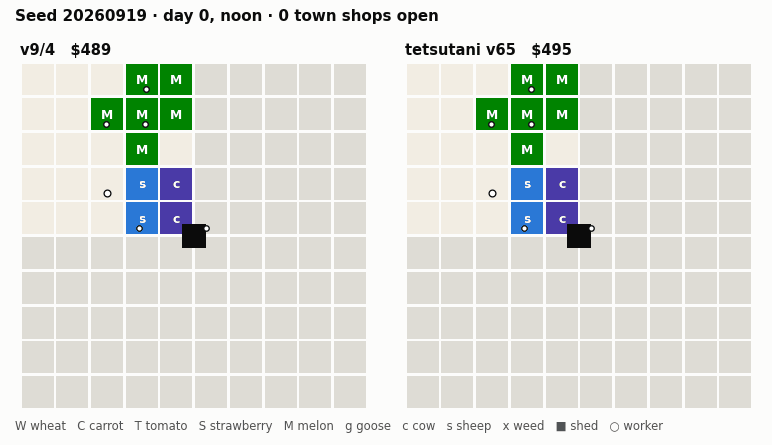

In [6]:
TILE = {  # key -> (fill, letter, letter colour); letters keep the map readable without colour
    "WHEAT": (YELLOW, "W", INK), "CARROT": (ORANGE, "C", INK), "TOMATO": (RED, "T", "white"),
    "STRAWBERRY": (MAGENTA, "S", INK), "MELON": (GREEN, "M", "white"), "GOOSE": (AQUA, "g", INK),
    "COW": (VIOLET, "c", "white"), "SHEEP": (BLUE, "s", "white"), "COOP": ("#d6ece0", "", INK),
    "PASTURE": ("#d6ece0", "", INK), "WEED": ("#bdb691", "x", INK), "EMPTY": ("#f2ede3", "", INK),
    "LOCKED": ("#dedcd5", "", INK),
}
LEGEND = [("W", "wheat"), ("C", "carrot"), ("T", "tomato"), ("S", "strawberry"), ("M", "melon"),
          ("g", "goose"), ("c", "cow"), ("s", "sheep"), ("x", "weed")]
KEY_OF = {v[1]: k for k, v in TILE.items() if v[1]}


def tile_key(tile):
    if tile is None:
        return "EMPTY"
    if tile == "LOCKED":
        return "LOCKED"
    kind = tile.get("kind")
    if kind == "PLANT":
        return tile.get("crop", "EMPTY")
    if kind in ("COOP", "PASTURE"):
        return tile.get("animal") or kind
    return "WEED" if kind == "WEED" else "EMPTY"


def draw_farm(ax, farm, label):
    n = len(farm["tiles"])
    for yy in range(n):
        for xx in range(n):
            fill, letter, lc = TILE[tile_key(farm["tiles"][yy][xx])]
            ax.add_patch(plt.Rectangle((xx + 0.04, yy + 0.04), 0.92, 0.92, color=fill, lw=0))
            if letter:
                ax.text(xx + 0.5, yy + 0.53, letter, ha="center", va="center", color=lc, fontsize=10.5,
                        fontweight="bold")
    ax.add_patch(plt.Rectangle((n / 2 - 0.34, n / 2 - 0.34), 0.68, 0.68, color=INK, lw=0, zorder=4))
    workers = [farm["farmer"]] + list(farm.get("hands") or [])
    for i, (wx, wy) in enumerate(workers):
        jitter = 0.16 * math.sin(2.4 * i)
        ax.scatter(wx + 0.5 + jitter, wy + 0.78, s=34 if i == 0 else 22, color="white", edgecolor=INK,
                   linewidth=1.1, zorder=5)
    ax.set_xlim(0, n)
    ax.set_ylim(n, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(label, fontsize=12.5, pad=6)


def season_gif(game, path, hour=12):
    from PIL import Image as PILImage
    env, seat = game["env"], game["seat"]
    names = {seat: "v9/4", 1 - seat: OPP_NAME}
    steps = [d * 24 + hour for d in range(30)] + [len(env.steps) - 1]
    frames = []
    for t in steps:
        obs = env.steps[t][0]["observation"]
        fig, axes = plt.subplots(1, 2, figsize=(9.2, 5.3), dpi=84)
        for ax, p in zip(axes, (seat, 1 - seat)):
            draw_farm(ax, obs["farms"][p], f"{names[p]}   ${obs['farms'][p]['money']:,.0f}")
        when = "end of season" if t == steps[-1] else f"day {t // 24}, noon"
        fig.suptitle(f"Seed {game['seed']} · {when} · {len(obs['town']['unlocked_shops'])} town shops open",
                     x=0.02, ha="left", fontsize=13, fontweight="bold", color=INK)
        fig.text(0.02, 0.035, "   ".join(f"{k} {v}" for k, v in LEGEND) + "   ■ shed   ○ worker",
                 fontsize=10, color=INK2)
        fig.subplots_adjust(left=0.02, right=0.98, top=0.86, bottom=0.08, wspace=0.08)
        fig.canvas.draw()
        frames.append(PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3]).convert(
            "P", palette=PILImage.ADAPTIVE, colors=48))
        plt.close(fig)
    durations = [450] * (len(frames) - 1) + [2600]
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0, optimize=True)
    return path


if games:
    gif = season_gif(games[0], Path(tempfile.gettempdir()) / "season.gif")
    display(Image(filename=str(gif)))
else:
    print("No games were played in this session (see above), so there is nothing to animate.")

### The cash race

The two farms in the animation look almost identical, and that is not a rendering bug. tetsutani's agent and v9/4 descend from the same recorded routes (section 3), so the fields are planted alike. The games are decided by the reflexes: when to sell, which animal to buy, carrot or wheat, how many hands to hire. Both farms put almost every dollar back into land, animals and seeds for the first ten days. After that, the lead builds a few hundred dollars at a time.

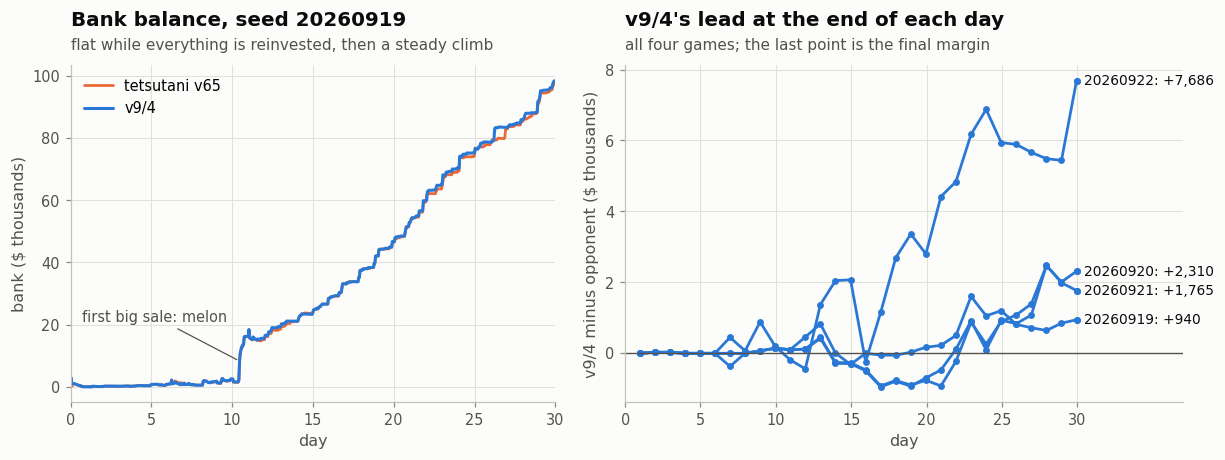

In [7]:
def bank(g):
    b = np.array([[st[0]["observation"]["farms"][p]["money"] for p in (0, 1)] for st in g["env"].steps])
    return np.arange(len(b)) / 24, b[:, g["seat"]], b[:, 1 - g["seat"]]


def cash_race():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.4, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
    days, ours, theirs = bank(games[0])
    a1.plot(days, theirs / 1000, color=ORANGE, lw=1.8, label=OPP_NAME)
    a1.plot(days, ours / 1000, color=BLUE, lw=2.0, label="v9/4")
    jump = int(np.argmax(np.diff(ours) > 5000))
    L = games[0]["ledger"]
    sold = L[(L.player == games[0]["seat"]) & (L.op == "SELL") & L.step.between(jump - 1, jump + 1)]
    top = sold.groupby("item").amount.sum().idxmax().lower() if len(sold) else "harvest"
    a1.annotate(f"first big sale: {top}", (days[jump + 1], ours[jump + 1] / 1000), xytext=(-8, 26),
                textcoords="offset points", ha="right", color=INK2, fontsize=9.5,
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    a1.set_xlabel("day")
    a1.set_ylabel("bank ($ thousands)")
    a1.set_xlim(0, 30)
    a1.legend(loc="upper left")
    a1.set_title(f"Bank balance, seed {games[0]['seed']}")
    subtitle(a1, "flat while everything is reinvested, then a steady climb")

    for g in games:
        days, ours, theirs = bank(g)
        eod = [d * 24 + 23 for d in range(len(days) // 24)] + [len(days) - 1]   # end of each day
        lead = (ours[eod] - theirs[eod]) / 1000
        a2.plot(days[eod], lead, color=BLUE, lw=1.8, marker="o", markersize=3.5)
        a2.annotate(f"{g['seed']}: {1000 * lead[-1]:+,.0f}", (days[eod][-1], lead[-1]), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK)
    a2.axhline(0, color=INK2, lw=0.9)
    a2.set_xlim(0, 37)
    a2.set_xticks(range(0, 31, 5))
    a2.set_xlabel("day")
    a2.set_ylabel("v9/4 minus opponent ($ thousands)")
    a2.set_title("v9/4's lead at the end of each day")
    subtitle(a2, "all four games; the last point is the final margin")
    plt.tight_layout()
    plt.show()


cash_race() if games else print("No games in this session.")

### Where the money comes from

The ledger makes the season readable. Revenue by product for both farms, averaged over the four games, and what each side spent it on. Read it together with the town shops above. Premium books (strawberry, milk, wool, melon) pay well only for whoever sells first, which is what sections 4.4 and 4.5 are about.

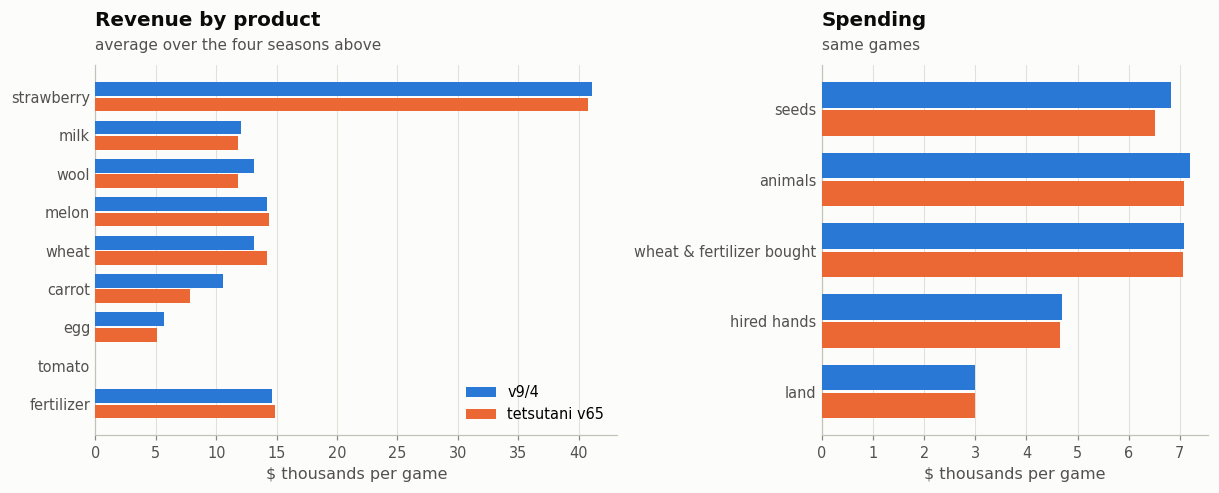

,v9/4 units,v9/4 avg price,tetsutani v65 units,tetsutani v65 avg price
line,,,,
strawberry,248,166,248,165
milk,173,70,173,68
wool,138,95,134,88
melon,72,197,72,199
wheat,369,36,412,35
carrot,140,75,100,78
egg,102,55,92,55
tomato,0,–,0,–
fertilizer,334,44,340,44


In [8]:
PRODUCTS = ["STRAWBERRY", "MILK", "WOOL", "MELON", "WHEAT", "CARROT", "EGG", "TOMATO", "FERTILIZER"]
COSTS = {"BUY_SEED": "seeds", "BUY_ANIMAL": "animals", "BUY_PRODUCT": "wheat & fertilizer bought",
         "HIRE": "hired hands", "BUY_LAND": "land"}


def money_book():
    rows = []
    for g in games:
        L = g["ledger"]
        for side, p in (("v9/4", g["seat"]), (OPP_NAME, 1 - g["seat"])):
            Lp = L[L.player == p]
            sold = Lp[Lp.op == "SELL"]
            for item in PRODUCTS:
                s = sold[sold["item"] == item]
                rows.append((side, "revenue", item.lower(), s.amount.sum(), len(s)))
            for op, label in COSTS.items():
                rows.append((side, "cost", label, -Lp.loc[Lp.op == op, "amount"].sum(), 0))
    book = pd.DataFrame(rows, columns=["side", "kind", "line", "amount", "units"]).groupby(
        ["side", "kind", "line"], sort=False).sum().reset_index()
    book["amount"] /= len(games)
    book["units"] /= len(games)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.2, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})
    for ax, kind, order in ((a1, "revenue", [p.lower() for p in PRODUCTS]), (a2, "cost", list(COSTS.values()))):
        sub = book[book.kind == kind]
        y = np.arange(len(order))[::-1]
        for off, side, colour in ((0.2, "v9/4", BLUE), (-0.2, OPP_NAME, ORANGE)):
            vals = sub[sub.side == side].set_index("line").loc[order, "amount"].values
            ax.barh(y + off, vals / 1000, height=0.36, color=colour, label=side, zorder=3)
        ax.set_yticks(y, order)
        ax.tick_params(axis="y", length=0)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("$ thousands per game")
    a1.set_title("Revenue by product")
    subtitle(a1, "average over the four seasons above")
    a2.set_title("Spending")
    subtitle(a2, "same games")
    a1.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    tbl = book[book.kind == "revenue"].pivot(index="line", columns="side", values=["amount", "units"])
    view = pd.DataFrame({
        "v9/4 units": tbl["units"]["v9/4"].round(0).astype(int),
        "v9/4 avg price": (tbl["amount"]["v9/4"] / tbl["units"]["v9/4"].replace(0, np.nan)).round(0),
        f"{OPP_NAME} units": tbl["units"][OPP_NAME].round(0).astype(int),
        f"{OPP_NAME} avg price": (tbl["amount"][OPP_NAME] / tbl["units"][OPP_NAME].replace(0, np.nan)).round(0),
    }).loc[[p.lower() for p in PRODUCTS]]
    display(HTML(view.to_html(na_rep="–", float_format=lambda v: f"{v:,.0f}")))


money_book() if games else print("No games in this session.")

## 3 · How it works: a recorded route with reflexes

At its core v9/4 is a **route replayer**. The public lineage recorded strong 720-turn action schedules: where every worker walks, what gets planted, what is sold when. The router picks a schedule from the town's first shop unlocks. On top of that sits a stack of **reflexes**. Each is a small layer that reads the public observation, edits one kind of decision, and passes the action on to the next layer. Every layer wraps the previous `agent` and ends with `agent = globals().pop('agent')`. Section 8 explains why that last line matters.

| Layer | What it edits | In one line | From |
|:--|:--|:--|:--|
| Route tapes and shop router | everything | recorded 720-turn schedules, re-selected as shops unlock | yhay81 · Ahmed Berat Özer (V39/V40) |
| Chassis repairs | workers, market | weed repair, sale lead, stock reservations, end-of-season planner, V219 tomato and V233 six-sheep projects | Ahmed · Dmitrii Gluzdov · prvsiyan · aurax7 · tetsutani · lucifer19 |
| OPENING · CTRTABLE | turns 0–8 | cash-safe opening wheat trade, plus two counters keyed on public turn-2 state | v9 |
| RACE · RACEPX · RACEGATE | sale timing | race the rival's premium sales, but never into a glutted book | v9 |
| PREDICT · PREDICT2 | sale timing | forecast rival sales from 451k recorded sale events | v9 |
| COURIER · OVERFLOW · SHEDROOM | cargo | nothing is lost to the midnight shed drop | v9 · Ahmed (V43) · V100.24 |
| CARROT · CARROT2 | planting | wheat becomes carrot where the tile's simulated harvest pays | v9 · V100.24 |
| HERD · HERD2 · COWSWAP | animal purchases | goose, cow or sheep, from a supply-and-demand model of both farms | v9 · V100.24 |
| FERT | fertilizing | carried fertilizer goes on young wheat and carrots | v9 |
| ORDERPRI2 | order of market list | the product most exposed to a rival batch sells first | V100.24 |
| CAPHARV | harvesting | harvest an animal before its cap overflows | V100.24 |
| SL2 · VE1 · VT1 | sheep-expansion labour | one hand instead of two, day 11 instead of 12, nothing wasted on day 29 | v9/4 |

**How v9/3 became v9/4.** Every step below was measured on a fixed panel of recorded games from top players. The numbers are *games flipped*: `+a / −b` means a losses turned into wins and b wins turned into losses. Anything with more flips against than for was rejected (section 7).

| Step | Added | Flipped | Panel |
|:--|:--|:--:|:--|
| sl2 | one hand for the sheep expansion on non-harvest days | +15 / −0 | 188 affected games |
| ve1 | expansion on day 11 in yarn-store towns | +8 / −1 | 150 eligible games |
| vt1 | nothing wasted on the last two days | +3 / −0 | 273 affected games |
| g_co | CARROT2 + ORDERPRI2 | +54 / −10 | 3,296 recorded games |
| c_ch | CAPHARV | +20 / −0 | 1,000 recent top-25 games |
| d_sr | SHEDROOM | +16 / −2 | same 1,000 |
| e_hc | HERD2 + COWSWAP | +10 / −4 | same 1,000 |
| f_lib | sale library rebuilt from the 1,000 new games | +32 / −13 | same 1,000 |

## 4 · Eight lessons that won games

### 4.1 Labour is priced at the margin

Hired hands vanish at midnight. The *n*-th hire of a day costs fib(*n*−1), so the first hands are nearly free and the late ones are not. The route's own crews are hired first, which made the two hands of the six-sheep expansion (prvsiyan's V233 annex) hires **#12 and #13: $144 + $233 = $377 a day**. On days without a wool harvest one hand can do that work. **SL2** keeps one hand on those days, but only when the complete feed-and-care tour provably fits into the day, and it collects fertilizer on the way. In an audited game hires fell from 36 to 23 with all 108 wool and every feed kept. **+15 / −0** in the affected towns.

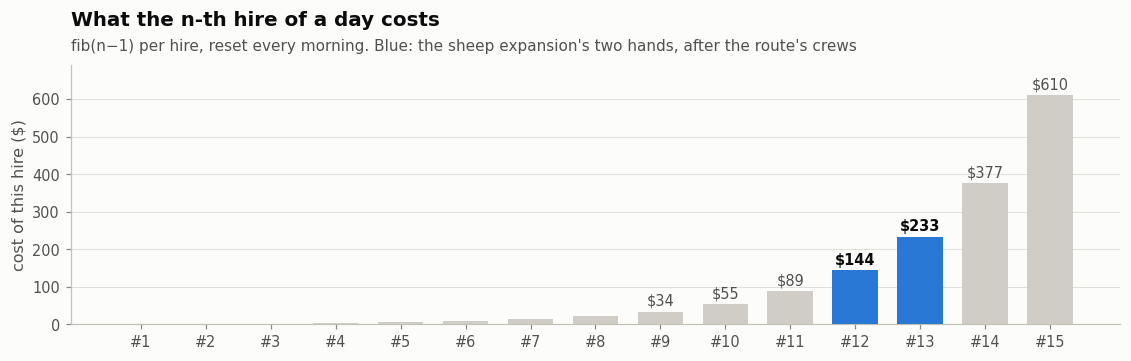

In [9]:
cost = [1, 1]                       # the engine's hire cost: fib(n-1) for the n-th hire of the day
while len(cost) < 15:
    cost.append(cost[-1] + cost[-2])
fig, ax = plt.subplots(figsize=(10.4, 3.4))
x = np.arange(1, 16)
colors = [BLUE if n in (12, 13) else QUIET for n in x]
ax.bar(x, cost, width=0.7, color=colors, zorder=3)
for n, c in zip(x, cost):
    if n >= 9:
        ax.text(n, c + 8, f"${c}", ha="center", va="bottom", fontsize=9.5,
                color=INK if n in (12, 13) else INK2, fontweight="bold" if n in (12, 13) else "normal")
ax.set_xticks(x, [f"#{n}" for n in x])
ax.set_ylabel("cost of this hire ($)")
ax.set_title("What the n-th hire of a day costs")
subtitle(ax, "fib(n−1) per hire, reset every morning. Blue: the sheep expansion's two hands, after the route's crews")
ax.set_ylim(0, 690)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 4.2 Sheep placed one day earlier harvest five times, not four

Sheep first produce 6 days after placement, then every 3 days, and the season ends after day 29. Placed on day 12, they produce on days 18, 21, 24 and 27. Placed on day 11, they produce on 17, 20, 23, 26 **and 29**. That is a fifth harvest for one more day of feed and labour. **VE1** commits the expansion on day 11 in towns where two of the first three shops are yarn stores. It waits for the route's own land purchase first and checks that the cash covers every purchase the route still plans. The early wool also reaches the shared book before the rival's does: our cash rises about **$850** and the rival's falls about **$1,400** per affected game. **+8 / −1**. On fresh seeds against reactive opponents it beat the day-12 version **24 – 0**.

**VT1** handles the last two days. No production refresh follows day 29, so feeding and caring on that day buy nothing. On day 29 the expansion hires no hand unless wool is waiting, and then only one hand that harvests. On day 28 it skips CARE, because that care would be banked after the last production has already happened. **+3 / −0.**

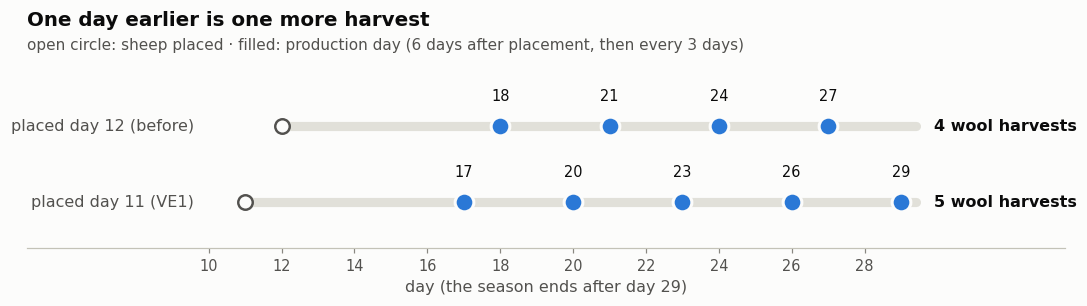

In [10]:
fig, ax = plt.subplots(figsize=(10.4, 2.9))
for yy, placed, label in ((1, 12, "placed day 12 (before)"), (0, 11, "placed day 11 (VE1)")):
    prod = list(range(placed + 6, 30, 3))
    ax.plot([placed, 29.4], [yy, yy], color=GRID, lw=6, solid_capstyle="round", zorder=1)
    ax.scatter([placed], [yy], s=90, facecolor=SURFACE, edgecolor=INK2, lw=1.6, zorder=3)
    ax.scatter(prod, [yy] * len(prod), s=150, color=BLUE, zorder=4, edgecolor=SURFACE, linewidth=2)
    for d in prod:
        ax.text(d, yy + 0.3, str(d), ha="center", va="bottom", fontsize=9.5, color=INK)
    ax.text(29.9, yy, f"{len(prod)} wool harvests", va="center", fontsize=10.5, color=INK, fontweight="bold")
    ax.text(9.6, yy, label, va="center", ha="right", fontsize=10.5, color=INK2)
ax.set_xlim(5, 33.5)
ax.set_ylim(-0.6, 1.8)
ax.set_yticks([])
ax.set_xticks(range(10, 30, 2))
ax.set_xlabel("day (the season ends after day 29)")
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_title("One day earlier is one more harvest")
subtitle(ax, "open circle: sheep placed · filled: production day (6 days after placement, then every 3 days)")
plt.tight_layout()
plt.show()

### 4.3 Care is most of what an animal makes

FEED keeps an animal alive, but CARE is where most of the output comes from. Every day an animal is both fed and cared for banks one bonus unit, paid out at its next production. A cared cow gives **3 milk** per production instead of 1, a sheep **4 wool** instead of 1, and a goose **2 eggs** instead of 1. There are two catches. An animal that goes unfed on its production day loses the whole bank. And stored product stops growing at 6 (cow, sheep) or 4 (goose). **CAPHARV** handles the second catch. When a worker is about to care for an animal (or collect its fertilizer) whose stored yield would overflow at tonight's production, and nobody harvests that tile later in the day, it harvests instead and sells the saved units. **+20 / −0** on 1,000 recent top-25 games.

### 4.4 Your market list is an order book

Both players' market lists run in lockstep: order #1 of each list first, one unit at a time from each side at the same quote, then order #2, and so on, up to 10 orders a turn. The position of an order in your list therefore decides who sells into whose glut:

| slot | you | rival | what happens |
|:--:|:--|:--|:--|
| 1 | `SELL MILK 6` | `SELL WHEAT 30` | your 6 milk sell at the pre-glut price |
| 2 | `SELL WHEAT 20` | `SELL MILK 12` | the rival's milk sells into your units |

**ORDERPRI2** estimates the rival's unsold stock from public information only: their tile harvests and their recovered sales. It moves the product most exposed to a rival batch to the front, and when all ten slots are full it swaps out the weakest order.

### 4.5 Premium books fall off a cliff, so race

Prices are set by market inventory. Staples barely move when a farm floods them. Strawberries, milk, wool and melons fall to the **$1 floor** after 60 to 160 units of surplus, less than one field's worth. The first seller of a lot takes the price and the second sells into the crash.

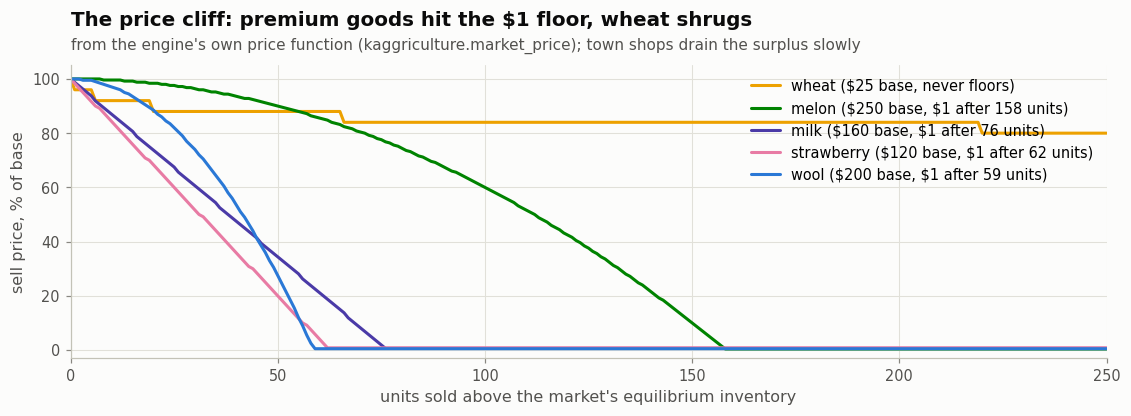

In [11]:
def price_cliff():
    glut = np.arange(0, 251)
    fig, ax = plt.subplots(figsize=(10.4, 3.9))
    series = [("WHEAT", YELLOW), ("MELON", GREEN), ("MILK", VIOLET), ("STRAWBERRY", MAGENTA), ("WOOL", BLUE)]
    for item, colour in series:
        p = K.MARKET_PARAMS[item]
        price = np.array([K.market_price(item, p["I0"] + g) for g in glut])
        floor = int(np.argmax(price <= 1)) if (price <= 1).any() else None
        label = f"{item.lower()} (\\${p['base']} base" + (f", \\$1 after {floor} units)" if floor else ", never floors)")
        ax.plot(glut, price / p["base"] * 100, color=colour, lw=2.0, label=label)
    ax.set_xlabel("units sold above the market's equilibrium inventory")
    ax.set_ylabel("sell price, % of base")
    ax.set_ylim(-3, 105)
    ax.set_xlim(0, 250)
    ax.legend(loc="upper right")
    ax.set_title("The price cliff: premium goods hit the $1 floor, wheat shrugs")
    subtitle(ax, "from the engine's own price function (kaggriculture.market_price); town shops drain the surplus slowly")
    plt.tight_layout()
    plt.show()


if hasattr(K, "market_price") and hasattr(K, "MARKET_PARAMS"):
    price_cliff()
else:
    print("This engine version has no market_price(); the chart needs kaggle-environments 1.32.7.")

Rival sales are public if you look for them. Every turn, **rival_sold = inventory′ − inventory + town_draw − own_sold**, which is exact above the $1 floor. **RACE** watches that signal and pulls the route's own planned sales of the same product forward, up to 40 turns ahead and starting on day 8. **RACEPX** and **RACEGATE** keep it from racing into a book that already trades below base. **PREDICT** goes one step further: it matches the rival's recent sales against a library of **451k sale events from 1,000 recent top-25 games** and sells just before the best-matching recorded streams say the rival will.

### 4.6 The shed has 100 slots, and midnight shreds the rest

At the end of every day all cargo that workers carry drops into the shed, and anything past 100 items is destroyed. **OVERFLOW** (ported from Ahmed's V43) sells, at hour 23, exactly the shed stock the drop would destroy. **SHEDROOM** does the same for spare goods at hours 22–23. **COURIER** walks premium cargo to the shed before midnight so it sells today rather than tomorrow. These layers break ties: SHEDROOM flipped 18 games, and every one of them was decided by less than about $1,000 (**+16 / −2**).

### 4.7 Carrot or wheat? Ask the tile, not the price

A watered wheat plant yields 4 units and a carrot yields 3 for $10 more seed. A simple price ratio ("carrot when it is worth 1.8× wheat") fires far too rarely. **CARROT2** (from V100.24) instead simulates the route's own future visits to each tile. Will someone water it? Will someone harvest it before it decays? It swaps `PLANT WHEAT` for `PLANT CARROT` only where 3 carrots − $20 beats 4 wheat − $10 at the prices ahead, and it keeps two days of wheat for the herd. Together with ORDERPRI2 this was **+54 / −10** over 3,296 recorded games. Replayed against my previous version's real ladder opponents, the record went from 80–25 to **95–10**.

### 4.8 The opening had six dollars of slack

Every route tape opened with a wheat round trip and then ran days 0–9 with about **$6** of spare cash. Against openings that dump wheat into the same market slots, that round trip ended turn 1 up to $75 short. Wheat and hire orders then failed, the herd went hungry, and by days 5–8 the strawberry orders failed too: 18–21 plants instead of 33, a loss of $20k–65k. v9 replaced it with a cash-safe trade, checked against 6,648 recorded openings, and v9/3 settled on **BUY 20 / SELL 15** at turn 0 (+107 / −0 on the replay panel).

## 5 · Evidence

### 5.1 Head-to-head against the top-scoring public notebooks (fresh, 2026-09-19)

The top chart. I took the 10 highest-scoring public notebooks in the Code tab, extracted each `main.py` byte-exactly from its current version and loaded it with Kaggle's own last-callable rule. Ten notebooks turned out to be nine distinct agents: two pairs are byte-identical, and one "decompressed" copy of V48 plays move-for-move like V48. Each opponent played **30 fresh seeds × both seats**. Each seed's eight shop unlocks were drawn at random and forced identically for every opponent (common random numbers), and games ran on a C++ re-implementation of the engine for speed.

| Opponent | Best public score of this agent | v9/4 W–L | Mean margin |
|:--|--:|:--:|--:|
| Demand-Preserving Turn Sale Timing (tetsutani) | 2750.2 | 55–5 | +3,446 |
| First in Line: Stock Into Income (Alperen Aydın) | 2746.0 | 54–6 | +3,196 |
| V47 Reactive Market Coordination (Ahmed Berat Özer) | 2686.0 | 55–5 | +3,698 |
| V48 Clear the Queue (Ahmed Berat Özer) | 2670.4 | 55–5 | +3,534 |
| V38 Smarter Feed, Stronger Margins (Ahmed Berat Özer) | 2625.2 | 60–0 | +7,379 |
| V39 Ready Before the Rush (Ahmed Berat Özer) | 2621.2 | 60–0 | +7,198 |
| v34 Observed Market Timing (Ahmed Berat Özer) | 2601.6 | 60–0 | +10,801 |
| V41 Review Candidate (Ahmed Berat Özer) | 2586.4 | 60–0 | +7,188 |
| v31 Production and Sale Priority (Ahmed Berat Özer) | 2575.6 | 60–0 | +10,929 |
| **Total** | | **519–21** | |

In this game, swapping seats usually replays the same game (26 of the 30 seeds gave identical results in both seats), so read the table as **270 independent seeds: 258 won, 9 lost, 3 split**.

### 5.2 Confirmation in the official engine

The C++ simulator is fast, but it is not the real engine. So I replayed the four strongest matchups in `kaggle_environments` itself, with its own shop draws: 10 new seeds × both seats against each opponent. **v9/4 won all 80 games**, 20–0 against each of Demand-Preserving, First in Line, V47 and V48, by +$2.0k to +$2.1k on average. Here too, swapping seats replayed the same game on 9 of 10 seeds, so read it as 40 of 40 seeds. Section 2 plays four more of these games live, in this notebook.

### 5.3 Closed loop against 17 reactive bots (2026-09-18)

Public V40, V41, V46, V47 and V48, both V100.24 variants, shop-router-reactive-v7, pipe-7, pipe-8, shop-router-0913, master-engine-v53, best-agent and four more bots: **645 of 680** games won, 20 seeds × both seats each. The weakest matchups were V100.24 (32/40 and 34/40), V47 (34/40) and V48 (34/40).

### 5.4 The live ladder

This exact file climbed to **2944.7** (submission 56269928, 2026-09-16) and went **128–73** over its first 201 ladder games. It won every recorded game against the public V43 opening (14–0) and the V45 opening (11–0), and only 4 of 26 against *adaptive* farms that open with cows or four hired hands. That cluster is the subject of the next section. A fresh submission of the same file on 2026-09-18 was at 2908 and still climbing when I published this: a rating depends on the field it climbs through (section 8).

## 6 · The problem I could not solve

v9/4 beats every public notebook, yet against seven of today's top-10 teams it went **0 – 36** on the ladder (September 15–17). I replayed 24 of those losses in the engine with an exact ledger (both players' real action streams) to see where the money went. **We lead until day 10**, because the melon race is ours, **and lose it all after day 11.**

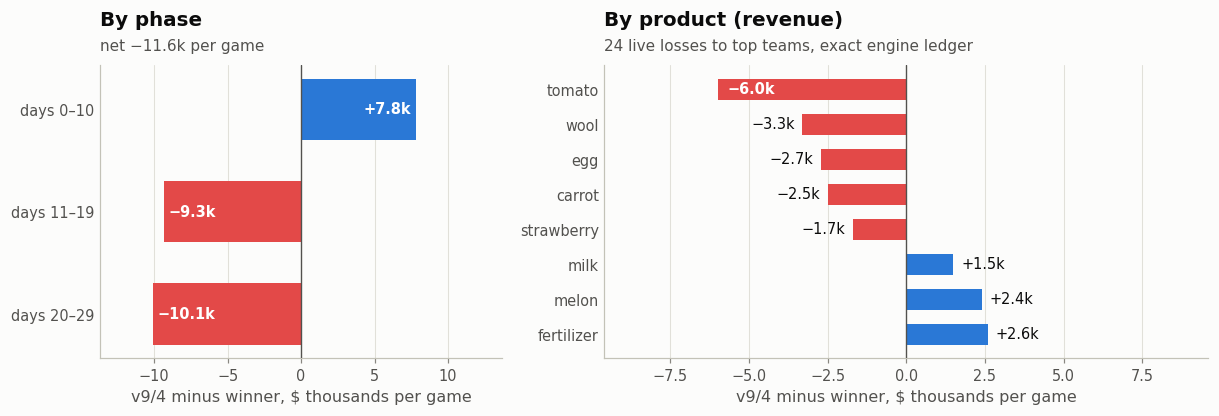

In [12]:
phase = pd.Series({"days 0–10": 7.8, "days 11–19": -9.3, "days 20–29": -10.1})
product = pd.Series({"tomato": -6.0, "wool": -3.3, "egg": -2.7, "carrot": -2.5, "strawberry": -1.7,
                     "milk": 1.5, "melon": 2.4, "fertilizer": 2.6}).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.2, 3.9), gridspec_kw={"width_ratios": [1, 1.5]})
for ax, s in ((a1, phase), (a2, product)):
    y = np.arange(len(s))[::-1]
    ax.barh(y, s.values, height=0.6, color=[BLUE if v > 0 else RED for v in s.values], zorder=3)
    ax.axvline(0, color=INK2, lw=0.9, zorder=4)
    for yi, v in zip(y, s.values):
        inside = abs(v) > 4                       # long bars carry their label inside
        x = v - (0.3 if v > 0 else -0.3) if inside else v + (0.25 if v > 0 else -0.25)
        ha = ("right" if v > 0 else "left") if inside else ("left" if v > 0 else "right")
        ax.text(x, yi, f"{v:+.1f}k".replace("-", "−"), va="center", ha=ha, fontsize=9.5,
                color="white" if inside else INK, fontweight="bold" if inside else "normal")
    ax.set_yticks(y, s.index)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("v9/4 minus winner, $ thousands per game")
    lim = max(abs(s.values)) + 3.6
    ax.set_xlim(-lim, lim)
a1.set_title("By phase")
subtitle(a1, "net −11.6k per game")
a2.set_title("By product (revenue)")
subtitle(a2, "24 live losses to top teams, exact engine ledger")
plt.tight_layout()
plt.show()

The biggest single hole is **tomatoes**. The farms that beat us buy about **9 tomato seeds from day ~12** and hold about 10 tomato tiles on day 20. We buy 1.6, and the first on day 18. They sell 71 tomatoes at $114 each. We sell 7, at $316, because nobody else is selling into that book.

Every tomato program I built lost:

* a tomato overlay on the route's wheat tiles from day 13: **0 gained / 85 lost**
* a 20-tile tomato patch on new land: **0 / 56**, because the crews cannot water 20 more tiles
* loosening the gate of the existing tomato project: **+4 / −11**

The route tape is the constraint. Its workers are busy from dawn to dusk, so a tomato program needs a different *labour* plan, not just a different crop choice. The adaptive farms don't replay a tape. They plan the crew around the crops.

**If you have a tomato program that works on top of a route tape, or you know why the adaptive farms win the second half, I would love to hear it in the comments.**

## 7 · What did not work

Negative results are the cheapest thing I can give you. Each of these cost me hours.

| Idea | Result |
|:--|:--|
| Tomato overlay on the route's wheat tiles (day 13) | 0 gained / 85 lost |
| 20-tile tomato patch on new land | 0 / 56. Labour-bound, not land-bound |
| Hold premium goods back for a better price (reservation wrapper) | −$7.5k to −$34k per game. The tape's logic breaks when its sales are overridden |
| Rebase all v9 layers onto public V48 | 497 vs 506 of 840 panel games |
| Let an adaptive planner take over the farm after day 12 or day 18 | 6–24 and 7–23, against 24–6 for the tape |
| A from-scratch, demand-driven planner (v10, three days of work) | live score 990–1,578, against 2,945 for the tape |
| Skip the day-11 strawberries when no berry shop is open | −$1.5k a game. The berries I didn't sell were sold by the rival |
| Extra hands to fertilize young wheat | $144+ a day per hand, more than the extra wheat earns |
| Sheep expansion in towns with only one yarn store | −$11k to −$17k for us, only −$2k to −$3k for the rival |

## 8 · Five lessons about evaluation

**1. Kaggle runs the *last* callable, not `agent`.** The loader executes `main.py` and takes `[v for v in namespace.values() if callable(v)][-1]`. Redefining `agent` later in the file doesn't move it, because a dict keeps the key's original position. V47's real entry point is `_y_agent_shopherd` and V48's is `_e335_agent`. My local harness imported `agent` by name, so for every public file from V46 on it silently evaluated a stale inner bot. Every layer in this file ends with `agent = globals().pop('agent')`, which re-inserts the name at the end. The check in section 1 uses Kaggle's own rule.

**2. Frozen replays flatter you.** Across five promotions my replay panel rose from 589 to 648 wins per 1,000 games, while the live score went 2956.6 → 2944.7. A recorded opponent can't react. If your agent starves it, for example by making one of its purchases fail, the replay keeps playing its recorded moves into nothing and your "win" is an artifact. Filter panels to games where the frozen opponent keeps at least 95% of its recorded score, and trust closed-loop games against reactive bots more.

**3. Identical code, different scores.** The V47 agent sits byte-for-byte in two public notebooks, scored 2686.0 in one and 2579.3 in the other. V39 scored 2621.2 and 2581.0. A single submission's rating moves about ±100 with its matchmaking luck, so don't chase ±30. Decide on head-to-head data.

**4. Every sale is also denial.** Premium books are shared. When I removed 103 strawberries from a route, I lost $5.5k of revenue *and the rival gained $5.5k*, because they sold into the book I left empty. Most "sell less, sell better" ideas lose for this reason.

**5. Check which engine your notebook runs.** Kaggle's notebook image still ships `kaggle-environments` **1.29.3**, and its Kaggriculture engine is older than the current rules. On it, a mirror match of the #1 public agent ends with **$2 per farm**. On 1.32.7 the same agent banks about $100k. If your notebook plays its test games with Internet off, check the version it prints. Section 2 installs 1.32.7 with `pip install --no-deps` before it plays.

## 9 · Submit

The cell below packs the verified `main.py` into `submission.tar.gz` (deterministic: fixed timestamps, one member) and checks the archive round-trips byte-exactly. After *Save & Run All* the version has two output files: `submission.tar.gz` and `main.py`. Either one is a valid submission, and **Submit** on the notebook page sends it to the ladder. A new submission starts around 600 and needs a day or so of games to climb.

In [13]:
import gzip
source = Path("main.py").read_bytes()
assert hashlib.sha256(source).hexdigest() == EXPECTED_SHA256
buffer = io.BytesIO()
with tarfile.open(fileobj=buffer, mode="w", format=tarfile.GNU_FORMAT) as tar:
    info = tarfile.TarInfo("main.py")
    info.size, info.mtime, info.mode = len(source), 0, 0o644
    tar.addfile(info, io.BytesIO(source))
Path("submission.tar.gz").write_bytes(gzip.compress(buffer.getvalue(), mtime=0))
with tarfile.open("submission.tar.gz") as tar:
    assert tar.getnames() == ["main.py"]
    assert tar.extractfile("main.py").read() == source
print("submission.tar.gz", f"{Path('submission.tar.gz').stat().st_size:,} bytes",
      "sha256", hashlib.sha256(Path("submission.tar.gz").read_bytes()).hexdigest()[:12] + "…")
print("outputs:", sorted(p.name for p in Path(".").iterdir() if p.is_file()))

submission.tar.gz 520,553 bytes sha256 2dfd5214b9ac…
outputs: ['main.py', 'submission.tar.gz']


## Credits and license

This agent is built on the public Code tab. Thank you to:

* **Ahmed Berat Özer**: the V25–V48 series. This agent's chassis is V39/V40, plus his V43 overflow sale.
* **Yusuke Hayashi (yhay81)**: Shop Router 0908 / 0909 / 0913, the action schedules and shop-pair routing.
* **prvsiyan**: the Frontier notebooks. The finite tomato investment (V221B, adapted by Ahmed as V219), the cattle transfer (V231) and the six-sheep expansion (V233).
* **Dmitrii Gluzdov**: *Two Coins, One Sheep* stock reservations and the seven-turn terminal rescue.
* **aurax7**: Reactive Router sale timing and shed projection.
* **tetsutani**: market, room and repair mechanisms, and the opponent in section 2.
* **lucifer19** (Harvest Nocturne), **leoprovorov** (Mirror Counter), **destbreso** (X-ray Your Agent), **Steven Lee Hans** (Lord Momo feed-versus-value idea).
* The public **V100.24** release: CARROT2, ORDERPRI2, CAPHARV, SHEDROOM, HERD2 and COWSWAP. Its layers are labelled "Claude … layer" in the source.
* **Kaggle** for `kaggle-environments` (Apache-2.0).

Released under **Apache-2.0**, like everything it is built on. Every upstream notice is kept verbatim at the top of `main.py`.

---

If this saved you time, an upvote helps others find it. I read and answer every comment, and I especially want to hear about **section 6**. Good luck on the ladder! 🌾